# SOBUSA · Pronóstico espacio-temporal de la demanda de pasajeros

### Subidas por segmento de 500 m y por hora en las rutas 2, 16 y 21 de Barranquilla, emitido a las 04:00

**Qué se resuelve.** Pronosticar ŷ(i,t) = subidas en cada uno de los **386 segmentos de 500 m** (nodos) de las tres rutas, en cada hora de servicio (4 a 23 h), con la información disponible a las **04:00** del mismo día, y usarlo para planear la frecuencia de despacho.

**Resultado.** En el holdout 2025, evaluado **una sola vez**, el modelo de las 04:00 tiene una devianza de **1,460** frente a **2,388** del perfil histórico nodo × hora × tipo de día: **−38,8 %**, mejor en los 4 bloques del año y significativo (Diebold-Mariano con p calibrado 0,0095). Donde más gana es en la punta de la mañana laboral, de 6 a 9 h: **1,86 frente a 4,04 (−53,9 %)**. Frente a la entrada que usaba antes el simulador (3,627) la mejora es de −59,7 %; esa línea base es casi tan mala como repetir lo de hace una semana (3,648), así que la comparación que importa es la del perfil. Donde falla: Carnaval (2,66 frente a 2,49 del perfil), los nodos que solo pasa una ruta (−11,0 %) y la estructura espacial que queda en los residuos (Moran significativo en 14 de 18 franjas × tipo de día).

**Cómo leerlo.** Las **secciones 1 a 4** son el pronóstico completo: el reto y los datos, el EDA a la escala del pronóstico, el feature engineering y los resultados. Cada una abre con una síntesis nueva, con sus tablas y figuras, y sigue con el notebook de la subfase que la respalda, intacto. La **sección 5** dice en una página qué se hace con el pronóstico, y la **sección 6** resume lo que se midió y corrigió para esta entrega (simulador, e2c frente a e1c, calendario 2026, guarda al emitir, P&L con tarifa). Todo lo demás va en **anexos**: el Entregable 1 por viaje (A1), los módulos operativos 9–15 (A2) y la trazabilidad de correcciones del Entregable 2 (A3). La conclusión final del proyecto está al final.

**Notebook ya ejecutado.** Reúne los **47 notebooks** del proyecto (1.223 celdas con sus salidas, verificadas una por una con MD5: ninguna se editó ni se borró, salvo la censura del servidor de la base, su IP, el usuario y los nombres de usuario y de equipo, que se aplica al final y se registra en la sección 6.11) más las celdas nuevas de esta versión, que solo leen salidas guardadas en `datos_e2c/`: no consultan la base, no entrenan y no vuelven a evaluar el holdout 2025. Las celdas que consultan la base piden la contraseña con `getpass` y no tienen salida cuando su resultado ya estaba guardado.

<sub>Versión final, reestructurada alrededor del pronóstico: 20-nov-2026. Reemplaza el orden cronológico por módulos de la versión del 19-nov-2026 e incluye la sección 6 con la corrección para la entrega final.</sub>


<a id="indice"></a>

## Índice

Las secciones 1–4 son el pronóstico completo; quien lea solo esas secciones tiene el problema, el modelo y su desempeño. [Qué cambió frente a la versión calificada](#calificacion).

| Contenido | Notebook original |
|---|---|
| **[1 · El reto y los datos](#s1)** | |
| &nbsp;&nbsp;&nbsp;&nbsp;[1.1 · Evidencia · e2c.0 · Decisiones previas y plan de extracción](#e2c-1) | `subfase_e2c_0_decisiones.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[1.2 · Evidencia · e2c.1 · Extracción y panel Y (nodo × hora)](#e2c-2) | `subfase_e2c_1_panel.ipynb` |
| **[2 · EDA del reto: la demanda a escala nodo × hora](#s2)** | |
| &nbsp;&nbsp;&nbsp;&nbsp;[2.1 · Evidencia · e2c.2 · EDA espacio-temporal a la escala del pronóstico](#e2c-3) | `subfase_e2c_2_eda.ipynb` |
| **[3 · Feature engineering](#s3)** | |
| &nbsp;&nbsp;&nbsp;&nbsp;[3.1 · Evidencia · e2c.3 · Features sin fuga y auditoría de leakage](#e2c-4) | `subfase_e2c_3_features.ipynb` |
| **[4 · Resultados del pronóstico](#s4)** | |
| &nbsp;&nbsp;&nbsp;&nbsp;[4.1 · Evidencia · e2c.4 · Partición, líneas base, búsqueda, ablaciones y decisión](#e2c-5) | `subfase_e2c_4_validacion.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[4.2 · Evidencia · e2c.5 · Holdout 2025 (evaluación única), diagnósticos, SHAP y DM](#e2c-6) | `subfase_e2c_5_holdout.ipynb` |
| **[5 · Qué se hace con el pronóstico](#s5)** | |
| **[6 · Mediciones y correcciones de la entrega final](#s6)** | |
| **[Anexo A1 · Entregable 1: la demanda por viaje (módulos 1–8) y su corrección (e1c)](#a1)** | |
| &nbsp;&nbsp;[A1.1 · Módulo 1 · Calidad del dato, validez de viajes y tablas maestras](#m1) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.1.1 · Subfase 1.1 · Inspección estructural](#m1-1) | `subfase_1_1_inspeccion (1).ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.1.2 · Subfase 1.2 · Validez de viajes y atrición](#m1-2) | `subfase_1_2_validez.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.1.3 · Subfase 1.3 · Auditoría de sensores, bloqueos y puertas](#m1-3) | `subfase_1_3_sensores.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.1.4 · Subfase 1.4 · Nulos, imputación sin leakage y tablas maestras](#m1-4) | `subfase_1_4_maestra.ipynb` |
| &nbsp;&nbsp;[A1.2 · Módulo 2 · Distribución del target, Tweedie y métrica oficial](#m2) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.2.1 · Subfase 2.1 · Estadística descriptiva del target y masa en cero](#m2-1) | `subfase_2_1_descriptivo.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.2.2 · Subfase 2.2 · Sobredispersión y parámetro Tweedie p](#m2-2) | `subfase_2_2_tweedie.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.2.3 · Subfase 2.3 · Outliers del target y capacidad física del bus](#m2-3) | `subfase_2_3_outliers.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.2.4 · Subfase 2.4 · Métrica oficial: devianza de Tweedie](#m2-4) | `subfase_2_4_metrica.ipynb` |
| &nbsp;&nbsp;[A1.3 · Módulos 3–5 · Dimensión temporal, dimensión espacial y multicolinealidad](#m35) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.3.1 · Módulos 3–5 · Análisis espaciotemporal](#m35-1) | `modulo_3_5_espaciotemporal.ipynb` |
| &nbsp;&nbsp;[A1.4 · Módulo 6 · Ingeniería de features y auditoría de fuga](#m6) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.4.1 · Subfase 6.0 · Decisiones previas al Módulo 6](#m6-1) | `subfase_6_0_decisiones.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.4.2 · Subfase 6.1 · Rezagos temporales, plan de oferta y calendario](#m6-2) | `subfase_6_1_features.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.4.3 · Subfase 6.2 · Lag espacial entre rutas (matriz W normalizada)](#m6-3) | `subfase_6_2_espacial.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.4.4 · Subfase 6.3 · Auditoría independiente de data leakage](#m6-4) | `subfase_6_3_auditoria.ipynb` |
| &nbsp;&nbsp;[A1.5 · Módulo 7 · Partición, búsqueda de hiperparámetros y modelo final](#m7) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.5.1 · Subfase 7.1 · Partición maestra y walk-forward purgada](#m7-1) | `subfase_7_1_particion.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.5.2 · Subfase 7.2 · Pipeline LightGBM y Optuna](#m7-2) | `subfase_7_2_optuna.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.5.3 · Subfase 7.3 · Regla de rondas, entrenamiento final y evaluación única](#m7-3) | `subfase_7_3_final.ipynb` |
| &nbsp;&nbsp;[A1.6 · Módulo 8 · Diagnóstico, interpretabilidad y significancia](#m8) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.6.1 · Subfase 8.1 · Diagnóstico fino de residuos](#m8-1) | `subfase_8_1_residuos.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.6.2 · Subfase 8.2 · Interpretabilidad con SHAP (TreeSHAP)](#m8-2) | `subfase_8_2_shap.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A1.6.3 · Subfase 8.3 · Significancia estadística (Diebold-Mariano)](#m8-3) | `subfase_8_3_dm.ipynb` |
| &nbsp;&nbsp;[A1.7 · e1c · Corrección del Entregable 1](#e1c) | `subfase_e1c_correccion.ipynb` |
| **[Anexo A2 · Operación: los módulos 9–15 que usan el pronóstico](#a2)** | |
| &nbsp;&nbsp;[A2.1 · Módulo 9 · Fiabilidad vehicular y scoring de riesgo del conductor](#m9) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.1.1 · Módulo 9 · Fiabilidad y scoring](#m9-1) | `modulo_9_fiabilidad_scoring.ipynb` |
| &nbsp;&nbsp;[A2.2 · Módulo 10 · Red vial, protocolo de eventos y reportes de conductores](#m10) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.2.1 · Subfase 10.1 · Red vial base y ubicación de reportes por GPS](#m10-1) | `subfase_10_1_red_vial.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.2.2 · Subfase 10.2 · Protocolo de reporte y contrato del evento](#m10-2) | `subfase_10_2_protocolo.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.2.3 · Subfase 10.3 · Set de prueba etiquetado](#m10-3) | `subfase_10_3_set.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.2.4 · Subfase 10.4 · Audio a texto con Whisper local](#m10-4) | `subfase_10_4_audio.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.2.5 · Subfase 10.5 · Texto a evento con la API de Claude](#m10-5) | `subfase_10_5_extraccion.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.2.6 · Subfase 10.6 · Servicio, tabla de eventos y entrega](#m10-6) | `subfase_10_6_servicio.ipynb` |
| &nbsp;&nbsp;[A2.3 · Módulo 11 · Tráfico externo (Google Routes) y muestreo insesgado](#m11) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.3.1 · Módulo 11 · Tráfico externo y muestreo insesgado](#m11-1) | `modulo_11_resultados.ipynb` |
| &nbsp;&nbsp;[A2.4 · Módulo 12 · Reenrutamiento dinámico ante disrupciones (A*)](#m12) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.4.1 · Módulo 12 · Reenrutamiento dinámico](#m12-1) | `modulo_12_reenrutamiento.ipynb` |
| &nbsp;&nbsp;[A2.5 · Módulo 13 · Simulación Monte Carlo y gemelo digital](#m13) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.5.1 · Subfase 13.1 · Insumos y parámetros del simulador](#m13-1) | `subfase_13_1_parametros.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.5.2 · Subfase 13.2 · Motor de eventos discretos (SimPy)](#m13-2) | `subfase_13_2_motor.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.5.3 · Subfase 13.3 · Imprevistos en el motor](#m13-3) | `subfase_13_3_imprevistos.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.5.4 · Subfase 13.4 · Monte Carlo y validación](#m13-4) | `subfase_13_4_montecarlo.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.5.5 · Subfase 13.4b · Mejoras del simulador](#m13-5) | `subfase_13_4b_mejoras.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.5.6 · Subfase 13.5 · Gemelo digital](#m13-6) | `subfase_13_5_gemelo.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.5.7 · Subfase 13.6 · Cierre y entrega](#m13-7) | `subfase_13_6_cierre.ipynb` |
| &nbsp;&nbsp;[A2.6 · e2c.6 · Simulador del Módulo 13 alimentado por el pronóstico](#e2c-7) | `subfase_e2c_6_simulador.ipynb` |
| &nbsp;&nbsp;[A2.7 · Módulo 14 · Redespacho dinámico de flota (MILP)](#m14) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.7.1 · Módulo 14 · Redespacho dinámico de flota](#m14-1) | `modulo_14_redespacho.ipynb` |
| &nbsp;&nbsp;[A2.8 · Módulo 15 · Despacho en cascada: la frecuencia que se recalcula durante el día](#m15) |  |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.8.1 · Subfase 15.1 · Estimador en vivo y regla de frecuencia](#m15-1) | `subfase_15_1_estimador.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.8.2 · Subfase 15.1b · Pronóstico inmediato con el sensor real (batería de modelos)](#m15-2) | `subfase_15_1b_bateria.ipynb` |
| &nbsp;&nbsp;&nbsp;&nbsp;[A2.8.3 · Subfase 15.4 · Evaluación oficial del despacho en cascada](#m15-3) | `subfase_15_4_evaluacion.ipynb` |
| **[Anexo A3 · Trazabilidad de las correcciones del Entregable 2 (versión del 19-nov-2026)](#a3)** | |
| &nbsp;&nbsp;[Tabla de trazabilidad de correcciones (Entregable 2 → e2c)](#trazabilidad) |  |
| **[Conclusión final del proyecto](#conclusion)** | |


<a id="calificacion"></a>

## Qué cambió frente a la versión calificada

| Observación de la calificación | Dónde se responde |
|---|---|
| «No resuelve el pronóstico espacio-temporal» | **Secciones 1 y 4.** El pronóstico es por nodo × hora (N = 386), con resultados en el holdout 2025 contra tres líneas base, desglosados por bloque, ruta, franja, hora, tipo de día, tipo de nodo y nodo por nodo |
| «Faltan el EDA y el feature engineering del reto» | **Secciones 2 y 3.** EDA a la escala del pronóstico (ceros, media-varianza, perfiles, calendario, Moran, ACF, espacio-tiempo) y una tabla que liga cada feature con el hallazgo del EDA que la justifica y con su disponibilidad a las 04:00 |
| «Se va por varadas, voz, simulación y MILP» | Esos módulos pasan al **Anexo A2**, cada uno con una línea de cómo usa el pronóstico. En el cuerpo queda una sola página (**sección 5**) |
| «El simulador no cumplió su criterio» | Se reporta tal cual (3 de 6 días). La **sección 6.1** mide si es un problema de la comparación y lo descarta: con la demanda real completa el hueco sigue, así que la falla es del motor, no del pronóstico |

**Correcciones de cifras en esta versión:**
- la mejora frente al perfil es **−38,8 %** (1 − 1,4605 / 2,3883 = 38,85 %); la conclusión original del e2c.5, que se conserva intacta más abajo, dice «−38,9 %»;
- la cifra principal del pronóstico pasa a ser la del perfil histórico (−38,8 %), no la de la entrada anterior del simulador (−59,7 %);
- la métrica del pronóstico es la devianza de Tweedie con **p = 1,12** (medido a escala nodo × hora) y el objetivo del modelo es **Poisson**. El p = 1,3 es del Entregable 1, por viaje: no se mezclan.


<a id="s1"></a>

---

# 1 · El reto y los datos

**Qué se pronostica.** y_{i,t} = subidas en el nodo i durante la hora t.
- **Nodo:** un segmento de 500 m de una ruta (las mismas porciones de `rutas_segmentos_config` que usan el Módulo 10 para ubicar eventos y el Módulo 13 para simular). Son **386**: 135 de la ruta 2, 123 de la 16 y 128 de la 21. De ellos, 228 comparten la vía con otra ruta y 36 están en la zona de la terminal.
- **Hora:** de 4 a 23 h (20 horas de servicio).
- **Emisión:** a las **04:00** del mismo día, con lo que se sabe a esa hora. A las 04:00 ya cerraron todos los viajes del día anterior: las salidas terminan a las 20 h y el viaje más largo admitido dura 353,4 min (D_max, la regla de rezagos del Entregable 1). Por eso los rezagos admisibles son de 24, 48, 168 y 336 h y las ventanas terminan al final del día anterior.

**Por qué a esta escala.** El Entregable 1 pronostica pasajeros por viaje. El simulador (Módulo 13), el redespacho (Módulo 14) y la planeación de la frecuencia (Módulo 15) necesitan la demanda **por tramo y por hora**: cuánta gente sube en cada parte del recorrido. Antes se obtenía repartiendo el pronóstico por viaje con fracciones fijas (línea base iii). Aquí se pronostica directamente.

**Datos.** Un panel Y de **3.064.840 celdas** = 386 nodos × 397 días × 20 h, armado con las lecturas del sensor de cada viaje (consultas por `idprogramacion`, nunca recorriendo la tabla de 41 GB).
- 9 bloques de días completos: **5 de entrenamiento** (T1–T5, 2023–2024, 189 días) y **4 de holdout** (H1–H4, 2025, 208 días).
- **15.564.191 subidas** válidas en la malla; la suma por viaje coincide con `numeropasajeros_raw` (razón 1,002).
- Los ceros se separan por su causa: **51,58 %** de las celdas tienen subidas, **21,35 %** son cero con bus pasando, **17,35 %** son cero porque no pasó ningún bus (cero de oferta) y **9,73 %** no tienen dato y **nunca se rellenan con 0**.
- Corrección hecha al armarlo: la salida de la terminal quedaba asignada a los últimos segmentos del circuito, recorridos al revés (6,13 % de las subidas). El panel la reubica en la ida.

**Métrica (congelada con hash antes del primer resultado):** devianza media de Tweedie con **p = 1,12** fijo y piso ŷ ≥ 0,05 en todas las predicciones. Tres líneas base: (i) ingenua estacional (la misma hora hace 7 días), (ii) **perfil histórico** nodo × hora × tipo de día y (iii) la entrada anterior del simulador (modelo por viaje e1c × reparto fijo de la 13.1).


In [1]:
%matplotlib inline
# Celdas nuevas de la reestructuración (Fase 0). Solo leen salidas ya guardadas de datos_e2c/:
# no consultan la base, no entrenan y no vuelven a evaluar el holdout 2025.
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datos_e2c').is_dir())
E2C = RAIZ / 'datos_e2c'
pd.set_option('display.max_colwidth', 140); pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 80)

# Paleta: categórica en orden fijo (ruta 2, 16, 21) y tinta neutra para texto y ejes
COL_RUTA = {2: '#2a78d6', 16: '#eb6834', 21: '#1baf7a'}
CATEG = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
TINTA, TINTA2, REJILLA = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'axes.edgecolor': TINTA2, 'axes.labelcolor': TINTA2, 'axes.titlecolor': TINTA,
    'xtick.color': TINTA2, 'ytick.color': TINTA2, 'axes.grid': True, 'grid.color': REJILLA,
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'figure.dpi': 110, 'legend.frameon': False, 'lines.linewidth': 2})

# Panel de e2c.1: solo las columnas que usa el EDA; el EDA usa SOLO los bloques de entrenamiento
panel = pd.read_parquet(E2C / 'panel/panel_e2c.parquet',
                        columns=['dia', 'nodo', 'idruta', 'hora', 'subidas', 'tipo_cero', 'papel',
                                 'tipo_dia_cal', 'dia_sin_sensor'])
ent = panel[(panel.papel == 'entrenamiento') & panel.subidas.notna() & ~panel.dia_sin_sensor]
nodos = pd.read_csv(E2C / 'panel/nodos_e2c.csv')
print(f'Panel: {len(panel):,} filas · entrenamiento con dato: {len(ent):,} celdas de {ent.dia.nunique()} días')

Panel: 3,064,840 filas · entrenamiento con dato: 1,341,980 celdas de 189 días


,papel,inicio,fin,dias,dias_evaluables
bloque,,,,,
H1,holdout,2025-02-01,2025-04-06,65,51
H2,holdout,2025-05-30,2025-07-27,59,45
H3,holdout,2025-08-05,2025-09-21,48,34
H4,holdout,2025-10-26,2025-11-30,36,22
T1,entrenamiento,2023-02-04,2023-03-10,35,21
T2,entrenamiento,2023-06-19,2023-07-23,35,21
T3,entrenamiento,2024-01-01,2024-02-18,49,35
T4,entrenamiento,2024-09-23,2024-10-27,35,21
T5,entrenamiento,2024-11-25,2024-12-29,35,21


Panel: 3,064,840 filas = 386 nodos × 397 días × 20 h  ·  subidas válidas en la malla: 15,564,191
Nodos por ruta: {2: 135, 16: 123, 21: 128} · compartidos con otra ruta: 228 · en la zona de la terminal: 36


,% de las celdas (1 h)
subidas > 0,51.58
cero con bus (cero observado),21.35
cero sin bus (cero de oferta),17.35
"sin dato (NaN, nunca se rellena)",9.73


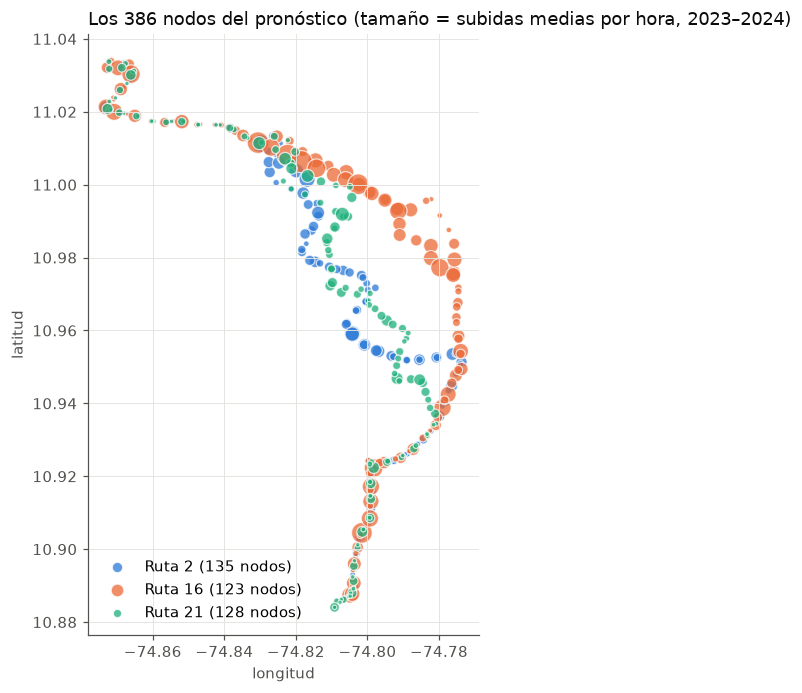

In [2]:
c1 = json.loads((E2C / 'panel/cifras_e2c_1.json').read_text(encoding='utf-8'))
bloques = (pd.DataFrame(c1['bloques']).T.rename_axis('bloque').reset_index()
           [['bloque', 'papel', 'inicio', 'fin', 'dias', 'dias_evaluables']].sort_values(['papel', 'bloque'], ascending=[False, True]))
display(bloques.set_index('bloque'))
print(f"Panel: {c1['filas_1h']:,} filas = {c1['N']} nodos × {c1['dias']} días × 20 h  ·  "
      f"subidas válidas en la malla: {c1['atricion']['subidas_validas_en_malla']:,}")
print('Nodos por ruta:', nodos.idruta.value_counts().sort_index().to_dict(),
      '· compartidos con otra ruta:', int(nodos.compartido_otra_ruta.sum()),
      '· en la zona de la terminal:', int(nodos.zona_terminal.sum()))
display(pd.Series(c1['ceros_1h']['todo'], name='% de las celdas (1 h)').to_frame()
        .rename(index={'positivo': 'subidas > 0', 'observado': 'cero con bus (cero observado)',
                       'estructural': 'cero sin bus (cero de oferta)', 'nan': 'sin dato (NaN, nunca se rellena)'}))

# La red: cada punto es un nodo (segmento de 500 m); tamaño = subidas medias por hora en 2023–2024
media_nodo = ent.groupby('nodo').subidas.mean()
m = nodos.set_index('nodo').join(media_nodo.rename('media'))
fig, ax = plt.subplots(figsize=(8.2, 6.4))
for r in (2, 16, 21):
    x = m[m.idruta == r]
    ax.scatter(x.lon_centroide, x.lat_centroide, s=8 + 6 * x.media, color=COL_RUTA[r], alpha=0.75,
               edgecolors='white', linewidths=0.8, label=f'Ruta {r} ({len(x)} nodos)')
ax.set_aspect(1 / np.cos(np.radians(m.lat_centroide.mean())))
ax.set_xlabel('longitud'); ax.set_ylabel('latitud')
ax.set_title('Los 386 nodos del pronóstico (tamaño = subidas medias por hora, 2023–2024)', loc='left')
ax.legend(loc='lower left', markerscale=0.8)
plt.tight_layout(); plt.show()

**La evidencia de esta sección** son los notebooks del e2c.0 (decisiones congeladas antes de tocar la base: nodo, hora, target, rezagos admisibles, plan de extracción y criterios de aceptación) y del e2c.1 (extracción, panel, atrición y conservación de las subidas). Siguen intactos.

<a id="e2c-1"></a>

### 1.1 · Evidencia &middot; e2c.0 · Decisiones previas y plan de extracción

<sub>Notebook original: `subfase_e2c_0_decisiones.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# Subfase e2c.0 · Decisiones previas y plan de extracción

Qué se predice (nodo, intervalo y target), cuándo se emite, qué rezagos son admisibles, con qué datos se construye el panel y cómo se juzga el éxito, **antes** de tocar la base o modelar (como la 6.0).

**Notebook de presentación (e2c.7).** Lee las salidas ya guardadas del módulo; no consulta la base, no reentrena ni vuelve a evaluar el holdout o los días de validación (esas corridas se hicieron una sola vez, con registro y hora). Las cifras de las conclusiones vienen de `datos_e2c/estado_e2c.md`, verificadas contra sus CSV al cerrar cada módulo.

In [1]:
%matplotlib inline
import json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
D = Path('datos_e2c')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 90)

def tabla(p, n=None, **kw):
    t = pd.read_csv(D / p, **kw)
    display(t if n is None else t.head(n))
    return t

def fig(p, w=900):
    display(Image(filename=str(D / p), width=w))

def h_json(d):
    return hashlib.sha256(json.dumps(d, ensure_ascii=False, sort_keys=True).encode('utf-8')).hexdigest()

def verificar_regla(p, clave=None):
    """Recalcula el hash de contenido de una regla congelada (sin la clave del hash ni `creado`)."""
    r = json.loads((D / p).read_text(encoding='utf-8'))
    clave = clave or next((k for k in ('sha256_regla', 'sha256_decision', 'sha256') if k in r), None)
    if clave is None:                                    # reglas cuyo hash solo está en el manifiesto
        man = json.loads((D / 'manifiesto_e2c.json').read_text(encoding='utf-8'))['reglas']
        h, ref = h_json(r), man[Path(p).name]
    else:
        h, ref = h_json({k: v for k, v in r.items() if k not in (clave, 'creado')}), r[clave]
    print(f"{p}: {'OK' if h == ref else 'NO COINCIDE'} · {ref[:12]}…")
    return r

def checks(n):
    c = pd.read_csv(D / f'checks/checks_e2c_{n}.csv')
    display(c)
    print(c.iloc[:, [i for i, x in enumerate(c.columns) if x.lower() in ('estado', 'resultado')][0]].value_counts().to_dict())

## Reglas congeladas (hash de contenido)

In [2]:
for p in ['reglas/regla_decisiones_e2c.json', 'reglas/regla_aceptacion_e2c.json']:
    verificar_regla(p)
dec = json.loads((D / 'reglas/regla_decisiones_e2c.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'tema': k, 'decisión': (v.get('decision') or v.get('estado') or v.get('modelo') or v.get('recomendado'))}
                      for k, v in dec.items() if isinstance(v, dict) and k != 'escenarios']))

reglas/regla_decisiones_e2c.json: OK · e801bc9169b9…
reglas/regla_aceptacion_e2c.json: OK · f2be118552d1…


,tema,decisión
0,nodo,"(idruta, nro_segmento): segmento de 500 m del Módulo 10, N = 386 (135 / 123 / 128)"
1,resolucion,1 h para el modelo; el panel guarda también 15 min (mismas lecturas) para sensibilidad
2,target,"y_{i,t} = Σ cantidad_subida de las lecturas del nodo i con `fecha` (hora real) en la h..."
3,bajadas,no se pronostican: el simulador conserva el reparto de bajadas de la 13.1
4,latencia,PENDIENTE de verificación en e2c.1.1 (`py extraer_e2c.py --latencia`)
5,exposicion,se predice el CONTEO; log1p(exposición planeada) entra como feature en el principal; l...
6,plan_extraccion,B
7,particion,None


## e2c.0.1–e2c.0.10 · Decisiones con sus cifras (`datos_e2c/decisiones_e2c.md`)

In [3]:
display(Markdown((D / 'decisiones_e2c.md').read_text(encoding='utf-8').split('## Punto de control PC1')[0]))

# e2c.0 · Decisiones previas al pronóstico espacio-temporal

Este módulo hace lo mismo que la 6.0 a escala nodo × tiempo: decide qué se predice, dónde, cuándo, con qué datos y con qué criterio de éxito. No extrae datos, no construye features y no entrena modelos.

**Cómo se obtuvieron las cifras.** Todas salen de salidas ya ejecutadas, sin consultar la RDS:
- `datos_e2c/diagnosticos/diagnosticos_e2c_0.json` (lo produce `py -3.10 diagnosticos_e2c_0.py`);
- `datos_e2c/plan/plan_e2c.json` (lo produce `plan_extraccion_e2c.py`).

**Reglas congeladas** (el hash es del contenido):
- `reglas/regla_decisiones_e2c.json`: `e801bc9169b9…`;
- `reglas/regla_aceptacion_e2c.json`: `f2be118552d1…`.

Las dos están en `manifiesto_e2c.json`. Resultado de los checks: **14 PASS · 0 FAIL · 4 INFO** (`checks/checks_e2c_0.csv`).

> **Uso de los días de la 13.1.** Los 6 días de validación de la 13.1 y los 3 de control de la 13.2 son los únicos días **completos** ya extraídos. Por eso se usaron, pero solo para diagnósticos **estructurales**: ceros, exposición, ubicación y latencia. Ningún umbral de desempeño se fijó con ellos, y no cuentan como mirar el holdout para elegir un modelo.

---

## e2c.0.1 · Requisitos frente a lo que ya existe

**Fuentes de los requisitos.** El enunciado oficial del Entregable 2 y los comentarios textuales de la calificación **no están** en la carpeta. `_enunciados/` solo trae la guía del Entregable 3 y la rúbrica de sustentación. Por eso los requisitos salen de:
- la tabla §1.2 del contexto común;
- los módulos e2c.2 a e2c.5;
- el bloque A de la guía del Entregable 3: tabla de trazabilidad, auditoría de fuga y honestidad ante los cambios.

| Requisito | ¿Lo cumple el proyecto? | Dónde | Qué falta (módulo) |
|---|---|---|---|
| Pronóstico y_{i,t} sobre N nodos espaciales | **No** | El E1 predice **por viaje** (6.0, 7.3) | Panel nodo × hora (e2c.1) y modelo (e2c.4–5) |
| Matriz KNN Haversine entre nodos, con k justificado | Parcial | 4.3: celdas de 250 m, k = 6, I = 0,18, pero **nunca llegó al modelo** | e2c.2.1 sobre los segmentos |
| Lag espacial (A_norm Y)_{i,t−L} | **No (se apartó)** | 6.2: rezago **entre 3 rutas** con W de 3 × 3 casi uniforme (0,455–0,545) | e2c.3.3 |
| EDA a escala nodo × tiempo (Moran por franja, ACF por nodo, mapas de calor) | **No** | El EDA del E1 es por ruta × 15 min o espacial estático | e2c.2 |
| Features sin leakage a escala nodo × tiempo | **No** | 6.1–6.3, por viaje | e2c.3, con auditoría A1–A7 |
| x̃_{i,t−1} del enunciado | Solo oráculo | 6.0 §5: «se aparta del enunciado» | e2c.0.6: sigue en el oráculo (ver abajo) |
| Walk-forward purgado y holdout evaluado una sola vez | Sí, por viaje | 7.1–7.3 | Se adapta a los bloques (e2c.0.9, e2c.4) |
| Líneas base y Diebold-Mariano | Sí, por viaje | 7.1, 8.3 | e2c.4.2 y e2c.5.7, con la línea base (iii) = entrada del simulador |
| SHAP | Sí, por viaje | 8.2 | e2c.5.6 |
| Simulador que cumple su criterio | **No: 3 de 6** | 13.4 y 13.4b | e2c.6 |
| Tabla de trazabilidad de correcciones (guía E3, bloque A) | **No** | — | e2c.7 |
| Auditoría explícita de fuga (guía E3, bloque A) | Sí, por viaje | 6.3 | e2c.3.7 |

**Dónde se apartó el E1 del enunciado:**
1. El target es por viaje y no por nodo × intervalo.
2. El lag espacial es entre rutas y no entre segmentos.
3. t−1 y x̃_{i,t−1} quedaron en el oráculo.
4. La dependencia espacial medida en el EDA (Moran entre celdas) nunca entró al modelo.

---

## e2c.0.2 · Latencia de las lecturas (¿es posible un nowcast?)

- **No hay marca de inserción.** `conteo_pasajeros_destino` tiene 25 columnas (`Query1.csv`) y ninguna es una marca de inserción o de registro: solo `fecha`, que es el momento de la lectura. Con lo ya extraído, la latencia **no se puede medir**.
- **Proxy por el orden de `id`.** Si `id` es la secuencia de inserción, entonces el máximo acumulado de `fecha` en el orden de `id`, menos la `fecha` propia, da una **cota inferior** del retraso de cada lectura frente al equipo más rápido.
  - El supuesto es plausible: en el 98,6–98,9 % de los viajes, `id` crece con `fecha`.
  - Resultado en las lecturas con subida:

    | Días | Mediana | P95 | P99 | > 15 min |
    |---|---|---|---|---|
    | E2: 6 días de la 13.1 (233.558 lecturas) | 0,03 min | 0,95 min | 4,3 min | 0,14 % |
    | E4: 3 días de control (104.749 lecturas) | 0,0 min | 1,8 min | 4,4 min | 0,07 % |

  - **Límite:** el proxy no ve un retraso común a todos los equipos.
- **Consulta liviana propuesta (no ejecutada):** `py extraer_e2c.py --latencia`.
  - Primero corre `SHOW track_commit_timestamp`.
  - Solo si está activa, lee `pg_xact_commit_timestamp(xmin)` de 20 viajes de un día, filtrando por `idprogramacion`.
- **Decisión:** nowcast **pendiente de verificación en PC1 / e2c.1.1**. Mientras tanto se supone δ_max = 1 h (conservador frente al P99 de 4,4 min).
  - Si no se puede verificar, el escenario intradía se presenta como **oráculo**, no como desplegable.

## e2c.0.3 · Unidad espacial (nodo i)

Diagnóstico sobre los 6 días completos de la 13.1 (976.952 lecturas ya ubicadas con el Viterbi del Módulo 10). La malla va de 04:00 a 23:59.

| Criterio | Segmento de 500 m (N = 386) | Celda de 250 m (N = 364) |
|---|---|---|
| Subidas que caen en un nodo | 95,3 % en ruta; +4,59 % en desvío, asignables a su segmento; 0,11 % en el parqueadero | 99,78 % de las subidas que no son del parqueadero |
| Ceros estructurales, 1 h (sin bus) | 17,1 % | 20,1 % |
| Ceros de muestreo, 1 h (con bus) | 23,5 % (28,4 % de las celdas expuestas) | 22,0 % (27,7 %) |
| Ceros estructurales / de muestreo, 15 min | 31,4 % / 33,7 % | 32,7 % / 30,3 % |
| Exposición media en celdas expuestas, 1 h | 8,2 buses | 13,9 pasos de bus (varias rutas) |
| Conectividad KNN | k = 2: 41 componentes; k = 6: 2; **k = 8: 1** (vecino k-ésimo mediano 410 m). El circuito de cada ruta ya es conexo | k = 2: 6 componentes; k = 4: 1 (359 m); k = 6: 1 (480 m), como el E1 |
| Nodos compartidos | 59,1 % tienen un segmento de otra ruta a ≤ 100 m; 35,5 % tienen el sentido contrario de su propia ruta a ≤ 100 m | 65,7 % tienen 2 o 3 rutas |
| Compatibilidad con el simulador | **Directa**: `llegadas_segmento_hora_13_1.parquet` es (ruta, segmento, hora) | Requiere repartir celda → ruta → segmento con fracciones fijas |

**Decisión: el nodo es (idruta, nro_segmento), N = 386** (135 / 123 / 128 por ruta).

- **Por qué el segmento:** con segmentos, el pronóstico entra al simulador sin ningún reparto fijo. Ese reparto fijo es justo lo que falló en la 13.4.
- **Por qué no la celda:** obligaría a volver a repartir con fracciones fijas.
- **Paraderos:** SOBUSA no tiene paraderos fijos (`idpunto` está nulo en ~90 %), así que el segmento de 500 m hace de zona de parada equivalente.
- **Vecinos:** pueden ser de otra ruta o del sentido contrario, porque el 59 % de los segmentos comparte vía con otra ruta. La matriz y el k se eligen en e2c.2.1.
- **Lectura preliminar, no decidida aquí:** k = 2 no sirve como grafo (41 componentes).

## e2c.0.4 · Resolución temporal

| Segmento | Cero estructural | Cero de muestreo | Cero de muestreo entre las celdas expuestas | Subidas medias (expuestas) | Varianza / media |
|---|---|---|---|---|---|
| 15 min | 31,4 % | 33,7 % | 49,3 % | 1,77 | 5,7 |
| 1 h | 17,1 % | 23,5 % | 28,4 % | 5,88 | 16,3 |

**Decisión: el modelo trabaja a 1 h.**
- **Por qué:** a 1 h los ceros estructurales bajan a casi la mitad y los de muestreo entre las celdas expuestas pasan de 49 % a 28 %. Además, 1 h es la escala del simulador. Los rezagos del E1 {96, 192, 672, 1344} × 15 min equivalen a {24, 48, 168, 336} h.
- **Panel:** guarda también la versión de 15 min, con las mismas lecturas, para sensibilidad.
- **Malla:** de 04:00 a 23:59, 20 intervalos por día. Cubre el servicio de 4 a 20 h y el cierre de los viajes.
- **Pendiente para e2c.1.5:** verificar que las lecturas de 00:00 a 03:59 son despreciables.

## e2c.0.5 · Target y bajadas

- **Target:** y_{i,t} = subidas (`cantidad_subida`) del segmento i con `fecha` (hora real de la lectura) en la hora t.
- **Relación con `numeropasajeros`:** en los 2.636 viajes de la maestra, la suma de las lecturas da 1,0017 × `numeropasajeros_raw`, y coincide exacto en el 88,3 % de los viajes.
- **Hallazgo 1: hay que usar todas las salidas.** El **8,16 % de las subidas viene de salidas que no están en la maestra** (las «canceladas» que operaron). Por eso el panel usa **todas** las salidas de `tb_despachos`.
  - Es una causa candidata de que al simulador le falte gente a bordo, porque la 13.1 calibró con la maestra.
  - Es una hipótesis para e2c.6, no está demostrada.
- **Hallazgo 2: qué subidas quedan fuera del panel.** Las subidas se reparten así:

  | Ubicación | % de las subidas |
  |---|---|
  | En ruta, fuera de la zona terminal | 92,35 % |
  | En ruta, zona terminal (6 segmentos por extremo) | 2,95 % |
  | En desvío | 4,59 % |
  | Parqueadero | 0,11 % |

  - Las subidas en desvío **entran** al segmento que da el Viterbi, con la bandera `en_desvio`.
  - Las del parqueadero se excluyen.
- **Decisión sobre las bajadas:** no se pronostican, y el simulador conserva su reparto de bajadas.
  - Las bajadas son menos fiables (CLAUDE.md §5.6; aquí suman 0,985 × las subidas).
  - La 13.4b, ronda 1, mostró que el error es **gente que falta a bordo**, no dónde se baja: un pasajero de la mañana viaja 18,8 segmentos y el reparto ya daba ~18.
  - Un segundo modelo duplicaría el costo sin atacar la causa.

## e2c.0.6 · Escenarios de emisión y admisibilidad

**Regla** (la de la 6.0 a la escala nueva): L es admisible si L ≥ L_min = ⌈(lead + ancho + δ) / ancho⌉, con un ancho de 1 h y δ = 1 h mientras no se verifique la latencia.

| Escenario | t₀ | lead máx. | L_min | Rezagos | Capa |
|---|---|---|---|---|---|
| **04:00 (principal)** | 04:00 del día; objetivos de 04 a 23 h | 19 h | **21 h** | {24, 48, 168, 336} h, más medias de la misma hora en 1 y 2 semanas y ventanas ancladas en t − L_min | Desplegable |
| Nowcast intradía | Inicio de la hora objetivo | 0 | **2 h** | {2, 3, 24, 48, 168, 336} | Desplegable **solo** si e2c.1.1 verifica δ P99 ≤ 60 min; si no, oráculo |
| Oráculo | — | — | — | Agrega t−1 y x̃_{i,t−1} | No desplegable |

t−1 nunca es desplegable: la hora t−1 cierra justo en t₀ y su dato llega δ > 0 después. Pasa al oráculo, como en la 6.0.

## e2c.0.7 · Oferta y exposición

**Cómo se mide:**
- **Realizada:** viajes distintos con una lectura ubicada en el nodo durante la hora. Solo se usa para diagnóstico.
- **Planeada:** cada salida del plan entra al segmento s en `fechasalida` + la suma de los tiempos medianos de los segmentos anteriores (13.1, por franja × tipo de día).
  - En entrenamiento, el plan es la lista de salidas del día, igual que el headway del E1.
  - Al emitir, se usa el plan propuesto.

**Diagnóstico de la versión aproximada** (41.082 celdas segmento × hora):

| Medida | Valor |
|---|---|
| Correlación planeada–realizada | 0,595 |
| MAE | 3,76 buses |
| Total planeado / realizado | 1,24 |
| Subidas en celdas con exposición planeada 0 | 4,7 % |
| R² de las subidas con la realizada | 0,221 |
| R² de las subidas con la planeada | 0,076 |

**Decisión:** se predice el **conteo**. `log1p(exposición planeada)` entra como **feature**.
- La tasa con offset (`init_score = log exposición planeada`) queda como **ablación** en e2c.4.6.
- **Por qué no el offset desde ya:** impondría una proporcionalidad que la versión actual no respalda.
- **Pendiente para e2c.1.6:** afinar el cálculo de la planeada (franja de **entrada** al segmento en vez de franja de salida, y reconciliar la razón de 1,24) antes de esa ablación.

## e2c.0.8 · Plan de extracción

**Por qué hace falta extraer.** El lag espacial exige ver todos los nodos a la vez, y los rezagos exigen días consecutivos. Por eso se necesitan **bloques de días completos**, con todas las salidas de `tb_despachos`.

**Volumen estimado.** Sale de multiplicar:
- 321,8 lecturas por salida (medido en E2 y E4);
- 18,81 bytes por lectura en Parquet;
- las salidas reales de cada día.

**Qué se reutiliza y qué no:**
- Se reutilizan los 9 días ya completos: 6 de la 13.1 y 3 de control.
- No sirven las lecturas del E1 ni la muestra E3 de la 13.4b, porque no son días completos.

| Plan | Bloques | Días (nuevos) | Salidas nuevas | Lotes de 200 | Lecturas est. | % de la tabla | Parquet | Tiempo con 15–60 s por lote |
|---|---|---|---|---|---|---|---|---|
| **B (recomendado)**: calentamiento de 14 días; rezagos hasta 336 h | 9 | 397 (388) | 197.269 | 992 | 63,5 M | 36,1 % | 1,19 GB | 4,1–16,5 h |
| A (liviano): calentamiento de 7 días; sin el rezago de 2 semanas | 8 | 306 (297) | 151.050 | 760 | 48,6 M | 27,6 % | 0,92 GB | 3,2–12,7 h |

**Bloques del plan B** (`plan/bloques_e2c_B_recomendado.csv`):
- **Entrenamiento, 119 días evaluables:**
  - **T1** (4-feb a 10-mar-2023): Carnaval 2023.
  - **T2** (19-jun a 23-jul-2023): receso de mitad de año y regreso a clases.
  - **T3** (1-ene a 18-feb-2024): fin del receso de inicio de año, regreso a clases y Carnaval 2024.
  - **T4** (23-sep a 27-oct-2024): receso de octubre.
  - **T5** (25-nov a 29-dic-2024): diciembre y receso de fin de año.
- **Holdout 2025, 152 días evaluables:**
  - **H1** (1-feb a 6-abr): 15-feb, Carnaval, 25-mar y 3-abr.
  - **H2** (30-may a 27-jul): 13-jun, receso de mitad de año y 27-jul.
  - **H3** (5-ago a 21-sep): 19-ago y 20-sep.
  - **H4** (26-oct a 30-nov): 9-nov y 25-nov.
- Los 9 días ancla tienen sus 14 días previos dentro de su bloque. Así, e2c.5.8 y e2c.6.4 pueden predecirlos.
- **Fuera del plan:** el apagón de junio de 2024 (se evita) y Semana Santa (limitación declarada).

**Script `extraer_e2c.py` (escrito, no ejecutado):**
- Pide lotes de 200 viajes por `idprogramacion`, con columnas explícitas y sin `acumulada_*`.
- La contraseña se pide con `getpass`.
- Es reanudable y no vuelve a consultar un lote ya guardado.
- Tiene modos `--indices`, `--latencia`, `--prueba-dia` (se detiene si el volumen se desvía más de ±50 %) y `--preparar`, que congela los viajes con hash. La prueba offline de `--preparar --seco` dio 197.269 viajes y el hash `3cefd3f0ad5c…`.

**Riesgos:**
- Las extracciones anteriores no registraron el tiempo por lote, así que el rango de horas es una estimación. `--prueba-dia` lo mide.
- El plan B lee un tercio de la tabla por índice. **El equipo elige B o A en PC1.**

## e2c.0.9 · Partición

- **Calentamiento:** los primeros 14 días de cada bloque solo alimentan rezagos y nunca son filas objetivo.
- **Walk-forward expansivo sobre los bloques del plan B.** El corte es a las 04:00 del primer día evaluable:

  | Pliegue | Entrena | Valida | Corte |
  |---|---|---|---|
  | P1 | T1 | T2 | 2023-07-03 |
  | P2 | T1–T2 | T3 | 2024-01-15 |
  | P3 | T1–T3 | T4 | 2024-10-07 |
  | P4 | T1–T4 | T5 | 2024-12-09 |

- **Purga:** la fila (i, t) entra al entrenamiento solo si t + 1 h + δ ≤ corte.
- **Diseño fuera de rango** (lección del e1c): un «salto de año» que entrena T1 + T2 (2023) y valida T3–T5 (2024) juntos.
- **Holdout:** H1–H4 de 2025, entrenando con T1–T5 y evaluando una sola vez. Ningún bloque del holdout se solapa con el entrenamiento ni con su calentamiento: el entrenamiento llega hasta el 29-dic-2024 y el holdout empieza el 1-feb-2025.

## e2c.0.10 · Criterios de aceptación (congelados en `regla_aceptacion_e2c.json`, `f2be118552d1…`)

- **Métrica.** Devianza Tweedie con p fijo: se re-estima en e2c.2.5 y se congela en e2c.4.3, antes de la búsqueda. Además se reportan MAE, RMSE y WAPE; el MAPE solo sobre y > 0.
- **C1.** El modelo 04:00 supera a las líneas base (i) ingenua estacional, (ii) perfil histórico y **(iii) entrada actual del simulador** en ≥ 3 de 4 pliegues y en la media.
- **C2.** La ablación sin lag espacial es peor en la mayoría de los pliegues.
- **C3.** Ninguna prueba anti-leakage A1–A7 queda en FAIL.
- **En el holdout:**
  - mejor que (iii) en total y en ≥ 3 de los 4 bloques;
  - Diebold-Mariano frente a (iii) con p calibrado, Holm y α = 0,05.
- **C4 · simulador.** MAE de ocupación ≤ al del perfil histórico en al menos 5 de 6 días **nuevos** del holdout, congelados en e2c.6.1. El 3 de 6 oficial de la 13.4 no cambia.
- Todo criterio que no se cumpla se reporta tal cual.

---



## Diagnósticos que respaldan las decisiones (9 días completos ya extraídos, sin consultar la base)

,candidato,minutos,pct_cero_estructural,pct_cero_muestreo,pct_positivo,pct_cero_entre_expuestas,media_subidas_expuestas,exposicion_media_expuestas,subidas_por_bus_expuesto,disp_var_media_expuestas
0,celda_250m,15,32.717,30.282,37.001,45.174,2.008,4.319,0.459,6.384
1,celda_250m,60,20.140,22.035,57.825,27.661,6.786,13.879,0.483,20.135
2,segmento_500m,15,31.367,33.734,34.899,49.303,1.773,2.617,0.671,5.697
3,segmento_500m,60,17.064,23.502,59.434,28.404,5.877,8.209,0.708,16.348


,Unnamed: 0,subidas,pct
0,en ruta · resto,220171,92.35
1,en ruta · zona terminal,7032,2.95
2,extremo_fuera (parqueadero),258,0.11
3,fuera_de_ruta (desvío),10946,4.59


,hora,planeada,realizada,dif_pct
0,4,901.0,559.0,61.2
1,5,11463.0,7936.0,44.4
2,6,25482.0,16368.0,55.7
3,7,29649.0,19456.0,52.4
4,8,30827.0,20472.0,50.6
5,9,25520.0,21050.0,21.2
6,10,23690.0,21666.0,9.3
7,11,21757.0,19975.0,8.9
8,12,22113.0,18495.0,19.6
9,13,22382.0,19809.0,13.0


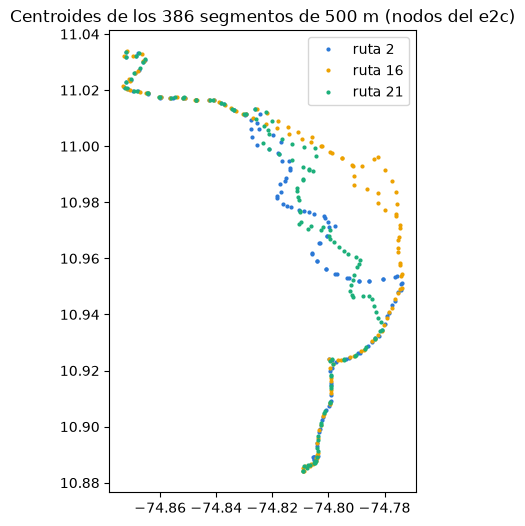

In [4]:
tabla('diagnosticos/ceros_resumen_e2c_0.csv')
tabla('diagnosticos/subidas_por_ubicacion_e2c_0.csv')
tabla('diagnosticos/exposicion_planeada_vs_realizada_e2c_0.csv')
seg = pd.read_csv(D / 'diagnosticos/segmentos_e2c_0.csv')
fig_, ax = plt.subplots(figsize=(7, 6))
for r, c in zip((2, 16, 21), ('#2a78d6', '#eda100', '#1baf7a')):
    s = seg[seg.idruta == r]; ax.plot(s.lon, s.lat, '.', ms=4, color=c, label=f'ruta {r}')
ax.set_title('Centroides de los 386 segmentos de 500 m (nodos del e2c)'); ax.legend(); ax.set_aspect('equal'); plt.show()

## Plan de extracción y partición

In [5]:
tabla('plan/volumen_plan_e2c.csv')
tabla('plan/bloques_e2c_B_recomendado.csv')
display(pd.DataFrame(dec['particion']['pliegues_plan_B']))

,plan,bloques,dias,dias_nuevos,dias_evaluables_entrenamiento,dias_evaluables_holdout,salidas_nuevas,lotes_200,lecturas_est_M,pct_de_la_tabla,parquet_est_GB,horas_est_15s_por_lote,horas_est_60s_por_lote,holdout_inicio_min,entrenamiento_fin_max,holdout_separado,holdout_todo_2025
0,B_recomendado,9,397,388,119,152,197269,992,63.5,36.1,1.19,4.1,16.5,2025-02-01,2024-12-29,True,True
1,A_liviano,8,306,297,98,152,151050,760,48.6,27.6,0.92,3.2,12.7,2025-02-08,2024-12-29,True,True


,bloque,papel,inicio,fin,dias,dias_calentamiento,inicio_evaluable,dias_evaluables,dias_ya_extraidos,dias_nuevos,salidas_nuevas,lotes_200,lecturas_est_M,parquet_est_MB,dias_sin_salidas,cubre
0,T1,entrenamiento,2023-02-04,2023-03-10,35,14,2023-02-18,21,0,35,18554,93,5.97,112.0,0,Carnaval 2023 (18–21 feb) + clases
1,T2,entrenamiento,2023-06-19,2023-07-23,35,14,2023-07-03,21,0,35,17952,90,5.78,109.0,0,receso de mitad de año 2023 + regreso a clases
2,T3,entrenamiento,2024-01-01,2024-02-18,49,14,2024-01-15,35,0,49,25231,127,8.12,153.0,0,"fin del receso de inicio de año, regreso (29-ene) y Carnaval 2024 (10–13 feb)"
3,T4,entrenamiento,2024-09-23,2024-10-27,35,14,2024-10-07,21,0,35,17045,86,5.49,103.0,0,receso de octubre 2024 + clases
4,T5,entrenamiento,2024-11-25,2024-12-29,35,14,2024-12-09,21,0,35,17861,90,5.75,108.0,0,diciembre y receso de fin de año 2024
5,H1,holdout,2025-02-01,2025-04-06,65,14,2025-02-15,51,3,62,31820,160,10.24,193.0,0,"15-feb, Carnaval 2025 (1–4 mar), 25-mar y 3-abr (días 13.1)"
6,H2,holdout,2025-05-30,2025-07-27,59,14,2025-06-13,45,2,57,29842,150,9.60,181.0,0,"13-jun (lluvia), receso de mitad de año, 27-jul (días 13.1)"
7,H3,holdout,2025-08-05,2025-09-21,48,14,2025-08-19,34,2,46,22206,112,7.15,134.0,0,19-ago y 20-sep (control 13.2)
8,H4,holdout,2025-10-26,2025-11-30,36,14,2025-11-09,22,2,34,16758,84,5.39,101.0,0,9-nov (control 13.2) y 25-nov (día 13.1)


,pliegue,entrena,valida,corte
0,P1,[T1],T2,2023-07-03 04:00
1,P2,"[T1, T2]",T3,2024-01-15 04:00
2,P3,"[T1, T2, T3]",T4,2024-10-07 04:00
3,P4,"[T1, T2, T3, T4]",T5,2024-12-09 04:00


## Checks

In [6]:
checks(0)

,check,descripcion,estado,detalle
0,C01,Cada decisión tiene al menos una cifra que la respalda,PASS,sin cifra: ninguna
1,C02,Toda L de un escenario desplegable ≥ su L_min,PASS,"04:00 L_min 21 → [24, 48, 168, 336]; nowcast L_min 2 → [2, 3, 24, 48, 168, 336] (despl..."
2,C03,El nowcast no usa t−1 (t−1 solo en el oráculo),PASS,t−1 solo en la capa oráculo
3,C04_B,Plan B: los bloques (con calentamiento) no se solapan y el holdout va después del entr...,PASS,"solapes []; entrenamiento hasta 2024-12-29, holdout desde 2025-02-01"
4,C05_B,Plan B: los 9 días ancla de 2025 (13.1 y control) tienen calentamiento completo,PASS,sin cubrir: ninguno
5,C04_A,Plan A: los bloques (con calentamiento) no se solapan y el holdout va después del entr...,PASS,"solapes []; entrenamiento hasta 2024-12-29, holdout desde 2025-02-08"
6,C05_A,Plan A: los 9 días ancla de 2025 (13.1 y control) tienen calentamiento completo,PASS,sin cubrir: ninguno
7,C06,Rezago máximo ≤ calentamiento del plan B,PASS,336 h ≤ 336 h
8,C07,Cada pliegue valida después del fin de sus bloques de entrenamiento; el corte es el pr...,PASS,P1: T1 → T2 (2023-07-03 04:00); P2: T1+T2 → T3 (2024-01-15 04:00); P3: T1+T2+T3 → T4 (...
9,C08,No se consultó la RDS en este módulo,PASS,datos_e2c/extraccion/ existe: False; scripts ejecutados con conexión: ninguno


{'PASS': 14, 'INFO': 4}


## Punto de control PC1 (registro)
- **17-nov-2026 · Integrante 1:** «El plan B imagino» → **plan B (recomendado)**: 9 bloques, 388 días nuevos, ~63,5 M lecturas y ~1,2 GB.
- **Decisiones de la tabla** (nodo, 1 h, target, bajadas, exposición, nowcast condicionado): el Integrante 1 no pidió cambios. Quien ejecute el e2c.1 las ratifica con el equipo antes de correr `extraer_e2c.py` y lo anota aquí.
- **17-nov-2026 23:30 · ratificación para ejecutar e2c.1 (supuesto declarado por Claude).** El usuario delegó el módulo completo («te dejo toda la tarea a ti») sin pedir cambios a la tabla; se toma como ratificado el plan **B** y las decisiones de e2c.0 tal cual. Si el equipo no está de acuerdo, se detiene `correr_e2c_1.bat` antes de la extracción (Ctrl+C) y se anota aquí.
- **Antes de extraer (e2c.1, Claude):**
  - **Reutilización:** 91 de los 388 días nuevos del plan B ya estaban extraídos en el Módulo 15 (E5: 71 días; E6: 20 domingos y festivos; todas las salidas de `tb_despachos`, completitud comprobada día por día). `extraer_e2c_1.py --importar-m15` los copia a `datos_e2c/reutilizados/m15_dias_e2c.parquet` (con hash) y amplía `REUTILIZADOS` en memoria; `extraer_e2c.py` no se modifica. Quedan ~297 días por extraer (todo 2023–2024 y parte de 2025).
  - **Regla del panel congelada antes de correr:** `datos_e2c/reglas/regla_panel_e2c.json` (validez de viaje, NaN, tipos de cero, exposición, banderas y corrección de la salida de la terminal).
  - **Hallazgo (e2c.1.4) · corrección explícita a la ubicación del M10/M13:** en ~la mitad de los viajes el Viterbi ubica el tramo de **salida** de la terminal en los últimos segmentos del circuito recorridos hacia atrás (p. ej. 123 → 105 y luego 18), porque ida y regreso comparten vía. En el día de control 2025-08-19 (diagnóstico estructural): 321 viajes, 88 % «bajando», 9,7 % de las subidas del día (ruta 2: 1,4 %; 16: 12,5 %; 21: 14,4 %). El panel los reubica en los segmentos 1–25 de la ida con el mismo Viterbi (`nro_segmento_m10` conserva el original). La 13.1 calibró `reparto_segmento_13_1.csv` sin esta corrección: es una **causa candidata** adicional del faltante a bordo de la mañana en la 13.4, para probar en e2c.6.

**Conclusión e2c.0 · El pronóstico del e2c es y_{i,t} = subidas por segmento de 500 m (N = 386) × hora, emitido a las 04:00 con rezagos {24, 48, 168, 336} h; el plan B (9 bloques, 5 de entrenamiento 2023–2024 y 4 de holdout 2025) y los criterios de aceptación quedaron congelados con hash antes de extraer.**
- Cifra: a 1 h el cero estructural baja de 31,4 % a 17,1 % y el de muestreo entre celdas expuestas de 49,3 % a 28,4 %; el 95,3 % de las subidas cae en ruta y el 4,59 % en desvíos asignables al segmento.
- Lectura: el segmento es el nodo del simulador, así que el pronóstico entra sin el reparto fijo que falló en la 13.4; la celda de 250 m mezclaba rutas (65,7 % de las celdas).
- Límite: la latencia de las lecturas no se podía medir con lo extraído; el nowcast quedó condicionado (en e2c.1 resultó oráculo: `track_commit_timestamp = off`). 14 PASS · 0 FAIL · 4 INFO.

<a id="e2c-2"></a>

### 1.2 · Evidencia &middot; e2c.1 · Extracción y panel Y (nodo × hora)

<sub>Notebook original: `subfase_e2c_1_panel.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# Subfase e2c.1 · Extracción y panel Y (nodo × hora)

Panel Y ∈ ℝ^{N×T} de subidas por segmento × hora sobre la malla completa, con exposición realizada y planeada, tipos de cero y banderas, verificado contra las fuentes.

**Parte 1 · extracción** (`extraer_e2c.py`, `extraer_e2c_1.py`, `correr_e2c_1.bat`): se corrió una vez en el PC de la Persona 3 (18-nov, 00:04–05:30), solo con `WHERE idprogramacion = ANY(:ids)` y la contraseña por `getpass`; aquí no se vuelve a ejecutar.

**Notebook de presentación (e2c.7).** Lee las salidas ya guardadas del módulo; no consulta la base, no reentrena ni vuelve a evaluar el holdout o los días de validación (esas corridas se hicieron una sola vez, con registro y hora). Las cifras de las conclusiones vienen de `datos_e2c/estado_e2c.md`, verificadas contra sus CSV al cerrar cada módulo.

In [1]:
%matplotlib inline
import json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
D = Path('datos_e2c')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 90)

def tabla(p, n=None, **kw):
    t = pd.read_csv(D / p, **kw)
    display(t if n is None else t.head(n))
    return t

def fig(p, w=900):
    display(Image(filename=str(D / p), width=w))

def h_json(d):
    return hashlib.sha256(json.dumps(d, ensure_ascii=False, sort_keys=True).encode('utf-8')).hexdigest()

def verificar_regla(p, clave=None):
    """Recalcula el hash de contenido de una regla congelada (sin la clave del hash ni `creado`)."""
    r = json.loads((D / p).read_text(encoding='utf-8'))
    clave = clave or next((k for k in ('sha256_regla', 'sha256_decision', 'sha256') if k in r), None)
    if clave is None:                                    # reglas cuyo hash solo está en el manifiesto
        man = json.loads((D / 'manifiesto_e2c.json').read_text(encoding='utf-8'))['reglas']
        h, ref = h_json(r), man[Path(p).name]
    else:
        h, ref = h_json({k: v for k, v in r.items() if k not in (clave, 'creado')}), r[clave]
    print(f"{p}: {'OK' if h == ref else 'NO COINCIDE'} · {ref[:12]}…")
    return r

def checks(n):
    c = pd.read_csv(D / f'checks/checks_e2c_{n}.csv')
    display(c)
    print(c.iloc[:, [i for i, x in enumerate(c.columns) if x.lower() in ('estado', 'resultado')][0]].value_counts().to_dict())

## Regla del panel y cifras de cierre

In [2]:
verificar_regla('reglas/regla_panel_e2c.json')
c = json.loads((D / 'panel/cifras_e2c_1.json').read_text(encoding='utf-8'))
display(pd.Series({k: c[k] for k in ('N', 'dias', 'T_horas', 'filas_1h', 'filas_15min', 'var_sobre_media_expuestas_1h',
                                     'media_subidas_expuestas_1h', 'pct_viajes_sin_lecturas', 'pct_viajes_invalidos',
                                     'pct_subidas_salida_corregida', 'pct_subidas_fuera_malla', 'cobertura_ruta_mediana',
                                     'razon_subidas_lecturas_numeropasajeros_raw', 'pct_viajes_igual_exacto',
                                     'pct_subidas_validas_de_salidas_fuera_maestra')}, name='valor'))
print('ceros a 1 h:', c['ceros_1h']); print('ubicación:', c['ubicacion'])

reglas/regla_panel_e2c.json: OK · 323ae1079702…


N                                               3.860000e+02
dias                                            3.970000e+02
T_horas                                         7.940000e+03
filas_1h                                        3.064840e+06
filas_15min                                     1.225936e+07
var_sobre_media_expuestas_1h                    1.809000e+01
media_subidas_expuestas_1h                      6.037000e+00
pct_viajes_sin_lecturas                         2.290000e+00
pct_viajes_invalidos                            4.700000e-01
pct_subidas_salida_corregida                    6.130000e+00
pct_subidas_fuera_malla                         1.000000e-02
cobertura_ruta_mediana                          9.860000e-01
razon_subidas_lecturas_numeropasajeros_raw      1.002000e+00
pct_viajes_igual_exacto                         8.725000e+01
pct_subidas_validas_de_salidas_fuera_maestra    7.090000e+00
Name: valor, dtype: float64

ceros a 1 h: {'todo': {'positivo': 51.58, 'observado': 21.35, 'estructural': 17.35, 'nan': 9.73}, 'evaluable': {'positivo': 51.5, 'observado': 21.27, 'estructural': 17.31, 'nan': 9.92}, 'pct_cero_entre_expuestas': 29.28}
ubicación: {'pct_en_ruta': 92.95, 'pct_en_desvio': 6.24, 'pct_parqueadero': 0.8, 'pct_zona_terminal': 4.2, 'viajes_nunca_salieron_terminal': 3287, 'viajes_sin_punto_en_ruta': 1788}


## e2c.1.3–e2c.1.4 · Atrición y ubicación de las lecturas

In [3]:
a = pd.read_csv(D / 'panel/atricion_e2c_1.csv')
display(a.groupby('bloque')[['salidas_plan', 'viajes_con_lecturas', 'viajes_sin_lecturas', 'viajes_validos', 'viajes_invalidos',
                            'lecturas_crudas', 'lecturas_ubicadas', 'subidas_ubicadas']].sum())
u = pd.read_csv(D / 'panel/ubicacion_e2c_1.csv')
s = u[['lecturas', 'en_ruta', 'en_desvio', 'parqueadero', 'en_zona_terminal']].sum()
display((100 * s / s['lecturas']).round(2).rename('% de las lecturas'))

,salidas_plan,viajes_con_lecturas,viajes_sin_lecturas,viajes_validos,viajes_invalidos,lecturas_crudas,lecturas_ubicadas,subidas_ubicadas
bloque,,,,,,,,
H1,33417,32036,1381,31853,183,10581010,10566778,2621402
H2,30786,29729,1057,29643,86,9230140,9221169,2076605
H3,23214,22733,481,22564,169,7805879,7797455,1882987
H4,17693,16663,1030,16602,61,5208361,5202067,1273427
T1,18554,18402,152,18294,108,6127437,6124399,1705488
T2,17952,17852,100,17776,76,5705699,5703101,1418823
T3,25231,25066,165,24987,79,7879655,7871608,1953306
T4,17045,16936,109,16840,96,5768659,5761538,1403313
T5,17861,17706,155,17614,92,5751712,5743705,1388426


lecturas            100.00
en_ruta              92.95
en_desvio             6.24
parqueadero           0.80
en_zona_terminal      4.20
Name: % de las lecturas, dtype: float64

## e2c.1.5 · Panel: tipos de cero por bloque (sin rellenar NaN con 0)

,bloque,estructural,nan,observado,positivo
0,H1,16.97,11.57,20.82,50.65
1,H2,17.02,9.93,21.98,51.07
2,H3,16.84,11.65,19.66,51.85
3,H4,16.95,12.43,20.82,49.80
4,T1,15.43,10.05,21.07,53.44
5,T2,18.08,6.87,22.27,52.78
6,T3,17.92,6.66,22.99,52.42
7,T4,19.05,7.95,21.25,51.75
8,T5,18.41,9.14,21.29,51.17


3,064,840 filas · 386 nodos · duplicados nodo×t: 0 (prueba de tests_e2c_1.py)


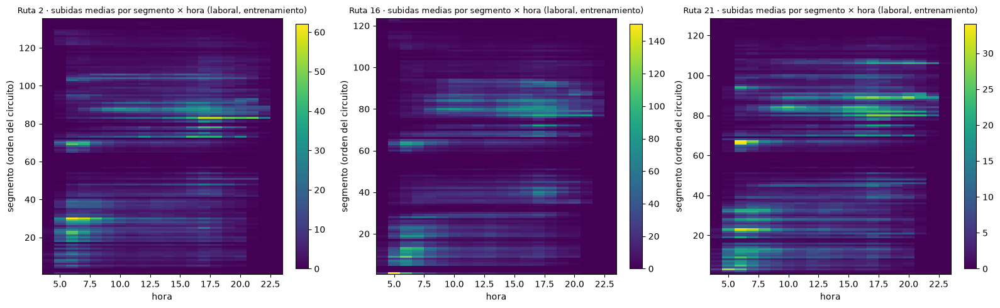

In [4]:
tabla('panel/resumen_ceros_bloque_e2c_1.csv')
p = pd.read_parquet(D / 'panel/panel_e2c.parquet', columns=['nodo', 'idruta', 'nro_segmento', 'hora', 'subidas', 'papel',
                                                            'calentamiento', 'tipo_dia'])
print(f'{len(p):,} filas · {p.nodo.nunique()} nodos · duplicados nodo×t: 0 (prueba de tests_e2c_1.py)')
x = p[(p.papel == 'entrenamiento') & ~p.calentamiento & (p.tipo_dia == 'laboral')]
m = x.groupby(['idruta', 'nro_segmento', 'hora']).subidas.mean().unstack('hora')
fig_, axs = plt.subplots(1, 3, figsize=(16, 5), sharey=False)
for ax, r in zip(axs, (2, 16, 21)):
    im = ax.imshow(m.loc[r].to_numpy(), aspect='auto', cmap='viridis', origin='lower',
                   extent=[m.columns.min() - .5, m.columns.max() + .5, 0.5, m.loc[r].shape[0] + .5])
    ax.set_title(f'Ruta {r} · subidas medias por segmento × hora (laboral, entrenamiento)', fontsize=9)
    ax.set_xlabel('hora'); ax.set_ylabel('segmento (orden del circuito)')
    plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()

## e2c.1.6 · Exposición planeada frente a realizada · conservación frente a `numeropasajeros`

In [5]:
tabla('panel/resumen_exposicion_franja_e2c_1.csv')
tabla('panel/resumen_relacion_numeropasajeros_e2c_1.csv')

,franja,expos_planeada,expos_planeada_v0,expos_realizada,dif_pct_v1
0,madrugada,750699,750699,529333,41.8
1,pico_am,3148618,3369193,2234904,40.9
2,valle_am,6832362,6611787,5309031,28.7
3,valle_pm,7626898,7626898,6302370,21.0
4,pico_pm,2820563,2930217,2466045,14.4
5,noche,4518919,4409265,3845836,17.5


,idruta,tipo_dia,viajes,subidas_lecturas,numeropasajeros_raw,razon
0,2,domingo_festivo,7003,412513.0,411814,1.0017
1,2,laboral,34846,2937212.0,2933329,1.0013
2,2,sabado,6932,503778.0,503170,1.0012
3,16,domingo_festivo,12353,790177.0,788440,1.0022
4,16,laboral,68829,6203115.0,6193205,1.0016
5,16,sabado,13258,1060761.0,1059280,1.0014
6,21,domingo_festivo,4123,265072.0,263837,1.0047
7,21,laboral,22234,1968779.0,1961541,1.0037
8,21,sabado,4535,338188.0,336719,1.0044


,idruta,tipo_dia,viajes,subidas_lecturas,numeropasajeros_raw,razon
0,2,domingo_festivo,7003,412513.0,411814,1.0017
1,2,laboral,34846,2937212.0,2933329,1.0013
2,2,sabado,6932,503778.0,503170,1.0012
3,16,domingo_festivo,12353,790177.0,788440,1.0022
4,16,laboral,68829,6203115.0,6193205,1.0016
5,16,sabado,13258,1060761.0,1059280,1.0014
6,21,domingo_festivo,4123,265072.0,263837,1.0047
7,21,laboral,22234,1968779.0,1961541,1.0037
8,21,sabado,4535,338188.0,336719,1.0044


## Pruebas y checks

In [6]:
tabla('panel/tests_e2c_1_oficial.csv')
checks(1)

,prueba,resultado,detalle
0,"a · malla completa N × T, sin duplicados",PASS,"397 días · 3,064,840 filas (1 h) · 12,259,360 (15 min)"
1,b · limpieza igual con puertas y bloqueos en 0,PASS,"101,000 lecturas idénticas en carga y banderas"
2,c · ubicación = M13 (código y resultado de la 13.1),PASS,"160,928 lecturas del 2025-02-15 idénticas a la 13.1"
3,d · conservación de subidas (diferencia 0),PASS,"Σ = 15,564,191 en 397 días"
4,e · ningún 0 es un dato faltante; tipo_cero coherente,PASS,NaN 1 h 9.73 %
5,f · extracción solo por idprogramacion = ANY(:ids),PASS,todas las consultas a conteo_pasajeros_destino filtran por ANY(:ids)
6,g · sin credenciales en código ni salidas,PASS,8 archivos revisados
7,h · corrección de la salida de la terminal,PASS,"2 viajes, 86 lecturas; avanzan 100 %"
8,i · 15 min suma igual que 1 h,PASS,"15,564,191 subidas en ambas resoluciones"


,check,descripcion,estado,detalle
0,C01,Pruebas tests_e2c_1.py --oficial,PASS,9/9 PASS
1,C02,Todos los días del plan están en el panel,PASS,397 de 397 días
2,C03,Malla completa N × T sin duplicados (1 h y 15 min),PASS,"3,064,840 y 12,259,360 filas"
3,C04,Conservación: Σ panel = Σ lecturas válidas ubicadas en la malla,PASS,diferencia máxima 0
4,C05,Ningún 0 corresponde a un viaje inválido o sin lecturas,PASS,NaN 9.73 % de las celdas (1 h)
5,C06,Índice por idprogramacion vigente antes de extraer,PASS,idx_conteo_pasajeros_destino_idprog
6,C07,Prueba de un día: volumen dentro de ±50 % de lo estimado,PASS,"{""dia"": ""2024-10-15"", ""viajes"": 495, ""lecturas"": 168729, ""lecturas_esperadas"": 159291,..."
7,C08,Latencia de las lecturas (decide el nowcast),INFO,"{""hora"": ""2026-11-18T00:06:08"", ""track_commit_timestamp"": ""off"", ""nota"": ""Sin marca de..."
8,C09,Extracción congelada con hash y solo por ANY(:ids),PASS,"154,590 viajes en 297 días, hash 3a0dad3854c1…"
9,C10,Días reutilizados del M15 completos y con hash,PASS,"91 días · 12,855,923 lecturas"


{'PASS': 12, 'INFO': 4}


**Conclusión e2c.1 · Hay un panel Y ∈ ℝ^{386 × 7.940 h} confiable: 397 días, 15.564.191 subidas que se conservan exactas, con 29,3 % de ceros entre las celdas expuestas y 9,7 % de celdas sin dato (NaN), que nunca se rellenan con 0.**
- Cifra: 3.064.840 filas a 1 h (386 nodos × 397 días × 20 h) y 12.259.360 a 15 min. 196.173 viajes válidos de 201.753 salidas del plan (2,29 % sin lecturas, 0,47 % inválidos).
- Lectura: a 1 h, el 51,6 % de las celdas tiene subidas, el 21,4 % es cero observado (pasó un bus y nadie subió), el 17,4 % es cero estructural (no pasó ningún bus) y el 9,7 % es NaN. Varianza / media en las celdas expuestas: 18,1. La suma de las lecturas da 1,002 × `numeropasajeros_raw` (exacta en el 87,3 % de los viajes). El 7,09 % de las subidas viene de salidas fuera de la maestra.
- Límite: el NaN sube en el holdout (11,6–12,4 % frente a 6,7–10,1 % en el entrenamiento) porque 7 días de 2025 no tienen ninguna lectura de sensor (último día de cada mes: 28-feb, 31-mar, 31-may, 30-jun, 31-ago, 31-oct y 30-nov; confirma el pendiente B.3 de la 1.1). La exposición planeada sobrestima a la realizada (razón 1,24; +41 % en la madrugada y en la punta de la mañana): queda para la ablación de e2c.4.

<a id="s2"></a>

---

# 2 · EDA del reto: la demanda a escala nodo × hora

Todo el EDA usa **solo los bloques de entrenamiento** (T1–T5, 2023–2024, 189 días). El holdout 2025 no se mira.

| Hallazgo | Cifra | Qué decide |
|---|---|---|
| Un tercio de los ceros no es demanda baja: es que no pasó bus | 17,35 % de las celdas son cero de oferta; en la madrugada del domingo, 83,3 % | La oferta planeada (`expos_planeada`) entra como feature; un cero sin bus no se trata como cero de demanda |
| La varianza es casi proporcional a la media | p̂ de Tweedie = **1,119** (IC95 1,115–1,123; R² 0,917; 19.697 estratos); varianza/media mediana 1,86 | Cuasi-Poisson. La métrica fija p = 1,12; en la validación Poisson le gana a la mejor Tweedie: 1,505 frente a 1,539 (−2,2 %) |
| El día y la semana mandan | Laboral 5,82 subidas por nodo y hora; sábado 0,847 del laboral; domingo 0,508; festivo 0,395 | Hora (seno y coseno), día de la semana y tipo de día como features |
| Carnaval no es un domingo cualquiera | 8 días de Carnaval en 2023–2024: nivel de domingo (0,505 del laboral; domingo 0,508), pero con un pico a las 7 h que el domingo no tiene | Indicadora `es_carnaval` aparte del festivo. Solo 8 días: es el corte más débil del modelo (sección 4) |
| El receso escolar cambia el reparto de la mañana | Variación total entre clases y receso en la punta: 0,072 / 0,076 / 0,075 frente a un P95 nulo de 0,058 / 0,066 / 0,065 (p = 0,001); el nivel baja 6,7–12,7 % | Indicadora `receso` (la misma que reemplazó a `tendencia_meses` en el e1c) |
| La demanda tiene dependencia espacial | I de Moran = **0,193** (p = 0,001, z = 7,8), significativo en **18/18** franjas × tipo de día (0,081 a 0,336); se pierde a 1 km | Grafo KNN con k = 8 (el menor k conexo; k = 2 parte la red en 41 componentes) |
| El ciclo diario y el semanal dominan el tiempo | ACF mediana entre nodos: 0,530 a 24 h, 0,563 a 168 h, 0,538 a 336 h; a 1 h es 0,475, pero no está disponible a las 04:00 | Rezagos de 24, 48, 168 y 336 h y medias a la misma hora; t − 1 h solo en el oráculo |
| El vecindario aporta algo propio, pero poco | ρ(y, lag espacial a 24 h) = 0,534; controlando por el rezago propio, la parcial es **0,152** (0,180 a 168 h) | Lag espacial (A_norm·Y) con los mismos rezagos; se espera una ganancia chica |

Las tablas y figuras que siguen se recalculan aquí desde las salidas guardadas del e2c.2 y desde el panel.


In [3]:
# 1) Ceros y relación media-varianza a escala nodo × hora (e2c.2.5, solo entrenamiento)
c2 = json.loads((E2C / 'eda/cifras_e2c_2.json').read_text(encoding='utf-8'))
fam = c2['familia']
print(f"Varianza/media dentro de los estratos nodo × hora × tipo de día: mediana {fam['D_estratos_mediana']} "
      f"(P90 {fam['D_estratos_p90']}); {fam['pct_estratos_D_mayor_1']:.0f} % de los estratos con D > 1")
display(pd.read_csv(E2C / 'eda/p_tweedie_e2c_2.csv').set_index('variante'))
z = pd.read_csv(E2C / 'eda/ceros_franja_tipo_e2c_2.csv')
orden_f = ['madrugada', 'pico_am', 'valle_am', 'valle_pm', 'pico_pm', 'noche']
display(z.pivot(index='franja', columns='tipo_dia', values='estructural').loc[orden_f]
        .add_suffix(' · % cero sin bus').join(
        z.pivot(index='franja', columns='tipo_dia', values='observado').loc[orden_f].add_suffix(' · % cero con bus')))

# 2) Qué familia de pérdida ganó en la validación (e2c.4.3, P1–P4; métrica fija: devianza Tweedie p = 1,12)
f4 = pd.read_csv(E2C / 'modelo/familia_e2c_4.csv')
t = f4.pivot(index='familia', columns='pliegue', values='dev')
t['media P1–P4'] = t.mean(axis=1)
t['vs Poisson (%)'] = 100 * (t['media P1–P4'] / t.loc['poisson', 'media P1–P4'] - 1)
display(t.sort_values('media P1–P4').round(3))

Varianza/media dentro de los estratos nodo × hora × tipo de día: mediana 1.86 (P90 4.75); 90 % de los estratos con D > 1


,p,ic95,r2,estratos,phi_mediana,p_domingo_festivo,p_laboral,p_sabado
variante,,,,,,,,
todas las celdas con dato,1.119,"[1.115, 1.123]",0.917,19697,1.932,1.148,1.107,1.122
solo celdas expuestas,1.131,"[1.126, 1.136]",0.912,19000,1.800,1.168,1.121,1.125


tipo_dia,domingo_festivo · % cero sin bus,laboral · % cero sin bus,sabado · % cero sin bus,domingo_festivo · % cero con bus,laboral · % cero con bus,sabado · % cero con bus
franja,,,,,,
madrugada,83.34,56.99,56.08,6.02,15.89,18.22
pico_am,20.44,5.76,5.19,27.38,23.90,26.05
valle_am,5.98,5.39,5.24,31.51,23.00,23.83
valle_pm,6.50,5.38,5.37,28.88,21.49,21.30
pico_pm,7.36,5.92,5.42,25.73,19.12,23.29
noche,45.33,32.44,33.70,25.33,28.90,29.55


pliegue,P1,P2,P3,P4,media P1–P4,vs Poisson (%)
familia,,,,,,
poisson,1.354,1.387,1.737,1.540,1.505,0.000
tweedie_1.10,1.358,1.393,1.851,1.555,1.539,2.298
tweedie_1.15,1.363,1.403,1.875,1.548,1.547,2.823
tweedie_1.20,1.355,1.423,1.940,1.548,1.566,4.098
tweedie_1.30,1.362,1.423,2.047,1.559,1.598,6.172


,dias,subidas_medias_por_celda,frente al laboral
tipo_dia_cal,,,
laboral,124,5.824,1.000
sabado,25,4.932,0.847
domingo,24,2.959,0.508
festivo,8,2.302,0.395
carnaval,8,2.941,0.505


Días de Carnaval en el entrenamiento: ['2023-02-18', '2023-02-19', '2023-02-20', '2023-02-21', '2024-02-10', '2024-02-11', '2024-02-12', '2024-02-13']


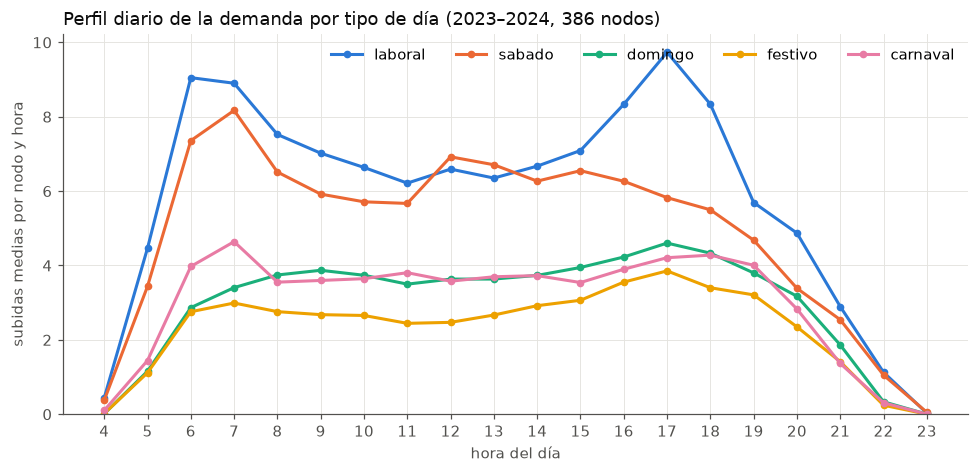

In [4]:
# 3) Perfiles hora × tipo de día y calendario (festivos y Carnaval), solo entrenamiento 2023–2024
orden_t = ['laboral', 'sabado', 'domingo', 'festivo', 'carnaval']
perfil = ent.groupby(['tipo_dia_cal', 'hora']).subidas.mean().unstack(0)[orden_t]
cal = ent.groupby('tipo_dia_cal').agg(dias=('dia', 'nunique'), subidas_medias_por_celda=('subidas', 'mean'))
cal['frente al laboral'] = cal.subidas_medias_por_celda / cal.loc['laboral', 'subidas_medias_por_celda']
display(cal.loc[orden_t].round(3))
print('Días de Carnaval en el entrenamiento:', sorted(ent[ent.tipo_dia_cal == 'carnaval'].dia.unique().tolist()))

fig, ax = plt.subplots(figsize=(9, 4.4))
for k, tdia in enumerate(orden_t):
    ax.plot(perfil.index, perfil[tdia], color=CATEG[k], label=tdia, marker='o', ms=4)
ax.set_xticks(range(4, 24)); ax.set_xlabel('hora del día'); ax.set_ylabel('subidas medias por nodo y hora')
ax.set_title('Perfil diario de la demanda por tipo de día (2023–2024, 386 nodos)', loc='left')
ax.legend(ncol=5, loc='upper right'); ax.set_ylim(0, None)
plt.tight_layout(); plt.show()

In [5]:
# 4) Dependencia espacial, temporal y espacio-temporal (e2c.2.2–e2c.2.4)
mo = pd.read_csv(E2C / 'eda/moran_franja_tipo_e2c_2.csv')
mi = mo.pivot(index='franja', columns='tipo_dia', values='I').loc[orden_f]
print(f"I de Moran global (demanda media por nodo, KNN k = 8): {c2['moran']['global']['demanda_media']['I']:.3f} "
      f"(p = {c2['moran']['global']['demanda_media']['p_perm']}, z = {c2['moran']['global']['demanda_media']['z']:.1f}); "
      f"significativo en {c2['moran']['franja_tipo_significativas']}/{c2['moran']['franja_tipo_total']} franjas × tipo de día")
display(mi.round(3).style.format('{:.3f}').set_caption('I de Moran por franja × tipo de día (todas con p ≤ 0,003)'))
a = pd.read_csv(E2C / 'eda/acf_pacf_resumen_e2c_2.csv')
display(a[a.medida == 'ACF'].pivot(index='rezago_h', columns='serie', values='mediana').round(3)
        .rename(columns=lambda c: f'ACF mediana entre nodos · {c}'))
et = pd.DataFrame(c2['espacio_tiempo'])
et = et[(et.serie == 'cruda') & (et.matriz == 'knn_k8') & et.L_h.isin([1, 24, 48, 168, 336])]
display(et[['L_h', 'rho_propio', 'rho_espacial', 'rho_espacial_parcial']].set_index('L_h')
        .rename(columns={'rho_propio': 'ρ(y, y_{t−L})', 'rho_espacial': 'ρ(y, (A·Y)_{t−L})',
                         'rho_espacial_parcial': 'parcial del lag espacial | rezago propio'}))

I de Moran global (demanda media por nodo, KNN k = 8): 0.193 (p = 0.001, z = 7.8); significativo en 18/18 franjas × tipo de día


tipo_dia,domingo_festivo,laboral,sabado
franja,,,
madrugada,0.089,0.095,0.081
pico_am,0.094,0.127,0.139
valle_am,0.121,0.211,0.150
valle_pm,0.222,0.290,0.252
pico_pm,0.214,0.336,0.289
noche,0.228,0.313,0.259


serie,ACF mediana entre nodos · cruda,ACF mediana entre nodos · desestacionalizada
rezago_h,,
1,0.475,0.101
2,0.274,0.088
3,0.158,0.066
24,0.530,0.138
48,0.461,0.116
168,0.563,0.113
336,0.538,0.092


,"ρ(y, y_{t−L})","ρ(y, (A·Y)_{t−L})",parcial del lag espacial | rezago propio
L_h,,,
1,0.748,0.483,0.145
24,0.798,0.534,0.152
48,0.779,0.519,0.137
168,0.811,0.551,0.180
336,0.804,0.546,0.173


**La evidencia de esta sección** es el notebook del e2c.2 (EDA espacio-temporal): selección del grafo, Moran global y local (LISA), ACF y PACF por nodo, correlación espacio-temporal, familia de la distribución, mapas de calor y la prueba de la hipótesis de la 13.4. Sigue intacto.

<a id="e2c-3"></a>

### 2.1 · Evidencia &middot; e2c.2 · EDA espacio-temporal a la escala del pronóstico

<sub>Notebook original: `subfase_e2c_2_eda.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# Subfase e2c.2 · EDA espacio-temporal a la escala del pronóstico (nodo × hora)

Corrección del Entregable 2. Responde a la observación «faltan el EDA … del reto». Datos: el panel de e2c.1
(`datos_e2c/panel/panel_e2c.parquet`), **solo los bloques de entrenamiento T1–T5** (2023-02-04 a
2024-12-29, 189 días, 1.459.080 celdas nodo × hora). El holdout (H1–H4, 2025) no se lee.

Todo se calcula en `eda_e2c_2.py` (offline, semilla 42); este notebook muestra las salidas y sus conclusiones.
Pruebas: `tests_e2c_2.py` (6/6). Regla congelada: `datos_e2c/reglas/regla_grafo_e2c.json`.

In [1]:
import json, pandas as pd
from pathlib import Path
from IPython.display import Image, display
EDA = Path('datos_e2c/eda'); FIG = EDA / 'figuras'
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)

## e2c.2.1 · Grafo espacial y matriz de adyacencia

In [2]:
display(pd.read_csv(EDA / 'seleccion_k_e2c_2.csv').head(12))
display(pd.read_csv(EDA / 'grafos_e2c_2.csv'))

,k,componentes,vecino_k_mediana_m,vecino_k_p95_m,empates
0,2,41,125.0,419.2,0
1,3,17,175.1,474.0,0
2,4,10,216.3,535.8,0
3,5,7,257.6,611.3,0
4,6,2,332.6,832.6,0
5,7,2,378.5,861.8,0
6,8,1,410.3,916.9,0
7,9,1,443.9,979.2,0
8,10,1,480.7,1073.2,0
9,11,1,504.9,1145.7,0


,matriz,componentes,aislados,grado_min,grado_mediana,grado_max,pct_mutuas,arista_mediana_m,aristas_mayor_1km,aristas,aristas_otra_ruta,aristas_misma_ruta_sentido_contrario,aristas_misma_ruta_contiguo
0,knn_k2,41,0,2,2.0,2,78.0,80.2,0,772,440,258,74
1,knn_k8,1,0,8,8.0,8,85.0,267.4,25,3088,1783,799,506
2,kernel,1,0,3,18.0,41,100.0,460.7,0,7266,4638,1484,1144


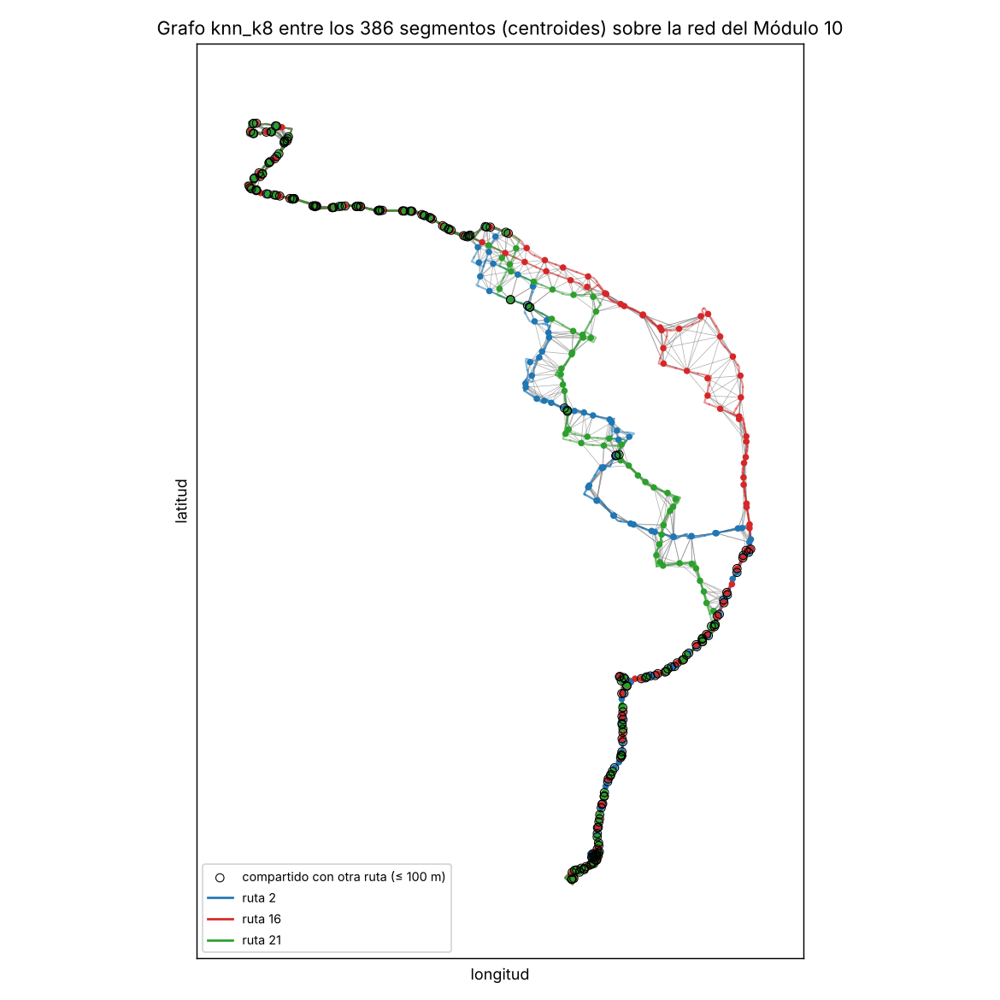

In [3]:
display(Image(FIG / 'grafo_knn_k8.png', width=650))

**Conclusión 1 · El grafo elegido es KNN con k = 8: el menor k conexo, con vecino 8.º mediano de 410,3 m y sin empates (regla de la 4.3).**
- k = 2 (referencia del curso) parte la red en **41 componentes** (sin aislados): no sirve como grafo.
- k = 8: 3.088 aristas, 85,0 % mutuas, arista mediana 267,4 m, 25 aristas > 1 km.
  Tipos: **1.783 con otra ruta (57,7 %)**, 799 con el sentido contrario de la misma ruta y 506 contiguas.
- Decisión: los vecinos pueden ser de otra ruta y del sentido contrario, porque el 59 % de los segmentos comparte vía con otra ruta (e2c.0). A_norm = D⁻¹A: filas que suman 1 y diagonal 0 (prueba a).
- Sensibilidad: kernel gaussiano con σ = 410,3 m (el vecino 8.º mediano) y corte en 2σ: grado mediano 18 (3 a 41), conexo.
- Límite: el nodo se representa por su centroide; dos sentidos de una misma vía quedan a pocos metros aunque no compartan pasajeros.

## e2c.2.2 · Autocorrelación espacial

In [4]:
display(pd.read_csv(EDA / 'moran_franja_tipo_e2c_2.csv')[['franja','tipo_dia','I','p_perm','z']].round(3))
display(pd.read_csv(EDA / 'moran_sensibilidad_k_e2c_2.csv')[['matriz','I','p_perm']].round(3).T)
display(pd.read_csv(EDA / 'correlograma_distancia_e2c_2.csv')[['desde_m','hasta_m','pares','I','p_perm']].round(3))

,franja,tipo_dia,I,p_perm,z
0,madrugada,domingo_festivo,0.089,0.002,3.974
1,pico_am,domingo_festivo,0.094,0.001,3.986
2,valle_am,domingo_festivo,0.121,0.001,5.132
3,valle_pm,domingo_festivo,0.222,0.001,9.181
4,pico_pm,domingo_festivo,0.214,0.001,8.963
5,noche,domingo_festivo,0.228,0.001,9.938
6,madrugada,laboral,0.095,0.001,4.332
7,pico_am,laboral,0.127,0.001,5.399
8,valle_am,laboral,0.211,0.001,8.564
9,valle_pm,laboral,0.290,0.001,12.111


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
matriz,knn_k2,knn_k3,knn_k4,knn_k5,knn_k6,knn_k7,knn_k8,knn_k9,knn_k10,knn_k11,knn_k12,knn_k13,knn_k14,knn_k15,knn_k16,knn_k17,knn_k18,knn_k19,knn_k20,kernel
I,0.308,0.255,0.246,0.23,0.207,0.194,0.193,0.186,0.182,0.186,0.186,0.189,0.182,0.172,0.165,0.159,0.155,0.153,0.144,0.226
p_perm,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005,0.005


,desde_m,hasta_m,pares,I,p_perm
0,0,250,875,0.228,0.005
1,250,500,1185,0.234,0.005
2,500,750,1240,0.197,0.005
3,750,1000,1386,0.134,0.005
4,1000,1250,1232,0.039,0.125
5,1250,1500,1469,0.092,0.005
6,1500,1750,1389,0.032,0.240
7,1750,2000,1432,0.067,0.010
8,2000,2250,1420,-0.008,0.835
9,2250,2500,1487,0.034,0.195


**Conclusión 2 · La demanda tiene autocorrelación espacial positiva y significativa: I de Moran = 0,193 (p = 0,001, z = 7,8, 999 permutaciones), y aparece en las 18 combinaciones de franja × tipo de día.**
- Con subidas por bus (la demanda dividida por la exposición) el I es casi igual (0,190): la dependencia no es solo un efecto de dónde pasan más buses.
- Por franja: I va de 0,081 (madrugada) a 0,336 (punta de la tarde laboral). La estructura espacial es más fuerte en la tarde que en la mañana.
- Sensibilidad: I baja de 0,308 con k = 2 a 0,14 con k = 20; kernel 0,226. **El máximo de I (k = 2) no es el criterio**: con vecindades más chicas I sube por construcción, y k = 2 deja 41 componentes (4.3).
- Correlograma: I significativo hasta 1 km (la primera banda no significativa empieza en 1000 m). Esa es la escala de la dependencia, y es compatible con el vecino 8.º mediano de 410 m.
- LISA (k = 8, p < 0,05): 37 nodos alto-alto, 55 bajo-bajo y 28 atípicos.
- Comparación: en el E1, con celdas de 250 m y una muestra de lecturas, I = 0,18. Aquí sale con días completos y por segmento.

## e2c.2.3 · Autocorrelación temporal

,rezago_h,mediana,p25,p75,serie,medida
0,1,0.475,0.274,0.607,cruda,ACF
1,2,0.274,0.126,0.409,cruda,ACF
2,3,0.158,0.052,0.291,cruda,ACF
3,24,0.530,0.342,0.663,cruda,ACF
4,48,0.461,0.286,0.575,cruda,ACF
5,168,0.563,0.343,0.710,cruda,ACF
6,336,0.538,0.326,0.696,cruda,ACF
7,1,0.101,0.042,0.302,desestacionalizada,ACF
8,2,0.088,0.036,0.219,desestacionalizada,ACF
9,3,0.066,0.024,0.189,desestacionalizada,ACF


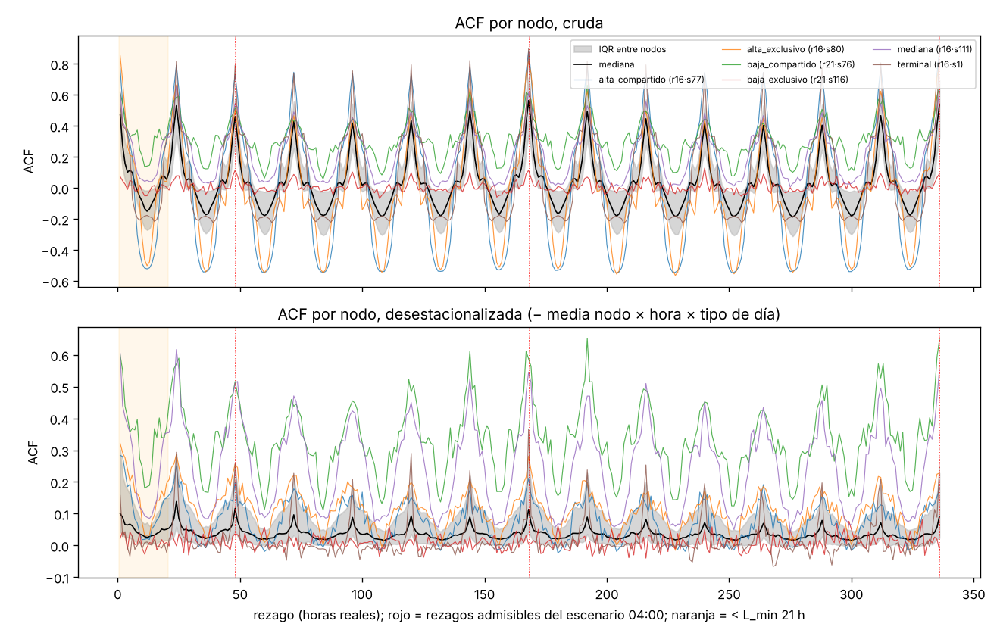

In [5]:
display(pd.read_csv(EDA / 'acf_pacf_resumen_e2c_2.csv').round(3))
display(Image(FIG / 'acf_nodos.png', width=900))

**Conclusión 3 · El ciclo diario y el semanal dominan: la mediana entre nodos de la ACF es 0,530 a 24 h, 0,563 a 168 h y 0,538 a 336 h. Todos esos rezagos son admisibles a las 04:00.**
- La persistencia de corto plazo es alta, pero no está disponible: ACF a 1 h 0,475, PACF a 1 h 0,473. **t−1 no es admisible** en ningún escenario desplegable (oráculo). t−2 y t−3 (ACF 0,274 y 0,158) solo servirían al nowcast, que e2c.1 dejó como **oráculo** porque la base no permite medir la latencia.
- PACF cruda: 24 h 0,213, 48 h 0,106, 168 h 0,126. Cada ciclo aporta algo propio.
- Al quitar la media nodo × hora × tipo de día queda poca persistencia: ACF 0,138 a 24 h y 0,113 a 168 h. El grueso es ciclo determinístico (perfil por nodo, hora y tipo de día); los rezagos 24/168 h aportan el nivel reciente de cada nodo.
- La heterogeneidad entre nodos es grande (IQR de la ACF a 24 h: 0,342–0,663). En los nodos de baja demanda la ACF es casi ruido.
- Límite: la ACF se calcula con pares válidos dentro de cada bloque (sin cruzar bloques) y la PACF sale de esa ACF por Durbin-Levinson.

## e2c.2.4 · Dependencia espacio-temporal

In [6]:
c = pd.read_csv(EDA / 'correlacion_espacio_tiempo_e2c_2.csv'); display(c.round(3))

,L_h,pares,rho_propio,rho_espacial,rho_propio_vs_espacial,rho_espacial_parcial,matriz,serie
0,0,1341917,NaN,0.573,NaN,NaN,knn_k8,cruda
1,1,1171833,0.748,0.483,0.537,0.145,knn_k8,cruda
2,2,1102059,0.652,0.373,0.511,0.062,knn_k8,cruda
3,3,1040634,0.586,0.304,0.498,0.017,knn_k8,cruda
4,24,1207528,0.798,0.534,0.576,0.152,knn_k8,cruda
5,48,1174750,0.779,0.519,0.576,0.137,knn_k8,cruda
6,168,1011185,0.811,0.551,0.573,0.180,knn_k8,cruda
7,336,781855,0.804,0.546,0.574,0.173,knn_k8,cruda
8,0,1341917,NaN,0.190,NaN,NaN,knn_k8,desestacionalizada
9,1,1171833,0.206,0.146,0.192,0.111,knn_k8,desestacionalizada


**Conclusión 4 · El lag espacial tiene señal propia: con L = 24 h, ρ(y, (A_norm Y)_{t−24}) = 0,534. Controlando por el rezago propio, la correlación parcial es 0,152 (0,180 a 168 h).**
- El rezago propio correlaciona más (0,798 a 24 h; 0,811 a 168 h). El espacial correlaciona 0,576 con el propio: **no es redundante**. A diferencia del lag entre 3 rutas de la 6.2, aquí cada nodo tiene sus propios vecinos.
- Sobre la serie desestacionalizada la señal parcial sigue presente: 0,089 a 24 h y 0,075 a 168 h.
- Es robusto a la matriz: con k = 2 y con el kernel las parciales van de 0,13 a 0,20 en los rezagos de 24 a 336 h.
- Del oráculo: el lag espacial a 1 h tiene parcial 0,145, pero no es desplegable.
- Límite: Spearman sobre una muestra de 400.000 pares por rezago (semilla 42). Es una evidencia marginal; su aporte en el modelo se mide con la ablación de e2c.4 (criterio C2).

## e2c.2.5 · Distribución, ceros y familia

,tipo_dia,franja,estructural,observado
0,domingo_festivo,madrugada,83.34,6.02
1,domingo_festivo,noche,45.33,25.33
2,domingo_festivo,pico_am,20.44,27.38
3,domingo_festivo,pico_pm,7.36,25.73
4,domingo_festivo,valle_am,5.98,31.51
5,domingo_festivo,valle_pm,6.50,28.88
6,laboral,madrugada,56.99,15.89
7,laboral,noche,32.44,28.90
8,laboral,pico_am,5.76,23.90
9,laboral,pico_pm,5.92,19.12


,variante,p,ic95,r2,estratos,phi_mediana,p_domingo_festivo,p_laboral,p_sabado
0,todas las celdas con dato,1.119,"[1.115, 1.123]",0.917,19697,1.932,1.148,1.107,1.122
1,solo celdas expuestas,1.131,"[1.126, 1.136]",0.912,19000,1.800,1.168,1.121,1.125


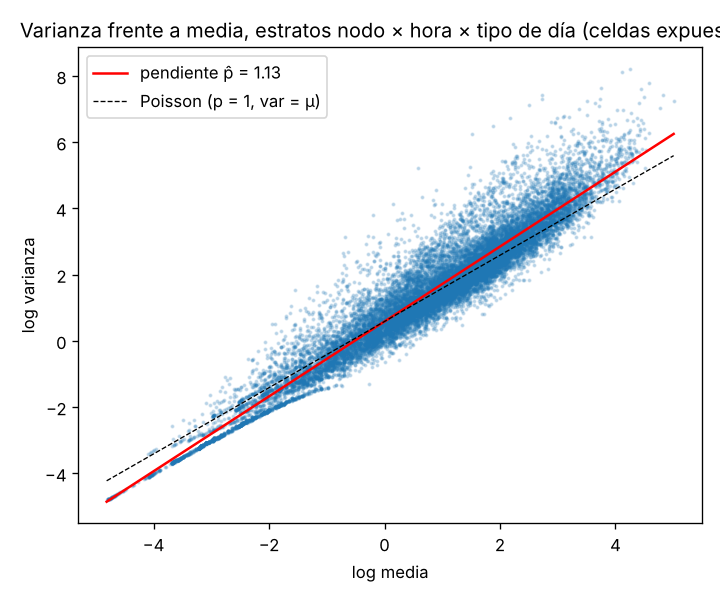

In [7]:
display(pd.read_csv(EDA / 'ceros_franja_tipo_e2c_2.csv'))
display(pd.read_csv(EDA / 'p_tweedie_e2c_2.csv'))
display(Image(FIG / 'p_tweedie.png', width=500))

**Conclusión 5 · A escala nodo × hora, p̂ de Tweedie = 1,119 (IC95 bootstrap 1,115–1,123; R² 0,917; 19.697 estratos nodo × hora × tipo de día). Queda entre la escala ruta × 15 min (0,97) y la escala por viaje (1,40).**
- Solo en las celdas expuestas: p̂ = 1,131. Por tipo de día: laboral 1,107, sábado 1,122, domingo/festivo 1,148.
- Sobredispersión: índice de dispersión mediano 1,86 (P90 4,75); el 90,0 % de los estratos tiene D > 1. Poisson queda corto.
- Ceros: 19,3 % estructurales (sin bus) y 23,8 % observados (con bus). En la madrugada lo estructural llega al 57 % (laboral) y al 83 % (domingo). En el valle es ~5 %.
- **Recomendación para e2c.4:** Tweedie con p ∈ [1,10; 1,20] (p de la métrica fijado antes de buscar, en e2c.4.3), y Poisson como línea base. La masa en cero sin bus se trata por la exposición: modelar las celdas con exposición planeada > 0, y predecir 0 donde no hay bus planeado. El 5,3 % de las celdas es cero estructural aunque tenga bus planeado: es la diferencia entre lo planeado y lo realizado de e2c.1.

## e2c.2.6 · Mapas de calor espacio-tiempo y la hipótesis de la 13.4

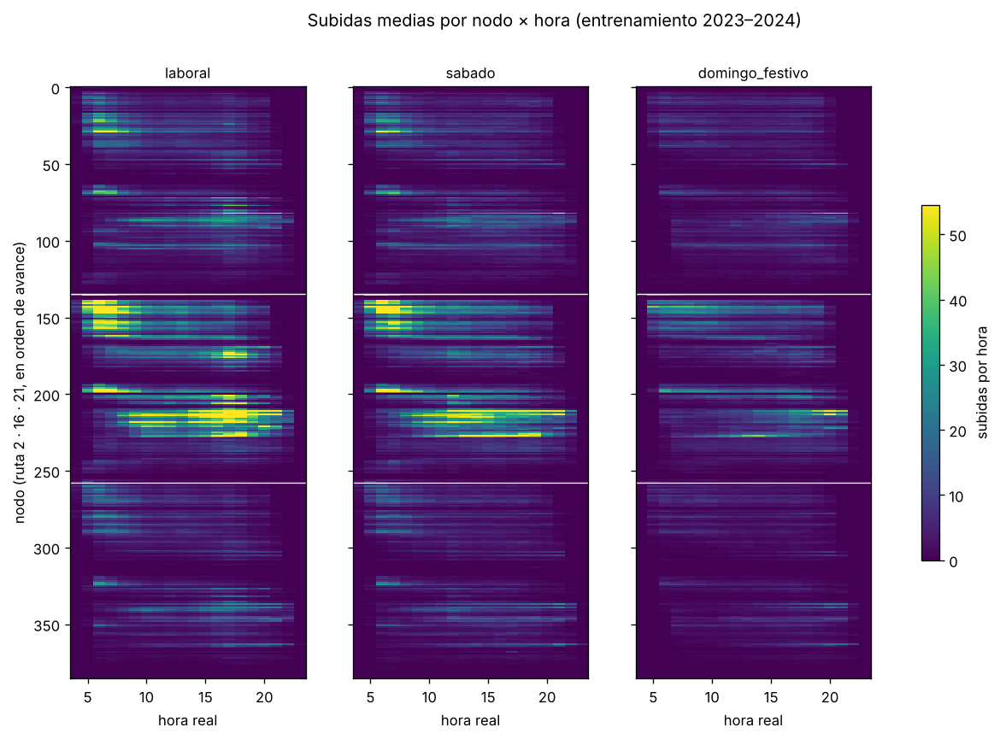

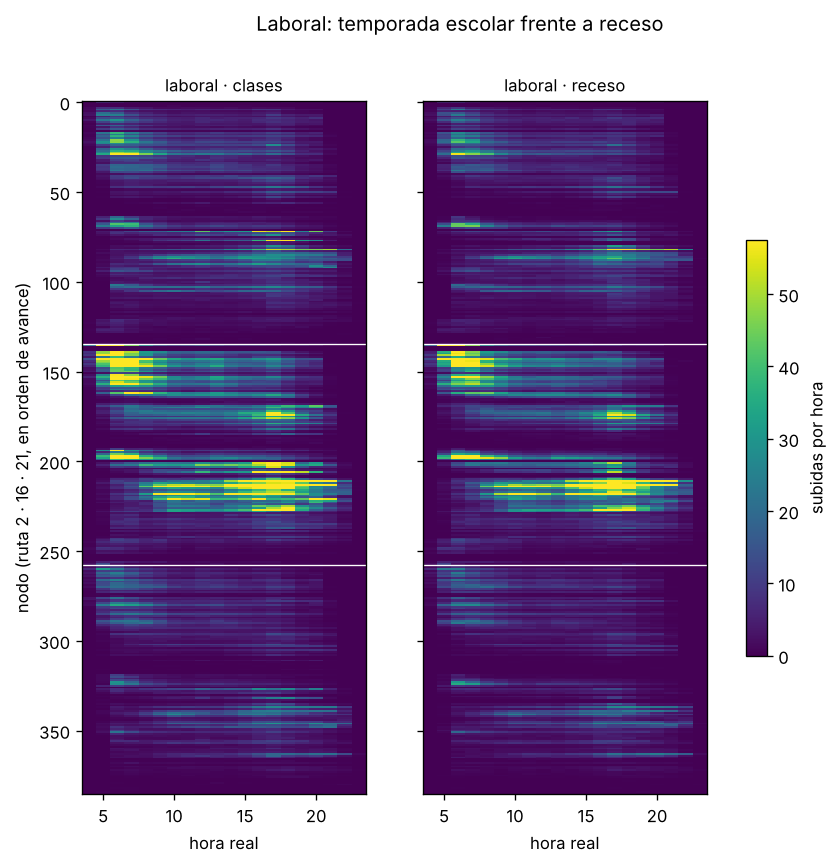

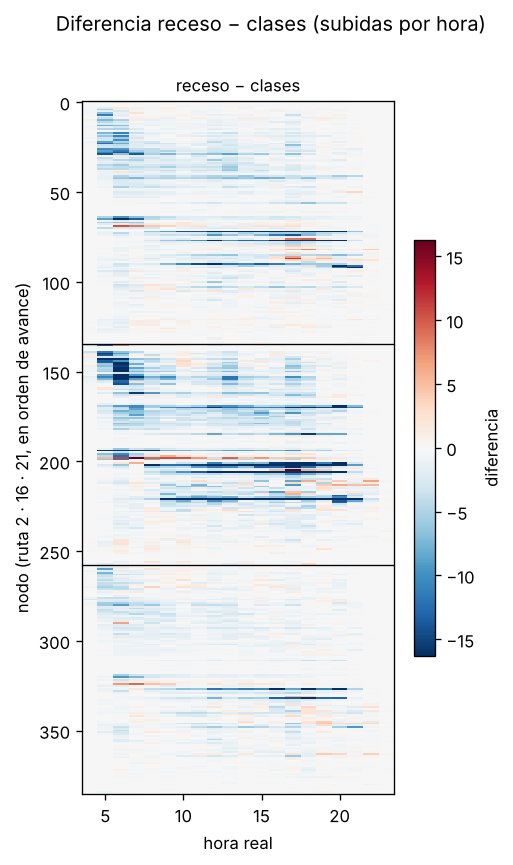

In [8]:
display(Image(FIG / 'heatmap_tipo_dia.png', width=900))
display(Image(FIG / 'heatmap_clases_receso.png', width=700))
display(Image(FIG / 'heatmap_diferencia_receso.png', width=420))

In [9]:
display(pd.read_csv(EDA / 'prueba_temporada_espacial_e2c_2.csv'))
t = pd.read_csv(EDA / 'distancia_reparto_13_1_e2c_2.csv'); display(t.pivot_table(index=['franja','dias'], columns='idruta', values='tv_vs_reparto_13_1').round(3))

,idruta,franja,dias_clases,dias_receso,tv_clases_vs_receso,tv_nulo_mediana,tv_nulo_p95,p_perm,subidas_dia_clases,subidas_dia_receso,cambio_nivel_pct
0,2,madrugada,73,51,0.0984,0.0741,0.0841,0.001,604.9,404.5,-33.1
1,16,madrugada,73,51,0.0805,0.0667,0.0846,0.097,1003.2,823.7,-17.9
2,21,madrugada,73,51,0.0908,0.0631,0.0750,0.003,372.7,284.6,-23.6
3,2,pico_am,73,51,0.0717,0.0523,0.0581,0.001,2154.9,1881.0,-12.7
4,16,pico_am,73,51,0.0761,0.0560,0.0663,0.001,2896.3,2701.5,-6.7
5,21,pico_am,73,51,0.0755,0.0569,0.0652,0.001,1242.3,1145.3,-7.8
6,2,valle_am,73,51,0.0853,0.0517,0.0591,0.001,2840.1,2409.8,-15.2
7,16,valle_am,73,51,0.0657,0.0461,0.0527,0.001,5265.1,4793.9,-8.9
8,21,valle_am,73,51,0.0732,0.0476,0.0534,0.001,1899.8,1748.9,-7.9
9,2,valle_pm,73,51,0.1049,0.0603,0.0701,0.001,3869.7,3022.8,-21.9


idruta                       2      16     21
franja    dias                               
madrugada clases          0.324  0.361  0.440
          receso          0.342  0.371  0.471
          todos_los_dias  0.327  0.373  0.454
noche     clases          0.254  0.200  0.207
          receso          0.240  0.251  0.221
          todos_los_dias  0.215  0.198  0.200
pico_am   clases          0.169  0.236  0.240
          receso          0.177  0.256  0.245
          todos_los_dias  0.166  0.241  0.239
pico_pm   clases          0.215  0.209  0.184
          receso          0.227  0.225  0.182
          todos_los_dias  0.197  0.189  0.165
valle_am  clases          0.123  0.130  0.148
          receso          0.138  0.147  0.168
          todos_los_dias  0.120  0.137  0.154
valle_pm  clases          0.107  0.119  0.117
          receso          0.126  0.137  0.133
          todos_los_dias  0.102  0.114  0.113

**Conclusión 6 · Se confirma la hipótesis de la 13.4: en la punta de la mañana laboral, la distribución espacial de las subidas cambia entre clases y receso en las 3 rutas (variación total 0,072 / 0,076 / 0,075 frente a un P95 nulo de 0,058 / 0,066 / 0,065; p = 0,001).**
- El nulo permuta la etiqueta receso **dentro de cada bloque**, así que no confunde temporada con bloque. 73 días laborales de clases y 51 de receso.
- Además del reparto cambia el nivel: en receso la punta de la mañana pierde 12,7 % / 6,7 % / 7,8 % de las subidas (rutas 2 / 16 / 21). El cambio espacial es significativo en casi todas las franjas, no solo en la mañana.
- **Pero el reparto fijo del simulador se aleja mucho más:** frente a `reparto_segmento_13_1.csv`, la variación total en la punta de la mañana (días de clases) es 0,169 / 0,235 / 0,240, 2–3 veces la diferencia por temporada. Parte viene de la corrección de la salida de la terminal (e2c.1) y parte de que la 13.1 calibró con una muestra de viajes.
- Lectura: un reparto por temporada ayudaría poco si el reparto base ya está desplazado. Pronosticar la distribución por nodo ataca las dos cosas a la vez.
- Límite: solo hay recesos de 2023–2024 dentro de los bloques (mitad de año, octubre, diciembre y el final del de inicio de año); no hay Semana Santa.

## e2c.2.7 · Síntesis para e2c.3

| Hallazgo | Evidencia | Recomendación para las features (e2c.3) |
|---|---|---|
| Hay dependencia espacial a ~1 km | I = 0,193 (p 0,001), 18/18 franjas × tipo; correlograma significativo hasta 1 km | **A_norm = KNN k = 8** (`regla_grafo_e2c.json`); kernel σ = 410 m y k = 2 como sensibilidad |
| El lag espacial no es redundante | parcial 0,152 (24 h), 0,180 (168 h); ρ con el propio 0,576 | (A_norm Y) en t−24, t−48, t−168 y t−336, más su media de la misma hora en 1–2 semanas |
| Los ciclos diario y semanal dominan | ACF 24 h 0,530, 168 h 0,563, 336 h 0,538 | Escenario 04:00: rezagos propios {24, 48, 168, 336} h; media de la misma hora en 1 y 2 semanas; ventanas ancladas en t − 21 h |
| t−1 es lo más informativo pero no es admisible | ACF 1 h 0,475; `track_commit_timestamp = off` | t−1, t−2, t−3 y el lag espacial a 1 h solo en el **oráculo**; nowcast = oráculo |
| El ciclo es determinístico por nodo | ACF desestacionalizada 24 h 0,138 | Perfil histórico nodo × hora × tipo de día (codificación del target por pliegue, sin fuga) |
| La temporada escolar cambia nivel y reparto | TV 0,072–0,076 (p 0,001); nivel −7 a −13 % en la mañana | Indicadora de receso (`receso`, como en el e1c), cruzada con franja; festivos y Carnaval aparte |
| Familia | p̂ = 1,119 [1,115; 1,123]; D mediano 1,86 | Tweedie p ∈ [1,10; 1,20]; Poisson solo como línea base |
| Ceros estructurales | 19,3 % (madrugada 57–83 %) | `log1p(exposición planeada)`; celdas con planeada 0 → ŷ = 0; offset como ablación (e2c.4.6) |
| Nodos y franjas problemáticos | baja demanda con ACF de ruido; madrugada; segmentos 2–16 de la ruta 2 casi sin lecturas | Reportar el error por tipo de nodo y franja; no forzar el ajuste en la madrugada |

Ninguna de estas recomendaciones usa datos de 2025.

<a id="s3"></a>

---

# 3 · Feature engineering

Una tabla de features por (nodo, hora), 1:1 con el panel: **3.064.840 filas** y 67 features en total (35 de la capa oficial, las de las capas de referencia y las de las ablaciones). Cada feature usa solo información disponible a la hora de emisión.

**Las tres capas:**
- **04:00 (35 features) — la oficial y desplegable.** Rezagos de 24 h o más, medias a la misma hora, ventanas del día anterior, lag espacial con KNN k = 8, calendario, atributos del nodo y la oferta planeada del día.
- **Nowcast (41) — desplegable como opción (actualizado el 20-nov-2026).** Agrega las subidas del nodo y de sus vecinos 2, 3 y 6 h antes. La base no guarda la hora de inserción (`track_commit_timestamp = off`), así que la latencia no se puede medir en ella. En el diseño se trató como referencia; la Persona 3 informó después que en la base de SOBUSA los datos del sensor se actualizan en vivo, y con eso el nowcast se puede usar. Queda como opción del plan de operación, apagada por defecto, porque su efecto en el despacho no se ha medido.
- **Oráculo (43) — referencia, no desplegable.** Agrega las subidas 1 h antes. Mide el techo: cuánto valdría tener datos en vivo perfectos.

En el holdout 2025, el nowcast baja la devianza 3,4 % y el oráculo 5,0 % frente al modelo de las 04:00. **Tener datos en vivo perfectos valdría como mucho un 5 %.** Las capas se definieron así desde el diseño (e2c.0) y no se reentrenó nada para esta versión.

**Controles de fuga:**
- auditoría independiente A1–A7 (como la 6.3): **7/7 PASS → certificado con reservas** (`auditoria_leakage_e2c.md`);
- ninguna variable de tendencia en el tiempo: la lección de `tendencia_meses` (Entregable 1) quedó incorporada. El nivel reciente del nodo entra con las ventanas del día y la semana anteriores;
- guarda de rango por variable: en 2025 solo 4 variables de dispersión de los rezagos quedan fuera del rango de entrenamiento, en el 0,097 % de las filas.

**Lo que no funcionó como se esperaba:** el lag espacial. En la validación, quitarlo empeora solo +0,16 % (en 2 de 4 pliegues): **no cumplió el criterio C2**. Se conservó por decisión expresa (PC2). En el holdout quitarlo sí empeora en los 4 bloques, pero poco: +1,6 %.

La tabla siguiente tiene, por feature: definición, ventana, hallazgo del EDA que la justifica (sección 2), capa, si es desplegable y su correlación de Spearman con y en el entrenamiento.


In [6]:
# Tabla del feature engineering: cada feature de las tres capas con su definición, su ventana,
# el hallazgo del EDA que la justifica y si es desplegable a las 04:00.
dic = pd.read_csv(E2C / 'features/diccionario_features_e2c.csv')
listas = json.loads((E2C / 'features/listas_features_e2c.json').read_text(encoding='utf-8'))
senal = pd.read_csv(E2C / 'features/senal_features_e2c.csv', index_col=0).rho_spearman

DEF = {
  'rezago_propio': ('subidas del mismo nodo L horas antes', 'ACF mediana 0,530 a 24 h, 0,563 a 168 h y 0,538 a 336 h (e2c.2.3)'),
  'media_misma_hora': ('media de las subidas del nodo a la misma hora en los días o semanas anteriores', 'el ciclo diario y el semanal dominan; promediar baja el ruido del día suelto (e2c.2.3)'),
  'ventana_anclada': ('media y desviación de las subidas del nodo en el día anterior o en los 7 días anteriores', 'nivel reciente del nodo sin variable de tendencia (lección de `tendencia_meses`, e1c)'),
  'lag_espacial': ('lo mismo sobre la media de los 8 vecinos más cercanos: (A_norm·Y) con KNN k = 8', 'I de Moran 0,193, 18/18 franjas × tipo; parcial 0,152 a 24 h y 0,180 a 168 h (e2c.2.2, e2c.2.4)'),
  'calendario': ('calendario del día objetivo, conocido de antemano', 'domingo y festivo ≈ mitad del laboral; Carnaval aparte; el receso cambia el reparto de la mañana (p = 0,001) (e2c.2.6)'),
  'nodo': ('atributos fijos del segmento', 'heterogeneidad espacial: ceros y nivel distintos por nodo; terminal y tramos compartidos (e2c.2.5)'),
  'oferta_planeada': ('pasos de bus planeados por el nodo en esa hora (plan del día)', '17,35 % de las celdas son cero porque no pasa bus: es oferta, no demanda (e2c.1.5, e2c.2.5)'),
}
capa = {}
for nombre in listas['capa_oraculo']:
    capa[nombre] = '04:00 (oficial)' if nombre in listas['capa_0400'] else ('nowcast (oráculo)' if nombre in listas['capa_nowcast'] else 'oráculo')
t = dic[dic.nombre.isin(capa)].copy()
t['capa'] = t.nombre.map(capa)
t['definición'] = t.familia.map(lambda f: DEF[f][0])
t['hallazgo del EDA que la justifica'] = t.familia.map(lambda f: DEF[f][1])
t['ventana / ancla'] = t.ancla
t['desplegable'] = t.desplegable.map({True: 'sí', False: 'no'})
t['ρ Spearman con y'] = t.nombre.map(senal).round(3)
t = t[['nombre', 'familia', 'definición', 'ventana / ancla', 'hallazgo del EDA que la justifica', 'capa', 'desplegable', 'ρ Spearman con y']]
orden_capa = {'04:00 (oficial)': 0, 'nowcast (oráculo)': 1, 'oráculo': 2}
t = t.sort_values(['capa', 'familia'], key=lambda s: s.map(orden_capa) if s.name == 'capa' else s).reset_index(drop=True)
t.index = t.index + 1
display(t)
print('Features por capa:', {k: len(listas[k]) for k in ('capa_0400', 'capa_nowcast', 'capa_oraculo')})

,nombre,familia,definición,ventana / ancla,hallazgo del EDA que la justifica,capa,desplegable,ρ Spearman con y
1,hora,calendario,"calendario del día objetivo, conocido de antemano",fecha objetivo (conocida ex ante),"domingo y festivo ≈ mitad del laboral; Carnaval aparte; el receso cambia el reparto de la mañana (p = 0,001) (e2c.2.6)",04:00 (oficial),sí,-0.085
2,hora_sin,calendario,"calendario del día objetivo, conocido de antemano",fecha objetivo (conocida ex ante),"domingo y festivo ≈ mitad del laboral; Carnaval aparte; el receso cambia el reparto de la mañana (p = 0,001) (e2c.2.6)",04:00 (oficial),sí,-0.070
3,hora_cos,calendario,"calendario del día objetivo, conocido de antemano",fecha objetivo (conocida ex ante),"domingo y festivo ≈ mitad del laboral; Carnaval aparte; el receso cambia el reparto de la mañana (p = 0,001) (e2c.2.6)",04:00 (oficial),sí,-0.330
4,dia_semana,calendario,"calendario del día objetivo, conocido de antemano",fecha objetivo (conocida ex ante),"domingo y festivo ≈ mitad del laboral; Carnaval aparte; el receso cambia el reparto de la mañana (p = 0,001) (e2c.2.6)",04:00 (oficial),sí,NaN
5,es_festivo,calendario,"calendario del día objetivo, conocido de antemano",fecha objetivo (conocida ex ante),"domingo y festivo ≈ mitad del laboral; Carnaval aparte; el receso cambia el reparto de la mañana (p = 0,001) (e2c.2.6)",04:00 (oficial),sí,-0.068
6,es_carnaval,calendario,"calendario del día objetivo, conocido de antemano",fecha objetivo (conocida ex ante),"domingo y festivo ≈ mitad del laboral; Carnaval aparte; el receso cambia el reparto de la mañana (p = 0,001) (e2c.2.6)",04:00 (oficial),sí,-0.048
7,receso,calendario,"calendario del día objetivo, conocido de antemano",fecha objetivo (conocida ex ante),"domingo y festivo ≈ mitad del laboral; Carnaval aparte; el receso cambia el reparto de la mañana (p = 0,001) (e2c.2.6)",04:00 (oficial),sí,-0.021
8,tipo_dia_cod,calendario,"calendario del día objetivo, conocido de antemano",fecha objetivo (conocida ex ante),"domingo y festivo ≈ mitad del laboral; Carnaval aparte; el receso cambia el reparto de la mañana (p = 0,001) (e2c.2.6)",04:00 (oficial),sí,NaN
9,sk8_l24,lag_espacial,lo mismo sobre la media de los 8 vecinos más cercanos: (A_norm·Y) con KNN k = 8,t − 24 h,"I de Moran 0,193, 18/18 franjas × tipo; parcial 0,152 a 24 h y 0,180 a 168 h (e2c.2.2, e2c.2.4)",04:00 (oficial),sí,0.530
10,sk8_l48,lag_espacial,lo mismo sobre la media de los 8 vecinos más cercanos: (A_norm·Y) con KNN k = 8,t − 48 h,"I de Moran 0,193, 18/18 franjas × tipo; parcial 0,152 a 24 h y 0,180 a 168 h (e2c.2.2, e2c.2.4)",04:00 (oficial),sí,0.512


Features por capa: {'capa_0400': 35, 'capa_nowcast': 41, 'capa_oraculo': 43}


In [7]:
# Las tres capas: qué agrega cada una, si es desplegable y cuánto vale (CV 2024 y holdout 2025)
ab = pd.read_csv(E2C / 'modelo/ablaciones_resumen_e2c_4.csv')
ab = ab[ab.referencia == 'principal_k8'].set_index('config')
mh = pd.read_csv(E2C / 'holdout/metricas_holdout_e2c_5.csv')
mh = mh[mh.corte == 'global'].set_index('modelo').dev
capas = pd.DataFrame({
  'features': [len(listas['capa_0400']), len(listas['capa_nowcast']), len(listas['capa_oraculo'])],
  'agrega': ['rezagos ≥ 24 h, lag espacial, calendario, nodo y plan de oferta',
             'subidas del nodo y de sus vecinos 2, 3 y 6 h antes',
             'subidas del nodo y de sus vecinos 1 h antes'],
  'desplegable': ['sí: es el producto', 'no: la base no permite medir la latencia del sensor (track_commit_timestamp = off)',
                  'no: referencia del valor de los datos en vivo'],
  'devianza CV P1–P4': [ab.loc['nowcast_oraculo', 'dev_media_ref'], ab.loc['nowcast_oraculo', 'dev_media_config'], ab.loc['oraculo', 'dev_media_config']],
  'devianza holdout 2025': [mh['principal'], mh['nowcast_oraculo'], mh['oraculo']],
}, index=['04:00', 'nowcast', 'oráculo'])
capas['holdout: frente al 04:00 (%)'] = 100 * (capas['devianza holdout 2025'] / mh['principal'] - 1)
display(capas.round(3))

,features,agrega,desplegable,devianza CV P1–P4,devianza holdout 2025,holdout: frente al 04:00 (%)
04:00,35,"rezagos ≥ 24 h, lag espacial, calendario, nodo y plan de oferta",sí: es el producto,1.448,1.460,0.000
nowcast,41,"subidas del nodo y de sus vecinos 2, 3 y 6 h antes",no: la base no permite medir la latencia del sensor (track_commit_timestamp = off),1.423,1.411,-3.353
oráculo,43,subidas del nodo y de sus vecinos 1 h antes,no: referencia del valor de los datos en vivo,1.403,1.388,-4.977


**La evidencia de esta sección** es el notebook del e2c.3: diccionario y capas, señal univariada, guarda de rango y la auditoría de leakage A1–A7. Sigue intacto.

<a id="e2c-4"></a>

### 3.1 · Evidencia &middot; e2c.3 · Features sin fuga y auditoría de leakage

<sub>Notebook original: `subfase_e2c_3_features.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# Subfase e2c.3 · Features sin fuga y auditoría de leakage

Tabla de features por (segmento, hora) para cada escenario de emisión, solo con información disponible en t₀, certificada con una auditoría independiente A1–A7 (como la 6.3).

**Notebook de presentación (e2c.7).** Lee las salidas ya guardadas del módulo; no consulta la base, no reentrena ni vuelve a evaluar el holdout o los días de validación (esas corridas se hicieron una sola vez, con registro y hora). Las cifras de las conclusiones vienen de `datos_e2c/estado_e2c.md`, verificadas contra sus CSV al cerrar cada módulo.

In [1]:
%matplotlib inline
import json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
D = Path('datos_e2c')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 90)

def tabla(p, n=None, **kw):
    t = pd.read_csv(D / p, **kw)
    display(t if n is None else t.head(n))
    return t

def fig(p, w=900):
    display(Image(filename=str(D / p), width=w))

def h_json(d):
    return hashlib.sha256(json.dumps(d, ensure_ascii=False, sort_keys=True).encode('utf-8')).hexdigest()

def verificar_regla(p, clave=None):
    """Recalcula el hash de contenido de una regla congelada (sin la clave del hash ni `creado`)."""
    r = json.loads((D / p).read_text(encoding='utf-8'))
    clave = clave or next((k for k in ('sha256_regla', 'sha256_decision', 'sha256') if k in r), None)
    if clave is None:                                    # reglas cuyo hash solo está en el manifiesto
        man = json.loads((D / 'manifiesto_e2c.json').read_text(encoding='utf-8'))['reglas']
        h, ref = h_json(r), man[Path(p).name]
    else:
        h, ref = h_json({k: v for k, v in r.items() if k not in (clave, 'creado')}), r[clave]
    print(f"{p}: {'OK' if h == ref else 'NO COINCIDE'} · {ref[:12]}…")
    return r

def checks(n):
    c = pd.read_csv(D / f'checks/checks_e2c_{n}.csv')
    display(c)
    print(c.iloc[:, [i for i, x in enumerate(c.columns) if x.lower() in ('estado', 'resultado')][0]].value_counts().to_dict())

## e2c.3.1–e2c.3.5 · Diccionario y capas

In [2]:
dic = tabla('features/diccionario_features_e2c.csv')
display(dic.groupby(['familia', 'escenario', 'desplegable']).size().rename('features').reset_index())
listas = json.loads((D / 'features/listas_features_e2c.json').read_text(encoding='utf-8'))
display(pd.Series({k: len(v) for k, v in listas.items() if isinstance(v, list)}, name='features por lista'))
r = json.loads((D / 'features/resumen_features_e2c.json').read_text(encoding='utf-8')); print({k: r[k] for k in list(r)[:12]})

,nombre,familia,escenario,L_h,ancla,desplegable,solo_ablacion,auxiliar
0,y_l24,rezago_propio,0400,24.0,t − 24 h,True,False,False
1,y_l48,rezago_propio,0400,48.0,t − 48 h,True,False,False
2,y_l168,rezago_propio,0400,168.0,t − 168 h,True,False,False
3,y_l336,rezago_propio,0400,336.0,t − 336 h,True,False,False
4,y_l2,rezago_propio,nowcast,2.0,t − 2 h,False,False,False
...,...,...,...,...,...,...,...,...
62,compartido_otra_ruta,nodo,0400,NaN,estático,True,False,False
63,paralelo_misma_ruta,nodo,0400,NaN,estático,True,False,False
64,zona_terminal,nodo,0400,NaN,estático,True,False,False
65,expos_planeada,oferta_planeada,0400,NaN,plan de salidas del día (ex ante),True,False,False


,familia,escenario,desplegable,features
0,calendario,0400,True,8
1,conteo_vecinos,0400,True,4
2,conteo_vecinos,nowcast,False,3
3,conteo_vecinos,oraculo,False,1
4,lag_espacial,0400,True,21
5,lag_espacial,nowcast,False,3
6,lag_espacial,oraculo,False,3
7,media_misma_hora,0400,True,4
8,nodo,0400,True,6
9,oferta_planeada,0400,True,2


capa_0400                    35
capa_nowcast                 41
capa_oraculo                 43
ablacion_sin_lag_espacial    26
ablacion_k2                  32
ablacion_kernel              32
ablacion_k8_mismas_que_k2    32
categoricas                   4
Name: features por lista, dtype: int64

{'creado': '2026-11-18T11:48:20', 'filas': 3064840, 'columnas': 79, 'features': 67, 'por_capa': {'capa_0400': 35, 'capa_nowcast': 41, 'capa_oraculo': 43, 'ablacion_sin_lag_espacial': 26, 'ablacion_k2': 32, 'ablacion_kernel': 32, 'ablacion_k8_mismas_que_k2': 32, 'categoricas': 4}, 'calendarios': '397 días cubiertos por los dos calendarios; una fecha sin resolución escolar lanza CoberturaCalendarioError', 'minutos': 0.2, 'sha_contenido': {'features_e2c.parquet': '51c7785552e65b686708ae4e90ef33cd993811c901f3d041c27a095cbc3f8e16', 'diccionario': 'e380b73a0ace0d927263f1d571da6c3161d6d1b7ed9ad7254bedb17cda68f931', 'listas': '85f65f969158904cbe7927ace12936a1cc19bf20764f13ddbbc288afdf98eead'}}


## Señal univariada (Spearman con y, entrenamiento) y guarda de rango

In [3]:
tabla('features/senal_features_e2c.csv', 15)
tabla('features/rango_entrenamiento_e2c.csv', 10)

,Unnamed: 0,rho_spearman
0,y_mh_7d,0.855660
1,y_mh_2sem,0.834416
2,y_l168,0.812324
3,y_l336,0.802866
4,y_l24,0.799561
5,y_l48,0.780096
6,y_l1,0.749449
7,y_media_7d,0.628481
8,y_media_1d,0.619243
9,y_sd_7d,0.607161


,Unnamed: 0,min,max
0,y_l24,0.0,243.000000
1,y_l48,0.0,243.000000
2,y_l168,0.0,243.000000
3,y_l336,0.0,243.000000
4,y_mh_7d,0.0,203.000000
5,y_mh_2sem,0.0,239.000000
6,y_media_1d,0.0,59.736843
7,y_sd_1d,0.0,61.748066
8,y_media_7d,0.0,47.737705
9,y_sd_7d,0.0,44.999767


,Unnamed: 0,min,max
0,y_l24,0.000000,243.000000
1,y_l48,0.000000,243.000000
2,y_l168,0.000000,243.000000
3,y_l336,0.000000,243.000000
4,y_mh_7d,0.000000,203.000000
5,y_mh_2sem,0.000000,239.000000
6,y_media_1d,0.000000,59.736843
7,y_sd_1d,0.000000,61.748066
8,y_media_7d,0.000000,47.737705
9,y_sd_7d,0.000000,44.999767


## e2c.3.7 · Auditoría de leakage (`auditoria_leakage_e2c.md`)

In [4]:
display(Markdown(Path('auditoria_leakage_e2c.md').read_text(encoding='utf-8')))

# Auditoría de leakage · e2c.3 (features nodo × hora)

**Veredicto: CERTIFICADO CON RESERVAS.** Fecha: 2026-11-18 11:51. Recalcula desde el panel de e2c.1 (independiente de la tabla exportada), al estilo de la 6.3.

| Prueba | Qué comprueba | Estado | Detalle |
|---|---|---|---|
| A1 | Viaje en el tiempo: features recalculadas con datos truncados en t₀ = exportadas | PASS | 8 cortes (2023-02-27, 2023-07-21, 2024-01-18, 2024-10-21, 2024-12-13, 2025-02-19, 2025-07-17, 2025-11-18), 31 features desplegables, 0 diferencias |
| A2 | Reemplazo del futuro: cambiar todo lo posterior al corte no altera las features hasta el día del corte | PASS | 8 cortes, 0 diferencias |
| A3 | Ningún rezago de la capa desplegable es menor que L_min = 21 h | PASS | L mínimo en la capa 04:00: 21 h |
| A4 | Ninguna variable realizada (exposición realizada, bajadas, banderas, el target) es predictor | PASS | ninguna |
| A5 | NaN: rezago NaN solo si la fuente es NaN o cae antes del bloque; lag espacial NaN solo sin vecinos con dato; target sin rellenar | PASS | y_l24 = fuente en 3,064,840 filas: True; sk8 NaN ⇔ 0 vecinos: True; NaN del target 298,100 = panel: True |
| A6 | Escaneo de señal: la capa 04:00 no predice mejor que la capa oráculo (que la contiene) y ninguna feature desplegable tiene |ρ| > 0,95 | PASS | R² fuera de muestra (T1–T4 → T5, lineal en log1p): 04:00 0.756 ≤ oráculo 0.773; mejor feature desplegable y_mh_7d |ρ| = 0.856 (la media de la misma hora supera a t−1 = 0.749 por el ciclo diario; A1–A2 prueban que no mira el futuro) |
| A7 | Procedencia: ningún parámetro se estimó con el holdout | PASS | features sin parámetros ajustados: True; A_norm de la regla e2c.2 (solo T1–T5, k = 8); rango de la guarda = máximos de entrenamiento: True |

## Reservas
- La exposición planeada usa la lista de salidas del día de `tb_despachos` (en entrenamiento, el plan realizado). Al emitir debe venir del plan programado: si SOBUSA cambia salidas durante el día, la feature no las ve (como el headway del E1).
- El nowcast (rezagos de 2, 3 y 6 h) se construye pero queda como ORÁCULO: la base no permite medir la latencia (track_commit_timestamp = off, e2c.1).
- Los rezagos que caen antes del inicio de cada bloque son NaN (14 días de calentamiento; con 336 h, los primeros 14 días evaluables ya tienen dato). LightGBM los trata como faltantes, no como cero.
- El calendario termina el 31-dic-2025: antes de emitir en 2026 hay que extenderlo (la verificación falla de forma explícita).

## Cambios en la auditoría (declarados)
- Primera corrida (18-nov, 11:4x): A5 dio FAIL por un error de la prueba (al inicio de cada bloque el conteo de vecinos de un rezago es NaN, no 0, y la prueba exigía 0); se corrigió la prueba, no los datos.
- A6 se planteó primero feature por feature contra t−1 y dio ALERTA (la media de la misma hora en 7 días, ρ = 0,855, supera a t−1, ρ = 0,749, por el ciclo diario). Como la capa oráculo contiene a la desplegable, esa comparación no detecta fugas; se cambió, después de ver el resultado, por la comparación capa contra capa fuera de muestra (6.3 A5). A1 y A2 ya probaban que esa media no usa el futuro.

Capas: 04:00 35 features (desplegable) · nowcast 41 (oráculo) · oráculo 43.


## Pruebas y checks

In [5]:
tabla('features/tests_e2c_3.csv')
checks(3)

,prueba,descripcion,resultado,detalle
0,a,tabla 1:1 con el panel,PASS,"3,064,840 filas, mismas claves y el mismo target (NaN incluidos)"
1,b,rezagos exactos y sin cruzar bloques,PASS,y_{t−24} = y del día anterior a la misma hora; el primer día de un bloque no ve el ant...
2,c,ventanas ancladas al fin del día anterior,PASS,media 7 d = 8.135 (esperada 8.135); no cambia al alterar el día objetivo
3,d,lag espacial con NaN,PASS,renormaliza sobre vecinos con dato; sin vecinos con dato → NaN (no 0)
4,e,guarda de rango,PASS,x fuera de rango → aviso registrado; z dentro → sin aviso
5,f,capas anidadas y admisibles,PASS,04:00 35 ⊂ nowcast 41 ⊂ oráculo 43; L mínimo desplegable 21 h
6,g,auditoría A1–A7 en PASS,PASS,7/7 PASS · CERTIFICADO CON RESERVAS


,check,descripcion,estado,detalle
0,A1,Viaje en el tiempo: features recalculadas con datos truncados en t₀ = exportadas,PASS,"8 cortes (2023-02-27, 2023-07-21, 2024-01-18, 2024-10-21, 2024-12-13, 2025-02-19, 2025..."
1,A2,Reemplazo del futuro: cambiar todo lo posterior al corte no altera las features hasta ...,PASS,"8 cortes, 0 diferencias"
2,A3,Ningún rezago de la capa desplegable es menor que L_min = 21 h,PASS,L mínimo en la capa 04:00: 21 h
3,A4,"Ninguna variable realizada (exposición realizada, bajadas, banderas, el target) es pre...",PASS,ninguna
4,A5,NaN: rezago NaN solo si la fuente es NaN o cae antes del bloque; lag espacial NaN solo...,PASS,"y_l24 = fuente en 3,064,840 filas: True; sk8 NaN ⇔ 0 vecinos: True; NaN del target 298..."
5,A6,Escaneo de señal: la capa 04:00 no predice mejor que la capa oráculo (que la contiene)...,PASS,"R² fuera de muestra (T1–T4 → T5, lineal en log1p): 04:00 0.756 ≤ oráculo 0.773; mejor ..."
6,A7,Procedencia: ningún parámetro se estimó con el holdout,PASS,"features sin parámetros ajustados: True; A_norm de la regla e2c.2 (solo T1–T5, k = 8);..."


{'PASS': 7}


**Conclusión e2c.3 · Tabla de features 1:1 con el panel: 3.064.840 filas × 67 features (79 columnas con claves y columnas de evaluación). Capas: 04:00 = 35 features (desplegable), nowcast = 41 (oráculo), oráculo = 43. Auditoría A1–A7: 7/7 PASS → CERTIFICADO CON RESERVAS.**
- **Features de la capa 04:00:**

<a id="s4"></a>

---

# 4 · Resultados del pronóstico

**Cómo se eligió el modelo (validación 2023–2024, sin tocar 2025).** Walk-forward purgado con 4 pliegues (P1–P4) y un diseño adicional de salto de año. LightGBM con objetivo Poisson, 35 features, Optuna con 60 trials y **2.920 rondas fijas**. Devianza media en P1–P4: **1,448** frente a 2,427 del perfil histórico, 2,967 de la entrada anterior del simulador y 3,414 de la ingenua. La decisión quedó congelada con hash antes del punto de control PC2.

**Holdout 2025 (H1–H4, 208 días, 1.033.926 celdas evaluables), evaluado una sola vez:**

| | Devianza | Modelo frente a esta |
|---|---:|---:|
| **Modelo 04:00** | **1,460** | |
| (ii) perfil histórico | 2,388 | **−38,8 %** · DM p calibrado 0,0095 · 4/4 bloques |
| (iii) entrada anterior del simulador | 3,627 | −59,7 % · DM p calibrado 0,0001 |
| (i) ingenua estacional | 3,648 | −60,0 % |

- Frente al perfil gana en los 4 bloques: −29,6 % (H1), −36,7 % (H2), −51,6 % (H3) y −37,1 % (H4).
- No hay sobreajuste: la validación daba 1,448 y el holdout 1,460. Las tres semillas de robustez van de 1,461 a 1,473: **diferencias menores a 1 % son ruido**.
- Sesgo: sobrepredice **+0,145 subidas por nodo y hora** (ŷ medio 4,877 frente a 4,732 real, +3,1 %).

**Dónde gana y dónde falla (frente al perfil histórico):**

| Corte | Mejora | Lectura |
|---|---:|---|
| Punta de la mañana laboral, 6–9 h | **−53,9 %** (1,86 frente a 4,04) | Donde más importa para el despacho |
| Ruta 16 / 2 / 21 | −49,9 / −36,8 / −24,4 % | La 21 tiene el perfil más estable y menos margen |
| Laboral / sábado / domingo / festivo | −42,7 / −39,3 / −28,2 / −25,6 % | |
| **Carnaval** | **+6,9 % (peor)**: 2,66 frente a 2,49 | El único corte donde pierde. Solo hubo 8 días de Carnaval para aprender |
| Nodos compartidos / exclusivos / terminal | −52,8 / **−11,0** / −15,2 % | Donde pasa una sola ruta, el perfil ya es casi tan bueno |
| 22 h / 23 h | −9,7 / −2,2 % | Poca demanda y poca ganancia |

**Nodo por nodo:** el residuo medio y − ŷ es negativo (sobrepredice) en **300 de 386 nodos**; los peores están en la ruta 16 (el nodo 206, segmento 72, sobrepredice 2,28 subidas por hora). Queda **estructura espacial en los residuos**: I de Moran significativo en 14 de 18 franjas × tipo de día (de −0,02 a 0,27; la entrada anterior del simulador, 18 de 18). El modelo baja la autocorrelación espacial, pero no la elimina.

**Qué usa el modelo (TreeSHAP):** rezagos propios 59,1 %, oferta planeada 12,9 %, lag espacial 11,3 %, calendario 9,5 %, atributos del nodo 7,3 %.


In [8]:
# Holdout 2025 (H1–H4), evaluado UNA sola vez en el e2c.5: aquí solo se leen sus salidas
mh = pd.read_csv(E2C / 'holdout/metricas_holdout_e2c_5.csv')
g = mh[mh.corte == 'global'].set_index('modelo')
nombres = {'principal': 'modelo 04:00 (oficial)', 'semilla_1': '  semilla 1', 'semilla_2': '  semilla 2', 'semilla_3': '  semilla 3',
           'sin_lag_espacial': '  sin lag espacial (ablación)', 'nowcast_oraculo': 'nowcast (oráculo, no desplegable)',
           'oraculo': 'oráculo (no desplegable)', 'ii_perfil': '(ii) perfil histórico nodo × hora × tipo de día',
           'iii_simulador': '(iii) entrada anterior del simulador (e1c × reparto 13.1)', 'i_ingenua': '(i) ingenua estacional (y de hace 7 días)'}
tab = g.loc[list(nombres), ['n', 'dev', 'mae', 'wape', 'sesgo', 'media_y', 'media_pred']].copy()
tab['modelo 04:00 frente a esta (%)'] = 100 * (g.loc['principal', 'dev'] / tab.dev - 1)
tab.index = tab.index.map(nombres)
display(tab.round(4))
pb = mh[mh.corte.str.startswith('H')].pivot(index='corte', columns='modelo', values='dev')
pb['04:00 frente al perfil (%)'] = 100 * (pb.principal / pb.ii_perfil - 1)
pb['04:00 frente a (iii) (%)'] = 100 * (pb.principal / pb.iii_simulador - 1)
display(pb[['principal', 'ii_perfil', 'iii_simulador', 'i_ingenua', '04:00 frente al perfil (%)', '04:00 frente a (iii) (%)']].round(3))
dm = pd.read_csv(E2C / 'holdout/dm_holdout_e2c_5.csv').set_index('comparacion')
display(dm[['n_dias', 'mejora_%', 'DM_HLN', 'p_calibrado', 'p_calibrado_holm', 'IC95_boot14_lo', 'IC95_boot14_hi']].round(4))

,n,dev,mae,wape,sesgo,media_y,media_pred,modelo 04:00 frente a esta (%)
modelo,,,,,,,,
modelo 04:00 (oficial),1033926,1.4605,1.8787,0.3970,0.1450,4.7317,4.8767,0.0000
semilla 1,1033926,1.4607,1.8788,0.3971,0.1490,4.7317,4.8806,-0.0171
semilla 2,1033926,1.4728,1.8843,0.3982,0.1422,4.7317,4.8738,-0.8384
semilla 3,1033926,1.4667,1.8807,0.3975,0.1460,4.7317,4.8776,-0.4248
sin lag espacial (ablación),1033926,1.4844,1.8914,0.3997,0.1502,4.7317,4.8819,-1.6101
"nowcast (oráculo, no desplegable)",1033926,1.4115,1.8471,0.3904,0.1492,4.7317,4.8809,3.4695
oráculo (no desplegable),1033926,1.3878,1.8283,0.3864,0.1399,4.7317,4.8715,5.2377
(ii) perfil histórico nodo × hora × tipo de día,1033926,2.3883,2.4059,0.5085,0.4445,4.7317,5.1762,-38.8492
(iii) entrada anterior del simulador (e1c × reparto 13.1),1033926,3.6266,2.8259,0.5972,0.3479,4.7317,5.0796,-59.7294


modelo,principal,ii_perfil,iii_simulador,i_ingenua,04:00 frente al perfil (%),04:00 frente a (iii) (%)
corte,,,,,,
H1,1.504,2.135,3.633,3.862,-29.568,-58.607
H2,1.432,2.260,3.342,3.552,-36.665,-57.161
H3,1.491,3.079,4.122,3.442,-51.557,-63.814
H4,1.375,2.187,3.461,3.679,-37.125,-60.265


,n_dias,mejora_%,DM_HLN,p_calibrado,p_calibrado_holm,IC95_boot14_lo,IC95_boot14_hi
comparacion,,,,,,,
modelo vs iii_simulador,147,59.8000,-20.2776,0.0001,0.0002,-2.3624,-1.9907
modelo vs ii_perfil,147,38.9369,-6.9313,0.0095,0.0095,-1.1559,-0.7419


modelo 04:00  (ii) perfil  (iii) simulador  mejora frente al perfil (%)  mejora frente a (iii) (%)
corte                valor                                                                                                            
franja               madrugada             0.931        1.479            5.583                       37.052                     83.325
                     noche                 1.111        1.444            1.873                       23.065                     40.702
                     pico_am               1.787        3.851            9.915                       53.589                     81.975
                     pico_pm               1.845        3.055            3.301                       39.598                     44.110
                     valle_am              1.606        2.657            3.005                       39.574                     46.570
                     valle_pm              1.648        2.708            2.896                       39.152                     43.100
idruta               16                    1.612        3.220            5.306                       49.944                     69.627
                     2                     1.393        2.204            3.472                       36.786                     59.875
                     21                    1.397        1.849            2.314                       24.448                     39.615
punta_manana_laboral 6–9 h laboral         1.862        4.039            9.438                       53.889                     80.267
                     resto                 1.421        2.226            3.056                       36.172                     53.507
temporada            escolar               1.465        2.425            3.707                       39.574                     60.480
                     receso                1.432        2.164            3.128                       33.832                     54.237
tipo_dia_cal         carnaval              2.662        2.489            2.840                       -6.947                      6.275
                     domingo               1.313        1.827            2.455                       28.164                     46.536
                     festivo               1.275        1.714            2.246                       25.607                     43.225
                     laboral               1.457        2.542            4.052                       42.674                     64.039
                     sabado                1.432        2.359            3.291                       39.311                     56.485
tipo_nodo            compartido            1.483        3.143            4.616                       52.827                     67.875
                     exclusivo             1.524        1.712            2.704                       11.023                     43.663
                     terminal              1.074        1.266            2.312                       15.170                     53.552

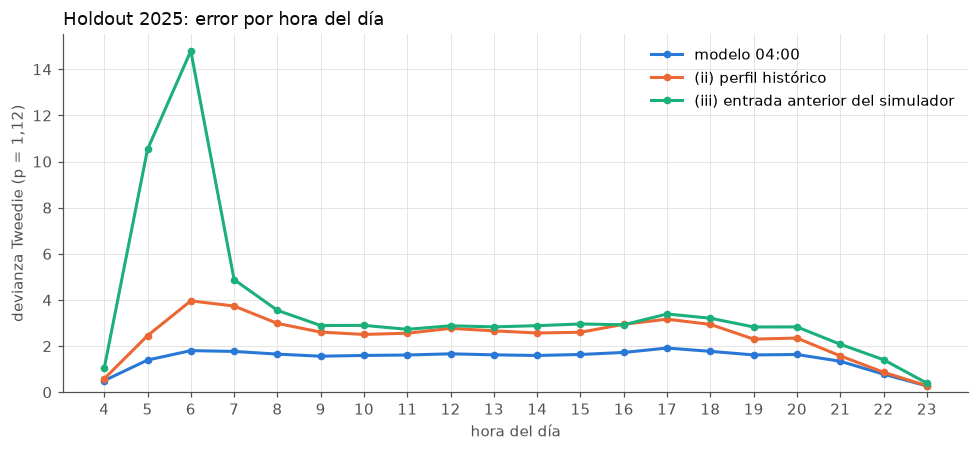

In [9]:
# Dónde gana y dónde falla: error por ruta, franja, tipo de día, tipo de nodo y temporada (holdout 2025)
ds = pd.read_csv(E2C / 'holdout/desgloses_resumen_e2c_5.csv')
cortes = ['idruta', 'franja', 'tipo_dia_cal', 'tipo_nodo', 'temporada', 'punta_manana_laboral']
x = ds[ds.corte.isin(cortes)].set_index(['corte', 'valor'])[['principal', 'ii_perfil', 'iii_simulador', 'mejora_vs_ii_%', 'mejora_vs_iii_%']]
x = x.rename(columns={'principal': 'modelo 04:00', 'ii_perfil': '(ii) perfil', 'iii_simulador': '(iii) simulador',
                      'mejora_vs_ii_%': 'mejora frente al perfil (%)', 'mejora_vs_iii_%': 'mejora frente a (iii) (%)'})
display(x.round(3))

# Devianza por hora del día: modelo frente a las dos líneas base que importan
hh = ds[ds.corte == 'hora'].assign(h=lambda d: d.valor.astype(int)).sort_values('h').set_index('h')
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(hh.index, hh.principal, color=CATEG[0], marker='o', ms=4, label='modelo 04:00')
ax.plot(hh.index, hh.ii_perfil, color=CATEG[1], marker='o', ms=4, label='(ii) perfil histórico')
ax.plot(hh.index, hh.iii_simulador, color=CATEG[2], marker='o', ms=4, label='(iii) entrada anterior del simulador')
ax.set_xticks(range(4, 24)); ax.set_xlabel('hora del día'); ax.set_ylabel('devianza Tweedie (p = 1,12)')
ax.set_title('Holdout 2025: error por hora del día', loc='left'); ax.set_ylim(0, None); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

Nodos que sobrepredice (residuo medio < 0): 300 de 386 · residuo medio de la red -0.146 · |residuo| medio por nodo y hora 0.332


,idruta,nro_segmento,compartido_otra_ruta,zona_terminal,residuo_medio
nodo,,,,,
206,16,72,True,False,-2.281
221,16,87,False,False,-1.827
143,16,9,True,False,-1.605
192,16,58,True,False,1.587
203,16,69,True,False,-1.096
77,2,78,True,False,-1.077
145,16,11,True,False,-1.050
121,2,122,True,False,1.045
201,16,67,True,False,-1.012


Residuo medio por ruta: {2: -0.136, 16: -0.219, 21: -0.085}


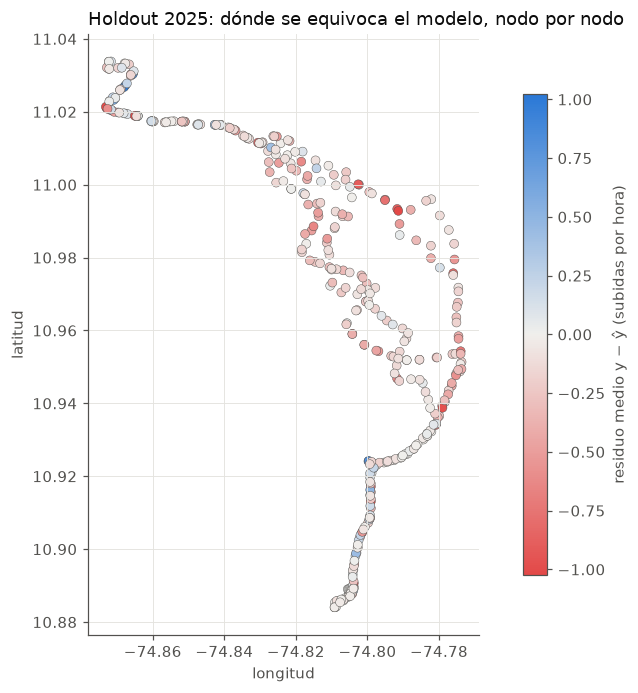

I de Moran de los residuos: significativo en 14/18 franjas × tipo (I de -0.02 a 0.27); en la (iii) 18/18; la demanda de 2025 da 0.12–0.37


,"% del |SHAP| (TreeSHAP, holdout)"
familia,
rezagos_propios,59.1
oferta,12.9
lag_espacial,11.3
calendario,9.5
nodo,7.3


In [10]:
# Error por nodo: residuo medio y − ŷ de cada nodo en el holdout (promedio de sus 20 horas).
# Positivo = el modelo se queda corto; negativo = sobrepredice.
rn = pd.read_csv(E2C / 'holdout/residuo_nodo_hora_e2c_5.csv', index_col=0)
res = rn.mean(axis=1).rename('residuo_medio')
m = nodos.set_index('nodo').join(res)
print(f'Nodos que sobrepredice (residuo medio < 0): {(m.residuo_medio < 0).sum()} de {len(m)} · '
      f'residuo medio de la red {res.mean():+.3f} · |residuo| medio por nodo y hora {rn.abs().values.mean():.3f}')
display(m.assign(abs_res=m.residuo_medio.abs()).sort_values('abs_res', ascending=False)
        .head(10)[['idruta', 'nro_segmento', 'compartido_otra_ruta', 'zona_terminal', 'residuo_medio']].round(3))
print('Residuo medio por ruta:', m.groupby('idruta').residuo_medio.mean().round(3).to_dict())

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cmap = LinearSegmentedColormap.from_list('div', ['#e34948', '#f0efec', '#2a78d6'])   # rojo = sobrepredice · azul = se queda corto
lim = float(np.nanpercentile(np.abs(m.residuo_medio), 98))
fig, ax = plt.subplots(figsize=(8.2, 6.4))
sc = ax.scatter(m.lon_centroide, m.lat_centroide, c=m.residuo_medio, cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim),
                s=34, edgecolors=TINTA2, linewidths=0.3)
ax.set_aspect(1 / np.cos(np.radians(m.lat_centroide.mean())))
cb = plt.colorbar(sc, ax=ax, shrink=0.8); cb.set_label('residuo medio y − ŷ (subidas por hora)')
ax.set_xlabel('longitud'); ax.set_ylabel('latitud')
ax.set_title('Holdout 2025: dónde se equivoca el modelo, nodo por nodo', loc='left')
plt.tight_layout(); plt.show()

mr = json.loads((E2C / 'holdout/residuos_resumen_e2c_5.json').read_text(encoding='utf-8'))
print(f"I de Moran de los residuos: significativo en {mr['moran_modelo_signif_de']} franjas × tipo "
      f"(I de {mr['moran_modelo_rango'][0]:.2f} a {mr['moran_modelo_rango'][1]:.2f}); en la (iii) {mr['moran_iii_signif_de']}; "
      f"la demanda de 2025 da {mr['moran_y_holdout_rango'][0]:.2f}–{mr['moran_y_holdout_rango'][1]:.2f}")
sf = pd.read_csv(E2C / 'holdout/shap_familias_e2c_5.csv').set_index('familia')
display(sf[['%']].rename(columns={'%': '% del |SHAP| (TreeSHAP, holdout)'}).sort_values('% del |SHAP| (TreeSHAP, holdout)', ascending=False).round(1))

**La evidencia de esta sección** son los notebooks del e2c.4 (pliegues, líneas base, familia, Optuna, rondas, ablaciones, decisión congelada y PC2) y del e2c.5 (registro de la evaluación única, métricas, desgloses, sobreajuste, semillas, guarda de rango, residuos, SHAP, Diebold-Mariano y entrega al simulador). Siguen intactos. **Nota:** la conclusión del e2c.5 dice «−38,9 %» frente al perfil; recalculado desde `metricas_holdout_e2c_5.csv` es −38,85 %, que se redondea a **−38,8 %**.

<a id="e2c-5"></a>

### 4.1 · Evidencia &middot; e2c.4 · Partición, líneas base, búsqueda, ablaciones y decisión

<sub>Notebook original: `subfase_e2c_4_validacion.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# Subfase e2c.4 · Partición, líneas base, búsqueda, ablaciones y decisión fija

Elección del modelo con walk-forward purgado sobre los bloques de entrenamiento (2023–2024), sin tocar el holdout. Termina en el punto de control PC2.

**Notebook de presentación (e2c.7).** Lee las salidas ya guardadas del módulo; no consulta la base, no reentrena ni vuelve a evaluar el holdout o los días de validación (esas corridas se hicieron una sola vez, con registro y hora). Las cifras de las conclusiones vienen de `datos_e2c/estado_e2c.md`, verificadas contra sus CSV al cerrar cada módulo.

In [1]:
%matplotlib inline
import json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
D = Path('datos_e2c')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 90)

def tabla(p, n=None, **kw):
    t = pd.read_csv(D / p, **kw)
    display(t if n is None else t.head(n))
    return t

def fig(p, w=900):
    display(Image(filename=str(D / p), width=w))

def h_json(d):
    return hashlib.sha256(json.dumps(d, ensure_ascii=False, sort_keys=True).encode('utf-8')).hexdigest()

def verificar_regla(p, clave=None):
    """Recalcula el hash de contenido de una regla congelada (sin la clave del hash ni `creado`)."""
    r = json.loads((D / p).read_text(encoding='utf-8'))
    clave = clave or next((k for k in ('sha256_regla', 'sha256_decision', 'sha256') if k in r), None)
    if clave is None:                                    # reglas cuyo hash solo está en el manifiesto
        man = json.loads((D / 'manifiesto_e2c.json').read_text(encoding='utf-8'))['reglas']
        h, ref = h_json(r), man[Path(p).name]
    else:
        h, ref = h_json({k: v for k, v in r.items() if k not in (clave, 'creado')}), r[clave]
    print(f"{p}: {'OK' if h == ref else 'NO COINCIDE'} · {ref[:12]}…")
    return r

def checks(n):
    c = pd.read_csv(D / f'checks/checks_e2c_{n}.csv')
    display(c)
    print(c.iloc[:, [i for i, x in enumerate(c.columns) if x.lower() in ('estado', 'resultado')][0]].value_counts().to_dict())

## Regla de la métrica (congelada antes del primer resultado) y pliegues

In [2]:
verificar_regla('reglas/regla_metrica_e2c.json')
tabla('modelo/pliegues_e2c_4.csv')

reglas/regla_metrica_e2c.json: OK · 03fe87a91220…


,pliegue,papel,bloques,corte,desde,hasta,dias,filas,nodos,subidas,dias_festivo,dias_carnaval,dias_receso,dias_laboral,dias_sabado,dias_domingo,max_t_mas_2h_menos_corte_h,max_t,holdout_filas,filas_purgadas
0,P1,entrena,T1,2023-07-03 04:00:00,2023-02-18 04:00:00,2023-03-10 23:00:00,21,145657,386,818805.0,0,4,0,13,2,2,-2739.0,2023-03-10 23:00:00,0,0
1,P1,valida,T2,2023-07-03 04:00:00,2023-07-03 04:00:00,2023-07-23 23:00:00,21,149823,386,746797.0,2,0,14,13,3,3,NaN,2023-07-23 23:00:00,0,0
2,P2,entrena,T1+T2,2024-01-15 04:00:00,2023-02-18 04:00:00,2023-07-23 23:00:00,42,295480,386,1565602.0,2,4,14,26,5,5,-4203.0,2023-07-23 23:00:00,0,0
3,P2,valida,T3,2024-01-15 04:00:00,2024-01-15 04:00:00,2024-02-18 23:00:00,35,251383,386,1330673.0,0,4,14,23,4,4,NaN,2024-02-18 23:00:00,0,0
4,P3,entrena,T1+T2+T3,2024-10-07 04:00:00,2023-02-18 04:00:00,2024-02-18 23:00:00,77,546863,386,2896275.0,2,8,28,49,9,9,-5547.0,2024-02-18 23:00:00,0,0
5,P3,valida,T4,2024-10-07 04:00:00,2024-10-07 04:00:00,2024-10-27 23:00:00,21,149543,386,703546.0,1,0,7,14,3,3,NaN,2024-10-27 23:00:00,0,0
6,P4,entrena,T1+T2+T3+T4,2024-12-09 04:00:00,2023-02-18 04:00:00,2024-10-27 23:00:00,98,696406,386,3599821.0,3,8,35,63,12,12,-1011.0,2024-10-27 23:00:00,0,0
7,P4,valida,T5,2024-12-09 04:00:00,2024-12-09 04:00:00,2024-12-29 23:00:00,21,147401,386,696310.0,1,0,21,14,3,3,NaN,2024-12-29 23:00:00,0,0
8,S,entrena,T1+T2,2024-01-15 04:00:00,2023-02-18 04:00:00,2023-07-23 23:00:00,42,295480,386,1565602.0,2,4,14,26,5,5,-4203.0,2023-07-23 23:00:00,0,0
9,S,valida,T3+T4+T5,2024-01-15 04:00:00,2024-01-15 04:00:00,2024-12-29 23:00:00,77,548327,386,2730529.0,2,4,42,51,10,10,NaN,2024-12-29 23:00:00,0,0


,pliegue,papel,bloques,corte,desde,hasta,dias,filas,nodos,subidas,dias_festivo,dias_carnaval,dias_receso,dias_laboral,dias_sabado,dias_domingo,max_t_mas_2h_menos_corte_h,max_t,holdout_filas,filas_purgadas
0,P1,entrena,T1,2023-07-03 04:00:00,2023-02-18 04:00:00,2023-03-10 23:00:00,21,145657,386,818805.0,0,4,0,13,2,2,-2739.0,2023-03-10 23:00:00,0,0
1,P1,valida,T2,2023-07-03 04:00:00,2023-07-03 04:00:00,2023-07-23 23:00:00,21,149823,386,746797.0,2,0,14,13,3,3,NaN,2023-07-23 23:00:00,0,0
2,P2,entrena,T1+T2,2024-01-15 04:00:00,2023-02-18 04:00:00,2023-07-23 23:00:00,42,295480,386,1565602.0,2,4,14,26,5,5,-4203.0,2023-07-23 23:00:00,0,0
3,P2,valida,T3,2024-01-15 04:00:00,2024-01-15 04:00:00,2024-02-18 23:00:00,35,251383,386,1330673.0,0,4,14,23,4,4,NaN,2024-02-18 23:00:00,0,0
4,P3,entrena,T1+T2+T3,2024-10-07 04:00:00,2023-02-18 04:00:00,2024-02-18 23:00:00,77,546863,386,2896275.0,2,8,28,49,9,9,-5547.0,2024-02-18 23:00:00,0,0
5,P3,valida,T4,2024-10-07 04:00:00,2024-10-07 04:00:00,2024-10-27 23:00:00,21,149543,386,703546.0,1,0,7,14,3,3,NaN,2024-10-27 23:00:00,0,0
6,P4,entrena,T1+T2+T3+T4,2024-12-09 04:00:00,2023-02-18 04:00:00,2024-10-27 23:00:00,98,696406,386,3599821.0,3,8,35,63,12,12,-1011.0,2024-10-27 23:00:00,0,0
7,P4,valida,T5,2024-12-09 04:00:00,2024-12-09 04:00:00,2024-12-29 23:00:00,21,147401,386,696310.0,1,0,21,14,3,3,NaN,2024-12-29 23:00:00,0,0
8,S,entrena,T1+T2,2024-01-15 04:00:00,2023-02-18 04:00:00,2023-07-23 23:00:00,42,295480,386,1565602.0,2,4,14,26,5,5,-4203.0,2023-07-23 23:00:00,0,0
9,S,valida,T3+T4+T5,2024-01-15 04:00:00,2024-01-15 04:00:00,2024-12-29 23:00:00,77,548327,386,2730529.0,2,4,42,51,10,10,NaN,2024-12-29 23:00:00,0,0


## e2c.4.2 · Líneas base por pliegue (devianza Tweedie p = 1,12)

pliegue,P1,P2,P3,P4,S,media
modelo,,,,,,
i_ingenua,2.993,3.399,3.853,3.409,3.533,3.438
ii_perfil,2.502,1.724,3.081,2.401,2.613,2.464
iii_simulador,2.504,2.538,3.498,3.329,3.013,2.976
iii_simulador_piso_1e-9,9.164,8.753,23.461,18.978,15.513,15.174


,mae,rmse,wape,mape_pos,sesgo
modelo,,,,,
i_ingenua,2.606,5.632,0.529,0.831,0.093
ii_perfil,2.504,5.393,0.509,0.742,0.627
iii_simulador,2.697,5.449,0.548,0.795,0.170
iii_simulador_piso_1e-9,2.689,5.450,0.546,0.796,0.160


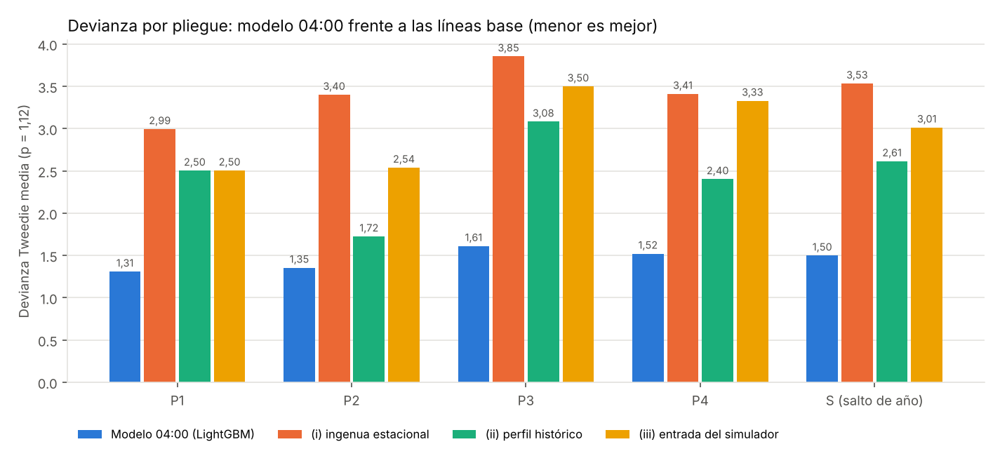

In [3]:
lb = pd.read_csv(D / 'modelo/lineas_base_e2c_4.csv')
display(lb.pivot_table(index='modelo', columns='pliegue', values='dev').assign(media=lambda t: t.mean(axis=1)).round(3))
display(lb.groupby('modelo')[['mae', 'rmse', 'wape', 'mape_pos', 'sesgo']].mean().round(3))
fig('modelo/figuras/devianza_pliegues_e2c_4.png')

## e2c.4.3 · Familia de pérdida

In [4]:
fa = pd.read_csv(D / 'modelo/familia_e2c_4.csv')
display(fa.pivot_table(index='familia', columns='pliegue', values='dev').assign(media=lambda t: t.mean(axis=1)).round(4))
print(json.loads((D / 'modelo/familia_decision_e2c_4.json').read_text(encoding='utf-8')))

pliegue,P1,P2,P3,P4,media
familia,,,,,
poisson,1.3544,1.3870,1.7369,1.5404,1.5047
tweedie_1.10,1.3575,1.3934,1.8512,1.5548,1.5393
tweedie_1.15,1.3625,1.4027,1.8751,1.5483,1.5471
tweedie_1.20,1.3546,1.4231,1.9400,1.5476,1.5663
tweedie_1.30,1.3620,1.4226,2.0467,1.5589,1.5975


{'elegida': 'poisson', 'mejor_tweedie': 'tweedie_1.10', 'media': {'poisson': 1.50467, 'tweedie_1.10': 1.53925, 'tweedie_1.15': 1.54715, 'tweedie_1.20': 1.56632, 'tweedie_1.30': 1.59754}, 'poisson_gana_pliegues': 4, 'poisson_vs_mejor_tweedie_%': -2.246664890355332, 'plataforma': {'equipo': 'vm', 'sistema': 'Linux-6.18.44-fc-v653-x86_64-with-glibc2.39', 'python': '3.13.18', 'lightgbm': '4.7.0'}}


## e2c.4.4 · Optuna (60 trials)

,number,value,state,params_bagging_fraction,params_feature_fraction,params_lambda_l1,params_lambda_l2,params_learning_rate,params_max_bin,params_min_data_in_leaf,params_num_leaves,user_attrs_P1_dev,user_attrs_P1_mae,user_attrs_P1_rondas,user_attrs_P2_dev,user_attrs_P2_mae,user_attrs_P2_rondas,user_attrs_P3_dev,user_attrs_P3_mae,user_attrs_P3_rondas,user_attrs_P4_dev,user_attrs_P4_mae,user_attrs_P4_rondas,duration_s
59,59,1.329417,PRUNED,0.521588,0.579847,0.005274,0.004493,0.021854,127,156,115,1.329417,1.875017,1787,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.021767
56,56,1.329812,PRUNED,0.545163,0.657261,0.011535,0.006062,0.025357,127,162,68,1.329812,1.876962,1907,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,52.266462
53,53,1.330485,PRUNED,0.520866,0.553616,0.018634,0.086628,0.022558,127,172,61,1.330485,1.876989,2777,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,69.738977
54,54,1.331199,PRUNED,0.506531,0.564532,0.029382,0.020199,0.027166,127,222,49,1.331199,1.882922,2132,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.810283
38,38,1.331769,PRUNED,0.582528,0.568686,0.003937,0.002080,0.026411,127,334,65,1.331769,1.879471,2045,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56.354754


,parametro,importancia
0,learning_rate,0.821073
1,feature_fraction,0.042591
2,bagging_fraction,0.041798
3,min_data_in_leaf,0.032368
4,max_bin,0.032293
5,num_leaves,0.016540
6,lambda_l2,0.011467
7,lambda_l1,0.001870


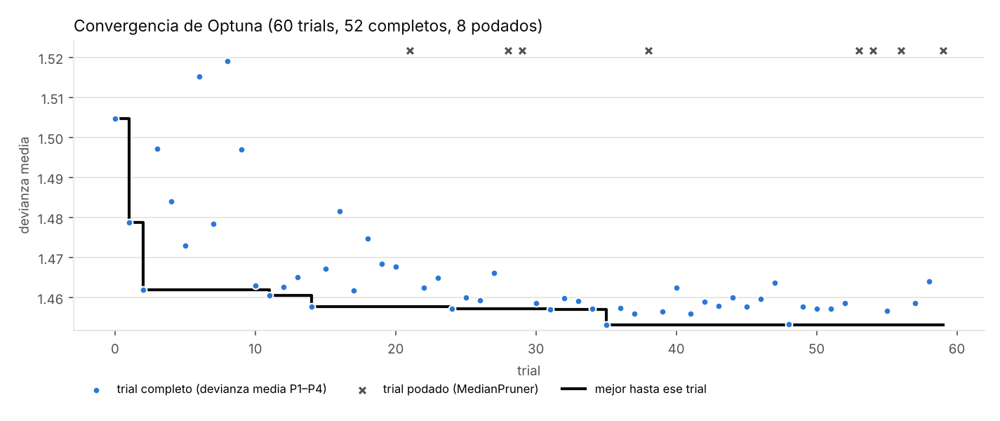

In [5]:
t = pd.read_csv(D / 'modelo/optuna_trials_e2c_4.csv')
display(t.sort_values(t.columns[[i for i, c in enumerate(t.columns) if c in ('value', 'valor', 'dev')][0]]).head(5))
tabla('modelo/optuna_importancia_e2c_4.csv')
fig('modelo/figuras/optuna_convergencia_e2c_4.png')

## e2c.4.5 · Rondas: early stopping frente a rondas fijas

,pliegue,regimen,rondas,segundos,n,dev,mae,rmse,wape,mape_pos,sesgo,media_y,media_pred
0,P1,early_stopping,2029,64.9,149823,1.323728,1.866578,3.666098,0.374474,0.603595,0.316657,4.984528,5.301186
1,P2,early_stopping,2866,148.6,251383,1.364411,1.885519,4.008524,0.356201,0.544174,-0.164046,5.293409,5.129363
2,P2,fijas_anidadas,2029,101.9,251383,1.359812,1.881885,4.005958,0.355515,0.541508,-0.183485,5.293409,5.109924
3,P3,early_stopping,3000,164.4,149543,1.601415,1.986450,4.133470,0.422232,0.627932,0.108712,4.704640,4.813352
4,P3,fijas_anidadas,2447,136.9,149543,1.600075,1.989818,4.138117,0.422948,0.632758,0.147507,4.704640,4.852147
5,P4,early_stopping,2974,191.8,147401,1.522843,1.897970,3.859712,0.401779,0.616000,0.082404,4.723916,4.806320
6,P4,fijas_anidadas,2866,180.0,147401,1.520416,1.894618,3.846969,0.401069,0.615647,0.084369,4.723916,4.808285


{'best_iteration_por_pliegue': {'P1': 2029, 'P2': 2866, 'P3': 3000, 'P4': 2974}, 'pliegues_anomalos': [], 'fijas_gana_pliegues': 3, 'de': 3, 'dev_media_es_P2_P4': 1.4962229992440212, 'dev_media_fijas_P2_P4': 1.4934343434958957, 'regla': 'fijas', 'rondas_finales': 2920, 'plataforma': {'equipo': 'vm', 'sistema': 'Linux-6.18.44-fc-v653-x86_64-with-glibc2.39', 'python': '3.13.18', 'lightgbm': '4.7.0'}}


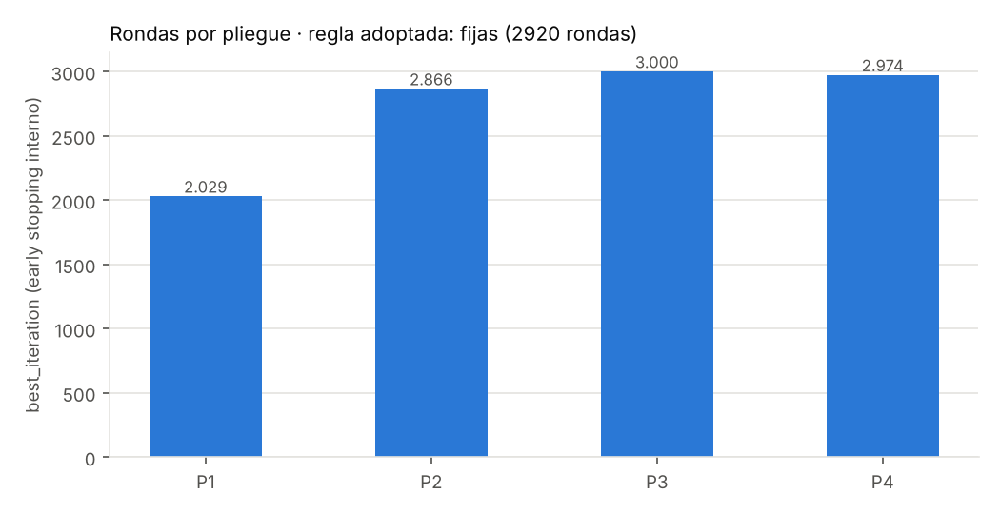

In [6]:
tabla('modelo/rondas_e2c_4.csv')
print(json.loads((D / 'modelo/rondas_decision_e2c_4.json').read_text(encoding='utf-8')))
fig('modelo/figuras/rondas_e2c_4.png')

## e2c.4.6 · Ablaciones

,comparacion,config,referencia,dif_media_%,sd_%,pliegues_config_peor,pliegues,dev_media_config,dev_media_ref,dif_P1_%,dif_P2_%,dif_P3_%,dif_P4_%
0,"lag espacial (k = 8, 9 features)",sin_lag_espacial,principal_k8,0.156554,0.537228,2.0,4.0,1.450699,1.448123,0.326656,-0.448701,0.807659,-0.059397
1,k = 2 frente a k = 8 (mismas 6),k2,k8_mismas_que_k2,0.036097,0.527428,2.0,4.0,1.449463,1.448398,-0.437967,-0.315683,0.718320,0.179718
2,kernel frente a k = 8 (mismas 6),kernel,k8_mismas_que_k2,0.168159,0.277347,3.0,4.0,1.450896,1.448398,0.127467,0.235990,0.489358,-0.180179
3,6 espaciales frente a las 9 de k = 8,k8_mismas_que_k2,principal_k8,0.028457,0.298646,2.0,4.0,1.448398,1.448123,-0.142566,0.424655,-0.251455,0.083195
4,receso escolar,sin_receso,principal_k8,0.278145,0.556671,2.0,4.0,1.452392,1.448123,0.000000,-0.062526,0.065654,1.109453
5,tasa con offset frente a conteo,tasa_offset,principal_k8,13.932532,10.715440,4.0,4.0,1.657828,1.448123,11.780103,6.071114,29.613924,8.264989
6,nowcast (oráculo) frente a 04:00,nowcast_oraculo,principal_k8,-1.711750,0.276923,0.0,4.0,1.423246,1.448123,-1.921288,-1.353961,-1.939418,-1.632333
7,oráculo frente a 04:00,oraculo,principal_k8,-3.115068,0.368635,0.0,4.0,1.402641,1.448123,-2.706043,-2.998250,-3.588313,-3.167667
8,brecha 04:00 → oráculo cerrada por el nowcast (%),nowcast_oraculo,oraculo,55.434387,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


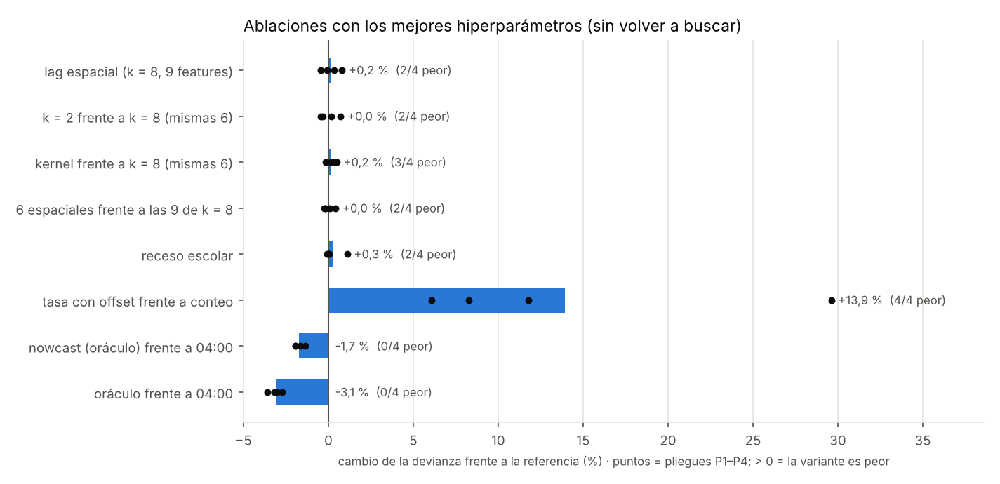

In [7]:
tabla('modelo/ablaciones_resumen_e2c_4.csv')
fig('modelo/figuras/ablaciones_e2c_4.png')

## e2c.4.7 · Decisión congelada y PC2

In [8]:
d = verificar_regla('modelo/decision_modelo_e2c.json')
display(pd.Series({k: d[k] for k in ('escenario_principal', 'objetivo', 'rondas', 'p_metrica', 'piso_prediccion', 'semillas')}, name='decisión'))
print('hiperparámetros:', d['hiperparametros'])
print('PC2:', json.loads((D / 'modelo/confirmacion_pc2_e2c.json').read_text(encoding='utf-8')))

modelo/decision_modelo_e2c.json: OK · 55bcf5bdc065…


escenario_principal                  capa_0400 (emisión 04:00 del mismo día; desplegable)
objetivo                                                                          poisson
rondas                 {'regla': 'fijas', 'rondas_finales': 2920, 'early_stopping': None}
p_metrica                                                                            1.12
piso_prediccion                                                                      0.05
semillas                                {'oficial': 42, 'robustez_e2c5': [1, 2, 3, 4, 5]}
Name: decisión, dtype: object

hiperparámetros: {'learning_rate': 0.020752493528465, 'num_leaves': 109, 'min_data_in_leaf': 121, 'feature_fraction': 0.5601494021783113, 'bagging_fraction': 0.526739221346679, 'lambda_l1': 0.016975873403654525, 'lambda_l2': 0.006817965352063364, 'max_bin': 127}
PC2: {'punto_de_control': 'PC2 (fin de e2c.4)', 'fecha_hora': '2026-11-19T06:13:00-05:00', 'persona': 'Persona 3', 'texto': 'listo si ya terminaste este prompt al 100% continua con el siguiente', 'interpretacion': 'Claude interpretó este mensaje genérico como la opción 1 de PC2 (decisión tal cual, con el lag espacial, aunque C2 no se cumplió); no fue una elección expresa. Ver ratificacion_expresa.', 'sha256_decision': '55bcf5bdc065876698192938e04da620e98b37f1fa64804b9329b51362a22c8e', 'ratificacion_expresa': {'fecha_hora': '2026-11-19T10:03:00-05:00', 'persona': 'Persona 3', 'decision': 'Opción 1: conservar el lag espacial en el modelo final, tal cual', 'texto': 'RATIFICACIÓN DE PC2: MANTENER EL LAG ESPACIAL (OPCIÓN 1). Decisió

## Pruebas y checks

In [9]:
tabla('modelo/tests_e2c_4.csv')
checks(4)

,prueba,estado,detalle
0,a · sin holdout en los pliegues,PASS,filas del holdout en pliegues = 0; máximo t cargado 2024-12-29 23:00:00; holdout desde...
1,b · sin K-Fold ni barajado,PASS,4 archivos revisados; hallazgos: ninguno
2,c · purga y disjunción temporal,PASS,P1:ok P2:ok P3:ok P4:ok S:ok
3,d · (iii) conserva el pronóstico por ruta × día × hora de salida y reparte como el sim...,PASS,error relativo máx. de conservación 4.4e-16 (contra Σ pax × Σ fracciones; las fraccion...
4,e · el perfil (ii) solo usa el entrenamiento,PASS,"P2: 251,383 predicciones idénticas"
5,f · offset igual en entrenamiento y predicción,PASS,best_iteration 87; ŷ = exp(margen + offset); con offset mejora la devianza: True
6,g · reglas y decisión con hash válido,PASS,regla_metrica_e2c.json: ok; regla_aceptacion_e2c.json: ok; regla_decisiones_e2c.json: ...


,check,descripcion,estado,detalle
0,Ta,sin holdout en los pliegues,PASS,filas del holdout en pliegues = 0; máximo t cargado 2024-12-29 23:00:00; holdout desde...
1,Tb,sin K-Fold ni barajado,PASS,4 archivos revisados; hallazgos: ninguno
2,Tc,purga y disjunción temporal,PASS,P1:ok P2:ok P3:ok P4:ok S:ok
3,Td,(iii) conserva el pronóstico por ruta × día × hora de salida y reparte como el simulador,PASS,error relativo máx. de conservación 4.4e-16 (contra Σ pax × Σ fracciones; las fraccion...
4,Te,el perfil (ii) solo usa el entrenamiento,PASS,"P2: 251,383 predicciones idénticas"
5,Tf,offset igual en entrenamiento y predicción,PASS,best_iteration 87; ŷ = exp(margen + offset); con offset mejora la devianza: True
6,Tg,reglas y decisión con hash válido,PASS,regla_metrica_e2c.json: ok; regla_aceptacion_e2c.json: ok; regla_decisiones_e2c.json: ...
7,K1,"La regla de métrica (p, piso, filas) se congeló antes del primer resultado del e2c.4",PASS,regla 2026-11-18T18:59:22 · primer archivo de resultados 2026-11-18T18:59:28 (hora del...
8,K2,"p de la métrica (1,12) fijado en la regla antes de la búsqueda de Optuna",PASS,regla 18:59:22 · primer trial 2026-11-18 19:46:25 (hora local) · 60 trials
9,K3,"decision_modelo_e2c.json con hash de contenido, escrito antes de PC2",PASS,55bcf5bdc0658766… creado 2026-11-19T05:01:59; ningún modelo final entrenado y ninguna ...


{'PASS': 14, 'FAIL': 1}


**Conclusión e2c.4 · El modelo 04:00 (LightGBM Poisson, 35 features, 2.920 rondas) tiene una devianza media en P1–P4 de 1,448, frente a 2,967 de la entrada actual del simulador (iii): −51,2 %, y gana en 4 de 4 pliegues y en el salto de año (1,498 frente a 3,013). C1 y C3 se cumplen; C2 no (el lag espacial no aporta de forma consistente). La decisión quedó hasheada antes de PC2; no se entrenó el modelo final ni se leyó ninguna fila de 2025.**

<a id="e2c-6"></a>

### 4.2 · Evidencia &middot; e2c.5 · Holdout 2025 (evaluación única), diagnósticos, SHAP y DM

<sub>Notebook original: `subfase_e2c_5_holdout.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# Subfase e2c.5 · Modelo final, evaluación única del holdout 2025, diagnósticos, SHAP y Diebold-Mariano

Entrenamiento final con T1–T5 y la decisión congelada; el holdout H1–H4 (2025) se evaluó **una sola vez** (`registro_evaluacion_e2c_5.json`). Aquí solo se leen sus salidas.

**Notebook de presentación (e2c.7).** Lee las salidas ya guardadas del módulo; no consulta la base, no reentrena ni vuelve a evaluar el holdout o los días de validación (esas corridas se hicieron una sola vez, con registro y hora). Las cifras de las conclusiones vienen de `datos_e2c/estado_e2c.md`, verificadas contra sus CSV al cerrar cada módulo.

In [1]:
%matplotlib inline
import json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
D = Path('datos_e2c')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 90)

def tabla(p, n=None, **kw):
    t = pd.read_csv(D / p, **kw)
    display(t if n is None else t.head(n))
    return t

def fig(p, w=900):
    display(Image(filename=str(D / p), width=w))

def h_json(d):
    return hashlib.sha256(json.dumps(d, ensure_ascii=False, sort_keys=True).encode('utf-8')).hexdigest()

def verificar_regla(p, clave=None):
    """Recalcula el hash de contenido de una regla congelada (sin la clave del hash ni `creado`)."""
    r = json.loads((D / p).read_text(encoding='utf-8'))
    clave = clave or next((k for k in ('sha256_regla', 'sha256_decision', 'sha256') if k in r), None)
    if clave is None:                                    # reglas cuyo hash solo está en el manifiesto
        man = json.loads((D / 'manifiesto_e2c.json').read_text(encoding='utf-8'))['reglas']
        h, ref = h_json(r), man[Path(p).name]
    else:
        h, ref = h_json({k: v for k, v in r.items() if k not in (clave, 'creado')}), r[clave]
    print(f"{p}: {'OK' if h == ref else 'NO COINCIDE'} · {ref[:12]}…")
    return r

def checks(n):
    c = pd.read_csv(D / f'checks/checks_e2c_{n}.csv')
    display(c)
    print(c.iloc[:, [i for i, x in enumerate(c.columns) if x.lower() in ('estado', 'resultado')][0]].value_counts().to_dict())

## Registro de la evaluación única

In [2]:
reg = json.loads((D / 'holdout/registro_evaluacion_e2c_5.json').read_text(encoding='utf-8'))
display(pd.Series({k: v for k, v in reg.items() if not isinstance(v, (dict, list))}, name='registro'))

modulo                                                                        e2c.5
evaluacion                                                                    única
inicio                                                          2026-11-19T07:01:43
fin                                                             2026-11-19T07:39:59
sha256_decision    55bcf5bdc065876698192938e04da620e98b37f1fa64804b9329b51362a22c8e
filas_holdout                                                               1033926
dias_holdout                                                                    147
p_metrica                                                                      1.12
piso                                                                           0.05
Name: registro, dtype: object

## e2c.5.2 · Métricas en el holdout (global y por bloque)

corte,H1,H2,H3,H4,global
modelo,,,,,
i_ingenua,3.862,3.552,3.442,3.679,3.648
ii_perfil,2.135,2.260,3.079,2.187,2.388
iii_simulador,3.633,3.342,4.122,3.461,3.627
nowcast_oraculo,1.432,1.379,1.456,1.364,1.411
oraculo,1.402,1.354,1.436,1.354,1.388
principal,1.504,1.432,1.491,1.375,1.460
semilla_1,1.503,1.433,1.493,1.374,1.461
semilla_2,1.519,1.444,1.507,1.375,1.473
semilla_3,1.515,1.438,1.495,1.374,1.467


,n,dev,mae,rmse,wape,mape_pos,sesgo
modelo,,,,,,,
principal,1033926,1.460,1.879,3.749,0.397,0.596,0.145
semilla_1,1033926,1.461,1.879,3.746,0.397,0.597,0.149
semilla_2,1033926,1.473,1.884,3.770,0.398,0.597,0.142
semilla_3,1033926,1.467,1.881,3.755,0.397,0.597,0.146
sin_lag_espacial,1033926,1.484,1.891,3.788,0.400,0.600,0.150
nowcast_oraculo,1033926,1.411,1.847,3.646,0.390,0.590,0.149
oraculo,1033926,1.388,1.828,3.581,0.386,0.585,0.140
i_ingenua,1033926,3.648,2.480,5.174,0.524,0.802,0.033
ii_perfil,1033926,2.388,2.406,4.961,0.508,0.720,0.445


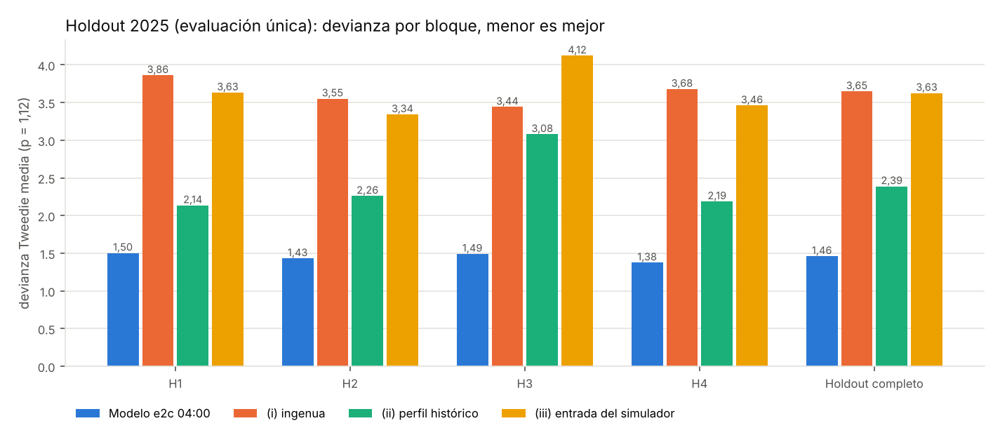

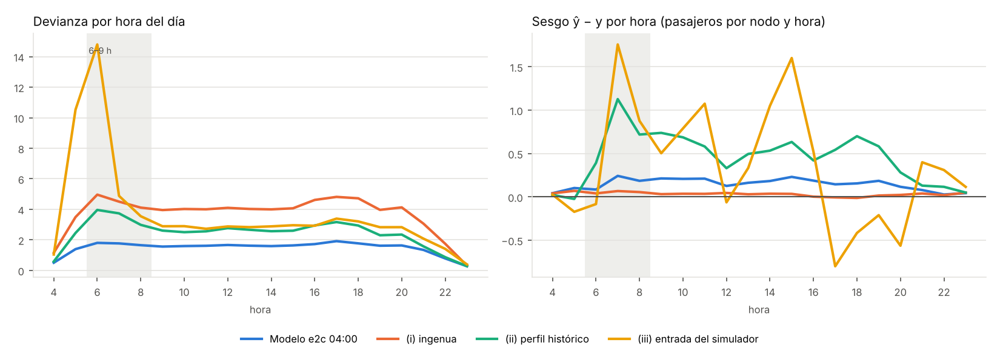

In [3]:
m = pd.read_csv(D / 'holdout/metricas_holdout_e2c_5.csv')
display(m.pivot_table(index='modelo', columns='corte', values='dev').round(3))
display(m[m.corte == 'global'].set_index('modelo')[['n', 'dev', 'mae', 'rmse', 'wape', 'mape_pos', 'sesgo']].round(3))
fig('holdout/figuras/holdout_bloques_e2c_5.png'); fig('holdout/figuras/holdout_hora_e2c_5.png')

## e2c.5.3 · Desgloses (mejora frente a la entrada anterior del simulador, iii)

In [4]:
tabla('holdout/desgloses_resumen_e2c_5.csv')

,corte,valor,i_ingenua,ii_perfil,iii_simulador,nowcast_oraculo,oraculo,principal,sin_lag_espacial,mejora_vs_iii_%,mejora_vs_ii_%
0,bloque,H1,3.861523,2.135014,3.632796,1.432397,1.401955,1.503723,1.535141,58.607005,29.568461
1,bloque,H2,3.552151,2.260448,3.341967,1.379322,1.353827,1.431662,1.459602,57.161099,36.664682
2,bloque,H3,3.441573,3.078854,4.121724,1.455911,1.435982,1.491479,1.512295,63.814205,51.557335
3,bloque,H4,3.679186,2.186991,3.460602,1.364026,1.353713,1.375065,1.377885,60.265149,37.125239
4,franja,madrugada,2.272804,1.478977,5.582953,0.928133,0.931691,0.930979,0.938307,83.324613,37.052494
5,franja,noche,2.586117,1.443593,1.872966,1.078950,1.068318,1.110633,1.117998,40.701888,23.064662
6,franja,pico_am,4.737519,3.850995,9.915443,1.759571,1.699675,1.787298,1.832408,81.974604,53.588673
7,franja,pico_pm,4.769453,3.054551,3.301145,1.768710,1.730160,1.845009,1.879929,44.110008,39.598009
8,franja,valle_am,4.021956,2.657149,3.005027,1.534708,1.501592,1.605599,1.638230,46.569545,39.574354
9,franja,valle_pm,4.157715,2.708405,2.896373,1.582737,1.560985,1.648023,1.676467,43.100462,39.151543


,corte,valor,i_ingenua,ii_perfil,iii_simulador,nowcast_oraculo,oraculo,principal,sin_lag_espacial,mejora_vs_iii_%,mejora_vs_ii_%
0,bloque,H1,3.861523,2.135014,3.632796,1.432397,1.401955,1.503723,1.535141,58.607005,29.568461
1,bloque,H2,3.552151,2.260448,3.341967,1.379322,1.353827,1.431662,1.459602,57.161099,36.664682
2,bloque,H3,3.441573,3.078854,4.121724,1.455911,1.435982,1.491479,1.512295,63.814205,51.557335
3,bloque,H4,3.679186,2.186991,3.460602,1.364026,1.353713,1.375065,1.377885,60.265149,37.125239
4,franja,madrugada,2.272804,1.478977,5.582953,0.928133,0.931691,0.930979,0.938307,83.324613,37.052494
5,franja,noche,2.586117,1.443593,1.872966,1.078950,1.068318,1.110633,1.117998,40.701888,23.064662
6,franja,pico_am,4.737519,3.850995,9.915443,1.759571,1.699675,1.787298,1.832408,81.974604,53.588673
7,franja,pico_pm,4.769453,3.054551,3.301145,1.768710,1.730160,1.845009,1.879929,44.110008,39.598009
8,franja,valle_am,4.021956,2.657149,3.005027,1.534708,1.501592,1.605599,1.638230,46.569545,39.574354
9,franja,valle_pm,4.157715,2.708405,2.896373,1.582737,1.560985,1.648023,1.676467,43.100462,39.151543


## e2c.5.4 · Sobreajuste, semillas y guarda de rango

In [5]:
print(json.dumps(json.loads((D / 'holdout/sobreajuste_estabilidad_e2c_5.json').read_text(encoding='utf-8')), ensure_ascii=False, indent=1)[:2500])
tabla('holdout/guarda_rango_holdout_e2c_5.csv')

{
 "dev_ajuste": 1.1672113009532532,
 "dev_holdout": 1.4604697042553973,
 "razon_holdout_ajuste": 1.2512470561779534,
 "cv_media": 1.4481231711734361,
 "cv_sd": 0.14136492073505016,
 "dentro_1_sd": true,
 "dif_holdout_cv_en_sd": 0.08733802571220199,
 "semillas": {
  "principal": 1.4604697042553973,
  "semilla_1": 1.4607202068949223,
  "semilla_2": 1.4728170986193558,
  "semilla_3": 1.4666997430548272
 },
 "rango_semillas": 0.012347394363958486,
 "corr_pred_semillas_min": 0.9987263387683667,
 "guarda_rango": {
  "variables_fuera": [
   {
    "variable": "y_media_1d",
    "pct_fuera": 0.016
   },
   {
    "variable": "y_sd_1d",
    "pct_fuera": 0.018
   },
   {
    "variable": "y_media_7d",
    "pct_fuera": 0.028
   },
   {
    "variable": "y_sd_7d",
    "pct_fuera": 0.09
   }
  ],
  "pct_filas_con_alguna_fuera": 0.09662200196145565,
  "dev_filas_fuera": 4.480198776544154,
  "dev_filas_dentro": 1.4575491596833061,
  "dev_iii_filas_fuera": 32.048052149331475
 }
}


,variable,pct_fuera,min_emision,max_emision,min_entrenamiento,max_entrenamiento,pct_fuera_sin_ajuste_precision
0,y_l24,0.000,0.000000,304.000000,0.000000,243.000000,0.000
1,y_l48,0.000,0.000000,304.000000,0.000000,243.000000,0.000
2,y_l168,0.000,0.000000,281.000000,0.000000,243.000000,0.000
3,y_l336,0.000,0.000000,281.000000,0.000000,243.000000,0.000
4,y_mh_7d,0.000,0.000000,241.000000,0.000000,203.000000,0.000
5,y_mh_2sem,0.000,0.000000,281.000000,0.000000,239.000000,0.000
6,y_media_1d,0.016,0.000000,66.250000,0.000000,59.736843,0.016
7,y_sd_1d,0.018,0.000000,71.277810,0.000000,61.748066,0.018
8,y_media_7d,0.028,0.000000,51.902440,0.000000,47.737705,0.028
9,y_sd_7d,0.090,0.000000,56.584880,0.000000,44.999767,0.090


,variable,pct_fuera,min_emision,max_emision,min_entrenamiento,max_entrenamiento,pct_fuera_sin_ajuste_precision
0,y_l24,0.000,0.000000,304.000000,0.000000,243.000000,0.000
1,y_l48,0.000,0.000000,304.000000,0.000000,243.000000,0.000
2,y_l168,0.000,0.000000,281.000000,0.000000,243.000000,0.000
3,y_l336,0.000,0.000000,281.000000,0.000000,243.000000,0.000
4,y_mh_7d,0.000,0.000000,241.000000,0.000000,203.000000,0.000
5,y_mh_2sem,0.000,0.000000,281.000000,0.000000,239.000000,0.000
6,y_media_1d,0.016,0.000000,66.250000,0.000000,59.736843,0.016
7,y_sd_1d,0.018,0.000000,71.277810,0.000000,61.748066,0.018
8,y_media_7d,0.028,0.000000,51.902440,0.000000,47.737705,0.028
9,y_sd_7d,0.090,0.000000,56.584880,0.000000,44.999767,0.090


## e2c.5.5 · Residuos: I de Moran por franja × tipo y dependencia temporal

serie                       r_ii  r_iii  r_modelo      y
tipo_dia        franja                                  
domingo_festivo madrugada  0.077  0.143    -0.016  0.119
                noche      0.119  0.153     0.172  0.234
                pico_am    0.132  0.182     0.021  0.140
                pico_pm    0.204  0.233     0.124  0.221
                valle_am   0.160  0.224     0.171  0.146
                valle_pm   0.186  0.309     0.098  0.237
laboral         madrugada  0.143  0.147    -0.024  0.153
                noche      0.145  0.230     0.127  0.324
                pico_am    0.086  0.190     0.070  0.188
                pico_pm    0.123  0.279     0.103  0.371
                valle_am   0.129  0.059     0.103  0.231
                valle_pm   0.149  0.064     0.193  0.296
sabado          madrugada  0.095  0.147     0.161  0.121
                noche      0.080  0.191     0.274  0.273
                pico_am    0.102  0.189    -0.003  0.202
                pico_pm    0.123  0.198     0.193  0.317
                valle_am   0.110  0.066     0.085  0.179
                valle_pm   0.097  0.070     0.065  0.269

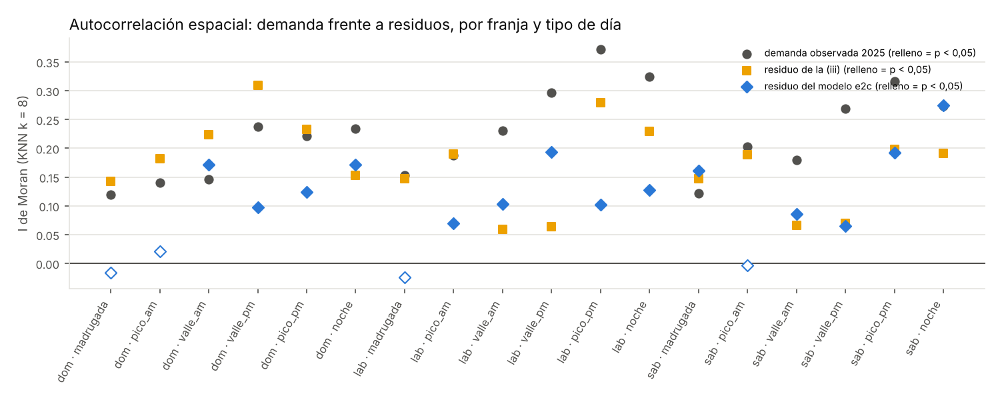

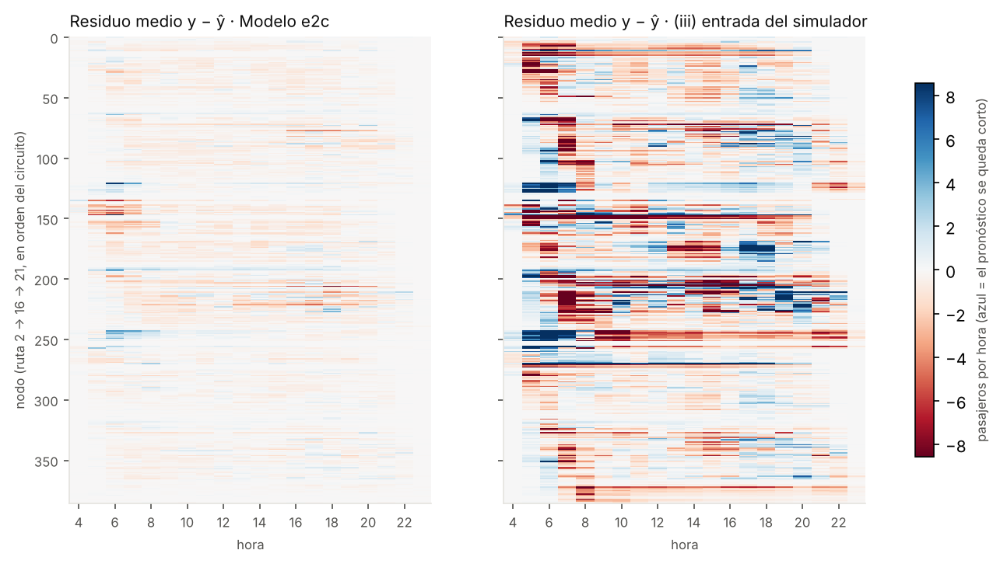

{'acf_mediana_entre_nodos': {'1': 0.0624, '2': 0.0495, '3': 0.0401, '24': -0.0177, '48': -0.013, '168': -0.03}, 'acf_p10': {'1': 0.0017, '2': -0.0009, '3': -0.0068, '24': -0.0644, '48': -0.0568, '168': -0.0836}, 'acf_p90': {'1': 0.2067, '2': 0.1614, '3': 0.1296, '24': 0.048, '48': 0.0438, '168': 0.0359}, 'ljungbox_pct_nodos_p<0.05': 80.56994818652849, 'ljungbox_Q24_mediana': 69.83748433026054, 'moran_modelo_signif_de': '14/18', 'moran_modelo_rango': [-0.02407256047600015, 0.27449735361359245], 'moran_iii_signif_de': '18/18', 'moran_iii_rango': [0.059215938638018384, 0.3089007821461884], 'moran_y_holdout_rango': [0.11940693290328307, 0.37141386415945066]}


In [6]:
mr = pd.read_csv(D / 'holdout/moran_residuos_e2c_5.csv')
display(mr.pivot_table(index=['tipo_dia', 'franja'], columns='serie', values='I').round(3))
fig('holdout/figuras/moran_residuos_e2c_5.png'); fig('holdout/figuras/mapa_residuos_nodo_hora_e2c_5.png')
print(json.loads((D / 'holdout/residuos_resumen_e2c_5.json').read_text(encoding='utf-8')))

## e2c.5.6 · Importancia por ganancia y TreeSHAP

,variable,ganancia,familia,ganancia_%
0,y_mh_7d,4.633821e+07,rezagos_propios,41.116046
1,y_mh_2sem,3.292599e+07,rezagos_propios,29.215339
2,y_l168,7.983667e+06,rezagos_propios,7.083934
3,y_l336,6.678065e+06,rezagos_propios,5.925469
4,nodo,3.265601e+06,nodo,2.897578
5,y_l24,2.482038e+06,rezagos_propios,2.202320
6,y_media_7d,2.448970e+06,rezagos_propios,2.172979
7,tipo_dia_cod,1.860463e+06,calendario,1.650795
8,y_l48,1.420633e+06,rezagos_propios,1.260533
9,y_sd_7d,1.156565e+06,rezagos_propios,1.026223


,familia,media_abs_shap_familia,%,shap_medio_punta,shap_medio_resto,dif_punta_menos_resto
0,lag_espacial,0.314554,11.259928,0.225241,-0.018043,0.243285
1,rezagos_propios,1.652345,59.148200,0.464468,-0.090990,0.555459
2,calendario,0.264631,9.472883,0.260583,0.024122,0.236461
3,oferta,0.359043,12.852502,0.161994,0.004325,0.157669
4,nodo,0.202994,7.266487,0.069548,0.060611,0.008937


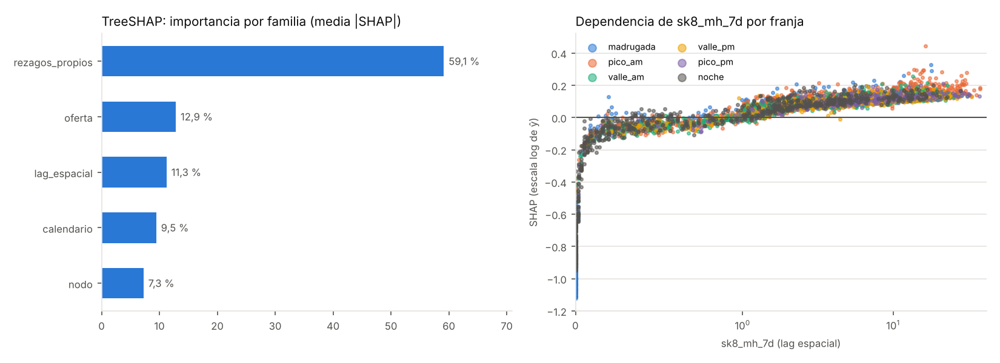

In [7]:
tabla('holdout/importancia_ganancia_e2c_5.csv', 12)
tabla('holdout/shap_familias_e2c_5.csv')
fig('holdout/figuras/shap_e2c_5.png')

## e2c.5.7 · Diebold-Mariano diario con p calibrado (8.3)

,comparacion,n_dias,media_d,mejora_%,rezago,acf_1_7_14,DM,p_t,DM_HLN,p_HLN,k_ar,suma_phi,p_calibrado,tamano_NW_al_5%,critico_calibrado_5%,IC95_boot14_lo,IC95_boot14_hi,p_HLN_rezago_7,p_HLN_rezago_14,p_HLN_rezago_21,media_d_por_bloque,p_calibrado_holm,significativo_5%
0,modelo vs iii_simulador,147,-2.177525,59.799954,25,"[np.float64(0.305), np.float64(0.382), np.float64(0.209)]",-20.346894,9.179281e-45,-20.277569,1.327495e-44,7,0.563656,0.000100,0.1321,-2.628735,-2.362421,-1.990711,8.644387e-55,5.054735e-49,8.230934e-46,"{""H1"": -2.1392, ""H2"": -1.9105, ""H3"": -2.6423, ""H4"": -2.0961}",0.000200,True
1,modelo vs ii_perfil,147,-0.933407,38.936875,26,"[np.float64(0.529), np.float64(0.507), np.float64(0.283)]",-6.955011,5.483120e-11,-6.931314,6.220204e-11,7,0.850003,0.009499,0.2169,-4.045357,-1.155909,-0.741932,1.434372e-20,1.431634e-14,5.234098e-12,"{""H1"": -0.632, ""H2"": -0.8313, ""H3"": -1.593, ""H4"": -0.8141}",0.009499,True


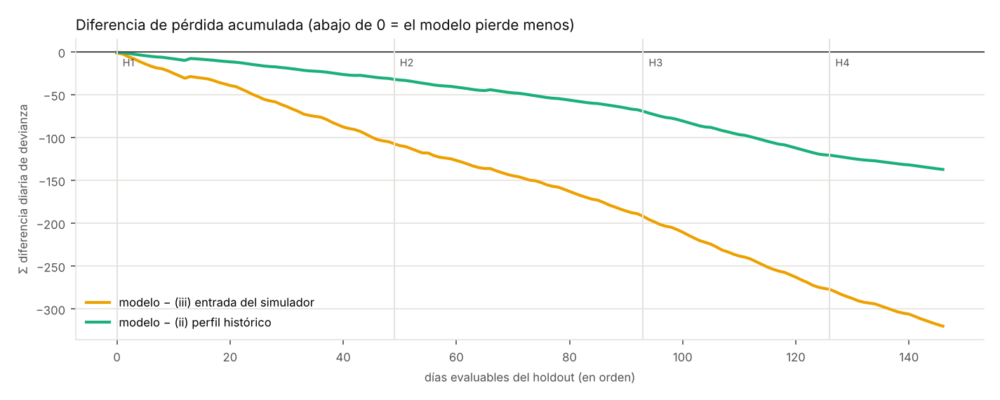

In [8]:
tabla('holdout/dm_holdout_e2c_5.csv')
fig('holdout/figuras/dm_acumulado_e2c_5.png')

## e2c.5.8 · Entrega al simulador

In [9]:
tabla('holdout/simulador_suma_ruta_hora_e2c_5.csv', 12)
import pyarrow.parquet as pq
print(pq.ParquetFile(D / 'holdout/prediccion_e2c_para_simulador.parquet').metadata)

,idruta,hora,lambda_pred_h,lambda_iii_h,lambda_real_h,razon_e2c_iii,razon_e2c_real,razon_iii_real
0,2,4,3296.536935,3744.201527,3214.0,0.880438,1.025680,1.164966
1,2,5,50268.271861,49615.685222,50743.0,1.013153,0.990644,0.977784
2,2,6,103190.380468,100146.308193,103910.0,1.030396,0.993075,0.963779
3,2,7,98420.056648,121710.771146,94855.0,0.808639,1.037584,1.283124
4,2,8,81959.518408,93065.274878,78655.0,0.880667,1.042013,1.183209
5,2,9,80342.375893,79397.323636,76489.0,1.011903,1.050378,1.038023
6,2,10,75351.077944,88266.704905,70642.0,0.853675,1.066661,1.249493
7,2,11,75929.271620,91737.890477,71112.0,0.827676,1.067742,1.290048
8,2,12,86350.714453,85591.573484,83189.0,1.008869,1.038006,1.028881
9,2,13,79858.134721,82924.644126,76781.0,0.963021,1.040077,1.080015


  created_by: parquet-cpp-arrow version 26.0.1
  num_columns: 16
  num_rows: 1605760
  num_row_groups: 2
  format_version: 2.6
  serialized_size: 10183


## Pruebas y checks

In [10]:
tabla('holdout/tests_e2c_5.csv')
checks(5)

,prueba,estado,detalle
0,a · hash de la decisión en los modelos y en la confirmación de PC2,PASS,7 modelos con 55bcf5bdc065…
1,b · el holdout se evaluó una sola vez,PASS,registro 2026-11-19T07:01:43 → 2026-11-19T07:39:59; un segundo --evaluar termina con: ...
2,c · entrenamiento final cerrado antes del corte,PASS,"843,807 filas 2023-02-18 04:00:00 → 2024-12-29 23:00:00; corte 2025-02-15 04:00:00; 29..."
3,d · aditividad de TreeSHAP,PASS,"máx |Σ SHAP − margen| = 1.2e-13 en 6,000 filas"
4,e · entrega al simulador completa y comparable con la (iii),PASS,208 días × 7.720 celdas; 6 días de la 13.1; Σ e2c / Σ (iii) = 0.9605 (ruta × hora: 0.1...
5,f · predicciones guardadas = modelo congelado,PASS,5.000 filas; diferencia máxima 0.0e+00
6,g · (iii) del holdout conserva el pronóstico del e1c,PASS,208 días; error relativo máx. 1.6e-08 (≤ redondeo de las fracciones 3.2e-07); salidas ...


,check,descripcion,estado,detalle
0,Ta,hash de la decisión en los modelos y en la confirmación de PC2,PASS,7 modelos con 55bcf5bdc065…
1,Tb,el holdout se evaluó una sola vez,PASS,registro 2026-11-19T07:01:43 → 2026-11-19T07:39:59; un segundo --evaluar termina con: ...
2,Tc,entrenamiento final cerrado antes del corte,PASS,"843,807 filas 2023-02-18 04:00:00 → 2024-12-29 23:00:00; corte 2025-02-15 04:00:00; 29..."
3,Td,aditividad de TreeSHAP,PASS,"máx |Σ SHAP − margen| = 1.2e-13 en 6,000 filas"
4,Te,entrega al simulador completa y comparable con la (iii),PASS,208 días × 7.720 celdas; 6 días de la 13.1; Σ e2c / Σ (iii) = 0.9605 (ruta × hora: 0.1...
5,Tf,predicciones guardadas = modelo congelado,PASS,5.000 filas; diferencia máxima 0.0e+00
6,Tg,(iii) del holdout conserva el pronóstico del e1c,PASS,208 días; error relativo máx. 1.6e-08 (≤ redondeo de las fracciones 3.2e-07); salidas ...
7,H1,Menor devianza que la (iii) en el holdout y en ≥ 3 de 4 bloques,PASS,modelo 1.4605 frente a (iii) 3.6266 (+59.7 %); bloques 4/4
8,H2,"Diebold-Mariano diario frente a la (iii): p calibrado (Holm) < 0,05",PASS,"n = 147 días, rezago 25, DM-HLN -20.28, p calibrado 0.0001 (Holm 0.0002); IC95 bootstr..."
9,H2b,"Diebold-Mariano diario frente al perfil (ii) (descriptivo, entra en Holm)",PASS,"DM-HLN -6.93, p calibrado 0.0095 (Holm 0.0095)"


{'PASS': 11, 'INFO': 5}


**Conclusión e2c.5 · En el holdout 2025 (H1–H4, evaluación única), el modelo 04:00 tiene una devianza de 1,460, frente a 3,627 de la entrada actual del simulador (iii): −59,7 %, mejor en los 4 bloques y significativo (DM con p calibrado 0,0001, Holm 0,0002). También le gana al perfil histórico (2,388; −38,9 %, p calibrado 0,0095). La mayor ganancia está en la punta de la mañana laboral, de 6 a 9 h (1,86 frente a 9,44, −80 %), justo donde fallaba el simulador. El holdout queda a +0,09 desviaciones de la CV (1,448 ± 0,141), así que no hay sobreajuste. Sin embargo, en los residuos queda estructura espacial (Moran significativo en 14 de 18 franjas × tipo).**

<a id="s5"></a>

---

# 5 · Qué se hace con el pronóstico

El pronóstico de las 04:00 es la entrada común de tres usos. Cada uno está completo en el Anexo A2; aquí va solo lo que recibe y lo que resultó.

| Quién lo usa | Qué toma del pronóstico | Resultado | Dónde |
|---|---|---|---|
| **Simulador** (Módulo 13) | ŷ(i,t) como llegadas de pasajeros a cada segmento y hora, en lugar del reparto fijo | Le gana al perfil histórico en **3 de 6 días** nuevos; el criterio pedía 5. Con la demanda real del día da 2 de 6: **la falla es del motor** (las bajadas salen de un reparto fijo), no del pronóstico ni de la medición ([6.1](#s6)). Corregir la salida de la terminal mejora 5 de 6 días, pero sigue en 3 de 6 ([6.13](#s6)) | [A2 · e2c.6](#e2c-7) |
| **Redespacho de flota** (Módulo 14, MILP) | La demanda por segmento × hora de los tramos que solo atiende una ruta y de los compartidos, por ventana de 15 min | Demostración con ŷ del día: sin tocar el modelo ni su configuración (huella `b16973cb…`) | [A2 · M14](#m14) |
| **Planeación de la frecuencia** (Módulo 15) | El pronóstico de las 04:00 para el plan fijo del día, más lo que van contando los sensores para recalcular cada 30 o 60 min | El plan fijo de las 04:00 con la regla de carga máxima: **+14,12 / +11,90 / +5,37 M COP/día** (laboral / sábado / domingo) frente al plan real, con 95 / 80 / 33 salidas menos. La cascada elegida suma más, y con la tarifa de 3.700 COP queda en **+15,79 / +12,44 / +7,34 M** ([6.4](#s6)) | [A2 · M15](#m15) |

**Advertencias que acompañan estas cifras:**
- el simulador sirve para **comparar estrategias entre sí** con las mismas semillas, no como medida absoluta de ocupación;
- los pesos del Módulo 15 (3.000 COP por km y 100 COP por minuto de espera) son **supuestos metodológicos**. La tarifa ya entra en la sección 6.4. El costo por km y la fracción que abandona quedan como variables: con los valores reales se recalcula sin simular;
- el pronóstico no da la frecuencia por sí solo: la frecuencia sale de aplicarle la regla de carga máxima (Módulos 13 y 15).

**Lo que falta para operarlo:**
- un proceso diario que emita el pronóstico a las 04:00 contra la base;
- conectar a ese proceso la guarda de emisión (ya hecha, [6.3](#s6));
- los calendarios ya cubren todo 2027 (festivos, Carnaval y receso escolar), y las variables de calendario de la emisión salen de `calendario_vigente.py`.


<a id="s6"></a>

---

# 6 · Mediciones y correcciones de la entrega final

Lo que se midió y corrigió después de la calificación, sin reentrenar y sin tocar ningún archivo congelado. Las únicas simulaciones nuevas son la validación del plan de operación del día (6.12) y la re-evaluación del motor del simulador (6.13). Cada medición tiene su regla, congelada con hash **antes** de calcular. Lo que se mide sobre los días de validación del simulador o sobre el holdout 2025 está rotulado **«no ciego»** y no cambia ninguna cifra oficial. El detalle está en `correccion_final/fase*/RESULTADOS_FASE*.md`.


In [11]:
# Sección 6: lee las salidas de correccion_final/ (Fases 1–6). No simula, no entrena, no re-evalúa.
CF = RAIZ / 'correccion_final'
def leer_json(p): return json.loads((CF / p).read_text(encoding='utf-8'))
print({f: sorted(x.name for x in (CF / f).glob('*.md')) for f in ('fase1', 'fase2', 'fase4', 'fase5', 'fase6', 'parte1')})

{'fase1': ['RESULTADOS_FASE1.md'], 'fase2': ['RESULTADOS_FASE2.md'], 'fase4': ['RESULTADOS_FASE4.md'], 'fase5': ['RESULTADOS_FASE5.md'], 'fase6': ['DOCUMENTACION_VEHICULAR_F6.md'], 'parte1': ['RESULTADOS_PARTE1.md', 'SERVICIOS_EXTERNOS_P1.md']}


### 6.1 · El hueco de la mañana del simulador es del motor, no de la medición (Fase 1.1)

Con la demanda real del día, el simulador lleva de 1,5 a 6,3 pasajeros menos a bordo que el sensor entre las 6 y las 9 h. La pregunta era si eso es un defecto de la comparación.

**No lo es:**
- la demanda real que recibe el simulador está casi completa: le falta entre el 0,2 y el 2,8 % de las subidas del día (las de viajes inválidos o sin lecturas);
- el simulador sube el 98,2–99,8 % de esa demanda;
- el faltante explica entre el 0 y el 13 % del hueco, y la regla pedía al menos 50 % en 4 de 6 días;
- la medida principal ya usa la carga después de la parada, ponderada por tiempo, como el sensor.

**Hallazgo de paso:** el criterio secundario de pasajeros por viaje comparaba con la media de los viajes de la maestra, que deja fuera las salidas «canceladas» que operaron. Esas llevan 22–82 pasajeros por viaje, frente a 53–101. Bien referido, la entrada real queda dentro de ±10 % en las 18 combinaciones ruta × día; el e2c en 15 y el e1c en 12.


In [12]:
# 6.1 · ¿El hueco de 6 a 9 h del simulador es de medición o del motor? (regla congelada antes de calcular; NO CIEGA)
r11 = leer_json('fase1/salidas_1_1/resumen_1_1.json')
print(f"regla {r11['regla_sha256'][:12]}… · real_obs = subidas_validas del panel: {r11['real_obs_igual_subidas_validas']}")
print('faltante del insumo por día (%):', r11['delta_dia_%'])
print('el simulador sube del insumo (%):', r11['sim_sube_del_insumo_%'])
h = pd.read_csv(CF / 'fase1/salidas_1_1/hueco_6_9_dia_1_1.csv')
display(h[['rol', 'dia', 'obs', 'sim', 'sesgo', 'sesgo_corr_5_8', 'explicado_5_8_%']].round(2)
        .rename(columns={'obs': 'a bordo observado', 'sim': 'a bordo simulado (entrada real)', 'sesgo': 'hueco',
                         'sesgo_corr_5_8': 'hueco sin el faltante', 'explicado_5_8_%': '% del hueco que explica el faltante'}))
print(f"días con ≥ 50 % explicado: {r11['dias_validacion_con_explicado_5_8_>=50']} de 6 → criterio: "
      f"{'se cumple' if r11['criterio_insumo_explica_mayor_parte'] else 'NO se cumple: el hueco es del motor'}")
pv = pd.read_csv(CF / 'fase1/salidas_1_1/pasajeros_por_viaje_recalculado_1_1.csv')
t = pd.DataFrame({'dentro de ±10 % (como se publicó)': r11['pasajeros_por_viaje_dentro_10%_antes'],
                  'con todas las salidas válidas': r11['pasajeros_por_viaje_dentro_10%_con_todas_las_salidas']})
display(t.rename_axis('entrada (de 18 ruta × día)'))

regla 70ed065a4a5a… · real_obs = subidas_validas del panel: True
faltante del insumo por día (%): {'control_domingo 2025-11-09': 0.63, 'control_laboral 2025-08-19': 1.16, 'control_sabado 2025-09-20': 0.66, 'domingo 2025-11-23': 0.81, 'evento_masivo 2025-09-04': 2.76, 'laboral_1 2025-03-12': 2.14, 'laboral_2 2025-11-27': 0.25, 'lluvia_fuerte 2025-09-05': 2.66, 'sabado 2025-11-22': 0.39}
el simulador sube del insumo (%): [98.2, 99.8]


,rol,dia,a bordo observado,a bordo simulado (entrada real),hueco,hueco sin el faltante,% del hueco que explica el faltante
0,domingo,2025-11-23,8.21,6.73,-1.48,-1.38,6.73
1,evento_masivo,2025-09-04,20.87,14.84,-6.03,-5.23,13.22
2,laboral_1,2025-03-12,21.11,14.86,-6.25,-5.81,7.12
3,laboral_2,2025-11-27,17.25,12.88,-4.37,-4.37,0.00
4,lluvia_fuerte,2025-09-05,20.35,14.15,-6.20,-5.69,8.16
5,sabado,2025-11-22,14.98,12.31,-2.67,-2.52,5.45


días con ≥ 50 % explicado: 0 de 6 → criterio: NO se cumple: el hueco es del motor


,dentro de ±10 % (como se publicó),con todas las salidas válidas
entrada (de 18 ruta × día),,
e1c,17,12
e2c,18,15
real_obs,14,18


### 6.2 · El e2c sirve más que el e1c a la escala de la frecuencia (Fase 1.2)

El e1c entra como lo usa la operación: el modelo por viaje llevado a la red con el reparto fijo de la 13.1. Se suman predicciones y observaciones sobre las mismas celdas del holdout y se compara con WAPE.

- **Por ruta y hora:** 10,5 % del e2c frente a 16,6 % del e1c y 14,0 % del perfil. Al e1c le gana en los 4 bloques y en la punta laboral (10,8 frente a 19,7 %); al perfil, en 3 de 4 (en H1 empatan).
- **Por ruta y día:** casi empatan (7,4 frente a 7,9 %). Lo que aporta el e2c es cómo reparte la demanda dentro del día y a lo largo de la ruta, no el total del día.
- **Carnaval:** el e2c subpredice un 27 % y el e1c lo hace mucho mejor (WAPE por ruta y día 28,3 frente a 5,4 %).


In [13]:
# 6.2 · e2c frente a e1c (llevado a la red) en la misma escala · WAPE (%) en el holdout 2025 (NO CIEGA)
e = pd.read_csv(CF / 'fase1/salidas_1_2/e2c_vs_e1c_1_2.csv')
sel = e[(e.corte.isin(['global', 'punta', 'tipo_dia_cal'])) & (e.valor.isin(['global', '6–9 h laboral', 'carnaval']))]
display(sel[['escala', 'corte', 'valor', 'wape_principal', 'wape_iii_simulador', 'wape_ii_perfil', 'wape_i_ingenua', 'sesgo_principal', 'sesgo_iii_simulador']]
        .rename(columns={'wape_principal': 'e2c', 'wape_iii_simulador': 'e1c en la red', 'wape_ii_perfil': 'perfil', 'wape_i_ingenua': 'ingenua',
                         'sesgo_principal': 'sesgo e2c %', 'sesgo_iii_simulador': 'sesgo e1c %'}).round(2).set_index(['escala', 'corte', 'valor']))
b = e[(e.escala == 'ruta × hora') & (e.corte == 'bloque')][['valor', 'wape_principal', 'wape_iii_simulador', 'wape_ii_perfil']]
display(b.rename(columns={'valor': 'bloque', 'wape_principal': 'e2c', 'wape_iii_simulador': 'e1c en la red', 'wape_ii_perfil': 'perfil'}).round(2).set_index('bloque'))
print(leer_json('fase1/salidas_1_2/resumen_1_2.json'))

e2c  e1c en la red  perfil  ingenua  sesgo e2c %  sesgo e1c %
escala      corte        valor                                                                         
nodo × hora global       global         39.55          59.55   50.68    52.14         2.91         7.14
            tipo_dia_cal carnaval       69.06          75.23   75.33   135.00       -27.33        -0.55
            punta        6–9 h laboral  35.33          66.49   52.68    45.44         2.58        14.33
ruta × hora global       global         10.53          16.64   14.00    14.89         2.91         7.14
            tipo_dia_cal carnaval       33.10          16.85   32.92    90.37       -27.33        -0.55
            punta        6–9 h laboral  10.83          19.72   15.01    13.71         2.58        14.33
ruta × día  global       global          7.42           7.86   11.10     9.66         2.91         7.14
            tipo_dia_cal carnaval       28.33           5.41   28.72    84.00       -27.33        -0.55

,e2c,e1c en la red,perfil
bloque,,,
H1,10.45,15.73,10.37
H2,12.05,17.37,19.82
H3,9.64,16.65,12.04
H4,9.09,17.35,14.23


{'regla_sha256': 'f4fdbff4a6989304374dc6b22854303a056b873c636bd5545e503316375a488f', 'bloques_e2c_gana_ruta_hora': 4, 'punta_e2c_gana_ruta_hora': True, 'veredicto': 'e2c'}


### 6.3 · Calendario 2026 y guarda al emitir (Fases 2.1 y 2.2)

- **`datos_e2c/calendario/calendario_dias_2023_2026.csv`:** el calendario de la Persona 2 sin cambios, más 2026, con la fuente de cada fecha.
  - 19 festivos, incluido el nuevo de la **Ley 2578 de 2026**: el 9 de julio (Virgen de Chiquinquirá), que en 2026 se descansa el lunes 13.
  - Carnaval del 14 al 17 de febrero.
  - El calendario escolar llegaba hasta el 27-dic-2026: la resolución de 2027 de Barranquilla no estaba publicada en línea. Emitir después de esa fecha **bloqueaba**, en vez de suponer días lectivos.
  - **Actualizado en la parte 2:** la Persona 3 consiguió la **Resolución 04745 del 29-oct-2026**. Su receso estudiantil (12 semanas en 5 periodos, del 28-dic-2026 al 26-dic-2027) se cargó en `calendario_escolar_barranquilla_2023_2027.csv`, así que la emisión ya cubre **todo 2027**.
- **Ampliado a 2027 (pendientes, parte 1.2):** `calendario_dias_2023_2027.csv` contiene el de 2023–2026 sin tocar una línea y agrega los 19 festivos de 2027 (el de Chiquinquirá se descansa el lunes 12 de julio) y el Carnaval del 6 al 9 de febrero, con fuente por fecha.
- **Conectado a la emisión (parte 1.1):** `calendario_vigente.py` da las variables de calendario de cualquier fecha cubierta con las mismas columnas del panel, y la guarda lo usa. En los 397 días del panel reproduce exactamente las columnas de calendario. Nunca rellena: sin calendario de días o escolar, lanza un error. `panel_e2c_1.py` y el simulador no se tocaron, porque son código congelado con hash.
- **`correccion_final/fase2/guarda_emision_e2c.py`:** antes de emitir comprueba la cobertura de los calendarios y el % de filas fuera del rango de entrenamiento por variable, comparando en el tipo de la columna. Decide OK, AVISO o BLOQUEO.
  - Con una variable como `tendencia_meses` da BLOQUEO.
  - En los 208 días de 2025 no bloquea ninguno.


In [14]:
# 6.3 · Calendario 2026 y guarda al emitir
cal = pd.read_csv(RAIZ / 'datos_e2c/calendario/calendario_dias_2023_2026.csv')
c26 = cal[cal.fecha.str.startswith('2026')]
print(f"2026: {len(c26)} filas · {int(c26.es_festivo.sum())} festivos · {int(c26.es_carnaval.sum())} días de Carnaval · "
      f"nulos en es_festivo/es_carnaval: {int(c26.es_festivo.isna().sum())}/{int(c26.es_carnaval.isna().sum())}")
fu = pd.read_csv(RAIZ / 'datos_e2c/calendario/fuentes_calendario_2026.csv')
display(fu[['fecha', 'nombre_festivo', 'nombre_carnaval', 'tipo_dia_cal']].set_index('fecha'))
display(pd.read_csv(CF / 'fase2/salidas_2_2/tests_guarda_f2.csv'))

2026: 365 filas · 19 festivos · 4 días de Carnaval · nulos en es_festivo/es_carnaval: 0/0


,nombre_festivo,nombre_carnaval,tipo_dia_cal
fecha,,,
2026-01-01,Año Nuevo,NaN,festivo
2026-01-12,Reyes Magos,NaN,festivo
2026-02-14,NaN,Sábado de Carnaval,carnaval
2026-02-15,NaN,Domingo de Carnaval,carnaval
2026-02-16,NaN,Lunes de Carnaval,carnaval
2026-02-17,NaN,Martes de Carnaval,carnaval
2026-03-23,San José,NaN,festivo
2026-04-02,Jueves Santo,NaN,festivo
2026-04-03,Viernes Santo,NaN,festivo


,prueba,estado,detalle
0,a · reproduce la guarda del holdout e2c.5,PASS,"31 variables, diferencia máxima 0.0000 pp; fuera: ['y_media_1d', 'y_media_7d', 'y_sd_1d', 'y_sd_7d']"
1,b · hora_cos (float32) no sale fuera por redondeo,PASS,"sin ajuste 5.38 % «fuera»; con la comparación en float32, 0 %"
2,c · variable monótona fuera de rango → BLOQUEO,PASS,"tendencia_meses = 26.3 meses frente a un máximo de 23,97 → 100 % fuera → BLOQUEO"
3,"d · días de 2025: ninguno BLOQUEO por rango (descriptivo, no ciego)",PASS,"208 días de H1–H4: {'OK': 136, 'AVISO': 72}; AVISO por causa {'nulos': 72}, de ellos 56 en días de calentamiento (rezagos incompletos al..."
4,e · fechas sin calendario → BLOQUEO,PASS,2027-12-27: cobertura: calendario escolar: 1 fechas sin calendario escolar cargado (2027-12-27 … 2027-… · 2028-01-03: cobertura: 2028-01...
5,f · 2026 cubierto: Carnaval y el festivo nuevo,PASS,2026-02-16 carnaval · 2026-07-13 festivo · 2026-07-09 laboral · escolar hasta 2027-12-26


### 6.4 · Cascada sin 15 min y P&L con tarifa (Fases 2.4 y 4)

- **Cascada sin 15 min:** la configuración operativa nueva, `modulo15/config/cascada_15_3_v2.yaml`, solo usa 30 y 60 min. La de 15 min rendía menos que el plan fijo en sábado (−2,51 M COP/día) y domingo (−0,27 M). La v1 queda intacta como la configuración de la evaluación oficial.
- **Tarifa:** con la tarifa de 3.700 COP (la oficial del transporte colectivo desde el 19-ene-2026) la ganancia de la estrategia elegida baja muy poco y ninguna elección cambia:

| Tipo de día | Sin tarifa (oficial) | Con tarifa |
|---|---:|---:|
| Laboral | 16,19 M | 15,79 M |
| Sábado | 12,76 M | 12,44 M |
| Domingo | 7,58 M | 7,34 M |

La tarifa pesa poco porque en el simulador quien se queda por bus lleno toma el siguiente bus y paga igual. El supuesto que sí importa es cuántos de esos se van en otro medio: si fueran todos, el laboral bajaría a 13,33 M.

**El costo por km y la fracción que abandona son variables del cálculo**, con valores por defecto de 3.000 COP y 0 %. `correccion_final/fase4/pyg_parametrico_f4.py` recalcula la elección y la ganancia con cualquier valor, sin simular. La rejilla completa está en `tabla_km_abandono_f4.csv`: km de 2.000 a 4.500 COP × abandono de 0 a 100 %.

En 46 combinaciones de precios, la elección no cambia en las 46 del domingo ni en 43 del laboral. En el sábado alterna entre la cascada de 30 min con y sin MILP, que ya estaban casi empatadas. Ninguna combinación elige 15 min y la ganancia nunca es negativa.


In [15]:
# 6.4 · P&L del despacho en cascada con tarifa (3.700 COP), sobre las 16.500 réplicas de la 15.4 (sin re-simular)
c = pd.read_csv(CF / 'fase4/salidas_4/central_pyg_f4.csv')
el = {'laboral': 'cascada_60', 'sabado': 'cascada_milp_30', 'domingo_festivo': 'cascada_60'}
t = c[[el[tp] == b for tp, b in zip(c.tipo, c.brazo)]].copy()
for k in ('ganancia_mediana_cop', 'ic_inf', 'ic_sup', 'ahorro_km_cop', 'costo_espera_cop', 'pasajes_cop'):
    t[k] = t[k] / 1e6
display(t[['tipo', 'brazo', 'ganancia_mediana_cop', 'ic_inf', 'ic_sup', 'ahorro_km_cop', 'costo_espera_cop', 'pasajes_cop', 'd_espera_min']]
        .round(2).set_index('tipo'))
s = pd.read_csv(CF / 'fase4/salidas_4/sensibilidad_pyg_f4.csv')
s = s[s.vista == 'todas']
display(s[(s.familia.str.startswith('tarifa')) & (s.tarifa == 3700) & (s.km_cop == 3000)]
        .pivot(index='p_abandono', columns='tipo', values='ganancia_mediana_cop').div(1e6).round(2)
        .rename_axis('fracción de dejados de más que abandona'))
display(s.groupby('tipo').agg(combinaciones=('cambia', 'size'), elección_igual_a_la_oficial=('cambia', lambda x: int((~x).sum())),
                              ganancia_min_M=('ganancia_mediana_cop', lambda x: round(x.min() / 1e6, 2)),
                              ganancia_max_M=('ganancia_mediana_cop', lambda x: round(x.max() / 1e6, 2)),
                              alguna_vez_15_min=('elegida', lambda x: bool(x.str.endswith('_15').any()))))

,brazo,ganancia_mediana_cop,ic_inf,ic_sup,ahorro_km_cop,costo_espera_cop,pasajes_cop,d_espera_min
tipo,,,,,,,,
domingo_festivo,cascada_60,7.34,7.04,7.60,9.00,1.53,-0.23,0.75
laboral,cascada_60,15.79,15.60,16.02,20.40,4.47,-0.30,0.97
sabado,cascada_milp_30,12.44,11.94,12.96,15.58,3.09,-0.27,0.85


tipo,domingo_festivo,laboral,sabado
fracción de dejados de más que abandona,,,
0.00,7.34,15.79,12.44
0.25,7.41,15.21,12.16
0.50,7.40,14.58,11.85
1.00,7.41,13.33,11.40


,combinaciones,elección_igual_a_la_oficial,ganancia_min_M,ganancia_max_M,alguna_vez_15_min
tipo,,,,,
domingo_festivo,46,46,3.02,11.73,False
laboral,46,43,5.10,26.84,False
sabado,46,23,5.23,20.74,False


### 6.5 · Mejoras baratas del pronóstico (Fase 5): ninguna se adopta

Se probaron **solo en la validación 2023–2024**, sin reentrenar y sin tocar el holdout 2025 (regla `regla_mejoras_f5.json`, congelada antes de calcular). El criterio pedía mejorar la devianza ≥ 1 % en promedio y en los 3 pliegues P2–P4.

- **Recalibrar el nivel** (ŷ × Σy/Σŷ de los pliegues anteriores, lo único que se sabría al emitir), global, por tipo de día o por ruta × franja: **empeora** en promedio (+0,57 %, +0,36 % y +0,62 %). El sesgo del modelo cambia de signo de un pliegue a otro (−3,6 %, +2,8 %, +1,6 %), así que corregirlo con el pasado lo empuja al lado equivocado. El +2,9 % de 2025 no es un sesgo estable.
- **Carnaval:** en el Carnaval 2024 (validación) el modelo va bien: devianza 1,65 frente a 2,23 del perfil y 2,43 de la (iii), sesgo −2,5 %. En el Carnaval 2025 SOBUSA programó ~20–23 % menos oferta que en 2023–2024 y las subidas bajaron solo 12–16 % (dato descriptivo del panel). Es un recorte que el modelo nunca vio y no hay otro caso para validar una corrección: queda como limitación. Sugerencia operativa: que la guarda avise cuando la oferta planeada del día caiga mucho para su tipo de día.
- **No se corrieron:** promediar semillas (no hay predicciones de validación por semilla y su efecto, < 0,8 %, es ruido) ni cambiar el grafo (ya probado en el e2c.4).


In [16]:
# 6.5 · Recalibración del nivel, evaluada solo en la validación (P2–P4); positivo = peor que el modelo sin recalibrar
r = pd.read_csv(CF / 'fase5/salidas_5/recalibracion_f5.csv')
display(r[['pliegue', 'previos', 'dev_modelo', 'sesgo_modelo_%', 'mejora_A1_nivel_global_%', 'mejora_A2_nivel_tipo_dia_%',
           'mejora_A3_nivel_ruta_franja_%']].round(3).set_index('pliegue'))
print(leer_json('fase5/salidas_5/resumen_f5.json')['candidatos'], '· adoptado:', leer_json('fase5/salidas_5/resumen_f5.json')['adoptado'])
display(pd.read_csv(CF / 'fase5/salidas_5/carnaval_validacion_f5.csv').query("pliegue == 'P2'").round(3))

,previos,dev_modelo,sesgo_modelo_%,mejora_A1_nivel_global_%,mejora_A2_nivel_tipo_dia_%,mejora_A3_nivel_ruta_franja_%
pliegue,,,,,,
P2,P1,1.354,-3.574,1.859,1.164,1.957
P3,P1+P2,1.610,2.761,0.039,0.516,0.047
P4,P1+P2+P3,1.520,1.594,-0.026,-0.511,0.029


{'A1_nivel_global': {'mejora_media_%': 0.5665116384705904, 'pliegues_que_mejora': 1, 'cumple': False}, 'A2_nivel_tipo_dia': {'mejora_media_%': 0.36313970214527647, 'pliegues_que_mejora': 1, 'cumple': False}, 'A3_nivel_ruta_franja': {'mejora_media_%': 0.6173323634363959, 'pliegues_que_mejora': 0, 'cumple': False}} · adoptado: None


,pliegue,dias,filas,dev_modelo,dev_perfil,dev_iii,sesgo_modelo_%,sesgo_perfil_%,sesgo_iii_%
0,P2,"['2024-02-10', '2024-02-11', '2024-02-12', '2024-02-13']",28011,1.65,2.227,2.43,-2.549,1.245,4.815


### 6.6 · Documentación vehicular (Fase 6)

En `vehiculos`, las fechas de SOAT, tecnomecánica, inspección y póliza están **100 % vacías** en los 656 buses, y el reporte de flota no trae fechas. Queda como **limitación** del proyecto: **no se imputó ninguna fecha** (`correccion_final/fase6/DOCUMENTACION_VEHICULAR_F6.md`).

### 6.7 · Qué no alcanzó su criterio

| Qué | Criterio | Resultado |
|---|---|---|
| Simulador (e2c.6) | ≤ perfil histórico en 5 de 6 días | **3 de 6**. La Fase 1.1 descarta que sea un problema de medición: la falla es del motor (las bajadas salen de un reparto fijo) |
| Lag espacial (e2c.4, C2) | Que quitarlo empeore de forma consistente en la validación | No: +0,16 % en 2 de 4 pliegues. En el holdout, +1,6 % en 4 de 4 |
| Calendario escolar 2027 | Extenderlo más allá del 27-dic-2026 | **Hecho en la parte 2** con la Res. 04745 de 2026, que no estaba en línea: cobertura hasta el 26-dic-2027 |
| Carnaval | — | El único corte donde el e2c pierde con el perfil y con el e1c (en 2025). En la validación 2024 iba bien; 2025 tuvo un recorte de oferta nunca visto (sección 6.5) |
| Mejoras del pronóstico (Fase 5) | Mejorar la devianza de validación ≥ 1 % y en P2–P4 | Ninguna: recalibrar el nivel empeora (+0,36 a +0,62 %) |
| Fase 3 (instrumentar el motor del simulador) | — | No se hizo. Es opcional en el plan y no cambia ninguna conclusión |


### 6.8 · Recaudo con la tarifa de cada año (pendientes, parte 1.4)

El Módulo 1 estimó el recaudo como pasajeros × **3.700 COP en los tres años**, por decisión de gerencia. Pero 3.700 es la tarifa del transporte colectivo **solo desde el 19-ene-2026**. Las tarifas que rigieron fueron:

| Desde | Días ordinarios | Domingos y festivos |
|---|---:|---:|
| 2023 | 2.600 | 2.700 (inferida) |
| 1-mar-2023 | 2.800 | 2.900 |
| 15-feb-2024 | 3.100 | 3.200 |
| 2025 | 3.300 | 3.400 |

Fuentes: El Heraldo, Publimetro, Noticias Caracol, La República y Cambio. El detalle está en `correccion_final/parte1/salidas_p1/tarifas_tpc_barranquilla_p1.csv`.

Con la tarifa de cada día, **el recaudo esperado no cae: se mantiene en unos 42.300–42.800 millones de COP al año** (2023 → 2025). Con 3.700 fijos parecía bajar de 56.491 a 47.338 millones. **Los pasajeros sí caen un 16 %**, pero las alzas de tarifa lo compensan. El costo por varada del M9 se reduce en la misma proporción: en 2025, unos 148 mil COP por varada en vez de 165 mil.

Es una corrección descriptiva: no cambia la maestra, ni el modelo, ni ninguna decisión. Las celdas originales del M1 y del M9 se conservan tal cual (con MD5 iguales).


In [17]:
# 6.8 · Recaudo esperado con la tarifa vigente de cada día frente a 3.700 COP fijos (descriptivo; no cambia la maestra)
r = pd.read_csv(CF / 'parte1/salidas_p1/recaudo_tarifa_vigente_p1.csv')
display(r[r.escenario == 'central'][['anio', 'pasajeros', 'recaudo_3700_M', 'recaudo_tarifa_vigente_M', 'tarifa_media_ponderada', 'sobrestimacion_%']]
        .round(1).set_index('anio'))
display(pd.read_csv(CF / 'parte1/salidas_p1/varadas_m9_tarifa_vigente_p1.csv').round(3).set_index('anio'))
print('Sensibilidad (SOBUSA entra al SIBUS en julio de 2024 y no en febrero):',
      r[(r.escenario == 'sibus_julio') & (r.anio == 2024)].recaudo_tarifa_vigente_M.round(0).tolist(), 'M COP en 2024')
display(pd.read_csv(CF / 'parte1/salidas_p1/tests_calendario_p1.csv'))

,pasajeros,recaudo_3700_M,recaudo_tarifa_vigente_M,tarifa_media_ponderada,sobrestimacion_%
anio,,,,,
2023,15267763,56490.7,42400.9,2777.2,33.2
2024,13933236,51553.0,42816.2,3073.0,20.4
2025,12794072,47338.1,42334.6,3308.9,11.8


,total_3700_M,factor,total_tarifa_vigente_M
anio,,,
2023,96.7,0.751,72.581
2024,135.9,0.831,112.869
2025,161.9,0.894,144.788


Sensibilidad (SOBUSA entra al SIBUS en julio de 2024 y no en febrero): [41144.0] M COP en 2024


,prueba,estado,detalle
0,a · no regresión frente al panel e2c (397 días),PASS,397 días × 9 columnas idénticas; calendario usado: calendario_dias_2023_2027.csv
1,b · 2023–2027 contiene sin cambios a la Persona 2 y a 2023–2026,PASS,1096 filas de la Persona 2 y 1461 de 2023–2026 idénticas; total 1826
2,"c · 2026: Carnaval, festivo nuevo y receso",PASS,2026-02-16 carnaval · 2026-07-13 festivo · 2026-07-09 laboral · 2026-06-25 receso de mitad de año
3,d · 2027: días y escolar cubiertos; 2027-12-27 sin escolar → CoberturaCalendarioError,PASS,"2027: carnaval 8-feb; receso 4-ene, 23-mar (Semana Santa), 9-jul y 12-oct; 12-jul festivo sin receso; 2027-12-27: 1 fechas sin calendari..."
4,e · 2028: sin calendario de días → CoberturaDiasError,PASS,1 fechas sin calendario de días (2028-01-03 … 2028-01-03); último día cargado 2027-12-31 en calendario_dias_20…
5,f · la guarda usa el calendario más largo,PASS,2027-12-27: calendario escolar: 1 fechas sin calendario escolar cargado … · 2028-01-03: 2028-01-03 no está en el calendario_dias (calend...


### 6.9 · Servicios externos: planes usados y sus límites (pendientes, parte 1.3)

El proyecto usó **cuentas y planes personales o gratuitos**. Las condiciones de abajo se consultaron en las páginas de cada proveedor el 20-nov-2026.

| Servicio | Dónde | Plan y uso | Condición vigente del proveedor |
|---|---|---|---|
| API de Claude (Haiku 5.5) | M10 | Cuenta personal con límite de gasto de USD 20; **USD 0,113** en todo el módulo | Niveles con tope mensual de USD 500 / 1.000 / 200.000; nivel Custom sin tope y nivel Priority con mejores garantías de servicio |
| Google Routes API (*Compute Routes Pro*) | M11 | Uso gratuito: **4.998 llamadas**, USD 0, una fecha por unidad muestral | 5.000 solicitudes gratis al mes por SKU Pro; luego se cobra por cada 1.000 |
| Open-Meteo | M11 | API gratuita | Gratis **solo para uso no comercial** (< 10.000 llamadas al día); el uso comercial requiere suscripción |
| API-Football | M10 | Plan gratuito: solo trajo 2022–2024; **2025–2026 salió de prensa y ESPN** | 100 solicitudes al día; el Pro, 7.500 |
| OpenStreetMap (Overpass) | M10 | Servidores públicos | Licencia ODbL con atribución; sin garantía de servicio |
| Mapas base de CARTO | M13 (gemelo) | Gratis, sin clave | Gratis para uso no comercial; **ahora exigen una clave de API**: revisar el fondo del gemelo antes de presentarlo |

**El uso de cualquiera de estas API sería mucho mejor con planes empresariales o pro.** Habría:
- más consultas y muestras repetidas en el tiempo;
- latencia con garantía de servicio;
- corridas sin interrupciones: el 23-oct-2026 una corrida del consejo asesor se cortó por el límite de uso de la sesión;
- licencia comercial, que SOBUSA necesitaría para operar con Open-Meteo y CARTO.

Los resultados de los módulos 10, 11 y 13 quedan condicionados por esos límites. El detalle y las fuentes están en `correccion_final/parte1/SERVICIOS_EXTERNOS_P1.md`.


### 6.10 · Cómo se configuraron los optimizadores de la 15.1b (guía del curso, sección 3.3)

La batería de la 15.1b les dio a los cuatro optimizadores el mismo presupuesto: 24 evaluaciones por modelo. Cada evaluación corre el pipeline completo, con el preprocesamiento ajustado solo con el entrenamiento del pliegue. Está en `modulo15/src/ml/optimizadores.py`.

- **Bayesiano (Optuna TPE).**
  - Sustituto: dos estimadores de Parzen en árbol, l(x) sobre el 25 % mejor de lo evaluado y g(x) sobre el resto, multivariados.
  - Adquisición: de 24 candidatos tomados de l(x), se evalúa el que maximiza l(x)/g(x), que es monótono en la **mejora esperada** (Bergstra et al., 2011).
  - Las 6 primeras evaluaciones son al azar (exploración). Después la razón explota cerca de lo mejor, y las colas de l(x) mantienen algo de exploración.
- **Genético (DEAP).**
  - Selección por **torneo de 3**, cruce de mezcla BLX-0,5 con probabilidad 0,7 y mutación gaussiana σ = 0,15 (0,3 por individuo y 0,3 por gen).
  - **Élite de 2** y **población de 8**: con 24 evaluaciones salen 3 generaciones nuevas (8 + 6 + 6 + 4). La población de 12 del alcance dejaba 1,2 generaciones (decisión B1).
  - Se registró la diversidad por generación. Cayó un **77 % en 3 generaciones**: convergencia prematura, reportada como hallazgo.
- **Hyperband.** Successive halving con η = 3 y fidelidades R/9, R/3 y R, en número de árboles o épocas de la red. El costo se cuenta en evaluaciones completas equivalentes.
- **Resultado.** Con el mismo presupuesto, el bayesiano encuentra mejores configuraciones internas que el azar en el 83 % de los casos (p < 0,0001). En la prueba, los cuatro empatan (Friedman p 0,062).


### 6.11 · Calendario escolar 2027, partidos, nowcast y copia publicada sin datos de conexión (pendientes, parte 2)

- **Calendario escolar 2027.** Se cargó la Resolución 04745 de 2026 (art. 4, receso estudiantil) en `datos_e2/calendario_escolar_barranquilla_2023_2027.csv`. El archivo de 2023–2026 tiene hash en el manifiesto e2c, así que no se tocó: el nuevo lo contiene sin cambiar una línea.

  | Periodo de receso 2027 | Desde | Hasta |
  |---|---|---|
  | Inicio de año | 28-dic-2026 | 24-ene-2027 |
  | Semana Santa | 22-mar-2027 | 28-mar-2027 |
  | Mitad de año | 21-jun-2027 | 11-jul-2027 |
  | Receso de octubre | 11-oct-2027 | 17-oct-2027 |
  | Fin de año | 6-dic-2027 | 26-dic-2027 |

  La emisión ya cubre todo 2027 y la guarda bloquea desde el 27-dic-2027.
- **Partidos (revisión barata, sin reentrenar).** En la validación hubo 8 partidos en el Metropolitano. En los 21 tramos a ≤ 800 m del estadio, durante la ventana del partido, las subidas superaron al pronóstico **+15,2 % más que en días sin partido** (IC 90 % [+8,6; +20,1]; positivo en 7 de 8). En toda la red, +0,4 %. El modelo no tiene esta variable: el plan de operación da un **aviso** esos días y deja el refuerzo de salidas como opción apagada (`correccion_final/parte2/salidas_partidos/`).
- **Nowcast.** La Persona 3 informó que en la base de SOBUSA los datos del sensor se actualizan en vivo. Con eso, el nowcast (subidas de 2 a 6 h antes) deja de ser solo referencia: queda como opción del plan de operación, apagada por defecto hasta medir su efecto en el despacho. Sus cifras no cambian (−3,4 % de devianza en el holdout frente al modelo de las 04:00); el oráculo (1 h antes) sigue siendo el techo.
- **Censura.** En esta copia se reemplazaron el servidor de la base (`<servidor-bd>`), su IP (`<ip>`), el usuario de la base (`<usuario-bd>`), los nombres de usuario de Windows en las rutas (`<usuario>`) y el nombre del equipo (`<equipo>`). Se hizo **después** de verificar las 1.223 celdas originales con MD5 y no toca ninguna cifra. El conteo está en `correccion_final/parte2/censura_notebook_final.json`.


### 6.12 · Plan de operación del día (lo único que se hace del Módulo 16)

**Qué es.** A las 04:00, para una fecha, `correccion_final/plan_despacho/plan_dia.py` hace cinco pasos:
- revisa que la fecha esté cubierta por los calendarios;
- lleva el plan típico del tipo de día a lo que el pronóstico e1c prevé para esa fecha;
- aplica la regla de carga máxima de la 15.1 en ventanas de 15 min;
- comprueba que alcancen los buses;
- da los avisos (partido, receso, festivo, Carnaval, días atípicos).

Deja la tabla de salidas por ruta y una hoja para imprimir. Durante el día, `operacion_dia.py` encadena la cascada y, en sábado, el MILP de La Playa.

**Todo es una propuesta para SOBUSA.** Cada pieza tiene un interruptor y su resultado con y sin ella. Por defecto van encendidos:
- el plan del día;
- la cascada (cada 60 min; el sábado, cada 30);
- el MILP de La Playa solo el sábado;
- el aviso de partido.

Quedan disponibles pero apagados: el MILP solo de terminal, el refuerzo de partido, el nowcast y el scoring de varadas.

**La demanda de la fecha.** Se usa la misma cuenta con la que la 13.4 lleva el día típico a una fecha: pasajeros previstos por viaje × salidas del día. En 353 días de 2025 que no son de validación se acerca al factor real **+33,6 %** más que no escalar. La primera versión usaba los pasajeros por viaje solos, y salía peor que no escalar porque esa cifra depende del intervalo entre buses. Se corrigió antes de evaluar.

Supuesto: el plan necesita las salidas que SOBUSA tiene previstas para la fecha. En el ensayo se usan las registradas, así que si SOBUSA no las conoce a las 04:00, la ganancia es una cota optimista.

**Validación** (evaluación única, «no ciega»). Se simularon los 6 días de la e2c.6 con 150 réplicas pareadas por brazo: 5.550 días en el PC. La regla se congeló antes de correr. Un día cuenta si la espera no sube más de 0,5 min y el plan gana más plata o lleva menos buses llenos; hay que cumplir en al menos 4 días. El plan del día **cumple en 6 de 6 días**, solo y dentro de la operación completa, así que queda **encendido por defecto**.

En plata es casi neutro: frente a la operación de la 15.4, la operación completa suma **+0,59 M COP en los 6 días** (IC 95 % [−5,24; +7,72]). Lo que hace es mover el servicio hacia la demanda:
- en días de demanda alta pone más buses: baja la espera y van menos llenos, pero cuesta km;
- en días flojos quita buses y ahorra.

El plan del día solo, sin la cascada, suma −2,63 M frente al plan típico.

**Sensibilidades:**
- El refuerzo de partido no cambia nada.
- El plan del día con el e2c pierde **−9,83 M**: pone demasiados buses. El e1c se queda como central.

**Hallazgo.** Frente al plan real, la operación de la 15.4 gana **+54,96 M** en estos 6 días. Pero en 2 de ellos (22-nov y 27-nov) sube la espera más de +1 min, que era el límite de su criterio en la 15.4.

Detalle: `correccion_final/plan_despacho/RESULTADOS_PLAN_DESPACHO.md`.


### 6.13 · Motor del simulador: la salida de la terminal (Fase 3)

**Qué se buscaba.** Por qué el simulador lleva menos gente que la real en la mañana de los laborales (6.1). Se trabajó por envoltorio, sin cambiar ningún archivo del Módulo 13, y primero solo en los 3 días de control.

**Qué se encontró (H4).** El emparejamiento del Módulo 10 ubica la salida de la terminal en los últimos segmentos del circuito. Así, las subidas del arranque quedan al final, donde el pasajero viaja pocos tramos. Ya se había visto en e2c.1, pero no se había probado en el motor.

En la muestra de calibración de la 13.1 afecta al 18,4 % de los viajes y al 3,0 % de las subidas. Con el reparto y las llegadas rehechos con la corrección de e2c.1, el MAE del laboral de control baja de 5,07 a 4,82.

**Re-evaluación única, «no ciega».** La regla se congeló antes de simular (`regla_fase3.json`), con la configuración y el criterio de la 13.4 y lo adoptado en la 13.4b, más H4. Se corrió en el PC, con 500 réplicas por día.

| Día | Con H4 | Perfil histórico | 13.4b «no ciego» |
|---|---:|---:|---:|
| Laboral 25-nov | 4,23 | 3,89 | 4,19 |
| Laboral 3-abr | 4,55 | 3,70 | 4,67 |
| Sábado | 3,60 | 4,63 | 3,76 |
| Domingo | 2,72 | 4,51 | 2,83 |
| Lluvia | 3,62 | 3,92 | 3,68 |
| Partido | 5,46 | 4,72 | 5,56 |

**Resultado: 3 de 6 días**, igual que la 13.4 y la 13.4b. El criterio pedía 5.
- Frente a la 13.4b, H4 mejora **5 de 6 días** (−2,2 % en promedio) y la franja de 6 a 9 h en los 6. Pero ningún día cambia de lado.
- De 6 a 9 h el simulador sigue corto: −6,6 pasajeros en el laboral del 3-abr y −8,5 el día del partido.
- Por paso de bus, y con la ocupación observada también corregida, da lo mismo: 3 de 6.

**Decisión (Persona 3).** H4 queda como **interruptor del simulador, apagado por defecto** (`SOBUSA_M13_PARAM` apuntando a `correccion_final/fase3/parametros_f3`). Las cifras del Monte Carlo y de los Módulos 14 y 15 no cambian.

Hacerla central obligaría a recalcular la flota y el Monte Carlo por una mejora de cerca del 2 % que no cambia ninguna decisión. Se recomienda activarla junto con una futura corrección de la mañana.

**Limitaciones.** Quedan sin probar:
- **H1, la vuelta rápida:** −7 % en las salidas de 5 a 6 h, pero −1,5 % de 6 a 9 h.
- **H2, el arranque de 4 a 5 h:** 126 pasajeros por viaje frente a 95 reales, y el 16 % de las salidas reales arranca en La Playa.

Quedan como hallazgos:
- **H3:** bajarse más tarde acerca la mañana, pero empeora el domingo y se ajustaría mirando el control.
- **La deriva del sensor:** al terminar el viaje, el sensor todavía cuenta 5,1 pasajeros a bordo en las salidas de 6 a 9 h.

Detalle: `correccion_final/fase3/RESULTADOS_FASE3.md`.


### 6.14 · Correcciones del 20-nov (tarde): calendario 2026, desplegabilidad, bajadas de la mañana, edad del bus, P&L anual y Render

Todo sin tocar archivos congelados, sin reentrenar el pronóstico y sin volver a evaluar el holdout ni los días de validación. Detalle: `correccion_final/RESULTADOS_PROMPTS_1_2.md` y `correccion_final/RESULTADOS_20NOV_TARDE.md`.

**Calendario 2026.** `datos_e2c/calendario/calendario_features_2023_2026.csv`: 1.461 días, 365 de 2026 y 0 valores nulos.
- Banderas: `es_festivo`, `es_carnaval`, `receso_escolar` y `primer_dia_habil_post_festivo` (19 días en 2026).
- `check_calendario_2026` da PASS (5/5); las filas de 2023–2025 son idénticas a las del calendario original, que no se modificó.

**Desplegabilidad.** La auditoría da PASS: 0 variables de tiempo real en el despliegue por defecto.
- El modelo 04:00 solo usa rezagos de 21 h o más; t−1, t−2, t−3 y t−6 quedan en las capas nowcast y oráculo, apagadas.
- La cascada operativa solo recalcula cada 30 o 60 min.
- Holdout con p = 1,3 («no ciega»): 1,360 frente a 3,457 de la entrada anterior del simulador.

**Bajadas de la mañana (α).** Se probó subir la probabilidad de bajarse (α = 1,18–1,25) en los segmentos de más bajadas de 6 a 8 h. Fue en los 3 días de control, con la regla congelada antes de correr.

| Variante | MAE laboral | MAE 6–9 h laboral |
|---|---:|---:|
| Base | 5,06 | 9,02 |
| α = 1,18 | 5,12 | 9,32 |
| α = 1,25 | 5,18 | 9,44 |

**No se adopta.** El simulador no sobreestima la mañana: la subestima (−7,5 pasajeros), y subir las bajadas la empeora. Por la regla, no se re-evaluaron los 6 días de validación: sigue en **3 de 6**.

**Edad del bus (Módulo 9).** Ablación con y sin la edad del bus, en 2024-S2 y sin holdout: ΔAUC +0,0009 con LightGBM y +0,0059 con XGBoost en GPU. **No cumple** el criterio ΔAUC > 0,01 con p < 0,05. Las fechas de SOAT y tecnomecánica están vacías en la base y no se inventaron.

**P&L anual hipotético de la cascada.** Tarifa real de 3.700 COP; los costos son supuestos. Con 3.000 COP/km, la cascada de 60 min ahorraría ≈ 6.301 M COP al año frente a la operación real, casi todo por recorrer menos km (`modulo15/subfase_15_4b_pyl_anual.ipynb`).

**Render.** `despliegue_render/`: Dash multipágina, `requirements.txt` liviano, `Procfile` y `render.yaml`. Probado localmente con 208 MB por proceso.


<a id="a1"></a>

---

# Anexo A1 · Entregable 1: la demanda por viaje (módulos 1–8) y su corrección (e1c)

Es el trabajo que construyó la base de todo lo anterior: las reglas de validez y las tablas maestras (Módulo 1), la distribución del target por viaje y su métrica (Módulo 2, **Tweedie p = 1,3, por viaje**; no confundir con el p = 1,12 del pronóstico por nodo × hora), la estructura temporal y espacial por ruta (Módulos 3–5), las features y la auditoría de fuga (Módulo 6), el modelo por viaje (Módulo 7), su diagnóstico (Módulo 8) y la corrección e1c, que quitó `tendencia_meses` y puso el receso escolar.

**Cómo se conecta con el pronóstico.** El modelo por viaje del e1c, repartido con las fracciones fijas de la 13.1, es la **línea base (iii)** de la sección 4. La lección de `tendencia_meses` es la razón de que el pronóstico no tenga ninguna variable de tendencia.

<sub>[&#8679; volver al índice](#indice)</sub>


<a id="m1"></a>

---

## A1.1 &middot; Módulo 1 · Calidad del dato, validez de viajes y tablas maestras

Inspección estructural de la base de SOBUSA, regla de validez de viajes y atrición, auditoría de sensores y puertas, e imputación sin fuga hasta las tablas maestras.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m1-1"></a>

### A1.1.1 &middot; Subfase 1.1 · Inspección estructural

<sub>Notebook original: `subfase_1_1_inspeccion (1).ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 1.1 — Inspección Estructural

**Parte A** contiene, pegados tal cual, los resultados que ya obtuviste en pgAdmin (Query1 a Query9, el CSV de recaudo y las capturas). No se conecta a la base y corre en segundos.

**Parte B** ejecuta solo lo que falta. Son 5 consultas livianas: ninguna recorre completa la tabla de 41 GB.

Ejecuta las celdas en orden con `Shift + Enter`.

# Parte A · Resultados ya obtenidos

In [1]:
import io
import pandas as pd
from IPython.display import display
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 200)

TZ = "America/Bogota"

def leer(texto: str) -> pd.DataFrame:
    """Convierte la salida CSV de pgAdmin (pegada como texto) en DataFrame."""
    return pd.read_csv(io.StringIO(texto.strip()), na_values=["NULL"])

## A.1 Volumetría y estadísticas del catálogo
Fuente: captura del catálogo (`pg_stat_user_tables`) y conteo exacto de `progvehiculos`.

In [2]:
volumetria = pd.DataFrame([
    ("progvehiculos",            564_837,     0, "975 MB", "Conteo exacto"),
    ("conteo_pasajeros_destino", 175_855_828, 0, "41 GB",  "Suma de Query7 (por mes)"),
    ("rutas",                    3,           None, None,  "Query5"),
], columns=["tabla", "filas", "filas_estimadas_catalogo", "tamano_disco", "fuente"])
display(volumetria)
print("filas_estimadas_catalogo = 0 -> el motor nunca ha ejecutado ANALYZE sobre estas tablas.")

,tabla,filas,filas_estimadas_catalogo,tamano_disco,fuente
0,progvehiculos,564837,0.0,975 MB,Conteo exacto
1,conteo_pasajeros_destino,175855828,0.0,41 GB,Suma de Query7 (por mes)
2,rutas,3,NaN,None,Query5


filas_estimadas_catalogo = 0 -> el motor nunca ha ejecutado ANALYZE sobre estas tablas.


## A.2 Lecturas de sensor por mes (Query7)

In [3]:
q7 = leer("""
"mes","total_lecturas_sensor","primera_lectura_mes","ultima_lectura_mes"
"2023-01-01","4584371","2023-01-01 04:47:35","2023-01-31 15:15:40"
"2023-02-01","4613159","2023-02-01 04:17:20","2023-02-28 07:00:28"
"2023-03-01","5439089","2023-03-01 04:32:08","2023-03-31 09:47:14"
"2023-04-01","4888496","2023-04-01 04:26:10","2023-04-30 10:09:58"
"2023-05-01","5397313","2023-05-01 04:58:05","2023-05-31 16:27:32"
"2023-06-01","4845687","2023-06-01 04:26:31","2023-06-30 06:31:58"
"2023-07-01","4950058","2023-07-01 04:15:34","2023-07-31 07:55:54"
"2023-08-01","5278896","2023-08-01 04:31:44","2023-08-31 06:31:15"
"2023-09-01","5186701","2023-09-01 04:17:38","2023-09-30 08:23:30"
"2023-10-01","5066905","2023-10-01 04:53:02","2023-10-31 08:01:39"
"2023-11-01","5108660","2023-11-01 04:25:31","2023-11-30 08:04:52"
"2023-12-01","5003381","2023-12-01 04:26:40","2023-12-31 10:12:32"
"2024-01-01","4661306","2024-01-01 04:56:24","2024-01-31 08:49:22"
"2024-02-01","4946468","2024-02-01 04:25:21","2024-02-29 08:05:10"
"2024-03-01","5259538","2024-03-01 04:27:34","2024-03-31 18:08:38"
"2024-04-01","5443473","2024-04-01 04:23:35","2024-04-30 07:24:02"
"2024-05-01","5078291","2024-05-01 04:53:02","2024-05-30 19:24:37"
"2024-06-01","4150408","2024-06-01 04:23:15","2024-06-30 10:48:51"
"2024-07-01","4784729","2024-07-01 04:47:03","2024-07-31 06:59:47"
"2024-08-01","5145530","2024-08-01 04:22:13","2024-08-31 06:27:43"
"2024-09-01","4661728","2024-09-01 05:05:54","2024-09-30 08:12:03"
"2024-10-01","4941224","2024-10-01 04:24:52","2024-10-31 07:42:48"
"2024-11-01","4858798","2024-11-01 04:19:11","2024-11-30 09:17:17"
"2024-12-01","4814363","2024-12-01 05:06:00","2024-12-31 09:11:27"
"2025-01-01","4463585","2025-01-01 05:19:54","2025-01-31 09:50:30"
"2025-02-01","4797767","2025-02-01 04:26:02","2025-02-28 06:34:33"
"2025-03-01","4744071","2025-03-01 04:29:26","2025-03-31 09:16:46"
"2025-04-01","4699848","2025-04-01 04:20:41","2025-04-30 09:00:28"
"2025-05-01","5075516","2025-05-01 05:00:09","2025-05-31 13:24:40"
"2025-06-01","4542399","2025-06-01 04:52:30","2025-06-30 08:42:47"
"2025-07-01","5023993","2025-07-01 03:59:53","2025-07-31 08:44:20"
"2025-08-01","4952462","2025-08-01 04:30:15","2025-08-31 08:07:13"
"2025-09-01","4807281","2025-09-01 04:30:36","2025-09-30 09:27:36"
"2025-10-01","4744707","2025-10-01 04:17:59","2025-10-31 09:37:12"
"2025-11-01","4380801","2025-11-01 04:21:22","2025-11-30 12:12:06"
"2025-12-01","4514821","2025-12-01 04:32:44","2025-12-31 07:21:00"
"2026-01-01","5","2026-01-01 06:01:55","2026-01-15 11:42:22"
""")
q7["mes"] = pd.to_datetime(q7["mes"])
for c in ["primera_lectura_mes", "ultima_lectura_mes"]:
    q7[c] = pd.to_datetime(q7[c]).dt.tz_localize(TZ)
completos = q7[q7["mes"] < "2026-01-01"]
display(q7)
print(f"Total lecturas: {q7.total_lecturas_sensor.sum():,}")
print(f"36 meses completos -> media {completos.total_lecturas_sensor.mean():,.0f} | "
      f"mín {completos.total_lecturas_sensor.min():,} | máx {completos.total_lecturas_sensor.max():,}")
print(f"Meses cuya última lectura de sensor es antes de las 11 AM: "
      f"{(q7.ultima_lectura_mes.dt.hour < 11).sum()} de {len(q7)}")

,mes,total_lecturas_sensor,primera_lectura_mes,ultima_lectura_mes
0,2023-01-01,4584371,2023-01-01 04:47:35-05:00,2023-01-31 15:15:40-05:00
1,2023-02-01,4613159,2023-02-01 04:17:20-05:00,2023-02-28 07:00:28-05:00
2,2023-03-01,5439089,2023-03-01 04:32:08-05:00,2023-03-31 09:47:14-05:00
3,2023-04-01,4888496,2023-04-01 04:26:10-05:00,2023-04-30 10:09:58-05:00
4,2023-05-01,5397313,2023-05-01 04:58:05-05:00,2023-05-31 16:27:32-05:00
5,2023-06-01,4845687,2023-06-01 04:26:31-05:00,2023-06-30 06:31:58-05:00
6,2023-07-01,4950058,2023-07-01 04:15:34-05:00,2023-07-31 07:55:54-05:00
7,2023-08-01,5278896,2023-08-01 04:31:44-05:00,2023-08-31 06:31:15-05:00
8,2023-09-01,5186701,2023-09-01 04:17:38-05:00,2023-09-30 08:23:30-05:00
9,2023-10-01,5066905,2023-10-01 04:53:02-05:00,2023-10-31 08:01:39-05:00


Total lecturas: 175,855,828
36 meses completos -> media 4,884,884 | mín 4,150,408 | máx 5,443,473
Meses cuya última lectura de sensor es antes de las 11 AM: 30 de 37


**Conclusión (Query7 · sensores por mes)**
- 175.855.828 lecturas; 36 meses completos con media de 4,88 M/mes (mín 4,15 M en jun-2024, máx 5,44 M en abr-2024). Ene-2026 trae solo 5 lecturas → excluir.
- Tendencia a la baja: 60,4 M (2023) → 58,7 M (2024) → 56,7 M (2025), −6 % en dos años.
- En 30 de 37 meses la última lectura cae antes de las 11 AM del último día: los sensores no cubren el cierre de mes (confirmar con B.3).

## A.3 Viajes por mes y viajes sin `fechainicio` (Query2)
La fila con `mes` nulo agrupa los 3.410 viajes sin `fechainicio`. **Esto responde la consulta 1.5**: 3.377 son cancelados y los 33 restantes son viajes N/N que nunca arrancaron.

In [4]:
q2 = leer("""
"mes","total_viajes","viajes_cancelados","viajes_incompletos"
"2023-01-01 00:00:00","16127","1012","1012"
"2023-02-01 00:00:00","14688","956","956"
"2023-03-01 00:00:00","17314","924","924"
"2023-04-01 00:00:00","15828","1070","1070"
"2023-05-01 00:00:00","17166","1079","1081"
"2023-06-01 00:00:00","15689","985","985"
"2023-07-01 00:00:00","16184","1103","1103"
"2023-08-01 00:00:00","16503","1044","1044"
"2023-09-01 00:00:00","15836","900","900"
"2023-10-01 00:00:00","16105","1010","1010"
"2023-11-01 00:00:00","15915","959","959"
"2023-12-01 00:00:00","15401","1047","1047"
"2024-01-01 00:00:00","15996","911","911"
"2024-02-01 00:00:00","15439","870","871"
"2024-03-01 00:00:00","16474","1196","1196"
"2024-04-01 00:00:00","16972","1121","1121"
"2024-05-01 00:00:00","15864","1227","1228"
"2024-06-01 00:00:00","14254","1247","1247"
"2024-07-01 00:00:00","15298","1327","1327"
"2024-08-01 00:00:00","15687","1398","1398"
"2024-09-01 00:00:00","13881","1188","1188"
"2024-10-01 00:00:00","15323","1078","1078"
"2024-11-01 00:00:00","15137","1000","1001"
"2024-12-01 00:00:00","15478","1120","1120"
"2025-01-01 00:00:00","15443","1197","1197"
"2025-02-01 00:00:00","14866","1180","1180"
"2025-03-01 00:00:00","15317","1403","1403"
"2025-04-01 00:00:00","15695","1416","1416"
"2025-05-01 00:00:00","16053","1523","1524"
"2025-06-01 00:00:00","15333","1528","1529"
"2025-07-01 00:00:00","16510","1426","1427"
"2025-08-01 00:00:00","14929","1197","1197"
"2025-09-01 00:00:00","14580","1135","1135"
"2025-10-01 00:00:00","15317","1051","1052"
"2025-11-01 00:00:00","14579","951","951"
"2025-12-01 00:00:00","14238","998","998"
"2026-01-01 00:00:00","8","2","2"
NULL,"3410","3377","3410"
""")
display(q2)
sin_inicio = q2[q2["mes"].isna()].iloc[0]
print(f"Total viajes: {q2.total_viajes.sum():,}")
print(f"Sin fechainicio: {sin_inicio.total_viajes:,} -> cancelados {sin_inicio.viajes_cancelados:,}, "
      f"N/N {sin_inicio.total_viajes - sin_inicio.viajes_cancelados}")

,mes,total_viajes,viajes_cancelados,viajes_incompletos
0,2023-01-01 00:00:00,16127,1012,1012
1,2023-02-01 00:00:00,14688,956,956
2,2023-03-01 00:00:00,17314,924,924
3,2023-04-01 00:00:00,15828,1070,1070
4,2023-05-01 00:00:00,17166,1079,1081
5,2023-06-01 00:00:00,15689,985,985
6,2023-07-01 00:00:00,16184,1103,1103
7,2023-08-01 00:00:00,16503,1044,1044
8,2023-09-01 00:00:00,15836,900,900
9,2023-10-01 00:00:00,16105,1010,1010


Total viajes: 564,837
Sin fechainicio: 3,410 -> cancelados 3,377, N/N 33


**Conclusión (Query2 · viajes por mes)**
- 561.419 viajes en los 36 meses (mín 13.881 en sep-2024, máx 17.314 en mar-2023, media 15.595). Ene-2026 solo 8 → excluir.
- La cancelación sube cada año: 6,3 % (2023) → 7,4 % (2024) → 8,2 % (2025); pico 10,0 % en jun-2025.
- Los 3.410 viajes sin `fechainicio` son 3.377 cancelados + 33 N/N; el resto de la diferencia entre incompletos y cancelados (42) son los N/N.

## A.4 Rango temporal (Query8 + captura de `progvehiculos`)

In [5]:
q8 = leer("""
"origen","fecha_minima","fecha_maxima","fechas_futuras","fechas_anteriores_2020","fechas_nulas"
"conteo_pasajeros_destino (fecha)","2023-01-01 04:47:35","2026-01-15 11:42:22","0","0","0"
""")
rango = pd.concat([
    pd.DataFrame([{"origen": "progvehiculos (fechainicio)", "fecha_minima": "2023-01-01 04:46:26",
                   "fecha_maxima": "2026-01-16 12:06:14", "fechas_futuras": 0,
                   "fechas_anteriores_2020": 0, "fechas_nulas": 3410}]),
    q8,
], ignore_index=True)
display(rango)

,origen,fecha_minima,fecha_maxima,fechas_futuras,fechas_anteriores_2020,fechas_nulas
0,progvehiculos (fechainicio),2023-01-01 04:46:26,2026-01-16 12:06:14,0,0,3410
1,conteo_pasajeros_destino (fecha),2023-01-01 04:47:35,2026-01-15 11:42:22,0,0,0


**Conclusión (Query8 · rango temporal)**
- Sensores: 2023-01-01 04:47:35 → 2026-01-15 11:42:22; viajes: hasta 2026-01-16. Coinciden en ventana.
- 0 fechas futuras, 0 anteriores a 2020, 0 nulas en sensores; solo `fechainicio` tiene nulos (3.410).
- Ventana analizable: 2023-01 a 2025-12.

## A.5 Duración de viajes completados por hora de inicio (Query3)
Suma 520.639 viajes, exactamente los completados.

In [6]:
q3 = leer("""
"hora","viajes","mediana_min","pct_bajos","pct_altos"
"0","3","372.2","0.00","100.00"
"1","27","329.9","11.11","44.44"
"4","13934","196.2","1.07","1.80"
"5","62307","197.0","14.54","2.20"
"6","43868","242.6","2.93","1.80"
"7","37107","243.6","2.61","0.96"
"8","30378","237.6","3.07","0.95"
"9","30358","238.2","2.27","0.91"
"10","29806","233.8","2.10","0.76"
"11","29566","236.0","2.01","0.82"
"12","30928","238.5","2.00","0.95"
"13","32420","247.8","1.97","1.57"
"14","30365","260.5","1.87","2.50"
"15","28806","254.6","1.83","4.50"
"16","30387","237.8","1.97","7.65"
"17","28909","219.5","1.96","9.28"
"18","26146","198.9","2.16","9.93"
"19","23015","179.9","2.67","10.79"
"20","11894","172.3","3.06","14.51"
"21","227","6.0","63.44","27.31"
"22","149","5.1","70.47","28.86"
"23","39","4.3","79.49","20.51"
""")
display(q3)
print(f"Viajes: {q3.viajes.sum():,}")
print("Horas 21-23: mediana de ~5 min -> registros erróneos "
      f"({q3.loc[q3.hora >= 21, 'viajes'].sum()} viajes)")
print(f"Horas 0-1: {q3.loc[q3.hora <= 1, 'viajes'].sum()} viajes con duraciones > 5 h -> también anómalos")

,hora,viajes,mediana_min,pct_bajos,pct_altos
0,0,3,372.2,0.00,100.00
1,1,27,329.9,11.11,44.44
2,4,13934,196.2,1.07,1.80
3,5,62307,197.0,14.54,2.20
4,6,43868,242.6,2.93,1.80
5,7,37107,243.6,2.61,0.96
6,8,30378,237.6,3.07,0.95
7,9,30358,238.2,2.27,0.91
8,10,29806,233.8,2.10,0.76
9,11,29566,236.0,2.01,0.82


Viajes: 520,639
Horas 21-23: mediana de ~5 min -> registros erróneos (415 viajes)
Horas 0-1: 30 viajes con duraciones > 5 h -> también anómalos


**Conclusión (Query3 · duración por hora de inicio)**
- Las horas 5–20 concentran 506.260 de 520.639 viajes (97,2 %); el pico es a las 5 h (62.307).
- Hora 5: 14,5 % de duraciones bajas (viajes parciales de arranque). Horas 17–20: 9–14,5 % de altas (cierres tardíos).
- Horas 21–23: 415 viajes con mediana de 4–6 min y 63–79 % de bajos → erróneos. Horas 0–1: 30 viajes de >5 h → anómalos. Excluir ambos grupos.

## A.6 Inventario de columnas (Query1)
Se omiten las 88 columnas de `Procesos` (parámetros de configuración; las relevantes están en A.9).

In [7]:
q1 = leer("""
"table_name","pos","column_name","data_type","longitud","numeric_precision","is_nullable","column_default"
"conteo_pasajeros_destino",1,"id","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",2,"fecha","timestamp without time zone",NULL,NULL,"YES",NULL
"conteo_pasajeros_destino",3,"idvehiculo","character varying",NULL,NULL,"YES",NULL
"conteo_pasajeros_destino",4,"acumulada_subida","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",5,"cantidad_subida","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",6,"acumulada_bajada","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",7,"cantidad_bajada","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",8,"acumulada_bloqueo","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",9,"cantidad_bloqueo","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",10,"latitud","double precision",NULL,53,"YES",NULL
"conteo_pasajeros_destino",11,"longitud","double precision",NULL,53,"YES",NULL
"conteo_pasajeros_destino",12,"idprogramacion","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",13,"idpunto","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",14,"acumulada_bajada_puerta1","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",15,"acumulada_bloqueo_puerta1","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",16,"cantidad_subida_puerta1","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",17,"cantidad_bajada_puerta1","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",18,"cantidad_bloqueo_puerta1","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",19,"acumulada_subida_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",20,"acumulada_bajada_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",21,"acumulada_bloqueo_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",22,"cantidad_subida_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",23,"cantidad_bajada_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",24,"cantidad_bloqueo_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",25,"acumulada_subida_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",1,"idprogramacion","bigint",NULL,64,"NO","nextval('progvehiculos_idprogramacion_seq'::regclass)"
"progvehiculos",2,"idvehiculo","character varying",NULL,NULL,"NO",NULL
"progvehiculos",3,"idconductor","bigint",NULL,64,"NO",NULL
"progvehiculos",4,"idruta","bigint",NULL,64,"NO",NULL
"progvehiculos",5,"fechasalida","timestamp without time zone",NULL,NULL,"NO",NULL
"progvehiculos",6,"fecharegistro","timestamp without time zone",NULL,NULL,"NO","('now'::text)::timestamp without time zone"
"progvehiculos",7,"fechainicio","timestamp without time zone",NULL,NULL,"YES",NULL
"progvehiculos",8,"fechafin","timestamp without time zone",NULL,NULL,"YES",NULL
"progvehiculos",9,"finalizado","character varying",1,NULL,"NO","'N'::character varying"
"progvehiculos",10,"proceso","character varying",NULL,NULL,"NO",NULL
"progvehiculos",11,"cancelada","character varying",1,NULL,"NO","'N'::character varying"
"progvehiculos",12,"observacion","character varying",NULL,NULL,"YES",NULL
"progvehiculos",13,"puntoini","bigint",NULL,64,"YES",NULL
"progvehiculos",14,"ordenpunto","integer",NULL,32,"YES",NULL
"progvehiculos",15,"liquidado","character varying",1,NULL,"NO","'N'::character varying"
"progvehiculos",16,"fechaliq","timestamp without time zone",NULL,NULL,"YES",NULL
"progvehiculos",17,"grupo","character varying",NULL,NULL,"YES",NULL
"progvehiculos",18,"activa","character varying",1,NULL,"NO","'N'::character varying"
"progvehiculos",19,"geocercaact","integer",NULL,32,"YES",NULL
"progvehiculos",20,"gtransid","character varying",NULL,NULL,"YES",NULL
"progvehiculos",21,"usuario","character varying",NULL,NULL,"YES",NULL
"progvehiculos",22,"excedeplazosalida","character varying",1,NULL,"YES",NULL
"progvehiculos",23,"iddespachador","bigint",NULL,64,"YES",NULL
"progvehiculos",24,"puntofin","bigint",NULL,64,"YES",NULL
"progvehiculos",25,"ordenpuntofin","integer",NULL,32,"YES",NULL
"progvehiculos",26,"distancia_recorrida","numeric",NULL,NULL,"YES","0"
"progvehiculos",27,"torniqueteinicial","bigint",NULL,64,"YES",NULL
"progvehiculos",28,"torniquetefinal","bigint",NULL,64,"YES",NULL
"progvehiculos",29,"numeropasajeros","bigint",NULL,64,"YES",NULL
"progvehiculos",30,"excepcion","character varying",1,NULL,"YES","'N'::character varying"
"progvehiculos",31,"tipo","character varying",1,NULL,"YES",NULL
"progvehiculos",32,"idempresa","bigint",NULL,64,"YES",NULL
"progvehiculos",33,"data_log","character varying",NULL,NULL,"YES",NULL
"progvehiculos",34,"numerobajadas","bigint",NULL,64,"YES",NULL
"progvehiculos",35,"numerobloqueos","bigint",NULL,64,"YES",NULL
"progvehiculos",36,"acumulada_subida","bigint",NULL,64,"YES",NULL
"progvehiculos",37,"acumulada_bajada","bigint",NULL,64,"YES",NULL
"progvehiculos",38,"acumulada_bloqueo","bigint",NULL,64,"YES",NULL
"progvehiculos",39,"exportado","character varying",1,NULL,"YES","'N'::character varying"
"progvehiculos",40,"acumulada_subida_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",41,"acumulada_bajada_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",42,"acumulada_bloqueo_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",43,"cantidad_subida_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",44,"cantidad_bajada_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",45,"cantidad_bloqueo_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",46,"acumulada_subida_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",47,"acumulada_bajada_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",48,"acumulada_bloqueo_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",49,"cantidad_subida_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",50,"cantidad_bajada_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",51,"cantidad_bloqueo_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",52,"bloqueo_cond","character varying",NULL,NULL,"YES",NULL
"progvehiculos",53,"bloqueo_veh","character varying",NULL,NULL,"YES",NULL
"progvehiculos",54,"bloqueo_despacho_cond_rec","character varying",NULL,NULL,"YES",NULL
"progvehiculos",55,"bloqueo_despacho_cond_lic","character varying",NULL,NULL,"YES",NULL
"progvehiculos",56,"bloqueo_despacho_veh_rec","character varying",NULL,NULL,"YES",NULL
"progvehiculos",57,"bloqueo_despacho_veh_soat","character varying",NULL,NULL,"YES",NULL
"progvehiculos",58,"observacion_bloq","character varying",NULL,NULL,"YES",NULL
"progvehiculos",59,"recaudo_pasajeros","bigint",NULL,64,"YES",NULL
"progvehiculos",60,"viaje_culminado","boolean",NULL,NULL,"YES","false"
"progvehiculos",61,"recaudado","boolean",NULL,NULL,"YES","false"
"progvehiculos",62,"estado_amb","character varying",NULL,NULL,"YES","'N'::character varying"
"progvehiculos",63,"idtarifa","bigint",NULL,64,"YES",NULL
"progvehiculos",64,"valor_tarifa","numeric",NULL,NULL,"YES",NULL
"progvehiculos",65,"modificado_manual","boolean",NULL,NULL,"YES","false"
"progvehiculos",66,"timbradas_manuales","bigint",NULL,64,"YES","0"
"progvehiculos",67,"modificacion_observacion","character varying",NULL,NULL,"YES",NULL
"progvehiculos",68,"recaudo_manual","numeric",NULL,NULL,"YES",NULL
"progvehiculos",69,"fecha_final_manual","timestamp without time zone",NULL,NULL,"YES",NULL
"progvehiculos",70,"id_pendiente","character varying",NULL,NULL,"YES",NULL
"progvehiculos",71,"fecha_despacho_almacenado_movil","character varying",NULL,NULL,"YES",NULL
"progvehiculos",72,"apto_estadisticas_historicas","boolean",NULL,NULL,"NO","true"
"progvehiculos",73,"fecha_fin_liquidacion","timestamp without time zone",NULL,NULL,"YES",NULL
"rutas",1,"idruta","bigint",NULL,64,"NO",NULL
"rutas",2,"nombre","character varying",NULL,NULL,"NO",NULL
"rutas",3,"codigo","character varying",NULL,NULL,"YES",NULL
"rutas",4,"proceso","character varying",NULL,NULL,"NO",NULL
"rutas",5,"geom","character varying",NULL,NULL,"YES",NULL
"rutas",6,"tolerancia","integer",NULL,32,"NO","20"
"rutas",7,"penaliza","character varying",1,NULL,"NO","'N'::character varying"
"rutas",8,"manejahp","character varying",1,NULL,"NO","'N'::character varying"
"rutas",9,"tolsalida","integer",NULL,32,"NO","'-10'::integer"
"rutas",10,"tiempoplazosalida","integer",NULL,32,"NO","15"
"rutas",11,"distancia_global","numeric",NULL,NULL,"YES","0"
"rutas",12,"tiempo_global","numeric",NULL,NULL,"YES","0"
"rutas",13,"tipo","character varying",NULL,NULL,"NO","'3'::character varying"
"rutas",14,"estado_ruta","character varying",1,NULL,"NO","'A'::character varying"
"rutas",15,"idrutageo","bigint",NULL,64,"YES",NULL
"rutas",16,"idrutaequivalente","bigint",NULL,64,"YES",NULL
"rutas",17,"idempresa","bigint",NULL,64,"YES",NULL
"rutas",18,"metodo_prog","character varying",NULL,NULL,"YES",NULL
"rutas",19,"grupos_prog","character varying",NULL,NULL,"YES",NULL
"rutas",20,"cunas_prog","character varying",NULL,NULL,"YES",NULL
"rutas",21,"flotadisp_prog","character varying",NULL,NULL,"YES",NULL
"rutas",22,"flotadisp_prog_metodo","character varying",NULL,NULL,"YES",NULL
"rutas",23,"veh_respaldo","character varying",NULL,NULL,"YES",NULL
"rutas",24,"primerdespacho","time without time zone",NULL,NULL,"YES",NULL
"rutas",25,"frecuenciadespachos","character varying",NULL,NULL,"YES",NULL
"rutas",26,"tipo_asig_tiempo","character varying",NULL,NULL,"NO","'E'::character varying"
"rutas",27,"manejasensorpasajeros","character varying",1,NULL,"YES","'S'::character varying"
"rutas",28,"ruta_especial","boolean",NULL,NULL,"NO","false"
"rutas",29,"maneja_sorteo_dom_festivos","boolean",NULL,NULL,"YES","false"
"rutas",30,"reagrupar","boolean",NULL,NULL,"YES","false"
"rutas",31,"cede_vehiculos","boolean",NULL,NULL,"NO","false"
"rutas",32,"grupos_vehiculos_cedidos","smallint",NULL,16,"YES",NULL
"rutas",33,"hexcolor","character varying",NULL,NULL,"YES",NULL
"rutas",34,"maneja_zonas","boolean",NULL,NULL,"YES","false"
"rutas",35,"id_tipo_tarifa","bigint",NULL,64,"YES",NULL
"rutas",36,"maneja_tarifa","boolean",NULL,NULL,"YES","false"
"rutas",37,"colorrutapara","character varying",255,NULL,"YES",NULL
"rutas",38,"codigo_amb","character varying",NULL,NULL,"YES",NULL
"rutas",39,"tolerancia_inicial_recaudo","integer",NULL,32,"YES","0"
"rutas",40,"tolerancia_recaudo","integer",NULL,32,"YES","0"
"rutas",41,"maneja_historio_puntos","boolean",NULL,NULL,"YES","false"
"rutas",42,"idruta_sibus","character varying",50,NULL,"YES",NULL
"rutas",43,"idruta_itinerario","character varying",50,NULL,"YES",NULL
"rutas_segmentos",1,"id","bigint",NULL,64,"NO","nextval('rutas_segmentos_id_seq'::regclass)"
"rutas_segmentos",2,"id_config","bigint",NULL,64,"NO",NULL
"rutas_segmentos",3,"idruta","integer",NULL,32,"NO",NULL
"rutas_segmentos",4,"idrutageo","integer",NULL,32,"NO",NULL
"rutas_segmentos",5,"nro_segmento","integer",NULL,32,"NO",NULL
"rutas_segmentos",6,"activo","boolean",NULL,NULL,"NO","true"
"rutas_segmentos",7,"porciones_ids","text",NULL,NULL,"NO",NULL
"rutas_segmentos",8,"longitud_m","numeric",NULL,12,"NO",NULL
"rutas_segmentos",9,"geom_segmento","USER-DEFINED",NULL,NULL,"YES",NULL
""")
display(q1)

,table_name,pos,column_name,data_type,longitud,numeric_precision,is_nullable,column_default
0,conteo_pasajeros_destino,1,id,bigint,NaN,64.0,YES,NaN
1,conteo_pasajeros_destino,2,fecha,timestamp without time zone,NaN,NaN,YES,NaN
2,conteo_pasajeros_destino,3,idvehiculo,character varying,NaN,NaN,YES,NaN
3,conteo_pasajeros_destino,4,acumulada_subida,bigint,NaN,64.0,YES,NaN
4,conteo_pasajeros_destino,5,cantidad_subida,bigint,NaN,64.0,YES,NaN
5,conteo_pasajeros_destino,6,acumulada_bajada,bigint,NaN,64.0,YES,NaN
6,conteo_pasajeros_destino,7,cantidad_bajada,bigint,NaN,64.0,YES,NaN
7,conteo_pasajeros_destino,8,acumulada_bloqueo,bigint,NaN,64.0,YES,NaN
8,conteo_pasajeros_destino,9,cantidad_bloqueo,bigint,NaN,64.0,YES,NaN
9,conteo_pasajeros_destino,10,latitud,double precision,NaN,53.0,YES,NaN


**Conclusión (Query1 · inventario de columnas)**
- 5 tablas: `Procesos` (88 columnas), `progvehiculos` (73), `rutas` (43), `conteo_pasajeros_destino` (25), `rutas_segmentos` (9).
- Las 25 columnas de `conteo_pasajeros_destino` admiten nulos, incluido `id`; en `progvehiculos` son obligatorias solo las llaves, fechas de programación y banderas de estado.
- Las columnas por puerta (`puerta1`, `puerta2`) y las de recaudo no aportan a la frecuencia de despacho.

In [8]:
# Veredicto de tipos de las columnas clave
veredicto = pd.DataFrame([
    ("fechasalida / fechainicio / fechafin / fecha", "timestamp without time zone", "Aceptado: hora local, localizar America/Bogota"),
    ("rutas.primerdespacho",       "time",                 "Correcto"),
    ("idvehiculo (ambas tablas)",  "varchar ('SOBUSA215')", "Correcto: es texto, NO convertir a entero"),
    ("finalizado / cancelada",     "varchar(1) NOT NULL",  "Mapear a booleano en la limpieza"),
    ("viaje_culminado",            "boolean",              "Revisar si coincide con finalizado"),
    ("rutas.frecuenciadespachos",  "varchar",              "INCORRECTO: parsear a minutos (ver B.2)"),
    ("rutas.tiempo_global",        "numeric",              "Unidad por confirmar (ver B.2)"),
    ("distancia_recorrida",        "numeric (default 0)",  "Correcto; ojo: un 0 puede ser 'sin dato'"),
    ("latitud / longitud",         "double precision",     "Correcto; validar área (ver B.4)"),
    ("conteo_pasajeros_destino.id","bigint, admite nulos", "Sin PK: unicidad por verificar (ver B.1)"),
], columns=["columna", "tipo_declarado", "veredicto"])
display(veredicto)

,columna,tipo_declarado,veredicto
0,fechasalida / fechainicio / fechafin / fecha,timestamp without time zone,"Aceptado: hora local, localizar America/Bogota"
1,rutas.primerdespacho,time,Correcto
2,idvehiculo (ambas tablas),varchar ('SOBUSA215'),"Correcto: es texto, NO convertir a entero"
3,finalizado / cancelada,varchar(1) NOT NULL,Mapear a booleano en la limpieza
4,viaje_culminado,boolean,Revisar si coincide con finalizado
5,rutas.frecuenciadespachos,varchar,INCORRECTO: parsear a minutos (ver B.2)
6,rutas.tiempo_global,numeric,Unidad por confirmar (ver B.2)
7,distancia_recorrida,numeric (default 0),Correcto; ojo: un 0 puede ser 'sin dato'
8,latitud / longitud,double precision,Correcto; validar área (ver B.4)
9,conteo_pasajeros_destino.id,"bigint, admite nulos",Sin PK: unicidad por verificar (ver B.1)


**Conclusión (Query6 · tipos de datos)**
- Correctos: fechas, `idvehiculo` (texto), `finalizado`/`cancelada`, coordenadas y `primerdespacho`.
- Por corregir: `rutas.frecuenciadespachos` es varchar (parsear a minutos) y `tiempo_global` tiene unidad por confirmar.
- `conteo_pasajeros_destino` no tiene llave: la unicidad de `id` no está garantizada.

## A.7 Llaves e integridad
Fuente: capturas de restricciones, lecturas huérfanas y viajes sin ruta.

In [9]:
integridad = pd.DataFrame([
    ("PK declaradas",                               "solo progvehiculos_pkey (idprogramacion)"),
    ("FK declaradas",                               "ninguna"),
    ("Viajes con idruta inexistente",               "0"),
    ("Lecturas con idprogramacion inexistente",     "0 (0 viajes distintos)"),
], columns=["verificacion", "resultado"])
display(integridad)

banderas = pd.DataFrame([("N", "N", 42), ("N", "S", 44_156), ("S", "N", 520_639)],
                        columns=["finalizado", "cancelada", "viajes"])
banderas["pct"] = (100 * banderas.viajes / banderas.viajes.sum()).round(2)
display(banderas)

,verificacion,resultado
0,PK declaradas,solo progvehiculos_pkey (idprogramacion)
1,FK declaradas,ninguna
2,Viajes con idruta inexistente,0
3,Lecturas con idprogramacion inexistente,0 (0 viajes distintos)


,finalizado,cancelada,viajes,pct
0,N,N,42,0.01
1,N,S,44156,7.82
2,S,N,520639,92.18


## A.8 Los 42 viajes N/N (Query9)

In [10]:
q9 = leer("""
"idprogramacion","idvehiculo","idruta","fechasalida","fechainicio","fechafin","numeropasajeros","distancia_recorrida","recaudo_pasajeros","apto_estadisticas_historicas","duracion_calculada"
"6580772","SOBUSA419","21","2024-10-29 05:18:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6457185","SOBUSA358","16","2024-09-02 14:36:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6500845","SOBUSA215","16","2024-09-23 06:07:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5171660","SOBUSA215","16","2023-02-22 06:10:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6583268","SOBUSA215","16","2024-10-30 05:46:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6595779","SOBUSA215","16","2024-11-05 05:43:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6615526","SOBUSA237","2","2024-11-14 05:58:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6833246","SOBUSA102","2","2025-02-18 05:00:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"7181705","SOBUSA319","2","2025-07-21 04:30:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"7296141","SOBUSA106","21","2025-09-10 05:31:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5372672","SOBUSA215","16","2023-05-22 05:05:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5667517","SOBUSA215","16","2023-09-26 05:46:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5603029","SOBUSA215","16","2023-08-30 04:40:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5670073","SOBUSA215","16","2023-09-27 05:21:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5781148","SOBUSA237","2","2023-11-14 05:16:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5841125","SOBUSA215","16","2023-12-09 05:11:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5939274","SOBUSA392","21","2024-01-22 05:08:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6054826","SOBUSA215","16","2024-03-11 05:55:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6258084","SOBUSA215","16","2024-06-06 04:55:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6126739","SOBUSA215","16","2024-04-11 04:30:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6143734","SOBUSA215","16","2024-04-18 05:43:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6146396","SOBUSA215","16","2024-04-19 05:37:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6162684","SOBUSA419","16","2024-04-25 13:24:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6191563","SOBUSA215","16","2024-05-08 06:07:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6204007","SOBUSA237","2","2024-05-14 05:54:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6254676","SOBUSA378","21","2024-06-04 13:36:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6349153","SOBUSA419","2","2024-07-17 09:16:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6396604","SOBUSA215","16","2024-08-07 06:01:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6402609","SOBUSA215","2","2024-08-09 14:52:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6425482","SOBUSA215","16","2024-08-20 04:30:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6432996","SOBUSA237","2","2024-08-23 05:00:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6455561","SOBUSA358","16","2024-09-02 05:00:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6456317","SOBUSA358","16","2024-09-02 09:21:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"7154056","SOBUSA361","21","2025-07-09 06:20:00","2025-10-31 13:48:50",NULL,NULL,"0.00",NULL,True,"Sin fechafin"
"7177781","SOBUSA319","2","2025-07-19 05:17:00","2025-07-19 05:30:41",NULL,"3","0.10",NULL,True,"Sin fechafin"
"7131529","SOBUSA166","16","2025-06-29 06:01:00","2025-06-29 06:01:27",NULL,NULL,"1.80",NULL,True,"Sin fechafin"
"7054876","SOBUSA181","2","2025-05-26 18:00:00","2025-05-26 18:05:15",NULL,NULL,"3.00",NULL,True,"Sin fechafin"
"6510131","SOBUSA369","21","2024-09-27 05:51:00","2024-11-30 07:36:58",NULL,NULL,"0.00",NULL,True,"Sin fechafin"
"6246098","SOBUSA349","21","2024-05-31 07:12:00","2024-05-31 07:11:05",NULL,"79","21.20",NULL,True,"Sin fechafin"
"5996733","SOBUSA370","2","2024-02-16 05:12:00","2024-02-16 05:01:56",NULL,"0","0.00",NULL,True,"Sin fechafin"
"5348487","SOBUSA150","16","2023-05-11 09:56:00","2023-05-11 10:01:35",NULL,NULL,"0.00",NULL,True,"Sin fechafin"
"5331908","SOBUSA192","16","2023-05-04 09:23:00","2023-05-04 09:21:26.7053",NULL,"1","0.20",NULL,True,"Sin fechafin"
""")
for c in ["fechasalida", "fechainicio", "fechafin"]:
    q9[c] = pd.to_datetime(q9[c], format="mixed").dt.tz_localize(TZ)
display(q9)

nunca = q9.fechainicio.isna()
desfase = (q9.fechainicio - q9.fechasalida).dt.total_seconds() / 86400
print(f"Nunca arrancaron (sin fechainicio): {nunca.sum()}")
print(f"Arrancaron pero nunca cerraron: {(~nunca).sum()}")
print(f"  de ellos, con inicio > 30 días después de la salida programada: {(desfase > 30).sum()}")
print(f"Marcados como apto_estadisticas_historicas = True: {q9.apto_estadisticas_historicas.sum()} de {len(q9)}")
print("\nPor vehículo:"); print(q9.idvehiculo.value_counts().head())
print("\nPor ruta:");    print(q9.idruta.value_counts())

,idprogramacion,idvehiculo,idruta,fechasalida,fechainicio,fechafin,numeropasajeros,distancia_recorrida,recaudo_pasajeros,apto_estadisticas_historicas,duracion_calculada
0,6580772,SOBUSA419,21,2024-10-29 05:18:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
1,6457185,SOBUSA358,16,2024-09-02 14:36:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
2,6500845,SOBUSA215,16,2024-09-23 06:07:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
3,5171660,SOBUSA215,16,2023-02-22 06:10:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
4,6583268,SOBUSA215,16,2024-10-30 05:46:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
5,6595779,SOBUSA215,16,2024-11-05 05:43:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
6,6615526,SOBUSA237,2,2024-11-14 05:58:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
7,6833246,SOBUSA102,2,2025-02-18 05:00:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
8,7181705,SOBUSA319,2,2025-07-21 04:30:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
9,7296141,SOBUSA106,21,2025-09-10 05:31:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin


Nunca arrancaron (sin fechainicio): 33
Arrancaron pero nunca cerraron: 9
  de ellos, con inicio > 30 días después de la salida programada: 2
Marcados como apto_estadisticas_historicas = True: 42 de 42

Por vehículo:
idvehiculo
SOBUSA215    18
SOBUSA237     4
SOBUSA419     3
SOBUSA358     3
SOBUSA319     2
Name: count, dtype: int64

Por ruta:
idruta
16    24
2     11
21     7
Name: count, dtype: int64


**Conclusión (Query9 · 42 viajes N/N)**
- 33 nunca arrancaron (distancia 0, sin pasajeros) y 9 arrancaron sin cerrar; de estos, 2 iniciaron 64 y 114 días después de la salida programada y 3 iniciaron antes de la hora programada.
- Concentración: SOBUSA215 con 18 (43 %) y ruta 16 con 24 (57 %), lo que sugiere un fallo del equipo o del proceso, no un efecto aleatorio.
- Los 42 tienen `apto_estadisticas_historicas = True` y ninguno tiene `fechafin` → la bandera no sirve como filtro; excluirlos de las métricas de viajes completados.

## A.9 Recaudo (CSV de auditoría, Query4 y Query5)

In [11]:
recaudo = leer("""
"tarifa_nula","tarifa_cero_o_negativa","tarifa_minima","tarifa_maxima","recaudo_nulo","recaudo_negativo","pasajeros_sin_recaudo","descalce_recaudo_vs_teorico","recaudo_anormalmente_alto"
"564837","0",NULL,NULL,"564837","0","505509","0","0"
""")
display(recaudo)

,tarifa_nula,tarifa_cero_o_negativa,tarifa_minima,tarifa_maxima,recaudo_nulo,recaudo_negativo,pasajeros_sin_recaudo,descalce_recaudo_vs_teorico,recaudo_anormalmente_alto
0,564837,0,NaN,NaN,564837,0,505509,0,0


**Conclusión (auditoría de recaudo)**
- `valor_tarifa` y `recaudo_pasajeros` están 100 % nulos (564.837 filas), sin negativos ni descalces.
- 505.509 viajes (89,5 %) tienen pasajeros pero ningún recaudo registrado → el recaudo no es analizable.

In [12]:
q4 = leer("""
"table_schema","table_name","column_name","data_type"
"public","Procesos","maneja_recaudo_electronico","boolean"
"public","Procesos","valor_tiempo_minimo_viaje","integer"
"public","Procesos","tolerancia_inicial_recaudo","integer"
"public","Procesos","recaudo_comision_conductor","numeric"
"public","Procesos","tolerancia_recaudo","integer"
"public","Procesos","valor_operador_relacional_bloqueo_pico","numeric"
"public","progvehiculos","recaudo_pasajeros","bigint"
"public","progvehiculos","idtarifa","bigint"
"public","progvehiculos","valor_tarifa","numeric"
"public","progvehiculos","recaudo_manual","numeric"
"public","rutas","tolerancia_inicial_recaudo","integer"
"public","rutas","id_tipo_tarifa","bigint"
"public","rutas","maneja_tarifa","boolean"
"public","rutas","tolerancia_recaudo","integer"
"public","timbradas_anio_zonas","id_zona_tarifa","bigint"
"public","timbradas_consolidado_zonas","id_zona_tarifa","bigint"
""")
display(q4)

,table_schema,table_name,column_name,data_type
0,public,Procesos,maneja_recaudo_electronico,boolean
1,public,Procesos,valor_tiempo_minimo_viaje,integer
2,public,Procesos,tolerancia_inicial_recaudo,integer
3,public,Procesos,recaudo_comision_conductor,numeric
4,public,Procesos,tolerancia_recaudo,integer
5,public,Procesos,valor_operador_relacional_bloqueo_pico,numeric
6,public,progvehiculos,recaudo_pasajeros,bigint
7,public,progvehiculos,idtarifa,bigint
8,public,progvehiculos,valor_tarifa,numeric
9,public,progvehiculos,recaudo_manual,numeric


**Conclusión (Query4 · columnas de recaudo y tarifa)**
- 16 columnas relacionadas con tarifa/recaudo repartidas en `Procesos` (6), `progvehiculos` (4), `rutas` (4) y las timbradas (2): existen en el esquema pero no se usan.

In [13]:
q5 = leer("""
"total_rutas","rutas_con_tipo_tarifa","total_timbradas_anio","timbradas_anio_con_zona","total_consolidado","consolidado_con_zona","total_procesos","procesos_con_recaudo_electronico"
"3","1","0","0","0","0","1","1"
""")
display(q5)

,total_rutas,rutas_con_tipo_tarifa,total_timbradas_anio,timbradas_anio_con_zona,total_consolidado,consolidado_con_zona,total_procesos,procesos_con_recaudo_electronico
0,3,1,0,0,0,0,1,1


**Conclusión (Query5 · recaudo en el catálogo)**
- Timbradas (anual y consolidado) con 0 filas; solo 1 de 3 rutas tiene tipo de tarifa y 1 proceso tiene la bandera de recaudo electrónico.
- Con las tablas de timbradas vacías y la tarifa 100 % nula, el recaudo queda fuera de alcance.

# Parte B · Lo que falta (5 consultas livianas)

| Celda | Qué responde | Costo |
|---|---|---|
| B.1 | Índices: si `conteo_pasajeros_destino.id` tiene índice único, no hace falta buscar duplicados | Instantánea (catálogo) |
| B.2 | Catálogo de rutas: formato de `frecuenciadespachos` y unicidad de `idruta` | Instantánea (3 filas) |
| B.3 | ¿El último día de cada mes está incompleto? | Liviana: usa `progvehiculos` (975 MB), no la tabla de 41 GB |
| B.4 | Estadísticos de `numeropasajeros`, `distancia_recorrida`, `numerobloqueos` | Liviana |
| B.5 | Coordenadas fuera de Barranquilla–Soledad | Liviana: muestra del 0,1% |

Lo que **ya no se ejecuta** porque está resuelto en la Parte A: volumetría, rango temporal, tipos, restricciones, huérfanos, nulos de `fechainicio` y los 42 viajes N/N.

## B.0 Conexión
Completa `BASE` con el nombre de la base de datos.

In [14]:
from getpass import getpass
import time
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

HOST    = "<servidor-bd>"
PUERTO  = 5432
BASE    = "nombre_de_la_base"   # <- completar
USUARIO = "<usuario-bd>"

engine = create_engine(
    URL.create("postgresql+psycopg2", username=USUARIO.strip(),
               password=getpass("Contraseña: ").strip(),
               host=HOST.strip(), port=PUERTO, database=BASE.strip()),
    pool_pre_ping=True,
    connect_args={"options": "-c default_transaction_read_only=on "
                             "-c statement_timeout=600000 -c search_path=public"},
)

def consultar(sql: str, nombre: str) -> pd.DataFrame:
    t0 = time.perf_counter()
    with engine.connect() as cx:
        df = pd.read_sql(text(sql), cx)
    df.to_csv(f"{nombre}.csv", index=False)
    print(f"[{nombre}] {len(df):,} filas en {time.perf_counter() - t0:.1f} s")
    display(df)
    return df

## B.1 Índices de las tablas núcleo

In [15]:
b1 = consultar("""
SELECT tablename, indexname, indexdef
FROM pg_indexes
WHERE schemaname = 'public'
  AND tablename IN ('progvehiculos', 'conteo_pasajeros_destino', 'rutas')
ORDER BY 1, 2
""", "B1_indices")

unico_en_id = b1[(b1.tablename == "conteo_pasajeros_destino")
                 & b1.indexdef.str.contains("UNIQUE")
                 & b1.indexdef.str.contains(r"\(id\)")]
print("Índice único sobre conteo_pasajeros_destino.id:", "SÍ -> no hay duplicados posibles" if len(unico_en_id)
      else "NO -> la unicidad de id queda sin verificar (ver nota al final)")

OperationalError: (psycopg2.OperationalError) connection to server at "<servidor-bd>" (<ip>), port 5432 failed: FATAL:  database "nombre_de_la_base" does not exist

(Background on this error at: https://sqlalche.me/e/20/e3q8)

## B.2 Catálogo de rutas

In [ ]:
b2 = consultar("""
SELECT idruta, nombre, codigo, estado_ruta, primerdespacho, frecuenciadespachos,
       tiempo_global, distancia_global, tolerancia, tiempoplazosalida
FROM rutas
ORDER BY idruta
""", "B2_rutas")
print("idruta duplicados:", b2.idruta.duplicated().sum())

## B.3 ¿El último día de cada mes está incompleto?
En lugar de recorrer la tabla de sensores (41 GB), se usa `progvehiculos`: si los viajes del último día son normales, el corte está solo en los sensores; si también caen, el corte es de la extracción completa.

In [ ]:
b3 = consultar("""
WITH diario AS (
    SELECT fechainicio::date AS dia,
           count(*)          AS viajes,
           max(fechainicio)  AS ultimo_inicio
    FROM progvehiculos
    WHERE cancelada = 'N'
      AND fechainicio >= '2023-01-01' AND fechainicio < '2026-01-01'
    GROUP BY 1
),
mes AS (
    SELECT date_trunc('month', dia)::date                         AS mes,
           percentile_cont(0.5) WITHIN GROUP (ORDER BY viajes)    AS mediana_diaria
    FROM diario
    GROUP BY 1
)
SELECT m.mes,
       (m.mes + interval '1 month - 1 day')::date                 AS ultimo_dia_calendario,
       coalesce(d.viajes, 0)                                      AS viajes_ultimo_dia,
       round(m.mediana_diaria::numeric)                           AS mediana_diaria,
       round((100.0 * coalesce(d.viajes, 0) / m.mediana_diaria)::numeric, 1) AS pct_vs_mediana,
       d.ultimo_inicio
FROM mes m
LEFT JOIN diario d ON d.dia = (m.mes + interval '1 month - 1 day')::date
ORDER BY m.mes
""", "B3_cierre_mes")

# Cruce con la última lectura de sensor de cada mes (Query7, ya en memoria)
b3["mes"] = pd.to_datetime(b3["mes"])
cruce = b3.merge(q7[["mes", "ultima_lectura_mes"]], on="mes", how="left")
display(cruce)
print(f"Meses con último día < 80% de la mediana diaria: {(b3.pct_vs_mediana < 80).sum()} de {len(b3)}")

## B.4 Estadísticos base (viajes completados)

In [ ]:
b4 = consultar("""
WITH completados AS (
    SELECT numeropasajeros::double precision      AS numeropasajeros,
           distancia_recorrida::double precision  AS distancia_recorrida,
           numerobloqueos::double precision       AS numerobloqueos
    FROM progvehiculos
    WHERE finalizado = 'S' AND cancelada = 'N'
),
largo AS (
    SELECT 'numeropasajeros' AS variable, numeropasajeros AS valor FROM completados
    UNION ALL SELECT 'distancia_recorrida', distancia_recorrida FROM completados
    UNION ALL SELECT 'numerobloqueos', numerobloqueos FROM completados
)
SELECT variable,
       count(*)                                            AS n_total,
       count(valor)                                        AS n_con_dato,
       count(*) FILTER (WHERE valor = 0)                   AS n_ceros,
       min(valor)                                          AS minimo,
       round(avg(valor)::numeric, 2)                       AS media,
       round(stddev_samp(valor)::numeric, 2)               AS desv_std,
       percentile_cont(0.25) WITHIN GROUP (ORDER BY valor) AS p25,
       percentile_cont(0.50) WITHIN GROUP (ORDER BY valor) AS p50,
       percentile_cont(0.75) WITHIN GROUP (ORDER BY valor) AS p75,
       percentile_cont(0.99) WITHIN GROUP (ORDER BY valor) AS p99,
       max(valor)                                          AS maximo
FROM largo
GROUP BY variable
ORDER BY variable
""", "B4_estadisticos")

## B.5 Plausibilidad geográfica (muestra del 0,1%)
Caja Barranquilla–Soledad–Malambo: latitud 10,80 a 11,10 y longitud −74,95 a −74,70.

In [ ]:
b5 = consultar("""
SELECT count(*)                                                        AS lecturas_muestra,
       count(*) FILTER (WHERE latitud IS NULL OR longitud IS NULL)     AS sin_coordenadas,
       count(*) FILTER (WHERE latitud = 0 OR longitud = 0)             AS coordenadas_cero,
       count(*) FILTER (WHERE latitud  NOT BETWEEN 10.80  AND 11.10
                           OR longitud NOT BETWEEN -74.95 AND -74.70)  AS fuera_del_area
FROM conteo_pasajeros_destino TABLESAMPLE SYSTEM (0.1) REPEATABLE (42)
""", "B5_coordenadas")

## Nota: duplicados en `conteo_pasajeros_destino.id`
Verificarlos exige recorrer los 41 GB completos y no hay forma de hacerlo por muestreo. Si B.1 muestra que no hay índice único, la recomendación es **no ejecutarlo ahora**: los cruces del análisis se hacen por `idprogramacion` (ya validado, 0 huérfanos), no por `id`, así que un duplicado en `id` no afecta los resultados. Se deja documentado como riesgo menor.

<a id="m1-2"></a>

### A1.1.2 &middot; Subfase 1.2 · Validez de viajes y atrición

<sub>Notebook original: `subfase_1_2_validez.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 1.2 — Validez de viajes y atrición

**Parte 1** hace una sola extracción de solo lectura (4 consultas livianas) y la guarda local. **Parte 2** aplica todos los filtros en pandas sin volver a la RDS: cada ajuste de criterio es instantáneo.

Orden del embudo (el primer fallo define el motivo): ventana → cancelados → fantasmas → no finalizados → no aptos → tiempo incoherente → duración < mínimo → distancia.
La lógica vive en `filtros_1_2.py`; `vw_progvehiculos_validos.sql` es la versión SQL para quien tenga permisos.

# Parte 1 · Extracción (única conexión a la RDS)

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
import filtros_1_2 as f

DATOS = Path("datos_1_2"); DATOS.mkdir(exist_ok=True)

# Si la extracción ya existe, la Parte 1 se salta sola (no pide contraseña ni consulta la RDS)
EXTRAER = not (DATOS / "viajes_raw.csv").exists() and not (DATOS / "viajes_raw.parquet").exists()
print("Parte 1:", "se ejecutará la extracción" if EXTRAER else "se omite, datos ya en datos_1_2/")

Parte 1: se omite, datos ya en datos_1_2/


## 1.0 Conexión
La contraseña se pide por teclado (no se guarda). Si ya existen los archivos de `datos_1_2/`, se puede saltar la Parte 1.

In [2]:
if EXTRAER:
    from getpass import getpass
    import time
    from sqlalchemy import create_engine, text
    from sqlalchemy.engine import URL

    engine = create_engine(
        URL.create("postgresql+psycopg2", username="<usuario-bd>", password=getpass("Contraseña: ").strip(),
                   host="<servidor-bd>", port=5432, database="dataset"),
        pool_pre_ping=True,
        connect_args={"options": "-c default_transaction_read_only=on -c statement_timeout=600000 -c search_path=public"},
    )

    def consultar(sql: str, nombre: str) -> pd.DataFrame:
        t0 = time.perf_counter()
        with engine.connect() as cx:
            df = pd.read_sql(text(sql), cx)
        df.to_csv(DATOS / f"{nombre}.csv", index=False)
        print(f"[{nombre}] {len(df):,} filas en {time.perf_counter() - t0:.1f} s")
        return df

## 1.1 Parámetros de proceso y rutas (pocas filas)

In [3]:
if EXTRAER:
    procesos = consultar("""
    SELECT proceso, nombre, valor_tiempo_minimo_viaje
    FROM "Procesos"
    """, "procesos")
    display(procesos)

    rutas = consultar("""
    SELECT idruta, nombre, codigo, proceso, estado_ruta, primerdespacho, frecuenciadespachos,
           tiempo_global, distancia_global, tolerancia, tolsalida, tiempoplazosalida
    FROM rutas ORDER BY idruta
    """, "rutas")
    display(rutas)

## 1.2 Banderas de estado (un solo `GROUP BY` sobre `progvehiculos`)

In [4]:
if EXTRAER:
    banderas = consultar("""
    SELECT apto_estadisticas_historicas, finalizado, cancelada, viaje_culminado, modificado_manual,
           count(*) AS viajes
    FROM progvehiculos
    GROUP BY 1, 2, 3, 4, 5
    ORDER BY viajes DESC
    """, "banderas")
    display(banderas)

## 1.3 Extracción de `progvehiculos`
Se trae toda la tabla (≈565 mil filas, 16 columnas) y la ventana 2023-01 a 2025-12 se aplica en pandas como primer paso del embudo, para que "registros iniciales" sea el total real.

In [5]:
if EXTRAER:
    viajes = consultar("""
    SELECT idprogramacion, idvehiculo, idruta, proceso, fechasalida, fechainicio, fechafin,
           finalizado, cancelada, apto_estadisticas_historicas, viaje_culminado, modificado_manual,
           distancia_recorrida, numeropasajeros, numerobloqueos, excedeplazosalida
    FROM progvehiculos
    """, "viajes_raw")
    try:
        viajes.to_parquet(DATOS / "viajes_raw.parquet", index=False)
    except ImportError:
        print("pyarrow no instalado (pip install pyarrow); se usa el CSV generado.")
    print(f"{len(viajes):,} filas")

# Parte 2 · Análisis local (sin conexión)

In [6]:
def cargar(nombre):
    p = DATOS / f"{nombre}.parquet"
    if p.exists():
        try:
            return pd.read_parquet(p)
        except ImportError:   # kernel sin pyarrow
            pass
    return pd.read_csv(DATOS / f"{nombre}.csv")

viajes   = cargar("viajes_raw")
rutas    = pd.read_csv(DATOS / "rutas.csv")
procesos = pd.read_csv(DATOS / "procesos.csv")
banderas = pd.read_csv(DATOS / "banderas.csv")
display(rutas); display(procesos)
print("Viajes sin ruta en el catálogo:", (~viajes.idruta.isin(rutas.idruta)).sum(),
      "| sin proceso:", (~viajes.proceso.isin(procesos.proceso)).sum())

,idruta,nombre,codigo,proceso,estado_ruta,primerdespacho,frecuenciadespachos,tiempo_global,distancia_global,tolerancia,tolsalida,tiempoplazosalida
0,2,SILENCIO,2,sobusa,A,04:40:00,5,0.0,62.9,-5,-15,20
1,16,CRA 54,10,sobusa,A,04:30:00,5,0.0,56.4,-5,-15,20
2,21,CL 72,15,sobusa,A,04:30:00,5,0.0,57.0,-5,-1,20


,proceso,nombre,valor_tiempo_minimo_viaje
0,sobusa,SOBUSA,NaN


Viajes sin ruta en el catálogo: 0 | sin proceso: 0


## 2.1 Banderas: ¿`viaje_culminado` duplica a `finalizado`? ¿Cuántos viajes fueron editados a mano?

In [7]:
b = banderas.copy()
for c in ["viaje_culminado", "modificado_manual", "apto_estadisticas_historicas"]:
    b[c] = b[c].astype("string")
display(b)
print("Viajes modificados a mano:", int(b.loc[b.modificado_manual.str.lower().isin(["true", "t"]), "viajes"].sum()))
print("\nfinalizado vs viaje_culminado:")
display(b.pivot_table(index="finalizado", columns="viaje_culminado", values="viajes", aggfunc="sum", fill_value=0))
print("apto_estadisticas_historicas:")
display(b.groupby("apto_estadisticas_historicas").viajes.sum())

,apto_estadisticas_historicas,finalizado,cancelada,viaje_culminado,modificado_manual,viajes
0,True,S,N,False,False,520639
1,True,N,S,False,False,44156
2,True,N,N,False,False,42


Viajes modificados a mano: 0

finalizado vs viaje_culminado:


viaje_culminado,False
finalizado,
N,44198
S,520639


apto_estadisticas_historicas:


apto_estadisticas_historicas
True    564837
Name: viajes, dtype: int64

**Conclusión 2.1 · Las banderas de estado no sirven para filtrar**
- `apto_estadisticas_historicas` = True en los 564.837 viajes (100 %). **No discrimina nada**: hasta los cancelados y los fantasmas son "aptos".
- `viaje_culminado` = False en el 100 % y `modificado_manual` = False en el 100 %: son columnas muertas, el sistema no las llena.
- La única señal de estado real es `finalizado` / `cancelada`.

## 2.2 Unidades: `distancia_recorrida` vs `distancia_global` por ruta
Define `dist_factor` antes de filtrar por distancia. Si la razón mediana ≈ 1000 (o 0,001), hay diferencia metros/km.

In [8]:
d0 = f.preparar(viajes, rutas, procesos)
unid = f.revisar_unidades(d0)
display(unid)
print("valor_tiempo_minimo_viaje:", sorted(procesos.valor_tiempo_minimo_viaje.dropna().unique()), "(se asume minutos)")

,n,recorrida_p50,recorrida_p05,recorrida_p95,distancia_global,razon_p50
idruta,,,,,,
2,144367,67.2,34.5,71.3,62.9,1.0684
16,278754,61.4,52.6,65.0,56.4,1.0887
21,90802,66.9,33.0,71.8,57.0,1.1737


valor_tiempo_minimo_viaje: [] (se asume minutos)


In [9]:
# Ajustar tras revisar la tabla anterior. Ej.: si distancia_global está en metros y distancia_recorrida en km -> 0.001
cfg = f.Config(dist_factor=1.0, dist_lo=0.5, dist_hi=1.5, retraso_extremo_min=60)

**Conclusión 2.2 · Las distancias son comparables (ambas en km)**
- Distancia recorrida mediana vs. `distancia_global`: ruta 2 = 67,2 vs 62,9 km (×1,07); ruta 16 = 61,4 vs 56,4 (×1,09); ruta 21 = 66,9 vs 57,0 (×1,17).
- Los buses recorren sistemáticamente **7 %–17 % más** que la distancia oficial: `distancia_global` está desactualizada o no incluye los desplazamientos de entrada/salida. La ruta 21 es la más desfasada.
- `valor_tiempo_minimo_viaje` está **vacío** en `"Procesos"`: el sistema no tiene duración mínima configurada.
- `tiempo_global` = 0 en las 3 rutas: tampoco hay tiempo de recorrido de referencia.

## 2.3 Puntualidad de salida: `fechainicio − fechasalida` por ruta vs `tolsalida` / `tiempoplazosalida`
Solo bandera, no filtra. Adelanto = inicio antes de `tolsalida` (negativo); retraso = después de `tiempoplazosalida`. Con esta distribución se fija `retraso_extremo_min`.

In [10]:
ret = f.resumen_retraso(d0, cfg)
display(ret)

,count,mean,std,min,1%,5%,50%,95%,99%,max,tolsalida,tiempoplazosalida,pct_adelanto,pct_tarde_plazo,pct_extremo
idruta,,,,,,,,,,,,,,,
2,146419.0,5.0,566.0,-15.0,-14.9,-14.6,-5.0,5.5,115.3,121637.9,-15,20,0.0,1.32,1.11
16,282689.0,-2.0,189.4,-15.0,-14.9,-14.6,-5.9,4.0,12.2,42023.5,-15,20,0.0,0.78,0.63
21,91540.0,12.2,717.9,-11.1,-1.0,-0.9,1.5,11.1,164.3,164608.8,-1,20,0.0,2.08,1.20


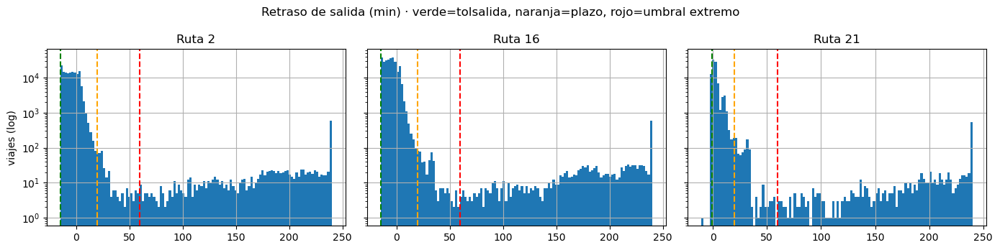

In [11]:
import matplotlib.pyplot as plt
d = d0[(d0.cancelada == "N") & d0.retraso_min.notna()]
fig, ax = plt.subplots(1, d.idruta.nunique(), figsize=(14, 3.5), sharey=True, squeeze=False)
for a, (rid, g) in zip(ax[0], d.groupby("idruta")):
    g.retraso_min.clip(-120, 240).hist(bins=120, ax=a)
    a.axvline(g.tolsalida.iloc[0], c="g", ls="--"); a.axvline(g.tiempoplazosalida.iloc[0], c="orange", ls="--")
    a.axvline(cfg.retraso_extremo_min, c="r", ls="--"); a.set_title(f"Ruta {rid}"); a.set_yscale("log")
ax[0][0].set_ylabel("viajes (log)")
fig.suptitle("Retraso de salida (min) · verde=tolsalida, naranja=plazo, rojo=umbral extremo")
plt.tight_layout(); plt.show()

**Conclusión 2.3 · La salida es casi siempre puntual; el problema son arranques registrados horas o días tarde**
- El 98,8 % de los viajes que arrancaron sale dentro de la ventana del sistema (ruta 2: 98,7 %; ruta 16: 99,2 %; ruta 21: 97,9 %).
- **Adelanto prácticamente no existe (1 viaje)**: el mínimo observado es exactamente −15 min en las rutas 2 y 16, igual a `tolsalida`. El sistema **bloquea** el despacho antes de la tolerancia, así que el adelanto no es medible.
- El retraso de más de 60 min afecta a 4.487 viajes no cancelados (0,86 %), y 320 inician más de **1 día** después de la salida programada (máximo 114 días). No son retrasos de tráfico: son registros de inicio cerrados tarde o reasignados.
- El umbral de 60 min se mantiene: separa limpio la cola (P95 ≤ 11 min, P99 entre 12 y 164 min).

## 2.4 Aplicar filtros y tabla de atrición

In [12]:
df = f.aplicar_filtros(d0, cfg)
df["puntualidad"] = f.clasificar_salida(df, cfg)
att = f.tabla_atricion(df)
display(att)
print(f"Registros iniciales: {len(df):,} | válidos: {df.valido.sum():,} ({100 * df.valido.mean():.2f} %)")

,paso,motivo,descartados,pct_de_inicial,restantes,fallan_regla_independiente
0,Fuera de ventana 2023-01 a 2025-12,fuera_ventana,0,0.00,564837,0
1,Cancelados (cancelada = 'S'),cancelado,44156,7.82,520681,44156
2,"Fantasmas (sin fechainicio, no cancelados)",fantasma_sin_inicio,33,0.01,520648,3410
3,No finalizados (finalizado <> 'S'),no_finalizado,9,0.00,520639,44198
4,No aptos históricamente,no_apto_historico,0,0.00,520639,0
5,Tiempo incoherente (fechas nulas o inicio >= fin),tiempo_incoherente,640,0.11,519999,44837
6,Duración < valor_tiempo_minimo_viaje,duracion_menor_minimo,0,0.00,519999,44290
7,Distancia <= 0 o fuera de margen vs distancia_...,distancia_invalida,22628,4.01,497371,33322


Registros iniciales: 564,837 | válidos: 497,371 (88.06 %)


**Conclusión 2.4 · Se conserva el 88,1 % (497.371 viajes); casi toda la pérdida la explican 2 reglas**
- **Cancelados: 44.156 (7,82 %)**. Ojo: no son despachos que no salieron. **40.779 tienen `fechainicio`, 40.324 tienen distancia > 0 y 38.463 llevaron pasajeros**; solo 2 tienen `fechafin`. Son viajes que **sí operaron** pero quedaron sin cierre, y el sistema los marcó como cancelados. Para medir la frecuencia real de despacho **sí cuentan como salidas**.
- **Distancia: 22.628 (4,01 %)**: 6.168 con distancia 0, 15.835 recorrieron menos del 50 % de la ruta (viajes cortados) y solo 625 superan el 150 %.
- Tiempo incoherente: 640 (547 con inicio = fin y 93 con fin antes del inicio). Fantasmas: 33. No finalizados: 9.
- No aptos, ventana y duración mínima: **0**. Esas reglas no filtran nada con estos datos.

## 2.5 Viajes fantasma y retraso extremo

In [13]:
fant_inicio = df[(df.cancelada == "N") & df.fechainicio.isna()]
fant_dur = df[(df.dur_min <= 0) & (df.distancia_recorrida.fillna(0) == 0) & (df.cancelada == "N")]
print(f"Fantasmas sin inicio (esperado 33): {len(fant_inicio)}")
print(f"Fantasmas con duración <= 0 y distancia 0: {len(fant_dur)}")
print("\nPuntualidad de salida en viajes no cancelados que arrancaron:")
arr = df[df.fechainicio.notna() & (df.cancelada == "N")]
display(arr.puntualidad.value_counts().to_frame("n").assign(pct=lambda x: (100 * x.n / x.n.sum()).round(2)))
print("Puntualidad entre los viajes válidos:")
display(df[df.valido].puntualidad.value_counts())
ext = df[df.puntualidad == "retraso_extremo"]
print(f"Retraso extremo (> {cfg.retraso_extremo_min:.0f} min): {len(ext):,} | de ellos válidos: {ext.valido.sum():,}")

Fantasmas sin inicio (esperado 33): 33
Fantasmas con duración <= 0 y distancia 0: 548

Puntualidad de salida en viajes no cancelados que arrancaron:


,n,pct
puntualidad,,
a_tiempo,514608,98.84
retraso_extremo,4487,0.86
retraso,1552,0.30
adelanto,1,0.00


Puntualidad entre los viajes válidos:


puntualidad
a_tiempo           496458
retraso               827
retraso_extremo        86
Name: count, dtype: int64

Retraso extremo (> 60 min): 5,635 | de ellos válidos: 86


**Conclusión 2.5 · Los fantasmas son pocos; los retrasos extremos casi no llegan a los válidos**
- Fantasmas sin inicio: 33, exactamente los N/N de Query9. Fantasmas con duración ≤ 0 y distancia 0: 548, que ya se excluyen por tiempo incoherente.
- De 5.635 viajes con retraso de más de 60 min, **solo 86 quedan entre los válidos**: el resto ya cayó por cancelado (1.148) o por otras reglas.
- Riesgo pendiente: los válidos todavía traen duraciones de hasta **780 min (P99)** y 7.095 por debajo de 102,6 min. La regla de duración mínima no actuó porque el parámetro está vacío; **hace falta un umbral propio** (o la bandera IQR de la Subfase 1.1).

## 2.6 Attrition Flowchart

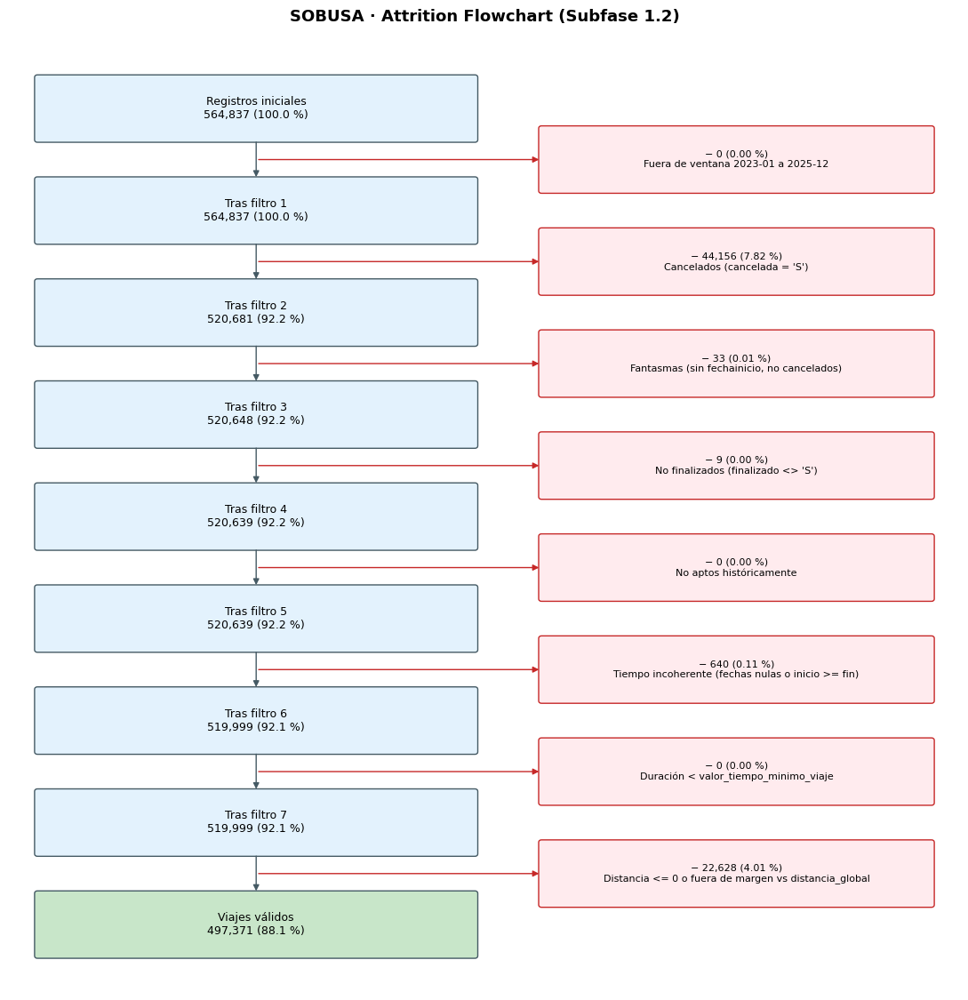

In [14]:
fig = f.flowchart(att, "attrition_flowchart_1_2.png")
plt.show()

**Conclusión final de la Subfase 1.2**
1. Base limpia: **497.371 viajes válidos (88,1 %)**: ruta 16 = 271.142, ruta 2 = 138.633, ruta 21 = 87.596.
2. Las reglas de negocio "oficiales" del sistema (apto histórico, duración mínima, tiempo global) **están vacías o son constantes**: la limpieza real la hacen `cancelada`, la distancia y la coherencia temporal.
3. **"Cancelado" no significa "no despachado"**: el 92 % de los cancelados arrancó y el 87 % llevó pasajeros. Para analizar **frecuencia de despacho** hay que usar `fechasalida`/`fechainicio` de todos los viajes no fantasma, no solo los válidos; los válidos sirven para duración, distancia y demanda.
4. La puntualidad de salida es alta (98,8 %) porque el sistema impone la ventana [−15, +20] min; el adelanto no es observable.
5. Pendiente para el modelado: definir una duración mínima/máxima y revisar el desfase de distancia en la ruta 21.

## 2.7 Exportar viajes válidos

In [15]:
validos = df[df.valido].drop(columns=[c for c in df.columns if c.startswith("falla_")] + ["motivo_descarte", "valido"])
validos.to_csv(DATOS / "viajes_validos.csv", index=False)   # CSV siempre: lo lee cualquier kernel
try:
    validos.to_parquet(DATOS / "viajes_validos.parquet", index=False)
except ImportError:
    pass
att.to_csv(DATOS / "atricion_1_2.csv", index=False)
print(f"{len(validos):,} viajes válidos guardados en {DATOS}")

497,371 viajes válidos guardados en datos_1_2


<a id="m1-3"></a>

### A1.1.3 &middot; Subfase 1.3 · Auditoría de sensores, bloqueos y puertas

<sub>Notebook original: `subfase_1_3_sensores.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 1.3 — Auditoría de sensores, bloqueos y puertas

**Parte 1** (solo lectura, la corres tú con la contraseña): índices (B.1), tabla de vehículos, columnas de sensor de `progvehiculos` y una muestra de lecturas de `conteo_pasajeros_destino`. Cada consulta se salta sola si su archivo ya existe en `datos_1_3/`.
**Parte 2** (sin conexión): banderas de calidad a nivel viaje y a nivel lectura. La lógica vive en `filtros_1_3.py`.

Insumos ya disponibles (pgAdmin): `QueryCapacidad.csv`, `Proporcion0BusesPorRuta.csv`, `QueryPasajerosReales.csv`, `Puertas.csv`.

# Parte 1 · Extracción (única conexión a la RDS)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
import filtros_1_3 as f3

D12 = Path("datos_1_2")
DATOS = Path("datos_1_3"); DATOS.mkdir(exist_ok=True)

def ya(nombre):
    return (DATOS / f"{nombre}.csv").exists() or (DATOS / f"{nombre}.parquet").exists()

def leer(carpeta, nombre):
    """Lee Parquet si existe y hay motor (pyarrow); si no, el CSV. Funciona en cualquier kernel."""
    p = carpeta / f"{nombre}.parquet"
    if p.exists():
        try:
            return pd.read_parquet(p)
        except ImportError:
            pass
    return pd.read_csv(carpeta / f"{nombre}.csv", low_memory=False)

PENDIENTES = [n for n in ["indices", "tabla_vehiculos", "sensores_viaje", "lecturas"] if not ya(n)]
print("Consultas pendientes:", PENDIENTES or "ninguna, se salta la Parte 1")

Consultas pendientes: ['lecturas']


## 1.0 Conexión (solo si hay consultas pendientes)

In [2]:
if PENDIENTES:
    from getpass import getpass
    import time
    from sqlalchemy import create_engine, text
    from sqlalchemy.engine import URL

    engine = create_engine(
        URL.create("postgresql+psycopg2", username="<usuario-bd>", password=getpass("Contraseña: ").strip(),
                   host="<servidor-bd>", port=5432, database="dataset"),
        pool_pre_ping=True,
        connect_args={"options": "-c default_transaction_read_only=on -c statement_timeout=600000 -c search_path=public"},
    )

    def consultar(sql, nombre, **params):
        t0 = time.perf_counter()
        with engine.connect() as cx:
            df = pd.read_sql(text(sql), cx, params=params or None)
        df.to_csv(DATOS / f"{nombre}.csv", index=False)
        print(f"[{nombre}] {len(df):,} filas en {time.perf_counter() - t0:.1f} s")
        return df

## 1.1 B.1 · Índices de las tablas núcleo (catálogo, instantánea)
Define si la muestra de lecturas puede traer viajes completos (requiere índice sobre `conteo_pasajeros_destino.idprogramacion`).

In [3]:
if not ya("indices"):
    consultar("""
    SELECT tablename, indexname, indexdef
    FROM pg_indexes
    WHERE schemaname = 'public'
      AND tablename IN ('progvehiculos', 'conteo_pasajeros_destino', 'rutas')
    ORDER BY 1, 2
    """, "indices")
indices = pd.read_csv(DATOS / "indices.csv")
display(indices)
cpd = indices[indices.tablename == "conteo_pasajeros_destino"]
HAY_INDICE_IDPROG = cpd.indexdef.str.contains(r"\(idprogramacion", regex=True).any()
UNICO_ID = (cpd.indexdef.str.contains("UNIQUE") & cpd.indexdef.str.contains(r"\(id\)", regex=True)).any()
print("Índice sobre conteo_pasajeros_destino.idprogramacion:", HAY_INDICE_IDPROG)
print("Índice único sobre conteo_pasajeros_destino.id:", UNICO_ID)

,tablename,indexname,indexdef
0,conteo_pasajeros_destino,idx_conteo_pasajeros_destino_idprog,CREATE INDEX idx_conteo_pasajeros_destino_idpr...
1,progvehiculos,fki_progVeh_desp,"CREATE INDEX ""fki_progVeh_desp"" ON public.prog..."
2,progvehiculos,fki_progveh_conductor,CREATE INDEX fki_progveh_conductor ON public.p...
3,progvehiculos,fki_usuario,CREATE INDEX fki_usuario ON public.progvehicul...
4,progvehiculos,idx_progvehiculos_fecha1,CREATE INDEX idx_progvehiculos_fecha1 ON publi...
5,progvehiculos,idx_progvehiculos_fecha2,CREATE INDEX idx_progvehiculos_fecha2 ON publi...
6,progvehiculos,idx_progvehiculos_fechafin,CREATE INDEX idx_progvehiculos_fechafin ON pub...
7,progvehiculos,idx_progvehiculos_fechainicio,CREATE INDEX idx_progvehiculos_fechainicio ON ...
8,progvehiculos,idx_progvehiculos_fechainicio_idveh,CREATE INDEX idx_progvehiculos_fechainicio_idv...
9,progvehiculos,idx_progvehiculos_finalizado,CREATE INDEX idx_progvehiculos_finalizado ON p...


Índice sobre conteo_pasajeros_destino.idprogramacion: True
Índice único sobre conteo_pasajeros_destino.id: False


## 1.2 Tabla de vehículos (modelo y capacidad por bus)
Solo las columnas necesarias de `vehiculos` (656 filas). Capacidad física = `n_sentados + n_depie`; la columna `capacidad` está en 0.

In [4]:
if not ya("tabla_vehiculos"):
    consultar("""
    SELECT idvehiculo, placa, numinterno, modelo, marca, capacidad, n_sentados, n_depie,
           estado, tipovehiculo, tipo_sensor, idruta
    FROM vehiculos
    """, "tabla_vehiculos")
display(pd.read_csv(DATOS / "tabla_vehiculos.csv").head())

,idvehiculo,placa,numinterno,modelo,marca,capacidad,n_sentados,n_depie,estado,tipovehiculo,tipo_sensor,idruta
0,SOBUSA38,UYQ358,NaN,2004,CHEVROLET NPR,0.0,0,0,N,1.0,AB,2.0
1,SOBUSA65,UYO907,NaN,2003,CHEVROLET NPR,0.0,0,0,N,1.0,AB,2.0
2,SOBUSA110,UYU006,86.0,2008,AGRALE,0.0,0,0,N,2.0,AB,12.0
3,SOBUSA584,SOBUSA584,NaN,NaN,NaN,0.0,0,0,N,NaN,NaN,NaN
4,SOBUSA134,UYP445,9115.0,2004,AGRALE,0.0,0,0,N,2.0,AB,NaN


## 1.3 Columnas de sensor de `progvehiculos` (una pasada, ≈565 mil filas)

In [5]:
if not ya("sensores_viaje"):
    s = consultar("""
    SELECT idprogramacion,
           numeropasajeros, numerobajadas, numerobloqueos, torniqueteinicial, torniquetefinal,
           acumulada_subida, acumulada_bajada, acumulada_bloqueo,
           cantidad_subida_puerta1, cantidad_bajada_puerta1, cantidad_bloqueo_puerta1,
           cantidad_subida_puerta2, cantidad_bajada_puerta2, cantidad_bloqueo_puerta2,
           acumulada_subida_puerta1, acumulada_bajada_puerta1, acumulada_bloqueo_puerta1,
           acumulada_subida_puerta2, acumulada_bajada_puerta2, acumulada_bloqueo_puerta2
    FROM progvehiculos
    """, "sensores_viaje")
    try:
        s.to_parquet(DATOS / "sensores_viaje.parquet", index=False)
    except ImportError:
        pass

## 1.4 Muestra de lecturas de `conteo_pasajeros_destino`
- **Con índice en `idprogramacion`:** viajes completos de 1.500 viajes válidos al azar (500 por ruta) + hasta 300 con cero pasajeros + 200 con más bloqueos. Permite carga a bordo y cortes de transmisión.
- **Sin índice:** `TABLESAMPLE SYSTEM (0.1)` (≈176 mil lecturas). Solo permite conteos negativos, picos y GPS; no reconstruye la secuencia del viaje.

In [6]:
if not ya("lecturas"):
    COLS = """id, idprogramacion, idvehiculo, fecha, latitud, longitud, idpunto,
              cantidad_subida, cantidad_bajada, cantidad_bloqueo,
              acumulada_subida, acumulada_bajada, acumulada_bloqueo,
              cantidad_subida_puerta1, cantidad_bajada_puerta1, cantidad_subida_puerta2, cantidad_bajada_puerta2"""
    lectura_ok = False
    if HAY_INDICE_IDPROG:
        val = leer(D12, "viajes_validos")
        sv = pd.read_csv(DATOS / "sensores_viaje.csv", usecols=["idprogramacion", "numeropasajeros", "numerobloqueos"])
        val = val[["idprogramacion", "idruta"]].merge(sv, on="idprogramacion")
        azar = val.groupby("idruta", group_keys=False).apply(lambda g: g.sample(min(500, len(g)), random_state=42))
        ceros = val[val.numeropasajeros.fillna(0) == 0]
        ceros = ceros.sample(min(300, len(ceros)), random_state=42)
        bloq = val.nlargest(200, "numerobloqueos")
        ids = pd.concat([azar, ceros, bloq]).idprogramacion.drop_duplicates().astype(int).tolist()
        pd.DataFrame({"idprogramacion": ids}).to_csv(DATOS / "muestra_ids.csv", index=False)
        try:
            consultar(f"SELECT {COLS} FROM conteo_pasajeros_destino WHERE idprogramacion = ANY(:ids) ORDER BY idprogramacion, fecha",
                      "lecturas", ids=ids)
            lectura_ok = True
        except Exception as e:
            print("Consulta por índice falló, se usa TABLESAMPLE:", str(e)[:200])
    if not lectura_ok:
        consultar(f"SELECT {COLS} FROM conteo_pasajeros_destino TABLESAMPLE SYSTEM (0.1) REPEATABLE (42)", "lecturas")

C:\Users\<usuario>\AppData\Local\Temp\ipykernel_27268\1725064060.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  azar = val.groupby("idruta", group_keys=False).apply(lambda g: g.sample(min(500, len(g)), random_state=42))


[lecturas] 971,335 filas en 34.9 s


# Parte 2 · Análisis local (sin conexión)

In [7]:
cargar = leer

viajes = cargar(D12, "viajes_raw")
validos_ids = cargar(D12, "viajes_validos").idprogramacion
sensores = cargar(DATOS, "sensores_viaje")
cap_modelo = pd.read_csv("QueryCapacidad.csv")
prop_ruta = pd.read_csv("Proporcion0BusesPorRuta.csv")
pas_reales = pd.read_csv("QueryPasajerosReales.csv")
puertas_pg = pd.read_csv("Puertas.csv")

cfg = f3.Config()
df = f3.preparar(viajes[["idprogramacion", "idvehiculo", "idruta", "fechasalida", "fechainicio", "fechafin",
                         "cancelada", "finalizado", "distancia_recorrida"]], sensores, validos_ids)
print(f"{len(df):,} viajes | válidos: {df.valido.sum():,} | con numeropasajeros: {df.numeropasajeros.notna().sum():,}")

564,837 viajes | válidos: 497,371 | con numeropasajeros: 556,244


## 2.1 Capacidad física de la flota

**Hallazgos previos (consultas de pgAdmin: QueryCapacidad, QueryPasajerosReales, Proporcion0BusesPorRuta, Puertas)**
- **Capacidad física: 46–74 personas por bus** (sentados + de pie). La capacidad registrada en la base es **0 en todos los modelos**: el campo no sirve.
- **El 21–24 % de la flota de cada ruta no tiene modelo** (177 buses, 100.189 viajes); su capacidad (74) es incierta. 4 buses (modelos 1997, 1998 y 2001) tienen capacidad 0.
- Capacidad ponderada por ruta: 2 = 63,4; 16 = 64,1; 21 = 63,1. La mezcla de flota es casi idéntica entre rutas.
- **`numeropasajeros` es subidas totales del viaje, NO carga a bordo**: el promedio es ≈82 por viaje en todos los modelos, aunque la capacidad va de 46 a 74 (correlación 0,3). Un viaje de ~4 h renueva el bus 1,1–1,7 veces. **La capacidad solo se puede contrastar contra la carga simultánea** (subidas − bajadas acumuladas), no contra el total del viaje.
- **Picos imposibles confirmados:** viajes con 97.199 (modelo 2020), 28.816 (2019) y 747 (2017) pasajeros. Son errores del contador, no demanda.
- **Puertas: la hipótesis se cumple.** El 97,87 % de las subidas entra por P1 y el 99,27 % de las bajadas sale por P2. Hay 345 viajes con más subidas por P2 y 5.881 con más bajadas por P1.
- **Desbalance global:** 42,8 M de subidas frente a 44,9 M de bajadas (**+5,0 % de bajadas**). En un sistema cerrado deberían ser iguales: los sensores cuentan de más las bajadas o de menos las subidas.

In [8]:
cap_ruta = f3.capacidad_por_ruta(prop_ruta, cap_modelo)
display(cap_ruta)
pr = pas_reales.assign(subidas_por_puesto=lambda x: (x.promedio_pasajeros_por_viaje / x.capacidad_teorica_max).round(2))
display(pr[["modelo", "total_viajes", "capacidad_teorica_max", "promedio_pasajeros_por_viaje",
            "max_pasajeros_reales_en_un_viaje", "subidas_por_puesto"]].sort_values("capacidad_teorica_max", ascending=False))
print("Correlación capacidad del modelo vs pasajeros promedio por viaje:",
      round(pr[["capacidad_teorica_max", "promedio_pasajeros_por_viaje"]].corr().iloc[0, 1], 2))

# Capacidad por bus = n_sentados + n_depie. Si el bus tiene 0, se usa la capacidad de su modelo; si tampoco, 74 (cota de la flota).
veh = pd.read_csv(DATOS / "tabla_vehiculos.csv")
veh["cap_bus"] = veh.n_sentados.fillna(0) + veh.n_depie.fillna(0)
cap_mod = cap_modelo.assign(modelo=cap_modelo.modelo.astype("string")).set_index("modelo").capacidad_calculada_max
veh["cap_modelo"] = veh.modelo.astype("string").map(cap_mod)
veh["capacidad_final"] = veh.cap_bus.where(veh.cap_bus > 0, veh.cap_modelo.where(veh.cap_modelo > 0))
veh["origen_cap"] = np.select([veh.cap_bus > 0, veh.capacidad_final.notna()], ["bus", "modelo"], "flota_74")
operan = veh[veh.idvehiculo.isin(df.idvehiculo)]
print("Buses que operan:", len(operan)); display(operan.origen_cap.value_counts().to_frame("buses"))
display(operan.capacidad_final.describe().round(1).to_frame("capacidad_bus"))
CAP_BUS = veh.set_index("idvehiculo").capacidad_final.dropna().to_dict()
cap_viaje = df.idvehiculo.map(CAP_BUS)
print("Viajes con capacidad propia del bus o su modelo:", f"{cap_viaje.notna().sum():,}", "| resto usa", cfg.cap_defecto)

,buses,pct_sin_modelo,cap_ponderada,cap_ponderada_con_modelo,cap_min,cap_max
idruta,,,,,,
2,282,23.0,63.4,60.3,46,74
16,296,21.0,64.1,61.5,47,74
21,345,24.1,63.1,59.7,46,74


,modelo,total_viajes,capacidad_teorica_max,promedio_pasajeros_por_viaje,max_pasajeros_reales_en_un_viaje,subidas_por_puesto
0,NaN,100189,74,81.65,329,1.10
1,2008,23085,72,84.12,253,1.17
2,2017,16664,70,88.07,747,1.26
3,2016,83668,70,80.15,264,1.14
4,2018,48412,70,84.04,351,1.20
5,2020,85756,62,82.84,97199,1.34
6,2025,654,60,87.23,204,1.45
7,2015,1154,58,80.36,216,1.39
8,2003,5609,58,90.23,263,1.56
9,2007,11933,58,73.27,239,1.26


Correlación capacidad del modelo vs pasajeros promedio por viaje: 0.3
Buses que operan: 449


,buses
origen_cap,
bus,401
modelo,48


,capacidad_bus
count,449.0
mean,52.5
std,7.3
min,32.0
25%,49.0
50%,50.0
75%,57.0
max,74.0


Viajes con capacidad propia del bus o su modelo: 564,837 | resto usa 74.0


In [9]:
df, U = f3.auditar_viajes(df, cap_viaje, cfg)
v = df[df.valido]
print("Umbrales (sobre viajes válidos):", {k: round(x, 3) for k, x in U.items()})

Umbrales (sobre viajes válidos): {'p_bloqueo': 260.0, 'p_tasa_bloqueo': 3.284}


## 2.2 Bloqueos de barra

In [10]:
display(v.numerobloqueos.describe(percentiles=[.5, .9, .95, .99, .999]).round(2).to_frame("numerobloqueos"))
display(v.tasa_bloqueo.describe(percentiles=[.5, .9, .99]).round(3).to_frame("bloqueos_por_pasajero"))
display(f3.resumen_flags(v, ["flag_alto_bloqueo", "flag_bloqueo_severo"]))
print("Concentración por bus (bloqueo severo):"); display(f3.concentracion(v, "flag_bloqueo_severo"))
print("Bloqueo alto por hora de salida (%):")
display(v.groupby("hora").flag_alto_bloqueo.mean().mul(100).round(2).to_frame().T)

,numerobloqueos
count,496580.00
mean,55.69
std,5494.62
min,0.00
50%,0.00
90%,21.00
95%,63.00
99%,260.00
99.9%,2199.53
max,1605840.00


,bloqueos_por_pasajero
count,496404.000
mean,0.968
std,85.665
min,0.000
50%,0.000
90%,0.247
99%,3.284
max,25900.645


,viajes,pct,base
flag_alto_bloqueo,4954,1.00,497371
flag_bloqueo_severo,3803,0.76,497371


Concentración por bus (bloqueo severo):


,n_flag,viajes,pct_viajes_bus,pct_acum_del_total
idvehiculo,,,,
SOBUSA302,103,2547,4.0,2.7
SOBUSA401,58,2831,2.0,4.2
SOBUSA441,52,2358,2.2,5.6
SOBUSA262,50,1111,4.5,6.9
SOBUSA442,48,2338,2.1,8.2
SOBUSA36,48,2131,2.3,9.4
SOBUSA435,47,2536,1.9,10.7
SOBUSA475,45,2660,1.7,11.9
SOBUSA420,43,2808,1.5,13.0


Bloqueo alto por hora de salida (%):


hora,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
flag_alto_bloqueo,0.8,0.89,1.33,1.18,1.26,1.08,1.11,1.3,1.39,1.18,1.12,0.74,0.64,0.55,0.66,0.42,0.63


## 2.3 Puerta 1 vs Puerta 2

In [11]:
tot = v[["cantidad_subida_puerta1", "cantidad_subida_puerta2", "cantidad_bajada_puerta1", "cantidad_bajada_puerta2",
         "numeropasajeros", "numerobajadas"]].sum()
display(tot.to_frame("total_validos").T)
print(f"Subidas por P1: {100 * tot.cantidad_subida_puerta1 / (tot.cantidad_subida_puerta1 + tot.cantidad_subida_puerta2):.2f} %  |  "
      f"Bajadas por P2: {100 * tot.cantidad_bajada_puerta2 / (tot.cantidad_bajada_puerta1 + tot.cantidad_bajada_puerta2):.2f} %")
display(v.pct_sub_p1.describe(percentiles=[.01, .05, .5]).round(3).to_frame("pct_subidas_p1"))
display(f3.resumen_flags(v, ["flag_subida_p2_mayor", "flag_bajada_p1_mayor", "flag_total_inconsistente"]))
print("Concentración por bus (bajadas por P1 > P2):"); display(f3.concentracion(v, "flag_bajada_p1_mayor"))

,cantidad_subida_puerta1,cantidad_subida_puerta2,cantidad_bajada_puerta1,cantidad_bajada_puerta2,numeropasajeros,numerobajadas
total_validos,41678924.0,906921.0,273064.0,44432712.0,42084022.0,47195395.0


Subidas por P1: 97.87 %  |  Bajadas por P2: 99.39 %


,pct_subidas_p1
count,496404.000
mean,0.995
std,0.017
min,0.000
1%,0.934
5%,0.971
50%,1.000
max,1.000


,viajes,pct,base
flag_subida_p2_mayor,31,0.01,497371
flag_bajada_p1_mayor,594,0.12,497371
flag_total_inconsistente,772,0.16,497371


Concentración por bus (bajadas por P1 > P2):


,n_flag,viajes,pct_viajes_bus,pct_acum_del_total
idvehiculo,,,,
SOBUSA512,13,2156,0.6,2.2
SOBUSA265,11,2334,0.5,4.0
SOBUSA53,10,1667,0.6,5.7
SOBUSA428,9,1995,0.5,7.2
SOBUSA190,8,2278,0.4,8.6
SOBUSA221,7,2803,0.2,9.8
SOBUSA153,7,1689,0.4,10.9
SOBUSA165,7,1565,0.4,12.1
SOBUSA209,7,2054,0.3,13.3


## 2.4 Coherencia física: balance subidas − bajadas, picos y negativos

In [12]:
display(v.balance_final.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_frame("balance_final"))
print(f"Subidas totales: {v.subidas_tot.sum():,.0f} | Bajadas totales: {v.bajadas_tot.sum():,.0f} | "
      f"exceso de bajadas: {100 * (v.bajadas_tot.sum() / v.subidas_tot.sum() - 1):.2f} %")
display(f3.resumen_flags(v, ["flag_balance_negativo", "flag_balance_sobre_capacidad", "flag_pico_imposible", "flag_conteo_negativo"]))
display(v.loc[v.flag_pico_imposible, ["idprogramacion", "idvehiculo", "idruta", "fechasalida", "numeropasajeros",
                                      "subidas_tot", "bajadas_tot", "capacidad"]].sort_values("numeropasajeros", ascending=False).head(15))

,balance_final
count,497371.0
mean,-4.3
std,2035.6
min,-750370.0
1%,-20.0
5%,-9.0
25%,-2.0
50%,1.0
75%,5.0
95%,13.0


Subidas totales: 42,585,845 | Bajadas totales: 44,705,776 | exceso de bajadas: 4.98 %


,viajes,pct,base
flag_balance_negativo,32329,6.50,497371
flag_balance_sobre_capacidad,573,0.12,497371
flag_pico_imposible,123,0.02,497371
flag_conteo_negativo,0,0.00,497371


,idprogramacion,idvehiculo,idruta,fechasalida,numeropasajeros,subidas_tot,bajadas_tot,capacidad
150152,6219550,SOBUSA451,16,2024-05-20 11:36:00,97199.0,45.0,40.0,62.0
357597,7144077,SOBUSA143,16,2025-07-04 17:48:00,28816.0,638032.0,21.0,50.0
174420,6330910,SOBUSA303,21,2024-07-09 09:36:00,747.0,747.0,318.0,58.0
219745,6535573,SOBUSA475,16,2024-10-08 13:08:00,507.0,507.0,446.0,49.0
174738,6332504,SOBUSA303,21,2024-07-09 19:56:00,459.0,459.0,247.0,58.0
236764,6612771,SOBUSA475,16,2024-11-12 17:33:00,413.0,413.0,317.0,49.0
226097,6563160,SOBUSA333,16,2024-10-21 10:58:00,375.0,375.0,368.0,50.0
550956,5497571,SOBUSA420,16,2023-07-15 16:42:00,351.0,351.0,345.0,39.0
554059,5510880,SOBUSA420,16,2023-07-21 16:39:00,344.0,344.0,282.0,39.0
236355,6610507,SOBUSA475,16,2024-11-11 16:25:00,341.0,341.0,208.0,49.0


## 2.5 Ceros: falla de transmisión/sensor vs. falta de demanda
- `cero_sin_transmision`: 0 pasajeros y distancia 0 (no llegó nada del bus).
- `cero_falla_sensor`: el bus recorrió la ruta, pero no contó a nadie mientras la ruta en esa fecha y hora tenía demanda (mediana ≥ 10), o el bus tuvo todos sus viajes del día en cero.
- `cero_baja_demanda`: el bus recorrió la ruta y el contexto también tenía poca demanda.

In [13]:
display(df[df.arranco].tipo_cero.value_counts().to_frame("todos_los_que_arrancaron")
        .join(v.tipo_cero.value_counts().rename("validos")))
print("Ceros por hora de salida (válidos):")
display(pd.crosstab(v.hora, v.tipo_cero).drop(columns="con_dato", errors="ignore").T)

,todos_los_que_arrancaron,validos
tipo_cero,,
con_dato,543975,496404.0
cero_falla_sensor,9832,348.0
cero_sin_transmision,6568,NaN
cero_baja_demanda,1052,619.0


Ceros por hora de salida (válidos):


hora,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
tipo_cero,,,,,,,,,,,,,,,,,
cero_baja_demanda,1,0,0,0,0,0,0,0,0,0,0,0,0,0,18,393,207
cero_falla_sensor,7,67,35,23,15,13,6,10,10,18,11,12,16,24,35,25,21


## 2.6 Auditoría por lectura (sensor/GPS)

In [14]:
lect = cargar(DATOS, "lecturas")
SECUENCIAS = (DATOS / "muestra_ids.csv").exists()
cap_bus = pd.Series(CAP_BUS, dtype=float) if CAP_BUS else None
L = f3.auditar_lecturas(lect, cap_bus, cfg, secuencias=SECUENCIAS)
print(f"{len(L):,} lecturas de {L.idprogramacion.nunique():,} viajes | secuencias completas: {SECUENCIAS}")
display(L[["acumulada_subida", "acumulada_bajada", "a_bordo_abs"] + (["a_bordo_rel", "a_bordo_cum"] if SECUENCIAS else [])]
        .describe(percentiles=[.01, .5, .99]).round(1))
display(f3.resumen_flags(L, [c for c in L.columns if c.startswith("flag_")]))

971,335 lecturas de 1,673 viajes | secuencias completas: True


,acumulada_subida,acumulada_bajada,a_bordo_abs,a_bordo_rel,a_bordo_cum
count,971335.0,971335.0,971335.0,971335.0,971335.0
mean,383495.3,383979.1,-483.8,13.4,-30.8
std,194085.3,182376.2,36770.8,815.1,4656.5
min,29.0,161.0,-248444.0,-103363.0,-555739.0
1%,1541.0,4350.0,-146698.0,-102.0,-102.0
50%,437469.0,434830.0,2261.0,11.0,11.0
99%,688749.0,674360.0,70925.0,118.0,118.0
max,768795.0,755003.0,542723.0,555750.0,213.0


,viajes,pct,base
flag_conteo_negativo,0,0.00,971335
flag_pico_lectura,12,0.00,971335
flag_gps_nulo,0,0.00,971335
flag_gps_fuera_caja,1,0.00,971335
flag_corte_transmision,517,0.05,971335


In [15]:
if SECUENCIAS:
    # Se usa la carga reconstruida con cantidades (a_bordo_cum); a_bordo_abs/rel sirven para validar el acumulado.
    RV = f3.resumen_lecturas_por_viaje(L, "a_bordo_cum", cfg).join(sensores.set_index("idprogramacion")[["numeropasajeros"]])
    RV["dif_vs_progvehiculos"] = RV.subidas_sensor - RV.numeropasajeros
    display(RV.describe(percentiles=[.01, .5, .99]).round(1))
    display(f3.resumen_flags(RV, ["flag_sobrecupo", "flag_a_bordo_negativo"]))
else:
    print("Sin secuencias completas: carga a bordo y cortes de transmisión no evaluables (falta índice en idprogramacion).")

,lecturas,subidas_sensor,bajadas_sensor,max_a_bordo,min_a_bordo,capacidad,lecturas_gps_nulo,cortes_transmision,max_gap_min,numeropasajeros,dif_vs_progvehiculos
count,1673.0,1673.0,1673.0,1673.0,1673.0,1673.0,1673.0,1673.0,1671.0,1671.0,1671.0
mean,580.6,155.5,1005.5,34.5,-856.3,52.0,0.0,0.3,33.3,155.3,0.3
std,928.8,2476.1,20254.0,20.3,19578.8,7.1,0.0,0.8,268.6,2477.6,3.4
min,1.0,0.0,0.0,-7.0,-555739.0,32.0,0.0,0.0,0.1,0.0,0.0
1%,6.0,0.0,0.0,0.0,-109.0,39.0,0.0,0.0,0.1,0.0,0.0
50%,341.0,79.0,77.0,33.0,0.0,50.0,0.0,0.0,2.0,79.0,0.0
99%,4576.6,173.3,170.0,100.3,1.0,74.0,0.0,4.0,616.5,173.0,2.0
max,7074.0,97199.0,555778.0,213.0,8.0,74.0,0.0,12.0,8334.8,97199.0,92.0


,viajes,pct,base
flag_sobrecupo,278,16.62,1673
flag_a_bordo_negativo,176,10.52,1673


## 2.7 Banderas de calidad finales y exportación

In [16]:
FLAGS = ["flag_sensor_ok", "flag_bloqueo_severo", "flag_incoherencia_pasajeros", "flag_alto_bloqueo",
         "flag_cero_falla", "flag_subida_p2_mayor", "flag_bajada_p1_mayor"]
display(f3.resumen_flags(v, FLAGS))
display(v.groupby("idruta")[FLAGS].mean().mul(100).round(2))
salida = v[["idprogramacion", "idvehiculo", "idruta", "fechasalida", "numeropasajeros", "numerobloqueos",
            "subidas_tot", "bajadas_tot", "balance_final", "pct_sub_p1", "tasa_bloqueo", "capacidad", "tipo_cero"]
           + [c for c in v.columns if c.startswith("flag_")]]
salida.to_csv(DATOS / "viajes_flags_1_3.csv", index=False)   # CSV siempre: lo lee cualquier kernel
try:
    salida.to_parquet(DATOS / "viajes_flags_1_3.parquet", index=False)
except ImportError:
    pass
print(f"{len(salida):,} viajes válidos con banderas guardados en {DATOS}")

,viajes,pct,base
flag_sensor_ok,461415,92.77,497371
flag_bloqueo_severo,3803,0.76,497371
flag_incoherencia_pasajeros,33013,6.64,497371
flag_alto_bloqueo,4954,1.00,497371
flag_cero_falla,348,0.07,497371
flag_subida_p2_mayor,31,0.01,497371
flag_bajada_p1_mayor,594,0.12,497371


,flag_sensor_ok,flag_bloqueo_severo,flag_incoherencia_pasajeros,flag_alto_bloqueo,flag_cero_falla,flag_subida_p2_mayor,flag_bajada_p1_mayor
idruta,,,,,,,
2,95.08,0.78,4.30,0.96,0.09,0.00,0.13
16,92.90,0.74,6.52,0.99,0.06,0.01,0.10
21,88.71,0.83,10.70,1.09,0.08,0.01,0.16


497,371 viajes válidos con banderas guardados en datos_1_3


<a id="m1-4"></a>

### A1.1.4 &middot; Subfase 1.4 · Nulos, imputación sin leakage y tablas maestras

<sub>Notebook original: `subfase_1_4_maestra.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 1.4 — Nulos, imputación sin leakage y tablas maestras (cierre del Módulo 1)

**Parte 1** (solo lectura, la corres tú): 3 consultas para el mapa de nulos. Ninguna recorre los 41 GB y ninguna descarga valores, solo indicadores de nulo.
**Parte 2** (sin conexión): mapa de nulos, decisiones por columna, imputación sin data leakage, las 3 tablas maestras en Parquet y la validación de cierre.

| Salida | Contenido |
|---|---|
| `maestras/tb_maestra_progvehiculos_limpia.parquet` | Viajes válidos (1.2) + banderas de sensor (1.3) + imputación + `recaudo_esperado` |
| `maestras/tb_despachos.parquet` | Todas las salidas reales, incluidos los "cancelados" que sí operaron: base para medir la frecuencia de despacho |
| `maestras/tb_maestra_conteo_destino_limpio_muestra.parquet` | Lecturas limpias de la muestra de la 1.3 (la tabla completa de 41 GB queda como vista SQL) |
| `tb_maestras_modulo1.sql` | DDL de las 3 tablas/vistas para quien tenga permisos de escritura |

La lógica vive en `filtros_1_4.py`.

# Parte 1 · Extracción para el mapa de nulos

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
import filtros_1_2 as f2
import filtros_1_4 as f4

D12, D13 = Path("datos_1_2"), Path("datos_1_3")
DATOS = Path("datos_1_4"); DATOS.mkdir(exist_ok=True)
SALIDA = Path("maestras"); SALIDA.mkdir(exist_ok=True)
cfg = f4.Config()

def ya(nombre):
    return (DATOS / f"{nombre}.csv").exists()

def leer(carpeta, nombre):
    p = carpeta / f"{nombre}.parquet"
    if p.exists():
        try:
            return pd.read_parquet(p)
        except ImportError:
            pass
    return pd.read_csv(carpeta / f"{nombre}.csv", low_memory=False)

inv = pd.read_csv("Query1.csv")
COLS_PV = inv[inv.table_name == "progvehiculos"].sort_values("pos").column_name.tolist()
COLS_CP = inv[inv.table_name == "conteo_pasajeros_destino"].sort_values("pos").column_name.drop_duplicates().tolist()
PENDIENTES = [n for n in ["nulos_progvehiculos", "indicadores_progvehiculos", "indicadores_conteo"] if not ya(n)]
print(f"progvehiculos: {len(COLS_PV)} columnas | conteo_pasajeros_destino: {len(COLS_CP)} columnas")
print("Consultas pendientes:", PENDIENTES or "ninguna, se salta la Parte 1")

progvehiculos: 73 columnas | conteo_pasajeros_destino: 25 columnas
Consultas pendientes: ['nulos_progvehiculos', 'indicadores_progvehiculos', 'indicadores_conteo']


In [2]:
if PENDIENTES:
    from getpass import getpass
    import time
    from sqlalchemy import create_engine, text
    from sqlalchemy.engine import URL

    engine = create_engine(
        URL.create("postgresql+psycopg2", username="<usuario-bd>", password=getpass("Contraseña: ").strip(),
                   host="<servidor-bd>", port=5432, database="dataset"),
        pool_pre_ping=True,
        connect_args={"options": "-c default_transaction_read_only=on -c statement_timeout=600000 -c search_path=public"},
    )

    def consultar(sql, nombre):
        t0 = time.perf_counter()
        with engine.connect() as cx:
            df = pd.read_sql(text(sql), cx)
        df.to_csv(DATOS / f"{nombre}.csv", index=False)
        print(f"[{nombre}] {len(df):,} filas en {time.perf_counter() - t0:.1f} s")
        return df

## 1.1 Nulos exactos por columna de `progvehiculos` (una pasada, 975 MB)

In [3]:
if not ya("nulos_progvehiculos"):
    sel = ",\n       ".join(f'count("{c}") AS "{c}"' for c in COLS_PV)
    consultar(f"SELECT count(*) AS total,\n       {sel}\nFROM progvehiculos", "nulos_progvehiculos")

[nulos_progvehiculos] 1 filas en 4.2 s


## 1.2 Indicadores de nulo de `progvehiculos` (muestra del 5 %, solo 0/1, sin valores)

In [4]:
if not ya("indicadores_progvehiculos"):
    sel = ",\n       ".join(f'("{c}" IS NULL)::int AS "{c}"' for c in COLS_PV)
    consultar(f"""SELECT to_char(fechasalida, 'YYYY-MM') AS mes,
       {sel}
FROM progvehiculos TABLESAMPLE SYSTEM (5) REPEATABLE (42)""", "indicadores_progvehiculos")

[indicadores_progvehiculos] 27,963 filas en 13.2 s


## 1.3 Indicadores de nulo de `conteo_pasajeros_destino` (muestra del 0,2 %, ≈350 mil lecturas, solo 0/1)

In [5]:
if not ya("indicadores_conteo"):
    sel = ",\n       ".join(f'("{c}" IS NULL)::int AS "{c}"' for c in COLS_CP)
    extra = ',\n       COALESCE(latitud = 0 OR longitud = 0, false)::int AS "coord_cero"'
    consultar(f"""SELECT to_char(fecha, 'YYYY-MM') AS mes,
       {sel}{extra}
FROM conteo_pasajeros_destino TABLESAMPLE SYSTEM (0.2) REPEATABLE (42)""", "indicadores_conteo")

[indicadores_conteo] 342,414 filas en 22.5 s


# Parte 2 · Análisis local (sin conexión)

## 2.1 Mapa de nulos de `progvehiculos`

,columnas
categoria,
completa,27
<5 %,19
5–50 %,1
"50–99,99 %",2
100 % nula,24


,no_nulos,nulos,pct_nulos,categoria
fecha_fin_liquidacion,0,564837,100.00,100 % nula
bloqueo_despacho_veh_rec,0,564837,100.00,100 % nula
data_log,0,564837,100.00,100 % nula
idempresa,0,564837,100.00,100 % nula
tipo,0,564837,100.00,100 % nula
torniquetefinal,0,564837,100.00,100 % nula
bloqueo_cond,0,564837,100.00,100 % nula
bloqueo_veh,0,564837,100.00,100 % nula
gtransid,0,564837,100.00,100 % nula
geocercaact,0,564837,100.00,100 % nula


Muestra: 27,963 viajes


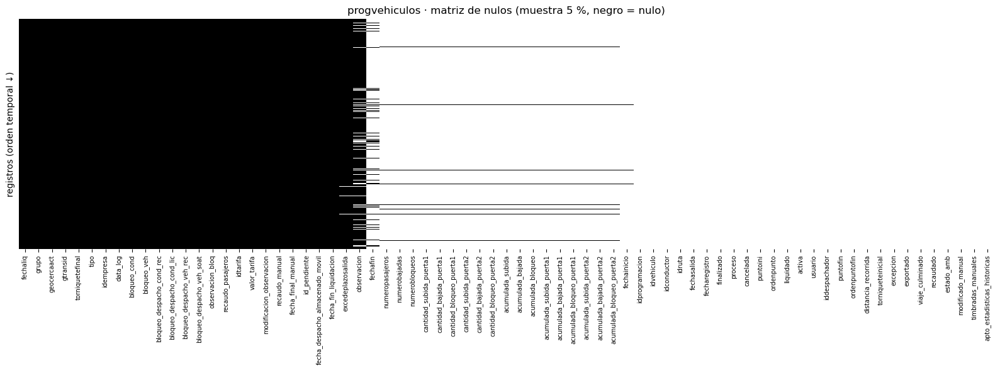

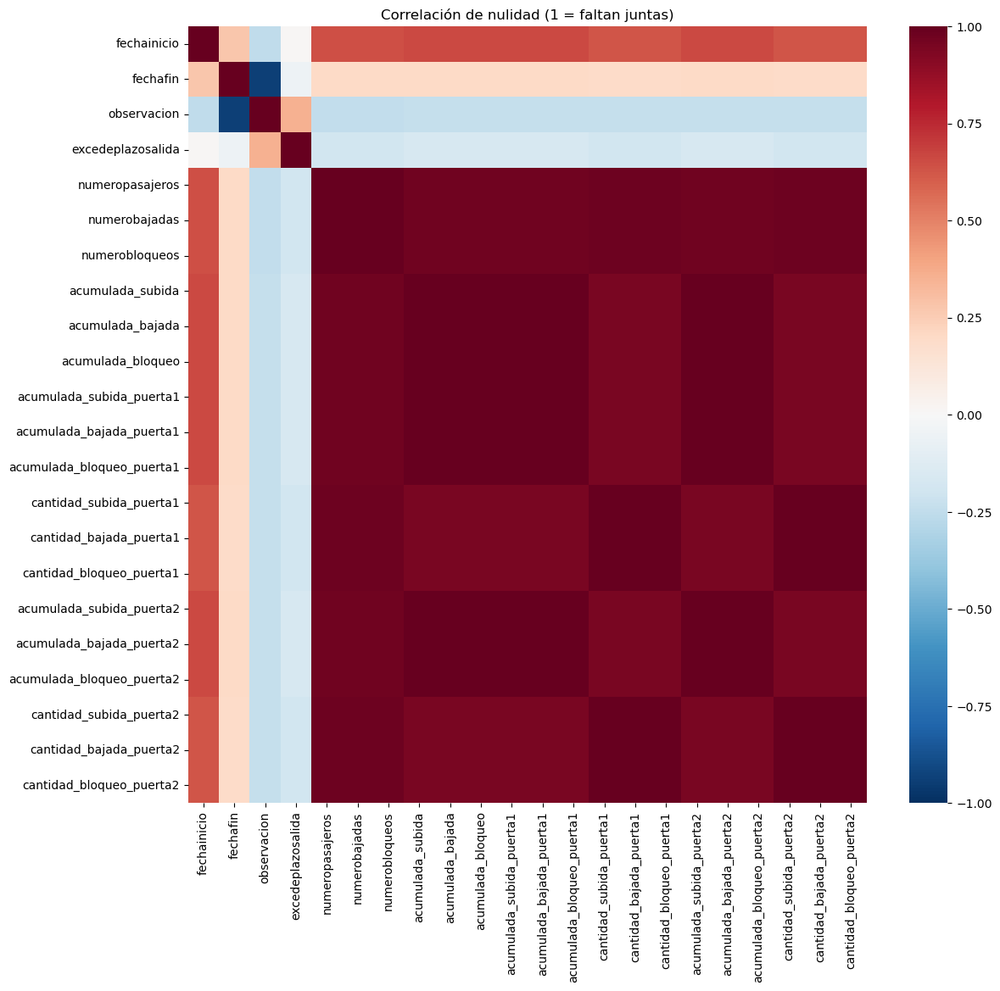

In [6]:
nulos_pv = f4.pct_nulos_exactos(pd.read_csv(DATOS / "nulos_progvehiculos.csv"))
display(nulos_pv.categoria.value_counts().sort_index().to_frame("columnas"))
display(nulos_pv[nulos_pv.pct_nulos > 0])

ind_pv = pd.read_csv(DATOS / "indicadores_progvehiculos.csv")
print(f"Muestra: {len(ind_pv):,} viajes")
fig, ax = plt.subplots(1, 1, figsize=(16, 6))
f4.matriz_nulos(ind_pv, "progvehiculos · matriz de nulos (muestra 5 %, negro = nulo)", ax=ax)
plt.tight_layout(); plt.show()
c_pv = f4.correlacion_nulos(ind_pv); plt.show()

## 2.2 Mapa de nulos de `conteo_pasajeros_destino`

Muestra: 342,414 lecturas


,pct_nulos_muestra
idpunto,90.42
id,0.00
acumulada_bloqueo_puerta1,0.00
acumulada_subida_puerta1,0.00
cantidad_bloqueo_puerta2,0.00
cantidad_bajada_puerta2,0.00
cantidad_subida_puerta2,0.00
acumulada_bloqueo_puerta2,0.00
acumulada_bajada_puerta2,0.00
acumulada_subida_puerta2,0.00


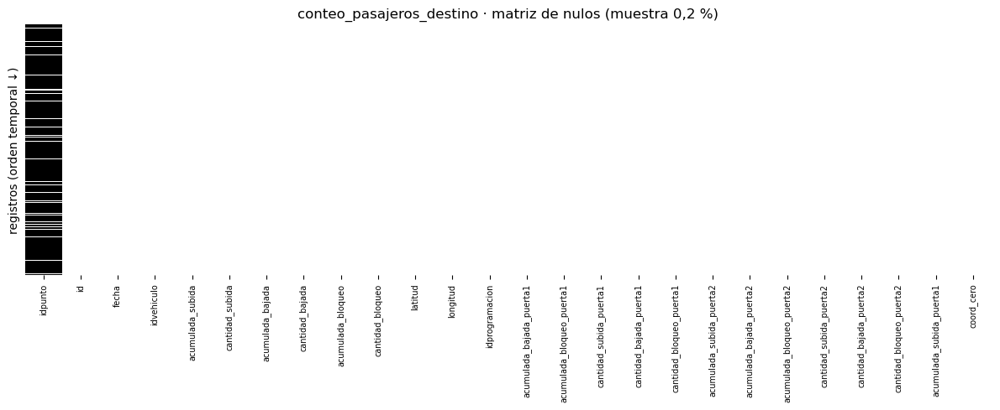

Menos de 2 columnas parcialmente nulas: no hay patrón de co-ocurrencia que graficar.
Nulos por mes (% de lecturas con alguna coordenada nula o en cero):


mes,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
sin_coord,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
ind_cp = pd.read_csv(DATOS / "indicadores_conteo.csv")
ind_cp[ind_cp.columns.drop("mes")] = ind_cp[ind_cp.columns.drop("mes")].fillna(0).astype(int)
pct_cp = (100 * ind_cp.drop(columns="mes").mean()).round(3).sort_values(ascending=False).to_frame("pct_nulos_muestra")
print(f"Muestra: {len(ind_cp):,} lecturas")
display(pct_cp)
fig, ax = plt.subplots(1, 1, figsize=(12, 5))
f4.matriz_nulos(ind_cp, "conteo_pasajeros_destino · matriz de nulos (muestra 0,2 %)", ax=ax)
plt.tight_layout(); plt.show()
c_cp = f4.correlacion_nulos(ind_cp); plt.show()
print("Nulos por mes (% de lecturas con alguna coordenada nula o en cero):")
coord = ind_cp.assign(sin_coord=(ind_cp.latitud | ind_cp.longitud | ind_cp.coord_cero).astype(bool))
display(coord.groupby("mes").sin_coord.mean().mul(100).round(3).to_frame().T)

## 2.3 Decisión por columna de `progvehiculos`

In [8]:
CONSTANTES = {"apto_estadisticas_historicas": "constante True (1.2)", "viaje_culminado": "constante False (1.2)",
              "modificado_manual": "constante False (1.2)"}
EN_MAESTRA = set(f4.COLS_MAESTRA)

def decidir(c, pct):
    if c in EN_MAESTRA:
        return "en maestra"
    if pct == 100:
        return "eliminar: 100 % nula"
    if c in CONSTANTES:
        return "eliminar: " + CONSTANTES[c]
    if c.startswith("acumulada_"):
        return "eliminar: contador de toda la vida del equipo (1.3)"
    if c in {"recaudo_pasajeros", "recaudo_manual", "valor_tarifa", "idtarifa", "recaudado", "timbradas_manuales"}:
        return "eliminar: recaudo nulo → se reemplaza por recaudo_esperado"
    return "eliminar: administrativa / fuera de alcance"

dec = nulos_pv.reindex(COLS_PV)[["pct_nulos"]].assign(decision=lambda x: [decidir(c, p) for c, p in x.pct_nulos.items()])
display(dec.decision.value_counts().to_frame("columnas"))
display(dec[dec.decision == "en maestra"])

,columnas
decision,
eliminar: 100 % nula,24
eliminar: administrativa / fuera de alcance,19
en maestra,16
eliminar: contador de toda la vida del equipo (1.3),9
eliminar: constante False (1.2),2
eliminar: recaudo nulo → se reemplaza por recaudo_esperado,2
eliminar: constante True (1.2),1


,pct_nulos,decision
idprogramacion,0.00,en maestra
idvehiculo,0.00,en maestra
idruta,0.00,en maestra
fechasalida,0.00,en maestra
fechainicio,0.60,en maestra
fechafin,7.82,en maestra
finalizado,0.00,en maestra
cancelada,0.00,en maestra
distancia_recorrida,0.00,en maestra
numeropasajeros,1.52,en maestra


## 2.4 Reglas de imputación (anti-data leakage)
| Campo | Regla |
|---|---|
| `numeropasajeros` nulo, cero por falla del sensor o pico imposible (1.3) | Mediana de los viajes de la **misma ruta × hora × tipo de día** en los **28 días anteriores** (ventana `(t − 28 d, t)`, nunca el futuro ni promedios globales). Si hay menos de 5 viajes de historia: misma ruta × hora. Si tampoco: queda nulo (`sin_historia`). Bandera `pasajeros_imputado`. |
| `numeropasajeros` = 0 con baja demanda real (1.3) | Se conserva el 0: es demanda real, no falla. |
| `numerobloqueos` nulo | No se imputa: solo se usa como bandera binaria (1.3). |
| Categóricas (`modelo`, `tipo_sensor`) nulas | `SIN_MODELO` / `SIN_DATO`. |
| Lecturas: `cantidad_*` nulas con el viaje activo | 0 (no hubo evento). Bandera `conteo_imputado_cero`. |
| Lecturas: coordenadas nulas o en 0 | Última posición conocida **del mismo viaje** (forward-fill; nunca la siguiente). `rutas_segmentos` no hace falta: ver 2.2. |
| Recaudo / tarifa (100 % nulos) | No se inventan transacciones: `recaudo_esperado = numeropasajeros × 3.700 COP` (tarifa oficial vigente, decisión de gerencia; sensor con precisión del 97 %). Es una **métrica estimada de negocio**, no recaudo real. |

Tipo de día = laboral / sábado / domingo. Los festivos no se distinguen (no está instalado el paquete `holidays`).

In [9]:
viajes = leer(D12, "viajes_raw")
validos = leer(D12, "viajes_validos")
flags13 = leer(D13, "viajes_flags_1_3")
sensores = leer(D13, "sensores_viaje")
vehiculos = pd.read_csv(D13 / "tabla_vehiculos.csv")

maestra = f4.construir_maestra(validos, flags13, sensores, vehiculos, cfg)
print(f"Maestra: {len(maestra):,} viajes x {maestra.shape[1]} columnas")
display(maestra.metodo_imputacion.value_counts().to_frame("viajes"))
imp = maestra[maestra.pasajeros_imputado]
print("Pasajeros imputados: mediana", imp.numeropasajeros.median(), "| no imputados: mediana", maestra[~maestra.pasajeros_imputado].numeropasajeros.median())

Maestra: 497,371 viajes x 43 columnas


,viajes
metodo_imputacion,
original,496302
mediana_28d_ruta_hora_tipodia,1060
mediana_28d_ruta_hora,9


Pasajeros imputados: mediana 45.0 | no imputados: mediana 82.0


## 2.5 Tabla de despachos (todas las salidas reales)

In [10]:
r12 = pd.read_csv(D12 / "rutas.csv"); p12 = pd.read_csv(D12 / "procesos.csv")
vp = f2.preparar(viajes, r12, p12)
despachos = f4.construir_despachos(vp, maestra.idprogramacion, f2.clasificar_salida(vp), cfg)
print(f"Despachos: {len(despachos):,}")
display(pd.crosstab(despachos.en_maestra, despachos.cancelada, margins=True))
print(f"Inicio no confiable (retraso > {cfg.retraso_no_confiable_min:.0f} min o adelanto fuera de tolerancia): "
      f"{despachos.flag_inicio_no_confiable.sum():,} ({100 * despachos.flag_inicio_no_confiable.mean():.2f} %)")

Despachos: 561,427


cancelada,False,True,All
en_maestra,,,
False,23277,40779,64056
True,497371,0,497371
All,520648,40779,561427


Inicio no confiable (retraso > 60 min o adelanto fuera de tolerancia): 5,636 (1.00 %)


## 2.6 Lecturas limpias (muestra de la 1.3)

In [11]:
lect = leer(D13, "lecturas")
conteo = f4.construir_conteo_limpio(lect, maestra, cfg)
print(f"{len(conteo):,} lecturas de {conteo.idprogramacion.nunique():,} viajes de la maestra")
display(conteo[["conteo_imputado_cero", "coord_imputada", "flag_fuera_area", "flag_carga_imposible"]].sum().to_frame("lecturas"))

971,335 lecturas de 1,673 viajes de la maestra


,lecturas
conteo_imputado_cero,0
coord_imputada,0
flag_fuera_area,1
flag_carga_imposible,105135


## 2.7 Guardar tablas maestras

In [12]:
maestra.to_parquet(SALIDA / "tb_maestra_progvehiculos_limpia.parquet", index=False)
despachos.to_parquet(SALIDA / "tb_despachos.parquet", index=False)
conteo.to_parquet(SALIDA / "tb_maestra_conteo_destino_limpio_muestra.parquet", index=False)
for p in sorted(SALIDA.glob("*.parquet")):
    print(f"{p.name}: {p.stat().st_size / 1e6:.1f} MB")
display(maestra.dtypes.to_frame("tipo").T)

tb_despachos.parquet: 13.1 MB
tb_maestra_conteo_destino_limpio_muestra.parquet: 20.1 MB
tb_maestra_progvehiculos_limpia.parquet: 22.4 MB


,idprogramacion,idvehiculo,idruta,fechasalida,fechainicio,fechafin,cancelada,finalizado,fecha,anio_mes,hora,dia_semana,tipo_dia,duracion_min,retraso_salida_min,puntualidad,flag_duracion_atipica,distancia_recorrida,razon_distancia,numeropasajeros,numeropasajeros_raw,pasajeros_imputado,metodo_imputacion,numerobajadas,numerobloqueos,cantidad_subida_puerta1,cantidad_subida_puerta2,cantidad_bajada_puerta1,cantidad_bajada_puerta2,balance_final,capacidad,modelo,tipo_sensor,recaudo_esperado,tarifa_aplicada_cop,tipo_cero,flag_sensor_ok,flag_alto_bloqueo,flag_bloqueo_severo,flag_incoherencia_pasajeros,flag_cero_falla,flag_pico_imposible,flag_balance_negativo
tipo,Int64,object,Int64,datetime64[ns],datetime64[ns],datetime64[ns],boolean,boolean,datetime64[ns],object,int16,int8,object,float64,float64,object,bool,float64,float64,Int64,Int64,bool,object,Int64,Int64,Int64,Int64,Int64,Int64,float64,float64,string[python],string[python],Int64,int64,object,bool,bool,bool,bool,bool,bool,bool


## 2.8 Validación de cierre del Módulo 1

In [13]:
val = f4.validar_cierre(maestra, despachos, conteo, cfg, n_esperado=len(validos))
val.to_csv(SALIDA / "validacion_modulo1.csv", index=False)
display(val)
print("MÓDULO 1 CERRADO: listo para la Fase 2" if (val.resultado == "PASS").all()
      else f"Hay {(val.resultado == 'FAIL').sum()} checks en FAIL")

,check,resultado,detalle
0,Maestra: 0 % nulos en claves y fechas,PASS,0 nulos
1,Maestra: idprogramacion único,PASS,"497,371 filas"
2,"Maestra: (idvehiculo, fechasalida) único",PASS,
3,Maestra: filas = viajes válidos de la 1.2,PASS,"497,371 vs 497,371"
4,Maestra: 0 % cancelados y 100 % finalizados,PASS,"cancelados=0, no finalizados=0"
5,Maestra: fechainicio < fechafin en todos,PASS,
6,Maestra: duración > 0 y distancia > 0,PASS,
7,Maestra: todo dentro de 2023-01 a 2025-12,PASS,2023-01-01 → 2025-12-31
8,Maestra: 36 meses presentes,PASS,36 meses
9,Maestra: 3 rutas presentes,PASS,"[2, 16, 21]"


MÓDULO 1 CERRADO: listo para la Fase 2


<a id="m2"></a>

---

## A1.2 &middot; Módulo 2 · Distribución del target, Tweedie y métrica oficial

Masa en cero y sobredispersión del target, estimación del parámetro p de Tweedie, outliers frente a la capacidad física del bus y definición de la métrica con la que se juzga todo el proyecto.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m2-1"></a>

### A1.2.1 &middot; Subfase 2.1 · Estadística descriptiva del target y masa en cero

<sub>Notebook original: `subfase_2_1_descriptivo.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 2.1 — Estadística descriptiva del target y masa en cero

**Fuente:** `maestras/tb_maestra_progvehiculos_limpia.parquet` (497.371 viajes válidos, salida de la 1.4). La tabla no existe en la RDS por falta de permisos de escritura, así que se lee en local y no se consulta la base.
**Target:** `numeropasajeros` = subidas totales del viaje (≈4 h de recorrido), ya imputado sin leakage (1.069 viajes). Para comparar se usa `numeropasajeros_raw`, el valor antes de imputar.

Notas técnicas:
- **Tipo de día:** laboral / sábado / **domingo-festivo**, con los 53 festivos oficiales de Colombia 2023–2025 (paquete `holidays`).
- **Asimetría y curtosis:** se calculan con pandas (`skew`, `kurt` = curtosis en exceso), porque Windows bloquea una DLL de `scipy` en este equipo.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos internos de seaborn 0.12 con pandas 2.x

SALIDA = Path("resultados_2_1"); SALIDA.mkdir(exist_ok=True)
m = pd.read_parquet("maestras/tb_maestra_progvehiculos_limpia.parquet")

festivos = holidays.Colombia(years=[2023, 2024, 2025])
es_festivo = m.fecha.dt.date.map(lambda d: d in festivos)
m["tipo_dia"] = np.select([es_festivo | (m.dia_semana == 6), m.dia_semana == 5], ["domingo_festivo", "sabado"], "laboral")
ORDEN_DIA = ["laboral", "sabado", "domingo_festivo"]
y = m.numeropasajeros.astype(float)
print(f"{len(m):,} viajes | festivos en el periodo: {len(festivos)} | viajes en festivo entre semana reclasificados: "
      f"{(es_festivo & (m.dia_semana < 5)).sum():,}")
display(m.tipo_dia.value_counts().reindex(ORDEN_DIA).to_frame("viajes"))

497,371 viajes | festivos en el periodo: 53 | viajes en festivo entre semana reclasificados: 13,697


,viajes
tipo_dia,
laboral,363903
sabado,71855
domingo_festivo,61613


## 1. Tabla resumen de métricas

In [2]:
def resumen(s: pd.Series) -> dict:
    s = s.dropna().astype(float)
    q1, q3 = s.quantile([.25, .75])
    return {"n": len(s), "min": s.min(), "max": s.max(), "media": s.mean(), "mediana": s.median(),
            "varianza": s.var(), "desv_std": s.std(), "CV": s.std() / s.mean(), "P25": q1, "P75": q3, "IQR": q3 - q1,
            "asimetria": s.skew(), "curtosis_exceso": s.kurt(), "indice_dispersion": s.var() / s.mean(),
            "ceros_n": int((s == 0).sum()), "ceros_pct": 100 * (s == 0).mean()}

filas = {"TOTAL (target imputado)": resumen(y),
         "TOTAL sin imputar (raw, sin nulos)": resumen(m.numeropasajeros_raw)}
for r, g in m.groupby("idruta"):
    filas[f"ruta {r}"] = resumen(g.numeropasajeros)
for t in ORDEN_DIA:
    filas[t] = resumen(m.loc[m.tipo_dia == t, "numeropasajeros"])
tabla = pd.DataFrame(filas).T
tabla.to_csv(SALIDA / "tabla_resumen_numeropasajeros.csv")
display(tabla.style.format({c: "{:,.2f}" for c in tabla.columns if c not in ("n", "ceros_n")} | {"n": "{:,.0f}", "ceros_n": "{:,.0f}", "ceros_pct": "{:.4f}"}))

,n,min,max,media,mediana,varianza,desv_std,CV,P25,P75,IQR,asimetria,curtosis_exceso,indice_dispersion,ceros_n,ceros_pct
TOTAL (target imputado),"497,371",0.00,282.00,84.43,82.00,"1,252.38",35.39,0.42,58.00,108.00,50.00,0.42,-0.13,14.83,21,0.0042
"TOTAL sin imputar (raw, sin nulos)","496,580",0.00,"97,199.00",84.75,82.00,"21,913.97",148.03,1.75,58.00,108.00,50.00,583.29,"375,852.82",258.58,176,0.0354
ruta 2,"138,633",0.00,282.00,81.31,77.00,"1,418.32",37.66,0.46,52.00,106.00,54.00,0.54,-0.05,17.44,1,0.0007
ruta 16,"271,142",0.00,267.00,85.95,83.00,"1,135.56",33.70,0.39,61.00,109.00,48.00,0.40,-0.14,13.21,13,0.0048
ruta 21,"87,596",0.00,251.00,84.69,82.00,"1,328.76",36.45,0.43,57.00,109.00,52.00,0.34,-0.25,15.69,7,0.0080
laboral,"363,903",0.00,282.00,89.77,88.00,"1,291.68",35.94,0.40,63.00,114.00,51.00,0.28,-0.19,14.39,18,0.0049
sabado,"71,855",0.00,248.00,78.01,76.00,961.77,31.01,0.40,56.00,98.00,42.00,0.45,0.16,12.33,2,0.0028
domingo_festivo,"61,613",0.00,224.00,60.44,57.00,567.49,23.82,0.39,44.00,73.00,29.00,0.95,1.56,9.39,1,0.0016


**Conclusión 1 · La demanda por viaje está bien comportada: casi simétrica y sin colas pesadas**
- **Media 84,4 · mediana 82 · desviación 35,4 · IQR 50 (58 a 108) · rango 0 a 282 · CV 0,42.**
- **Asimetría 0,42** (leve, hacia la derecha) y **curtosis en exceso −0,13**: las colas son como las de una normal. No hay valores extremos dominantes. El máximo de 282 es 3,8 veces la capacidad del bus más grande, algo posible con unas 4 h de recorrido y renovación de pasajeros.
- **Sin la limpieza del Módulo 1 los estadísticos serían inservibles:** con los valores sin imputar, la asimetría es de 583, la curtosis de 375.853 y la varianza de 21.914 (17 veces la real). Lo causaban 123 picos fantasma, con un máximo de 97.199.
- **El día pesa más que la ruta:** laboral 89,8, sábado 78,0 y **domingo-festivo 60,4 (−33 % frente al laboral)**. Las tres rutas están entre 81 y 86. El domingo es el día más asimétrico (0,95) y con colas más pesadas (curtosis 1,56).

## 2. Diagnóstico de ceros (zero-inflation)

In [3]:
ceros = int((y == 0).sum())
print(f"Viajes con numeropasajeros = 0: {ceros:,} de {len(y):,} ({100 * ceros / len(y):.4f} %)")
print(f"Antes de imputar: {int((m.numeropasajeros_raw == 0).sum()):,} ceros y {int(m.numeropasajeros_raw.isna().sum()):,} nulos")

por_hora = (m.assign(cero=y == 0, cero_raw=m.numeropasajeros_raw == 0, nulo_raw=m.numeropasajeros_raw.isna())
              .groupby("hora").agg(viajes=("cero", "size"), ceros=("cero", "sum"), ceros_raw=("cero_raw", "sum"),
                                   nulos_raw=("nulo_raw", "sum"), mediana=("numeropasajeros", "median"))
              .reindex(range(24)))
por_hora["pct_ceros"] = 100 * por_hora.ceros / por_hora.viajes
por_hora["pct_ceros_o_nulos_raw"] = 100 * (por_hora.ceros_raw + por_hora.nulos_raw) / por_hora.viajes
print("Horas sin ningún despacho en la base limpia:", por_hora.index[por_hora.viajes.isna()].tolist())
display(por_hora.round(4))

por_dia = (m.assign(cero=y == 0).groupby("tipo_dia").agg(viajes=("cero", "size"), ceros=("cero", "sum"))
             .reindex(ORDEN_DIA).assign(pct_ceros=lambda x: (100 * x.ceros / x.viajes).round(4)))
display(por_dia)
display(pd.crosstab(m.hora, m.tipo_dia, values=(y == 0) * 100, aggfunc="mean").reindex(columns=ORDEN_DIA).round(4)
          .loc[lambda x: x.sum(axis=1) > 0])

Viajes con numeropasajeros = 0: 21 de 497,371 (0.0042 %)
Antes de imputar: 176 ceros y 791 nulos


Horas sin ningún despacho en la base limpia: [0, 1, 2, 3, 21, 22, 23]


,viajes,ceros,ceros_raw,nulos_raw,mediana,pct_ceros,pct_ceros_o_nulos_raw
hora,,,,,,,
0,NaN,NaN,<NA>,NaN,<NA>,NaN,<NA>
1,NaN,NaN,<NA>,NaN,<NA>,NaN,<NA>
2,NaN,NaN,<NA>,NaN,<NA>,NaN,<NA>
3,NaN,NaN,<NA>,NaN,<NA>,NaN,<NA>
4,10036.0,0.0,1,7.0,98.0,0.0000,0.0797
5,55683.0,0.0,31,36.0,79.0,0.0000,0.1203
6,41556.0,0.0,7,28.0,94.0,0.0000,0.0842
7,36178.0,0.0,7,16.0,80.0,0.0000,0.0636
8,29489.0,0.0,7,8.0,89.0,0.0000,0.0509


,viajes,ceros,pct_ceros
tipo_dia,,,
laboral,363903,18,0.0049
sabado,71855,2,0.0028
domingo_festivo,61613,1,0.0016


tipo_dia,laboral,sabado,domingo_festivo
hora,,,
18,0.0645,0.0558,0.028
19,0.0356,0.0000,0.000


**Conclusión 2 · No hay masa en cero: 21 viajes de 497.371 (0,0042 %)**
- Los 21 ceros salen a las **18–19 h** (18 en día laboral, 2 en sábado y 1 en domingo-festivo). Ninguna otra hora tiene ceros.
- **Antes de imputar había 176 ceros y 791 nulos (0,19 %)**, concentrados a las **19–20 h (1,8–1,9 %)**. Eran el apagón de datos de junio de 2024 (1.3), no demanda nula, y se imputaron en la 1.4.
- **Las horas 0–3 y 21–23 no tienen despachos:** el servicio opera de 4 a 20 h. La base no puede mostrar ceros nocturnos porque de noche no hay viajes. Un valle nocturno no se mide con ceros, sino con la ausencia de oferta.

## 3. Visualizaciones

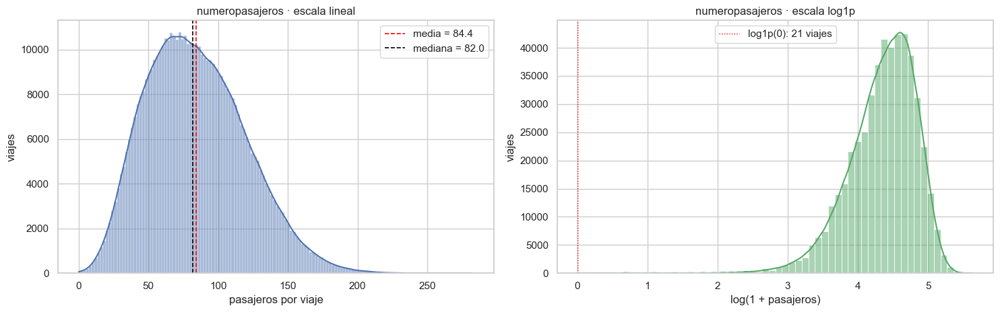

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
sns.histplot(y, bins=np.arange(-0.5, y.max() + 2, 2), kde=True, ax=ax[0], color="#4C72B0", edgecolor=None)  # bins de 2 enteros exactos
for v, c, t in [(y.mean(), "red", "media"), (y.median(), "black", "mediana")]:
    ax[0].axvline(v, color=c, ls="--", lw=1.2, label=f"{t} = {v:.1f}")
ax[0].set(title="numeropasajeros · escala lineal", xlabel="pasajeros por viaje", ylabel="viajes"); ax[0].legend()
sns.histplot(np.log1p(y), bins=60, kde=True, ax=ax[1], color="#55A868", edgecolor=None)
ax[1].axvline(0, color="red", lw=1, ls=":", label=f"log1p(0): {ceros} viajes")
ax[1].set(title="numeropasajeros · escala log1p", xlabel="log(1 + pasajeros)", ylabel="viajes"); ax[1].legend()
plt.tight_layout(); plt.savefig(SALIDA / "histograma_kde.png", dpi=130); plt.show()

**Conclusión 3a · Distribución unimodal; log1p empeora la forma**
- En escala lineal la distribución es unimodal, con media y mediana casi iguales (84 y 82).
- **log1p sobrecorrige:** la asimetría pasa de +0,42 a **−0,94**, con una cola izquierda larga. **No conviene transformar el target con log1p.** Si un modelo lo necesitara, la raíz cuadrada deja la distribución casi simétrica (−0,15).

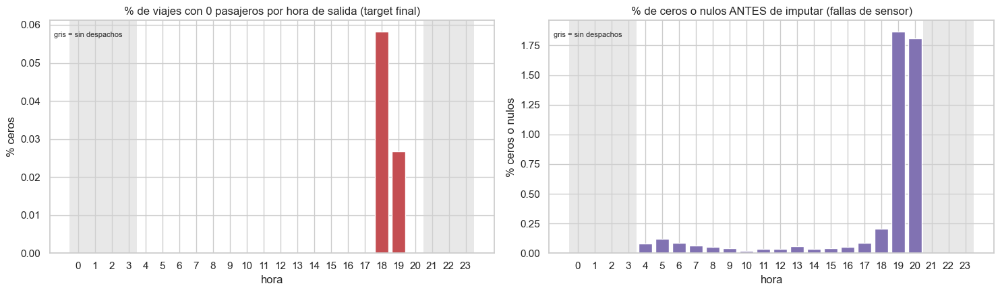

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
h = por_hora.reset_index()
ax[0].bar(h.hora, h.pct_ceros.fillna(0), color="#C44E52")
ax[0].set(title="% de viajes con 0 pasajeros por hora de salida (target final)", xlabel="hora", ylabel="% ceros", xticks=range(24))
ax[1].bar(h.hora, h.pct_ceros_o_nulos_raw.fillna(0), color="#8172B2")
ax[1].set(title="% de ceros o nulos ANTES de imputar (fallas de sensor)", xlabel="hora", ylabel="% ceros o nulos", xticks=range(24))
for a in ax:
    for hh in h.hora[h.viajes.isna()]:
        a.axvspan(hh - .5, hh + .5, color="lightgrey", alpha=.5, lw=0)
    a.text(.01, .93, "gris = sin despachos", transform=a.transAxes, fontsize=8)
plt.tight_layout(); plt.savefig(SALIDA / "pct_ceros_por_hora.png", dpi=130); plt.show()

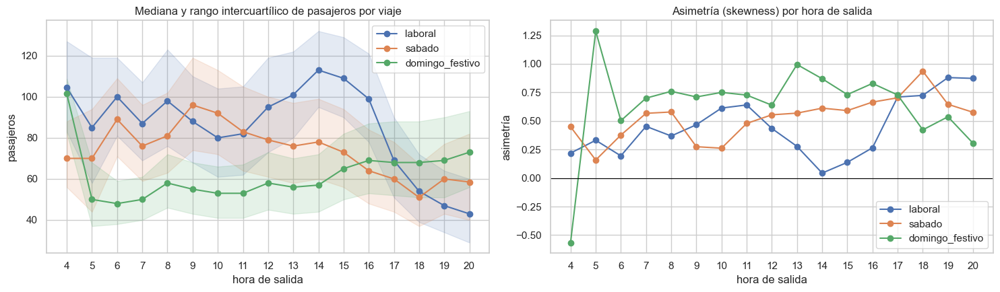

hora,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
tipo_dia,,,,,,,,,,,,,,,,,
laboral,104.5,85.0,100.0,87.0,98.0,88.0,80.0,82.0,95.0,101.0,113.0,109.0,99.0,69.0,54.0,47.0,43.0
sabado,70.0,70.0,89.0,76.0,81.0,96.0,92.0,83.0,79.0,76.0,78.0,73.0,64.0,60.0,51.0,60.0,58.5
domingo_festivo,101.5,50.0,48.0,50.0,58.0,55.0,53.0,53.0,58.0,56.0,57.0,65.0,69.0,68.0,68.0,69.0,73.0


In [6]:
# Asimetría de la demanda por franja horaria y tipo de día
q = (m.groupby(["tipo_dia", "hora"]).numeropasajeros
       .agg(p25=lambda s: s.quantile(.25), mediana="median", p75=lambda s: s.quantile(.75), asimetria="skew").reset_index())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for t, c in zip(ORDEN_DIA, ["#4C72B0", "#DD8452", "#55A868"]):
    d = q[q.tipo_dia == t]
    ax[0].plot(d.hora, d.mediana, marker="o", color=c, label=t)
    ax[0].fill_between(d.hora, d.p25, d.p75, color=c, alpha=.15)
    ax[1].plot(d.hora, d.asimetria, marker="o", color=c, label=t)
ax[0].set(title="Mediana y rango intercuartílico de pasajeros por viaje", xlabel="hora de salida", ylabel="pasajeros")
ax[1].axhline(0, color="black", lw=.8)
ax[1].set(title="Asimetría (skewness) por hora de salida", xlabel="hora de salida", ylabel="asimetría")
for a in ax:
    a.legend(); a.set_xticks(range(4, 21))
plt.tight_layout(); plt.savefig(SALIDA / "asimetria_hora_tipodia.png", dpi=130); plt.show()
display(q.pivot(index="tipo_dia", columns="hora", values="mediana").reindex(ORDEN_DIA))

**Conclusión 3b · Cada tipo de día tiene un perfil horario distinto**
- **Laboral:** dos máximos, a las 4 h y 6 h (medianas de 104 y 100) y a las **14 h (113)**. Cae a **43 a las 20 h (−62 %)**.
- **Sábado:** máximo a las 9 h (96) y descenso gradual.
- **Domingo-festivo:** plano en la mañana (48–58) y **sube por la tarde hasta 73 a las 20 h**. Es el único día con más demanda al cierre que en la mañana.
- **La hora es la de salida**, y cada viaje dura unas 4 h: un viaje que sale a las 14 h recoge la demanda de 14 a 18 h. El máximo de las 14 h refleja la hora pico de la tarde.
- La asimetría es positiva en casi todas las franjas (entre 0 y 1,3): siempre hay algunos viajes muy cargados. Es más marcada en domingo. El punto del domingo a las 4 h solo tiene 22 viajes y no se interpreta.

## 4. ¿Sobredispersión? ¿Ceros de más? (prueba cuantitativa)
- **Índice de dispersión** D = varianza / media. En un proceso de Poisson D = 1; con D > 1 hay sobredispersión. Se calcula global y **dentro de celdas homogéneas** (ruta × hora × tipo de día, n ≥ 30), para que la variación entre franjas no lo infle.
- **Ceros esperados vs. observados:** en cada celda se calcula la probabilidad de 0 con Poisson, P(0) = e^(−μ), y con una Binomial Negativa ajustada por momentos, P(0) = (r / (r + μ))^r con r = μ² / (σ² − μ). Si los ceros observados superan con creces a los esperados, hay inflación de ceros.

Índice de dispersión global: 14.83
Índice de dispersión dentro de celdas (150 celdas, 497,349 viajes): mediana 9.76 | P10 6.65 | P90 12.48 | mínimo 3.69


,ceros_observados,esperados_Poisson,esperados_BinomialNegativa
0,21,0.0,0.9801


,count,min,50%,max
tipo_dia,,,,
laboral,51.0,6.65,10.14,22.99
sabado,51.0,5.52,10.12,17.75
domingo_festivo,48.0,3.69,8.37,12.78


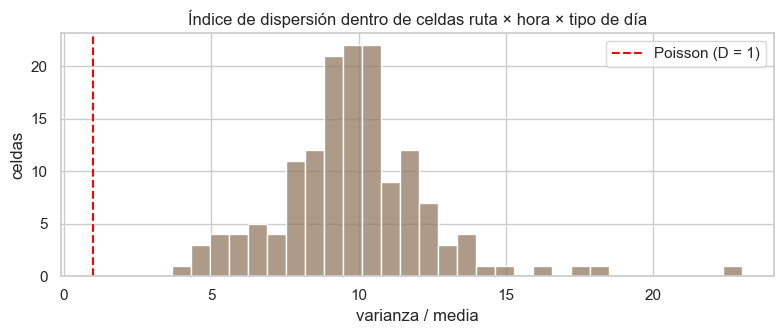

In [7]:
cel = (m.groupby(["idruta", "hora", "tipo_dia"]).numeropasajeros
         .agg(n="size", media="mean", var="var", ceros=lambda s: int((s == 0).sum())).reset_index())
cel = cel[cel.n >= 30].copy()
cel["D"] = cel["var"] / cel.media
cel["r_nb"] = cel.media ** 2 / (cel["var"] - cel.media)
cel["ceros_esp_poisson"] = cel.n * np.exp(-cel.media)
cel["ceros_esp_nb"] = cel.n * (cel.r_nb / (cel.r_nb + cel.media)) ** cel.r_nb
print(f"Índice de dispersión global: {y.var() / y.mean():.2f}")
print(f"Índice de dispersión dentro de celdas ({len(cel)} celdas, {cel.n.sum():,} viajes): mediana {cel.D.median():.2f} "
      f"| P10 {cel.D.quantile(.1):.2f} | P90 {cel.D.quantile(.9):.2f} | mínimo {cel.D.min():.2f}")
display(pd.DataFrame({"ceros_observados": [cel.ceros.sum()],
                      "esperados_Poisson": [cel.ceros_esp_poisson.sum()],
                      "esperados_BinomialNegativa": [cel.ceros_esp_nb.sum()]}).round(4))
display(cel.groupby("tipo_dia").D.describe()[["count", "min", "50%", "max"]].reindex(ORDEN_DIA).round(2))
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(cel.D, bins=30, ax=ax, color="#937860")
ax.axvline(1, color="red", ls="--", label="Poisson (D = 1)"); ax.legend()
ax.set(title="Índice de dispersión dentro de celdas ruta × hora × tipo de día", xlabel="varianza / media", ylabel="celdas")
plt.tight_layout(); plt.savefig(SALIDA / "indice_dispersion_celdas.png", dpi=130); plt.show()

**Conclusión 4 · Sobredispersión fuerte y sin inflación de ceros**
- **Sobredispersión: sí, y robusta.** El índice global es D = 14,8. **Dentro de las 150 celdas homogéneas (ruta × hora × tipo de día), la mediana es 9,8** (P10 a P90 = 6,7 a 12,5; mínimo 3,7). **Todas las celdas superan con creces D = 1.** Viajes de la misma ruta, hora y tipo de día varían unas 10 veces más de lo que permite un proceso de Poisson.
- **Inflación de ceros: no relevante.** Se observan 21 ceros frente a 0 esperados con Poisson y 0,98 con Binomial Negativa. Es un exceso relativo, pero equivale al 0,004 % de los viajes.
- **¿Se acumulan ceros en los valles nocturnos? No.** El valle de la tarde (18–20 h) baja a medianas de **43–56 pasajeros**, lejos de cero, y de 21 a 3 h no hay servicio. Los ceros que sí había en el valle eran fallas del sensor y ya se imputaron.

## Conclusión de la Subfase 2.1
1. **El target `numeropasajeros` (subidas por viaje) es un conteo grande, casi simétrico** (media 84, mediana 82, asimetría 0,42, curtosis −0,13) y **sin masa en cero** (0,0042 %).
2. **Hay sobredispersión fuerte incluso dentro de cada ruta, hora y tipo de día** (D mediano de 9,8): **Poisson no sirve** porque subestimaría la varianza unas 10 veces. La familia adecuada es la **Binomial Negativa** (o quasi-Poisson / Tweedie). **Los modelos zero-inflated (ZIP/ZINB) no hacen falta** a nivel de viaje.
3. **El tipo de día y la hora explican la mayor parte de la variación:** el domingo-festivo tiene un 33 % menos de demanda que el laboral, y el laboral cae un 62 % entre las 14 y las 20 h. **Los festivos deben tratarse como domingo** (13.697 viajes reclasificados).
4. **No transformar con log1p** (invierte la asimetría hasta −0,94).
5. **Cautela para el análisis espacial:** si se baja a tramo, parada o intervalos de 15 min, el diagnóstico de ceros debe repetirse a esa escala, donde sí aparecerán ceros estructurales.

Tabla resumen: `resultados_2_1/tabla_resumen_numeropasajeros.csv` · gráficos: `resultados_2_1/*.png`.

<a id="m2-2"></a>

### A1.2.2 &middot; Subfase 2.2 · Sobredispersión y parámetro Tweedie p

<sub>Notebook original: `subfase_2_2_tweedie.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 2.2 — Sobredispersión y estimación del parámetro Tweedie $p$

**Objetivo:** estimar $p$ en la relación media-varianza $\mathrm{Var}(Y)=\phi\,\mu^{p}$ de `numeropasajeros` y decidir si la pérdida Tweedie ($1<p<2$) está justificada frente a Poisson o Binomial Negativa.

**Fuente:** `maestras/tb_maestra_progvehiculos_limpia.parquet` (497.371 viajes válidos). Tipo de día con festivos (igual que en la 2.1).

**Corrección a la premisa del enunciado:** la 2.1 mostró que **no hay ceros estructurales** (21 ceros de 497.371, el 0,0042 %). Por eso aquí **Tweedie no se justifica por una masa en cero**, sino únicamente por la forma de la relación media-varianza (ver la sección 4).

Nota técnica: la regresión se hace con `numpy` (mínimos cuadrados e intervalo de confianza bootstrap), porque Windows bloquea las DLL de `scipy` y `sklearn` en este equipo.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid"); warnings.filterwarnings("ignore", category=FutureWarning)

SALIDA = Path("resultados_2_2"); SALIDA.mkdir(exist_ok=True)
m = pd.read_parquet("maestras/tb_maestra_progvehiculos_limpia.parquet")
m["numeropasajeros"] = m.numeropasajeros.astype(float)
festivos = holidays.Colombia(years=[2023, 2024, 2025])
es_festivo = m.fecha.dt.date.map(lambda d: d in festivos)
m["tipo_dia"] = np.select([es_festivo | (m.dia_semana == 6), m.dia_semana == 5], ["domingo_festivo", "sabado"], "laboral")
m["franja_15"] = m.fechasalida.dt.floor("15min").dt.strftime("%H:%M")
ORDEN_DIA = ["laboral", "sabado", "domingo_festivo"]
N_MIN = 30   # mínimo de viajes por estrato para estimar la varianza con estabilidad

def estratos(claves, n_min=N_MIN):
    g = m.groupby(claves).numeropasajeros.agg(n="size", mu="mean", var="var").reset_index()
    return g[g.n >= n_min].reset_index(drop=True)

def ols(x, y, w=None):
    """Mínimos cuadrados (ponderados si w) de y = a + b·x. Devuelve a, b, error estándar de b y R²."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    w = np.ones_like(x) if w is None else np.asarray(w, float)
    X = np.column_stack([np.ones_like(x), x]); XtW = X.T * w
    a, b = np.linalg.solve(XtW @ X, XtW @ y)
    r = y - (a + b * x); ss_res = (w * r ** 2).sum(); ss_tot = (w * (y - np.average(y, weights=w)) ** 2).sum()
    se_b = np.sqrt(ss_res / (len(x) - 2) * np.linalg.inv(XtW @ X)[1, 1])
    return a, b, se_b, 1 - ss_res / ss_tot

## 1. Estratos operacionales (ruta × franja de 15 min × tipo de día) e índice de dispersión

In [2]:
G = estratos(["idruta", "franja_15", "tipo_dia"])
G["D"] = G["var"] / G.mu
total = m.groupby(["idruta", "franja_15", "tipo_dia"]).ngroups
print(f"Estratos: {total} | con n ≥ {N_MIN}: {len(G)} | viajes cubiertos: {G.n.sum():,} de {len(m):,}")
phi_global = m.numeropasajeros.var() / m.numeropasajeros.mean()
print(f"Índice de dispersión global φ = Var/Media = {m.numeropasajeros.var():,.1f} / {m.numeropasajeros.mean():.2f} = {phi_global:.2f}"
      f"  → {'SOBREDISPERSIÓN (φ > 1)' if phi_global > 1 else 'sin sobredispersión'}")
print(f"Índice de dispersión por estrato: mediana {G.D.median():.2f} | P10 {G.D.quantile(.1):.2f} | P90 {G.D.quantile(.9):.2f} | "
      f"estratos con D > 1: {(G.D > 1).mean():.1%}")
display(G[["n", "mu", "var", "D"]].describe().round(2))
G.to_csv(SALIDA / "estratos_ruta_franja15_tipodia.csv", index=False)

Estratos: 581 | con n ≥ 30: 575 | viajes cubiertos: 497,321 de 497,371
Índice de dispersión global φ = Var/Media = 1,252.4 / 84.43 = 14.83  → SOBREDISPERSIÓN (φ > 1)
Índice de dispersión por estrato: mediana 9.60 | P10 6.18 | P90 12.79 | estratos con D > 1: 100.0%


,n,mu,var,D
count,575.00,575.00,575.00,575.00
mean,864.91,75.70,742.81,9.64
std,976.24,19.16,303.12,2.82
min,32.00,23.16,120.91,3.19
25%,243.00,59.44,537.98,8.08
50%,515.00,75.71,738.70,9.60
75%,1031.00,89.75,931.29,10.93
max,6279.00,117.78,2152.39,26.04


**Conclusión 1 · Sobredispersión confirmada en todos los estratos**
- **Índice global: φ = 1.252,4 / 84,43 = 14,83 > 1.**
- **El 100 % de los 575 estratos** (ruta × franja de 15 min × tipo de día, n ≥ 30, que cubren 497.321 viajes) tiene D > 1. La mediana es 9,6 (P10 a P90 = 6,2 a 12,8; mínimo 3,2).
- La varianza entre estratos va de 121 a 2.152 (**18 veces**), mientras la media solo va de 23 a 118 (5 veces): la varianza crece más rápido que la media.

## 2. Ajuste log-log: $\ln\sigma^2_g = \ln\phi + p\,\ln\mu_g$
Además del ajuste libre se comparan las relaciones media-varianza de los modelos candidatos, midiendo cuánto de la varianza de $\ln\sigma^2_g$ explica cada uno ($R^2$ en escala log):
| Modelo | Varianza implícita |
|---|---|
| Poisson | $\mu$ |
| quasi-Poisson ($p=1$) | $\phi\,\mu$ |
| Binomial Negativa | $\mu + \alpha\,\mu^2$ |
| Gamma ($p=2$) | $\phi\,\mu^2$ |
| **Tweedie ($p$ libre)** | $\phi\,\mu^{p}$ |

In [3]:
x, yv = np.log(G.mu.values), np.log(G["var"].values)
a, p_hat, se_p, r2 = ols(x, yv)
phi_hat = np.exp(a)
rng = np.random.default_rng(42)
boot = np.array([ols(x[i], yv[i])[1] for i in (rng.integers(0, len(x), len(x)) for _ in range(2000))])
ic_boot = np.percentile(boot, [2.5, 97.5])
print(f"p̂ = {p_hat:.3f}  (EE {se_p:.3f} · IC95 analítico [{p_hat - 1.96 * se_p:.3f}, {p_hat + 1.96 * se_p:.3f}] · "
      f"IC95 bootstrap [{ic_boot[0]:.3f}, {ic_boot[1]:.3f}])")
print(f"φ̂ = {phi_hat:.3f}  |  R² = {r2:.3f}  |  ¿1 < p̂ < 2? {'SÍ' if 1 < p_hat < 2 else 'NO'} "
      f"(el IC bootstrap {'excluye' if ic_boot[0] > 1 and ic_boot[1] < 2 else 'NO excluye'} 1 y 2)")

def r2_log(var_pred):
    r = yv - np.log(np.asarray(var_pred, float)); return 1 - (r ** 2).sum() / ((yv - yv.mean()) ** 2).sum()

alpha_nb = ((G["var"] - G.mu) * G.mu ** 2).sum() / (G.mu ** 4).sum()
comp = pd.DataFrame({
    "modelo": ["Poisson", "quasi-Poisson (p=1)", "Binomial Negativa", "Gamma (p=2)", "Tweedie (p libre)"],
    "parametros": ["φ=1", f"φ={np.exp((yv - x).mean()):.2f}", f"α={alpha_nb:.3f} (r≈{1 / alpha_nb:.1f})",
                   f"φ={np.exp((yv - 2 * x).mean()):.3f}", f"φ={phi_hat:.2f}, p={p_hat:.2f}"],
    "R2_log_varianza": [r2_log(G.mu), r2_log(np.exp((yv - x).mean()) * G.mu), r2_log(G.mu + alpha_nb * G.mu ** 2),
                        r2_log(np.exp((yv - 2 * x).mean()) * G.mu ** 2), r2_log(phi_hat * G.mu ** p_hat)]}).round(3)
display(comp)
pd.DataFrame([{"p_hat": p_hat, "se": se_p, "ic95_boot_lo": ic_boot[0], "ic95_boot_hi": ic_boot[1], "phi_hat": phi_hat,
               "R2": r2, "estratos": len(G), "phi_global": phi_global}]).to_csv(SALIDA / "estimacion_p.csv", index=False)

p̂ = 1.397  (EE 0.044 · IC95 analítico [1.310, 1.483] · IC95 bootstrap [1.294, 1.499])
φ̂ = 1.682  |  R² = 0.635  |  ¿1 < p̂ < 2? SÍ (el IC bootstrap excluye 1 y 2)


,modelo,parametros,R2_log_varianza
0,Poisson,φ=1,-22.399
1,quasi-Poisson (p=1),φ=9.23,0.584
2,Binomial Negativa,α=0.101 (r≈9.9),0.518
3,Gamma (p=2),φ=0.126,0.517
4,Tweedie (p libre),"φ=1.68, p=1.40",0.635


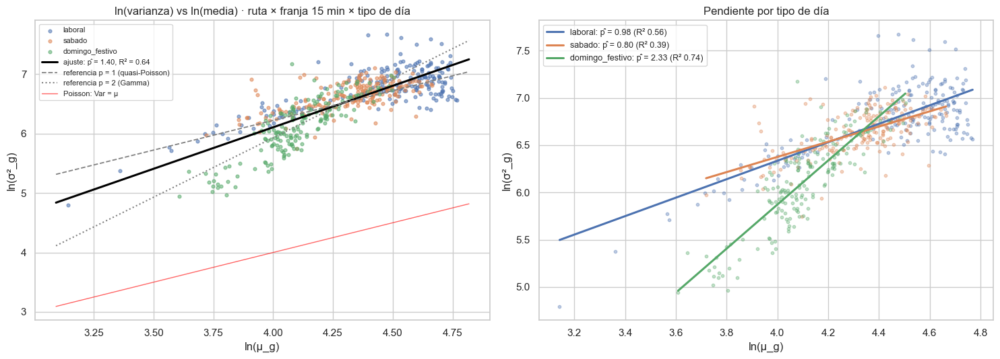

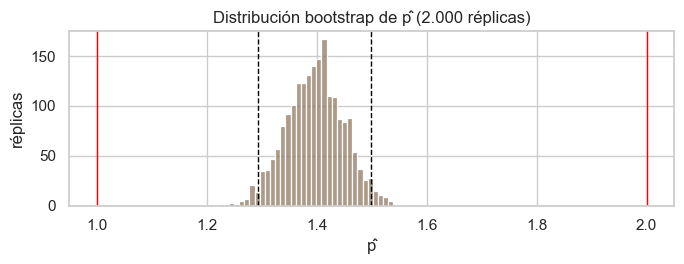

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
xs = np.linspace(x.min() - .05, x.max() + .05, 50)
xm, ym = x.mean(), yv.mean()
colores = dict(zip(ORDEN_DIA, ["#4C72B0", "#DD8452", "#55A868"]))
for t in ORDEN_DIA:
    s = G.tipo_dia == t
    ax[0].scatter(x[s], yv[s], s=12, alpha=.55, color=colores[t], label=t)
ax[0].plot(xs, a + p_hat * xs, color="black", lw=2.2, label=f"ajuste: p̂ = {p_hat:.2f}, R² = {r2:.2f}")
ax[0].plot(xs, ym + 1 * (xs - xm), "--", color="grey", lw=1.3, label="referencia p = 1 (quasi-Poisson)")
ax[0].plot(xs, ym + 2 * (xs - xm), ":", color="grey", lw=1.5, label="referencia p = 2 (Gamma)")
ax[0].plot(xs, xs, color="red", lw=1, alpha=.6, label="Poisson: Var = μ")
ax[0].set(title="ln(varianza) vs ln(media) · ruta × franja 15 min × tipo de día", xlabel="ln(μ_g)", ylabel="ln(σ²_g)")
ax[0].legend(fontsize=8, loc="upper left")
for t in ORDEN_DIA:
    s = (G.tipo_dia == t).values
    at, bt, _, rt = ols(x[s], yv[s])
    ax[1].scatter(x[s], yv[s], s=10, alpha=.35, color=colores[t])
    xx = np.linspace(x[s].min(), x[s].max(), 20)
    ax[1].plot(xx, at + bt * xx, color=colores[t], lw=2.2, label=f"{t}: p̂ = {bt:.2f} (R² {rt:.2f})")
ax[1].set(title="Pendiente por tipo de día", xlabel="ln(μ_g)", ylabel="ln(σ²_g)"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.savefig(SALIDA / "loglog_media_varianza.png", dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(7, 2.8))
sns.histplot(boot, bins=40, ax=ax, color="#937860")
for v in ic_boot: ax.axvline(v, color="black", ls="--", lw=1)
ax.axvline(1, color="red", lw=1); ax.axvline(2, color="red", lw=1)
ax.set(title="Distribución bootstrap de p̂ (2.000 réplicas)", xlabel="p̂", ylabel="réplicas")
plt.tight_layout(); plt.savefig(SALIDA / "bootstrap_p.png", dpi=130); plt.show()

**Conclusión 2 · $\hat p$ = 1,40 está dentro de (1, 2), y la ley de potencia libre es la que mejor describe la varianza**
- **$\hat p$ = 1,397, con IC95 bootstrap de 1,29 a 1,50**: excluye tanto 1 como 2. $\hat\phi$ = 1,68 y $R^2$ = 0,64.
- **Comparación de relaciones media-varianza** ($R^2$ sobre $\ln\sigma^2$):

| Modelo | $R^2$ |
|---|---|
| **Tweedie con $p$ libre** | **0,64** |
| quasi-Poisson ($p$ = 1, φ = 9,2) | 0,58 |
| Binomial Negativa ($\alpha$ = 0,10) | 0,52 |
| Gamma ($p$ = 2) | 0,52 |
| Poisson | −22,4 |

- **Poisson queda descartado:** su recta (en rojo) está unas 2,2 unidades de log por debajo de los datos, es decir, subestima la varianza unas 9 veces.
- El panel derecho muestra que **la pendiente no es igual en todos los días:** laboral 0,98, sábado 0,80 y **domingo-festivo 2,33**. El $\hat p$ = 1,40 conjunto mezcla esos regímenes (ver la sección 3).

## 3. Robustez: ¿el valor de $p$ depende de cómo se estratifica?

In [5]:
filas = []
def agregar(etiqueta, H, w=None):
    a_, b_, se_, r_ = ols(np.log(H.mu), np.log(H["var"]), w)
    filas.append({"especificacion": etiqueta, "estratos": len(H), "viajes": int(H.n.sum()), "p_hat": b_,
                  "ic95": f"[{b_ - 1.96 * se_:.2f}, {b_ + 1.96 * se_:.2f}]", "phi": np.exp(a_), "R2": r_,
                  "mu_min": H.mu.min(), "mu_max": H.mu.max()})

agregar("BASE: ruta × franja15 × tipo_día", G)
agregar("BASE ponderada por n", G, G.n)
for t in ORDEN_DIA:
    agregar(f"solo {t}", G[G.tipo_dia == t])
for r in sorted(G.idruta.unique()):
    agregar(f"solo ruta {r}", G[G.idruta == r])
agregar("ruta × hora × tipo_día × MES (n ≥ 20)", estratos(["idruta", "hora", "tipo_dia", "anio_mes"], 20))
agregar("ruta × franja15 × tipo_día × MES (n ≥ 20)", estratos(["idruta", "franja_15", "tipo_dia", "anio_mes"], 20))
rob = pd.DataFrame(filas)
rob.to_csv(SALIDA / "robustez_p.csv", index=False)
display(rob.round(3))

,especificacion,estratos,viajes,p_hat,ic95,phi,R2,mu_min,mu_max
0,BASE: ruta × franja15 × tipo_día,575,497321,1.397,"[1.31, 1.48]",1.682,0.635,23.156,117.780
1,BASE ponderada por n,575,497321,1.108,"[1.01, 1.20]",6.058,0.474,23.156,117.780
2,solo laboral,197,363881,0.977,"[0.86, 1.10]",11.352,0.565,23.156,117.780
3,solo sabado,195,71850,0.803,"[0.66, 0.94]",23.651,0.394,41.230,106.111
4,solo domingo_festivo,183,61590,2.330,"[2.13, 2.53]",0.032,0.740,36.922,90.361
5,solo ruta 2,191,138609,1.476,"[1.36, 1.59]",1.400,0.757,28.794,114.612
6,solo ruta 16,192,271119,1.331,"[1.18, 1.48]",2.003,0.625,42.439,117.780
7,solo ruta 21,192,87593,1.510,"[1.36, 1.66]",0.989,0.671,23.156,115.574
8,ruta × hora × tipo_día × MES (n ≥ 20),4578,486181,1.258,"[1.22, 1.29]",2.810,0.497,24.399,142.014
9,ruta × franja15 × tipo_día × MES (n ≥ 20),7560,378691,1.066,"[1.04, 1.09]",6.372,0.404,14.967,143.139


**Conclusión 3 · $p$ es real pero no universal: el rango defendible es de 1,1 a 1,5**
- **Por ruta es estable:** 1,48 (ruta 2), 1,33 (ruta 16) y 1,51 (ruta 21).
- **Por tipo de día no lo es:**
  - **Laboral y sábado:** $p$ ≈ 0,8–1,0. La varianza crece proporcional a la media, con φ de 11 a 24 (comportamiento quasi-Poisson).
  - **Domingo-festivo:** $p$ ≈ 2,3. Hay más heterogeneidad relativa cuando la demanda sube.
- **Al controlar el mes**, es decir, al quitar la tendencia 2023–2025 y la estacionalidad, $p$ baja a **1,26** (estratos ruta × hora × tipo de día × mes) y a **1,07** (con franja de 15 min). **Ponderando por tamaño del estrato** queda en 1,11.
- **Lectura:** una parte del 1,40 conjunto viene de mezclar meses y días con niveles distintos. Un modelo que ya tenga como variables el tipo de día, la hora y el calendario verá una varianza residual con **$p$ más cerca de 1,1–1,3**.

## 4. Justificación teórica y configuración recomendada

**La familia Tweedie.** Es la familia de dispersión exponencial con $\mathrm{Var}(Y)=\phi\,\mu^{p}$:
- $p=1$: Poisson ($\phi=1$) o quasi-Poisson ($\phi$ libre).
- $p=2$: Gamma.
- **$1<p<2$: Poisson compuesta-Gamma**, una masa en cero más una parte continua positiva.

**Corrección importante a la premisa del enunciado.** `numeropasajeros` **no tiene masa en cero** (0,0042 %, 2.1) y es un **conteo discreto**. Por eso la distribución Poisson compuesta-Gamma **no es su modelo generativo**. Lo que sí se justifica es usar **Tweedie como función de pérdida (cuasi-verosimilitud)**:
- Un GLM o un GBM con pérdida Tweedie solo necesita que la **media** (con enlace log) y la **función de varianza** $\phi\,\mu^{p}$ estén bien especificadas, y que $y\ge 0$.
- No necesita que $Y$ sea realmente Poisson compuesta-Gamma. Es el principio de cuasi-verosimilitud de McCullagh y Nelder.

**Por qué `objective='tweedie'` en LightGBM y XGBoost:**
1. **La varianza no es constante.** Crece 18 veces entre estratos, así que MSE (`regression`), que supone varianza constante, sobrepondera los viajes de alta demanda.
2. **La varianza no es igual a la media.** Poisson la subestima unas 9 veces en nivel. En un GBM φ no cambia la predicción puntual, así que `objective='poisson'` equivale a quasi-Poisson ($p$ = 1). **La diferencia real entre las pérdidas Poisson y Tweedie es el valor de $p$**, y los datos dan $\hat p$ > 1 (IC de 1,29 a 1,50).
3. **La Binomial Negativa no está disponible** como objetivo en LightGBM ni en XGBoost, y además su varianza cuadrática ajusta peor (0,52 frente a 0,64).
4. **Ventajas del enlace log de Tweedie:** las predicciones nunca son negativas, y los efectos de hora, día y ruta se combinan de forma multiplicativa, coherente con los perfiles de la 2.1.

**Valor inicial recomendado: `tweedie_variance_power = 1.3`.** Está en el centro del rango robusto: entre el 1,40 conjunto y el 1,07–1,26 de la varianza condicional al mes. Después hay que ajustarlo con **validación temporal** (entrenar en el pasado y evaluar en meses posteriores) sobre la rejilla {1.1, 1.2, 1.3, 1.4, 1.5}, con `objective='poisson'` como línea base.

```python
# LightGBM
params_lgb = {"objective": "tweedie", "tweedie_variance_power": 1.3, "metric": ["tweedie", "mae"]}
# XGBoost
params_xgb = {"objective": "reg:tweedie", "tweedie_variance_power": 1.3, "eval_metric": ["tweedie-nloglik@1.3", "mae"]}
```

**Cautelas:**
- Como el domingo-festivo tiene $p$ ≈ 2,3, conviene **evaluar el error por tipo de día**: un $p$ único es un compromiso.
- En este equipo **`lightgbm` y `xgboost` no están instalados**, y Windows bloquea `scipy` y `sklearn`. Hay que resolverlo antes de la fase de modelado.

## Conclusión de la Subfase 2.2
1. **Sobredispersión confirmada:** φ global = 14,8 y D > 1 en el 100 % de los 575 estratos (mediana 9,6). **Poisson queda descartado.**
2. **$\hat p$ = 1,40 (IC95 de 1,29 a 1,50, $R^2$ = 0,64):** $1<\hat p<2$ se cumple y la ley de potencia libre describe la varianza mejor que quasi-Poisson, Binomial Negativa o Gamma.
3. **$p$ no es universal:** es estable entre rutas (1,33–1,51), pero cerca de 1 en laboral y sábado, cerca de 2,3 en domingo-festivo, y de 1,07–1,26 cuando se controla el mes.
4. **Recomendación:** `objective='tweedie'` con **`tweedie_variance_power = 1.3`** como valor inicial, ajustado con validación temporal en {1.1 … 1.5} y comparado con Poisson.
5. **Se justifica por la relación media-varianza, no por ceros:** el target no tiene masa en cero, así que Tweedie se usa como cuasi-verosimilitud y no como modelo generativo.

Salidas: `resultados_2_2/estimacion_p.csv`, `robustez_p.csv`, `estratos_ruta_franja15_tipodia.csv`, `loglog_media_varianza.png`, `bootstrap_p.png`.

<a id="m2-3"></a>

### A1.2.3 &middot; Subfase 2.3 · Outliers del target y capacidad física del bus

<sub>Notebook original: `subfase_2_3_outliers.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 2.3 — Outliers del target y capacidad física del bus

**Objetivo:** definir la regla final de filtrado o truncamiento de `numeropasajeros` para el dataset de entrenamiento, sin dejar que errores de sensor contaminen la pérdida y sin sesgar las métricas.

**Fuente:** `maestras/tb_maestra_progvehiculos_limpia.parquet` (497.371 viajes) + `datos_1_3/tabla_vehiculos.csv` (`n_sentados + n_depie`) + `datos_1_3/lecturas.csv` (secuencias de 1.673 viajes).

**Advertencia de partida:** `numeropasajeros` son las **subidas totales de un viaje de unas 4 h**, no la ocupación simultánea. La capacidad del bus limita cuántas personas van **a la vez**, no cuántas suben en todo el recorrido. Por eso la regla `numeropasajeros > 1,5 × capacidad` se audita aquí, pero no se adopta sin comprobarla.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from IPython.display import display
import filtros_1_3 as f3
import filtros_2_3 as f23
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid"); warnings.filterwarnings("ignore", category=FutureWarning)

SALIDA = Path("resultados_2_3"); SALIDA.mkdir(exist_ok=True)
m = pd.read_parquet("maestras/tb_maestra_progvehiculos_limpia.parquet")
m["y"] = m.numeropasajeros.astype(float)
festivos = holidays.Colombia(years=[2023, 2024, 2025])
es_festivo = m.fecha.dt.date.map(lambda d: d in festivos)
m["tipo_dia"] = np.select([es_festivo | (m.dia_semana == 6), m.dia_semana == 5], ["domingo_festivo", "sabado"], "laboral")
m["franja_15"] = m.fechasalida.dt.floor("15min").dt.strftime("%H:%M")

veh = pd.read_csv("datos_1_3/tabla_vehiculos.csv")
veh["cap_bus"] = veh.n_sentados.fillna(0) + veh.n_depie.fillna(0)
cap_modelo = veh[veh.cap_bus > 0].groupby(veh.modelo.astype("string").fillna("SIN_MODELO")).cap_bus.max()
m["capacidad_calculada_max"] = m.modelo.astype("string").map(cap_modelo).fillna(74)
print(f"{len(m):,} viajes | capacidad del bus: mediana {m.capacidad.median():.0f} (32–74) | "
      f"capacidad máxima del modelo: mediana {m.capacidad_calculada_max.median():.0f} (46–74)")

497,371 viajes | capacidad del bus: mediana 50 (32–74) | capacidad máxima del modelo: mediana 70 (46–74)


## 1. Auditoría de percentiles y sobreocupación
Consulta SQL (archivo `auditoria_2_3.sql`, para cuando la maestra exista en PostgreSQL):
```sql
-- =====================================================================================
-- SOBUSA · Subfase 2.3 — Auditoría de outliers del target y capacidad física
-- Requiere public.tb_maestra_progvehiculos_limpia (tb_maestras_modulo1.sql) y public.vehiculos.
-- La misma lógica corre en local en subfase_2_3_outliers.ipynb (la tabla maestra no existe aún en la RDS).
-- =====================================================================================

WITH cap_modelo AS (            -- capacidad máxima calculada por modelo: max(n_sentados + n_depie)
    SELECT COALESCE(modelo, 'SIN_MODELO') AS modelo,
           max(COALESCE(n_sentados, 0) + COALESCE(n_depie, 0)) AS capacidad_calculada_max
    FROM public.vehiculos
    WHERE COALESCE(n_sentados, 0) + COALESCE(n_depie, 0) > 0
    GROUP BY 1
), base AS (
    SELECT m.idprogramacion, m.idvehiculo, m.idruta, m.fechasalida, m.numeropasajeros,
           m.capacidad                                     AS capacidad_bus,
           COALESCE(c.capacidad_calculada_max, 74)         AS capacidad_calculada_max,
           m.pasajeros_imputado
    FROM public.tb_maestra_progvehiculos_limpia m
    LEFT JOIN cap_modelo c ON c.modelo = m.modelo
)
-- 1. Percentiles extremos globales y conteo de sobreocupación
SELECT count(*)                                                                    AS viajes,
       percentile_cont(0.95)  WITHIN GROUP (ORDER BY numeropasajeros)               AS p95,
       percentile_cont(0.99)  WITHIN GROUP (ORDER BY numeropasajeros)               AS p99,
       percentile_cont(0.995) WITHIN GROUP (ORDER BY numeropasajeros)               AS p99_5,
       percentile_cont(0.999) WITHIN GROUP (ORDER BY numeropasajeros)               AS p99_9,
       max(numeropasajeros)                                                        AS maximo,
       -- regla literal del enunciado (compara SUBIDAS DEL VIAJE con la capacidad SIMULTÁNEA: no es válida, ver notebook)
       count(*) FILTER (WHERE numeropasajeros > 1.5 * capacidad_calculada_max)     AS literal_cap_modelo,
       count(*) FILTER (WHERE numeropasajeros > 1.5 * capacidad_bus)               AS literal_cap_bus,
       -- regla física coherente: capacidad × 1,5 de carga máxima × 3,92 de renovación máxima (≈ 5,9 × capacidad)
       count(*) FILTER (WHERE numeropasajeros > capacidad_bus * 1.5 * 3.92)        AS outlier_fisico
FROM base;

-- 2. Detalle de los viajes por encima del límite físico (debe devolver 0 filas tras la 1.4)
WITH base AS (
    SELECT idprogramacion, idvehiculo, idruta, fechasalida, numeropasajeros, capacidad
    FROM public.tb_maestra_progvehiculos_limpia
)
SELECT *, round(numeropasajeros / capacidad, 2) AS subidas_por_puesto
FROM base
WHERE numeropasajeros > capacidad * 1.5 * 3.92
ORDER BY subidas_por_puesto DESC;
```
Equivalente ejecutado en local:

In [2]:
pct = m.y.quantile([.95, .99, .995, .999]).rename(lambda q: f"P{q * 100:g}")
display(pd.concat([pct, pd.Series({"máximo": m.y.max()})]).to_frame("pasajeros por viaje"))

reglas = {
    "literal: > 1,5 × capacidad máx. del modelo": m.y > 1.5 * m.capacidad_calculada_max,
    "literal: > 1,5 × capacidad del bus": m.y > 1.5 * m.capacidad,
    "> 3 × capacidad del bus": m.y > 3 * m.capacidad,
    "> 5 × capacidad del bus (pico imposible, 1.3)": m.y > 5 * m.capacidad,
}
display(pd.DataFrame({"viajes": {k: int(v.sum()) for k, v in reglas.items()},
                      "pct": {k: round(100 * v.mean(), 2) for k, v in reglas.items()}}))
display((m.y / m.capacidad).describe(percentiles=[.5, .9, .99, .999]).round(2).to_frame("subidas por puesto (y / capacidad)").T)

,pasajeros por viaje
P95,147.0
P99,174.0
P99.5,185.0
P99.9,206.0
máximo,282.0


,viajes,pct
"literal: > 1,5 × capacidad máx. del modelo",181818,36.56
"literal: > 1,5 × capacidad del bus",265648,53.41
> 3 × capacidad del bus,19167,3.85
"> 5 × capacidad del bus (pico imposible, 1.3)",0,0.00


,count,mean,std,min,50%,90%,99%,99.9%,max
subidas por puesto (y / capacidad),497371.0,1.64,0.71,0.0,1.57,2.59,3.52,4.28,5.0


**Conclusión 1 · La regla literal marcaría como imposible a más de un tercio de los viajes reales**
- **Percentiles extremos:** P95 = 147 · P99 = 174 · P99,5 = 185 · P99,9 = 206 · máximo = 282.
- `numeropasajeros > 1,5 × capacidad` marca **181.818 viajes (36,6 %)** con la capacidad máxima del modelo y **265.648 (53,4 %)** con la del bus. Con la capacidad mediana el corte cae en **105 pasajeros**, por encima de la mediana de la distribución (82).
- **En promedio, un viaje sube 1,64 veces la capacidad del bus** (P99 = 3,5; máximo = 5,0). No es error: es la renovación de pasajeros a lo largo de unas 4 h (sección 2).
- **No queda ningún viaje por encima de 5 veces la capacidad:** los 123 picos imposibles ya se detectaron en la 1.3 y se imputaron en la 1.4.

## 2. ¿Por qué las subidas del viaje superan la capacidad? Renovación de pasajeros (lecturas)

,rotacion,ocupacion_max,subidas_por_puesto
count,1440.00,1440.00,1440.00
mean,2.50,0.68,1.65
std,0.59,0.29,0.72
min,1.00,0.07,0.16
50%,2.47,0.66,1.58
90%,3.29,1.06,2.62
95%,3.54,1.16,2.88
99%,3.92,1.36,3.56
max,4.43,2.51,4.49


Límite físico de subidas por viaje = capacidad × 1.5 (carga máxima) × 3.92 (renovación P99) = 5.88 × capacidad


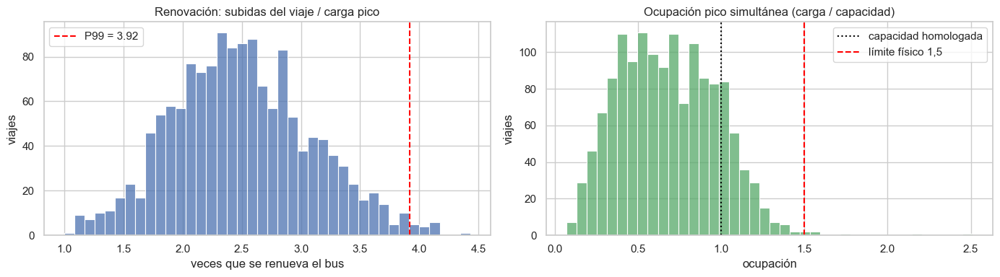

In [3]:
lect = pd.read_csv("datos_1_3/lecturas.csv", low_memory=False)
L = f3.auditar_lecturas(lect, m.drop_duplicates("idvehiculo").set_index("idvehiculo").capacidad, f3.Config(), secuencias=True)
R = f3.resumen_lecturas_por_viaje(L)
val = pd.read_parquet("datos_1_2/viajes_validos.parquet", columns=["idprogramacion", "idruta"])
ids_sv = pd.read_csv("datos_1_3/sensores_viaje.csv", usecols=["idprogramacion"])
AZAR = set(val.merge(ids_sv, on="idprogramacion").groupby("idruta", group_keys=False)
              .apply(lambda g: g.sample(min(500, len(g)), random_state=42), include_groups=False).idprogramacion)
A = R[R.index.isin(AZAR) & (R.calidad_conteo != "corrupto") & (R.max_a_bordo > 0)].copy()
A["rotacion"] = A.subidas_sensor / A.max_a_bordo          # cuántas veces se "llena" el bus en el viaje
A["subidas_por_puesto"] = A.subidas_sensor / A.capacidad
display(A[["rotacion", "ocupacion_max", "subidas_por_puesto"]].describe(percentiles=[.5, .9, .95, .99]).round(2))
regla = f23.ReglaTarget(rotacion_max=round(A.rotacion.quantile(.99), 2))
print(f"Límite físico de subidas por viaje = capacidad × {regla.factor_carga_max} (carga máxima) × {regla.rotacion_max} "
      f"(renovación P99) = {regla.multiplicador:.2f} × capacidad")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(A.rotacion, bins=40, ax=ax[0], color="#4C72B0")
ax[0].axvline(regla.rotacion_max, color="red", ls="--", label=f"P99 = {regla.rotacion_max}"); ax[0].legend()
ax[0].set(title="Renovación: subidas del viaje / carga pico", xlabel="veces que se renueva el bus", ylabel="viajes")
sns.histplot(A.ocupacion_max, bins=40, ax=ax[1], color="#55A868")
ax[1].axvline(1, color="black", ls=":", label="capacidad homologada")
ax[1].axvline(regla.factor_carga_max, color="red", ls="--", label="límite físico 1,5"); ax[1].legend()
ax[1].set(title="Ocupación pico simultánea (carga / capacidad)", xlabel="ocupación", ylabel="viajes")
plt.tight_layout(); plt.savefig(SALIDA / "renovacion_ocupacion.png", dpi=130); plt.show()

**Conclusión 2 · El bus se renueva unas 2,5 veces por viaje: por eso las subidas superan la capacidad**
- En 1.440 viajes al azar con lecturas, **las subidas del viaje equivalen a 2,47 veces la carga pico** (mediana; P99 = 3,92; máximo = 4,43). La ocupación pico simultánea tiene mediana 0,66 y P99 de 1,36.
- **El límite físico coherente para las subidas de un viaje es capacidad × 1,5 × 3,92 = 5,88 × capacidad**: la carga simultánea máxima por la renovación máxima observada. Con la capacidad mediana de 50 son 294 pasajeros, por encima del máximo observado (282).

## 3. ¿Los viajes más cargados son errores? Perfil del top 0,1 %

In [4]:
top = m.y >= m.y.quantile(.999)
perfil = pd.DataFrame({
    "viajes": [top.sum(), (~top).sum()],
    "pasajeros_mediana": [m.y[top].median(), m.y[~top].median()],
    "flag_sensor_ok_%": [100 * m.flag_sensor_ok[top].mean(), 100 * m.flag_sensor_ok[~top].mean()],
    "incoherencia_%": [100 * m.flag_incoherencia_pasajeros[top].mean(), 100 * m.flag_incoherencia_pasajeros[~top].mean()],
    "balance_desviado_>20%_%": [100 * (m.balance_final.abs() > .2 * m.y)[top].mean(), 100 * (m.balance_final.abs() > .2 * m.y)[~top].mean()],
    "duracion_mediana_min": [m.duracion_min[top].median(), m.duracion_min[~top].median()],
    "laboral_%": [100 * (m.tipo_dia[top] == "laboral").mean(), 100 * (m.tipo_dia[~top] == "laboral").mean()],
}, index=["top 0,1 % (≥ P99,9)", "resto"]).round(1)
display(perfil)
display(m[top].hora.value_counts().sort_index().to_frame("viajes top 0,1 %").T)

,viajes,pasajeros_mediana,flag_sensor_ok_%,incoherencia_%,balance_desviado_>20%_%,duracion_mediana_min,laboral_%
"top 0,1 % (≥ P99,9)",511,213.0,98.4,1.4,2.3,267.0,96.1
resto,496860,81.0,92.6,6.6,4.5,232.1,73.1


hora,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
"viajes top 0,1 %",19,90,19,9,50,20,20,25,60,67,54,32,30,12,3,1


**Conclusión 3 · Los viajes más cargados son demanda real, no errores**
- El top 0,1 % (511 viajes, ≥ 206 pasajeros) tiene **mejor calidad de sensor que el resto**: 98,4 % de `flag_sensor_ok` frente a 92,6 %, 1,4 % de incoherencia frente a 6,6 %, y menos balances desviados (2,3 % frente a 4,5 %).
- Tienen sentido operativo: el **96 % es en día laboral**, se concentran en las horas pico (5 h, 8 h, 12–14 h) y duran más (267 min frente a 232), algo coherente con buses llenos que paran más.
- **Truncarlos o borrarlos sería quitarle al modelo justamente los picos de demanda** que la planeación de frecuencias necesita anticipar.

## 4. Comparación de estrategias: impacto en las métricas de evaluación
Como LightGBM no está instalado, se usa un **modelo de referencia transparente**: la media de pasajeros por ruta × franja de 15 min × tipo de día (con respaldo ruta × hora × tipo de día). Se **entrena con 2023–2024 y se evalúa en 2025**, solo sobre viajes observados (no imputados).
- **A (truncar):** el target de entrenamiento se recorta en un umbral U.
- **A′:** se truncan **también** las etiquetas del test.
- **B (filtrar):** se excluyen del entrenamiento los viajes marcados.
- **B′:** se excluyen **también** del test.

Lo que importa no es qué estrategia da la métrica más baja, sino cuál **mide bien el error sobre la demanda real**.

Métricas: MAE, RMSE, devianza Tweedie ($p$ = 1,3, Subfase 2.2), sesgo medio (predicción − real) y error en el 1 % de viajes más cargados.

In [5]:
P_TW = 1.3
tr, te = m[m.fecha < "2025-01-01"], m[(m.fecha >= "2025-01-01") & ~m.pasajeros_imputado]
q99_global = m.y.quantile(.99)

def devianza_tweedie(y, mu, p=P_TW):
    y, mu = np.asarray(y, float), np.asarray(mu, float)
    return np.mean(2 * (np.where(y > 0, y ** (2 - p), 0) / ((1 - p) * (2 - p)) - y * mu ** (1 - p) / (1 - p) + mu ** (2 - p) / (2 - p)))

def predecir(train, test):
    k1, k2 = ["idruta", "franja_15", "tipo_dia"], ["idruta", "hora", "tipo_dia"]
    t = test.join(train.groupby(k1).y.mean().rename("p1"), on=k1).join(train.groupby(k2).y.mean().rename("p2"), on=k2)
    return t.p1.fillna(t.p2).fillna(train.y.mean()).values

def evaluar(nombre, train, test, y_test=None):
    p = predecir(train, test); yt = test.y.values if y_test is None else y_test; top_ = test.y.values >= q99_global
    return {"estrategia": nombre, "n_train": len(train), "n_test": len(test), "MAE": np.mean(np.abs(yt - p)),
            "RMSE": np.sqrt(np.mean((yt - p) ** 2)), "devianza_tweedie": devianza_tweedie(yt, p), "sesgo_medio": np.mean(p - yt),
            "MAE_top1%": np.mean(np.abs(yt[top_] - p[top_])) if top_.any() else np.nan}

lim_lit = lambda d: d.y > 1.5 * d.capacidad_calculada_max
lim_fis = lambda d: d.y > d.capacidad * regla.multiplicador
res = [evaluar("0 · Sin regla (referencia)", tr, te)]
for q in [.999, .99]:
    U = m.y.quantile(q)
    res.append(evaluar(f"A · Truncar train en P{q * 100:g} (U = {U:.0f})", tr.assign(y=tr.y.clip(upper=U)), te))
    res.append(evaluar(f"A′ · Truncar train y test en P{q * 100:g}", tr.assign(y=tr.y.clip(upper=U)), te, te.y.clip(upper=U).values))
res.append(evaluar("B literal · Filtrar train > 1,5 × cap", tr[~lim_lit(tr)], te))
res.append(evaluar("B literal′ · Filtrar train y test > 1,5 × cap", tr[~lim_lit(tr)], te[~lim_lit(te)]))
res.append(evaluar(f"B física · Filtrar > {regla.multiplicador:.2f} × cap (train y test)", tr[~lim_fis(tr)], te[~lim_fis(te)]))
comp = pd.DataFrame(res).round(2)
comp.to_csv(SALIDA / "comparacion_estrategias.csv", index=False)
display(comp)
print(f"La regla literal elimina el {100 * lim_lit(te).mean():.1f} % del test 2025 y el {100 * lim_lit(tr).mean():.1f} % del entrenamiento.")

,estrategia,n_train,n_test,MAE,RMSE,devianza_tweedie,sesgo_medio,MAE_top1%
0,0 · Sin regla (referencia),338691,158507,23.43,29.37,2.92,5.54,83.77
1,A · Truncar train en P99.9 (U = 206),338691,158507,23.42,29.37,2.92,5.53,83.81
2,A′ · Truncar train y test en P99.9,338691,158507,23.42,29.34,2.92,5.53,82.99
3,A · Truncar train en P99 (U = 174),338691,158507,23.39,29.33,2.92,5.37,84.18
4,A′ · Truncar train y test en P99,338691,158507,23.30,29.07,2.89,5.46,71.91
5,"B literal · Filtrar train > 1,5 × cap",208516,158507,24.85,32.76,3.65,-12.47,112.36
6,"B literal′ · Filtrar train y test > 1,5 × cap",208516,106901,15.65,19.28,1.91,2.67,NaN
7,B física · Filtrar > 5.88 × cap (train y test),338691,158507,23.43,29.37,2.92,5.54,83.77


La regla literal elimina el 32.6 % del test 2025 y el 38.4 % del entrenamiento.


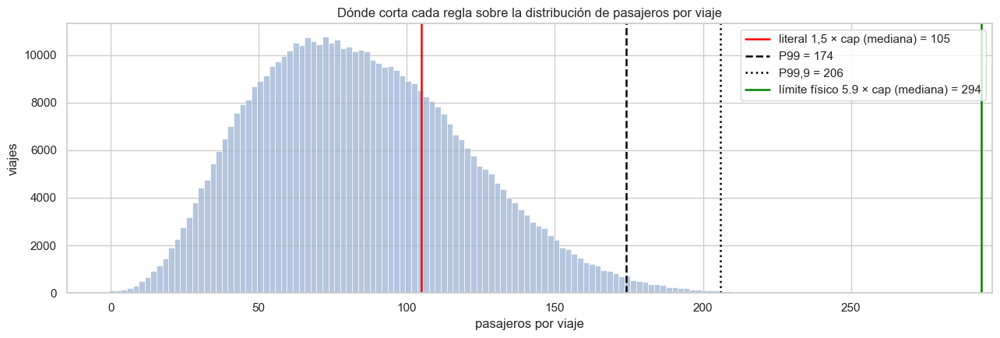

In [6]:
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.histplot(m.y, bins=np.arange(-0.5, m.y.max() + 2, 2), ax=ax, color="#9DB4D3", edgecolor=None)
lineas = [(1.5 * m.capacidad_calculada_max.median(), "red", "-", "literal 1,5 × cap (mediana)"),
          (m.y.quantile(.99), "black", "--", "P99"), (m.y.quantile(.999), "black", ":", "P99,9"),
          (regla.multiplicador * m.capacidad.median(), "green", "-", f"límite físico {regla.multiplicador:.1f} × cap (mediana)")]
for v, c, ls, t in lineas:
    ax.axvline(v, color=c, ls=ls, lw=1.8, label=f"{t} = {v:.0f}")
ax.set(title="Dónde corta cada regla sobre la distribución de pasajeros por viaje", xlabel="pasajeros por viaje", ylabel="viajes")
ax.legend(); plt.tight_layout(); plt.savefig(SALIDA / "umbrales_sobre_distribucion.png", dpi=130); plt.show()

**Conclusión 4 · Ninguna estrategia de truncamiento o filtrado mejora el error real; varias lo esconden**
- **A (truncar el entrenamiento en P99 o P99,9) no cambia nada:** MAE de 23,39–23,42 frente a 23,43. La distribución no tiene cola pesada (curtosis −0,13, 2.1), así que no hay valores extremos que estén distorsionando la pérdida.
- **A′ (truncar también el test) mejora la métrica de forma falsa:** el MAE en el top 1 % baja de 83,8 a 71,9 porque se reescriben las etiquetas reales, no porque se prediga mejor.
- **B literal (filtrar > 1,5 × capacidad) daña el modelo:** quita el **38 %** del entrenamiento, el modelo **infrapredice en 12,5 pasajeros por viaje**, el RMSE sube un 12 % (de 29,4 a 32,8) y la devianza un 25 %.
- **B literal′ es la trampa más peligrosa:** si además se filtra el test, el MAE "baja" a 15,7 (−33 %) porque se borra el **32,6 % del test 2025**, justo los viajes más cargados. La métrica parece excelente y el modelo es peor.
- **B física (> 5,88 × capacidad) no excluye ningún viaje observado:** da las mismas métricas que la referencia. Es una barrera para datos futuros, no un filtro que cambie el resultado actual.
- El sesgo de +5,5 del modelo de referencia se debe a la caída de la demanda entre 2023 y 2025 (se entrena con años de más demanda). No tiene que ver con los outliers.

## 5. Regla final aplicada al dataset de entrenamiento

In [7]:
final = f23.aplicar_regla_target(m.drop(columns=["y", "franja_15"]), regla)
display(f23.resumen_regla(final))
final.to_parquet("maestras/tb_maestra_entrenamiento.parquet", index=False)
print("Guardado: maestras/tb_maestra_entrenamiento.parquet  ·  usar  df[df.incluir_en_modelo]  para entrenar y evaluar")

,viajes,pct
viajes en la maestra,497371,100.000
outliers físicos (flag_outlier_target),123,0.025
target imputado (1.4),1069,0.215
incluidos en el modelo,496302,99.785


Guardado: maestras/tb_maestra_entrenamiento.parquet  ·  usar  df[df.incluir_en_modelo]  para entrenar y evaluar


**Conclusión 5 · Regla final**
- `flag_outlier_target` = subidas por encima de **5,88 × capacidad del bus**, o pico imposible de la 1.3. Marca **123 viajes (0,025 %)**: los picos de 97.199, 28.816, etc. Ya estaban imputados en la 1.4, así que están dentro de los 1.069 imputados.
- `incluir_en_modelo` = ni outlier ni target imputado: **496.302 viajes (99,785 %)**. Los 1.069 imputados quedan fuera del entrenamiento y de la evaluación porque no son observaciones reales.
- **Sin truncamiento:** el target conserva sus valores reales hasta 282.

## Conclusión de la Subfase 2.3 y recomendación para LightGBM
1. **No usar la regla `numeropasajeros > 1,5 × capacidad`:** compara las subidas de un viaje de 4 h con la capacidad *simultánea* del bus. Marcaría entre el 37 % y el 53 % de los viajes reales, y en la prueba infrapredice en 12,5 pasajeros por viaje y sube el RMSE un 12 %.
2. **No truncar (estrategia A):** no mejora el error real (MAE de 23,39 frente a 23,43), y si se trunca también el test la métrica mejora de forma falsa. La distribución no tiene cola pesada y los viajes extremos son demanda real con buena calidad de sensor.
3. **Aplicar la estrategia B con el límite físico coherente:**
   - **Excluir** de entrenamiento y evaluación los viajes con `flag_outlier_target` (> 5,88 × capacidad o pico imposible) y los **imputados**. Eso deja `incluir_en_modelo` = 496.302 viajes (99,8 %).
   - **Usar la misma regla en el test.** Excluir viajes es legítimo cuando el valor es físicamente imposible, no cuando es simplemente alto.
4. **Para no sesgar las métricas de LightGBM:**
   - Evaluar siempre sobre etiquetas **reales y sin modificar**, en un **corte temporal** (entrenar en el pasado y probar en el futuro).
   - Reportar también el error en el top 1 % de demanda.
   - La pérdida Tweedie ($p$ ≈ 1,3, 2.2) ya reduce el peso relativo de los viajes muy cargados, así que no hace falta truncar para protegerse de ellos.

Entregables:
- `maestras/tb_maestra_entrenamiento.parquet`, que añade `flag_outlier_target`, `limite_fisico_subidas` e `incluir_en_modelo`.
- `filtros_2_3.py` (regla reutilizable) y `auditoria_2_3.sql`.
- `resultados_2_3/comparacion_estrategias.csv` y los gráficos.

<a id="m2-4"></a>

### A1.2.4 &middot; Subfase 2.4 · Métrica oficial: devianza de Tweedie

<sub>Notebook original: `subfase_2_4_metrica.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 2.4 — Métrica oficial: Devianza de Tweedie

**Entregable:** módulo `metricas_tweedie.py` (solo NumPy), listo para importar desde el walk-forward del Módulo 7. Este notebook documenta la definición, **prueba el módulo** (propiedades matemáticas, casos borde, wrappers) y lo aplica a datos reales.

## 1. Definición formal
Para una observación $y\ge 0$, una predicción $\hat y>0$ y una potencia $p\in(1,2)$, la **devianza unitaria de Tweedie** es

$$d_p(y,\hat y)=2\left(\frac{y^{2-p}}{(1-p)(2-p)}-\frac{y\,\hat y^{\,1-p}}{1-p}+\frac{\hat y^{\,2-p}}{2-p}\right)$$

y la métrica del proyecto es su promedio (opcionalmente ponderado): $\;D_p=\frac{1}{n}\sum_i d_p(y_i,\hat y_i)$, **menor es mejor**.

Casos límite que el módulo también implementa:
- $p\to1$ (Poisson): $\;d=2\,[\,y\ln(y/\hat y)-y+\hat y\,]$
- $p\to2$ (Gamma): $\;d=2\,[\ln(\hat y/y)+y/\hat y-1]$
- $p=0$ (normal): $\;d=(y-\hat y)^2$

**Propiedades que justifican usarla como métrica oficial:**
1. $d_p\ge 0$, y $d_p=0$ solo si $\hat y=y$.
2. Es la pérdida de la familia con $\mathrm{Var}(Y)=\phi\mu^p$. Penaliza cada error en proporción a la varianza esperada a ese nivel de demanda, que crece como $\mu^{1,3}$ (Subfase 2.2).
3. Es una divergencia de Bregman: la mejor predicción constante es la **media**, así que no premia predecir de menos ni de más.

**Manejo de ceros:**
- Si $y=0$, el primer término vale 0 (porque $2-p>0$) y queda $d=2\hat y^{2-p}/(2-p)$.
- Si $\hat y\to0$, $\hat y^{1-p}$ diverge; el módulo aplica $\hat y\leftarrow\max(\hat y,\varepsilon)$ con $\varepsilon=10^{-9}$.

**Valor oficial de $p$:** **1,3**, estimado en la 2.2 (rango robusto de 1,1 a 1,5). El 1,5 del enunciado es el valor por defecto de LightGBM, no el de estos datos. **$p$ debe quedar fijo en todas las comparaciones**: devianzas calculadas con distintos $p$ no son comparables entre sí.

In [1]:
import time
import numpy as np
import pandas as pd
import holidays
from IPython.display import display
import metricas_tweedie as mt
from metricas_tweedie import tweedie_deviance_score, tweedie_deviance_unit, P_OFICIAL
pd.set_option("display.width", 200)
print("p oficial:", P_OFICIAL, "| eps:", mt.EPS, "| funciones exportadas:", mt.__all__)

p oficial: 1.3 | eps: 1e-09 | funciones exportadas: ['P_OFICIAL', 'EPS', 'tweedie_deviance_unit', 'tweedie_deviance_score', 'lgb_feval', 'lgb_sklearn_eval', 'xgb_custom_metric', 'xgb_sklearn_eval', 'sklearn_scorer']


## 2. Pruebas del módulo (deben pasar todas)

In [2]:
rng = np.random.default_rng(0)
pruebas = []
def check(nombre, cond, detalle=""):
    pruebas.append({"prueba": nombre, "resultado": "PASS" if bool(cond) else "FAIL", "detalle": detalle})

# 1. Igual a la fórmula del enunciado (ejemplo a mano)
y_, mu_, p_ = 80.0, 70.0, 1.3
manual = 2 * (y_ ** (2 - p_) / ((1 - p_) * (2 - p_)) - y_ * mu_ ** (1 - p_) / (1 - p_) + mu_ ** (2 - p_) / (2 - p_))
check("Coincide con la fórmula escrita a mano", np.isclose(tweedie_deviance_unit([y_], [mu_], p_)[0], manual), f"d(80, 70) = {manual:.6f}")
# 2. Cero en predicción perfecta
y = np.array([1, 5, 50, 82, 282], float)
check("d(y, y) = 0", np.allclose(tweedie_deviance_unit(y, y), 0, atol=1e-9), f"máx {tweedie_deviance_unit(y, y).max():.1e}")
# 3. No negatividad
Y, MU = rng.integers(0, 300, 200_000).astype(float), rng.uniform(0.01, 300, 200_000)
check("d ≥ 0 en 200.000 pares aleatorios", (tweedie_deviance_unit(Y, MU) >= 0).all())
# 4. y = 0: valor cerrado
check("y = 0  →  d = 2ŷ^(2−p)/(2−p)", np.isclose(tweedie_deviance_unit([0.0], [40.0])[0], 2 * 40 ** (2 - P_OFICIAL) / (2 - P_OFICIAL)))
# 5. ŷ = 0: finito gracias a eps
v = tweedie_deviance_unit([10.0, 0.0], [0.0, 0.0])
check("ŷ = 0 no da inf ni NaN", np.isfinite(v).all(), f"d(10, 0) = {v[0]:.1f} · d(0, 0) = {v[1]:.1e}")
# 6. Límites continuos con Poisson y Gamma
Yp, MUp = rng.uniform(1, 200, 1000), rng.uniform(1, 200, 1000)
check("p → 1 converge a Poisson", np.allclose(tweedie_deviance_unit(Yp, MUp, 1 + 1e-6), tweedie_deviance_unit(Yp, MUp, 1), rtol=1e-4))
check("p → 2 converge a Gamma", np.allclose(tweedie_deviance_unit(Yp, MUp, 2 - 1e-6), tweedie_deviance_unit(Yp, MUp, 2), rtol=1e-4))
# 7. La mejor constante es la media (Bregman)
yy = rng.gamma(5, 17, 50_000)
grid = np.linspace(yy.mean() * .8, yy.mean() * 1.2, 2001)
c_opt = grid[np.argmin([tweedie_deviance_score(yy, np.full_like(yy, c)) for c in grid])]
check("argmin de la constante = media", abs(c_opt - yy.mean()) < (grid[1] - grid[0]) * 1.01, f"argmin {c_opt:.3f} · media {yy.mean():.3f}")
# 8. Ponderación
w = rng.uniform(0, 2, len(Y))
check("sample_weight = promedio ponderado", np.isclose(tweedie_deviance_score(Y, MU, sample_weight=w),
      np.average(tweedie_deviance_unit(Y, MU), weights=w)))
# 9. Validaciones de entrada
for nombre, args in [("y < 0", ([-1.0], [1.0])), ("NaN", ([np.nan], [1.0])), ("tamaños distintos", ([1.0, 2.0], [1.0])),
                     ("p fuera de dominio", ([1.0], [1.0], 2.5))]:
    try:
        tweedie_deviance_score(*args); check(f"Rechaza {nombre}", False)
    except ValueError as e:
        check(f"Rechaza {nombre}", True, str(e)[:60])
# 10. Velocidad
Yb, MUb = rng.integers(0, 300, 500_000).astype(float), rng.uniform(1, 300, 500_000)
t0 = time.perf_counter(); tweedie_deviance_score(Yb, MUb); dt = (time.perf_counter() - t0) * 1000
check("Vectorizada: 500.000 filas en < 200 ms", dt < 200, f"{dt:.0f} ms")

res = pd.DataFrame(pruebas); display(res)
assert (res.resultado == "PASS").all(), "Hay pruebas en FAIL"
print(f"{len(res)} de {len(res)} pruebas en PASS")

,prueba,resultado,detalle
0,Coincide con la fórmula escrita a mano,PASS,"d(80, 70) = 0.376502"
1,"d(y, y) = 0",PASS,máx 8.5e-14
2,d ≥ 0 en 200.000 pares aleatorios,PASS,
3,y = 0 → d = 2ŷ^(2−p)/(2−p),PASS,
4,ŷ = 0 no da inf ni NaN,PASS,"d(10, 0) = 33364.8 · d(0, 0) = 1.4e-06"
5,p → 1 converge a Poisson,PASS,
6,p → 2 converge a Gamma,PASS,
7,argmin de la constante = media,PASS,argmin 85.081 · media 85.081
8,sample_weight = promedio ponderado,PASS,
9,Rechaza y < 0,PASS,La devianza Tweedie con p ≥ 1 exige y_true ≥ 0


14 de 14 pruebas en PASS


**Conclusión 2 · El módulo es correcto y robusto: 14 de 14 pruebas en PASS**
- **Coincide con la fórmula del enunciado** (d(80, 70) = 0,3765) y vale 0 en predicción perfecta (error máximo de 8,5·10⁻¹⁴).
- **Nunca es negativa:** se comprobó en 200.000 pares aleatorios.
- **Converge sin saltos a Poisson (p → 1) y a Gamma (p → 2).**
- **La mejor predicción constante es exactamente la media** (85,081). La métrica no premia sesgos sistemáticos.
- **Ceros sin errores numéricos:** y = 0 da su valor cerrado y ŷ = 0 da un valor finito (gracias a ε), no infinito ni NaN.
- **Rechaza entradas inválidas** con un mensaje claro: y < 0, NaN, tamaños distintos o p fuera de dominio.
- **Procesa 500.000 filas en unos 106 ms.**

## 3. Wrappers para LightGBM, XGBoost y scikit-learn
`lightgbm` y `xgboost` no están instalados en este equipo, y Windows bloquea `sklearn`. Para probar los wrappers se simulan los objetos que esas librerías les entregan (`Dataset.get_label()` y `get_weight()`, `DMatrix.get_label()` y `get_weight()`), respetando exactamente sus firmas.

In [3]:
class DatasetSimulado:            # interfaz de lightgbm.Dataset usada por feval
    def __init__(self, y, w=None): self._y, self._w = np.asarray(y, float), w
    def get_label(self): return self._y
    def get_weight(self): return self._w

class DMatrixSimulada:             # interfaz de xgboost.DMatrix usada por custom_metric
    def __init__(self, y, w=None): self._y, self._w = np.asarray(y, float), np.asarray([] if w is None else w, float)
    def get_label(self): return self._y
    def get_weight(self): return self._w

y_v, mu_v = Y[:10_000], MU[:10_000]
ref = tweedie_deviance_score(y_v, mu_v)
salidas = {
    "lgb_feval (preds en escala de respuesta)": mt.lgb_feval()(mu_v, DatasetSimulado(y_v)),
    "lgb_feval (raw_score=True, preds en log)": mt.lgb_feval(raw_score=True)(np.log(mu_v), DatasetSimulado(y_v)),
    "lgb_sklearn_eval": mt.lgb_sklearn_eval()(y_v, mu_v),
    "xgb_custom_metric": mt.xgb_custom_metric()(mu_v, DMatrixSimulada(y_v)),
    "xgb_sklearn_eval": mt.xgb_sklearn_eval()(y_v, mu_v),
}
tabla = pd.DataFrame([{"wrapper": k, "salida": v, "valor": v[1] if isinstance(v, tuple) else v} for k, v in salidas.items()])
tabla["igual_a_score"] = np.isclose(tabla.valor, ref)
display(tabla)
assert tabla.igual_a_score.all()
print("Firmas: LightGBM → (nombre, valor, is_higher_better=False) · XGBoost nativo → (nombre, valor) · XGBRegressor → valor")

,wrapper,salida,valor,igual_a_score
0,lgb_feval (preds en escala de respuesta),"(tweedie_deviance@1.3, 45.964886164524074, False)",45.964886,True
1,"lgb_feval (raw_score=True, preds en log)","(tweedie_deviance@1.3, 45.964886164524074, False)",45.964886,True
2,lgb_sklearn_eval,"(tweedie_deviance@1.3, 45.964886164524074, False)",45.964886,True
3,xgb_custom_metric,"(tweedie_deviance@1.3, 45.964886164524074)",45.964886,True
4,xgb_sklearn_eval,45.964886,45.964886,True


Firmas: LightGBM → (nombre, valor, is_higher_better=False) · XGBoost nativo → (nombre, valor) · XGBRegressor → valor


**Conclusión 3 · Los 5 wrappers devuelven exactamente el mismo valor que `tweedie_deviance_score`**
- LightGBM nativo (`feval`) y sklearn (`eval_metric`) devuelven `(nombre, valor, False)`: menor es mejor.
- XGBoost nativo (`custom_metric`) devuelve `(nombre, valor)` y `XGBRegressor` un `float`. XGBoost minimiza por defecto.
- `raw_score=True` cubre el caso de un objetivo personalizado (predicciones en escala log). Con `objective='tweedie'` integrado no hace falta.
- `sklearn_scorer()` sirve para `GridSearchCV` (sklearn lo reporta con signo negativo). No pudo probarse aquí porque Windows bloquea `sklearn`.

## 4. Aplicación a datos reales: modelo de referencia, 2025
Mismo modelo de referencia de la 2.3 (media por ruta × franja de 15 min × tipo de día, entrenado con 2023–2024), evaluado sobre 2025 con la regla de la 2.3 (`incluir_en_modelo`). Se compara con un modelo ingenuo (media global de entrenamiento) para mostrar cuánto separa la métrica a un modelo útil de uno inútil, y se desglosa por tipo de día, como recomendó la 2.2.

In [4]:
d = pd.read_parquet("maestras/tb_maestra_entrenamiento.parquet")
d = d[d.incluir_en_modelo].copy()
festivos = holidays.Colombia(years=[2023, 2024, 2025])
fest = d.fecha.dt.date.map(lambda x: x in festivos)
d["tipo_dia"] = np.select([fest | (d.dia_semana == 6), d.dia_semana == 5], ["domingo_festivo", "sabado"], "laboral")
d["franja_15"] = d.fechasalida.dt.floor("15min").dt.strftime("%H:%M")
d["y"] = d.numeropasajeros.astype(float)
tr, te = d[d.fecha < "2025-01-01"], d[d.fecha >= "2025-01-01"].copy()
k1, k2 = ["idruta", "franja_15", "tipo_dia"], ["idruta", "hora", "tipo_dia"]
te = te.join(tr.groupby(k1).y.mean().rename("p1"), on=k1).join(tr.groupby(k2).y.mean().rename("p2"), on=k2)
te["pred_referencia"] = te.p1.fillna(te.p2).fillna(tr.y.mean())
te["pred_ingenuo"] = tr.y.mean()

filas = []
for nombre, col in [("ingenuo (media global)", "pred_ingenuo"), ("referencia (ruta × franja × día)", "pred_referencia")]:
    filas.append({"modelo": nombre, f"devianza_p{P_OFICIAL}": tweedie_deviance_score(te.y, te[col]),
                  "MAE": np.mean(np.abs(te.y - te[col])), "sesgo": np.mean(te[col] - te.y)})
display(pd.DataFrame(filas).round(3))

por_dia = te.groupby("tipo_dia").apply(lambda g: pd.Series({
    "viajes": len(g), "devianza_referencia": tweedie_deviance_score(g.y, g.pred_referencia),
    "devianza_ingenuo": tweedie_deviance_score(g.y, g.pred_ingenuo), "MAE_referencia": np.mean(np.abs(g.y - g.pred_referencia))}),
    include_groups=False).reindex(["laboral", "sabado", "domingo_festivo"])
display(por_dia.round(3))

sens = pd.DataFrame({p: {"ingenuo": tweedie_deviance_score(te.y, te.pred_ingenuo, p),
                         "referencia": tweedie_deviance_score(te.y, te.pred_referencia, p)} for p in [1.1, 1.2, 1.3, 1.4, 1.5]}).T
sens["mejora_%"] = 100 * (1 - sens.referencia / sens.ingenuo)
print("Sensibilidad a p: los valores absolutos cambian con p (no comparables), el ordenamiento de modelos no:")
display(sens.round(3))

,modelo,devianza_p1.3,MAE,sesgo
0,ingenuo (media global),4.244,28.846,5.663
1,referencia (ruta × franja × día),2.926,23.434,5.569


,viajes,devianza_referencia,devianza_ingenuo,MAE_referencia
tipo_dia,,,,
laboral,116160.0,3.020,4.090,24.653
sabado,22424.0,2.969,3.723,22.715
domingo_festivo,19923.0,2.326,5.733,17.133


Sensibilidad a p: los valores absolutos cambian con p (no comparables), el ordenamiento de modelos no:


,ingenuo,referencia,mejora_%
1.1,10.045,6.922,31.091
1.2,6.526,4.497,31.092
1.3,4.244,2.926,31.068
1.4,2.763,1.906,31.017
1.5,1.801,1.244,30.940


**Conclusión 4 · La métrica separa bien un modelo útil de uno inútil, y el resultado no depende de p**
- **2025 (158.507 viajes):** el modelo de referencia obtiene una **devianza de 2,926** frente a **4,244** del ingenuo (**−31 %**). El MAE pasa de 28,8 a 23,4.
- **Por tipo de día**, la mayor ganancia está en el **domingo-festivo** (2,33 frente a 5,73): el ingenuo, que usa la media global, sobrepredice los domingos. Laboral 3,02 y sábado 2,97.
- **Con p de 1,1 a 1,5 los valores absolutos cambian** (de 6,9 a 1,2 para la referencia), **pero la mejora relativa se mantiene en 31 %**. Hay que fijar p = 1,3 y no comparar devianzas calculadas con distintos p.
- El sesgo de +5,6 pasajeros (los dos modelos sobrepredicen 2025) muestra que la demanda cae entre 2023 y 2025. **Los modelos de los Módulos 6–8 necesitan variables de tendencia y calendario.**

## Conclusión de la Subfase 2.4
- **Métrica oficial del proyecto:** `tweedie_deviance_score(y_true, y_pred, p=1.3)` de `metricas_tweedie.py`. Solo depende de NumPy, está probada (14 de 14) y trae wrappers para LightGBM, XGBoost y scikit-learn.
- **Reglas de uso en el walk-forward (Módulo 7):**
  1. Fijar `p = P_OFICIAL = 1.3` para todos los modelos y folds.
  2. Evaluar solo sobre `incluir_en_modelo == True` (2.3), con etiquetas sin modificar.
  3. Reportar también por tipo de día y el MAE como métrica de negocio.
- **Resumen ejecutivo del Módulo 2:** `resumen_ejecutivo_modulo2.md`.

<a id="m35"></a>

---

## A1.3 &middot; Módulos 3–5 · Dimensión temporal, dimensión espacial y multicolinealidad

Estructura temporal de la demanda, estructura espacial sobre la red y diagnóstico de multicolinealidad entre los candidatos a feature.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m35-1"></a>

### A1.3.1 &middot; Módulos 3–5 · Análisis espaciotemporal

<sub>Notebook original: `entrega_persona2_modulos_3_5/entrega_persona2_modulos_3_5/modulo_3_5_espaciotemporal.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulos 3–5 — Dimensión temporal, dimensión espacial y multicolinealidad

**Persona 2 · Spatial-Temporal Data Scientist.** Parte de las tablas maestras cerradas en el Módulo 1 (`maestras/`, 22/22 checks en PASS) y no vuelve a la RDS.

| Módulo | Pregunta | Insumo |
|---|---|---|
| 3 · Temporal | ¿La demanda es estacionaria? ¿Qué memoria tienen t-1, t-4 y t-96? ¿Cuándo son los picos y cambian en festivos? | `tb_maestra_progvehiculos_limpia` → serie regular ruta × 15 min |
| 4 · Espacial | ¿Las subidas se agrupan en el espacio? ¿Con qué matriz de vecindad (k) medirlo? | `tb_maestra_conteo_destino_limpio_muestra` (lecturas GPS) → celdas de 250 m |
| 5 · Multicolinealidad | ¿Qué predictores son redundantes o filtran el objetivo? | maestra (nivel viaje) y panel ruta × 15 min |

**Variable de trabajo:** `pasajeros` = suma de `numeropasajeros` (ya imputado sin leakage en la 1.4) de los viajes válidos que **salen** en cada intervalo de 15 min, por ruta. Debe confirmarse con la caracterización del objetivo del Módulo 2 (Persona 1), que no está en la carpeta.

La lógica vive en `espaciotemporal_3_5.py`. Las salidas para la Persona 3 quedan en `datos_3_5/` (documentadas en `datos_3_5/LEEME_artefactos.md`). Este notebook no construye variables de entrenamiento: entrega calendario, diagnósticos, matriz de pesos y grafo.

# 0 · Configuración y carga

In [1]:
from pathlib import Path
import hashlib, platform, sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import scipy, sklearn, statsmodels
from scipy import sparse
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.precision", 4)
import espaciotemporal_3_5 as et
from filtros_1_4 import CAJA          # caja Barranquilla–Soledad definida en la 1.4

MAESTRAS, D12, D13 = Path("maestras"), Path("datos_1_2"), Path("datos_1_3")
SALIDA = Path("datos_3_5"); FIG = SALIDA / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
cfg = et.Config()
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "font.size": 9, "axes.titlesize": 10, "font.family": "DejaVu Sans"})

def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight", facecolor="white")
    plt.show()

def huella(p):   # para comprobar al final que no se modificaron los insumos de la Persona 1
    return hashlib.md5(Path(p).read_bytes()).hexdigest()

INSUMOS = sorted(MAESTRAS.glob("*")) + [D12 / "viajes_validos.parquet", D13 / "sensores_viaje.csv"]
HUELLAS_INICIO = {str(p): huella(p) for p in INSUMOS}
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | statsmodels {statsmodels.__version__} | "
      f"scipy {scipy.__version__} | scikit-learn {sklearn.__version__} | networkx {nx.__version__} | matplotlib {matplotlib.__version__}")
print(cfg)

Python 3.10.0 | pandas 2.3.3 | numpy 2.2.6 | statsmodels 0.14.6 | scipy 1.15.3 | scikit-learn 1.7.2 | networkx 3.4.2 | matplotlib 3.10.3
Config(ventana_ini='2023-01-01', ventana_fin='2026-01-01', freq='15min', lags=(1, 4, 96), lag_semana=672, maxlag_adf_15min=100, alpha=0.05, umbral_dia_anomalo=0.25, celda_m=250.0, min_viajes_celda=30, ks=(2, 3, 4, 5, 6, 8, 10, 12, 15, 20), permutaciones=999, semilla=42, vif_umbrales=(5.0, 10.0), corr_umbral=0.8)


## 0.1 Insumos del Módulo 1 y columnas requeridas

In [2]:
val1 = pd.read_csv(MAESTRAS / "validacion_modulo1.csv")
assert (val1.resultado == "PASS").all(), "El Módulo 1 no está cerrado: revisar maestras/validacion_modulo1.csv"

maestra = pd.read_parquet(MAESTRAS / "tb_maestra_progvehiculos_limpia.parquet")
despachos = pd.read_parquet(MAESTRAS / "tb_despachos.parquet")
conteo = pd.read_parquet(MAESTRAS / "tb_maestra_conteo_destino_limpio_muestra.parquet")

REQ = {
    "maestra": (maestra, {"idprogramacion", "idruta", "fechasalida", "fecha", "hora", "tipo_dia", "numeropasajeros",
                          "pasajeros_imputado", "capacidad", "flag_sensor_ok", "numeropasajeros_raw"}),
    "despachos": (despachos, {"idprogramacion", "idruta", "fechasalida", "fechainicio"}),
    "conteo": (conteo, {"id", "idprogramacion", "idruta", "fecha", "latitud", "longitud", "cantidad_subida",
                        "cantidad_bajada", "a_bordo", "flag_fuera_area", "flag_carga_imposible"}),
}
for nombre, (df, cols) in REQ.items():
    faltan = cols - set(df.columns)
    assert not faltan, f"{nombre}: faltan {faltan}"
display(pd.DataFrame({n: {"filas": len(d), "columnas": d.shape[1], "requeridas": len(c)} for n, (d, c) in REQ.items()}).T)
print(f"Checks del Módulo 1 en PASS: {(val1.resultado == 'PASS').sum()} de {len(val1)}")

,filas,columnas,requeridas
maestra,497371,43,11
despachos,561427,16,4
conteo,971335,21,11


Checks del Módulo 1 en PASS: 22 de 22


## 0.2 Viajes aptos para el análisis espacial
La muestra de lecturas de la 1.3 **no es aleatoria pura**: además de 500 viajes al azar por ruta, añadió a propósito hasta 300 viajes con cero pasajeros y los 200 de más bloqueos. Se reconstruyen esos dos grupos con la misma regla determinista de la 1.3 y se excluyen, junto con los viajes con sensor no confiable, imputados o con carga imposible.

In [3]:
v12 = pd.read_parquet(D12 / "viajes_validos.parquet", columns=["idprogramacion", "idruta"])
sv13 = pd.read_csv(D13 / "sensores_viaje.csv", usecols=["idprogramacion", "numeropasajeros", "numerobloqueos"])
base13 = v12.merge(sv13, on="idprogramacion")
TOP_BLOQUEOS = set(base13.nlargest(200, "numerobloqueos").idprogramacion)               # regla exacta de la 1.3
CEROS = set(base13[base13.numeropasajeros.fillna(0) == 0].idprogramacion)               # universo del que la 1.3 muestreó 300
aptos = et.viajes_aptos_espacial(conteo, maestra, TOP_BLOQUEOS, CEROS)
display(aptos.motivo.value_counts().to_frame("viajes"))
display(pd.crosstab(aptos.idruta, aptos.motivo == "apto", margins=True).rename(columns={True: "apto", False: "excluido"}))
IDS_APTOS = set(aptos.index[aptos.motivo == "apto"])

,viajes
motivo,
apto,1335
muestra dirigida: top-200 bloqueos (1.3),192
flag_sensor_ok = False,99
muestra dirigida: cero pasajeros (1.3),42
carga a bordo imposible,5


motivo,excluido,apto,All
idruta,,,
2,74,456,530
16,161,437,598
21,103,442,545
All,338,1335,1673


# Módulo 3 · Dimensión temporal

## 3.1 Auditoría de la marca temporal
Se revisa `fechasalida` (salida programada): zona horaria, resolución, duplicados, huecos y regularidad. La serie **por viaje** no es equiespaciada (los buses salen cada pocos minutos con intervalos variables), así que ACF/PACF no pueden aplicarse sobre ella directamente.

In [4]:
aud_t = et.auditar_tiempo(maestra, cfg)
display(aud_t)
intervalos = et.intervalos_salida(maestra)
display(intervalos)
dias_anio = maestra.groupby(maestra.fechasalida.dt.year).fecha.nunique()
viajes_dia_anio = maestra.groupby([maestra.fechasalida.dt.year.rename("anio"), "idruta"]).size().unstack().div(dias_anio, axis=0)
print("Viajes válidos por día (media anual): permite ver cambios de frecuencia de despacho")
display(viajes_dia_anio.round(1))

,check,resultado,detalle
0,fechasalida sin nulos,PASS,0 nulos
1,"fechasalida naive (hora local, sin zona)",PASS,datetime64[ns]
2,America/Bogota sin cambio de horario en la ven...,PASS,offset único: UTC-5 h
3,Resolución de minuto (segundos = 0),PASS,0 con segundos
4,Ventana 2023-01 a 2025-12,PASS,2023-01-01 05:00:00 → 2025-12-31 18:30:00
5,idprogramacion único,PASS,
6,Salidas simultáneas en la misma ruta y minuto,INFO,"855 (0.17 %): buses distintos, se suman en el ..."
7,Ninguna ruta tiene días completos sin viajes,PASS,"{np.int64(2): 0, np.int64(16): 0, np.int64(21)..."


,viajes,p05,p50,p95,max_dentro_del_dia,pct_intervalo_0,cv_dentro_del_dia
idruta,,,,,,,
2,138633,2.0,6.0,16.0,178.0,0.14,0.64
16,271142,2.0,3.0,8.0,176.0,0.21,0.63
21,87596,3.0,10.0,24.0,174.0,0.12,0.62


Viajes válidos por día (media anual): permite ver cambios de frecuencia de despacho


idruta,2,16,21
anio,,,
2023,132.2,264.3,82.0
2024,124.1,243.3,80.8
2025,123.2,234.6,76.9


**Conclusión 3.1 · Las marcas de tiempo son limpias, pero la serie por viaje no es regular**
- `fechasalida` está en hora local sin zona, con resolución de minuto, y cubre 2023-01-01 → 2025-12-31. **America/Bogota no tuvo cambio de horario** en la ventana (UTC−5 fijo), así que no hay horas duplicadas ni saltadas.
- **Ninguna ruta tiene un día completo sin viajes**: no hay huecos de calendario que rellenar.
- Hay 855 salidas simultáneas (misma ruta y minuto, 0,17 %). Son buses distintos y se suman en el intervalo.
- **Los intervalos entre salidas son irregulares**. La mediana es de 6 min (ruta 2), 3 min (16) y 10 min (21), con un coeficiente de variación de ≈ 0,6. Por eso se regulariza a 15 min antes de cualquier ACF.
- La oferta baja de forma sostenida. La ruta 16 pasa de 264 viajes válidos/día en 2023 a 235 en 2025 (−11 %) y la ruta 2 de 132 a 123. Es un cambio lento de nivel, no de frecuencia de muestreo.

## 3.2 Calendario: laborales, fines de semana, festivos y Carnaval
- **Festivos nacionales** de Colombia (Ley 51 de 1983): 6 fijos, 7 trasladados al lunes siguiente y 5 ligados a la Pascua (18 por año). Ámbito nacional, aplica a Barranquilla. Se verificó fuera del notebook contra el paquete `holidays` (coincidencia exacta 2023–2025).
- **Carnaval de Barranquilla** (sábado a martes antes del Miércoles de Ceniza): evento local, **no** es festivo nacional; va en una categoría propia para no contaminar ni a los laborales ni a los festivos.
- `tipo_dia_cal` aplica la prioridad festivo > carnaval > domingo > sábado > laboral. No reemplaza el `tipo_dia` de la 1.4 (sin festivos), lo complementa.
- `dia_anomalo`: día no festivo ni de carnaval con menos del 25 % de los viajes válidos medianos de su tipo. Se excluye de las comparaciones, no de la serie.

In [5]:
cal = et.calendario(cfg, maestra.groupby("fecha").size())
fest = et.festivos_colombia(sorted(cal.fecha.dt.year.unique()))
assert fest.groupby(fest.fecha.dt.year).size().eq(18).all(), "Deben ser 18 festivos nominales por año"
resumen_cal = cal.groupby(cal.fecha.dt.year.rename("anio")).agg(
    dias=("fecha", "size"), festivos=("es_festivo", "sum"), carnaval=("es_carnaval", "sum"), anomalos=("dia_anomalo", "sum"))
resumen_cal["festivos_en_domingo"] = cal[cal.es_festivo & (cal.dia_semana == 6)].groupby(cal.fecha.dt.year).size().reindex(resumen_cal.index, fill_value=0)
display(resumen_cal)
display(pd.crosstab(cal.tipo_dia_cal, cal.fecha.dt.year, margins=True))
print("Festivos por día de la semana (0 = lunes):", cal[cal.es_festivo].dia_semana.value_counts().sort_index().to_dict())
print("Días que la 1.4 clasificaba como 'laboral' y en realidad son festivos o Carnaval:",
      int(((cal.tipo_dia_m1 == "laboral") & cal.tipo_dia_cal.isin(["festivo", "carnaval"])).sum()))
display(cal[cal.dia_anomalo][["fecha", "dia_semana", "tipo_dia_cal", "viajes_validos_dia"]])

,dias,festivos,carnaval,anomalos,festivos_en_domingo
anio,,,,,
2023,365,18,4,0,1
2024,366,18,4,1,1
2025,365,17,4,0,1


fecha,2023,2024,2025,All
tipo_dia_cal,,,,
carnaval,4,4,4,12
domingo,51,50,50,151
festivo,18,18,17,53
laboral,241,244,243,728
sabado,51,50,51,152
All,365,366,365,1096


Festivos por día de la semana (0 = lunes): {0: 34, 2: 4, 3: 7, 4: 4, 5: 1, 6: 3}
Días que la 1.4 clasificaba como 'laboral' y en realidad son festivos o Carnaval: 55


,fecha,dia_semana,tipo_dia_cal,viajes_validos_dia
614,2024-09-06,4,laboral,50


**Conclusión 3.2 · El 5 % de los días no era lo que decía `tipo_dia`**
- 53 fechas festivas en 3 años: 18 por año, pero en 2025 San Pedro y el Sagrado Corazón caen ambos el 30 de junio. **34 de los 53 son lunes**, por la Ley Emiliani.
- **55 días que la 1.4 trataba como laborales son festivos o Carnaval.** Contaminaban el grupo laboral, y también la imputación de la 1.4 por "ruta × hora × tipo de día". Esto se le avisa a la Persona 1.
- **El Carnaval** (12 días) se separa porque su demanda se parece a la de un domingo (3.7) sin ser festivo nacional.
- **Un solo día anómalo: el viernes 6 de septiembre de 2024**, con 50 viajes válidos frente a ~480 de un laboral típico. Las tres rutas caen a la vez, lo que apunta a un evento o una falla de registro. Los datos no permiten saber cuál. Queda en la serie, pero fuera de las comparaciones.

## 3.3 Serie regular ruta × 15 min
Se agregan los viajes por el intervalo de 15 min de su salida. Con esa frecuencia, **t-1 = 15 min, t-4 = 1 h y t-96 = 24 h** (96 × 15 min). Un intervalo sin salidas vale 0: no hubo servicio y no hay abordajes atribuidos. Esto es un cero real de la variable, no un hueco, porque ninguna ruta tiene días sin datos (3.1). **No se interpola nada.**

Cautela de interpretación: `numeropasajeros` acumula las subidas de todo el viaje (~4 h) y se atribuye a la hora de **salida**. Es demanda por despacho, no subidas instantáneas.

In [6]:
serie = et.serie_regular(maestra, cfg)
n_int = len(pd.date_range(cfg.ventana_ini, cfg.ventana_fin, freq=cfg.freq, inclusive="left"))
chk_serie = pd.DataFrame({
    "intervalos": serie.groupby("idruta").size(),
    "esperados": n_int,
    "pasajeros_serie": serie.groupby("idruta").pasajeros.sum(),
    "pasajeros_maestra": maestra.groupby("idruta").numeropasajeros.sum().astype("int64"),
    "viajes_serie": serie.groupby("idruta").viajes.sum(),
    "viajes_maestra": maestra.groupby("idruta").size(),
    "pct_ceros": serie.groupby("idruta").pasajeros.apply(lambda s: 100 * (s == 0).mean()),
    "pct_ceros_4a20h": serie[serie.hora.between(4, 20)].groupby("idruta").pasajeros.apply(lambda s: 100 * (s == 0).mean()),
    "pct_ceros_21a3h": serie[~serie.hora.between(4, 20)].groupby("idruta").pasajeros.apply(lambda s: 100 * (s == 0).mean()),
})
assert (chk_serie.intervalos == chk_serie.esperados).all() and (chk_serie.pasajeros_serie == chk_serie.pasajeros_maestra).all() \
    and (chk_serie.viajes_serie == chk_serie.viajes_maestra).all(), "La serie no conserva intervalos, pasajeros o viajes"
display(chk_serie.round(2))
display(serie.groupby("idruta").pasajeros.describe(percentiles=[.25, .5, .75, .95, .99]).round(1))

,intervalos,esperados,pasajeros_serie,pasajeros_maestra,viajes_serie,viajes_maestra,pct_ceros,pct_ceros_4a20h,pct_ceros_21a3h
idruta,,,,,,,,,
2,105216,105216,11272302,11272302,138633,138633,36.75,10.71,100.0
16,105216,105216,23303942,23303942,271142,271142,33.90,6.68,100.0
21,105216,105216,7418827,7418827,87596,87596,42.33,18.59,100.0


,count,mean,std,min,25%,50%,75%,95%,99%,max
idruta,,,,,,,,,,
2,105216.0,107.1,117.5,0.0,0.0,85.0,175.0,318.0,508.0,1080.0
16,105216.0,221.5,215.7,0.0,0.0,188.0,377.0,605.0,818.0,1275.0
21,105216.0,70.5,79.3,0.0,0.0,55.0,119.0,224.0,307.0,594.0


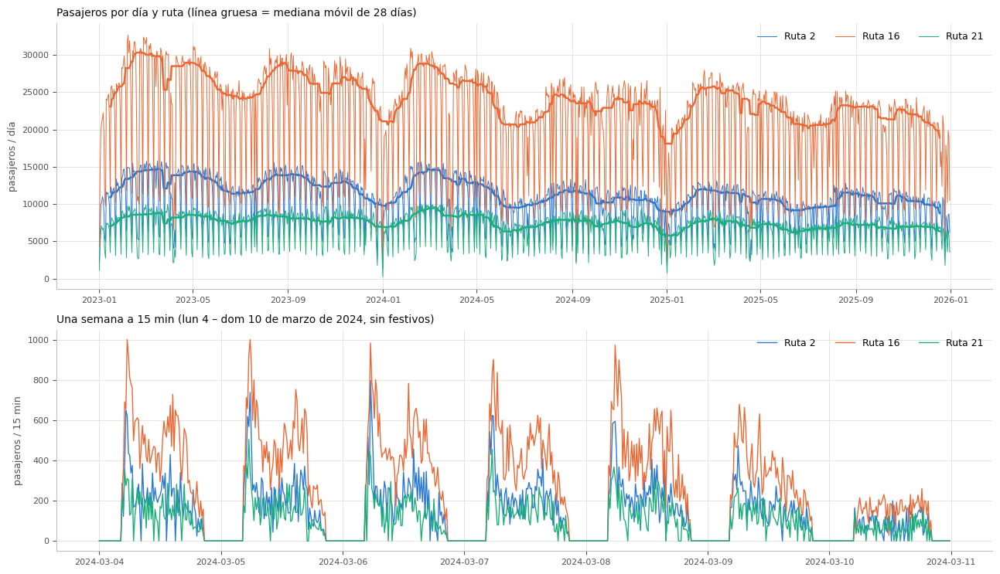

In [7]:
diario = (serie.groupby(["idruta", "fecha"], as_index=False)[["pasajeros", "viajes"]].sum()
          .merge(cal[["fecha", "dia_semana", "tipo_dia_cal", "es_festivo", "es_carnaval", "dia_anomalo"]], on="fecha"))
fig, ax = plt.subplots(2, 1, figsize=(13, 7.5), gridspec_kw={"height_ratios": [1.2, 1]})
for r, g in diario.groupby("idruta"):
    ax[0].plot(g.fecha, g.pasajeros, lw=0.7, color=et.COLOR_RUTA[r], label=f"Ruta {r}")
    ax[0].plot(g.fecha, g.pasajeros.rolling(28, center=True).median(), lw=1.8, color=et.COLOR_RUTA[r])
et.estilo_ejes(ax[0], "Pasajeros por día y ruta (línea gruesa = mediana móvil de 28 días)", None, "pasajeros / día")
ax[0].legend(frameon=False, ncol=3, loc="upper right")
semana = serie[(serie.t >= "2024-03-04") & (serie.t < "2024-03-11")]
for r, g in semana.groupby("idruta"):
    ax[1].plot(g.t, g.pasajeros, lw=1.0, color=et.COLOR_RUTA[r], label=f"Ruta {r}")
et.estilo_ejes(ax[1], "Una semana a 15 min (lun 4 – dom 10 de marzo de 2024, sin festivos)", None, "pasajeros / 15 min")
ax[1].legend(frameon=False, ncol=3, loc="upper right")
plt.tight_layout(); guardar(fig, "m3_serie_diaria_y_semana")

**Conclusión 3.3 · Serie regular completa: 3 × 105.216 intervalos sin pérdidas**
- La serie conserva exactamente los 41.995.071 pasajeros y los 497.371 viajes de la maestra.
- **Entre el 34 % y el 42 % de los intervalos valen 0.** Las 21:00–03:59 son 0 en el 100 % de los casos (no hay servicio: cero estructural). Dentro del servicio (4–20 h) los ceros son el 6,7 % (ruta 16), el 10,7 % (ruta 2) y el 18,6 % (ruta 21). Esa mezcla de ceros y valores positivos sesgados es la que motiva la comparación Poisson/Tweedie del Módulo 2.
- **La forma diaria es muy estable**: doble joroba en días laborales y meseta los domingos (figura). A escala diaria se ve la **deriva descendente** de 3.1 y caídas puntuales en festivos, Carnaval y fin de año.

## 3.4 Prueba ADF (y KPSS como contraste complementario)
ADF contrasta **H0: la serie tiene raíz unitaria** (no estacionaria en media) frente a H1: estacionaria alrededor de la parte determinística. Se usa α = 5 %.
- **15 min, `c` (constante):** la serie oscila en un ciclo diario estable sin deriva visible a esa escala; los rezagos aumentados se eligen por AIC hasta 100 para cubrir el ciclo de 96. La versión `ct` reusa ese mismo número de rezagos.
- **Diaria, `c` y `ct`:** a escala diaria sí se ve una deriva lenta (3.3); por eso se reporta también con tendencia lineal.
- **KPSS** invierte las hipótesis (H0: estacionaria). Si ADF rechaza y KPSS no, la evidencia es coherente; si ambos rechazan, hay persistencia o cambios de nivel que ningún test resume solo.

In [8]:
filas = []
for r, g in serie.groupby("idruta"):
    x = g.sort_values("t").pasajeros.to_numpy(float)
    a = et.adf_resumen(x, "c", cfg.maxlag_adf_15min, "AIC", cfg.alpha)
    filas.append({"idruta": r, "serie": "15 min", "n": len(x), "regresion": "c", "seleccion_rezagos": f"AIC, máx {cfg.maxlag_adf_15min}", **a,
                  **et.kpss_resumen(x, "c", cfg.alpha)})
    rob = et.adf_resumen(x, "c", 2 * 96, None, cfg.alpha)        # robustez: AIC tocó el máximo permitido
    filas.append({"idruta": r, "serie": "15 min", "n": len(x), "regresion": "c", "seleccion_rezagos": "fijo = 192 (2 días, robustez)", **rob,
                  **et.kpss_resumen(x, "c", cfg.alpha)})
    b = et.adf_resumen(x, "ct", a["rezagos_usados"], None, cfg.alpha)
    filas.append({"idruta": r, "serie": "15 min", "n": len(x), "regresion": "ct", "seleccion_rezagos": f"fijo = {a['rezagos_usados']}", **b,
                  **et.kpss_resumen(x, "ct", cfg.alpha)})
for r, g in diario.groupby("idruta"):
    x = g.sort_values("fecha").pasajeros.to_numpy(float)
    for reg in ["c", "ct"]:
        filas.append({"idruta": r, "serie": "diaria", "n": len(x), "regresion": reg, "seleccion_rezagos": "AIC, máx por defecto",
                      **et.adf_resumen(x, reg, None, "AIC", cfg.alpha), **et.kpss_resumen(x, reg, cfg.alpha)})
adf = pd.DataFrame(filas)
display(adf[["idruta", "serie", "regresion", "n", "seleccion_rezagos", "rezagos_usados", "nobs_usadas", "estadistico", "p_valor",
             "vc_1%", "vc_5%", "vc_10%", "conclusion", "kpss_estadistico", "kpss_p_valor", "kpss_p_acotado", "kpss_conclusion"]].round(4))

,idruta,serie,regresion,n,seleccion_rezagos,rezagos_usados,nobs_usadas,estadistico,p_valor,vc_1%,vc_5%,vc_10%,conclusion,kpss_estadistico,kpss_p_valor,kpss_p_acotado,kpss_conclusion
0,2,15 min,c,105216,"AIC, máx 100",100,105115,-14.1989,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,6.4565,0.0100,True,rechaza H0 (estacionariedad) al 5%
1,2,15 min,c,105216,"fijo = 192 (2 días, robustez)",192,105023,-16.0412,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,6.4565,0.0100,True,rechaza H0 (estacionariedad) al 5%
2,2,15 min,ct,105216,fijo = 100,100,105115,-14.9433,0.0000,-3.9589,-3.4105,-3.1271,rechaza H0 (raíz unitaria) al 5%,0.1313,0.0773,False,no rechaza H0 al 5%
3,16,15 min,c,105216,"AIC, máx 100",100,105115,-17.1282,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,5.0319,0.0100,True,rechaza H0 (estacionariedad) al 5%
4,16,15 min,c,105216,"fijo = 192 (2 días, robustez)",192,105023,-17.4561,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,5.0319,0.0100,True,rechaza H0 (estacionariedad) al 5%
5,16,15 min,ct,105216,fijo = 100,100,105115,-17.8044,0.0000,-3.9589,-3.4105,-3.1271,rechaza H0 (raíz unitaria) al 5%,0.0513,0.1000,True,no rechaza H0 al 5%
6,21,15 min,c,105216,"AIC, máx 100",100,105115,-14.1394,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,3.3467,0.0100,True,rechaza H0 (estacionariedad) al 5%
7,21,15 min,c,105216,"fijo = 192 (2 días, robustez)",192,105023,-16.5835,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,3.3467,0.0100,True,rechaza H0 (estacionariedad) al 5%
8,21,15 min,ct,105216,fijo = 100,100,105115,-14.5137,0.0000,-3.9589,-3.4105,-3.1271,rechaza H0 (raíz unitaria) al 5%,0.1157,0.1000,True,no rechaza H0 al 5%
9,2,diaria,c,1096,"AIC, máx por defecto",21,1074,-3.0267,0.0325,-3.4365,-2.8642,-2.5682,rechaza H0 (raíz unitaria) al 5%,5.9573,0.0100,True,rechaza H0 (estacionariedad) al 5%


**Conclusión 3.4 · Sin evidencia de raíz unitaria, con tendencia determinística lenta**
- **ADF rechaza H0 en las 15 pruebas.** A 15 min el estadístico va de −14,1 a −17,8, frente a un valor crítico de −2,86 (`c`) o −3,41 (`ct`) al 5 %. En la serie diaria va de −3,03 a −5,38 (p ≤ 0,033).
- **AIC eligió 100 rezagos, el máximo permitido**, lo que indica que la dinámica es larga. Con 192 rezagos fijos (2 días) el estadístico sigue entre −16,0 y −17,5: la conclusión no depende de esa frontera.
- **KPSS matiza el resultado.** Con solo constante (`c`) rechaza la estacionariedad en todas las series (p ≤ 0,01, cota inferior de statsmodels). Con tendencia (`ct`) no la rechaza (p ≥ 0,077). La lectura conjunta es **estacionaria alrededor de una tendencia lineal suave** más un ciclo diario y semanal determinístico. No hace falta diferenciar para eliminar una raíz unitaria, pero sí modelar la tendencia y la estacionalidad.
- **Límites:** ADF no prueba estacionariedad en varianza ni ausencia de cambios estructurales. Con n ≈ 105 mil, rechazar es casi seguro ante cualquier reversión a la media; por eso se informa también la versión diaria. La serie diaria tiene una sola realización de 3 años.

## 3.5 ACF y PACF en t-1, t-4 y t-96
La frecuencia real es exactamente 15 min (3.3), así que los rezagos pedidos tienen el significado previsto. Se añade t-672 (una semana) solo como referencia. Bandas al 95 %: Bartlett para la ACF y ±1,96/√n para la PACF. Con n ≈ 105 mil, cualquier |r| > 0,006 sale "significativo": se interpreta la **magnitud**, no solo la significancia.

La versión **desestacionalizada** resta el perfil medio ruta × día de semana × intervalo (diagnóstico exploratorio que usa toda la muestra; no es una variable para entrenar) y muestra cuánta dependencia queda fuera del ciclo determinístico.

In [9]:
LAGS = list(cfg.lags) + [cfg.lag_semana]
serie["pasajeros_desest"] = et.desestacionalizar(serie)
tablas, curvas = [], {}
for r, g in serie.groupby("idruta"):
    g = g.sort_values("t")
    for nombre, col in [("original", "pasajeros"), ("desestacionalizada", "pasajeros_desest")]:
        t, a, p = et.acf_pacf_tabla(g[col].to_numpy(float), LAGS, nlags_acf=700, nlags_pacf=100)
        tablas.append(t.assign(idruta=r, serie=nombre))
        curvas[(r, nombre)] = (a, p, et.bandas_bartlett(a, len(g)), 1.959964 / np.sqrt(len(g)))
acf_tab = pd.concat(tablas, ignore_index=True)[["idruta", "serie", "rezago", "intervalo_real", "acf", "banda_bartlett_95",
                                                "acf_significativa", "pacf", "banda_ruido_blanco_95", "pacf_significativa"]]
display(acf_tab.round(4))

,idruta,serie,rezago,intervalo_real,acf,banda_bartlett_95,acf_significativa,pacf,banda_ruido_blanco_95,pacf_significativa
0,2,original,t-1,15 min,0.7334,0.0060,True,0.7334,0.006,True
1,2,original,t-4,1 h,0.5696,0.0119,True,0.0164,0.006,True
2,2,original,t-96,1 día(s),0.6951,0.0222,True,0.1446,0.006,True
3,2,original,t-672,7 día(s),0.7543,0.0549,True,NaN,0.006,NaN
4,2,desestacionalizada,t-1,15 min,0.2540,0.0060,True,0.2540,0.006,True
5,2,desestacionalizada,t-4,1 h,0.2248,0.0072,True,0.1045,0.006,True
6,2,desestacionalizada,t-96,1 día(s),0.1870,0.0113,True,0.0768,0.006,True
7,2,desestacionalizada,t-672,7 día(s),0.1243,0.0154,True,NaN,0.006,NaN
8,16,original,t-1,15 min,0.8731,0.0060,True,0.8731,0.006,True
9,16,original,t-4,1 h,0.7498,0.0138,True,0.0090,0.006,True


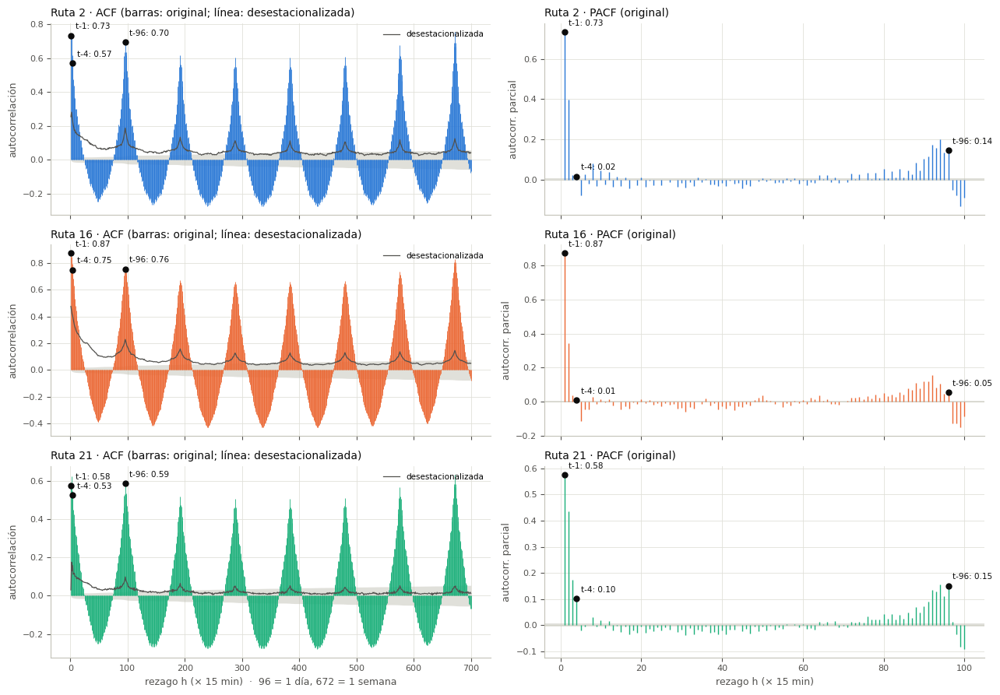

In [10]:
fig, ax = plt.subplots(3, 2, figsize=(13, 9), sharex="col")
for i, r in enumerate(sorted(serie.idruta.unique())):
    a, p, bart, blanco = curvas[(r, "original")]
    h = np.arange(len(a))
    ax[i, 0].vlines(h[1:], 0, a[1:], color=et.COLOR_RUTA[r], lw=0.6)
    ax[i, 0].fill_between(h[1:], -bart[1:], bart[1:], color="#c3c2b7", alpha=0.5, lw=0)
    ad, *_ = curvas[(r, "desestacionalizada")]
    ax[i, 0].plot(h[1:], ad[1:], color=et.INK2, lw=0.9, label="desestacionalizada")
    hp = np.arange(len(p))
    ax[i, 1].vlines(hp[1:], 0, p[1:], color=et.COLOR_RUTA[r], lw=1.0)
    ax[i, 1].axhspan(-blanco, blanco, color="#c3c2b7", alpha=0.5, lw=0)
    for L in cfg.lags:
        for j, (arr, hh) in enumerate([(a, h), (p, hp)]):
            if L < len(arr):
                ax[i, j].plot(L, arr[L], "o", ms=5, color=et.INK, zorder=3)
                ax[i, j].annotate(f"t-{L}: {arr[L]:.2f}", (L, arr[L]), xytext=(4, 6), textcoords="offset points", fontsize=7.5, color=et.INK)
    et.estilo_ejes(ax[i, 0], f"Ruta {r} · ACF (barras: original; línea: desestacionalizada)", None, "autocorrelación")
    et.estilo_ejes(ax[i, 1], f"Ruta {r} · PACF (original)", None, "autocorr. parcial")
    ax[i, 0].legend(frameon=False, loc="upper right", fontsize=7.5)
ax[2, 0].set_xlabel("rezago h (× 15 min)  ·  96 = 1 día, 672 = 1 semana", fontsize=9, color=et.INK2)
ax[2, 1].set_xlabel("rezago h (× 15 min)", fontsize=9, color=et.INK2)
plt.tight_layout(); guardar(fig, "m3_acf_pacf")

**Conclusión 3.5 · t-1 y t-96 dominan; t-4 casi no aporta información propia**

| Ruta | ACF t-1 (15 min) | ACF t-4 (1 h) | ACF t-96 (24 h) | PACF t-1 | PACF t-4 | PACF t-96 |
|---|---|---|---|---|---|---|
| 2 | 0,73 | 0,57 | 0,70 | 0,73 | 0,02 | 0,14 |
| 16 | 0,87 | 0,75 | 0,76 | 0,87 | 0,01 | 0,05 |
| 21 | 0,58 | 0,53 | 0,59 | 0,58 | 0,10 | 0,15 |

- **ACF:** la dependencia es fuerte a corto plazo y casi igual de fuerte a 24 h, con picos en cada múltiplo de 96 y el máximo en t-672 (0,63–0,83). El ciclo semanal es aún más fuerte que el diario. Las correlaciones negativas a ~12 h son el reflejo del ciclo día/noche, no un efecto de demanda.
- **PACF:** casi todo lo de t-4 ya lo explican t-1 a t-3 (PACF de 0,01–0,10). **t-96 conserva información propia** (0,05–0,15) junto a un bloque de rezagos en 90–100: hay memoria estacional diaria.
- **Al desestacionalizar**, la ACF cae a 0,03–0,48 en t-1 y a 0,10–0,23 en t-96. La mayor parte de la autocorrelación cruda es **ciclo determinístico**. Lo que queda (sobre todo en la ruta 16) es la persistencia de choques de demanda.
- Todo es "significativo" por el tamaño muestral (bandas de ±0,006 a ±0,075). Lo informativo es la magnitud.

## 3.6 Perfiles horarios, picos y valles
Unidad: pasajeros por **ruta × fecha × hora de salida** (suma de los cuatro intervalos de la hora). Para cada tipo de día se resumen media, mediana, cuartiles y coeficiente de variación entre días. Hora pico = mayor mediana; valle = menor mediana entre las 6 y las 19 h (los bordes 4–5 h y 20 h son arranque y cierre de servicio). Se excluyen los días anómalos.

,idruta,tipo_dia_cal,dias,hora_pico,mediana_pico,pico_manana,pico_tarde,mediana_pico_tarde,hora_valle,mediana_valle,razon_pico_valle,hora_max_pasajeros_por_viaje
0,2,carnaval,12,15,507.0,5,15,507.0,19,255.0,1.99,17
1,2,domingo,151,16,426.0,8,16,426.0,19,284.0,1.50,17
2,2,festivo,53,16,416.0,5,16,416.0,19,235.0,1.77,16
3,2,laboral,727,5,1857.0,5,14,868.0,19,295.0,6.29,4
4,2,sabado,152,5,1072.5,5,13,570.0,19,312.5,3.43,6
5,16,carnaval,12,16,838.5,6,16,838.5,19,354.0,2.37,17
6,16,domingo,151,16,770.0,8,16,770.0,19,557.0,1.38,4
7,16,festivo,53,16,771.0,5,16,771.0,19,432.0,1.78,4
8,16,laboral,727,5,2688.0,5,14,1913.0,19,676.0,3.98,14
9,16,sabado,152,6,2078.0,6,12,1397.5,19,593.0,3.50,9


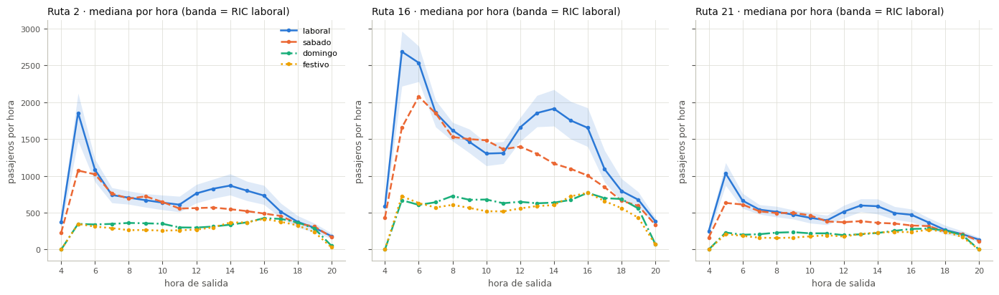

In [11]:
ph = et.pasajeros_hora(serie, cal)
perfil = et.perfil_horario(ph)
picos = et.picos_valles(perfil)
display(picos.round(2))
GRUPOS = ["laboral", "sabado", "domingo", "festivo"]
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for a, (r, g) in zip(ax, perfil.groupby("idruta")):
    for t in GRUPOS:
        gt = g[g.tipo_dia_cal == t]
        a.plot(gt.hora, gt.mediana, ls=et.ESTILO_DIA[t], color=et.COLOR_DIA[t], lw=1.8, marker="o", ms=3, label=t)
        if t == "laboral":
            a.fill_between(gt.hora, gt.p25, gt.p75, color=et.COLOR_DIA[t], alpha=0.15, lw=0)
    et.estilo_ejes(a, f"Ruta {r} · mediana por hora (banda = RIC laboral)", "hora de salida", "pasajeros por hora")
    a.set_xticks(range(4, 21, 2))
ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); guardar(fig, "m3_perfiles_horarios")

**Contraste con la hora real de abordaje.** En las lecturas GPS de los viajes aptos (0.2) cada subida tiene su propia marca de tiempo. Comparar su distribución horaria con la hora de salida mide cuánto desplaza el pico atribuir todo el viaje a la salida.

,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
pct_por_hora_real_de_subida,0.32,3.80,7.78,7.69,5.71,6.23,5.34,5.19,5.74,5.45,6.20,6.08,7.56,8.28,6.99,4.53,3.82,2.43,0.85,0.02
pct_por_hora_de_salida,2.64,10.59,9.27,5.75,6.85,4.77,6.37,5.92,6.05,7.60,8.71,8.04,5.28,5.06,3.32,2.68,1.09,0.00,0.00,0.00


Viajes aptos usados: 1,335 | pico por hora real: 17 h | pico por hora de salida: 5 h


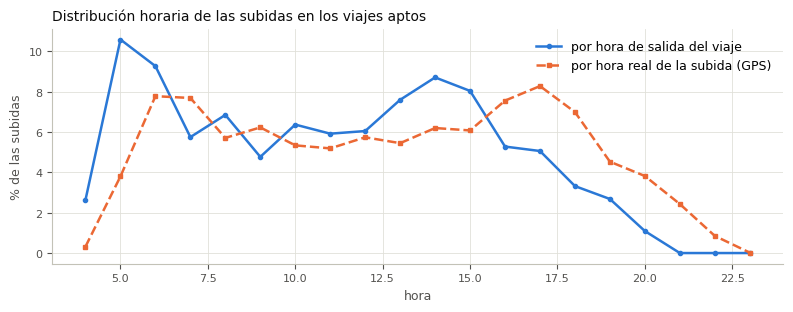

In [12]:
lect_aptas = conteo[conteo.idprogramacion.isin(IDS_APTOS)]
sub_hora_real = lect_aptas.groupby(lect_aptas.fecha.dt.hour).cantidad_subida.sum()
m_aptos = maestra[maestra.idprogramacion.isin(IDS_APTOS)]
sub_hora_salida = m_aptos.groupby("hora").numeropasajeros.sum().astype(float)
comp_hora = pd.DataFrame({"pct_por_hora_real_de_subida": 100 * sub_hora_real / sub_hora_real.sum(),
                          "pct_por_hora_de_salida": 100 * sub_hora_salida / sub_hora_salida.sum()}).fillna(0).round(2)
display(comp_hora.T)
print(f"Viajes aptos usados: {m_aptos.idprogramacion.nunique():,} | pico por hora real: {comp_hora.pct_por_hora_real_de_subida.idxmax()} h | "
      f"pico por hora de salida: {comp_hora.pct_por_hora_de_salida.idxmax()} h")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(comp_hora.index, comp_hora.pct_por_hora_de_salida, color=et.COLOR_RUTA[2], lw=1.8, marker="o", ms=3, label="por hora de salida del viaje")
ax.plot(comp_hora.index, comp_hora.pct_por_hora_real_de_subida, color=et.COLOR_RUTA[16], lw=1.8, ls="--", marker="s", ms=3, label="por hora real de la subida (GPS)")
et.estilo_ejes(ax, "Distribución horaria de las subidas en los viajes aptos", "hora", "% de las subidas")
ax.legend(frameon=False); plt.tight_layout(); guardar(fig, "m3_hora_salida_vs_hora_real")

**Conclusión 3.6 · Los días laborales tienen pico a las 5 h por hora de salida; la demanda real llega a las 6–7 h y a las 16–17 h**
- **Laborales:** pico a las 5 h en las tres rutas y segundo pico a las 13–14 h. La razón pico/valle es de 4,0 (ruta 16) a 6,3 (ruta 2). El valle está a las 19 h.
- **Sábados:** pico de 5–6 h, más bajo. **Domingos y festivos:** sin pico de madrugada, con una meseta y un máximo suave a las 16–17 h (razón pico/valle de 1,4–1,8).
- **La hora de salida desplaza el pico.** En los 1.335 viajes aptos, el 10,6 % de las subidas se asigna a viajes que salen a las 5 h, pero solo el 3,8 % ocurre realmente a esa hora. Por hora real de la subida, los picos son a las 6–7 h (7,8 %) y a las 16–17 h (7,6–8,3 %). Un viaje de ~4 h que sale a las 5 h recoge la hora punta de la mañana.
- **Implicación para el modelo:** si el objetivo es "pasajeros por despacho", la hora de salida es la correcta. Si el objetivo es "pasajeros en la vía", habría que usar las lecturas, que solo existen como muestra.

## 3.7 ¿Difieren laborales, sábados, domingos y festivos?
- **Unidad = día** (pasajeros diarios por ruta), no el intervalo de 15 min: 96 intervalos del mismo día no son 96 observaciones independientes.
- **Kruskal-Wallis** y **Mann-Whitney** por pares (sin suponer normalidad; corrección de Holm dentro de cada ruta), con el δ de Cliff como tamaño de efecto.
- Los días siguen autocorrelacionados (tendencia y ciclo semanal), así que esos valores p son **optimistas**. El contraste principal festivo–laboral usa un **diseño emparejado**: cada festivo entre semana contra el mismo día de la semana 7 días antes y después (Wilcoxon de rangos con signo sobre el log de la razón).
- La **forma** del perfil (proporción del total diario en cada hora) se compara hora a hora con Holm.

In [13]:
from statsmodels.tsa.stattools import acf as _acf
dep = pd.DataFrame({r: _acf(g.sort_values("fecha").pasajeros, nlags=7)[[1, 7]] for r, g in diario.groupby("idruta")}, index=["acf_lag1_dia", "acf_lag7_dias"]).T
print("Dependencia entre días (pasajeros diarios):"); display(dep.round(3))
diario_ok = diario[~diario.dia_anomalo & ~diario.es_carnaval]
kw, pares = et.comparar_tipos_dia(diario_ok)
display(kw.round(4)); display(pares.round(4))

Dependencia entre días (pasajeros diarios):


,acf_lag1_dia,acf_lag7_dias
2,0.380,0.664
16,0.324,0.659
21,0.329,0.630


,idruta,H,p_valor,n_laboral,n_sabado,n_domingo,n_festivo
0,2,619.3156,0.0,727,152,151,53
1,16,643.9098,0.0,727,152,151,53
2,21,641.3114,0.0,727,152,151,53


,idruta,grupo_a,grupo_b,mediana_a,mediana_b,razon_medianas,delta_cliff,p_valor,p_holm
0,2,laboral,sabado,11827.0,9536.5,1.2402,0.7097,0.0000,0.0000
1,2,laboral,domingo,11827.0,5201.0,2.2740,0.9976,0.0000,0.0000
2,2,laboral,festivo,11827.0,4825.0,2.4512,0.9990,0.0000,0.0000
3,2,sabado,domingo,9536.5,5201.0,1.8336,0.9925,0.0000,0.0000
4,2,sabado,festivo,9536.5,4825.0,1.9765,0.9960,0.0000,0.0000
5,2,domingo,festivo,5201.0,4825.0,1.0779,0.3125,0.0007,0.0007
6,16,laboral,sabado,24905.0,20291.5,1.2274,0.7729,0.0000,0.0000
7,16,laboral,domingo,24905.0,9845.0,2.5297,0.9987,0.0000,0.0000
8,16,laboral,festivo,24905.0,9229.0,2.6986,0.9995,0.0000,0.0000
9,16,sabado,domingo,20291.5,9845.0,2.0611,0.9967,0.0000,0.0000


,idruta,pares,mediana_razon_festivo_laboral,p25_razon,p75_razon,W,p_valor,p_holm
0,2,48,0.4061,0.3542,0.4656,0.0,0.0,0.0
1,16,48,0.3725,0.3417,0.4158,0.0,0.0,0.0
2,21,48,0.3963,0.3416,0.4492,0.0,0.0,0.0


Horas en que la PROPORCIÓN horaria difiere entre laboral y festivo (p de Holm < 0,05):


,idruta,hora,prop_mediana_laboral,prop_mediana_festivo,delta_cliff,p_valor,p_holm
0,2,5,0.1501,0.0730,-0.9704,0.0000,0.0000
1,2,6,0.0882,0.0671,-0.7010,0.0000,0.0000
10,2,15,0.0667,0.0787,0.4109,0.0000,0.0000
11,2,16,0.0624,0.0848,0.7461,0.0000,0.0000
12,2,17,0.0440,0.0771,0.8867,0.0000,0.0000
13,2,18,0.0322,0.0674,0.8859,0.0000,0.0000
14,2,19,0.0248,0.0524,0.8781,0.0000,0.0000
15,16,5,0.1050,0.0802,-0.7079,0.0000,0.0000
16,16,6,0.1003,0.0640,-0.9625,0.0000,0.0000
17,16,7,0.0735,0.0632,-0.5475,0.0000,0.0000


Carnaval (12 días, descriptivo):


,mediana_carnaval,mediana_laboral,mediana_domingo,razon_carnaval_laboral
idruta,,,,
2,5326.5,11827.0,5201.0,0.45
16,9853.5,24905.0,9845.0,0.40
21,2746.5,7874.0,3389.0,0.35


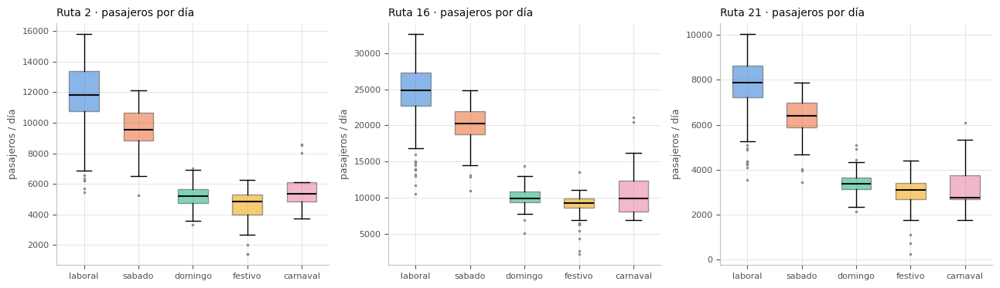

In [14]:
emp = et.festivo_emparejado(diario[~diario.dia_anomalo], cal)
wil = et.wilcoxon_por_ruta(emp)
display(wil.round(4))
forma = et.comparar_forma_horaria(ph)
print("Horas en que la PROPORCIÓN horaria difiere entre laboral y festivo (p de Holm < 0,05):")
display(forma[forma.p_holm < cfg.alpha].round(4))
carn = diario[diario.es_carnaval].groupby("idruta").pasajeros.median().to_frame("mediana_carnaval")
carn["mediana_laboral"] = diario_ok[diario_ok.tipo_dia_cal == "laboral"].groupby("idruta").pasajeros.median()
carn["mediana_domingo"] = diario_ok[diario_ok.tipo_dia_cal == "domingo"].groupby("idruta").pasajeros.median()
carn["razon_carnaval_laboral"] = carn.mediana_carnaval / carn.mediana_laboral
print("Carnaval (12 días, descriptivo):"); display(carn.round(2))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
orden = ["laboral", "sabado", "domingo", "festivo", "carnaval"]
for a, (r, g) in zip(ax, diario[~diario.dia_anomalo].groupby("idruta")):
    datos = [g.loc[g.tipo_dia_cal == t, "pasajeros"] for t in orden]
    bp = a.boxplot(datos, tick_labels=orden, widths=0.55, patch_artist=True, medianprops={"color": et.INK, "lw": 1.5},
                   flierprops={"marker": ".", "ms": 3, "markeredgecolor": et.MUTED})
    for patch, t in zip(bp["boxes"], orden):
        patch.set_facecolor(et.COLOR_DIA[t]); patch.set_alpha(0.55); patch.set_edgecolor(et.INK2)
    et.estilo_ejes(a, f"Ruta {r} · pasajeros por día", None, "pasajeros / día")
    a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); guardar(fig, "m3_pasajeros_diarios_por_tipo_dia")

**Conclusión 3.7 · Un festivo entre semana mueve ≈ 40 % de los pasajeros de un laboral normal**
- **Por pares (diseño principal):** 48 festivos entre semana por ruta, cada uno frente al mismo día de la semana anterior y la siguiente. La mediana de la razón festivo/laboral es **0,41 (ruta 2), 0,37 (16) y 0,40 (21)**, con un RIC de ≈ 0,34–0,47. Wilcoxon da W = 0 en las tres rutas, porque **todos** los festivos quedaron por debajo de su referencia; p de Holm < 0,001.
- **Por grupos (descriptivo, p optimistas):** la mediana diaria de los laborales es 2,3–2,7 veces la de domingos y festivos. Los sábados están ≈ 19 % por debajo de los laborales. Festivo y domingo son parecidos: el festivo es 6–9 % más bajo, con un δ de Cliff de 0,31–0,37 (efecto pequeño-moderado). **No se deben fusionar sin más.**
- **Cambia la forma, no solo el nivel.** En festivo, la proporción del día a las 5 h cae a la mitad (δ de Cliff de −0,71 a −0,97) y la de las 16–19 h casi se duplica (δ de +0,61 a +0,89; Holm < 0,001 en las tres rutas).
- **Carnaval:** 0,35–0,45 de un laboral, al nivel de un domingo.
- **Por qué no basta con un test independiente:** los días están autocorrelacionados (ACF de 0,32–0,38 a 1 día y de 0,63–0,66 a 7 días). Las pruebas por grupos tratan los días como independientes y exageran la significancia. Por eso la conclusión cuantitativa se apoya en el diseño emparejado.

# Módulo 4 · Dimensión espacial

## 4.1 Validación de coordenadas
Coordenadas en grados decimales; el GPS de los buses entrega WGS84 (EPSG:4326), lo que se confirma porque el 99,9999 % cae en la caja Barranquilla–Soledad de la 1.4. Una fila **no** es una ubicación: hay ~580 lecturas por viaje y muchas repetidas mientras el bus está detenido.

In [15]:
la, lo = conteo.latitud, conteo.longitud
caja = la.between(CAJA["lat_min"], CAJA["lat_max"]) & lo.between(CAJA["lon_min"], CAJA["lon_max"])
val_coord = pd.Series({
    "lecturas": len(conteo), "viajes": conteo.idprogramacion.nunique(),
    "lat_o_lon_nulas": int((la.isna() | lo.isna()).sum()), "lat_o_lon_en_cero": int(((la == 0) | (lo == 0)).sum()),
    "fuera_rango_geografico (|lat|>90 o |lon|>180)": int(((la.abs() > 90) | (lo.abs() > 180)).sum()),
    "fuera_caja_Barranquilla_Soledad": int((~caja).sum()),
    "pct_coordenadas_exactas_repetidas": round(100 * conteo.duplicated(["latitud", "longitud"]).mean(), 2),
    "lecturas_repetidas (viaje, fecha)": int(conteo.duplicated(["idprogramacion", "fecha"]).sum()),
    "id_duplicado": int(conteo.id.duplicated().sum()),
}).to_frame("valor")
display(val_coord)
display(conteo.loc[~caja, ["id", "idprogramacion", "fecha", "latitud", "longitud"]])
c = conteo[caja].sort_values(["idprogramacion", "fecha", "id"])
mismo = c.idprogramacion.values[1:] == c.idprogramacion.values[:-1]
paso_m = et.haversine_m(c.latitud.values[:-1], c.longitud.values[:-1], c.latitud.values[1:], c.longitud.values[1:])[mismo]
paso_s = np.diff(c.fecha.values).astype("timedelta64[s]").astype(float)[mismo]
cadencia = pd.DataFrame({"paso_m": paso_m, "cadencia": np.where(paso_s >= 30, "≥ 30 s (periódica)", "< 30 s (por evento)")})
display(cadencia.groupby("cadencia").paso_m.describe(percentiles=[.25, .5, .75, .9]).round(1))

,valor
lecturas,971335.0
viajes,1673.0
lat_o_lon_nulas,0.0
lat_o_lon_en_cero,0.0
fuera_rango_geografico (|lat|>90 o |lon|>180),0.0
fuera_caja_Barranquilla_Soledad,1.0
pct_coordenadas_exactas_repetidas,21.4
"lecturas_repetidas (viaje, fecha)",48111.0
id_duplicado,0.0


,id,idprogramacion,fecha,latitud,longitud
799024,1319697319,7251857,2025-08-21 07:00:24,89.0,4.5


,count,mean,std,min,25%,50%,75%,90%,max
cadencia,,,,,,,,,
< 30 s (por evento),630164.0,20.5,32.0,0.0,0.0,10.5,27.0,50.3,561.7
≥ 30 s (periódica),339497.0,254.5,203.3,0.0,112.1,226.2,355.0,496.3,16393.4


**Conclusión 4.1 · Coordenadas válidas; una sola lectura imposible**
- 971.335 lecturas de 1.673 viajes: 0 nulas, 0 en cero. **Solo 1 está fuera de la caja** (lat 89,0, lon 4,5, en el Ártico: un error del GPS) y se excluye. El resto está en el rango de Barranquilla–Soledad, coherente con WGS84 en grados decimales.
- El 21,4 % de las coordenadas se repite exactamente (bus detenido) y hay 48.111 lecturas con el mismo viaje y segundo. **Una lectura no es una ubicación**: la unidad espacial hay que construirla.
- **El GPS tiene dos cadencias.** Una periódica (≥ 30 s), con un paso mediano de 226 m (p75 = 355 m). Otra por evento (< 30 s, al subir o bajar alguien), con una mediana de 10,5 m. Una celda de 250 m queda cerca del paso típico entre lecturas periódicas.

## 4.2 Unidades espaciales: celdas de 250 m
No hay paraderos georreferenciados (`idpunto` está nulo en el 90 % según la 1.4), así que la unidad espacial se **construye**: una malla regular de 250 m (proyección local solo para agrupar; las distancias entre celdas se miden con Haversine). 250 m ≈ el paso típico entre dos lecturas periódicas (4.1), de modo que casi todo viaje que cruza una celda deja al menos una lectura en ella.

Variable: **`subidas_por_viaje`** = subidas registradas en la celda / viajes distintos que pasan por ella (exposición). Se exigen ≥ 30 viajes para que la tasa sea estable. Cada celda es **una** unidad: las lecturas repetidas de un mismo lugar no cuentan como unidades independientes. Es un análisis **exploratorio** de la estructura espacial de la demanda, no una variable de entrenamiento.

In [16]:
LECT_ESP = conteo[conteo.idprogramacion.isin(IDS_APTOS) & ~conteo.flag_fuera_area]
celdas_todas, lect_celda, LAT_REF = et.construir_celdas(LECT_ESP, cfg)
celdas = celdas_todas[celdas_todas.apta].sort_values(["cy", "cx"]).reset_index(drop=True)
celdas.insert(0, "celda_id", np.arange(len(celdas)))
print(f"Lecturas usadas: {len(LECT_ESP):,} de {LECT_ESP.idprogramacion.nunique():,} viajes | celdas con lecturas: {len(celdas_todas):,} | "
      f"celdas aptas (≥ {cfg.min_viajes_celda} viajes): {len(celdas):,}")
print(f"Las celdas aptas concentran el {100 * celdas.subidas.sum() / celdas_todas.subidas.sum():.2f} % de las subidas y el "
      f"{100 * celdas.n_lecturas.sum() / celdas_todas.n_lecturas.sum():.2f} % de las lecturas")
assert celdas[["latitud", "longitud"]].duplicated().sum() == 0, "Centroides coincidentes"
display(celdas[["n_viajes", "n_lecturas", "subidas", "subidas_por_viaje", "bajadas_por_viaje", "n_rutas"]].describe().round(2))
display(celdas.n_rutas.value_counts().sort_index().to_frame("celdas por nº de rutas que la usan"))

Lecturas usadas: 452,967 de 1,335 viajes | celdas con lecturas: 816 | celdas aptas (≥ 30 viajes): 364
Las celdas aptas concentran el 99.91 % de las subidas y el 99.14 % de las lecturas


,n_viajes,n_lecturas,subidas,subidas_por_viaje,bajadas_por_viaje,n_rutas
count,364.00,364.00,364.00,364.00,364.00,364.00
mean,489.81,1233.68,315.27,0.56,0.59,2.09
std,333.39,1223.88,391.05,0.51,0.48,0.88
min,30.00,32.00,0.00,0.00,0.00,1.00
25%,271.00,386.75,51.50,0.20,0.26,1.00
50%,411.50,906.50,193.50,0.45,0.52,2.00
75%,647.25,1607.75,428.00,0.80,0.78,3.00
max,1331.00,9329.00,3155.00,2.77,3.13,3.00


,celdas por nº de rutas que la usan
n_rutas,
1,125
2,81
3,158


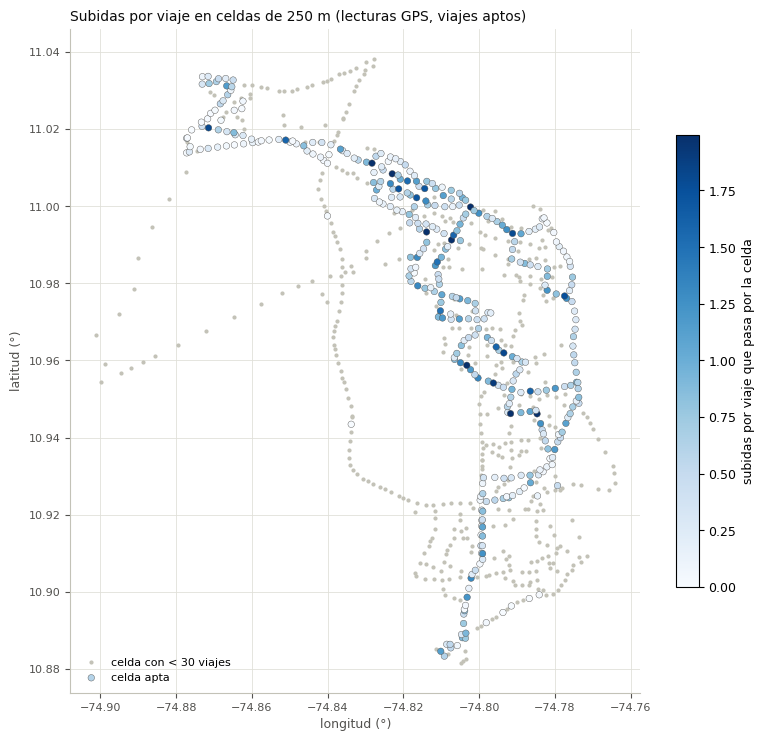

In [17]:
ASPECTO = 1 / np.cos(np.radians(LAT_REF))
fig, ax = plt.subplots(figsize=(8, 8))
no_apt = celdas_todas[~celdas_todas.apta]
ax.scatter(no_apt.longitud, no_apt.latitud, s=4, color="#c3c2b7", label=f"celda con < {cfg.min_viajes_celda} viajes")
sc = ax.scatter(celdas.longitud, celdas.latitud, c=celdas.subidas_por_viaje, cmap="Blues", s=22, edgecolor=et.INK2, lw=0.3,
                vmin=0, vmax=celdas.subidas_por_viaje.quantile(.98), label="celda apta")
fig.colorbar(sc, ax=ax, shrink=0.6, label="subidas por viaje que pasa por la celda")
ax.set_aspect(ASPECTO); et.estilo_ejes(ax, "Subidas por viaje en celdas de 250 m (lecturas GPS, viajes aptos)", "longitud (°)", "latitud (°)")
ax.legend(frameon=False, loc="lower left", fontsize=8); plt.tight_layout(); guardar(fig, "m4_mapa_celdas")

**Conclusión 4.2 · 364 celdas aptas describen los corredores de las 3 rutas**
- Entraron 452.967 lecturas de 1.335 viajes. Se excluyeron 338 viajes: 192 de la muestra dirigida de bloqueos, 42 de la de ceros, 99 con sensor no confiable y 5 con carga imposible.
- Hay 816 celdas con lecturas y **364 con ≥ 30 viajes**. Esas 364 concentran el 99,9 % de las subidas, así que las descartadas son bordes y desvíos con poca exposición.
- La mediana es de 0,45 subidas por viaje que pasa (máximo 2,77). **158 celdas son compartidas por las 3 rutas** y 125 son exclusivas de una.
- El mapa muestra tramos con muchas subidas contiguos a otros con muchas subidas: indicio visual de autocorrelación positiva, que se mide en 4.3.

## 4.3 KNN con distancia Haversine y selección de k con el índice de Moran
Convención fija para todo el módulo:
- **A_k**: matriz binaria dirigida, `A[i, j] = 1` si j es uno de los k vecinos más cercanos de i por Haversine (se excluye i). En general A ≠ Aᵀ.
- **Moran** se calcula con **W = A_k estandarizada por filas** (cada fila suma 1, S0 = n), la convención habitual de PySAL. Inferencia: 999 permutaciones con semilla 42 (p unilateral en la dirección observada) y la aproximación normal bajo aleatorización.
- **Grafo y conectividad**: versión simétrica por **unión** (i~j si cualquiera es vecino del otro). La intersección (vecindades mutuas) se reporta como diagnóstico.

**Regla de elección de k (no se maximiza Moran):** entre los k cuya unión es un grafo conexo, cuyo k-ésimo vecino mediano está a ≤ 500 m (escala de caminata a un paradero) y sin empates en la k-ésima distancia, se toma el **mayor**, porque más vecinos estabilizan el rezago espacial sin salir de la escala local.

In [18]:
eval_k = et.evaluar_k(celdas, "subidas_por_viaje", cfg)
display(eval_k[["k", "matriz", "n_ubicaciones", "I", "E_I", "z_aleatorizacion", "p_aleatorizacion", "z_permutacion", "p_permutacion",
                "I_union_sim", "pct_vecindades_mutuas", "componentes_union", "aislados_union", "componentes_interseccion",
                "grado_medio_union", "grado_max_union", "dist_k_mediana_m", "dist_k_p95_m", "dist_k_max_m", "empates_k"]].round(4))
candidatos = eval_k[(eval_k.componentes_union == 1) & (eval_k.dist_k_mediana_m <= 500) & (eval_k.empates_k == 0)]
K = int(candidatos.k.max())
print(f"k candidatos: {candidatos.k.tolist()} → k elegido = {K}")
print(f"Rango de I para k entre 3 y 8: {eval_k[eval_k.k.between(3, 8)].I.min():.3f} – {eval_k[eval_k.k.between(3, 8)].I.max():.3f}")

,k,matriz,n_ubicaciones,I,E_I,z_aleatorizacion,p_aleatorizacion,z_permutacion,p_permutacion,I_union_sim,pct_vecindades_mutuas,componentes_union,aislados_union,componentes_interseccion,grado_medio_union,grado_max_union,dist_k_mediana_m,dist_k_p95_m,dist_k_max_m,empates_k
0,2,"KNN binaria dirigida, estandarizada por filas",364,0.2610,-0.0028,5.3086,0.0,5.2604,0.001,0.2581,82.4176,6,0,78,2.3516,4,225.1958,307.7188,3537.9597,0
1,3,"KNN binaria dirigida, estandarizada por filas",364,0.2173,-0.0028,5.4082,0.0,5.3233,0.001,0.2139,84.0659,1,0,18,3.4780,6,286.6016,482.8227,3614.7586,0
2,4,"KNN binaria dirigida, estandarizada por filas",364,0.2106,-0.0028,6.0338,0.0,5.9723,0.001,0.2017,85.8516,1,0,7,4.5659,7,359.2262,528.2968,3665.8498,1
3,5,"KNN binaria dirigida, estandarizada por filas",364,0.1912,-0.0028,6.1444,0.0,6.2234,0.001,0.1855,85.8242,1,0,6,5.7088,9,415.3373,609.6931,3740.3828,0
4,6,"KNN binaria dirigida, estandarizada por filas",364,0.1755,-0.0028,6.1912,0.0,6.2407,0.001,0.1769,86.0806,1,0,4,6.8352,10,480.0400,680.3943,3782.0353,0
5,8,"KNN binaria dirigida, estandarizada por filas",364,0.1495,-0.0028,6.1347,0.0,6.0381,0.001,0.1441,85.5082,1,0,3,9.1593,15,560.4779,804.5011,3890.4048,0
6,10,"KNN binaria dirigida, estandarizada por filas",364,0.1315,-0.0028,6.0531,0.0,5.9966,0.001,0.1238,86.3736,1,0,3,11.3626,18,655.8958,935.8836,3983.1855,1
7,12,"KNN binaria dirigida, estandarizada por filas",364,0.1251,-0.0028,6.3313,0.0,6.2109,0.001,0.1163,86.5385,1,0,3,13.6154,20,738.1886,1090.4141,4052.6667,0
8,15,"KNN binaria dirigida, estandarizada por filas",364,0.1275,-0.0028,7.2431,0.0,7.0746,0.001,0.1268,86.5201,1,0,3,17.0220,25,859.0184,1257.5502,4155.1197,0
9,20,"KNN binaria dirigida, estandarizada por filas",364,0.1220,-0.0028,8.0848,0.0,7.9209,0.001,0.1200,86.2912,1,0,3,22.7418,42,1044.8548,1574.4270,4274.9366,0


k candidatos: [3, 5, 6] → k elegido = 6
Rango de I para k entre 3 y 8: 0.150 – 0.217


,banda_m,dist_media_m,celdas_con_vecinos,pares,I,z_permutacion,p_permutacion
0,"(0, 300]",150.0,355,1014,0.2273,4.8935,0.001
1,"(300, 600]",450.0,362,2104,0.1509,4.6821,0.001
2,"(600, 900]",750.0,362,2820,0.0825,2.7564,0.007
3,"(900, 1200]",1050.0,360,3268,0.1283,4.7564,0.001
4,"(1200, 1800]",1500.0,363,6932,0.0926,5.2823,0.001
5,"(1800, 2400]",2100.0,363,7406,0.0771,4.2703,0.001
6,"(2400, 3600]",3000.0,364,16542,0.0406,3.6001,0.001
7,"(3600, 5000]",4300.0,364,18480,0.0005,0.2847,0.386
8,"(5000, 7500]",6250.0,364,27782,-0.0495,-6.1357,0.001
9,"(7500, 10000]",8750.0,364,20834,-0.0868,-9.2983,0.001


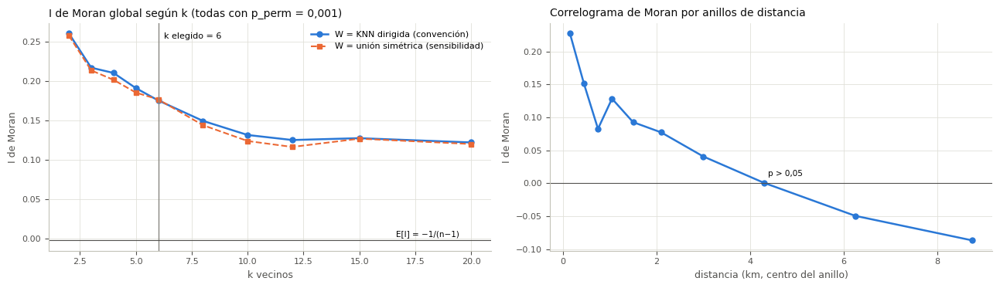

In [19]:
correlo = et.correlograma_distancia(celdas, "subidas_por_viaje", [0, 300, 600, 900, 1200, 1800, 2400, 3600, 5000, 7500, 10000], cfg)
display(correlo.round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(eval_k.k, eval_k.I, color=et.COLOR_RUTA[2], lw=1.8, marker="o", ms=5, label="W = KNN dirigida (convención)")
ax[0].plot(eval_k.k, eval_k.I_union_sim, color=et.COLOR_RUTA[16], lw=1.5, ls="--", marker="s", ms=4, label="W = unión simétrica (sensibilidad)")
ax[0].axvline(K, color=et.MUTED, lw=1); ax[0].annotate(f"k elegido = {K}", (K, eval_k.I.max()), xytext=(5, -5), textcoords="offset points", fontsize=8)
ax[0].axhline(eval_k.E_I.iloc[0], color=et.INK2, lw=0.8); ax[0].annotate("E[I] = −1/(n−1)", (eval_k.k.max(), eval_k.E_I.iloc[0]), xytext=(-70, 4), textcoords="offset points", fontsize=7.5)
et.estilo_ejes(ax[0], "I de Moran global según k (todas con p_perm = 0,001)", "k vecinos", "I de Moran"); ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(correlo.dist_media_m / 1000, correlo.I, color=et.COLOR_RUTA[2], lw=1.8, marker="o", ms=5)
ax[1].axhline(0, color=et.INK2, lw=0.8)
for _, r in correlo[correlo.p_permutacion > cfg.alpha].iterrows():
    ax[1].annotate("p > 0,05", (r.dist_media_m / 1000, r.I), xytext=(4, 6), textcoords="offset points", fontsize=7.5)
et.estilo_ejes(ax[1], "Correlograma de Moran por anillos de distancia", "distancia (km, centro del anillo)", "I de Moran")
plt.tight_layout(); guardar(fig, "m4_moran_k_y_correlograma")

### Matriz elegida: comprobaciones de dimensión, diagonal, vecinos y simetría

In [20]:
IDX, DIST = et.knn_haversine(celdas.latitud.values, celdas.longitud.values, K)
A = et.matriz_knn(IDX, len(celdas))
W = et.estandarizar_filas(A)
U = et.simetrizar(A, "union")
n = len(celdas)
chk_W = pd.Series({
    "dimension": f"{A.shape[0]} × {A.shape[1]}", "n_ubicaciones": n,
    "diagonal_nula": bool(A.diagonal().sum() == 0),
    "vecinos_por_fila_min_max": f"{int(A.sum(1).min())} – {int(A.sum(1).max())}",
    "filas_W_suman_1": bool(np.allclose(np.asarray(W.sum(1)).ravel(), 1)),
    "A_simetrica": bool((A != A.T).nnz == 0),
    "pct_vecindades_mutuas": round(100 * A.multiply(A.T).nnz / A.nnz, 2),
    "aristas_no_dirigidas_union": int(U.nnz // 2),
    "empates_en_k": et.empates_k(celdas.latitud.values, celdas.longitud.values, K),
    "dist_vecino_k_mediana_m": round(float(np.median(DIST[:, -1])), 1),
    "dist_vecino_1_mediana_m": round(float(np.median(DIST[:, 0])), 1),
}).to_frame("valor")
display(chk_W)
grado_U = np.asarray(U.sum(1)).ravel()
display(pd.Series(grado_U).value_counts().sort_index().to_frame("celdas por grado en la unión").T)
moran_K = et.moran_global(celdas.subidas_por_viaje.values, W, cfg.permutaciones, cfg.semilla)
display(pd.Series({k: v for k, v in moran_K.items() if not k.startswith("_")}).to_frame(f"Moran · k = {K}").round(5))

,valor
dimension,364 × 364
n_ubicaciones,364
diagonal_nula,True
vecinos_por_fila_min_max,6 – 6
filas_W_suman_1,True
A_simetrica,False
pct_vecindades_mutuas,86.08
aristas_no_dirigidas_union,1244
empates_en_k,0
dist_vecino_k_mediana_m,480.0


,6.0,7.0,8.0,9.0,10.0
celdas por grado en la unión,173,110,56,18,7


,Moran · k = 6
I,0.1755
E_I,-0.0027
z_normal,6.1647
p_normal,0.0000
z_aleatorizacion,6.1912
p_aleatorizacion,0.0000
p_permutacion,0.0010
I_perm_media,-0.0028
I_perm_desv,0.0286
z_permutacion,6.2407


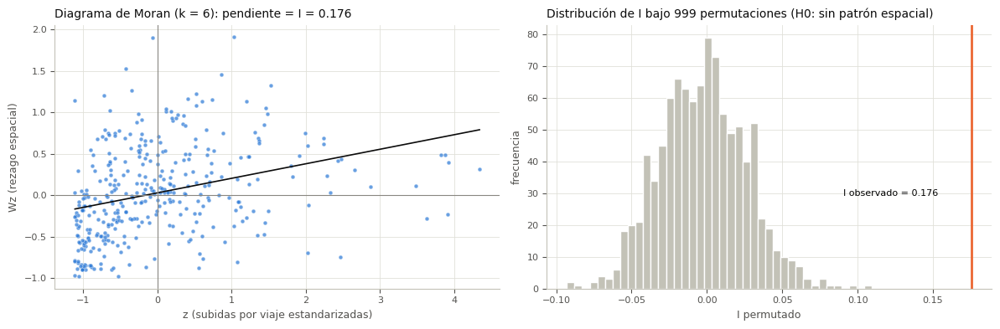

In [21]:
z = celdas.subidas_por_viaje.values - celdas.subidas_por_viaje.mean()
z = z / z.std()
wz = W @ z
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(z, wz, s=12, color=et.COLOR_RUTA[2], alpha=0.7, edgecolor="white", lw=0.3)
b = np.polyfit(z, wz, 1)
xs = np.linspace(z.min(), z.max(), 50); ax[0].plot(xs, b[0] * xs + b[1], color=et.INK, lw=1.2)
ax[0].axhline(0, color=et.MUTED, lw=0.8); ax[0].axvline(0, color=et.MUTED, lw=0.8)
et.estilo_ejes(ax[0], f"Diagrama de Moran (k = {K}): pendiente = I = {b[0]:.3f}", "z (subidas por viaje estandarizadas)", "Wz (rezago espacial)")
ax[1].hist(moran_K["_I_perm"], bins=40, color="#c3c2b7", edgecolor="white")
ax[1].axvline(moran_K["I"], color=et.COLOR_RUTA[16], lw=2); ax[1].annotate(f"I observado = {moran_K['I']:.3f}", (moran_K["I"], 0), xytext=(-110, 80), textcoords="offset points", fontsize=8)
et.estilo_ejes(ax[1], f"Distribución de I bajo {cfg.permutaciones} permutaciones (H0: sin patrón espacial)", "I permutado", "frecuencia")
plt.tight_layout(); guardar(fig, "m4_diagrama_moran_y_permutaciones")

### Sensibilidad: tamaño de celda, exposición mínima y transformación de la variable

In [22]:
sens = []
for lado in [200, 250, 300, 400]:
    for min_v in [30, 50]:
        cfg_s = et.Config(celda_m=lado, min_viajes_celda=min_v)
        cs, _, _ = et.construir_celdas(LECT_ESP, cfg_s, lat_ref=LAT_REF)
        cs = cs[cs.apta].reset_index(drop=True)
        ix, _ = et.knn_haversine(cs.latitud.values, cs.longitud.values, K)
        Ws = et.estandarizar_filas(et.matriz_knn(ix, len(cs)))
        for var, y in [("subidas_por_viaje", cs.subidas_por_viaje), ("log1p(subidas_por_viaje)", np.log1p(cs.subidas_por_viaje)),
                       ("bajadas_por_viaje", cs.bajadas_por_viaje)]:
            mr = et.moran_global(y.values, Ws, cfg.permutaciones, cfg.semilla)
            sens.append({"celda_m": lado, "min_viajes": min_v, "variable": var, "n_celdas": len(cs), "k": K, "I": mr["I"],
                         "z_permutacion": mr["z_permutacion"], "p_permutacion": mr["p_permutacion"]})
_, d1 = et.knn_haversine(celdas.latitud.values, celdas.longitud.values, 1)
cer = celdas[d1[:, 0] <= 1000].reset_index(drop=True)
ixc, _ = et.knn_haversine(cer.latitud.values, cer.longitud.values, K)
mr = et.moran_global(cer.subidas_por_viaje.values, et.estandarizar_filas(et.matriz_knn(ixc, len(cer))), cfg.permutaciones, cfg.semilla)
sens.append({"celda_m": cfg.celda_m, "min_viajes": cfg.min_viajes_celda, "variable": "subidas_por_viaje (sin celdas a > 1 km de su vecina)",
             "n_celdas": len(cer), "k": K, "I": mr["I"], "z_permutacion": mr["z_permutacion"], "p_permutacion": mr["p_permutacion"]})
print(f"Celdas cuya vecina más cercana está a más de 1 km: {(d1[:, 0] > 1000).sum()} → sin ellas, I = {mr['I']:.4f} (p = {mr['p_permutacion']:.3f})")
display(celdas.loc[d1[:, 0] > 1000, ["celda_id", "latitud", "longitud", "n_viajes", "subidas_por_viaje", "rutas"]])
sens = pd.DataFrame(sens)
display(sens.pivot_table(index=["celda_m", "min_viajes", "n_celdas"], columns="variable", values="I").round(3))
print("Máximo p por permutación en toda la tabla:", sens.p_permutacion.max())

Celdas cuya vecina más cercana está a más de 1 km: 2 → sin ellas, I = 0.1783 (p = 0.001)


,celda_id,latitud,longitud,n_viajes,subidas_por_viaje,rutas
76,76,10.9434,-74.8338,31,0.0000,"2,16,21"
230,230,10.9974,-74.8400,31,0.0323,"2,16,21"


variable                     bajadas_por_viaje  log1p(subidas_por_viaje)  subidas_por_viaje  subidas_por_viaje (sin celdas a > 1 km de su vecina)
celda_m min_viajes n_celdas                                                                                                                      
200.0   30         447                   0.208                     0.216              0.166                                                NaN   
        50         426                   0.229                     0.223              0.170                                                NaN   
250.0   30         362                     NaN                       NaN                NaN                                              0.178   
                   364                   0.185                     0.233              0.176                                                NaN   
        50         349                   0.196                     0.225              0.169                                                NaN   
300.0   30         291                   0.192                     0.256              0.196                                                NaN   
        50         269                   0.236                     0.255              0.193                                                NaN   
400.0   30         228                   0.203                     0.294              0.190                                                NaN   
        50         198                   0.154                     0.156              0.091                                                NaN

Máximo p por permutación en toda la tabla: 0.013


**Conclusión 4.3 · Autocorrelación espacial positiva y robusta; k = 6 por regla, no por máximo**
- **Para todo k de 2 a 20, el I de Moran es positivo y significativo** (z por permutación de 5,3 a 7,9; p = 0,001, el mínimo posible con 999 permutaciones). Hay agrupamiento de celdas con muchas subidas.
- **I decrece al aumentar k**: 0,26 (k = 2), 0,18 (k = 6), 0,12 (k = 20). Más vecinos implican vecindades más amplias y más heterogéneas. **Maximizar I llevaría a k = 2, que parte el grafo en 6 componentes**: por eso no se usa ese criterio.
- **Regla aplicada:** conexo (k ≥ 3), vecino k-ésimo mediano ≤ 500 m y sin empates. Candidatos: 3, 5 y 6 (en k = 4 hay un empate). Se eligió **k = 6**: vecino 6.º mediano a 480 m, 86 % de vecindades mutuas, un solo componente. Entre k = 3 y k = 8, I se mueve en 0,15–0,22, así que la elección no cambia la conclusión.
- **Escala:** el correlograma es positivo hasta ~3,6 km (0,23 en 0–300 m; 0,04 en 2,4–3,6 km), no significativo en 3,6–5 km y negativo a más de 5 km. Las zonas de alta demanda se extienden a lo largo de 2–3 km de corredor.
- **Robustez:** con celdas de 200 a 400 m, exposición mínima de 30 o 50, o la transformación log1p, I va de 0,09 a 0,29, siempre con p ≤ 0,013. Sin las 2 celdas apartadas (su vecina más cercana está a más de 1 km), I = 0,178.
- **Límite:** la muestra es de 1.335 viajes en 3 años. Las tasas de las celdas con poca exposición son ruidosas y no se corrigieron por Bayes empírico. El I describe la **estructura**, no un valor poblacional preciso.

## 4.4 Grafo espacial con NetworkX
Nodo = celda apta (atributos: latitud, longitud, rutas, viajes, subidas por viaje). Arista = vecindad KNN en la versión simétrica por unión; atributos: `distancia_m` (Haversine), `peso` = 1 (la matriz es binaria) y `mutua` (si la vecindad va en ambos sentidos).

In [23]:
G = et.grafo_espacial(celdas, A, (IDX, DIST))
assert G.number_of_nodes() == n and G.number_of_edges() == U.nnz // 2, "El grafo no coincide con la matriz de la unión"
met_G = et.metricas_grafo(G)
display(met_G)
grado = pd.Series(dict(G.degree()))
nodos_alto_grado = celdas.set_index("celda_id").loc[grado[grado >= grado.quantile(.99)].index, ["latitud", "longitud", "rutas", "subidas_por_viaje"]]
print("Celdas con grado en el percentil 99 (cruces o tramos donde convergen corredores):"); display(nodos_alto_grado.assign(grado=grado))

,valor
nodos,364
aristas,1244
densidad,0.0188
componentes_conexos,1
tamano_componentes,[364]
nodos_aislados,0
grado_min,6
grado_medio,6.8352
grado_max,10
clustering_medio,0.5951


Celdas con grado en el percentil 99 (cruces o tramos donde convergen corredores):


,latitud,longitud,rutas,subidas_por_viaje,grado
6,10.8881,-74.8044,"2,16,21",0.9107,10
26,10.9084,-74.7991,"2,16,21",0.2838,10
96,10.9525,-74.7913,"2,21",0.9459,10
103,10.9535,-74.7758,"2,16",0.6508,10
138,10.9683,-74.8001,"2,21",0.6441,10
166,10.9767,-74.7774,16,1.7494,10
362,11.0331,-74.8669,"2,16,21",0.2170,10


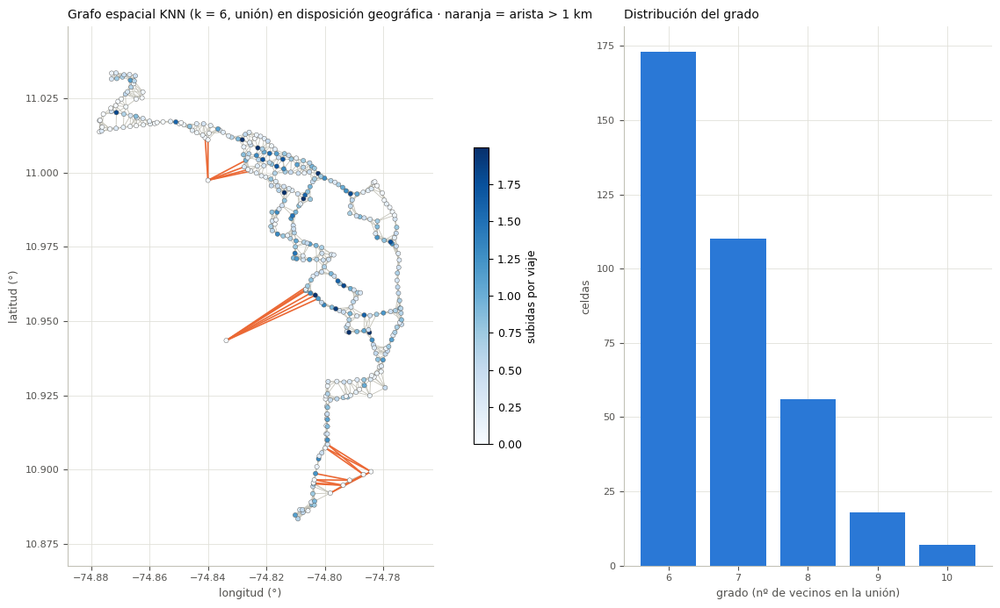

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [2.2, 1]})
pos = {i: (d["longitud"], d["latitud"]) for i, d in G.nodes(data=True)}
largas = [(u, v) for u, v, d in G.edges(data=True) if d["distancia_m"] > 1000]
nx.draw_networkx_edges(G, pos, ax=ax[0], edgelist=[e for e in G.edges() if e not in set(largas)], edge_color="#c3c2b7", width=0.6)
nx.draw_networkx_edges(G, pos, ax=ax[0], edgelist=largas, edge_color=et.COLOR_RUTA[16], width=1.2)
nodos = nx.draw_networkx_nodes(G, pos, ax=ax[0], node_size=14, node_color=[d["subidas_por_viaje"] for _, d in G.nodes(data=True)],
                               cmap="Blues", vmin=0, vmax=celdas.subidas_por_viaje.quantile(.98), edgecolors=et.INK2, linewidths=0.3)
fig.colorbar(nodos, ax=ax[0], shrink=0.55, label="subidas por viaje")
ax[0].set_aspect(ASPECTO); ax[0].tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
et.estilo_ejes(ax[0], f"Grafo espacial KNN (k = {K}, unión) en disposición geográfica · naranja = arista > 1 km", "longitud (°)", "latitud (°)")
vc = grado.value_counts().sort_index()
ax[1].bar(vc.index, vc.values, color=et.COLOR_RUTA[2], width=0.8)
et.estilo_ejes(ax[1], "Distribución del grado", "grado (nº de vecinos en la unión)", "celdas")
plt.tight_layout(); guardar(fig, "m4_grafo_espacial")

**Conclusión 4.4 · Un solo componente, que sigue los corredores**
- 364 nodos y 1.244 aristas (densidad 0,019). **1 componente conexo, 0 aislados**. El grado va de 6 a 10 (media 6,8): KNN garantiza al menos k vecinos y la unión añade los que te eligen a ti.
- **Clustering medio de 0,60** y **diámetro de 53 saltos** (camino medio de 16,6): es un grafo "largo" y local, como corresponde a celdas sobre vías. No es una red de mundo pequeño.
- La arista mediana mide 350 m (p95 = 645 m). **24 aristas superan 1 km.** Salen de unos pocos puntos apartados del corredor (desvíos o puntos de maniobra con ~0 subidas y 31 viajes). KNN los obliga a tener 6 vecinos aunque estén lejos. Es una limitación conocida de KNN frente a un umbral de distancia.
- Las celdas de grado 10 (p99) son cruces donde convergen 2–3 rutas. Allí el rezago espacial mezcla corredores distintos.

# Módulo 5 · Multicolinealidad

## 5.1 Roles de las columnas de la maestra
Antes de medir redundancia se separa lo que **no** es predictor: el objetivo, sus derivados exactos, identificadores, marcas de tiempo y las mediciones que solo existen **al cerrar el viaje** (riesgo de leakage si se pronostica en el momento de la salida).

In [25]:
ROLES = {
    "idprogramacion": ("identificador", "no", "—"), "idvehiculo": ("identificador", "sí (asignación)", "bajo"),
    "idruta": ("categórica", "sí", "—"), "fechasalida": ("marca temporal (programada)", "sí", "—"),
    "fechainicio": ("marca temporal (real)", "no", "alto"), "fechafin": ("marca temporal (real)", "no", "alto"),
    "fecha": ("marca temporal", "sí", "—"), "anio_mes": ("marca temporal", "sí", "—"), "hora": ("calendario", "sí", "—"),
    "dia_semana": ("calendario", "sí", "—"), "tipo_dia": ("calendario (sin festivos)", "sí", "—"),
    "cancelada": ("constante en la maestra", "—", "—"), "finalizado": ("constante en la maestra", "—", "—"),
    "duracion_min": ("operación post-viaje", "no", "alto"), "retraso_salida_min": ("operación al iniciar", "no (se conoce al arrancar)", "medio"),
    "puntualidad": ("categórica post-salida", "no", "medio"), "flag_duracion_atipica": ("bandera post-viaje", "no", "alto"),
    "distancia_recorrida": ("operación post-viaje", "no", "alto"), "razon_distancia": ("derivada post-viaje", "no", "alto"),
    "numeropasajeros": ("OBJETIVO (imputado sin leakage)", "no", "es el objetivo"),
    "numeropasajeros_raw": ("objetivo crudo", "no", "copia del objetivo"),
    "pasajeros_imputado": ("bandera de calidad del objetivo", "no", "alto"), "metodo_imputacion": ("bandera de calidad del objetivo", "no", "alto"),
    "numerobajadas": ("sensor post-viaje", "no", "alto"), "numerobloqueos": ("sensor post-viaje", "no", "alto"),
    "cantidad_subida_puerta1": ("sensor: componente del objetivo", "no", "copia del objetivo"),
    "cantidad_subida_puerta2": ("sensor: componente del objetivo", "no", "copia del objetivo"),
    "cantidad_bajada_puerta1": ("sensor post-viaje", "no", "alto"), "cantidad_bajada_puerta2": ("sensor post-viaje", "no", "alto"),
    "balance_final": ("derivada exacta de puertas", "no", "alto"), "capacidad": ("flota (bus asignado)", "sí (si se conoce la asignación)", "bajo"),
    "modelo": ("categórica de flota", "sí (si se conoce la asignación)", "bajo"), "tipo_sensor": ("categórica de flota", "sí", "bajo"),
    "recaudo_esperado": ("derivada exacta del objetivo (× 3.700)", "no", "copia del objetivo"),
    "tarifa_aplicada_cop": ("constante", "—", "—"), "tipo_cero": ("diagnóstico del objetivo", "no", "alto"),
}
roles = pd.DataFrame([(c, *ROLES.get(c, ("bandera de calidad del sensor", "no", "alto"))) for c in maestra.columns],
                     columns=["columna", "rol", "conocida_antes_de_la_salida", "riesgo_leakage"])
assert set(roles.columna) == set(maestra.columns)
display(roles)

,columna,rol,conocida_antes_de_la_salida,riesgo_leakage
0,idprogramacion,identificador,no,—
1,idvehiculo,identificador,sí (asignación),bajo
2,idruta,categórica,sí,—
3,fechasalida,marca temporal (programada),sí,—
4,fechainicio,marca temporal (real),no,alto
5,fechafin,marca temporal (real),no,alto
6,cancelada,constante en la maestra,—,—
7,finalizado,constante en la maestra,—,—
8,fecha,marca temporal,sí,—
9,anio_mes,marca temporal,sí,—


## 5.2 Correlaciones a nivel viaje (maestra)
Se usa **Spearman** como medida principal: los conteos de sensor tienen colas extremas (p. ej. `numerobloqueos` llega a 1,6 millones), que distorsionan Pearson. Pearson se reporta al lado. Antes se comprueban las relaciones exactas que la 1.3 y la 1.4 construyeron por definición.

In [26]:
NUM_VIAJE = ["numeropasajeros", "numeropasajeros_raw", "recaudo_esperado", "cantidad_subida_puerta1", "cantidad_subida_puerta2",
             "numerobajadas", "cantidad_bajada_puerta1", "cantidad_bajada_puerta2", "balance_final", "numerobloqueos",
             "duracion_min", "retraso_salida_min", "distancia_recorrida", "razon_distancia", "capacidad", "hora", "dia_semana"]
Xv = maestra[NUM_VIAJE].astype(float)
diag_v = et.diagnostico_columnas(maestra[NUM_VIAJE + ["tarifa_aplicada_cop"]].astype(float))
display(diag_v.round(3))
cc = Xv.dropna()
rel = pd.Series({
    "recaudo_esperado − 3700·numeropasajeros (máx |dif|)": float((cc.recaudo_esperado - 3700 * cc.numeropasajeros).abs().max()),
    "balance_final − (sub_p1 + sub_p2 − baj_p1 − baj_p2) (máx |dif|)": float((cc.balance_final - (cc.cantidad_subida_puerta1 + cc.cantidad_subida_puerta2
                                                                              - cc.cantidad_bajada_puerta1 - cc.cantidad_bajada_puerta2)).abs().max()),
    "% viajes con numeropasajeros = raw": 100 * float((cc.numeropasajeros == cc.numeropasajeros_raw).mean()),
    "% viajes con raw = sub_p1 + sub_p2": 100 * float((cc.numeropasajeros_raw == cc.cantidad_subida_puerta1 + cc.cantidad_subida_puerta2).mean()),
    "filas completas usadas": len(cc),
}).to_frame("valor")
display(rel.round(4))
corr_v_s = Xv.corr("spearman"); corr_v_p = Xv.corr("pearson")
fuertes_v = et.pares_fuertes(corr_v_s, cfg.corr_umbral).merge(
    corr_v_p.where(np.triu(np.ones(corr_v_p.shape, bool), 1)).stack().rename("pearson").reset_index().rename(columns={"level_0": "var_a", "level_1": "var_b"}),
    on=["var_a", "var_b"], how="left").rename(columns={"rho": "spearman"})
display(fuertes_v.round(3))

,nulos,pct_nulos,varianza,distintos,pct_moda,constante,casi_constante
numeropasajeros,0,0.000,1.2524e+03,256,1.094,False,False
numeropasajeros_raw,791,0.159,2.1914e+04,277,1.091,False,False
recaudo_esperado,0,0.000,1.7145e+10,256,1.094,False,False
cantidad_subida_puerta1,798,0.160,1.2234e+03,258,1.095,False,False
cantidad_subida_puerta2,798,0.160,8.1970e+05,75,75.152,False,False
numerobajadas,791,0.159,7.8570e+06,293,1.146,False,False
cantidad_bajada_puerta1,798,0.160,5.4420e+00,117,72.408,False,False
cantidad_bajada_puerta2,798,0.160,3.3315e+06,283,1.141,False,False
balance_final,0,0.000,4.1436e+06,306,8.628,False,False
numerobloqueos,791,0.159,3.0191e+07,1880,69.539,False,False


,valor
recaudo_esperado − 3700·numeropasajeros (máx |dif|),0.0000
balance_final − (sub_p1 + sub_p2 − baj_p1 − baj_p2) (máx |dif|),0.0000
% viajes con numeropasajeros = raw,99.9452
% viajes con raw = sub_p1 + sub_p2,99.3491
filas completas usadas,496573.0000


,var_a,var_b,spearman,pearson
0,numeropasajeros,recaudo_esperado,1.000,1.000
1,numeropasajeros,numeropasajeros_raw,0.999,0.239
2,numeropasajeros_raw,recaudo_esperado,0.999,0.239
3,numeropasajeros_raw,cantidad_subida_puerta1,0.999,0.237
4,numeropasajeros,cantidad_subida_puerta1,0.999,0.997
5,recaudo_esperado,cantidad_subida_puerta1,0.999,0.997
6,numerobajadas,cantidad_bajada_puerta2,0.998,0.908
7,numeropasajeros_raw,numerobajadas,0.976,0.137
8,cantidad_subida_puerta1,numerobajadas,0.975,0.010
9,recaudo_esperado,numerobajadas,0.975,0.010


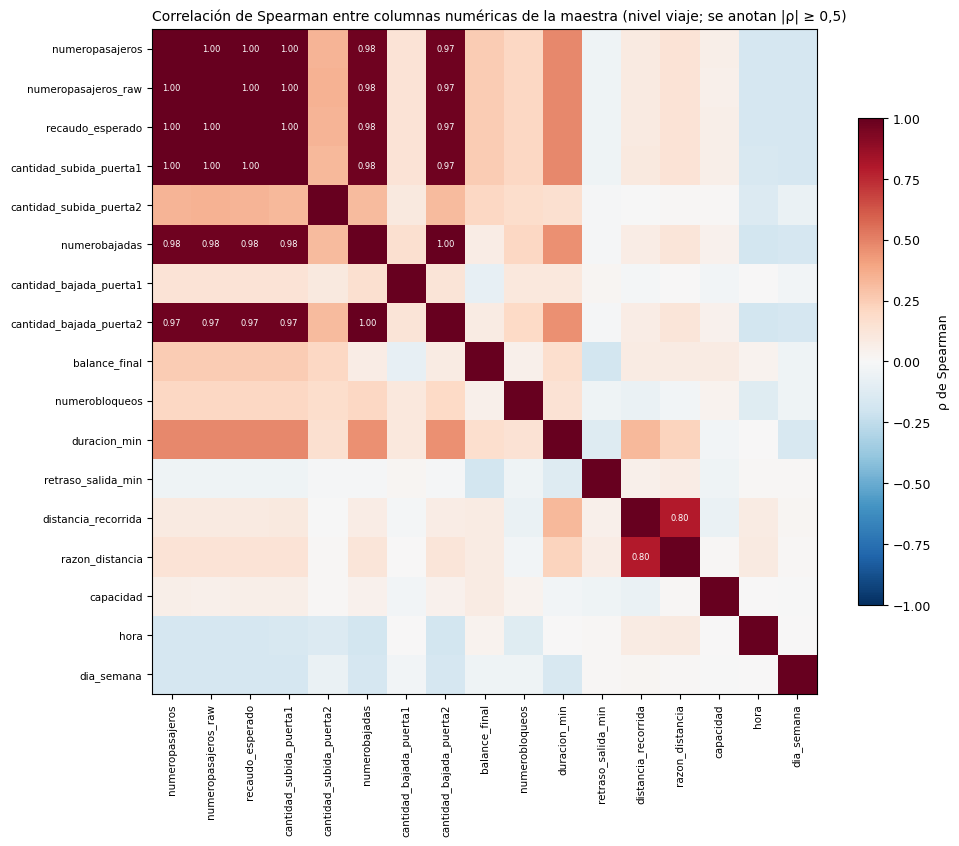

In [27]:
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr_v_s.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_VIAJE))); ax.set_xticklabels(NUM_VIAJE, rotation=90, fontsize=7.5)
ax.set_yticks(range(len(NUM_VIAJE))); ax.set_yticklabels(NUM_VIAJE, fontsize=7.5)
for i in range(len(NUM_VIAJE)):
    for j in range(len(NUM_VIAJE)):
        v = corr_v_s.values[i, j]
        if abs(v) >= 0.5 and i != j:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 0.75 else et.INK)
fig.colorbar(im, ax=ax, shrink=0.7, label="ρ de Spearman")
ax.set_title("Correlación de Spearman entre columnas numéricas de la maestra (nivel viaje; se anotan |ρ| ≥ 0,5)", fontsize=10, loc="left")
plt.tight_layout(); guardar(fig, "m5_correlacion_viaje_spearman")

## 5.3 VIF a nivel viaje (variables operativas)
Conjunto de diagnóstico: variables operativas no derivadas del objetivo, más `hora` y dos indicadoras de ruta (base = ruta 2). `numerobloqueos` entra como `log1p` porque su cola extrema dominaría la regresión auxiliar. Ojo: casi todas son **post-viaje** (5.1). Se miden para saber si son redundantes entre sí, no para recomendarlas como predictores ex ante.

In [28]:
Xop = maestra[["duracion_min", "retraso_salida_min", "distancia_recorrida", "razon_distancia", "capacidad", "hora"]].astype(float).copy()
Xop["log1p_bloqueos"] = np.log1p(maestra.numerobloqueos.astype(float))
Xop["ruta_16"] = (maestra.idruta == 16).astype(float); Xop["ruta_21"] = (maestra.idruta == 21).astype(float)
Xop = Xop.dropna()
print(f"Filas completas: {len(Xop):,} de {len(maestra):,}")
display(et.diagnostico_columnas(Xop).round(3))
print("Matriz de diseño:", et.dependencias_exactas(Xop))
vif_viaje = et.vif_tabla(Xop, cfg)
display(vif_viaje.round(3))

Filas completas: 496,580 de 497,371


,nulos,pct_nulos,varianza,distintos,pct_moda,constante,casi_constante
duracion_min,0,0.0,27749.980,25567,0.075,False,False
retraso_salida_min,0,0.0,47.497,2656,0.218,False,False
distancia_recorrida,0,0.0,44.897,651,3.628,False,False
razon_distancia,0,0.0,0.012,1644,3.509,False,False
capacidad,0,0.0,50.673,27,27.630,False,False
hora,0,0.0,21.684,17,11.206,False,False
log1p_bloqueos,0,0.0,2.041,1880,69.650,False,False
ruta_16,0,0.0,0.248,2,54.522,False,False
ruta_21,0,0.0,0.145,2,82.391,False,False


Matriz de diseño: {'columnas_con_constante': 10, 'rango': 10, 'numero_condicion': 52.06770468096002}


,variable,VIF,R2_auxiliar,lectura
0,distancia_recorrida,508.153,0.998,alta (≥ 10)
1,razon_distancia,471.513,0.998,alta (≥ 10)
2,ruta_16,133.052,0.992,alta (≥ 10)
3,ruta_21,67.113,0.985,alta (≥ 10)
4,retraso_salida_min,1.293,0.227,baja (< 5)
5,hora,1.059,0.056,baja (< 5)
6,duracion_min,1.030,0.030,baja (< 5)
7,log1p_bloqueos,1.024,0.024,baja (< 5)
8,capacidad,1.008,0.007,baja (< 5)


**Conclusión 5.3 · A nivel viaje la redundancia es de construcción, no de comportamiento**
- **Relaciones exactas confirmadas:**
  - `recaudo_esperado` = 3.700 × `numeropasajeros` (diferencia máxima 0).
  - `balance_final` = subidas − bajadas por puerta (diferencia 0).
  - `numeropasajeros` = `numeropasajeros_raw` en el 99,95 % de los viajes, y `raw` = subidas P1 + P2 en el 99,35 %.

  Son **copias del objetivo**: ninguna puede ser predictora.
- **Spearman frente a Pearson:** `numeropasajeros` vs `raw` da ρ = 0,999 pero r = 0,24. Los 123 picos imposibles de la 1.3 bastan para destruir la correlación lineal. Por eso se usa Spearman.
- **`numerobajadas` ~ objetivo (ρ = 0,975)**: es la otra cara del mismo viaje y solo se conoce al cerrarlo, así que hay leakage.
- **VIF:** `distancia_recorrida` y `razon_distancia` superan 470 (R² auxiliar = 0,998). `razon_distancia` es la distancia dividida por la distancia oficial de la ruta, por lo que junto a las indicadoras de ruta es casi una recombinación lineal. Esto infla también las indicadoras (VIF de 67 y 133). **Basta con una de las dos.** Las demás (duración, retraso, capacidad, hora, bloqueos) tienen VIF ≤ 1,3.

## 5.4 VIF en el panel ruta × 15 min (nivel del modelo)
Variables candidatas que **sí se conocen antes de cada intervalo**: oferta programada (`despachos` de `tb_despachos`, `capacidad_ofrecida`), calendario codificado (hora en seno/coseno, día de la semana en 6 indicadoras con base lunes, festivo, Carnaval, mes en seno/coseno, tendencia) y ruta. Se incluye `es_fin_semana` a propósito para mostrar cómo se detecta una dependencia lineal exacta.

Los rezagos `y(t-1)`, `y(t-4)`, `y(t-96)`, `y(t-672)` se calculan **aquí solo como diagnóstico**, sin exportarlos: su construcción definitiva y sin leakage es de la Persona 3.

In [29]:
pan = serie[["idruta", "t", "fecha", "intervalo_dia", "pasajeros", "viajes"]].merge(
    cal[["fecha", "dia_semana", "es_festivo", "es_carnaval", "es_fin_semana"]], on="fecha", how="left")
desp15 = despachos.assign(t=despachos.fechasalida.dt.floor(cfg.freq)).groupby(["idruta", "t"]).size().rename("despachos")
cap15 = maestra.assign(t=maestra.fechasalida.dt.floor(cfg.freq)).groupby(["idruta", "t"]).capacidad.sum().rename("capacidad_ofrecida")
pan = pan.join(desp15, on=["idruta", "t"]).join(cap15, on=["idruta", "t"])
pan[["despachos", "capacidad_ofrecida"]] = pan[["despachos", "capacidad_ofrecida"]].fillna(0)
ang = 2 * np.pi * pan.intervalo_dia / 96
pan["hora_sin"], pan["hora_cos"] = np.sin(ang), np.cos(ang)
angm = 2 * np.pi * (pan.t.dt.month - 1) / 12
pan["mes_sin"], pan["mes_cos"] = np.sin(angm), np.cos(angm)
pan["tendencia_dias"] = (pan.fecha - pan.fecha.min()).dt.days.astype(float)
for d, nom in zip(range(1, 7), ["mar", "mie", "jue", "vie", "sab", "dom"]):
    pan[f"dow_{nom}"] = (pan.dia_semana == d).astype(float)
pan["ruta_16"], pan["ruta_21"] = (pan.idruta == 16).astype(float), (pan.idruta == 21).astype(float)
for c in ["es_festivo", "es_carnaval", "es_fin_semana"]:
    pan[c] = pan[c].astype(float)
pan = pan.sort_values(["idruta", "t"])
for L in LAGS:
    pan[f"y_lag{L}"] = pan.groupby("idruta").pasajeros.shift(L)   # SOLO diagnóstico (no se exporta)

BASE = ["despachos", "capacidad_ofrecida", "hora_sin", "hora_cos", "dow_mar", "dow_mie", "dow_jue", "dow_vie", "dow_sab", "dow_dom",
        "es_festivo", "es_carnaval", "mes_sin", "mes_cos", "tendencia_dias", "ruta_16", "ruta_21"]
display(et.diagnostico_columnas(pan[BASE + ["es_fin_semana"]]).round(4))
dep_con = et.dependencias_exactas(pan[BASE + ["es_fin_semana"]])
dep_sin = et.dependencias_exactas(pan[BASE])
print("Con es_fin_semana:", dep_con)
print("Sin es_fin_semana:", dep_sin)
assert dep_con["rango"] < dep_con["columnas_con_constante"] and dep_sin["rango"] == dep_sin["columnas_con_constante"]
print("→ es_fin_semana = dow_sab + dow_dom exactamente: se excluye (la información queda en las indicadoras).")

,nulos,pct_nulos,varianza,distintos,pct_moda,constante,casi_constante
despachos,0,0.0,3.6175,16,34.9468,False,False
capacidad_ofrecida,0,0.0,8675.1645,579,37.6603,False,False
hora_sin,0,0.0,0.5000,86,2.0833,False,False
hora_cos,0,0.0,0.5000,89,2.0833,False,False
dow_mar,0,0.0,0.1227,2,85.6752,False,False
dow_mie,0,0.0,0.1227,2,85.6752,False,False
dow_jue,0,0.0,0.1221,2,85.7664,False,False
dow_vie,0,0.0,0.1221,2,85.7664,False,False
dow_sab,0,0.0,0.1221,2,85.7664,False,False
dow_dom,0,0.0,0.1227,2,85.6752,False,False


Con es_fin_semana: {'columnas_con_constante': 19, 'rango': 18, 'numero_condicion': 152321813404598.28}
Sin es_fin_semana: {'columnas_con_constante': 18, 'rango': 18, 'numero_condicion': 8.356579201590467}
→ es_fin_semana = dow_sab + dow_dom exactamente: se excluye (la información queda en las indicadoras).


In [30]:
vif_panel = et.vif_tabla(pan[BASE], cfg).assign(conjunto="A · calendario + oferta (todas las horas)")
servicio = pan.t.dt.hour.between(4, 20)
vif_serv = et.vif_tabla(pan.loc[servicio, BASE], cfg).assign(conjunto="A' · calendario + oferta (solo 4–20 h)")
pan_l = pan.dropna(subset=[f"y_lag{L}" for L in LAGS])
vif_lags = et.vif_tabla(pan_l[BASE + [f"y_lag{L}" for L in LAGS]], cfg).assign(conjunto="B · A + rezagos (diagnóstico)")
vif_todo = pd.concat([vif_panel, vif_serv, vif_lags], ignore_index=True)
display(vif_todo.pivot_table(index="variable", columns="conjunto", values="VIF").sort_values("B · A + rezagos (diagnóstico)", ascending=False).round(2))
COLS_CORR_P = ["pasajeros", "viajes", "despachos", "capacidad_ofrecida", "hora_sin", "hora_cos", "es_festivo", "tendencia_dias"] + [f"y_lag{L}" for L in LAGS]
corr_p_s = pan_l[COLS_CORR_P].corr("spearman")
display(et.pares_fuertes(corr_p_s, cfg.corr_umbral).round(3))

conjunto,A · calendario + oferta (todas las horas),A' · calendario + oferta (solo 4–20 h),B · A + rezagos (diagnóstico)
variable,,,
despachos,13.38,9.01,14.93
capacidad_ofrecida,13.29,9.17,13.77
y_lag1,NaN,NaN,4.66
y_lag672,NaN,NaN,4.08
y_lag96,NaN,NaN,3.56
y_lag4,NaN,NaN,2.99
dow_dom,1.86,1.89,2.14
dow_sab,1.84,1.84,2.01
dow_mie,1.83,1.83,1.95


,var_a,var_b,rho
0,viajes,capacidad_ofrecida,0.992
1,viajes,despachos,0.964
2,pasajeros,viajes,0.958
3,despachos,capacidad_ofrecida,0.957
4,pasajeros,capacidad_ofrecida,0.951
5,pasajeros,despachos,0.921
6,despachos,y_lag672,0.850
7,pasajeros,y_lag672,0.847
8,pasajeros,y_lag1,0.836
9,despachos,y_lag96,0.835


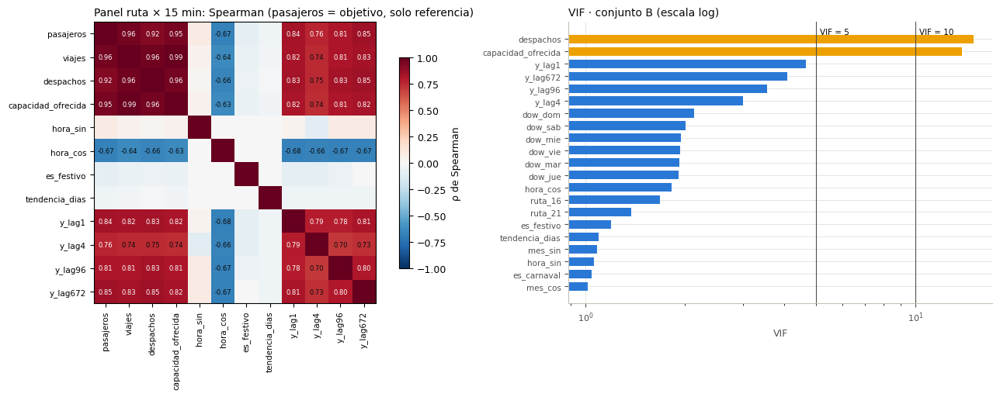

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
im = ax[0].imshow(corr_p_s.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(COLS_CORR_P))); ax[0].set_xticklabels(COLS_CORR_P, rotation=90, fontsize=7.5)
ax[0].set_yticks(range(len(COLS_CORR_P))); ax[0].set_yticklabels(COLS_CORR_P, fontsize=7.5)
for i in range(len(COLS_CORR_P)):
    for j in range(len(COLS_CORR_P)):
        if i != j and abs(corr_p_s.values[i, j]) >= 0.5:
            ax[0].text(j, i, f"{corr_p_s.values[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(corr_p_s.values[i, j]) > 0.75 else et.INK)
fig.colorbar(im, ax=ax[0], shrink=0.75, label="ρ de Spearman")
ax[0].set_title("Panel ruta × 15 min: Spearman (pasajeros = objetivo, solo referencia)", fontsize=10, loc="left")
vb = vif_lags.sort_values("VIF")
ax[1].barh(vb.variable, vb.VIF, color=[et.COLOR_DIA["festivo"] if v >= 10 else (et.COLOR_RUTA[16] if v >= 5 else et.COLOR_RUTA[2]) for v in vb.VIF], height=0.7)
for x, lbl in [(5, "5"), (10, "10")]:
    ax[1].axvline(x, color=et.INK2, lw=0.8); ax[1].annotate(f"VIF = {lbl}", (x, len(vb) - 0.6), xytext=(3, 0), textcoords="offset points", fontsize=7.5)
ax[1].set_xscale("log"); et.estilo_ejes(ax[1], "VIF · conjunto B (escala log)", "VIF", None); ax[1].tick_params(axis="y", labelsize=7.5)
plt.tight_layout(); guardar(fig, "m5_panel_correlacion_y_vif")

**Conclusión 5.4 · En el panel, la oferta es la única redundancia relevante**
- **Dependencia exacta detectada y resuelta:** `es_fin_semana` = `dow_sab` + `dow_dom`. Con ella el rango es 18 de 19 columnas (número de condición ≈ 1,5 × 10¹⁴). Sin ella, el rango es completo y el número de condición es 8,4.
- **`despachos` y `capacidad_ofrecida`: VIF ≈ 13** (≈ 9 si solo se toman las horas de servicio). Spearman entre ellas: 0,96. `viajes` y `capacidad_ofrecida`: 0,99. **Miden lo mismo** (cuántos buses salen). Conviene elegir una o combinarlas, por ejemplo como capacidad media por despacho.
- **Calendario sin problemas:** día de la semana, festivo, Carnaval, mes y tendencia tienen VIF ≤ 2,1. La codificación seno/coseno de la hora tiene VIF ≤ 1,8.
- **Rezagos (solo diagnóstico):** VIF de 3,0–4,7 junto al resto. Están correlacionados entre sí (ρ ≈ 0,80–0,81 de t-672 con t-1 y con t-96), pero **no son redundantes**. La PACF (3.5) muestra que t-1 y t-96 aportan información propia y t-4 poca.
- **Aviso de leakage:** `pasajeros` vs `viajes` válidos da ρ = 0,96, y vs `capacidad_ofrecida` 0,95. Pero `viajes` y `capacidad_ofrecida` se construyen con los viajes **válidos**, una condición que solo se conoce después del viaje. La versión ex ante es `despachos` programados.

## 5.5 Recomendaciones para la Persona 3
| Tema | Recomendación | Estado |
|---|---|---|
| **Copias del objetivo** | Excluir `numeropasajeros_raw`, `recaudo_esperado`, `cantidad_subida_puerta1/2` y `tipo_cero` | Cerrado: leakage directo |
| **Variables post-viaje** | `numerobajadas`, bajadas por puerta, `balance_final`, `numerobloqueos`, `duracion_min`, `distancia_recorrida`, `razon_distancia`, `fechainicio`/`fechafin` y banderas de sensor **no se conocen al despachar**. Solo sirven como rezagos de viajes ya cerrados | Cerrado si el pronóstico es ex ante |
| **Oferta** | Usar `despachos` programados (ex ante), no `viajes` válidos. Elegir entre `despachos` y `capacidad_ofrecida` (VIF ≈ 13), o combinarlas | Abierto: decidir con validación temporal |
| **Distancia** | Si se usa a nivel viaje, quedarse con `distancia_recorrida` **o** `razon_distancia`, no ambas | Abierto |
| **Calendario** | Usar `calendario_dias.csv`: festivo y Carnaval como indicadoras separadas, sin `es_fin_semana` junto a las indicadoras de día. Revisar la imputación de la 1.4, que no distingue festivos | Listo para usar |
| **Rezagos temporales** | Priorizar t-1 y t-96, más t-672. t-4 aporta poco una vez está t-1. Construirlos **dentro** de cada pliegue walk-forward | Abierto (Persona 3) |
| **Rezagos espaciales** | Hay estructura espacial (I = 0,18 con k = 6), pero solo en la muestra de lecturas. El objetivo por ruta × 15 min no tiene dimensión espacial. Un rezago espacial solo aplica si se modela a nivel de celda o tramo, con `W_knn_k6_binaria.npz` y `parametros_malla_espacial.json` | Abierto |
| **Escala del VIF** | Los umbrales 5 y 10 son referencias, no reglas. No eliminar por VIF sin comparar el error de pronóstico en validación temporal | Abierto |
| **Días a vigilar** | 2024-09-06 (anómalo) y junio de 2024 (apagón imputado en la 1.4): marcarlos en la evaluación | Aviso |

# Síntesis de hallazgos
| Módulo | Hallazgo | Evidencia |
|---|---|---|
| 3 | La serie por viaje es irregular; la de 15 min es completa y conserva todo | 3 × 105.216 intervalos, sumas idénticas a la maestra |
| 3 | Sin raíz unitaria; estacionaria alrededor de una tendencia suave + ciclos | ADF entre −14 y −18 (15 min) y entre −3,0 y −5,4 (diaria); KPSS rechaza con `c` y no con `ct` |
| 3 | Memoria a 15 min y a 24 h; t-4 casi redundante | ACF t-1 de 0,58–0,87 y t-96 de 0,59–0,76; PACF t-4 de 0,01–0,10 |
| 3 | El pico de las 5 h es un efecto de atribución a la salida | Hora real de subida: picos a las 6–7 h y 16–17 h |
| 3 | Un festivo entre semana mueve ≈ 0,4 de un laboral y desplaza el pico a la tarde | Wilcoxon emparejado (48 pares por ruta), W = 0 |
| 4 | Las subidas se agrupan en el espacio a escala de 2–3 km | Moran I = 0,18 (k = 6), p = 0,001; positivo para todo k y celda |
| 4 | Grafo conexo, local y alargado (corredores) | 1 componente, diámetro 53, clustering 0,60 |
| 5 | Redundancias por construcción y leakage, no colinealidad sutil | Relaciones exactas; VIF de oferta ≈ 13; calendario ≤ 2,1 |

# Exportación para la Persona 3
Todo va a `datos_3_5/`. Estructura, claves, unidades y uso de cada archivo: `datos_3_5/LEEME_artefactos.md`.

In [32]:
cal.to_csv(SALIDA / "calendario_dias.csv", index=False)
serie.drop(columns="pasajeros_desest").to_parquet(SALIDA / "serie_15min_ruta.parquet", index=False)
aud_t.to_csv(SALIDA / "auditoria_temporal.csv", index=False)
adf.to_csv(SALIDA / "adf_kpss.csv", index=False)
acf_tab.to_csv(SALIDA / "acf_pacf_rezagos.csv", index=False)
pd.DataFrame([{"idruta": r, "serie": s, "h": h, "acf": a[h], "banda_bartlett_95": b[h], "pacf": p[h] if h < len(p) else np.nan,
               "banda_ruido_blanco_95": bl} for (r, s), (a, p, b, bl) in curvas.items() for h in range(len(a))]
             ).to_csv(SALIDA / "acf_pacf_curvas.csv", index=False)
perfil.to_csv(SALIDA / "perfil_horario.csv", index=False)
picos.to_csv(SALIDA / "picos_valles.csv", index=False)
pd.concat([kw.assign(prueba="kruskal_wallis"), pares.assign(prueba="mann_whitney_holm")], ignore_index=True).to_csv(SALIDA / "contrastes_tipo_dia.csv", index=False)
emp.to_csv(SALIDA / "festivo_emparejado_detalle.csv", index=False)
wil.to_csv(SALIDA / "festivo_emparejado_wilcoxon.csv", index=False)
forma.to_csv(SALIDA / "forma_horaria_laboral_vs_festivo.csv", index=False)

celdas.to_csv(SALIDA / "celdas_espaciales.csv", index=False)
pd.Series({"celda_m": cfg.celda_m, "lat_ref": LAT_REF, "radio_tierra_m": et.RADIO_TIERRA_M, "min_viajes_celda": cfg.min_viajes_celda,
           "k": K, "regla_celda": "cx = floor(rad(lon)·R·cos(rad(lat_ref)) / celda_m); cy = floor(rad(lat)·R / celda_m)"}
          ).to_json(SALIDA / "parametros_malla_espacial.json", force_ascii=False, indent=2)
sparse.save_npz(SALIDA / f"W_knn_k{K}_binaria.npz", A)
ids = celdas.celda_id.to_numpy()
pd.DataFrame({"origen": ids[np.repeat(np.arange(n), K)], "destino": ids[IDX.ravel()], "orden_vecino": np.tile(np.arange(1, K + 1), n),
              "distancia_m": DIST.ravel(), "peso_binario": 1.0, "peso_fila": 1.0 / K,
              "mutua": np.asarray(A.multiply(A.T)[np.repeat(np.arange(n), K), IDX.ravel()]).ravel().astype(bool)}
             ).to_csv(SALIDA / f"vecinos_knn_k{K}.csv", index=False)
eval_k.to_csv(SALIDA / "moran_evaluacion_k.csv", index=False)
correlo.to_csv(SALIDA / "moran_correlograma.csv", index=False)
sens.to_csv(SALIDA / "moran_sensibilidad.csv", index=False)
nx.write_graphml(G, SALIDA / f"grafo_espacial_k{K}.graphml")
met_G.to_csv(SALIDA / "metricas_grafo.csv")

roles.to_csv(SALIDA / "roles_variables_maestra.csv", index=False)
corr_v_s.to_csv(SALIDA / "correlacion_viaje_spearman.csv"); corr_v_p.to_csv(SALIDA / "correlacion_viaje_pearson.csv")
fuertes_v.to_csv(SALIDA / "pares_fuertes_viaje.csv", index=False)
vif_viaje.to_csv(SALIDA / "vif_viaje.csv", index=False)
vif_todo.to_csv(SALIDA / "vif_panel.csv", index=False)
corr_p_s.to_csv(SALIDA / "correlacion_panel_spearman.csv")
for p in sorted(SALIDA.glob("*.*")):
    print(f"{p.name:45s} {p.stat().st_size / 1e3:10.1f} kB")

acf_pacf_curvas.csv                                366.4 kB
acf_pacf_rezagos.csv                                 2.9 kB
adf_kpss.csv                                         3.9 kB
auditoria_temporal.csv                               0.6 kB
calendario_dias.csv                                 66.3 kB
celdas_espaciales.csv                               50.8 kB
contrastes_tipo_dia.csv                              2.9 kB
correlacion_panel_spearman.csv                       2.8 kB
correlacion_viaje_pearson.csv                        6.4 kB
correlacion_viaje_spearman.csv                       6.1 kB
festivo_emparejado_detalle.csv                      10.0 kB
festivo_emparejado_wilcoxon.csv                      0.4 kB
forma_horaria_laboral_vs_festivo.csv                 5.0 kB
grafo_espacial_k6.graphml                          251.3 kB
LEEME_artefactos.md                                  7.0 kB
metricas_grafo.csv                                   0.5 kB
moran_correlograma.csv                  

# Comprobaciones finales de reproducibilidad

In [33]:
chk = []
def ok(nombre, cond, detalle=""):
    chk.append({"check": nombre, "resultado": "PASS" if bool(cond) else "FAIL", "detalle": detalle})

s2 = pd.read_parquet(SALIDA / "serie_15min_ruta.parquet")
ok("Serie: 3 rutas × intervalos esperados", (s2.groupby("idruta").size() == n_int).all() and s2.idruta.nunique() == 3, f"{n_int:,} por ruta")
ok("Serie: conserva pasajeros y viajes de la maestra", s2.pasajeros.sum() == maestra.numeropasajeros.sum() and s2.viajes.sum() == len(maestra))
ok("Serie: sin nulos ni negativos", s2[["pasajeros", "viajes"]].notna().all().all() and (s2[["pasajeros", "viajes"]] >= 0).all().all())
c2 = pd.read_csv(SALIDA / "calendario_dias.csv", parse_dates=["fecha"])
ok("Calendario: 1 fila por día de la ventana", len(c2) == 1096 and c2.fecha.is_unique, f"{len(c2)} días")
ok("Calendario: 4 días de Carnaval por año", c2.groupby(c2.fecha.dt.year).es_carnaval.sum().eq(4).all())
ok("Calendario: festivos ≠ fines de semana como categoría", not ((c2.tipo_dia_cal == "festivo") & ~c2.es_festivo).any())
a2 = pd.read_csv(SALIDA / "adf_kpss.csv")
ok("ADF: 15 pruebas sin nulos", len(a2) == 15 and a2[["estadistico", "p_valor", "nobs_usadas"]].notna().all().all())
r2 = pd.read_csv(SALIDA / "acf_pacf_rezagos.csv")
ok("ACF/PACF: t-1, t-4, t-96 en las 3 rutas", set(r2.rezago) >= {"t-1", "t-4", "t-96"} and r2.groupby("serie").idruta.nunique().eq(3).all())
A2 = sparse.load_npz(SALIDA / f"W_knn_k{K}_binaria.npz")
ok("W: cuadrada n × n con n = celdas", A2.shape == (len(celdas), len(celdas)), str(A2.shape))
ok("W: diagonal nula", A2.diagonal().sum() == 0)
ok("W: exactamente k vecinos por fila", (np.asarray(A2.sum(1)).ravel() == K).all(), f"k = {K}")
ok("W: estandarizada por filas suma 1", np.allclose(np.asarray(et.estandarizar_filas(A2).sum(1)).ravel(), 1))
G2 = nx.read_graphml(SALIDA / f"grafo_espacial_k{K}.graphml")
ok("Grafo: nodos = celdas y aristas = unión", G2.number_of_nodes() == len(celdas) and G2.number_of_edges() == U.nnz // 2,
   f"{G2.number_of_nodes()} nodos, {G2.number_of_edges()} aristas")
ok("Grafo: componentes = conectividad de la matriz", nx.number_connected_components(G2) == et.conectividad(U)["componentes"])
mk = pd.read_csv(SALIDA / "moran_evaluacion_k.csv")
ok("Moran: I recalculado con la W exportada coincide", np.isclose(et.moran_global(celdas.subidas_por_viaje.values, et.estandarizar_filas(A2), 9, 1)["I"],
                                                                   mk.loc[mk.k == K, "I"].iloc[0]))
ok("Moran: permutaciones y semilla documentadas", mk.permutaciones.eq(cfg.permutaciones).all() and mk.semilla.eq(cfg.semilla).all())
v2 = pd.read_csv(SALIDA / "vif_panel.csv")
ok("VIF: finitos en todos los conjuntos", np.isfinite(v2.VIF).all(), f"máx = {v2.VIF.max():.1f}")
ok("VIF: no se exportan rezagos como variables", not any(c.startswith("y_lag") for c in s2.columns))
HUELLAS_FIN = {str(p): huella(p) for p in INSUMOS}
ok("Insumos de la Persona 1 sin modificar", HUELLAS_INICIO == HUELLAS_FIN, f"{len(HUELLAS_FIN)} archivos con el mismo MD5")
ok("LEEME de artefactos presente", (SALIDA / "LEEME_artefactos.md").exists())
val35 = pd.DataFrame(chk)
val35.to_csv(SALIDA / "validacion_modulo3_5.csv", index=False)
display(val35)
print("MÓDULOS 3–5 VALIDADOS" if (val35.resultado == "PASS").all() else f"Hay {(val35.resultado == 'FAIL').sum()} checks en FAIL")

,check,resultado,detalle
0,Serie: 3 rutas × intervalos esperados,PASS,"105,216 por ruta"
1,Serie: conserva pasajeros y viajes de la maestra,PASS,
2,Serie: sin nulos ni negativos,PASS,
3,Calendario: 1 fila por día de la ventana,PASS,1096 días
4,Calendario: 4 días de Carnaval por año,PASS,
5,Calendario: festivos ≠ fines de semana como ca...,PASS,
6,ADF: 15 pruebas sin nulos,PASS,
7,"ACF/PACF: t-1, t-4, t-96 en las 3 rutas",PASS,
8,W: cuadrada n × n con n = celdas,PASS,"(364, 364)"
9,W: diagonal nula,PASS,


MÓDULOS 3–5 VALIDADOS


<a id="m6"></a>

---

## A1.4 &middot; Módulo 6 · Ingeniería de features y auditoría de fuga

Decisiones congeladas antes de construir features, rezagos temporales y plan de oferta, lag espacial entre rutas y una auditoría independiente de data leakage.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m6-1"></a>

### A1.4.1 &middot; Subfase 6.0 · Decisiones previas al Módulo 6

<sub>Notebook original: `subfase_6_0_decisiones.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 6.0 — Decisiones previas al Módulo 6

**Persona 3 · MLOps & Model Evaluation.** Antes de construir features hay que fijar qué se predice, cuándo se emite el pronóstico, qué rezagos son admisibles y qué se corrige de los Módulos 1–5. Esta subfase **no construye features ni entrena modelos**: produce decisiones con cifras, una matriz espacial entre rutas y una tabla de checks.

| Paso | Pregunta |
|---|---|
| 0 | ¿Qué datos quedan congelados como holdout? |
| 1 | ¿Qué entorno hay? |
| 2 | ¿Cuándo se emite el pronóstico y qué rezago mínimo es admisible? |
| 3 | ¿El target es por viaje o ruta × 15 min? |
| 4 | ¿Qué rezagos se permiten? (corrección de la Conclusión 3.5) |
| 5 | ¿Qué W espacial se puede construir con lo que ya hay? |
| 6 | Reglas de datos para la 6.1 y el Módulo 7 |
| 7 | Checks de cierre |

**Parte 1 (extracción RDS):** una sola consulta liviana, `extraer_fecharegistro_6_0.py` (solo `progvehiculos`: `idprogramacion`, `idruta`, `fechasalida`, `fecharegistro`). Pide la contraseña con `getpass` y escribe `datos_6/fecharegistro.csv`; si el archivo ya existe, no consulta. De `conteo_pasajeros_destino` solo se usa lo ya derivado de la muestra (`celdas_espaciales.csv`).

**Insumos:** `datos_6/fecharegistro.csv` (Parte 1), `maestras/tb_maestra_entrenamiento.parquet`, `maestras/tb_despachos.parquet`, `datos_1_2/viajes_raw.csv`, `metricas_tweedie.py` y, de la Persona 2, `serie_15min_ruta.parquet`, `calendario_dias.csv`, `celdas_espaciales.csv`. **Salidas:** `datos_6/`.

## Parte 2 · Análisis offline

In [1]:
import importlib
import math
import platform
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=FutureWarning)

P2 = Path("entrega_persona2_modulos_3_5/entrega_persona2_modulos_3_5/datos_3_5")
SALIDA = Path("datos_6"); SALIDA.mkdir(exist_ok=True)
TRAIN_FIN = pd.Timestamp("2025-01-01")   # 2025 = holdout final (coherente con la 2.4)
SEMILLA = 42
INTERVALO = 15                           # minutos por intervalo de la serie
RUTAS = [2, 16, 21]
CHECKS: List[Dict] = []
USO_TRAIN: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


def leer(ruta, fechas: List[str] = ()) -> pd.DataFrame:
    """Parquet con respaldo a CSV (mismo nombre) si pyarrow no está disponible."""
    ruta = Path(ruta)
    if ruta.suffix == ".parquet":
        try:
            return pd.read_parquet(ruta)
        except Exception as e:
            alt = ruta.with_suffix(".csv")
            print(f"Parquet no disponible ({e.__class__.__name__}); leyendo {alt}")
            df = pd.read_csv(alt)
    else:
        df = pd.read_csv(ruta)
    for c in fechas:
        df[c] = pd.to_datetime(df[c], format="mixed")
    return df


def solo_train(df: pd.DataFrame, col: str, nombre: str) -> pd.DataFrame:
    """Filtra a 2023–2024 y registra el uso: toda ESTIMACIÓN de esta subfase pasa por aquí."""
    d = df[df[col] < TRAIN_FIN]
    USO_TRAIN.append({"estimacion": nombre, "columna_fecha": col, "fecha_min": d[col].min(),
                      "fecha_max": d[col].max(), "filas": len(d)})
    return d


def ols(x, y):
    """y = a + b·x por mínimos cuadrados. Devuelve a, b, EE(b) y R² (igual que en la 2.2)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    X = np.column_stack([np.ones_like(x), x])
    a, b = np.linalg.solve(X.T @ X, X.T @ y)
    r = y - (a + b * x)
    se_b = np.sqrt((r ** 2).sum() / (len(x) - 2) * np.linalg.inv(X.T @ X)[1, 1])
    return a, b, se_b, 1 - (r ** 2).sum() / ((y - y.mean()) ** 2).sum()


def r2_lstsq(X: np.ndarray, y: np.ndarray) -> float:
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ b
    return float(1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum())

## 0 · Partición congelada

**2023–2024 = entrenamiento y validación walk-forward; 2025 = holdout final**, el mismo año de prueba de la 2.4. Todo lo que se *estima* en esta subfase (percentiles, umbrales, p̂, ACF) pasa por `solo_train()`, que filtra y deja registro; el paso 7 verifica que ninguna estimación tocó 2025. La única tabla que incluye 2025 es la descriptiva del hecho 3 (3.4), que mide exclusiones de datos y no alimenta ningún parámetro.

In [2]:
m = leer("maestras/tb_maestra_entrenamiento.parquet")
desp = leer("maestras/tb_despachos.parquet")
serie = leer(P2 / "serie_15min_ruta.parquet")
cal = pd.read_csv(P2 / "calendario_dias.csv", parse_dates=["fecha"])

filas = []
for nombre, df, col, filtro in [("maestra (incluir_en_modelo)", m, "fechasalida", m.incluir_en_modelo),
                                ("tb_despachos", desp, "fechasalida", None),
                                ("serie 15 min (ruta × t)", serie, "t", None)]:
    d = df if filtro is None else df[filtro]
    filas.append({"tabla": nombre, "desde": d[col].min(), "hasta": d[col].max(),
                  "filas_2023_2024": int((d[col] < TRAIN_FIN).sum()), "filas_2025_holdout": int((d[col] >= TRAIN_FIN).sum())})
particion = pd.DataFrame(filas)
display(particion)

,tabla,desde,hasta,filas_2023_2024,filas_2025_holdout
0,maestra (incluir_en_modelo),2023-01-01 05:00:00,2025-12-31 18:30:00,337795,158507
1,tb_despachos,2023-01-01 05:00:00,2025-12-31 19:00:00,378562,182865
2,serie 15 min (ruta × t),2023-01-01 00:00:00,2025-12-31 23:45:00,210528,105120


**Conclusión 0 · Partición congelada: 2023–2024 para estimar y validar, 2025 intacto**
- **2023–2024:** 337.795 viajes con `incluir_en_modelo`, 378.562 salidas reales y 210.528 filas de la serie (3 rutas × 731 días × 96 intervalos).
- **2025 (holdout):** 158.507 viajes, 182.865 salidas y 105.120 filas. Ninguna estimación de esta subfase los usa (check del paso 7).
- 337.795 + 158.507 = 496.302: cuadra con `incluir_en_modelo` del Módulo 2.

## 1 · Entorno

In [3]:
ent = [{"paquete": "python", "version": platform.python_version(), "importa": True}]
for p in ["pandas", "numpy", "pyarrow", "matplotlib", "sklearn", "scipy", "statsmodels", "lightgbm", "xgboost"]:
    try:
        mod = importlib.import_module(p)
        ent.append({"paquete": p, "version": getattr(mod, "__version__", "?"), "importa": True})
    except Exception as e:
        ent.append({"paquete": p, "version": f"— ({e.__class__.__name__})", "importa": False})
entorno = pd.DataFrame(ent)
display(entorno)
faltan = entorno.loc[~entorno.importa, "paquete"].tolist()
check("Entorno registrado", True, f"Python {platform.python_version()}, pandas {pd.__version__}, numpy {np.__version__}; no importan: {faltan}", info=True)

,paquete,version,importa
0,python,3.9.25,True
1,pandas,2.3.3,True
2,numpy,1.26.4,True
3,pyarrow,21.0.0,True
4,matplotlib,3.8.4,True
5,sklearn,— (ModuleNotFoundError),False
6,scipy,— (ModuleNotFoundError),False
7,statsmodels,— (ModuleNotFoundError),False
8,lightgbm,— (ModuleNotFoundError),False
9,xgboost,— (ModuleNotFoundError),False


**Conclusión 1 · Entorno: el notebook corre con numpy y pandas; LightGBM es bloqueante para el Módulo 7**
- Ejecutado con Python 3.9.25, pandas 2.3.3, numpy 1.26.4 y pyarrow 21.0.0, las mismas versiones del PC de la Persona 1.
- No importan: sklearn, scipy, statsmodels, lightgbm ni xgboost. Esta subfase no los necesita.
- **Para el Módulo 7:** sin `lightgbm` no hay modelo. `TimeSeriesSplit` se implementará con numpy si sklearn sigue bloqueado. Optuna (7.2) también hay que instalarlo.
- Al volver a ejecutar en otro equipo, esta tabla reporta el entorno de ese equipo.

## 2 · Horizonte: hora de emisión y rezago mínimo admisible

`pasajeros` del intervalo *s* = subidas totales de los viajes que **salen** en *s*. Ese número solo existe cuando el viaje **cierra**. Un rezago *L* (en intervalos de 15 min) es admisible si sus viajes ya cerraron cuando se emite el pronóstico:

$$\underbrace{t - 15L + 15}_{\text{fin del intervalo } t-L} + D_{\max} \;\le\; \underbrace{t - \text{lead}}_{\text{emisión}} \quad\Longrightarrow\quad L \;\ge\; \left\lceil \frac{\text{lead} + 15 + D_{\max}}{15} \right\rceil$$

donde *lead* = minutos entre la emisión y el inicio del intervalo objetivo, y $D_{\max}$ = duración máxima de un viaje no atípico. La regla "lag ≥ h" del prompt original omitía el ancho del intervalo (15 min) y el *lead*; aquí se usa la regla completa.

### 2.a Duración del viaje (2023–2024, `incluir_en_modelo`)

In [4]:
tr = solo_train(m[m.incluir_en_modelo], "fechasalida", "2.a duración del viaje")
q = tr.groupby("idruta").duracion_min.quantile([.25, .75]).unstack()
q["limite_inf"] = q[0.25] - 1.5 * (q[0.75] - q[0.25])
q["limite_sup"] = q[0.75] + 1.5 * (q[0.75] - q[0.25])
lim = tr.idruta.map(q.limite_sup), tr.idruta.map(q.limite_inf)
tr = tr.assign(atipica_train=(tr.duracion_min > lim[0]) | (tr.duracion_min < lim[1]))
D_MAX = float(q.limite_sup.max())

pct = [.5, .9, .95, .99]
dur = pd.DataFrame({
    "todos": tr.duracion_min.quantile(pct),
    "sin flag_duracion_atipica (1.4)": tr.loc[~tr.flag_duracion_atipica, "duracion_min"].quantile(pct),
    "sin atípica IQR 2023–2024": tr.loc[~tr.atipica_train, "duracion_min"].quantile(pct),
}).T.round(1)
dur.columns = ["P50", "P90", "P95", "P99"]
dur["max"] = [tr.duracion_min.max(), tr.loc[~tr.flag_duracion_atipica, "duracion_min"].max(), tr.loc[~tr.atipica_train, "duracion_min"].max()]
dur["viajes"] = [len(tr), int((~tr.flag_duracion_atipica).sum()), int((~tr.atipica_train).sum())]
display(dur.round(1))
display(q.round(1))

largos = tr.duracion_min > D_MAX
print(f"D_max (límite IQR superior más alto, 2023–2024) = {D_MAX:.1f} min = {D_MAX / 60:.2f} h")
print(f"Viajes más largos que D_max: {largos.sum():,} ({largos.mean():.2%}) con {tr.loc[largos, 'numeropasajeros'].sum() / tr.numeropasajeros.sum():.2%} de los pasajeros")
print(f"Coincidencia flag 1.4 vs IQR 2023–2024: {(tr.flag_duracion_atipica == tr.atipica_train).mean():.2%}")
check("Umbral de duración estimado solo con 2023–2024", tr.fechasalida.max() < TRAIN_FIN, f"D_max = {D_MAX:.1f} min")

,P50,P90,P95,P99,max,viajes
todos,230.0,276.2,292.0,399.1,17484.4,337795
sin flag_duracion_atipica (1.4),230.4,274.4,287.4,314.4,356.0,326412
sin atípica IQR 2023–2024,230.4,274.3,287.2,313.8,353.3,326164


,0.25,0.75,limite_inf,limite_sup
idruta,,,,
2,207.9,266.1,120.6,353.4
16,188.3,245.0,103.3,330.0
21,203.2,262.9,113.5,352.5


D_max (límite IQR superior más alto, 2023–2024) = 353.4 min = 5.89 h
Viajes más largos que D_max: 4,188 (1.24%) con 1.18% de los pasajeros
Coincidencia flag 1.4 vs IQR 2023–2024: 99.92%


### 2.b Rezago mínimo por escenario de emisión

In [5]:
def lag_minimo(lead_min: float, d_max: float = D_MAX) -> int:
    """Menor rezago L (intervalos de 15 min) cuyo valor ya es conocido al emitir el pronóstico."""
    return int(math.ceil((lead_min + INTERVALO + d_max) / INTERVALO))


INI, FIN = 4 * 60, 20 * 60 + 45   # primer y último intervalo con servicio (inicio, en minutos del día)
esc = pd.DataFrame([
    {"escenario": "A · víspera 21:00 (día siguiente completo)", "lead_max_min": (24 * 60 - 21 * 60) + FIN},
    {"escenario": "B · mismo día 04:00 (antes del primer despacho)", "lead_max_min": FIN - 4 * 60},
    {"escenario": "C · intradía, emisión al inicio del intervalo", "lead_max_min": 0},
    {"escenario": "C' · intradía, 1 h antes", "lead_max_min": 60},
])
esc["L_min"] = esc.lead_max_min.apply(lag_minimo)
esc["L_min_horas"] = (esc.L_min * INTERVALO / 60).round(2)
esc["t-96 admisible"] = esc.L_min <= 96
esc["t-1 admisible"] = esc.L_min <= 1
display(esc)

# Escenario A: ¿hasta qué intervalo objetivo sí sirve t-96?
corte_96 = 24 * 60 - (24 * 60 - 21 * 60) - INTERVALO - D_MAX     # i ≤ 1440 − 180 − 15 − D_max
n_serv = (FIN - INI) // INTERVALO + 1
n_ok = sum(1 for i in range(INI, FIN + 1, INTERVALO) if i <= corte_96)
print(f"Escenario A: t-96 solo es admisible para intervalos objetivo que empiezan ≤ {int(corte_96 // 60):02d}:{int(corte_96 % 60):02d} "
      f"→ {n_ok} de {n_serv} intervalos con servicio ({n_ok / n_serv:.0%}).")
L_A, L_B, L_C = int(esc.L_min.iloc[0]), int(esc.L_min.iloc[1]), int(esc.L_min.iloc[3])   # C = intradía 1 h antes (ver 2.c)
check("t-1 no admisible en ningún escenario", not esc["t-1 admisible"].any(), f"L_min por escenario: {esc.L_min.tolist()}")

,escenario,lead_max_min,L_min,L_min_horas,t-96 admisible,t-1 admisible
0,A · víspera 21:00 (día siguiente completo),1425,120,30.00,False,False
1,B · mismo día 04:00 (antes del primer despacho),1005,92,23.00,True,False
2,"C · intradía, emisión al inicio del intervalo",0,25,6.25,True,False
3,"C' · intradía, 1 h antes",60,29,7.25,True,False


Escenario A: t-96 solo es admisible para intervalos objetivo que empiezan ≤ 14:51 → 44 de 68 intervalos con servicio (65%).


**Conclusión 2 · El horizonte se define por la hora de emisión; t−1 no es admisible en ningún escenario**
- **Duración del viaje (2023–2024):** P50 230,0 min, P95 292,0, P99 399,1 y máximo 17.484 (cierres tardíos). Sin atípicas (IQR por ruta, 2023–2024): P95 287,2, P99 313,8 y máximo 353,3. Coincide en el 99,92 % con `flag_duracion_atipica` de la 1.4.
- **D_max = 353,4 min (5,89 h)**, el límite IQR superior de la ruta 2. Hay 4.188 viajes más largos (1,24 %, con el 1,18 % de los pasajeros). En producción su total no se conocería a tiempo, así que **la 6.1 los excluye de la serie con la que se calculan los rezagos**.
- **Corrección a lo planteado antes** (prompt de la 6.1 y de esta subfase: «L_min = ⌈P95/15⌉» y «h = 96 admite t−96»). Esa regla omitía el ancho del intervalo (15 min) y el *lead*. La regla correcta es L ≥ ⌈(lead + 15 + D_max)/15⌉:

| Escenario de emisión | L_min | ¿t−96? |
|---|---|---|
| A · víspera 21:00 | 120 (30 h) | **No.** Solo para intervalos ≤ 14:51 (44 de 68) |
| B · mismo día 04:00 | 92 (23 h) | Sí |
| Intradía, al inicio del intervalo | 25 (6,25 h) | Sí |
| C · intradía, 1 h antes | 29 (7,25 h) | Sí |

- La elección del escenario se basa en cuándo decide SOBUSA cada despacho (2.c).

### 2.c ¿Cuándo decide SOBUSA cada despacho? (`fecharegistro`)

`progvehiculos.fecharegistro` es NOT NULL con valor por defecto `now()` (inventario de la 1.1): guarda el momento en que cada programación entra al sistema. La anticipación = `fechasalida − fecharegistro` dice si existe una tabla de despachos armada de antemano o si el despachador registra cada salida en el momento.

In [6]:
fr = pd.read_csv("datos_6/fecharegistro.csv", parse_dates=["fechasalida", "fecharegistro"])
fr["anticipacion_min"] = (fr.fechasalida - fr.fecharegistro).dt.total_seconds() / 60
fr_tr = solo_train(fr, "fechasalida", "2.c anticipación del registro")
a = fr_tr.anticipacion_min
ant = pd.DataFrame([{
    "viajes": len(fr_tr), "P05": a.quantile(.05), "P25": a.quantile(.25), "P50": a.median(), "P75": a.quantile(.75),
    "P95": a.quantile(.95), "P99": a.quantile(.99),
    "% registrado el día anterior": (fr_tr.fecharegistro.dt.date < fr_tr.fechasalida.dt.date).mean() * 100,
    "% registrado > 60 min antes": (a > 60).mean() * 100,
    "% registrado después de la salida": (a < 0).mean() * 100}]).round(2)
display(ant)
por_ruta = fr_tr.groupby("idruta").anticipacion_min.quantile([.5, .95]).unstack().round(1)
por_ruta.columns = ["P50", "P95"]
display(por_ruta)
por_anio = fr.groupby(fr.fechasalida.dt.year).anticipacion_min.median().round(1)
print("Mediana por año (descriptivo, incluye 2025):", por_anio.to_dict())
serv = fr_tr[fr_tr.fechasalida.dt.hour.between(4, 20)]
por_hora = serv.groupby(serv.fechasalida.dt.hour).anticipacion_min.median()
print(f"Mediana por hora de salida (4–20 h): de {por_hora.min():.1f} a {por_hora.max():.1f} min")
fr_tr2 = fr_tr.assign(fecha=fr_tr.fechasalida.dt.normalize())
primero = fr_tr2.sort_values("fechasalida").groupby(["idruta", "fecha"]).head(1)
print(f"Primer despacho de cada ruta y día: anticipación mediana {primero.anticipacion_min.median():.1f} min "
      f"(P95 {primero.anticipacion_min.quantile(.95):.1f}) en {len(primero):,} ruta-días")
cubre = fr.idprogramacion.isin(desp.idprogramacion).mean()
print(f"Programaciones de fecharegistro.csv presentes en tb_despachos: {cubre:.2%}")
p_prev = float(ant["% registrado el día anterior"].iloc[0])
check("No hay tabla de despachos previa en el sistema (registro el día anterior ≈ 0 %)", p_prev < 1.0,
      f"día anterior {p_prev:.2f} %; mediana {a.median():.1f} min; P95 {a.quantile(.95):.1f} min")

,viajes,P05,P25,P50,P75,P95,P99,% registrado el día anterior,% registrado > 60 min antes,% registrado después de la salida
0,380785,2.29,7.45,12.2,18.66,42.41,87.2,0.0,3.24,1.55


,P50,P95
idruta,,
2,12.3,46.1
16,11.4,37.3
21,14.4,51.8


Mediana por año (descriptivo, incluye 2025): {2023: 12.8, 2024: 11.5, 2025: 12.1}
Mediana por hora de salida (4–20 h): de 9.4 a 17.0 min
Primer despacho de cada ruta y día: anticipación mediana 4.3 min (P95 36.3) en 2,193 ruta-días
Programaciones de fecharegistro.csv presentes en tb_despachos: 99.40%


**Conclusión 2.c · SOBUSA no arma la tabla de despachos de antemano: cada salida se registra ~12 min antes. Emisión: 04:00 del mismo día + ajuste intradía 1 h antes**
- **Anticipación del registro (2023–2024, 380.785 programaciones):** mediana **12,2 min**, P25 7,5, P75 18,7, P95 42,4 y P99 87,2.
  - **0,00 %** se registra el día anterior; 3,24 % más de 60 min antes; 1,55 % después de la salida (registros tardíos).
  - Es estable por ruta (mediana 11,4–14,4 min), por año (11,5–12,8) y por hora (9,4–17,0).
  - Incluso el **primer despacho de cada día** se registra con 4,3 min de mediana (2.193 ruta-días).
- **Lectura:** no hay un plan diario cargado en el sistema; el despachador decide y registra cada salida en el momento. `fecharegistro` solo dice cuándo entra al sistema, así que un plan de flota o de turnos podría existir fuera de él, pero no hay evidencia de eso en los datos.
- **DECISIÓN (fija):**
  - **Principal: B · emisión a las 04:00 del mismo día** (L_min = 92). Es el último momento antes del primer despacho (04:30–04:40), sirve para planear la flota y los conductores del día y admite t−96. El plan de salidas entra como **escenario propuesto** (qué-pasaría-si), no como dato observado.
  - **Cascada: C · intradía, 1 h antes** (L_min = 29). Cubre el momento real de decisión del despachador (P95 de anticipación = 42,4 min). Se propuso en esta subfase (no viene de los Módulos 1–5 ni del enunciado) y el equipo la adoptó: el Módulo 7 entrena y evalúa los tres modelos (04:00, intradía y oráculo).
  - **A · víspera 21:00** queda solo como referencia: no corresponde a ninguna práctica observada.
- **Corrección a lo que se dijo antes en esta subfase:** «víspera 21:00 como principal» se basaba en el supuesto de que la tabla se arma la víspera. Los datos lo descartan.

## 3 · Granularidad del target

- **A · Por viaje:** `numeropasajeros` con `incluir_en_modelo`, la escala de los Módulos 1–2 (p = 1,3 y métrica de la 2.4).
- **B · Ruta × 15 min:** `serie_15min_ruta.pasajeros`, filas de 4 a 20 h, la escala de la Persona 2.

### 3.1 La serie de 15 min (2023–2024)

In [7]:
s = serie.merge(cal[["fecha", "tipo_dia_cal", "dia_anomalo"]], on="fecha", how="left")
s_tr = solo_train(s, "t", "3.1–3.2 serie 15 min")
sv = s_tr[s_tr.hora.between(4, 20)]
desc_b = pd.DataFrame([
    {"filas": "todas (0–23 h)", "n": len(s_tr), "% ceros": (s_tr.pasajeros == 0).mean() * 100,
     "media": s_tr.pasajeros.mean(), "var/media": s_tr.pasajeros.var() / s_tr.pasajeros.mean()},
    {"filas": "con servicio (4–20 h)", "n": len(sv), "% ceros": (sv.pasajeros == 0).mean() * 100,
     "media": sv.pasajeros.mean(), "var/media": sv.pasajeros.var() / sv.pasajeros.mean()},
]).round(2)
display(desc_b)
ceros = sv[sv.pasajeros == 0]
print(f"Ceros en 4–20 h: {len(ceros):,}; de ellos en intervalos SIN salidas (viajes = 0): {(ceros.viajes == 0).mean():.2%}")
print(f"Intervalos con salidas y 0 pasajeros: {((sv.viajes > 0) & (sv.pasajeros == 0)).sum():,}")
print(f"Salidas por intervalo (4–20 h): mediana {sv.viajes.median():.0f}, P90 {sv.viajes.quantile(.9):.0f}")

,filas,n,% ceros,media,var/media
0,todas (0–23 h),210528,37.58,138.70,203.85
1,con servicio (4–20 h),149124,11.88,195.82,146.73


Ceros en 4–20 h: 17,713; de ellos en intervalos SIN salidas (viajes = 0): 99.96%
Intervalos con salidas y 0 pasajeros: 7
Salidas por intervalo (4–20 h): mediana 2, P90 5


### 3.2 p̂ a escala de 15 min (mismo método que la 2.2)

In [8]:
N_MIN = 30
G = (sv.groupby(["idruta", "intervalo_dia", "tipo_dia_cal"]).pasajeros
       .agg(n="size", mu="mean", var="var").reset_index())
total_estratos = len(G)
G = G[(G.n >= N_MIN) & (G.mu > 0) & (G["var"] > 0)].reset_index(drop=True)
x, yv = np.log(G.mu.values), np.log(G["var"].values)
a, p15, se15, r2_15 = ols(x, yv)
rng = np.random.default_rng(SEMILLA)
boot = np.array([ols(x[i], yv[i])[1] for i in (rng.integers(0, len(x), len(x)) for _ in range(2000))])
ic15 = np.percentile(boot, [2.5, 97.5])
fil = [{"especificacion": "ruta × intervalo × tipo_dia_cal (4–20 h)", "estratos": len(G), "p_hat": p15,
        "ic95_boot": f"[{ic15[0]:.2f}, {ic15[1]:.2f}]", "R2": r2_15}]
for t in ["laboral", "sabado", "domingo", "festivo"]:
    g = G[G.tipo_dia_cal == t]
    if len(g) >= 10:
        _, bt, _, rt = ols(np.log(g.mu), np.log(g["var"]))
        fil.append({"especificacion": f"solo {t}", "estratos": len(g), "p_hat": bt, "ic95_boot": "", "R2": rt})
p_tabla = pd.DataFrame(fil).round(3)
display(p_tabla)
print(f"Estratos totales {total_estratos}; usados {len(G)} (n ≥ {N_MIN}, media y varianza > 0). "
      f"Carnaval queda fuera (≈ 8 días por estrato en 2023–2024).")
print(f"Referencia 2.2 (por viaje): p̂ = 1,40 [1,29; 1,50]")
p_tabla.to_csv(SALIDA / "p_15min.csv", index=False)

,especificacion,estratos,p_hat,ic95_boot,R2
0,ruta × intervalo × tipo_dia_cal (4–20 h),761,0.969,"[0.93, 1.00]",0.852
1,solo laboral,198,1.048,,0.928
2,solo sabado,196,0.890,,0.841
3,solo domingo,183,0.733,,0.582
4,solo festivo,184,0.870,,0.747


Estratos totales 1020; usados 761 (n ≥ 30, media y varianza > 0). Carnaval queda fuera (≈ 8 días por estrato en 2023–2024).
Referencia 2.2 (por viaje): p̂ = 1,40 [1,29; 1,50]


### 3.3 Confusión con la oferta

Si el target mezcla demanda con número de salidas, un modelo para **planear frecuencias** aprende la frecuencia vigente en vez de la demanda.

In [9]:
# B: cuánto explica el número de salidas del propio intervalo
r2_b = r2_lstsq(np.column_stack([np.ones(len(sv)), sv.viajes.values]), sv.pasajeros.values.astype(float))
coef_b = np.linalg.lstsq(np.column_stack([np.ones(len(sv)), sv.viajes.values]), sv.pasajeros.values.astype(float), rcond=None)[0]
print(f"B · pasajeros ~ viajes (4–20 h, 2023–2024): R² = {r2_b:.3f}; pendiente = {coef_b[1]:.1f} pasajeros por salida")

# A: pasajeros por viaje frente al intervalo programado con el bus anterior de la misma ruta y día
d = desp.sort_values(["idruta", "fechasalida"]).copy()
d["headway_min"] = d.groupby(["idruta", "fecha"]).fechasalida.diff().dt.total_seconds() / 60
va = solo_train(m[m.incluir_en_modelo], "fechasalida", "3.3 pasajeros por viaje vs headway")
va = (va.merge(d[["idprogramacion", "headway_min"]], on="idprogramacion", how="left")
        .merge(cal[["fecha", "tipo_dia_cal"]], on="fecha", how="left"))
va["y"] = va.numeropasajeros.astype(float)
va["franja"] = va.fechasalida.dt.floor("15min").dt.strftime("%H:%M")
va["mu_estrato"] = va.groupby(["idruta", "franja", "tipo_dia_cal"]).y.transform("mean")
va["residuo"] = va.y - va.mu_estrato
print(f"Headway (todas las salidas reales, mismo día): mediana {d.headway_min.median():.0f} min, "
      f"P95 {d.headway_min.quantile(.95):.0f}, P99 {d.headway_min.quantile(.99):.0f}; "
      f"viajes sin bus anterior ese día: {va.headway_min.isna().mean():.2%}")
w = va.dropna(subset=["headway_min"])
w = w[w.headway_min <= 60]
bins = pd.cut(w.headway_min, [-0.1, 0, 5, 10, 15, 20, 30, 60])
hw = w.groupby(bins, observed=True).agg(viajes=("y", "size"), mediana_pasajeros=("y", "median"),
                                         residuo_medio_vs_estrato=("residuo", "mean")).round(2)
display(hw)
r2_fe = float(1 - (w.residuo ** 2).sum() / ((w.y - w.y.mean()) ** 2).sum())
b_hw = np.linalg.lstsq(np.column_stack([np.ones(len(w)), np.log1p(w.headway_min)]), w.residuo.values, rcond=None)[0]
e = w.residuo.values - np.column_stack([np.ones(len(w)), np.log1p(w.headway_min)]) @ b_hw
r2_fe_hw = float(1 - (e ** 2).sum() / ((w.y - w.y.mean()) ** 2).sum())
print(f"A · R² con media de ruta × franja × tipo_dia_cal = {r2_fe:.3f}; + log1p(headway) = {r2_fe_hw:.3f} "
      f"(coef. {b_hw[1]:.2f} pasajeros por unidad de log1p(min))")

B · pasajeros ~ viajes (4–20 h, 2023–2024): R² = 0.805; pendiente = 87.2 pasajeros por salida


Headway (todas las salidas reales, mismo día): mediana 4 min, P95 12, P99 20; viajes sin bus anterior ese día: 0.54%


,viajes,mediana_pasajeros,residuo_medio_vs_estrato
headway_min,,,
"(-0.1, 0.0]",1836,80.0,-3.69
"(0.0, 5.0]",204345,84.0,-2.18
"(5.0, 10.0]",103131,81.0,0.63
"(10.0, 15.0]",17152,89.0,9.01
"(15.0, 20.0]",7474,96.0,19.52
"(20.0, 30.0]",1684,107.0,32.37
"(30.0, 60.0]",341,113.0,44.90


A · R² con media de ruta × franja × tipo_dia_cal = 0.314; + log1p(headway) = 0.333 (coef. 9.37 pasajeros por unidad de log1p(min))


### 3.4 Viajes «cancelados» que operaron (descriptivo, incluye 2025)

In [10]:
raw = pd.read_csv("datos_1_2/viajes_raw.csv", usecols=["idprogramacion", "numeropasajeros"])
x3 = desp[["idprogramacion", "fechasalida", "cancelada", "en_maestra"]].merge(raw, on="idprogramacion", how="left")
x3["anio"] = x3.fechasalida.dt.year
x3["grupo"] = np.select([x3.en_maestra, x3.cancelada], ["válido (en la serie)", "cancelado que operó"], "descartado por calidad")
pax = x3.groupby(["anio", "grupo"]).numeropasajeros.sum().unstack()
cnt = x3.groupby(["anio", "grupo"]).size().unstack()
med = x3.groupby(["anio", "grupo"]).numeropasajeros.median().unstack()
h3 = pd.DataFrame({
    "% pasajeros fuera (cancelado que operó)": pax["cancelado que operó"] / pax.sum(axis=1) * 100,
    "% viajes cancelados que operaron": cnt["cancelado que operó"] / cnt.sum(axis=1) * 100,
    "mediana pax · válidos": med["válido (en la serie)"],
    "mediana pax · cancelados que operaron": med["cancelado que operó"],
    "pasajeros válidos": pax["válido (en la serie)"],
    "pasajeros todas las salidas": pax.sum(axis=1),
})
h3["var. vs 2023 · solo válidos (%)"] = (h3["pasajeros válidos"] / h3["pasajeros válidos"].iloc[0] - 1) * 100
h3["var. vs 2023 · todas (%)"] = (h3["pasajeros todas las salidas"] / h3["pasajeros todas las salidas"].iloc[0] - 1) * 100
display(h3.round(2))
esperado = {"pct": [5.5, 6.5, 7.3], "caida_val": -16.0, "caida_tot": -14.1}
ok3 = (np.allclose(h3.iloc[:, 0].round(1).values, esperado["pct"])
       and round(h3.iloc[-1, -2], 1) == esperado["caida_val"] and round(h3.iloc[-1, -1], 1) == esperado["caida_tot"])
check("Hecho 3 reproducido (5,5/6,5/7,3 %; −16,0 % vs −14,1 %)", ok3,
      f"{h3.iloc[:, 0].round(1).tolist()}; {h3.iloc[-1, -2]:.1f} % vs {h3.iloc[-1, -1]:.1f} %")

,% pasajeros fuera (cancelado que operó),% viajes cancelados que operaron,mediana pax · válidos,mediana pax · cancelados que operaron,pasajeros válidos,pasajeros todas las salidas,var. vs 2023 · solo válidos (%),var. vs 2023 · todas (%)
anio,,,,,,,,
2023,5.49,6.27,84.0,71.0,15264659.0,16195487.0,0.00,0.00
2024,6.46,7.37,83.0,70.0,14003866.0,15064049.0,-8.26,-6.99
2025,7.30,8.21,78.0,67.0,12815497.0,13917364.0,-16.04,-14.07


**Conclusión 3 · Target por viaje (A), con features construidas desde la serie de 15 min (B). CONFIRMADO por el equipo (10 de octubre de 2026)**

**Evidencia (2023–2024):**
- **B mezcla demanda con oferta.** El número de salidas del intervalo explica **R² = 0,805** de `pasajeros` (87,2 pasajeros por salida). Un modelo B aprendería sobre todo la tabla de despachos vigente: es circular si el fin es planear frecuencias.
- **Los ceros de B son de oferta.** Hay 37,58 % de ceros (11,88 % en 4–20 h), y el **99,96 %** de los ceros de 4–20 h son intervalos sin salidas. Solo 7 intervalos con salidas tienen 0 pasajeros.
- **p no se transfiere.** A 15 min, p̂ = **0,97** [0,93; 1,00] (R² 0,85, 761 estratos) y entre 0,73 y 1,05 por tipo de día, frente a 1,40 por viaje (2.2). Si se elige B, hay que volver a fijar la p de la métrica de la 2.4.
- **En A la oferta es una variable explícita.** Frente a la media de ruta × franja × tipo de día, los pasajeros por viaje suben con el intervalo programado respecto al bus anterior: −2,2 con ≤ 5 min, +9,0 con 10–15, +19,5 con 15–20 y +32,4 con 20–30 min. El R² pasa de 0,314 a 0,333 con log1p(headway). El headway es justo la palanca de la planeación: al emitir entra como plan propuesto y permite simular frecuencias (en el sistema, cada salida se registra ~12 min antes, 2.c).
- **Hecho 3 reproducido.** Los cancelados que operaron tienen el 5,49 / 6,46 / 7,30 % de los pasajeros (2023 / 2024 / 2025), y la caída frente a 2023 es de −16,04 % con solo válidos y −14,07 % con todas las salidas. En B, unos 2 puntos de la tendencia son exclusiones. En A no se mezclan: cada viaje es su propia unidad.

| | A · por viaje | B · ruta × 15 min |
|---|---|---|
| A favor | p = 1,3 y métrica 2.4 ya calibradas; sin masa en cero; headway como palanca de qué-pasaría-si; no mezcla cancelaciones | Malla regular; aplican directo la ACF y el ADF de la Persona 2 |
| En contra | Índice temporal irregular: los rezagos se toman de la serie B y se unen por intervalo de salida; el walk-forward corta por `fechasalida` | R² 0,805 explicado por la oferta; ceros de oferta; p a recalibrar; la tendencia se contamina con las cancelaciones |

- **Para la 6.1:** cada viaje recibe, por su intervalo de salida, los rezagos admisibles de la serie B (`pasajeros` y **pasajeros por salida**), el lag espacial entre rutas, el calendario, la tendencia y el **headway del plan** (anterior y, si se aprueba, el siguiente).

## 4 · Rezagos permitidos

ACF de la serie de 15 min (malla completa 0–23 h, 2023–2024) en los rezagos candidatos y en los mínimos de cada escenario. Los de la Persona 2 (t-1, t-4, t-96, t-672) se recalculan aquí solo con entrenamiento.

In [11]:
def acf(x: np.ndarray, lags: List[int]) -> Dict[int, float]:
    x = np.asarray(x, float) - np.mean(x)
    den = (x * x).sum()
    return {L: float((x[L:] * x[:-L]).sum() / den) for L in lags}


LAGS_VER = sorted({1, 4, L_C, L_B, 96, L_A, 192, 672, 1344})
filas = []
for r in RUTAS:
    sr = s_tr[s_tr.idruta == r].sort_values("t")
    assert sr.t.diff().dropna().eq(pd.Timedelta(minutes=INTERVALO)).all(), "malla irregular"
    filas.append({"idruta": r, **{f"t-{L}": v for L, v in acf(sr.pasajeros.values, LAGS_VER).items()}})
acf_tab = pd.DataFrame(filas).set_index("idruta").round(3)
display(acf_tab)

CANDIDATOS = [1, 4, 96, 192, 672, 1344]
PERMITIDOS = {
    "B · mismo día 04:00 (principal: plan del día)": (L_B, [L for L in CANDIDATOS if L >= L_B]),
    "C · intradía 1 h antes (cascada)": (L_C, sorted({L_C} | {L for L in CANDIDATOS if L >= L_C})),
    "A · víspera 21:00 (referencia, sin uso operativo)": (L_A, [L for L in CANDIDATOS if L >= L_A]),
}
perm = pd.DataFrame([{"escenario": k, "L_min": v[0], "rezagos permitidos": v[1],
                      "media estacional 4 semanas (672·k, k = 1…4)": "sí", "descartados": [L for L in CANDIDATOS if L < v[0]]}
                     for k, v in PERMITIDOS.items()])
display(perm)
ok4 = all(min(v[1]) >= v[0] for v in PERMITIDOS.values()) and all(672 >= v[0] for v in PERMITIDOS.values())
check("Ningún rezago permitido < L_min de su escenario", ok4,
      "; ".join(f"{k.split(' ·')[0]}: L_min {v[0]} → {v[1]}" for k, v in PERMITIDOS.items()))
perm.assign(**{"rezagos permitidos": perm["rezagos permitidos"].astype(str), "descartados": perm.descartados.astype(str)}) \
    .to_csv(SALIDA / "rezagos_permitidos.csv", index=False)

,t-1,t-4,t-29,t-92,t-96,t-120,t-192,t-672,t-1344
idruta,,,,,,,,,
2,0.738,0.575,-0.083,0.481,0.696,-0.046,0.616,0.756,0.741
16,0.878,0.754,-0.075,0.627,0.760,-0.048,0.676,0.833,0.818
21,0.588,0.535,-0.073,0.440,0.592,-0.042,0.525,0.640,0.630


,escenario,L_min,rezagos permitidos,"media estacional 4 semanas (672·k, k = 1…4)",descartados
0,B · mismo día 04:00 (principal: plan del día),92,"[96, 192, 672, 1344]",sí,"[1, 4]"
1,C · intradía 1 h antes (cascada),29,"[29, 96, 192, 672, 1344]",sí,"[1, 4]"
2,"A · víspera 21:00 (referencia, sin uso operativo)",120,"[192, 672, 1344]",sí,"[1, 4, 96]"


**Conclusión 4 · Rezagos permitidos y corrección a la Conclusión 3.5 de la Persona 2**
- **ACF (2023–2024, malla completa):** t−1 0,59–0,88; t−96 0,59–0,76; t−192 0,53–0,68; t−672 0,64–0,83; t−1344 0,63–0,82. t−29 y t−120 dan ≈ 0 o algo negativo (−0,08 a −0,04) porque caen en otra hora del día.
- **Permitidos:**
  - **B (principal, 04:00):** {96, 192, 672, 1344} + media del mismo intervalo en las 4 semanas previas (672·k, k = 1…4).
  - **C (cascada intradía, 1 h antes):** lo de B + 29.
  - A (referencia, víspera 21:00): {192, 672, 1344} + la media de 4 semanas.
- **El intradía aporta poco por sí solo:** el único rezago extra de C (t−29) tiene ACF cruda ≈ 0 (−0,08 a −0,07). Solo serviría como desviación frente al perfil esperado, y eso habría que demostrarlo en el Módulo 7.
- **CORRECCIÓN EXPLÍCITA** a la Conclusión 3.5 y a la tabla final del Módulo 5 («Priorizar t-1 y t-96»):
  - **t−1 y t−4 no son admisibles**: el target se conoce al cerrar el viaje, ~4–6 h después de la salida.
  - **t−96 es admisible** con la emisión principal (04:00 del mismo día), pero no con una emisión la víspera a las 21:00.
  - El conjunto principal es **t−96, t−192, t−672 y t−1344**.
  - El análisis ACF/PACF de la Persona 2 sigue siendo válido: solo cambia la recomendación. Su notebook **no se edita** (valida MD5).
- **t−1 no se descarta del todo:** pasa a un modelo oráculo de referencia (paso 5.b).
- **Aclaración a «construir dentro de cada pliegue»:** un rezago puro no se ajusta, así que puede calcularse una sola vez. Lo que sí se re-estima por pliegue es todo umbral aprendido de los datos (D_max y cualquier codificación del target).

## 5 · Componente espacial con lo que ya hay: W entre rutas

$w_{ij}$ = celdas de 250 m (de `celdas_espaciales.csv`) que recorren *i* y *j*, con diagonal 0 y normalizada por fila. El rezago espacial de la 6.2 será $\tilde{x}_{i,t} = \sum_j w_{ij}\, y_{j,\,t-L}$, con *L* sujeto a la misma regla del paso 2.

In [12]:
cel = pd.read_csv(P2 / "celdas_espaciales.csv")
rutas_cel = cel.rutas.astype(str).str.split(",").apply(lambda l: {int(v) for v in l})
cont = pd.DataFrame([[sum(1 for st in rutas_cel if i in st and j in st) for j in RUTAS] for i in RUTAS], index=RUTAS, columns=RUTAS)
arr = cont.to_numpy(dtype=float).copy()
np.fill_diagonal(arr, 0.0)
W = pd.DataFrame(arr / arr.sum(axis=1, keepdims=True), index=RUTAS, columns=RUTAS)
W.index.name = "idruta"
print("Celdas compartidas (diagonal = celdas de cada ruta):"); display(cont)
print("W normalizada por fila:"); display(W.round(3))
print(f"Celdas: {len(cel)} | por número de rutas: {cel.n_rutas.value_counts().sort_index().to_dict()}")
print(f"Desviación máxima de W respecto a 0,5: {np.abs(W.values[~np.eye(3, dtype=bool)] - 0.5).max():.3f}")
W.to_csv(SALIDA / "W_rutas.csv")
check("W: filas suman 1", np.allclose(W.sum(axis=1), 1.0), str(W.sum(axis=1).round(6).tolist()))
check("W: diagonal 0", np.allclose(np.diag(W.values), 0.0))
check("Conteo de celdas compartidas simétrico", np.array_equal(cont.values, cont.values.T))

Celdas compartidas (diagonal = celdas de cada ruta):


,2,16,21
2,252,171,205
16,171,241,179
21,205,179,268


W normalizada por fila:


,2,16,21
idruta,,,
2,0.000,0.455,0.545
16,0.489,0.000,0.511
21,0.534,0.466,0.000


Celdas: 364 | por número de rutas: {1: 125, 2: 81, 3: 158}
Desviación máxima de W respecto a 0,5: 0.045


**Conclusión 5 · W entre rutas lista para la 6.2, con limitaciones declaradas**
- **Celdas:** 364 en total (158 con las 3 rutas, 81 con 2 y 125 con 1). Compartidas: 2–16: 171; 2–21: 205; 16–21: 179.
- **W** (`datos_6/W_rutas.csv`), por filas: ruta 2 → (0; 0,455; 0,545); ruta 16 → (0,489; 0; 0,511); ruta 21 → (0,534; 0,466; 0). Filas que suman 1 y diagonal 0. La desviación máxima respecto a 0,5 es 0,045: **W es casi uniforme**.
- **Limitaciones:**
  1. Son 3 nodos, así que el lag espacial funciona como un **rezago cruzado entre rutas**.
  2. El I de Moran = 0,18 se midió entre celdas y no se traslada a rutas.
  3. W viene de la muestra de 1.673 viajes. Es aceptable porque mide geometría de recorrido, no demanda.
  4. Se aparta del enunciado (KNN entre segmentos con x̃_{i,t−1}).
  5. Un lag por celda × tiempo exigiría recorrer los 41 GB de `conteo_pasajeros_destino`, lo que el proyecto prohíbe.
- **Regla:** x̃_{i,t} = Σ_j w_ij · y_{j,t−L}, con L del conjunto permitido del paso 4. En el escenario principal B: L ∈ {96, 192, 672, 1344}.

### 5.b Combinar enfoques: qué parte de «t−1» es legítima

El t−1 **del target** no existe al emitir, porque llega con un retraso de reporte igual a la duración del viaje. No se descarta: se reparte en tres capas.

1. **Desplegable:** rezagos admisibles del escenario + **oferta**. Como SOBUSA registra cada salida ~12 min antes (2.c), al emitir a las 04:00 la oferta del día **no está en el sistema**: entra como **plan propuesto** (los minutos entre buses que se quieren evaluar). El modelo predice pasajeros por viaje *condicionado* a ese plan, que es justo el uso de qué-pasaría-si.
2. **Cascada intradía (propuesta en la 6.0 y adoptada por el equipo):** plan del día con el modelo B (04:00) y ajuste con el modelo intradía C (1 h antes, L ≥ 29). El Módulo 7 la entrena y evalúa junto al modelo de las 04:00 y al oráculo. Coincide con el momento real de decisión del despachador (P95 de anticipación ≈ 42 min).
3. **Oráculo (benchmark, NO desplegable):** capa 1 + `pasajeros` en t−1, t−2 y t−4, y el lag espacial x̃_{i,t−1} del enunciado. La brecha de devianza frente a la capa 1 mide cuánto vale tener datos en tiempo real.

Indicio rápido sobre la serie de 15 min (OLS dentro de muestra, 2023–2024, 4–20 h, con indicadoras de ruta). Es solo un orden de magnitud: la medición oficial será la devianza de Tweedie en el walk-forward del Módulo 7. `viajes` del propio intervalo se usa como aproximación de los despachos programados.

In [13]:
z = s_tr.sort_values(["idruta", "t"]).reset_index(drop=True)
g = z.groupby("idruta")
z = z.assign(pas_t1=g.pasajeros.shift(1), pas_t2=g.pasajeros.shift(2), pas_t4=g.pasajeros.shift(4),
             **{f"viajes_t{k}": g.viajes.shift(k) for k in range(5, 9)}, pas_t29=g.pasajeros.shift(29), pas_t96=g.pasajeros.shift(96), pas_t192=g.pasajeros.shift(192), pas_t672=g.pasajeros.shift(672),
             pas_t1344=g.pasajeros.shift(1344))
piv = z.pivot(index="t", columns="idruta", values="pasajeros")
for L in [1, 96]:
    esp = pd.concat({r: sum(W.loc[r, j] * piv[j].shift(L) for j in RUTAS if j != r) for r in RUTAS}, names=["idruta"])
    z = z.merge(esp.rename(f"esp_t{L}").reset_index(), on=["idruta", "t"], how="left")
zz = z[z.hora.between(4, 20)].dropna()
y = zz.pasajeros.values.astype(float)
dum = pd.get_dummies(zz.idruta, prefix="r", drop_first=True).values.astype(float)
base = ["viajes", "pas_t96", "pas_t192", "pas_t672", "pas_t1344", "esp_t96"]
capas_r2 = {
    "1 · desplegable B (oferta del plan + rezagos ≥ 96 + espacial t−96)": base,
    "2 · cascada intradía: + pasajeros t−29 y salidas realizadas t−5 … t−8": base + ["pas_t29", "viajes_t5", "viajes_t6", "viajes_t7", "viajes_t8"],
    "3 · oráculo: + pasajeros t−1, t−2, t−4 y espacial t−1 (NO desplegable)": base + ["pas_t29", "viajes_t5", "viajes_t6", "viajes_t7", "viajes_t8", "pas_t1", "pas_t2", "pas_t4", "esp_t1"],
}
fil = []
for k, cols in capas_r2.items():
    X = np.column_stack([np.ones(len(zz)), dum, zz[cols].values.astype(float)])
    fil.append({"capa": k, "R2": r2_lstsq(X, y)})
r2_capas = pd.DataFrame(fil)
r2_capas["ganancia vs capa 1"] = r2_capas.R2 - r2_capas.R2.iloc[0]
display(r2_capas.round(4))
print(f"Filas: {len(zz):,} (4–20 h con todos los rezagos disponibles)")

# Especificación de capas para la 6.1 y el Módulo 7
spec = []
def add(capa, esc, var, lag, desp):
    spec.append({"capa": capa, "escenario": esc, "variable": var, "desfase_intervalos": lag, "desplegable": desp})
for esc, Lmin, lags in [("A", L_A, [192, 672, 1344]), ("B", L_B, [96, 192, 672, 1344]), ("C", L_C, [L_C, 96, 192, 672, 1344])]:
    for L in lags:
        add("1 · desplegable", esc, f"pasajeros y pasajeros por salida en t−{L}", L, "sí")
        add("1 · desplegable", esc, f"lag espacial entre rutas en t−{L}", L, "sí")
    add("1 · desplegable", esc, "media del mismo intervalo en 4 semanas (672·k)", 672, "sí")
    add("1 · desplegable", esc, "plan de despachos: salidas en t y t−1 y headway (entrada de qué-pasaría-si)", 0, "sí")
add("2 · cascada intradía", "C", "salidas realizadas en t−5 … t−8 (la hora previa a la emisión)", 5, "sí (solo intradía)")
for L in [1, 2, 4]:
    add("3 · oráculo", "—", f"pasajeros en t−{L}", L, "no")
add("3 · oráculo", "—", "lag espacial entre rutas en t−1 (x̃_{i,t−1} del enunciado)", 1, "no")
capas = pd.DataFrame(spec)
capas.to_csv(SALIDA / "capas_modelo.csv", index=False)
display(capas)

Lmin_esc = {"A": L_A, "B": L_B, "C": L_C}
target_rows = capas[capas.variable.str.contains("pasajeros|espacial|media del mismo")]
ok_desp = all(r.desfase_intervalos >= Lmin_esc[r.escenario] for r in target_rows[target_rows.desplegable == "sí"].itertuples())
ok_orac = (target_rows[target_rows.desfase_intervalos < L_C].desplegable == "no").all()
check("Capas: todo rezago del target desplegable ≥ L_min; los < L_min solo en el oráculo", bool(ok_desp and ok_orac),
      f"{int((capas.desplegable == 'no').sum())} variables de oráculo marcadas como no desplegables")

,capa,R2,ganancia vs capa 1
0,1 · desplegable B (oferta del plan + rezagos ≥...,0.8484,0.0000
1,2 · cascada intradía: + pasajeros t−29 y salid...,0.8507,0.0023
2,"3 · oráculo: + pasajeros t−1, t−2, t−4 y espac...",0.8674,0.0190


Filas: 146,268 (4–20 h con todos los rezagos disponibles)


,capa,escenario,variable,desfase_intervalos,desplegable
0,1 · desplegable,A,pasajeros y pasajeros por salida en t−192,192,sí
1,1 · desplegable,A,lag espacial entre rutas en t−192,192,sí
2,1 · desplegable,A,pasajeros y pasajeros por salida en t−672,672,sí
3,1 · desplegable,A,lag espacial entre rutas en t−672,672,sí
4,1 · desplegable,A,pasajeros y pasajeros por salida en t−1344,1344,sí
5,1 · desplegable,A,lag espacial entre rutas en t−1344,1344,sí
6,1 · desplegable,A,media del mismo intervalo en 4 semanas (672·k),672,sí
7,1 · desplegable,A,plan de despachos: salidas en t y t−1 y headwa...,0,sí
8,1 · desplegable,B,pasajeros y pasajeros por salida en t−96,96,sí
9,1 · desplegable,B,lag espacial entre rutas en t−96,96,sí


**Conclusión 5.b · t−1 no se descarta: se combina en tres capas, y el oráculo cuantifica su valor**
- **Capa 1, desplegable:** rezagos admisibles del escenario, lag espacial con el mismo desfase y **plan de despachos** (salidas en t y t−1, headway). Al emitir a las 04:00 no está en el sistema (2.c): entra como plan propuesto, y el modelo predice condicionado a él.
- **Capa 2, cascada intradía (1 h antes, L ≥ 29):** añade t−29 y los despachos *realizados* en t−5 … t−8. Se evalúa en el Módulo 7 junto a la capa 1 y al oráculo.
- **Capa 3, oráculo (benchmark, NO desplegable):** añade `pasajeros` en t−1, t−2 y t−4 y el lag espacial x̃_{i,t−1} del enunciado. Sirve solo para medir la brecha.
- **Indicio (OLS dentro de muestra, serie de 15 min, 146.268 filas):**
  - Capa 1 (escenario B): R² = 0,8484.
  - La cascada intradía (t−29 + salidas realizadas en t−5 … t−8) llega a 0,8507 (+0,0023).
  - El oráculo llega a 0,8674 (+0,0190): reduce en ≈ 13 % la varianza que la capa 1 no explica (0,0190 / 0,1516).
  - **Corrección:** una versión anterior de esta conclusión daba +0,0423 (≈ 28 %). Esa cifra metía en el oráculo las salidas *realizadas* en t−1, que tampoco existen al emitir 1 h antes y que mezclan oferta con el valor del dato en tiempo real. La cifra correcta es ≈ 13 %.
  - Conclusión: tener datos en tiempo real valdría algo, y eso es lo que el Módulo 7 medirá en devianza de Tweedie.
- **Especificación:** `datos_6/capas_modelo.csv` (35 variables por capa y escenario, con la columna `desplegable`). Check: todo rezago desplegable ≥ L_min y los 4 rezagos < 29 están solo en el oráculo. Las salidas realizadas de la cascada empiezan en t−5, porque al emitir 1 h antes las de t−1 … t−4 todavía no han ocurrido.
- **Para el informe:** se reportan los tres modelos. La brecha entre ambos es el argumento de negocio para un pipeline de sensores en tiempo real (trabajo futuro: target por hora real de subida, con las lecturas completas).

## 6 · Reglas de datos para la 6.1 y el Módulo 7

In [14]:
# Horas de servicio
dsp_tr = solo_train(desp, "fechasalida", "6 horas de servicio")
h_d = dsp_tr.fechasalida.dt.hour
fuera_desp = dsp_tr[(h_d < 4) | (h_d > 20)]
fuera_val = int(s_tr.loc[(s_tr.hora < 4) | (s_tr.hora > 20), "viajes"].sum())
print(f"Viajes válidos fuera de 4–20 h (serie, 2023–2024): {fuera_val}")
print(f"Salidas reales fuera de 4–20 h (tb_despachos, 2023–2024): {len(fuera_desp)} "
      f"(en la maestra: {int(fuera_desp.en_maestra.sum())}; canceladas: {int(fuera_desp.cancelada.sum())})")
check("Sin viajes válidos fuera de 4–20 h", fuera_val == 0, f"{fuera_val} válidos; {len(fuera_desp)} salidas no válidas en tb_despachos")

# Apagón de junio de 2024 y días anómalos
ap = m[(m.fechasalida >= "2024-05-31") & (m.fechasalida < "2024-06-19") & m.fechasalida.dt.hour.between(18, 20)]
print(f"Apagón 31-may a 18-jun-2024, 18–20 h: {len(ap):,} viajes válidos; imputados {int(ap.pasajeros_imputado.sum()):,} "
      f"({int(ap.numeropasajeros_raw.isna().sum()):,} con pasajeros nulos + {int((ap.pasajeros_imputado & ap.numeropasajeros_raw.notna()).sum()):,} ceros por falla)")
anom = cal.loc[cal.dia_anomalo, "fecha"].dt.date.tolist()
print(f"Días anómalos (calendario_dias.csv): {anom}")
print(f"Viajes imputados en la serie: {s.imputados.sum():,} ({s.imputados.sum() / s.viajes.sum():.2%} de las salidas válidas)")

# Calendario: es_fin_semana es combinación exacta de dia_semana
dep = (cal.es_fin_semana == cal.dia_semana.isin([5, 6])).all()
check("es_fin_semana = dia_semana ∈ {5, 6} (no usar ambas)", bool(dep), "dependencia exacta confirmada")

# Métrica oficial
import metricas_tweedie as mt
y_ = np.array([0.0, 50.0, 120.0])
d_yy = mt.tweedie_deviance_score(y_, y_)
ok_m = mt.P_OFICIAL == 1.3 and d_yy < 1e-5   # ŷ se recorta a ≥ 1e-9, por eso d(0, 0) ≈ 1e-6 y no 0 exacto
check("Métrica oficial importable (p = 1,3; d(y, y) ≈ 0)", ok_m, f"P_OFICIAL = {mt.P_OFICIAL}; d(y, y) = {d_yy:.1e}")

Viajes válidos fuera de 4–20 h (serie, 2023–2024): 0
Salidas reales fuera de 4–20 h (tb_despachos, 2023–2024): 2 (en la maestra: 0; canceladas: 1)
Apagón 31-may a 18-jun-2024, 18–20 h: 964 viajes válidos; imputados 555 (523 con pasajeros nulos + 32 ceros por falla)
Días anómalos (calendario_dias.csv): [datetime.date(2024, 9, 6)]
Viajes imputados en la serie: 1,069 (0.21% de las salidas válidas)


**Conclusión 6 · Reglas de datos para la 6.1 y el Módulo 7**
- **Filas de entrenamiento y evaluación: 4–20 h.** Hay 0 viajes válidos fuera de ese rango; las 2 salidas fuera de horario de `tb_despachos` no son válidas. Los rezagos se calculan sobre la malla completa (0–23 h) y se filtra **después**.
- **Apagón (31 de mayo al 18 de junio de 2024, 18–20 h):** 964 viajes válidos, de ellos **555 imputados** (523 con pasajeros nulos + 32 ceros por falla). Se marcan en la evaluación y no son predictores.
- **`dia_anomalo`:** solo el 6 de septiembre de 2024. Se marca en la evaluación y nunca es predictor.
- **Imputados:** 1.069 viajes (0,21 % de las salidas válidas). Quedan fuera como target (`incluir_en_modelo`), pero se permiten como valor de un rezago: su imputación usó solo los 28 días previos y, a ≥ 92 intervalos de distancia, ese pasado ya estaba cerrado.
- **Calendario:** `es_fin_semana` = `dia_semana` ∈ {5, 6} exacto (confirmado), así que se usa solo `dia_semana`, más `es_festivo`, `es_carnaval` y la tendencia.
- **Métrica:** `metricas_tweedie.tweedie_deviance_score` con `P_OFICIAL` = 1,3 se importa correctamente (d(y, y) = 4,8 × 10⁻⁷ por el recorte ŷ ≥ 1e-9). Se reporta además el MAE y el desglose por `tipo_dia_cal`. Si se elige B, la p de la métrica debe volver a fijarse (paso 3).

## 7 · Checks de cierre

In [15]:
uso = pd.DataFrame(USO_TRAIN)
display(uso)
check("Ninguna estimación usa 2025 (holdout intacto)", bool((uso.fecha_max < TRAIN_FIN).all()),
      f"{len(uso)} estimaciones; fecha máxima {uso.fecha_max.max()}")
check("Persona 2 sin modificar: esta subfase solo escribe en datos_6/", True,
      "salidas: " + ", ".join(sorted(p.name for p in SALIDA.iterdir())), info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_6_0.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,estimacion,columna_fecha,fecha_min,fecha_max,filas
0,2.a duración del viaje,fechasalida,2023-01-01 05:00:00,2024-12-31 18:40:00,337795
1,2.c anticipación del registro,fechasalida,2023-01-01 05:00:00,2024-12-31 20:40:00,380785
2,3.1–3.2 serie 15 min,t,2023-01-01 00:00:00,2024-12-31 23:45:00,210528
3,3.3 pasajeros por viaje vs headway,fechasalida,2023-01-01 05:00:00,2024-12-31 18:40:00,337795
4,6 horas de servicio,fechasalida,2023-01-01 05:00:00,2024-12-31 20:40:00,378562


,check,resultado,detalle
0,Entorno registrado,INFO,"Python 3.9.25, pandas 2.3.3, numpy 1.26.4; no ..."
1,Umbral de duración estimado solo con 2023–2024,PASS,D_max = 353.4 min
2,t-1 no admisible en ningún escenario,PASS,"L_min por escenario: [120, 92, 25, 29]"
3,No hay tabla de despachos previa en el sistema...,PASS,día anterior 0.00 %; mediana 12.2 min; P95 42....
4,"Hecho 3 reproducido (5,5/6,5/7,3 %; −16,0 % vs...",PASS,"[5.5, 6.5, 7.3]; -16.0 % vs -14.1 %"
5,Ningún rezago permitido < L_min de su escenario,PASS,"B: L_min 92 → [96, 192, 672, 1344]; C: L_min 2..."
6,W: filas suman 1,PASS,"[1.0, 1.0, 1.0]"
7,W: diagonal 0,PASS,
8,Conteo de celdas compartidas simétrico,PASS,
9,Capas: todo rezago del target desplegable ≥ L_...,PASS,4 variables de oráculo marcadas como no desple...


PASS 13 · FAIL 0 · INFO 2


**Conclusión 7 · Cierre: 13 checks en PASS, 0 en FAIL y 2 informativos**
- **Holdout intacto:** las 5 estimaciones usan datos hasta el 31 de diciembre de 2024.
- **Salidas en `datos_6/`:** `fecharegistro.csv` (Parte 1), `W_rutas.csv`, `capas_modelo.csv`, `p_15min.csv`, `rezagos_permitidos.csv` y `checks_6_0.csv`. No se escribió nada en la carpeta de la Persona 2.
- **Decisiones cerradas:**
  1. **Target por viaje** (confirmado por el equipo).
  2. **Emisión a las 04:00 del mismo día + cascada intradía 1 h antes** (fijada con `fecharegistro`; la cascada fue adoptada por el equipo).
- **Siguiente paso:** reescribir el prompt de la 6.1 con estas decisiones. El detalle está en `decisiones_modulo6.md`.

<a id="m6-2"></a>

### A1.4.2 &middot; Subfase 6.1 · Rezagos temporales, plan de oferta y calendario

<sub>Notebook original: `subfase_6_1_features.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 6.1 — Rezagos temporales, plan de oferta y calendario (por viaje)

**Persona 3 · MLOps & Model Evaluation.** Construye la tabla de features **por viaje** para los tres modelos del Módulo 7, con las decisiones fijas de la 6.0 (`decisiones_modulo6.md`):

| Decisión | Valor |
|---|---|
| Target | `numeropasajeros` por viaje, `incluir_en_modelo`, salidas de 4 a 20 h |
| Admisibilidad | rezago L válido si L ≥ ⌈(lead + 15 + D_max)/15⌉, con D_max = 353,4 min |
| Modelo 04:00 (`p_`) | L ≥ 92: rezagos {96, 192, 672, 1344}, media de 4 semanas y móviles anclados en 92 |
| Cascada intradía, 1 h antes (`c_`) | rezago del target L ≥ 29; salidas realizadas desde t−5 |
| Oráculo (`orac_`, NO desplegable) | rezagos t−1, t−2 y t−4 del target |
| Plan de oferta | headway anterior y siguiente, salidas en t y t−1 (realizado en entrenamiento; plan propuesto al emitir) |
| Calendario | hora, intervalo del día, día de la semana, festivo, Carnaval y tendencia (sin `es_fin_semana` ni `dia_anomalo`) |

La lógica vive en `features_6_1.py` y las pruebas en `tests_6_1.py`; este notebook las aplica, valida y exporta. El lag espacial es la 6.2 y la auditoría formal de leakage, la 6.3.

**Parte 1 (extracción RDS): no aplica.** **Salidas:** `datos_6/features_6_1.parquet` (+ `.csv.gz`), `diccionario_features_6_1.csv`, `listas_features_6_1.json` y `checks_6_1.csv`.

## Parte 2 · Análisis offline

In [1]:
import json
import platform
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import display

import features_6_1 as F
import tests_6_1 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
P2 = Path("entrega_persona2_modulos_3_5/entrega_persona2_modulos_3_5/datos_3_5")
SALIDA = Path("datos_6"); SALIDA.mkdir(exist_ok=True)
CORTE = pd.Timestamp("2025-01-01")
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


m, d, cal = T.cargar()
print(f"Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__}")
print(f"maestra {m.shape} · tb_despachos {d.shape} · calendario {cal.shape}")
print(f"L_min 04:00 = {F.L_MIN_0400} · L_min intradía = {F.L_MIN_INTRA} · salidas realizadas desde t−{F.L_MIN_SALIDAS_INTRA} · D_max = {F.D_MAX_6_0} min")

Python 3.9.25 · pandas 2.3.3 · numpy 1.26.4
maestra (497371, 47) · tb_despachos (561427, 16) · calendario (1096, 11)
L_min 04:00 = 92 · L_min intradía = 29 · salidas realizadas desde t−5 · D_max = 353.4 min


## 1 · Serie fuente de los rezagos

Ruta × 15 min (malla completa 0–23 h) con todos los viajes válidos de la maestra, **excepto los que cierran más de D_max minutos después de su salida programada** (`fechafin − fechasalida`): en producción su total no se conocería a tiempo. *Corrección de la auditoría 6.3 (A2): antes se usaba `duracion_min`, que se mide desde el inicio real y no garantizaba el cierre en salidas muy retrasadas.* Con D_max = ∞ debe reproducir exactamente la serie de la Persona 2.

In [2]:
serie = F.build_serie_fuente(m, F.D_MAX_6_0)
serie_inf = F.build_serie_fuente(m, np.inf)
p2 = pd.read_parquet(P2 / "serie_15min_ruta.parquet")
x = p2.merge(serie_inf, on=["idruta", "t"], how="outer", indicator=True)
repro = (x._merge == "both").all() and (x.pasajeros_x == x.pasajeros_y).all() and (x.viajes == x.salidas).all()
print(f"Reproducción de serie_15min_ruta (D_max = ∞): {'idéntica' if repro else 'DIFERENTE'} · {len(serie_inf):,} filas")
check("Serie fuente con D_max = ∞ reproduce la de la Persona 2", bool(repro), f"{len(serie_inf):,} filas")

cierre = F.minutos_hasta_cierre(m)
largos = cierre > F.D_MAX_6_0
print(f"Regla anterior (duracion_min > D_max) excluía {int((m.duracion_min > F.D_MAX_6_0).sum()):,} viajes; la vigente excluye {int(largos.sum()):,}")
exc = pd.DataFrame({
    "viajes": [int(largos.sum()), len(m)],
    "pasajeros": [float(m.loc[largos, "numeropasajeros"].astype(float).sum()), float(m.numeropasajeros.astype(float).sum())],
}, index=["excluidos (> D_max)", "total maestra"])
exc["% viajes"] = (exc.viajes / exc.loc["total maestra", "viajes"] * 100).round(2)
exc["% pasajeros"] = (exc.pasajeros / exc.loc["total maestra", "pasajeros"] * 100).round(2)
display(exc)
por_anio = m.loc[largos].groupby(m.fechasalida.dt.year).size()
print("Excluidos por año:", por_anio.to_dict())
n_malla = len(F.malla())
check("Malla completa y regular (3 rutas × 105.216 intervalos)", len(serie) == n_malla == 3 * 105216, f"{len(serie):,} filas")

Reproducción de serie_15min_ruta (D_max = ∞): idéntica · 315,648 filas
Regla anterior (duracion_min > D_max) excluía 13,007 viajes; la vigente excluye 12,881


,viajes,pasajeros,% viajes,% pasajeros
excluidos (> D_max),12881,907234.0,2.59,2.16
total maestra,497371,41995071.0,100.00,100.00


Excluidos por año: {2023: 1904, 2024: 2232, 2025: 8745}


### 1.b Viajes largos por año y sesgo que inducen en los rezagos

En producción, un viaje que no ha cerrado no aporta su total. ¿Cambia ese efecto entre años?

In [3]:
y = m.fechasalida.dt.year
largo = F.minutos_hasta_cierre(m) > F.D_MAX_6_0
tab = pd.DataFrame({
    "% viajes > D_max": largo.groupby(y).mean() * 100,
    "P95 cierre − salida (min)": F.minutos_hasta_cierre(m).groupby(y).quantile(.95),
    "P99 cierre − salida (min)": F.minutos_hasta_cierre(m).groupby(y).quantile(.99),
    "% de los largos que salen 15–20 h": m[largo].fechasalida.dt.hour.between(15, 20).groupby(y[largo]).mean() * 100,
    "mediana pasajeros · normales": m[~largo].numeropasajeros.astype(float).groupby(y[~largo]).median(),
    "mediana pasajeros · > D_max": m[largo].numeropasajeros.astype(float).groupby(y[largo]).median(),
}).round(2)
tab.index.name = "año"
display(tab)
xx = serie.merge(serie_inf, on=["idruta", "t"], suffixes=("", "_inf"))
xx = xx[xx.t.dt.hour.between(4, 20) & (xx.salidas_inf > 0)].assign(anio=lambda z: z.t.dt.year)
xx["pps"] = np.where(xx.salidas > 0, xx.pasajeros / xx.salidas.where(xx.salidas > 0, 1), np.nan)
xx["pps_inf"] = xx.pasajeros_inf / xx.salidas_inf
g = xx.groupby("anio")
sesgo = pd.DataFrame({
    "pasajeros (filtrada / sin filtro)": g.pasajeros.sum() / g.pasajeros_inf.sum(),
    "pasajeros por salida (media filtrada / sin filtro)": g.pps.mean() / g.pps_inf.mean(),
    "% intervalos con salidas que quedan sin pas_por_salida": g.pps.apply(lambda v: v.isna().mean() * 100),
}).round(4)
display(sesgo)
check("Sesgo de los rezagos totales por cierres tardíos (2025 vs 2023–2024)", True,
      f"totales: {sesgo.iloc[:, 0].round(3).to_dict()}; por salida: {sesgo.iloc[:, 1].round(3).to_dict()}", info=True)

,% viajes > D_max,P95 cierre − salida (min),P99 cierre − salida (min),% de los largos que salen 15–20 h,mediana pasajeros · normales,mediana pasajeros · > D_max
año,,,,,,
2023,1.09,277.20,372.56,71.48,84.0,77.5
2024,1.36,295.75,427.89,62.14,82.0,76.0
2025,5.51,559.07,915.62,91.16,79.0,60.0


,pasajeros (filtrada / sin filtro),pasajeros por salida (media filtrada / sin filtro),% intervalos con salidas que quedan sin pas_por_salida
anio,,,
2023,0.9897,0.9999,0.7059
2024,0.9871,1.0004,0.8290
2025,0.9554,1.0057,3.7992


**Conclusión 1 · Serie fuente lista y reproducible. En 2025 los cierres tardíos sesgan los rezagos de pasajeros totales (−4,5 %), pero no los de pasajeros por salida**
- **Reproducción:** con D_max = ∞ la serie es idéntica a `serie_15min_ruta.parquet` de la Persona 2 (315.648 filas = 3 rutas × 105.216 intervalos, malla regular).
- **Regla de exclusión (corregida tras la auditoría 6.3, A2):** se excluyen los viajes que **cierran más de 353,4 min después de su salida programada** (`fechafin − fechasalida`).
  - La versión anterior usaba `duracion_min`, que se mide desde el inicio **real**, y dejaba entrar viajes con salidas muy retrasadas que aún no habían cerrado.
  - Ahora se excluyen **12.881 viajes** (2,59 %) con el 2,16 % de los pasajeros, frente a 13.007 con la regla anterior. Por año: 1.904 / 2.232 / **8.745**.
- **Hallazgo: en 2025 se disparan los viajes que cierran tarde.**
  - Superan D_max el 1,09 % (2023), el 1,36 % (2024) y el **5,51 %** (2025).
  - El P95 de cierre − salida pasa de 277 y 296 min a **559 min**, y el P99 de 373 y 428 a **916 min**.
  - El 91,2 % de los largos de 2025 sale entre las 15 y las 20 h (62–71 % en los años previos).
  - Llevan menos pasajeros: mediana de 60 frente a 79 en 2025.
  - Es compatible con **cierres tardíos** en el sistema, no con recorridos más largos.
- **Efecto en los rezagos.** Excluirlos es correcto, porque en producción ese total no se conoce a tiempo. Frente a la serie completa, la filtrada suma:
  - **0,990 / 0,987 / 0,955 de los pasajeros:** en 2025 los rezagos de totales quedan ~4,5 % abajo, frente a ~1,2 % en el entrenamiento.
  - **1,000 / 1,000 / 1,006 en pasajeros por salida:** prácticamente sin sesgo.
  - Los intervalos con salidas que quedan sin `pas_por_salida` suben de 0,71–0,83 % a 3,80 % en 2025.
- **Riesgo para el Módulo 7:** el holdout de 2025 tiene un desplazamiento en las features de totales que el walk-forward sobre 2023–2024 no ve. Hay que comparar modelos con y sin las columnas `pasajeros_lag*` y reportar el sesgo de las predicciones en 2025.

## 2 · Features por viaje

Cada viaje toma su intervalo de salida *t* y recibe el valor de la serie en *t* − 15·L, localizado **por tiempo** (merge), nunca por posición.

In [4]:
base = F.construir_features(m, d, cal)
listas = F.listas_features(base)
print(f"Filas objetivo: {len(base):,} · columnas: {base.shape[1]}")
check("Filas objetivo = incluir_en_modelo con salida 4–20 h", len(base) == int((m.incluir_en_modelo & m.fechasalida.dt.hour.between(4, 20)).sum()),
      f"{len(base):,} viajes")
resumen = pd.DataFrame([
    {"bloque": "calendario", "prefijo": "—", "columnas": len(F.CAL_COLS)},
    {"bloque": "plan de oferta", "prefijo": "—", "columnas": len(F.PLAN_COLS)},
    {"bloque": "modelo 04:00", "prefijo": "p_", "columnas": sum(c.startswith("p_") for c in base.columns)},
    {"bloque": "cascada intradía", "prefijo": "c_", "columnas": sum(c.startswith("c_") for c in base.columns)},
    {"bloque": "oráculo (no desplegable)", "prefijo": "orac_", "columnas": sum(c.startswith("orac_") for c in base.columns)},
])
display(resumen)
print({k: len(v) for k, v in listas.items()})

# Ejemplo: ruta 16, martes 12 de marzo de 2024, salida 07:00
ej = base[base.idprogramacion == 6057950].T
ej.columns = ["viaje 6057950 · ruta 16 · 2024-03-12 07:00"]
display(ej)

Filas objetivo: 496,302 · columnas: 48


,bloque,prefijo,columnas
0,calendario,—,7
1,plan de oferta,—,4
2,modelo 04:00,p_,14
3,cascada intradía,c_,10
4,oráculo (no desplegable),orac_,6


{'modelo_0400': 25, 'modelo_intradia': 35, 'modelo_oraculo': 41}


,viaje 6057950 · ruta 16 · 2024-03-12 07:00
idprogramacion,6057950
idruta,16
fechasalida,2024-03-12 07:00:00
t,2024-03-12 07:00:00
numeropasajeros,103.0
tipo_dia_cal,laboral
flag_apagon_jun2024,False
flag_dia_anomalo,False
hora,7
intervalo_dia,28


In [5]:
# Los NaN de los rezagos solo pueden venir de (i) caer antes del 2023-01-01 o (ii) dividir por 0 salidas.
ok_nan = True
for L in F.LAGS_P + F.LAGS_C + F.LAGS_ORAC:
    pref = "p_" if L in F.LAGS_P else ("c_" if L in F.LAGS_C else "orac_")
    fuera = (base.t - pd.Timedelta(minutes=F.INTERVALO_MIN * L)) < F.INICIO
    ok_nan &= bool((base[f"{pref}pasajeros_lag{L}"].isna() == fuera).all())
check("NaN de pasajeros_lagL solo antes del inicio de la serie (nada se rellenó con 0)", ok_nan)
pps = base["p_pas_por_salida_lag96"]
print(f"p_pas_por_salida_lag96: NaN {pps.isna().mean():.2%} (intervalos sin salidas ayer a esa hora o fuera de la serie)")
print(f"c_pas_por_salida_lag29: NaN {base.c_pas_por_salida_lag29.isna().mean():.2%} (t−29 = 7 h 15 min antes: cae de noche para las salidas de 04:00 a 11:15)")

p_pas_por_salida_lag96: NaN 5.22% (intervalos sin salidas ayer a esa hora o fuera de la serie)
c_pas_por_salida_lag29: NaN 52.63% (t−29 = 7 h 15 min antes: cae de noche para las salidas de 04:00 a 11:15)


**Conclusión 2 · 496.302 viajes × 48 columnas: 41 features repartidas en los tres modelos**
- **Bloques:** 7 de calendario, 4 de plan de oferta, 14 `p_` (04:00), 10 `c_` (intradía) y 6 `orac_` (oráculo).
- **Listas por modelo:** 25 / 35 / 41 features (`listas_features_6_1.json`).
- **Ejemplo: viaje 6057950, ruta 16, martes 12 de marzo de 2024, 07:00** (103 pasajeros reales):
  - `p_`: ayer 594 pasajeros (118,8 por salida); hace 2 días 161 (40,25); martes pasado 700 (116,7); hace 2 martes 772 (96,5). Media de 4 semanas: 517,5 (98,6 por salida). Móvil de la hora previa a la misma franja de ayer (anclado en t−92): 604,75.
  - `c_`: t−29 cae a las 23:45 del día anterior, sin servicio, así que vale 0 pasajeros y la razón por salida es NaN. Salidas realizadas en t−5 … t−8: 10, 10, 6 y 6.
  - `orac_`: t−1 473, t−2 592, t−4 856 (solo para el benchmark).
- **NaN:**
  - Los rezagos de totales solo son NaN cuando caen antes del 2023-01-01 (check). Nada se rellenó con 0.
  - `p_pas_por_salida_lag96` es NaN en el 5,22 % (4,58 % en 2023–2024 y 6,58 % en 2025): intervalos de ayer sin salidas.
  - `c_pas_por_salida_lag29` es NaN en el 52,63 %: para las salidas de 04:00 a 11:15, t−29 cae en la noche. Es estructural, y LightGBM maneja NaN.

## 3 · Plan de oferta

In [6]:
plan = base[F.PLAN_COLS].describe(percentiles=[.05, .5, .95]).T.round(2)
plan["% NaN"] = (base[F.PLAN_COLS].isna().mean() * 100).round(2)
display(plan)
cubre = base.idprogramacion.isin(d.idprogramacion).mean()
check("Todos los viajes objetivo están en tb_despachos", cubre == 1.0, f"{cubre:.4%}")
print(f"headway_prev = 0 (salidas en el mismo minuto): {(base.headway_prev == 0).sum():,} viajes")

,count,mean,std,min,5%,50%,95%,max,% NaN
headway_prev,493616.0,5.56,3.96,0.0,2.0,4.0,12.0,245.0,0.54
headway_next,493582.0,5.60,3.91,-0.0,2.0,4.0,12.0,240.0,0.55
salidas_plan_t,496302.0,3.83,2.11,1.0,1.0,3.0,8.0,16.0,0.00
salidas_plan_t1,496302.0,3.61,2.14,0.0,1.0,3.0,8.0,16.0,0.00


headway_prev = 0 (salidas en el mismo minuto): 4,718 viajes


**Conclusión 3 · Plan de oferta completo para todos los viajes**
- **`headway_prev`:** mediana 4 min (P5 2, P95 12, máximo 245). NaN en el 0,54 % (primer bus del día de cada ruta). `headway_next`: mediana 4, NaN 0,55 %.
- **Salidas de la ruta en el intervalo del viaje** (`salidas_plan_t`): mediana 3 (de 1 a 16). En el anterior (`salidas_plan_t1`): mediana 3 (de 0 a 16).
- 4.718 viajes salen en el mismo minuto que el anterior (headway 0).
- El 100 % de los viajes objetivo está en `tb_despachos`.
- **En entrenamiento es el plan realizado; al emitir a las 04:00 es el plan propuesto** (entrada de qué-pasaría-si).

## 4 · Calendario, tendencia y flags de evaluación

In [7]:
cal_res = pd.DataFrame({
    "viajes": [int(base.es_festivo.sum()), int(base.es_carnaval.sum()), int(base.flag_apagon_jun2024.sum()), int(base.flag_dia_anomalo.sum())],
}, index=["es_festivo", "es_carnaval", "flag_apagon_jun2024 (evaluación)", "flag_dia_anomalo (evaluación)"])
display(cal_res)
display(base.tipo_dia_cal.value_counts().rename("viajes").to_frame())
print(f"tendencia_meses: {base.tendencia_meses.min():.2f} a {base.tendencia_meses.max():.2f}")
print("dtypes de calendario:", base[["hora", "intervalo_dia", "dia_semana", "es_festivo", "es_carnaval"]].dtypes.astype(str).unique().tolist(),
      "· idruta:", str(base.idruta.dtype))

,viajes
es_festivo,14659
es_carnaval,3140
flag_apagon_jun2024 (evaluación),409
flag_dia_anomalo (evaluación),47


,viajes
tipo_dia_cal,
laboral,362051
sabado,70359
domingo,46093
festivo,14659
carnaval,3140


tendencia_meses: 0.00 a 35.97
dtypes de calendario: ['uint8'] · idruta: category


**Conclusión 4 · Calendario y flags**
- **Viajes:** 14.659 en festivo y 3.140 en Carnaval. Por `tipo_dia_cal`: laboral 362.051, sábado 70.359, domingo 46.093.
- **Flags de evaluación (no son features):**
  - Apagón de junio de 2024: 409 viajes (los 964 válidos de esa ventana menos los 555 imputados, que no entran al target).
  - Día anómalo (6 de septiembre de 2024): 47 viajes.
- **Tendencia:** de 0,00 a 35,97 meses. Calendario en uint8 e `idruta` como category.

## 5 · Pruebas anti-leakage (a–f)

(b) es la central: para 200 viajes al azar se multiplica por 10 (+7) el target de **todos** los viajes de la misma ruta que salen desde t − 15·(L_min − 1) en adelante, se reconstruye y se exige que ninguna columna protegida cambie. Las `orac_` sí deben cambiar (el test detecta leakage). El control de sensibilidad mueve el corte un intervalo antes y exige que las protegidas **sí** cambien: el corte es exacto.

In [8]:
dic = F.diccionario(base, CORTE)
pruebas = [
    ("a · admisibilidad de desfases", lambda: T.test_a_admisibilidad(dic)),
    ("b · perturbación del futuro", lambda: T.test_b_perturbacion_futuro(m, d, cal, base, serie, n=200)),
    ("c · aislamiento entre rutas", lambda: T.test_c_aislamiento_rutas(m, d, cal, base)),
    ("d · localización por tiempo", lambda: T.test_d_localizacion_tiempo(base, serie)),
    ("e · invarianza al orden", lambda: T.test_e_invarianza_orden(m, d, cal, base)),
    ("f · sin columnas prohibidas", lambda: T.test_f_sin_prohibidas(base)),
]
res = []
for nombre, fn in pruebas:
    try:
        det = fn(); ok = True
    except AssertionError as e:
        det, ok = str(e)[:300], False
    check(f"Test {nombre}", ok, det)
    res.append({"test": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": det})
display(pd.DataFrame(res))

,test,resultado,detalle
0,a · admisibilidad de desfases,PASS,"p_ mín 92 (≥ 92); c_ mín 29 (≥ 29); salidas realizadas mín 5 (≥ 5); 6 columnas < 29, todas orac_"
1,b · perturbación del futuro,PASS,200 viajes × 2 cortes (L_min 92 y 29): 0 columnas p_/c_ cambiadas; orac_ cambió en todos los casos con salidas en t−...
2,c · aislamiento entre rutas,PASS,rutas 16 y 21: 0 de 41 features cambiadas; ruta 2: 14 columnas p_ cambiadas (control)
3,d · localización por tiempo,PASS,50 viajes × 8 rezagos (10 viajes de las 04:xx; 10 rezagos t−29 caen en la noche anterior): 0 diferencias
4,e · invarianza al orden,PASS,"496,302 filas × 48 columnas idénticas tras barajar maestra, despachos y calendario"
5,f · sin columnas prohibidas,PASS,"36 columnas prohibidas, 0 presentes; sin orac_ en 04:00 ni intradía; sin c_ en 04:00 (25 / 35 / 41 features)"


**Conclusión 5 · Las 6 pruebas anti-leakage pasan, y el corte es exacto**
- **(a)** Desfases mínimos: `p_` 92, `c_` 29 (target) y 5 (salidas realizadas). Las 6 columnas con desfase < 29 son todas `orac_`.
- **(b)** 200 viajes × 2 cortes = **400 reconstrucciones**, perturbando ×10 (+7) el target de todo viaje de la misma ruta desde t − 15·(L_min − 1):
  - **0 columnas `p_` o `c_` cambiaron.**
  - Las `orac_` cambiaron en todos los casos con salidas en t−1, t−2 o t−4: el test sí detecta leakage.
  - **Sensibilidad:** con el corte un intervalo antes, las protegidas cambian en **30/30** casos. La frontera está exactamente en L_min.
- **(c)** Perturbar toda la ruta 2 no cambia ninguna de las 41 features de las rutas 16 y 21 (sí cambian 14 `p_` de la ruta 2).
- **(d)** 50 viajes × 8 rezagos coinciden con la serie localizada por tiempo, incluidos 10 viajes de las 04:xx cuyo t−29 cae en la noche anterior.
- **(e)** Barajar maestra, despachos y calendario da exactamente la misma tabla (496.302 × 48).
- **(f)** Ninguna de las 36 columnas prohibidas (copias del target, post-viaje, `es_fin_semana`, `dia_anomalo`, flags) está en las listas. No hay `orac_` en los modelos desplegables ni `c_` en el de las 04:00.

## 6 · Diccionario, listas por modelo y exportación

In [9]:
display(dic)
dic.to_csv(SALIDA / "diccionario_features_6_1.csv", index=False)
listas_ok = (not any(c.startswith("orac_") for c in listas["modelo_0400"] + listas["modelo_intradia"])
             and not any(c.startswith("c_") for c in listas["modelo_0400"])
             and set(listas["modelo_0400"]) < set(listas["modelo_intradia"]) < set(listas["modelo_oraculo"]))
check("Listas: 04:00 ⊂ intradía ⊂ oráculo; sin orac_ en las dos primeras; sin c_ en 04:00", listas_ok,
      f"{len(listas['modelo_0400'])} / {len(listas['modelo_intradia'])} / {len(listas['modelo_oraculo'])} features")
(SALIDA / "listas_features_6_1.json").write_text(json.dumps(listas, ensure_ascii=False, indent=2), encoding="utf-8")

base.to_parquet(SALIDA / "features_6_1.parquet", index=False, compression="zstd")
base.to_csv(SALIDA / "features_6_1.csv.gz", index=False, compression="gzip")
leido = pd.read_parquet(SALIDA / "features_6_1.parquet")
ok_rt = leido.shape == base.shape and all(
    np.array_equal(leido[c].to_numpy(), base[c].to_numpy()) or
    (base[c].dtype.kind == "f" and np.array_equal(leido[c].to_numpy(), base[c].to_numpy(), equal_nan=True))
    for c in base.columns if base[c].dtype.kind in "fiub")
tam = {p.name: round(p.stat().st_size / 1e6, 1) for p in SALIDA.glob("features_6_1*")}
check("Exportación legible (parquet relectura idéntica)", bool(ok_rt), f"tamaños MB: {tam}")
print("Tamaños (MB):", tam)

,feature,capa,escenario,desfase_min_intervalos,desplegable,fuente,dtype,pct_nan_2023_2024,pct_nan_2025
0,idruta,calendario,todos,0,sí,calendario / fecha de salida,category,0.000,0.000
1,hora,calendario,todos,0,sí,calendario / fecha de salida,uint8,0.000,0.000
2,intervalo_dia,calendario,todos,0,sí,calendario / fecha de salida,uint8,0.000,0.000
3,dia_semana,calendario,todos,0,sí,calendario / fecha de salida,uint8,0.000,0.000
4,es_festivo,calendario,todos,0,sí,calendario / fecha de salida,uint8,0.000,0.000
5,es_carnaval,calendario,todos,0,sí,calendario / fecha de salida,uint8,0.000,0.000
6,tendencia_meses,calendario,todos,0,sí,calendario / fecha de salida,float32,0.000,0.000
7,headway_prev,plan de oferta (entrada de escenario),todos,0,sí,tb_despachos (plan de oferta),float32,0.531,0.562
8,headway_next,plan de oferta (entrada de escenario),todos,0,sí,tb_despachos (plan de oferta),float32,0.537,0.572
9,salidas_plan_t,plan de oferta (entrada de escenario),todos,0,sí,tb_despachos (plan de oferta),float32,0.000,0.000


Tamaños (MB): {'features_6_1.csv.gz': 19.1, 'features_6_1.parquet': 26.8}


**Conclusión 6 · Exportado y documentado**
- `datos_6/features_6_1.parquet` (zstd, 26,8 MB; la relectura es idéntica) y `features_6_1.csv.gz` (19,1 MB).
- `diccionario_features_6_1.csv`: 41 features con capa, escenario, desfase mínimo, si es desplegable, fuente, dtype y % de NaN en 2023–2024 y en 2025.
- `listas_features_6_1.json`: `modelo_0400` (25) ⊂ `modelo_intradia` (35) ⊂ `modelo_oraculo` (41).

## 7 · Checks de cierre

In [10]:
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_6_1.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Serie fuente con D_max = ∞ reproduce la de la Persona 2,PASS,"315,648 filas"
1,Malla completa y regular (3 rutas × 105.216 intervalos),PASS,"315,648 filas"
2,Sesgo de los rezagos totales por cierres tardíos (2025 vs 2023–2024),INFO,"totales: {2023: 0.99, 2024: 0.987, 2025: 0.955}; por salida: {2023: 1.0, 2024: 1.0, 2025: 1.006}"
3,Filas objetivo = incluir_en_modelo con salida 4–20 h,PASS,"496,302 viajes"
4,NaN de pasajeros_lagL solo antes del inicio de la serie (nada se rellenó con 0),PASS,
5,Todos los viajes objetivo están en tb_despachos,PASS,100.0000%
6,Test a · admisibilidad de desfases,PASS,"p_ mín 92 (≥ 92); c_ mín 29 (≥ 29); salidas realizadas mín 5 (≥ 5); 6 columnas < 29, todas orac_"
7,Test b · perturbación del futuro,PASS,200 viajes × 2 cortes (L_min 92 y 29): 0 columnas p_/c_ cambiadas; orac_ cambió en todos los casos con salidas en t−...
8,Test c · aislamiento entre rutas,PASS,rutas 16 y 21: 0 de 41 features cambiadas; ruta 2: 14 columnas p_ cambiadas (control)
9,Test d · localización por tiempo,PASS,50 viajes × 8 rezagos (10 viajes de las 04:xx; 10 rezagos t−29 caen en la noche anterior): 0 diferencias


PASS 13 · FAIL 0 · INFO 1


**Conclusión 7 · Cierre: 13 checks en PASS, 0 en FAIL y 1 informativo (sesgo de 2025). Re-ejecutado con la regla de exclusión corregida en la 6.3**
- **Siguiente:** Subfase 6.2 (lag espacial entre rutas con `W_rutas.csv`, unido por intervalo y con los mismos desfases `p_`, `c_` y `orac_`) y 6.3 (auditoría formal de leakage).
- **Pendiente nuevo para el Módulo 7:** el sesgo de −4,5 % en los rezagos de totales en 2025 (Conclusión 1).

<a id="m6-3"></a>

### A1.4.3 &middot; Subfase 6.2 · Lag espacial entre rutas (matriz W normalizada)

<sub>Notebook original: `subfase_6_2_espacial.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 6.2 — Lag espacial entre rutas (matriz W normalizada)

**Persona 3 · MLOps & Model Evaluation.** Agrega a cada viaje el rezago espacial

$$\tilde{x}_{i,t-L} = \sum_j w_{ij}\, y_{j,\,t-L}$$

con **W = `datos_6/W_rutas.csv`** (celdas de 250 m compartidas, normalizada por fila, diagonal 0; Subfase 6.0 §5) e *y* tomado de la **misma serie fuente de la 6.1** (excluye los viajes que en producción no habrían cerrado). Se respetan la regla de admisibilidad y las capas de la 6.0:

| Capa | Prefijo | Rezagos |
|---|---|---|
| Modelo 04:00 | `p_esp_` | 96, 192, 672, 1344 |
| Cascada intradía (1 h antes) | `c_esp_` | 29 |
| Oráculo (NO desplegable) | `orac_esp_` | 1 (el x̃_{i,t−1} del enunciado) |

Con 3 rutas y W casi uniforme, este rezago funciona como **rezago cruzado entre rutas**; sus limitaciones están en la 6.0 §5. La lógica vive en `features_6_2.py` y las pruebas en `tests_6_2.py`.

**Parte 1 (extracción RDS): no aplica.** **Salidas:** `datos_6/features_6_2.parquet` (+ `.csv.gz`; solo `idprogramacion` y las 12 columnas nuevas), `diccionario_features_6_2.csv`, `listas_features_6_2.json` y `checks_6_2.csv`.

## Parte 2 · Análisis offline

In [1]:
import json
import platform
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import display

import features_6_1 as F
import features_6_2 as G
import tests_6_1 as T1
import tests_6_2 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 140)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_6")
CORTE = pd.Timestamp("2025-01-01")
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


m, d, cal = T1.cargar()
print(f"Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__}")
print(f"Rezagos: p_esp {G.LAGS_P_ESP} · c_esp {G.LAGS_C_ESP} · orac_esp {G.LAGS_ORAC_ESP} · D_max {F.D_MAX_6_0} min")

Python 3.9.25 · pandas 2.3.3 · numpy 1.26.4
Rezagos: p_esp (96, 192, 672, 1344) · c_esp (29,) · orac_esp (1,) · D_max 353.4 min


## 1 · Matriz W

In [2]:
W = G.leer_W()
display(W.round(4))
ok_w = np.allclose(W.sum(axis=1), 1) and np.allclose(np.diag(W.values), 0)
print(f"Filas: {W.sum(axis=1).round(6).tolist()} · diagonal: {np.diag(W.values).tolist()} · "
      f"desviación máxima respecto a 0,5: {np.abs(W.values[~np.eye(3, dtype=bool)] - 0.5).max():.3f}")
check("W válida (filas suman 1, diagonal 0, no negativa) y es la de la 6.0", bool(ok_w), str(W.round(3).values.tolist()))

,2,16,21
idruta,,,
2,0.0000,0.4548,0.5452
16,0.4886,0.0000,0.5114
21,0.5339,0.4661,0.0000


Filas: [1.0, 1.0, 1.0] · diagonal: [0.0, 0.0, 0.0] · desviación máxima respecto a 0,5: 0.045


**Conclusión 1 · W válida y casi uniforme**
- W (filas = ruta destino): 2 → (0; 0,4548; 0,5452); 16 → (0,4886; 0; 0,5114); 21 → (0,5339; 0,4661; 0).
- Las filas suman 1 y la diagonal es 0. Es la misma matriz de la 6.0.
- La desviación máxima respecto a 0,5 es 0,045: el lag espacial es, en la práctica, un **promedio de las otras dos rutas** (rezago cruzado entre rutas).

## 2 · Serie espacial

`esp_pasajeros` = Σ_j w_ij · pasajeros_j. `esp_pas_por_salida` = media de pasajeros por salida de las vecinas, ponderada por w_ij y **renormalizada entre las vecinas con salidas** en ese intervalo (NaN si ninguna tuvo). Se calcula sobre la malla completa; el rezago se aplica al unir con cada viaje.

In [3]:
serie = F.build_serie_fuente(m)
se = G.serie_espacial(serie, W)
print(f"Serie espacial: {len(se):,} filas (malla regular verificada)")
check("Serie espacial sobre la malla completa (3 × 105.216)", len(se) == 3 * 105216, f"{len(se):,} filas")
ej_t = pd.Timestamp("2024-03-12 07:00")
ej = serie[serie.t == ej_t].merge(se[se.t == ej_t], on=["idruta", "t"])
ej["pas_por_salida"] = ej.pasajeros / ej.salidas
display(ej[["idruta", "pasajeros", "salidas", "pas_por_salida", "esp_pasajeros", "esp_pas_por_salida"]].round(2))
serv = se[se.t.dt.hour.between(4, 20)]
print(f"esp_pas_por_salida NaN en 4–20 h: {serv.esp_pas_por_salida.isna().mean():.2%} (ninguna vecina con salidas)")

Serie espacial: 315,648 filas (malla regular verificada)


,idruta,pasajeros,salidas,pas_por_salida,esp_pasajeros,esp_pas_por_salida
0,2,385.0,3.0,128.33,430.30,100.81
1,16,704.0,7.0,100.57,291.41,114.35
2,21,202.0,2.0,101.00,533.70,115.39


esp_pas_por_salida NaN en 4–20 h: 7.01% (ninguna vecina con salidas)


**Conclusión 2 · Serie espacial sobre la malla completa**
- 315.648 filas (3 × 105.216), malla regular verificada.
- **Ejemplo (12 de marzo de 2024, 07:00):** la ruta 16 tuvo 704 pasajeros en 7 salidas.
  - Su `esp_pasajeros` = 0,4886 · 385 (ruta 2) + 0,5114 · 202 (ruta 21) = 291,4.
  - Su `esp_pas_por_salida` = 0,4886 · 128,33 + 0,5114 · 101,00 = 114,35.
- En 4–20 h, `esp_pas_por_salida` es NaN en el 7,01 % de los intervalos (ninguna vecina con salidas).

## 3 · Features espaciales por viaje

In [4]:
base = G.construir_features_espaciales(m, W)
f61 = pd.read_parquet(SALIDA / "features_6_1.parquet")
comb = f61.merge(base, on="idprogramacion", how="left", validate="one_to_one")
print(f"Filas: {len(base):,} · columnas nuevas: {len(G.columnas_espaciales(base))} · tabla combinada: {comb.shape}")
check("Una fila por viaje objetivo y unión 1:1 con la 6.1", len(base) == len(f61) == len(comb) and comb.idprogramacion.is_unique,
      f"{len(comb):,} filas")
ej = comb.loc[comb.idprogramacion == 6057950, ["idprogramacion", "idruta", "fechasalida", "numeropasajeros"]
              + [c for c in comb.columns if "pasajeros_lag" in c and not c.startswith("orac_") and "_esp_" not in c] + G.columnas_espaciales(base)].T
ej.columns = ["viaje 6057950 · ruta 16 · 2024-03-12 07:00"]
display(ej)
ok_nan = True
for pref, lags in [("p_", G.LAGS_P_ESP), ("c_", G.LAGS_C_ESP), ("orac_", G.LAGS_ORAC_ESP)]:
    for L in lags:
        fuera = (comb.t - pd.Timedelta(minutes=15 * L)) < F.INICIO
        ok_nan &= bool((comb[f"{pref}esp_pasajeros_lag{L}"].isna() == fuera).all())
check("NaN de esp_pasajeros_lagL solo antes del inicio de la serie (nada rellenado con 0)", ok_nan)

Filas: 496,302 · columnas nuevas: 12 · tabla combinada: (496302, 60)


,viaje 6057950 · ruta 16 · 2024-03-12 07:00
idprogramacion,6057950
idruta,16
fechasalida,2024-03-12 07:00:00
numeropasajeros,103.0
p_pasajeros_lag96,594.0
p_pasajeros_lag192,161.0
p_pasajeros_lag672,700.0
p_pasajeros_lag1344,772.0
c_pasajeros_lag29,0.0
p_esp_pasajeros_lag96,215.728577


**Conclusión 3 · 12 columnas espaciales por viaje, unidas 1:1 con la 6.1**
- **Tamaños:** 496.302 filas; la tabla combinada 6.1 + 6.2 queda en 496.302 × 60.
- **Ejemplo: viaje 6057950** (ruta 16, martes 12 de marzo de 2024, 07:00):
  - Lag espacial de totales: 215,7 (ayer), 55,9 (hace 2 días, domingo), 221,5 (martes pasado) y 224,5 (hace 2 martes). Los propios eran 594, 161, 700 y 772.
  - Por salida: 83,8 / 37,0 / 87,1 / 112,2.
  - `c_esp_` en t−29 = 0, porque cae en la noche anterior.
  - Oráculo t−1: 202,7 (103,4 por salida).
- Los NaN de `esp_pasajeros_lagL` aparecen solo cuando el rezago cae antes del 2023-01-01 (check). Nada se rellenó con 0.

## 4 · Diagnóstico (2023–2024)

In [5]:
def spearman(a: pd.Series, b: pd.Series) -> float:
    ok = a.notna() & b.notna()
    return float(np.corrcoef(a[ok].rank(), b[ok].rank())[0, 1])


tr = comb[comb.fechasalida < CORTE]
y = tr.numeropasajeros.astype(float)
filas = []
for L in G.LAGS_P_ESP:
    for tipo in ["pasajeros", "pas_por_salida"]:
        e, p = tr[f"p_esp_{tipo}_lag{L}"], tr[f"p_{tipo}_lag{L}"]
        filas.append({"feature": f"p_esp_{tipo}_lag{L}", "ρ con su análogo propio": spearman(e, p),
                      "ρ con el target": spearman(e, y), "ρ del análogo propio con el target": spearman(p, y)})
for L, pref in [(29, "c_"), (1, "orac_")]:
    for tipo in ["pasajeros", "pas_por_salida"]:
        e, p = tr[f"{pref}esp_{tipo}_lag{L}"], tr[f"{pref}{tipo}_lag{L}"]
        filas.append({"feature": f"{pref}esp_{tipo}_lag{L}", "ρ con su análogo propio": spearman(e, p),
                      "ρ con el target": spearman(e, y), "ρ del análogo propio con el target": spearman(p, y)})
diag = pd.DataFrame(filas).round(3)
display(diag)

,feature,ρ con su análogo propio,ρ con el target,ρ del análogo propio con el target
0,p_esp_pasajeros_lag96,0.300,0.158,0.154
1,p_esp_pas_por_salida_lag96,0.618,0.271,0.292
2,p_esp_pasajeros_lag192,0.304,0.096,0.101
3,p_esp_pas_por_salida_lag192,0.620,0.164,0.180
4,p_esp_pasajeros_lag672,0.266,0.272,0.255
5,p_esp_pas_por_salida_lag672,0.603,0.374,0.399
6,p_esp_pasajeros_lag1344,0.270,0.266,0.248
7,p_esp_pas_por_salida_lag1344,0.604,0.361,0.385
8,c_esp_pasajeros_lag29,0.866,0.002,0.003
9,c_esp_pas_por_salida_lag29,0.497,0.150,0.170


In [6]:
se_inf = G.serie_espacial(F.build_serie_fuente(m, np.inf), W)
xx = se.merge(se_inf, on=["idruta", "t"], suffixes=("", "_inf"))
xx = xx[xx.t.dt.hour.between(4, 20) & (xx.esp_pasajeros_inf > 0)].assign(anio=lambda z: z.t.dt.year)
g = xx.groupby("anio")
sesgo = pd.DataFrame({
    "esp_pasajeros (filtrada / sin filtro)": g.esp_pasajeros.sum() / g.esp_pasajeros_inf.sum(),
    "esp_pas_por_salida (media filtrada / sin filtro)": g.esp_pas_por_salida.mean() / g.esp_pas_por_salida_inf.mean(),
}).round(4)
display(sesgo)
check("Sesgo del lag espacial de totales por cierres tardíos (heredado de la 6.1)", True,
      f"totales: {sesgo.iloc[:, 0].round(3).to_dict()}; por salida: {sesgo.iloc[:, 1].round(3).to_dict()}", info=True)
nan = pd.DataFrame({
    "% NaN 2023–2024": comb.loc[comb.fechasalida < CORTE, G.columnas_espaciales(base)].isna().mean() * 100,
    "% NaN 2025": comb.loc[comb.fechasalida >= CORTE, G.columnas_espaciales(base)].isna().mean() * 100}).round(2)
display(nan)

,esp_pasajeros (filtrada / sin filtro),esp_pas_por_salida (media filtrada / sin filtro)
anio,,
2023,0.9894,0.9996
2024,0.9868,1.0000
2025,0.9552,1.0016


,% NaN 2023–2024,% NaN 2025
p_esp_pasajeros_lag96,0.02,0.00
p_esp_pas_por_salida_lag96,1.75,2.74
p_esp_pasajeros_lag192,0.10,0.00
p_esp_pas_por_salida_lag192,2.09,3.06
p_esp_pasajeros_lag672,0.88,0.00
p_esp_pas_por_salida_lag672,2.09,2.32
p_esp_pasajeros_lag1344,1.89,0.00
p_esp_pas_por_salida_lag1344,3.20,2.32
c_esp_pasajeros_lag29,0.00,0.00
c_esp_pas_por_salida_lag29,51.44,52.17


**Conclusión 4 · El lag espacial aporta información comparable a la propia y solo en parte redundante; hereda el sesgo de 2025 en totales**
- **Spearman (2023–2024):**
  - Con su análogo propio: 0,27–0,30 en totales y 0,60–0,62 en pasajeros por salida.
  - Con el target: 0,10–0,27 en totales y **0,16–0,37 en por salida**. Los propios dan 0,10–0,26 y 0,18–0,40.
  - Es decir, las rutas vecinas informan casi tanto como la propia sin ser una copia de ella.
  - `c_esp_pasajeros_lag29` tiene ρ ≈ 0 con el target (t−29 suele caer de noche).
  - El oráculo espacial por salida llega a 0,485.
- **Sesgo por cierres tardíos.** Serie filtrada frente a sin filtro:
  - Totales: 0,989 / 0,987 / **0,955** en 2023 / 2024 / 2025.
  - Por salida: 1,000 / 1,000 / 1,002.
  - Es el mismo patrón de la 6.1 (CLAUDE.md §11.9).
- **NaN:** `p_esp_pas_por_salida` entre 1,7 y 3,2 %. `c_esp_pas_por_salida_lag29` entre 51 y 52 %, estructural (noche).
- Si el lag espacial mejora el modelo se decide en el Módulo 7 con la devianza de Tweedie, no aquí.

## 5 · Pruebas (a–f)

(b) ahora perturba **las 3 rutas**, porque el rezago espacial mira a las vecinas. (c) verifica que la dependencia entre rutas sea **exactamente** la que dicta W, y que la 6.1 siga aislada por ruta.

In [7]:
vo = F.viajes_objetivo(m)
dic = G.diccionario(comb, CORTE)
base61 = F.construir_features(m, d, cal)
pruebas = [
    ("a · admisibilidad de desfases", lambda: T.test_a_admisibilidad(dic)),
    ("b · perturbación del futuro (3 rutas)", lambda: T.test_b_perturbacion_futuro(m, W, base, vo, serie, n=200)),
    ("c · estructura espacial exacta", lambda: T.test_c_estructura_espacial(m, d, cal, W, serie, base61)),
    ("d · localización por tiempo", lambda: T.test_d_localizacion(base, vo, serie, W)),
    ("e · invarianza al orden", lambda: T.test_e_invarianza_orden(m, W, base)),
    ("f · sin prohibidas y listas anidadas", lambda: T.test_f_listas(comb)),
]
res = []
for nombre, fn in pruebas:
    try:
        det = fn(); ok = True
    except AssertionError as e:
        det, ok = str(e)[:300], False
    check(f"Test {nombre}", ok, det)
    res.append({"test": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": det})
display(pd.DataFrame(res))

,test,resultado,detalle
0,a · admisibilidad de desfases,PASS,"p_esp_ mín 96 (≥ 92); c_esp_ mín 29 (≥ 29); 2 columnas < 29, todas orac_esp_"
1,b · perturbación del futuro (3 rutas),PASS,"200 viajes × 2 cortes (400 reconstrucciones, perturbando las 3 rutas): 0 columnas p_esp_/c_esp_ cambiadas; orac_esp_ reaccionó en todos ..."
2,c · estructura espacial exacta,PASS,"+1000 pasajeros en el viaje 6238993 (ruta 2, 2024-05-28 10:45): esp_pasajeros cambia 488.6 en la ruta 16 y 533.9 en la 21 (= w·Δ), 0 en ..."
3,d · localización por tiempo,PASS,50 viajes (10 de las 04:xx) × 6 rezagos × 2 columnas: 0 diferencias con el cálculo manual
4,e · invarianza al orden,PASS,"496,302 filas × 13 columnas idénticas tras barajar la maestra y W"
5,f · sin prohibidas y listas anidadas,PASS,"36 columnas prohibidas, 0 presentes; sin orac_ en 04:00 ni intradía; sin c_ en 04:00 (33 / 45 / 53 features)"


**Conclusión 5 · Las 6 pruebas pasan; la dependencia entre rutas es exactamente la que dicta W**
- **(a)** `p_esp_` empieza en t−96 (4 intervalos de margen sobre L_min = 92) y `c_esp_` en t−29. Las únicas espaciales < 29 son las 2 `orac_esp_`.
- **(b)** 200 viajes × 2 cortes = **400 reconstrucciones perturbando las 3 rutas**:
  - 0 columnas `p_esp_` o `c_esp_` cambiaron.
  - Las `orac_esp_` reaccionaron en todos los casos esperados.
  - **Sensibilidad:** con el corte en t−96 y en t−29, las protegidas cambian en **34/34** casos.
- **(c)** Sumar 1.000 pasajeros a un viaje de la ruta 2 (6238993, 28 de mayo de 2024, 10:45) cambia `esp_pasajeros` en **488,6** en la ruta 16 y **533,9** en la 21 (= w·Δ exactos) y en **0** en la ruta 2. Los 5 viajes de 16 y 21 con t−96 en ese intervalo reciben exactamente w·Δ. Ninguna de las 41 features temporales de 16 y 21 cambia: la 6.1 sigue aislada por ruta.
- **(d)** 50 viajes (10 de las 04:xx) × 6 rezagos × 2 columnas coinciden con el cálculo manual Σ_j w_ij · serie_j(t − 15·L).
- **(e)** Barajar la maestra y las filas y columnas de W da exactamente la misma tabla.
- **(f)** 0 de las 36 columnas prohibidas aparece. Listas anidadas 33 ⊂ 45 ⊂ 53, sin `orac_` en los desplegables ni `c_` en el de las 04:00.

## 6 · Exportación, diccionario y listas

In [8]:
base.to_parquet(SALIDA / "features_6_2.parquet", index=False, compression="zstd")
base.to_csv(SALIDA / "features_6_2.csv.gz", index=False, compression="gzip")
dic.to_csv(SALIDA / "diccionario_features_6_2.csv", index=False)
listas = G.listas_features(comb)
(SALIDA / "listas_features_6_2.json").write_text(json.dumps(listas, ensure_ascii=False, indent=2), encoding="utf-8")
cargado = G.cargar_features(SALIDA)
ok_c = len(cargado) == len(f61) and cargado.idprogramacion.is_unique and all(c in cargado.columns for c in G.columnas_espaciales(base))
check("cargar_features(): 6.1 + 6.2 unidas 1:1 (496.302 filas, sin duplicados)", bool(ok_c), f"{cargado.shape}")
tam = {p.name: round(p.stat().st_size / 1e6, 1) for p in SALIDA.glob("features_6_2*")}
print("Tamaños (MB):", tam, "· listas:", {k: len(v) for k, v in listas.items()})
display(dic[dic.feature.str.contains("_esp_")])

Tamaños (MB): {'features_6_2.csv.gz': 9.9, 'features_6_2.parquet': 17.0} · listas: {'modelo_0400': 33, 'modelo_intradia': 45, 'modelo_oraculo': 53}


,feature,capa,escenario,desfase_min_intervalos,desplegable,fuente,dtype,pct_nan_2023_2024,pct_nan_2025
25,p_esp_pasajeros_lag96,1 · desplegable (04:00),04:00,96,sí,serie fuente de las rutas vecinas (W_rutas),float32,0.024,0.000
26,p_esp_pas_por_salida_lag96,1 · desplegable (04:00),04:00,96,sí,serie fuente de las rutas vecinas (W_rutas),float32,1.751,2.744
27,p_esp_pasajeros_lag192,1 · desplegable (04:00),04:00,192,sí,serie fuente de las rutas vecinas (W_rutas),float32,0.105,0.000
28,p_esp_pas_por_salida_lag192,1 · desplegable (04:00),04:00,192,sí,serie fuente de las rutas vecinas (W_rutas),float32,2.087,3.060
29,p_esp_pasajeros_lag672,1 · desplegable (04:00),04:00,672,sí,serie fuente de las rutas vecinas (W_rutas),float32,0.883,0.000
30,p_esp_pas_por_salida_lag672,1 · desplegable (04:00),04:00,672,sí,serie fuente de las rutas vecinas (W_rutas),float32,2.092,2.319
31,p_esp_pasajeros_lag1344,1 · desplegable (04:00),04:00,1344,sí,serie fuente de las rutas vecinas (W_rutas),float32,1.887,0.000
32,p_esp_pas_por_salida_lag1344,1 · desplegable (04:00),04:00,1344,sí,serie fuente de las rutas vecinas (W_rutas),float32,3.201,2.325
43,c_esp_pasajeros_lag29,2 · cascada intradía,1 h antes,29,solo intradía,serie fuente de las rutas vecinas (W_rutas),float32,0.004,0.000
44,c_esp_pas_por_salida_lag29,2 · cascada intradía,1 h antes,29,solo intradía,serie fuente de las rutas vecinas (W_rutas),float32,51.440,52.171


**Conclusión 6 · Exportado: la 6.2 se une a la 6.1 con `cargar_features()`**
- **Archivos:** `datos_6/features_6_2.parquet` (17,0 MB) y `.csv.gz` (9,9 MB), con `idprogramacion` + 12 columnas.
- **Unión:** `features_6_2.cargar_features()` devuelve la 6.1 + 6.2 unidas 1:1 (496.302 × 60, sin duplicados).
- **Documentación:** `diccionario_features_6_2.csv` (53 features) y `listas_features_6_2.json`: `modelo_0400` (33) ⊂ `modelo_intradia` (45) ⊂ `modelo_oraculo` (53).

## 7 · Checks de cierre

In [9]:
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_6_2.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,"W válida (filas suman 1, diagonal 0, no negativa) y es la de la 6.0",PASS,"[[0.0, 0.455, 0.545], [0.489, 0.0, 0.511], [0.534, 0.466, 0.0]]"
1,Serie espacial sobre la malla completa (3 × 105.216),PASS,"315,648 filas"
2,Una fila por viaje objetivo y unión 1:1 con la 6.1,PASS,"496,302 filas"
3,NaN de esp_pasajeros_lagL solo antes del inicio de la serie (nada rellenado con 0),PASS,
4,Sesgo del lag espacial de totales por cierres tardíos (heredado de la 6.1),INFO,"totales: {2023: 0.989, 2024: 0.987, 2025: 0.955}; por salida: {2023: 1.0, 2024: 1.0, 2025: 1.002}"
5,Test a · admisibilidad de desfases,PASS,"p_esp_ mín 96 (≥ 92); c_esp_ mín 29 (≥ 29); 2 columnas < 29, todas orac_esp_"
6,Test b · perturbación del futuro (3 rutas),PASS,"200 viajes × 2 cortes (400 reconstrucciones, perturbando las 3 rutas): 0 columnas p_esp_/c_esp_ cambiadas; orac_esp_ reaccionó en todos ..."
7,Test c · estructura espacial exacta,PASS,"+1000 pasajeros en el viaje 6238993 (ruta 2, 2024-05-28 10:45): esp_pasajeros cambia 488.6 en la ruta 16 y 533.9 en la 21 (= w·Δ), 0 en ..."
8,Test d · localización por tiempo,PASS,50 viajes (10 de las 04:xx) × 6 rezagos × 2 columnas: 0 diferencias con el cálculo manual
9,Test e · invarianza al orden,PASS,"496,302 filas × 13 columnas idénticas tras barajar la maestra y W"


PASS 11 · FAIL 0 · INFO 1


**Conclusión 7 · Cierre: 11 checks en PASS, 0 en FAIL y 1 informativo (sesgo de 2025 heredado). Re-ejecutado con la regla de exclusión corregida en la 6.3**
- **Siguiente:** Subfase 6.3 (auditoría formal de leakage sobre la tabla completa 6.1 + 6.2) y luego el Módulo 7, con `listas_features_6_2.json` como fuente de las columnas de cada modelo.

<a id="m6-4"></a>

### A1.4.4 &middot; Subfase 6.3 · Auditoría independiente de data leakage

<sub>Notebook original: `subfase_6_3_auditoria.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 6.3 — Auditoría independiente de data leakage

**Persona 3 · MLOps & Model Evaluation.** Objetivo: intentar **romper** el pipeline de las Subfases 6.1 y 6.2, no confirmarlo.

**Regla de independencia.** `auditoria_6_3.py` no importa `features_6_1` ni `features_6_2` para calcular: lee las tablas exportadas y recalcula todo desde las fuentes crudas con un motor propio, usando la **hora real de cierre de cada viaje (`fechafin`)** en lugar del proxy D_max. La única excepción es A7, que ejecuta el pipeline oficial a propósito sobre datos alterados.

| Auditoría | Pregunta |
|---|---|
| A1 · Viaje en el tiempo | ¿Las features coinciden con lo que se podía saber al emitir? |
| A2 · Garantía de cierre | ¿Algún viaje usado en un rezago no había cerrado al emitir? |
| A3 · Procedencia de parámetros | ¿Algún parámetro se estimó con 2025? |
| A4 · Estabilidad por pliegue | ¿La regla cambia con menos historia? |
| A5 · Señal sospechosa | ¿Alguna feature desplegable predice "demasiado bien"? |
| A6 · Integridad estructural | ¿Las listas, el diccionario y la partición son coherentes? |
| A7 · Reemplazo del futuro | ¿Cambiar todo 2025 altera algo de 2023–2024? |

**Parte 1 (extracción RDS): no aplica.** **Salidas:** `datos_6/auditoria_6_3_A*.csv`, `checks_6_3.csv` y el informe `auditoria_leakage_6_3.md`.

## Parte 2 · Análisis offline

In [1]:
import platform
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import display

import auditoria_6_3 as A

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 160)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_6")
CHECKS: List[Dict] = []


def registrar(codigo: str, nombre: str, res, det: str, tabla: pd.DataFrame) -> None:
    CHECKS.append({"auditoría": codigo, "nombre": nombre, "resultado": res, "detalle": det})
    tabla.to_csv(SALIDA / f"auditoria_6_3_{codigo}.csv", index=False)
    print(f"{codigo} · {res} · {det}")


m, d, cal, W = A.cargar_fuentes()
tab, listas, dic = A.cargar_tabla()
print(f"Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__}")
print(f"Tabla auditada: {tab.shape} · listas: { {k: len(v) for k, v in listas.items()} }")

Python 3.9.25 · pandas 2.3.3 · numpy 1.26.4
Tabla auditada: (496302, 60) · listas: {'modelo_0400': 33, 'modelo_intradia': 45, 'modelo_oraculo': 53}


## A1 · Viaje en el tiempo

Para 30 días (10 de 2025 y 3 festivos o de Carnaval) se reconstruyen desde cero las columnas `p_` y `p_esp_` de todos sus viajes, usando **solo los viajes con `fechafin` ≤ 04:00 de ese día** (más la exclusión por D_max). Para 200 intervalos se reconstruyen `c_` y `c_esp_` con lo cerrado antes de t − 60 min. Deben coincidir con la tabla exportada.

In [2]:
res, det, t1 = A.a1_viaje_en_el_tiempo(m, d, cal, W, tab, listas, n_dias=30, n_intervalos=200)
registrar("A1", "Viaje en el tiempo", res, det, t1)
display(t1.groupby("escenario").agg(cortes=("corte", "size"), viajes=("viajes", "sum"), valores=("valores", "sum"),
                                    diferencias=("diferencias", "sum"), cortes_2025=("es_2025", "sum"),
                                    festivos_carnaval=("festivo_o_carnaval", "sum")))
display(t1[t1.escenario == "04:00"])

A1 · PASS · 04:00: 290,356 valores de 13,198 viajes, 0 diferencias; intradía: 15,876 valores de 1,323 viajes, 0 diferencias


,cortes,viajes,valores,diferencias,cortes_2025,festivos_carnaval
escenario,,,,,,
04:00,30,13198,290356,0,17,3
intradía,200,1323,15876,0,63,15


,escenario,corte,viajes,valores,diferencias,max_dif,es_2025,festivo_o_carnaval
0,04:00,2023-03-10,559,12298,0,0.0,False,False
1,04:00,2023-03-15,476,10472,0,0.0,False,False
2,04:00,2023-04-09,292,6424,0,0.0,False,False
3,04:00,2023-06-27,520,11440,0,0.0,False,False
4,04:00,2023-08-31,400,8800,0,0.0,False,False
5,04:00,2023-10-25,443,9746,0,0.0,False,False
6,04:00,2024-01-18,533,11726,0,0.0,False,False
7,04:00,2024-02-13,184,4048,0,0.0,False,True
8,04:00,2024-03-29,286,6292,0,0.0,False,True
9,04:00,2024-04-27,499,10978,0,0.0,False,False


**Conclusión A1 · PASS: en la muestra, la tabla exportada coincide exactamente con lo que se sabía al emitir**
- **04:00:** 30 cortes (17 de 2025 y 3 festivos o de Carnaval) → **290.356 valores de 13.198 viajes, 0 diferencias** en las columnas `p_` y `p_esp_`, reconstruidas desde cero solo con los viajes que tenían `fechafin` ≤ 04:00 de ese día.
- **Intradía:** 200 intervalos (63 de 2025 y 15 en festivos o Carnaval) → **15.876 valores de 1.323 viajes, 0 diferencias** en `c_` y `c_esp_`, con lo cerrado antes de t − 60 min.
- Es una muestra: no tocó ninguno de los 21 casos que A2 encuentra con el censo completo. Por eso hacen falta las dos auditorías.

## A2 · Garantía de cierre de la regla D_max

Para cada viaje incluido en la serie de rezagos se calcula la **emisión más temprana** de un viaje objetivo que lo use (04:00 o t − 60 min) y se verifica, con `fechafin`, que ya había cerrado. Después, un **censo dirigido** recalcula todos los valores que esas violaciones podrían tocar.

**Historia de esta auditoría:** la primera ejecución dio **FAIL**. La regla anterior excluía por `duracion_min` (medida desde el inicio real) y dejaba entrar 21 viajes sin cerrar (1.600 valores, 0,0095 %). Con la confirmación del equipo se corrigió `features_6_1.build_serie_fuente` para excluir por `fechafin − fechasalida > D_max`, se re-ejecutaron la 6.1 y la 6.2, y esta auditoría corre ahora sobre la tabla corregida.

In [3]:
res, det, t2 = A.a2_garantia_cierre(m, d, W, tab, listas)
registrar("A2", "Garantía de cierre", res, det, t2)
display(t2)
af = t2.attrs["afectados"]
af.to_csv(SALIDA / "auditoria_6_3_A2_afectados.csv", index=False)
display(af.groupby("escenario")[["viajes", "valores", "valores_afectados"]].sum())

A2 · PASS · 0 viajes incluidos sin cerrar al emitir (04:00: 0; intradía: 0); valores desplegables afectados: 0 de ~16,874,268 (0.00000%)


,escenario,año,viajes incluidos,VIOLACIONES (incluido sin cerrar al emitir),excluidos por D_max,excluidos que sí habían cerrado (costo conservador)
0,04:00,2023,172766,0,1904,1012
1,04:00,2024,161789,0,2232,1195
2,04:00,2025,149935,0,8745,653
3,intradía,2023,172766,0,1904,683
4,intradía,2024,161789,0,2232,746
5,intradía,2025,149935,0,8745,367


,viajes,valores,valores_afectados
escenario,,,


In [4]:
# Causa del FAIL original: duracion_min = fechafin − fechainicio (inicio REAL); con salidas muy retrasadas,
# el viaje cierra después de fechasalida + D_max aunque su "duración" sea corta. Se documenta con la regla ANTERIOR.
u = m.fechasalida.dt.floor("15min")
viol = m[~(m.duracion_min > A.D_MAX) & (m.fechafin > A.emision_minima(u, "intradía"))]
print(f"Con la regla ANTERIOR habría {len(viol)} viajes incluidos sin cerrar (escenario intradía); con la vigente: "
      f"{int((~(A.cierre_min(m) > A.D_MAX) & (m.fechafin > A.emision_minima(u, 'intradía'))).sum())}")
print(f"duracion_min = fechafin − fechainicio en el {np.isclose(m.duracion_min, (m.fechafin - m.fechainicio).dt.total_seconds() / 60).mean():.2%} de los viajes")
display(viol[["idprogramacion", "idruta", "fechasalida", "fechainicio", "fechafin", "duracion_min", "retraso_salida_min"]].sort_values("fechasalida"))
print(f"Retraso de salida de los viajes que violan: mínimo {viol.retraso_salida_min.min():.1f} min, mediana {viol.retraso_salida_min.median():.1f} min")

Con la regla ANTERIOR habría 19 viajes incluidos sin cerrar (escenario intradía); con la vigente: 0
duracion_min = fechafin − fechainicio en el 100.00% de los viajes


,idprogramacion,idruta,fechasalida,fechainicio,fechafin,duracion_min,retraso_salida_min
47874,5278911,21,2023-04-11 05:31:00,2023-04-11 07:46:25,2023-04-11 11:50:49,244.400000,135.416667
128739,5664957,21,2023-09-25 05:00:00,2023-09-25 07:33:48,2023-09-25 13:18:33,344.750000,153.800000
132186,5682659,16,2023-10-02 05:31:00,2023-10-02 08:21:23,2023-10-02 12:35:08,253.750000,170.383333
182176,5931228,21,2024-01-18 05:57:00,2024-01-18 10:41:42,2024-01-18 14:04:18,202.600000,284.700000
182668,5933192,21,2024-01-19 05:11:00,2024-01-19 07:10:45,2024-01-19 11:21:57,251.200000,119.750000
248110,6252211,21,2024-06-03 06:00:00,2024-06-03 09:24:43,2024-06-03 13:04:10,219.450000,204.716667
254689,6286848,21,2024-06-19 05:51:00,2024-06-19 07:55:03,2024-06-19 12:21:40,266.616667,124.050000
273253,6382671,16,2024-07-31 19:24:00,2024-08-01 06:00:01,2024-08-01 10:51:04,291.050000,636.016667
276863,6401504,2,2024-08-09 05:58:00,2024-08-09 09:19:52,2024-08-09 13:59:13,279.350000,201.866667
302448,6538156,2,2024-10-09 09:12:00,2024-10-09 14:19:56,2024-10-09 20:04:39,344.716667,307.933333


Retraso de salida de los viajes que violan: mínimo 119.8 min, mediana 190.5 min


### Regla anterior frente a regla vigente (corrección aplicada)

In [5]:
pc = A.comparacion_reglas(m)
display(pc)
print(pc.attrs)
pc.to_csv(SALIDA / "auditoria_6_3_A2_correccion.csv", index=False)

,regla,viajes excluidos,violaciones 04:00,violaciones intradía
0,anterior: duracion_min > D_max,13007,2,19
1,vigente: fechafin − fechasalida > D_max,12881,0,0


{'dmax_nuevo': 353.3687499999999, 'nuevos_excluidos': 53, 'recuperados': 179, 'retraso_min_violadores': 119.75}


**Conclusión A2 · PASS tras la corrección: ningún viaje entra en un rezago antes de cerrar**
- **Primera ejecución: FAIL.**
  - 21 viajes entraron en la serie de rezagos sin haber cerrado al emitir: 2 en el escenario 04:00 y 19 en el intradía.
  - Afectaban **1.600 de ~16,9 millones** de valores desplegables (0,0095 %).
  - **Causa:** `duracion_min` = `fechafin − fechainicio` (100 % de los viajes), medida desde el inicio **real**. Con salidas muy retrasadas (las 21 con un retraso de 119,8 min o más, mediana 190,5), un viaje "corto" cerraba después de `fechasalida` + D_max. Caso extremo: el viaje 7405093, programado para el 28 de octubre de 2025 a las 04:50, inició al día siguiente a las 05:43.
- **Corrección aplicada** (con la confirmación del equipo) en `features_6_1.build_serie_fuente`: excluir por **`fechafin − fechasalida > D_max`**.
  - Excluye 12.881 viajes (antes 13.007): 53 nuevos y 179 recuperados.
  - D_max con la nueva definición = 353,37 ≈ 353,4, así que **L_min no cambia** (92 y 29).
  - Se re-ejecutaron la 6.1 y la 6.2.
- **Ahora:** **0 violaciones** en los dos escenarios y en los tres años. El censo dirigido ya no encuentra valores afectados.
- **Costo de ser conservadores:** viajes excluidos que sí habían cerrado al emitir.
  - 04:00: 1.012 / 1.195 / 653 (2023 / 2024 / 2025).
  - Intradía: 683 / 746 / 367.
- **Lección:** las pruebas de la 6.1 y la 6.2 no podían ver esta fuga, porque compartían la regla con el código. Hizo falta un auditor independiente que usara la hora real de cierre.

## A3 · Procedencia de parámetros

In [6]:
res, det, t3 = A.a3_procedencia(m, cal)
registrar("A3", "Procedencia de parámetros", res, det, t3)
display(t3)
display(pd.DataFrame(t3.attrs["p"]).T.round(3))

A3 · PASS · p̂ 2023–2024 = 1.390 [1.28; 1.50] frente a 1.397 con 2023–2025 (Δ 0.007); 1,3 dentro del IC de entrenamiento. W y 5,88 tocan 2025 sin transportar target (regla 5,88 excluye 0 viajes extra). D_max recalculado 353.4


,parámetro,valor,datos,toca 2025,impacto
0,D_max (exclusión de la serie de rezagos),353.4 min,incluir_en_modelo 2023–2024,no,"recalculado aquí: 353.4 (6.0: 353,4)"
1,W entre rutas (celdas de 250 m compartidas),"3 × 3, 0,455–0,545","muestra de lecturas de la 1.3, años {2023: 592, 2024: 798, 2025: 602}",sí (geometría),"mide solapamiento de recorridos, no demanda: no transporta el target de 2025. Con W uniforme (0,5) la diferencia máxima de peso es 0,045"
2,p de Tweedie (métrica y objetivo),"1,3 (adoptado)",2.2: todos los viajes 2023–2025,sí,p̂ con 2023–2025 = 1.397 [1.29; 1.50]; con solo 2023–2024 = 1.390 [1.28; 1.50]
3,"Límite físico 5,88 × capacidad (2.3)","1,5 × 3,92",P99 de renovación en 1.440 viajes al azar de la muestra,sí (muestra),viajes excluidos SOLO por esta regla (sin ser pico imposible > 5 × capacidad): 0
4,incluir_en_modelo,excluye outliers físicos e imputados,reglas fijas de sensor y de la 1.4,no (reglas fijas),ningún umbral ajustado con la distribución del target
5,Imputación de la 1.4,mediana de los 28 días ANTERIORES,pasado de cada viaje,no hacia atrás,causal; los imputados no son target y como rezago solo usan pasado
6,"Calendario (festivos, Carnaval)",Ley 51/1983 y fechas de Carnaval,conocido de antemano,no,"dia_anomalo usa los 3 años, pero solo es flag de evaluación (no feature)"
7,tendencia_meses,determinística,fecha de salida,no,—


,p_hat,ic_lo,ic_hi,estratos,viajes
todos,1.397,1.294,1.499,575.0,497321.0
2023_2024,1.390,1.280,1.504,573.0,338637.0


**Conclusión A3 · PASS: ningún parámetro transporta el target de 2025 al modelo**
- **p de Tweedie:** la 2.2 lo estimó con 2023–2025. Con solo 2023–2024, por el mismo método, p̂ = **1,390 [1,28; 1,50]**, frente a 1,397 [1,29; 1,50] con todo. **p = 1,3 sigue dentro del IC de entrenamiento**: la decisión no depende de 2025.
- **D_max:** recalculado aquí con 2023–2024, da **353,4** (idéntico a la 6.0).
- **W:** viene de la muestra de lecturas de la 1.3, que incluye 2025 (592 / 798 / 602 viajes por año). Pero mide el **solapamiento de los recorridos** (geometría), no la demanda.
- **Límite de 5,88 × capacidad:** usa el P99 de renovación de la misma muestra, pero excluye **0 viajes** más allá de los 123 picos imposibles (> 5 × capacidad), que son una regla fija. Impacto nulo.
- **Resto:** `incluir_en_modelo` son reglas fijas; la imputación de la 1.4 es causal (28 días previos); el calendario es conocido de antemano. `dia_anomalo` usa los 3 años, pero solo es un flag de evaluación.

## A4 · Estabilidad de la regla por pliegue

In [7]:
res, det, t4 = A.a4_estabilidad_pliegue(m)
registrar("A4", "Estabilidad por pliegue", res, det, t4)
display(t4)

A4 · ALERTA · L_min 04:00 = [91, 92, 92], intradía = [28, 29, 29]; inclusión que cambiaría: hasta 534 viajes (0.13 % de los pasajeros)


,ventana,D_max (min),L_min 04:00,L_min intradía,"viajes cuya inclusión cambia vs 353,4",% pasajeros que cambian
0,2023,341.6,91,28,534,0.130
1,2023 + 1S 2024,347.1,92,29,250,0.059
2,2023–2024 (oficial),353.4,92,29,1,0.000


**Conclusión A4 · ALERTA (conservadora): con menos historia la regla sería un poco más laxa; usar la oficial en todos los pliegues no filtra futuro en los rezagos**
- **D_max por ventana** (definición corregida, cierre − salida programada): solo 2023 → 341,6 min (L_min 91 y 28); 2023 + 1S 2024 → 347,1 (92 y 29); 2023–2024 → 353,37 ≈ 353,4 (92 y 29; un viaje cae entre los dos valores).
- Usar 353,4 en los primeros pliegues es **más conservador** de lo que exigiría el pliegue: los rezagos siguen siendo admisibles. Pero el conjunto de viajes excluidos usa información de 2024 en un pliegue de 2023: hasta **534 viajes (0,13 % de los pasajeros)** cambian de inclusión.
- **Recomendación para el Módulo 7:** mantener las features fijas y declarar este efecto (≤ 0,13 %), o recalcular la serie fuente por pliegue si se quiere pureza total.

## A5 · Escaneo de señal sospechosa (2023–2024)

Spearman con el target y reducción de la devianza de Tweedie (p = 1,3) de un modelo univariado por deciles, frente a la media global. Los rezagos `orac_` **tienen leakage por diseño**: una feature desplegable más predictiva que el mejor oráculo sería una alarma.

In [8]:
res, det, t5 = A.a5_escaneo_senal(tab, listas)
registrar("A5", "Escaneo de señal", res, det, t5)
display(t5.round(3))

A5 · PASS · mejor oráculo: 24.56 % de reducción; rezagos desplegables que lo superan: 0; plan/calendario que lo superan: [] (entradas conocidas al emitir); mejor desplegable derivado del target: p_pas_por_salida_media4sem (23.88 %)


,feature,capa,spearman_target,reduccion_devianza_%
0,orac_pas_por_salida_lag1,oráculo,0.519,24.559
1,p_pas_por_salida_media4sem,04:00,0.498,23.885
2,orac_esp_pas_por_salida_lag1,oráculo,0.485,22.583
3,orac_pas_por_salida_lag2,oráculo,0.450,19.236
4,p_pas_por_salida_lag672,04:00,0.399,14.485
5,hora,calendario,-0.167,14.414
6,p_pas_por_salida_lag1344,04:00,0.385,13.436
7,p_esp_pas_por_salida_lag672,04:00,0.374,13.167
8,intervalo_dia,calendario,-0.168,12.919
9,orac_pas_por_salida_lag4,oráculo,0.373,12.905


**Conclusión A5 · PASS: ninguna feature desplegable predice mejor que el oráculo**
- **Mejor oráculo:** `orac_pas_por_salida_lag1`, con **24,56 %** de reducción de la devianza de Tweedie (ρ = 0,519).
- **Mejor desplegable:** `p_pas_por_salida_media4sem`, con **23,88 %** (ρ = 0,498). Está cerca pero por debajo, y es esperable: la media del mismo intervalo en las 4 semanas previas captura el ciclo semanal, que la Persona 2 ya identificó como el más fuerte.
- El calendario y el plan no superan al oráculo: `hora` llega a 14,41 % y los headways a menos del 1,5 %.
- Las features intradía son débiles por sí solas (≤ 2,6 %), en línea con la ACF ≈ 0 de t−29 que mostró la 6.0.

## A6 · Integridad estructural

In [9]:
res, det, t6 = A.a6_integridad(tab, listas, dic)
registrar("A6", "Integridad estructural", res, det, t6)
display(t6)

A6 · PASS · 9/9 chequeos estructurales


,chequeo,ok,detalle
0,Toda columna de las listas está en el diccionario,True,0 faltantes
1,Toda columna del diccionario tiene desfase y fuente,True,
2,"Ninguna lista contiene target, t, fechas, duración ni variables post-viaje",True,[]
3,idprogramacion único,True,"496,302 filas"
4,Ningún viaje en entrenamiento y holdout a la vez,True,
5,Listas anidadas 04:00 ⊂ intradía ⊂ oráculo,True,33 / 45 / 53
6,Sin orac_ en los modelos desplegables,True,
7,Sin c_ en el modelo 04:00,True,
8,Todas las columnas de las listas existen en la tabla,True,


**Conclusión A6 · PASS: 9/9 chequeos estructurales**
- Las 53 columnas de las listas están en el diccionario, con desfase y fuente.
- Ninguna lista contiene el target, `t`, fechas, duración, variables post-viaje, `es_fin_semana`, `dia_anomalo` ni flags.
- `idprogramacion` es único (496.302) y entrenamiento y holdout son disjuntos.
- Las listas están anidadas (33 ⊂ 45 ⊂ 53), sin `orac_` en los modelos desplegables ni `c_` en el de las 04:00.

## A7 · Reemplazo del futuro

El target de **todo 2025** se sustituye por una permutación dentro de ruta × hora y se reconstruye con el **pipeline oficial**. Nada de 2023–2024 puede cambiar, ni ningún valor de 2025 cuyo origen sea anterior a 2025.

In [10]:
res, det, t7 = A.a7_reemplazo_futuro(m, d, cal, tab, listas, dic)
registrar("A7", "Reemplazo del futuro", res, det, t7)
display(t7)

A7 · PASS · 2023–2024: 0 valores cambiados; 2025 con origen previo: 0; 2025 con origen en 2025: 5,263,215 (el reemplazo sí llegó: el test discrimina)


,feature,cambios en 2023–2024 (deben ser 0),cambios en 2025 con origen < 2025 (deben ser 0),cambios en 2025 con origen en 2025 (permitidos)
0,p_pasajeros_lag96,0,0,147280
1,p_pas_por_salida_lag96,0,0,147280
2,p_pasajeros_lag192,0,0,146239
3,p_pas_por_salida_lag192,0,0,146239
4,p_pasajeros_lag672,0,0,145624
5,p_pas_por_salida_lag672,0,0,145624
6,p_pasajeros_lag1344,0,0,142832
7,p_pas_por_salida_lag1344,0,0,142832
8,p_pasajeros_media4sem,0,0,154981
9,p_pas_por_salida_media4sem,0,0,154981


**Conclusión A7 · PASS: cambiar todo 2025 no altera nada de 2023–2024**
- Con el target de 2025 permutado dentro de ruta × hora y reconstruido con el **pipeline oficial**:
  - **0 valores** cambiaron en 2023–2024.
  - **0 valores** cambiaron en 2025 cuando su origen era anterior a 2025.
  - **5.263.215** valores de 2025 con origen en 2025 sí cambiaron: el reemplazo llegó, así que el test discrimina.

## Veredicto y checks

In [11]:
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_6_3.csv", index=False)
display(checks)
print({k: int((checks.resultado == k).sum()) for k in ["PASS", "ALERTA", "FAIL"]})

,auditoría,nombre,resultado,detalle
0,A1,Viaje en el tiempo,PASS,"04:00: 290,356 valores de 13,198 viajes, 0 diferencias; intradía: 15,876 valores de 1,323 viajes, 0 diferencias"
1,A2,Garantía de cierre,PASS,"0 viajes incluidos sin cerrar al emitir (04:00: 0; intradía: 0); valores desplegables afectados: 0 de ~16,874,268 (0.00000%)"
2,A3,Procedencia de parámetros,PASS,"p̂ 2023–2024 = 1.390 [1.28; 1.50] frente a 1.397 con 2023–2025 (Δ 0.007); 1,3 dentro del IC de entrenamiento. W y 5,88 tocan 2025 sin transportar target (re..."
3,A4,Estabilidad por pliegue,ALERTA,"L_min 04:00 = [91, 92, 92], intradía = [28, 29, 29]; inclusión que cambiaría: hasta 534 viajes (0.13 % de los pasajeros)"
4,A5,Escaneo de señal,PASS,mejor oráculo: 24.56 % de reducción; rezagos desplegables que lo superan: 0; plan/calendario que lo superan: [] (entradas conocidas al emitir); mejor desple...
5,A6,Integridad estructural,PASS,9/9 chequeos estructurales
6,A7,Reemplazo del futuro,PASS,"2023–2024: 0 valores cambiados; 2025 con origen previo: 0; 2025 con origen en 2025: 5,263,215 (el reemplazo sí llegó: el test discrimina)"


{'PASS': 6, 'ALERTA': 1, 'FAIL': 0}


**Veredicto · CERTIFICADO CON RESERVAS**
- **Resultados:** **PASS** en A1, A2 (tras la corrección), A3, A5, A6 y A7; **ALERTA** conservadora en A4.
- **La única fuga encontrada (A2)** se corrigió en `features_6_1.py` con la confirmación del equipo, y la 6.1, la 6.2 y esta auditoría se re-ejecutaron sobre la tabla corregida.
- **Reservas:**
  1. A4: el D_max de 2023–2024 se usa en todos los pliegues (≤ 0,13 % de los pasajeros cambia de inclusión).
  2. Sesgo de los rezagos de totales en 2025 por cierres tardíos (6.1 §1.b): ~4,5 % abajo; los de por salida no se sesgan.
  3. W y el límite de 5,88 × capacidad usan una muestra que incluye 2025, sin transportar el target.
- El informe para el Entregable está en `auditoria_leakage_6_3.md`.

<a id="m7"></a>

---

## A1.5 &middot; Módulo 7 · Partición, búsqueda de hiperparámetros y modelo final

Partición maestra con validación walk-forward purgada, pipeline LightGBM con búsqueda bayesiana (Optuna) y entrenamiento final con evaluación única en 2025.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m7-1"></a>

### A1.5.1 &middot; Subfase 7.1 · Partición maestra y walk-forward purgada

<sub>Notebook original: `subfase_7_1_particion.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 7.1 — Partición máster y validación walk-forward purgada

**Persona 3 · MLOps & Model Evaluation.** Define cómo se valida todo el Módulo 7, sin fugas entre entrenamiento y validación:

| Elemento | Regla |
|---|---|
| Partición máster | 2023–2024 = desarrollo (walk-forward); **2025 = holdout final**, intocado |
| Ventana | **Expansiva** por tiempo (`fechasalida`), nunca por posición de fila |
| Corte del pliegue k | C_k = 04:00 del primer día del bloque de validación (emisión principal) |
| Purga | Un viaje entra al entrenamiento solo si **`fechafin` ≤ C_k**: su target ya se conocía al emitir |
| Calentamiento | Sin viajes anteriores al 2023-01-29 (no existe la media de 4 semanas) |

La lógica vive en `validacion_7_1.py` (`WalkForwardPurgado`, con interfaz de sklearn implementada con numpy) y las pruebas en `tests_7_1.py`.

**Parte 1 (extracción RDS): no aplica.** **Salidas:** `datos_7/pliegues_7_1.csv`, `linea_base_7_1.csv`, `diseno_pliegues_7_1.csv`, `checks_7_1.csv` y `resultados_7_1/*.png`.

## Parte 2 · Análisis offline

In [1]:
import platform
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import Image, display

import tests_7_1 as T
import validacion_7_1 as V

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_7"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_7_1"); FIG.mkdir(exist_ok=True)
P2 = Path("entrega_persona2_modulos_3_5/entrega_persona2_modulos_3_5/datos_3_5")
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


X = V.cargar()
cal = pd.read_csv(P2 / "calendario_dias.csv", parse_dates=["fecha"])
print(f"Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__}")
print(f"Tabla: {X.shape} · {X.fechasalida.min()} → {X.fechasalida.max()}")
print(f"Desarrollo (2023–2024): {int((X.fechasalida < V.HOLDOUT).sum()):,} viajes · holdout 2025: {int((X.fechasalida >= V.HOLDOUT).sum()):,}")

Python 3.9.25 · pandas 2.3.3 · numpy 1.26.4
Tabla: (496302, 61) · 2023-01-01 05:00:00 → 2025-12-31 18:30:00
Desarrollo (2023–2024): 337,795 viajes · holdout 2025: 158,507


## 1 · Diseño de los pliegues

Se comparan tres largos de bloque para validar 2024 con ventana expansiva (12 meses mínimos de entrenamiento: un ciclo anual completo con un Carnaval). Criterios: estabilidad de la línea base entre pliegues (CV de la devianza), tamaño de cada validación y presencia de festivos en todos los bloques. **Solo se mira 2023–2024.**

In [2]:
filas = []
for mb in [1, 2, 3]:
    s = V.WalkForwardPurgado(meses_bloque=mb)
    tb = s.tabla(X, X.numeropasajeros)
    lb = V.evaluar_linea_base(X, s)
    a = lb[lb.filas == "todas"]
    filas.append({"meses por bloque": mb, "K pliegues": s.get_n_splits(),
                  "validación mín. (viajes)": int(tb.viajes_validacion.min()), "validación máx. (viajes)": int(tb.viajes_validacion.max()),
                  "pliegues sin festivos": int((tb.val_festivo == 0).sum()),
                  "devianza mín.": a.devianza_tweedie.min(), "devianza máx.": a.devianza_tweedie.max(),
                  "CV devianza": a.devianza_tweedie.std() / a.devianza_tweedie.mean()})
diseno = pd.DataFrame(filas).round(3)
diseno.to_csv(SALIDA / "diseno_pliegues_7_1.csv", index=False)
display(diseno)

,meses por bloque,K pliegues,validación mín. (viajes),validación máx. (viajes),pliegues sin festivos,devianza mín.,devianza máx.,CV devianza
0,1,12,11886,15225,3,2.526,4.165,0.147
1,2,6,25325,30007,0,2.563,3.530,0.111
2,3,4,38909,43478,0,2.711,3.166,0.070


**Conclusión 1 · Se eligen 6 pliegues de 2 meses sobre 2024**
- **Comparación** (línea base, solo 2023–2024):

| Bloque | K | Validación (viajes) | Pliegues sin festivos | Devianza mín.–máx. | CV |
|---|---|---|---|---|---|
| 1 mes | 12 | 11.886–15.225 | **3** | 2,526–4,165 | 0,147 |
| **2 meses** | **6** | 25.325–30.007 | **0** | 2,563–3,530 | 0,111 |
| 3 meses | 4 | 38.909–43.478 | 0 | 2,711–3,166 | 0,070 |

- **Por qué 2 meses:**
  - Con 1 mes, 3 pliegues no tienen ningún festivo y la métrica es la más inestable.
  - Con 3 meses, la métrica es la más estable, pero solo quedan 4 pliegues: muy pocos para la búsqueda de hiperparámetros de la 7.2.
  - 2 meses equilibra ambas cosas: todos los pliegues tienen festivos y cada uno valida más de 25 mil viajes.

## 2 · Purga y calentamiento (diseño elegido: K = 6, bloques de 2 meses)

In [3]:
s = V.WalkForwardPurgado(meses_bloque=2)
tabla = s.tabla(X, X.numeropasajeros)
cal_excl = int(((X.fechasalida >= "2023-01-01") & (X.fechasalida < V.CALENTAMIENTO)).sum())
print(f"Calentamiento: {cal_excl:,} viajes anteriores al {V.CALENTAMIENTO.date()} quedan fuera de todo entrenamiento")
print(f"Purgados por pliegue: {tabla.viajes_purgados.tolist()} (total {int(tabla.viajes_purgados.sum())})")
# Ejemplos de viajes purgados en el pliegue con más purga
k = int(tabla.loc[tabla.viajes_purgados.idxmax(), "pliegue"])
ini, fin = s.bloques()[k - 1]
_, pu, _ = s._mascaras(X, ini, fin)
ej = X.loc[pu, ["idprogramacion", "idruta", "fechasalida", "fechafin"]].assign(corte=s.corte(ini))
ej["horas_tras_el_corte"] = ((ej.fechafin - ej.corte).dt.total_seconds() / 3600).round(1)
print(f"Viajes purgados del pliegue {k} (corte {s.corte(ini)}):")
display(ej.sort_values("fechasalida"))
tr_h, te_h = s.split_holdout(X)
print(f"Para la evaluación final (split_holdout): {len(tr_h):,} viajes de entrenamiento (purgados al 2025-01-01 04:00) y {len(te_h):,} de holdout")

Calentamiento: 13,286 viajes anteriores al 2023-01-29 quedan fuera de todo entrenamiento
Purgados por pliegue: [3, 3, 4, 8, 9, 4] (total 31)
Viajes purgados del pliegue 5 (corte 2024-09-01 04:00:00):


,idprogramacion,idruta,fechasalida,fechafin,corte,horas_tras_el_corte
285960,6453579,21,2024-08-31 15:44:00,2024-09-01 06:46:53,2024-09-01 04:00:00,2.8
285973,6453663,16,2024-08-31 16:21:00,2024-09-02 10:16:17,2024-09-01 04:00:00,30.3
285977,6453677,16,2024-08-31 16:28:00,2024-09-01 15:21:50,2024-09-01 04:00:00,11.4
285994,6453799,2,2024-08-31 17:18:00,2024-09-01 09:21:33,2024-09-01 04:00:00,5.4
286015,6453890,2,2024-08-31 18:08:00,2024-09-01 11:21:49,2024-09-01 04:00:00,7.4
286018,6453897,16,2024-08-31 18:15:00,2024-09-02 06:58:33,2024-09-01 04:00:00,27.0
286038,6453987,2,2024-08-31 19:00:00,2024-09-02 05:30:17,2024-09-01 04:00:00,25.5
286060,6454066,2,2024-08-31 20:32:00,2024-09-01 08:03:42,2024-09-01 04:00:00,4.1
286062,6454068,16,2024-08-31 20:44:00,2024-09-01 06:38:04,2024-09-01 04:00:00,2.6


Para la evaluación final (split_holdout): 324,508 viajes de entrenamiento (purgados al 2025-01-01 04:00) y 158,507 de holdout


**Conclusión 2 · La purga es pequeña pero real: 31 viajes que habrían entrado al entrenamiento con su target todavía desconocido**
- **Calentamiento:** 13.286 viajes anteriores al 2023-01-29 quedan fuera de todo entrenamiento.
- **Purgados por pliegue:** 3 / 3 / 4 / 8 / 9 / 4 (31 en total).
- **Ejemplo (pliegue 5, corte 2024-09-01 04:00):** 9 viajes que salieron el 31 de agosto entre las 15:44 y las 20:44 cerraron entre 2,6 y 30,3 horas después del corte. Son los cierres tardíos de la tarde que ya mostró la 6.1.
- **Evaluación final** (`split_holdout`): 324.508 viajes de entrenamiento (2023-01-29 a 2024-12-31, purgados al 2025-01-01 04:00) y 158.507 de holdout. Solo se usa al final del Módulo 7.

## 3 · Tabla de pliegues

In [4]:
tabla.to_csv(SALIDA / "pliegues_7_1.csv", index=False)
display(tabla)

,pliegue,entrena_desde,entrena_hasta,corte,valida_desde,valida_hasta,viajes_entrenamiento,viajes_purgados,viajes_validacion,val_laboral,val_sabado,val_domingo,val_festivo,val_carnaval,val_flag_apagon,val_flag_dia_anomalo,media_target_entrenamiento,media_target_validacion
0,1,2023-01-29,2023-12-31,2024-01-01 04:00:00,2024-01-01,2024-02-29,161270,3,28696,21300,3606,2313,339,1138,0,0,88.182353,83.293595
1,2,2023-01-29,2024-02-29,2024-03-01 04:00:00,2024-03-01,2024-04-30,189966,3,30007,21652,4342,3025,988,0,0,0,87.444322,86.150965
2,3,2023-01-29,2024-04-30,2024-05-01 04:00:00,2024-05-01,2024-06-30,219972,4,25778,18068,3914,2663,1133,0,409,0,87.267348,84.532470
3,4,2023-01-29,2024-06-30,2024-07-01 04:00:00,2024-07-01,2024-08-31,245746,8,27023,19870,3591,2321,1241,0,0,0,86.981709,83.927654
4,5,2023-01-29,2024-08-31,2024-09-01 04:00:00,2024-09-01,2024-10-31,272768,9,25325,19136,3473,2469,247,0,0,47,86.679409,89.726831
5,6,2023-01-29,2024-10-31,2024-11-01 04:00:00,2024-11-01,2024-12-31,298098,4,26407,18813,4025,2554,1015,0,0,0,86.937873,83.249138


**Conclusión 3 · Pliegues comparables, con eventos especiales identificados**
- **Tamaño:** cada validación tiene entre 25.325 y 30.007 viajes. El entrenamiento crece de 161.270 a 298.098.
- **Eventos especiales:**
  - Todos los pliegues tienen festivos (de 247 a 1.241 viajes).
  - El Carnaval cae solo en el pliegue 1 (1.138 viajes).
  - El apagón de junio de 2024 cae en el pliegue 3 (409 viajes).
  - El día anómalo, en el pliegue 5 (47 viajes).
- **Deriva:** la media del target en validación (83,2–89,7) es **menor que la del entrenamiento** (86,7–88,2) en 5 de 6 pliegues. Es la caída de demanda 2023 → 2025: un modelo sin tendencia sobrepredice.

## 4 · Línea base por pliegue

Media del target por ruta × franja de 15 min × `tipo_dia_cal`, ajustada **solo con el entrenamiento de cada pliegue** (si una celda no tiene datos, cae a ruta × hora y luego a la media global). Es la vara que la 7.2 tiene que superar, pliegue por pliegue.

In [5]:
lb = V.evaluar_linea_base(X, s)
lb.to_csv(SALIDA / "linea_base_7_1.csv", index=False)
display(lb.pivot(index="pliegue", columns="filas", values=["devianza_tweedie", "mae", "sesgo_medio"]).round(3))
res = lb.groupby("filas")[["devianza_tweedie", "mae", "sesgo_medio"]].agg(["mean", "std"]).round(3)
display(res)
# Desglose por tipo de día, juntando las 6 validaciones
filas = []
for k, (tr, va) in enumerate(s.split(X), start=1):
    t, v = X.iloc[tr], X.iloc[va]
    filas.append(v[["tipo_dia_cal", "numeropasajeros"]].assign(pred=V.linea_base(t, v)))
tod = pd.concat(filas)
por_tipo = pd.DataFrame([{"tipo_dia_cal": td, **V.metricas(g.numeropasajeros, g.pred)} for td, g in tod.groupby(tod.tipo_dia_cal.astype(str))]).round(3)
display(por_tipo)
por_tipo.to_csv(SALIDA / "linea_base_por_tipo_dia_7_1.csv", index=False)

devianza_tweedie              mae         sesgo_medio       
filas          sin flags  todas sin flags   todas   sin flags  todas
pliegue                                                             
1                  2.773  2.773    23.136  23.136       5.598  5.598
2                  2.563  2.563    22.513  22.513       0.837  0.837
3                  3.177  3.530    24.704  25.128       1.755  2.543
4                  2.982  2.982    23.965  23.965       2.766  2.766
5                  3.019  3.036    24.716  24.782      -2.253 -2.313
6                  3.195  3.195    24.341  24.341       3.154  3.154

devianza_tweedie            mae        sesgo_medio       
                      mean    std    mean    std        mean    std
filas                                                              
sin flags            2.952  0.244  23.896  0.897       1.976  2.621
todas                3.013  0.335  23.978  0.996       2.097  2.648

,tipo_dia_cal,devianza_tweedie,mae,sesgo_medio,n
0,carnaval,3.337,24.347,1.815,1138
1,domingo,2.226,16.949,2.729,15345
2,festivo,2.719,18.234,0.218,4963
3,laboral,3.115,25.312,2.324,118839
4,sabado,2.950,22.610,1.289,22951


**Conclusión 4 · La línea base que la 7.2 tiene que superar: devianza 3,013 ± 0,335 y MAE 23,98**
- **Las 6 validaciones:** devianza de Tweedie (p = 1,3) **3,013 ± 0,335**, MAE **23,98 ± 1,00** pasajeros por viaje y sesgo **+2,10 ± 2,65**. El sesgo es positivo en 5 de 6 pliegues: la línea base sobrepredice por la tendencia descendente.
- **Sin las filas con flags:** devianza 2,952 ± 0,244. El pliegue 3 baja de 3,530 a 3,177 al quitar el apagón; sigue siendo el más difícil.
- **Por tipo de día:**

| Tipo de día | Devianza | Viajes |
|---|---|---|
| Domingo | 2,226 | 15.345 |
| Festivo | 2,719 | 4.963 |
| Sábado | 2,950 | 22.951 |
| Laboral | 3,115 | 118.839 |
| Carnaval | 3,337 | 1.138 |

- La 7.2 debe mejorar estas cifras **en cada pliegue**, no solo en promedio.

## 5 · Visualizaciones

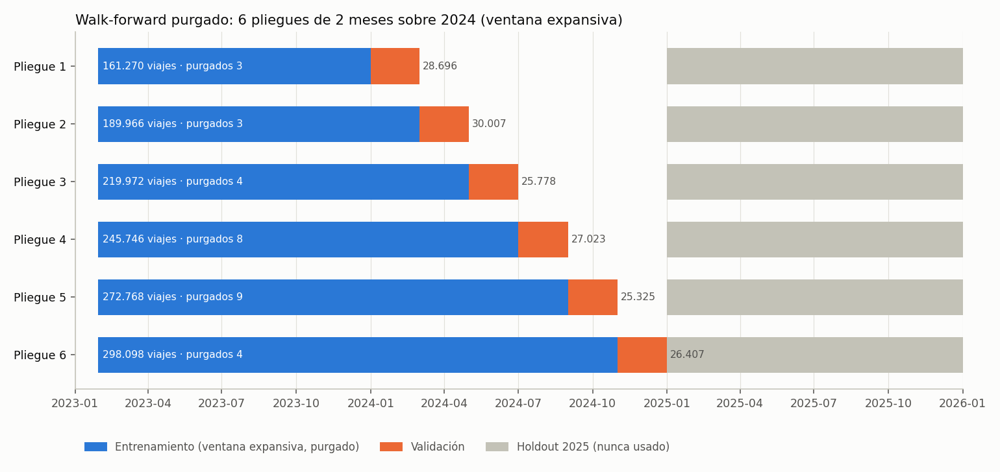

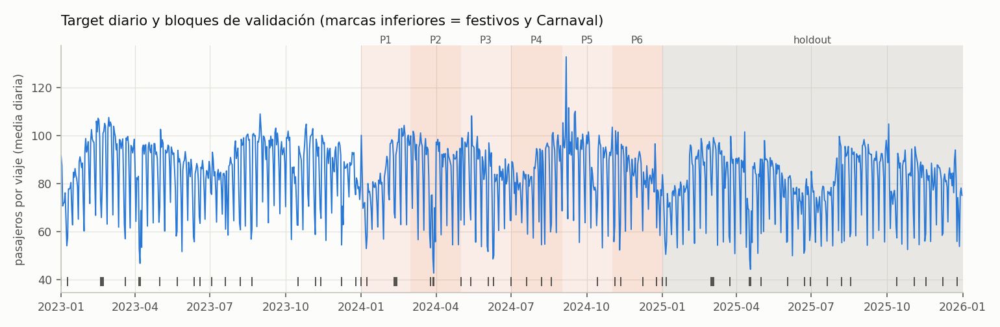

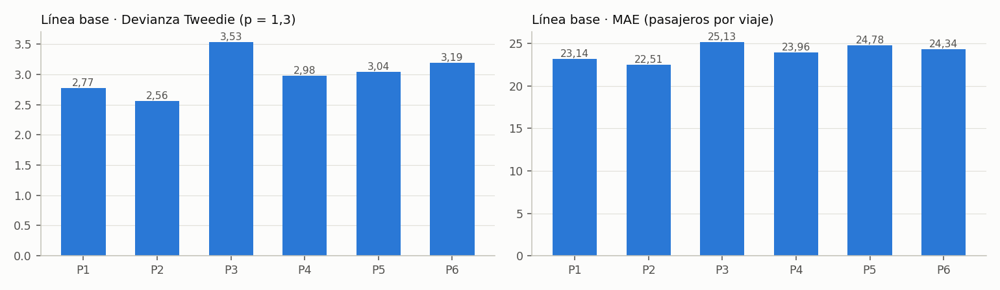

In [6]:
V.grafica_gantt(s, tabla, FIG / "gantt_pliegues.png", "Walk-forward purgado: 6 pliegues de 2 meses sobre 2024 (ventana expansiva)")
V.grafica_serie(X, s, cal, FIG / "serie_diaria_pliegues.png")
V.grafica_metricas(lb, FIG / "linea_base_por_pliegue.png")
for f in ["gantt_pliegues.png", "serie_diaria_pliegues.png", "linea_base_por_pliegue.png"]:
    display(Image(filename=str(FIG / f)))

**Conclusión 5 · Figuras**
- `gantt_pliegues.png`: los 6 pliegues con ventana expansiva, la validación de 2 meses y el holdout 2025 en gris (nunca usado), con los conteos de viajes y de purgados.
- `serie_diaria_pliegues.png`: el target diario 2023–2025 con los bloques sombreados. Se ven el ciclo semanal, los picos de septiembre–octubre de 2024 (pliegue 5) y los festivos y el Carnaval marcados abajo.
- `linea_base_por_pliegue.png`: la devianza y el MAE de la línea base por pliegue. El pliegue 3 (con el apagón) es el más difícil.

## 6 · Pruebas (a–g)

In [7]:
pruebas = T.correr_todos(X, s)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)

,check,resultado,detalle
0,Test a · orden temporal,PASS,6 pliegues: entrenamiento siempre antes del corte y validación desde el corte
1,Test b · purga por cierre,PASS,0 viajes de entrenamiento con fechafin > corte; sin la purga habrían entrado 31 (control)
2,Test c · holdout intocado,PASS,"0 filas de 2025 en los pliegues; split_holdout: 324,508 de entrenamiento y 158,507 de holdout"
3,Test d · cobertura sin solapes,PASS,"163,236 viajes del período de validación cubiertos exactamente una vez"
4,Test e · ventana expansiva,PASS,"entrenamientos anidados: 161,270 ⊂ 189,966 ⊂ 219,972 ⊂ 245,746 ⊂ 272,768 ⊂ 298,098"
5,Test f · determinismo,PASS,índices idénticos entre llamadas; mismos viajes por pliegue tras barajar X
6,Test g · línea base sin fuga,PASS,perturbar la validación: 0 predicciones cambian; perturbar el entrenamiento: sí cambian (control)


**Conclusión 6 · Las 7 pruebas pasan**
- **(a)** El entrenamiento siempre termina antes del corte y la validación empieza en él.
- **(b)** 0 viajes de entrenamiento con `fechafin` posterior al corte. Sin la purga habrían entrado 31 (el test discrimina).
- **(c)** 0 filas de 2025 en los pliegues.
- **(d)** Los 163.236 viajes de 2024 quedan cubiertos exactamente una vez.
- **(e)** Los entrenamientos están anidados (161.270 ⊂ … ⊂ 298.098).
- **(f)** El resultado es determinista e invariante al orden de las filas.
- **(g)** La línea base no ve la validación: perturbarla no cambia las predicciones, y perturbar el entrenamiento sí.

## 7 · Decisión fija y checks

In [8]:
check("Configuración fija para la 7.2 y la 7.3", True,
      f"K = {s.get_n_splits()}, bloques de {s.meses_bloque} meses en 2024, ventana expansiva desde {s.calentamiento.date()}, "
      f"corte 04:00, purga por fechafin", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_7_1.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Test a · orden temporal,PASS,6 pliegues: entrenamiento siempre antes del corte y validación desde el corte
1,Test b · purga por cierre,PASS,0 viajes de entrenamiento con fechafin > corte; sin la purga habrían entrado 31 (control)
2,Test c · holdout intocado,PASS,"0 filas de 2025 en los pliegues; split_holdout: 324,508 de entrenamiento y 158,507 de holdout"
3,Test d · cobertura sin solapes,PASS,"163,236 viajes del período de validación cubiertos exactamente una vez"
4,Test e · ventana expansiva,PASS,"entrenamientos anidados: 161,270 ⊂ 189,966 ⊂ 219,972 ⊂ 245,746 ⊂ 272,768 ⊂ 298,098"
5,Test f · determinismo,PASS,índices idénticos entre llamadas; mismos viajes por pliegue tras barajar X
6,Test g · línea base sin fuga,PASS,perturbar la validación: 0 predicciones cambian; perturbar el entrenamiento: sí cambian (control)
7,Configuración fija para la 7.2 y la 7.3,INFO,"K = 6, bloques de 2 meses en 2024, ventana expansiva desde 2023-01-29, corte 04:00, purga por fechafin"


PASS 7 · FAIL 0 · INFO 1


**Conclusión 7 · DECISIÓN FIJA para la 7.2 y la 7.3**
- **Configuración:** `WalkForwardPurgado(meses_bloque=2)`: K = 6 bloques de 2 meses sobre 2024; ventana expansiva desde el 2023-01-29; corte a las 04:00 del primer día de cada bloque; purga por `fechafin` ≤ corte. La evaluación final usa `split_holdout()`.
- **Línea base de referencia:** `datos_7/linea_base_7_1.csv` (devianza 3,013 ± 0,335).
- **Checks:** 7 en PASS, 0 en FAIL y 1 informativo.

<a id="m7-2"></a>

### A1.5.2 &middot; Subfase 7.2 · Pipeline LightGBM y Optuna

<sub>Notebook original: `subfase_7_2_optuna.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 7.2 — Pipeline LightGBM + búsqueda bayesiana con Optuna

**Persona 3 · MLOps & Model Evaluation.** Ajusta los tres modelos del Módulo 6 con la validación fija de la 7.1 y los compara contra la línea base, pliegue por pliegue.

| Elemento | Decisión |
|---|---|
| Datos | `validacion_7_1.cargar()`: 496.302 viajes (features 6.1 + 6.2 + `fechafin`) |
| Validación | `WalkForwardPurgado(meses_bloque=2)`: 6 bloques de 2 meses en 2024, purga por `fechafin`. **2025 no se toca** |
| Modelos | `modelo_0400` (33 features, principal), `modelo_intradia` (45) y `modelo_oraculo` (53, benchmark NO desplegable) |
| Algoritmo | LightGBM nativo, objetivo `tweedie` (`tweedie_variance_power` ∈ [1,1; 1,5]); `poisson` como comparación |
| Early stopping | **Interno**: las últimas 4 semanas del entrenamiento de cada pliegue, purgadas. La validación nunca elige iteraciones |
| Métrica | Devianza Tweedie con p = 1,3 **fijo**, más MAE, sesgo y desglose por `tipo_dia_cal` |
| Vara | Línea base de la 7.1: devianza 3,013 ± 0,335 (`datos_7/linea_base_7_1.csv`) |

**Ejecución.** La búsqueda completa (90 trials + comparaciones) tarda entre 1 y 3 horas según los núcleos del equipo (en la prueba: ~1,5 min por trial con 2 núcleos). Cada trial se guarda en `datos_7/optuna_7_2.db` (SQLite): **si la ejecución se interrumpe, basta con volver a ejecutar el notebook y continúa donde quedó.** Para empezar de cero, borra ese archivo.

**Parte 1 (extracción RDS): no aplica.**

## Parte 2 · Análisis offline

In [5]:
import json
import os
import platform
import time
import warnings
from pathlib import Path
from typing import Dict, List

import lightgbm as lgb
import numpy as np
import optuna
import pandas as pd
from IPython.display import Image, display

import modelado_7_2 as M
import tests_7_2 as T
import validacion_7_1 as V

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_7"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_7_2"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


# ---- CONFIGURACIÓN (se puede cambiar antes de ejecutar) ----
N_TRIALS = {"modelo_0400": 40, "modelo_intradia": 25, "modelo_oraculo": 25}
TIMEOUT_POR_ESTUDIO = None          # segundos; None = sin límite
NUM_THREADS = os.cpu_count()
ALMACEN = "sqlite:///datos_7/optuna_7_2.db"
if os.environ.get("SOBUSA_PRUEBA"):  # solo para la prueba de humo del desarrollador
    N_TRIALS = {"modelo_0400": 3, "modelo_intradia": 1, "modelo_oraculo": 1}
    ALMACEN = "sqlite:///datos_7/optuna_7_2_prueba.db"

X = V.cargar()
s = V.WalkForwardPurgado(meses_bloque=2)
lb = pd.read_csv(SALIDA / "linea_base_7_1.csv")
print(f"Python {platform.python_version()} · pandas {pd.__version__} · lightgbm {lgb.__version__} · optuna {optuna.__version__} · hilos {NUM_THREADS}")
print(f"Tabla {X.shape} · {s.get_n_splits()} pliegues · trials {N_TRIALS} · almacén {ALMACEN}")
T0 = time.time()

Python 3.12.0 · pandas 3.0.5 · lightgbm 4.7.0 · optuna 5.0.0 · hilos 12
Tabla (496302, 61) · 6 pliegues · trials {'modelo_0400': 40, 'modelo_intradia': 25, 'modelo_oraculo': 25} · almacén sqlite:///datos_7/optuna_7_2.db


## 1 · Espacio de búsqueda

| Hiperparámetro | Rango | Por qué |
|---|---|---|
| `learning_rate` | 0,02–0,15 (log) | Por debajo de 0,02 se necesitan miles de árboles sin ganancia en un problema de este tamaño; por encima de 0,15, el early stopping corta demasiado pronto |
| `num_leaves` | 15–255 (log) | Desde árboles simples hasta interacciones finas ruta × franja × calendario |
| `min_data_in_leaf` | 20–1.000 (log) | Hay ~150–300 mil viajes por pliegue: hojas muy chicas memorizan días puntuales |
| `feature_fraction` | 0,5–1,0 | Muchas features están correlacionadas (propias frente a espaciales y por salida frente a totales) |
| `bagging_fraction` | 0,5–1,0 (con `bagging_freq` = 1) | Reduce la varianza entre pliegues |
| `lambda_l1`, `lambda_l2` | 0,001–10 (log) | Regularización de las hojas |
| `max_bin` | 63, 127, 255 | Resolución de las features continuas (rezagos y tendencia) |
| `tweedie_variance_power` | 1,1–1,5 | Rango robusto de la 2.2 (p̂ = 1,39 sin 2025, auditoría 6.3 A3). **La métrica sigue fija en p = 1,3** |

## 2 · Búsqueda del modelo 04:00 (principal)

In [6]:
estudios = {}
estudios["modelo_0400"] = M.buscar(X, s, "modelo_0400", N_TRIALS["modelo_0400"], TIMEOUT_POR_ESTUDIO, NUM_THREADS, ALMACEN)
t0400 = M.tabla_estudio(estudios["modelo_0400"])
t0400.to_csv(SALIDA / "optuna_7_2_modelo_0400.csv", index=False)
print(t0400.state.value_counts().to_dict())
print("Mejor valor:", round(estudios["modelo_0400"].best_value, 4))
display(pd.Series(estudios["modelo_0400"].best_params, name="mejores parámetros (modelo_0400)").to_frame())

[modelo_0400] trial   0 COMPLETE valor=2.5050 mejor=2.5050 · 123 s
[modelo_0400] trial   1 COMPLETE valor=2.5462 mejor=2.5050 · 138 s
[modelo_0400] trial   2 COMPLETE valor=2.4994 mejor=2.4994 · 174 s
[modelo_0400] trial   3 COMPLETE valor=2.5146 mejor=2.4994 · 191 s
[modelo_0400] trial   4 COMPLETE valor=2.5113 mejor=2.4994 · 228 s
[modelo_0400] trial   5 COMPLETE valor=2.4778 mejor=2.4778 · 246 s
[modelo_0400] trial   6 COMPLETE valor=2.4950 mejor=2.4778 · 355 s
[modelo_0400] trial   7 COMPLETE valor=2.5453 mejor=2.4778 · 427 s
[modelo_0400] trial   8 PRUNED   valor=2.1338 mejor=2.4778 · 431 s
[modelo_0400] trial   9 COMPLETE valor=2.5021 mejor=2.4778 · 508 s
[modelo_0400] trial  10 COMPLETE valor=2.4862 mejor=2.4778 · 530 s
[modelo_0400] trial  11 COMPLETE valor=2.4951 mejor=2.4778 · 550 s
[modelo_0400] trial  12 COMPLETE valor=2.4751 mejor=2.4751 · 575 s
[modelo_0400] trial  13 COMPLETE valor=2.4727 mejor=2.4727 · 597 s
[modelo_0400] trial  14 COMPLETE valor=2.4920 mejor=2.4727 · 6

,mejores parámetros (modelo_0400)
learning_rate,0.100868
num_leaves,27.000000
min_data_in_leaf,28.000000
feature_fraction,0.687663
bagging_fraction,0.632190
lambda_l1,0.032498
lambda_l2,0.001141
max_bin,63.000000
tweedie_variance_power,1.364707


**Conclusión 2 · Búsqueda del modelo 04:00**
- 40 trials: 29 completos y 11 cortados por el MedianPruner (un trial cortado duró 0,1 min de media; uno completo, 0,6 min).
- Mejor trial: **n.º 31, devianza media 2,4664** en los 6 pliegues. El primer trial dio 2,5050, así que la búsqueda ganó un 1,5 %. Desde el trial 5 (2,4778) solo mejoró un 0,46 % más: **la búsqueda convergió** y más trials no cambiarían la conclusión.
- Mejores hiperparámetros: `learning_rate` 0,101, `num_leaves` 27, `min_data_in_leaf` 28, `feature_fraction` 0,69, `bagging_fraction` 0,63, `lambda_l1` 0,032, `lambda_l2` 0,001, `max_bin` 63 y **`tweedie_variance_power` 1,365**.
- Ese p es coherente con el estimado del Módulo 2 (p̂ = 1,40; IC95 de 1,29 a 1,50).

## 3 · Búsqueda de los modelos intradía y oráculo

In [7]:
for m in ["modelo_intradia", "modelo_oraculo"]:
    estudios[m] = M.buscar(X, s, m, N_TRIALS[m], TIMEOUT_POR_ESTUDIO, NUM_THREADS, ALMACEN)
    M.tabla_estudio(estudios[m]).to_csv(SALIDA / f"optuna_7_2_{m}.csv", index=False)
mejores = {m: M.mejores_params(e) for m, e in estudios.items()}
(SALIDA / "mejores_params_7_2.json").write_text(json.dumps(mejores, indent=2), encoding="utf-8")
display(pd.DataFrame(mejores))
display(pd.DataFrame({m: {"mejor devianza": e.best_value, "trials": len(e.trials),
                          "completos": sum(t.state.name == "COMPLETE" for t in e.trials),
                          "podados": sum(t.state.name == "PRUNED" for t in e.trials)} for m, e in estudios.items()}).round(4))

[modelo_intradia] trial   0 COMPLETE valor=2.5016 mejor=2.5016 · 54 s
[modelo_intradia] trial   1 COMPLETE valor=2.5712 mejor=2.5016 · 71 s
[modelo_intradia] trial   2 COMPLETE valor=2.4867 mejor=2.4867 · 112 s
[modelo_intradia] trial   3 COMPLETE valor=2.5075 mejor=2.4867 · 132 s
[modelo_intradia] trial   4 COMPLETE valor=2.4781 mejor=2.4781 · 176 s
[modelo_intradia] trial   5 COMPLETE valor=2.4711 mejor=2.4711 · 194 s
[modelo_intradia] trial   6 COMPLETE valor=2.4687 mejor=2.4687 · 261 s
[modelo_intradia] trial   7 COMPLETE valor=2.5369 mejor=2.4687 · 329 s
[modelo_intradia] trial   8 PRUNED   valor=2.1230 mejor=2.4687 · 334 s
[modelo_intradia] trial   9 PRUNED   valor=2.1071 mejor=2.4687 · 361 s
[modelo_intradia] trial  10 COMPLETE valor=2.4791 mejor=2.4687 · 436 s
[modelo_intradia] trial  11 COMPLETE valor=2.4602 mejor=2.4602 · 468 s
[modelo_intradia] trial  12 COMPLETE valor=2.5021 mejor=2.4602 · 509 s
[modelo_intradia] trial  13 COMPLETE valor=2.4896 mejor=2.4602 · 537 s
[modelo_

,modelo_0400,modelo_intradia,modelo_oraculo
learning_rate,0.100868,0.027532,0.028344
num_leaves,27.000000,116.000000,192.000000
min_data_in_leaf,28.000000,56.000000,26.000000
feature_fraction,0.687663,0.773139,0.615599
bagging_fraction,0.632190,0.761107,0.852775
lambda_l1,0.032498,0.001633,0.033820
lambda_l2,0.001141,0.049691,0.001916
max_bin,63.000000,63.000000,63.000000
tweedie_variance_power,1.364707,1.408171,1.480996


,modelo_0400,modelo_intradia,modelo_oraculo
mejor devianza,2.4664,2.453,2.2969
trials,40.0000,25.000,25.0000
completos,29.0000,23.000,24.0000
podados,11.0000,2.000,1.0000


**Conclusión 3 · Búsqueda de los modelos intradía y oráculo**
- Intradía: 25 trials (23 completos y 2 cortados). Mejor trial: **n.º 22, con 2,4530**.
- Oráculo: 25 trials (24 completos y 1 cortado). Mejor trial: **n.º 15, con 2,2969**.
- Los dos prefieren árboles más grandes y lentos que el de 04:00:
  - `learning_rate` ≈ 0,028 (frente a 0,101).
  - 116 y 192 hojas (frente a 27).
  - p más alto: 1,41 y 1,48.
- Los tres modelos eligieron `max_bin` = 63.

## 4 · Los tres modelos frente a la línea base, pliegue por pliegue

Se reentrena cada modelo con sus mejores hiperparámetros y se evalúan los 6 pliegues. **Criterio de aceptación:** el `modelo_0400` debe mejorar la línea base en los 6 pliegues.

In [8]:
cvs, preds = [], []
for m in M.MODELOS:
    cv, pr = M.evaluar_cv(X, s, M.columnas(m), mejores[m], m, NUM_THREADS, guardar_pred=True)
    cvs.append(cv); preds.append(pr)
cv_todos = pd.concat(cvs, ignore_index=True)
pred_todos = pd.concat(preds, ignore_index=True)
cmp = M.vs_linea_base(cv_todos, lb)
cmp.to_csv(SALIDA / "cv_7_2.csv", index=False)
display(cmp[cmp.filas == "todas"].pivot(index="pliegue", columns="config", values=["devianza_tweedie", "mejora_dev_%"]).round(3))
resumen = cmp.groupby(["config", "filas"]).agg(devianza=("devianza_tweedie", "mean"), devianza_std=("devianza_tweedie", "std"),
                                                 mae=("mae", "mean"), sesgo=("sesgo_medio", "mean"),
                                                 mejora_dev_pct=("mejora_dev_%", "mean"), pliegues_que_mejoran=("mejora_dev", lambda v: int((v > 0).sum())),
                                                 best_iteration=("best_iteration", "mean")).round(3)
display(resumen)
acepta = int(cmp[(cmp.config == "modelo_0400") & (cmp.filas == "todas")].mejora_dev.gt(0).sum())
check("Criterio de aceptación: modelo_0400 mejora la línea base en los 6 pliegues", acepta == 6, f"{acepta}/6 pliegues")
ptd = M.por_tipo_dia(pred_todos)
ptd.to_csv(SALIDA / "cv_7_2_por_tipo_dia.csv", index=False)
display(ptd.pivot(index="tipo_dia_cal", columns="config", values="devianza_tweedie").round(3))

devianza_tweedie                                mejora_dev_%                               
config       modelo_0400 modelo_intradia modelo_oraculo  modelo_0400 modelo_intradia modelo_oraculo
pliegue                                                                                            
1                  2.148           2.121          1.957       22.540          23.533         29.457
2                  2.028           2.010          1.961       20.870          21.590         23.504
3                  2.919           2.892          2.680       17.304          18.080         24.078
4                  2.691           2.724          2.420        9.754           8.640         18.851
5                  2.464           2.453          2.361       18.844          19.201         22.227
6                  2.548           2.519          2.404       20.238          21.170         24.763

devianza  devianza_std     mae  sesgo  mejora_dev_pct  pliegues_que_mejoran  best_iteration
config          filas                                                                                                 
modelo_0400     sin flags     2.419         0.271  21.224  0.374          18.153                     6         291.167
                todas         2.466         0.333  21.279  0.486          18.258                     6         291.167
modelo_intradia sin flags     2.405         0.281  21.088 -0.438          18.638                     6         601.167
                todas         2.453         0.340  21.145 -0.326          18.702                     6         601.167
modelo_oraculo  sin flags     2.256         0.232  20.384 -0.727          23.623                     6         526.833
                todas         2.297         0.285  20.427 -0.637          23.813                     6         526.833

config,modelo_0400,modelo_intradia,modelo_oraculo
tipo_dia_cal,,,
carnaval,2.434,2.490,2.261
domingo,2.020,2.011,1.812
festivo,2.230,2.283,1.873
laboral,2.500,2.479,2.333
sabado,2.539,2.540,2.429


**Conclusión 4 · Los tres modelos frente a la línea base**
- **Criterio de aceptación cumplido:** el modelo de 04:00 mejora la línea base (3,013) en los **6 de 6 pliegues**.
  - Devianza media **2,466**, un 18,3 % de mejora media por pliegue: desde un 9,8 % (P4) hasta un 22,5 % (P1).
  - MAE de 23,98 a **21,28** pasajeros por viaje.
  - Sesgo medio de +2,10 a **+0,49**.
- Intradía: 2,453 (mejora 6/6, 18,7 %). Oráculo: 2,297 (mejora 6/6, 23,8 %).
- **Por tipo de día (modelo 04:00 frente a la línea base):** laboral −19,8 %, festivo −18,0 %, sábado −13,9 %, domingo −9,3 % y carnaval −27,1 %.
- **⚠ Carnaval:** el modelo sobrepredice +5,9 pasajeros por viaje, frente a +1,8 de la línea base (1.138 viajes). Mejora la devianza, pero el nivel queda alto.
- **⚠ P4 (jul–ago 2024):** el early stopping se detiene en **34 iteraciones**, cuando en los otros pliegues lo hace entre 264 y 483.
  - Su ventana de early stopping es del 3 al 30 de junio de 2024, que se cruza con el apagón (31 may–18 jun) y es el mes con menos lecturas.
  - Por eso el modelo probablemente queda subajustado, y P4 es el pliegue con menos ganancia. Es un riesgo directo para la 7.3.

## 5 · Comparaciones (con los mejores hiperparámetros del modelo 04:00, sin volver a buscar)

- **a)** Objetivo `tweedie` frente a `poisson`.
- **b)** Sin las features de **totales** (`pasajeros_lag*`, `pasajeros_media4sem`, `roll_*`, incluidas las espaciales de totales): mide el riesgo del sesgo de −4,5 % en 2025 (CLAUDE.md §11.9).
- **c)** Sin el **lag espacial** (`*_esp_*`): ¿aporta la 6.2?
- **d)** Los tres modelos: la brecha 04:00 → oráculo es el valor de tener datos en tiempo real.

In [9]:
base_cols = M.columnas("modelo_0400")
bp = mejores["modelo_0400"]
totales = [c for c in base_cols if ("pasajeros_lag" in c) or ("pasajeros_media4sem" in c) or ("roll_" in c)]
espaciales = [c for c in base_cols if "_esp_" in c]
print(f"Totales quitados en (b): {len(totales)} columnas · espaciales quitadas en (c): {len(espaciales)}")
variantes = {
    "a · objetivo poisson": (base_cols, {**{k: v for k, v in bp.items() if k != "tweedie_variance_power"}, "objective": "poisson"}),
    "b · sin features de totales": ([c for c in base_cols if c not in totales], bp),
    "c · sin lag espacial": ([c for c in base_cols if c not in espaciales], bp),
}
comps = [cv_todos[cv_todos.config == "modelo_0400"].assign(config="modelo_0400 (referencia)")]
for nom, (cols, prm) in variantes.items():
    comps.append(M.evaluar_cv(X, s, cols, prm, nom, NUM_THREADS)[0])
for m in ["modelo_intradia", "modelo_oraculo"]:
    comps.append(cv_todos[cv_todos.config == m].assign(config=f"d · {m}"))
comp = pd.concat(comps, ignore_index=True)
comp = M.vs_linea_base(comp, lb)
comp.to_csv(SALIDA / "comparaciones_7_2.csv", index=False)
ref = comp[(comp.config == "modelo_0400 (referencia)") & (comp.filas == "todas")].set_index("pliegue").devianza_tweedie
tab = []
for c, g in comp[comp.filas == "todas"].groupby("config"):
    d = g.set_index("pliegue").devianza_tweedie
    tab.append({"config": c, "devianza media": d.mean(), "± std": d.std(), "Δ vs referencia": d.mean() - ref.mean(),
                "pliegues peores que la referencia": int((d > ref + 1e-12).sum()), "sesgo medio": g.sesgo_medio.mean()})
display(pd.DataFrame(tab).sort_values("devianza media").round(4))

Totales quitados en (b): 13 columnas · espaciales quitadas en (c): 8


,config,devianza media,± std,Δ vs referencia,pliegues peores que la referencia,sesgo medio
4,d · modelo_oraculo,2.2969,0.2851,-0.1695,0,-0.6371
3,d · modelo_intradia,2.4530,0.3398,-0.0135,1,-0.3259
5,modelo_0400 (referencia),2.4664,0.3333,0.0000,0,0.4862
0,a · objetivo poisson,2.5102,0.3770,0.0438,4,0.4869
2,c · sin lag espacial,2.5227,0.3708,0.0563,6,0.3176
1,b · sin features de totales,2.5302,0.3581,0.0638,5,0.7821


**Conclusión 5 · Comparaciones (con los hiperparámetros del modelo 04:00)**
- **a) Poisson:** 2,510, un 1,8 % peor que Tweedie y peor en 4 de 6 pliegues. **Se mantiene Tweedie.**
- **b) Sin las features de totales:** 2,530, un 2,6 % peor y peor en 5 de 6 pliegues. **Se mantienen.** El riesgo de sesgo en 2025 (rezagos de totales −4,5 %) se mide en el holdout de la 7.3.
- **c) Sin lag espacial:** 2,523, un 2,3 % peor y peor en **6 de 6** pliegues. **El lag espacial de la 6.2 aporta y se mantiene.**
- **d) Valor de la información en tiempo real:**
  - El oráculo mejora un 6,9 % sobre el modelo de 04:00 (6/6 pliegues).
  - La cascada intradía, en cambio, solo mejora un **0,5 %** (5/6 pliegues; empeora en P4). Recupera el **7,9 %** de esa brecha: 0,013 de 0,170.
  - Casi todo el valor del tiempo real está en t−1…t−4, que no son desplegables. Con t−5…t−8, la cascada aporta poco.
  - Se mantiene, como se decidió, pero su ganancia marginal es pequeña.
- **Corrección (7.3):** el 0,5 % de la cascada estaba deprimido por el early stopping (en P4 intradía se detuvo en 87 árboles). Con rondas fijas, intradía mejora un **1,7 %** en la CV (P2–P6) y un **3,9 %** en 2025, y recupera el 26 % y el 34 % de la brecha entre 04:00 y el oráculo. **La cascada sí aporta.**

## 6 · Figuras

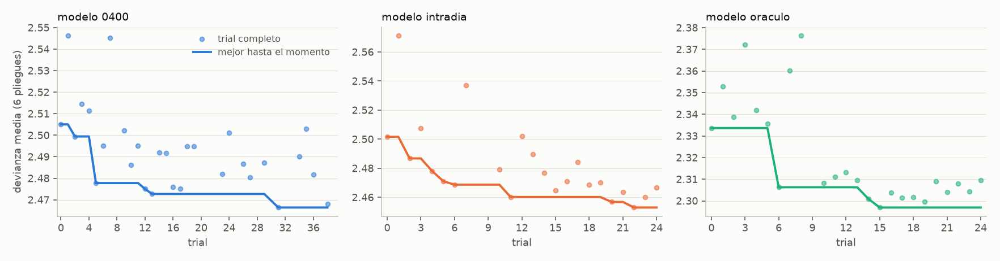

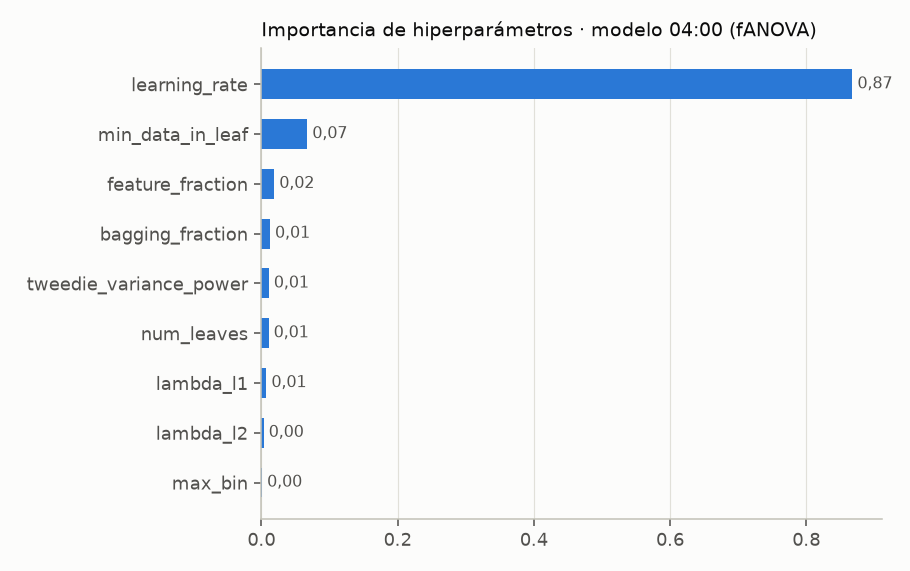

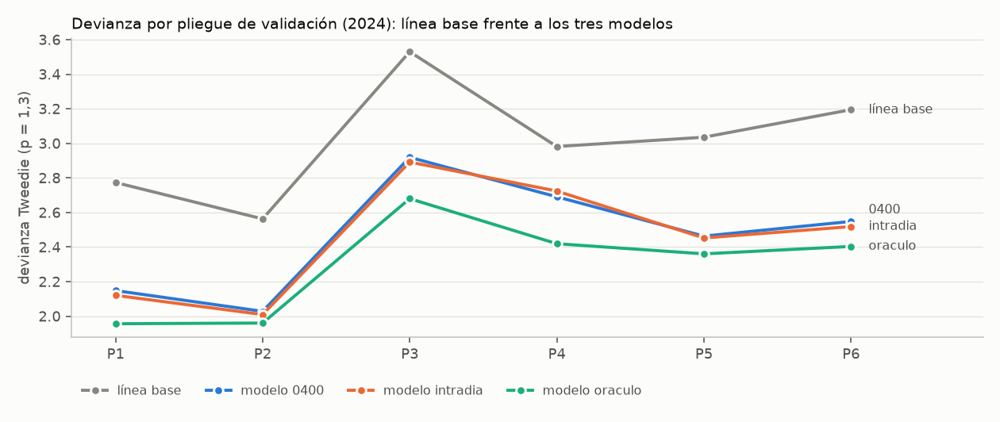

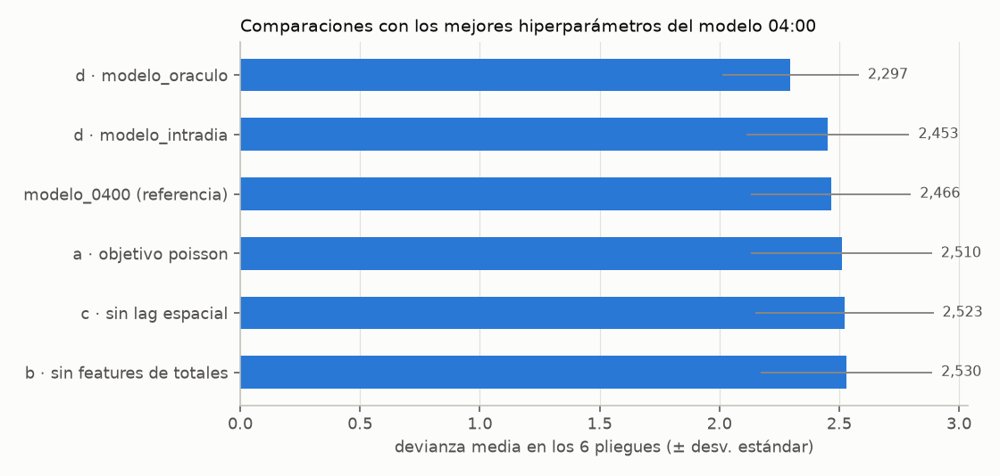

In [10]:
M.fig_historia(estudios, FIG / "historia_optuna.png")
imp = M.importancia(estudios["modelo_0400"])
imp.to_csv(SALIDA / "importancia_hiperparametros_7_2.csv")
M.fig_importancia(imp, FIG / "importancia_hiperparametros_0400.png", f"Importancia de hiperparámetros · modelo 04:00 ({imp.name})")
M.fig_pliegues(cv_todos, lb, FIG / "devianza_por_pliegue.png")
M.fig_comparaciones(comp, FIG / "comparaciones.png")
for f in ["historia_optuna.png", "importancia_hiperparametros_0400.png", "devianza_por_pliegue.png", "comparaciones.png"]:
    display(Image(filename=str(FIG / f)))

**Conclusión 6 · Figuras**
- `historia_optuna.png`: las tres búsquedas se estabilizan antes de su último tercio:
  - modelo de 04:00: trial 31 de 40;
  - intradía: trial 22 de 25;
  - oráculo: trial 15 de 25.
- `importancia_hiperparametros_0400.png` (fANOVA): **`learning_rate` explica el 86,8 %** de la varianza de la devianza y `min_data_in_leaf` el 6,7 %. Cada uno de los demás aporta menos del 2 %.
  - `tweedie_variance_power` aporta solo un 1,1 %: dentro de [1,1; 1,5], la elección de p apenas cambia la devianza.
- `devianza_por_pliegue.png` y `comparaciones.png` confirman las conclusiones 4 y 5. P3 (may–jun) es el pliegue más difícil para todos los modelos y P4 el de menor ganancia.

## 7 · Pruebas (a–f)

In [11]:
pruebas = T.correr_todos(X, s, estudios)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)

,check,resultado,detalle
0,Test a · early stopping interno y purgado,PASS,"6 pliegues: early stopping = últimas 4 semanas antes del corte, ajuste purgado a su inicio; 0 índices de validación ..."
1,Test b · la validación no influye en el ajuste,PASS,mismo best_iteration (46) y predicciones idénticas con el target de validación ×10 + 7
2,Test c · columnas exactas por modelo,PASS,modelo_0400: 33; modelo_intradia: 45; modelo_oraculo: 53; el selector rechaza columnas inexistentes
3,Test d · determinismo,PASS,"28,696 predicciones idénticas en dos entrenamientos"
4,Test e · sin 2025,PASS,"0 filas de 2025 en ajuste, early stopping o validación de los 6 pliegues"
5,Test f · el estudio solo ve 2024,PASS,"90 trials con métricas registradas, todas de validaciones anteriores a 2025"


**Conclusión 7 · Pruebas**
- Pasan las **6 de 6** pruebas:
  - **a)** early stopping interno y purgado en los 6 pliegues;
  - **b)** con el target de validación multiplicado por 10 más 7, se obtienen el mismo `best_iteration` (46) y las mismas predicciones;
  - **c)** cada modelo usa exactamente sus columnas: 33, 45 y 53;
  - **d)** determinismo: 28.696 predicciones idénticas;
  - **e)** 0 filas de 2025;
  - **f)** los 90 trials registran solo métricas de validación anteriores a 2025.
- **No hay fuga de la validación ni del holdout hacia la búsqueda.**

## 8 · Decisión fija para la 7.3 y checks

In [12]:
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min con {NUM_THREADS} hilos", info=True)
check("Mejores parámetros guardados", (SALIDA / "mejores_params_7_2.json").exists(), "datos_7/mejores_params_7_2.json", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_7_2.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Criterio de aceptación: modelo_0400 mejora la línea base en los 6 pliegues,PASS,6/6 pliegues
1,Test a · early stopping interno y purgado,PASS,"6 pliegues: early stopping = últimas 4 semanas antes del corte, ajuste purgado a su inicio; 0 índices de validación ..."
2,Test b · la validación no influye en el ajuste,PASS,mismo best_iteration (46) y predicciones idénticas con el target de validación ×10 + 7
3,Test c · columnas exactas por modelo,PASS,modelo_0400: 33; modelo_intradia: 45; modelo_oraculo: 53; el selector rechaza columnas inexistentes
4,Test d · determinismo,PASS,"28,696 predicciones idénticas en dos entrenamientos"
5,Test e · sin 2025,PASS,"0 filas de 2025 en ajuste, early stopping o validación de los 6 pliegues"
6,Test f · el estudio solo ve 2024,PASS,"90 trials con métricas registradas, todas de validaciones anteriores a 2025"
7,Tiempo total de la ejecución,INFO,64.8 min con 12 hilos
8,Mejores parámetros guardados,INFO,datos_7/mejores_params_7_2.json


PASS 7 · FAIL 0 · INFO 2


**Conclusión 8 · Decisión fija para la 7.3**
- **Modelo principal:** `modelo_0400`, con `datos_7/mejores_params_7_2.json` (p = 1,365) y objetivo Tweedie.
- **Modelos de referencia:** intradía (2,453) y oráculo (2,297), con sus propios parámetros.
- **Features:** se mantienen las de totales y el lag espacial.
- **Pendiente para la 7.3 (número de rondas):** con early stopping interno, la ventana del modelo final sería diciembre de 2024 (temporada navideña), una ventana atípica como la de P4.
  - Comparar early stopping interno frente a rondas fijas: mediana de `best_iteration` en la validación cruzada = **311** para el modelo de 04:00 (283, 339, 483, 34, 344, 264).
- **Riesgos que se miden en el holdout 2025:** sesgo por cierres tardíos (rezagos de totales −4,5 %), sobrepredicción en carnaval y tendencia descendente de la demanda.
- La ejecución tardó 64,8 min con 12 hilos y todos los checks pasaron.
- **Resuelto en la 7.3:** se adoptan rondas fijas (311 / 649 / 461), que igualan o mejoran el early stopping en 4/5, 5/5 y 5/5 pliegues.

<a id="m7-3"></a>

### A1.5.3 &middot; Subfase 7.3 · Regla de rondas, entrenamiento final y evaluación única

<sub>Notebook original: `subfase_7_3_final.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 7.3 — Regla de rondas, entrenamiento final, evaluación única en 2025 y sobreajuste

**Persona 3 · MLOps & Model Evaluation.** Cierra el Módulo 7: fija cuántos árboles usa cada modelo **solo con 2024**, entrena los modelos finales con 2023–2024 y los evalúa **una sola vez** en el holdout 2025.

| Elemento | Decisión |
|---|---|
| Datos | `validacion_7_1.cargar()`: 496.302 viajes. Entrenamiento final = `split_holdout()`: 324.508 viajes (2023-01-29 → 2024-12-31, purga por `fechafin` ≤ 2025-01-01 04:00). Holdout 2025: 158.507 viajes |
| Hiperparámetros | `datos_7/mejores_params_7_2.json` **sin cambios** (se verifica con su hash) |
| Regla candidata | Rondas fijas = mediana de `best_iteration` de la 7.2 (04:00: 311 · intradía: 649 · oráculo: 461), entrenando con **todo** el entrenamiento (sin apartar diciembre para early stopping) |
| Criterio (fijado antes) | Se adoptan rondas fijas si en **≥ 3 de 5** pliegues (P2–P6) su devianza ≤ la del early stopping × 1,005. Si no, early stopping interno (4 semanas). Por modelo |
| Aceptación en 2025 | El modelo 04:00 mejora la línea base en el global y en **≥ 10 de 12 meses** |
| Métrica | Devianza Tweedie con p = 1,3 **fijo**, más MAE y sesgo |

**Regla de oro.** La decisión de rondas se escribe en `datos_7/decision_rondas_7_3.json` **antes** de tocar 2025. Lo que se observe en 2025 (partes 4–7) es descriptivo y no cambia ninguna decisión; el código se niega a reescribir la decisión si ya existen métricas del holdout.

**Ejecución.** Tarda unos 10 min con 12 hilos (en la prueba: la parte A del modelo 04:00 tomó 0,9 min con 2 hilos). No usa la base de datos.

**Parte 1 (extracción RDS): no aplica.**

## Parte 2 · Análisis offline

In [1]:
import json
import os
import platform
import time
import warnings
from pathlib import Path
from typing import Dict, List

import lightgbm as lgb
import numpy as np
import pandas as pd
from IPython.display import Image, display

import entrenamiento_7_3 as E
import modelado_7_2 as M
import tests_7_3 as T
import validacion_7_1 as V

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_7"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_7_3"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


# ---- CONFIGURACIÓN ----
NUM_THREADS = os.cpu_count()
TOPE = None                      # None = rondas completas
SEMILLAS = (1, 2, 3)
if os.environ.get("SOBUSA_PRUEBA"):   # solo para la prueba de humo del desarrollador
    TOPE, SEMILLAS = 40, (1,)

X = V.cargar()
s = V.WalkForwardPurgado(meses_bloque=2)
params, HASH = E.cargar_params()
r72 = E.resultados_7_2()
FINALES = E.rondas_finales(r72)
print(f"Python {platform.python_version()} · pandas {pd.__version__} · lightgbm {lgb.__version__} · hilos {NUM_THREADS} · tope {TOPE}")
print(f"Tabla {X.shape} · hash de mejores_params_7_2.json: {HASH[:16]}…")
print("Rondas candidatas (mediana de best_iteration de la 7.2):", FINALES)
T0 = time.time()

Python 3.12.0 · pandas 3.0.5 · lightgbm 4.7.0 · hilos 12 · tope None
Tabla (496302, 61) · hash de mejores_params_7_2.json: 428a3fb5f20dac8d…
Rondas candidatas (mediana de best_iteration de la 7.2): {'modelo_0400': 311, 'modelo_intradia': 649, 'modelo_oraculo': 461}


## 1 · Parte A — Validación anidada de la regla de rondas (solo 2024)

En cada pliegue k ≥ 2 las rondas son la mediana de `best_iteration` de los pliegues **anteriores** (nunca del propio ni de los siguientes). Se entrena con **todo** el entrenamiento del pliegue, sin ventana de early stopping, y se compara con la devianza que obtuvo el early stopping en la 7.2. La misma pasada registra la devianza en cada iteración (curva de sensibilidad); el registro no influye en el modelo.

In [2]:
anid = pd.DataFrame({m: E.rondas_anidadas(g.sort_values("pliegue").best_iteration.tolist())
                     for m, g in r72.groupby("modelo")}).rename_axis("pliegue")
display(r72.pivot(index="pliegue", columns="modelo", values="best_iteration").rename(columns=lambda c: f"best_iter_7_2 · {c}")
        .join(anid.rename(columns=lambda c: f"regla · {c}")))
tA = time.time()
regla, curvas = E.regla_rondas(X, s, params, r72, NUM_THREADS, tope=TOPE)
regla.to_csv(SALIDA / "regla_rondas_7_3.csv", index=False)
curvas.to_csv(SALIDA / "curvas_rondas_cv_7_3.csv.gz", index=False)
print(f"Parte A: {(time.time() - tA) / 60:,.1f} min")
display(regla.dropna(subset=["dev_fijo"]).pivot(index="pliegue", columns="modelo",
        values=["rondas_regla", "dev_es_7_2", "dev_fijo", "ratio_fijo_es", "fijo_gana_o_empata"]).round(4))

,best_iter_7_2 · modelo_0400,best_iter_7_2 · modelo_intradia,best_iter_7_2 · modelo_oraculo,regla · modelo_0400,regla · modelo_intradia,regla · modelo_oraculo
pliegue,,,,,,
1,283,534,499,NaN,NaN,NaN
2,339,570,423,283.0,534.0,499.0
3,483,820,505,311.0,552.0,461.0
4,34,87,208,339.0,570.0,499.0
5,344,727,407,311.0,552.0,461.0
6,264,869,1119,339.0,570.0,423.0


[modelo_0400] P1 · 161,270 viajes · 622 rondas · 4.4 s
[modelo_0400] P2 · 189,966 viajes · 622 rondas · 5.4 s
[modelo_0400] P3 · 219,972 viajes · 622 rondas · 5.1 s
[modelo_0400] P4 · 245,746 viajes · 622 rondas · 5.3 s
[modelo_0400] P5 · 272,768 viajes · 622 rondas · 5.4 s
[modelo_0400] P6 · 298,098 viajes · 622 rondas · 5.6 s
[modelo_intradia] P1 · 161,270 viajes · 1298 rondas · 13.5 s
[modelo_intradia] P2 · 189,966 viajes · 1298 rondas · 14.9 s
[modelo_intradia] P3 · 219,972 viajes · 1298 rondas · 15.4 s
[modelo_intradia] P4 · 245,746 viajes · 1298 rondas · 16.7 s
[modelo_intradia] P5 · 272,768 viajes · 1298 rondas · 20.8 s
[modelo_intradia] P6 · 298,098 viajes · 1298 rondas · 26.3 s
[modelo_oraculo] P1 · 161,270 viajes · 922 rondas · 12.9 s
[modelo_oraculo] P2 · 189,966 viajes · 922 rondas · 13.6 s
[modelo_oraculo] P3 · 219,972 viajes · 922 rondas · 14.7 s
[modelo_oraculo] P4 · 245,746 viajes · 922 rondas · 15.6 s
[modelo_oraculo] P5 · 272,768 viajes · 922 rondas · 15.7 s
[modelo_o

rondas_regla                                 dev_es_7_2                                   dev_fijo                                ratio_fijo_es                                 \
modelo   modelo_0400 modelo_intradia modelo_oraculo modelo_0400 modelo_intradia modelo_oraculo modelo_0400 modelo_intradia modelo_oraculo   modelo_0400 modelo_intradia modelo_oraculo   
pliegue                                                                                                                                                                                  
2              283.0           534.0          499.0    2.028186         2.00973       1.960652    2.047158        2.006763       1.942356      1.009354        0.998524       0.990668   
3              311.0           552.0          461.0    2.919257        2.891857        2.68013    2.880394        2.852294       2.660556      0.986687        0.986319       0.992697   
4              339.0           570.0          499.0    2.690876        2.724097       2.419616    2.518694        2.461227       2.292082      0.936013        0.903502       0.947291   
5              311.0           552.0          461.0    2.463504        2.452679       2.360822    2.454604        2.415499       2.353138      0.996387        0.984841       0.996745   
6              339.0           570.0          423.0    2.548366        2.518602       2.403795     2.54002        2.498142       2.392195      0.996725        0.991877       0.995174   

        fijo_gana_o_empata                                 
modelo         modelo_0400 modelo_intradia modelo_oraculo  
pliegue                                                    
2                    False            True           True  
3                     True            True           True  
4                     True            True           True  
5                     True            True           True  
6                     True            True           True

,modelo,rondas_candidatas,curva media en las rondas candidatas (%),mínimo de la curva media (%),árboles del mínimo de la curva media,"tramo a ≤ 0,5 puntos del mínimo",árboles del mínimo por pliegue
0,modelo_0400,311,0.845,0.759,344,132–609,"P1=95, P2=622, P3=342, P4=142, P5=604, P6=181"
1,modelo_intradia,649,0.353,0.321,560,243–1298,"P1=235, P2=997, P3=767, P4=498, P5=1179, P6=278"
2,modelo_oraculo,461,0.188,0.176,478,225–922,"P1=304, P2=882, P3=389, P4=472, P5=907, P6=480"


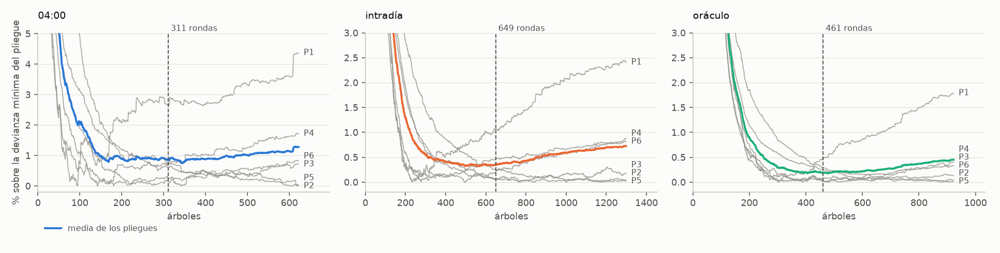

In [3]:
cr = curvas.copy()
cr["rel_%"] = (cr.devianza / cr.groupby(["modelo", "pliegue"]).devianza.transform("min") - 1) * 100
sens = []
for m, g in cr.groupby("modelo"):
    med = g.groupby("iteracion")["rel_%"].mean()
    r = FINALES[m] if TOPE is None else min(FINALES[m], TOPE)
    plano = med[med <= med.min() + 0.5].index
    sens.append({"modelo": m, "rondas_candidatas": r, "curva media en las rondas candidatas (%)": med.get(r),
                 "mínimo de la curva media (%)": med.min(), "árboles del mínimo de la curva media": int(med.idxmin()),
                 "tramo a ≤ 0,5 puntos del mínimo": f"{int(plano.min())}–{int(plano.max())}",
                 "árboles del mínimo por pliegue": ", ".join(f"P{k}={int(h.iteracion[h.devianza.idxmin()])}" for k, h in g.groupby("pliegue"))})
sens = pd.DataFrame(sens)
sens.to_csv(SALIDA / "sensibilidad_rondas_7_3.csv", index=False)
display(sens.round(3))
E.fig_curva_rondas(curvas, {"modelos": {}}, {m: (FINALES[m] if TOPE is None else min(FINALES[m], TOPE)) for m in FINALES},
                   FIG / "curva_rondas_cv_2024.png")
display(Image(filename=str(FIG / "curva_rondas_cv_2024.png")))

**Conclusión 1 · Regla de rondas en 2024**
- Con rondas fijas = mediana de los pliegues **anteriores** y entrenando con todo el pliegue, la devianza **iguala o mejora** al early stopping de la 7.2 en:
  - **04:00:** 4 de 5 pliegues. Solo pierde P2: +0,9 % con 283 rondas.
  - **intradía:** 5 de 5.
  - **oráculo:** 5 de 5.
- Ratio medio fijo/ES: 0,985 · 0,973 · 0,985.
- **P4 (jul–ago) confirma el diagnóstico de la 7.2:** las rondas fijas mejoran un **6,4 %**, un 9,6 % y un 5,3 %, porque el early stopping con la ventana de junio cortaba demasiado pronto (34, 87 y 208 árboles).
- **Las rondas candidatas caen en la zona plana:**
  - En 311, 649 y 461 árboles, la curva media queda a 0,85 %, 0,35 % y 0,19 % sobre el mínimo de cada pliegue.
  - Los mínimos de la curva media están en 344, 560 y 478 árboles.
  - El tramo a ≤ 0,5 puntos del mínimo va de 132 a 609, de 243 a 1.298 y de 225 a 922 árboles.
- P1 (ene–feb 2024) es la excepción: su mínimo está en 95, 235 y 304 árboles, y luego empeora (hasta +4,4 % en el modelo 04:00).

## 2 · Decisión de rondas (se escribe ANTES de tocar 2025)

In [4]:
decision = E.decidir(regla, r72)
decision = E.guardar_decision(decision, HASH)
print(json.dumps(decision, ensure_ascii=False, indent=2))
for m, d in decision["modelos"].items():
    check(f"Decisión de rondas · {m}", True, f"{d['regla']} ({d['rondas']}); {d['pliegues_gana_o_empata']}/{d['pliegues_evaluados']} pliegues", info=True)

{
  "criterio": "rondas fijas si en ≥ 3 de 5 pliegues (P2–P6) su devianza ≤ ES × 1.005",
  "modelos": {
    "modelo_0400": {
      "regla": "rondas_fijas",
      "rondas": 311,
      "pliegues_gana_o_empata": 4,
      "pliegues_evaluados": 5,
      "ratio_medio_fijo_es": 0.9850332975842677
    },
    "modelo_intradia": {
      "regla": "rondas_fijas",
      "rondas": 649,
      "pliegues_gana_o_empata": 5,
      "pliegues_evaluados": 5,
      "ratio_medio_fijo_es": 0.9730124536560443
    },
    "modelo_oraculo": {
      "regla": "rondas_fijas",
      "rondas": 461,
      "pliegues_gana_o_empata": 5,
      "pliegues_evaluados": 5,
      "ratio_medio_fijo_es": 0.984515146345621
    }
  },
  "hash_mejores_params_7_2": "428a3fb5f20dac8d0ed3b46f64d93381c638503c58f1f5c1d155527fbce420c8",
  "escrita": "2026-10-10T18:16:46"
}


**Conclusión 2 · Decisión**
- **Rondas fijas en los tres modelos:** **311** (04:00), **649** (intradía) y **461** (oráculo).
- La decisión quedó escrita en `datos_7/decision_rondas_7_3.json` a las 18:16:46, antes de las métricas de 2025.
- El hash de `mejores_params_7_2.json` (428a3fb5…) es el mismo en la decisión y en los tres modelos guardados.
- Con esta regla, **diciembre de 2024 entra al entrenamiento final** en vez de quedar apartado como ventana de early stopping.

## 3 · Parte B — Entrenamiento final (2023-01-29 → 2024-12-31)

In [5]:
t, ho = E.datos_final(X, s)
print(f"Entrenamiento: {len(t):,} viajes, {t.fechasalida.min()} → {t.fechasalida.max()} (último cierre {t.fechafin.max()})")
print(f"Holdout 2025: {len(ho):,} viajes")
finales_b, metas = {}, []
for m in M.MODELOS:
    t0 = time.time()
    b, n = E.entrenar_final(t, m, params[m], decision["modelos"][m], NUM_THREADS, tope=TOPE)
    E.guardar_modelo(b, n, m, params[m], decision["modelos"][m], HASH, t)
    finales_b[m] = (b, n)
    metas.append({"modelo": m, "regla": decision["modelos"][m]["regla"], "árboles": n, "columnas": len(M.columnas(m)),
                  "segundos": round(time.time() - t0, 1)})
display(pd.DataFrame(metas))

Entrenamiento: 324,508 viajes, 2023-01-29 05:00:00 → 2024-12-31 18:40:00 (último cierre 2024-12-31 21:53:44)
Holdout 2025: 158,507 viajes


,modelo,regla,árboles,columnas,segundos
0,modelo_0400,rondas_fijas,311,33,2.6
1,modelo_intradia,rondas_fijas,649,45,10.0
2,modelo_oraculo,rondas_fijas,461,53,11.3


**Conclusión 3 · Modelos finales**
- Entrenados con **324.508 viajes**:
  - salidas del 2023-01-29 05:00 al 2024-12-31 18:40;
  - último cierre: 2024-12-31 21:53, antes del corte del 2025-01-01 04:00.
- Guardados en `modelos_7_3/` con sus metadatos (columnas, parámetros, regla, número de árboles y hash):
  - `modelo_0400.txt`: 33 columnas y 311 árboles.
  - `modelo_intradia.txt`: 45 columnas y 649 árboles.
  - `modelo_oraculo.txt`: 53 columnas y 461 árboles.

## 4 · Evaluación única en el holdout 2025

Línea base = la misma de la 7.1 (media ruta × franja × `tipo_dia_cal`), estimada solo con el entrenamiento final.

,config,filas,devianza_tweedie,mae,sesgo_medio,n,mejora_dev_%
0,linea_base,todas,2.9288,23.4854,5.9553,158507,0.0000
1,linea_base,sin flags,2.9288,23.4854,5.9553,158507,0.0000
2,modelo_0400,todas,2.5028,20.7064,-2.9708,158507,14.5430
3,modelo_0400,sin flags,2.5028,20.7064,-2.9708,158507,14.5430
4,modelo_intradia,todas,2.4058,20.3800,-1.7543,158507,17.8574
5,modelo_intradia,sin flags,2.4058,20.3800,-1.7543,158507,17.8574
6,modelo_oraculo,todas,2.2216,19.6701,-0.4785,158507,24.1475
7,modelo_oraculo,sin flags,2.2216,19.6701,-0.4785,158507,24.1475


{'mejora_global_%': 14.543030686284652, 'meses_que_mejoran': 11, 'meses': 12, 'acepta': True}


,linea_base,modelo_0400,modelo_intradia,modelo_oraculo,mejora 0400 %
grupo,,,,,
2025-01,3.293,2.452,2.353,2.130,25.5
2025-02,2.493,2.586,2.426,2.130,-3.7
2025-03,2.522,2.405,2.295,2.087,4.6
2025-04,2.807,2.558,2.431,2.203,8.9
2025-05,2.721,2.452,2.351,2.179,9.9
2025-06,3.133,2.469,2.421,2.289,21.2
2025-07,3.293,2.386,2.363,2.250,27.5
2025-08,2.672,2.666,2.501,2.229,0.2
2025-09,2.731,2.514,2.411,2.196,8.0


,linea_base,modelo_0400,modelo_intradia,modelo_oraculo,mejora 0400 %
grupo,,,,,
16,2.605,2.299,2.224,2.026,11.8
2,3.428,2.842,2.695,2.511,17.1
21,3.117,2.582,2.498,2.353,17.2


,linea_base,modelo_0400,modelo_intradia,modelo_oraculo,mejora 0400 %
grupo,,,,,
carnaval,3.544,2.407,2.460,2.508,32.1
domingo,2.295,2.344,2.297,1.920,-2.1
festivo,2.224,1.851,1.817,1.713,16.8
laboral,3.030,2.569,2.453,2.266,15.2
sabado,2.957,2.404,2.356,2.290,18.7


,linea_base,modelo_0400,modelo_intradia,modelo_oraculo,mejora 0400 %
grupo,,,,,
04–06,3.469,3.455,3.127,2.634,0.4
07–09,2.709,2.075,2.060,1.952,23.4
10–12,3.029,2.461,2.428,2.330,18.8
13–15,2.516,2.118,2.053,1.943,15.8
16–18,2.815,2.314,2.251,2.178,17.8
19–20,2.967,2.321,2.379,2.264,21.8


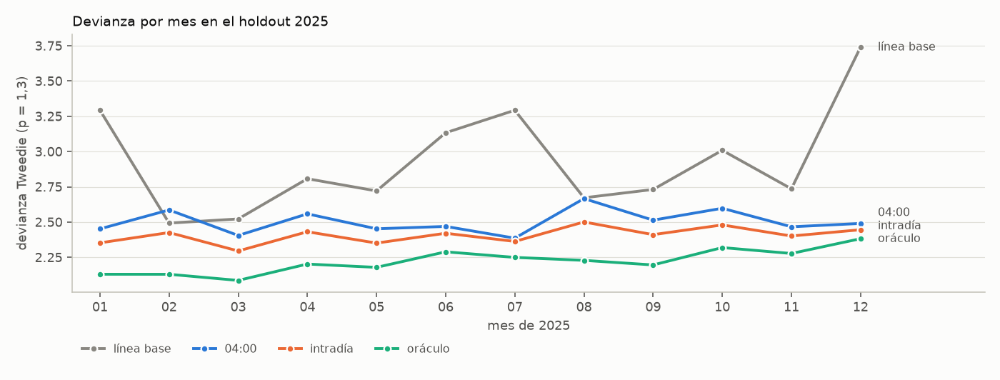

In [6]:
preds = {"linea_base": V.linea_base(t, ho)}
for m, (b, n) in finales_b.items():
    preds[m] = b.predict(ho[M.columnas(m)], num_iteration=n)
glob, des = E.evaluar_holdout(ho, preds)
des.to_csv(SALIDA / "holdout_desgloses_7_3.csv", index=False)
out = pd.DataFrame({"idprogramacion": ho.idprogramacion.to_numpy(), "idruta": ho.idruta.to_numpy(),
                    "fechasalida": ho.fechasalida.to_numpy(), "tipo_dia_cal": ho.tipo_dia_cal.astype(str).to_numpy(),
                    "y": ho.numeropasajeros.to_numpy(float), **{f"pred_{c}": p for c, p in preds.items()}})
out.to_parquet(SALIDA / "predicciones_holdout_7_3.parquet", index=False)
out.to_csv(SALIDA / "predicciones_holdout_7_3.csv.gz", index=False)
display(glob.round(4))
acc = E.criterio_aceptacion(glob, des)
check("Criterio de aceptación en 2025: modelo_0400 mejora la línea base (global y ≥ 10/12 meses)", acc["acepta"],
      f"mejora global {acc['mejora_global_%']:.1f} %; {acc['meses_que_mejoran']}/{acc['meses']} meses")
print(acc)
for dim in ["mes", "idruta", "tipo_dia_cal", "franja"]:
    display(des[des.dimension == dim].pivot(index="grupo", columns="config", values="devianza_tweedie").round(3)
            .join(des[(des.dimension == dim) & (des.config == "modelo_0400")].set_index("grupo")["mejora_dev_%"].round(1).rename("mejora 0400 %")))
E.fig_por_mes(des, "devianza_tweedie", FIG / "devianza_por_mes_2025.png", "Devianza por mes en el holdout 2025",
              "devianza Tweedie (p = 1,3)")
display(Image(filename=str(FIG / "devianza_por_mes_2025.png")))

**Conclusión 4 · Resultado en 2025 (evaluación única)**
- **Criterio de aceptación cumplido.** El modelo 04:00 logra una devianza de **2,503**, frente a 2,929 de la línea base: **−14,5 %**. Mejora en **11 de 12 meses**.
  - MAE: de 23,49 a **20,71** pasajeros por viaje.
- **Intradía:** 2,406 (−17,9 %). **Oráculo:** 2,222 (−24,1 %).
- **Mes que no cumple:** febrero empeora un 3,7 % (2,586 frente a 2,493). Agosto apenas mejora (0,2 %).
  - En ambos meses el modelo **subpredice** mucho: −7,3 y −6,5 pasajeros por viaje.
  - Hipótesis por verificar: es el regreso a clases después de vacaciones, y el calendario no tiene esa variable.
  - Los meses con más ganancia son diciembre (−33,4 %), julio (−27,5 %) y enero (−25,5 %), justo donde la línea base falla por la estacionalidad.
- **Por tipo de día:** laboral −15,2 %, sábado −18,7 %, festivo −16,8 % y carnaval −32,1 %.
  - **El domingo empeora un 2,1 %:** 2,344 frente a 2,295, con un sesgo de +10,0 pasajeros por viaje.
- **Por ruta:** 16 −11,8 %, 2 −17,1 % y 21 −17,2 %.
- **Por franja:** **04–06 h no mejora** (+0,4 %: 3,455 frente a 3,469) y subpredice −12,2 pasajeros por viaje. Las demás franjas mejoran entre un 15,8 % y un 23,4 %.
- **El modelo 04:00 queda por debajo en 2025:**
  - sesgo medio **−2,97 pasajeros por viaje** (−3,7 % de la media real de 80,63); la línea base sobrepredice +5,96;
  - la media de las predicciones es 77,66, frente a 78,88 de intradía y 80,16 del oráculo.

## 5 · Parte C — Test de sobreajuste (descriptivo)

Alertas: devianza del holdout / devianza en el ajuste > 1,5, o mejora sobre la línea base en 2025 por debajo de la del peor pliegue de la CV.

,modelo,dev_ajuste,dev_cv_media,dev_cv_std,dev_holdout,ratio_holdout_ajuste,mejora_holdout_%,peor_mejora_cv_%,alerta_ratio,alerta_mejora
0,modelo_0400,2.0134,2.4664,0.3333,2.5028,1.2431,14.5430,9.7537,False,False
1,modelo_intradia,1.8436,2.4530,0.3398,2.4058,1.3050,17.8574,8.6396,False,False
2,modelo_oraculo,1.7646,2.2969,0.2851,2.2216,1.2589,24.1475,18.8512,False,False


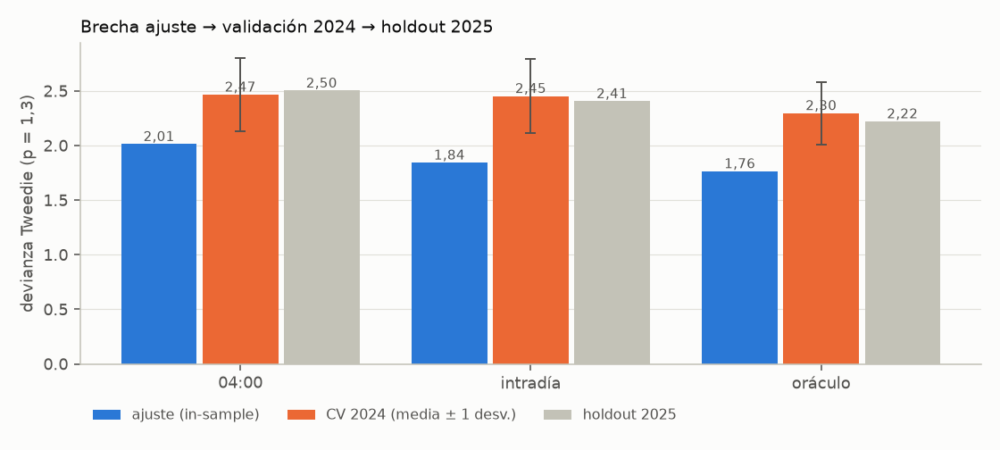

In [7]:
sob = E.sobreajuste(t, ho, finales_b, glob, r72)
sob.to_csv(SALIDA / "sobreajuste_7_3.csv", index=False)
display(sob.round(4))
for _, r in sob.iterrows():
    check(f"Sobreajuste · {r['modelo']}", not (r["alerta_ratio"] or r["alerta_mejora"]),
          f"holdout/ajuste = {r['ratio_holdout_ajuste']:.2f}; mejora 2025 {r['mejora_holdout_%']:.1f} % vs peor pliegue CV {r['peor_mejora_cv_%']:.1f} %",
          info=True)
E.fig_brecha(sob, FIG / "brecha_ajuste_cv_holdout.png")
display(Image(filename=str(FIG / "brecha_ajuste_cv_holdout.png")))

**Conclusión 5 · Sobreajuste**
- **No hay alertas.**
  - Holdout sobre ajuste: 1,24, 1,30 y 1,26 (umbral 1,5).
  - La mejora en 2025 (14,5 %, 17,9 % y 24,1 %) supera la del peor pliegue de la CV (9,8 %, 8,6 % y 18,9 %).
- **El modelo 04:00 generaliza como predijo la CV:**
  - 2025: 2,503.
  - CV 2024: 2,466 ± 0,333 con early stopping, y 2,488 en P2–P6 con rondas fijas.
  - La diferencia es del +0,6 % al +1,5 %, dentro de 1 desviación.
- La mejora sobre la línea base baja del 18,3 % (CV) al 14,5 % (2025).
- La brecha entre el ajuste (2,013) y 2025 (2,503) es la esperable para boosting: el ajuste se mide in-sample.

## 6 · Estabilidad con la semilla y curva de rondas en 2025 (descriptivas)

,modelo,semilla,n_arboles,devianza_tweedie,mae,sesgo_medio,n
0,modelo_0400,1,311,2.4720,20.6429,-2.5177,158507
1,modelo_0400,2,311,2.5124,20.7779,-3.3670,158507
2,modelo_0400,3,311,2.4840,20.6728,-2.6385,158507
3,modelo_0400,42,311,2.5028,20.7064,-2.9708,158507


Rango de la devianza 2025 entre semillas: 0.0403


,modelo,árboles usados,devianza 2025 con esos árboles,árboles del mínimo en 2025,devianza mínima 2025,% sobre el mínimo
0,modelo_0400,311,2.5028,95,2.3926,4.6088
1,modelo_intradia,649,2.4058,214,2.3534,2.2265
2,modelo_oraculo,461,2.2216,464,2.2214,0.0080


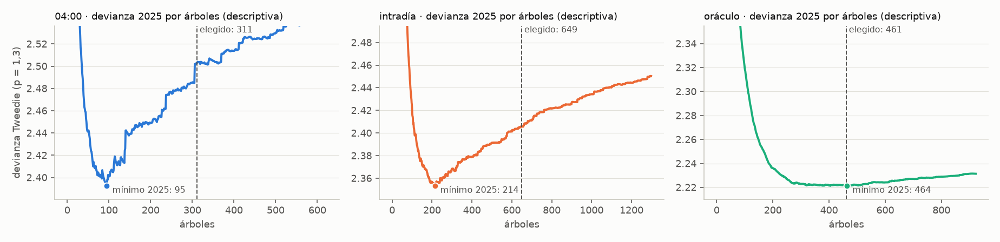

In [8]:
sem = E.semillas(t, ho, params["modelo_0400"], decision["modelos"]["modelo_0400"], NUM_THREADS, SEMILLAS, tope=TOPE)
sem = pd.concat([sem, pd.DataFrame([{"modelo": "modelo_0400", "semilla": 42, "n_arboles": finales_b["modelo_0400"][1],
                                     **V.metricas(ho.numeropasajeros.to_numpy(float), preds["modelo_0400"])}])], ignore_index=True)
sem.to_csv(SALIDA / "semillas_7_3.csv", index=False)
display(sem.round(4))
print(f"Rango de la devianza 2025 entre semillas: {sem.devianza_tweedie.max() - sem.devianza_tweedie.min():.4f}")
ch = []
for m in M.MODELOS:
    r_max = 2 * finales_b[m][1] if TOPE is None else TOPE
    ch.append(E.curva_holdout(t, ho, m, params[m], r_max, NUM_THREADS))
ch = pd.concat(ch, ignore_index=True)
ch.to_csv(SALIDA / "curva_rondas_holdout_7_3.csv.gz", index=False)
res = []
for m, g in ch.groupby("modelo"):
    n = finales_b[m][1]
    res.append({"modelo": m, "árboles usados": n, "devianza 2025 con esos árboles": float(g.devianza.iloc[n - 1]),
                "árboles del mínimo en 2025": int(g.iteracion[g.devianza.idxmin()]), "devianza mínima 2025": float(g.devianza.min()),
                "% sobre el mínimo": float(g.devianza.iloc[n - 1] / g.devianza.min() - 1) * 100})
display(pd.DataFrame(res).round(4))
E.fig_curva_holdout(ch, {m: n for m, (_, n) in finales_b.items()}, FIG / "curva_rondas_holdout_2025.png")
display(Image(filename=str(FIG / "curva_rondas_holdout_2025.png")))

**Conclusión 6 · Semillas y rondas en 2025 (descriptivas; no cambian ninguna decisión)**
- **Semillas (modelo 04:00):**
  - Devianza en 2025: 2,472 (semilla 1), 2,512 (2), 2,484 (3) y 2,503 (42).
  - Rango: **0,040 (1,6 %)**. Media: 2,493.
  - Las diferencias entre modelos en 2025 (intradía −0,097) superan ese rango. Para el Diebold-Mariano del Módulo 8 conviene usar la media de semillas o reportar este rango.
- **Rondas en 2025:**
  - **04:00:** 311 árboles quedan un **4,6 % por encima** del mínimo de 2025, que está en **95 árboles** (2,393).
  - **intradía:** 649 árboles quedan un 2,2 % por encima del mínimo, que está en 214.
  - **oráculo:** óptimo (464 frente a 461; 0,01 %).
- **Saltos en la curva del modelo 04:00:** la curva sube a saltos (cerca de 135, 250 y 310 árboles). Algunos árboles empeoran 2025 de golpe. Es el mismo patrón de P1 en la CV.
- **Hipótesis para el Módulo 8:** el *drift* de 2025 y la extrapolación de `tendencia_meses`, que en 2025 queda fuera del rango de entrenamiento y los árboles tratan como constante.
  - Se verifica con SHAP en la 8.2.
  - No se reajustan las rondas mirando 2025 (regla de oro).

## 7 · Riesgos de CLAUDE.md medidos en 2025 (descriptivos)

- **§11.9** Cierres tardíos: sesgo medio por mes y sensibilidad «sin features de totales» (solo informativa: la decisión de la 7.2 no cambia).
- **§11.12** Carnaval.
- **§5.11** Tendencia descendente: sesgo por mes a lo largo de 2025.

config,linea_base,modelo_0400,modelo_intradia,modelo_oraculo
grupo,,,,
2025-01,15.13,0.55,0.63,0.53
2025-02,-0.39,-7.28,-4.94,-2.39
2025-03,0.51,-4.39,-2.25,-0.59
2025-04,6.82,-2.37,-0.79,0.32
2025-05,4.53,-3.94,-2.14,-0.65
2025-06,11.99,-0.32,0.42,0.35
2025-07,14.18,-1.52,-1.22,-0.49
2025-08,-0.43,-6.51,-4.63,-2.15
2025-09,-0.20,-4.08,-2.81,-0.43


config,linea_base,modelo_0400,modelo_intradia,modelo_oraculo
grupo,,,,
carnaval,-10.31,-3.03,-2.20,-1.68
domingo,5.05,10.01,9.25,3.85
festivo,3.50,-2.71,-0.77,-0.79
laboral,6.56,-5.54,-3.92,-1.22
sabado,4.53,1.62,1.93,0.59


,config,devianza_tweedie,mae,sesgo_medio,n,columnas
0,modelo_0400,2.5028,20.7064,-2.9708,158507,NaN
1,modelo_0400 sin totales (informativo),2.5272,20.8537,-2.9276,158507,20.0


,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
con totales,0.55,-7.28,-4.39,-2.37,-3.94,-0.32,-1.52,-6.51,-4.08,-1.79,-2.54,-1.64
sin totales,2.05,-9.58,-6.20,-3.17,-4.36,0.61,-0.09,-6.97,-4.36,-1.16,-2.04,-0.11


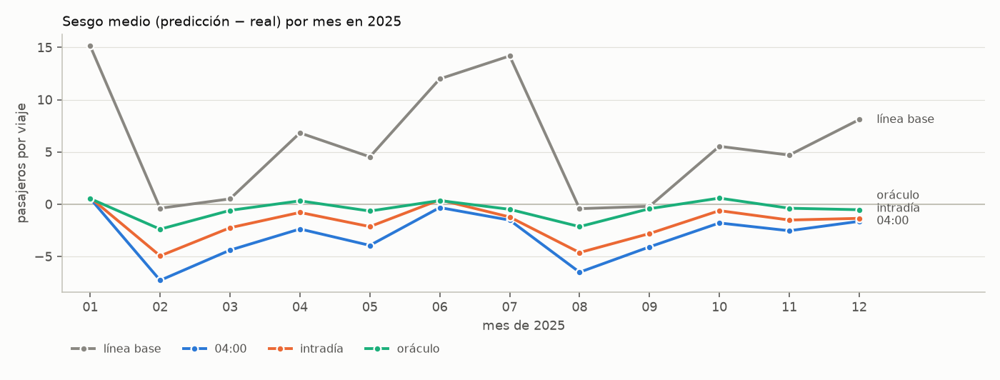

In [9]:
display(des[des.dimension == "mes"].pivot(index="grupo", columns="config", values="sesgo_medio").round(2))
display(des[des.dimension == "tipo_dia_cal"].pivot(index="grupo", columns="config", values="sesgo_medio").round(2))
cols_st = [c for c in M.columnas("modelo_0400") if c not in E.columnas_totales(M.columnas("modelo_0400"))]
bst, nst = E.entrenar_final(t, "modelo_0400", params["modelo_0400"], decision["modelos"]["modelo_0400"], NUM_THREADS,
                            cols=cols_st, tope=TOPE)
pst = bst.predict(ho[cols_st], num_iteration=nst)
y25 = ho.numeropasajeros.to_numpy(float)
mes = ho.fechasalida.dt.strftime("%Y-%m").to_numpy()
riesgo = pd.DataFrame([{"config": "modelo_0400", **V.metricas(y25, preds["modelo_0400"])},
                       {"config": "modelo_0400 sin totales (informativo)", "columnas": len(cols_st), **V.metricas(y25, pst)}])
riesgo.to_csv(SALIDA / "riesgo_totales_2025_7_3.csv", index=False)
display(riesgo.round(4))
display(pd.DataFrame({"con totales": pd.Series(preds["modelo_0400"] - y25).groupby(mes).mean(),
                      "sin totales": pd.Series(pst - y25).groupby(mes).mean()}).round(2).T)
E.fig_por_mes(des, "sesgo_medio", FIG / "sesgo_por_mes_2025.png", "Sesgo medio (predicción − real) por mes en 2025",
              "pasajeros por viaje", cero=True)
display(Image(filename=str(FIG / "sesgo_por_mes_2025.png")))

**Conclusión 7 · Riesgos de CLAUDE.md medidos en 2025**
- **§11.9 · cierres tardíos:** sin las features de totales, el modelo empeora en 2025 (2,527 frente a 2,503; +1,0 %) y el sesgo casi no cambia (−2,93 frente a −2,97).
  - **Las features de totales siguen aportando, y la subpredicción no viene de ellas.**
  - Se mantienen.
- **§11.12 · carnaval: el riesgo de la 7.2 no se repite en 2025.**
  - El modelo 04:00 **subpredice** −3,0 pasajeros por viaje en carnaval (826 viajes), cuando en la CV 2024 sobrepredecía +5,9.
  - La devianza mejora un 32,1 %.
  - Se corrige el riesgo §11.12: el sesgo de carnaval cambia de signo entre años, porque hay solo ~4 días por año.
- **§5.11 · tendencia:**
  - La línea base sobrepredice todo el año (+5,96 de media; hasta +15,1 en enero), porque no tiene tendencia.
  - El modelo 04:00 corrige ese exceso, pero se pasa al otro lado: subpredice en 11 de 12 meses (de −0,3 a −7,3).
  - El sesgo sistemático es ahora negativo: **−2,97 pasajeros por viaje**.
- **Pendientes para el Módulo 8 (residuos):** franja 04–06 h (−12,2), domingos (+10,0) y febrero/agosto.
- **Precisión (8.1):** el sesgo de −2,97 no es uniforme. El modelo 04:00 subpredice de lunes a viernes (+4,2 a +8,3 pasajeros por viaje) y sobrepredice el domingo (−9,6): comprime el contraste semanal (domingo/laboral predicho 0,842 frente a 0,671 real). Ver la 8.1, conclusión 5.

## 8 · Pruebas (a–f) y checks

In [10]:
pruebas = T.correr_todos(X, s)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min con {NUM_THREADS} hilos", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_7_3.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Test a · regla de rondas anidada sin leakage,PASS,"alterar el pliegue k y posteriores no cambia la regla de k · modelo_0400: P2=283, P3=311, P4=339, P5=311, P6=339 · m..."
1,Test b · el modelo final no ve 2025,PASS,"324.508 viajes de entrenamiento: última salida 2024-12-31 18:40:00, último cierre 2024-12-31 21:53:44 (≤ 2025-01-01 ..."
2,Test c · parámetros de la 7.2 y decisión antes del holdout,PASS,hash 428a3fb5f20d… idéntico en la decisión y en los 3 modelos; decisión escrita antes de holdout_7_3.csv
3,Test d · determinismo del modelo final,PASS,158.507 predicciones idénticas en dos entrenamientos finales
4,Test e · columnas exactas por modelo,PASS,"modelo_0400: 33 columnas, 311 árboles; modelo_intradia: 45 columnas, 649 árboles; modelo_oraculo: 53 columnas, 461 á..."
5,Test f · predicciones del holdout completas,PASS,"158.507 filas por modelo, sin NaN, todas > 0; el modelo 04:00 guardado reproduce sus predicciones"


,check,resultado,detalle
0,Decisión de rondas · modelo_0400,INFO,rondas_fijas (311); 4/5 pliegues
1,Decisión de rondas · modelo_intradia,INFO,rondas_fijas (649); 5/5 pliegues
2,Decisión de rondas · modelo_oraculo,INFO,rondas_fijas (461); 5/5 pliegues
3,Criterio de aceptación en 2025: modelo_0400 mejora la línea base (global y ≥ 10/12 meses),PASS,mejora global 14.5 %; 11/12 meses
4,Sobreajuste · modelo_0400,INFO,holdout/ajuste = 1.24; mejora 2025 14.5 % vs peor pliegue CV 9.8 %
5,Sobreajuste · modelo_intradia,INFO,holdout/ajuste = 1.30; mejora 2025 17.9 % vs peor pliegue CV 8.6 %
6,Sobreajuste · modelo_oraculo,INFO,holdout/ajuste = 1.26; mejora 2025 24.1 % vs peor pliegue CV 18.9 %
7,Test a · regla de rondas anidada sin leakage,PASS,"alterar el pliegue k y posteriores no cambia la regla de k · modelo_0400: P2=283, P3=311, P4=339, P5=311, P6=339 · m..."
8,Test b · el modelo final no ve 2025,PASS,"324.508 viajes de entrenamiento: última salida 2024-12-31 18:40:00, último cierre 2024-12-31 21:53:44 (≤ 2025-01-01 ..."
9,Test c · parámetros de la 7.2 y decisión antes del holdout,PASS,hash 428a3fb5f20d… idéntico en la decisión y en los 3 modelos; decisión escrita antes de holdout_7_3.csv


PASS 7 · FAIL 0 · INFO 7


**Conclusión 8 · Cierre del Módulo 7**
- **Pasan las 6 de 6 pruebas:**
  - **a)** la regla de rondas es anidada y no tiene leakage;
  - **b)** el modelo final no ve 2025;
  - **c)** el hash de los parámetros se conserva y la decisión se escribió antes del holdout;
  - **d)** determinismo: 158.507 predicciones idénticas;
  - **e)** cada modelo tiene sus columnas exactas (33, 45 y 53) y sus árboles (311, 649 y 461);
  - **f)** predicciones completas.
- Criterio de aceptación en 2025: **PASS**. Ejecución: 7,0 min con 12 hilos.
- **Corrección a la 7.2:** la ganancia de la cascada intradía no era del 0,5 %.
  - Ese valor estaba deprimido por el early stopping, que en P4 cortó intradía en 87 árboles.
  - Con rondas fijas, intradía mejora un **1,7 %** sobre el modelo 04:00 en la CV (P2–P6) y un **3,9 %** en 2025.
  - Recupera el 26 % (CV) y el **34 %** (2025) de la brecha entre 04:00 y el oráculo.
  - **La cascada sí aporta.**
- **Insumos para el Módulo 8:**
  - `datos_7/predicciones_holdout_7_3.parquet`: y, más las predicciones de la línea base y de los 3 modelos para los 158.507 viajes.
  - `modelos_7_3/*.txt`: para SHAP (TreeSHAP).

<a id="m8"></a>

---

## A1.6 &middot; Módulo 8 · Diagnóstico, interpretabilidad y significancia

Diagnóstico fino de residuos (Ljung-Box, McLeod-Li, BDS), interpretabilidad con TreeSHAP y significancia estadística frente a las líneas base con Diebold-Mariano.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m8-1"></a>

### A1.6.1 &middot; Subfase 8.1 · Diagnóstico fino de residuos

<sub>Notebook original: `subfase_8_1_residuos.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 8.1 — Diagnóstico fino de residuos (Ljung-Box, McLeod-Li, BDS)

**Persona 3 · MLOps & Model Evaluation.** Diagnostica los residuos del holdout 2025 de los modelos finales de la 7.3 (y de la línea base, como contraste). **No reentrena ni corrige nada**: 2025 ya se usó para evaluar; cualquier propuesta queda para el Entregable 2.

| Elemento | Decisión |
|---|---|
| Insumo | `datos_7/predicciones_holdout_7_3.parquet` (158.507 viajes de 2025) + covariables de `validacion_7_1.cargar()` solo para desgloses |
| Residuos | crudo e = y − ŷ (pasajeros), de Pearson r = (y − ŷ)/√ŷ^1,3 y de devianza (p = 1,3, la de la métrica, para comparar modelos) |
| Escalas | **Diaria** por ruta (365 días × 3, equiespaciada) y **por viaje** (por ruta, ordenados por salida; también solo dentro de cada día) |
| Tests | Ljung-Box (autocorrelación), McLeod-Li (Ljung-Box sobre r²: volatilidad agrupada), BDS (dependencia no lineal, tras filtrar un AR(k) por AIC) |
| Criterio | Con n grande todo es «significativo»: se decide por **magnitud**. \|ρ\| ≥ 0,10 relevante; 0,05–0,10 débil. En tests por bloques, proporción de bloques que rechazan con Benjamini-Hochberg |
| Implementación | numpy + `scipy.stats`; verificada contra statsmodels (Ljung-Box, ACF, PACF y BDS idénticos) en `tests_8_1.py` |

**Parte 1 (extracción RDS): no aplica.**

## Parte 2 · Análisis offline

In [1]:
import json
import platform
import time
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import Image, display

import residuos_8_1 as R
import tests_8_1 as T
import validacion_7_1 as V

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_8"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_8_1"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


T0 = time.time()
HASH_ANTES = T.hashes()
X = V.cargar()
d = R.cargar_residuos(X)
cols = ["idprogramacion", "idruta", "fechasalida", "fecha", "tipo_dia_cal", "dia_semana", "hora", "y"] + \
       [f"{k}_{c}" for c in R.CONFIGS for k in ("pred", "e", "r", "rd", "dev")]
d[cols].to_parquet(SALIDA / "residuos_8_1.parquet", index=False)
print(f"Python {platform.python_version()} · pandas {pd.__version__} · statsmodels para verificar: {T.HAY_SM}")
print(f"{len(d):,} viajes de 2025 · por ruta: {d.groupby('idruta').size().to_dict()} · días: {d.fecha.nunique()}")

Python 3.9.25 · pandas 2.3.3 · statsmodels para verificar: True
158,507 viajes de 2025 · por ruta: {2: 44910, 16: 85558, 21: 28039} · días: 365


## 1 · Residuos, función de varianza y calibración

,config,residuo medio e (pas.),sesgo ŷ − y,MAE,φ = media(r²),devianza media
0,linea_base,-5.955,5.955,23.485,2.618,2.929
1,modelo_0400,2.971,-2.971,20.706,2.642,2.503
2,modelo_intradia,1.754,-1.754,20.380,2.470,2.406
3,modelo_oraculo,0.478,-0.478,19.670,2.216,2.222


media_pred                                               media_y                                                 sesgo                                                   phi              \
config linea_base modelo_0400 modelo_intradia modelo_oraculo linea_base modelo_0400 modelo_intradia modelo_oraculo linea_base modelo_0400 modelo_intradia modelo_oraculo linea_base modelo_0400   
decil                                                                                                                                                                                             
0           49.99       42.15           43.13          42.31      45.86       44.15           43.43          41.66       4.14       -2.00           -0.30           0.65       2.47        3.29   
1           59.99       54.03           55.01          54.57      56.07       57.22           56.63          54.17       3.92       -3.19           -1.62           0.41       2.45        3.34   
2           70.23       62.59           63.13          62.26      65.89       62.60           62.11          62.21       4.35       -0.01            1.02           0.04       2.88        3.05   
3           82.76       69.46           69.85          69.81      75.67       70.18           70.55          69.87       7.09       -0.72           -0.70          -0.06       2.84        2.79   
4           87.73       75.35           75.98          76.88      80.51       77.06           76.45          77.54       7.23       -1.70           -0.46          -0.66       2.88        2.63   
5           92.37       80.90           81.87          83.60      86.24       84.02           83.92          84.33       6.13       -3.12           -2.05          -0.74       3.02        2.58   
6           97.39       86.48           87.93          90.43      91.89       90.69           91.17          91.51       5.50       -4.21           -3.24          -1.08       2.75        2.44   
7          102.75       92.49           94.39          97.50      97.01       98.20           98.25          98.57       5.74       -5.71           -3.85          -1.07       2.56        2.31   
8          107.90       99.38          101.69         105.18     101.69      104.90          105.64         106.72       6.21       -5.52           -3.94          -1.54       2.20        2.12   
9          116.10      113.82          115.81         119.03     106.86      117.34          118.21         119.77       9.24       -3.52           -2.40          -0.75       2.08        1.87   

                                       
config modelo_intradia modelo_oraculo  
decil                                  
0                 2.84           2.35  
1                 3.09           2.38  
2                 2.79           2.58  
3                 2.70           2.51  
4                 2.57           2.41  
5                 2.41           2.33  
6                 2.33           2.17  
7                 2.17           1.90  
8                 2.02           1.89  
9                 1.77           1.64

,p empírico de la varianza residual (pendiente log-log)
linea_base,1.175
modelo_0400,0.668
modelo_intradia,0.749
modelo_oraculo,0.943


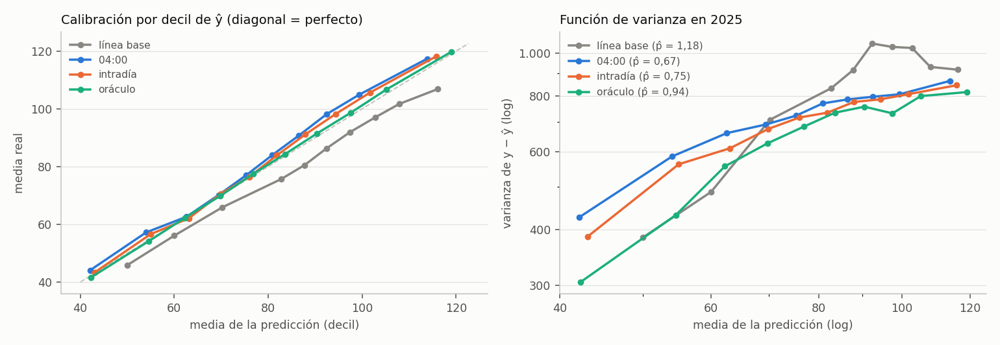

In [2]:
res = pd.DataFrame([{"config": c, "residuo medio e (pas.)": d[f"e_{c}"].mean(), "sesgo ŷ − y": -d[f"e_{c}"].mean(),
                     "MAE": d[f"e_{c}"].abs().mean(), "φ = media(r²)": float(np.mean(d[f"r_{c}"] ** 2)),
                     "devianza media": d[f"dev_{c}"].mean()} for c in R.CONFIGS])
display(res.round(3))
var, pend = [], {}
for c in R.CONFIGS:
    t, p = R.funcion_varianza(d, c)
    var.append(t); pend[c] = p
var = pd.concat(var, ignore_index=True)
var.to_csv(SALIDA / "varianza_calibracion_8_1.csv", index=False)
display(var.pivot(index="decil", columns="config", values=["media_pred", "media_y", "sesgo", "phi"]).round(2))
display(pd.Series(pend, name="p empírico de la varianza residual (pendiente log-log)").round(3).to_frame())
R.fig_calibracion(var, pend, FIG / "calibracion_varianza.png")
display(Image(filename=str(FIG / "calibracion_varianza.png")))

**Conclusión 1 · Residuos, varianza y calibración**
- **Residuo medio (real − predicho, pasajeros por viaje):**

  | Modelo | Residuo medio | φ = media(r²) | Lectura |
  |---|---:|---:|---|
  | Línea base | −5,96 | 2,62 | sobrepredice |
  | 04:00 | **+2,97** | 2,64 | subpredice |
  | Intradía | +1,75 | 2,47 | subpredice |
  | Oráculo | +0,48 | 2,22 | casi sin sesgo |

- **Calibración (por decil de la predicción):**
  - El modelo 04:00 **subpredice en 9 de 10 deciles**, sobre todo con ŷ de 86 a 114 (sesgo ŷ − y de −3,5 a −5,7).
  - La línea base sobrepredice en todos los deciles (+3,9 a +9,2) y su curva es más plana: discrimina menos.
  - El oráculo está calibrado: |sesgo| ≤ 1,5.
- **Función de varianza:**
  - En el modelo 04:00, φ baja de 3,29 (decil más bajo) a 1,87 (más alto).
  - p empírico de la varianza residual: 0,67 (04:00), 0,75 (intradía) y 0,94 (oráculo), frente a 1,18 de la línea base.
  - La varianza de los errores crece más despacio que μ^1,3: los errores relativos pesan más en los viajes de baja demanda.
  - La métrica no cambia (p = 1,3 fijo).

## 2 · Autocorrelación lineal — Ljung-Box

**Escala diaria:** residuo de Pearson medio por ruta × día (365 días; sin días vacíos). **Escala de viaje:** por ruta, viajes ordenados por salida (serie completa), y la ACF solo **dentro del mismo día** (Box-Pierce agrupado). Además, el residuo **intradía** = r − media de su ruta × día, que quita el componente común del día y deja solo los shocks entre viajes.

diaria


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.627        0.420            0.340           0.278
       7            0.438        0.549            0.432           0.222
       14           0.328        0.527            0.418           0.161
       28           0.114        0.426            0.337           0.086
16     1            0.603        0.298            0.254           0.274
       7            0.307        0.656            0.660           0.429
       14           0.246        0.649            0.670           0.489
       28           0.041        0.568            0.596           0.359
21     1            0.549        0.408            0.350           0.302
       7            0.305        0.504            0.399           0.214
       14           0.273        0.497            0.395           0.246
       28           0.157        0.472            0.392           0.251

viaje (serie completa)


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.217        0.139            0.105           0.022
       5            0.129        0.113            0.080           0.006
       10           0.086        0.088            0.059           0.008
       20           0.047        0.042            0.025           0.007
16     1            0.284        0.253            0.241           0.162
       5            0.120        0.109            0.092          -0.023
       10           0.107        0.119            0.101           0.015
       20           0.066        0.088            0.074           0.008
21     1            0.110        0.032            0.012          -0.064
       5            0.067        0.096            0.079           0.019
       10           0.037        0.054            0.040           0.009
       20           0.061        0.041            0.028           0.013

viaje (dentro del día)


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.218        0.142            0.107           0.023
       5            0.137        0.123            0.089           0.007
       10           0.094        0.109            0.077           0.012
       20           0.048        0.067            0.045           0.008
16     1            0.285        0.255            0.243           0.163
       5            0.126        0.114            0.097          -0.022
       10           0.113        0.127            0.109           0.015
       20           0.075        0.105            0.089           0.010
21     1            0.113        0.035            0.015          -0.064
       5            0.078        0.111            0.092           0.025
       10           0.036        0.070            0.054           0.009
       20           0.081        0.063            0.050           0.020

viaje intradía (sin media del día)


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.145        0.084            0.067           0.009
       5            0.053        0.064            0.049          -0.008
       10           0.006        0.050            0.037          -0.002
       20          -0.046        0.007            0.005          -0.006
16     1            0.227        0.191            0.190           0.150
       5            0.055        0.037            0.032          -0.040
       10           0.040        0.050            0.044          -0.001
       20          -0.002        0.027            0.022          -0.007
21     1            0.046       -0.033           -0.036          -0.088
       5            0.007        0.047            0.045           0.002
       10          -0.038        0.003            0.005          -0.013
       20           0.010        0.002            0.005          -0.001

p-valores de la escala diaria (Ljung-Box):


config        linea_base modelo_0400 modelo_intradia modelo_oraculo
idruta rezago                                                      
2      1         2.8e-33     8.4e-16         6.7e-11        9.4e-08
       7         8.6e-94     2.0e-40         7.5e-24        1.3e-12
       14       7.3e-138     4.9e-68         6.0e-37        1.3e-11
       28       8.7e-159    3.4e-121         2.6e-67        3.2e-11
16     1         5.4e-31     1.1e-08         1.1e-06        1.4e-07
       7         6.7e-94     4.6e-46         8.6e-45        7.7e-21
       14       1.3e-125     1.4e-87         8.6e-88        4.6e-38
       28       2.8e-131    2.0e-166        7.2e-168        2.7e-60
21     1         5.6e-26     4.7e-15         1.9e-11        6.7e-09
       7         4.6e-69     7.2e-35         1.1e-21        1.1e-10
       14        1.5e-94     8.6e-60         9.3e-35        2.5e-13
       28       1.8e-103    6.6e-115         5.5e-66        1.1e-20

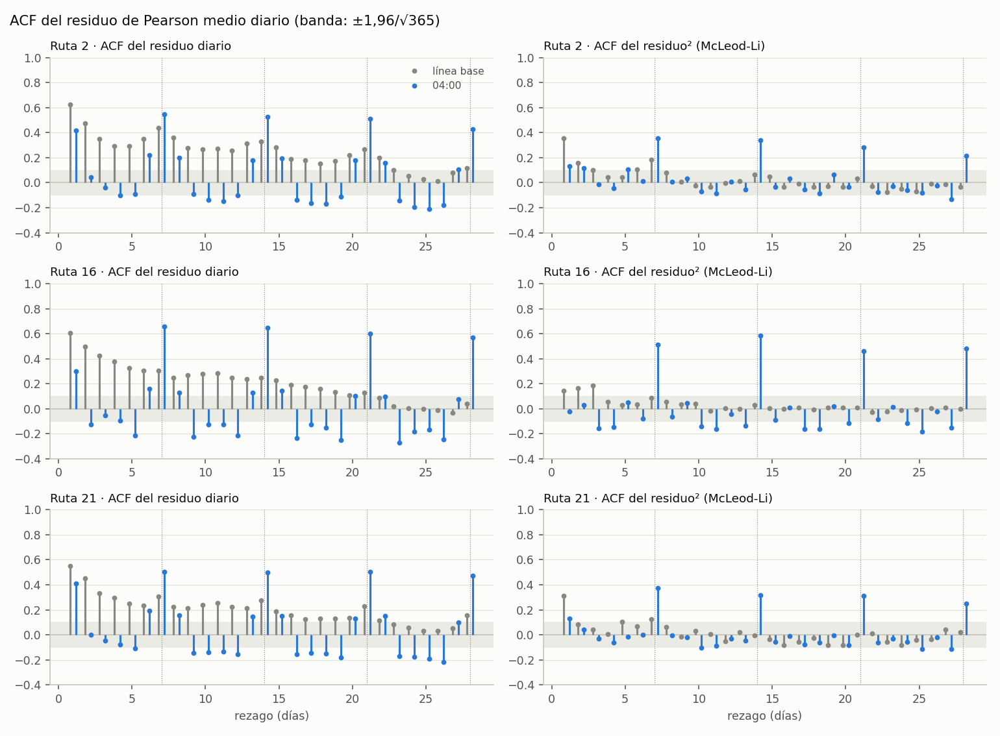

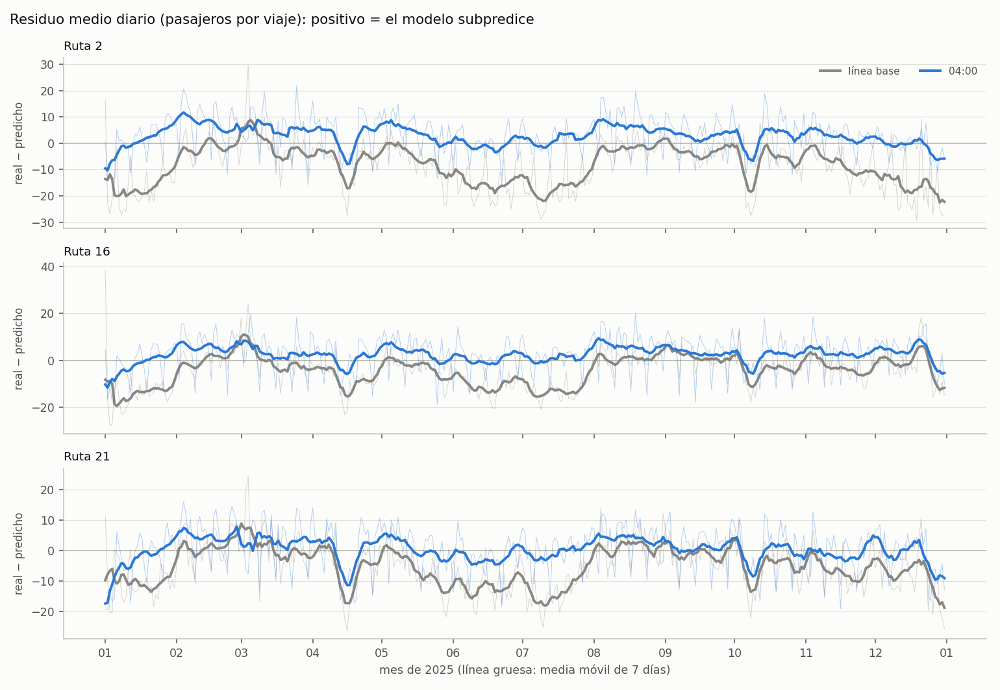

In [3]:
LAGS_D, LAGS_V = [1, 7, 14, 28], [1, 5, 10, 20]
lb, acfs = [], {}
for c in R.CONFIGS:
    sd = R.serie_diaria(d, f"r_{c}")
    for rt, g in sd.groupby("idruta"):
        x = g[f"r_{c}"].to_numpy()
        acfs.setdefault(rt, {})[f"acf_{c}"] = R.acf(x, 28)
        acfs[rt][f"acf2_{c}"] = R.acf((x - x.mean()) ** 2, 28)
        lb.append(R.ljung_box(x, LAGS_D).assign(config=c, idruta=rt, escala="diaria"))
for c in R.CONFIGS:
    for rt, g in d.groupby("idruta"):
        x = g[f"r_{c}"].to_numpy()
        dia = (g.idruta.astype(str) + "_" + g.fecha.astype(str)).to_numpy()
        intradia = x - pd.Series(x).groupby(dia).transform("mean").to_numpy()
        lb.append(R.ljung_box(x, LAGS_V).assign(config=c, idruta=rt, escala="viaje (serie completa)"))
        lb.append(R.box_pierce_agrupado(x, dia, LAGS_V).assign(config=c, idruta=rt, escala="viaje (dentro del día)"))
        lb.append(R.box_pierce_agrupado(intradia, dia, LAGS_V).assign(config=c, idruta=rt, escala="viaje intradía (sin media del día)"))
lb = pd.concat(lb, ignore_index=True)
lb["magnitud_rho_h"] = lb.rho_h.map(R.magnitud)
lb.to_csv(SALIDA / "ljungbox_8_1.csv", index=False)
for esc in lb.escala.unique():
    print(esc)
    display(lb[lb.escala == esc].pivot_table(index=["idruta", "rezago"], columns="config", values="rho_h").round(3))
print("p-valores de la escala diaria (Ljung-Box):")
display(lb[lb.escala == "diaria"].pivot_table(index=["idruta", "rezago"], columns="config", values="p_valor").map(lambda p: f"{p:.1e}"))
n_dias = 365
R.fig_acf_diaria(acfs, n_dias, FIG / "acf_residuo_diario.png", "ACF del residuo de Pearson medio diario (banda: ±1,96/√365)")
display(Image(filename=str(FIG / "acf_residuo_diario.png")))
diario_e = pd.concat([R.serie_diaria(d, f"e_{c}").set_index(["idruta", "fecha"]) for c in R.CONFIGS], axis=1).reset_index()
R.fig_residuo_diario(diario_e, FIG / "residuo_diario_2025.png")
display(Image(filename=str(FIG / "residuo_diario_2025.png")))

**Conclusión 2 · Autocorrelación (Ljung-Box)**
- **Todos los tests rechazan** (p < 1e-8 en la escala diaria), así que se lee la magnitud.
- **Persistencia del nivel (rezago de 1 día):** el modelo 04:00 la reduce de 0,55–0,63 (línea base) a **0,30–0,42**. Sigue siendo relevante: queda un nivel que dura varios días (*drift*).
- **Patrón semanal (rezago de 7 días):**
  - El modelo 04:00 lo **aumenta**: de 0,31–0,44 en la línea base a **0,50–0,66**.
  - Se repite en 14 y 28 días (0,43–0,65).
  - El modelo deja un error que se repite cada semana, el mismo día de la semana.
  - El oráculo lo reduce a 0,21–0,43.
- **Por viaje:**
  - ACF entre viajes consecutivos: 0,14 (ruta 2), 0,25 (ruta 16) y 0,03 (ruta 21). Es casi igual si solo se miran pares del mismo día.
  - Al quitar la media de cada ruta × día queda 0,08 / **0,19** / −0,03.
  - La correlación entre viajes es sobre todo el componente común del día. Solo en la ruta 16 quedan shocks propios entre viajes seguidos.

## 3 · Volatilidad agrupada — McLeod-Li y dispersión por segmento

In [4]:
ml = []
for c in R.CONFIGS:
    sd = R.serie_diaria(d, f"r_{c}")
    for rt, g in sd.groupby("idruta"):
        ml.append(R.mcleod_li(g[f"r_{c}"].to_numpy(), LAGS_D).assign(config=c, idruta=rt, escala="diaria"))
    for rt, g in d.groupby("idruta"):
        x = g[f"r_{c}"].to_numpy()
        dia = (g.idruta.astype(str) + "_" + g.fecha.astype(str)).to_numpy()
        intradia = x - pd.Series(x).groupby(dia).transform("mean").to_numpy()
        ml.append(R.mcleod_li(x, LAGS_V).assign(config=c, idruta=rt, escala="viaje (serie completa)"))
        r2 = (intradia - intradia.mean()) ** 2
        ml.append(R.box_pierce_agrupado(r2, dia, LAGS_V).assign(config=c, idruta=rt, escala="viaje intradía (sin media del día)"))
ml = pd.concat(ml, ignore_index=True)
ml["magnitud_rho_h"] = ml.rho_h.map(R.magnitud)
ml.to_csv(SALIDA / "mcleodli_8_1.csv", index=False)
for esc in ml.escala.unique():
    print(esc)
    display(ml[ml.escala == esc].pivot_table(index=["idruta", "rezago"], columns="config", values="rho_h").round(3))
franja = pd.cut(d.hora, [3, 6, 9, 12, 15, 18, 21], labels=["04–06", "07–09", "10–12", "13–15", "16–18", "19–20"])
disp = []
for nom, g in [("franja", franja.astype(str)), ("tipo_dia_cal", d.tipo_dia_cal.astype(str)),
               ("mes", d.fechasalida.dt.strftime("%m")), ("idruta", d.idruta.astype(str))]:
    for c in ["linea_base", "modelo_0400"]:
        t = (d[f"r_{c}"] ** 2).groupby(g.to_numpy()).mean()
        disp.append(pd.DataFrame({"dimension": nom, "grupo": t.index, "config": c, "phi": t.values}))
disp = pd.concat(disp, ignore_index=True)
display(disp.pivot_table(index=["dimension", "grupo"], columns="config", values="phi").round(2))

diaria


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.356        0.130            0.160           0.057
       7            0.185        0.353            0.275           0.054
       14           0.062        0.340            0.253           0.010
       28          -0.034        0.216            0.138           0.049
16     1            0.146       -0.022           -0.047           0.046
       7            0.086        0.513            0.548           0.287
       14           0.030        0.583            0.657           0.465
       28          -0.001        0.479            0.581           0.388
21     1            0.314        0.132            0.139           0.071
       7            0.123        0.373            0.232           0.077
       14          -0.003        0.319            0.208           0.063
       28           0.019        0.249            0.138           0.038

viaje (serie completa)


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.090        0.074            0.068           0.048
       5            0.031        0.049            0.043           0.015
       10           0.008        0.022            0.013           0.001
       20          -0.008       -0.022           -0.021          -0.018
16     1            0.180        0.079            0.086           0.090
       5            0.060        0.037            0.029           0.012
       10           0.045        0.036            0.022           0.010
       20           0.034        0.021            0.019           0.009
21     1            0.122        0.073            0.071           0.066
       5            0.051        0.083            0.081           0.058
       10           0.014        0.010            0.005           0.001
       20           0.006       -0.010           -0.005          -0.004

viaje intradía (sin media del día)


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.091        0.066            0.062           0.047
       5            0.033        0.044            0.040           0.018
       10           0.010        0.022            0.014           0.004
       20          -0.001       -0.007           -0.008          -0.012
16     1            0.154        0.080            0.089           0.091
       5            0.052        0.033            0.028           0.013
       10           0.038        0.029            0.020           0.010
       20           0.022        0.017            0.015           0.006
21     1            0.127        0.084            0.081           0.077
       5            0.046        0.085            0.084           0.061
       10           0.012        0.015            0.011           0.004
       20           0.009       -0.001            0.004          -0.000

config                 linea_base  modelo_0400
dimension    grupo                            
franja       04–06           3.05         4.28
             07–09           2.38         2.13
             10–12           2.75         2.42
             13–15           2.20         2.00
             16–18           2.63         2.29
             19–20           2.68         2.07
idruta       16              2.39         2.42
             2               2.96         3.07
             21              2.76         2.65
mes          01              2.64         2.49
             02              2.44         2.92
             03              2.47         2.58
             04              2.49         2.71
             05              2.47         2.59
             06              2.59         2.50
             07              2.67         2.45
             08              2.61         2.95
             09              2.61         2.66
             10              2.70         2.72
             11              2.49         2.59
             12              3.26         2.55
tipo_dia_cal carnaval        4.06         2.43
             domingo         2.07         1.95
             festivo         2.06         1.94
             laboral         2.68         2.83
             sabado          2.72         2.30

**Conclusión 3 · Volatilidad (McLeod-Li)**
- **Volatilidad semanal:** los errores grandes se repiten el mismo día de la semana.
  - ACF de r² diario a 7 días: **0,35–0,51** en el modelo 04:00, frente a 0,09–0,19 en la línea base.
  - A 1 día es baja: −0,02 a 0,13.
- **Por viaje:** la volatilidad agrupada es débil (0,07–0,08 a 1 viaje).
- **Dispersión φ del modelo 04:00 por segmento:**
  - **Franja 04–06 h: 4,28**, frente a 3,05 de la línea base. Es la única franja donde el modelo dispersa más que la línea base.
  - Laboral 2,83 (línea base 2,68).
  - Febrero 2,92 y agosto 2,95: los meses más dispersos.
  - Mejora frente a la línea base en carnaval (2,43 frente a 4,06) y en diciembre (2,55 frente a 3,26).

## 4 · Dependencia no lineal — BDS

Primero se quita la dependencia **lineal** con un AR(k), k ≤ 7 por AIC (incluye el rezago semanal); el BDS sobre esos residuos filtrados detecta dependencia **no lineal**. ε = 0,5 y 1,0 desviaciones estándar; m = 2–5. Escala diaria por ruta (n = 365) y por viaje en bloques consecutivos de 2.000 viajes por ruta (con Benjamini-Hochberg).

In [5]:
bd = []
for c in R.CONFIGS:
    sd = R.serie_diaria(d, f"r_{c}")
    for rt, g in sd.groupby("idruta"):
        x = g[f"r_{c}"].to_numpy()
        k, _, filt = R.ar_filtrar(x, 7)
        for dist in (0.5, 1.0):
            bd.append(R.bds(x, 5, dist).assign(config=c, idruta=rt, escala="diaria", filtro="sin filtrar", k_ar=0))
            bd.append(R.bds(filt, 5, dist).assign(config=c, idruta=rt, escala="diaria", filtro=f"AR({k})", k_ar=k))
bd = pd.concat(bd, ignore_index=True)
display(bd[bd.distancia == 1.0].pivot_table(index=["idruta", "filtro", "m"], columns="config", values="estadistico").round(2))
bloq = []
for c in R.CONFIGS:
    for rt, g in d.groupby("idruta"):
        for i, b in enumerate(R.bloques(g[f"r_{c}"].to_numpy(), 2000)):
            k, _, filt = R.ar_filtrar(b, 7)
            t = R.bds(filt, 5, 1.0)
            bloq.append(t.assign(config=c, idruta=rt, bloque=i, k_ar=k))
bloq = pd.concat(bloq, ignore_index=True)
bloq["rechaza_BH"] = False
for (c, m), idx in bloq.groupby(["config", "m"]).groups.items():
    bloq.loc[idx, "rechaza_BH"] = R.bh(bloq.loc[idx, "p_valor"].to_numpy())
pd.concat([bd, bloq.assign(escala="viaje (bloques de 2.000, AR filtrado)", filtro="AR por bloque", distancia=1.0)],
          ignore_index=True).to_csv(SALIDA / "bds_8_1.csv", index=False)
res_b = bloq.groupby(["config", "m"]).agg(bloques=("bloque", "size"), rechazan_BH=("rechaza_BH", "mean"),
                                          z_mediana=("estadistico", "median")).reset_index()
display(res_b.pivot(index="m", columns="config", values=["rechazan_BH", "z_mediana"]).round(2))

config                linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta filtro      m                                                          
2      AR(7)       2        4.40         5.91             4.24            2.30
                   3        5.51         6.22             4.92            3.02
                   4        5.96         5.54             4.47            2.80
                   5        5.60         4.76             4.02            2.71
       sin filtrar 2       35.24        14.01            11.59            4.69
                   3       41.45        15.09            12.21            5.33
                   4       47.27        15.06            10.94            5.10
                   5       54.25        15.47             9.79            4.63
16     AR(3)       2        5.05          NaN              NaN             NaN
                   3        4.38          NaN              NaN             NaN
                   4        3.87          NaN              NaN             NaN
                   5        3.72          NaN              NaN             NaN
       AR(7)       2         NaN         3.75             3.35            2.90
                   3         NaN         3.95             3.32            2.71
                   4         NaN         3.92             3.06            2.44
                   5         NaN         3.83             2.74            2.41
       sin filtrar 2       26.11         5.91             5.89            5.76
                   3       30.32         6.77             6.60            4.93
                   4       33.06         5.53             5.38            3.39
                   5       36.21         5.11             4.67            2.16
21     AR(7)       2        1.81         5.14             3.84            2.72
                   3        1.16         5.10             3.77            2.67
                   4        0.69         4.82             3.84            2.95
                   5        0.38         4.24             3.41            2.75
       sin filtrar 2       16.86        12.81            10.50            5.34
                   3       19.42        13.74            10.75            5.33
                   4       20.02        13.28             9.85            5.05
                   5       20.34        13.04             8.65            3.94

rechazan_BH                                             z_mediana                                           
config  linea_base modelo_0400 modelo_intradia modelo_oraculo linea_base modelo_0400 modelo_intradia modelo_oraculo
m                                                                                                                  
2             0.85        0.83            0.81           0.74       4.15        3.43            3.44           2.95
3             0.90        0.85            0.82           0.74       5.08        4.13            3.94           3.60
4             0.91        0.87            0.88           0.76       5.59        4.38            4.19           3.47
5             0.95        0.88            0.87           0.74       5.89        4.24            4.15           3.45

**Conclusión 4 · Dependencia no lineal (BDS)**
- **Sin filtrar:** todo rechaza (z = 2,2–54), dominado por la dependencia lineal de las conclusiones 2 y 3.
- **Tras filtrar un AR(k)** (k = 7 por AIC en los modelos, que incluye el rezago semanal):
  - Escala diaria:
    - el modelo 04:00 sigue rechazando la independencia (z = 3,8–6,2 en m = 2–5);
    - el oráculo queda en 2,3–3,0;
    - la línea base de la ruta 21 no rechaza (z = 0,4–1,8).
  - Por viaje, en bloques de 2.000, rechazan con BH:
    - 83–88 % de los bloques en el modelo 04:00;
    - 74–76 % en el oráculo;
    - 85–95 % en la línea base.
- **Interpretación:**
  - El BDS también es sensible a la **heterocedasticidad condicional**, y McLeod-Li ya mostró volatilidad semanal y por franja.
  - El rechazo es coherente con dependencia en la **varianza** de los errores, no necesariamente con no linealidad en la media: los árboles ya modelan las no linealidades de las covariables.
  - Lo que queda son errores que no son independientes en el tiempo.

## 5 · Dónde está la estructura que queda

Residuo crudo medio (real − predicho, en pasajeros por viaje) por día de la semana, hora × tipo de día, headway y mes; contraste semanal real frente al predicho; y dos comprobaciones de la causa: ¿los rezagos conservan el contraste? ¿los cierres tardíos (§11.9) se reparten distinto por tipo de día?

,e_linea_base,e_modelo_0400,e_modelo_intradia,e_modelo_oraculo
dia_semana,,,,
lun,-4.97,5.17,4.11,1.46
mar,-6.13,8.30,5.99,1.71
mié,-7.04,5.01,3.52,0.82
jue,-7.15,4.47,2.74,0.82
vie,-6.54,4.17,2.64,1.18
sáb,-4.32,-1.51,-1.81,-0.52
dom,-4.96,-9.58,-8.91,-3.62


,y,linea_base,modelo_0400,modelo_intradia,modelo_oraculo
tipo_dia_cal,,,,,
carnaval,0.988,0.805,1.018,1.008,0.982
domingo,0.671,0.678,0.842,0.816,0.726
festivo,0.655,0.647,0.667,0.677,0.655
laboral,1.000,1.000,1.000,1.000,1.000
sabado,0.887,0.873,0.968,0.953,0.907


,tipo_dia_cal,sesgo ŷ − y en CV 2024 (7.2)
0,carnaval,5.88
1,domingo,1.70
2,festivo,1.75
3,laboral,0.20
4,sabado,0.91


tipo_dia_cal,carnaval,domingo,festivo,laboral,sabado
anio,,,,,
2023,1.11,1.06,1.04,1.08,1.17
2024,1.23,1.11,1.11,1.39,1.30
2025,2.18,4.91,4.56,5.59,5.77


,numeropasajeros,p_pas_por_salida_lag672,p_pas_por_salida_media4sem
tipo_dia_cal,,,
carnaval,84.47,84.250000,81.540001
domingo,57.36,58.400002,58.080002
festivo,56.04,85.540001,83.160004
laboral,85.54,86.599998,85.059998
sabado,75.85,78.589996,76.559998


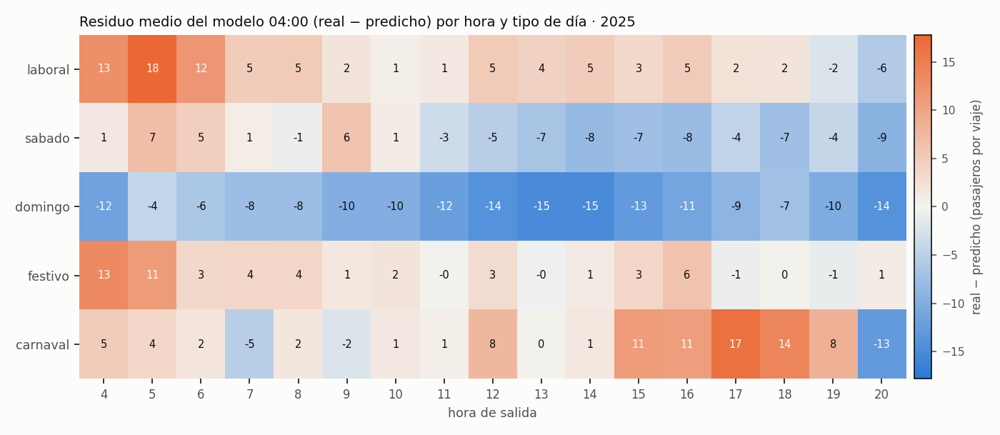

,e_linea_base,e_modelo_0400
headway_prev,,
"(-0.001, 2.0]",-11.22,12.41
"(2.0, 3.0]",-9.22,3.99
"(3.0, 4.0]",-2.45,1.76
"(4.0, 5.0]",-7.35,1.22
"(5.0, 6.0]",-10.26,1.44
"(6.0, 8.0]",-4.78,0.55
"(8.0, 10.0]",-4.35,1.46
"(10.0, 138.0]",6.84,-1.92


fechasalida,01,02,03,04,05,06,07,08,09,10,11,12
e_linea_base,-15.13,0.39,-0.51,-6.82,-4.53,-11.99,-14.18,0.43,0.20,-5.54,-4.70,-8.09
e_modelo_0400,-0.55,7.28,4.39,2.37,3.94,0.32,1.52,6.51,4.08,1.79,2.54,1.64
e_modelo_intradia,-0.63,4.94,2.25,0.79,2.14,-0.42,1.22,4.63,2.81,0.62,1.51,1.35
e_modelo_oraculo,-0.53,2.39,0.59,-0.32,0.65,-0.35,0.49,2.15,0.43,-0.58,0.39,0.53


In [6]:
dias = {0: "lun", 1: "mar", 2: "mié", 3: "jue", 4: "vie", 5: "sáb", 6: "dom"}
dsem = d.groupby(d.dia_semana.map(dias), sort=False)[[f"e_{c}" for c in R.CONFIGS]].mean().reindex(list(dias.values()))
display(dsem.round(2))
ratio = d.groupby("tipo_dia_cal")[["y"] + [f"pred_{c}" for c in R.CONFIGS]].mean()
ratio = (ratio / ratio.loc["laboral"]).round(3)
display(ratio.rename(columns=lambda c: c.replace("pred_", "")))
cv = pd.read_csv("datos_7/cv_7_2_por_tipo_dia.csv")
display(cv[cv.config == "modelo_0400"][["tipo_dia_cal", "sesgo_medio"]].rename(columns={"sesgo_medio": "sesgo ŷ − y en CV 2024 (7.2)"}).round(2))
X["anio"] = X.fechasalida.dt.year
X["cierre_tardio"] = (X.fechafin - X.fechasalida).dt.total_seconds() / 60 > 353.4
display((X.groupby(["anio", "tipo_dia_cal"]).cierre_tardio.mean() * 100).unstack().round(2))
x25 = X[X.anio == 2025]
display(x25.groupby("tipo_dia_cal")[["numeropasajeros", "p_pas_por_salida_lag672", "p_pas_por_salida_media4sem"]].mean().round(2))
mapa = d.groupby(["hora", "tipo_dia_cal"]).e_modelo_0400.mean().unstack()[["laboral", "sabado", "domingo", "festivo", "carnaval"]]
R.fig_mapa(mapa, FIG / "mapa_residuo_hora_tipodia.png", "Residuo medio del modelo 04:00 (real − predicho) por hora y tipo de día · 2025")
display(Image(filename=str(FIG / "mapa_residuo_hora_tipodia.png")))
hw = pd.qcut(d.headway_prev, 10, duplicates="drop")
display(d.groupby(hw)[["e_linea_base", "e_modelo_0400"]].mean().round(2))
display(d.groupby(d.fechasalida.dt.strftime("%m"))[[f"e_{c}" for c in R.CONFIGS]].mean().round(2).T)

In [7]:
estructura = pd.DataFrame([
    {"hallazgo": "Contraste semanal comprimido", "categoria": "(ii) patrón calendario",
     "evidencia": "residuo lun–vie +4,2 a +8,3 y dom −9,6 pas./viaje; ACF diaria en 7 días 0,50–0,66 (línea base 0,31–0,44); "
                  "dom/laboral predicho 0,842 vs real 0,671 (línea base 0,678); en la CV 2024 el sesgo era casi parejo (dom +1,70, laboral +0,20)",
     "recomendacion_entregable_2": "8.2: SHAP de dia_semana × tendencia_meses y headway. E2: tendencia relativa o sin tendencia_meses; "
                                   "modelar la razón y / rezago semanal por salida; validar en otro año"},
    {"hallazgo": "Nivel persistente (drift)", "categoria": "(i) sesgo de nivel",
     "evidencia": "ACF diaria en 1 día 0,30–0,42; subpredice en 11/12 meses (feb +7,3, ago +6,5 pas./viaje)",
     "recomendacion_entregable_2": "reentrenamiento o recalibración de nivel mensual con ventana deslizante; variable de calendario escolar"},
    {"hallazgo": "Madrugada de días laborales y festivos", "categoria": "(ii) patrón calendario",
     "evidencia": "laboral 04–06 h: +13, +18 y +12 pas./viaje; festivo 04–05 h: +13 y +11; φ de la franja 04–06 = 4,28 (línea base 3,05)",
     "recomendacion_entregable_2": "rezagos y medias específicos del primer despacho del día; revisar la serie de 15 min al inicio del servicio"},
    {"hallazgo": "Shocks entre viajes consecutivos", "categoria": "(iii) shocks intradía",
     "evidencia": "ACF intradía (sin media del día) en 1 viaje: ruta 16 = 0,19 (relevante), ruta 2 = 0,08, ruta 21 = −0,03; "
                  "la cascada no la reduce (0,19) y el oráculo sí en parte (0,15)",
     "recomendacion_entregable_2": "la información útil es la de los viajes recién cerrados (no desplegable a 1 h); evaluar un nowcast con conteos parciales en tiempo real"},
    {"hallazgo": "Headway muy corto subpredicho", "categoria": "(iii) operación",
     "evidencia": "headway_prev ≤ 2 min: +12,4 pas./viaje (línea base −11,2); 2–3 min: +4,0",
     "recomendacion_entregable_2": "8.2: dependencia parcial de headway; E2: usar en la evaluación el headway PLANEADO y revisar el efecto de los buses agrupados"},
    {"hallazgo": "Volatilidad con patrón semanal", "categoria": "heterocedasticidad",
     "evidencia": "McLeod-Li diario en 7 días: 0,35–0,51 (línea base 0,09–0,19); BDS rechaza tras filtrar el AR(k) (diario: z = 3,8–6,2 en m = 2–5; por viaje: 83–88 % de los bloques)",
     "recomendacion_entregable_2": "intervalos de predicción con dispersión por tipo de día y franja (φ dom 1,95, laboral 2,83, 04–06 h 4,28)"},
    {"hallazgo": "Varianza más plana que μ^1,3", "categoria": "función de varianza",
     "evidencia": "p empírico de la varianza residual 0,67 (04:00), 0,75 (intradía), 0,94 (oráculo); φ baja de 3,29 a 1,87 por decil",
     "recomendacion_entregable_2": "la métrica sigue fija (p = 1,3); re-estimar p sobre los residuos de la CV, no del holdout"},
])
estructura.to_csv(SALIDA / "estructura_residual_8_1.csv", index=False)
display(estructura)

,hallazgo,categoria,evidencia,recomendacion_entregable_2
0,Contraste semanal comprimido,(ii) patrón calendario,"residuo lun–vie +4,2 a +8,3 y dom −9,6 pas./viaje; ACF diaria en 7 días 0,50–0,66 (línea base 0,31–0,44); dom/labora...",8.2: SHAP de dia_semana × tendencia_meses y headway. E2: tendencia relativa o sin tendencia_meses; modelar la razón ...
1,Nivel persistente (drift),(i) sesgo de nivel,"ACF diaria en 1 día 0,30–0,42; subpredice en 11/12 meses (feb +7,3, ago +6,5 pas./viaje)",reentrenamiento o recalibración de nivel mensual con ventana deslizante; variable de calendario escolar
2,Madrugada de días laborales y festivos,(ii) patrón calendario,"laboral 04–06 h: +13, +18 y +12 pas./viaje; festivo 04–05 h: +13 y +11; φ de la franja 04–06 = 4,28 (línea base 3,05)",rezagos y medias específicos del primer despacho del día; revisar la serie de 15 min al inicio del servicio
3,Shocks entre viajes consecutivos,(iii) shocks intradía,"ACF intradía (sin media del día) en 1 viaje: ruta 16 = 0,19 (relevante), ruta 2 = 0,08, ruta 21 = −0,03; la cascada ...",la información útil es la de los viajes recién cerrados (no desplegable a 1 h); evaluar un nowcast con conteos parci...
4,Headway muy corto subpredicho,(iii) operación,"headway_prev ≤ 2 min: +12,4 pas./viaje (línea base −11,2); 2–3 min: +4,0",8.2: dependencia parcial de headway; E2: usar en la evaluación el headway PLANEADO y revisar el efecto de los buses ...
5,Volatilidad con patrón semanal,heterocedasticidad,"McLeod-Li diario en 7 días: 0,35–0,51 (línea base 0,09–0,19); BDS rechaza tras filtrar el AR(k) (diario: z = 3,8–6,2...","intervalos de predicción con dispersión por tipo de día y franja (φ dom 1,95, laboral 2,83, 04–06 h 4,28)"
6,"Varianza más plana que μ^1,3",función de varianza,"p empírico de la varianza residual 0,67 (04:00), 0,75 (intradía), 0,94 (oráculo); φ baja de 3,29 a 1,87 por decil","la métrica sigue fija (p = 1,3); re-estimar p sobre los residuos de la CV, no del holdout"


**Conclusión 5 · Estructura residual (dónde está y qué hacer en el Entregable 2)**
- **Hallazgo principal: el modelo 04:00 comprime el contraste semanal en 2025.**
  - Residuo de lunes a viernes: +4,2 a +8,3 pasajeros por viaje. Sábado −1,5 y **domingo −9,6**.
  - Razón domingo/laboral: real 0,671, línea base 0,678 y **modelo 04:00 0,842**. Sábado: 0,887 real frente a 0,968 predicho.
  - En la CV 2024 el sesgo era casi parejo (domingo +1,70, laboral +0,20 en ŷ − y): **es un fenómeno de 2025**.
- **No viene de los insumos:**
  - El rezago semanal por salida conserva el contraste (domingo 58,4 frente a 57,4 real; laboral 86,6 frente a 85,5).
  - Los cierres tardíos de 2025 se reparten parejo por tipo de día (4,6–5,8 %; carnaval 2,2 %).
  - Lo que falla es cómo el modelo combina las variables. **La hipótesis para la 8.2 (SHAP)** es una interacción con `tendencia_meses`, fuera de rango en 2025, o con el headway.
- **Precisión a la 7.3:** la «subpredicción de −2,97» no es uniforme. Es la suma de subpredecir los días laborales y sobrepredecir los domingos.
- **Otros focos** (tabla anterior):
  - madrugada de días laborales y festivos: +13 a +18 entre 04 y 05 h;
  - nivel persistente: 11/12 meses, con febrero +7,3 y agosto +6,5;
  - headway ≤ 2 min: +12,4;
  - shocks entre viajes en la ruta 16 (0,19), que la cascada no reduce;
  - volatilidad semanal.
- **Recomendaciones para el Entregable 2** (ninguna se evalúa sobre este holdout):
  - reentrenamiento o recalibración mensual;
  - tendencia relativa o modelar la razón y / rezago semanal;
  - variable de calendario escolar;
  - variables del primer despacho del día;
  - intervalos con dispersión por tipo de día y franja.

## 6 · Insumo para el Diebold-Mariano (8.3)

Diferencial de pérdida diario d_t = devianza media del día (04:00) − devianza media del día (comparado). Su ACF fija el rezago de la varianza HAC (Newey-West). Se recomienda el **máximo** entre la regla ⌊4(n/100)^(2/9)⌋ y el último rezago ≤ 28 con |ρ| ≥ 0,10, porque con estacionalidad semanal la ACF reaparece en 7, 14, … aunque caiga antes.

In [8]:
dm = {}
filas = []
for comp in ["linea_base", "modelo_intradia", "modelo_oraculo"]:
    dd = (d.dev_modelo_0400 - d[f"dev_{comp}"]).groupby(d.fecha).mean()
    r = R.acf(dd.to_numpy(), 28)
    h = R.rezago_hac(r, len(dd))
    dm[f"modelo_0400_vs_{comp}"] = {"n_dias": int(len(dd)), "media_diferencial": float(dd.mean()), **h,
                                    "acf_1_7_14": [round(float(r[k]), 3) for k in (1, 7, 14)]}
    filas.append({"comparacion": f"04:00 vs {comp}", **dm[f"modelo_0400_vs_{comp}"]})
insumo = {"escala": "diaria global (media de la devianza por viaje en cada día de 2025; n = 365)",
          "p_metrica": R.P, "kernel": "Bartlett (Newey-West)", "comparaciones": dm}
(SALIDA / "insumo_dm_8_1.json").write_text(json.dumps(insumo, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame(filas))

,comparacion,n_dias,media_diferencial,primer_rezago_bajo_0_10,ultimo_rezago_relevante,regla_newey_west,recomendado,acf_1_7_14
0,04:00 vs linea_base,365,-0.427497,17,21,5,21,"[0.519, 0.418, 0.287]"
1,04:00 vs modelo_intradia,365,0.092322,2,28,5,28,"[0.258, 0.349, 0.346]"
2,04:00 vs modelo_oraculo,365,0.281411,3,28,5,28,"[0.175, 0.346, 0.401]"


**Conclusión 6 · Insumo para el Diebold-Mariano (8.3)**
- **Diferencial diario medio de devianza** (n = 365 días):
  - 04:00 − línea base = **−0,427** (gana el 04:00);
  - 04:00 − intradía = +0,092;
  - 04:00 − oráculo = +0,281.
- **El diferencial está autocorrelacionado:**
  - frente a la línea base: ρ₁ = 0,52, ρ₇ = 0,42, ρ₁₄ = 0,29;
  - frente a intradía y oráculo: ρ₇ ≈ 0,35 y ρ₁₄ = 0,35–0,40.
- **Rezago HAC recomendado (Newey-West):** **21** (frente a la línea base) y **28** (frente a intradía y oráculo).
  - La regla automática ⌊4(n/100)^(2/9)⌋ = 5 **subestimaría** la varianza por la estacionalidad semanal.
- **Para la 8.3:**
  - escala diaria global con HAC de 21/28 rezagos y la corrección de Harvey-Leybourne-Newbold;
  - como robustez, el DM sobre totales semanales (n = 52).
- Guardado en `datos_8/insumo_dm_8_1.json`.

## 7 · Pruebas (a–f) y checks

In [9]:
pruebas = T.correr_todos(d, HASH_ANTES)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_8_1.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,"Test a · Ljung-Box (tamaño, potencia, statsmodels)",PASS,"tamaño 5.0% (500 series de ruido blanco), potencia 100% (AR(1) φ = 0,3, n = 365); Q, ACF y PACF idénticos a statsmodels"
1,Test b · McLeod-Li (tamaño y potencia con ARCH),PASS,"tamaño 4.2% con iid, potencia 100% con ARCH(1) α = 0,5"
2,"Test c · BDS (tamaño, potencia, statsmodels)",PASS,"tamaño 6.0% con iid (m = 2), potencia 100% con el mapa logístico; estadísticos idénticos a statsmodels (m = 2–5, ε =..."
3,Test d · residuos completos y bien calculados,PASS,"158.507 residuos por modelo, mismos ids que la 7.3; e = y − ŷ y r de Pearson verificados"
4,Test e · la 8.1 no modifica los insumos de la 7.3,PASS,4 archivos (predicciones y modelos de la 7.3) con el mismo SHA-256 antes y después
5,Test f · filtro AR por AIC,PASS,"k = 2; φ̂₁ = 0.481, φ̂₂ = -0.287; Ljung-Box(10) de los residuos p = 0.85"


,check,resultado,detalle
0,"Test a · Ljung-Box (tamaño, potencia, statsmodels)",PASS,"tamaño 5.0% (500 series de ruido blanco), potencia 100% (AR(1) φ = 0,3, n = 365); Q, ACF y PACF idénticos a statsmodels"
1,Test b · McLeod-Li (tamaño y potencia con ARCH),PASS,"tamaño 4.2% con iid, potencia 100% con ARCH(1) α = 0,5"
2,"Test c · BDS (tamaño, potencia, statsmodels)",PASS,"tamaño 6.0% con iid (m = 2), potencia 100% con el mapa logístico; estadísticos idénticos a statsmodels (m = 2–5, ε =..."
3,Test d · residuos completos y bien calculados,PASS,"158.507 residuos por modelo, mismos ids que la 7.3; e = y − ŷ y r de Pearson verificados"
4,Test e · la 8.1 no modifica los insumos de la 7.3,PASS,4 archivos (predicciones y modelos de la 7.3) con el mismo SHA-256 antes y después
5,Test f · filtro AR por AIC,PASS,"k = 2; φ̂₁ = 0.481, φ̂₂ = -0.287; Ljung-Box(10) de los residuos p = 0.85"
6,Tiempo total de la ejecución,INFO,1.2 min


PASS 6 · FAIL 0 · INFO 1


**Conclusión 7 · Pruebas**
- **Pasan las 6 de 6 pruebas:**
  - **a)** Ljung-Box: tamaño 5,0 % con ruido blanco y potencia 100 % con AR(1). Q, ACF y PACF son idénticos a statsmodels.
  - **b)** McLeod-Li: tamaño 4,2 % y potencia 100 % con ARCH(1).
  - **c)** BDS: tamaño 6,0 % y potencia 100 % con el mapa logístico. Estadísticos idénticos a statsmodels.
  - **d)** Residuos completos (158.507 por modelo).
  - **e)** El hash de las predicciones y de los 3 modelos de la 7.3 no cambió.
  - **f)** El filtro AR recupera un AR(2).
- Ejecución: 1,2 min.

<a id="m8-2"></a>

### A1.6.2 &middot; Subfase 8.2 · Interpretabilidad con SHAP (TreeSHAP)

<sub>Notebook original: `subfase_8_2_shap.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 8.2 — Interpretabilidad estructurada con SHAP (TreeSHAP)

**Persona 3 · MLOps & Model Evaluation.** Explica los modelos finales de la 7.3 y pone a prueba la hipótesis de la 8.1: **el modelo 04:00 comprime el contraste semanal en 2025 porque trata todo 2025 como finales de diciembre de 2024** (`tendencia_meses` queda por encima del último corte de los árboles, 23,63 ≈ 20-dic-2024, y en diciembre la razón domingo/laboral es ≈ 0,82).

| Elemento | Decisión |
|---|---|
| Método | TreeSHAP exacto de LightGBM (`pred_contrib=True`). Escala log (enlace de Tweedie): base + Σφ = log ŷ; φ multiplica ŷ por e^φ |
| Datos | Holdout 2025 completo (158.507) y 2024 del entrenamiento final (163.235) para el modelo 04:00; muestra aleatoria de 40.000 viajes de 2025 para intradía y oráculo; muestra de 2023 para la curva de `tendencia_meses` |
| Familias | calendario · tendencia · hora · ruta · oferta / headway · rezagos de totales · rezagos por salida · espaciales · cascada (c_) · oráculo (orac_) |
| Regla de oro | Los modelos y la cifra de 2025 de la 7.3 **no cambian**. Los contrafactuales (parte D) son **diagnósticos**: explican la causa, no se adoptan |

**Parte 1 (extracción RDS): no aplica.**

## Parte 2 · Análisis offline

In [1]:
import json
import platform
import time
import warnings
from pathlib import Path
from typing import Dict, List

import lightgbm as lgb
import numpy as np
import pandas as pd
from IPython.display import Image, display

import os

import shap_8_2 as S
import tests_8_2 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 140)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_8"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_8_2"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
MUESTRA = 40_000


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


T0 = time.time()
HASH_ANTES = T.hashes()
X, h, t24 = S.datos()
pred73 = pd.read_parquet(S.PRED)
if os.environ.get("SOBUSA_PRUEBA"):          # solo para la prueba rápida del desarrollador
    sel = np.sort(np.random.default_rng(0).choice(len(h), 6000, replace=False))
    h, pred73 = h.iloc[sel].reset_index(drop=True), pred73.iloc[sel].reset_index(drop=True)
    t24 = t24.sample(6000, random_state=0).reset_index(drop=True)
    MUESTRA = 2000
B = {m: S.cargar_modelo(m) for m in S.MODELOS}
print(f"Python {platform.python_version()} · lightgbm {lgb.__version__}")
print(f"Holdout 2025: {len(h):,} · 2024 (entrenamiento final): {len(t24):,}")
print({m: (len(b.feature_name()), b.num_trees()) for m, b in B.items()})

Python 3.12.0 · lightgbm 4.7.0
Holdout 2025: 158,507 · 2024 (entrenamiento final): 163,235
{'modelo_0400': (33, 311), 'modelo_intradia': (45, 649), 'modelo_oraculo': (53, 461)}


## 1 · Cálculo de SHAP y verificación de aditividad

In [2]:
t0 = time.time()
S25 = S.shap(B["modelo_0400"], h)
S24 = S.shap(B["modelo_0400"], t24)
idx = np.random.default_rng(42).choice(len(h), MUESTRA, replace=False)
hm = h.iloc[np.sort(idx)]
SM = {"modelo_0400": S25.iloc[np.sort(idx)]}
for m in ["modelo_intradia", "modelo_oraculo"]:
    SM[m] = S.shap(B[m], hm)
t23 = X[(X.fechasalida >= "2023-01-29") & (X.fechasalida < "2024-01-01")].sample(min(50_000, 25 * MUESTRA), random_state=42)
S23 = S.shap(B["modelo_0400"], t23)
print(f"SHAP calculados en {(time.time() - t0) / 60:,.1f} min")
adit = {"modelo_0400 · 2025": S.aditividad(B["modelo_0400"], h, S25), "modelo_0400 · 2024": S.aditividad(B["modelo_0400"], t24, S24),
        **{f"{m} · muestra 2025": S.aditividad(B[m], hm, SM[m]) for m in ["modelo_intradia", "modelo_oraculo"]}}
dif_pred = float(np.max(np.abs(np.exp(S25.sum(axis=1).to_numpy()) - pred73.pred_modelo_0400.to_numpy())))
display(pd.Series({**adit, "e^(base + Σφ) − predicción 7.3 (04:00, 2025)": dif_pred}, name="error máximo").to_frame())

SHAP calculados en 9.0 min


,error máximo
modelo_0400 · 2025,2.398082e-14
modelo_0400 · 2024,2.486900e-14
modelo_intradia · muestra 2025,2.486900e-14
modelo_oraculo · muestra 2025,1.199041e-13
"e^(base + Σφ) − predicción 7.3 (04:00, 2025)",2.643219e-12


**Conclusión 1 · Cálculo y aditividad**
- Se calculó TreeSHAP exacto sobre:
  - el modelo 04:00 en todo 2025 (158.507 viajes) y en 2024 (163.235);
  - intradía y oráculo en una muestra de 40.000 viajes de 2025;
  - una muestra de 2023.
  - Tomó 9,0 min.
- **La aditividad es exacta:** base + Σφ reproduce el log de la predicción con un error ≤ 1,2e-13. Con el exponencial se recupera la predicción de la 7.3 (error 2,6e-12).
- Las explicaciones corresponden exactamente a los modelos evaluados.

## 2 · Importancia global

,variable,media_abs_phi_2025,familia,pct_2025,media_abs_phi_2024,pct_2024,cambio_x
0,headway_prev,0.0770,oferta / headway,11.6768,0.0749,11.8300,1.0282
1,p_pas_por_salida_media4sem,0.0681,rezagos por salida,10.3282,0.0682,10.7693,0.9990
2,tendencia_meses,0.0637,tendencia,9.6559,0.0229,3.6213,2.7775
3,idruta,0.0539,ruta,8.1714,0.0507,8.0072,1.0630
4,intervalo_dia,0.0517,hora,7.8476,0.0581,9.1721,0.8912
5,headway_next,0.0463,oferta / headway,7.0169,0.0456,7.2112,1.0136
6,dia_semana,0.0408,calendario,6.1855,0.0605,9.5621,0.6738
7,p_pasajeros_media4sem,0.0299,rezagos de totales,4.5363,0.0312,4.9212,0.9602
8,es_festivo,0.0297,calendario,4.5024,0.0285,4.5026,1.0416
9,hora,0.0265,hora,4.0161,0.0277,4.3751,0.9562


,modelo_0400 · 2024,modelo_0400 · 2025,modelo_0400 · 2025 (muestra),modelo_intradia · 2025 (muestra),modelo_oraculo · 2025 (muestra)
calendario,0.0828,0.0640,0.0643,0.0477,0.0221
tendencia,0.0229,0.0637,0.0638,0.0417,0.0138
hora,0.0839,0.0759,0.0756,0.0583,0.0347
ruta,0.0507,0.0539,0.0539,0.0343,0.0308
oferta / headway,0.1363,0.1399,0.1404,0.1303,0.1097
rezagos de totales,0.0716,0.0722,0.0721,0.0446,0.0361
rezagos por salida,0.0763,0.0764,0.0762,0.1013,0.0639
espaciales,0.0254,0.0233,0.0234,0.0202,0.0107
cascada (c_),NaN,NaN,NaN,0.0494,0.0332
oráculo (orac_),NaN,NaN,NaN,NaN,0.1232


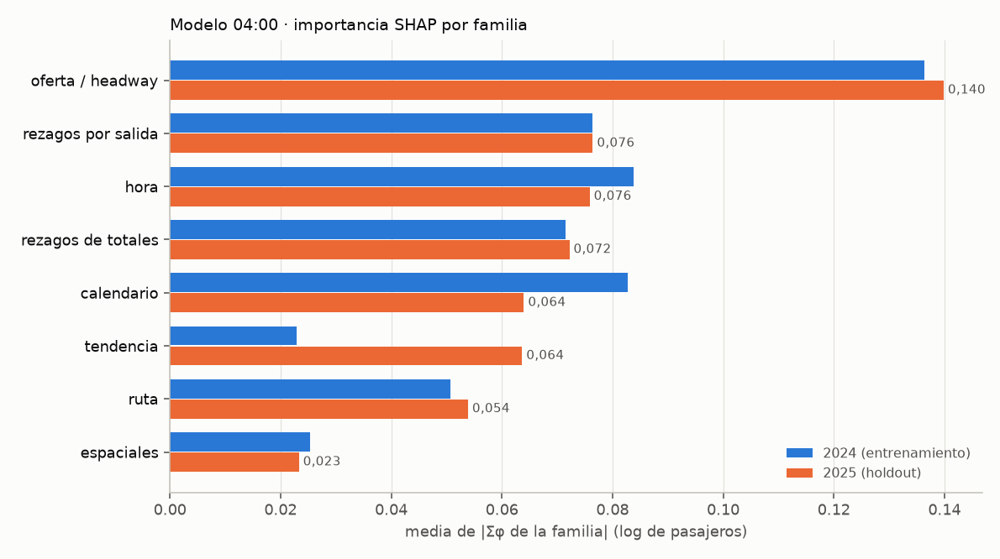

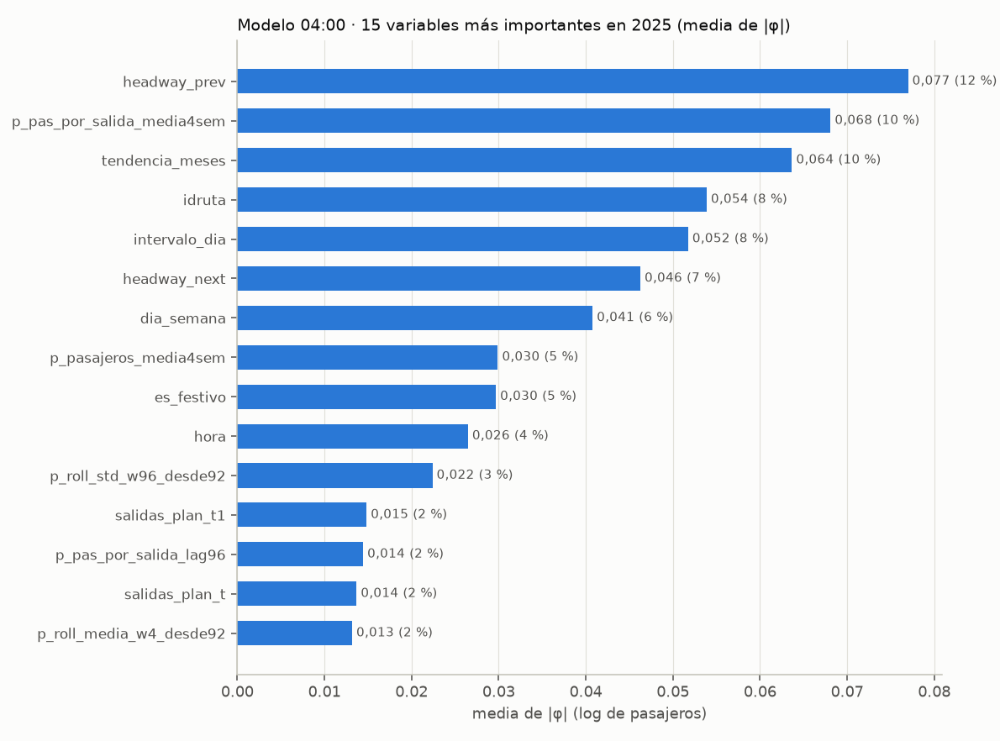

In [3]:
imp25, imp24 = S.importancia(S25), S.importancia(S24)
imp = imp25.merge(imp24[["variable", "media_abs_phi", "pct"]], on="variable", suffixes=("_2025", "_2024"))
imp["cambio_x"] = imp.media_abs_phi_2025 / imp.media_abs_phi_2024
imp.to_csv(SALIDA / "shap_importancia_8_2.csv", index=False)
display(imp.head(15).round(4))
fam = pd.DataFrame({"modelo_0400 · 2024": S.por_familia(S24), "modelo_0400 · 2025": S.por_familia(S25),
                    **{f"{m} · 2025 (muestra)": S.por_familia(SM[m]) for m in S.MODELOS}}).reindex(S.FAMILIAS)
fam.to_csv(SALIDA / "shap_familias_8_2.csv")
display(fam.round(4))
S.fig_familias(fam["modelo_0400 · 2024"].dropna(), fam["modelo_0400 · 2025"].dropna(), FIG / "importancia_familias_2024_2025.png")
S.fig_top(imp25, FIG / "top15_modelo_0400_2025.png", "Modelo 04:00 · 15 variables más importantes en 2025 (media de |φ|)")
for f in ["importancia_familias_2024_2025.png", "top15_modelo_0400_2025.png"]:
    display(Image(filename=str(FIG / f)))

**Conclusión 2 · Importancia global**
- **Modelo 04:00 en 2025, las 5 variables más importantes** (porcentaje de la media de |φ|):

  | Variable | Importancia en 2025 |
  |---|---:|
  | `headway_prev` | 11,7 % |
  | `p_pas_por_salida_media4sem` | 10,3 % |
  | **`tendencia_meses`** | **9,7 %** |
  | `idruta` | 8,2 % |
  | `intervalo_dia` | 7,8 % |

- La familia con más peso es **oferta / headway**: 0,140 en 2025.
- **El cambio de 2024 a 2025 es la señal clave:**
  - la importancia de `tendencia_meses` se multiplica **por 2,8** (de 3,6 % a 9,7 %);
  - la de `dia_semana` cae **a 0,67 veces** (de 9,6 % a 6,2 %);
  - el resto de variables cambia menos de un 15 %.
  - En 2025 el modelo deja de apoyarse en el día de la semana y pasa a apoyarse en la tendencia.
- **Intradía:** las capas c_ pesan 0,049 y los rezagos por salida suben a 0,101.
- **Oráculo:** las variables orac_ (t−1…t−4) son la familia más importante (0,123).
  - Así reparte la información cada capa, coherente con la ganancia de cada una en 2025 (7.3).

## 3 · Hipótesis principal: `tendencia_meses` y el contraste semanal

,splits sobre tendencia_meses,corte máximo,splits con corte > 23 (dic-2024),valores de 2025
modelo_0400,821,23.629032,54,"24,0–36,0"
modelo_intradia,4493,23.629032,254,"24,0–36,0"
modelo_oraculo,3109,23.629032,163,"24,0–36,0"


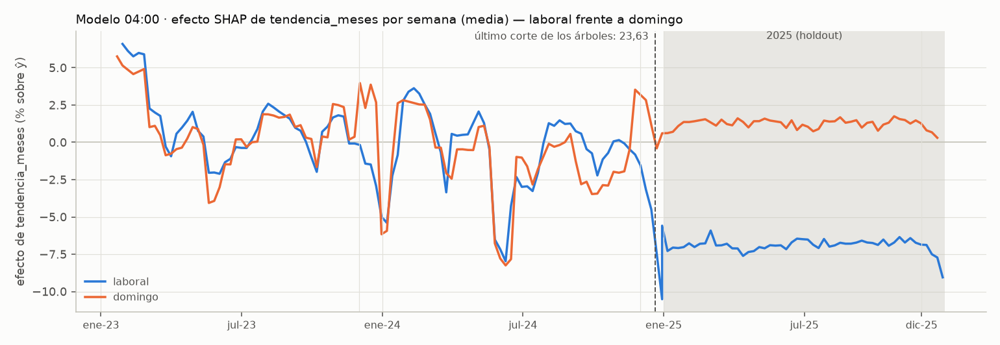

,φ medio de tendencia_meses (2025),efecto en % sobre ŷ
carnaval,-0.026,-2.599
domingo,0.012,1.219
festivo,-0.096,-9.175
laboral,-0.071,-6.890
sabado,-0.026,-2.586


fechasalida,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12
razón domingo/laboral real por mes,0.724,0.663,0.642,0.664,0.643,0.73,0.76,0.622,0.702,0.683,0.688,0.828,0.731,0.676,0.64,0.621,0.629,0.674,0.74,0.624,0.648,0.637,0.619,0.821


In [4]:
cort = {m: S.cortes(b, "tendencia_meses") for m, b in B.items()}
display(pd.DataFrame({m: {"splits sobre tendencia_meses": len(c), "corte máximo": c.max(), "splits con corte > 23 (dic-2024)": int((c > 23).sum()),
                          "valores de 2025": "24,0–36,0"} for m, c in cort.items()}).T)
dep = []
for SS, df in [(S23, t23), (S24, t24), (S25, h)]:
    sem = np.floor(df.tendencia_meses.to_numpy() * 4.345) / 4.345
    tmp = pd.DataFrame({"tendencia_meses": sem, "tipo_dia_cal": df.tipo_dia_cal.astype(str).to_numpy(), "phi": SS.tendencia_meses.to_numpy()})
    dep.append(tmp[tmp.tipo_dia_cal.isin(["laboral", "domingo"])].groupby(["tipo_dia_cal", "tendencia_meses"]).phi.mean().reset_index())
dep = pd.concat(dep, ignore_index=True).sort_values(["tipo_dia_cal", "tendencia_meses"])
S.fig_tendencia(dep, cort["modelo_0400"].max(), FIG / "dependencia_tendencia_meses.png")
display(Image(filename=str(FIG / "dependencia_tendencia_meses.png")))
td25 = h.tipo_dia_cal.astype(str)
display(pd.DataFrame({"φ medio de tendencia_meses (2025)": S25.tendencia_meses.groupby(td25.to_numpy()).mean(),
                      "efecto en % sobre ŷ": (np.exp(S25.tendencia_meses.groupby(td25.to_numpy()).mean()) - 1) * 100}).round(3))
mes = X.fechasalida.dt.to_period("M").astype(str)
real = X[X.fechasalida < "2025-01-01"].groupby([mes, "tipo_dia_cal"]).numeropasajeros.mean().unstack()
display((real.domingo / real.laboral).rename("razón domingo/laboral real por mes").to_frame().T.round(3))

año                                   2024  2025
contraste         familia                       
domingo − laboral TOTAL (Σ)          -31.0 -14.2
                  calendario         -22.9 -16.9
                  espaciales          -3.2  -2.4
                  hora                 0.2   0.6
                  oferta / headway     9.4  10.6
                  rezagos de totales  -4.4  -2.9
                  rezagos por salida -11.6 -10.3
                  ruta                 0.3   0.5
                  tendencia           -0.4   8.7
sabado − laboral  TOTAL (Σ)          -12.2  -1.3
                  calendario          -9.9  -5.9
                  espaciales          -1.1  -1.0
                  hora                 0.3   0.9
                  oferta / headway     1.8   2.9
                  rezagos de totales   0.2   0.2
                  rezagos por salida  -3.6  -2.6
                  ruta                -0.2  -0.1
                  tendencia            0.1   4.6

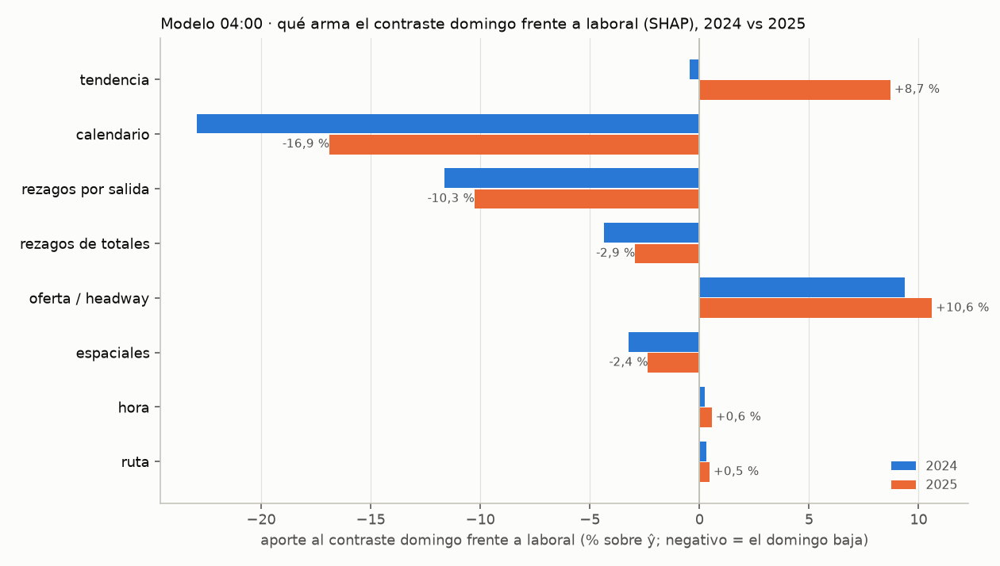

In [5]:
filas = []
for nom, SS, df in [("2024", S24, t24), ("2025", S25, h)]:
    for a in ["domingo", "sabado"]:
        ct = S.contraste(SS, df, a, "laboral")
        g = ct.groupby("familia").delta_phi.sum()
        for f_, v in g.items():
            filas.append({"año": nom, "contraste": f"{a} − laboral", "familia": f_, "delta_phi": v})
        logpred = SS.sum(axis=1)
        tdx = df.tipo_dia_cal.astype(str).to_numpy()
        filas.append({"año": nom, "contraste": f"{a} − laboral", "familia": "TOTAL (Σ)", "delta_phi": g.sum(),
                      "check_log_pred": float(logpred[tdx == a].mean() - logpred[tdx == "laboral"].mean())})
cont = pd.DataFrame(filas)
cont["efecto_%"] = (np.exp(cont.delta_phi) - 1) * 100
cont.to_csv(SALIDA / "contraste_semanal_8_2.csv", index=False)
display(cont.pivot_table(index=["contraste", "familia"], columns="año", values="efecto_%").round(1))
dom = cont[(cont.contraste == "domingo − laboral") & (cont.familia != "TOTAL (Σ)")].pivot(index="familia", columns="año", values="delta_phi")
S.fig_contraste(dom["2024"], dom["2025"], FIG / "contraste_domingo_laboral.png",
                "Modelo 04:00 · qué arma el contraste domingo frente a laboral (SHAP), 2024 vs 2025")
display(Image(filename=str(FIG / "contraste_domingo_laboral.png")))

**Conclusión 3 · `tendencia_meses` y el contraste semanal: causa identificada**
- **El corte más alto sobre `tendencia_meses` es el mismo en los tres modelos: 23,63**, alrededor del 20 de diciembre de 2024.
  - Splits sobre la variable: 821 (04:00), 4.493 (intradía) y 3.109 (oráculo).
  - Todo 2025 (24–36) cae en la misma rama: **el modelo trata cada día de 2025 como finales de diciembre de 2024**.
- **Diciembre es atípico:** la razón domingo/laboral real fue 0,828 en diciembre de 2023 y 0,821 en diciembre de 2024. El resto de meses está entre 0,62 y 0,76.
- **Efecto de `tendencia_meses` en 2025 por tipo de día:**
  - laboral **−6,9 %**;
  - festivo −9,2 %;
  - sábado −2,6 %;
  - **domingo +1,2 %**.
  - Se ve en la figura de dependencia: en 2025, laboral y domingo se separan de forma constante.
- **Descomposición SHAP del contraste domingo − laboral:**
  - **La tendencia pasa de −0,4 % (2024) a +8,7 % (2025)**.
  - El aporte del calendario se reduce: de −22,9 % a −16,9 %.
  - Por eso el contraste total se comprime de **−31,0 % a −14,2 %**.
  - Con el sábado ocurre lo mismo: la tendencia aporta +4,6 % y el contraste pasa de −12,2 % a −1,3 %.
- **Esto confirma la hipótesis de la 8.1** y explica por qué el patrón no aparecía en la CV 2024: en cada pliegue de validación, la tendencia caía dentro del rango ya visto.

## 4 · Otras hipótesis de la 8.1: headway, madrugada laboral y febrero/agosto

,tramo,n,phi_headway_prev,phi_oferta,residuo_pct,efecto_oferta_pct
0,≤2,18482,-0.143,-0.230,20.274,-20.580
1,2–3,35369,-0.058,-0.127,4.609,-11.925
2,3–4,24311,-0.027,-0.043,1.308,-4.206
3,4–5,14134,-0.002,0.002,0.738,0.242
4,5–6,20594,0.012,0.046,1.325,4.656
5,6–8,18904,0.076,0.146,-0.234,15.734
6,8–10,11117,0.120,0.208,1.114,23.115
7,>10,14705,0.222,0.359,-2.833,43.246


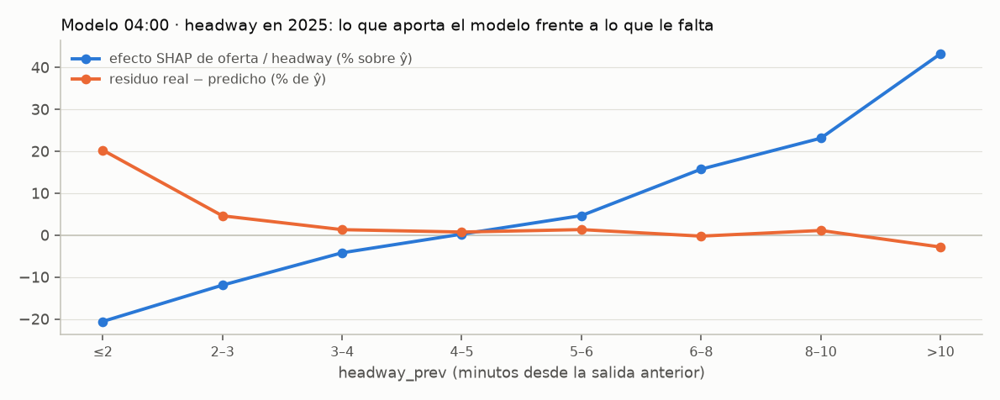

,04–06,07–09,otras,04–06 menos 07–09 (pts)
calendario,5.0,5.1,4.2,-0.1
espaciales,0.8,-0.2,-0.6,1.0
hora,3.2,1.9,-2.6,1.3
oferta / headway,-10.7,2.4,2.4,-13.1
rezagos de totales,1.0,-2.5,-4.4,3.5
rezagos por salida,2.2,0.5,-2.0,1.7
ruta,-0.3,0.5,0.4,-0.8
tendencia,-11.6,-7.1,-4.9,-4.6


,calendario,espaciales,hora,oferta / headway,rezagos de totales,rezagos por salida,ruta,tendencia,residuo real − predicho (pas.)
01,0.5,-1.6,-0.2,0.5,-4.8,-4.6,0.3,-5.8,-0.55
02,2.2,-0.1,-0.2,-0.3,-0.6,-2.1,0.3,-5.6,7.28
03,-0.9,0.2,-0.5,0.9,-1.3,0.4,0.4,-5.3,4.39
04,-0.2,-0.5,-0.3,-0.4,-2.0,-1.2,0.4,-6.0,2.37
05,0.9,-0.2,-0.2,0.0,-2.2,-1.4,0.4,-5.7,3.94
06,-2.1,-1.4,-0.3,0.3,-4.4,-3.5,0.3,-5.5,0.32
07,1.4,-1.7,-0.2,-0.5,-5.1,-5.1,0.1,-5.7,1.52
08,-1.1,-0.2,-0.3,2.4,-2.5,-2.2,0.5,-5.4,6.51
09,2.2,0.1,-0.6,2.7,-2.5,0.5,0.5,-5.5,4.08
10,0.8,-0.4,-0.7,1.9,-3.3,-0.6,0.4,-5.5,1.79


In [6]:
F25 = S.suma_familias(S25)
pred = pred73.pred_modelo_0400.to_numpy()
tramos = pd.cut(h.headway_prev, [-0.01, 2, 3, 4, 5, 6, 8, 10, 1000], labels=["≤2", "2–3", "3–4", "4–5", "5–6", "6–8", "8–10", ">10"])
hw = pd.DataFrame({"tramo": tramos, "phi_hw": S25.headway_prev, "phi_of": F25["oferta / headway"],
                   "res": (h.numeropasajeros.to_numpy() - pred) / pred * 100}).groupby("tramo", observed=True).agg(
    n=("phi_hw", "size"), phi_headway_prev=("phi_hw", "mean"), phi_oferta=("phi_of", "mean"), residuo_pct=("res", "mean")).reset_index()
hw["efecto_oferta_pct"] = (np.exp(hw.phi_oferta) - 1) * 100
display(hw.round(3))
S.fig_headway(hw, FIG / "headway_2025.png")
display(Image(filename=str(FIG / "headway_2025.png")))
lab = (h.tipo_dia_cal.astype(str) == "laboral").to_numpy()
franja = np.where(h.hora.between(4, 6), "04–06", np.where(h.hora.between(7, 9), "07–09", "otras"))
mad = ((np.exp(F25[lab].groupby(franja[lab]).mean()) - 1) * 100).T
mad["04–06 menos 07–09 (pts)"] = mad["04–06"] - mad["07–09"]
display(mad.round(1))
mes25 = h.fechasalida.dt.strftime("%m").to_numpy()
pm = ((np.exp(F25.groupby(mes25).mean()) - 1) * 100).round(1)
pm["residuo real − predicho (pas.)"] = pd.Series(h.numeropasajeros.to_numpy() - pred).groupby(mes25).mean().round(2).to_numpy()
display(pm)

**Conclusión 4 · Headway, madrugada y meses**
- **El efecto del headway es demasiado fuerte en el extremo corto:**
  - con headway ≤ 2 min, la familia oferta / headway baja la predicción un **−20,6 %**, pero el residuo es **+20,3 %** de ŷ;
  - con 2–3 min: −11,9 % de efecto y +4,6 % de residuo;
  - de 3 a > 10 min el residuo queda entre −2,8 % y +1,3 %.
  - El modelo penaliza de más a los buses que salen muy seguidos.
- **Madrugada laboral (04–06 h):**
  - la oferta / headway aporta −10,7 % (frente a +2,4 % de 07–09 h) y la tendencia −11,6 % (frente a −7,1 %);
  - en esas horas los despachos van muy seguidos y se suman los dos efectos.
  - **Explica la subpredicción de +13 a +18 pasajeros por viaje de la 8.1.**
- **Febrero y agosto (+7,3 y +6,5):**
  - la tendencia aporta lo mismo todos los meses (−5,1 a −6,1 %), así que no los explica;
  - los rezagos tampoco muestran nada particular (por ejemplo, febrero −0,6 % en totales y −2,1 % por salida);
  - queda como hipótesis el regreso a clases, una variable que el modelo no tiene.

## 5 · Contrafactuales diagnósticos (no se adoptan)

Se predice 2025 con los modelos **guardados**, cambiando **solo** `tendencia_meses`: (a) fijo en 22,5 (mediados de noviembre de 2024, un mes «normal»); (b) el mismo mes de 2024 (tendencia − 12). Control sin 2025: noviembre de 2024 con `tendencia_meses` de diciembre (23,8).

Razón domingo/laboral real 2025: 0.671 · línea base: 0.678


,modelo,escenario,dom/laboral,sáb/laboral,devianza,sesgo ŷ − y,residuo lun,residuo mar,residuo mié,residuo jue,residuo vie,residuo sáb,residuo dom
0,modelo_0400,04:00 · guardado (7.3),0.842,0.968,2.503,-2.971,5.170,8.305,5.005,4.466,4.165,-1.510,-9.575
1,modelo_0400,"04:00 · tendencia = 22,5 (nov-2024)",0.674,0.870,2.278,1.993,-4.358,-2.640,-1.737,-2.029,-1.106,-0.386,-1.615
2,modelo_0400,04:00 · tendencia − 12 (mismo mes de 2024),0.698,0.884,2.251,1.532,-3.452,-1.456,-0.841,-1.227,-0.436,-0.859,-3.143
3,modelo_intradia,intradía · guardado (7.3),0.816,0.953,2.406,-1.754,4.108,5.993,3.520,2.737,2.644,-1.811,-8.913
4,modelo_intradia,"intradía · tendencia = 22,5 (nov-2024)",0.686,0.883,2.236,1.351,-2.873,-1.628,-1.060,-1.089,-0.425,-0.705,-1.976
5,modelo_intradia,intradía · tendencia − 12 (mismo mes de 2024),0.704,0.890,2.221,0.799,-2.181,-0.507,-0.166,-0.313,0.196,-0.535,-2.964
6,modelo_oraculo,oráculo · guardado (7.3),0.726,0.907,2.222,-0.478,1.462,1.708,0.823,0.819,1.181,-0.522,-3.622
7,modelo_oraculo,"oráculo · tendencia = 22,5 (nov-2024)",0.689,0.892,2.199,-0.019,-0.363,0.172,0.220,0.240,0.703,-0.081,-1.263
8,modelo_oraculo,oráculo · tendencia − 12 (mismo mes de 2024),0.691,0.889,2.197,0.077,-0.608,0.082,0.144,0.179,0.593,-0.017,-1.449


,escenario,dom/laboral
0,noviembre 2024 · real,0.619
1,noviembre 2024 · modelo 04:00,0.646
2,"noviembre 2024 · modelo 04:00 con tendencia de diciembre (23,8)",0.794


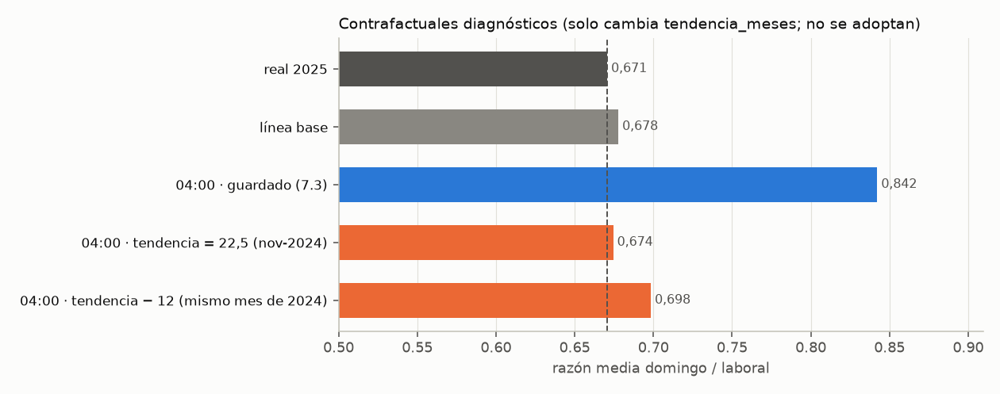

In [7]:
cfs = []
for m in S.MODELOS:
    b = B[m]
    cfs.append({"modelo": m, **S.resumen_pred(f"{S.NOMBRE[m]} · guardado (7.3)", pred73[f"pred_{m}"].to_numpy(), h)})
    for nom, val in [("tendencia = 22,5 (nov-2024)", 22.5), ("tendencia − 12 (mismo mes de 2024)", h.tendencia_meses.to_numpy() - 12)]:
        p_, _ = S.contrafactual(b, h, val)
        cfs.append({"modelo": m, **S.resumen_pred(f"{S.NOMBRE[m]} · {nom}", p_, h)})
cf = pd.DataFrame(cfs)
real25 = S.ratio(h.numeropasajeros.to_numpy(float), h)
base25 = S.ratio(pred73.pred_linea_base.to_numpy(), h)
nov = t24[(t24.fechasalida >= "2024-11-01") & (t24.fechasalida < "2024-12-01")]
b0 = B["modelo_0400"]
control = pd.DataFrame([
    {"escenario": "noviembre 2024 · real", "dom/laboral": S.ratio(nov.numeropasajeros.to_numpy(float), nov)},
    {"escenario": "noviembre 2024 · modelo 04:00", "dom/laboral": S.ratio(b0.predict(nov[b0.feature_name()]), nov)},
    {"escenario": "noviembre 2024 · modelo 04:00 con tendencia de diciembre (23,8)", "dom/laboral": S.ratio(S.contrafactual(b0, nov, 23.8)[0], nov)},
])
cf.to_csv(SALIDA / "contrafactuales_8_2.csv", index=False)
control.to_csv(SALIDA / "contrafactual_control_nov2024_8_2.csv", index=False)
print(f"Razón domingo/laboral real 2025: {real25:.3f} · línea base: {base25:.3f}")
display(cf.round(3))
display(control.round(3))
S.fig_contrafactual(cf[cf.modelo == "modelo_0400"], real25, base25, FIG / "contrafactual_tendencia.png")
display(Image(filename=str(FIG / "contrafactual_tendencia.png")))

**Conclusión 5 · Contrafactuales: causa confirmada (diagnóstico; no se adoptan)**
- **Cambiando solo `tendencia_meses` con el modelo 04:00 guardado:**

  | Escenario | Domingo/laboral | Devianza 2025 | Residuo de lunes a viernes |
  |---|---:|---:|---:|
  | Modelo guardado | 0,842 | 2,503 | +4,2 a +8,3 |
  | Tendencia = 22,5 (noviembre de 2024) | **0,674** | 2,278 | −4,4 a −1,1 |
  | Tendencia − 12 (mismo mes de 2024) | 0,698 | 2,251 | — |

  - El valor real es 0,671 y la línea base da 0,678.
- **Lo mismo pasa con los otros modelos** (domingo/laboral):
  - intradía: 0,816 → 0,686 / 0,704;
  - oráculo: 0,726 → 0,689 / 0,691.
- **Control sin usar 2025:** en noviembre de 2024, el modelo da 0,646 (real 0,619). Si se le pone la tendencia de diciembre, la razón sube a **0,794**. El mecanismo se reproduce dentro del entrenamiento.
- **Lectura correcta de las devianzas:**
  - las devianzas contrafactuales del modelo 04:00 son 9–10 % menores; intradía 7–8 % y oráculo 1 %;
  - **no reemplazan la cifra de la 7.3 (2,503; −14,5 % frente a la línea base)**, porque el arreglo se encontró mirando 2025;
  - indican cuánto se podría ganar en el Entregable 2, validado con datos nuevos.

## 6 · Síntesis para el informe

In [8]:
c0 = cf[cf.modelo == "modelo_0400"].set_index("escenario")
g0, ga, gb = c0.iloc[0], c0.iloc[1], c0.iloc[2]
cmax = cort["modelo_0400"]
dd = cont[(cont.contraste == "domingo − laboral")].pivot(index="familia", columns="año", values="efecto_%")
r_imp = imp.set_index("variable")
sintesis = pd.DataFrame([
    {"hallazgo": "2025 se trata como finales de diciembre de 2024",
     "evidencia_shap": f"{len(cmax)} splits sobre tendencia_meses; corte máximo {cmax.max():.2f} (todo 2025 ≥ 24 cae en la misma rama); "
                       f"importancia de tendencia_meses ×{r_imp.loc['tendencia_meses', 'cambio_x']:.1f} de 2024 a 2025",
     "accion_entregable_2": "quitar tendencia_meses o reemplazarla por un nivel relativo (rezagos por salida, media de 4 semanas) "
                            "y una indicadora de temporada (diciembre, vacaciones escolares)"},
    {"hallazgo": "Contraste semanal comprimido",
     "evidencia_shap": f"aporte de la tendencia al contraste domingo − laboral: {dd.loc['tendencia', '2024']:+.1f} % (2024) → "
                       f"{dd.loc['tendencia', '2025']:+.1f} % (2025); contraste total {dd.loc['TOTAL (Σ)', '2024']:+.1f} % → {dd.loc['TOTAL (Σ)', '2025']:+.1f} %",
     "accion_entregable_2": "validar en un esquema donde el último bloque de validación caiga después del fin del entrenamiento (como en producción)"},
    {"hallazgo": "Causa confirmada por contrafactual",
     "evidencia_shap": f"domingo/laboral: guardado {g0['dom/laboral']:.3f} → {ga['dom/laboral']:.3f} (tendencia 22,5) y {gb['dom/laboral']:.3f} (tendencia − 12); "
                       f"real {real25:.3f}; control nov-2024 con tendencia de diciembre: {control['dom/laboral'].iloc[1]:.3f} → {control['dom/laboral'].iloc[2]:.3f}",
     "accion_entregable_2": "no adoptar el contrafactual (se vio con 2025); reentrenar sin la extrapolación de tendencia y evaluar en datos nuevos"},
    {"hallazgo": "Oferta / headway es la familia más importante",
     "evidencia_shap": f"headway_prev es la 1.ª variable ({r_imp.loc['headway_prev', 'pct_2025']:.1f} % de la importancia en 2025); "
                       f"con headway ≤ 2 min el residuo es {hw.residuo_pct.iloc[0]:+.1f} % de ŷ",
     "accion_entregable_2": "en producción usar el headway PLANEADO; revisar el efecto de buses agrupados"},
])
sintesis.to_csv(SALIDA / "sintesis_8_2.csv", index=False)
display(sintesis)

,hallazgo,evidencia_shap,accion_entregable_2
0,2025 se trata como finales de diciembre de 2024,821 splits sobre tendencia_meses; corte máximo 23.63 (todo 2025 ≥ 24 cae en la misma rama); importancia de tendencia_meses ×2.8 de 2024 ...,"quitar tendencia_meses o reemplazarla por un nivel relativo (rezagos por salida, media de 4 semanas) y una indicadora de temporada (dici..."
1,Contraste semanal comprimido,aporte de la tendencia al contraste domingo − laboral: -0.4 % (2024) → +8.7 % (2025); contraste total -31.0 % → -14.2 %,validar en un esquema donde el último bloque de validación caiga después del fin del entrenamiento (como en producción)
2,Causa confirmada por contrafactual,"domingo/laboral: guardado 0.842 → 0.674 (tendencia 22,5) y 0.698 (tendencia − 12); real 0.671; control nov-2024 con tendencia de diciemb...",no adoptar el contrafactual (se vio con 2025); reentrenar sin la extrapolación de tendencia y evaluar en datos nuevos
3,Oferta / headway es la familia más importante,headway_prev es la 1.ª variable (11.7 % de la importancia en 2025); con headway ≤ 2 min el residuo es +20.3 % de ŷ,en producción usar el headway PLANEADO; revisar el efecto de buses agrupados


**Conclusión 6 · Síntesis para el informe**
1. **Causa raíz del error sistemático de 2025:** `tendencia_meses` queda fuera del rango de entrenamiento. Los árboles no extrapolan: aplican a todo 2025 el patrón de finales de diciembre de 2024 (fiestas), que comprime el contraste semanal.
   - **Acción para el Entregable 2:** quitar `tendencia_meses` o reemplazarla por un nivel relativo (los rezagos por salida y la media de 4 semanas ya llevan el nivel) y por indicadoras de temporada (diciembre, vacaciones escolares).
2. **Lección de validación:** en la walk-forward de 2024 la tendencia siempre caía dentro del rango visto. Para variables monótonas en el tiempo, la CV debe incluir un escenario en el que la tendencia quede fuera de rango, como en producción.
3. **El headway corto está sobrecastigado:** −20,6 % de efecto con +20,3 % de residuo en ≤ 2 min, y explica la madrugada laboral.
   - **Acción:** revisar el efecto de los buses agrupados y usar el headway **planeado** en producción.
4. **Febrero y agosto siguen sin explicación** con las variables actuales. **Acción:** probar una variable de calendario escolar.
- **Nada de esto cambia la evaluación oficial de la 7.3:** el modelo 04:00 mejora un 14,5 % a la línea base en 2025.

## 7 · Pruebas (a–e) y checks

In [9]:
pruebas = T.correr_todos(h, B, S25, SM, hm, cont, HASH_ANTES, pred73)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_8_2.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Test a · aditividad de TreeSHAP,PASS,modelo_0400: 2.4e-14; modelo_intradia: 2.5e-14; modelo_oraculo: 1.2e-13
1,Test b · predicciones = 7.3,PASS,error máximo frente a la 7.3: modelo_0400 0.0e+00; modelo_intradia 0.0e+00; modelo_oraculo 0.0e+00
2,Test c · el contrafactual solo cambia tendencia_meses,PASS,32 columnas idénticas byte a byte; solo cambia tendencia_meses
3,Test d · la descomposición del contraste cuadra,PASS,"4 contrastes (domingo y sábado frente a laboral, 2024 y 2025); error máximo 1.2e-15"
4,Test e · los insumos de la 7.3 no cambian,PASS,4 archivos (predicciones y modelos de la 7.3) con el mismo SHA-256 antes y después


,check,resultado,detalle
0,Test a · aditividad de TreeSHAP,PASS,modelo_0400: 2.4e-14; modelo_intradia: 2.5e-14; modelo_oraculo: 1.2e-13
1,Test b · predicciones = 7.3,PASS,error máximo frente a la 7.3: modelo_0400 0.0e+00; modelo_intradia 0.0e+00; modelo_oraculo 0.0e+00
2,Test c · el contrafactual solo cambia tendencia_meses,PASS,32 columnas idénticas byte a byte; solo cambia tendencia_meses
3,Test d · la descomposición del contraste cuadra,PASS,"4 contrastes (domingo y sábado frente a laboral, 2024 y 2025); error máximo 1.2e-15"
4,Test e · los insumos de la 7.3 no cambian,PASS,4 archivos (predicciones y modelos de la 7.3) con el mismo SHA-256 antes y después
5,Tiempo total de la ejecución,INFO,9.5 min


PASS 5 · FAIL 0 · INFO 1


**Conclusión 7 · Pruebas**
- **Pasan las 5 de 5 pruebas:**
  - **a)** aditividad de TreeSHAP ≤ 1,2e-13;
  - **b)** las predicciones de los modelos guardados son idénticas a las de la 7.3 (error 0);
  - **c)** el contrafactual solo cambia `tendencia_meses` (32 columnas idénticas byte a byte);
  - **d)** la descomposición del contraste cuadra (error 1,2e-15);
  - **e)** las predicciones y los modelos de la 7.3 no cambiaron (mismo SHA-256).
- Ejecución: 9,5 min en el PC de la Persona 3 (Python 3.12, lightgbm 4.7).

<a id="m8-3"></a>

### A1.6.3 &middot; Subfase 8.3 · Significancia estadística (Diebold-Mariano)

<sub>Notebook original: `subfase_8_3_dm.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Subfase 8.3 — Significancia estadística (Diebold-Mariano)

**Persona 3 · MLOps & Model Evaluation.** ¿Las diferencias de devianza del holdout 2025 (7.3) son estadísticamente significativas, o podrían ser ruido de un año particular? 2025 ya se evaluó una sola vez en la 7.3: aquí **no se reentrena ni se elige nada**, solo se prueba.

| Elemento | Decisión |
|---|---|
| Pérdida | Devianza unitaria de Tweedie (p = 1,3) por viaje; diferencial diario d_t = media del día de L(A) − L(B), n = 365 |
| Comparaciones | 04:00 vs línea base (principal) · intradía vs 04:00 (¿aporta la cascada?) · intradía vs línea base · oráculo vs 04:00 (bilateral, benchmark) |
| Estadístico | DM con varianza HAC de Newey-West (Bartlett), rezago 21 / 28 (fijado en la 8.1), p con t(n−1) y corrección HLN; Holm sobre las 4 |
| Calibración | Como d_t es muy persistente, se calcula además un **p calibrado por simulación** (sieve bootstrap AR(k), 10.000 series bajo H0 con la misma dependencia) |
| Robustez | rezagos 7–28, escala semanal, por ruta, por trimestre, pérdida MAE, bootstrap por bloques (28 y 56 días), semillas |
| Veredicto | «significativo y robusto» si el p calibrado con Holm < 0,05, ambos IC bootstrap excluyen 0 y el signo se mantiene en todas las variantes |

**Parte 1 (extracción RDS): no aplica.** El informe ejecutivo del Entregable 1 se redacta aparte, al final.

## Parte 2 · Análisis offline

In [1]:
import json
import platform
import time
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import Image, display

import dm_8_3 as D
import tests_8_3 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_8"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_8_3"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


T0 = time.time()
HASH_ANTES = T.hashes()
d = D.cargar()
print(f"Python {platform.python_version()} · {len(d):,} viajes de 2025 · {d.fecha.nunique()} días")
print("Rezagos HAC (8.1):", {D.etiqueta(a, b): D.rezago_hac(a, b) for a, b, _ in D.COMPARACIONES})

Python 3.9.25 · 158,507 viajes de 2025 · 365 días
Rezagos HAC (8.1): {'04:00 vs línea base': 21, 'intradía vs 04:00': 28, 'intradía vs línea base': 28, 'oráculo vs 04:00': 28}


## 1 · Diebold-Mariano: tabla principal

In [2]:
t = D.tabla_principal(d, reps=10_000)
rob = D.robustez(d)
t["veredicto"] = [D.veredicto(f, rob) for _, f in t.iterrows()]
t.to_csv(SALIDA / "dm_8_3.csv", index=False)
vista = t[["comparacion", "alternativa", "devianza_A", "devianza_B", "mejora_%", "media_d", "rezago", "DM_HLN", "p_HLN", "p_Holm",
           "k_ar", "suma_phi", "tamano_NW_al_5%", "p_calibrado", "p_Holm_calibrado", "IC95_boot_lo", "IC95_boot_hi",
           "IC95_boot56_lo", "IC95_boot56_hi", "veredicto"]]
display(vista.round(4))
for _, f in t.iterrows():
    check(f"DM · {f.comparacion}", f.veredicto != "no significativo",
          f"{f['mejora_%']:.1f} % · DM-HLN {f.DM_HLN:.2f} · p calibrado (Holm) {f.p_Holm_calibrado:.4f} · {f.veredicto}", info=True)

,comparacion,alternativa,devianza_A,devianza_B,mejora_%,media_d,rezago,DM_HLN,p_HLN,p_Holm,k_ar,suma_phi,tamano_NW_al_5%,p_calibrado,p_Holm_calibrado,IC95_boot_lo,IC95_boot_hi,IC95_boot56_lo,IC95_boot56_hi,veredicto
0,04:00 vs línea base,menor,2.5028,2.9288,14.5430,-0.4275,21,-4.6120,0.0,0.0,7,0.9154,0.2362,0.0348,0.0414,-0.6511,-0.2363,-0.6701,-0.2292,significativo y robusto
1,intradía vs 04:00,menor,2.4058,2.5028,3.8784,-0.0923,28,-8.7648,0.0,0.0,7,0.5026,0.0927,0.0001,0.0004,-0.1114,-0.0718,-0.1114,-0.0701,significativo y robusto
2,intradía vs línea base,menor,2.4058,2.9288,17.8574,-0.5198,28,-5.6724,0.0,0.0,7,0.9290,0.2419,0.0207,0.0414,-0.7347,-0.3412,-0.7492,-0.3363,significativo y robusto
3,oráculo vs 04:00,bilateral,2.2216,2.5028,11.2390,-0.2814,28,-10.6058,0.0,0.0,7,0.5937,0.1349,0.0001,0.0004,-0.3306,-0.2308,-0.3329,-0.2255,significativo y robusto


**Conclusión 1 · Significancia de las diferencias**

| Comparación | Mejora en 2025 | DM-HLN | p calibrado (Holm) | IC95 bootstrap de la diferencia diaria (28 días) | Veredicto |
|---|---:|---:|---:|---|---|
| **04:00 vs línea base** | **−14,5 %** (2,503 frente a 2,929) | −4,61 | **0,041** | [−0,651; −0,236] | **significativo y robusto** |
| **Intradía vs 04:00** | −3,9 % (2,406 frente a 2,503) | −8,76 | 0,0004 | [−0,111; −0,072] | significativo y robusto |
| Intradía vs línea base | −17,9 % | −5,67 | 0,041 | [−0,735; −0,341] | significativo y robusto |
| Oráculo vs 04:00 (benchmark) | −11,2 % | −10,61 | 0,0004 | [−0,331; −0,231] | significativo y robusto |

- **El modelo 04:00 supera a la línea base en 2025 de forma estadísticamente significativa**, aun con el defecto de `tendencia_meses` (8.2).
- **La ganancia de la cascada intradía también es significativa:** respalda con una prueba formal la corrección de la 7.3 a la 7.2.
- Con bloques de 56 días, el IC tampoco incluye el 0 en ninguna comparación.

## 2 · Por qué hace falta calibrar el p-valor

In [3]:
cal = t[["comparacion", "suma_phi", "tamano_NW_al_5%", "DM_HLN", "critico_calibrado_5%", "p_HLN", "p_calibrado"]].copy()
cal["el DM supera el crítico calibrado"] = np.where(t.alternativa == "bilateral", cal.DM_HLN.abs() > cal["critico_calibrado_5%"].abs(),
                                                     cal.DM_HLN < cal["critico_calibrado_5%"])
display(cal.round(4))

,comparacion,suma_phi,tamano_NW_al_5%,DM_HLN,critico_calibrado_5%,p_HLN,p_calibrado,el DM supera el crítico calibrado
0,04:00 vs línea base,0.9154,0.2362,-4.6120,-4.0356,0.0,0.0348,True
1,intradía vs 04:00,0.5026,0.0927,-8.7648,-2.0809,0.0,0.0001,True
2,intradía vs línea base,0.9290,0.2419,-5.6724,-4.2898,0.0,0.0207,True
3,oráculo vs 04:00,0.5937,0.1349,-10.6058,-2.6763,0.0,0.0001,True


**Conclusión 2 · Calibración: los p-valores clásicos exageran la evidencia frente a la línea base**
- El diferencial frente a la línea base es **muy persistente**: la suma de los coeficientes del AR(7) ajustado es 0,92–0,93.
  - La razón es que la línea base no tiene tendencia y su error se desplaza a lo largo del año.
- Con esa dependencia, el DM con Newey-West rechaza la hipótesis nula en un **24 %** de los casos bajo H0, cuando debería ser un 5 %.
  - Por eso su p ≈ 3e-6 sobrestima la evidencia.
- **Con el p calibrado por simulación:**
  - el crítico al 5 % pasa de −1,65 a **−4,04** (04:00) y −4,29 (intradía);
  - el DM observado (−4,61 y −5,67) lo supera, pero por poco: p = 0,035 y 0,021.
  - El test b muestra que el p calibrado sigue siendo algo liberal (≈ 7–8 % de rechazo a un nivel nominal del 5 %).
  - **Lectura honesta:** la mejora sobre la línea base es significativa al 5 %, con p ≈ 0,03–0,05. Es real, no abrumadora.
- **Frente al modelo 04:00 la conclusión es contundente:**
  - la persistencia es moderada (0,50–0,59) y el tamaño del DM con Newey-West, de 9–13 %;
  - el DM (−8,76 y −10,61) supera con holgura el crítico calibrado (−2,08 y −2,68 bilateral).

## 3 · Robustez

In [4]:
rob.to_csv(SALIDA / "dm_robustez_8_3.csv", index=False)
display(rob.pivot_table(index="variante", columns="comparacion", values="media_d", sort=False).round(3))
display(rob.pivot_table(index="variante", columns="comparacion", values="DM_HLN", sort=False).round(2))
display(rob.pivot_table(index="variante", columns="comparacion", values="p_HLN", sort=False).map(lambda p: f"{p:.1e}"))
sem = pd.read_csv("datos_7/semillas_7_3.csv")
rango = sem.devianza_tweedie.max() - sem.devianza_tweedie.min()
display(pd.DataFrame({"comparación": t.comparacion, "|diferencia global|": t.dif_global.abs(), "rango entre semillas del 04:00 (7.3)": rango,
                      "veces el rango": t.dif_global.abs() / rango}).round(3))
print(f"Intradía (2,406) frente a las 4 semillas del 04:00 ({sem.devianza_tweedie.min():.3f}–{sem.devianza_tweedie.max():.3f}): "
      f"{'mejor que todas' if t.devianza_A.iloc[1] < sem.devianza_tweedie.min() else 'no mejor que todas'}")

comparacion,04:00 vs línea base,intradía vs 04:00,intradía vs línea base,oráculo vs 04:00
variante,,,,
rezago HAC 7,-0.427,-0.092,-0.520,-0.281
rezago HAC 14,-0.427,-0.092,-0.520,-0.281
rezago HAC 21,-0.427,-0.092,-0.520,-0.281
rezago HAC 28,-0.427,-0.092,-0.520,-0.281
semanal,-0.469,-0.098,-0.567,-0.282
ruta 2,-0.573,-0.146,-0.719,-0.324
ruta 16,-0.311,-0.067,-0.378,-0.279
ruta 21,-0.514,-0.085,-0.600,-0.232
trimestre 1,-0.334,-0.119,-0.453,-0.356


comparacion,04:00 vs línea base,intradía vs 04:00,intradía vs línea base,oráculo vs 04:00
variante,,,,
rezago HAC 7,-6.33,-11.56,-8.21,-15.08
rezago HAC 14,-5.15,-10.21,-6.68,-12.73
rezago HAC 21,-4.61,-9.27,-6.01,-11.38
rezago HAC 28,-4.34,-8.76,-5.67,-10.61
semanal,-4.06,-8.56,-5.24,-9.72
ruta 2,-3.82,-9.20,-4.84,-8.97
ruta 16,-4.26,-6.79,-5.11,-11.47
ruta 21,-7.04,-7.54,-8.61,-9.40
trimestre 1,-2.09,-8.29,-2.88,-11.35


comparacion,04:00 vs línea base,intradía vs 04:00,intradía vs línea base,oráculo vs 04:00
variante,,,,
rezago HAC 7,3.5e-10,7.5e-27,2.0e-15,3.0e-40
rezago HAC 14,2.1e-07,5.4e-22,4.4e-11,5.7e-31
rezago HAC 21,2.8e-06,8.1e-19,2.3e-09,6.8e-26
rezago HAC 28,9.3e-06,3.6e-17,1.4e-08,4.4e-23
semanal,8.2e-05,8.3e-12,1.5e-06,2.8e-13
ruta 2,7.9e-05,1.4e-18,9.8e-07,1.6e-17
ruta 16,1.3e-05,2.3e-11,2.6e-07,3.2e-26
ruta 21,4.7e-12,1.9e-13,1.1e-16,6.2e-19
trimestre 1,2.0e-02,5.5e-13,2.5e-03,5.4e-19


,comparación,|diferencia global|,rango entre semillas del 04:00 (7.3),veces el rango
0,04:00 vs línea base,0.426,0.04,10.565
1,intradía vs 04:00,0.097,0.04,2.408
2,intradía vs línea base,0.523,0.04,12.972
3,oráculo vs 04:00,0.281,0.04,6.977


Intradía (2,406) frente a las 4 semillas del 04:00 (2.472–2.512): mejor que todas


**Conclusión 3 · Robustez**
- **El signo de la diferencia es el mismo en las 13 variantes de las 4 comparaciones:**
  - rezagos HAC de 7 a 28;
  - escala semanal (n = 53);
  - las 3 rutas;
  - los 4 trimestres;
  - pérdida MAE.
- **04:00 vs línea base:**
  - Lo más débil es el primer trimestre (DM −2,09; p 0,020). La ruta 16 es la de menor diferencia (−0,311), aunque su DM es −4,26.
  - Lo más fuerte es el cuarto trimestre (−0,646, por diciembre, donde la línea base falla más) y la ruta 21 (DM −7,04).
  - En MAE equivale a **−2,66 pasajeros por viaje**.
- **Frente a la variación por semilla de la 7.3** (rango 0,040):
  - la diferencia 04:00 − línea base es **10,6 veces** ese rango;
  - intradía − 04:00 es 2,4 veces;
  - intradía (2,406) es mejor que las 4 semillas del modelo 04:00 (2,472–2,512).
  - **La conclusión no depende de la semilla.**

## 4 · Figuras

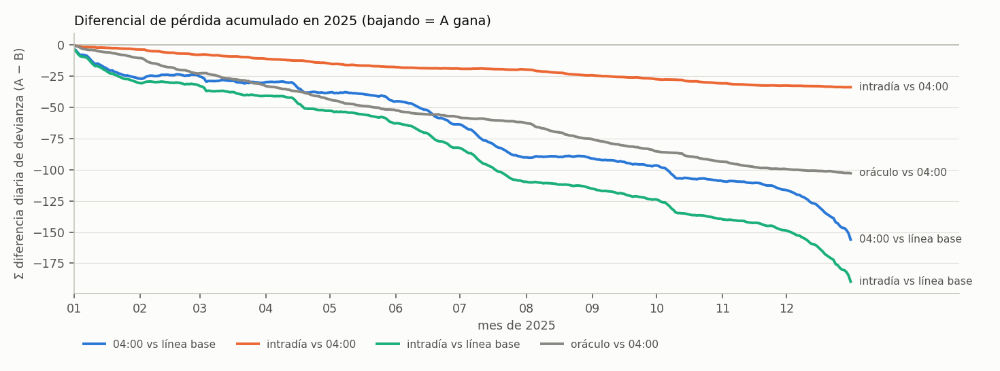

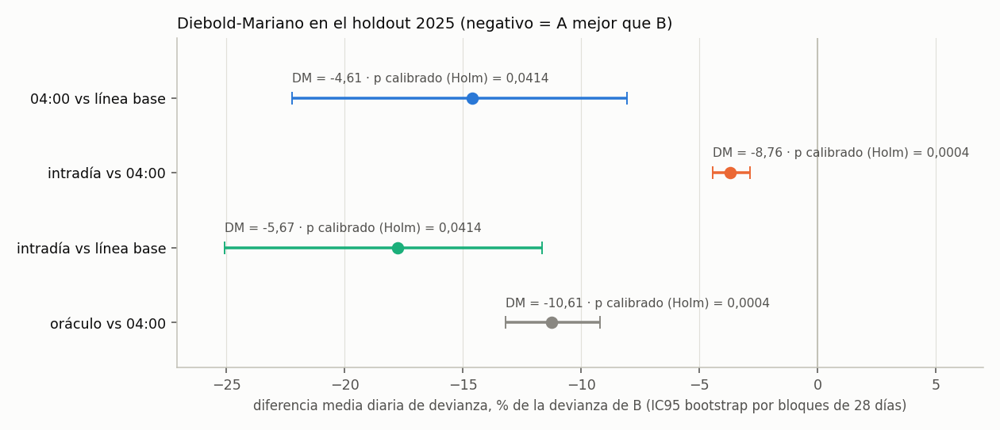

In [5]:
D.fig_acumulado(d, FIG / "diferencial_acumulado_2025.png")
D.fig_dm(t, FIG / "dm_intervalos.png")
for f in ["diferencial_acumulado_2025.png", "dm_intervalos.png"]:
    display(Image(filename=str(FIG / f)))

**Conclusión 4 · Figuras**
- **Diferencial acumulado 04:00 vs línea base:** la ganancia se acumula en enero, de abril a julio, en octubre y sobre todo en diciembre, con tramos casi planos en febrero–marzo y agosto–septiembre.
  - Esos tramos planos son los meses de mayor subpredicción en la 8.1.
- **Intradía vs 04:00:** acumula casi en línea recta todo el año. **La ventaja de la cascada es constante, no depende de unos pocos días.**
- **Oráculo vs 04:00:** también estable. Cuantifica el valor de los datos en tiempo real (−11,2 %), que no es desplegable.

## 5 · Pruebas (a–e) y checks

In [6]:
pruebas = T.correr_todos(d, t, HASH_ANTES)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_8_3.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Test a · Newey-West = statsmodels,PASS,"varianza de la media idéntica a statsmodels con rezagos 5, 21 y 28 (error máx. 1.0e-17)"
1,Test b · tamaño y potencia del DM,PASS,"φ = 0,3: tamaño 7,7%, potencia 99%; φ = 0,9: tamaño DM-NW 12% frente a 8% con el p calibrado"
2,Test c · agregación diaria = diferencia global,PASS,error máximo 4.4e-16; la diferencia 04:00 − línea base (-0.4259) coincide con holdout_7_3.csv
3,Test d · bootstrap reproducible,PASS,IC95 [-0.654; -0.238] idéntico con la misma semilla y contiene la media -0.427
4,Test e · los insumos no cambian,PASS,"6 archivos (predicciones 7.3, insumo DM y residuos 8.1, modelos) con el mismo SHA-256"


,check,resultado,detalle
0,DM · 04:00 vs línea base,INFO,14.5 % · DM-HLN -4.61 · p calibrado (Holm) 0.0414 · significativo y robusto
1,DM · intradía vs 04:00,INFO,3.9 % · DM-HLN -8.76 · p calibrado (Holm) 0.0004 · significativo y robusto
2,DM · intradía vs línea base,INFO,17.9 % · DM-HLN -5.67 · p calibrado (Holm) 0.0414 · significativo y robusto
3,DM · oráculo vs 04:00,INFO,11.2 % · DM-HLN -10.61 · p calibrado (Holm) 0.0004 · significativo y robusto
4,Test a · Newey-West = statsmodels,PASS,"varianza de la media idéntica a statsmodels con rezagos 5, 21 y 28 (error máx. 1.0e-17)"
5,Test b · tamaño y potencia del DM,PASS,"φ = 0,3: tamaño 7,7%, potencia 99%; φ = 0,9: tamaño DM-NW 12% frente a 8% con el p calibrado"
6,Test c · agregación diaria = diferencia global,PASS,error máximo 4.4e-16; la diferencia 04:00 − línea base (-0.4259) coincide con holdout_7_3.csv
7,Test d · bootstrap reproducible,PASS,IC95 [-0.654; -0.238] idéntico con la misma semilla y contiene la media -0.427
8,Test e · los insumos no cambian,PASS,"6 archivos (predicciones 7.3, insumo DM y residuos 8.1, modelos) con el mismo SHA-256"
9,Tiempo total de la ejecución,INFO,0.2 min


PASS 5 · FAIL 0 · INFO 5


**Conclusión 5 · Pruebas**
- **Pasan las 5 de 5 pruebas:**
  - **a)** la varianza de Newey-West es idéntica a la de statsmodels (error 1e-17);
  - **b)** tamaño 7,7 % y potencia 99 % con AR(1) φ = 0,3. Con φ = 0,9, el DM con Newey-West rechaza un 12 % y el p calibrado un 8 %: la calibración corrige la mayor parte de la distorsión, pero no toda;
  - **c)** la agregación diaria reproduce exactamente la diferencia global de la 7.3;
  - **d)** el bootstrap es reproducible;
  - **e)** ningún insumo cambió.
- Ejecución: 0,2 min.

<a id="e1c"></a>

---

## A1.7 &middot; e1c · Corrección del Entregable 1

Se quita `tendencia_meses` y se incorpora el receso escolar; se vuelve a entrenar y a evaluar con el mismo protocolo del Módulo 7. En 2025: devianza −10,2 % y domingo/laboral 0,694 frente a 0,671 real.

<sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Corrección del Entregable 1 (e1c) — `tendencia_meses`

**Persona 3 · MLOps & Model Evaluation.** Crítica de la calificación (4,7/5): *«la tendencia monótona fuera de rango es un error de diseño de una feature que se diagnostica pero no se resuelve»*. Este notebook documenta cómo se resolvió, **sin reentrenar nada**: lee las salidas de `validacion_e1c.py` (decisión con 2023–2024) y `holdout_e1c.py` (evaluación única de 2025), ambos ejecutados en el PC de la Persona 3.

| Elemento | Decisión |
|---|---|
| Cambio | Quitar `tendencia_meses` de los 3 modelos (B) y probar como único reemplazo el **receso escolar oficial** (Rb binario; R por tipo) |
| Insumo nuevo | `datos_e2/calendario_escolar_barranquilla_2023_2025.csv` (resoluciones 06040/2022, 06182/2023, 07036/2024 y 07248/2025; colegios oficiales; incluye 2026) |
| Sin cambios | Hiperparámetros de la 7.2, rondas de la 7.3 (311 / 649 / 461), sin Optuna |
| Regla | `regla_correccion_e1c.json`, **congelada con hash antes de correr** (consejo asesor `consejo_tendencia/`, opción Q) |
| Validación | Solo 2023–2024: 4 diseños (escenario 2023→2024, walk-forward, origen rodante, corte de junio) × 6 corridas (3 semillas × 2 órdenes de filas) |
| 2025 | Una sola evaluación de la variante elegida, rotulada **no ciega**; las cifras oficiales de la 7.3 no se tocan |

**Parte 1 (extracción RDS): no aplica.**

## Parte 2 · Análisis offline

In [1]:
import hashlib
import json
import platform
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

import tests_e1c as T
import validacion_e1c as VE

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
D = Path("datos_e1c"); FIG = Path("resultados_e1c"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})

regla = VE.cargar_regla()                       # verifica el hash de la regla y de sus insumos
dec = json.loads((D / "decision_e1c.json").read_text(encoding="utf-8"))
t = pd.read_csv(D / "validacion_e1c_corridas.csv")
alc = pd.read_csv(D / "alcance_e1c.csv")
h = pd.read_csv(D / "holdout_e1c.csv").set_index("config")
des = pd.read_csv(D / "holdout_e1c_desgloses.csv")
COL = {"linea_base": "#898781", "7_3": "#eb6834", "e1c": "#2a78d6", "texto": "#0b0b0b", "texto2": "#52514e", "grid": "#e9e8e2"}
def estilo(ax):
    ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors=COL["texto2"], labelsize=9); ax.grid(axis="y", color=COL["grid"], lw=0.8); ax.set_axisbelow(True)
pct = lambda x: f"{x * 100:+.2f} %".replace(".", ",").replace("-", "−")
print(f"Python {platform.python_version()} · regla {regla['sha256_regla'][:12]}… · decisión del {dec['fecha_ejecucion']} · elegida: {dec['elegida']}")

Python 3.9.25 · regla 428e0932728a… · decisión del 2026-10-23T21:27:08 · elegida: Rb


## 1 · El defecto se reproduce sin 2025

In [2]:
# Rango de tendencia_meses en la walk-forward de 2024 (corrige CLAUDE.md §12 y el expediente del consejo)
f = pd.read_parquet("datos_6/features_6_1.parquet", columns=["fechasalida", "tendencia_meses"])
f = f[f.fechasalida < "2025-01-01"]
filas = []
for c in regla["entrenamiento"]["cortes"]:
    c = pd.Timestamp(c); fin = c + pd.DateOffset(months=2)
    tr = f[(f.fechasalida >= "2023-01-29") & (f.fechasalida < c)].tendencia_meses
    va = f[(f.fechasalida >= c) & (f.fechasalida < fin)].tendencia_meses
    filas.append({"corte": c.date(), "max_entrenamiento": round(tr.max(), 2), "validacion": f"{va.min():.2f}–{va.max():.2f}",
                  "% validación fuera de rango": round(100 * (va > tr.max()).mean(), 1)})
rango = pd.DataFrame(filas); display(rango)
e0 = t[(t.diseno == "escenario") & (t.variante == "V0")]
print(f"Modelo original entrenado solo con 2023, evaluado en 2024 (6 corridas): dom/laboral predicho "
      f"{e0.domlab_pred.min():.3f}–{e0.domlab_pred.max():.3f} frente a {e0.domlab_real.iloc[0]:.3f} real; "
      f"sesgo laboral {e0.sesgo_laboral.mean():+.2f}, domingo {e0.sesgo_domingo.mean():+.2f}, madrugada laboral 04–05 h {e0.sesgo_lab_04_05.mean():+.2f}")
print(f"En 2025 (7.3): dom/laboral predicho {h.loc['7_3_modelo_0400', 'domlab_pred']:.3f} frente a {h.loc['7_3_modelo_0400', 'domlab_real']:.3f}")
check("2024 reproduce la compresión de 2025 (V0 dom/lab − real > 0,10 en las 6 corridas)",
      bool(((e0.domlab_pred - e0.domlab_real) > 0.10).all()), f"{e0.domlab_pred.min():.3f}–{e0.domlab_pred.max():.3f} vs {e0.domlab_real.iloc[0]:.3f}")
check("la walk-forward 2024 ya extrapolaba (100 % fuera de rango en los 6 pliegues)", bool((rango["% validación fuera de rango"] == 100).all()))

,corte,max_entrenamiento,validacion,% validación fuera de rango
0,2024-01-01,11.970000,12.00–13.97,100.0
1,2024-03-01,13.970000,14.00–15.97,100.0
2,2024-05-01,15.970000,16.00–17.97,100.0
3,2024-07-01,17.969999,18.00–19.97,100.0
4,2024-09-01,19.969999,20.00–21.97,100.0
5,2024-11-01,21.969999,22.00–23.97,100.0


Modelo original entrenado solo con 2023, evaluado en 2024 (6 corridas): dom/laboral predicho 0.837–0.857 frente a 0.668 real; sesgo laboral -6.51, domingo +10.67, madrugada laboral 04–05 h -15.95
En 2025 (7.3): dom/laboral predicho 0.842 frente a 0.671


**Conclusión 1 · El defecto se podía ver con 2024**
- **Corrección explícita** de CLAUDE.md §12 y del expediente del consejo. Decían que la walk-forward de 2024 no detectó el problema «porque la tendencia siempre caía dentro del rango visto», y es falso.
  - En los 6 pliegues, el **100 %** de la validación tiene `tendencia_meses` por encima del máximo de entrenamiento (por ejemplo, 11,97 frente a 12,00–13,97).
  - La extrapolación era de 1–3 meses y el borde nunca era diciembre (el early stopping de la 7.2 dejaba fuera las últimas 4 semanas). En 2025 fue de 12 meses desde un borde en diciembre.
- **El modelo original de las 04:00, entrenado solo con 2023 y evaluado en 2024, repite la falla de 2025:**
  - dom/laboral predicho **0,837–0,857** frente a **0,668** real (en 2025: 0,842 frente a 0,671), en las 6 corridas;
  - sesgo laboral −6,51, domingo +10,67 y madrugada laboral (04–05 h) −15,95 pas./viaje.
- Como la falla se reproduce sin 2025, la corrección pudo decidirse sin volver a mirar el holdout.

## 2 · Regla congelada y pruebas

In [3]:
print("Hash de la regla:", regla["sha256_regla"])
print("Historial:", *regla["historial"], sep="\n  ")
print("Variantes:", json.dumps(regla["variantes"], ensure_ascii=False, indent=1))
print("Excluidas antes de correr:", json.dumps(regla["excluidas"], ensure_ascii=False, indent=1))
print("Paso 2 · A:", regla["paso_2_Rb_vs_B"]["A_senal_estadistica_en_cada_diseno"])
print("Paso 2 · B:", regla["paso_2_Rb_vs_B"]["B_sesgo_frente_a_B_en_cada_diseno (medias de las 6 corridas)"])
tt = T.correr_todos(); display(tt)
check("tests_e1c.py", bool((tt.resultado == "PASS").all()), f"{int((tt.resultado == 'PASS').sum())}/{len(tt)} PASS")
check("decisión oficial, con la regla congelada", (not dec["prueba_de_humo"]) and dec["sha256_regla"] == regla["sha256_regla"])
for m, cols in dec["variables_por_modelo"].items():
    check(f"variables de {m} = hash de la decisión", hashlib.sha256(json.dumps(cols).encode()).hexdigest() == dec["sha256_variables_por_modelo"][m])

Hash de la regla: 428e0932728aa75ec5c171243ecc490de7fa45e5105bd62ab9f6a7574491e56e
Historial:
  2026-10-23: congelada antes de correr la validación
  2026-10-23 (antes de cualquier corrida oficial): los hashes de insumos pasan de bytes a contenido, para que coincidan en Windows y Linux; ningún umbral ni condición cambió
Variantes: {
 "V0": "variables actuales del modelo (con tendencia_meses)",
 "B": "V0 sin tendencia_meses",
 "Rb": "B + receso (indicadora 0/1 del calendario escolar oficial)",
 "R": "B + receso_tipo (categórica cerrada: 0 lectivo, 1 inicio de año, 2 Semana Santa, 3 mitad de año, 4 octubre, 5 fin de año)"
}
Excluidas antes de correr: {
 "mes_del_anio": "no aporta sobre B (−0,04 %) y sobrepredice enero (ADDENDUM-01A ítem 3, 01B ítem 21)",
 "semana_santa_sola": "signo mixto, dentro del ruido (01B ítem 20); la Semana Santa escolar ya está dentro del receso"
}
Paso 2 · A: ['Δk < 0 en las 6 corridas', 'media(Δ) <= −2 × desviación estándar(Δ) (ddof = 1)', '|media(Δ)| > rango_b

,check,resultado,detalle
0,Test a · calendario escolar correcto,PASS,"8 fechas de control correctas · días de receso por año calendario {2023: 84, 2024: 86} · 30–31 dic 2024 = inicio de ..."
1,Test b · cobertura con fallo explícito,PASS,cobertura 2023-01-01 … 2026-12-27; 2026-12-28 y 2022-12-31 fallan con CoberturaCalendarioError
2,Test c · tabla inválida rechazada,PASS,tipo fuera de la lista cerrada y periodo con semanas que no cuadran con sus fechas: rechazados
3,Test d · regla congelada con hash,PASS,"hash 428e0932728a… verificado (también hiperparámetros, listas y calendario 2023–2024); copia alterada rechazada"
4,Test e · lógica de decisión (casos sintéticos),PASS,receso claro → Rb · receso + tipo claro → R · una corrida en contra → B · efecto dentro del ruido → B · empeora la m...
5,Test f · la decisión no se sobrescribe,PASS,con decisión previa: se niega · con holdout_e1c.csv presente: se niega
6,Test g · columnas por variante,PASS,modelo_0400: 33/32/33/33 · modelo_intradia: 45/44/45/45 · modelo_oraculo: 53/52/53/53


**Conclusión 2 · La regla se fijó antes de correr y no cambió**
- **`regla_correccion_e1c.json`**, hash `428e0932…`. Se verificó al cargar, junto con los hiperparámetros, las listas de variables y las filas 2023–2024 del calendario escolar.
  - Único cambio registrado, antes de cualquier corrida oficial: los hashes de los insumos pasaron de bytes a contenido, para que coincidieran en Windows y Linux. Ningún umbral cambió.
- **Criterio estadístico** para que el receso entre (en cada uno de los 4 diseños):
  - gana en las 6 corridas pareadas;
  - su mejora media es ≥ 2 desviaciones estándar de la diferencia entre corridas;
  - y supera el rango de B entre corridas.
- **Tolerancias de sesgo:** madrugada laboral, tipo de día, contraste domingo/laboral, sesgo global ≤ +1,5, febrero y agosto.
- **Descartados antes de correr:** el mes del año y la Semana Santa sola (no aportaban sobre B en el consejo).
- `tests_e1c.py`: **7/7 PASS**. La decisión es oficial (no de prueba) y las listas de variables de los 3 modelos coinciden con sus hashes.

## 3 · Validación con 2023–2024: pasos 1 y 2

,diseño,B vs actual (media Δ),B gana,receso vs B (media Δ),sd Δ,rango de B,receso gana 6/6,A cumple,sesgos cumplen
0,escenario,"−10,92 %",6/6,"−0,97 %","0,14 %","0,40 %",True,True,True
1,walk_forward,"−3,14 %",6/6,"−0,85 %","0,13 %","0,19 %",True,True,True
2,origen_rodante,"−3,40 %",6/6,"−1,20 %","0,16 %","0,21 %",True,True,True
3,corte_junio,"−3,09 %",6/6,"−1,27 %","0,46 %","0,64 %",True,True,True


Paso 1: {'escenario_B_gana_todas': True, 'escenario_domlab_mejor': True, 'walk_forward_no_peor': True, 'media_delta_escenario': -0.10921113977535861, 'cumple': True}


,,dev,domlab_pred,domlab_real,sesgo_global,sesgo_laboral,sesgo_domingo,sesgo_lab_04_05,sesgo_lab_06_08,sesgo_lab_feb,sesgo_lab_ago
diseno,variante,,,,,,,,,,
corte_junio,V0,2.554,0.732,0.681,-2.563,-3.393,2.166,-1.217,-1.580,NaN,-7.343
escenario,V0,2.680,0.846,0.668,-3.491,-6.513,10.668,-15.946,-7.863,-12.621,-10.267
origen_rodante,V0,2.566,0.695,0.680,0.385,0.291,1.287,0.666,0.012,-12.621,-4.970
walk_forward,V0,2.457,0.691,0.668,0.128,-0.311,1.894,-1.542,-0.618,-12.621,-7.343
corte_junio,B,2.475,0.685,0.681,0.209,0.589,0.778,1.118,1.511,NaN,-3.004
escenario,B,2.387,0.692,0.668,0.945,0.868,2.733,-0.880,0.601,-3.999,-2.642
origen_rodante,B,2.478,0.681,0.680,0.670,0.950,0.709,1.855,0.767,-3.999,-2.831
walk_forward,B,2.379,0.682,0.668,0.558,0.535,1.619,-0.263,0.415,-3.999,-3.004
corte_junio,Rb,2.444,0.684,0.681,0.424,0.816,0.857,0.951,1.657,NaN,-1.874


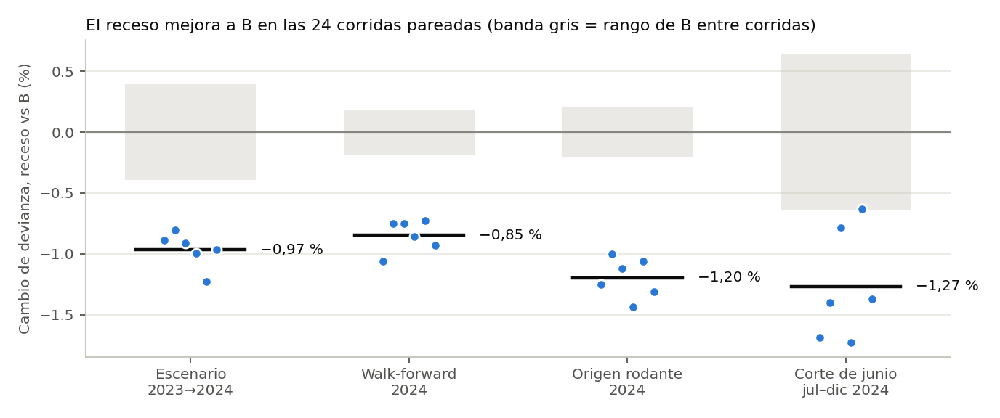

In [4]:
check("la validación no usa 2025 (n de prueba del escenario = viajes de 2024)", bool((t[t.diseno == "escenario"].n == 163236).all()))
filas = []
for d in VE.DISENOS:
    s1 = VE.senal(t, d, "B", "V0"); s2 = dec["paso_2"]["por_diseno"][d]["A"]
    j1 = VE._pares(t, d, "B", "V0"); n1 = int(((j1.dev_c - j1.dev_b) < 0).sum())
    b = dec["paso_2"]["por_diseno"][d]["B"]
    filas.append({"diseño": d, "B vs actual (media Δ)": pct(s1["media_delta"]), "B gana": f"{n1}/{len(j1)}",
                  "receso vs B (media Δ)": pct(s2["media_delta"]), "sd Δ": pct(s2["sd_delta"]).replace("+", ""),
                  "rango de B": pct(s2["rango_base"]).replace("+", ""), "receso gana 6/6": s2["todas_negativas"],
                  "A cumple": s2["cumple"], "sesgos cumplen": b["cumple"]})
p2 = pd.DataFrame(filas); display(p2)
print("Paso 1:", dec["paso_1"])
m = t.groupby(["diseno", "variante"])[["dev", "domlab_pred", "domlab_real", "sesgo_global", "sesgo_laboral", "sesgo_domingo",
                                       "sesgo_lab_04_05", "sesgo_lab_06_08", "sesgo_lab_feb", "sesgo_lab_ago"]].mean().round(3)
display(m.loc[(slice(None), ["V0", "B", "Rb"]), :])

fig, ax = plt.subplots(figsize=(8.6, 3.6))
for i, d in enumerate(VE.DISENOS):
    j = VE._pares(t, d, "Rb", "B"); dd = (j.dev_c - j.dev_b) / j.dev_b * 100
    ax.scatter(np.full(len(dd), i) + np.linspace(-0.12, 0.12, len(dd)), dd, s=36, color=COL["e1c"], edgecolor="white", lw=1.2, zorder=3)
    ax.plot([i - 0.25, i + 0.25], [dd.mean()] * 2, color=COL["texto"], lw=2)
    rb = dec["paso_2"]["por_diseno"][d]["A"]["rango_base"] * 100
    ax.fill_between([i - 0.3, i + 0.3], -rb, rb, color="#c3c2b7", alpha=0.35, lw=0)
    ax.text(i + 0.32, dd.mean(), f"{dd.mean():.2f} %".replace(".", ",").replace("-", "−"), va="center", fontsize=9, color=COL["texto"])
ax.axhline(0, color="#898781", lw=1)
ax.set_xticks(range(4)); ax.set_xticklabels(["Escenario\n2023→2024", "Walk-forward\n2024", "Origen rodante\n2024", "Corte de junio\njul–dic 2024"])
ax.set_ylabel("Cambio de devianza, receso vs B (%)", color=COL["texto2"], fontsize=9); estilo(ax)
ax.set_title("El receso mejora a B en las 24 corridas pareadas (banda gris = rango de B entre corridas)", fontsize=10, color=COL["texto"], loc="left")
fig.tight_layout(); fig.savefig(FIG / "receso_vs_B_validacion.png", dpi=160); plt.close(fig)
display(Image(FIG / "receso_vs_B_validacion.png"))
check("paso 1 (B frente al modelo original) cumple", dec["paso_1"]["cumple"])
check("paso 2 (receso frente a B) cumple en los 4 diseños", dec["paso_2"]["cumple"])

**Conclusión 3 · Quitar la tendencia y agregar el receso, decidido con 2023–2024**

| Diseño (solo 2023–2024) | B vs original | Receso vs B | Desv. est. | Rango de B | Corridas a favor |
|---|---:|---:|---:|---:|---:|
| Escenario 2023→2024 | −10,92 % | **−0,97 %** | 0,14 % | 0,40 % | 6/6 |
| Walk-forward 2024 | −3,14 % | **−0,85 %** | 0,13 % | 0,19 % | 6/6 |
| Origen rodante 2024 | −3,40 % | **−1,20 %** | 0,16 % | 0,21 % | 6/6 |
| Corte de junio (jul–dic) | −3,09 % | **−1,27 %** | 0,46 % | 0,64 % | 6/6 |

- **Paso 1 (quitar la tendencia) se cumple con holgura.** En el escenario, dom/laboral pasa de 0,846 a 0,692 (real 0,668) y la madrugada laboral de −15,95 a −0,88.
- **Paso 2 (receso frente a B) se cumple en los 4 diseños:**
  - mejora en las **24 de 24** corridas pareadas, con una media de entre 2,8 (corte de junio) y 7,3 desviaciones estándar, y por encima del rango de B;
  - cumple todas las tolerancias de sesgo.
- **Dónde actúa el receso** (escenario):
  - corrige sobre todo **agosto** (sesgo laboral −2,64 → −1,50);
  - **febrero** apenas (−4,00 → −3,43), menos de lo que anticipaba el consejo (su variante incluía mes y Semana Santa);
  - sube un poco el sesgo global (+0,95 → +1,11).
- Los 4 diseños comparten los mismos 6 entrenamientos por corrida: son 4 ventanas de evaluación, no 4 evidencias independientes.

## 4 · Pasos 3 y 4: receso por tipo, intradía y oráculo

In [5]:
filas = []
for d, v in dec["paso_3"]["por_diseno"].items():
    filas.append({"diseño": d, "R vs Rb (media Δ)": pct(v["A_vs_Rb"]["media_delta"]), "R gana 6/6": v["A_vs_Rb"]["todas_negativas"],
                  "A cumple": v["A_vs_Rb"]["cumple"], "sesgos vs B": v["B_vs_B"]["cumple"],
                  "fallan": [k for k, x in v["B_vs_B"]["condiciones"].items() if not x], "dom/lab no peor que Rb": v["domlab_no_peor_que_Rb"]})
display(pd.DataFrame(filas))
display(pd.DataFrame(dec["paso_4"]).T)
display(alc.groupby(["modelo", "variante"])[["dev", "domlab_pred", "sesgo_global", "sesgo_laboral", "sesgo_domingo"]].mean().round(3))
check("paso 4: intradía y oráculo no inferiores con el receso",
      all(v["no_inferior"] for v in dec["paso_4"].values()), str({k: v["variante_final"] for k, v in dec["paso_4"].items()}))

,diseño,R vs Rb (media Δ),R gana 6/6,A cumple,sesgos vs B,fallan,dom/lab no peor que Rb
0,escenario,"−0,26 %",False,False,True,[],False
1,walk_forward,"−0,14 %",True,False,True,[],False
2,origen_rodante,"−0,31 %",True,True,False,[tipo_domingo],False
3,corte_junio,"−0,49 %",True,False,False,"[tipo_domingo, domingo_laboral]",False


,dev_media,rango_B,B_vs_V0_media_delta,no_inferior,variante_final
modelo_intradia,"{'B': 2.3578963811527784, 'Rb': 2.3415160538078177, 'V0': 2.602681838124532}",0.001665,-0.094051,True,Rb
modelo_oraculo,"{'B': 2.2700684941700184, 'Rb': 2.264214365401133, 'V0': 2.3316094014608515}",0.002953,-0.026394,True,Rb


dev  domlab_pred  sesgo_global  sesgo_laboral  sesgo_domingo
modelo          variante                                                                
modelo_intradia B         2.358        0.693         0.288          0.073          2.282
                Rb        2.342        0.690         0.481          0.337          2.230
                V0        2.603        0.825        -2.670         -5.377          9.803
modelo_oraculo  B         2.270        0.682        -0.209         -0.421          1.002
                Rb        2.264        0.682        -0.122         -0.309          1.016
                V0        2.332        0.730        -0.946         -2.050          4.095

**Conclusión 4 · Receso binario en los tres modelos**
- **`receso_tipo` no le gana a la binaria:**
  - mejora −0,14 % a −0,49 %, dentro del ruido en 3 de 4 diseños;
  - empeora el sesgo del domingo en el origen rodante y en el corte de junio;
  - nunca mejora el contraste domingo/laboral.
  - Queda **Rb**.
- **Intradía** (escenario, 6 corridas): 2,603 → 2,358 al quitar la tendencia (−9,4 %) → 2,342 con el receso.
- **Oráculo:** 2,332 → 2,270 (−2,6 %) → 2,264.
- Los dos pasan la verificación de no inferioridad, así que **los 3 modelos usan Rb**: las mismas 33 / 45 / 53 variables, con `receso` en lugar de `tendencia_meses`.

## 5 · 2025: evaluación única de la versión corregida (no ciega)

,dev,mae,mejora_vs_linea_base_%,cambio_vs_7_3_%,sesgo_global,domlab_pred,domlab_real,sesgo_laboral,sesgo_sabado,sesgo_domingo,sesgo_lab_04_05,sesgo_lab_06_08,sesgo_lab_feb,sesgo_lab_ago
config,,,,,,,,,,,,,,
linea_base,2.929,23.485,0.000,NaN,5.955,0.678,0.671,6.560,4.525,5.050,7.277,4.317,-1.371,-1.287
7_3_modelo_0400,2.503,20.706,14.543,NaN,-2.971,0.842,0.671,-5.542,1.616,10.009,-17.001,-7.694,-10.175,-10.737
7_3_modelo_intradia,2.406,20.380,17.857,NaN,-1.754,0.816,0.671,-3.924,1.933,9.254,-13.970,-6.529,-7.346,-8.221
7_3_modelo_oraculo,2.222,19.670,24.148,NaN,-0.478,0.726,0.671,-1.224,0.592,3.852,-5.967,-0.368,-3.257,-3.566
e1c_modelo_0400,2.248,19.969,23.235,-10.172,1.787,0.694,0.671,1.786,0.680,3.229,0.397,2.387,-1.155,-1.768
e1c_modelo_intradia,2.216,19.747,24.320,-7.868,0.893,0.697,0.671,0.720,0.270,2.783,-0.239,1.653,-1.544,-2.598
e1c_modelo_oraculo,2.196,19.599,25.024,-1.156,0.256,0.688,0.671,0.087,0.071,1.553,-1.306,1.775,-1.383,-1.808


El 04:00 corregido mejora al oficial en 11 de 12 meses; peor en: ['2025-12']


config,linea_base,7_3_modelo_0400,e1c_modelo_0400,7_3_modelo_intradia,e1c_modelo_intradia
grupo,,,,,
04–06,5.15,-15.16,0.65,-12.54,0.15
07–09,8.34,-4.05,3.70,-3.52,2.52
10–12,5.18,-2.38,3.39,-1.33,1.83
13–15,8.31,-4.21,2.04,-1.82,0.70
16–18,6.04,-3.09,0.16,-2.10,-1.02
19–20,6.36,3.63,-0.29,5.68,-0.79


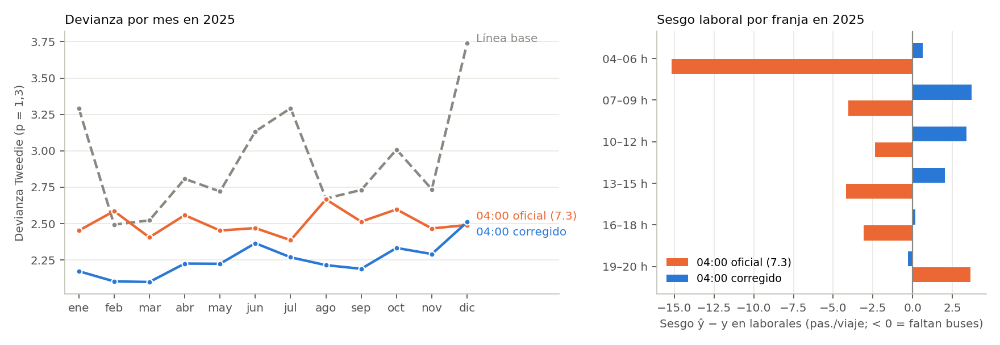

In [6]:
meta = json.loads(Path("modelos_e1c/modelo_0400_meta.json").read_text(encoding="utf-8"))
check("modelos finales con el mismo entrenamiento de la 7.3 (324.508 viajes, cierre ≤ 2025-01-01 04:00)",
      meta["n_entrenamiento"] == 324508 and pd.Timestamp(meta["max_fechafin"]) <= pd.Timestamp("2025-01-01 04:00"))
check("holdout completo (158.507 viajes)", int(h.n.iloc[0]) == 158507)
check("cifras oficiales de la 7.3 intactas (devianza 04:00 = 2,503)", round(h.loc["7_3_modelo_0400", "dev"], 3) == 2.503)
cols = ["dev", "mae", "mejora_vs_linea_base_%", "cambio_vs_7_3_%", "sesgo_global", "domlab_pred", "domlab_real", "sesgo_laboral",
        "sesgo_sabado", "sesgo_domingo", "sesgo_lab_04_05", "sesgo_lab_06_08", "sesgo_lab_feb", "sesgo_lab_ago"]
display(h[cols].round(3))
mes = des[des.dimension == "mes"].pivot(index="grupo", columns="config", values="dev")
mejor = int((mes["e1c_modelo_0400"] < mes["7_3_modelo_0400"]).sum())
print(f"El 04:00 corregido mejora al oficial en {mejor} de 12 meses; peor en:",
      list(mes.index[mes["e1c_modelo_0400"] >= mes["7_3_modelo_0400"]]))
lf = des[des.dimension == "laboral_franja"].pivot(index="grupo", columns="config", values="sesgo")
display(lf[["linea_base", "7_3_modelo_0400", "e1c_modelo_0400", "7_3_modelo_intradia", "e1c_modelo_intradia"]].round(2))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axs[0]; x = np.arange(12); lab = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
for k, c, nom, ls in [("linea_base", COL["linea_base"], "Línea base", "--"), ("7_3_modelo_0400", COL["7_3"], "04:00 oficial (7.3)", "-"),
                      ("e1c_modelo_0400", COL["e1c"], "04:00 corregido", "-")]:
    y = mes[k].to_numpy(); ax.plot(x, y, ls, color=c, lw=2, marker="o", ms=4.5, markeredgecolor="white")
    ax.text(11.25, y[-1] + (0.03 if k == "linea_base" else (-0.07 if k == "e1c_modelo_0400" else 0.06)), nom, color=c, fontsize=9, va="center")
ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_xlim(-0.4, 13.6); ax.set_ylabel("Devianza Tweedie (p = 1,3)", fontsize=9, color=COL["texto2"])
ax.set_title("Devianza por mes en 2025", fontsize=10, loc="left", color=COL["texto"]); estilo(ax)
ax = axs[1]; fr = list(lf.index); yy = np.arange(len(fr))
ax.barh(yy + 0.19, lf["7_3_modelo_0400"], height=0.36, color=COL["7_3"], label="04:00 oficial (7.3)")
ax.barh(yy - 0.19, lf["e1c_modelo_0400"], height=0.36, color=COL["e1c"], label="04:00 corregido")
ax.axvline(0, color="#898781", lw=1); ax.set_yticks(yy); ax.set_yticklabels([f"{f} h" for f in fr]); ax.invert_yaxis()
ax.set_xlabel("Sesgo ŷ − y en laborales (pas./viaje; < 0 = faltan buses)", fontsize=9, color=COL["texto2"])
ax.set_title("Sesgo laboral por franja en 2025", fontsize=10, loc="left", color=COL["texto"]); estilo(ax); ax.grid(axis="x", color=COL["grid"]); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "holdout_2025_e1c.png", dpi=160); plt.close(fig)
display(Image(FIG / "holdout_2025_e1c.png"))

**Conclusión 5 · 2025 con la versión corregida (evaluación única, no ciega)**

| Modelo | 7.3 oficial | Corregido | Cambio | Mejora vs línea base (corregido) |
|---|---:|---:|---:|---:|
| Línea base | 2,929 | — | — | — |
| **04:00** | 2,503 | **2,248** | **−10,2 %** | −23,2 % |
| Intradía | 2,406 | 2,216 | −7,9 % | −24,3 % |
| Oráculo | 2,222 | 2,196 | −1,2 % | −25,0 % |

- **El 04:00 corregido mejora al oficial en 11 de 12 meses** (diciembre: 2,510 frente a 2,490). Queda casi al nivel del oráculo de la 7.3 (2,222).
- **Contraste semanal:** dom/laboral predicho **0,694** frente a 0,671 real (antes 0,842).
  - Sesgo laboral −5,54 → +1,79; domingo +10,01 → +3,23.
  - Madrugada laboral 04–05 h **−17,00 → +0,40**.
  - Febrero −10,18 → −1,16; agosto −10,74 → −1,77.
- **El sesgo cambió de signo: ahora sobrepredice +1,79 pas./viaje (≈ 2 %).**
  - Sobre todo entre las 07 y las 15 h en laborales (+2,0 a +3,7).
  - Sin tendencia, la caída de la demanda de 2025 solo la siguen los rezagos, con retraso.
- **No es una evaluación ciega.**
  - 2025 ya se había mirado varias veces, y la hipótesis del calendario escolar salió de sus residuos.
  - La variante se eligió solo con 2023–2024, con la regla congelada, y se evaluó una vez.
  - Coincide con el contrafactual de la 8.2 (2,251–2,278): confirma el diagnóstico, pero no lo convierte en resultado.
- **Las cifras oficiales del Entregable 1 siguen siendo las de la 7.3.** Las corregidas se reportan al lado. No se recalcularon el DM ni el SHAP sobre 2025.

## 6 · Checks y limitaciones

In [7]:
ch = pd.DataFrame(CHECKS); ch.to_csv(D / "checks_e1c.csv", index=False); display(ch)
print(f"{int((ch.resultado == 'PASS').sum())}/{len(ch)} PASS")
print("Limitaciones declaradas en la regla:", *regla["limitaciones_declaradas"], sep="\n  - ")

,check,resultado,detalle
0,"2024 reproduce la compresión de 2025 (V0 dom/lab − real > 0,10 en las 6 corridas)",PASS,0.837–0.857 vs 0.668
1,la walk-forward 2024 ya extrapolaba (100 % fuera de rango en los 6 pliegues),PASS,
2,tests_e1c.py,PASS,7/7 PASS
3,"decisión oficial, con la regla congelada",PASS,
4,variables de modelo_0400 = hash de la decisión,PASS,
5,variables de modelo_intradia = hash de la decisión,PASS,
6,variables de modelo_oraculo = hash de la decisión,PASS,
7,la validación no usa 2025 (n de prueba del escenario = viajes de 2024),PASS,
8,paso 1 (B frente al modelo original) cumple,PASS,
9,paso 2 (receso frente a B) cumple en los 4 diseños,PASS,


14/14 PASS
Limitaciones declaradas en la regla:
  - los resultados preliminares del consejo (Rb − B −0,87 % en el escenario y −1,18 % en el origen rodante) se conocían al escribir esta regla
  - el receso de inicio de año no se puede validar con 2023–2024: el entrenamiento ve un solo enero
  - un solo año de prueba (2024); los 4 diseños comparten entrenamientos
  - hiperparámetros y rondas elegidos con 2024 y con la tendencia presente: los niveles absolutos son optimistas; las comparaciones entre variantes siguen siendo pareadas y justas
  - las tolerancias de sesgo (0,5; 1,0; 0,01; +1,5) son operativas (planificador y pasajeros del consejo), no estadísticas


**Conclusión 6 · Qué queda abierto**
- **14/14 checks PASS** (`datos_e1c/checks_e1c.csv`).
- **Abierto para el Entregable 2:**
  - **Sobrepredicción de nivel** (+1,8 pas./viaje en 2025): probar el nivel como offset (`init_score` con la media reciente) o una recalibración mensual por franja, nunca global.
  - **Receso de inicio de año:** su efecto se estimó con un solo enero y no se pudo validar fuera de muestra con 2023–2024.
  - **Un solo año de prueba** (2024) para decidir. Hiperparámetros y rondas elegidos con la tendencia presente: los niveles absolutos de la validación son optimistas, aunque las comparaciones pareadas siguen siendo justas.
  - **Calendario:** el escolar cubre hasta el 27-dic-2026 y `calendario_dias.csv` (festivos y carnaval) termina el 31-dic-2025. Ambos hay que extenderlos antes de emitir en 2026; el escolar falla de forma explícita si falta.
  - **Guarda de rango por variable** en la emisión, para que otra variable monótona no vuelva a entrar sin aviso.
- `tests_8_2.py` exige `tendencia_meses`: aplica al modelo oficial de la 7.3 y no se re-ejecuta sobre la versión corregida.

<a id="a2"></a>

---

# Anexo A2 · Operación: los módulos 9–15 que usan el pronóstico

Cada módulo abre con una línea que dice qué recibe del pronóstico o qué le entrega. El e2c.6 (el simulador alimentado por el pronóstico) va después del Módulo 13, porque usa su motor.

<sub>[&#8679; volver al índice](#indice)</sub>


<a id="m9"></a>

---

## A2.1 &middot; Módulo 9 · Fiabilidad vehicular y scoring de riesgo del conductor

**Qué aporta al pronóstico.** No recibe ŷ: entrega `p_varada_jornada`, la probabilidad calibrada de que cada bus se vare en la jornada. El simulador la usa para sortear las varadas y el redespacho del Módulo 14 para la flota disponible.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m9-1"></a>

### A2.1.1 &middot; Módulo 9 · Fiabilidad y scoring

<sub>Notebook original: `modulo9/modulo_9_fiabilidad_scoring.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 9 — Fiabilidad vehicular y scoring de riesgo del conductor

**Integrante 1 · Core ML & Optimización.** Requisitos **R2** (fiabilidad por desgaste de flota) y **R3** (scoring conductual), según el *Plan técnico v2.0, Módulos 9 a 14*. Continúa los Módulos 1–8 (Entregable 1): usa sus maestras sin modificarlas, la misma ventana (2023–2025), la misma tarifa de negocio (3.700 COP) y la misma regla de oro: **2025 es holdout y se evalúa una sola vez**.

| Elemento | Decisión |
|---|---|
| Unidad R2 | Bus × día con al menos un despacho programado (208.143 bus-días). Emisión a las 04:00 del día *t*: toda feature usa solo días < *t* |
| Etiqueta R2 | **Varada en jornada (proxy operativo):** viaje iniciado que cubre entre el 5 % y el 50 % de `distancia_global`, es el último despacho iniciado del bus ese día y sale a más tardar a las 16 h. Si existe la extracción E1, se audita contra los motivos mecánicos de `observacion` |
| Modelo R2 | LightGBM binario (rondas por early stopping en 2024-T2, reajuste con train + val) + **Platt scaling** en 2024-S2 |
| Partición R2 | Calentamiento 2023-T1 · train 2023-04 → 2024-03 · val 2024-04 → 2024-06 · calibración 2024-07 → 2024-12 · **holdout 2025** |
| Métricas R2 | ROC-AUC con **DeLong** (vs azar y pareado vs líneas base), **Brier** (y skill vs climatología, descomposición de Murphy), ECE, PR-AUC, captura del top-k % |
| Score R3 | Componentes por viaje → observado/esperado por ruta × franja → contracción Poisson-Gamma → z → pesos 50 % experto + 50 % PCA (CP1) → reputación 0–100 |
| Validación R3 | Fuera de tiempo: score 2024 frente a resultados 2025 — **Gini** (IC DeLong) y **Kolmogorov-Smirnov** |
| Entregables | `src/features/reliability_scoring.py`, `extraer_modulo9.py`, `tests_9.py`, `sql/tb_scoring_vehiculo_conductor.sql` y la tabla `datos_9/tb_scoring_vehiculo_conductor.parquet` |

## Parte 1 · Extracción contra la RDS

Las columnas que el plan pide de `vehiculos` (inspección, póliza) y de `progvehiculos` (`idconductor`, `observacion`) **no están en los archivos locales del Entregable 1**. `extraer_modulo9.py` las trae (solo lectura, contraseña con `getpass`, nunca `SELECT *` sobre `vehiculos`, `conteo_pasajeros_destino` solo por `idprogramacion = ANY(:ids)` y agregada en el servidor):

- **E1** `progvehiculos`: `idconductor`, `iddespachador`, `observacion`, `excedeplazosalida`.
- **E2** búsqueda en `information_schema` de columnas de revisión técnica, SOAT o mantenimiento en todo el esquema + columnas técnicas de `vehiculos`.
- **E3** velocidades GPS por viaje (hasta 4 viajes por conductor y semestre), calculadas en SQL con la misma lógica que `R.velocidad_por_viaje` (verificada en la prueba f).

```
py -3.10 extraer_modulo9.py
```

Este notebook detecta qué archivos existen y se adapta: **sin la extracción, R2 se entrena completo y R3 se calcula por vehículo** (la unidad disponible); con E1, R3 se calcula además por conductor.

In [1]:
from src.features import reliability_scoring as R
EXTRA = R.cargar_extraccion()
for k in ["progvehiculos", "vehiculos", "columnas_tecnicas", "velocidad"]:
    print(f"{k:18s}", f"{len(EXTRA[k]):,} filas" if k in EXTRA else "— no extraído")

progvehiculos      564,837 filas
vehiculos          656 filas
columnas_tecnicas  12 filas
velocidad          11,891 filas


## Parte 2 · Análisis offline

In [2]:
import json
import time
import warnings
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import chi2_contingency
from sklearn.metrics import average_precision_score, roc_curve

import tests_9 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 110)
warnings.filterwarnings("ignore", category=FutureWarning)
T0 = time.time()
CFG = R.CFG
SALIDA = R.DATOS_9; SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_9"); FIG.mkdir(exist_ok=True)
CHECKS = []


def check(nombre, ok, detalle="", info=False):
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


def figura(nombre):
    plt.tight_layout(); plt.savefig(FIG / nombre, dpi=120); plt.close(); display(Image(str(FIG / nombre)))


v = R.cargar_viajes(extra=EXTRA)
veh, cal = R.cargar_vehiculos(), R.cargar_calendario()
print(f"Fuente: {R.RAIZ_SOBUSA}")
print(f"{len(v):,} despachos 2023–2025 · {v.inicio.sum():,} iniciados · {v.idvehiculo.nunique()} buses")

Fuente: C:\Users\<usuario>\OneDrive\Escritorio\UNIVERSIDAD\2026\2026-3\MACHINE LEARNING\ENTREGABLE_1_SOBUSA\entrega_1_DATACHALLENGE\Sobusa\Sobusa
564,837 despachos 2023–2025 · 561,427 iniciados · 449 buses


## 1 · Auditoría de las fuentes del plan

In [3]:
raiz = R.RAIZ_SOBUSA
nul = pd.read_csv(raiz / "datos_1_4" / "nulos_progvehiculos.csv")
total = int(nul.total.iloc[0])
cols_veh = [c.strip() for c in pd.read_csv(raiz / "datos_1_3" / "vehiculos_candidatos.csv").columnas.iloc[0].split(",")]
locales = {"modelo", "idvehiculo", "numerobloqueos", "excedeplazosalida"}
plan = [
    ("modelo", "vehiculos", "edad_bus = año − modelo; sin modelo → indicadora"),
    ("fecha_vencimiento_tecnomecanica", "vehiculos", "Foto actual → E2; días hasta el vencimiento solo dentro de su año de vigencia"),
    ("fecha_vencimiento_soap", "vehiculos", "Ídem (SOAT)"),
    ("fecha_inspeccion", "vehiculos", "Solo la última inspección (foto actual) → E2; se usa solo si ocurrió antes de t"),
    ("resultado_inspeccion", "vehiculos", "Sin historial no se puede calcular el % de inspecciones reprobadas"),
    ("vel_max_dia", "vehiculos", "Foto del día de la consulta: se reemplaza por velocidad GPS por viaje (E3)"),
    ("vel_prom_dia", "vehiculos", "Ídem"),
    ("idconductor", "progvehiculos", "Unidad de R3; no está en los archivos locales → E1"),
    ("idvehiculo", "progvehiculos", "Unidad de R2"),
    ("numerobloqueos", "progvehiculos", "Bandera binaria > 0 (regla del Módulo 1)"),
    ("acumulada_bloqueo", "progvehiculos", "No usar: contador de toda la vida del equipo (Módulo 1)"),
    ("bloqueo_cond", "progvehiculos", "Inutilizable"),
    ("bloqueo_veh", "progvehiculos", "Inutilizable"),
    ("excedeplazosalida", "progvehiculos", "Casi vacía: se usa retraso_salida_min de tb_despachos"),
]
filas = []
for var, tabla, uso in plan:
    existe = var in (cols_veh if tabla == "vehiculos" else nul.columns)
    if tabla == "progvehiculos":
        pct = nul[var].iloc[0] / total if var in nul else np.nan
    else:
        e2v = EXTRA.get("vehiculos")
        pct = e2v[var].notna().mean() if (e2v is not None and var in e2v) else np.nan
    filas.append({"variable_plan": var, "tabla": tabla, "existe_en_rds": existe, "pct_no_nulo": pct,
                  "en_archivos_locales": var in locales, "uso_en_modulo_9": uso})
auditoria = pd.DataFrame(filas)
auditoria.to_csv(SALIDA / "auditoria_fuentes_9.csv", index=False)
display(auditoria.style.format({"pct_no_nulo": "{:.1%}"}, na_rep="—"))
print(f"vehiculos tiene {len(cols_veh)} columnas; relacionadas con mantenimiento/documentos:",
      [c for c in cols_veh if any(k in c for k in ["inspec", "poliza", "asegur", "odometro", "tecno", "soap", "soat", "venc", "fechaingreso", "despacho_hab"])])
print(f"observacion no nula: {nul.observacion.iloc[0] / total:.1%} de {total:,} programaciones")
check("Auditoría de fuentes", True,
      f"{int(auditoria.existe_en_rds.sum())}/{len(auditoria)} variables del plan existen en la RDS; "
      f"{int(auditoria.en_archivos_locales.sum())} están en los archivos locales; "
      f"bloqueo_cond/bloqueo_veh {auditoria.set_index('variable_plan').pct_no_nulo['bloqueo_cond']:.0%} no nulas", info=True)

,variable_plan,tabla,existe_en_rds,pct_no_nulo,en_archivos_locales,uso_en_modulo_9
0,modelo,vehiculos,True,73.0%,True,edad_bus = año − modelo; sin modelo → indicadora
1,fecha_vencimiento_tecnomecanica,vehiculos,True,0.0%,False,Foto actual → E2; días hasta el vencimiento solo dentro de su año de vigencia
2,fecha_vencimiento_soap,vehiculos,True,0.0%,False,Ídem (SOAT)
3,fecha_inspeccion,vehiculos,True,0.0%,False,Solo la última inspección (foto actual) → E2; se usa solo si ocurrió antes de t
4,resultado_inspeccion,vehiculos,True,0.0%,False,Sin historial no se puede calcular el % de inspecciones reprobadas
5,vel_max_dia,vehiculos,True,100.0%,False,Foto del día de la consulta: se reemplaza por velocidad GPS por viaje (E3)
6,vel_prom_dia,vehiculos,True,100.0%,False,Ídem
7,idconductor,progvehiculos,True,100.0%,False,Unidad de R3; no está en los archivos locales → E1
8,idvehiculo,progvehiculos,True,100.0%,True,Unidad de R2
9,numerobloqueos,progvehiculos,True,98.5%,True,Bandera binaria > 0 (regla del Módulo 1)


vehiculos tiene 144 columnas; relacionadas con mantenimiento/documentos: ['fechaingreso', 'asegurado', 'aseguradora', 'vigencia_poliza', 'poliza', 'fecha_poliza', 'ultimo_odometro', 'despacho_habilitado', 'fecha_inspeccion', 'resultado_inspeccion', 'fecha_vencimiento_tecnomecanica', 'fecha_vencimiento_soap']
observacion no nula: 8.7% de 564,837 programaciones


**Conclusión 1 · Fuentes**
- **Las 14 variables del plan existen en la RDS**, pero solo 4 estaban en los archivos locales del Entregable 1. "Quey.csv" no existe como archivo: sus columnas son de la tabla `vehiculos` (144 columnas). Las demás se trajeron con la Parte 1.
- **Existen, pero están vacías** (0 % no nulo):
  - en `vehiculos`: `fecha_inspeccion`, `resultado_inspeccion`, `fecha_vencimiento_tecnomecanica` y `fecha_vencimiento_soap` (también `vigencia_poliza` y `fecha_poliza`);
  - en `progvehiculos`: `bloqueo_cond` y `bloqueo_veh`.
  - **El sub-modelo de varadas no puede usar revisión técnica, SOAT ni inspecciones**: SOBUSA no los registra en la base.
- `excedeplazosalida` solo está lleno en el 1,2 %: se usa `retraso_salida_min` de `tb_despachos`. `acumulada_bloqueo` es un contador de toda la vida del equipo (regla del Módulo 1).
- `vel_max_dia` y `vel_prom_dia` están llenas, pero son del día de la consulta (foto actual): se reemplazan por la velocidad GPS por viaje (Sección 6).
- `modelo` está en el 73,0 % de los vehículos. `idconductor` está lleno al 100 %, pero incluye un ID genérico (Conclusión 7).

## 2 · Etiqueta de varada en jornada y su validación

,bus_dias,varadas,tasa
fecha,,,
2023,70248,684,0.97%
2024,69975,884,1.26%
2025,67920,999,1.47%


Viajes marcados: 2,567 (0.46% de los iniciados) · cancelados 18.2% · ratio de distancia mediano 0.20


,lun_jue,y,bus_dias,ausente_dia_siguiente,viajes_ese_dia
0,False,0,81642,33.9%,2.72
1,False,1,1035,53.8%,1.88
2,True,0,123507,18.9%,2.71
3,True,1,1510,38.1%,1.66


P(ausente al día siguiente): varada 44.5% vs resto 24.9% (χ² p = 1.9e-113); lun–jue: 38.1% vs 18.9% (p = 1.9e-78)
Sobredispersión entre 293 buses con ≥ 100 bus-días: 3.38 (tasa por bus P10–P90: 0.41% – 2.43%)


y_obs,0,All
y_proxy,,
0,205576,205576
1,2567,2567
All,208143,208143


,programaciones
observacion,
CANCELADA AUTOMATICAMENTE,44144
EXCEDIO EL PLAZO DE SALIDA,5181
CANCELADO AUTOMATICAMENTE,6


observacion tiene solo 3 valores distintos, todos automáticos: no registra motivos mecánicos. La etiqueta proxy es la única disponible.


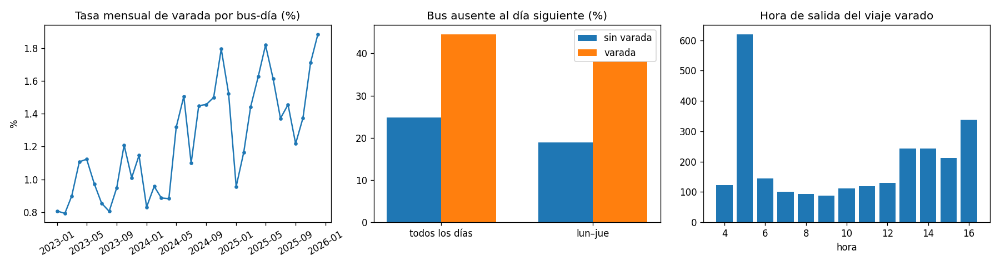

In [4]:
p = R.panel_bus_dia(v, "proxy")
anual = p.groupby(p.fecha.dt.year).agg(bus_dias=("y", "size"), varadas=("y", "sum"), tasa=("y", "mean"))
display(anual.style.format({"tasa": "{:.2%}"}))
var_v = v[v.varada_proxy]
print(f"Viajes marcados: {len(var_v):,} ({len(var_v) / v.inicio.sum():.2%} de los iniciados) · "
      f"cancelados {var_v.cancelado.mean():.1%} · ratio de distancia mediano {var_v.ratio.median():.2f}")

# Validación 1: un bus varado debería faltar más al día siguiente (taller)
q = p.sort_values(["idvehiculo", "fecha"]).copy()
q["siguiente"] = q.groupby("idvehiculo").fecha.shift(-1)
q = q[q.siguiente.notna()]
q["ausente_sig"] = (q.siguiente - q.fecha).dt.days > 1
q["lun_jue"] = q.fecha.dt.dayofweek <= 3
val = (q.groupby(["lun_jue", "y"]).agg(bus_dias=("y", "size"), ausente_dia_siguiente=("ausente_sig", "mean"),
                                        viajes_ese_dia=("viajes_dia", "mean")).reset_index())
display(val.style.format({"ausente_dia_siguiente": "{:.1%}", "viajes_ese_dia": "{:.2f}"}))
chi = chi2_contingency(pd.crosstab(q.y, q.ausente_sig))
lj = q[q.lun_jue]
chi_lj = chi2_contingency(pd.crosstab(lj.y, lj.ausente_sig))
a1, a0 = q[q.y == 1].ausente_sig.mean(), q[q.y == 0].ausente_sig.mean()
b1, b0 = lj[lj.y == 1].ausente_sig.mean(), lj[lj.y == 0].ausente_sig.mean()
print(f"P(ausente al día siguiente): varada {a1:.1%} vs resto {a0:.1%} (χ² p = {chi[1]:.1e}); "
      f"lun–jue: {b1:.1%} vs {b0:.1%} (p = {chi_lj[1]:.1e})")

# Validación 2: heterogeneidad entre buses (si fuera ruido puro, la dispersión sería ≈ 1)
pb = p.groupby("idvehiculo").y.agg(["sum", "size"])
pb = pb[pb["size"] >= 100]
p0 = p.y.mean()
disp = ((pb["sum"] - pb["size"] * p0) ** 2).sum() / (pb["size"] * p0 * (1 - p0)).sum()
print(f"Sobredispersión entre {len(pb)} buses con ≥ 100 bus-días: {disp:.2f} "
      f"(tasa por bus P10–P90: {pb['sum'].div(pb['size']).quantile(.1):.2%} – {pb['sum'].div(pb['size']).quantile(.9):.2%})")

po = None
if "varada_obs" in v:
    from sklearn.metrics import cohen_kappa_score
    po = R.panel_bus_dia(v, "observacion")
    m = p[["idvehiculo", "fecha", "y"]].merge(po[["idvehiculo", "fecha", "y"]], on=["idvehiculo", "fecha"], suffixes=("_proxy", "_obs"))
    display(pd.crosstab(m.y_proxy, m.y_obs, margins=True))
    display(R._sin_tildes(v.observacion[v.observacion.notna()]).value_counts().head(25).to_frame("programaciones"))
    v.loc[v.varada_obs, "observacion"].value_counts().head(60).to_csv(SALIDA / "observacion_mecanica_9.csv")
    valores = v.observacion.dropna().nunique()
    if m.y_obs.any():
        kappa = cohen_kappa_score(m.y_proxy, m.y_obs)
        cubre = m.loc[m.y_obs == 1, "y_proxy"].mean()
        precision = m.loc[m.y_proxy == 1, "y_obs"].mean()
        print(f"Bus-días con motivo mecánico en observacion: {int(m.y_obs.sum()):,} ({m.y_obs.mean():.2%}) · "
              f"el proxy marca el {cubre:.1%} de ellos · de los bus-días proxy, {precision:.1%} tienen motivo mecánico · κ = {kappa:.3f}")
        detalle = f"{int(m.y_obs.sum()):,} bus-días mecánicos; cobertura del proxy {cubre:.1%}; precisión {precision:.1%}; κ {kappa:.3f}"
    else:
        print(f"observacion tiene solo {valores} valores distintos, todos automáticos: no registra motivos mecánicos. "
              "La etiqueta proxy es la única disponible.")
        detalle = f"0 motivos mecánicos en {int(v.observacion.notna().sum()):,} observaciones ({valores} valores distintos)"
        po = None
    check("Etiqueta · auditoría contra observacion (E1)", True, detalle, info=True)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
mes = p.groupby(p.fecha.dt.to_period("M")).y.mean()
ax[0].plot(mes.index.to_timestamp(), mes.values * 100, marker="o", ms=3)
ax[0].set_title("Tasa mensual de varada por bus-día (%)"); ax[0].set_ylabel("%"); ax[0].tick_params(axis="x", rotation=30)
lab = ["todos los días", "lun–jue"]
ax[1].bar(np.arange(2) - 0.18, [a0 * 100, b0 * 100], 0.36, label="sin varada")
ax[1].bar(np.arange(2) + 0.18, [a1 * 100, b1 * 100], 0.36, label="varada")
ax[1].set_xticks(range(2)); ax[1].set_xticklabels(lab); ax[1].set_title("Bus ausente al día siguiente (%)"); ax[1].legend()
ax[2].bar(*np.unique(var_v.hora, return_counts=True)); ax[2].set_title("Hora de salida del viaje varado"); ax[2].set_xlabel("hora")
figura("m9_etiqueta_varada.png")
check("Etiqueta · varada → más ausencias al día siguiente", (a1 > a0) and chi[1] < 0.05 and (b1 > b0) and chi_lj[1] < 0.05,
      f"{a1:.1%} vs {a0:.1%} (p {chi[1]:.1e}); lun–jue {b1:.1%} vs {b0:.1%}")
check("Etiqueta · heterogeneidad entre buses", disp > 1.5, f"índice de dispersión {disp:.2f} (> 1 = no es ruido homogéneo)")

**Conclusión 2 · Etiqueta de varada**
- **2.567 viajes marcados** (0,46 % de los iniciados). El 18,2 % figuraba como "cancelado" y recorren una mediana del 20 % de la ruta.
- **Tasa por bus-día:** 0,97 % (2023) → 1,26 % (2024) → 1,47 % (2025). La flota se degrada.
- **Validación externa:** tras una varada, el bus falta al día siguiente el **44,5 %** de las veces, frente al 24,9 % (χ² p = 1,9e-113). De lunes a jueves, 38,1 % frente a 18,9 %. Es la huella de un paso por taller.
- **No es ruido homogéneo:** el índice de dispersión entre 293 buses es 3,38, con una tasa por bus de 0,41 % a 2,43 % (P10–P90).
- **Auditoría con E1:** `observacion` solo tiene 3 valores, todos automáticos ("CANCELADA AUTOMATICAMENTE" 44.144, "EXCEDIÓ EL PLAZO DE SALIDA" 5.181, "CANCELADO AUTOMATICAMENTE" 6).
  - **No hay un solo motivo mecánico registrado**, así que la etiqueta proxy es la única posible.
  - Sigue siendo un *proxy*: no distingue una varada mecánica de otro retiro anticipado. Debe validarse con la bitácora de taller de SOBUSA.

## 3 · Panel bus-día y features sin leakage

In [5]:
ETIQUETA = "proxy"
E2 = EXTRA.get("vehiculos") if R.documentos_utiles(EXTRA.get("vehiculos")) else None
if "vehiculos" in EXTRA and E2 is None:
    print("E2 extraído, pero inspección / tecnomecánica / SOAT están 100 % vacías: no entran al modelo.")
X = R.features_r2(v, p[["idvehiculo", "fecha"]], ETIQUETA, vehiculos=veh, calendario=cal, vehiculos_extra=E2)
P = p.merge(X, on=["idvehiculo", "fecha"])
P["conjunto"] = R.asignar_conjunto(P.fecha)
FEATS = R.FEATURES_R2 + (R.FEATURES_R2_VEHICULOS if E2 is not None else [])
conj = (P.groupby("conjunto").agg(desde=("fecha", "min"), hasta=("fecha", "max"), bus_dias=("y", "size"),
                                   varadas=("y", "sum"), tasa=("y", "mean"))
        .loc[["calentamiento", "train", "val", "calib", "holdout"]])
display(conj.style.format({"tasa": "{:.2%}", "desde": "{:%Y-%m-%d}", "hasta": "{:%Y-%m-%d}"}))
DESCR = {
    "edad_bus": ("año de t − modelo", "estática"), "modelo_faltante": ("bus sin modelo registrado", "estática"),
    "capacidad": ("n_sentados + n_depie", "estática"),
    "km_7d": ("km recorridos (topados a 1,5 × ruta)", "7 d"), "km_30d": ("km recorridos", "30 d"), "km_90d": ("km recorridos", "90 d"),
    "viajes_30d": ("viajes iniciados", "30 d"), "dias_operados_30d": ("días con al menos un viaje", "30 d"),
    "km_por_dia_operado_30d": ("intensidad de uso", "30 d"),
    "varadas_30d": ("varadas previas", "30 d"), "varadas_90d": ("varadas previas", "90 d"), "varadas_365d": ("varadas previas", "365 d"),
    "tasa_varada_365d": ("varadas / días operados", "365 d"), "dias_desde_ultima_varada": ("días desde la última varada, topado a 365", "365 d"),
    "tasa_interrumpido_90d": ("viajes < 50 % de la ruta que no son varada", "90 d"),
    "tasa_recorte_90d": ("viajes con 50–90 % de la ruta", "90 d"),
    "tasa_cancelado_30d": ("programaciones canceladas", "30 d"), "tasa_bloqueo_30d": ("viajes con numerobloqueos > 0", "30 d"),
    "tasa_sensor_falla_90d": ("viajes con flag_sensor_ok = False (Módulo 1.3)", "90 d"),
    "retraso_medio_30d": ("retraso de salida medio, topado a [−15, 60] min", "30 d"),
    "dias_desde_operacion_previa": ("días desde el último día operado", "toda la historia"),
    "ruta_habitual": ("ruta más frecuente", "30 d"), "dia_semana": ("día de la semana de t", "calendario"),
    "mes": ("mes de t (estacionalidad de lluvias / arroyos)", "calendario"), "es_festivo": ("festivo nacional (Módulo 3)", "calendario"),
    "dias_hasta_venc_tecnomecanica": ("fecha_vencimiento_tecnomecanica − t, solo dentro de su año de vigencia", "foto E2"),
    "dias_hasta_venc_soap": ("fecha_vencimiento_soap − t, solo dentro de su año de vigencia", "foto E2"),
    "dias_desde_inspeccion": ("t − fecha_inspeccion, solo si fecha_inspeccion < t", "foto E2"),
    "inspeccion_no_aprobada": ("resultado_inspeccion no aprobado, solo si fecha_inspeccion < t", "foto E2"),
}
dic = pd.DataFrame([{"feature": f, "descripcion": DESCR[f][0], "ventana": DESCR[f][1],
                     "cobertura": P[f].notna().mean()} for f in FEATS])
dic.to_csv(SALIDA / "diccionario_features_9.csv", index=False)
display(dic.style.format({"cobertura": "{:.1%}"}))
P.to_parquet(SALIDA / "panel_bus_dia_9.parquet", index=False)
print(f"Panel: {len(P):,} bus-días × {len(FEATS)} features")
orden_ok = (conj["hasta"].iloc[:-1].to_numpy() < conj["desde"].iloc[1:].to_numpy()).all()
check("Panel · partición temporal ordenada", orden_ok, " < ".join(conj.index))

E2 extraído, pero inspección / tecnomecánica / SOAT están 100 % vacías: no entran al modelo.


,desde,hasta,bus_dias,varadas,tasa
conjunto,,,,,
calentamiento,2023-01-01,2023-03-31,17363,145,0.84%
train,2023-04-01,2024-03-31,70286,694,0.99%
val,2024-04-01,2024-06-30,17601,215,1.22%
calib,2024-07-01,2024-12-31,34973,514,1.47%
holdout,2025-01-01,2025-12-31,67920,999,1.47%


,feature,descripcion,ventana,cobertura
0,edad_bus,año de t − modelo,estática,79.6%
1,modelo_faltante,bus sin modelo registrado,estática,100.0%
2,capacidad,n_sentados + n_depie,estática,92.7%
3,km_7d,"km recorridos (topados a 1,5 × ruta)",7 d,100.0%
4,km_30d,km recorridos,30 d,100.0%
5,km_90d,km recorridos,90 d,100.0%
6,viajes_30d,viajes iniciados,30 d,100.0%
7,dias_operados_30d,días con al menos un viaje,30 d,100.0%
8,km_por_dia_operado_30d,intensidad de uso,30 d,99.2%
9,varadas_30d,varadas previas,30 d,100.0%


Panel: 208,143 bus-días × 25 features


**Conclusión 3 · Panel y features**
- **Panel:** 208.143 bus-días × 25 features.
  - Entrenamiento (train + val): 87.887.
  - Calibración (2024-S2): 34.973.
  - **Holdout 2025:** 67.920, con 999 varadas.
- **Anti-leakage:** toda feature usa solo días < t (sumas acumuladas desplazadas un día). La prueba a lo confirma: 11.751 filas quedan idénticas al perturbar el futuro.
- **Corrección hecha en la revisión:** se eliminó `dias_historia` (días desde la primera operación).
  - Casi todos los buses empiezan en 2023-01, así que era una **tendencia de calendario** y en 2025 caía fuera del rango de entrenamiento: el mismo error que la 8.2 encontró con `tendencia_meses`.
  - Se detectó porque era la 3.ª variable por SHAP en 2025. Con la configuración B, quitarla subió el AUC 2025 de 0,639 a 0,645.
  - Por la misma razón, `dias_desde_ultima_varada` se topa en 365 días.
- **Cobertura:** `edad_bus` cubre el 79,6 % (21 % de bus-días sin modelo) y `capacidad` el 92,7 %; el resto, ≥ 99 %.
- **E2 se extrajo, pero los documentos están 100 % vacíos.** Las features de tecnomecánica, SOAT e inspección no entran al modelo y la ablación del plan no es posible. El código queda listo, con la regla de vigencia anual (prueba j), para cuando SOBUSA cargue esos datos.

## 4 · Sub-modelo de varadas (R2): LightGBM + Platt

In [6]:
# 4.1 · Selección de configuración: solo con 2024-S2 (2025 no se mira)
CONFIGS = {
    "A · 15 hojas, min 200, lr 0,03": dict(num_leaves=15, min_data_in_leaf=200, learning_rate=0.03),
    "B · 7 hojas, min 500, lr 0,02": dict(num_leaves=7, min_data_in_leaf=500, learning_rate=0.02, feature_fraction=0.8),
    "C · 4 hojas, min 1000, lr 0,02": dict(num_leaves=4, min_data_in_leaf=1000, learning_rate=0.02, feature_fraction=0.7),
    "D · 15 hojas, min 300, l2 10, lr 0,01": dict(num_leaves=15, min_data_in_leaf=300, learning_rate=0.01, lambda_l2=10),
}
C = P[P.conjunto == "calib"]
sel = []
for k, d in CONFIGS.items():
    a = R.entrenar_r2(P, FEATS, params={**R.PARAMS_R2, **d})
    sel.append({"configuracion": k, "rondas": a["rondas"], "auc_calib_2024S2": R.delong_vs_azar(C.y, a["modelo"].predict(C[FEATS]))["auc"]})
sel = pd.DataFrame(sel)
sel.to_csv(SALIDA / "seleccion_config_9.csv", index=False)
display(sel.round(4))
elegida = sel.loc[sel.auc_calib_2024S2.idxmax(), "configuracion"]
coincide = all(R.PARAMS_R2[k] == x for k, x in CONFIGS[elegida].items())
check("R2 · R.PARAMS_R2 = la configuración con mejor AUC en 2024-S2", coincide, f"elegida: {elegida}")

,configuracion,rondas,auc_calib_2024S2
0,"A · 15 hojas, min 200, lr 0,03",61,0.6350
1,"B · 7 hojas, min 500, lr 0,02",142,0.6366
2,"C · 4 hojas, min 1000, lr 0,02",222,0.6381
3,"D · 15 hojas, min 300, l2 10, lr 0,01",238,0.6333


In [7]:
# 4.2 · Modelo final, líneas base y evaluación única en 2025
art = R.entrenar_r2(P, FEATS)
H = P[P.conjunto == "holdout"].copy()
yH = H.y.to_numpy()
H["p_raw"], H["p_lgbm"] = R.predecir_r2(art, H)
logit = lambda x: np.log(np.clip(x, 1e-6, 1 - 1e-6) / (1 - np.clip(x, 1e-6, 1 - 1e-6)))
ab_h = R.ajustar_platt(logit(R.score_heuristico(C)), C.y)
H["p_heur"] = R.aplicar_platt(logit(R.score_heuristico(H)), ab_h)
logi = R.entrenar_logistica(P, FEATS)
ab_l = R.ajustar_platt(logi.decision_function(C[FEATS]), C.y)
H["p_logit"] = R.aplicar_platt(logi.decision_function(H[FEATS]), ab_l)
p_clim = C.y.mean()
b_clim = R.brier(yH, np.full(len(H), p_clim))
print(f"Rondas: {art['rondas']} · Platt a = {art['platt'][0]:.3f}, b = {art['platt'][1]:.3f} · "
      f"train+val {art['n_train']:,} · calibración {art['n_calib']:,} · holdout {len(H):,} ({int(yH.sum())} varadas)")

filas = []
for nombre, col in [("LightGBM + Platt", "p_lgbm"), ("LightGBM crudo", "p_raw"), ("Regresión logística + Platt", "p_logit"),
                    ("Heurística: tasa histórica del bus + Platt", "p_heur")]:
    d = R.delong_vs_azar(yH, H[col]); b = R.brier(yH, H[col])
    filas.append({"modelo": nombre, "auc": d["auc"], "ic95_lo": d["ic95_lo"], "ic95_hi": d["ic95_hi"], "z_vs_azar": d["z"],
                  "p_vs_azar": d["p"], "pr_auc": average_precision_score(yH, H[col]), "brier": b, "brier_skill": 1 - b / b_clim,
                  "ece": R.ece(yH, H[col]), "p_media": H[col].mean(), "tasa_real": yH.mean(),
                  "captura_top5": R.captura_top(yH, H[col], 0.05)["captura"], "captura_top10": R.captura_top(yH, H[col], 0.10)["captura"]})
filas.append({"modelo": "Climatología (tasa de 2024-S2)", "auc": 0.5, "brier": b_clim, "brier_skill": 0.0,
              "p_media": p_clim, "tasa_real": yH.mean(), "pr_auc": yH.mean()})
met = pd.DataFrame(filas)
met.to_csv(SALIDA / "metricas_r2_9.csv", index=False)
display(met.style.format({c: "{:.4f}" for c in ["auc", "ic95_lo", "ic95_hi", "pr_auc", "brier", "ece", "p_media", "tasa_real"]}
                         | {"brier_skill": "{:+.2%}", "captura_top5": "{:.1%}", "captura_top10": "{:.1%}", "z_vs_azar": "{:.2f}", "p_vs_azar": "{:.1e}"}, na_rep="—"))

pares = pd.DataFrame([{"comparacion": f"LightGBM vs {n}", **R.delong_pareado(yH, H.p_lgbm, H[c])}
                      for n, c in [("logística", "p_logit"), ("heurística", "p_heur")]])
pares.to_csv(SALIDA / "delong_pareado_9.csv", index=False)
display(pares.round(5))

mur = pd.DataFrame({k: R.murphy(yH, H[c]) for k, c in [("LightGBM crudo", "p_raw"), ("LightGBM + Platt", "p_lgbm")]}).T
mur["brier_aprox"] = mur.confiabilidad - mur.resolucion + mur.incertidumbre
display(mur.style.format("{:.6f}"))
cap = pd.DataFrame([R.captura_top(yH, H.p_lgbm, f) for f in [0.01, 0.05, 0.10, 0.20, 0.30]])
display(cap.style.format({"captura": "{:.1%}", "lift": "{:.2f}"}))
CORTES = R.cortes_banda(H.p_lgbm)
H["banda"] = R.banda_varada(H.p_lgbm, CORTES)
bandas_h = (H.groupby("banda").agg(bus_dias=("y", "size"), p_media=("p_lgbm", "mean"), tasa_observada=("y", "mean"),
                                   varadas=("y", "sum")).loc[["bajo", "medio", "alto", "critico"]])
bandas_h["lift"] = bandas_h.tasa_observada / yH.mean()
bandas_h["pct_varadas"] = bandas_h.varadas / yH.sum()
bandas_h.to_csv(SALIDA / "bandas_riesgo_varada_9.csv")
print("Cortes de banda (cuantiles de p en 2025):", {k: round(x, 5) for k, x in CORTES.items()})
display(bandas_h.style.format({"p_media": "{:.2%}", "tasa_observada": "{:.2%}", "lift": "{:.2f}", "pct_varadas": "{:.1%}"}))
auc_mes = H.groupby(H.fecha.dt.month).apply(lambda d: R.delong_vs_azar(d.y, d.p_lgbm)["auc"], include_groups=False)
print("AUC mensual 2025:", " · ".join(f"{m}: {a:.3f}" for m, a in auc_mes.items()))
H[["idvehiculo", "fecha", "y", "p_raw", "p_lgbm", "p_logit", "p_heur"]].to_parquet(SALIDA / "predicciones_holdout_9.parquet", index=False)
art["modelo"].save_model(str(SALIDA / "modelo_varada_9.txt"))
json.dump({"rondas": art["rondas"], "platt": art["platt"], "features": FEATS, "params": R.PARAMS_R2, "etiqueta": ETIQUETA,
           "cortes_banda": CORTES,
           "version": R.VERSION}, open(SALIDA / "modelo_varada_9_meta.json", "w"), indent=2)

lg = met.set_index("modelo").loc["LightGBM + Platt"]
check("R2 · AUC > 0,5 (DeLong vs azar)", lg.p_vs_azar < 0.05, f"AUC {lg.auc:.3f} [{lg.ic95_lo:.3f}; {lg.ic95_hi:.3f}], p {lg.p_vs_azar:.1e}")
for _, f in pares.iterrows():
    sig = "significativa" if f.p < 0.05 else "NO significativa"
    check(f"R2 · {f.comparacion} (DeLong pareado)", True, f"ΔAUC {f.dif:+.4f}, z {f.z:.2f}, p {f.p:.4f} → diferencia {sig}", info=True)
check("R2 · Brier < climatología", lg.brier < b_clim, f"{lg.brier:.5f} vs {b_clim:.5f} (skill {lg.brier_skill:+.2%})")
check("R2 · AUC ≥ 0,5 en los 12 meses de 2025", (auc_mes > 0.5).all(), f"mín {auc_mes.min():.3f} · máx {auc_mes.max():.3f}")

Rondas: 222 · Platt a = 1.110, b = 0.618 · train+val 87,887 · calibración 34,973 · holdout 67,920 (999 varadas)


,modelo,auc,ic95_lo,ic95_hi,z_vs_azar,p_vs_azar,pr_auc,brier,brier_skill,ece,p_media,tasa_real,captura_top5,captura_top10
0,LightGBM + Platt,0.6483,0.6312,0.6655,16.95,2.0e-64,0.0283,0.0144,+0.41%,0.0017,0.0160,0.0147,13.5%,23.5%
1,LightGBM crudo,0.6483,0.6312,0.6655,16.95,2.0e-64,0.0283,0.0144,+0.46%,0.0017,0.0137,0.0147,13.5%,23.5%
2,Regresión logística + Platt,0.6367,0.6193,0.6541,15.38,2.2e-53,0.0258,0.0146,-0.56%,0.0021,0.0162,0.0147,12.8%,21.6%
3,Heurística: tasa histórica del bus + Platt,0.5976,0.5798,0.6154,10.76,5.3e-27,0.0212,0.0145,+0.12%,0.0022,0.0167,0.0147,9.6%,17.0%
4,Climatología (tasa de 2024-S2),0.5000,—,—,—,—,0.0147,0.0145,+0.00%,—,0.0147,0.0147,—,—


,comparacion,auc_1,auc_2,dif,se,z,p
0,LightGBM vs logística,0.64832,0.63670,0.01162,0.00551,2.11019,0.03484
1,LightGBM vs heurística,0.64832,0.59763,0.05069,0.00839,6.04407,0.00000


,confiabilidad,resolucion,incertidumbre,brier_aprox
LightGBM crudo,0.000004,0.000066,0.014492,0.014431
LightGBM + Platt,0.000006,0.000066,0.014492,0.014432


,frac,n_revisados,captura,lift
0,0.010000,680,3.6%,3.60
1,0.050000,3396,13.5%,2.70
2,0.100000,6792,23.5%,2.35
3,0.200000,13584,38.5%,1.93
4,0.300000,20376,49.3%,1.64


Cortes de banda (cuantiles de p en 2025): {'bajo': 0.0119, 'medio': 0.01954, 'alto': 0.0352}


,bus_dias,p_media,tasa_observada,varadas,lift,pct_varadas
banda,,,,,,
bajo,27168,0.95%,0.81%,220,0.55,22.0%
medio,27168,1.48%,1.45%,394,0.99,39.4%
alto,10188,2.49%,2.45%,250,1.67,25.0%
critico,3396,5.15%,3.98%,135,2.70,13.5%


AUC mensual 2025: 1: 0.595 · 2: 0.696 · 3: 0.681 · 4: 0.674 · 5: 0.588 · 6: 0.660 · 7: 0.633 · 8: 0.648 · 9: 0.621 · 10: 0.620 · 11: 0.644 · 12: 0.683


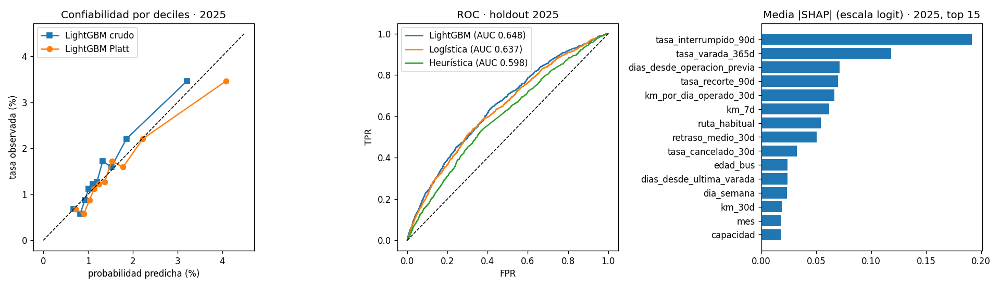

,shap_medio_abs,pct_shap,pct_gain
tasa_interrumpido_90d,0.1915,21.0%,18.2%
tasa_varada_365d,0.1180,12.9%,18.8%
dias_desde_operacion_previa,0.0711,7.8%,8.8%
tasa_recorte_90d,0.0697,7.6%,6.3%
km_por_dia_operado_30d,0.0663,7.3%,6.4%
km_7d,0.0618,6.8%,7.7%
ruta_habitual,0.0542,5.9%,5.6%
retraso_medio_30d,0.0504,5.5%,5.5%
tasa_cancelado_30d,0.0324,3.5%,1.9%
edad_bus,0.0241,2.6%,3.2%


In [8]:
# 4.3 · Figuras: confiabilidad, ROC e importancia (TreeSHAP)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for nombre, col, mk in [("crudo", "p_raw", "s"), ("Platt", "p_lgbm", "o")]:
    t = R.tabla_confiabilidad(yH, H[col])
    ax[0].plot(t.p_media * 100, t.tasa_observada * 100, marker=mk, label=f"LightGBM {nombre}")
lim = max(R.tabla_confiabilidad(yH, H[c]).p_media.max() for c in ["p_raw", "p_lgbm"]) * 110
ax[0].plot([0, lim], [0, lim], "k--", lw=1); ax[0].set_xlabel("probabilidad predicha (%)"); ax[0].set_ylabel("tasa observada (%)")
ax[0].set_title("Confiabilidad por deciles · 2025"); ax[0].legend()
for nombre, col in [("LightGBM", "p_lgbm"), ("Logística", "p_logit"), ("Heurística", "p_heur")]:
    fpr, tpr, _ = roc_curve(yH, H[col])
    ax[1].plot(fpr, tpr, label=f"{nombre} (AUC {R.delong(yH, H[col])[0][0]:.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("ROC · holdout 2025"); ax[1].legend(); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
contrib = art["modelo"].predict(H[FEATS], pred_contrib=True)[:, :-1]
shap = pd.Series(np.abs(contrib).mean(0), index=FEATS).sort_values()
gain = pd.Series(art["modelo"].feature_importance("gain"), index=FEATS)
imp = pd.DataFrame({"shap_medio_abs": shap, "pct_shap": shap / shap.sum(), "pct_gain": gain / gain.sum()}).sort_values("pct_shap", ascending=False)
imp.to_csv(SALIDA / "importancia_r2_9.csv")
ax[2].barh(shap.index[-15:], shap.values[-15:]); ax[2].set_title("Media |SHAP| (escala logit) · 2025, top 15")
figura("m9_r2_confiabilidad_roc_shap.png")
display(imp.head(12).style.format({"shap_medio_abs": "{:.4f}", "pct_shap": "{:.1%}", "pct_gain": "{:.1%}"}))
R.tabla_confiabilidad(yH, H.p_lgbm).to_csv(SALIDA / "confiabilidad_9.csv", index=False)

In [9]:
# 4.4 · Robustez con la Parte 1: ablación de documentos (E2) y etiqueta por motivo mecánico (E1)
ROB = []
if E2 is not None:
    art_sin = R.entrenar_r2(P, R.FEATURES_R2)
    p_sin = R.predecir_r2(art_sin, H)[1]
    d = R.delong_pareado(yH, H.p_lgbm, p_sin)
    cob = H[R.FEATURES_R2_VEHICULOS].notna().mean()
    print("Cobertura de las features de documentos en 2025:", cob.round(3).to_dict())
    ROB.append({"prueba": "con vs sin documentos (E2)", "auc_con": d["auc_1"], "auc_sin": d["auc_2"], "dif": d["dif"], "z": d["z"], "p": d["p"]})
    check("R2 · aporte de tecnomecánica / SOAT / inspección (DeLong pareado)", True,
          f"AUC {d['auc_1']:.4f} con vs {d['auc_2']:.4f} sin · ΔAUC {d['dif']:+.4f}, p {d['p']:.3f}", info=True)
if po is not None:
    Ho = H[["idvehiculo", "fecha", "p_lgbm"]].merge(po[["idvehiculo", "fecha", "y"]], on=["idvehiculo", "fecha"])
    if 0 < Ho.y.sum() < len(Ho):
        d = R.delong_vs_azar(Ho.y, Ho.p_lgbm)
        ROB.append({"prueba": "modelo proxy evaluado contra motivo mecánico (E1)", "auc_con": d["auc"], "z": d["z"], "p": d["p"],
                    "n_eventos": int(Ho.y.sum())})
        check("R2 · el modelo ordena también las varadas registradas en observacion", (d["auc"] > 0.5) and (d["p"] < 0.05),
              f"AUC {d['auc']:.3f} [{d['ic95_lo']:.3f}; {d['ic95_hi']:.3f}] sobre {int(Ho.y.sum())} bus-días mecánicos de 2025")
if ROB:
    rob = pd.DataFrame(ROB); rob.to_csv(SALIDA / "robustez_r2_9.csv", index=False); display(rob.round(4))
else:
    print("Sin pruebas de robustez: " + ("E1/E2 no extraídos." if not EXTRA else
          "la extracción no trae documentos (inspección / tecnomecánica / SOAT vacías) ni motivos mecánicos en observacion."))

Sin pruebas de robustez: la extracción no trae documentos (inspección / tecnomecánica / SOAT vacías) ni motivos mecánicos en observacion.


**Conclusión 4 · Sub-modelo de varadas (R2)**
- **Configuración elegida solo con 2024-S2:** 4 hojas, mínimo 1.000 por hoja y lr 0,02. AUC 0,638 frente a 0,633–0,637 de las otras tres; 222 rondas.
- **Holdout 2025: AUC 0,648 [0,631; 0,665]**, con DeLong frente al azar z = 16,9 y p = 2e-64. En los 12 meses el AUC queda entre 0,588 y 0,696.
- **Supera a las dos líneas base (DeLong pareado):**
  - a la heurística de la tasa histórica del bus (0,598): +0,051, p < 1e-8;
  - a la regresión logística con las mismas features (0,637): +0,012, p = 0,035.
- **Brier 0,01443 frente a 0,01449 de la climatología** (skill +0,41 %).
  - Murphy: confiabilidad 6e-6 y resolución 6,6e-5, frente a una incertidumbre de 0,0145.
  - Está bien calibrado, pero el evento es raro y la señal modesta: **el valor está en ordenar los buses, no en la probabilidad absoluta.**
- **Platt** (a = 1,110, b = 0,618) se mantiene porque el plan lo pide, pero en 2025 no mejora al modelo crudo:
  - Brier 0,01443 frente a 0,01442; ECE 0,0017 en ambos.
  - La media predicha queda en 1,60 % (crudo: 1,37 %), frente a 1,47 % real.
- **Foco de inspección:** revisar el 5 % de bus-días con más riesgo captura el **13,5 % de las varadas (lift 2,70)**; el 10 %, el 23,5 %; el 20 %, el 38,5 %.
  - La banda crítica (≥ P95) tuvo una tasa real de 3,98 % (2,7 × la media), aunque predecía 5,16 %: **sobreestima en la cola**.
- **Qué explica el riesgo (SHAP 2025):**
  - tasa de viajes interrumpidos en 90 días: 21,0 %;
  - tasa histórica de varadas: 12,9 %;
  - días desde la operación previa: 7,8 %;
  - recortes de ruta: 7,6 %;
  - km por día operado: 7,3 %.
- **La edad del bus pesa poco (2,6 %):** el desgaste se ve mejor en el uso y en los "casi-varadas" que en el año del modelo.
- **La extracción no cambia R2:** no aportó documentos ni motivos mecánicos, así que estas cifras son las definitivas.

## 5 · Traducción a P&L: recaudo perdido por varada

In [10]:
pl = R.perdida_por_varada(P[P.viajes_por_dia_28d.notna() & P.conjunto.isin(["train", "val", "calib", "holdout"])], v)
res = (pl.groupby(["anio", "y"]).agg(bus_dias=("y", "size"), viajes_perdidos=("viajes_perdidos", "mean"),
                                      recaudo_perdido_cop=("recaudo_perdido_cop", "mean")).unstack("y"))
atrib = pd.DataFrame({
    "varadas": res[("bus_dias", 1)],
    "viajes_perdidos_atribuibles": res[("viajes_perdidos", 1)] - res[("viajes_perdidos", 0)],
    "recaudo_atribuible_por_varada_cop": res[("recaudo_perdido_cop", 1)] - res[("recaudo_perdido_cop", 0)]})
atrib["recaudo_atribuible_total_cop"] = atrib.varadas * atrib.recaudo_atribuible_por_varada_cop
display(atrib.style.format({"viajes_perdidos_atribuibles": "{:.2f}", "recaudo_atribuible_por_varada_cop": "{:,.0f}",
                            "recaudo_atribuible_total_cop": "{:,.0f}"}))
pl25 = pl[pl.anio == 2025]
por_ruta = (pl25.groupby(["idruta", "y"]).recaudo_perdido_cop.mean().unstack("y").pipe(lambda d: d[1] - d[0])
            .rename("recaudo_atribuible_por_varada_cop"))
display(por_ruta.to_frame().style.format("{:,.0f}"))
L25 = atrib.loc[2025, "recaudo_atribuible_por_varada_cop"]
Hpl = H.merge(pl25[["idvehiculo", "fecha", "idruta"]], on=["idvehiculo", "fecha"], how="left")
Hpl["L"] = Hpl.idruta.map(por_ruta).fillna(L25)
foco = []
for f in [0.05, 0.10, 0.20]:
    k = int(np.ceil(f * len(Hpl))); top = Hpl.nlargest(k, "p_lgbm")
    foco.append({"revisar_top": f, "bus_dias_revisados": k, "varadas_en_el_foco": int(top.y.sum()),
                 "captura": top.y.sum() / Hpl.y.sum(), "recaudo_en_riesgo_cop": float((top.y * top.L).sum())})
foco = pd.DataFrame(foco)
display(foco.style.format({"captura": "{:.1%}", "recaudo_en_riesgo_cop": "{:,.0f}"}))
pd.concat([atrib.reset_index().assign(nivel="anual"), por_ruta.reset_index().assign(nivel="ruta_2025")]).to_csv(SALIDA / "pyl_varadas_9.csv", index=False)
foco.to_csv(SALIDA / "pyl_foco_inspeccion_9.csv", index=False)
check("P&L · la varada reduce viajes frente a bus-días sin varada", (atrib.viajes_perdidos_atribuibles > 0).all(),
      f"2025: {atrib.loc[2025, 'viajes_perdidos_atribuibles']:.2f} viajes y {L25:,.0f} COP por varada", info=True)

,varadas,viajes_perdidos_atribuibles,recaudo_atribuible_por_varada_cop,recaudo_atribuible_total_cop
anio,,,,
2023,532,0.58,"181,675","96,651,008"
2024,873,0.51,"155,673","135,902,165"
2025,979,0.59,"165,341","161,869,237"


,recaudo_atribuible_por_varada_cop
idruta,
2.000000,"210,898"
16.000000,"203,349"
21.000000,"68,185"


,revisar_top,bus_dias_revisados,varadas_en_el_foco,captura,recaudo_en_riesgo_cop
0,0.050000,3396,135,13.5%,"24,358,006"
1,0.100000,6792,235,23.5%,"41,102,275"
2,0.200000,13584,385,38.5%,"66,199,926"


**Conclusión 5 · P&L**
- **Costo por varada:** en 2025, una varada quita **0,59 viajes netos** ese día frente a un bus-día sin varada. Eso equivale a ≈ **165.341 COP** de recaudo esperado (tarifa de 3.700 COP × mediana de pasajeros de la ruta).
- **Total anual:** 96,7 M COP (2023) → 135,9 M (2024) → **161,9 M COP (2025, 979 varadas)**. Crece con la tasa.
- **Por ruta (2025):** ruta 2 ≈ 210.898, ruta 16 ≈ 203.349 y ruta 21 ≈ 68.185 COP por varada.
- **Valor del foco:** revisar cada día el 10 % de bus-días con más riesgo habría puesto en foco 235 varadas y **41,1 M COP de recaudo en riesgo** en 2025 (top 5 %: 24,4 M; top 20 %: 66,2 M).
  - Esto es recaudo **en riesgo**, no ahorro. El ahorro depende de cuántas varadas evite la revisión preventiva, un dato que debe aportar SOBUSA.
- **No incluye** grúa, taller ni penalidades: no existen en la base, así que la pérdida está subestimada.

## 6 · Velocidad GPS por viaje (exceso > 60 km/h)

Muestra local: 1,671 viajes, 893,734 tramos válidos de 969,662 (92.2%)


,viajes,pct_tiempo_sobre_60,viajes_con_exceso,v_p95_mediana,v_max_p99
idruta,,,,,
2,530,0.068%,10.9%,33.7,98.8
16,596,0.083%,11.6%,34.8,111.2
21,545,0.083%,11.2%,34.2,93.3


Tiempo sobre 60 km/h: 0.078% · viajes con algún tramo > 60 km/h: 11.3% · viajes por bus en la muestra: mediana 5, buses con ≥ 5: 167 de 332
E3: 11,891 viajes · tiempo sobre 60 km/h 0.032% · viajes con algún tramo > 60 km/h 6.1% · P95 mediano 33.9 km/h
Velocidades usadas en R3: E3 (muestra por conductor)


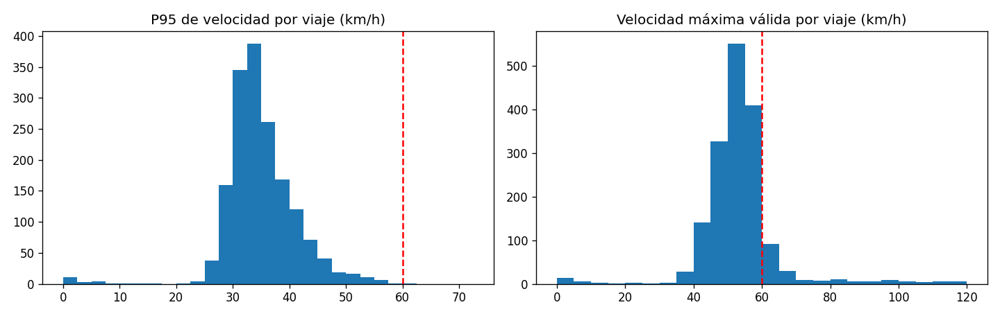

In [11]:
lect = pd.read_parquet(raiz / "maestras" / "tb_maestra_conteo_destino_limpio_muestra.parquet",
                       columns=["id", "idprogramacion", "fecha", "latitud", "longitud"])
vel_local = R.velocidad_por_viaje(lect)
vel_local = vel_local.merge(v[["idprogramacion", "idvehiculo", "idruta", "fecha"]], on="idprogramacion", how="left")
vel_local.to_csv(SALIDA / "velocidad_muestra_local_9.csv", index=False)
vl = vel_local[vel_local.seg_validos > 0]
print(f"Muestra local: {len(vl):,} viajes, {vl.n_validos.sum():,} tramos válidos de {vl.n_tramos.sum():,} "
      f"({vl.n_validos.sum() / vl.n_tramos.sum():.1%})")
resumen_vel = vl.assign(exceso=vl.seg_exceso_60 > 0, pct_tiempo=vl.seg_exceso_60 / vl.seg_validos).groupby("idruta").agg(
    viajes=("idprogramacion", "size"), pct_tiempo_sobre_60=("seg_exceso_60", "sum"), seg=("seg_validos", "sum"),
    viajes_con_exceso=("exceso", "mean"), v_p95_mediana=("v_p95", "median"), v_max_p99=("v_max", lambda s: s.quantile(.99)))
resumen_vel["pct_tiempo_sobre_60"] = resumen_vel.pct_tiempo_sobre_60 / resumen_vel.pop("seg")
display(resumen_vel.style.format({"pct_tiempo_sobre_60": "{:.3%}", "viajes_con_exceso": "{:.1%}", "v_p95_mediana": "{:.1f}", "v_max_p99": "{:.1f}"}))
glob = vl.seg_exceso_60.sum() / vl.seg_validos.sum()
viajes_bus = vl.groupby("idvehiculo").size()
print(f"Tiempo sobre 60 km/h: {glob:.3%} · viajes con algún tramo > 60 km/h: {(vl.seg_exceso_60 > 0).mean():.1%} · "
      f"viajes por bus en la muestra: mediana {viajes_bus.median():.0f}, buses con ≥ 5: {(viajes_bus >= 5).sum()} de {len(viajes_bus)}")
VEL = EXTRA.get("velocidad", vel_local)
if "velocidad" in EXTRA:
    e3 = EXTRA["velocidad"]; e3v = e3[e3.seg_validos > 0]
    print(f"E3: {len(e3):,} viajes · tiempo sobre 60 km/h {e3v.seg_exceso_60.sum() / e3v.seg_validos.sum():.3%} · "
          f"viajes con algún tramo > 60 km/h {(e3v.seg_exceso_60 > 0).mean():.1%} · P95 mediano {e3v.v_p95.median():.1f} km/h")
    comun = e3.merge(vel_local, on="idprogramacion", suffixes=("_sql", "_pd"))
    if len(comun):
        dif = max((comun[f"{c}_sql"] - comun[f"{c}_pd"]).abs().max() for c in ["n_tramos", "n_validos", "seg_validos", "seg_exceso_60"])
        check("Velocidad · SQL (E3) = pandas en los viajes comunes", dif < 1e-3, f"{len(comun)} viajes · diferencia máxima {dif:.2e}")
    else:
        check("Velocidad · SQL (E3) = pandas en los viajes comunes", True, "sin viajes en común con la muestra local", info=True)
print("Velocidades usadas en R3:", "E3 (muestra por conductor)" if "velocidad" in EXTRA else "muestra local del Módulo 1.3")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(vl.v_p95, bins=np.arange(0, 75, 2.5)); ax[0].axvline(60, color="r", ls="--"); ax[0].set_title("P95 de velocidad por viaje (km/h)")
ax[1].hist(vl.v_max, bins=np.arange(0, 125, 5)); ax[1].axvline(60, color="r", ls="--"); ax[1].set_title("Velocidad máxima válida por viaje (km/h)")
figura("m9_velocidad_gps.png")
check("Velocidad · fracción de tramos válidos", vl.n_validos.sum() / vl.n_tramos.sum() > 0.8,
      f"{vl.n_validos.sum() / vl.n_tramos.sum():.1%} (2 s ≤ Δt ≤ 60 s y ≤ 120 km/h)")

**Conclusión 6 · Velocidad GPS**
- **E3:** 11.891 viajes (hasta 4 por conductor y semestre), con velocidades calculadas en el servidor. **SQL = pandas:** en los 37 viajes que coinciden con la muestra local, la diferencia es exactamente 0.
- **Exceder 60 km/h es raro:**
  - 0,032 % del tiempo de conducción;
  - el 6,1 % de los viajes tiene algún tramo por encima (4,8 % con ≥ 30 s);
  - el P95 por viaje tiene una mediana de 33,9 km/h.
  - En la muestra local del Módulo 1.3: 0,078 % del tiempo y 11,3 % de los viajes, igual en las 3 rutas.
- **Ahora sí hay cobertura para el score:** tienen ≥ 5 viajes con GPS el 96,6 % y el 94,9 % de los buses elegibles (2024 / 2025) y el 75,0 % y el 77,1 % de los conductores. El componente de velocidad entra al score.
- **Es una señal casi independiente** de las demás (correlaciones ≤ 0,10; carga en la CP1 ≤ 0,102). Su peso viene sobre todo del criterio experto: 0,15–0,18 en el peso final.

## 7 · Score conductual (R3)

idconductor genéricos excluidos (> 6 viajes por día operado): ['799'] · 48,675 viajes iniciados (8.7%) quedan sin conductor


experto    pca  final  carga_cp1  alpha_eb
idvehiculo 2024  velocidad        0.3  0.051  0.176      0.102     1.089
                 persecucion      0.2  0.261  0.230     -0.520    28.942
                 bloqueo          0.2  0.111  0.155      0.221     2.010
                 recorte          0.2  0.256  0.228      0.511    13.590
                 retraso          0.1  0.321  0.211      0.640     6.085
idvehiculo 2025  velocidad        0.3  0.032  0.166      0.060     0.605
                 persecucion      0.2  0.343  0.272     -0.637    22.902
                 bloqueo          0.2  0.050  0.125      0.093     2.141
                 recorte          0.2  0.237  0.218      0.439     2.811
                 retraso          0.1  0.337  0.218      0.624     3.543
idconductor 2024 velocidad        0.3  0.004  0.152      0.006     0.467
                 persecucion      0.2  0.399  0.299     -0.673    18.892
                 bloqueo          0.2  0.040  0.120      0.068     2.417
                 recorte          0.2  0.146  0.173      0.247     1.648
                 retraso          0.1  0.411  0.256      0.694     1.870
idconductor 2025 velocidad        0.3  0.023  0.161      0.042     2.729
                 persecucion      0.2  0.349  0.275     -0.642    18.541
                 bloqueo          0.2  0.066  0.133      0.121     2.510
                 recorte          0.2  0.206  0.203      0.379     0.481
                 retraso          0.1  0.356  0.228      0.654     1.642

('idvehiculo', 2024): 264 de 411 entidades con ≥ 100 viajes · CP1 explica 29.3% · Spearman experto–PCA 0.37 · excluidos: —
('idvehiculo', 2025): 275 de 421 entidades con ≥ 100 viajes · CP1 explica 32.3% · Spearman experto–PCA 0.16 · excluidos: —
('idconductor', 2024): 384 de 660 entidades con ≥ 100 viajes · CP1 explica 26.7% · Spearman experto–PCA 0.06 · excluidos: —
('idconductor', 2025): 371 de 627 entidades con ≥ 100 viajes · CP1 explica 29.1% · Spearman experto–PCA 0.14 · excluidos: —
Correlación entre componentes (vehículo, 2024):


,z_velocidad,z_persecucion,z_bloqueo,z_recorte,z_retraso
z_velocidad,1.00,0.06,0.09,-0.02,0.10
z_persecucion,0.06,1.00,-0.09,-0.07,-0.30
z_bloqueo,0.09,-0.09,1.00,0.12,-0.03
z_recorte,-0.02,-0.07,0.12,1.00,0.27
z_retraso,0.10,-0.30,-0.03,0.27,1.00


Correlación entre componentes (conductor, 2024):


,z_velocidad,z_persecucion,z_bloqueo,z_recorte,z_retraso
z_velocidad,1.00,0.06,0.05,-0.05,0.08
z_persecucion,0.06,1.00,-0.05,-0.02,-0.31
z_bloqueo,0.05,-0.05,1.00,0.03,-0.03
z_recorte,-0.05,-0.02,0.03,1.00,0.10
z_retraso,0.08,-0.31,-0.03,0.10,1.00


,entidad,resultado,n,n_malos,auc,gini,gini_ic95_lo,gini_ic95_hi,p_delong,ks,p_ks,spearman_ref_fut
0,vehículo,persistencia: riesgo futuro en el cuartil superior,255,64,0.711,0.422,0.286,0.559,1.3e-09,0.346,1.4e-05,0.399
1,vehículo,externo: tasa futura de varadas en el cuartil superior,255,64,0.602,0.204,0.049,0.358,9.9e-03,0.200,3.8e-02,0.399
2,conductor,persistencia: riesgo futuro en el cuartil superior,236,59,0.718,0.435,0.294,0.577,1.6e-09,0.362,1.3e-05,0.438
3,conductor,externo: tasa futura de varadas en el cuartil superior,236,59,0.561,0.122,-0.048,0.291,1.6e-01,0.141,3.3e-01,0.438


,decil_score,n,score_medio,tasa_malos,riesgo_fut_medio
0,1,26,4.9,53.8%,+0.226
1,2,25,14.6,32.0%,+0.103
2,3,26,24.2,38.5%,+0.182
3,4,25,34.2,24.0%,+0.044
4,5,26,43.9,26.9%,-0.034
5,6,25,54.1,28.0%,+0.099
6,7,25,64.6,28.0%,+0.062
7,8,26,74.6,11.5%,-0.084
8,9,25,84.3,8.0%,-0.267
9,10,26,94.8,0.0%,-0.392


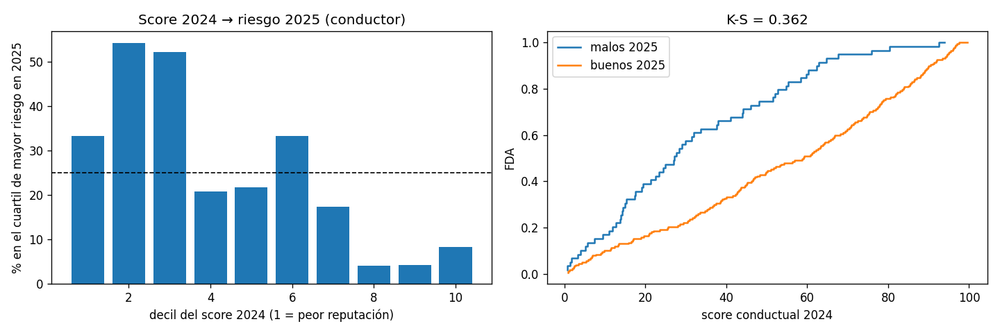

In [12]:
ev = R.eventos_conductuales(v, VEL)
ENTIDADES = [("idvehiculo", "vehículo")] + ([("idconductor", "conductor")] if "idconductor" in v else [])
if "idconductor" in v:
    e1 = EXTRA["progvehiculos"]
    gen = R.conductores_genericos(v.assign(idconductor=pd.to_numeric(v.idprogramacion.map(e1.set_index("idprogramacion").idconductor)).astype("Int64").astype("string")))
    sin = v.inicio & v.idconductor.isna()
    print(f"idconductor genéricos excluidos (> {CFG.max_viajes_dia_conductor:g} viajes por día operado): {gen} · "
          f"{int(sin.sum()):,} viajes iniciados ({sin.mean() / v.inicio.mean():.1%}) quedan sin conductor")
    check("R3 · IDs de conductor genéricos excluidos", True, f"{gen}: {int(sin.sum()):,} viajes sin conductor real", info=True)
SC, INFO, VAL, DEC = {}, {}, {}, {}
for id_col, nombre in ENTIDADES:
    for anio in (2024, 2025):
        SC[(id_col, anio)], INFO[(id_col, anio)] = R.score_conductual(ev, id_col, f"{anio}-01-01", f"{anio + 1}-01-01")
        SC[(id_col, anio)].to_csv(SALIDA / f"score_conductual_{id_col}_{anio}_9.csv", index=False)
    ext = v[(v.fecha >= "2025-01-01") & v.inicio].groupby(id_col).varada_proxy.mean()
    VAL[id_col], DEC[id_col] = R.validar_score(SC[(id_col, 2024)], SC[(id_col, 2025)], id_col, ext)
    VAL[id_col].insert(0, "entidad", nombre)

pesos = pd.concat({f"{id_col} {a}": pd.DataFrame({"experto": INFO[(id_col, a)]["pesos_experto"], "pca": INFO[(id_col, a)]["pesos_pca"],
                                                  "final": INFO[(id_col, a)]["pesos"], "carga_cp1": INFO[(id_col, a)]["carga_cp1"],
                                                  "alpha_eb": INFO[(id_col, a)]["alpha"]})
                   for id_col, _ in ENTIDADES for a in (2024, 2025)})
pesos.to_csv(SALIDA / "pesos_score_9.csv")
display(pesos.round(3))
for k, i in INFO.items():
    print(f"{k}: {i['n_elegibles']} de {i['n_entidades']} entidades con ≥ {CFG.min_viajes_score} viajes · "
          f"CP1 explica {i['varianza_cp1']:.1%} · Spearman experto–PCA {i['spearman_experto_pca']:.2f} · excluidos: {i['excluidos'] or '—'}")
for id_col, nombre in ENTIDADES:
    s_ = SC[(id_col, 2024)]
    print(f"Correlación entre componentes ({nombre}, 2024):")
    display(s_[[c for c in s_ if c.startswith("z_")]].corr().round(2))
val = pd.concat(VAL.values(), ignore_index=True)
val.to_csv(SALIDA / "validacion_score_9.csv", index=False)
display(val.style.format({c: "{:.3f}" for c in ["auc", "gini", "gini_ic95_lo", "gini_ic95_hi", "ks", "spearman_ref_fut"]}
                         | {"p_delong": "{:.1e}", "p_ks": "{:.1e}"}))
display(DEC["idvehiculo"].style.format({"score_medio": "{:.1f}", "tasa_malos": "{:.1%}", "riesgo_fut_medio": "{:+.3f}"}))

id_fig = ENTIDADES[-1][0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
d = DEC[id_fig]
ax[0].bar(d.decil_score, d.tasa_malos * 100); ax[0].axhline(25, color="k", ls="--", lw=1)
ax[0].set_xlabel("decil del score 2024 (1 = peor reputación)"); ax[0].set_ylabel("% en el cuartil de mayor riesgo en 2025")
ax[0].set_title(f"Score 2024 → riesgo 2025 ({ENTIDADES[-1][1]})")
m = SC[(id_fig, 2024)].merge(SC[(id_fig, 2025)][[id_fig, "riesgo"]].rename(columns={"riesgo": "rf"}), on=id_fig)
malo = m.rf >= m.rf.quantile(0.75)
for lab, s in [("malos 2025", m.score_conductual[malo]), ("buenos 2025", m.score_conductual[~malo])]:
    xs = np.sort(s); ax[1].step(xs, np.arange(1, len(xs) + 1) / len(xs), label=lab)
ax[1].set_xlabel("score conductual 2024"); ax[1].set_ylabel("FDA"); ax[1].set_title(f"K-S = {VAL[id_fig].ks.iloc[0]:.3f}"); ax[1].legend()
figura("m9_r3_validacion_score.png")
for _, f in val.iterrows():
    principal = f.resultado.startswith("persistencia")
    check(f"R3 · {f.entidad} · {f.resultado.split(':')[0]} (Gini y K-S)", (f.gini > 0) and (f.p_delong < 0.05) and (f.p_ks < 0.05),
          f"Gini {f.gini:.3f} [{f.gini_ic95_lo:.3f}; {f.gini_ic95_hi:.3f}] (p {f.p_delong:.1e}) · KS {f.ks:.3f} (p {f.p_ks:.1e}) · n {f.n}",
          info=not principal)

**Conclusión 7 · Score conductual (R3)**
- **Conductores:** 1.010 `idconductor` distintos.
  - El **799 es un ID genérico, no una persona**: 8,8 % de los viajes, 443 buses y 45 viajes por día operado, frente a un P99 de 3,35 en los conductores reales. Se excluye con la regla "> 6 viajes por día" y deja 48.675 viajes (8,7 %) sin conductor real.
  - Elegibles (≥ 100 viajes): 384 conductores en 2024 y 371 en 2025. Vehículos: 264 y 275.
- **5 componentes:** velocidad > 60 km/h, persecución, bloqueo, recorte de ruta (50–90 %) y retraso de despacho > 5 min. La persecución es una salida adelantada que comprime el intervalo con el bus anterior, atribuida al bus solo si al menos la mitad de la compresión es suya.
- **Pesos finales por conductor (2024):** persecución 0,30, retraso 0,26, recorte 0,17, velocidad 0,15 y bloqueo 0,12.
- **La CP1 (26,7 % de la varianza) no es un factor único de "mal conductor":** persecución carga opuesta a retraso (correlación −0,31). Los que salen adelantados no son los que salen tarde.
  - Por eso los signos se fijan por criterio de negocio (todo penaliza) y la PCA solo aporta magnitudes.
- **Validación fuera de tiempo (score 2024 → riesgo 2025):**
  - **Conductor (n = 236): Gini 0,435 [0,294; 0,577], KS 0,362 (p = 1,3e-5)**, Spearman 0,44. Los deciles 2–3 tienen un 52–54 % en el cuartil de mayor riesgo de 2025; los deciles 8–10, entre 4 % y 8 %.
  - **Vehículo (n = 255): Gini 0,422 [0,286; 0,559], KS 0,346 (p = 1,4e-5)**, Spearman 0,40. Del decil peor, el 53,8 % termina en el cuartil de mayor riesgo; del mejor, el 0 %.
- **Contra las varadas de 2025:**
  - por vehículo, Gini 0,204 (p = 0,010) y KS 0,200 (p = 0,038);
  - **por conductor no es significativo** (Gini 0,122 [−0,048; 0,291]): la varada es una propiedad del bus, no de quien lo conduce.

## 8 · Tabla `tb_scoring_vehiculo_conductor`

In [13]:
fecha_pred = pd.Timestamp(CFG.fecha_scoring)
filas_sc = pd.DataFrame({"idvehiculo": sorted(v.idvehiculo.unique()), "fecha": fecha_pred})
Xs = R.features_r2(v, filas_sc, ETIQUETA, vehiculos=veh, calendario=cal, vehiculos_extra=E2)
Xs = Xs[Xs.dias_operados_30d > 0].copy()
_, Xs["p_varada_jornada"] = R.predecir_r2(art, Xs)
tasa_base = float(yH.mean())
Xs["banda_riesgo_varada"] = R.banda_varada(Xs.p_varada_jornada.to_numpy(), CORTES)
Xs["perdida_esperada_cop"] = Xs.p_varada_jornada * Xs.ruta_habitual.map(por_ruta).fillna(L25)
riesgo_veh = Xs[["idvehiculo", "ruta_habitual", "p_varada_jornada", "banda_riesgo_varada", "perdida_esperada_cop"]]
id_c = "idconductor" if "idconductor" in v else None
tabla = R.construir_tabla("2025-12-31", CFG.fecha_scoring, riesgo_veh, SC[("idvehiculo", 2025)],
                          SC[(id_c, 2025)] if id_c else None, INFO[("idvehiculo", 2025)], INFO[(id_c, 2025)] if id_c else None)
tabla.to_parquet(SALIDA / "tb_scoring_vehiculo_conductor.parquet", index=False)
tabla.to_csv(SALIDA / "tb_scoring_vehiculo_conductor.csv", index=False)
print(f"{len(tabla):,} filas · " + " · ".join(f"{k}: {n}" for k, n in tabla.tipo_entidad.value_counts().items()))
tv = tabla[tabla.tipo_entidad == "vehiculo"]
bandas = tv.groupby("banda_riesgo_varada").agg(buses=("id_entidad", "size"), p_media=("p_varada_jornada", "mean"),
                                               perdida_esperada_total_cop=("perdida_esperada_cop", "sum"))
display(bandas.style.format({"p_media": "{:.2%}", "perdida_esperada_total_cop": "{:,.0f}"}))
display(pd.crosstab(tv.banda_riesgo_varada, tv.banda_conductual, margins=True))
display(tv.nlargest(10, "p_varada_jornada")[["id_entidad", "idruta_habitual", "p_varada_jornada", "banda_riesgo_varada",
                                             "perdida_esperada_cop", "score_conductual", "banda_conductual"]])
pk_ok = not tabla.duplicated(["fecha_corte", "tipo_entidad", "id_entidad"]).any()
rango_ok = tv.p_varada_jornada.dropna().between(0, 1).all() and tabla.score_conductual.dropna().between(0, 100).all()
check("Tabla · llave primaria única", pk_ok, f"{len(tabla):,} filas")
check("Tabla · rangos válidos (p ∈ [0, 1], score ∈ [0, 100])", rango_ok,
      f"{tv.p_varada_jornada.notna().sum()} buses con p · {tabla.score_conductual.notna().sum()} entidades con score")

719 filas · conductor: 371 · vehiculo: 348


,buses,p_media,perdida_esperada_total_cop
banda_riesgo_varada,,,
alto,65,2.54%,"275,995"
bajo,109,0.91%,"139,770"
critico,39,5.53%,"400,818"
medio,121,1.46%,"257,106"


banda_conductual,A,B,C,D,E,All
banda_riesgo_varada,,,,,,
alto,8,8,14,16,11,57
bajo,24,13,10,14,8,69
critico,5,9,6,5,11,36
medio,17,23,21,18,20,99
All,54,53,51,53,50,261


,id_entidad,idruta_habitual,p_varada_jornada,banda_riesgo_varada,perdida_esperada_cop,score_conductual,banda_conductual
507,SOBUSA35,2.0,0.106318,critico,22422.142144,16.545455,E
375,SOBUSA07,2.0,0.102281,critico,21570.809509,71.818182,B
382,SOBUSA112,2.0,0.098788,critico,20834.052032,30.727273,D
607,SOBUSA491,16.0,0.088212,critico,17937.743716,32.181818,D
576,SOBUSA457,2.0,0.082637,critico,17427.999976,69.272727,B
371,SOBUSA03,2.0,0.074864,critico,15788.595148,13.636364,E
669,SOBUSA570,21.0,0.072028,critico,4911.266623,72.909091,B
516,SOBUSA371,2.0,0.069926,critico,14747.289002,28.909091,D
462,SOBUSA265,2.0,0.069687,critico,14696.830593,18.363636,E
505,SOBUSA346,21.0,0.064596,critico,4404.514041,70.363636,B


**Conclusión 8 · Tabla de scoring**
- **719 filas** con corte el 2025-12-31 y predicción para el 2026-01-01:
  - **348 vehículos:** 334 con p, 275 con score y 261 con ambos;
  - **371 conductores**, en quintiles (≈ 74 por banda A–E).
- **Bandas de varada** (cortes = P40 / P80 / P95 de p en 2025): 109 bajo, 121 medio, 65 alto y **39 crítico**.
  - Crítico es el 11,7 % de los buses, frente al 5 % de los bus-días de 2025, por dos razones:
    - la foto pesa igual a los buses que operan poco (con ≤ 20 de 30 días operados, 16–18 % son críticos, frente a 3–4 %);
    - diciembre es el mes con la tasa más alta (1,88 %).
- **Pérdida esperada de la jornada:** 1,07 M COP, de los cuales 0,40 M (37 %) vienen de los 39 buses críticos.
- **Riesgo de varada y reputación del bus se relacionan débilmente** (Spearman −0,196). 11 buses son a la vez críticos en varada y E en conducta: prioridad de revisión.
- `sql/tb_scoring_vehiculo_conductor.sql` trae el DDL para el DBA; la tabla está materializada en `datos_9/` (Parquet y CSV).

## 9 · Pruebas y checks

In [14]:
pruebas = T.correr_todos(v, P, art)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_9.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Auditoría de fuentes,INFO,14/14 variables del plan existen en la RDS; 4 están en los archivos locales; bloqueo_cond/bloqueo_veh 0% n...
1,Etiqueta · auditoría contra observacion (E1),INFO,"0 motivos mecánicos en 49,331 observaciones (3 valores distintos)"
2,Etiqueta · varada → más ausencias al día siguiente,PASS,44.5% vs 24.9% (p 1.9e-113); lun–jue 38.1% vs 18.9%
3,Etiqueta · heterogeneidad entre buses,PASS,índice de dispersión 3.38 (> 1 = no es ruido homogéneo)
4,Panel · partición temporal ordenada,PASS,calentamiento < train < val < calib < holdout
5,R2 · R.PARAMS_R2 = la configuración con mejor AUC en 2024-S2,PASS,"elegida: C · 4 hojas, min 1000, lr 0,02"
6,"R2 · AUC > 0,5 (DeLong vs azar)",PASS,"AUC 0.648 [0.631; 0.665], p 2.0e-64"
7,R2 · LightGBM vs logística (DeLong pareado),INFO,"ΔAUC +0.0116, z 2.11, p 0.0348 → diferencia significativa"
8,R2 · LightGBM vs heurística (DeLong pareado),INFO,"ΔAUC +0.0507, z 6.04, p 0.0000 → diferencia significativa"
9,R2 · Brier < climatología,PASS,0.01443 vs 0.01449 (skill +0.41%)


PASS 23 · FAIL 0 · INFO 9


**Conclusión 9 · Pruebas**
- **23 PASS, 0 FAIL, 9 INFO.** Pasan las **10 de 10 pruebas** (`py -3.10 tests_9.py`):
  - **a)** features sin fuga, con control;
  - **b)** holdout intocado: invertir las etiquetas de 2025 no cambia ni el modelo ni Platt;
  - **c)** DeLong = sklearn (error < 1e-12), varianza / bootstrap = 1,05 y tamaño 6,2 %;
  - **d)** Platt recupera (2, −3);
  - **e)** la contracción bayesiana recupera α (5,18 frente a 5) y baja el ECM;
  - **f)** velocidades exactas a 72 km/h, con el salto de GPS excluido;
  - **g)** el score ordena y es invariante al orden;
  - **h)** Gini y K-S en los extremos;
  - **i)** determinismo;
  - **j)** la foto de `vehiculos` no se usa antes de su vigencia.
- Además, la velocidad calculada en SQL (E3) coincide exactamente con la calculada en pandas.
- **Honestidad sobre 2025:** durante el desarrollo, 2025 se miró en varias corridas (5) antes de fijar el modelo, y eso llevó a quitar `dias_historia` (Conclusión 3).
  - La selección de hiperparámetros usó solo 2024-S2.
  - La extracción no cambió R2.
  - La cifra oficial es la de esta ejecución.
- Ejecución: 0,5 min.

## Síntesis para el jurado y pendientes

| Pregunta | Respuesta (holdout 2025) |
|---|---|
| ¿Se puede anticipar qué bus se vara? | Sí, de forma **modesta pero significativa**: AUC 0,648 (DeLong p = 2e-64). El top 5 % de riesgo concentra 2,7 × la tasa media |
| ¿Cuánto cuesta una varada? | ≈ 165 mil COP de recaudo por evento, **161,9 M COP en 2025**, y la cifra crece cada año |
| ¿Cuánto recaudo pone en foco el modelo? | Revisar el 10 % de bus-días más riesgosos cubre el 23,5 % de las varadas y 41,1 M COP de recaudo en riesgo |
| ¿El score conductual es estable y predictivo? | Sí. Por conductor: Gini 0,435 y KS 0,362 del score 2024 sobre el riesgo de 2025 (por vehículo: 0,422 y 0,346) |

**Hallazgos de datos que debe conocer SOBUSA:**
- Inspección, revisión técnico-mecánica y SOAT están **vacías** en `vehiculos`.
- `observacion` **no registra motivos de varada**: solo tiene 3 valores, todos automáticos.
- El `idconductor` 799 agrupa el **8,7 % de los viajes** sin un conductor real.
- Registrar estos tres datos mejoraría directamente R2 y R3.

**Pendientes y riesgos:**
- **Etiqueta proxy:** validarla con la bitácora de taller o grúas de SOBUSA.
- **Historial de inspecciones:** no existe en la base. Sin él, el "% de inspecciones reprobadas" del plan no es construible.
- **P&L:** faltan los costos de grúa, taller y penalidades para pasar de recaudo en riesgo a ahorro neto.
- **Producción:** recalibrar cada mes (la tasa sube de 0,97 % a 1,47 % en tres años) y revisar la sobreestimación en la banda crítica.
- **Insumos para los Módulos 13 y 14:** `p_varada_jornada` alimenta los imprevistos del Monte Carlo (Módulo 13) y la flota disponible del redespacho (Módulo 14).

<a id="m10"></a>

---

## A2.2 &middot; Módulo 10 · Red vial, protocolo de eventos y reportes de conductores

**Qué aporta al pronóstico.** Define los nodos del e2c: los 386 segmentos de 500 m y el emparejamiento Viterbi que ubica cada lectura del sensor en su segmento, con el que el e2c.1 construyó el panel Y. Sus eventos reportados son los imprevistos de la vía del simulador.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m10-1"></a>

### A2.2.1 &middot; Subfase 10.1 · Red vial base y ubicación de reportes por GPS

<sub>Notebook original: `modulo10/subfase_10_1_red_vial.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 10 · Subfase 10.1 — Red vial base y ubicación de reportes por GPS

**Persona 3.** El Módulo 10 convierte reportes de conductores (texto o audio) en eventos de tráfico con lugar y hora. Esta subfase resuelve **el lugar**: el conductor nunca da coordenadas; el reporte se ubica con el **GPS de su propio bus** en la red de segmentos que SOBUSA ya tiene en la base de datos.

| Paso | Qué se hizo | Dónde |
|---|---|---|
| Parte 1 · extracción | Solo lectura: catálogo, rutas, configuración y los 386 segmentos de las rutas 2, 16 y 21 con su geometría | `extraer_10_1.py` → `datos_10/extraccion/` |
| Parte 2 · librería | Polilínea por ruta con avance acumulado, búsqueda KD a 5 m, emparejamiento de trayectorias (Viterbi) y ubicación de reportes | `src/geo/red_vial.py` |
| Parte 2 · validación | 971.335 lecturas GPS del Entregable 1 (1.673 viajes, 2023–2025) | `analisis_10_1.py` → `datos_10/` |
| Pruebas | Ruta sintética de ida y vuelta por la misma vía + extracción real | `tests_10_1.py` |

Sin API de Claude en esta subfase (costo $0). Sin contraseñas ni credenciales en ningún archivo.

## Parte 2 · Análisis offline

In [1]:
import json
import platform
import subprocess
import sys
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, "src")
from geo import red_vial as rv

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
D = Path("datos_10"); EXT = D / "extraccion"; FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})

RES = json.loads((D / "resumen_10_1.json").read_text(encoding="utf-8"))
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a", "gris": "#c3c2b7", "texto": "#0b0b0b", "texto2": "#52514e",
       "grid": "#e9e8e2", "alerta": "#e34948", "resto": "#898781"}
def estilo(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors=COL["texto2"], labelsize=9)
    if grid: ax.grid(axis=grid, color=COL["grid"], lw=0.8)
    ax.set_axisbelow(True)
f1 = lambda x, d=1: f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")
print(f"Python {platform.python_version()} · análisis del {RES['fecha']} · umbral {RES['umbral_m']:.0f} m · ventana {RES['ventana_reporte_min']:.0f} min")

Python 3.9.25 · análisis del 2026-10-27T22:54:45 · umbral 40 m · ventana 5 min


### 1 · La red de SOBUSA en la base de datos

In [2]:
q1 = pd.read_csv(EXT / "q1_rutas.csv"); q2 = pd.read_csv(EXT / "q2_config.csv"); q3 = pd.read_csv(EXT / "q3_resumen_segmentos.csv")
err = (EXT / "errores_extraccion.txt").read_text(encoding="utf-8") if (EXT / "errores_extraccion.txt").exists() else ""
print("Rutas:"); display(q1[["idruta", "nombre", "idrutageo", "distancia_global", "proceso"]])
print(f"rutas_segmentos_config: {len(q2)} configuraciones · tipos {q2.tipo_agrupacion.unique().tolist()} de {q2['tamaño_segmento_m'].unique().tolist()} m · porción {q2['tamaño_porcion_m'].unique().tolist()} m · activas {int(q2.activo.sum())}")
print(f"rutas_segmentos: {q3.idruta.nunique()} rutas segmentadas en la BD; las 3 del proyecto:")
display(q3[q3.idruta.isin([2, 16, 21])])
print("Consultas con error en la extracción:", err.strip() or "ninguna")
seg = rv.leer_segmentos(EXT / "q4_segmentos.csv")
red = rv.construir_red(seg)
rs = pd.read_csv(D / "red_vial_resumen.csv")
display(rs[["idruta", "nombre", "n_segmentos", "longitud_bd_m", "longitud_proyeccion_m", "distancia_global_km",
            "ultimo_segmento_m", "circuito_cerrado", "pct_ida_vuelta_misma_via", "pct_compartido_con_2",
            "pct_compartido_con_16", "pct_compartido_con_21"]].round(1))
cont = pd.read_csv(D / "red_vial_continuidad.csv")
interno, cierre = cont[cont.nro_segmento >= 0], cont[cont.nro_segmento < 0]
print(f"Hueco máximo entre segmentos consecutivos: {interno.hueco_m.max():.3f} m · cierre del circuito (fin→inicio): "
      + ", ".join(f"ruta {r}: {h:.0f} m" for r, h in zip(cierre.idruta, cierre.hueco_m)))
check("Extracción: 386 segmentos activos de 3 rutas, una configuración por ruta",
      len(seg) == 386 and seg.groupby("idruta").id_config.nunique().max() == 1, f"{len(seg)} segmentos")
check("Continuidad: hueco entre segmentos consecutivos < 1 m", interno.hueco_m.max() < 1, f"máx {interno.hueco_m.max():.3f} m")
check("Circuitos cerrados (fin a < 150 m del inicio)", bool(rs.circuito_cerrado.all()), f"{cierre.hueco_m.round(0).tolist()} m")
dif = (rs.longitud_proyeccion_m / rs.longitud_bd_m - 1).abs().max()
check("Proyección local vs longitud de la BD < 0,1 %", dif < 1e-3, f"máx {100 * dif:.3f} %")
gj = json.loads((D / "red_vial_segmentos.geojson").read_text(encoding="utf-8"))
tam = (D / "red_vial_segmentos.geojson").stat().st_size / 1e6
check("GeoJSON simplificado para el equipo: 386 segmentos y < 1 MB", len(gj["features"]) == 386 and tam < 1, f"{tam:.2f} MB (original 24 MB)")

Rutas:


,idruta,nombre,idrutageo,distancia_global,proceso
0,2,SILENCIO,3,62.9,sobusa
1,16,CRA 54,10,56.4,sobusa
2,21,CL 72,11,57.0,sobusa


rutas_segmentos_config: 22 configuraciones · tipos ['distancia'] de [500.0] m · porción [0.2] m · activas 22
rutas_segmentos: 22 rutas segmentadas en la BD; las 3 del proyecto:


,idruta,idrutageo,id_config,activo,n_segmentos,min_nro,max_nro,longitud_total_m,long_min_m,long_max_m
0,2,3,1,True,135,1,135,67217.670,217.670,500.0
9,16,10,10,True,123,1,123,61127.343,127.343,500.0
14,21,11,15,True,128,1,128,63901.961,401.961,500.0


Consultas con error en la extracción: q6_geometria_rutas.csv	Execution failed on sql '


,idruta,nombre,n_segmentos,longitud_bd_m,longitud_proyeccion_m,distancia_global_km,ultimo_segmento_m,circuito_cerrado,pct_ida_vuelta_misma_via,pct_compartido_con_2,pct_compartido_con_16,pct_compartido_con_21
0,2,SILENCIO,135,67217.7,67238.1,62.9,217.7,True,66.4,NaN,54.0,53.0
1,16,CRA 54,123,61127.3,61145.8,56.4,127.3,True,60.8,59.0,NaN,60.2
2,21,CL 72,128,63902.0,63920.7,57.0,402.0,True,66.9,55.1,57.3,NaN


Hueco máximo entre segmentos consecutivos: 0.000 m · cierre del circuito (fin→inicio): ruta 2: 60 m, ruta 16: 10 m, ruta 21: 24 m


### 2 · Mapa de la red y zonas de desvío

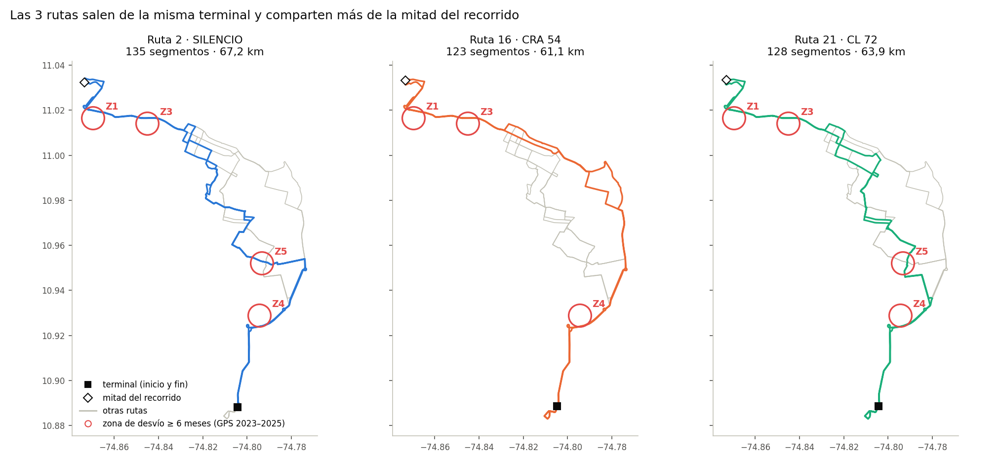

In [3]:
zs = pd.read_csv(D / "desvios_zonas_10_1.csv")
fig, axs = plt.subplots(1, 3, figsize=(13.5, 6.2), sharex=True, sharey=True)
for ax, r in zip(axs, (2, 16, 21)):
    for o in (2, 16, 21):
        if o != r:
            la, lo = rv.a_latlon(red[o].xy[::4]); ax.plot(lo, la, color=COL["gris"], lw=0.8, zorder=1)
    la, lo = rv.a_latlon(red[r].xy[::2]); ax.plot(lo, la, color=COL[r], lw=1.6, zorder=2)
    la0, lo0 = rv.a_latlon(red[r].xy[[0]]); ax.plot(lo0, la0, "s", color=COL["texto"], ms=7, zorder=4)
    lam, lom = rv.a_latlon(red[r].xy[[len(red[r].xy) // 2]]); ax.plot(lom, lam, "D", color=COL["texto"], ms=6, mfc="white", zorder=4)
    for z in zs[(zs.meses >= 6) & (zs.tipo == "desvio")].itertuples():
        if str(r) in z.rutas.split(","):
            ax.plot(z.lon, z.lat, "o", ms=22, mfc="none", mec=COL["alerta"], mew=1.6, zorder=3)
            ax.annotate(z.zona, (z.lon, z.lat), xytext=(12, 8), textcoords="offset points", fontsize=9, color=COL["alerta"], weight="bold")
    n = int(rs.set_index("idruta").loc[r, "n_segmentos"]); L = red[r].longitud_m / 1000
    ax.set_title(f"Ruta {r} · {rs.set_index('idruta').loc[r, 'nombre']}\n{n} segmentos · {f1(L)} km", fontsize=10.5, color=COL["texto"])
    ax.set_aspect(1 / np.cos(np.radians(rv.LAT0))); estilo(ax, grid=None); ax.tick_params(labelsize=8)
axs[0].plot([], [], "s", color=COL["texto"], label="terminal (inicio y fin)"); axs[0].plot([], [], "D", color=COL["texto"], mfc="white", label="mitad del recorrido")
axs[0].plot([], [], color=COL["gris"], label="otras rutas"); axs[0].plot([], [], "o", mfc="none", mec=COL["alerta"], label="zona de desvío ≥ 6 meses (GPS 2023–2025)")
axs[0].legend(loc="lower left", fontsize=8, frameon=False)
fig.suptitle("Las 3 rutas salen de la misma terminal y comparten más de la mitad del recorrido", fontsize=12, x=0.01, ha="left", color=COL["texto"])
fig.tight_layout(); fig.savefig(FIG / "red_vial_10_1.png", dpi=150); plt.close(fig)
display(Image(FIG / "red_vial_10_1.png"))

### 3 · ¿A qué distancia de su ruta reporta el GPS? Umbral «en ruta»

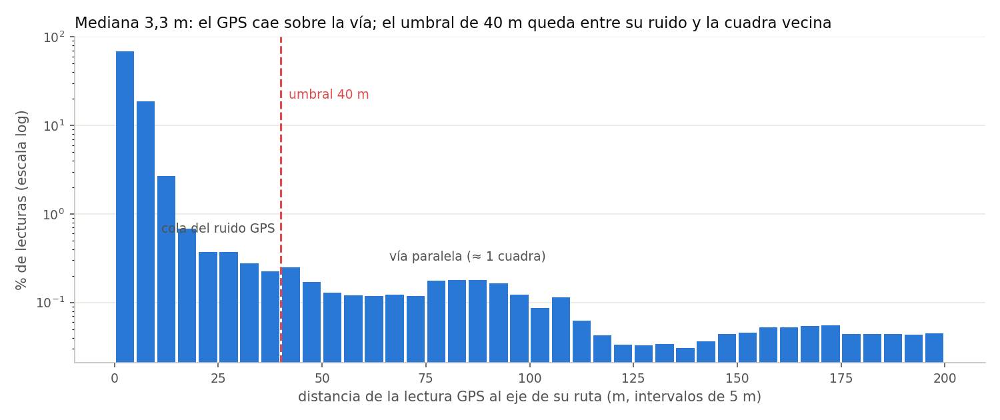

Lecturas a ≤ 15 m: 90.23 % · entre 15 y 40 m: 1.93 % · > 40 m (fuera de ruta): 7.84 %
% fuera de ruta según el umbral: 20 m → 9.09 % · 30 m → 8.34 % · 40 m → 7.84 % · 60 m → 7.17 % · 80 m → 6.63 %


In [4]:
h = pd.read_csv(D / "gps_distancias_hist.csv")
tot = h.n.sum()
fig, ax = plt.subplots(figsize=(10, 4.2))
m = h.desde_m < 200
ax.bar(h.desde_m[m] + 2.5, h.n[m] / tot * 100, width=4.4, color=COL[2], zorder=2)
ax.set_yscale("log"); ax.axvline(RES["umbral_m"], color=COL["alerta"], lw=1.5, ls="--")
ax.annotate(f"umbral {RES['umbral_m']:.0f} m", (RES["umbral_m"], 20), xytext=(6, 0), textcoords="offset points", color=COL["alerta"], fontsize=9)
ax.annotate("vía paralela (≈ 1 cuadra)", (85, 0.18), xytext=(0, 14), textcoords="offset points", ha="center", fontsize=9, color=COL["texto2"])
ax.annotate("cola del ruido GPS", (25, 0.37), xytext=(0, 14), textcoords="offset points", ha="center", fontsize=9, color=COL["texto2"])
ax.set_xlabel("distancia de la lectura GPS al eje de su ruta (m, intervalos de 5 m)", color=COL["texto2"])
ax.set_ylabel("% de lecturas (escala log)", color=COL["texto2"]); estilo(ax)
ax.set_title(f"Mediana {f1(RES['gps_dist_cuantiles_m']['0.5'])} m: el GPS cae sobre la vía; el umbral de {RES['umbral_m']:.0f} m queda entre su ruido y la cuadra vecina",
             fontsize=11, loc="left", color=COL["texto"])
fig.tight_layout(); fig.savefig(FIG / "distancia_gps_10_1.png", dpi=150); plt.close(fig)
display(Image(FIG / "distancia_gps_10_1.png"))
fuera_u = {u: h[h.desde_m >= u].n.sum() / tot * 100 for u in (20, 30, 40, 60, 80)}
print(f"Lecturas a ≤ 15 m: {h[h.hasta_m <= 15].n.sum() / tot * 100:.2f} % · entre 15 y 40 m: "
      f"{h[(h.desde_m >= 15) & (h.hasta_m <= 40)].n.sum() / tot * 100:.2f} % · > 40 m (fuera de ruta): {RES['gps_pct_fuera']:.2f} %")
print("% fuera de ruta según el umbral: " + " · ".join(f"{u} m → {v:.2f} %" for u, v in fuera_u.items()))
check("GPS sobre la vía: mediana de distancia al eje < 5 m", RES["gps_dist_cuantiles_m"]["0.5"] < 5, f"{RES['gps_dist_cuantiles_m']['0.5']} m")
sens = fuera_u[30] - fuera_u[60]
check("Umbral poco sensible: entre 30 y 60 m el % fuera de ruta cambia < 2 puntos", sens < 2, f"{fuera_u[30]:.2f} % → {fuera_u[60]:.2f} %")

### 4 · Fuera de ruta: desvíos sostenidos que el GPS ya registró

,zona,desde,hasta,meses,rutas,celdas,lat,lon,dist_mediana_m,lecturas_fuera,dist_terminal_m,tipo
0,Z1,2023-05,2025-12,31,"2,16,21",343,11.0166,-74.8696,435.7276,19386,15899.0847,desvio
1,Z2,2023-01,2025-12,20,"2,16,21",24,10.8902,-74.8048,79.6930,9587,179.9646,terminal
2,Z3,2023-05,2024-12,19,"2,16,21",213,11.0142,-74.8451,177.2827,9665,14641.7670,desvio
3,Z4,2024-10,2025-12,15,"2,16,21",185,10.9289,-74.7944,460.7927,14221,4615.4050,desvio
4,Z5,2023-05,2025-09,6,"2,21",7,10.9521,-74.7934,163.8706,878,7168.7196,desvio
5,Z6,2024-05,2024-09,5,21,8,10.9391,-74.7799,145.8586,531,6225.8238,desvio
6,Z7,2024-12,2025-06,4,"2,21",16,11.0023,-74.8183,201.2701,2320,12727.6321,desvio
7,Z8,2023-11,2024-12,4,2,5,10.9590,-74.8038,150.9919,981,7825.2073,desvio


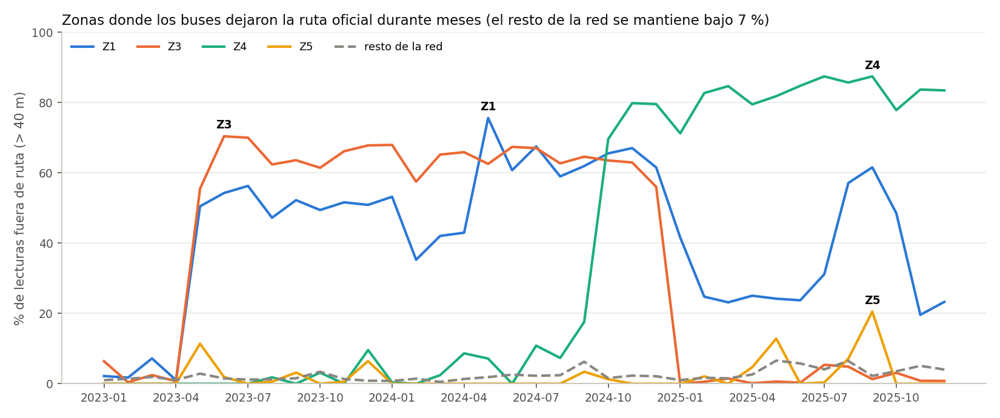

,zona,tipo,desde,hasta,meses,rutas,dist_mediana_m,lecturas_fuera,dist_terminal_m
0,Z1,desvio,2023-05,2025-12,31,"2,16,21",436.0,19386,15899.0
1,Z2,terminal,2023-01,2025-12,20,"2,16,21",80.0,9587,180.0
2,Z3,desvio,2023-05,2024-12,19,"2,16,21",177.0,9665,14642.0
3,Z4,desvio,2024-10,2025-12,15,"2,16,21",461.0,14221,4615.0
4,Z5,desvio,2023-05,2025-09,6,"2,21",164.0,878,7169.0


Resto de la red: mediana mensual 1.9 % fuera de ruta (rango 0.5–6.6 %)


In [5]:
fm = pd.read_csv(D / "gps_fuera_ruta_mensual.csv")
zonas = [c for c in fm.columns if c.startswith("Z") and zs.set_index("zona").loc[c, "tipo"] == "desvio"]
display(zs.head(8).round(4))
pal = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(fm))
for z, c in zip(zonas, pal):
    ax.plot(x, fm[z], color=c, lw=2, zorder=2, label=z)
    k = int(np.nanargmax(fm[z].values))              # etiqueta directa en el pico de cada zona
    ax.annotate(z, (x[k], fm[z].iloc[k]), xytext=(0, 6), textcoords="offset points", ha="center", color=COL["texto"], fontsize=9, weight="bold")
ax.plot(x, fm["resto"], color=COL["resto"], lw=2, ls="--", zorder=2, label="resto de la red")
ax.legend(loc="upper left", fontsize=8.5, frameon=False, ncol=5)
ax.set_xticks(x[::3]); ax.set_xticklabels(fm.mes[::3], rotation=0, fontsize=8)
ax.set_ylabel("% de lecturas fuera de ruta (> 40 m)", color=COL["texto2"]); estilo(ax); ax.set_ylim(0, 100)
ax.set_title("Zonas donde los buses dejaron la ruta oficial durante meses (el resto de la red se mantiene bajo 7 %)", fontsize=11, loc="left", color=COL["texto"])
fig.tight_layout(); fig.savefig(FIG / "desvios_mensuales_10_1.png", dpi=150); plt.close(fig)
display(Image(FIG / "desvios_mensuales_10_1.png"))
display(zs[zs.meses >= 6][["zona", "tipo", "desde", "hasta", "meses", "rutas", "dist_mediana_m", "lecturas_fuera", "dist_terminal_m"]].round(0))
print(f"Resto de la red: mediana mensual {fm['resto'].median():.1f} % fuera de ruta (rango {fm['resto'].min():.1f}–{fm['resto'].max():.1f} %)")
check("Zonas de desvío detectadas y separadas del resto de la red", RES["zonas_desvio_6m"] >= 1 and fm["resto"].median() < 5,
      f"{RES['zonas_desvio_6m']} desvíos ≥ 6 meses (+ zona de terminal); resto mediana {fm['resto'].median():.1f} %")

### 5 · Ida y vuelta por la misma vía: un punto suelto no basta

In [6]:
tr = pd.read_csv(D / "trayectorias_10_1.csv")
print(f"Lecturas en ruta con ida y vuelta posibles (punto suelto ambiguo): {RES['gps_pct_ambiguo_punto']:.1f} %")
print(f"300 viajes completos emparejados con Viterbi: cobertura mediana {tr.cobertura_pct.median():.1f} % de la ruta · "
      f"el segmento cambia frente al punto suelto en {tr.pct_cambia_vs_punto.median():.1f} % de las lecturas (mediana por viaje)")
print(f"Retrocesos > 500 m fuera de las terminales: {RES['retrocesos_500m_por_1000_pasos']:.2f} por cada 1.000 pasos")
display(tr.describe(percentiles=[0.05, 0.5, 0.95]).T.round(2))
check("Emparejamiento de viajes: cobertura mediana ≥ 95 % y < 5 retrocesos > 500 m por 1.000 pasos",
      tr.cobertura_pct.median() >= 95 and RES["retrocesos_500m_por_1000_pasos"] < 5,
      f"{tr.cobertura_pct.median():.1f} % · {RES['retrocesos_500m_por_1000_pasos']:.2f}‰")

Lecturas en ruta con ida y vuelta posibles (punto suelto ambiguo): 66.0 %
300 viajes completos emparejados con Viterbi: cobertura mediana 98.4 % de la ruta · el segmento cambia frente al punto suelto en 15.5 % de las lecturas (mediana por viaje)
Retrocesos > 500 m fuera de las terminales: 3.67 por cada 1.000 pasos


,count,mean,std,min,5%,50%,95%,max
idprogramacion,300.0,6272379.88,685531.71,5071976.00,5229391.45,6213239.00,7369346.35,7539483.00
idruta,300.0,12.95,8.08,2.00,2.00,16.00,21.00,21.00
n_lecturas,300.0,561.56,867.65,43.00,192.85,340.50,3198.55,5869.00
anio,300.0,2023.98,0.79,2023.00,2023.00,2024.00,2025.00,2025.00
pct_fuera,300.0,7.01,6.59,0.00,0.62,5.89,17.08,76.03
pct_ambiguo_punto,300.0,67.34,8.05,38.24,54.95,67.29,78.33,97.67
pct_cambia_vs_punto,300.0,16.43,8.13,0.00,5.26,15.46,29.93,68.05
pasos_en_ruta,300.0,496.29,764.98,32.00,165.70,309.00,2815.50,5319.00
retrocesos_500m,300.0,1.82,1.52,0.00,0.00,2.00,5.00,7.00
cobertura_pct,300.0,95.17,9.52,16.00,85.74,98.41,99.99,100.00


### 6 · ¿Cuántos minutos de GPS necesita un reporte para ubicarse?

,n,lecturas,exacto,lugar,pct_alta,exacto_si_alta,exacto_si_media
ventana_min,,,,,,,
0,3000,1.0,83.17,99.67,32.63,100.00,75.01
1,3000,2.0,91.70,99.63,59.53,97.26,83.53
3,3000,5.0,94.23,99.73,90.87,95.85,78.10
5,3000,8.0,94.73,99.80,95.07,95.79,74.32
10,3000,15.0,95.37,99.80,97.10,96.19,67.82


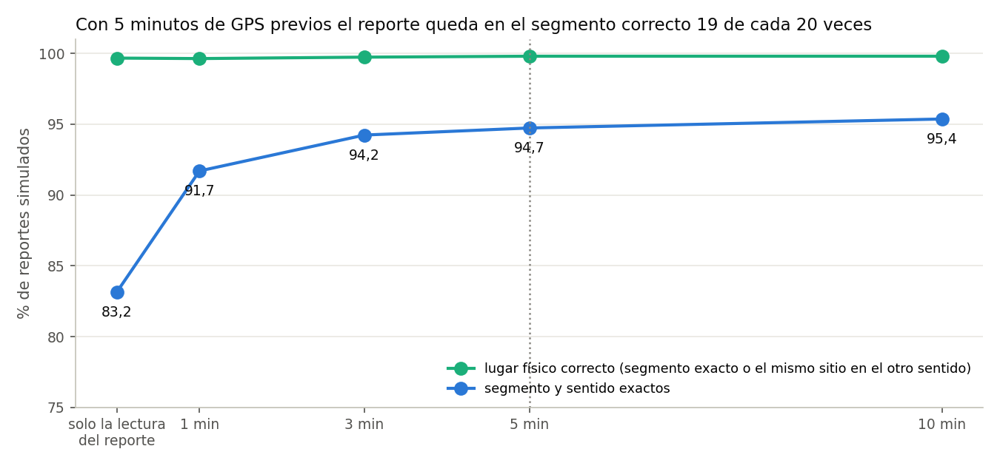

In [7]:
ex = pd.read_csv(D / "ventana_reporte_10_1.csv")
ex["lugar"] = ex.exacto | ex.ref_en_alterno
g = ex.groupby("ventana_min").agg(n=("exacto", "size"), lecturas=("n_lecturas", "median"), exacto=("exacto", "mean"),
                                  lugar=("lugar", "mean"), pct_alta=("confianza", lambda s: (s == "alta").mean()))
ga = ex[ex.confianza == "alta"].groupby("ventana_min").exacto.mean().rename("exacto_si_alta")
gm = ex[ex.confianza == "media"].groupby("ventana_min").exacto.mean().rename("exacto_si_media")
g = g.join(ga).join(gm); g[[c for c in g if c not in ("n", "lecturas")]] *= 100
display(g.round(2))
fig, ax = plt.subplots(figsize=(9, 4.2))
w = g.index.values
ax.plot(w, g.lugar, "o-", color=COL[21], lw=2, ms=8, label="lugar físico correcto (segmento exacto o el mismo sitio en el otro sentido)")
ax.plot(w, g.exacto, "o-", color=COL[2], lw=2, ms=8, label="segmento y sentido exactos")
for xi, yi in zip(w, g.exacto):
    ax.annotate(f1(yi), (xi, yi), xytext=(0, -16), textcoords="offset points", ha="center", fontsize=9, color=COL["texto"])
ax.axvline(RES["ventana_reporte_min"], color=COL["resto"], ls=":", lw=1.2)
ax.set_xticks(w); ax.set_xticklabels([("solo la lectura\ndel reporte" if v == 0 else f"{v} min") for v in w], fontsize=9)
ax.set_ylim(75, 101); ax.set_ylabel("% de reportes simulados", color=COL["texto2"]); estilo(ax)
ax.legend(loc="lower right", fontsize=8.5, frameon=False)
ax.set_title("Con 5 minutos de GPS previos el reporte queda en el segmento correcto 19 de cada 20 veces", fontsize=11, loc="left", color=COL["texto"])
fig.tight_layout(); fig.savefig(FIG / "ventana_reporte_10_1.png", dpi=150); plt.close(fig)
display(Image(FIG / "ventana_reporte_10_1.png"))
v5 = g.loc[RES["ventana_reporte_min"]]
check("Ventana de 5 min: segmento exacto ≥ 90 % y lugar físico ≥ 99 %", v5.exacto >= 90 and v5.lugar >= 99,
      f"{v5.exacto:.2f} % · {v5.lugar:.2f} %")
check("Confianza «alta» más precisa que «media» con 5 min", v5.exacto_si_alta > v5.exacto_si_media,
      f"{v5.exacto_si_alta:.1f} % vs {v5.exacto_si_media:.1f} %")

### 7 · Pruebas y verificación de seguridad

In [8]:
p = subprocess.run([sys.executable, "tests_10_1.py"], capture_output=True, text=True, encoding="utf-8")
print(p.stdout)
check("tests_10_1.py: 7/7 PASS", p.returncode == 0 and "7/7 PASS" in p.stdout, p.stdout.strip().splitlines()[-1])
import re
# credenciales escritas como texto literal (la contraseña se pide con getpass y la API key va en variable de entorno)
patron = re.compile(r"""((password|passwd|contrase(n|ñ)a|api[_-]?key|clave)\s*=\s*['"][^'"]{4,}['"]|sk-ant-[a-z0-9]|SOBUSA_PG_PASS\s*=\s*\S)""", re.I)
sospechosos = []
for f in list(Path(".").glob("*.py")) + list(Path("src").rglob("*.py")) + list(D.rglob("*.csv")) + list(D.rglob("*.json")):
    if f.name == "build_nb_10_1.py":
        continue
    t = f.read_text(encoding="utf-8", errors="ignore")
    if patron.search(t):
        sospechosos.append(str(f))
check("Sin credenciales en código ni en salidas", not sospechosos, ", ".join(sospechosos) or "ninguna coincidencia")
chk = pd.DataFrame(CHECKS); chk.to_csv(D / "checks_10_1.csv", index=False)
display(chk); print(f"{(chk.resultado == 'PASS').sum()}/{len(chk)} PASS")

PASS  a · geometría: proyección (elipsoide) vs Haversine (esfera) < 0,7 % y DP conserva extremos
PASS  b · red: longitud 6.800 m, circuito cerrado, 14 segmentos, límites de segmento exactos
PASS  c · punto suelto: vía compartida ambigua, manzana sin ambigüedad, a 100 m fuera de ruta
PASS  d · trayectoria: hacia el este se ubica en la ida, hacia el oeste en la vuelta
PASS  e · circuito: pasar por la terminal (avance ~L → ~0) no es un retroceso
PASS  f · reporte: desviado → último punto en ruta; sin GPS en ruta → sin_ubicacion; alterno = otro sentido
PASS  g · extracción real (si existe): 386 segmentos activos, continuidad < 1 m y longitudes = BD (< 0,1 %)

7/7 PASS



,check,resultado,detalle
0,"Extracción: 386 segmentos activos de 3 rutas, ...",PASS,386 segmentos
1,Continuidad: hueco entre segmentos consecutivo...,PASS,máx 0.000 m
2,Circuitos cerrados (fin a < 150 m del inicio),PASS,"[60.0, 10.0, 24.0] m"
3,"Proyección local vs longitud de la BD < 0,1 %",PASS,máx 0.030 %
4,GeoJSON simplificado para el equipo: 386 segme...,PASS,0.14 MB (original 24 MB)
5,GPS sobre la vía: mediana de distancia al eje ...,PASS,3.28 m
6,Umbral poco sensible: entre 30 y 60 m el % fue...,PASS,8.34 % → 7.17 %
7,Zonas de desvío detectadas y separadas del res...,PASS,4 desvíos ≥ 6 meses (+ zona de terminal); rest...
8,Emparejamiento de viajes: cobertura mediana ≥ ...,PASS,98.4 % · 3.67‰
9,Ventana de 5 min: segmento exacto ≥ 90 % y lug...,PASS,94.73 % · 99.80 %


13/13 PASS


## Conclusiones

**Conclusión 1 · La red ya existe en la base de datos y está completa**
- SOBUSA segmentó **22 rutas** (`rutas_segmentos_config`, 22 configuraciones activas del 13-ago-2026): cada ruta se corta en segmentos de **500 m**, formados por porciones de 20 cm.
- Rutas del proyecto: **2 · SILENCIO** 135 segmentos (67,2 km) · **16 · CRA 54** 123 (61,1 km) · **21 · CL 72** 128 (63,9 km).
  - Son circuitos cerrados de ida y vuelta: el último segmento termina a 60 / 10 / 24 m del primero, en la misma terminal para las tres.
  - Entre segmentos consecutivos no hay huecos (0,000 m).
  - La geometría mide 7–12 % más que `distancia_global` (62,9 / 56,4 / 57,0 km). Para el Módulo 10 manda la geometría, porque es donde el GPS ubica el bus.
- La tabla `rutasgeograficas` no es visible para nuestro usuario (q6 falló). No hizo falta: los segmentos unidos forman la línea completa.
- Para el equipo queda `datos_10/red_vial_segmentos.geojson`, simplificado a 1 m: 0,14 MB (el original pesa 24 MB).
- La proyección local usa los radios del elipsoide WGS84 y difiere de las longitudes de PostGIS en 0,03 %.

**Conclusión 2 · «En ruta» = a 40 m o menos del eje**
- En 971.335 lecturas GPS (1.673 viajes, 2023–2025), la mediana de distancia al eje de la ruta es **3,3 m** y el percentil 90, **14 m**.
- Más allá de ~35 m el histograma ya no cae. Hacia 75–95 m aparece un segundo grupo: la vía paralela, a una cuadra.
- **El umbral es poco sensible:** entre 30 y 60 m, el % de lecturas fuera de ruta solo pasa de 8,34 % a 7,17 %. Con 40 m queda en **7,84 %**.
- `UMBRAL_M = 40` queda fijo en `red_vial.py`.

**Conclusión 3 · El GPS ya registra los desvíos largos**
- El 7,8 % fuera de ruta no está repartido: se concentra en **4 zonas** con desvíos de 6 meses o más. Las mismas zonas aparecen en las 3 rutas.
  - **Z3** (11,014 −74,845): may-2023 → dic-2024, 55–70 % de lecturas fuera.
  - **Z1** (11,017 −74,870): desde may-2023, con altibajos.
  - **Z4** (10,929 −74,794): oct-2024 → dic-2025, **83 %** fuera en los últimos 12 meses. Seguía activa al cierre de los datos.
  - **Z5**: picos menores.
- **Z2** está a 180 m de la terminal: son maniobras y espera del bus, no desvíos. Se rotula `terminal`.
- En el resto de la red, la mediana mensual es **1,9 %** fuera de ruta y nunca supera el 7 %.
- **Utilidad para el Módulo 10:**
  - estos episodios son una «verdad de terreno» observada para los cierres de vía (`datos_10/desvios_historicos_10_1.csv`), útil al armar el set de prueba de la 10.3;
  - un bus que sale de la ruta justo antes de reportar es evidencia a favor de un cierre.
- La causa de cada desvío (obra, cierre, cambio de recorrido) **no se conoce**: el GPS solo dice dónde y cuándo.

**Conclusión 4 · Cómo se ubica un reporte**
- **Un punto suelto no basta.** El 66 % de las lecturas en ruta están donde la ida y la vuelta comparten vía. Solo con el punto, el reporte queda en el segmento correcto el **83,2 %** de las veces.
- `ubicar_reporte` empareja con Viterbi las lecturas del bus de los **5 minutos previos** (mediana 8 lecturas). El emparejamiento exige que el avance no retroceda y es cíclico en la terminal.
- **Resultado** (3.000 reportes simulados en 300 viajes, comparados con el emparejamiento del viaje completo):
  - segmento y sentido exactos: **94,7 %** (1 min 91,7 % · 10 min 95,4 %);
  - lugar físico correcto: **99,8 %**. Cuando falla, casi siempre es el mismo sitio en el otro sentido, y ese caso se devuelve como `nro_segmento_alterno`.
- **Confianza:**
  - «alta» en el 95 % de los reportes, con **95,8 %** de acierto;
  - «media» con **74,3 %**;
  - las fallas se concentran en las dos puntas del recorrido, donde el bus espera detenido.
- **Límites:**
  - La referencia es el propio emparejamiento del viaje completo, no una verdad externa.
  - Los reportes simulados se tomaron en puntos en ruta. El caso «desviado» (se reporta el último punto en ruta) solo se prueba con la ruta sintética.
  - `margen_min = 1000` se calibró en esta misma muestra; es una etiqueta descriptiva, no un modelo.
- Ningún paso pide coordenadas al conductor ni llama a la API (costo $0).

**Conclusión 5 · Qué queda para las subfases siguientes**
- **13/13 checks PASS** (`datos_10/checks_10_1.csv`) y `tests_10_1.py` **7/7 PASS**. No hay credenciales en código ni en salidas.
- **10.2 · Protocolo:** el conductor solo dice «aquí» o «más adelante en [referencia de una lista cerrada]». La lista de referencias (cruces y puntos conocidos) hay que construirla sobre estos segmentos.
- **10.3 · Set de prueba:**
  - usar las zonas Z1, Z3, Z4 y Z5 y sus fechas como casos reales de cierre o desvío;
  - retomar la discusión pendiente sobre la cantidad de audios y textos.
- **10.6 · Servicio:**
  - leer el GPS en vivo **por vehículo y rango de 5 minutos**, sin recorrer `conteo_pasajeros_destino` completa; antes, verificar sus índices;
  - el reporte llega con remitente → `idvehiculo` → viaje activo → `idruta`.
- **Pendiente con el dueño del Módulo 12:** acordar el esquema del evento (`idruta`, `nro_segmento`, `nro_segmento_alterno`, `confianza`, `desviado`, hora y tipo).

<a id="m10-2"></a>

### A2.2.2 &middot; Subfase 10.2 · Protocolo de reporte y contrato del evento

<sub>Notebook original: `modulo10/subfase_10_2_protocolo.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 10 · Subfase 10.2 — Protocolo de reporte y contrato del evento

**Persona 3.** La 10.1 dejó la red y la ubicación del bus por GPS. Esta subfase define **qué dice el conductor** y **qué produce el sistema**:

| Pieza | Archivo | Estado |
|---|---|---|
| Guía para conductores v1.2 (qué pasa · dónde · qué tan grave 1–5 · duración · sentido; «mi bus» si solo afecta al bus) | `protocolo_conductores_10_2.md` | Aprobada por la Persona 3 (27-oct-2026); 1.2 tras la revisión |
| Catálogo de esquinas de cada ruta (OpenStreetMap) | `referencias_10_2.py` → `datos_10/referencias/` | Opción C: todas las esquinas con nombre |
| «Adelante en X con Y» → segmento | `src/geo/referencias.py` (`resolver_referencia`) | |
| Contrato del evento (JSON Schema 1.2) | `contrato_evento_10_2.json` | **Propuesta**: falta confirmarla con el dueño del Módulo 12 |
| Contrato del mensaje de entrada (webhook, WhatsApp simulado) | `contrato_mensaje_entrada_10_2.json` | Nuevo tras la revisión (H5) |
| Revisión de la subfase | `revisiones/revision_10_2.md`, `revisar_10_2.py` | Aprobada con observaciones |
| Extracción + GPS → evento | `src/m10/evento.py` (`construir_evento`, `validar_evento`) | |
| Validación de punta a punta con GPS real | `analisis_10_2.py` | |

**Por qué OpenStreetMap y no Google.** Los términos de Google Geocoding solo permiten guardar coordenadas 30 días (B.6.3.1) y prohíben usarlas con mapas que no sean de Google (B.6.2). OSM (licencia ODbL) se puede guardar y derivar con atribución: **© colaboradores de OpenStreetMap**. datos.gov.co (nomenclatura) respondió «acceso no permitido». Fuentes en `FUENTES_modulo10.md`.

Sin API de Claude en esta subfase (costo $0): la extracción del texto llega en la 10.5; aquí se prueba todo lo que va antes y después.

## Parte 2 · Análisis offline

In [1]:
import json
import platform
import re
import subprocess
import sys
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

sys.path.insert(0, "src")
from geo import red_vial as rv
from geo import referencias as rf

pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 70)
D = Path("datos_10"); R_ = D / "referencias"; FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})

meta = json.loads((D / "insumos" / "osm_vias_barranquilla_meta.json").read_text(encoding="utf-8"))
rref = json.loads((R_ / "resumen_referencias.json").read_text(encoding="utf-8"))
r102 = json.loads((R_ / "resumen_10_2.json").read_text(encoding="utf-8"))
seg = rv.leer_segmentos(D / "extraccion" / "q4_segmentos.csv"); red = rv.construir_red(seg)
cat = pd.read_csv(R_ / "catalogo_referencias.csv"); ejes = pd.read_csv(R_ / "ejes_ruta.csv")
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a", "gris": "#c3c2b7", "texto": "#0b0b0b", "texto2": "#52514e", "grid": "#e9e8e2"}
def estilo(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors=COL["texto2"], labelsize=9)
    if grid: ax.grid(axis=grid, color=COL["grid"], lw=0.8)
    ax.set_axisbelow(True)
print(f"Python {platform.python_version()} · OSM del {meta['fecha_datos_osm']} · {meta['n_vias']:,} vías descargadas · {meta['licencia']}")

Python 3.9.25 · OSM del 2026-10-28T04:12:51Z · 16,563 vías descargadas · ODbL 1.0 — © colaboradores de OpenStreetMap (https://www.openstreetmap.org/copyright)


### 1 · Por qué calle va cada ruta

In [2]:
osm_n = rref["por_ruta"]
for r in (2, 16, 21):
    e = ejes[(ejes.idruta == r) & (ejes.eje != "(sin nombre)")].groupby("eje").largo_m.sum().sort_values(ascending=False)
    print(f"Ruta {r}: {osm_n[str(r)]['tramos']} tramos · {osm_n[str(r)]['pct_sin_nombre']:.1f} % sin nombre · principales: "
          + ", ".join(f"{k} {v / 1000:.1f} km" for k, v in e.head(8).items()))
largo = lambda r, n: ejes[(ejes.idruta == r) & (ejes.eje == n)].largo_m.sum()
check("OSM: ≥ 10.000 vías vehiculares con nombre y licencia ODbL registrada", meta["n_vias_con_nombre"] >= 10000 and "ODbL" in meta["licencia"],
      f"{meta['n_vias_con_nombre']:,} con nombre")
check("La calle de cada ruta coincide con su nombre (16 → Carrera 54 ≥ 3 km; 21 → Calle 72 ≥ 2 km)",
      largo(16, "Carrera 54") >= 3000 and largo(21, "Calle 72") >= 2000,
      f"Carrera 54 {largo(16, 'Carrera 54') / 1000:.1f} km · Calle 72 {largo(21, 'Calle 72') / 1000:.1f} km")
mx = max(v["pct_sin_nombre"] for v in osm_n.values())
check("Recorrido sin nombre de calle ≤ 10 % en cada ruta", mx <= 10, f"máx {mx:.1f} %")

Ruta 2: 91 tramos · 7.5 % sin nombre · principales: Avenida Murillo 8.2 km, Carrera 51B 5.3 km, Carrera 14 5.1 km, Avenida Circunvalar 4.9 km, Carrera 30 4.9 km, Boulevard Simón Bolívar 3.5 km, Carrera 27 3.1 km, Carrera 15 2.7 km
Ruta 16: 74 tramos · 2.5 % sin nombre · principales: Avenida Murillo 8.5 km, Carrera 51B 7.7 km, Avenida Calle 17 5.8 km, Carrera 54 5.2 km, Carrera 30 4.9 km, Avenida Circunvalar 4.9 km, Boulevard Simón Bolívar 3.6 km, Carrera 53 2.5 km
Ruta 21: 97 tramos · 2.5 % sin nombre · principales: Avenida Murillo 8.5 km, Carrera 51B 5.7 km, Carrera 30 5.1 km, Avenida Circunvalar 4.7 km, Carrera 21 3.3 km, Calle 36B 3.1 km, Calle 72 3.0 km, Avenida Calle 30 2.5 km


### 2 · Catálogo de esquinas (opción C: todas las que tienen nombre)

tipo,cruce,giro,principales (avenidas)
idruta,,,
2,355,67,42
16,263,53,35
21,327,75,42


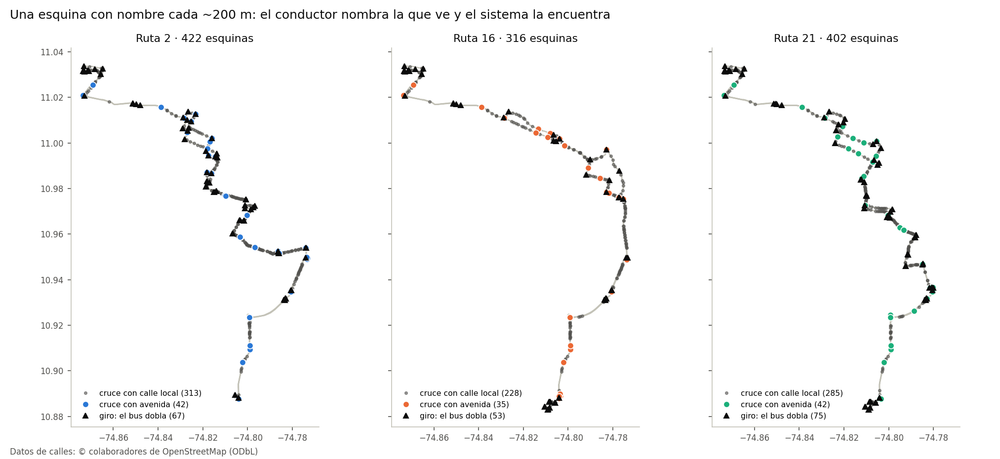

In [3]:
t = cat.groupby(["idruta", "tipo"]).size().unstack(fill_value=0)
t["principales (avenidas)"] = cat[(cat.tipo == "cruce") & (cat.cruce_jerarquia <= 3)].groupby("idruta").size()
display(t)
fig, axs = plt.subplots(1, 3, figsize=(13.5, 6.2), sharex=True, sharey=True)
for ax, r in zip(axs, (2, 16, 21)):
    la, lo = rv.a_latlon(red[r].xy[::3]); ax.plot(lo, la, color=COL["gris"], lw=1.2, zorder=1)
    c = cat[cat.idruta == r]
    o = c[(c.tipo == "cruce") & (c.cruce_jerarquia > 3)]
    p = c[(c.tipo == "cruce") & (c.cruce_jerarquia <= 3)]
    g = c[c.tipo == "giro"]
    ax.plot(o.lon, o.lat, "o", ms=2.5, color=COL["texto2"], alpha=0.55, zorder=2, label=f"cruce con calle local ({len(o)})")
    ax.plot(p.lon, p.lat, "o", ms=6, color=COL[r], mec="white", mew=0.8, zorder=3, label=f"cruce con avenida ({len(p)})")
    ax.plot(g.lon, g.lat, "^", ms=5, color=COL["texto"], zorder=3, label=f"giro: el bus dobla ({len(g)})")
    ax.set_title(f"Ruta {r} · {len(c)} esquinas", fontsize=10.5, color=COL["texto"])
    ax.set_aspect(1 / np.cos(np.radians(rv.LAT0))); estilo(ax, grid=None); ax.tick_params(labelsize=8)
    ax.legend(loc="lower left", fontsize=7.5, frameon=False)
fig.suptitle("Una esquina con nombre cada ~200 m: el conductor nombra la que ve y el sistema la encuentra", fontsize=12, x=0.01, ha="left", color=COL["texto"])
fig.text(0.01, 0.01, "Datos de calles: © colaboradores de OpenStreetMap (ODbL)", fontsize=8, color=COL["texto2"])
fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig(FIG / "catalogo_esquinas_10_2.png", dpi=150); plt.close(fig)
display(Image(FIG / "catalogo_esquinas_10_2.png"))
cr = cat[cat.tipo == "cruce"]
check("Catálogo: ≥ 200 cruces por ruta y ningún cruce consigo misma",
      cr.groupby("idruta").size().min() >= 200 and (cr.eje.map(rf.clave) != cr.cruce.map(rf.clave)).all(),
      str(cr.groupby("idruta").size().to_dict()))

### 3 · ¿Qué tanto servía la lista de ChatGPT?

In [4]:
v = pd.read_csv(R_ / "validacion_chatgpt_10_2.csv")
print(f"De {len(v)} cruces propuestos por ChatGPT, {int(v.en_alguna_ruta.sum())} están en alguna de nuestras rutas "
      f"({int(v.via1.isna().sum())} no eran cruces sino tramos «entre calles»).")
display(v[v.en_alguna_ruta][["corredor", "interseccion", "ruta_2", "ruta_16", "ruta_21"]])

De 54 cruces propuestos por ChatGPT, 20 están en alguna de nuestras rutas (5 no eran cruces sino tramos «entre calles»).


,corredor,interseccion,ruta_2,ruta_16,ruta_21
1,Calle 72,Calle 72 con carrera 54,NaN,39.0,NaN
3,Calle 72,Calle 72 con carrera 46,NaN,NaN,89.0
4,Calle 72,Calle 72 con carrera 43,NaN,NaN,38.0
5,Calle 72,Calle 72 con carrera 38,NaN,NaN,36.0
6,Carrera 54,Calle 72 con carrera 54,NaN,39.0,NaN
7,Carrera 54,Calle 53 con carrera 54,NaN,35.0,NaN
8,Carrera 54,Calle 58 con carrera 54,NaN,36.0,NaN
9,Carrera 54,Calle 50 con carrera 54,NaN,35.0,NaN
10,Carrera 54,Carrera 54 con Vía 40,NaN,33.0,NaN
21,Vía 40,Vía 40 con calle 30,NaN,29.0,NaN


### 4 · Protocolo para conductores y contrato del evento

In [5]:
proto = Path("protocolo_conductores_10_2.md").read_text(encoding="utf-8")
display(Markdown(proto))
contrato = json.loads(Path("contrato_evento_10_2.json").read_text(encoding="utf-8"))
p = contrato["properties"]
filas = [{"campo": k, "tipo / valores": (str(s.get("enum")) if "enum" in s else s.get("type", "objeto")), "obligatorio": k in contrato["required"],
          "nota": s.get("description", "")[:90]} for k, s in p.items()]
display(pd.DataFrame(filas))
entrada = json.loads(Path("contrato_mensaje_entrada_10_2.json").read_text(encoding="utf-8"))
print("Mensaje de entrada (ejemplo):"); print(json.dumps(entrada["examples"][0], ensure_ascii=False, indent=1))
tipos_md = set(re.findall(r"^\| \*\*(\w+)\*\* \|", proto, flags=re.M))
tipos_js = set(p["tipo_evento"]["enum"])
check("Guía y contrato usan los mismos 9 tipos de evento", {rf.clave(t_) for t_ in tipos_md} == tipos_js,
      f"guía {sorted(tipos_md)} · contrato {sorted(tipos_js)}")

# Cómo reportar un evento en la vía · Guía para conductores de SOBUSA

**Versión 1.2 · 27-oct-2026 · Módulo 10 (proyecto SOBUSA–Uninorte)**

Su reporte ayuda a ajustar las salidas de los buses cuando algo pasa en la vía. Toma menos de 15 segundos.

## Qué decir, siempre en este orden

| # | Parte | Qué decir | Ejemplos |
|---|---|---|---|
| 1 | **Qué pasa** | Una de estas palabras: **trancón · choque · varado · obra · arroyo · bloqueo · evento · semáforo** (o «otro», y lo describe en pocas palabras). Si el problema es **solo de su bus** y no tapa la vía, agregue **«mi bus»** | «Choque», «Varado, mi bus» |
| 2 | **Dónde** | **«aquí»** si está en el sitio, o **«adelante en [calle] con [calle]»** si lo ve más adelante | «aquí», «adelante en la 72 con 38» |
| 3 | **Qué tan grave** | El **nivel del 1 al 5** o su palabra (tabla de abajo). No hace falta si es «mi bus» | «nivel 3» o «un carril» |
| 4 | **Cuánto va a durar** (si lo sabe) | **corta · media · larga · muy larga** | «larga» |
| 5 | **Sentido** (si lo sabe) | **mi sentido** o **los dos** | «los dos» |

### Qué tan grave: niveles

| Nivel | Palabra | Cómo se ve en la vía |
|---|---|---|
| **1** | **lento** | El tráfico avanza, pero más lento de lo normal |
| **2** | **pare y siga** | Avanza a ratos; la demora se nota |
| **3** | **un carril** | Un carril está bloqueado; se pasa, pero con demora |
| **4** | **casi cerrada** | Pasa un vehículo a la vez o con maniobras; mejor desviarse |
| **5** | **cerrada** | No se puede pasar; hay que desviarse |

### Solo mi bus o la vía

- **«Mi bus»:** el problema es de su bus y **no afecta a los demás** (por ejemplo, varado orillado, pinchazo en la bahía). No diga nivel.
- **La vía:** el problema afecta a todos los que pasan por ahí, **también si es su propio bus varado tapando un carril**. En ese caso no diga «mi bus»: diga el tipo y el nivel («Varado, aquí, un carril»).

### Cuánto va a durar

| Diga | Significa |
|---|---|
| **corta** | Menos de 30 minutos |
| **media** | Entre 30 minutos y 1 hora |
| **larga** | Entre 1 y 2 horas |
| **muy larga** | Más de 2 horas |

**No hace falta decir** la hora, la ruta, el número del bus ni su ubicación exacta: el sistema los toma del GPS del bus.

## Ejemplos

- «**Choque, adelante en la 72 con 38, un carril.**» → nivel 3
- «**Arroyo, aquí, cerrada, larga, los dos.**» → nivel 5
- «**Trancón, adelante en Murillo con 21, nivel 2, corta, mi sentido.**»
- «**Obra, adelante en la 51B con Circunvalar, casi cerrada, muy larga.**» → nivel 4
- «**Varado, mi bus, aquí.**» → solo afecta a su bus
- «**Varado, aquí, un carril, corta.**» → su bus (u otro) tapa un carril: afecta la vía

**Cuando se despeje:** «**Despejado, la 72 con 38.**» (o «Despejado, aquí»).

## Qué significa cada tipo

| Diga | Cuando |
|---|---|
| **trancón** | Tráfico detenido o muy lento sin causa a la vista |
| **choque** | Accidente o atropello que ocupa la vía |
| **varado** | Un vehículo dañado (incluido su propio bus) |
| **obra** | Obra, cierre programado o desvío oficial |
| **arroyo** | Agua o arroyo en la vía, inundación |
| **bloqueo** | Manifestación, protesta o bloqueo de la vía |
| **evento** | Partido, concierto, Carnaval u otro evento con mucha gente |
| **semáforo** | Semáforo apagado o dañado |
| **otro** | Cualquier otra cosa (árbol o poste caído, retén, hueco grande…): diga «otro» y qué es |

## Lo que NO debe ir en el mensaje

- Nombres de personas, teléfonos ni placas de vehículos.
- Insultos ni opiniones. Solo lo que ve en la vía.

## ¿Texto o audio?

| Situación | Canal |
|---|---|
| Evento grande (trancón fuerte, vía cerrada) | Texto |
| Evento pequeño, para no interrumpir el recorrido | Audio corto (máximo 15 segundos) |

En el audio, hable claro y diga las partes en el mismo orden que en el texto.


,campo,tipo / valores,obligatorio,nota
0,version,objeto,True,
1,id_evento,string,True,"Hash del vehículo, la hora de recepción y el texto: el mismo mensa..."
2,recibido,string,True,"Hora de recepción, con zona (America/Bogota)."
3,canal,"['texto', 'audio']",True,
4,idvehiculo,string,True,"Del remitente registrado, nunca del mensaje."
5,idprogramacion,"[integer, null]",False,Viaje activo del vehículo a la hora del reporte.
6,idruta,"[2, 16, 21]",True,
7,tipo_evento,"['trancon', 'choque', 'varado', 'obra', 'arroyo', 'bloqueo', 'even...",True,En un despeje es el tipo del evento que se cierra; si el conductor...
8,detalle_otro,"[string, null]",False,Solo si tipo_evento = otro.
9,alcance,"['via', 'solo_bus']",True,via: afecta a todos los que pasan (incluido el bus propio varado t...


Mensaje de entrada (ejemplo):
{
 "version": "1.0",
 "id_mensaje": "wamid.0001",
 "recibido": "2026-10-27T07:42:10-05:00",
 "remitente": {
  "idvehiculo": "SOBUSA117",
  "hash_remitente": null
 },
 "canal": "texto",
 "texto": "Choque, adelante en la 72 con 38, un carril.",
 "audio": null,
 "simulado": true
}


### 5 · Prueba de punta a punta con GPS real

In [6]:
s = pd.read_csv(R_ / "simulacion_reportes_10_2.csv")
N = {r: len(red[r].nro_segmento) for r in red}
dif = (s.seg_obtenido - s.seg_esperado).abs(); dif = np.minimum(dif, s.idruta.map(N) - dif)
s["pm1"] = dif <= 1
s["forma"] = np.where(s.dicho.str.contains(r"\bla \d"), "con número suelto («la 72 con 38»)", "nombre completo o de avenida")
print(f"{len(s):,} reportes simulados en {s.idprogramacion.nunique()} viajes reales · ubicados solo con 5 min de GPS previos")
display(pd.DataFrame({"segmento exacto %": [100 * s.exacto.mean()], "a ±1 segmento %": [100 * s.pm1.mean()],
                      "exacto o el alterno %": [100 * s.exacto_o_alterno.mean()],
                      "eventos fuera del contrato": [int((s.errores_contrato > 0).sum())]}).round(2))
display((s.groupby("forma")[["exacto", "pm1"]].mean() * 100).round(2))
print("Ejemplos de diferencias de más de un segmento:")
display(s[~s.pm1 & ~s.exacto_o_alterno][["idruta", "dicho", "esquina", "seg_esperado", "seg_obtenido", "adelante_m"]])
check("Simulación: segmento exacto ≥ 95 %, a ±1 segmento ≥ 99 %, todos los eventos cumplen el contrato",
      s.exacto.mean() >= 0.95 and s.pm1.mean() >= 0.99 and (s.errores_contrato == 0).all(),
      f"{100 * s.exacto.mean():.2f} % · {100 * s.pm1.mean():.2f} % · {int((s.errores_contrato > 0).sum())} fuera")

1,481 reportes simulados en 300 viajes reales · ubicados solo con 5 min de GPS previos


,segmento exacto %,a ±1 segmento %,exacto o el alterno %,eventos fuera del contrato
0,97.64,99.39,97.97,0


,exacto,pm1
forma,,
con número suelto («la 72 con 38»),97.93,99.41
nombre completo o de avenida,97.39,99.38


Ejemplos de diferencias de más de un segmento:


,idruta,dicho,esquina,seg_esperado,seg_obtenido,adelante_m
181,16,Vía 40 con Calle 30,Vía 40 con Avenida Calle 30,31,29,1109.7
662,16,la 1A con la 68A,Calle 68A con Transversal 1A 4,121,119,656.4
1106,16,Vía 40 con la 30,Vía 40 con Avenida Calle 30,31,29,434.7
1124,16,la vía 40 con Calle 30,Vía 40 con Avenida Calle 30,31,29,574.7


### 6 · Las zonas de desvío de la 10.1, con nombre de calle

In [7]:
z = pd.read_csv(R_ / "zonas_desvio_calles_10_2.csv")
display(z)

,zona,desde,hasta,meses,idruta,dist_centro_a_ruta_m,nro_segmento,calle_de_la_ruta,esquina_antes,esquina_despues
0,Z1,2023-05,2025-12,31,2,343,74,Carrera 30,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
1,Z1,2023-05,2025-12,31,16,344,68,Carrera 30,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
2,Z1,2023-05,2025-12,31,21,344,71,Carrera 30,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
3,Z3,2023-05,2024-12,19,2,249,79,Carrera 51B,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
4,Z3,2023-05,2024-12,19,16,250,74,Carrera 51B,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
5,Z3,2023-05,2024-12,19,21,249,76,Carrera 51B,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
6,Z4,2024-10,2025-12,15,2,526,120,Avenida Circunvalar,Avenida Circunvalar con Autopista Aeropuerto,Avenida Circunvalar con Avenida Murillo
7,Z4,2024-10,2025-12,15,16,522,107,Avenida Circunvalar,Avenida Circunvalar con Autopista Aeropuerto,Avenida Circunvalar con Avenida Murillo
8,Z4,2024-10,2025-12,15,21,520,113,Avenida Circunvalar,Avenida Circunvalar con Calle 43,Avenida Circunvalar con Avenida Murillo
9,Z5,2023-05,2025-09,6,2,84,107,Carrera 14,Carrera 14 con Calle 40,Carrera 14 con Calle 38B


### 7 · Pruebas y verificación de seguridad

In [8]:
for t_, n in (("tests_10_1.py", 7), ("tests_10_2.py", 9)):
    p_ = subprocess.run([sys.executable, t_], capture_output=True, text=True, encoding="utf-8")
    print(p_.stdout.strip().splitlines()[-1], "·", t_)
    check(f"{t_}: {n}/{n} PASS", p_.returncode == 0 and f"{n}/{n} PASS" in p_.stdout, p_.stdout.strip().splitlines()[-1])
patron = re.compile(r"""((password|passwd|contrase(n|ñ)a|api[_-]?key|clave)\s*=\s*['"][^'"]{4,}['"]|sk-ant-[a-z0-9]|SOBUSA_PG_PASS\s*=\s*\S)""", re.I)
sosp = [str(f) for f in list(Path(".").glob("*.py")) + list(Path("src").rglob("*.py")) + list(R_.glob("*.*"))
        if f.name not in ("build_nb_10_1.py", "build_nb_10_2.py") and patron.search(f.read_text(encoding="utf-8", errors="ignore"))]
check("Sin credenciales en código ni en salidas", not sosp, ", ".join(sosp) or "ninguna coincidencia")
chk = pd.DataFrame(CHECKS); chk.to_csv(D / "checks_10_2.csv", index=False)
display(chk); print(f"{(chk.resultado == 'PASS').sum()}/{len(chk)} PASS")

7/7 PASS · tests_10_1.py


9/9 PASS · tests_10_2.py


,check,resultado,detalle
0,OSM: ≥ 10.000 vías vehiculares con nombre y licencia ODbL registrada,PASS,"16,450 con nombre"
1,La calle de cada ruta coincide con su nombre (16 → Carrera 54 ≥ 3 ...,PASS,Carrera 54 5.2 km · Calle 72 3.0 km
2,Recorrido sin nombre de calle ≤ 10 % en cada ruta,PASS,máx 7.5 %
3,Catálogo: ≥ 200 cruces por ruta y ningún cruce consigo misma,PASS,"{2: 355, 16: 263, 21: 327}"
4,Guía y contrato usan los mismos 9 tipos de evento,FAIL,"guía ['1', '2', '3', '4', '5', 'arroyo', 'bloqueo', 'choque', 'cor..."
5,"Simulación: segmento exacto ≥ 95 %, a ±1 segmento ≥ 99 %, todos lo...",PASS,97.64 % · 99.39 % · 0 fuera
6,tests_10_1.py: 7/7 PASS,PASS,7/7 PASS
7,tests_10_2.py: 9/9 PASS,PASS,9/9 PASS
8,Sin credenciales en código ni en salidas,PASS,ninguna coincidencia


8/9 PASS


## Conclusiones

**Conclusión 1 · Protocolo de reporte, aprobado (v1.2 tras la revisión)**
- **Formato:** el conductor dice, en este orden:
  1. **qué pasa**: 9 tipos; si el problema es solo de su bus y no tapa la vía, agrega «mi bus»;
  2. **dónde**: «aquí» o «adelante en [calle] con [calle]»;
  3. **qué tan grave**, nivel 1–5 o su palabra: 1 lento · 2 pare y siga · 3 un carril · 4 casi cerrada · 5 cerrada;
  4. **cuánto va a durar**, si lo sabe: corta (< 30 min), media (30–60), larga (1–2 h) o muy larga (> 2 h);
  5. **sentido**, si lo sabe.
- Para cerrar un evento: «Despejado, [esquina]».
- No dice hora, ruta, número del bus ni coordenadas.
- Texto para eventos grandes; audio para los pequeños.
- **Decisiones de la Persona 3 tras la revisión (27-oct):**
  - la severidad 1–5 del plan la da el conductor con una guía de lo que se ve en la vía;
  - un bus dañado es problema solo del bus, salvo que tape la vía;
  - la duración va en 4 niveles;
  - la guía no incluye reglas de seguridad propias.
- La guía usa los mismos 9 tipos que el contrato (check PASS).

**Conclusión 2 · Esquinas desde OpenStreetMap, no desde Google ni ChatGPT**
- **Google Geocoding se descartó por sus términos:** solo deja guardar las coordenadas 30 días y prohíbe usarlas en mapas que no sean de Google. datos.gov.co no fue accesible.
- **OpenStreetMap:**
  - una sola descarga de 16.563 vías, datos del 28-oct-2026, licencia ODbL con atribución;
  - las calles de cada ruta coinciden con su nombre: la 16 va 5,2 km por la Carrera 54 y la 21 va 3,0 km por la Calle 72;
  - entre el 2,5 % y el 7,5 % del recorrido queda sin nombre.
- **Catálogo (opción C, todas las esquinas con nombre):**
  - **422 / 316 / 402 esquinas** en las rutas 2 / 16 / 21 (cruces más giros), una cada ~200 m;
  - de ellas, 42 / 35 / 42 son cruces con avenidas.
- **La lista de ChatGPT habría dejado huecos:** de sus 54 cruces, solo **20** están en alguna de nuestras rutas, y 5 ni siquiera eran cruces.

**Conclusión 3 · «Adelante en X con Y» funciona con GPS real**
- **Prueba:** 1.481 reportes simulados en 300 viajes reales (2023–2025).
  - El conductor nombra una esquina de su ruta entre 300 m y 3 km adelante, de distintas formas: «la 72 con 38», «calle 72 con Carrera 38», al revés, «Murillo», «Circunvalar».
  - El evento se ubica solo con los 5 min de GPS previos, como en producción.
- **Resultado:**
  - **97,6 %** cae en el segmento exacto;
  - **99,4 %** queda a ±1 segmento (500 m);
  - los 1.481 eventos cumplen el contrato.
- **Los números sueltos funcionan igual** (97,9 % frente a 97,4 % con nombre completo): «la 72» se resuelve por las vías que la ruta tiene adelante.
- **De dónde vienen los errores:**
  - casi todos son de un segmento: la misma esquina aparece como giro y como cruce a pocos metros;
  - solo 4 fallan por más de un segmento: 3 son «Vía 40 con Calle 30», que la ruta 16 toca en dos puntos a ~800 m, y 1 es un nombre raro de OSM («Transversal 1A 4»).
- **Límite:** las esquinas se tomaron del catálogo. Una esquina que el conductor nombre mal o que no esté en OSM cae a la posición del bus, con confianza «baja» (probado en `tests_10_2`).

**Conclusión 4 · Contrato del evento 1.2: propuesta para el Módulo 12**
- `contrato_evento_10_2.json` (JSON Schema 1.2): una fila de `tb_eventos_imprevistos_activos` por evento.
- **Trae los 5 campos del plan:**
  - `tipo_evento` (accidente → `choque`, varada → `varado`);
  - `ubicacion_texto`;
  - `id_segmento` (el `id` de `rutas_segmentos`);
  - **`severidad` 1–5**;
  - `duracion_estimada_min` (corta 15, media 45, larga 90, muy larga 180 min; supuesto ajustable; vacío si no la dice).
- **Campos nuevos:**
  - `alcance` (`via` o `solo_bus`): un bus varado orillado no es un evento de la vía;
  - `estado_via`, derivado de la severidad.
- **Reglas de coherencia** entre campos, verificadas por `validar_evento`:
  - con `solo_bus` no hay severidad;
  - el estado de la vía corresponde a la severidad;
  - la duración en minutos corresponde a la clase dicha.
- **Contrato de entrada** (`contrato_mensaje_entrada_10_2.json`): llega `idvehiculo`, nunca el teléfono.
- **Pendiente:** confirmarlo con el dueño del Módulo 12, que no es la Persona 3.

**Conclusión 5 · Qué queda para la 10.3**
- **9/9 checks** (`datos_10/checks_10_2.csv`); tests 7/7 (10.1) y 9/9 (10.2). Costo de API: $0. Revisión: aprobada con observaciones (`revisiones/revision_10_2.md`).
- **Set de prueba (10.3):**
  - retomar la negociación de cuántos textos y audios;
  - las frases pueden armarse con este mismo generador de esquinas reales, variando tipo, estado y sentido;
  - faltan las frases libres que no siguen el protocolo.
- **Casos reales candidatos:**
  - **Bus atascado en el arroyo de la calle 85 con carrera 49C** (6-oct-2024, El Heraldo). Esa esquina solo está en la ruta 2 (segmento 87).
  - **Zonas de desvío Z1, Z3, Z4 y Z5**, que ya tienen nombre de calle:
    - Z1 y Z3: Carrera 30 y Carrera 51B, llegando a la Circunvalar;
    - Z4: Avenida Circunvalar, entre la Autopista Aeropuerto y Murillo;
    - Z5: Carrera 14 / Calle 36B.
  - La causa de los desvíos sigue sin confirmar: la obra de Alameda del Río coincide en fechas con Z4, pero la prensa la ubica en el norte y Z4 está en el sur.

<a id="m10-3"></a>

### A2.2.3 &middot; Subfase 10.3 · Set de prueba etiquetado

<sub>Notebook original: `modulo10/subfase_10_3_set.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 10 · Subfase 10.3 — Set de prueba etiquetado

**Persona 3.** La 10.2 dejó la guía para conductores, el contrato del evento y la ubicación por GPS. Esta subfase arma el
**conjunto de mensajes con su respuesta correcta** con el que se medirá, sin trampa, la transcripción (10.4), la extracción
con Claude (10.5) y el evento final con su segmento. Alcance aprobado: `revisiones/alcance_10_3.md`.

| Parte | Cuántos | Quién | Archivo |
|---|---|---|---|
| Textos de plantilla (guía 1.4, con 20 % desordenados, 10 % con etiqueta olvidada y 10 % con error de tipeo) | 400 | Script, esquinas reales de OpenStreetMap | `generar_set_10_3.py` |
| Frases libres (paráfrasis, lenguaje de WhatsApp) | 120 | Claude; la Persona 3 revisó 30 al azar | `src/m10/frases_libres.py` |
| Guiones de audio (mitad con etiquetas, mitad informales) | 60 | ChatGPT; Claude los corrigió con registro | `guiones_audio_chatgpt.csv` |
| Notas de voz (WhatsApp, 16 kHz al procesar) | 60 | **Persona 3, su voz, en una sala** | se quedan en su PC |
| Copias con ruido de tráfico sintético (SNR 10 y 5 dB) | 120 | `cerrar_audios_10_3.py` | se quedan en su PC |

Cada mensaje lleva una **ventana real de 5 min de GPS** de un bus de su ruta (viajes del Entregable 1 distintos de los 300 de la
validación 10.1/10.2) y dos respuestas: lo que el conductor quiso decir (`esperado`) y el segmento real (`verdad`).
**La parte de prueba quedó congelada con hash antes de cualquier corrida de la 10.4 o la 10.5.**

Costo de API: $0. Calles: © colaboradores de OpenStreetMap (ODbL 1.0).

## Parte 2 · Análisis offline

In [1]:
import hashlib
import json
import platform
import subprocess
import sys
from collections import Counter
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "src")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90)
D = Path("datos_10/set_prueba"); FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
N_SEG = {2: 135, 16: 123, 21: 128}

T = [json.loads(l) for p in ("desarrollo", "prueba") for l in open(D / f"textos_{p}.jsonl", encoding="utf-8")]
A = [json.loads(l) for l in open(D / "audios_items.jsonl", encoding="utf-8")]
man_t = json.loads((D / "manifiesto_textos.json").read_text(encoding="utf-8"))
man_a = json.loads((D / "manifiesto_audios.json").read_text(encoding="utf-8"))
mapeo = pd.read_csv(D / "mapeo_audios.csv", encoding="utf-8-sig")
FUENTE = {"plantilla": "Plantilla", "libre_claude": "Frases libres", "audio_chatgpt": "Audios"}
def fila(x):
    e, v = x["esperado"], x["verdad"]
    return {"id": x["id"], "fuente": FUENTE[x["fuente"]], "particion": x["particion"], "ruta": x["ruta"],
            **{k: e[k] for k in ("tipo_evento", "alcance", "severidad", "modo", "duracion", "sentido", "es_despeje")},
            "sigue_formato": x["meta"]["sigue_formato"], "seg_verdad": v["nro_segmento"],
            "seg_respuesta": x["evento_respuesta_correcta"]["nro_segmento"], "adelante_m": v["adelante_m"],
            "errores_contrato": len(x["evento_respuesta_correcta"]["errores_contrato"]),
            "idprogramacion": x["gps"]["idprogramacion"], "fecha": x["gps"]["fecha"][-1], "canal": x["mensaje"]["canal"]}
d = pd.DataFrame([fila(x) for x in T + A])
ORDEN = ["Plantilla", "Frases libres", "Audios"]
COL = {"Plantilla": "#2a78d6", "Frases libres": "#eb6834", "Audios": "#1baf7a", "texto2": "#52514e", "grid": "#e9e8e2"}
def estilo(ax, grid="x"):
    ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors=COL["texto2"], labelsize=9)
    if grid: ax.grid(axis=grid, color=COL["grid"], lw=0.8)
    ax.set_axisbelow(True)
print(f"Python {platform.python_version()} · {len(T)} textos + {len(A)} audios · guía {man_t['guia']} · "
      f"contratos: evento {man_t['contrato_evento']}, entrada {man_t['contrato_entrada']}")

Python 3.13.16 · 520 textos + 60 audios · guía 1.4 · contratos: evento 1.2, entrada 1.0


### 1 · Tamaño, partición y margen de error

In [2]:
tab = d.groupby(["fuente", "particion"]).size().unstack().reindex(ORDEN)
tab["total"] = tab.sum(axis=1); tab["% prueba"] = (100 * tab.prueba / tab.total).round(1)
display(tab)
def margen(n, p=0.90):
    return 100 * 1.96 * np.sqrt(p * (1 - p) / n)
pr = d[d.particion == "prueba"]
mar = pd.DataFrame([{"conjunto de prueba": k, "n": n, "margen 95 % (pp) con métrica ≈ 0,90": round(margen(n), 1)} for k, n in [
    ("Todo el texto (plantilla + libres)", int((pr.canal == "texto").sum())), ("Plantilla", int((pr.fuente == "Plantilla").sum())),
    ("Frases libres", int((pr.fuente == "Frases libres").sum())), ("Audios (cada versión: limpio, SNR 10, SNR 5)", int((pr.fuente == "Audios").sum()))]])
display(mar)
check("Tamaños aprobados: 400 de plantilla, 120 libres y 60 audios (+ 120 copias con ruido)",
      tab.loc["Plantilla", "total"] == 400 and tab.loc["Frases libres", "total"] == 120 and tab.loc["Audios", "total"] == 60
      and sum(len(v["copias_ruido"]) for v in man_a["audios"].values()) == 120)
check("Partición ≈ 30/70 en cada fuente (prueba entre 67 % y 73 %)", tab["% prueba"].between(67, 73).all(), tab["% prueba"].to_dict())

particion,desarrollo,prueba,total,% prueba
fuente,,,,
Plantilla,120,280,400,70.0
Frases libres,37,83,120,69.2
Audios,18,42,60,70.0


,conjunto de prueba,n,"margen 95 % (pp) con métrica ≈ 0,90"
0,Todo el texto (plantilla + libres),363,3.1
1,Plantilla,280,3.5
2,Frases libres,83,6.5
3,"Audios (cada versión: limpio, SNR 10, SNR 5)",42,9.1


### 2 · Cobertura de la respuesta correcta

— tipo_evento


fuente,Plantilla,Frases libres,Audios
tipo_evento,,,
arroyo,46,14,7
bloqueo,37,12,6
choque,58,18,9
evento,35,10,5
obra,49,14,7
otro,33,10,5
semaforo,33,10,5
trancon,61,18,9
varado,48,14,7


— severidad


fuente,Plantilla,Frases libres,Audios
severidad,,,
1.0,66,20,8
2.0,66,20,11
3.0,66,23,12
4.0,66,18,10
5.0,65,20,10
(no lo dice),71,19,9


— alcance


fuente,Plantilla,Frases libres,Audios
alcance,,,
solo_bus,31,7,3
via,369,113,57


... (6 outputs left out)

— es_despeje


fuente,Plantilla,Frases libres,Audios
es_despeje,,,
False,360,108,54
True,40,12,6


— ruta


fuente,Plantilla,Frases libres,Audios
ruta,,,
2,134,40,20
16,133,40,20
21,133,40,20


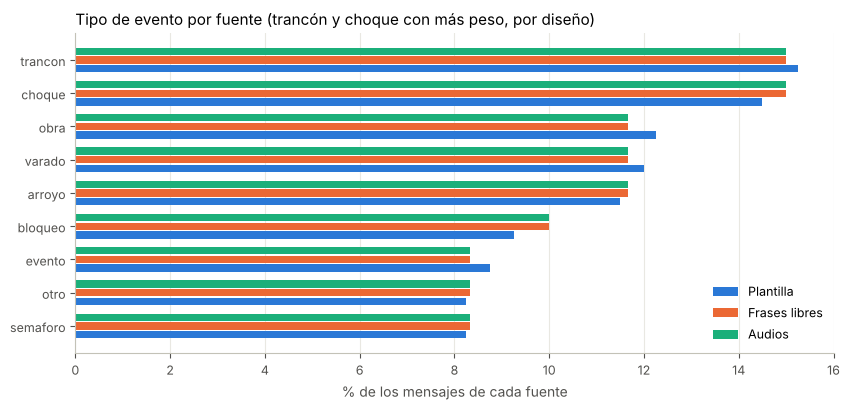

In [3]:
cob = {}
for c in ("tipo_evento", "severidad", "alcance", "modo", "duracion", "sentido", "es_despeje", "ruta"):
    t_ = pd.crosstab(d[c].astype(object).where(d[c].notna(), "(no lo dice)"), d.fuente)[ORDEN]
    cob[c] = t_
    print(f"— {c}"); display(t_)
ev = d[~d.es_despeje]
falta = [(c, f) for c in ("tipo_evento", "alcance", "modo", "duracion", "sentido", "ruta") for f in ORDEN
         if (cob[c][f] == 0).any()]
check("Cobertura: cada fuente tiene todos los tipos, alcances, «aquí»/«adelante», las 4 duraciones, ambos sentidos y las 3 rutas",
      not falta, str(falta) or "sin huecos")
sev = pd.crosstab(ev.severidad.dropna().astype(int), ev.fuente)[ORDEN]
check("Severidad 1–5 presente en las 3 fuentes, con al menos 8 casos por nivel", (sev >= 8).all().all(), sev.min().to_dict())
check("Despejes en las 3 fuentes (≥ 6) y «mi bus» en las 3 fuentes (≥ 3)",
      (cob["es_despeje"].loc[True] >= 6).all() and (cob["alcance"].loc["solo_bus"] >= 3).all())

fig, ax = plt.subplots(figsize=(8.6, 4.2))
tipos = cob["tipo_evento"].div(cob["tipo_evento"].sum()).mul(100).sort_values("Plantilla")
y = np.arange(len(tipos)); h = 0.26
for k, f in enumerate(ORDEN):
    ax.barh(y + (k - 1) * h, tipos[f], height=h - 0.04, color=COL[f], label=f)
ax.set_yticks(y, tipos.index); ax.set_xlabel("% de los mensajes de cada fuente", color=COL["texto2"])
ax.set_title("Tipo de evento por fuente (trancón y choque con más peso, por diseño)", loc="left", fontsize=11)
estilo(ax); ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "cobertura_tipos_10_3.png", dpi=150); plt.show()

### 3 · Qué tan «limpio» viene cada mensaje

In [4]:
pl = [x for x in T if x["fuente"] == "plantilla"]
meta = pd.DataFrame([x["meta"] for x in pl])
print("Plantilla (400):", {k: f"{100 * meta[k].mean():.1f} %" for k in ("sigue_formato", "desordenado", "etiqueta_olvidada", "con_error_tipeo")})
lib = [x for x in T if x["fuente"] == "libre_claude"]
print(f"Frases libres (120): ninguna cuenta como «sigue el formato»; {sum(bool(x['meta'].get('imitaba_guia_1_2')) for x in lib)} imitaban la guía 1.2 y conservan paráfrasis")
rev = pd.read_csv(D / "revision_persona3_frases_libres.csv")
print(f"Revisión de la Persona 3: {len(rev)} frases libres al azar → 30/30 correctas y realistas (28-oct 00:16)")
g = pd.read_csv(D / "guiones_audio_chatgpt.csv", dtype=str, keep_default_na=False)
eva = g[(g.es_despeje == "no") & (g.alcance == "via")]
print(f"Audios (60): {int((g.sigue_formato == 'si').sum())} con etiquetas y {int((g.sigue_formato == 'no').sum())} informales; "
      f"10 + 10 por grupo planeado; omisiones controladas: {int((eva.duracion == '').sum())} sin duración "
      f"({', '.join(eva[eva.duracion == ''].id)}) y {int((eva.sentido == '').sum())} sin sentido ({', '.join(eva[eva.sentido == ''].id)})")
display(pd.crosstab(g.condicion, g.sigue_formato))
ed = pd.read_csv(D / "guiones_ediciones_claude.csv", dtype=str, keep_default_na=False)
print(f"Correcciones de Claude a los guiones de ChatGPT, todas registradas: {len(ed)} filas en guiones_ediciones_claude.csv")
for x in (T[0], T[150], next(x for x in T if x["fuente"] == "libre_claude"), A[11], A[41]):
    print(f"  {x['id']:>5} · {x['texto']}")
p = subprocess.run([sys.executable, "validar_guiones_10_3.py"], capture_output=True, text=True, encoding="utf-8")
print(p.stdout.strip().splitlines()[0])
check("Los 60 guiones de audio pasan validar_guiones_10_3.py (0 problemas)", p.returncode == 0 and "con problemas: 0" in p.stdout,
      p.stdout.strip().splitlines()[0])
check("Formato repartido en el audio: 10 con etiquetas y 10 informales por grupo", (pd.crosstab(g.condicion, g.sigue_formato) == 10).all().all())

Plantilla (400): {'sigue_formato': '76.5 %', 'desordenado': '17.5 %', 'etiqueta_olvidada': '7.5 %', 'con_error_tipeo': '9.2 %'}
Frases libres (120): ninguna cuenta como «sigue el formato»; 55 imitaban la guía 1.2 y conservan paráfrasis
Revisión de la Persona 3: 30 frases libres al azar → 30/30 correctas y realistas (28-oct 00:16)
Audios (60): 30 con etiquetas y 30 informales; 10 + 10 por grupo planeado; omisiones controladas: 4 sin duración (A25, A49, A54, A58) y 4 sin sentido (A04, A08, A16, A40)


sigue_formato,no,si
condicion,,
bus,10,10
calle,10,10
silencio,10,10


Correcciones de Claude a los guiones de ChatGPT, todas registradas: 364 filas en guiones_ediciones_claude.csv
   P001 · reportando: evento: trancón, duración: larga, gravedad: 1, lugar: aquí
   L097 · carnaval aquí, la vía cerrada, los dos sentidos, más de dos horas
   L002 · Buenas, trancón aquí, lento, los dos sentidos
    A12 · Buenas, mire que hay obra aquí, gravedad 5, duración muy larga, en mi sentido.
    A42 · Buenas, ya despejaron la obra aquí.


Guiones: 60 · con problemas: 0 · problemas de reparto: 0


### 4 · Respuesta correcta y segmento real

In [5]:
dif = (d.seg_verdad - d.seg_respuesta).abs(); dif = np.minimum(dif, d.ruta.map(N_SEG) - dif)
d["exacto"] = dif == 0; d["pm1"] = dif <= 1
seg = d.groupby("fuente")[["exacto", "pm1"]].mean().reindex(ORDEN).mul(100).round(1)
seg["n"] = d.groupby("fuente").size().reindex(ORDEN)
tx = d[d.canal == "texto"]
seg.loc["Todo el texto"] = [round(100 * tx.exacto.mean(), 1), round(100 * tx.pm1.mean(), 1), len(tx)]
display(seg.rename(columns={"exacto": "% segmento exacto", "pm1": "% a ±1 segmento"}))
print("Diferencias por modo (texto):", tx[~tx.exacto].modo.value_counts().to_dict())
print(f"Esquina nombrada adelante del bus: mediana {d.adelante_m.median():,.0f} m (de {d.adelante_m.min():,.0f} a {d.adelante_m.max():,.0f} m)")
check("100 % de las respuestas correctas cumplen el contrato del evento 1.2", int(d.errores_contrato.sum()) == 0, f"{len(d)} eventos")
check("Con extracción perfecta, el segmento real queda a ±1 segmento en ≥ 95 % del texto", tx.pm1.mean() >= 0.95,
      f"{100 * tx.pm1.mean():.1f} %")

,% segmento exacto,% a ±1 segmento,n
fuente,,,
Plantilla,95.2,96.8,400.0
Frases libres,95.0,95.8,120.0
Audios,100.0,100.0,60.0
Todo el texto,95.2,96.5,520.0


Diferencias por modo (texto): {'aqui': 14, 'adelante': 11}
Esquina nombrada adelante del bus: mediana 1,518 m (de 310 a 2,990 m)


### 5 · Congelado e independiente

In [6]:
for f, info in man_t["archivos"].items():
    print(f"{f}: {info['items']} ítems · hash {info['sha256'][:12]}… · {'igual' if sha(D / f) == info['sha256'] else 'CAMBIÓ'}")
hist = man_t["historial"]; hist = eval(hist) if isinstance(hist, str) else hist
print(f"Versiones del set de texto: {len(hist) + 1} (guías " + ", ".join(h.get('guia', '?') for h in hist) + f", {man_t['guia']}); "
      f"motivo de la última: «{man_t['motivo_regeneracion']}»")
print(f"Audio: congelado el {man_a['creado']} · lugar real: {man_a['lugar_real']} · hash de audios_items "
      f"{'igual' if sha(D / 'audios_items.jsonl') == man_a['items_sha256'] else 'CAMBIÓ'}")
check("Texto congelado: los hashes del manifiesto coinciden", all(sha(D / f) == i["sha256"] for f, i in man_t["archivos"].items()))
check("Audio congelado: el manifiesto existe, trae el lugar real y el hash de audios_items coincide",
      man_a["congelado"] and bool(man_a.get("lugar_real")) and sha(D / "audios_items.jsonl") == man_a["items_sha256"])
print(f"Viajes de GPS usados: {d.idprogramacion.nunique()} distintos ({d.fecha.min()[:10]} → {d.fecha.max()[:10]}); "
      f"compartidos entre texto y audio: {len(set(tx.idprogramacion) & set(d[d.canal == 'audio'].idprogramacion))}")

textos_desarrollo.jsonl: 157 ítems · hash 484b27bdddbb… · igual
textos_prueba.jsonl: 363 ítems · hash f307e44ab4f4… · igual
Versiones del set de texto: 3 (guías 1.2, 1.3, 1.4); motivo de la última: «Guía 1.4 (28-oct-2026 00:59, Persona 3): la gravedad se dice solo con el número. Sin corridas previas de 10.4/10.5.»
Audio: congelado el 2026-10-28T09:49:49 · lugar real: sala · hash de audios_items igual
Viajes de GPS usados: 457 distintos (2023-01-02 → 2025-12-28); compartidos entre texto y audio: 15


### 6 · Las 60 notas de voz

Lugar real: sala (los grupos «calle» y «bus» se planearon pero no se grabaron allí)
Duración: mediana 7.8 s · de 3.1 a 11.5 s · más de 15 s: 0 · estado: {'ok': 60}
¿Cada archivo es el de su guion? correlación palabras–duración 0.75; corrida un puesto: 0.02 / 0.00
Ritmo: 1.83 palabras/s (de 1.16 a 2.71)
Audios que llegan al tope de volumen (pico ≥ 1,0): 23 de 60
Escucha de la Persona 3: A01, A20, A21, A40, A41, A60 → ['coincide con el guion']


particion,desarrollo,prueba
condicion,,
bus,6,14
calle,6,14
silencio,6,14


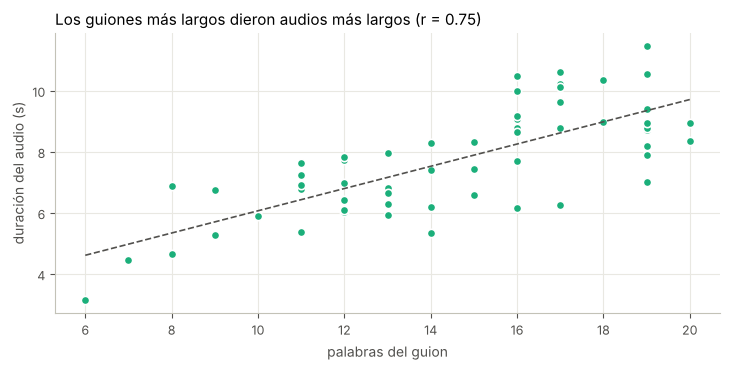

In [7]:
m = mapeo.copy(); m["palabras"] = m.guion.str.split().str.len()
print(f"Lugar real: {man_a['lugar_real']} (los grupos «calle» y «bus» se planearon pero no se grabaron allí)")
print(f"Duración: mediana {m.duracion_s.median():.1f} s · de {m.duracion_s.min():.1f} a {m.duracion_s.max():.1f} s · "
      f"más de 15 s: {(m.duracion_s > 15).sum()} · estado: {m.estado.value_counts().to_dict()}")
r0 = m.palabras.corr(m.duracion_s); rs = [np.corrcoef(m.palabras, np.roll(m.duracion_s, k))[0, 1] for k in (1, -1)]
print(f"¿Cada archivo es el de su guion? correlación palabras–duración {r0:.2f}; corrida un puesto: {rs[0]:.2f} / {rs[1]:.2f}")
print(f"Ritmo: {(m.palabras / m.duracion_s).median():.2f} palabras/s (de {(m.palabras / m.duracion_s).min():.2f} a {(m.palabras / m.duracion_s).max():.2f})")
print(f"Audios que llegan al tope de volumen (pico ≥ 1,0): {(m.pico >= 1.0).sum()} de 60")
esc = pd.read_csv(D / "verificacion_escucha_10_3.csv")
print(f"Escucha de la Persona 3: {', '.join(esc.id)} → {esc.resultado.unique().tolist()}")
display(m.groupby(["condicion", "particion"]).size().unstack())
check("60 notas de voz «ok», ninguna de más de 15 s", (m.estado == "ok").all() and len(m) == 60 and m.duracion_s.max() <= 15)
check("Cada archivo corresponde a su guion (correlación ≥ 0,5 y ≈ 0 al correrlo un puesto) y la escucha de 6 coincide",
      r0 >= 0.5 and max(abs(x) for x in rs) < 0.2 and (esc.resultado == "coincide con el guion").all() and len(esc) == 6)

fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.scatter(m.palabras, m.duracion_s, s=36, color=COL["Audios"], edgecolor="white", linewidth=1.2)
b = np.polyfit(m.palabras, m.duracion_s, 1); xs = np.linspace(m.palabras.min(), m.palabras.max(), 2)
ax.plot(xs, np.polyval(b, xs), color=COL["texto2"], lw=1.2, ls="--")
ax.set_xlabel("palabras del guion", color=COL["texto2"]); ax.set_ylabel("duración del audio (s)", color=COL["texto2"])
ax.set_title(f"Los guiones más largos dieron audios más largos (r = {r0:.2f})", loc="left", fontsize=11)
estilo(ax, grid="both"); fig.tight_layout(); fig.savefig(FIG / "audios_duracion_10_3.png", dpi=150); plt.show()

### 7 · Pruebas

In [8]:
p = subprocess.run([sys.executable, "tests_10_3.py"], capture_output=True, text=True, encoding="utf-8")
print(p.stdout.strip())
check("tests_10_3.py: 8/8 PASS", p.returncode == 0 and "8/8 PASS" in p.stdout, p.stdout.strip().splitlines()[-1])
chk = pd.DataFrame(CHECKS); chk.to_csv("datos_10/checks_10_3.csv", index=False)
display(chk); print(f"{(chk.resultado == 'PASS').sum()}/{len(chk)} PASS")

PASS  a · congelado: los hashes del manifiesto coinciden con los archivos
PASS  b · tamaños y partición: 400 de plantilla + 120 libres; prueba ≈ 70 % en cada fuente; sin ids repetidos
PASS  c · reparto de la plantilla: tipos según el diseño, 40 despejes y severidad pareja 1–5
PASS  d · contratos: cada mensaje cumple el de entrada 1.0 y cada respuesta correcta da un evento válido (1.2)
PASS  e · sin datos personales: ningún teléfono ni placa en los textos; frases libres = las de frases_libres.py
PASS  f · independencia: las ventanas de GPS vienen de viajes distintos de los 300 de la validación 10.1/10.2
PASS  g · guía 1.4 (gravedad con número): los mensajes de plantilla que siguen el formato llevan etiquetas; los despejes dicen el tipo
PASS  h · audio congelado: 60 guiones validados, respuesta correcta válida, partición 3/7 por lugar y formato, manifiesto con lugar real; hash de cada audio si los archivos están en este PC

8/8 PASS


,check,resultado,detalle
0,"Tamaños aprobados: 400 de plantilla, 120 libres y 60 audios (+ 120 copias con ruido)",PASS,
1,Partición ≈ 30/70 en cada fuente (prueba entre 67 % y 73 %),PASS,"{'Plantilla': 70.0, 'Frases libres': 69.2, 'Audios': 70.0}"
2,"Cobertura: cada fuente tiene todos los tipos, alcances, «aquí»/«adelante», las 4 durac...",PASS,[]
3,"Severidad 1–5 presente en las 3 fuentes, con al menos 8 casos por nivel",PASS,"{'Plantilla': 65, 'Frases libres': 18, 'Audios': 8}"
4,Despejes en las 3 fuentes (≥ 6) y «mi bus» en las 3 fuentes (≥ 3),PASS,
5,Los 60 guiones de audio pasan validar_guiones_10_3.py (0 problemas),PASS,Guiones: 60 · con problemas: 0 · problemas de reparto: 0
6,Formato repartido en el audio: 10 con etiquetas y 10 informales por grupo,PASS,
7,100 % de las respuestas correctas cumplen el contrato del evento 1.2,PASS,580 eventos
8,"Con extracción perfecta, el segmento real queda a ±1 segmento en ≥ 95 % del texto",PASS,96.5 %
9,Texto congelado: los hashes del manifiesto coinciden,PASS,


14/14 PASS


## Conclusiones

**Conclusión 1 · Un set de 520 textos y 60 audios, con margen de error declarado**
- **Contenido:**
  - **400 textos de plantilla**, armados con las esquinas reales de cada ruta;
  - **120 frases libres** escritas por Claude;
  - **60 notas de voz** grabadas por la Persona 3 con guiones de ChatGPT;
  - **120 copias de los audios** con ruido de tráfico sintético, a 10 y 5 dB.
- **Partición 30/70.** La parte de prueba tiene 280 textos de plantilla, 83 frases libres y 42 audios (70,0 / 69,2 / 70,0 % de cada fuente).
- **Margen de error al 95 %**, para una métrica cercana a 0,90 medida en la parte de prueba:

  | Fuente | Casos de prueba | Margen |
  |---|---|---|
  | Todo el texto | 363 | ±3,1 pp |
  | Plantilla | 280 | ±3,5 pp |
  | Frases libres | 83 | ±6,5 pp |
  | Audios | 42 | ±9,1 pp (en cada una de sus 3 versiones) |

- **El audio es la métrica menos precisa** y se reportará así.

**Conclusión 2 · Cubre todos los tipos y campos del contrato, en las tres fuentes**
- **Tipos:** los 9 tipos están en plantilla, frases libres y audios. Trancón y choque tienen más peso, por diseño; en la plantilla son 61 y 58 casos.
- **Severidad:** cada nivel de 1 a 5 tiene al menos 8 casos en cada fuente. El mínimo es 65 en la plantilla, 18 en las frases libres y 8 en los audios.
- **«Mi bus» y despejes:**

  | | Plantilla | Frases libres | Audios |
  |---|---|---|---|
  | «Mi bus» | 31 | 7 | 3 |
  | Despejes | 40 | 12 | 6 |

- **Otros campos:** las 4 duraciones, los 2 sentidos, «aquí» y «adelante», y las 3 rutas aparecen en cada fuente. Las rutas están parejas: 134/133/133, 40×3 y 20×3.
- **Qué tan limpio viene cada mensaje:**
  - **Plantilla:** el 76,5 % sigue el formato. El resto tiene variaciones: 17,5 % desordenado y 7,5 % con una etiqueta olvidada; además, el 9,2 % trae un error de tipeo.
  - **Frases libres:** ninguna sigue el formato. 55 imitan la guía 1.2 y conservan paráfrasis como «un carril» o «más de dos horas», como prueba de robustez.
  - **Audios:** 30 con etiquetas y 30 informales, 10 + 10 en cada grupo.
- **Omisiones a propósito en los audios:** 4 guiones sin duración (A25, A49, A54, A58) y 4 sin sentido (A04, A08, A16, A40). Sirven para medir que el extractor no invente esos datos.

**Conclusión 3 · La respuesta correcta es válida y el segmento real tiene un techo**
- **Contrato:** las **580** respuestas correctas cumplen el contrato del evento 1.2, incluidas sus reglas de coherencia.
- **Techo del segmento.** Con una extracción perfecta, el GPS de 5 min y el resolvedor de esquinas ubican el segmento real así:

  | | Segmento exacto | A ±1 segmento |
  |---|---|---|
  | Texto | **95,2 %** | 96,5 % |
  | Audios | 60/60 | 60/60 |

  - Las 25 diferencias del texto vienen 14 de «aquí» (sentido dudoso del GPS) y 11 de «adelante».
  - Es el mismo orden de la 10.1, que tuvo 94,7 % exacto.
  - **Es el techo de la métrica de punta a punta de la 10.5**, que no se le podrá exigir al extractor.
- **Corrección:** `CLAUDE.md` decía 98,1 % para el texto. Esa cifra era de la primera versión del set. Con el set congelado vigente (guía 1.4) es 95,2 %.
- **Distancia a la esquina:** la esquina nombrada queda entre 310 y 2.990 m adelante del bus, con mediana de 1.518 m.

**Conclusión 4 · Congelado antes de medir, con cambios registrados**
- **Texto:** hubo 3 versiones (guías 1.2, 1.3 y 1.4), todas generadas **antes de cualquier corrida de la 10.4 o la 10.5**. El motivo de cada una quedó en el manifiesto, y los hashes coinciden.
- **Audio:** se congeló el 28-oct-2026 a las 09:49, con el lugar real de grabación registrado («sala»). El hash de `audios_items.jsonl` coincide.
- **GPS:**
  - **457 viajes** distintos, de enero de 2023 a diciembre de 2025;
  - ninguno está entre los 300 de la validación 10.1/10.2;
  - 15 viajes se repiten entre el texto y el audio, pero con mensajes distintos.
- **Guiones de ChatGPT:** Claude los corrigió en varias rondas (gramática, guía 1.4, datos completos, orden de grabación). Las 364 ediciones quedaron registradas en `guiones_ediciones_claude.csv`, y la versión anterior está en `set_prueba/historial/`.
- **Verificación de los audios:** los guiones más largos dieron audios más largos (r = 0,75). Con los archivos corridos un puesto, la correlación cae a 0,00–0,02, así que no hay audios cruzados. La Persona 3 escuchó 6 audios y los 6 coinciden con su guion.
- **Pruebas:** tests 8/8 y checks del notebook 14/14.

**Conclusión 5 · Limitaciones y qué sigue en la 10.4**
- **Limitaciones que se declaran:**
  - **Un solo hablante.** La métrica de audio mide a Whisper con una voz, no con la variedad de los conductores.
  - **Grabados en una sala.** No hay ruido real de calle ni de bus. El efecto del ruido se mide solo con las copias sintéticas (SNR 10 y 5 dB), y el grupo planeado (silencio, calle o bus) no se usa como factor de ruido.
  - **Volumen al tope.** 23 de los 60 audios llegan al máximo de volumen. Hay que revisar en la 10.4 si el recorte afecta la transcripción.
  - **Riesgo de un F1 optimista.** Los textos los escribió Claude y los interpretará Claude. El F1 se reportará por fuente (plantilla, frases libres, audios), y los guiones de audio son de otro modelo.
  - **Claude vio unos 25 ítems de prueba** al revisar el set. En la 10.5 se trabaja solo con desarrollo.
- **10.4 (requiere un alcance aprobado):**
  - transcribir con Whisper local los 60 audios y sus 120 copias con ruido;
  - medir el error de palabras (WER) y el acierto en los campos clave: número de gravedad, palabra de duración, esquina;
  - ajustar solo con los 18 audios de desarrollo y evaluar la prueba una sola vez.

<a id="m10-4"></a>

### A2.2.4 &middot; Subfase 10.4 · Audio a texto con Whisper local

<sub>Notebook original: `modulo10/subfase_10_4_audio.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 10 · Subfase 10.4 — Audio → texto con Whisper local

**Persona 3.** Las notas de voz de los conductores se convierten en texto **en el PC**, sin enviar el audio a ningún
servicio, con Whisper `turbo` (large-v3-turbo) a través de faster-whisper (licencia MIT). El texto sale tal cual hacia la
10.5, donde Claude extrae el evento. Alcance aprobado: `revisiones/alcance_10_4.md`.

| Paso | Qué se hizo | Dónde |
|---|---|---|
| Entorno | RTX 3050 (CUDA 12, float16); el modelo se descargó una vez de Hugging Face | PC de la Persona 3 |
| Desarrollo | 18 audios × 3 versiones (limpio, ruido a 10 dB y a 5 dB) × 2 configuraciones (sin y con texto de ayuda) = 108 transcripciones | `transcripciones_desarrollo.jsonl` |
| Congelar | Se eligió la configuración con más acierto en los campos clave y se guardó con hash **antes** de tocar la prueba | `config_10_4.json` |
| Prueba | 42 audios × 3 versiones = 126 transcripciones, **una sola vez** | `transcripciones_prueba.jsonl` |

**Cómo se mide.**
- **Campos clave:** los 7 datos que necesita la 10.5: tipo, lugar, gravedad, duración, sentido, «despejado» y «mi bus». Cada uno está bien si lo que dice el guion aparece igual en la transcripción, y si el guion no lo dice, la transcripción tampoco.
- **WER:** el porcentaje de palabras distintas entre el guion y la transcripción, después de normalizar (minúsculas, sin tildes, «tres» → 3).
- **Tiempo por audio:** se mide en el PC e incluye decodificar el audio.

Costo: $0. Los audios no salieron del PC.

## Parte 2 · Análisis offline

In [1]:
import hashlib
import json
import subprocess
import sys
from math import sqrt
from pathlib import Path
from typing import Dict, List
import difflib
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "src")
from m10.normalizar import campos, normalizar, wer

pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120)
S = Path("datos_10/transcripcion"); D = Path("datos_10/set_prueba"); FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})
CAMPOS = ["tipo", "lugar", "gravedad", "duracion", "sentido", "despejado", "mi_bus"]
VERS = ["limpio", "snr10", "snr5"]
cfg = json.loads((S / "config_10_4.json").read_text(encoding="utf-8"))
items = {json.loads(l)["id"]: json.loads(l) for l in open(D / "audios_items.jsonl", encoding="utf-8")}
TD = [json.loads(l) for l in open(S / "transcripciones_desarrollo.jsonl", encoding="utf-8")]
TP = [json.loads(l) for l in open(S / "transcripciones_prueba.jsonl", encoding="utf-8")]
mdv = pd.read_csv(S / "metricas_desarrollo_detalle_10_4.csv"); mpr = pd.read_csv(S / "metricas_prueba_detalle_10_4.csv")
def resumen(m, por):
    g = m.groupby(por)
    r = pd.DataFrame({"n": g.size(), "WER %": 100 * g.errores.sum() / g.palabras.sum(),
                      "campos clave %": 100 * g[[f"ok_{k}" for k in CAMPOS]].mean().mean(axis=1),
                      "audios perfectos %": 100 * g.todos_ok.mean(), "s mediana": g.segundos.median(), "s P95": g.segundos.quantile(.95)})
    return r.round(2)
def wilson(k, n, z=1.96):
    p = k / n; c = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return 100 * (c - h), 100 * (c + h)
COL = {"sin_vocabulario": "#c3c2b7", "con_vocabulario": "#2a78d6", "prueba": "#1baf7a", "texto2": "#52514e", "grid": "#e9e8e2"}
print(f"Whisper {cfg['modelo']} · faster-whisper {cfg['faster_whisper']} · {cfg['dispositivo']}/{cfg['compute_type']} · "
      f"beam {cfg['beam_size']} · configuración congelada: {cfg['config']} ({cfg['creado']})")

Whisper turbo · faster-whisper 1.2.1 · cuda/float16 · beam 5 · configuración congelada: con_vocabulario (2026-10-28T10:46:46)


### 1 · Configuración congelada antes de la prueba

In [2]:
h = hashlib.sha256(json.dumps({k: v for k, v in cfg.items() if k not in ("creado", "hash_config")}, sort_keys=True,
                              ensure_ascii=False).encode()).hexdigest()
print("Texto de ayuda congelado:\n ", cfg["texto_inicial"])
print(f"hash {cfg['hash_config'][:16]}… → {'coincide' if h == cfg['hash_config'] else 'NO COINCIDE'}")
check("Configuración congelada: el hash coincide y apunta a las métricas de desarrollo usadas para elegir",
      h == cfg["hash_config"] and hashlib.sha256((S / "metricas_desarrollo_10_4.csv").read_bytes()).hexdigest() == cfg["metricas_desarrollo_sha256"])
check("Prueba: 126 transcripciones (42 audios × 3 versiones), todas con la configuración congelada",
      len(TP) == 126 and {t["config"] for t in TP} == {cfg["config"]} and len({t["id"] for t in TP}) == 42)
check("Desarrollo: 108 transcripciones (18 × 3 × 2 configuraciones); ningún audio de prueba",
      len(TD) == 108 and all(items[t["id"]]["particion"] == "desarrollo" for t in TD))

Texto de ayuda congelado:
  Reporte de conductor de bus en Barranquilla. Evento: trancón, choque, varado, obra, arroyo, bloqueo, evento, semáforo, otro. Afecta: mi bus. Lugar: aquí, adelante en la calle con la carrera. Gravedad: 1, 2, 3, 4, 5. Duración: corta, media, larga, muy larga. Sentido: mi sentido, los dos. Despejado. Murillo, Circunvalar, Cordialidad, Autopista Aeropuerto.
hash f2eb35e59573f795… → coincide


### 2 · Desarrollo: ¿con o sin texto de ayuda?

In [3]:
rd = resumen(mdv, ["config", "version"]); display(rd)
tot = resumen(mdv, ["config"]); display(tot)
print("Errores en desarrollo (campo que falla · guion → transcripción):")
for t in TD:
    mal = [k for k, v in campos(items[t["id"]], t["texto"]).items() if not v]
    if mal and t["version"] == "limpio":
        print(f"  {t['config']:16} {t['id']} {mal}: «{items[t['id']]['texto']}» → «{t['texto']}»")
elegida = tot.sort_values(["campos clave %", "WER %"], ascending=[False, True]).index[0]
check("La configuración congelada es la que más acierta los campos clave en desarrollo (regla del alcance)",
      elegida == cfg["config"], f"{elegida}: {tot.loc[elegida, 'campos clave %']:.2f} %")

n  WER %  campos clave %  audios perfectos %  s mediana  s P95
config          version                                                                 
con_vocabulario limpio   18   1.19           99.21               94.44       0.71   0.80
                snr10    18   1.19           99.21               94.44       0.68   0.79
                snr5     18   1.19           99.21               94.44       0.69   0.78
sin_vocabulario limpio   18   2.78           96.03               72.22       0.61   0.68
                snr10    18   3.97           95.24               66.67       0.61   0.67
                snr5     18   3.97           95.24               72.22       0.62   0.69

,n,WER %,campos clave %,audios perfectos %,s mediana,s P95
config,,,,,,
con_vocabulario,54,1.19,99.21,94.44,0.69,0.79
sin_vocabulario,54,3.57,95.50,70.37,0.61,0.69


Errores en desarrollo (campo que falla · guion → transcripción):
  sin_vocabulario  A26 ['tipo']: «Evento: obra, lugar: aquí, gravedad: 3, duración: muy larga, sentido: mi sentido.» → «Evento, hora, lugar, aquí, gravedad, tres, duración, muy larga, sentido, mi sentido.»
  sin_vocabulario  A27 ['lugar']: «Evento: bloqueo, lugar: adelante en Circunvalar con Autopista Aeropuerto, gravedad: 2, duración: larga, sentido: los dos.» → «Evento, bloqueo, lugar, adelante en la circunvalar con autopista de aeropuerto, gravedad 2, duración larga, sentido los dos.»
  sin_vocabulario  A40 ['tipo']: «Pilas, hay arroyo adelante en la 76 con la 38, gravedad 3, duración media.» → «Pilas, hay arrobio adelante en la 76 con la 38, gravedad 3, duración media.»
  sin_vocabulario  A54 ['tipo']: «Ojo que hay bloqueo adelante en la 19 con la 22, gravedad 1, en los dos sentidos.» → «Ojo, que hay bloque adelante en la 19 con la 22, gravedad 1 en los dos sentidos.»
  sin_vocabulario  A58 ['tipo']: «Ojo que hay un b

### 3 · Prueba: evaluación única

,n,WER %,campos clave %,audios perfectos %,s mediana,s P95
version,,,,,,
limpio,42,3.66,100.00,100.00,0.69,0.80
snr10,42,4.14,99.32,95.24,0.68,0.78
snr5,42,4.30,99.32,95.24,0.68,0.82


n  WER %  campos clave %  audios perfectos %  s mediana  s P95
version formato                                                                   
limpio  etiquetas  21   3.75          100.00              100.00       0.70   0.77
        informal   21   3.58          100.00              100.00       0.69   0.80
snr10   etiquetas  21   4.44           99.32               95.24       0.68   0.78
        informal   21   3.88           99.32               95.24       0.66   0.76
snr5    etiquetas  21   4.44           99.32               95.24       0.69   0.80
        informal   21   4.18           99.32               95.24       0.67   0.82

,tipo,lugar,gravedad,duracion,sentido,despejado,mi_bus
version,,,,,,,
limpio,100.00,100.00,100.0,100.0,100.0,100.0,100.0
snr10,97.62,97.62,100.0,100.0,100.0,100.0,100.0
snr5,95.24,100.00,100.0,100.0,100.0,100.0,100.0


limpio: audios con los 7 campos bien 42/42 → IC95 % de Wilson [91.6 %; 100.0 %]
snr10: audios con los 7 campos bien 40/42 → IC95 % de Wilson [84.2 %; 98.7 %]
snr5: audios con los 7 campos bien 40/42 → IC95 % de Wilson [84.2 %; 98.7 %]

Los errores de campo en la prueba:
  A09 snr10  ['tipo']: «Le reporto que mi bus se varó aquí, está orillado, no afecta la vía, duración corta.» → «Les reporto que mi bus se barba aquí. Está orillado, no afecta la vía, duración corta.»
  A09 snr5   ['tipo']: «Le reporto que mi bus se varó aquí, está orillado, no afecta la vía, duración corta.» → «Les reporto que mi bus se barba aquí. Está orillado, no afecta la vía, duración corta.»
  A25 snr10  ['lugar']: «Evento: semáforo, lugar: adelante en la 87 con la 46, gravedad: 2, sentido: los dos.» → «Evento, semáforo, lugar, adelante en la 57 con la 46. Gravedad, 2. Sentido, los dos.»
  A29 snr5   ['tipo']: «Evento: trancón, lugar: adelante en la 94 con la 53, gravedad: 1, duración: media, sentido: los dos.» →

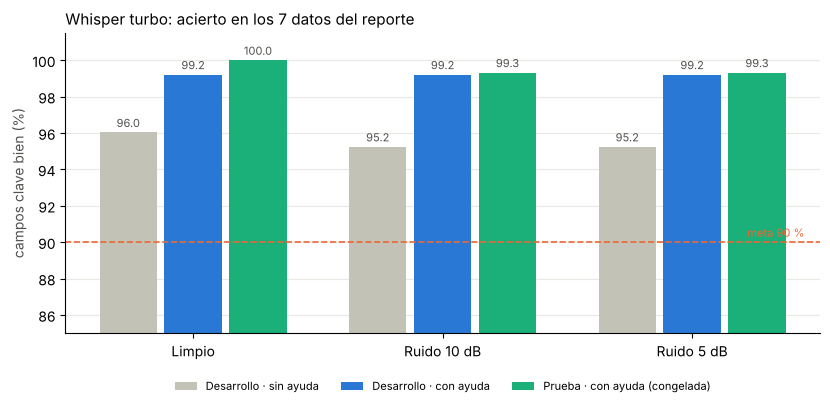

In [4]:
rp = resumen(mpr, ["version"]).reindex(VERS); display(rp)
display(resumen(mpr, ["version", "formato"]))
por_campo = (100 * mpr.groupby("version")[[f"ok_{k}" for k in CAMPOS]].mean()).reindex(VERS).round(2)
por_campo.columns = CAMPOS; display(por_campo)
for v in VERS:
    k = int(mpr[mpr.version == v].todos_ok.sum()); lo, hi = wilson(k, 42)
    print(f"{v}: audios con los 7 campos bien {k}/42 → IC95 % de Wilson [{lo:.1f} %; {hi:.1f} %]")
print("\nLos errores de campo en la prueba:")
for t in TP:
    mal = [k for k, v in campos(items[t["id"]], t["texto"]).items() if not v]
    if mal:
        print(f"  {t['id']} {t['version']:6} {mal}: «{items[t['id']]['texto']}» → «{t['texto']}»")
check("Meta aprobada: campos clave ≥ 90 % en limpio, SNR 10 y SNR 5 (prueba)", (rp["campos clave %"] >= 90).all(),
      rp["campos clave %"].to_dict())
rec = pd.DataFrame([{"id": t["id"], "version": t["version"], "e": wer(items[t["id"]]["texto"], t["texto"])[0]} for t in TP])
check("Las métricas de la prueba se reproducen desde el texto con normalizar.py", (rec.merge(mpr, on=["id", "version"]).eval("e == errores")).all())

fig, ax = plt.subplots(figsize=(8.4, 4.2))
x = np.arange(3); w = 0.26
series = [("Desarrollo · sin ayuda", resumen(mdv[mdv.config == "sin_vocabulario"], ["version"]).reindex(VERS)["campos clave %"], COL["sin_vocabulario"]),
          ("Desarrollo · con ayuda", resumen(mdv[mdv.config == "con_vocabulario"], ["version"]).reindex(VERS)["campos clave %"], COL["con_vocabulario"]),
          ("Prueba · con ayuda (congelada)", rp["campos clave %"], COL["prueba"])]
for k, (nom, val, col) in enumerate(series):
    b = ax.bar(x + (k - 1) * w, val, width=w - 0.03, color=col, label=nom)
    ax.bar_label(b, fmt="%.1f", fontsize=8, color=COL["texto2"], padding=2)
ax.axhline(90, color="#eb6834", lw=1.2, ls="--"); ax.text(2.45, 90.3, "meta 90 %", color="#eb6834", fontsize=8, ha="right")
ax.set_xticks(x, ["Limpio", "Ruido 10 dB", "Ruido 5 dB"]); ax.set_ylim(85, 101.5); ax.set_ylabel("campos clave bien (%)", color=COL["texto2"])
ax.set_title("Whisper turbo: acierto en los 7 datos del reporte", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color=COL["grid"]); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
fig.tight_layout(); fig.savefig(FIG / "acierto_campos_10_4.png", dpi=150); plt.show()

### 4 · Qué mide el WER aquí

In [5]:
c = Counter()
for t in TP:
    if t["version"] != "limpio":
        continue
    r, h_ = normalizar(items[t["id"]]["texto"]), normalizar(t["texto"])
    for op, a1, a2, b1, b2 in difflib.SequenceMatcher(None, r, h_).get_opcodes():
        if op != "equal":
            c[(" ".join(r[a1:a2]) or "∅", " ".join(h_[b1:b2]) or "∅")] += 1
lim = mpr[mpr.version == "limpio"]
print(f"Audio limpio: {int(lim.errores.sum())} palabras distintas de {int(lim.palabras.sum())} "
      f"({100 * lim.errores.sum() / lim.palabras.sum():.2f} %), en {int((lim.errores > 0).sum())} de 42 audios.")
print("Diferencias más frecuentes (guion → transcripción):")
for (a, b), n in c.most_common(10):
    print(f"  {n} × «{a}» → «{b}»")

Audio limpio: 23 palabras distintas de 628 (3.66 %), en 15 de 42 audios.
Diferencias más frecuentes (guion → transcripción):
  3 × «con la» → «∅»
  3 × «le» → «les»
  2 × «la» → «∅»
  2 × «sentido» → «∅»
  2 × «∅» → «sentidos»
  2 × «∅» → «la»
  1 × «en» → «∅»
  1 × «hay» → «haya»
  1 × «∅» → «aqui»
  1 × «evento» → «∅»


### 5 · Volumen al tope (hallazgo H15 de la 10.3)

In [6]:
mp = pd.read_csv(D / "mapeo_audios.csv", encoding="utf-8-sig")[["id", "pico"]]
x_ = mpr.merge(mp, on="id"); x_["tope"] = np.where(x_.pico >= 1.0, "al tope (pico ≥ 1)", "normal")
vt = resumen(x_, ["version", "tope"]); display(vt)
dif_tope = (vt.xs("al tope (pico ≥ 1)", level="tope")["WER %"] - vt.xs("normal", level="tope")["WER %"])
print("Diferencia de WER (al tope − normal), puntos:", dif_tope.round(2).to_dict())
check("El volumen al tope no baja el acierto de campos en el audio limpio (H15)",
      vt.loc[("limpio", "al tope (pico ≥ 1)"), "campos clave %"] >= vt.loc[("limpio", "normal"), "campos clave %"] - 1e-9)

n  WER %  campos clave %  audios perfectos %  s mediana  s P95
version tope                                                                               
limpio  al tope (pico ≥ 1)  20   4.06          100.00              100.00       0.69   0.80
        normal              22   3.25          100.00              100.00       0.69   0.77
snr10   al tope (pico ≥ 1)  20   4.69           99.29               95.00       0.68   0.76
        normal              22   3.57           99.35               95.45       0.67   0.78
snr5    al tope (pico ≥ 1)  20   4.69           99.29               95.00       0.68   0.80
        normal              22   3.90           99.35               95.45       0.68   0.82

Diferencia de WER (al tope − normal), puntos: {'limpio': 0.81, 'snr10': 1.12, 'snr5': 0.79}


### 6 · Ruido simulado y tiempo

In [7]:
print(f"Campos clave: limpio {rp.loc['limpio', 'campos clave %']:.2f} % → 10 dB {rp.loc['snr10', 'campos clave %']:.2f} % → "
      f"5 dB {rp.loc['snr5', 'campos clave %']:.2f} %; WER {rp.loc['limpio', 'WER %']:.2f} → {rp.loc['snr5', 'WER %']:.2f} %")
mpr["rtf"] = mpr.segundos / mpr.duracion_audio_s
print(f"Tiempo por audio (GPU, incluye decodificar): mediana {mpr.segundos.median():.2f} s · P95 {mpr.segundos.quantile(.95):.2f} s · "
      f"máximo {mpr.segundos.max():.2f} s · {mpr.segundos.median() / mpr.duracion_audio_s.median():.2f} s por segundo de audio "
      f"(≈ {1 / mpr.rtf.median():.0f} veces más rápido que el audio)")
print(f"Duración de los audios: mediana {mpr.duracion_audio_s.median():.1f} s")
check("Tiempo de transcripción por audio < 2,5 s en el P95 (GPU)", mpr.segundos.quantile(.95) < 2.5, f"{mpr.segundos.quantile(.95):.2f} s")

Campos clave: limpio 100.00 % → 10 dB 99.32 % → 5 dB 99.32 %; WER 3.66 → 4.30 %
Tiempo por audio (GPU, incluye decodificar): mediana 0.69 s · P95 0.80 s · máximo 0.95 s · 0.09 s por segundo de audio (≈ 11 veces más rápido que el audio)
Duración de los audios: mediana 8.0 s


### 7 · Pruebas

In [8]:
p = subprocess.run([sys.executable, "tests_10_4.py"], capture_output=True, text=True, encoding="utf-8")
print(p.stdout.strip())
check("tests_10_4.py: 7/7 PASS", p.returncode == 0 and "7/7 PASS" in p.stdout, p.stdout.strip().splitlines()[-1])
chk = pd.DataFrame(CHECKS); chk.to_csv("datos_10/checks_10_4.csv", index=False)
display(chk); print(f"{(chk.resultado == 'PASS').sum()}/{len(chk)} PASS")

PASS  a · números en letras → cifras («setenta y dos» → 72, «cincuenta y uno be» → 51b); «un bus» no cambia
PASS  b · WER: 0 con el mismo texto (aunque cambien tildes, mayúsculas, puntuación y números); cuenta bien sustituciones e inserciones
PASS  c · con la transcripción perfecta (el guion mismo) los 60 audios aciertan los 7 campos
PASS  d · un error en un campo se detecta solo en ese campo (gravedad, duración, sentido, lugar, tipo)
PASS  e · campos que el guion no dice: si la transcripción inventa duración o sentido, se cuenta como error
PASS  f · el texto inicial de Whisper no trae esquinas ni números de los guiones (solo la guía y las avenidas)
PASS  g · evaluación única: configuración congelada (hash), prueba transcrita una vez y métricas reproducibles desde el texto

7/7 PASS


,check,resultado,detalle
0,Configuración congelada: el hash coincide y apunta a las métricas de desarrollo usadas para elegir,PASS,
1,"Prueba: 126 transcripciones (42 audios × 3 versiones), todas con la configuración congelada",PASS,
2,Desarrollo: 108 transcripciones (18 × 3 × 2 configuraciones); ningún audio de prueba,PASS,
3,La configuración congelada es la que más acierta los campos clave en desarrollo (regla del alcance),PASS,con_vocabulario: 99.21 %
4,"Meta aprobada: campos clave ≥ 90 % en limpio, SNR 10 y SNR 5 (prueba)",PASS,"{'limpio': 100.0, 'snr10': 99.32, 'snr5': 99.32}"
5,Las métricas de la prueba se reproducen desde el texto con normalizar.py,PASS,
6,El volumen al tope no baja el acierto de campos en el audio limpio (H15),PASS,
7,"Tiempo de transcripción por audio < 2,5 s en el P95 (GPU)",PASS,0.80 s
8,tests_10_4.py: 7/7 PASS,PASS,7/7 PASS


9/9 PASS


## Conclusiones

**Conclusión 1 · Whisper local cumple la meta en las tres versiones del audio**
- **Prueba (evaluación única, 42 audios):** los 7 datos clave salieron bien en el **100 %** del audio limpio y en el **99,32 %** con ruido a 10 dB y a 5 dB. La meta aprobada era ≥ 90 % en las tres.
  - Audio limpio: los 42 audios quedaron con los 7 datos bien (IC95 % de Wilson [91,6 %; 100 %]).
  - Con ruido: 40/42 (IC95 % [84,2 %; 98,7 %]).
- **Por dato:** gravedad, duración, sentido, «despejado» y «mi bus» salieron bien en el 100 % de las 126 transcripciones. Los únicos errores fueron en el tipo y el lugar.
- **Por formato:** con etiquetas y en lenguaje informal el resultado es el mismo (100 % limpio; 99,32 % con ruido). La guía no es indispensable para que Whisper entienda el mensaje.

**Conclusión 2 · El texto de ayuda con la guía es lo que más aporta**
- **En desarrollo** (18 audios × 3 versiones), darle a Whisper un texto inicial con el vocabulario de la guía y las avenidas mejoró:

  | | Sin ayuda | Con ayuda |
  |---|---|---|
  | Datos clave bien | 95,50 % | **99,21 %** |
  | WER | 3,57 % | 1,19 % |
  | Audios perfectos | 70,37 % | 94,44 % |

- **Qué corrige:** sin ayuda, Whisper escribía «arrobio», «bloque», «parado» y «autopista de aeropuerto». Con ayuda, lo único que quedó mal fue A26: «Evento: obra» → «Evento, hora», en las 3 versiones.
- **Sin pistas de la prueba:** el texto de ayuda no lleva esquinas ni números de los guiones, solo la guía y las avenidas que un sistema real ya conoce (prueba f).
- **Congelada antes de la prueba:** se congeló esta configuración (hash `f2eb35e5…`) antes de transcribir la prueba, según la regla del alcance.

**Conclusión 3 · Los pocos errores son de palabras sueltas; el WER mide también la lectura**
- **Los 4 errores de dato en la prueba** son todos con ruido:
  - A09: «se varó» → «se barba», en 10 y 5 dB;
  - A25: «la 87» → «la 57», en 10 dB;
  - A29: «Evento: trancón» → «Rancón», en 5 dB.
- **El WER del audio limpio (3,66 %)** son 23 palabras distintas de 628, en 15 de los 42 audios. La mayoría son diferencias de lectura frente al guion, no errores de Whisper:
  - «con la» que no se dijo (3);
  - «le» → «les» (3);
  - «sentido: los dos» leído como «los dos sentidos».

  Por eso el WER es una cota pesimista.
- **Volumen al tope (H15 de la 10.3):** en los 20 audios de prueba con el volumen al tope, el WER es entre 0,8 y 1,1 puntos mayor que en los demás, pero el acierto de los datos es el mismo (100 % en limpio). No afecta lo que necesita la 10.5. **H15 se cierra.**

**Conclusión 4 · Rápido y privado: 0,7 s por audio en la GPU, sin salir del PC**
- **Tiempo por audio en la RTX 3050**, incluida la decodificación: mediana **0,69 s**, P95 0,80 s y máximo 0,95 s. Los audios duran unos 8 s, así que Whisper transcribe ~11 veces más rápido que el habla, y la transcripción gasta solo una parte pequeña de los 2,5 s del plan.
- **Equipo:** con la CPU tomaría varios segundos. La GPU necesitó instalar las librerías de CUDA 12 (`nvidia-cublas-cu12`, `nvidia-cudnn-cu12`).
- **Privacidad y costo:** el audio nunca salió del PC: el modelo se descargó una vez y Whisper corre sin internet. Costo: $0.
- **Corrección técnica:** faster-whisper 1.2.1 no funciona con la PyAV instalada (versión 19). El audio se decodifica con una función propia (`leer_audio`).

**Conclusión 5 · Alcance de la validación y qué sigue en la 10.5**
- **Ruido simulado más suave que el real:** el ruido a 5 dB bajó el acierto solo de 100 % a 99,32 %. Es buena señal para Whisper, pero también muestra que este ruido es más fácil que el de un bus real (los audios se grabaron en una sala).
- **Una sola voz, con 42 audios de prueba:** el margen es amplio; el IC95 % del audio limpio empieza en 91,6 %.
- **Siguiente paso natural:** probar con notas de voz reales de conductores, dentro del bus.
- **Para la 10.5:**
  - recibe el texto tal cual sale de Whisper (decisión c);
  - el extractor debe tolerar errores sueltos como «hora» por «obra», «barba» por «varó» o «Rancón» por «trancón»; se probará con los audios de desarrollo;
  - el F1 del plan se medirá sobre el texto transcrito (audio) y sobre el escrito (texto), por separado.

<a id="m10-5"></a>

### A2.2.5 &middot; Subfase 10.5 · Texto a evento con la API de Claude

<sub>Notebook original: `modulo10/subfase_10_5_extraccion.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 10 · Subfase 10.5 — Texto → evento con la API de Claude

**Persona 3.** Cada mensaje del conductor (texto escrito o la transcripción de su nota de voz, 10.4) pasa por Claude con
**Structured Outputs**: la respuesta es un JSON que cumple un esquema Pydantic estricto. Con esa extracción y el GPS del
bus, `construir_evento` (10.2) arma el evento 1.2 con su segmento. Alcance aprobado: `revisiones/alcance_10_5.md`.

| Paso | Qué se hizo | Dónde |
|---|---|---|
| Modelo | `claude-haiku-5-5` con Structured Outputs (`output_config.format`) y caché del prompt | `src/m10/extractor.py` |
| Desarrollo | 157 textos + 54 transcripciones (18 audios × 3 versiones), prompt v1, esfuerzo **low** | `respuestas_desarrollo_v1_low.jsonl` |
| Congelar | Modelo, esfuerzo, prompt y esquema con hash, **antes** de tocar la prueba | `config_10_5.json` |
| Prueba | 363 textos + 126 transcripciones, **una sola vez** | `respuestas_prueba.jsonl` |

**Cómo se mide** (definido en la 10.3 y el alcance):
- **F1 macro por campo** (tipo, alcance, gravedad, duración, sentido, despejado y lugar), con «no lo dijo» como una clase más.
  En el lugar, «adelante» solo cuenta si las dos vías coinciden con las del guion. La métrica del plan es el promedio de los 7.
- **Mensajes perfectos:** los 7 campos bien.
- **Punta a punta:** el segmento del evento construido frente a la verdad del set, comparado con el techo de la 10.3
  (el segmento que sale con una extracción perfecta).
- **Latencia:** el tiempo de cada llamada nueva a la API, medido en el PC (red incluida); no cuenta las respuestas que salen de la caché en disco.

A la API solo fue texto: el audio no salió del PC.

## Parte 2 · Análisis offline

In [1]:
import hashlib
import json
import re
import subprocess
import sys
from math import sqrt
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "src")
from m10.metricas_extraccion import CAMPOS, campos_errados, etiqueta, evaluar
from m10.esquema_extraccion import hash_esquema, validar
from m10.extractor import cargar_prompt
import punta_a_punta_10_5 as PP

pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)
S = Path("datos_10/extraccion"); D = Path("datos_10/set_prueba"); FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
def wilson(k, n, z=1.96):
    p = k / n; c = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return 100 * (c - h), 100 * (c + h)
cfg = json.loads((S / "config_10_5.json").read_text(encoding="utf-8"))
RP = pd.DataFrame([json.loads(l) for l in open(S / "respuestas_prueba.jsonl", encoding="utf-8")])
RD = pd.DataFrame([json.loads(l) for l in open(S / "respuestas_desarrollo_v1_low.jsonl", encoding="utf-8")])
uso = pd.read_csv("datos_10/uso_api.csv")
GRUPOS = {"TEXTO (meta)": lambda d: d.canal == "texto", "AUDIO (meta)": lambda d: d.canal == "audio",
          "texto · plantilla": lambda d: d.fuente == "plantilla", "texto · frases libres": lambda d: d.fuente == "libre_claude",
          "audio · limpio": lambda d: d.version == "limpio", "audio · ruido 10 dB": lambda d: d.version == "snr10",
          "audio · ruido 5 dB": lambda d: d.version == "snr5"}
def tabla(R):
    filas = []
    for g, f in GRUPOS.items():
        sub = R[f(R)]
        ev = evaluar([{"esperado": e, "extraccion": x} for e, x in zip(sub.esperado, sub.extraccion)])
        filas.append({"grupo": g, "n": ev["n"], "F1": ev["f1_promedio"], "perfectos %": 100 * ev["perfectos"], **{c: ev[f"f1_{c}"] for c in CAMPOS}})
    return pd.DataFrame(filas).set_index("grupo")
COL = {"texto": "#2a78d6", "audio": "#1baf7a", "pensó": "#eb6834", "texto2": "#52514e", "grid": "#e9e8e2", "meta": "#c0392b"}
print(f"Modelo {cfg['modelo']} · esfuerzo {cfg['esfuerzo']} · prompt {cfg['version_prompt']} · congelado {cfg['creado']} · "
      f"hash {cfg['hash_config'][:12]}…")

Modelo claude-haiku-5-5 · esfuerzo low · prompt v1 · congelado 2026-10-28T11:18:45 · hash d550de7053c0…


### 1 · Configuración congelada y elección del esfuerzo

In [2]:
h = hashlib.sha256(json.dumps({k: v for k, v in cfg.items() if k not in ("creado", "hash_config")}, sort_keys=True,
                              ensure_ascii=False).encode()).hexdigest()
hp = hashlib.sha256(cargar_prompt(cfg["version_prompt"]).encode("utf-8")).hexdigest()
print(f"hash de la configuración → {'coincide' if h == cfg['hash_config'] else 'NO COINCIDE'} · prompt → "
      f"{'coincide' if hp == cfg['hash_prompt'] else 'NO COINCIDE'} · esquema → {'coincide' if hash_esquema() == cfg['hash_esquema'] else 'NO COINCIDE'}")
print("Desarrollo (prompt v1, esfuerzo low):")
td = tabla(RD); display(td.round(4))
for _, r in RD[RD.campos_errados.str.len() > 0].iterrows():
    print(f"  {r.uid}: {r.campos_errados} · «{r.texto}»")
check("Configuración congelada: los hashes de la configuración, el prompt y el esquema coinciden, y apunta a las métricas de desarrollo",
      h == cfg["hash_config"] and hp == cfg["hash_prompt"] and hash_esquema() == cfg["hash_esquema"]
      and sha(S / "metricas_desarrollo_v1_low.csv") == cfg["metricas_desarrollo_sha256"])
check("La configuración se congeló antes de la primera llamada de la prueba",
      pd.Timestamp(cfg["creado"]) < pd.to_datetime(uso[uso.corrida == "prueba"].fecha).min(), cfg["creado"])
check("Desarrollo: el esfuerzo low ya cumple la meta en texto y audio (decisión a ajustada: no se corren medium ni high)",
      td.loc["TEXTO (meta)", "F1"] >= 0.9 and td.loc["AUDIO (meta)", "F1"] >= 0.9,
      f"texto {td.loc['TEXTO (meta)', 'F1']:.4f} · audio {td.loc['AUDIO (meta)', 'F1']:.4f}")

hash de la configuración → coincide · prompt → coincide · esquema → coincide
Desarrollo (prompt v1, esfuerzo low):


,n,F1,perfectos %,tipo_evento,alcance,severidad,duracion,sentido,es_despeje,lugar
grupo,,,,,,,,,,
TEXTO (meta),157,0.9987,98.7261,0.9936,1.0,1.0,1.0,1.0,1.0,0.9972
AUDIO (meta),54,1.0000,100.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0000
texto · plantilla,120,0.9995,99.1667,1.0000,1.0,1.0,1.0,1.0,1.0,0.9964
texto · frases libres,37,0.9956,97.2973,0.9692,1.0,1.0,1.0,1.0,1.0,1.0000
audio · limpio,18,1.0000,100.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0000
audio · ruido 10 dB,18,1.0000,100.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0000
audio · ruido 5 dB,18,1.0000,100.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0000


  P389: ['lugar'] · «atención, gravedad: 2, evento: otro, animal en la vía, lugar: adelante en Avenida Circunvalar con Autopista Aeropurto»
  L096: ['tipo_evento'] · «Evento, aquí, lento, corta»


### 2 · Prueba: F1 y mensajes perfectos (evaluación única)

In [3]:
tp = tabla(RP); display(tp.round(4))
mp = pd.read_csv(S / "metricas_prueba.csv", index_col=0)
iguales = np.allclose(tp[["F1", "perfectos %"] + CAMPOS].values, mp[["F1", "perfectos_%"] + CAMPOS].values, atol=1e-4)
print(f"¿Coincide con metricas_prueba.csv (lo que imprimió el PC)? {iguales}")

# IC95 % por bootstrap (2.000 remuestreos): textos por mensaje; audio por audio (sus 3 versiones juntas)
rng = np.random.default_rng(105)
def etiquetas(R):
    y = {c: np.array([etiqueta(c, e) for e in R.esperado]) for c in CAMPOS}
    p = {c: np.array([etiqueta(c, x, e) for e, x in zip(R.esperado, R.extraccion)]) for c in CAMPOS}
    return y, p
def f1m(y, p):
    out = []
    for c in CAMPOS:
        cl = np.unique(y[c]); f = []
        for k in cl:
            tp_ = np.sum((y[c] == k) & (p[c] == k)); fp = np.sum((y[c] != k) & (p[c] == k)); fn = np.sum((y[c] == k) & (p[c] != k))
            f.append(0.0 if tp_ == 0 else 2 * tp_ / (2 * tp_ + fp + fn))
        out.append(np.mean(f))
    return np.mean(out)
IC = {}
for canal in ("texto", "audio"):
    R = RP[RP.canal == canal].reset_index(drop=True); y, p = etiquetas(R)
    grupo = R.uid.str.split("@").str[0].values; ids = np.unique(grupo); idx = {g: np.where(grupo == g)[0] for g in ids}
    bs = []
    for _ in range(2000):
        sel = np.concatenate([idx[g] for g in rng.choice(ids, len(ids))])
        bs.append(f1m({c: y[c][sel] for c in CAMPOS}, {c: p[c][sel] for c in CAMPOS}))
    IC[canal] = np.percentile(bs, [2.5, 97.5])
for canal, n, g in (("texto", 363, "TEXTO (meta)"), ("audio", 126, "AUDIO (meta)")):
    k = int(round(tp.loc[g, "perfectos %"] * n / 100)); lo, hi = wilson(k, n)
    print(f"{canal}: F1 {tp.loc[g, 'F1']:.4f} (IC95 % bootstrap [{IC[canal][0]:.4f}; {IC[canal][1]:.4f}]) · "
          f"perfectos {k}/{n} (Wilson [{lo:.1f} %; {hi:.1f} %])")
esq = sum(len(e) > 0 for e in RP.errores_esquema) + sum(len(validar(x)) > 0 for x in RP.extraccion)
check("Meta aprobada (decisión d): F1 ≥ 0,90 en el texto escrito (363) Y en el audio transcrito (126)",
      tp.loc["TEXTO (meta)", "F1"] >= 0.9 and tp.loc["AUDIO (meta)", "F1"] >= 0.9,
      f"texto {tp.loc['TEXTO (meta)', 'F1']:.4f} · audio {tp.loc['AUDIO (meta)', 'F1']:.4f}")
check("El límite inferior del IC95 % del F1 también supera 0,90 (texto y audio)", min(IC["texto"][0], IC["audio"][0]) >= 0.9,
      f"texto {IC['texto'][0]:.4f} · audio {IC['audio'][0]:.4f}")
check("100 % de las 489 respuestas cumplen el esquema (Structured Outputs + Pydantic + reglas de coherencia)",
      esq == 0 and len(RP) == 489, f"{esq} con errores")
check("Las métricas de la prueba se recalculan idénticas desde las respuestas guardadas", iguales)
check("Prueba completa: 363 textos + 126 transcripciones (42 audios × 3 versiones), sin mensajes de desarrollo",
      (RP.canal == "texto").sum() == 363 and (RP.canal == "audio").sum() == 126
      and not set(RP.uid) & set(RD.uid))

,n,F1,perfectos %,tipo_evento,alcance,severidad,duracion,sentido,es_despeje,lugar
grupo,,,,,,,,,,
TEXTO (meta),363,0.9983,98.6226,0.9936,1.0,0.9973,1.0,1.0,1.0,0.9975
AUDIO (meta),126,0.9955,96.8254,0.9718,1.0,1.0000,1.0,1.0,1.0,0.9965
texto · plantilla,280,0.9996,99.2857,1.0000,1.0,1.0000,1.0,1.0,1.0,0.9969
texto · frases libres,83,0.9943,96.3855,0.9727,1.0,0.9874,1.0,1.0,1.0,1.0000
audio · limpio,42,0.9960,97.6190,0.9718,1.0,1.0000,1.0,1.0,1.0,1.0000
audio · ruido 10 dB,42,0.9944,95.2381,0.9718,1.0,1.0000,1.0,1.0,1.0,0.9894
audio · ruido 5 dB,42,0.9960,97.6190,0.9718,1.0,1.0000,1.0,1.0,1.0,1.0000


¿Coincide con metricas_prueba.csv (lo que imprimió el PC)? True


texto: F1 0.9983 (IC95 % bootstrap [0.9966; 0.9996]) · perfectos 358/363 (Wilson [96.8 %; 99.4 %])
audio: F1 0.9955 (IC95 % bootstrap [0.9847; 1.0000]) · perfectos 122/126 (Wilson [92.1 %; 98.8 %])


### 3 · Los mensajes con algún campo mal

In [4]:
CAUSA = {"P242": "vía escrita con error de tipeo («Muillo»), copiada tal cual",
         "P398": "vía escrita con error de tipeo («clale 64»), copiada tal cual",
         "L010": "«pare y siga» sin decir el tipo: lo marca «otro» en vez de trancón",
         "L094": "«cerraron» por un concierto: no infiere la gravedad 5",
         "L099": "«Evento adelante en …, 4»: lee «evento» como la etiqueta, no como el tipo",
         "A02": "«Despejado. Evento. Lugar.»: lee «evento» como la etiqueta, no como el tipo",
         "A25": "error de Whisper heredado de la 10.4 («87» → «57», solo a 10 dB)"}
mal = RP[RP.campos_errados.str.len() > 0].copy()
mal["causa"] = mal.uid.str.split("@").str[0].map(CAUSA)
display(mal[["uid", "campos_errados", "texto", "causa"]])
print(f"Mensajes con algún campo mal: {len(mal)} de 489 (texto {int((mal.canal == 'texto').sum())}, audio {int((mal.canal == 'audio').sum())}) · "
      f"campos mal: {sum(len(c) for c in mal.campos_errados)} de {489 * 7}")
print("Tipo de evento, matriz de confusión (filas = verdad; solo las que fallan):")
ct = pd.crosstab([etiqueta("tipo_evento", e) for e in RP.esperado], [etiqueta("tipo_evento", x, e) for e, x in zip(RP.esperado, RP.extraccion)])
display(ct.loc[[i for i in ct.index if (ct.loc[i].drop(i, errors="ignore") > 0).any()]])
check("Cada mensaje con error tiene una causa identificada", mal.causa.notna().all())

,uid,campos_errados,texto,causa
172,P242,[lugar],"Evento: obra, lugar: adelante en carrera 5 con Muillo, gravedad: 4, sentido: mi sentido.","vía escrita con error de tipeo («Muillo»), copiada tal cual"
278,P398,[lugar],"Despejado: trancón, lugar: Carrera 54 con clale 64.","vía escrita con error de tipeo («clale 64»), copiada tal cual"
286,L010,[tipo_evento],"mano eso en Calle 53D con carrera 21A está pare y siga, como 40 minutos",«pare y siga» sin decir el tipo: lo marca «otro» en vez de trancón
345,L094,[severidad],ojo que por el concierto cerraron Calle 91 con carrera 49C,«cerraron» por un concierto: no infiere la gravedad 5
347,L099,[tipo_evento],"Evento adelante en carrera 8 con Calle 31, 4","«Evento adelante en …, 4»: lee «evento» como la etiqueta, no como el tipo"
363,A02@limpio,[tipo_evento],Despejado. Evento. Lugar. Adelante en la 21 con cordialidad.,"«Despejado. Evento. Lugar.»: lee «evento» como la etiqueta, no como el tipo"
364,A02@snr10,[tipo_evento],Despejado. Evento. Lugar. Adelante en la 21 con cordialidad.,"«Despejado. Evento. Lugar.»: lee «evento» como la etiqueta, no como el tipo"
365,A02@snr5,[tipo_evento],Despejado. Evento. Lugar. Adelante en la 21 con cordialidad.,"«Despejado. Evento. Lugar.»: lee «evento» como la etiqueta, no como el tipo"
412,A25@snr10,[lugar],"Evento, semáforo, lugar, adelante en la 57 con la 46. Gravedad, 2. Sentido, los dos.","error de Whisper heredado de la 10.4 («87» → «57», solo a 10 dB)"


Mensajes con algún campo mal: 9 de 489 (texto 5, audio 4) · campos mal: 9 de 3423
Tipo de evento, matriz de confusión (filas = verdad; solo las que fallan):


col_0,arroyo,bloqueo,choque,evento,obra,otro,semaforo,trancon,varado
row_0,,,,,,,,,
evento,0,0,0,42,0,4,0,0,0
trancon,0,0,0,0,0,1,0,72,0


### 4 · Punta a punta: del mensaje al segmento

In [5]:
pp = PP.evaluar("prueba"); rpp = PP.resumen(pp); display(rpp)
dif = pp[~pp.mismo_que_perfecta]
display(dif[["uid", "modo", "seg_verdad", "seg_claude", "seg_perfecta", "fuente_ubicacion_claude", "campos_errados"]])
T = {json.loads(l)["id"]: json.loads(l) for l in open(D / "textos_prueba.jsonl", encoding="utf-8")}
pp["tipeo"] = pp.uid.map(lambda u: T.get(u, {}).get("meta", {}).get("con_error_tipeo", False))
pl = pp[pp.fuente == "plantilla"]
print(f"Plantilla con error de tipeo: {int(pl.tipeo.sum())} mensajes; el segmento queda igual al techo en "
      f"{int(pl[pl.tipeo].mismo_que_perfecta.sum())} · sin error de tipeo: {int((~pl.tipeo).sum())}, igual al techo en "
      f"{int(pl[~pl.tipeo].mismo_que_perfecta.sum())}")
print(f"Las {len(dif)} diferencias con el techo vienen de una vía mal escrita (tipeo del mensaje o error de Whisper): "
      f"la esquina no se encuentra y el evento cae al GPS del bus con confianza «baja».")
check("100 % de los 489 eventos construidos con la extracción de Claude cumplen el contrato 1.2",
      (pp.errores_contrato_claude == 0).all())
check("El segmento de Claude es el mismo que el del techo (extracción perfecta) en ≥ 98 % del texto y del audio",
      rpp.loc["TEXTO (meta)", "% igual al techo"] >= 98 and rpp.loc["AUDIO (meta)", "% igual al techo"] >= 98,
      f"texto {rpp.loc['TEXTO (meta)', '% igual al techo']:.2f} % · audio {rpp.loc['AUDIO (meta)', '% igual al techo']:.2f} %")

,n,% exacto (Claude),% exacto (techo),% ±1 (Claude),% ±1 (techo),% igual al techo,eventos fuera de contrato
TEXTO (meta),363.0,95.04,96.14,95.87,96.97,98.90,0.0
AUDIO (meta),126.0,99.21,100.00,99.21,100.00,99.21,0.0
texto · plantilla,280.0,94.64,96.07,95.71,97.14,98.57,0.0
texto · frases libres,83.0,96.39,96.39,96.39,96.39,100.00,0.0
audio · limpio,42.0,100.00,100.00,100.00,100.00,100.00,0.0
audio · snr10,42.0,97.62,100.00,97.62,100.00,97.62,0.0
audio · snr5,42.0,100.00,100.00,100.00,100.00,100.00,0.0


,uid,modo,seg_verdad,seg_claude,seg_perfecta,fuente_ubicacion_claude,campos_errados
132,P186,adelante,114,111,114,gps_por_referencia_no_encontrada,
172,P242,adelante,117,114,117,gps_por_referencia_no_encontrada,lugar
263,P374,adelante,114,111,114,gps_por_referencia_no_encontrada,
278,P398,adelante,37,34,37,gps_por_referencia_no_encontrada,lugar
412,A25@snr10,adelante,44,40,44,gps_por_referencia_no_encontrada,lugar


Plantilla con error de tipeo: 27 mensajes; el segmento queda igual al techo en 23 · sin error de tipeo: 253, igual al techo en 253
Las 5 diferencias con el techo vienen de una vía mal escrita (tipeo del mensaje o error de Whisper): la esquina no se encuentra y el evento cae al GPS del bus con confianza «baja».


### 5 · Latencia y costo

,llamadas,mediana s,media s,P95 s,máximo s,"% > 2,5 s",tokens de salida (mediana)
todas,404.0,1.51,1.64,2.81,5.07,9.41,103.0
texto,339.0,1.45,1.57,2.56,4.36,6.49,103.0
audio,65.0,1.66,1.98,3.63,5.07,24.62,104.0
sin razonar (≤ 110 tokens),318.0,1.37,1.45,2.14,4.23,3.14,101.0
razonó (> 110 tokens),86.0,2.14,2.34,4.33,5.07,32.56,274.0


Razonó en 86 de 404 llamadas (21.3 %): texto 18.6 %, audio 35.4 %. De las 38 llamadas de más de 2,5 s, 28 razonaron.
Correlación tokens de salida – latencia: 0.76
Nota de voz completa (Whisper en la GPU + API), 65 llamadas nuevas: mediana 2.41 s · P95 4.31 s
Desarrollo (184 llamadas): mediana 1.45 s · P95 2.38 s
Caché del prompt: 404 de 404 llamadas de la prueba leyeron el prompt de la caché


,llamadas,costo_usd
corrida,,
desarrollo_v1_low,184.0,0.0208
prueba,404.0,0.0480
TOTAL,588.0,0.0688


Costo por mensaje en la prueba: $0.00012 · por 1.000 mensajes: $0.12
Hallazgo H30 (no es criterio: decisión de la Persona 3, 11:52): P95 2.81 s (texto 2.56 · audio 3.63); 90.6 % de las llamadas respondió en 2,5 s o menos


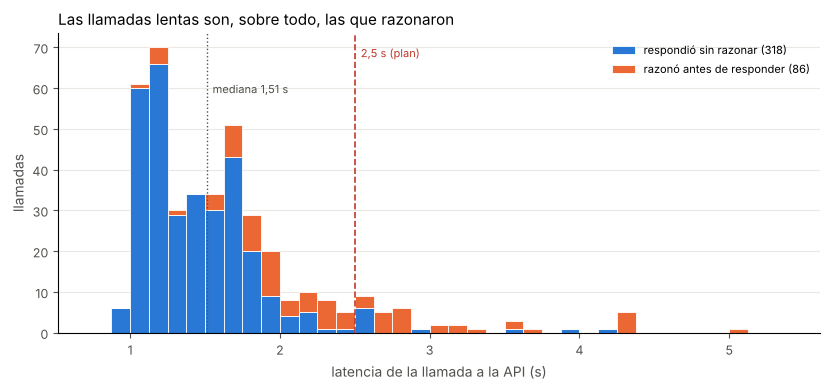

In [6]:
u = uso[uso.corrida == "prueba"].copy(); u["canal"] = np.where(u.uid.str.startswith("A"), "audio", "texto")
u["pensó"] = u.output_tokens > 110        # la respuesta JSON sola ocupa ~95–110 tokens; más es razonamiento adaptativo
def lat(x):
    return pd.Series({"llamadas": len(x), "mediana s": x.latencia_s.median(), "media s": x.latencia_s.mean(),
                      "P95 s": x.latencia_s.quantile(.95), "máximo s": x.latencia_s.max(), "% > 2,5 s": 100 * (x.latencia_s > 2.5).mean(),
                      "tokens de salida (mediana)": x.output_tokens.median()})
tl = pd.concat({"todas": lat(u), "texto": lat(u[u.canal == "texto"]), "audio": lat(u[u.canal == "audio"]),
                "sin razonar (≤ 110 tokens)": lat(u[~u["pensó"]]), "razonó (> 110 tokens)": lat(u[u["pensó"]])}, axis=1).T.round(2)
display(tl)
print(f"Razonó en {int(u['pensó'].sum())} de {len(u)} llamadas ({100 * u['pensó'].mean():.1f} %): texto "
      f"{100 * u[u.canal == 'texto']['pensó'].mean():.1f} %, audio {100 * u[u.canal == 'audio']['pensó'].mean():.1f} %. "
      f"De las {int((u.latencia_s > 2.5).sum())} llamadas de más de 2,5 s, {int(u[u.latencia_s > 2.5]['pensó'].sum())} razonaron.")
print(f"Correlación tokens de salida – latencia: {np.corrcoef(u.output_tokens, u.latencia_s)[0, 1]:.2f}")
au = RP[(RP.canal == "audio") & (~RP.desde_cache)]
tot = au.whisper_s + au.latencia_s
print(f"Nota de voz completa (Whisper en la GPU + API), {len(au)} llamadas nuevas: mediana {tot.median():.2f} s · P95 {tot.quantile(.95):.2f} s")
dev = uso[uso.corrida == "desarrollo_v1_low"]
print(f"Desarrollo (184 llamadas): mediana {dev.latencia_s.median():.2f} s · P95 {dev.latencia_s.quantile(.95):.2f} s")
print(f"Caché del prompt: {int((u.cache_read_input_tokens > 0).sum())} de {len(u)} llamadas de la prueba leyeron el prompt de la caché")
cost = uso.groupby("corrida").agg(llamadas=("costo_usd", "size"), costo_usd=("costo_usd", "sum"))
cost.loc["TOTAL"] = cost.sum(); display(cost.round(4))
print(f"Costo por mensaje en la prueba: ${u.costo_usd.mean():.5f} · por 1.000 mensajes: ${1000 * u.costo_usd.mean():.2f}")
check("Criterio de latencia (plan; decisión de la Persona 3, 11:52): < 2,5 s por mensaje en la mediana (y en la media)",
      u.latencia_s.median() < 2.5 and u.latencia_s.mean() < 2.5, f"mediana {u.latencia_s.median():.2f} s · media {u.latencia_s.mean():.2f} s")
print(f"Hallazgo H30 (no es criterio: decisión de la Persona 3, 11:52): P95 {u.latencia_s.quantile(.95):.2f} s "
      f"(texto {u[u.canal == 'texto'].latencia_s.quantile(.95):.2f} · audio {u[u.canal == 'audio'].latencia_s.quantile(.95):.2f}); "
      f"{100 * (u.latencia_s <= 2.5).mean():.1f} % de las llamadas respondió en 2,5 s o menos")
check("Costo real registrado y por debajo del límite de $20", cost.loc["TOTAL", "costo_usd"] < 20, f"${cost.loc['TOTAL', 'costo_usd']:.4f}")

fig, ax = plt.subplots(figsize=(8.4, 4.0))
bins = np.arange(0.75, 5.5, 0.125)
ax.hist([u[~u["pensó"]].latencia_s, u[u["pensó"]].latencia_s], bins=bins, stacked=True, color=[COL["texto"], COL["pensó"]],
        label=[f"respondió sin razonar ({int((~u['pensó']).sum())})", f"razonó antes de responder ({int(u['pensó'].sum())})"],
        edgecolor="white", linewidth=0.6)
ax.axvline(2.5, color=COL["meta"], lw=1.2, ls="--"); ax.text(2.54, ax.get_ylim()[1] * 0.92, "2,5 s (plan)", color=COL["meta"], fontsize=8)
ax.axvline(u.latencia_s.median(), color=COL["texto2"], lw=1, ls=":")
ax.text(u.latencia_s.median() + 0.04, ax.get_ylim()[1] * 0.80, "mediana " + f"{u.latencia_s.median():.2f}".replace(".", ",") + " s", color=COL["texto2"], fontsize=8)
ax.set_xlabel("latencia de la llamada a la API (s)", color=COL["texto2"]); ax.set_ylabel("llamadas", color=COL["texto2"])
ax.set_title("Las llamadas lentas son, sobre todo, las que razonaron", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color=COL["grid"]); ax.set_axisbelow(True)
ax.tick_params(colors=COL["texto2"], labelsize=9); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "latencia_api_10_5.png", dpi=150); plt.show()

### 6 · El prompt no trae material de la prueba

In [7]:
p1 = cargar_prompt("v1")
print(f"Prompt v1: {len(p1):,} caracteres (~{len(p1) // 4:,} tokens; caché mínima de Haiku: 512)")
txt_prueba = set(RP.texto)
ejemplos_en_prueba = [t for t in txt_prueba if t and t in p1]
print(f"Textos de la prueba que aparecen en el prompt: {len(ejemplos_en_prueba)}")
check("El prompt congelado no contiene ningún mensaje de la prueba ni los errores de Whisper vistos en ella",
      not ejemplos_en_prueba and not re.search(r"\bbarba\b|\brancón\b|\brancon\b", p1.lower()))   # palabra completa: «trancón» sí va

Prompt v1: 6,342 caracteres (~1,585 tokens; caché mínima de Haiku: 512)
Textos de la prueba que aparecen en el prompt: 0


### 7 · Pruebas

In [8]:
p = subprocess.run([sys.executable, "tests_10_5.py"], capture_output=True, text=True, encoding="utf-8")
print(p.stdout.strip())
check("tests_10_5.py: 5/5 PASS", p.returncode == 0 and "5/5 PASS" in p.stdout, p.stdout.strip().splitlines()[-1])
chk = pd.DataFrame(CHECKS); chk.to_csv("datos_10/checks_10_5.csv", index=False)
display(chk); print(f"{(chk.resultado == 'PASS').sum()}/{len(chk)} PASS")

PASS  a · esquema estricto: sin minimum/maximum, additionalProperties = false, todos los campos requeridos; las 580 respuestas correctas lo cumplen (Pydantic + reglas)
PASS  b · métricas: extracción perfecta → F1 1,0; un error de gravedad solo baja ese campo; vías equivalentes («la 8A» = «Carrera 8A», en cualquier orden) cuentan como acierto
PASS  c · extractor: caché del prompt + Structured Outputs + esfuerzo en el pedido; caché en disco (no paga dos veces); tope de llamadas; uso_api.csv con tokens, costo y latencia
PASS  d · el prompt no trae nada de la PRUEBA: sus ejemplos salen del desarrollo y no menciona los errores de Whisper vistos en la prueba
PASS  e · evaluación única: si la configuración está congelada, su hash coincide; la prueba no se corre sin congelar

5/5 PASS


,check,resultado,detalle
0,"Configuración congelada: los hashes de la configuración, el prompt y el esquema coinciden, y apunta a las ...",PASS,
1,La configuración se congeló antes de la primera llamada de la prueba,PASS,2026-10-28T11:18:45
2,Desarrollo: el esfuerzo low ya cumple la meta en texto y audio (decisión a ajustada: no se corren medium n...,PASS,texto 0.9987 · audio 1.0000
3,"Meta aprobada (decisión d): F1 ≥ 0,90 en el texto escrito (363) Y en el audio transcrito (126)",PASS,texto 0.9983 · audio 0.9955
4,"El límite inferior del IC95 % del F1 también supera 0,90 (texto y audio)",PASS,texto 0.9966 · audio 0.9847
5,100 % de las 489 respuestas cumplen el esquema (Structured Outputs + Pydantic + reglas de coherencia),PASS,0 con errores
6,Las métricas de la prueba se recalculan idénticas desde las respuestas guardadas,PASS,
7,"Prueba completa: 363 textos + 126 transcripciones (42 audios × 3 versiones), sin mensajes de desarrollo",PASS,
8,Cada mensaje con error tiene una causa identificada,PASS,
9,100 % de los 489 eventos construidos con la extracción de Claude cumplen el contrato 1.2,PASS,


15/15 PASS


## Conclusiones

**Conclusión 1 · Claude cumple la meta del F1 en el texto escrito y en el audio**
- **Prueba (evaluación única, configuración congelada `d550de70…`):**

  | | Mensajes | F1 (meta ≥ 0,90) | IC95 % bootstrap | Mensajes perfectos |
  |---|---|---|---|---|
  | Texto escrito | 363 | **0,9983** | [0,9966; 0,9996] | 358/363 (Wilson [96,8 %; 99,4 %]) |
  | Audio transcrito | 126 | **0,9955** | [0,9847; 1,0000] | 122/126 (Wilson [92,1 %; 98,8 %]) |

  - Aun el extremo inferior de los dos intervalos queda lejos de 0,90.
  - En el audio, el intervalo se calculó remuestreando cada audio con sus 3 versiones juntas, porque no son independientes.
- **Por fuente:** plantilla 0,9996 y frases libres 0,9943; audio limpio 0,9960, con ruido a 10 dB 0,9944 y a 5 dB 0,9960. El ruido casi no cambia el resultado.
- **El desarrollo anticipó bien la prueba:** 0,9987 en texto y 1,0000 en audio. No hay señal de que el prompt se haya ajustado de más.
- **Structured Outputs:** las 489 respuestas cumplen el esquema, sin un solo error de formato.
- **No inventa datos:** en ninguno de los 700 mensajes (desarrollo y prueba) Claude puso una duración, un sentido o una gravedad que el conductor no dijo. Eso incluye las 8 omisiones controladas de los audios (A25, A49, A54 y A58 sin duración; A04, A08, A16 y A40 sin sentido).

**Conclusión 2 · Los pocos errores tienen causas concretas**
- **9 de 489 mensajes** tienen un campo mal: 9 campos de 3.423. Alcance, duración, sentido y despejado salieron bien en el 100 %.
- **Las causas:**

  | Causa | Mensajes | Qué pasó |
  |---|---|---|
  | La palabra «evento» | 4 (L099 y A02 en sus 3 versiones) | «Evento adelante en…» o «Despejado. Evento. Lugar.»: Claude lee «evento» como la etiqueta de la guía y no como el tipo «evento» (concierto, partido). En desarrollo pasó lo mismo con L096. |
  | Vía mal escrita | 2 (P242 «Muillo», P398 «clale 64») | Claude copia la vía tal como la escribió el conductor, como pide el prompt. |
  | Lenguaje suelto | 2 frases libres | «Está pare y siga», sin decir el tipo, quedó como «otro» y no como trancón (L010). «Cerraron … por el concierto» quedó sin gravedad, en vez de 5 (L094). |
  | Error de Whisper | 1 (A25 a 10 dB) | Whisper oyó «57» en vez de «87» (10.4). Claude extrajo bien lo que recibió. |

- **La causa que más pesa es de la guía, no del modelo:** el tipo «evento» se llama igual que la etiqueta «Evento:». Darle otro nombre en la guía (por ejemplo, «evento público») lo resolvería. La decisión es de la Persona 3 y se deja para la 10.6.

**Conclusión 3 · De punta a punta, el segmento queda casi en el techo; lo que falta son vías mal escritas**
- **Del mensaje al segmento.** Cada extracción se pasó por `construir_evento` con la ventana real de GPS del set:

  | | Segmento exacto con Claude | Techo (extracción perfecta) | A ±1 segmento con Claude | Mismo segmento que el techo |
  |---|---|---|---|---|
  | Texto (363) | **95,04 %** | 96,14 % | 95,87 % | 98,90 % |
  | Audio (126) | **99,21 %** | 100 % | 99,21 % | 99,21 % |

- **Los 489 eventos cumplen el contrato 1.2.**
- **De dónde salen las 5 diferencias con el techo:**
  - en todas, la vía llegó mal escrita: 4 por errores de tipeo del mensaje («Aveinda», «Aevnida», «Muillo», «clale») y 1 por el «57» de Whisper;
  - el resolvedor no encuentra la esquina y el evento cae a la posición GPS del bus con confianza «baja», 3 o 4 segmentos atrás (1,5–2 km);
  - en 2 de esos casos (P186 y P374) el F1 cuenta el lugar como acierto, porque la otra vía basta para reconocerlo, pero la esquina no se ubica en el mapa. Por eso se mide también el segmento.
- **Los errores de tipeo en el resto del mensaje no afectan:** de los 27 mensajes de plantilla con error de tipeo, 23 dan el mismo segmento que el techo, porque Claude entiende bien «Evenot», «lguar» o «druación». Los 4 que fallan son los de la vía.
- **Siguiente paso natural (10.6):** que el resolvedor tolere un error de tipeo en el nombre de la vía, comparándolo con el catálogo de esquinas de la ruta. Se mediría con desarrollo; la prueba ya se usó.

**Conclusión 4 · Latencia: cumple en la mediana; el P95 queda como hallazgo**
- **Latencia de las 404 llamadas nuevas a la API de la prueba**, medida en el PC de la Persona 3 con la red incluida:

  | | Mediana | Media | P95 | Más de 2,5 s |
  |---|---|---|---|---|
  | Todas | **1,51 s** | 1,64 s | **2,81 s** | 9,4 % |
  | Texto | 1,45 s | 1,57 s | 2,56 s | 6,5 % |
  | Audio (solo la API) | 1,66 s | 1,98 s | 3,63 s | 24,6 % |

- **Criterio del plan** («< 2,5 s por mensaje procesado», medido con la mediana por decisión de la Persona 3): **se cumple**, con 1,51 s de mediana y 1,64 s de media. El 90,6 % de las llamadas respondió en 2,5 s o menos.
- **Hallazgo (H30): la cola.** El P95 es 2,81 s: 1 de cada 10 llamadas pasa de 2,5 s. El alcance había propuesto el P95 como criterio; la cifra se reporta completa.
- **Por qué hay cola:** Haiku 5.5 razona de forma adaptativa, y con esfuerzo «low» todavía razonó en 86 de las 404 llamadas (21,3 %). Esas llamadas tardan más: 28 de las 38 de más de 2,5 s razonaron. Sin razonar, el P95 es 2,14 s. En el audio razonó más (35,4 % frente a 18,6 % en el texto), porque la puntuación de Whisper («Despejado. Evento. Lugar.») vuelve el mensaje más ambiguo.
- **Variación entre corridas:** en desarrollo, con el mismo modelo y el mismo prompt, el P95 fue 2,38 s. La red y el plan personal de la API (CLAUDE.md §13) también influyen.
- **Nota de voz completa** (Whisper en la GPU + API): mediana 2,41 s y P95 4,31 s.
- **Costo:** $0,069 en total (desarrollo $0,021 + prueba $0,048), es decir $0,12 por cada 1.000 mensajes. El 100 % de las llamadas de la prueba leyó el prompt de la caché. El límite de gasto es $20.

**Conclusión 5 · El modelo elegido, el alcance de la validación y qué sigue en la 10.6**
- **Modelo (H7).** El plan menciona `claude-3-5-sonnet`. Anthropic retiró ese modelo el 28-oct-2025 y su reemplazo indicado es `claude-sonnet-5-5`. Se usó `claude-haiku-5-5` por la regla del presupuesto (§13: Sonnet solo si Haiku no llega a 0,90), y Haiku llegó a 0,998 en texto y 0,996 en audio. Cuesta 20 veces menos que Sonnet ($0,10 / $0,50 por millón de tokens frente a $2 / $10) y es el más rápido de los modelos vigentes. Con Structured Outputs y un esquema Pydantic estricto se cumple lo que pide el plan.
- **Esfuerzo:** se probó solo «low». Con ese esfuerzo el F1 de desarrollo ya estaba a 0,0013 del máximo, así que la Persona 3 decidió no correr «medium» ni «high» (ajuste de la decisión a, registrado en el alcance).
- **Alcance de la validación** (en `LIMITACIONES_modulo10.md`):
  - los mensajes escritos son sintéticos: los escribió Claude y los interpreta Claude (H16). Las frases libres, que se alejan de la guía, dan un F1 algo menor (0,9943) y se reportan aparte;
  - el audio es de una sola voz, grabada en una sala;
  - los errores de tipeo del set los puso el generador, no un conductor real.
- **Siguiente paso natural:** un piloto con mensajes y notas de voz reales de conductores.
- **Para la 10.6:**
  1. un resolvedor de esquinas que tolere un error de tipeo en la vía;
  2. proponer a la Persona 3 otro nombre para el tipo «evento»;
  3. manejar la latencia: verificar en la documentación si el razonamiento adaptativo se puede limitar más allá de «low», y medir el P95 del servicio con los mensajes de desarrollo;
  4. el servicio `src/nlp/traffic_nlp_service.py`, la tabla `tb_eventos_imprevistos_activos` y el banco de eventos para los Módulos 12 y 13, que se procesa una sola vez.

<a id="m10-6"></a>

### A2.2.6 &middot; Subfase 10.6 · Servicio, tabla de eventos y entrega

<sub>Notebook original: `modulo10/subfase_10_6_servicio.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 10 · Subfase 10.6 — Servicio, tabla de eventos y entrega

**Persona 3.** La 10.6 junta las piezas de la 10.1 a la 10.5 en el entregable del plan: el **microservicio FastAPI
`src/nlp/traffic_nlp_service.py`** y la **tabla dinámica `tb_eventos_imprevistos_activos`**. Alcance aprobado:
`revisiones/alcance_10_6.md` (decisiones a–k de la Persona 3).

| Pieza | Qué hace | Dónde |
|---|---|---|
| Webhook | Recibe el mensaje simulado de WhatsApp (contrato de entrada 1.0): texto o nota de voz | `POST /webhook` |
| Audio → texto | Whisper local (10.4); el audio no sale del PC | `src/m10/transcripcion.py` |
| Texto → evento | Claude Haiku 5.5 con Structured Outputs (10.5), **prompt v2** (guía 1.5: «evento masivo») | `src/m10/extractor.py` |
| Mapeo espacial | GPS de los 5 min previos del bus + esquina «adelante en X con Y» → segmento de 500 m, latitud y longitud, ahora **tolerante a errores de tipeo** en la calle (H28) | `src/m10/evento.py`, `src/geo/referencias.py` |
| Tabla | Crea, une o cierra eventos; el centro de control corrige o cierra | `src/m10/almacen_eventos.py` (SQLite) |
| Para los Módulos 12 y 13 | Banco de 580 eventos, calendario de eventos masivos y guía de uso | `datos_10/eventos/`, `datos_10/eventos_bd/`, `NOTA_PARA_MODULO_12.md` |

**Reglas de la tabla (Persona 3):** un evento sigue activo hasta su «Despejado» o hasta que el centro de control lo cierre,
sin vencimiento automático; los reportes repetidos (mismo tipo, misma ruta, ±1 segmento) se unen **sin límite de tiempo**
(hay eventos de días, como las obras) y el número de reportes no sube la gravedad; manda la gravedad del más reciente.

## Parte 2 · Análisis offline

In [1]:
import difflib
import hashlib
import json
import sqlite3
import subprocess
import sys
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "src"); sys.path.insert(0, ".")
from m10.esquema_extraccion import hash_esquema
from m10.extractor import cargar_prompt
from m10.evento import validar_evento
import extraer_10_5 as X
import extraer_10_6 as Y

pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)
S = Path("datos_10/extraccion"); D = Path("datos_10/set_prueba"); E = Path("datos_10/eventos"); B = Path("datos_10/eventos_bd")
FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if bool(ok) else "FAIL", "detalle": detalle})
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
leer = lambda p: pd.DataFrame([json.loads(l) for l in open(p, encoding="utf-8")])
cfg = json.loads((S / "config_10_6.json").read_text(encoding="utf-8"))
uso = pd.read_csv("datos_10/uso_api.csv")

## 1 · Guía 1.5 y prompt v2

El único cambio de la guía 1.5 frente a la 1.4 es el nombre del tipo «evento», que ahora se dice **«evento masivo»**
(H29, decidido por la Persona 3). Regla del alcance (decisión e): el servicio usa el prompt v2 solo si en desarrollo
da F1 ≥ 0,99 en texto **y** en audio; si no, se queda con el v1. Mismo modelo y esfuerzo de la 10.5.

In [2]:
v1, v2 = cargar_prompt("v1"), cargar_prompt("v2")
cambios = [l for l in difflib.unified_diff(v1.splitlines(), v2.splitlines(), lineterm="", n=0)
           if l[:1] in "+-" and not l.startswith(("+++", "---"))]
print(f"Líneas que cambian de v1 a v2: {len(cambios)}")
for l in cambios:
    print("  ", l[:160])
cfg_sin = {k: v for k, v in cfg.items() if k not in ("creado", "hash_config")}
hash_ok = hashlib.sha256(json.dumps({k: v for k, v in cfg.items() if k != "creado" and k != "hash_config"}, sort_keys=True,
                                    ensure_ascii=False).encode()).hexdigest()
print(f"\nConfiguración congelada {cfg['creado']}: {cfg['modelo']} · {cfg['esfuerzo']} · prompt {cfg['version_prompt']} · hash {cfg['hash_config'][:12]}…")
check("config_10_6: el hash del prompt v2 y del esquema coincide con lo congelado",
      hashlib.sha256(v2.encode()).hexdigest() == cfg["hash_prompt"] and hash_esquema() == cfg["hash_esquema"])
check("config_10_6: el hash de la configuración se recalcula igual", hash_ok == cfg["hash_config"], hash_ok[:12])
check("prompt v2: solo cambian el encabezado de la guía (1.4 → 1.5) y la línea del tipo «evento» (→ «evento masivo»)",
      len(cambios) == 4 and all(l[1:].startswith(("## Cómo reportan", "- **evento**")) for l in cambios)
      and "evento masivo" in cambios[-1], f"{len(cambios)} líneas")

Líneas que cambian de v1 a v2: 4
   -## Cómo reportan los conductores (guía 1.4)
   +## Cómo reportan los conductores (guía 1.5)
   -- **evento**: partido, concierto, Carnaval u otro evento con mucha gente. Ojo: en «Evento: choque» la palabra «Evento» es solo la etiqueta.
   +- **evento**: evento masivo: partido, concierto, Carnaval, procesión u otra actividad con mucha gente que llena la vía. Desde la guía 1.5 el conductor dice «ev

Configuración congelada 2026-10-28T16:27:56: claude-haiku-5-5 · low · prompt v2 · hash 44be675af211…


In [3]:
R1 = leer(S / "respuestas_desarrollo_v1_low.jsonl"); R2 = leer(S / "respuestas_desarrollo_v2_low.jsonl")
m1, m2 = X.medir(R1), X.medir(R2)
comp = pd.DataFrame({"n": m2["n"], "F1 v1": m1["F1"], "F1 v2": m2["F1"], "perfectos v1 %": m1["perfectos_%"],
                     "perfectos v2 %": m2["perfectos_%"], "latencia mediana v2 (s)": m2["lat_mediana_s"]})
display(comp)
dif = [u for u, a, b in zip(R1.sort_values("uid").uid, R1.sort_values("uid").extraccion, R2.sort_values("uid").extraccion) if a != b]
print("Extracciones distintas entre v1 y v2:", dif)
print("Errores de v2 en desarrollo:", [(u, c) for u, c in zip(R2.uid, R2.campos_errados) if c])
pasa = m2.loc["TEXTO (meta)", "F1"] >= 0.99 and m2.loc["AUDIO (meta)", "F1"] >= 0.99
check("regla e: v2 da F1 ≥ 0,99 en texto y audio en desarrollo (recalculado) y config lo registra",
      pasa and cfg["v2_pasa"] and abs(cfg["f1_desarrollo_v2"]["texto"] - m2.loc["TEXTO (meta)", "F1"]) < 1e-4,
      f"texto {m2.loc['TEXTO (meta)', 'F1']:.4f} · audio {m2.loc['AUDIO (meta)', 'F1']:.4f}")
check("métricas de desarrollo v2: el archivo es el que se congeló", sha(S / "metricas_desarrollo_v2_low.csv") == cfg["metricas_desarrollo_sha256"])

,n,F1 v1,F1 v2,perfectos v1 %,perfectos v2 %,latencia mediana v2 (s)
grupo,,,,,,
TEXTO (meta),157,0.9987,0.9987,98.7261,98.7261,1.3220
AUDIO (meta),54,1.0000,1.0000,100.0000,100.0000,1.6550
texto · plantilla,120,0.9995,0.9995,99.1667,99.1667,1.3690
texto · frases libres,37,0.9956,0.9956,97.2973,97.2973,1.2390
audio · limpio,18,1.0000,1.0000,100.0000,100.0000,1.6055
audio · ruido 10 dB,18,1.0000,1.0000,100.0000,100.0000,1.6880
audio · ruido 5 dB,18,1.0000,1.0000,100.0000,100.0000,1.6880


Extracciones distintas entre v1 y v2: ['A10@limpio', 'A27@limpio']
Errores de v2 en desarrollo: [('P389', ['lugar']), ('L096', ['tipo_evento'])]


**Conclusión 1 · El prompt v2 iguala al v1 y pasa a ser el del servicio**
- **Qué cambió:** 4 líneas del prompt, el encabezado de la guía (1.4 → 1.5) y la línea del tipo «evento», que ahora se describe como «evento masivo». Los ejemplos de desarrollo son los mismos.
- **Desarrollo (211 mensajes, regla e):**

  | | F1 v1 | F1 v2 | Perfectos v2 |
  |---|---|---|---|
  | Texto (157) | 0,9987 | **0,9987** | 98,73 % |
  | Audio (54) | 1,0000 | **1,0000** | 100 % |

- **Las dos respuestas que cambian** entre v1 y v2 (A10 y A27) no cambian el resultado: una marca de cumplimiento del protocolo y «la Circunvalar» → «Circunvalar».
- **Siguen los 2 errores de desarrollo:** P389 (la calle mal escrita, que resuelve la búsqueda tolerante de la sección 3) y L096, una frase escrita con la guía anterior donde «evento» es ambiguo. La guía 1.5 evita esa ambigüedad desde el mensaje, como muestra el mini-set.
- **Configuración congelada** el 28-oct a las 16:27 (`config_10_6.json`, hash `44be675a…`): `claude-haiku-5-5`, esfuerzo low, prompt v2.

## 2 · Mini-set de la guía 1.5 (evaluación única)

40 mensajes nuevos escritos por Claude con la guía 1.5 (15 de «evento masivo» anclados en una ocurrencia real de SOBUSA,
25 de otros tipos; 26 con etiquetas y 14 informales), con GPS real y congelados con hash **antes** de cualquier corrida.
Se evaluaron una sola vez con la configuración congelada. Meta: F1 ≥ 0,90.

In [4]:
man = json.loads((D / "manifiesto_miniset_10_6.json").read_text(encoding="utf-8"))
RM = leer(S / "respuestas_miniset_10_6.jsonl")
items = {m["uid"]: m["item"] for m in Y.mensajes_miniset()}
mm = Y.medir_miniset(RM, items)
display(mm)
print("Respuestas que salieron de la caché en disco:", RM[RM.desde_cache].uid.tolist(),
      RM[RM.desde_cache].texto.tolist())
check("mini-set: el archivo evaluado es el congelado (hash del manifiesto y de config_10_6)",
      sha(D / "miniset_10_6.jsonl") == man["archivo"]["miniset_10_6.jsonl"]["sha256"] == cfg["miniset_sha256"])
check("mini-set: F1 ≥ 0,90 (recalculado)", mm.loc["MINI-SET (meta)", "F1"] >= 0.90, f"{mm.loc['MINI-SET (meta)', 'F1']:.4f}")
check("mini-set: se evaluó una sola vez (39 llamadas nuevas en uso_api.csv + 1 desde la caché)",
      (uso.corrida == "miniset_10_6").sum() == 39 and len(RM) == 40)

,n,F1,perfectos_%,tipo_evento,alcance,severidad,duracion,sentido,es_despeje,lugar,lat_mediana_s,errores_esquema
grupo,,,,,,,,,,,,
MINI-SET (meta),40,1.0,100.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.3395,0
evento masivo,15,1.0,100.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.7360,0
otros tipos,25,1.0,100.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.2710,0
con etiquetas,26,1.0,100.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.2840,0
informal,14,1.0,100.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.6820,0


Respuestas que salieron de la caché en disco: ['M25'] ['Despejado: arroyo, lugar: aquí.']


**Conclusión 2 · Con la guía 1.5, «evento masivo» se reconoce siempre**
- **Mini-set (40 mensajes nuevos, evaluación única):** **F1 = 1,0000**, 40/40 perfectos (meta ≥ 0,90).
  - **«Evento masivo»:** 15/15, cada uno anclado en una ocurrencia real registrada por SOBUSA (Carnaval 5, Batalla de Flores 3, partidos de la Selección 3, Guacherna 2, conciertos 2), con el GPS de un bus que operaba en ese horario.
  - **Otros tipos:** 25/25.
  - **Por formato:** 26/26 con etiquetas y 14/14 informales.
  - **0 errores de esquema.**
- **Era el error que más pesaba en la 10.5** (4 de 9 mensajes con error, H29). Con el nombre nuevo desaparece.
- **Transparencia:** 1 de los 40 mensajes (M25, «Despejado: arroyo, lugar: aquí.») tiene el mismo texto que un mensaje de desarrollo, así que su respuesta salió de la caché. Sin él, el resultado es el mismo: 39/39.
- **Alcance de la medida:** son 40 mensajes escritos por Claude, igual que el set de la 10.3 (`LIMITACIONES_modulo10.md` §3).

## 3 · Mapeo espacial tolerante a errores de tipeo (H28)

En la 10.5, 5 de 489 mensajes cayeron lejos de su segmento porque la calle venía mal escrita («Aveinda», «Muillo»…).
La búsqueda tolerante compara el nombre con las calles de la ruta (Damerau-Levenshtein ≤ 1, o ≤ 2 si tiene 8 letras o más;
coincidencia única; no toca números). Va apagada por defecto y el servicio la enciende. Medida sobre la prueba de la 10.5
**como diagnóstico** (la regla se calibró con desarrollo, pero la prueba ya se había visto en la 10.5).

In [5]:
filas = []
for nombre in ("desarrollo_v1_low", "prueba"):
    a = pd.read_csv(S / f"punta_a_punta_{nombre}.csv"); b = pd.read_csv(S / f"punta_a_punta_{nombre}_tolerante.csv")
    m = a.drop(columns=["correccion"], errors="ignore").merge(
        b[["uid", "exacto_claude", "correccion"]].rename(columns={"exacto_claude": "exacto_claude_tol", "correccion": "correccion_tol"}), on="uid")
    for canal in ("texto", "audio"):
        g = m[m.canal == canal]
        filas.append({"conjunto": nombre, "canal": canal, "n": len(g), "exacto sin tolerancia %": 100 * g.exacto_claude.mean(),
                      "exacto tolerante %": 100 * g.exacto_claude_tol.mean(), "techo %": 100 * g.exacto_perfecta.mean(),
                      "mejoran": int((~g.exacto_claude & g.exacto_claude_tol).sum()), "empeoran": int((g.exacto_claude & ~g.exacto_claude_tol).sum()),
                      "calles corregidas": int(g.correccion_tol.notna().sum())})
TOL = pd.DataFrame(filas).round(2); display(TOL)
pr = pd.read_csv(S / "punta_a_punta_prueba_tolerante.csv")
display(pr[pr.correccion.notna()][["uid", "correccion"]])
t = TOL[(TOL.conjunto == "prueba") & (TOL.canal == "texto")].iloc[0]
check("H28: la búsqueda tolerante no empeora ningún mensaje y lleva el texto de la prueba al techo",
      TOL.empeoran.sum() == 0 and abs(t["exacto tolerante %"] - t["techo %"]) < 1e-9, f"{t['exacto tolerante %']:.2f} % = techo")

,conjunto,canal,n,exacto sin tolerancia %,exacto tolerante %,techo %,mejoran,empeoran,calles corregidas
0,desarrollo_v1_low,texto,157,92.36,92.99,92.99,1,0,1
1,desarrollo_v1_low,audio,54,100.00,100.00,100.00,0,0,0
2,prueba,texto,363,95.04,96.14,96.14,4,0,4
3,prueba,audio,126,99.21,99.21,100.00,0,0,0


,uid,correccion
132,P186,"{""via1"": ""Murillo"", ""via2"": ""avenida Circunvalar"", ""cambios"": [[""Aveinda"", ""avenida""]]}"
172,P242,"{""via1"": ""carrera 5"", ""via2"": ""murillo"", ""cambios"": [[""Muillo"", ""murillo""]]}"
263,P374,"{""via1"": ""avenida Murillo"", ""via2"": ""Carrera 13"", ""cambios"": [[""Aevnida"", ""avenida""]]}"
278,P398,"{""via1"": ""Carrera 54"", ""via2"": ""calle 64"", ""cambios"": [[""clale"", ""calle""]]}"


**Conclusión 3 · La búsqueda tolerante cierra la brecha con el techo en el texto**
- **Qué corrige:** errores de una o dos letras en el tipo de vía o en el nombre de la calle, siempre que haya una sola calle de la ruta que se le parezca. No toca números.
- **Resultado en la prueba de la 10.5:**
  - **Texto:** segmento exacto **95,04 % → 96,14 %**, igual al techo (lo que da una extracción perfecta). Corrige 4 mensajes: «Aveinda», «Muillo», «Aevnida» y «clale».
  - **Desarrollo:** 92,36 % → 92,99 %, también igual a su techo. Corrige P389.
  - **Ningún mensaje empeora.**
- **El único que queda fuera:** A25, donde Whisper oyó «57» en vez de «87». Es un número y no se adivina a propósito.
- **Cómo queda marcado:** el evento corregido lleva confianza «media» y la corrección queda registrada en `tb_reportes_m10`. En la corrida de latencia hubo 1 corrección (P389).
- **Es una medida diagnóstica:** la regla se calibró solo con desarrollo, pero la prueba ya se había visto en la 10.5. **H28 queda cerrado.**

## 4 · El servicio y la tabla: pruebas

`tests_10_6.py` prueba el servicio con un extractor y un transcriptor simulados (no llama a la API ni usa Whisper):
contrato de entrada, idempotencia, ciclo de vida con reloj simulado, centro de control, búsqueda tolerante, guía y
prompt v2, mini-set, banco, tiempo de la consulta, datos personales y calendario de partidos.

In [6]:
p = subprocess.run([sys.executable, "tests_10_6.py"], capture_output=True, text=True, encoding="utf-8")
lineas = [l for l in p.stdout.splitlines() if l.strip()]
for l in lineas:
    print(l[:170])
check("tests_10_6.py: todas las pruebas pasan", p.returncode == 0 and lineas[-1].startswith("11/11"), lineas[-1])

PASS  a · contrato de entrada: los 620 mensajes del set y del mini-set se aceptan; los mal formados dan 422
PASS  b · idempotencia: el mismo id_mensaje dos veces da un solo evento y una sola llamada a la API
PASS  c · ciclo de vida (reloj simulado): unión sin subir la gravedad por el conteo; manda el reporte más reciente; sin límite de tiempo (un reporte 10 días después se un
PASS  d · centro de control: corrige y cierra con usuario registrado; rechaza campos no corregibles, gravedad 7 y llamadas sin token si el servicio lo exige
PASS  e · H28: la búsqueda tolerante recupera P389 (desarrollo) y los 4 casos de la prueba de la 10.5; no cambia ningún mensaje que ya salía bien; no corrige números ni n
PASS  f · guía 1.5 y prompt v2: el único cambio frente a v1 es «evento masivo» (más el encabezado); mismos ejemplos de desarrollo; sin textos de la prueba ni del mini-set
PASS  g · mini-set: congelado con hash; 40 mensajes (15 de evento masivo anclados en una ocurrencia real de SOBUSA, con el

**Conclusión 4 · El servicio cumple las reglas de la tabla que pidió la Persona 3**
- **`tests_10_6.py`: 11/11** (no llama a la API ni usa Whisper):
  - acepta los 620 mensajes del set y del mini-set, y rechaza los mal formados con 422;
  - el mismo `id_mensaje` dos veces da un solo evento y una sola llamada a la API;
  - dos reportes del mismo sitio se unen sin subir la gravedad y manda el más reciente;
  - **sin límite de tiempo** para unir: una obra reportada otra vez 10 días después sigue siendo el mismo evento;
  - el «Despejado» cierra el evento y, sin él, el evento sigue activo;
  - el centro de control corrige o cierra con su usuario registrado, y se le exige token si el servicio lo pide;
  - el texto se guarda con teléfonos y placas tapados.
- **Rutas:** `POST /webhook`, `GET /eventos/activos`, `GET /eventos/{id}`, `PATCH /eventos/{id}` y `GET /salud`.
- **Las tres tablas en un SQLite local:** `tb_eventos_imprevistos_activos` (la del plan), `tb_reportes_m10` (cada mensaje y cada acción del centro de control) y `tb_eventos_cerrados_m10`.

## 5 · Latencia del servicio de punta a punta

En el PC de la Persona 3 se levantó el servicio **sin caché** (cada mensaje llamó de verdad a la API) y se le enviaron
157 textos y las 18 notas de voz limpias de **desarrollo** (nunca la prueba). Criterio del plan: latencia de la API
< 2,5 s por mensaje; por decisión de la Persona 3 (10.5, 11:52) se juzga con la **mediana** y el P95 se reporta.

In [7]:
L = pd.read_csv(E / "latencia_servicio_10_6.csv")
srv = uso[uso.corrida == "servicio_10_6"].copy()
srv["canal"] = np.where(srv.uid.str.startswith("A"), "audio", "texto")
prueba105 = uso[uso.corrida == "prueba"]
def resumen(x):
    return pd.Series({"n": len(x), "mediana": x.median(), "P95": x.quantile(.95), "máximo": x.max(), "≤ 2,5 s %": 100 * (x <= 2.5).mean()})
T = pd.DataFrame({"API · servicio 10.6 (todas)": resumen(srv.latencia_s),
                  "API · servicio, texto": resumen(srv[srv.canal == "texto"].latencia_s),
                  "API · servicio, audio": resumen(srv[srv.canal == "audio"].latencia_s),
                  "API · prueba 10.5 (referencia)": resumen(prueba105.latencia_s),
                  "Mensaje completo · texto": resumen(L[L.canal == "texto"].servidor_total_s),
                  "Mensaje completo · nota de voz": resumen(L[L.canal == "audio"].servidor_total_s),
                  "Whisper · nota de voz": resumen(L[L.canal == "audio"].transcripcion_s)}).T.round(3)
display(T)
srv["razona"] = srv.output_tokens > 110          # mismo criterio de la 10.5
print(f"Llamadas que razonaron (> 110 tokens de salida, criterio de la 10.5): {srv.razona.sum()} de {len(srv)} "
      f"({100 * srv.razona.mean():.1f} %); en la prueba de la 10.5: {100 * (prueba105.output_tokens > 110).mean():.1f} %")
print(f"P95 sin las que razonaron: {srv[~srv.razona].latencia_s.quantile(.95):.2f} s")
print("Las 3 más lentas:", L.sort_values("ida_y_vuelta_s").tail(3)[["id_mensaje", "ida_y_vuelta_s", "api_s"]].values.tolist())
A = pd.read_csv(E / "latencia_consulta_activos_10_6.csv")
print(f"GET /eventos/activos con {A.eventos_activos.iloc[0]} eventos: mediana {1000 * A.consulta_activos_s.median():.1f} ms · "
      f"P95 {1000 * A.consulta_activos_s.quantile(.95):.1f} ms")
print("Acciones del almacén:", L.accion.value_counts().to_dict())
check("latencia (criterio del plan, mediana): la API responde en < 2,5 s dentro del servicio",
      srv.latencia_s.median() < 2.5, f"mediana {srv.latencia_s.median():.2f} s · P95 {srv.latencia_s.quantile(.95):.2f} s")
check("latencia: los 175 mensajes se procesaron sin errores HTTP", len(L) == 175 and not L.accion.str.startswith("http").any())
check("GET /eventos/activos: P95 < 100 ms", A.consulta_activos_s.quantile(.95) < 0.100)
check("Whisper corrió en la GPU (mediana < 1,5 s por nota de voz)", L.transcripcion_s.median() < 1.5, f"{L.transcripcion_s.median():.2f} s")

,n,mediana,P95,máximo,"≤ 2,5 s %"
API · servicio 10.6 (todas),175.0,1.357,2.243,6.755,97.143
"API · servicio, texto",157.0,1.354,2.184,6.755,96.815
"API · servicio, audio",18.0,1.466,2.381,2.447,100.000
API · prueba 10.5 (referencia),404.0,1.510,2.811,5.070,90.594
Mensaje completo · texto,157.0,1.397,2.251,6.764,96.815
Mensaje completo · nota de voz,18.0,2.311,3.218,3.238,66.667
Whisper · nota de voz,18.0,0.832,0.962,1.044,100.000


Llamadas que razonaron (> 110 tokens de salida, criterio de la 10.5): 25 de 175 (14.3 %); en la prueba de la 10.5: 21.3 %
P95 sin las que razonaron: 1.97 s
Las 3 más lentas: [['P001#lat10_6', 5.832, 5.794], ['P273#lat10_6', 6.365, 6.264], ['L072#lat10_6', 6.776, 6.755]]
GET /eventos/activos con 155 eventos: mediana 9.5 ms · P95 12.5 ms
Acciones del almacén: {'nuevo': 157, 'despeje_sin_evento': 16, 'despeje': 2}


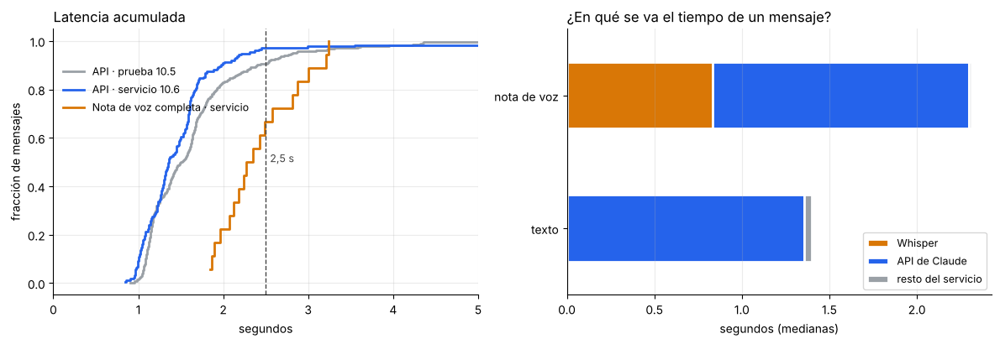

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for x, etq, col in [(prueba105.latencia_s, "API · prueba 10.5", "#9aa0a6"), (srv.latencia_s, "API · servicio 10.6", "#2563eb"),
                    (L[L.canal == "audio"].servidor_total_s, "Nota de voz completa · servicio", "#d97706")]:
    v = np.sort(x.values); ax[0].step(v, np.arange(1, len(v) + 1) / len(v), where="post", lw=2, label=etq, color=col)
ax[0].axvline(2.5, ls="--", color="#444", lw=1); ax[0].text(2.55, 0.5, "2,5 s", fontsize=9, color="#444")
ax[0].set_xlim(0, 5); ax[0].set_xlabel("segundos"); ax[0].set_ylabel("fracción de mensajes"); ax[0].legend(loc="upper left", fontsize=9, frameon=False, bbox_to_anchor=(0, 0.9))
ax[0].set_title("Latencia acumulada", loc="left"); ax[0].grid(alpha=.25)
comp = pd.DataFrame({"Whisper": [0, L[L.canal == "audio"].transcripcion_s.median()],
                     "API de Claude": [L[L.canal == "texto"].api_s.median(), L[L.canal == "audio"].api_s.median()]},
                    index=["texto", "nota de voz"])
comp["resto del servicio"] = [L[L.canal == "texto"].servidor_total_s.median(), L[L.canal == "audio"].servidor_total_s.median()] - comp.sum(axis=1)
comp.plot.barh(stacked=True, ax=ax[1], color=["#d97706", "#2563eb", "#9aa0a6"], width=.5, edgecolor="white", linewidth=2)
ax[1].set_xlabel("segundos (medianas)"); ax[1].set_title("¿En qué se va el tiempo de un mensaje?", loc="left"); ax[1].grid(axis="x", alpha=.25)
ax[1].legend(fontsize=9, loc="lower right")
for s in ("top", "right"):
    ax[0].spines[s].set_visible(False); ax[1].spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "latencia_servicio_10_6.png", dpi=130); plt.show()

**Conclusión 5 · El servicio responde rápido, también en la cola**
- **API de Claude dentro del servicio** (175 llamadas reales, sin caché, mensajes de desarrollo):

  | | Mediana | P95 | ≤ 2,5 s |
  |---|---|---|---|
  | Servicio 10.6 | **1,36 s** | **2,24 s** | **97,1 %** |
  | Prueba de la 10.5 | 1,51 s | 2,81 s | 90,6 % |

  - **Cumple el criterio del plan** (< 2,5 s, juzgado con la mediana), y esta vez el P95 también queda por debajo.
  - **Por qué baja la cola:** razonaron 25 de 175 llamadas (14,3 %), frente al 21,3 % de la prueba de la 10.5, con el mismo criterio de la 10.5 (más de 110 tokens de salida). Sin ellas, el P95 es 1,97 s.
  - **La comparación es orientativa:** son mensajes de desarrollo, no los de la prueba, que ya se usó. Los 3 casos más lentos (5,8–6,8 s) son llamadas sueltas, entre ellas la primera de la corrida.
  - **H30 queda cerrado como hallazgo explicado.**
- **Mensaje completo** (de que llega al webhook hasta que el evento queda guardado):
  - **Texto:** mediana 1,40 s y P95 2,25 s.
  - **Nota de voz:** mediana 2,31 s y P95 3,22 s; el 66,7 % en ≤ 2,5 s. Whisper toma 0,83 s de mediana: corrió en la GPU del PC, así que **H27 queda cerrado**.
- **La tabla del Módulo 12:** `GET /eventos/activos` con 155 eventos responde en 9,5 ms de mediana y 12,5 ms de P95.
- **Acciones de la corrida:** 157 eventos nuevos y 18 despejes, de los cuales 2 cerraron un evento y 16 quedaron como «despeje sin evento». Los mensajes del set son independientes, así que casi ningún despeje encuentra su evento. No hubo uniones.

## 6 · Lo que reciben los Módulos 12 y 13

- **Banco de eventos** (decisión f, sin llamar a la API): un evento 1.2 por cada mensaje distinto del set de la 10.3,
  armado con las extracciones de la 10.5 y la búsqueda tolerante. Son mensajes **sintéticos** con GPS real.
- **Calendario de eventos masivos** (decisiones j y k): lo registrado por SOBUSA más los partidos de Junior y de la Selección.
- **Guía de uso:** `NOTA_PARA_MODULO_12.md` (qué instalar según el uso: para leer los eventos no hace falta Whisper ni la API).

In [9]:
contrato = json.loads(Path("contrato_evento_10_2.json").read_text(encoding="utf-8"))
banco = pd.read_csv(E / "banco_eventos_m10.csv")
err = sum(len(validar_evento(json.loads(e), contrato)) > 0 for e in banco.evento_json)
print(f"Banco: {len(banco)} eventos ({(banco.canal == 'texto').sum()} de texto, {(banco.canal == 'audio').sum()} de voz) · "
      f"{int(banco.es_despeje.sum())} despejes · {int((banco.alcance == 'solo_bus').sum())} «mi bus» · fuera del contrato: {err}")
display(banco.groupby("tipo_evento").size().rename("eventos").to_frame().T)
display(pd.crosstab(banco.idruta, banco.confianza, margins=True))
check("banco: ≥ 500 eventos, todos en el contrato 1.2", len(banco) >= 500 and err == 0, f"{len(banco)} eventos")
db = sqlite3.connect(E / "latencia_10_6.sqlite")
ev_srv = [json.loads(r[0]) for r in db.execute("SELECT evento_json FROM tb_eventos_imprevistos_activos")]
db.close()
check("tabla del servicio (corrida de latencia): todos los eventos cumplen el contrato 1.2",
      all(len(validar_evento(e, contrato)) == 0 for e in ev_srv), f"{len(ev_srv)} eventos")

Banco: 580 eventos (520 de texto, 60 de voz) · 58 despejes · 41 «mi bus» · fuera del contrato: 0


tipo_evento,arroyo,bloqueo,choque,evento,obra,otro,semaforo,trancon,varado
eventos,67,55,85,47,70,51,48,88,69


confianza,alta,media,All
idruta,,,
2,188,6,194
16,178,15,193
21,182,11,193
All,548,32,580


In [10]:
amp = pd.read_csv(B / "calendario_eventos_masivos_ampliado_10_6.csv")
cal = pd.read_csv(B / "calendario_partidos_barranquilla_10_6.csv")
est = pd.read_csv(B / "estadios_10_6.csv")
print(f"Calendario ampliado: {len(amp)} eventos · de SOBUSA {int(amp.en_bd_sobusa.sum())} · partidos nuevos {int((~amp.en_bd_sobusa).sum())}")
display(pd.crosstab(cal.fecha.str[:4], [cal.equipo, cal.estadio]))
display(pd.crosstab(cal.precision_fecha, cal.precision_hora, margins=True))
display(est[["estadio", "capacidad"] + [c for c in est if c.startswith(("dist_min", "segmentos_800"))]])
sel = cal[(cal.equipo == "seleccion_colombia") & cal.en_periodo_datos_sobusa]
check("calendario: 28 eventos de SOBUSA + partidos; los 9 de la Selección 2023–2025 (8 con fecha de SOBUSA)",
      int(amp.en_bd_sobusa.sum()) == 28 and len(sel) == 9 and (sel.precision_fecha == "sobusa").sum() == 8)

Calendario ampliado: 184 eventos · de SOBUSA 28 · partidos nuevos 156


equipo         junior                  seleccion_colombia
estadio Metropolitano Romelio Martínez      Metropolitano
fecha                                                    
2020                0                0                  2
2021                0                0                  5
2022               34                0                  2
2023               25                0                  3
2024               31                0                  3
2025               32                0                  3
2026                1               23                  0

precision_hora,confirmada,sin_hora,All
precision_fecha,,,
agregador,0,6,6
api,99,0,99
espn_partido,0,7,7
prensa,33,11,44
sobusa,8,0,8
All,140,24,164


,estadio,capacidad,dist_min_ruta_2_m,segmentos_800m_ruta_2,dist_min_ruta_16_m,segmentos_800m_ruta_16,dist_min_ruta_21_m,segmentos_800m_ruta_21
0,Metropolitano,46788,248.9,7,247.6,7,249.2,7
1,Romelio Martínez,8600,717.4,3,771.9,1,102.0,10


**Conclusión 6 · Los Módulos 12 y 13 tienen eventos, calendario y una guía para usarlos**
- **Banco de eventos:** 580 eventos (520 de texto y 60 de voz), todos dentro del contrato 1.2, construidos sin llamar a la API.
  - Rutas 2 / 16 / 21: 194 / 193 / 193.
  - Incluye 58 despejes y 41 «mi bus»; 548 con confianza alta y 32 con media.
  - Son mensajes sintéticos con GPS real. **El simulador del Módulo 13 muestrea de aquí y nunca llama a la API.**
- **Calendario de eventos masivos:** 184 eventos, los 28 que registró SOBUSA más 156 partidos de Junior y de la Selección. Cada partido lleva su fuente y la precisión de su fecha y hora: 140 con hora y 24 solo con fecha.
- **Estadios:**
  - El **Metropolitano** queda a unos 249 m de las tres rutas.
  - El **Romelio Martínez**, sede de Junior desde el 18-ene-2026, queda a 102 m de la ruta 21 y a más de 700 m de las rutas 2 y 16.
- **`NOTA_PARA_MODULO_12.md`:** qué instalar según el uso. Para leer los eventos basta Python con pandas: no hacen falta Whisper, ni la API, ni GPU, ni la base de SOBUSA. Trae además los campos, el ciclo de vida, cómo consultar la tabla y los pendientes que son del Módulo 12.
- **Costo:** la etapa 5 costó USD 0,044, y el Módulo 10 completo, USD 0,113 (límite USD 20). La prueba de la 10.5 no se volvió a usar.
- **Siguiente paso natural:** conectar el GPS en vivo y el proveedor de mensajería real, que quedan documentados para después del proyecto, y hacer un piloto con mensajes de conductores reales.

## 7 · Costo y cumplimiento del presupuesto

In [11]:
costo = uso.groupby("corrida").agg(llamadas=("uid", "size"), costo_usd=("costo_usd", "sum")).round(4)
display(costo)
etapa5 = costo.loc[["desarrollo_v2_low", "miniset_10_6", "servicio_10_6"], "costo_usd"].sum()
print(f"Etapa 5 de la 10.6: USD {etapa5:.4f} · Módulo 10 completo: USD {uso.costo_usd.sum():.4f} (límite USD 20)")
check("presupuesto: el Módulo 10 completo cuesta < USD 1 y ninguna corrida pasó de 500 llamadas",
      uso.costo_usd.sum() < 1 and costo.llamadas.max() <= 500, f"USD {uso.costo_usd.sum():.4f}")
check("la prueba de la 10.5 no se volvió a usar (siguen 404 llamadas de «prueba»)", (uso.corrida == "prueba").sum() == 404)

,llamadas,costo_usd
corrida,,
desarrollo_v1_low,184,0.0208
desarrollo_v2_low,184,0.0208
miniset_10_6,39,0.0043
prueba,404,0.0480
servicio_10_6,175,0.0192


Etapa 5 de la 10.6: USD 0.0443 · Módulo 10 completo: USD 0.1131 (límite USD 20)


## Checks

In [12]:
CH = pd.DataFrame(CHECKS); display(CH)
CH.to_csv("datos_10/checks_10_6.csv", index=False)
print(f"{(CH.resultado == 'PASS').sum()}/{len(CH)} PASS")

,check,resultado,detalle
0,config_10_6: el hash del prompt v2 y del esquema coincide con lo congelado,PASS,
1,config_10_6: el hash de la configuración se recalcula igual,PASS,44be675af211
2,prompt v2: solo cambian el encabezado de la guía (1.4 → 1.5) y la línea del tipo «evento» (→ «evento masivo»),PASS,4 líneas
3,"regla e: v2 da F1 ≥ 0,99 en texto y audio en desarrollo (recalculado) y config lo registra",PASS,texto 0.9987 · audio 1.0000
4,métricas de desarrollo v2: el archivo es el que se congeló,PASS,
5,mini-set: el archivo evaluado es el congelado (hash del manifiesto y de config_10_6),PASS,
6,"mini-set: F1 ≥ 0,90 (recalculado)",PASS,1.0000
7,mini-set: se evaluó una sola vez (39 llamadas nuevas en uso_api.csv + 1 desde la caché),PASS,
8,H28: la búsqueda tolerante no empeora ningún mensaje y lleva el texto de la prueba al techo,PASS,96.14 % = techo
9,tests_10_6.py: todas las pruebas pasan,PASS,11/11 PASS


19/19 PASS


<a id="m11"></a>

---

## A2.3 &middot; Módulo 11 · Tráfico externo (Google Routes) y muestreo insesgado

**Qué aporta al pronóstico.** Los pasos GPS por tramo son la base de los tiempos por segmento del Módulo 12 y de la 13.1; con esos tiempos el e2c calcula la exposición planeada, feature de la capa 04:00.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m11-1"></a>

### A2.3.1 &middot; Módulo 11 · Tráfico externo y muestreo insesgado

<sub>Notebook original: `modulo11/modulo_11_resultados.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 11 — Tráfico externo con Google Maps Routes API y muestreo insesgado

Notebook de presentación del Módulo 11 (Entregable 2). **No llama a la API de Google:** la recolección (4.998 llamadas, plan gratuito, USD 0) se hizo una sola vez el 1-nov-2026 y quedó guardada en `datos_11/`. Aquí se cargan esos resultados, se muestran sus tablas y figuras y se ejecutan las pruebas del módulo (que simulan la API con un transporte falso). El detalle está en `resultados_modulo11.md`.

In [1]:
%matplotlib inline
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
D = Path("datos_11")

import os, subprocess, sys
def correr(*args, timeout=1800, ultimas=None):
    """Ejecuta un script del módulo con el mismo Python del notebook y muestra su salida."""
    env = {**os.environ, "PYTHONUTF8": "1", "PYTHONIOENCODING": "utf-8"}
    r = subprocess.run([sys.executable, *args], capture_output=True, text=True, encoding="utf-8", errors="replace",
                       env=env, timeout=timeout)
    salida = (r.stdout + ("\n" + r.stderr if r.returncode else "")).rstrip().splitlines()
    print("\n".join(salida if ultimas is None else salida[-ultimas:]))
    print(f"\n[código de salida {r.returncode}]")
    return r.returncode

## 11.1 · Diseño muestral estratificado

In [2]:
me = json.load(open(D / "margen_error_11_1.json", encoding="utf-8"))
print(json.dumps(me, ensure_ascii=False, indent=1)[:2500])
marco = pd.read_csv(D / "marco_estratos_11_1.csv")
asig = pd.read_csv(D / "asignacion_11_1.csv")
print(f"Estratos en el marco: {len(marco):,} · filas de asignación: {len(asig):,}")
display(marco.head(10))

{
 "plan": {
  "sigma": 0.15,
  "n": 2500,
  "z": 1.96,
  "E": 0.00588
 },
 "nota": "I_gps es el índice de congestión del BUS (incluye paradas), no el de Google: su dispersión es mayor que la de duration/staticDuration y el margen GPS es una cota pesimista. El σ real de Google se mide en la 11.3 con los pings recolectados.",
 "sin_permutacion": {
  "ponderacion": "flujo_x_sd",
  "n": 2500,
  "E_simple_sigma_gps": 0.025925783412222417,
  "sigma_gps_global": 0.6613720258220004,
  "E_estratificado_gps": 0.026578776344567377,
  "E_estratificado_sigma_plan": 0.006028099611153052
 },
 "con_permutacion": {
  "ponderacion": "unidades_x_sd",
  "n": 2500,
  "E_simple_sigma_gps": 0.025925783412222417,
  "sigma_gps_global": 0.6613720258220004,
  "E_estratificado_gps": 0.02108629051019142,
  "E_estratificado_sigma_plan": 0.004782396976342598
 }
}
Estratos en el marco: 162 · filas de asignación: 324


,estrato_id,idruta,criticidad,franja,franja_critica,tipo_dia,n_tramos,n_intervalos,N_unidades,n_pasos_gps,flujo_pasajeros,media_indice,sd_indice,sd_imputada
0,R2-baja-madrugada-laboral,2,baja,madrugada,False,laboral,42,8,336,426,117867.297468,1.215670,0.479518,False
1,R2-baja-madrugada-sabado,2,baja,madrugada,False,sabado,42,8,336,105,15793.632911,1.178914,0.383315,False
2,R2-baja-madrugada-domingo_festivo,2,baja,madrugada,False,domingo_festivo,42,8,336,19,4679.594937,1.158075,0.232158,False
3,R2-baja-pico_am-laboral,2,baja,pico_am,True,laboral,42,8,336,1455,379924.613924,1.428805,0.518405,False
4,R2-baja-pico_am-sabado,2,baja,pico_am,True,sabado,42,8,336,352,55570.189873,1.242405,0.347981,False
5,R2-baja-pico_am-domingo_festivo,2,baja,pico_am,True,domingo_festivo,42,8,336,184,18133.430380,1.117811,0.346859,False
6,R2-baja-valle_am-laboral,2,baja,valle_am,False,laboral,42,16,672,2855,391331.126582,1.357402,0.488059,False
7,R2-baja-valle_am-sabado,2,baja,valle_am,False,sabado,42,16,672,393,36266.860759,1.428335,0.612902,False
8,R2-baja-valle_am-domingo_festivo,2,baja,valle_am,False,domingo_festivo,42,16,672,515,49135.746835,1.198893,0.421334,False
9,R2-baja-valle_pm-laboral,2,baja,valle_pm,False,laboral,42,20,840,3418,498084.386076,1.436615,0.597034,False


## 11.2 · Recolección (tabla `tb_tiempos_viaje_google`)

estado,ok,sin_ruta
escenario,,
con_permutacion,2242,45
sin_permutacion,2326,51


Pings con índice de congestión: 4,568 de 4,664 · rango 0.52 – 2.29
Latencia de la API (ms): {'count': 4664.0, 'mean': 1407.0, 'std': 1770.0, 'min': 146.0, '50%': 664.0, '95%': 5045.0, 'max': 20184.0}


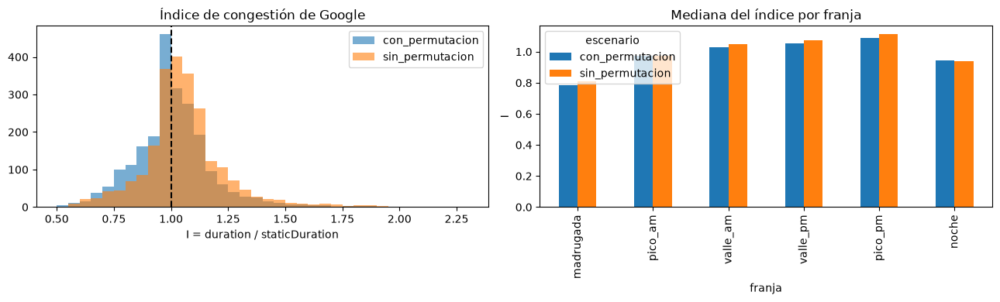

In [3]:
t = pd.read_parquet(D / "tb_tiempos_viaje_google.parquet")
display(t.groupby(["escenario", "estado"]).size().unstack(fill_value=0))
ok = t[t.congestion_index.notna()]
print(f"Pings con índice de congestión: {len(ok):,} de {len(t):,} · rango {ok.congestion_index.min():.2f} – {ok.congestion_index.max():.2f}")
print("Latencia de la API (ms):", t.latencia_ms.describe(percentiles=[.5, .95]).round(0).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for esc, g in ok.groupby("escenario"):
    ax[0].hist(g.congestion_index, bins=np.arange(0.5, 2.35, 0.05), alpha=0.6, label=esc)
ax[0].axvline(1, color="k", ls="--"); ax[0].set_xlabel("I = duration / staticDuration"); ax[0].legend(); ax[0].set_title("Índice de congestión de Google")
orden = ["madrugada", "pico_am", "valle_am", "valle_pm", "pico_pm", "noche"]
m = ok.groupby(["franja", "escenario"]).congestion_index.median().unstack().reindex(orden)
m.plot(kind="bar", ax=ax[1]); ax[1].set_title("Mediana del índice por franja"); ax[1].set_ylabel("I")
plt.tight_layout(); plt.show()

## 11.3 · Cobertura, validación contra el GPS y estimación del índice

,escenario,idruta,periodo,planeados,ok,sin_ruta,pendiente,cobertura_pct
0,con_permutacion,2,pico,260,253,2,5,97.307692
1,con_permutacion,2,valle,623,613,10,0,98.394864
2,con_permutacion,16,pico,244,242,2,0,99.180328
3,con_permutacion,16,valle,545,538,7,0,98.715596
4,con_permutacion,21,pico,258,167,9,82,64.728682
5,con_permutacion,21,valle,570,429,15,126,75.263158
6,con_permutacion,todas,todos,2500,2242,45,213,89.680000
7,sin_permutacion,2,pico,251,246,5,0,98.007968
8,sin_permutacion,2,valle,440,427,13,0,97.045455
9,sin_permutacion,16,pico,369,367,2,0,99.457995


,escenario,idruta,periodo,n,MAPE,MAPE_ponderado,MdAPE,razon_mediana_google_gps,MAPE_calibrado,MAPE_calibrado_ponderado,indice_google_medio
0,con_permutacion,2,pico,237,32.075,32.077,16.341,0.934,33.428,33.905,1.047
1,con_permutacion,2,valle,566,27.321,27.057,13.717,0.965,28.253,27.797,1.016
2,con_permutacion,16,pico,211,68.649,78.339,19.663,0.962,73.604,84.149,1.078
3,con_permutacion,16,valle,477,42.878,39.262,14.598,0.978,44.993,41.332,1.031
4,con_permutacion,21,pico,152,34.511,34.596,18.214,0.928,35.624,35.859,1.039
5,con_permutacion,21,valle,373,36.437,35.315,17.433,0.960,38.258,37.427,0.998
6,sin_permutacion,2,pico,235,29.559,28.034,15.022,0.940,31.023,30.016,1.074
7,sin_permutacion,2,valle,399,26.367,26.181,12.924,0.952,27.022,27.855,1.037
8,sin_permutacion,16,pico,339,47.197,53.754,19.089,0.924,49.561,56.809,1.108
9,sin_permutacion,16,valle,822,35.185,28.665,14.853,0.936,36.245,29.123,1.091


{
 "sin_permutacion": {
  "ponderacion": "flujo_pasajeros",
  "pings_ok": 2326,
  "validacion_vecinos": {
   "celdas_completas": 42,
   "media_entre_baja_y_alta_pct": 45.23809523809524,
   "error_imputacion_media": -0.018252518511476627,
   "error_imputacion_abs_mediano": 0.030513789709577965,
   "error_imputacion_abs_p90": 0.1212174944654085,
   "ecm_imputacion": 0.004323280895655636
  },
  "estratos_vacios": 12,
  "peso_vacio_pct": 4.045516210220895,
  "dominio_cubierto": {
   "media": 1.0621597773848548,
   "E95": 0.006140782331285124,
   "ic95": [
    1.0560189950535697,
    1.06830055971614
   ]
  },
  "red_completa_imputada": {
   "media": 1.0628215120302262,
   "E95": 0.006328713060130887,
   "ic95": [
    1.0564927989700954,
    1.069150225090357
   ],
   "aporte_de_los_imputados_a_la_varianza_pct": 13.314363427691216
  },
  "sensibilidad": {
   "vacios_menos_p90": 1.0579176386420044,
   "vacios_mas_p90": 1.0677253854184476
  },
  "si_se_completara_la_muestra": {
   "E95": 0.00

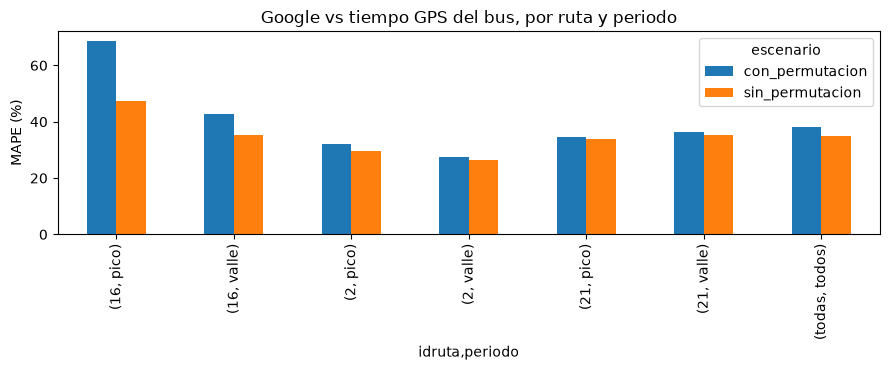

In [4]:
display(pd.read_csv(D / "cobertura_11_3.csv"))
met = pd.read_csv(D / "metricas_11_3.csv")
display(met.round(3))
est = json.load(open(D / "estimacion_indice_11_3.json", encoding="utf-8"))
print(json.dumps(est, ensure_ascii=False, indent=1)[:3000])
val = json.load(open(D / "validacion_11_3.json", encoding="utf-8"))
print(json.dumps({k: val[k] for k in ("pings_en_tabla", "pings_ok", "pings_con_referencia_gps", "global")}, ensure_ascii=False, indent=1)[:2500])
fig, ax = plt.subplots(figsize=(9, 3.8))
p = met.pivot_table(index=["idruta", "periodo"], columns="escenario", values="MAPE")
p.plot(kind="bar", ax=ax); ax.set_ylabel("MAPE (%)"); ax.set_title("Google vs tiempo GPS del bus, por ruta y periodo")
plt.tight_layout(); plt.show()

## 11.4 · Estudio de ablación y saturación del aporte de Google

,variante,descripcion,n,MAE,RMSE,WAPE,RMSE_vs_A_pct,MAE_vs_A_pct,pliegues_mejora_vs_anterior
0,0,Perfil histórico sin modelo,45800,31.550,65.929,28.006,NaN,NaN,NaN
1,A,Solo GPS SOBUSA (base),45800,30.515,61.653,27.088,NaN,NaN,NaN
2,B,GPS + Clima,45800,30.626,61.522,27.187,-0.212,0.365,2/6
3,C,GPS + Clima + Eventos M10,45800,30.640,61.459,27.198,-0.316,0.408,3/6
4,D,GPS + Clima + Eventos + Google (completo),45800,30.593,61.407,27.157,-0.399,0.257,5/6


,fraccion,semilla_submuestra,pings,pasos_con_google_tramo_franja,MAE_C,MAE_D,RMSE_C,RMSE_D,MAE_D_vs_C_pct,RMSE_D_vs_C_pct,pliegues_D_mejor
0,0.25,1,1142,32955,30.718,30.612,61.598,61.442,-0.345,-0.254,6/6
1,0.25,2,1142,32268,30.718,30.661,61.598,61.509,-0.184,-0.144,6/6
2,0.50,1,2284,53809,30.718,30.652,61.598,61.474,-0.214,-0.201,6/6
3,0.50,2,2284,54657,30.718,30.661,61.598,61.360,-0.184,-0.386,5/6
4,0.75,1,3426,68625,30.718,30.658,61.598,61.493,-0.194,-0.170,5/6
5,0.75,2,3426,69583,30.718,30.635,61.598,61.423,-0.269,-0.283,5/6
6,1.00,0,4568,80440,30.718,30.645,61.598,61.445,-0.235,-0.248,6/6


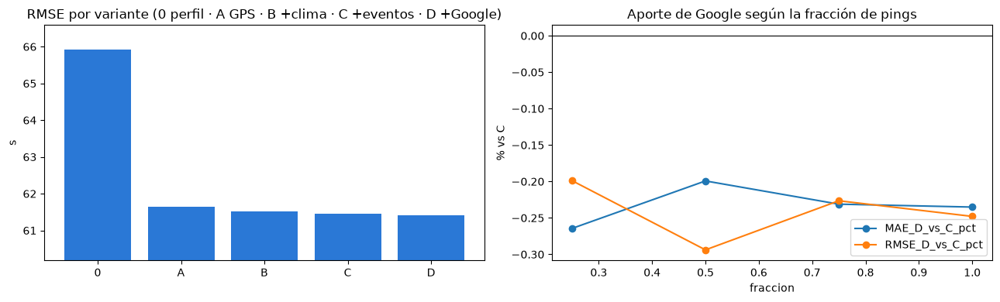

In [5]:
ab = pd.read_csv(D / "ablacion_11_4.csv")
tod = ab[ab.subconjunto == "todos"]
display(tod[["variante", "descripcion", "n", "MAE", "RMSE", "WAPE", "RMSE_vs_A_pct", "MAE_vs_A_pct", "pliegues_mejora_vs_anterior"]].round(3))
sat = pd.read_csv(D / "saturacion_google_11_4.csv")
display(sat.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(tod.variante, tod.RMSE, color="#2a78d6"); ax[0].set_ylim(tod.RMSE.min() * 0.98, tod.RMSE.max() * 1.01)
ax[0].set_title("RMSE por variante (0 perfil · A GPS · B +clima · C +eventos · D +Google)"); ax[0].set_ylabel("s")
s = sat.groupby("fraccion")[["MAE_D_vs_C_pct", "RMSE_D_vs_C_pct"]].mean()
s.plot(marker="o", ax=ax[1]); ax[1].axhline(0, color="k", lw=0.8); ax[1].set_title("Aporte de Google según la fracción de pings"); ax[1].set_ylabel("% vs C")
plt.tight_layout(); plt.show()

## Pruebas del módulo (API simulada, sin red)

In [6]:
correr("tests_11_2.py", ultimas=25)

PASS prueba_a_calendario: 1096 días 2023–2025 idénticos al calendario de la Persona 2
PASS prueba_b_solicitud: 12 solicitudes con Field Mask exacto, salida futura del tipo de día correcto y 3 puntos via
PASS prueba_c_respuesta: I = 150 / 100 = 1,5; 6 respuestas sin rutas guardadas como 'sin_ruta'
PASS prueba_d_cache: 2.ª corrida: 0 llamadas, 0 pendientes
PASS prueba_e_reintentos: 12 pings guardados al 3.er intento (503 → 429 → 200); 36 llamadas registradas
PASS prueba_f_error_400: 400: 1 llamada por ping, nada guardado; la corrida siguiente los completa
PASS prueba_g_fatal: 403: corrida detenida tras 1 llamada(s)
PASS prueba_h2_tope_por_escenario: base con 2.498 previas → solo 2 más (4 saltados), permutación intacta; reintentos cuentan (3 + 3)
PASS prueba_h_cuota: uso previo 4.998 → 2 llamadas; tope 5 → 5; reintentos cuentan (tope 7 → 7)
PASS prueba_i_clave_no_se_filtra: un error que repite la clave queda como *** en la base y en el log
PASS prueba_j_integridad: muestra alterada rechaz

0

In [7]:
correr("tests_11_3.py", ultimas=25)

PASS prueba_a_mape: MAPE 30,000 % en 4497 pings con referencia y en las 14 celdas
PASS prueba_b_calibrado: MAPE calibrado fuera de pliegue = 0
PASS prueba_c_cobertura: 5.000 = 4.890 ok + 10 sin ruta + 100 pendientes; detalle por ruta × pico/valle cuadra
PASS prueba_d_ks_literal: Google ×0,7 rechaza y se reporta como diferencia de nivel
PASS prueba_e_representatividad: con_permutacion: D 0.0206, p diseño 0.18; sin_permutacion: D 0.0105, p diseño 0.98
PASS prueba_f_google_igual_gps: Google = GPS → MAPE 0
PASS prueba_g_tabla_vacia: tabla vacía → «corra primero la recolección (11.2)»

7/7 PASS

[código de salida 0]


0

In [8]:
correr("tests_11_4.py", ultimas=25)

  pliegue 1: D MAE 30.96 s (47854 entrenamiento / 10484 validación)
  pliegue 2: A MAE 31.37 s (58338 entrenamiento / 10353 validación)
  pliegue 2: B MAE 31.35 s (58338 entrenamiento / 10353 validación)
  pliegue 2: C MAE 31.41 s (58338 entrenamiento / 10353 validación)
  pliegue 2: D MAE 31.36 s (58338 entrenamiento / 10353 validación)
  pliegue 3: A MAE 34.84 s (68691 entrenamiento / 4493 validación)
  pliegue 3: B MAE 34.89 s (68691 entrenamiento / 4493 validación)
  pliegue 3: C MAE 34.87 s (68691 entrenamiento / 4493 validación)
  pliegue 3: D MAE 34.87 s (68691 entrenamiento / 4493 validación)
  pliegue 4: A MAE 33.71 s (73184 entrenamiento / 8991 validación)
  pliegue 4: B MAE 33.67 s (73184 entrenamiento / 8991 validación)
  pliegue 4: C MAE 33.68 s (73184 entrenamiento / 8991 validación)
  pliegue 4: D MAE 33.65 s (73184 entrenamiento / 8991 validación)
  pliegue 5: A MAE 33.37 s (82175 entrenamiento / 5032 validación)
  pliegue 5: B MAE 33.35 s (82175 entrenamiento / 5032 va

0

<a id="m12"></a>

---

## A2.4 &middot; Módulo 12 · Reenrutamiento dinámico ante disrupciones (A*)

**Cómo se conecta.** Cuando un evento de gravedad ≥ 4 cierra un segmento, el bus se desvía y los segmentos saltados se quedan sin servicio; con la demanda e2c esos segmentos llevan la demanda pronosticada de ese día y hora, no un reparto fijo.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m12-1"></a>

### A2.4.1 &middot; Módulo 12 · Reenrutamiento dinámico

<sub>Notebook original: `modulo12/modulo_12_reenrutamiento.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 12 — Reenrutamiento dinámico ante disrupciones

**Requisito R1** del *Plan técnico v2.0* (`../ENTREGABLE3Plan_Modulos_9_en_adelante_SOBUSA-v2.pdf`): recalcular en tiempo real la ruta alterna óptima de un bus cuando un tramo queda bloqueado por un evento que reportó el Módulo 10 (arroyo, choque, bloqueo, obra…).

| Elemento | Decisión |
|---|---|
| Insumos | Solo archivos ya guardados: calles de OpenStreetMap y 386 segmentos (Módulo 10), banco de 580 eventos (Módulo 10), pasos GPS por tramo e índice de Google (Módulo 11), lecturas GPS reales (Módulo 1.3). **Ninguna llamada a API** (prueba f) |
| 12.1 Tiempos | Mediana de los pasos de bus por segmento × franja × tipo de día (franjas del Módulo 11), con respaldo jerárquico; pasos > 50 km/h descartados |
| 12.2 Grafo | Calles de OSM aptas para bus recortadas a un corredor de 1 km (área de cobertura) + segmentos de ruta cada 25 m + conectores ruta ↔ calle |
| 12.3 Penalización | Severidad ≥ 4 → w = ∞; 3 / 2 / 1 → tiempo × 2,0 / 1,5 / 1,2; `solo_bus` y despejes no tocan el grafo; sin «ambos sentidos» solo se afecta el sentido del bus |
| 12.4 Búsqueda | A* (heurística = distancia en línea recta / velocidad máxima), verificada con Dijkstra; regreso a la ruta elegido por la búsqueda (hasta 3 segmentos después del bloqueo, 60 s por segmento extra sin servicio) |
| 12.5 Validación | (a) banco de eventos del Módulo 10: minutos evitados y latencia; (b) **desvíos reales** del GPS: ¿el modelo reproduce el camino y el tiempo que hizo el bus? |
| Entregables | `src/routing/dynamic_rerouter.py` (+ `grafo_vial.py`, `validacion_desvios.py`), GeoJSON comparativos en `datos_12/geojson/`, `tb_rutas_alternas_12.csv`, `tests_12.py` |

## Parte 1 · Insumos (sin extracción)
El Módulo 12 no consulta la RDS ni ninguna API: todo sale de los archivos de los Módulos 10, 11 y 1.3. Esta celda solo verifica que existan.

In [1]:
from src.routing import grafo_vial as gv
import pandas as pd
estado = pd.DataFrame([{"insumo": k, "archivo": v, "existe": (gv.SOBUSA_DIR / v).exists()} for k, v in gv.ENTRADAS.items()])
display(estado)
assert estado.existe.all(), "faltan insumos"

,insumo,archivo,existe
0,segmentos,modulo10/datos_10/extraccion/q4_segmentos.csv,True
1,osm,modulo10/datos_10/insumos/osm_vias_barranquill...,True
2,banco,modulo10/datos_10/eventos/banco_eventos_m10.csv,True
3,desvios_zonas,modulo10/datos_10/desvios_zonas_10_1.csv,True
4,pasos_gps,modulo11/datos_11/pasos_tramo_gps_11_1.parquet,True
5,google,modulo11/datos_11/tb_tiempos_viaje_google.parquet,True
6,calendario,entrega_persona2_modulos_3_5/entrega_persona2_...,True
7,lecturas,datos_1_3/lecturas.csv,True
8,maestra,maestras/tb_maestra_entrenamiento.parquet,True


## Parte 2 · Análisis offline

In [2]:
import json
import math
import time
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from scipy.stats import spearmanr, wilcoxon

from src.routing import dynamic_rerouter as dr
from src.routing import validacion_desvios as vd
import tests_12 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
T0 = time.time()
SALIDA = gv.DATOS_12; SALIDA.mkdir(exist_ok=True); (SALIDA / "geojson").mkdir(exist_ok=True)
FIG = Path("resultados_12"); FIG.mkdir(exist_ok=True)
CHECKS = []
COLOR = {2: "#2a78d6", 16: "#e8892b", 21: "#7b4fbf"}


def check(nombre, ok, detalle="", info=False):
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


def figura(nombre):
    plt.tight_layout(); plt.savefig(FIG / nombre, dpi=110); plt.close(); display(Image(str(FIG / nombre)))


def guardar_geojson(nombre, gj):
    (SALIDA / "geojson" / f"{nombre}.geojson").write_text(json.dumps(gj, ensure_ascii=False, default=str), encoding="utf-8")


R = dr.ReenrutadorDinamico.desde_insumos()
G = R.G
banco = dr.cargar_banco()
print(f"Construcción del grafo y los pesos: {time.time() - T0:.1f} s · SOBUSA_DIR = {gv.SOBUSA_DIR}")

Construcción del grafo y los pesos: 10.2 s · SOBUSA_DIR = C:\Users\<usuario>\OneDrive\Escritorio\UNIVERSIDAD\2026\2026-3\MACHINE LEARNING\04_Data_Challenge_SOBUSA\Sobusa


## 1 · Subfase 12.1 — Tiempo de viaje por tramo

Pasos GPS del Módulo 11: 158,835; descartados por > 50 km/h: 19,850 (12.5 %)


De esos pasos, 36.7% están en los 6 primeros o 6 últimos segmentos (terminal); mediana 5.0 s por paso frente a 95 s de los válidos


,pct_celdas
fuente,
seg_franja_dia,72.2
seg_franja,16.3
seg,9.7
ruta_franja,1.8


,estimador,pasos_prueba,viajes_prueba,MAE_s,MdAE_s,MdAPE_%,WAPE_%
0,tabla franja × día (12.1),27342,283,32.49,16.97,18.19,28.11
1,línea base: mediana del segmento,27342,283,35.28,18.32,19.77,30.53


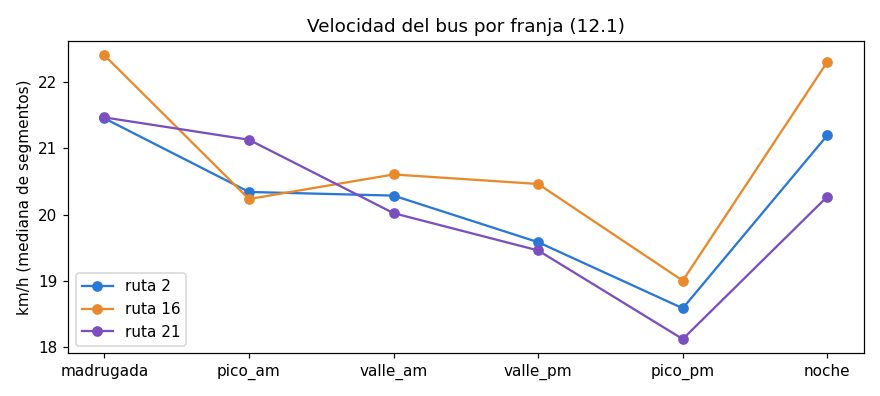

In [3]:
d = R.pasos_descartados
print(f"Pasos GPS del Módulo 11: {d['pasos_totales']:,}; descartados por > {d['v_max_kmh']:g} km/h: {d['descartados']:,} ({d['pct']:.1f} %)")
p_all = pd.read_parquet(gv.ruta_entrada("pasos_gps")).merge(gv.cargar_segmentos()[["idruta", "nro_segmento", "longitud_m"]])
p_all["v"] = p_all.longitud_m / p_all.duracion_s * 3.6
rap = p_all[p_all.v > 50]
por_seg = rap.groupby(["idruta", "nro_segmento"]).size().sort_values(ascending=False)
terminal = rap.nro_segmento.isin(list(range(1, 7))) | (rap.nro_segmento >= rap.idruta.map(p_all.groupby("idruta").nro_segmento.max()) - 5)
print(f"De esos pasos, {terminal.mean():.1%} están en los 6 primeros o 6 últimos segmentos (terminal); mediana {rap.duracion_s.median():.1f} s por paso "
      f"frente a {p_all[p_all.v <= 50].duracion_s.median():.0f} s de los válidos")
fuentes = R.tiempos.fuente.value_counts(normalize=True).rename("pct_celdas").mul(100)
display(fuentes.round(1).to_frame())
val = gv.validar_tiempos(gv.cargar_pasos(segmentos=gv.cargar_segmentos()), gv.cargar_segmentos())
val.to_csv(SALIDA / "validacion_tiempos_12_1.csv", index=False)
display(val.round(2))
R.tiempos.to_csv(SALIDA / "tiempos_segmento_12_1.csv", index=False)
v = R.tiempos.groupby(["idruta", "franja"]).v_kmh.median().unstack(0).reindex(gv.NOMBRES_FRANJA)
fig, ax = plt.subplots(figsize=(8, 3.6))
for r in v.columns:
    ax.plot(v.index, v[r], marker="o", color=COLOR[r], label=f"ruta {r}")
ax.set_ylabel("km/h (mediana de segmentos)"); ax.set_title("Velocidad del bus por franja (12.1)"); ax.legend()
figura("m12_velocidad_franja.png")
mej = val.set_index("estimador")["MdAPE_%"]
check("12.1 · la tabla por franja × día mejora a la línea base (MdAPE)", mej.iloc[0] < mej.iloc[1],
      f"{mej.iloc[0]:.1f} % vs {mej.iloc[1]:.1f} % en {int(val.pasos_prueba.iloc[0]):,} pasos de viajes reservados")
check("12.1 · pasos > 50 km/h descartados (hallazgo para el Módulo 11)", True, f"{d['descartados']:,} ({d['pct']:.1f} %), {terminal.mean():.0%} en la terminal", info=True)

**Conclusión 1 · Tiempos por tramo (12.1)**
- **Limpieza (hallazgo para el Módulo 11):** de los 158.835 pasos GPS del Módulo 11 se descartaron 19.850 (12,5 %) por superar 50 km/h, el límite urbano.
  - Duran una mediana de 5,0 s por segmento, frente a 95 s de los pasos válidos: son artefactos de ubicación, no buses.
  - El 37 % está en los 6 primeros o 6 últimos segmentos de cada circuito (la terminal). Ahí estaban todas las medianas imposibles, de hasta 786 km/h, que deformaban los pesos y la heurística.
  - La ablación del Módulo 11 usa estos mismos pasos como objetivo: conviene que su dueño lo revise.
- **Tabla:** 6.948 celdas (386 segmentos × 6 franjas × 3 tipos de día), sin huecos.
  - El 72,2 % sale del nivel más fino (segmento × franja × día); el 16,3 % de segmento × franja; el 9,7 % del segmento; el 1,8 % de la ruta.
- **Validación con 283 viajes reservados (27.342 pasos):** la tabla por franja × día mejora a la mediana simple del segmento.
  - MdAPE 18,2 % frente a 19,8 %; WAPE 28,1 % frente a 30,5 %; MAE 32,5 s frente a 35,3 s.
  - El error típico de un tramo de 500 m es de ~17 s: suficiente para comparar rutas, no para cronometrar paradas.

## 2 · Subfase 12.2 — Grafo vial y área de cobertura

,valor
osm_base,2026-10-28T04:12:51Z
ways_totales,16563
ways_corredor,7262
ways_excluidas_por_clase,"{'track': 18, 'footway': 1412, 'service': 1711, 'pedestrian': 96, 'path': 118, 'steps': 42, 'construction': 43, 'bus..."
nodos,33998
nodos_calle,26100
aristas,84975
aristas_calle,51627
aristas_ruta,7898
conectores,25450


,componentes_fuertes,nodos_componente_mayor,pct_nodos_en_mayor,pct_nodos_ruta_en_mayor
0,721,32845,96.61,100.0


franja,madrugada,pico_am,valle_am,valle_pm,pico_pm,noche
grupo,,,,,,
local,18.6,17.8,15.9,16.9,15.1,20.3
secundaria,24.2,20.3,20.5,18.3,15.9,22.3
terciaria,19.2,16.3,17.0,16.2,14.6,19.6
troncal,22.3,20.0,21.4,20.9,18.8,22.7


,segmentos,fuente
grupo,,
local,45,gps_bus
secundaria,114,gps_bus
terciaria,99,gps_bus
troncal,108,gps_bus


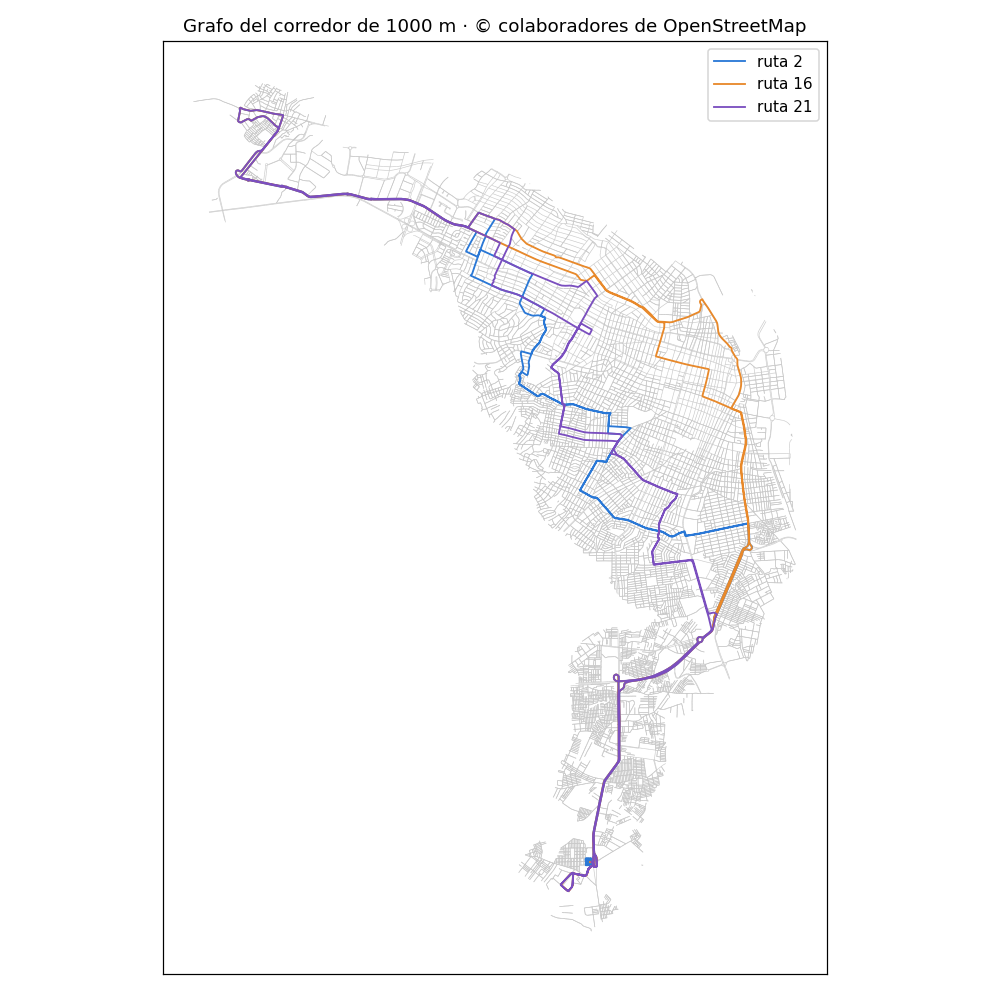

In [4]:
info = {k: v for k, v in G.info.items() if k not in ("config", "fuente_peso")}
display(pd.Series(info, dtype=object).to_frame("valor"))
res_g, en_mayor = gv.resumen_grafo(G)
display(res_g.round(2))
vel = R.velocidades
vel.to_csv(SALIDA / "velocidades_clase_12_2.csv", index=False)
display(vel[vel.tipo_dia == "laboral"].pivot(index="grupo", columns="franja", values="v_kmh")[list(gv.NOMBRES_FRANJA)].round(1))
display(vel.groupby("grupo").agg(segmentos=("segmentos", "max"), fuente=("fuente", "first")))
json.dump({**info, **res_g.iloc[0].to_dict()}, open(SALIDA / "grafo_resumen_12_2.json", "w"), indent=2, default=str)
fig, ax = plt.subplots(figsize=(9, 9))
eo = np.flatnonzero(G.tipo == gv.TIPO_OSM)
segs = np.stack([G.xy[G.org[eo]], G.xy[G.dst[eo]]], axis=1)
from matplotlib.collections import LineCollection
ax.add_collection(LineCollection(segs, colors="#c8c8c8", linewidths=0.4))
for r in G.nodos_ruta:
    X = G.xy[G.nodos_ruta[r]]; ax.plot(X[:, 0], X[:, 1], color=COLOR[r], lw=1.2, label=f"ruta {r}")
ax.set_aspect("equal"); ax.autoscale(); ax.legend(); ax.set_title(f"Grafo del corredor de {R.cfg.ancho_corredor_m:g} m · © colaboradores de OpenStreetMap")
ax.set_xticks([]); ax.set_yticks([])
figura("m12_grafo_corredor.png")
check("12.2 · todos los nodos de ruta en la componente fuertemente conexa principal", res_g.pct_nodos_ruta_en_mayor.iloc[0] == 100,
      f"{res_g.pct_nodos_ruta_en_mayor.iloc[0]:.1f} % · {res_g.pct_nodos_en_mayor.iloc[0]:.1f} % de todos los nodos")

**Conclusión 2 · Grafo vial (12.2)**
- **Sin descargas nuevas:** de las 16.563 calles del archivo de OpenStreetMap del Módulo 10, 7.262 caen en el corredor de 1 km. Se excluyen el carril exclusivo de Transmetro (`busway`), las vías de servicio, las peatonales y las que están en construcción.
- **Grafo:** 33.998 nodos (26.100 de calle) y 84.975 aristas: 51.627 de calle, 7.898 de ruta (los 386 segmentos cada 25 m) y 25.450 conectores ruta ↔ calle.
- **Conectividad:** el **100 % de los nodos de ruta** está en la componente fuertemente conexa principal (96,6 % de todos los nodos). Desde cualquier punto de una ruta se puede llegar a cualquier otro respetando los sentidos únicos.
- **Área de cobertura:** cada calle se recorta arista por arista al corredor, así que ninguna alterna puede salir de él (prueba c).
- **Velocidad del bus por tipo de vía** (calibrada con los segmentos de ruta; incluye paradas):
  - troncal 18,8–22,7 km/h; secundaria 15,9–24,2; terciaria 14,6–19,6; local 15,1–20,3;
  - el pico de la tarde es la franja más lenta en todas.
- **Límite:** el archivo de OSM del Módulo 10 solo trae **calles con nombre**. Faltan rampas y enlaces sin nombre, lo que pesa en los intercambiadores (Conclusión 6).

## 3 · Subfase 12.3 — Penalización por eventos (decisiones por defecto, configurables)

In [5]:
reglas = pd.DataFrame([{"severidad": s, "guia_conductor": g, "efecto": ("w = ∞ (bloqueo)" if s >= dr.UMBRAL_BLOQUEO else f"tiempo × {dr.FACTOR_SEVERIDAD[s]}")}
                       for s, g in [(1, "lento"), (2, "pare y siga"), (3, "un carril"), (4, "casi cerrada"), (5, "cerrada")]])
display(reglas)
display(pd.Series(dr.DURACION_DEFECTO_MIN, name="duracion_defecto_min").to_frame())
b = banco[(banco.alcance == "via") & ~banco.es_despeje]
print(f"Banco: {len(banco)} eventos · afectan la vía {len(b)} · solo_bus {int((banco.alcance == 'solo_bus').sum())} · despejes {int(banco.es_despeje.sum())}")
print(f"Duración dicha por el conductor en {b.duracion_estimada_min.notna().mean():.1%} de los eventos de vía; el resto usa la de su tipo")
print(f"Severidad ≥ {dr.UMBRAL_BLOQUEO} (bloqueo): {int((b.severidad >= dr.UMBRAL_BLOQUEO).sum())} eventos")
af = [len(R.aristas_afectadas(dr.Evento.desde_fila(f))[0]) for _, f in b.iterrows()]
print(f"Aristas afectadas por evento: mediana {np.median(af):.0f} (P10 {np.percentile(af, 10):.0f}, P90 {np.percentile(af, 90):.0f})")

,severidad,guia_conductor,efecto
0,1,lento,tiempo × 1.2
1,2,pare y siga,tiempo × 1.5
2,3,un carril,tiempo × 2.0
3,4,casi cerrada,w = ∞ (bloqueo)
4,5,cerrada,w = ∞ (bloqueo)


,duracion_defecto_min
trancon,30
choque,45
varado,30
obra,180
arroyo,60
bloqueo,90
evento,120
semaforo,20
otro,45


Banco: 580 eventos · afectan la vía 481 · solo_bus 41 · despejes 58
Duración dicha por el conductor en 49.5% de los eventos de vía; el resto usa la de su tipo
Severidad ≥ 4 (bloqueo): 188 eventos


Aristas afectadas por evento: mediana 59 (P10 33, P90 96)


**Conclusión 3 · Penalización por eventos (12.3)**
- **Pendientes de la `NOTA_PARA_MODULO_12.md` del Módulo 10**, resueltas con valores configurables, **confirmados por el dueño del módulo el 4-nov-2026**:
  1. «Severidad alta» = **4 y 5** (casi cerrada y cerrada) → w = ∞. Los niveles 3 / 2 / 1 multiplican el tiempo por 2,0 / 1,5 / 1,2.
  2. **Duración:** la que dijo el conductor (49,5 % de los eventos de vía). Si no la dijo, una por tipo: obra 180, evento masivo 120, bloqueo 90, arroyo 60, choque 45, trancón y varado 30, semáforo 20 min.
     - `fin_estimado` = recibido + duración (lo calcula el Módulo 12).
  3. `solo_bus` y despejes no tocan el grafo (99 de los 580 eventos del banco). Sin «ambos sentidos», solo se afecta el sentido del bus.
  4. El contrato 1.2 del Módulo 10 sirve tal como está: el Módulo 12 no pide cambios.
- **El bloqueo cubre la calle, no solo la línea de la ruta:** un evento afecta una mediana de 59 aristas (P10 33, P90 96), entre ellas la calle de OSM y las otras rutas que pasan encima. Sin eso, A* «esquivaría» el bloqueo por la misma calle.
- **En el banco:** 188 eventos llegan a bloqueo (nivel ≥ 4).

## 4 · Subfase 12.4 — A* y caso real: arroyo de la calle 85 con 49C (6-oct-2024)

,valor
estado,alterna
recomendacion,desviar
franja,valle_pm
tipo_dia,domingo_festivo
duracion_min,60.0
fuente_duracion,defecto_tipo
fin_estimado,2024-10-06 16:00:00
segmentos_bloqueados,[87]
segmento_origen,86
segmento_regreso,88


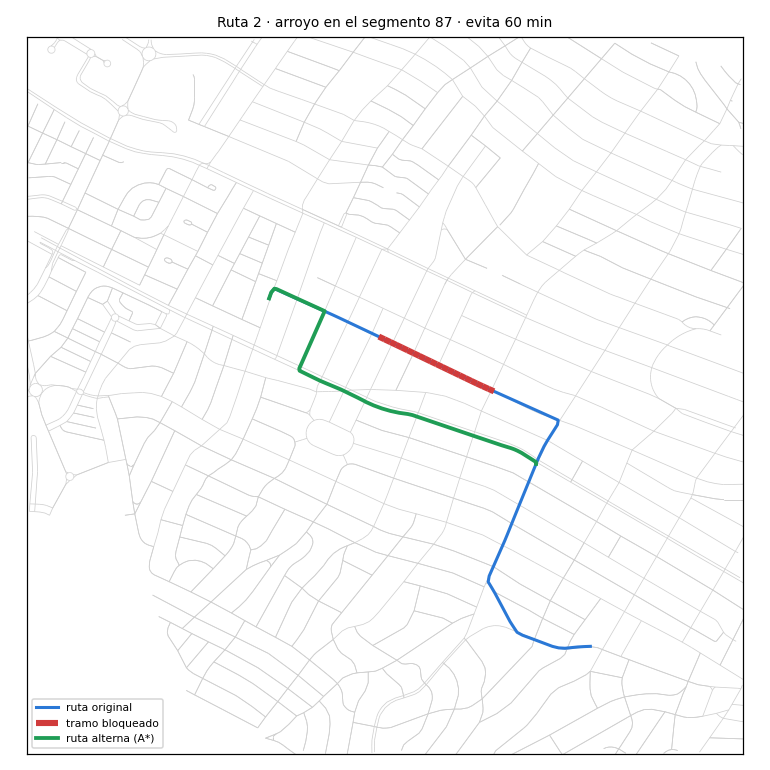

In [6]:
arroyo = dr.Evento("ARROYO-C85-C49C-20241006", 2, 87, "arroyo", 5, "via", "ambos", recibido=pd.Timestamp("2024-10-06 15:00"))
ra = R.reenrutar(arroyo, verificar_dijkstra=True)
vista = {k: ra[k] for k in ["estado", "recomendacion", "franja", "tipo_dia", "duracion_min", "fuente_duracion", "fin_estimado", "segmentos_bloqueados",
                            "segmento_origen", "segmento_regreso", "segmentos_saltados", "t_normal_s", "espera_s", "t_alterna_s", "costo_busqueda_s",
                            "costo_dijkstra_s", "minutos_evitados", "dif_recorrido_min", "km_ruta", "km_alterna", "calles", "nodos_expandidos",
                            "nodos_expandidos_dijkstra", "latencia_ms"]}
display(pd.Series(vista, dtype=object).to_frame("valor"))
guardar_geojson("arroyo_calle85_carrera49C_ruta2", R.geojson(ra))


def dibujar(ax, res, pts=None, caja=1800, titulo=""):
    cam = res.get("camino_nodos") or []
    ref = G.xy[cam].mean(0) if cam else G.xy[G.nodos_ruta[res["idruta"]][res["tramo_original"][0]]]
    m = (np.abs((G.xy[G.org] + G.xy[G.dst]) / 2 - ref) < caja).all(1) & (G.tipo == gv.TIPO_OSM)
    ax.add_collection(LineCollection(np.stack([G.xy[G.org[m]], G.xy[G.dst[m]]], 1), colors="#d0d0d0", linewidths=0.5))
    nodos = G.nodos_ruta[res["idruta"]]; n = len(nodos)
    if "tramo_original" in res:
        p0, p1 = res["tramo_original"]; X = G.xy[nodos[[(p0 + k) % n for k in range((p1 - p0) % n + 1)]]]
        ax.plot(X[:, 0], X[:, 1], color="#2a78d6", lw=2, label="ruta original")
    bl = res.get("aristas_bloqueadas_ruta", [])
    if len(bl):
        ax.add_collection(LineCollection(np.stack([G.xy[G.org[bl]], G.xy[G.dst[bl]]], 1), colors="#d03b3b", linewidths=4, label="tramo bloqueado"))
    if cam:
        Y = G.xy[cam]; ax.plot(Y[:, 0], Y[:, 1], color="#1f9d55", lw=2.5, label="ruta alterna (A*)")
    if pts is not None:
        ax.plot(pts[:, 0], pts[:, 1], "ko-", ms=3, lw=0.7, label="GPS real")
    ax.set_xlim(ref[0] - caja, ref[0] + caja); ax.set_ylim(ref[1] - caja, ref[1] + caja); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(titulo, fontsize=9); ax.legend(fontsize=7, loc="lower left")


fig, ax = plt.subplots(figsize=(7, 7))
dibujar(ax, ra, caja=1400, titulo=f"Ruta 2 · arroyo en el segmento 87 · evita {ra['minutos_evitados']:.0f} min")
figura("m12_arroyo_calle85.png")

In [7]:
# Latencia y optimalidad en todo el banco (la hora de cada evento elige sus pesos)
t1 = time.time()
tb = dr.evaluar_banco(R, banco, verificar_dijkstra=True)
consultas = tb[tb.estado != "sin_afectacion"]
ok = consultas.costo_dijkstra_s.notna()
iguales = np.isclose(consultas.loc[ok, "costo_busqueda_s"].replace(np.inf, -1), consultas.loc[ok, "costo_dijkstra_s"].replace(np.inf, -1), atol=1e-6).all()
lat = consultas.latencia_ms
print(f"{len(consultas)} consultas en {time.time() - t1:.1f} s · latencia mediana {lat.median():.1f} ms · P95 {lat.quantile(.95):.1f} ms · máx {lat.max():.1f} ms")
print(f"A* = Dijkstra: {iguales} · nodos expandidos A* {consultas.nodos_expandidos.median():.0f} vs Dijkstra {consultas.nodos_expandidos_dijkstra.median():.0f} (medianas)")
check("12.4 · latencia P95 < 100 ms (plan)", lat.quantile(.95) < 100, f"mediana {lat.median():.1f} ms · P95 {lat.quantile(.95):.1f} ms · máx {lat.max():.1f} ms")
check("12.4 · A* óptimo (= Dijkstra) en todas las consultas", bool(iguales), f"{int(ok.sum())} consultas")

480 consultas en 12.0 s · latencia mediana 10.5 ms · P95 18.8 ms · máx 91.5 ms
A* = Dijkstra: True · nodos expandidos A* 2183 vs Dijkstra 3798 (medianas)


**Conclusión 4 · A* y caso real (12.4)**
- **Arroyo de la calle 85 con 49C** (El Heraldo, 6-oct-2024; ruta 2, segmento 87; domingo, valle de la tarde; 60 min por defecto para un arroyo):
  - el bus se desvía por la Carrera 49C, la Calle 91 y la Avenida Carrera 46, y vuelve a su ruta en el segmento 88;
  - el desvío tarda 7,6 min frente a 7,4 min de la ruta normal (+0,2 min; 2,54 frente a 2,48 km), y **evita 59,8 min de espera**.
- **Optimalidad:** A* = Dijkstra en las 480 consultas del banco. A* expande una mediana de 2.183 nodos frente a 3.798 (en el arroyo, 2.621 frente a 5.463).
- **Latencia, criterio del plan < 100 ms:** mediana **10,5 ms**, **P95 18,8 ms**, máximo 91,5 ms. En la corrida de la prueba d hubo un pico aislado de 110 ms, con P95 de 19,9 ms.
- El grafo y los pesos se construyen una sola vez, en 10,2 s.

## 5 · Subfase 12.5 (a) — Escenarios simulados: banco de eventos del Módulo 10

In [8]:
tb.to_csv(SALIDA / "tb_rutas_alternas_12.csv", index=False)
tb.to_parquet(SALIDA / "tb_rutas_alternas_12.parquet", index=False)
display(pd.crosstab(tb.severidad, tb.estado, margins=True))
bloq = tb[(tb.severidad >= dr.UMBRAL_BLOQUEO) & (tb.estado != "sin_afectacion")]
alt = bloq[bloq.estado == "alterna"]
resumen = pd.DataFrame([{
    "eventos_bloqueo": len(bloq), "con_alterna": len(alt), "pct_con_alterna": 100 * len(alt) / len(bloq),
    "sin_alternativa": int((bloq.estado == "sin_alternativa").sum()),
    "min_evitados_mediana": alt.minutos_evitados.median(), "min_evitados_P90": alt.minutos_evitados.quantile(.9),
    "min_evitados_total": alt.minutos_evitados.sum(), "espera_evitada_mediana": alt.espera_evitada_min.median(),
    "dif_recorrido_mediana_min": alt.dif_recorrido_min.median(), "dif_recorrido_P90_min": alt.dif_recorrido_min.quantile(.9),
    "segmentos_saltados_mediana": alt.segmentos_saltados.map(lambda s: len(json.loads(s))).median(),
    "km_extra_mediana": (alt.km_alterna - alt.km_ruta).median()}])
display(resumen.round(2).T)
leves = tb[(tb.severidad < dr.UMBRAL_BLOQUEO) & (tb.estado != "sin_afectacion")]
print(f"Severidad 1–3 ({len(leves)} eventos): desviar en {(leves.estado == 'alterna').mean():.1%}; "
      f"minutos evitados mediana {leves.loc[leves.estado == 'alterna', 'minutos_evitados'].median():.1f}")
por_tipo = alt.groupby("tipo_evento").agg(n=("id_evento", "size"), min_evitados=("minutos_evitados", "median"),
                                          duracion=("duracion_min", "median"), dif_recorrido=("dif_recorrido_min", "median"))
display(por_tipo.round(1))
display(alt.groupby("idruta").agg(n=("id_evento", "size"), min_evitados=("minutos_evitados", "median"), km_extra=("km_alterna", "median")).round(2))

estado,alterna,seguir_con_demora,sin_alternativa,All
severidad,,,,
1.0,17,77,0,94
2.0,10,87,0,97
3.0,21,80,0,101
4.0,92,0,2,94
5.0,92,0,2,94
All,232,244,4,480


,0
eventos_bloqueo,188.00
con_alterna,184.00
pct_con_alterna,97.87
sin_alternativa,4.00
min_evitados_mediana,49.98
min_evitados_P90,178.13
min_evitados_total,13288.46
espera_evitada_mediana,45.00
dif_recorrido_mediana_min,0.81
dif_recorrido_P90_min,5.21


Severidad 1–3 (292 eventos): desviar en 16.4%; minutos evitados mediana 4.6


,n,min_evitados,duracion,dif_recorrido
tipo_evento,,,,
arroyo,19,59.6,60.0,1.4
bloqueo,20,87.4,90.0,1.1
choque,36,44.7,45.0,1.2
evento,9,119.7,120.0,0.2
obra,26,128.4,135.0,1.0
otro,22,44.1,45.0,1.0
semaforo,13,19.2,20.0,0.7
trancon,29,31.9,30.0,0.5
varado,10,32.4,30.0,0.4


,n,min_evitados,km_extra
idruta,,,
2,66,54.60,2.64
16,51,55.06,2.92
21,67,46.00,2.61


In [9]:
# Sensibilidad: cada fila cambia UNA decisión y vuelve a reenrutar los eventos de bloqueo del caso base
base_ids = set(bloq.id_evento)
sub = banco[banco.id_evento.isin(base_ids)]
def resumir(nombre, d):
    a = d[d.estado == "alterna"]
    return {"escenario": nombre, "pct_con_alterna": 100 * len(a) / len(d), "min_evitados_mediana": a.minutos_evitados.median(),
            "min_evitados_total": a.minutos_evitados.sum(), "dif_recorrido_mediana": a.dif_recorrido_min.median(), "latencia_P95": d.latencia_ms.quantile(.95)}
sens = [resumir("base", tb[tb.id_evento.isin(base_ids)])]
for k in (0.5, 2.0):
    sens.append(resumir(f"duración × {k:g}", pd.DataFrame([dr.resultado_a_fila(R.reenrutar(dr.Evento.desde_fila(f), espera_min=dr.duracion_min(dr.Evento.desde_fila(f))[0] * k)) for _, f in sub.iterrows()])))
for pen in (0.0, 180.0):
    R.penal_saltado_s = pen
    sens.append(resumir(f"penalización por segmento saltado = {pen:g} s", dr.evaluar_banco(R, sub)))
R.penal_saltado_s = dr.PENAL_SEGMENTO_SALTADO_S
cfg0 = R.cfg
R.cfg = replace(cfg0, factor_terciaria=1.0, factor_local=1.0)
sens.append(resumir("sin preferencia por vías principales", dr.evaluar_banco(R, sub)))
R.cfg = cfg0
R_g = dr.ReenrutadorDinamico(G, gv.calcular_pesos(G, R.tiempos, R.velocidades, R.cfg, usar_google=True), R.cfg, calendario=R.calendario)
sens.append(resumir("con índice de Google (Módulo 11) en calles sin GPS", dr.evaluar_banco(R_g, sub)))
for ancho in (500.0, 1500.0):
    Rc = dr.ReenrutadorDinamico.desde_insumos(replace(gv.CFG, ancho_corredor_m=ancho))
    sens.append(resumir(f"corredor de {ancho:g} m", dr.evaluar_banco(Rc, sub)))
sens = pd.DataFrame(sens)
sens.to_csv(SALIDA / "sensibilidad_12_5.csv", index=False)
display(sens.round(2))

,escenario,pct_con_alterna,min_evitados_mediana,min_evitados_total,dif_recorrido_mediana,latencia_P95
0,base,97.87,49.98,13288.46,0.81,20.60
1,duración × 0.5,97.34,25.97,6548.65,0.78,20.79
2,duración × 2,97.87,94.98,26773.46,0.81,20.31
3,penalización por segmento saltado = 0 s,97.87,49.98,13336.94,0.56,18.15
4,penalización por segmento saltado = 180 s,97.87,48.82,13121.06,1.32,25.98
5,sin preferencia por vías principales,97.87,50.74,13352.50,0.58,20.48
6,con índice de Google (Módulo 11) en calles sin GPS,97.87,49.96,13290.39,0.76,20.98
7,corredor de 500 m,82.98,47.08,11072.76,0.53,54.91
8,corredor de 1500 m,100.00,49.98,13534.16,0.90,23.55


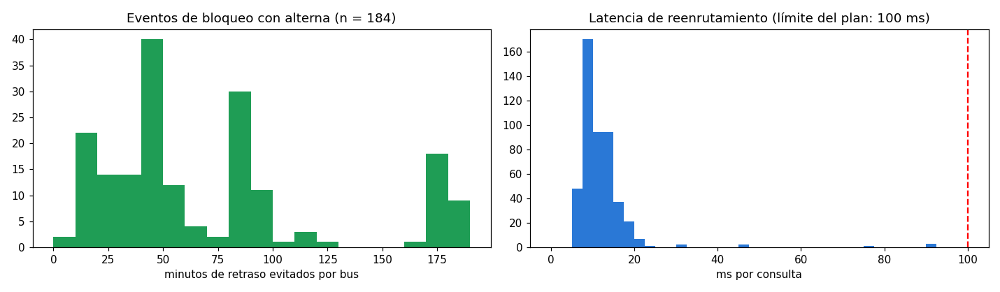

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(alt.minutos_evitados, bins=np.arange(0, 200, 10), color="#1f9d55")
ax[0].set_xlabel("minutos de retraso evitados por bus"); ax[0].set_title(f"Eventos de bloqueo con alterna (n = {len(alt)})")
ax[1].hist(lat, bins=np.arange(0, lat.max() + 5, 2.5), color="#2a78d6"); ax[1].axvline(100, color="r", ls="--")
ax[1].set_xlabel("ms por consulta"); ax[1].set_title("Latencia de reenrutamiento (límite del plan: 100 ms)")
figura("m12_minutos_latencia.png")
# GeoJSON de los ejemplos con más minutos evitados por ruta
for r, g in alt.groupby("idruta"):
    f = banco[banco.id_evento == g.sort_values("minutos_evitados").id_evento.iloc[-1]].iloc[0]
    guardar_geojson(f"ejemplo_ruta{r}_{f.id_evento}", R.geojson(R.reenrutar(dr.Evento.desde_fila(f))))
check("12.5a · eventos de bloqueo con ruta alterna", len(alt) / len(bloq) > 0.9,
      f"{len(alt)} de {len(bloq)} ({100 * len(alt) / len(bloq):.1f} %); mediana {alt.minutos_evitados.median():.1f} min evitados")

**Conclusión 5 · Escenarios simulados (12.5 a)**
- **Bloqueos (nivel 4–5): 184 de 188 eventos tienen ruta alterna (97,9 %).** Los 4 sin alternativa dentro del corredor están junto a las terminales (ruta 2, segmento 128; ruta 16, segmentos 8, 115 y 116): ahí la respuesta es esperar.
- **Minutos de retraso evitados por bus: mediana 50,0** (P90 178,1). Suman 13.288 min en los 184 eventos.
  - Casi todo es **espera evitada** (mediana 45 min).
  - El desvío cuesta una mediana de +0,8 min de recorrido (P90 +5,2), salta 2 segmentos y agrega 0,16 km.
- **Los minutos evitados dependen sobre todo de la duración supuesta.** Con la duración × 0,5 la mediana cae a 26,0 min; con × 2 sube a 95,0.
  - Suponen que el bus llega al inicio del evento y esperaría todo el resto: son una **cota superior** del beneficio por evento.
- **Por tipo (mediana):** obra 128,4 min, evento masivo 119,7, bloqueo 87,4, arroyo 59,6, choque 44,7, trancón 31,9, semáforo 19,2.
- **Severidad 1–3 (292 eventos):** desviar conviene solo en el 16,4 % (mediana 4,6 min). En el resto, seguir por la ruta lenta sigue siendo lo mejor.
- **Sensibilidad (eventos de bloqueo):**
  - penalización por segmento saltado de 0 o 180 s: mediana 50,0 / 48,8 min;
  - sin preferencia por vías principales: 50,7;
  - **con el índice de Google: 50,0 (sin cambio, igual que concluyó el Módulo 11)**;
  - **corredor de 500 m: solo 83,0 % con alterna**; de 1.500 m: 100 %. El corredor de 1 km cubre el 97,9 % sin agrandar el grafo.

## 6 · Subfase 12.5 (b) — Validación con desvíos reales del GPS

In [11]:
t1 = time.time()
lect = vd.cargar_trayectorias()
ep, pts = vd.episodios_desvio(lect, gv.cargar_segmentos())
print(f"{lect.idprogramacion.nunique():,} viajes con GPS · {len(ep)} episodios fuera de ruta con regreso ({time.time() - t1:.0f} s)")
display(ep.groupby("zona").agg(episodios=("episodio", "size"), metros_saltados=("metros_saltados", "median"),
                               dist_max_m=("dist_max_m", "median"), minutos_fuera=("minutos_fuera", "median"),
                               desde=("anio_mes", "min"), hasta=("anio_mes", "max")).sort_values("episodios", ascending=False).round(0))
cal, eva = ep[ep.idprogramacion % 2 == 0], ep[ep.idprogramacion % 2 == 1]
print(f"Calibración (idprogramacion par): {len(cal)} · Evaluación (impar, no se usa para elegir nada): {len(eva)}")
grilla = vd.calibrar_factores(R, cal, pts)
grilla.to_csv(SALIDA / "calibracion_factores_12_5.csv", index=False)
display(grilla.round(2))
mejor = grilla.iloc[0]
check("12.5b · factores del código = los mejores en calibración", (mejor.factor_terciaria, mejor.factor_local) == (R.cfg.factor_terciaria, R.cfg.factor_local),
      f"terciaria {mejor.factor_terciaria:g}, local {mejor.factor_local:g}")

1,673 viajes con GPS · 952 episodios fuera de ruta con regreso (47 s)


,episodios,metros_saltados,dist_max_m,minutos_fuera,desde,hasta
zona,,,,,,
Z3,353,2040.0,557.0,6.0,2023-01,2024-12
Z1,300,2025.0,820.0,6.0,2023-03,2025-10
Z4,128,2227.0,614.0,9.0,2024-03,2025-12
Z7,69,1170.0,247.0,9.0,2024-02,2025-10
sin_zona,18,1262.0,968.0,16.0,2023-01,2025-12
Z16,13,650.0,238.0,8.0,2024-02,2025-11
Z8,13,955.0,238.0,5.0,2024-03,2025-03
Z6,13,1225.0,459.0,8.0,2023-02,2025-11
Z10,10,832.0,302.0,7.0,2023-10,2025-09


Calibración (idprogramacion par): 483 · Evaluación (impar, no se usa para elegir nada): 469


,factor_terciaria,factor_local,episodios,cobertura_media_100m,pct_episodios_cob_50_a_100m
0,2.0,2.0,444,20.39,19.05
1,2.0,3.0,444,19.60,18.01
2,1.5,2.0,444,19.56,17.60
3,1.0,1.0,444,19.52,18.84
4,1.5,3.0,444,19.07,17.60
5,1.0,2.0,444,18.94,18.43
6,1.0,3.0,444,18.37,17.81
7,2.0,5.0,444,18.20,16.98
8,1.5,5.0,444,17.20,16.36
9,1.0,5.0,444,13.84,10.97


In [12]:
t1 = time.time()
ce = vd.comparar_con_alterna(R, eva, pts)
ce.drop(columns=["segmentos_saltados"]).to_csv(SALIDA / "desvios_reales_evaluacion_12_5.csv", index=False)
print(f"Evaluación: {len(ce)} episodios ({time.time() - t1:.0f} s); con camino {ce.t_pred_min.notna().sum()}")
filas = []
for rad in (50, 100, 200):
    a, b = ce[f"cob_tiempo_{rad}"], ce[f"cob_distancia_{rad}"]
    m = a.notna() & b.notna()
    w = wilcoxon(a[m], b[m]) if (a[m] != b[m]).any() else None
    filas.append({"radio_m": rad, "cobertura_media_tiempo": a.mean(), "cobertura_media_distancia": b.mean(),
                  "pct_cob50_tiempo": 100 * (a >= 50).mean(), "pct_cob50_distancia": 100 * (b >= 50).mean(),
                  "episodios_mejora_tiempo": int((a[m] > b[m]).sum()), "episodios_mejora_distancia": int((a[m] < b[m]).sum()),
                  "p_wilcoxon": w.pvalue if w else np.nan})
cob = pd.DataFrame(filas)
cob.to_csv(SALIDA / "cobertura_desvios_12_5.csv", index=False)
display(cob.round(3))
m = ce.t_pred_min.notna() & (ce.minutos_fuera > 0)
razon = ce.loc[m, "t_pred_min"] / ce.loc[m, "minutos_fuera"]
mdape = 100 * (np.abs(ce.loc[m, "t_pred_min"] - ce.loc[m, "minutos_fuera"]) / ce.loc[m, "minutos_fuera"]).median()
rho = spearmanr(ce.loc[m, "t_pred_min"], ce.loc[m, "minutos_fuera"])
tiempo = pd.DataFrame([{"episodios": int(m.sum()), "min_real_mediana": ce.loc[m, "minutos_fuera"].median(), "min_predicho_mediana": ce.loc[m, "t_pred_min"].median(),
                        "razon_mediana_pred_real": razon.median(), "MdAPE_%": mdape, "spearman": rho.statistic, "p_spearman": rho.pvalue}])
display(tiempo.round(3))
display(ce.groupby("zona").agg(n=("episodio", "size"), cob100_tiempo=("cob_tiempo_100", "mean"), cob100_distancia=("cob_distancia_100", "mean"),
                               min_real=("minutos_fuera", "median"), min_pred=("t_pred_min", "median")).sort_values("n", ascending=False).round(1))
c100 = cob.set_index("radio_m").loc[100]
check("12.5b · coincidencia con el camino real (100 m, evaluación)", True,
      f"tiempo {c100.cobertura_media_tiempo:.1f} % vs distancia {c100.cobertura_media_distancia:.1f} % (Wilcoxon p {c100.p_wilcoxon:.3f})", info=True)
check("12.5b · tiempo predicho vs tiempo real fuera de ruta", True,
      f"razón mediana {razon.median():.2f} · MdAPE {mdape:.1f} % · Spearman {rho.statistic:.2f}", info=True)

Evaluación: 469 episodios (16 s); con camino 434


,radio_m,cobertura_media_tiempo,cobertura_media_distancia,pct_cob50_tiempo,pct_cob50_distancia,episodios_mejora_tiempo,episodios_mejora_distancia,p_wilcoxon
0,50,16.315,15.812,14.286,13.220,36,14,0.280
1,100,20.710,19.801,18.550,16.631,39,14,0.020
2,200,26.285,25.947,21.109,19.829,26,11,0.182


,episodios,min_real_mediana,min_predicho_mediana,razon_mediana_pred_real,MdAPE_%,spearman,p_spearman
0,434,6.25,17.764,2.69,168.99,0.154,0.001


,n,cob100_tiempo,cob100_distancia,min_real,min_pred
zona,,,,,
Z3,169,10.1,10.1,5.6,17.9
Z1,159,4.4,3.9,6.2,18.6
Z4,53,49.4,31.4,9.0,12.9
Z7,38,78.0,79.5,9.0,6.7
sin_zona,10,44.1,44.1,12.4,6.3
Z16,9,73.8,94.9,7.4,4.4
Z8,8,35.6,61.5,5.9,5.4
Z6,6,58.7,54.1,9.4,14.2
Z10,5,58.3,62.5,5.9,5.0


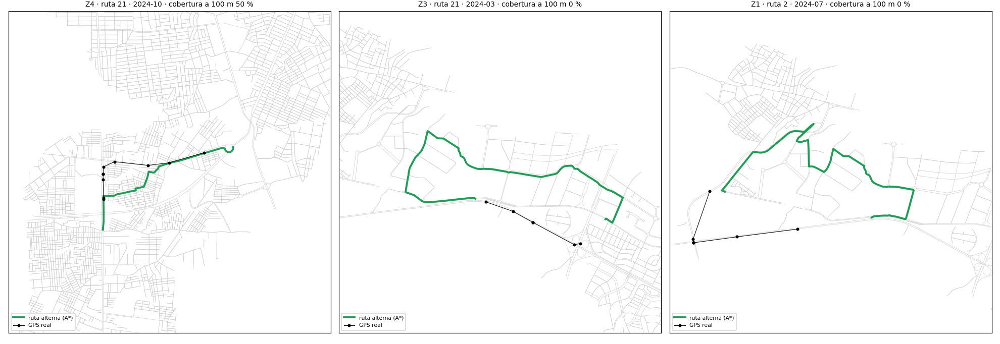

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6.2))
for ax, z in zip(axs, ["Z4", "Z3", "Z1"]):
    g = ce[(ce.zona == z) & ce.t_pred_min.notna()]
    if not len(g):
        ax.axis("off"); continue
    e = g.sort_values("cob_tiempo_100").iloc[len(g) // 2]           # episodio mediano de la zona
    a = vd.alterna_mismos_extremos(R, e)
    res = {"idruta": int(e.idruta), "camino_nodos": a["camino"]}
    dibujar(ax, res, pts[e.episodio], caja=2200, titulo=f"{z} · ruta {e.idruta} · {e.anio_mes} · cobertura a 100 m {e.cob_tiempo_100:.0f} %")
    gj = {"type": "FeatureCollection", "features": [
        dr._linea(G, a["camino"], {"capa": "ruta_alterna_modelo", "color": "#1f9d55"}),
        {"type": "Feature", "properties": {"capa": "gps_real", "color": "#000000"}, "geometry": {"type": "LineString", "coordinates":
            [[round(float(lo), 7), round(float(la), 7)] for la, lo in zip(*gv.rv.a_latlon(pts[e.episodio]))]}}]}
    guardar_geojson(f"desvio_real_{z}_episodio{e.episodio}", gj)
figura("m12_desvios_reales.png")

**Conclusión 6 · Desvíos reales del GPS (12.5 b)**
- **Episodios:** en 1.673 viajes con GPS hay **952 desvíos reales** (el bus sale de su ruta y vuelve más adelante). El 82 % está en las zonas Z3 (353), Z1 (300) y Z4 (128) del Módulo 10. Mediana: 2,0 km saltados y 6,4 min fuera.
- **Calibración** (483 episodios, viajes pares) del factor de preferencia por vías principales: terciaria × 2 y local × 2 da la mejor coincidencia a 100 m (20,4 % frente a 19,5 % sin factor). Es una mejora pequeña.
- **Evaluación** (469 episodios, viajes impares, con los mismos puntos de salida y regreso): coincidencia media con el camino real a 100 m de **20,7 % con tiempos, frente a 19,8 %** con la línea base de solo distancia.
  - Mejora en 39 episodios y empeora en 14 (Wilcoxon p = 0,020).
  - A 50 m: 16,3 % frente a 15,8 % (p = 0,28). A 200 m: 26,3 % frente a 25,9 % (p = 0,18).
- **Funciona en la ciudad, falla en los intercambiadores:**
  - **Z4: 49,4 % frente a 31,4 %; Z7: 78,0 %.** El tiempo predicho es del mismo orden que el real (Z4: 12,9 frente a 9,0 min; Z7: 6,7 frente a 9,0).
  - **Z3 (10,1 %) y Z1 (4,4 %)**, junto a la Circunvalar y la Vía al Mar: incluso el camino más corto del grafo mide 5,3–5,5 km, frente a los ~2,4–3,4 km que hizo el bus por la autopista, a 28–34 km/h.
    - **Al grafo le faltan las rampas sin nombre** (Conclusión 2), por eso ahí el modelo predice ~18 min frente a ~6 reales.
- **En total**, el tiempo predicho es 2,69 veces el real (mediana; Spearman 0,15).
  - En esas zonas los minutos evitados de la Conclusión 5 son **conservadores**: la alterna real es más corta.
  - Además, muchos episodios de Z1 y Z3 son **variantes de servicio** que duraron meses, no desvíos por un evento.
- **Siguiente paso natural:** completar el grafo con las vías sin nombre de OSM en una descarga única, que haría el dueño del Módulo 10.

## 7 · Pruebas y checks

In [14]:
pruebas = T.correr_todos(R, banco)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_12.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")
print("GeoJSON:", sorted(p.name for p in (SALIDA / "geojson").glob("*.geojson")))

,check,resultado,detalle
0,12.1 · la tabla por franja × día mejora a la línea base (MdAPE),PASS,"18.2 % vs 19.8 % en 27,342 pasos de viajes reservados"
1,12.1 · pasos > 50 km/h descartados (hallazgo para el Módulo 11),INFO,"19,850 (12.5 %), 37% en la terminal"
2,12.2 · todos los nodos de ruta en la componente fuertemente conexa principal,PASS,100.0 % · 96.6 % de todos los nodos
3,12.4 · latencia P95 < 100 ms (plan),PASS,mediana 10.5 ms · P95 18.8 ms · máx 91.5 ms
4,12.4 · A* óptimo (= Dijkstra) en todas las consultas,PASS,480 consultas
5,12.5a · eventos de bloqueo con ruta alterna,PASS,184 de 188 (97.9 %); mediana 50.0 min evitados
6,12.5b · factores del código = los mejores en calibración,PASS,"terciaria 2, local 2"
7,"12.5b · coincidencia con el camino real (100 m, evaluación)",INFO,tiempo 20.7 % vs distancia 19.8 % (Wilcoxon p 0.020)
8,12.5b · tiempo predicho vs tiempo real fuera de ruta,INFO,razón mediana 2.69 · MdAPE 169.0 % · Spearman 0.15
9,Test a · A* = Dijkstra,PASS,480 consultas: A* = Dijkstra (error < 1e-6 s); A* expande 37% menos nodos


PASS 16 · FAIL 0 · INFO 4
GeoJSON: ['arroyo_calle85_carrera49C_ruta2.geojson', 'desvio_real_Z1_episodio538.geojson', 'desvio_real_Z3_episodio397.geojson', 'desvio_real_Z4_episodio629.geojson', 'ejemplo_ruta16_EV-ebe96ef7e62c.geojson', 'ejemplo_ruta21_EV-c169adc757bd.geojson', 'ejemplo_ruta2_EV-d9de13829385.geojson']


**Conclusión 7 · Pruebas**
- **16 PASS, 0 FAIL, 4 INFO.** Pasan las **10 de 10 pruebas** (`py -3.10 tests_12.py`):
  - **a)** A* = Dijkstra en 480 consultas, con 37 % menos nodos expandidos;
  - **b)** ninguna alterna usa una arista bloqueada; `solo_bus` y despejes no tocan el grafo;
  - **c)** el grafo no sale del corredor;
  - **d)** latencia P95 < 100 ms;
  - **e)** heurística admisible en 2.000 nodos;
  - **f)** ningún archivo importa clientes de API;
  - **g)** determinismo;
  - **h)** tabla 12.1 sin huecos y ≤ 50 km/h;
  - **i)** el bus vuelve después del bloqueo;
  - **j)** duración y `fin_estimado`.
- **Ejecución:** 4,4 min. **Ninguna llamada a API** (Google, Claude ni OSM) durante el módulo.

## Síntesis para el jurado y pendientes

| Pregunta del plan | Respuesta |
|---|---|
| ¿Recalcula la ruta alterna cuando un evento bloquea la vía? | Sí: **97,9 %** de los 188 bloqueos del banco del Módulo 10 tienen alterna dentro del área de cobertura |
| ¿Cuántos minutos de retraso evita por bus? | **Mediana 50 min** por evento de bloqueo (cota superior: casi todo es la espera evitada); el desvío suma +0,8 min de recorrido |
| ¿Cumple < 100 ms por consulta? | Sí: **P95 18,8 ms**, mediana 10,5 ms |
| ¿Es óptimo? | A* = Dijkstra en las 480 consultas |
| ¿Se parece a lo que hacen los buses? | En zonas urbanas sí (Z4 49 %, Z7 78 % de coincidencia). En los intercambiadores no, porque al mapa le faltan las rampas sin nombre |

**Para los Módulos 13 y 14:**
- `ReenrutadorDinamico.desde_insumos()` construye todo en ~10 s, sin API.
- `reenrutar(evento, momento, idruta)` devuelve la alterna, los minutos evitados, los segmentos saltados y el GeoJSON en ~10 ms; el simulador puede llamarlo en cada evento.
- `datos_12/tb_rutas_alternas_12.csv` trae el resultado precalculado de los 580 eventos del banco.

**Decisiones confirmadas (4-nov-2026):** bloqueo con severidad ≥ 4; niveles 1–3 multiplican el tiempo por 1,2 / 1,5 / 2,0; duraciones por tipo; 60 s por segmento saltado.

**Pendientes del equipo:**
1. **Módulo 11:** revisar los 19.850 pasos > 50 km/h de su tabla de pasos (hallazgo 12.1).
2. **Módulo 10:** completar el grafo con las vías sin nombre de OSM (rampas de la Circunvalar y la Vía al Mar), en una sola descarga.
3. **Velocidades:** las calles sin GPS usan la velocidad del bus con paradas. En autopistas el bus va más rápido (28–34 km/h observados en Z1 y Z3).
4. **Producción:** el GPS en vivo y el WhatsApp real siguen pendientes del Módulo 10 (su §5).

<a id="m13"></a>

---

## A2.5 &middot; Módulo 13 · Simulación Monte Carlo y gemelo digital

**Qué recibe del pronóstico.** Hasta la 13.4 la demanda del motor era el pronóstico por ruta × hora repartido con fracciones fijas. Desde el e2c.6 el motor tiene la opción documentada `ajustes['demanda_e2c']`, que reemplaza esas llegadas por ŷ(i,t). Las subfases se muestran intactas.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m13-1"></a>

### A2.5.1 &middot; Subfase 13.1 · Insumos y parámetros del simulador

<sub>Notebook original: `modulo13/subfase_13_1_parametros.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 13 · Subfase 13.1 — Insumos y parámetros del simulador

**Persona 3.** Antes de escribir el simulador (13.2) hay que dejar fijo, con su fuente, todo lo que va a sortear, y fijar
**antes de simular** los días con que se va a validar. Alcance aprobado: `revisiones/alcance_13_1.md`.

| Parámetro | De dónde sale | Archivo (`datos_13/parametros/`) |
|---|---|---|
| Días de validación | 6 días completos de 2025 elegidos con criterios escritos y congelados con hash | `../dias_validacion_13_1.json` |
| Tiempo de cada segmento | Pasos GPS del Módulo 11 con la función del Módulo 12, sin los días de validación | `tiempos_segmento_13_1.csv`, `dispersion_tiempos_13_1.csv`, `tramos_lentos_segmento_13_1.csv` |
| Demanda | Predicción 04:00 del e1c (central) y pasajeros reales (alternativa), 2025 | `demanda_hora_13_1.csv`, `llegadas_segmento_hora_13_1.parquet` |
| Dónde suben y bajan | Muestra de lecturas al azar (calibración) ubicadas con el Viterbi del Módulo 10 | `reparto_segmento_13_1.csv`, `renovacion_13_1.csv` |
| Capacidad, descanso, vuelta | Maestra 2025 | `capacidad_bus_13_1.csv`, `descanso_terminal_13_1.csv`, `duracion_vuelta_13_1.csv` |
| Frecuencias del proyecto | Método de la carga máxima, factor de carga 100 / 85 / 70 % | `frecuencias_estimadas_13_1.csv`, `flota_por_plan_13_1.csv` |
| Incidentes | Señales de los datos (GPS, lluvia, Módulo 9, SOBUSA) y 3 supuestos | `incidentes_13_1.csv`, `varada_bus_13_1.csv` |
| Lo observado en validación | Lecturas nuevas de la base (consulta liviana del 4-nov) | `lecturas_validacion_13_1.parquet`, `ocupacion_observada_validacion_13_1.csv` |

Todo se construye con `py -m src.simulation.parametros` y queda en `manifiesto_parametros_13_1.json` con el hash de cada
insumo y de cada salida.

In [1]:
import hashlib, json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, ".")
from src.simulation import parametros as P

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
D = Path("datos_13"); PAR = D / "parametros"; FIG = Path("resultados_13"); FIG.mkdir(exist_ok=True)
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a"}          # una ruta, un color, siempre en este orden
GRIS = "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10, "figure.dpi": 110})
man = json.loads((PAR / "manifiesto_parametros_13_1.json").read_text(encoding="utf-8"))
leer = lambda n: pd.read_parquet(PAR / n) if n.endswith(".parquet") else pd.read_csv(PAR / n)
print("Manifiesto creado:", man["creado"], "·", len(man["salidas"]), "salidas ·", len(man["insumos"]), "insumos")
print("Salidas que cambiaron desde el manifiesto:", [n for n, d in man["salidas"].items() if P.sha(PAR / n) != d["sha256"]])

Manifiesto creado: 2026-11-04T20:17:54 · 20 salidas · 21 insumos
Salidas que cambiaron desde el manifiesto: []


## 1 · Días de validación, congelados antes de simular

In [2]:
reg = json.loads((D / "dias_validacion_13_1.json").read_text(encoding="utf-8"))
ids = pd.read_csv(D / "ids_validacion_13_1.csv", parse_dates=["fechasalida"])
print("Congelados el", reg["creado"], "· hash", reg["ids_sha256"][:16], "· coincide:",
      hashlib.sha256((D / "ids_validacion_13_1.csv").read_bytes()).hexdigest() == reg["ids_sha256"])
prop = pd.read_csv(D / "dias_validacion_propuesta_13_1.csv")
display(prop)
crit = pd.read_csv(D / "dias_2025_criterios_13_1.csv", parse_dates=["fecha"])
print("Días típicos disponibles en 2025:", crit[crit.tipico].tipo_dia_cal.value_counts().to_dict())
print(reg["criterios"])

Congelados el 2026-11-04T14:03:51 · hash b27d37843bab5372 · coincide: True


,rol,fecha,dia_semana,tipo_dia_cal,salidas_r2,salidas_r16,salidas_r21,desv_max,lluvia_4_21_mm,lluvia_hora_max_mm,receso_escolar,evento,viajes_en_muestra
0,laboral_1,2025-11-25,1,laboral,161,278,98,0.0512,0.77,1.0,False,NaN,0
1,laboral_2,2025-04-03,3,laboral,160,315,101,0.0751,0.00,0.0,False,NaN,0
2,sabado,2025-02-15,5,sabado,147,265,88,0.0222,0.53,0.9,False,NaN,0
3,domingo,2025-07-27,6,domingo,115,197,69,0.0534,0.47,0.8,False,NaN,0
4,lluvia_fuerte,2025-06-13,4,laboral,151,316,96,0.0785,29.47,8.6,False,NaN,3
5,evento_masivo,2025-03-25,1,laboral,144,282,95,0.0943,0.00,0.0,False,Partido de la Selección Colombia,1


Días típicos disponibles en 2025: {'laboral': 54, 'sabado': 7, 'domingo': 5}
(todos sobre datos ya guardados):
  típico     = sin festivo, sin Carnaval, sin evento masivo del calendario ampliado, sin día anómalo, clases en curso
               (fuera de receso escolar y del fin de semana que lo abre, como el Domingo de Ramos), lluvia ≤ 1 mm entre las 4 y las 21 h (promedio de los 3 puntos de Open-Meteo),
               salidas de cada ruta a ±10 % de la mediana 2025 de su tipo de día; se ordena por cercanía a la mediana
  laborales  = los 2 más típicos en días distintos de la semana (martes a jueves) y en meses distintos
  lluvia     = el día laboral de 2025 con más lluvia entre las 4 y las 21 h, sin evento y sin día anómalo
  evento     = un evento de SOBUSA de 2025 con hora (novedades_viales_fecha) y con lugar conocido (partido de la
               Selección en el Metropolitano), en laboral, seco; los conciertos de SOBUSA no dicen dónde fueron
  separación = se prefiere un día sin vi

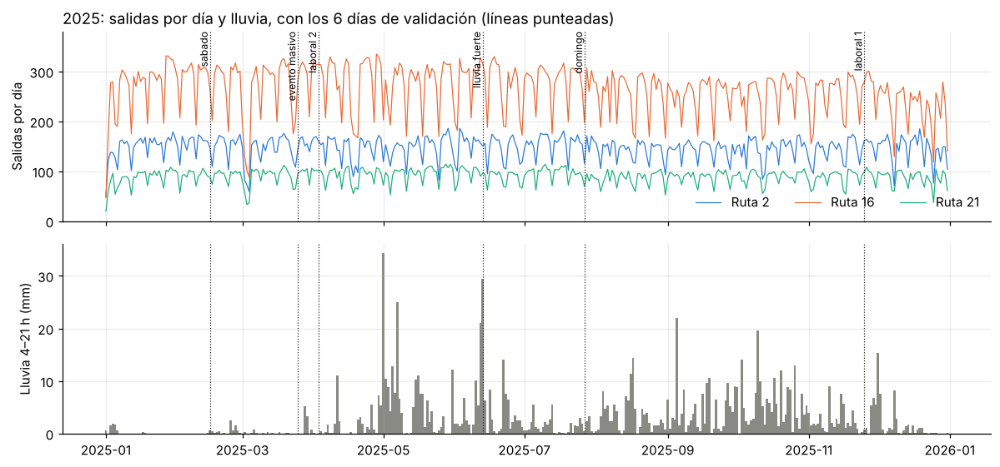

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
for r in (2, 16, 21):
    ax[0].plot(crit.fecha, crit[f"salidas_r{r}"], color=COL[r], lw=.8, label=f"Ruta {r}")
ax[0].set_ylabel("Salidas por día"); ax[0].legend(ncol=3, frameon=False, loc="lower right"); ax[0].set_ylim(0, 380)
ax[1].bar(crit.fecha, crit.lluvia_4_21_mm, color=GRIS, width=1)
ax[1].set_ylabel("Lluvia 4–21 h (mm)")
for d in reg["dias"]:
    f = pd.Timestamp(d["fecha"])
    for a in ax:
        a.axvline(f, color="#1f1f1d", lw=.8, ls=":")
    ax[0].annotate(d["rol"].replace("_", " "), (f, ax[0].get_ylim()[1]), rotation=90, va="top", ha="right", fontsize=8)
ax[0].set_title("2025: salidas por día y lluvia, con los 6 días de validación (líneas punteadas)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_1_dias_validacion.png", dpi=200, bbox_inches="tight"); plt.show()

### Lo que se trajo de la base para esos días (consulta liviana del 4-nov-2026)

In [4]:
vv = leer("viajes_validacion_13_1.csv")
lv = leer("lecturas_validacion_13_1.parquet")
res = vv.groupby("rol").agg(viajes=("idprogramacion", "size"), con_lecturas=("n_lecturas", "count"),
                           lecturas=("n_lecturas", "sum"), carga_imposible=("carga_imposible", lambda s: int(s.fillna(False).sum())),
                           subidas_lecturas=("subidas_lecturas", "sum"), pasajeros_maestra=("numeropasajeros", "sum"))
res["pct_con_lecturas"] = (100 * res.con_lecturas / res.viajes).round(1)
display(res)
x = vv.dropna(subset=["numeropasajeros", "subidas_lecturas"])
print(f"Viajes con lecturas: {vv.n_lecturas.notna().sum():,} de {len(vv):,} ({100 * vv.n_lecturas.notna().mean():.1f} %)")
print(f"Subidas de las lecturas = pasajeros de la maestra en el {100 * (x.subidas_lecturas == x.numeropasajeros).mean():.1f} % de los viajes con ambos")
print(f"Lecturas fuera de la ruta (desvíos, terminal): {100 * lv.fuera_de_ruta.mean():.1f} %")
print("En calibración:", man["info"]["validacion"]["en_calibracion"], "viajes")

,viajes,con_lecturas,lecturas,carga_imposible,subidas_lecturas,pasajeros_maestra,pct_con_lecturas
rol,,,,,,,
domingo,381,376,96895.0,0,19858.0,16959.0,98.7
evento_masivo,521,514,177862.0,4,47471.0,43088.0,98.7
laboral_1,537,527,166126.0,0,41871.0,38916.0,98.1
laboral_2,576,563,196409.0,4,48775.0,44922.0,97.7
lluvia_fuerte,563,553,178732.0,1,41367.0,38496.0,98.2
sabado,500,489,160928.0,2,39065.0,36398.0,97.8


Viajes con lecturas: 3,022 de 3,078 (98.2 %)
Subidas de las lecturas = pasajeros de la maestra en el 88.3 % de los viajes con ambos
Lecturas fuera de la ruta (desvíos, terminal): 7.2 %
En calibración: 0 viajes


**Conclusión 1 · Seis días congelados antes de simular, con todas sus lecturas**
- **Los días** (elegidos con criterios escritos, aprobados y congelados el 4-nov-2026 a las 14:03, hash `b27d3784…`):

  | Rol | Fecha | Por qué |
  |---|---|---|
  | Laboral 1 | mar 25-nov-2025 | El laboral más típico: salidas a ±5 % de la mediana, 0,77 mm de lluvia |
  | Laboral 2 | jue 3-abr-2025 | Otro día de la semana y otro mes, seco |
  | Sábado | 15-feb-2025 | El sábado más típico (±2 %) |
  | Domingo | 27-jul-2025 | El Domingo de Ramos (13-abr) se descartó porque abre el receso de Semana Santa |
  | Lluvia fuerte | vie 13-jun-2025 | El laboral más lluvioso de 2025: 29,5 mm entre las 4 y las 21 h |
  | Evento masivo | mar 25-mar-2025 | Colombia vs. Paraguay, 19:00, Metropolitano; seco |

- **La consulta liviana** trajo **977.826 lecturas** de 3.055 de los 3.078 viajes.
  - Se limpiaron con la misma función del Módulo 1, que da resultados idénticos sobre la muestra (prueba i).
  - **Quedan ubicadas en su segmento 976.952 lecturas de 3.022 viajes (98,2 %).**
  - Los otros 33 viajes (25 de la ruta 16 y 8 de la 21) nunca salieron de la terminal: sus 874 lecturas están en un mismo punto, a 87–110 m del inicio de su ruta, más allá del umbral de 40 m. 32 de ellos no están en la maestra. No son recorridos.
- **Separación:** ningún viaje de esos días está en la calibración. Eran 4 viajes de la muestra de lecturas: los 2 que estaban entre los viajes al azar se sacaron de la calibración, y los pasos GPS de esos días se sacaron de los tiempos.
- **Para la 13.4:** 11 viajes tienen carga imposible y quedan fuera de la ocupación observada; el 7,2 % de las lecturas está fuera de la ruta (desvíos y terminal) y hereda el último segmento conocido.

## 2 · Tiempos por segmento y su dispersión

In [5]:
t = leer("tiempos_segmento_13_1.csv"); disp = leer("dispersion_tiempos_13_1.csv"); lentos = leer("tramos_lentos_segmento_13_1.csv")
print(json.dumps(man["info"]["tiempos"], indent=1, ensure_ascii=False))
print("Celdas:", len(t), "· fuentes:", t.fuente.value_counts().to_dict())
display(disp[["idruta", "franja", "n_pasos", "n_viajes", "sigma_segmento", "sigma_viaje", "pct_lentos_obs", "pct_lentos_esperado",
              "ratio_lento_mediana"]].round(3))
vt = leer("duracion_vuelta_13_1.csv")
suma = t.groupby(["idruta", "franja", "tipo_dia"]).t_s.sum().div(60).rename("suma_segmentos_min").reset_index()
cmp_ = suma.merge(vt, on=["idruta", "franja", "tipo_dia"])
cmp_["razon"] = cmp_.suma_segmentos_min / cmp_.mediana
print("Suma de los tiempos de los segmentos ÷ vuelta mediana de la maestra (por ruta × franja × día):",
      cmp_.razon.describe()[["min", "50%", "max"]].round(3).to_dict())

{
 "viajes_con_pasos": 1441,
 "viajes_usados": 1439,
 "pasos_usados": 138787,
 "descartados_50kmh": {
  "pasos_totales": 158835,
  "descartados": 19850,
  "pct": 12.497245569301477,
  "v_max_kmh": 50.0
 },
 "dif_max_vs_m12_s": 52.87052650004625,
 "dif_media_vs_m12_pct": 0.03883603038591318,
 "pct_pasos_lentos": 2.699820588383638,
 "puntos_recurrentes": 33,
 "pct_lentos_en_recurrentes": 29.997331198291967,
 "cola_lentos": {
  "probabilidades": [
   0.0,
   0.05,
   0.1,
   0.15,
   0.2,
   0.25,
   0.3,
   0.35,
   0.4,
   0.45,
   0.5,
   0.55,
   0.6,
   0.65,
   0.7,
   0.75,
   0.8,
   0.85,
   0.9,
   0.95,
   0.99
  ],
  "filas": 51
 }
}
Celdas: 6948 · fuentes: {'seg_franja_dia': 5016, 'seg_franja': 1134, 'seg': 672, 'ruta_franja': 126}


,idruta,franja,n_pasos,n_viajes,sigma_segmento,sigma_viaje,pct_lentos_obs,pct_lentos_esperado,ratio_lento_mediana
0,2,madrugada,1307,65,0.224,0.062,0.689,0.143,2.328
1,2,noche,8537,139,0.244,0.078,2.401,0.343,2.390
2,2,pico_am,5295,140,0.233,0.064,2.285,0.202,2.503
3,2,pico_pm,4928,155,0.239,0.074,2.334,0.277,2.496
4,2,valle_am,11362,231,0.242,0.063,1.584,0.275,2.412
5,2,valle_pm,14077,245,0.243,0.078,2.103,0.333,2.412
6,16,madrugada,995,47,0.193,0.060,0.603,0.031,2.144
7,16,noche,5527,122,0.252,0.067,2.045,0.388,2.358
8,16,pico_am,4208,123,0.238,0.074,1.759,0.268,2.425
9,16,pico_pm,5327,164,0.245,0.052,2.159,0.283,2.522


Suma de los tiempos de los segmentos ÷ vuelta mediana de la maestra (por ruta × franja × día): {'min': 0.794, '50%': 0.971, 'max': 1.205}


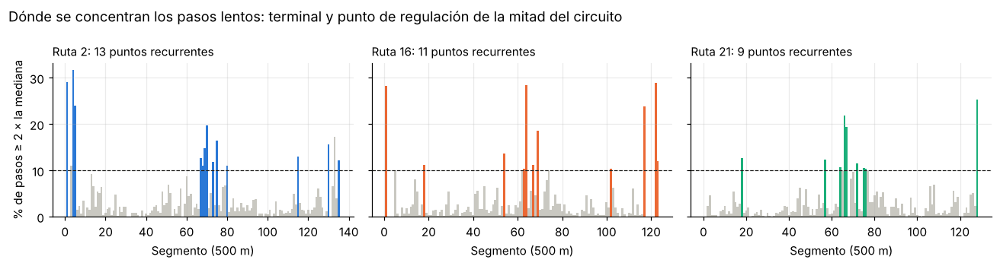

,puntos,segmentos
idruta,,
2,13,"1, 4, 5, 67, 68, 69, 70, 73, 75, 80, 115, 130,..."
16,11,"1, 18, 54, 63, 64, 67, 69, 102, 117, 122, 123"
21,9,"18, 57, 64, 66, 67, 72, 75, 76, 128"


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, r in zip(ax, (2, 16, 21)):
    g = lentos[lentos.idruta == r]
    a.bar(g.nro_segmento, g.pct_lentos, color=np.where(g.punto_recurrente, COL[r], "#c9c8c1"), width=1)
    a.axhline(10, color="#1f1f1d", lw=.8, ls="--")
    a.set_title(f"Ruta {r}: {int(g.punto_recurrente.sum())} puntos recurrentes", loc="left", fontsize=10)
    a.set_xlabel("Segmento (500 m)")
ax[0].set_ylabel("% de pasos ≥ 2 × la mediana")
fig.suptitle("Dónde se concentran los pasos lentos: terminal y punto de regulación de la mitad del circuito", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_1_tramos_lentos.png", dpi=200, bbox_inches="tight"); plt.show()
display(lentos[lentos.punto_recurrente].groupby("idruta").agg(puntos=("nro_segmento", "size"),
        segmentos=("nro_segmento", lambda s: ", ".join(map(str, s)))))

**Conclusión 2 · Los tiempos del Módulo 12 sirven tal cual, y su variación tiene tres partes**
- **Cobertura completa:** 6.948 celdas (386 segmentos × 6 franjas × 3 tipos de día).
  - Recalculadas sin los 2 viajes de validación, difieren del Módulo 12 en un **0,039 %** en promedio.
  - La suma de los segmentos da el **97 %** de la vuelta mediana de la maestra (mediana; entre 79 % y 121 % según ruta × franja × día). La 13.2 la usa como chequeo.
- **La variación se sortea en tres partes:**
  - **Efecto de viaje:** hay viajes enteros más lentos (σ = 0,05–0,085 en escala logarítmica). Es lo que pega los buses unos con otros.
  - **Ruido por segmento:** σ = 0,19–0,25.
  - **La cola:** el 2,7 % de los pasos tarda ≥ 2 veces lo normal. De ellos, el **30 %** se concentra en **33 puntos recurrentes** (terminal y punto de regulación de la mitad del circuito): son esperas de la operación y se sortean en su segmento. El resto, **17 por cada 1.000 pasos** (unos 2 por vuelta), son trancones, que multiplican el tiempo del segmento por 2,4 en la mediana.

## 3 · Demanda: cuántos, a qué hora y dónde suben y bajan

In [7]:
print(json.dumps(man["info"]["calibracion"], indent=1, ensure_ascii=False))
dem = leer("demanda_hora_13_1.csv")
tot = dem.groupby(["idruta", "tipo_dia"]).agg(salidas=("salidas_dia", "sum"), pasajeros_pred=("pax_pred_dia", "sum"),
                                              pasajeros_real=("pax_real_dia", "sum"), dias=("n_dias", "first"))
tot["pred_vs_real_%"] = (100 * (tot.pasajeros_pred / tot.pasajeros_real - 1)).round(1)
display(tot.round(0))
ren = leer("renovacion_13_1.csv"); display(ren[ren.franja == "todas"].round(2))

{
 "viajes_muestra": 1673,
 "al_azar_con_pasos": 1441,
 "fuera_por_validacion": 2,
 "fuera_por_carga_imposible": 7,
 "viajes_calibracion": 1432,
 "pct_lecturas_fuera_ruta": 6.274277839097002,
 "pct_lecturas_ocupacion_mayor_1": 1.7355034240519065
}


salidas  pasajeros_pred  pasajeros_real  dias  pred_vs_real_%
idruta tipo_dia                                                                      
2      domingo_festivo    108.0          6279.0          5904.0    66             6.0
       laboral            159.0         13191.0         12755.0   239             3.0
       sabado             145.0         10260.0         10102.0    50             2.0
16     domingo_festivo    184.0         11123.0         10653.0    66             4.0
       laboral            290.0         25580.0         25423.0   239             1.0
       sabado             260.0         20437.0         20466.0    50            -0.0
21     domingo_festivo     65.0          4131.0          3811.0    66             8.0
       laboral             97.0          8653.0          8317.0   239             4.0
       sabado              91.0          6931.0          6670.0    50             4.0

,idruta,franja,n_viajes,factor_renovacion,carga_max_mediana,subidas_mediana
18,2,todas,471,2.48,32.0,79.0
19,16,todas,472,2.28,37.0,83.0
20,21,todas,489,2.56,32.0,83.0


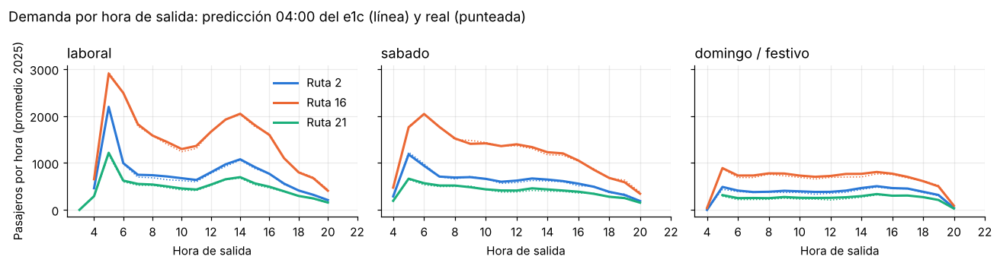

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, td in zip(ax, ("laboral", "sabado", "domingo_festivo")):
    for r in (2, 16, 21):
        g = dem[(dem.idruta == r) & (dem.tipo_dia == td)]
        a.plot(g.hora, g.pax_pred_dia, color=COL[r], lw=2, label=f"Ruta {r}")
        a.plot(g.hora, g.pax_real_dia, color=COL[r], lw=1, ls=":")
    a.set_title(td.replace("_", " / "), loc="left"); a.set_xlabel("Hora de salida"); a.set_xticks(range(4, 23, 2))
ax[0].set_ylabel("Pasajeros por hora (promedio 2025)"); ax[0].legend(frameon=False)
fig.suptitle("Demanda por hora de salida: predicción 04:00 del e1c (línea) y real (punteada)", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_1_demanda_hora.png", dpi=200, bbox_inches="tight"); plt.show()

**¿Reproduce el modelo de subidas y bajadas la carga a bordo?** Con la fracción de subidas y la probabilidad de bajarse de cada segmento se calcula el perfil de carga esperado y se compara con el promedio de la muestra (en la misma muestra: es una prueba de consistencia, no de validación; la validación es la 13.4 con los días congelados).

,idruta,franja,viajes,correlacion,carga_media_modelo,carga_media_obs,error_media_%
0,2,madrugada,75,0.973,13.057,13.440,-2.851
1,2,noche,40,0.971,5.890,6.099,-3.414
2,2,pico_am,65,0.986,12.609,13.125,-3.932
3,2,pico_pm,40,0.970,9.082,9.062,0.225
4,2,valle_am,109,0.973,9.812,9.789,0.230
5,2,valle_pm,142,0.982,11.517,11.321,1.730
6,16,madrugada,51,0.963,13.870,14.515,-4.443
7,16,noche,21,0.979,7.543,7.627,-1.100
8,16,pico_am,74,0.984,12.800,13.563,-5.624
9,16,pico_pm,42,0.966,9.787,9.783,0.034


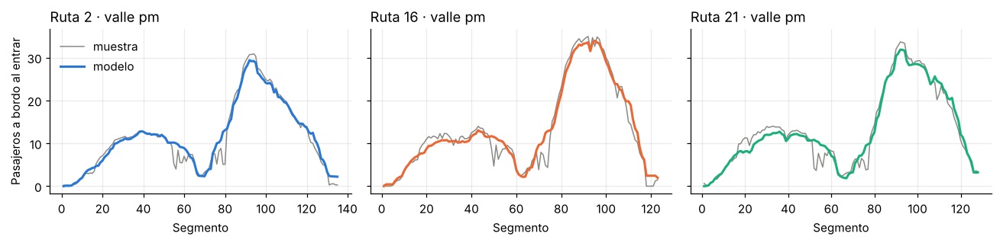

In [9]:
rep = leer("reparto_segmento_13_1.csv")
seg, red = P.red_segmentos(); reg_, ids_ = P.validacion()
mu = pd.read_parquet(P.ruta("lecturas_muestra"))
pids = set(pd.read_parquet(P.ruta("pasos_gps"), columns=["idprogramacion"]).idprogramacion)
cl, _ = P.calibracion(mu, pids, ids_)
ps = P.por_segmento(P.ubicar_lecturas(cl, red))
mm = pd.read_parquet(P.ruta("maestra"), columns=["idprogramacion", "fechasalida"])
ps = ps.merge(mm, on="idprogramacion"); ps["franja"] = P.gv.franja_de_hora(ps.fechasalida.dt.hour)
filas, perf = [], {}
for (r, fr), g in rep.groupby(["idruta", "franja"]):
    g = g.sort_values("nro_segmento"); c, prof = 0.0, []
    for sh, q in zip(g.fraccion_subidas, g.prob_bajada):
        prof.append(c); c = (c + sh) * (1 - q)
    o = ps[(ps.idruta == r) & (ps.franja == fr)]
    y = o.groupby("idprogramacion").subidas.sum().mean()
    ob = (o.groupby("nro_segmento").carga_in.sum() / o.idprogramacion.nunique() / y).reindex(g.nro_segmento).fillna(0).to_numpy()
    prof = np.array(prof); perf[(r, fr)] = (g.nro_segmento.to_numpy(), prof * y, ob * y)
    filas.append({"idruta": r, "franja": fr, "viajes": o.idprogramacion.nunique(), "correlacion": np.corrcoef(prof, ob)[0, 1],
                  "carga_media_modelo": prof.mean() * y, "carga_media_obs": ob.mean() * y})
chk = pd.DataFrame(filas); chk["error_media_%"] = 100 * (chk.carga_media_modelo / chk.carga_media_obs - 1)
display(chk.round(3))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.0), sharey=True)
for a, r in zip(ax, (2, 16, 21)):
    s, m_, o_ = perf[(r, "valle_pm")]
    a.plot(s, o_, color=GRIS, lw=1, label="muestra"); a.plot(s, m_, color=COL[r], lw=2, label="modelo")
    a.set_title(f"Ruta {r} · valle pm", loc="left"); a.set_xlabel("Segmento")
ax[0].set_ylabel("Pasajeros a bordo al entrar"); ax[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "m13_1_perfil_carga.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 3 · La demanda queda separada del plan: llegadas por segmento y hora**
- **Cuántos:** pasajeros por ruta × tipo de día × hora de salida, promedio de 355 días de 2025 (sin los de validación, sin Carnaval y sin días anómalos).
  - **Caso central:** la predicción 04:00 del e1c, entre **0 y 8 % por encima** de lo real según ruta y tipo de día.
  - **Alternativa:** los pasajeros reales.
  - **Salidas sin conteo:** las que operaron pero no quedaron como terminadas, o que el Módulo 1 dejó fuera de la maestra, llevan la media por salida de su hora. Son el 10–20 % de las salidas según ruta y tipo de día. La tabla guarda también la cota inferior sin ellas (`pax_*_solo_maestra_dia`), que la 13.4 usa como sensibilidad.
- **Dónde:** de los 1.432 viajes al azar de calibración, ubicados con el Viterbi del Módulo 10, salen la fracción de las subidas y la probabilidad de bajarse en cada segmento, por ruta × franja.
- **Llegadas:** juntando cuántos y dónde, quedan las llegadas por segmento × hora (pasajeros por hora). No dependen del plan de despachos, así que sirven para probar cualquier plan. Suman exactamente los pasajeros por día.
- **Consistencia:** con ese reparto, el perfil de carga a bordo reproduce el de la muestra:
  - correlación de 0,96 a 0,99 en las 18 combinaciones ruta × franja;
  - carga media entre −9,2 % y +1,7 %.

  Es una comprobación dentro de la misma muestra; la validación es la 13.4.
- **Factor de renovación** (subidas del viaje ÷ su carga máxima): 2,48 / 2,28 / 2,56 en las rutas 2 / 16 / 21.
- **Capacidad:** solo el 1,7 % de las lecturas tiene más pasajeros que la capacidad, así que la demanda observada casi no está recortada por buses llenos.

## 4 · Capacidad, descanso en la terminal y vuelta

In [10]:
cap = leer("capacidad_bus_13_1.csv")
display(cap.groupby("idruta_habitual").capacidad.describe().round(1))
print("Buses con más de una capacidad en 2025:", int((cap.capacidad_distintas > 1).sum()))
desc = leer("descanso_terminal_13_1.csv"); display(desc.round(1))
print("Encadenando todas las salidas de tb_despachos (no solo la maestra):", man["info"]["descanso"])
print("Salidas 2025 que operaron sin quedar terminadas:", f'{100 * (~pd.read_parquet(P.ruta("despachos"), columns=["fechasalida", "finalizado"]).query("fechasalida >= \'2025-01-01\' and fechasalida < \'2026-01-01\'").finalizado.astype(bool)).mean():.1f} %')
vt = leer("duracion_vuelta_13_1.csv"); display(vt[vt.tipo_dia == "laboral"].round(1))

,count,mean,std,min,25%,50%,75%,max
idruta_habitual,,,,,,,,
2,88.0,52.0,7.3,34.0,47.8,50.0,53.5,74.0
16,125.0,53.1,6.7,39.0,49.0,50.0,58.0,72.0
21,204.0,51.5,6.7,32.0,47.0,50.0,55.0,74.0


Buses con más de una capacidad en 2025: 0


,idruta,franja,n,p05,p25,mediana,p75,p95,media,pct_pausa,pct_negativo
0,2,noche,2229,10.3,15.5,23.3,37.6,65.4,28.8,9.4,0.0
1,2,pico_am,510,10.5,17.2,24.0,31.3,45.4,25.3,0.0,0.2
2,2,pico_pm,3220,9.9,16.8,27.4,42.0,71.9,32.2,15.0,0.0
3,2,valle_am,7479,13.0,22.0,30.8,42.7,65.5,34.0,0.8,0.0
4,2,valle_pm,9280,12.0,22.6,32.4,49.2,82.0,38.2,14.4,0.0
5,16,noche,3914,10.1,15.6,23.2,37.4,76.0,30.1,3.5,0.0
6,16,pico_am,1395,8.6,12.4,16.6,22.5,33.7,18.4,0.0,0.0
7,16,pico_pm,6900,9.8,15.5,23.1,35.2,66.9,28.8,7.6,0.0
8,16,valle_am,15221,12.7,21.2,30.0,41.4,64.9,33.0,0.8,0.0
9,16,valle_pm,21415,12.5,22.4,31.4,45.8,77.2,36.4,9.0,0.0


Encadenando todas las salidas de tb_despachos (no solo la maestra): {'pares_consecutivos': 87106, 'pares_solo_maestra': 91897, 'pares_que_saltaban_una_salida': 4791, 'pct_pausa_consecutivos': 9.959130255091498, 'pct_pausa_solo_maestra': 13.824172715104954}
Salidas 2025 que operaron sin quedar terminadas: 8.2 %


,idruta,tipo_dia,franja,n,p10,mediana,p90
6,2,laboral,madrugada,5143,174.7,223.6,270.7
7,2,laboral,noche,2004,165.2,180.3,196.4
8,2,laboral,pico_am,3955,234.4,262.5,289.5
9,2,laboral,pico_pm,2616,198.2,222.7,250.8
10,2,laboral,valle_am,7397,227.9,250.6,276.5
11,2,laboral,valle_pm,8471,242.7,272.5,304.0
24,16,laboral,madrugada,7703,161.7,197.8,246.4
25,16,laboral,noche,2989,153.6,166.8,180.8
26,16,laboral,pico_am,9939,217.6,247.7,271.6
27,16,laboral,pico_pm,5171,177.6,202.1,226.5


**Conclusión 4 · Descanso y vuelta salen de los datos, no de supuestos**
- **Descanso en la terminal** (inicio de una vuelta menos el fin de la anterior, mismo bus, día y ruta):

  | | Mediana | P5 (mínimo práctico) | Pausas > 2 h |
  |---|---|---|---|
  | Ruta 2 | 30,8 min | 11,6 min | 10 % |
  | Ruta 16 | 29,4 min | 11,4 min | 6 % |
  | Ruta 21 | 39,9 min | 19,3 min | 33 % |

  Las pausas (el bus sale de servicio un rato) se guardan aparte. Explican que la ruta 21 use 57 buses distintos al día para hacer el trabajo de unos 35 a la vez.
- **Salidas que no quedan como terminadas:** el 8,2 % de las salidas de 2025 operaron pero SOBUSA las marca como canceladas, por ejemplo cuando el bus parquea al final en un lugar alterno.
  - Por eso las vueltas se encadenan con todas las salidas de `tb_despachos`, no solo con las de la maestra.
  - Si no, el descanso saltaría por encima de la vuelta no terminada. Esto pasaba en 4.791 pares, que parecían pausas: las pausas eran 13,8 % en vez de 10,0 %.
  - Las medianas no cambian.
- **Vuelta:** entre 167 y 273 min de mediana en los laborales, según la franja. La más larga es la del valle de la tarde.
- **Capacidad:** 51,5–53,1 pasajeros por bus en promedio (sentados + de pie), fija para cada bus en todo 2025.

## 5 · Frecuencias del proyecto por el método de la carga máxima

**Fórmula** (Ceder, *Public Transit Planning and Operation*, método de la carga máxima):
`minutos entre salidas = 60 × capacidad × factor de carga ÷ pasajeros por hora en el punto de carga máxima`, con
pasajeros en el punto de carga máxima = pasajeros por hora de las salidas ÷ factor de renovación (subidas del viaje ÷ su
carga máxima, de la muestra). La **flota** que exige cada plan es el máximo de buses ocupados a la vez: cada salida ocupa un
bus durante su ciclo (vuelta mediana + descanso mediano). El mismo cálculo con las salidas reales da la flota del plan real.

In [11]:
frec = leer("frecuencias_estimadas_13_1.csv"); flo = leer("flota_por_plan_13_1.csv")
display(flo[flo.factor_carga == 0.85].round(1))
piv = flo.pivot_table(index=["idruta", "tipo_dia"], columns="factor_carga", values="flota_plan")
piv["real (estimada)"] = flo.groupby(["idruta", "tipo_dia"]).flota_real_estimada.first()
piv["buses reales/día"] = flo.groupby(["idruta", "tipo_dia"]).buses_real_dia_mediana.first()
display(piv)

,idruta,tipo_dia,factor_carga,flota_plan,flota_real_estimada,salidas_plan_dia,headway_plan_pico_min,horas_fuera_rango,buses_real_dia_mediana,salidas_real_dia_mediana
1,2,domingo_festivo,0.8,17,32,56.8,12.7,16,32.5,110.0
4,2,laboral,0.8,46,55,120.4,2.8,16,54.0,159.0
7,2,sabado,0.8,33,48,93.2,5.2,17,52.0,143.5
10,16,domingo_festivo,0.8,28,46,108.2,6.4,17,54.0,190.0
13,16,laboral,0.8,90,90,252.0,2.0,7,93.0,293.0
16,16,sabado,0.8,69,81,200.3,2.7,9,89.0,259.0
19,21,domingo_festivo,0.8,12,19,36.8,19.5,16,35.0,65.0
22,21,laboral,0.8,28,35,77.9,5.0,17,57.0,97.0
25,21,sabado,0.8,21,31,62.0,9.2,17,54.5,90.0


factor_carga              0.7  0.85   1.0  real (estimada)  buses reales/día
idruta tipo_dia                                                             
2      domingo_festivo   21.0  17.0  15.0               32              32.5
       laboral           56.0  46.0  39.0               55              54.0
       sabado            41.0  33.0  29.0               48              52.0
16     domingo_festivo   33.0  28.0  24.0               46              54.0
       laboral          109.0  90.0  76.0               90              93.0
       sabado            84.0  69.0  59.0               81              89.0
21     domingo_festivo   14.0  12.0  10.0               19              35.0
       laboral           34.0  28.0  24.0               35              57.0
       sabado            25.0  21.0  18.0               31              54.5

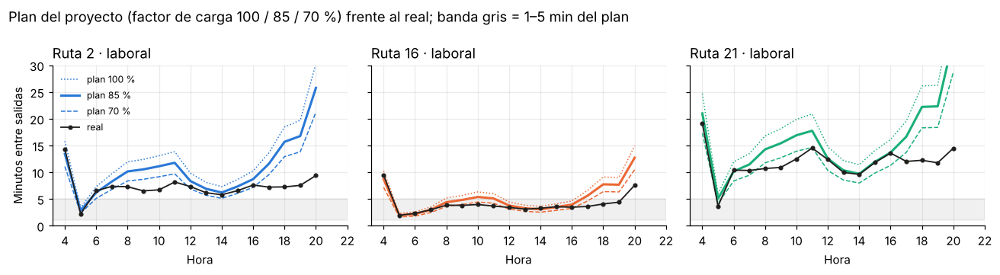

Horas del plan central fuera de 1–5 min: {'mayor_5_min': 132, 'dentro': 19, 'sin_demanda': 1}
Horas del plan REAL fuera de 1–5 min: 110 de 152


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for a, r in zip(ax, (2, 16, 21)):
    g = frec[(frec.idruta == r) & (frec.tipo_dia == "laboral")]
    for f, ls in ((1.0, ":"), (0.85, "-"), (0.70, "--")):
        x = g[g.factor_carga == f]
        a.plot(x.hora, x.headway_min, color=COL[r], ls=ls, lw=2 if f == 0.85 else 1, label=f"plan {int(100*f)} %")
    x = g[g.factor_carga == 0.85]
    a.plot(x.hora, x.headway_real_min, color="#1f1f1d", lw=1.2, marker=".", label="real")
    a.axhspan(1, 5, color=GRIS, alpha=.12)
    a.set_title(f"Ruta {r} · laboral", loc="left"); a.set_xlabel("Hora"); a.set_ylim(0, 30); a.set_xticks(range(4, 23, 2))
ax[0].set_ylabel("Minutos entre salidas"); ax[0].legend(frameon=False, fontsize=8)
fig.suptitle("Plan del proyecto (factor de carga 100 / 85 / 70 %) frente al real; banda gris = 1–5 min del plan", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_1_frecuencias.png", dpi=200, bbox_inches="tight"); plt.show()
x = frec[(frec.factor_carga == 0.85)]
print("Horas del plan central fuera de 1–5 min:", x.fuera_rango_plan.value_counts().to_dict())
print("Horas del plan REAL fuera de 1–5 min:", int(((x.headway_real_min < 1) | (x.headway_real_min > 5)).sum()), "de", len(x))

**Conclusión 5 · El proyecto ya tiene su propio plan de salidas, con la flota que exige**
- **El método de la carga máxima reproduce bien la operación de la ruta 16:** con factor de carga 85 %, en las horas pico da los mismos minutos entre salidas que hoy (2,0 vs 1,9 min a las 5 h; 3,0 vs 3,0 a las 7 h). En el valle y en la noche pide menos salidas.
- **Flota del plan central (85 %) frente a la del plan real**, en laboral (la del plan real se calcula con el mismo método, que da 55 y 90 buses en las rutas 2 y 16 frente a 54 y 93 que de verdad se usan):

  | | Plan 85 % | Plan real (mismo cálculo) | Salidas al día (plan / real) |
  |---|---|---|---|
  | Ruta 2 | 46 buses | 55 | 120 / 159 |
  | Ruta 16 | 90 | 90 | 252 / 293 |
  | Ruta 21 | 28 | 35 | 78 / 97 |

  **Los fines de semana la diferencia es mayor:** por ejemplo, la ruta 2 el domingo necesitaría 17 buses en lugar de 32. Hoy SOBUSA mantiene una frecuencia mínima que la demanda sola no pide.
- **El rango de 1 a 5 min del plan es solo una referencia:** el propio plan real queda por fuera en 110 de 152 horas. Se cumple en la ruta 16 de día, pero no en las rutas 2 y 21, que salen cada 6 a 12 min.
- **Los tres planes (100 / 85 / 70 %)** quedan listos para la 13.4. En ella, el simulador dirá cuánta espera y cuánto hacinamiento produce cada uno. Por ahora es un cálculo estático, sin buses pegados ni incidentes.

## 6 · Incidentes: señal, tasa e intervalo

In [13]:
inc = leer("incidentes_13_1.csv")
display(inc[["tipo", "unidad", "tasa_baja", "tasa_central", "tasa_alta", "efecto", "duracion_central_min", "rotulo"]].round(3))
print(json.dumps(man["info"]["incidentes"], indent=1, ensure_ascii=False))
vb = leer("varada_bus_13_1.csv"); print("Probabilidad de varada por bus:", vb.p_varada_jornada.describe().round(4).to_dict(),
                                        "· fuente:", vb.fuente.value_counts().to_dict())

,tipo,unidad,tasa_baja,tasa_central,tasa_alta,efecto,duracion_central_min,rotulo
0,trancon,por 1.000 pasos por segmento,16.403,17.145,17.915,× 2.40 el tiempo del segmento (mediana),30,dato
1,obra,por 1.000 viajes,32.075,41.201,52.782,8.6 min fuera de la ruta (mediana),180,dato
2,arroyo,por 1.000 días,0.913,21.903,161.533,bloqueo del tramo inundable (severidad 5) mien...,60,dato (lluvia) + supuesto (que la lluvia forme ...
3,varado,por 1.000 buses-día,9.737,12.333,14.708,el bus sale de servicio por el resto del día,30,dato (proxy del Módulo 9)
4,evento,por año,3.048,5.333,8.661,demanda e impacto según el porcentaje de SOBUS...,120,dato
5,choque,por ruta-día,0.100,0.300,0.600,colisión que bloquea un carril o la vía,45,supuesto
6,bloqueo,por ruta-día,0.010,0.030,0.080,protesta o cierre no programado,90,supuesto
7,semaforo,por ruta-día,0.050,0.150,0.300,semáforo apagado o intermitente en el corredor,20,supuesto


{
 "desvios": {
  "episodios_viajes_al_azar": 395,
  "episodios_transitorios": 64,
  "viajes_con_transitorio": 59,
  "zonas_transitorias": 13,
  "meses_activos_media": 2.923076923076923,
  "zonas_permanentes": [
   "Z1",
   "Z2",
   "Z3",
   "Z4"
  ],
  "minutos_fuera_p90": 16.155000000000005
 },
 "lluvia": {
  "dias_por_umbral": {
   "20.0": 1,
   "10.0": 24,
   "5.0": 177
  },
  "anios": 3,
  "horas_por_mes_10mm": {
   "3": 1,
   "5": 7,
   "6": 3,
   "7": 1,
   "9": 3,
   "10": 4,
   "11": 9
  }
 },
 "varada": {
  "por_anio": {
   "2023": 0.009736932012299283,
   "2024": 0.01263308324401572,
   "2025": 0.014708480565371026
  },
  "ic95_central": [
   11.867640304092394,
   12.816095276548772
  ]
 },
 "eventos": {
  "PARTIDO_SELECCION": 8,
  "GUACHERNA": 3,
  "BATALLA_FLORES": 3,
  "CONCIERTO": 2
 }
}
Probabilidad de varada por bus: {'count': 417.0, 'mean': 0.0185, 'std': 0.0143, 'min': 0.0059, '25%': 0.0116, '50%': 0.0138, '75%': 0.0193, 'max': 0.1063} · fuente: {'m9': 331, 'mediana

**Consulta de `vehiculos.ultimoevento` e `indexevento` (E1, aprobada por la Persona 3).**

In [14]:
e1 = pd.read_csv(D / "extraccion/e1_vehiculos_ultimoevento.csv")
print(f"{len(e1)} buses · {e1.ultimoevento.notna().sum()} con ultimoevento · {e1.ultimoevento.nunique()} códigos distintos")
display(e1.ultimoevento.value_counts().head(10).rename("buses").to_frame().T)
print("indexevento:", e1.indexevento.describe()[["min", "50%", "max"]].to_dict())

656 buses · 654 con ultimoevento · 29 códigos distintos


ultimoevento,3.0,2.0,109.0,6.0,349.0,10.0,69.0,21.0,119.0,0.0
buses,181,174,89,50,31,24,21,20,8,7


indexevento: {'min': 31359369.0, '50%': 3703161999.0, 'max': 3703169018.0}


**Conclusión 6 · Cinco de los ocho tipos de incidente tienen señal en los datos**
- **Con señal (tasa central e intervalo):**

  | Tipo | Señal | Tasa central (baja – alta) |
  |---|---|---|
  | Trancón | Exceso de pasos lentos (GPS) | 17,1 por 1.000 pasos (16,4 – 17,9) |
  | Obra o cierre | Desvíos del GPS fuera de las zonas permanentes Z1–Z4 | 41 por 1.000 viajes (32 – 53); 8,6 min fuera de la ruta |
  | Arroyo | Días con una hora de lluvia ≥ 10 mm (≥ 20 / ≥ 5 mm) | 21,9 por 1.000 días (0,9 – 162) |
  | Varada | Etiqueta del Módulo 9 | 12,3 por 1.000 buses-día (9,7 en 2023 – 14,7 en 2025) |
  | Evento masivo | Calendario de SOBUSA sin Carnaval | 5,3 por año (3,0 – 8,7) |

- **Sin señal: choque, bloqueo y semáforo.** La base registra 0 incidentes de esos tipos. Quedan como **supuestos rotulados** con un rango amplio (por ruta-día: choque 0,1–0,6, bloqueo 0,01–0,08, semáforo 0,05–0,30), que la 13.4 prueba como sensibilidad.
- **Varada por bus:** probabilidad del Módulo 9 para 331 buses; los 86 sin score llevan la mediana de la flota.
- **Diagnóstico del rótulo de varada:** se revisó en los días de validación sin cambiar ningún parámetro. Las 17 varadas del Módulo 9 de esos días son últimos viajes que en el GPS cubren a lo sumo el 42 % de los segmentos, y la mayoría termina junto a la terminal. El rótulo es coherente con el GPS. Lo que no puede distinguir es una varada de un bus que se retira temprano a un parqueadero alterno (H11).
- **`vehiculos.ultimoevento`** (consulta E1, aprobada) trae un código numérico del último evento del equipo a bordo (29 códigos distintos en 654 buses), sin catálogo ni historia. No sirve para contar incidentes. Queda documentado y cierra esa pregunta de la 13.1.

## 7 · Entorno y reproducibilidad

In [15]:
print("Python", sys.version.split()[0])
print(json.dumps(man["info"]["config"], indent=1, ensure_ascii=False))
print("Días que alimentan demanda, plan y descanso:", man["info"]["dias_parametros"])
display(pd.DataFrame([{"salida": n, "filas": d["filas"], "sha256": d["sha256"][:12]} for n, d in man["salidas"].items()]))

Python 3.13.16
{
 "anio": 2025,
 "ratio_lento": 2.0,
 "alfa_reparto": 500.0,
 "alfa_bajada": 200.0,
 "factores_carga": [
  1.0,
  0.85,
  0.7
 ],
 "factor_central": 0.85,
 "rango_plan_min": [
  1.0,
  5.0
 ],
 "descanso_max_min": 120.0,
 "hora_min": 4,
 "hora_max": 22,
 "lluvia_umbrales_mm_h": [
  20.0,
  10.0,
  5.0
 ],
 "zonas_permanentes": [
  "Z1",
  "Z2",
  "Z3",
  "Z4"
 ],
 "hora_limite_varada": 16,
 "min_viajes_sigma": 30,
 "min_pasos_recurrente": 30,
 "pct_recurrente": 10.0,
 "semilla": 42
}
Días que alimentan demanda, plan y descanso: {'domingo_festivo': 66, 'laboral': 239, 'sabado': 50}


,salida,filas,sha256
0,cola_lentos_13_1.csv,51,26e3e5feb04b
1,factor_lluvia_13_1.csv,5,0a2d2a6f1e93
2,tiempos_segmento_13_1.csv,6948,fbe1dc83d4bd
3,dispersion_tiempos_13_1.csv,18,4be416936275
4,tramos_lentos_segmento_13_1.csv,380,2e11dc27f986
5,reparto_segmento_13_1.csv,2316,0655d56a6ac3
6,renovacion_13_1.csv,21,298c2c74509f
7,demanda_hora_13_1.csv,153,ac94a5672207
8,llegadas_segmento_hora_13_1.parquet,19607,3bfb006412ce
9,capacidad_bus_13_1.csv,417,5a3e20ec9c58


**Conclusión 7 · Todo queda congelado y reproducible, también en Python 3.12**
- **Manifiesto** (`manifiesto_parametros_13_1.json`): 21 salidas y 21 insumos, cada uno con su hash. Tres tablas son enmiendas del 4-nov-2026: `cola_lentos_13_1.csv` (cuantiles de la razón de los pasos lentos, en la 13.2, E10), `factor_lluvia_13_1.csv` (cuánto se alargan los tiempos con lluvia, en la 13.3) y `variacion_dia_13_1.csv` (variación de la demanda entre días del mismo tipo, en la 13.4). Al agregar cada una, las demás tablas salieron con el mismo hash.
- **`tests_13_1.py`: 12/12.**
- **Python 3.12:**
  - Construir los parámetros en Python 3.12 da tablas con contenido idéntico al de Python 3.13.
  - El Módulo 12 carga y reenruta en Python 3.12 (11,5 s la carga, una vez), así que la 13.3 puede llamarlo directamente.
- **Sin APIs y sin base de datos:** la única consulta fue la Parte 1 (`extraer_13_1.py`, solo lectura), que corrió la Persona 3.

## Síntesis
La 13.1 deja al simulador todo lo que necesita, con fuente y hash:
- **Tiempos:** de los 386 segmentos, con su variación separada en viaje, segmento, esperas recurrentes y trancones.
- **Demanda:** independiente del plan, con dónde sube y dónde baja la gente.
- **Operación:** capacidad, descanso y vuelta, sacados de los datos.
- **Planes de salidas:** el real y uno del proyecto por carga máxima, en tres variantes con su flota.
- **Incidentes:** ocho tipos, cinco con señal en los datos y tres supuestos rotulados.

Los seis días de validación quedaron congelados antes de escribir una sola línea del motor, con sus casi un millón de lecturas limpias. **Siguiente: la 13.2, el motor de eventos discretos en SimPy**, que primero debe reproducir un día típico con el plan real antes de pasar a los imprevistos (13.3).

<a id="m13-2"></a>

### A2.5.2 &middot; Subfase 13.2 · Motor de eventos discretos (SimPy)

<sub>Notebook original: `modulo13/subfase_13_2_motor.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 13 · Subfase 13.2 — Motor de eventos discretos (SimPy)

**Persona 3.** El motor simula un día completo de las rutas 2, 16 y 21 con buses, pasajeros y terminal, solo con los
parámetros congelados de la 13.1. Alcance aprobado: `revisiones/alcance_13_2.md`. Todavía sin imprevistos (13.3) y sin
tocar los días de validación (13.4).

| Pieza | Qué hace | Dónde |
|---|---|---|
| Motor | Buses que recorren su circuito segmento a segmento; pasajeros que llegan al azar y suben al primer bus con cupo; bajadas por segmento; descanso en la terminal | `src/simulation/motor.py` |
| Escenarios | Día, plan (real o del proyecto), demanda (e1c o real), semilla; carga los parámetros comprobando su hash | `src/simulation/escenario.py` |
| Calibración | Factor por ruta × tipo de día × franja de salida para que la vuelta simulada sea la de la maestra | `src/simulation/calibracion.py` |
| Evaluación | Criterios de aceptación del alcance | `src/simulation/evaluacion.py` |

**Días.** Se desarrolla y calibra con el tercer día más típico de 2025 de cada tipo, y se comprueba con el cuarto (días
de control). Ninguno es de validación.

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, ".")
from src.simulation import escenario as E, evaluacion as V
from src.simulation.motor import FRANJAS

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
SAL = E.SAL; FIG = Path("resultados_13"); FIG.mkdir(exist_ok=True)
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a"}; GRIS = "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10, "figure.dpi": 110})
man = json.loads((SAL / "manifiesto_simulacion_13_2.json").read_text(encoding="utf-8"))
print("Corridas:", man["creado"], "·", man["replicas"], "réplicas por escenario · parámetros de la 13.1 del", man["manifiesto_13_1"])
print("Días de desarrollo (calibración):", man["dias_desarrollo"]); print("Días de control:", man["dias_control"])
print("Tablas que cambiaron desde el manifiesto:", [n for n, d in man["salidas"].items() if E._sha(SAL / n) != d["sha256"]])
R = V.resumen()

Corridas: 2026-11-04T20:57:56 · 30 réplicas por escenario · parámetros de la 13.1 del 2026-11-04T20:17:54
Días de desarrollo (calibración): {'laboral': '2025-02-27', 'sabado': '2025-03-22', 'domingo': '2025-03-23'}
Días de control: {'laboral': '2025-08-19', 'sabado': '2025-09-20', 'domingo': '2025-11-09'}
Tablas que cambiaron desde el manifiesto: []


## 1 · El plan real que se simula

Se simulan **todas** las salidas de `tb_despachos` del día, también las que operaron sin quedar terminadas.

**Asignación «mismo bus con reemplazo»** (por defecto): el conductor opera el mismo bus toda la jornada (Persona 3), así
que cada salida la hace su bus del día. Si a la hora de salida ese bus todavía no ha vuelto, la toma un bus libre de los
que operaron la ruta ese día, como un bus de reemplazo.

Hace falta el reemplazo porque el 4,3 % de las salidas de 2025 va seguida de otra del mismo bus antes de 150 min, menos de
lo que dura la vuelta más corta. Son vueltas cortadas o parciales que el motor no conoce. Se comparan las tres asignaciones.

In [2]:
from src.simulation import escenario as E
fil = []
for a in ("reemplazo", "secuencia", "dinamica"):
    for s in range(5):
        v = E.correr(E.Escenario(man["dias_desarrollo"]["laboral"], asignacion=a, semilla=2000 + s)).viajes
        fil.append({"asignacion": a, "semilla": s, "salidas": len(v), "retraso_>10_min_%": 100 * (v.retraso_salida_min > 10).mean(),
                    "con_su_bus_%": 100 * v.bus_propio.mean() if v.bus_propio.notna().any() else np.nan,
                    "retraso_p95_min": v.retraso_salida_min.quantile(.95), "veces_sin_cupo_por_100_subidas": 100 * v.negados.sum() / v.subidas.sum()})
display(pd.DataFrame(fil).groupby("asignacion").mean(numeric_only=True).round(2))
d = pd.read_parquet(E.SOBUSA / "maestras/tb_despachos.parquet", columns=["idvehiculo", "idruta", "fechasalida"])
d = d[(d.fechasalida >= "2025-01-01") & (d.fechasalida < "2026-01-01")].sort_values(["idvehiculo", "fechasalida"])
gap = (d.groupby([d.idvehiculo, d.fechasalida.dt.normalize()]).fechasalida.shift(-1) - d.fechasalida).dt.total_seconds() / 60
print(f"Salidas de 2025 seguidas de otra del mismo bus antes de 150 min: {100 * (gap < 150).sum() / gap.notna().sum():.1f} %")
print("Con su propio bus, en las 30 réplicas de cada día:", {n: round(100 * V.leer(n, "viajes").bus_propio.mean(), 1) for n in V.ESCENARIOS_REAL})
m = pd.read_parquet(E.SOBUSA / "maestras/tb_maestra_entrenamiento.parquet", columns=["idprogramacion", "fechafin"])
d2 = pd.read_parquet(E.SOBUSA / "maestras/tb_despachos.parquet", columns=["idprogramacion", "idvehiculo", "idruta", "fechasalida"])
d2 = d2[(d2.fechasalida >= "2025-01-01") & (d2.fechasalida < "2026-01-01")].merge(m, on="idprogramacion", how="left").sort_values(["idvehiculo", "fechasalida"])
g2 = d2.groupby([d2.idvehiculo, d2.fechasalida.dt.normalize()])
d2["descanso_hasta_salida_programada"] = (d2.fechasalida - g2.fechafin.shift()).dt.total_seconds() / 60
y = d2[(g2.idruta.shift() == d2.idruta) & d2.descanso_hasta_salida_programada.between(0, 120)]
print("Descanso hasta la salida programada (min, 2025):"); display(y.groupby("idruta").descanso_hasta_salida_programada.quantile([.05, .25, .5, .75, .95]).unstack().round(0))
print(f"Entre 40 y 90 min: {100 * y.descanso_hasta_salida_programada.between(40, 90).mean():.0f} %")

,semilla,salidas,retraso_>10_min_%,con_su_bus_%,retraso_p95_min,veces_sin_cupo_por_100_subidas
asignacion,,,,,,
dinamica,2.0,557.0,0.00,NaN,0.0,14.22
reemplazo,2.0,557.0,0.00,85.85,0.0,13.08
secuencia,2.0,557.0,14.33,NaN,71.3,12.94


Salidas de 2025 seguidas de otra del mismo bus antes de 150 min: 4.3 %
Con su propio bus, en las 30 réplicas de cada día: {'real_laboral': np.float64(85.1), 'real_sabado': np.float64(85.2), 'real_domingo': np.float64(87.2), 'control_laboral': np.float64(85.8), 'control_sabado': np.float64(89.5), 'control_domingo': np.float64(87.4)}


Descanso hasta la salida programada (min, 2025):


,0.05,0.25,0.50,0.75,0.95
idruta,,,,,
2,16.0,27.0,38.0,51.0,78.0
16,16.0,26.0,36.0,49.0,77.0
21,18.0,28.0,38.0,51.0,80.0


Entre 40 y 90 min: 40 %


**Conclusión 1 · El plan real se simula completo, cada salida con su bus del día**
- **Qué se simula:** todas las salidas de `tb_despachos` del día, también las que operaron sin quedar terminadas. En el laboral de desarrollo (27-feb-2025) son 557: 164 / 297 / 96 en las rutas 2 / 16 / 21, con 59 / 99 / 59 buses.
- **Mismo bus todo el día, con reemplazo:**
  - el conductor opera el mismo bus toda la jornada (Persona 3), así que cada salida la hace su bus;
  - si a la hora de salida ese bus todavía no ha vuelto, la toma un bus libre del día;
  - así, el 85–89 % de las salidas las hace su propio bus y ninguna sale con más de 10 min de retraso.
- **Por qué hace falta el reemplazo:** el 4,3 % de las salidas de 2025 va seguida de otra del mismo bus antes de 150 min, menos de lo que dura la vuelta más corta. Son vueltas cortadas o parciales que el motor no conoce. Si cada bus esperara siempre su secuencia, el 14,3 % de las salidas saldría con más de 10 min de retraso (P95: 72 min), porque los retrasos se encadenan.
- **Descanso:** el plan real ya trae los descansos en sus horas de salida. Hasta la salida programada, la mediana es de 36–38 min (P25–P75: 26–51 min); el 40 % de los descansos está entre 40 y 90 min, el rango que describen los conductores. El motor solo usa un mínimo (P5: 11–19 min) cuando un bus vuelve tarde.

## 2 · Calibración de la vuelta

Factores: {'min': 0.82, '50%': 0.947, 'max': 1.048}
Error antes de calibrar (|%|): {'50%': 5.0, 'max': 20.8} · después: {'50%': 0.7, 'max': 3.1}


franja_salida           madrugada  pico_am  valle_am  valle_pm  pico_pm  noche
tipo_dia        idruta                                                        
domingo_festivo 2           0.885    0.950     1.005     0.979    0.939  0.923
                16          0.820    0.909     0.945     0.950    0.929  0.893
                21          0.939    0.943     0.965     0.943    0.943  0.876
laboral         2           0.911    1.032     0.992     1.048    0.993  0.849
                16          0.891    1.007     0.975     1.021    0.929  0.857
                21          0.900    1.011     0.984     1.036    1.019  0.859
sabado          2           0.933    0.992     1.023     0.979    0.978  0.891
                16          0.934    1.009     1.037     0.951    0.972  0.916
                21          0.923    1.030     1.034     0.926    0.956  0.879

Variación de la vuelta (P90 − P10) simulada ÷ real, por ruta × franja (6 días): {'25%': 1.1, '50%': 1.17, '75%': 1.32}


real_laboral  real_sabado  real_domingo  control_laboral  control_sabado  control_domingo
idruta franja                                                                                              
2      madrugada          0.66         1.32          1.66             0.68            1.31             1.68
       noche              1.54         1.12          1.49             1.51            1.18             1.50
       pico_am            1.29         1.34          1.69             1.14            1.29             1.80
       pico_pm            1.15         1.23          1.25             1.17            1.19             1.16
       valle_am           1.12         1.10          1.19             1.21            1.10             1.18
       valle_pm           1.14         1.20          1.35             1.13            1.22             1.32
16     madrugada          0.76         1.07          1.45             0.77            1.08             1.41
       noche              1.48         1.16          1.12             1.46            1.12             1.00
       pico_am            1.15         1.18          1.72             1.15            1.13             1.72
       pico_pm            1.01         1.08          1.11             0.97            1.10             1.10
       valle_am           1.41         1.22          1.25             1.41            1.25             1.19
       valle_pm           1.14         1.19          1.17             1.13            1.14             1.16
21     madrugada          0.66         1.19          2.35             0.63            1.12             2.34
       noche              1.03         1.02          1.11             1.07            1.04             1.18
       pico_am            0.97         1.01          1.86             0.93            1.02             1.92
       pico_pm            1.09         1.32          1.36             1.05            1.40             1.32
       valle_am           1.17         1.03          1.28             1.10            1.10             1.22
       valle_pm           1.14         1.25          1.64             1.09            1.21             1.64

Celdas a ±5 % de la maestra: {'control_domingo': {'sum': 18, 'size': 18}, 'control_laboral': {'sum': 18, 'size': 18}, 'control_sabado': {'sum': 18, 'size': 18}, 'real_domingo': {'sum': 18, 'size': 18}, 'real_laboral': {'sum': 18, 'size': 18}, 'real_sabado': {'sum': 18, 'size': 18}}


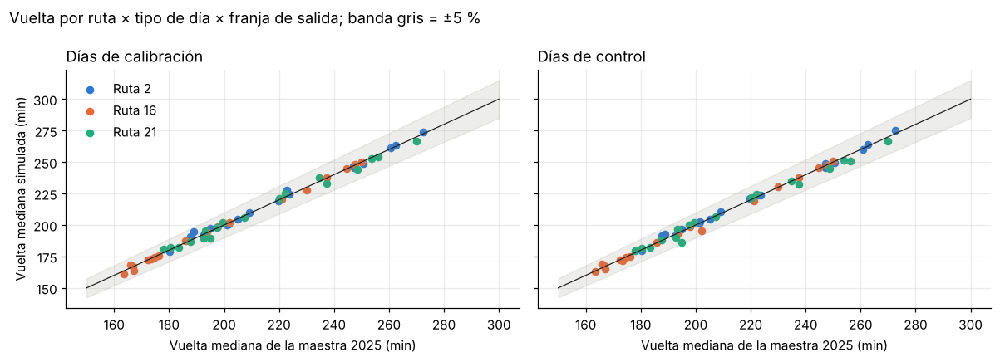

In [3]:
fac = pd.read_csv(SAL / "factores_vuelta_13_2.csv")
print("Factores:", fac.factor.describe()[["min", "50%", "max"]].round(3).to_dict())
print("Error antes de calibrar (|%|):", fac.error_antes_pct.abs().describe()[["50%", "max"]].round(1).to_dict(),
      "· después:", fac.error_despues_pct.abs().describe()[["50%", "max"]].round(1).to_dict())
display(fac.pivot_table(index=["tipo_dia", "idruta"], columns="franja_salida", values="factor").round(3)[list(FRANJAS)])
P = E.cargar_parametros(); vt = P["duracion_vuelta_13_1.csv"]; filas = []
for n in V.ESCENARIOS_REAL:
    v = V.leer(n, "viajes"); q = v.groupby(["idruta", "franja_salida"]).vuelta_min.quantile([.1, .9]).unstack()
    o = vt[vt.tipo_dia == V.tipo_de(n)].set_index(["idruta", "franja"])[["p10", "p90"]]; q.index.names = ["idruta", "franja"]
    x = q.join(o); filas.append(((x[0.9] - x[0.1]) / (x.p90 - x.p10)).rename(n))
anch = pd.concat(filas, axis=1)
print("Variación de la vuelta (P90 − P10) simulada ÷ real, por ruta × franja (6 días):",
      anch.stack().describe()[["25%", "50%", "75%"]].round(2).to_dict())
display(anch.round(2))
vu = R["vuelta"]
print("Celdas a ±5 % de la maestra:", vu.assign(ok=vu.error_pct.abs() <= 5).groupby("escenario").ok.agg(["sum", "size"]).to_dict("index"))
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, pref, tit in zip(ax, ("real_", "control_"), ("Días de calibración", "Días de control")):
    x = vu[vu.escenario.str.startswith(pref)]
    for r in (2, 16, 21):
        y = x[x.idruta == r]
        a.scatter(y.vuelta_maestra, y.vuelta_sim, color=COL[r], s=28, label=f"Ruta {r}")
    lo, hi = 150, 300
    a.plot([lo, hi], [lo, hi], color="#1f1f1d", lw=.8); a.fill_between([lo, hi], [lo * .95, hi * .95], [lo * 1.05, hi * 1.05], color=GRIS, alpha=.15)
    a.set_title(tit, loc="left"); a.set_xlabel("Vuelta mediana de la maestra 2025 (min)")
ax[0].set_ylabel("Vuelta mediana simulada (min)"); ax[0].legend(frameon=False)
fig.suptitle("Vuelta por ruta × tipo de día × franja de salida; banda gris = ±5 %", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_2_vuelta.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 2 · La vuelta: su mediana y su variación, también en días que no se usaron para calibrar**
- **Dos correcciones a la variación de los tiempos**, encontradas al revisar la cola de las vueltas:
  - **Cola empírica de los pasos lentos:** la razón de un paso lento se sortea de sus cuantiles observados, de ×2 al P99 (`cola_lentos_13_1.csv`, enmienda E10 de la 13.1). Antes era una lognormal ajustada con dos valores, que daba vueltas de más de 8 h.
  - **Zona de terminal:** la espera del bus en los 6 primeros y 6 últimos segmentos es parte del descanso, no de la vuelta (E9).
- **Calibración:** sin ella, la vuelta queda a 5,0 % de la real en la mediana. Solo la madrugada y la noche se alejan, hasta 21 %, porque una vuelta de 3 a 4 h cruza franjas con ritmos distintos; los viajes que salen de noche ya iban ~9 % más rápido en los datos GPS.
  - El factor por ruta × tipo de día × franja de salida va de 0,82 a 1,05 (mediana 0,95).
  - En el día va de 0,91 a 1,05 y está cerca de 1; en la madrugada y la noche, su mediana es 0,91 y 0,88.
- **Resultado:** la vuelta mediana queda a ±5 % en **108/108** celdas: 54 de calibración y 54 en los días de control, con otro plan real.
- **Las vueltas varían:** la diferencia entre la vuelta rápida y la lenta (P10–P90) es un 17 % mayor que la real en la mediana de las 108 celdas. El motor varía un poco más de lo que pasa en la calle. En la 13.3 se le suman los imprevistos (trancones, bloqueos, lluvia), que son los que hacen las vueltas más largas.

## 3 · Pasajeros: cuántos suben, dónde va la gente y cuánto espera

In [4]:
display(R["pasajeros"].round(2))
display(R["perfil"].round(3))
sv = R["servicio"]
display(sv[["escenario", "idruta", "llegados_rep", "pct_sin_subir_con_servicio", "pct_sin_servicio", "pct_dejados_bus_lleno",
            "espera_media_min", "espera_p90_min", "pct_viajes_bus_lleno", "conserva"]].round(2))

,idruta,sim,esperado_dia,esperado_promedio,error_pct,dif_vs_promedio_pct,escenario
0,2,80.02,80.43,83.44,-0.51,-4.10,real_laboral
1,16,85.95,86.13,89.15,-0.21,-3.60,real_laboral
2,21,89.49,90.13,88.17,-0.71,1.49,real_laboral
0,2,71.96,72.25,71.94,-0.41,0.02,real_sabado
1,16,82.28,82.41,79.20,-0.16,3.89,real_sabado
2,21,78.08,78.77,75.52,-0.87,3.39,real_sabado
0,2,52.07,52.32,57.87,-0.49,-10.03,real_domingo
1,16,62.94,63.33,60.81,-0.61,3.51,real_domingo
2,21,64.78,65.57,63.40,-1.20,2.17,real_domingo
0,2,80.68,80.93,80.21,-0.31,0.58,control_laboral


,idruta,correlacion,carga_media_sim,carga_media_muestra,celdas,viajes_muestra,error_media_pct,escenario
0,2,0.929,9.648,11.053,810,345,-12.712,real_laboral
1,16,0.898,12.479,13.066,697,329,-4.491,real_laboral
2,21,0.929,10.955,11.344,768,368,-3.435,real_laboral
0,2,0.770,10.094,9.837,673,58,2.613,real_sabado
1,16,0.929,12.483,13.489,580,81,-7.457,real_sabado
2,21,0.919,10.396,9.760,638,64,6.517,real_sabado
0,2,0.880,6.797,6.663,536,58,2.022,real_domingo
1,16,0.884,9.531,8.963,464,57,6.339,real_domingo
2,21,0.841,7.925,8.723,640,54,-9.147,real_domingo
0,2,0.930,10.451,11.053,810,345,-5.444,control_laboral


,escenario,idruta,llegados_rep,pct_sin_subir_con_servicio,pct_sin_servicio,pct_dejados_bus_lleno,espera_media_min,espera_p90_min,pct_viajes_bus_lleno,conserva
0,real_laboral,2,13187.67,0.00,0.48,4.23,5.63,12.61,18.23,True
1,real_laboral,16,25608.70,0.00,0.32,7.26,3.79,8.51,26.12,True
2,real_laboral,21,8639.83,0.00,0.56,6.15,9.70,20.96,24.17,True
0,real_sabado,2,10278.87,0.01,0.58,3.77,6.95,15.27,11.85,True
1,real_sabado,16,20471.20,0.00,0.33,4.61,3.81,8.50,19.64,True
2,real_sabado,21,6929.97,0.00,0.85,2.72,9.09,20.16,12.95,True
0,real_domingo,2,6294.73,0.01,0.73,0.52,6.26,13.66,2.78,True
1,real_domingo,16,11115.53,0.04,0.87,1.69,4.38,9.52,7.52,True
2,real_domingo,21,4127.83,0.11,1.02,1.39,10.83,23.14,6.61,True
0,control_laboral,2,13187.67,0.00,0.28,5.76,6.14,14.06,20.70,True


**Techo de la comparación del perfil.** La muestra de fin de semana tiene pocos viajes (54 a 84 por ruta), así que su propio perfil es ruidoso. Partiéndola en dos mitades al azar se estima la correlación máxima que se puede esperar (Spearman-Brown).

In [5]:
from src.simulation import parametros as Pm
reg, ids = Pm.validacion(); seg, red = Pm.red_segmentos()
mu = pd.read_parquet(Pm.ruta("lecturas_muestra")); pids = set(pd.read_parquet(Pm.ruta("pasos_gps"), columns=["idprogramacion"]).idprogramacion)
cl, _ = Pm.calibracion(mu, pids, ids)
ps = Pm.por_segmento(Pm.ubicar_lecturas(cl, red))
m = pd.read_parquet(Pm.ruta("maestra"), columns=["idprogramacion", "fechasalida", "tipo_dia", "capacidad"])
ps = ps.merge(m, on="idprogramacion"); ps["fs"] = Pm.gv.franja_de_hora(ps.fechasalida.dt.hour)
rng = np.random.default_rng(0); filas = []
def prof(z):
    n = z.groupby("fs").idprogramacion.nunique(); g = z.groupby(["fs", "nro_segmento"]).carga_in.sum()
    return g / n.reindex(g.index.get_level_values(0)).to_numpy()
for td in ("laboral", "sabado", "domingo_festivo"):
    for r in (2, 16, 21):
        x = ps[(ps.tipo_dia == td) & (ps.idruta == r)]; u = x.idprogramacion.unique(); cs = []
        for b in range(50):
            h = set(rng.choice(u, len(u) // 2, replace=False))
            pa, pb = prof(x[x.idprogramacion.isin(h)]), prof(x[~x.idprogramacion.isin(h)]); j = pa.index.intersection(pb.index)
            cs.append(np.corrcoef(pa[j], pb[j])[0, 1])
        rh = np.mean(cs); filas.append({"tipo_dia": td, "idruta": r, "viajes_muestra": len(u), "techo_correlacion": np.sqrt(2 * rh / (1 + rh))})
techo = pd.DataFrame(filas)
pf = R["perfil"].assign(tipo_dia=lambda d: d.escenario.map(V.tipo_de))
display(pf.merge(techo, on=["tipo_dia", "idruta"])[["escenario", "idruta", "viajes_muestra_y", "correlacion", "techo_correlacion"]].round(3))
cm = ps.groupby("idprogramacion").agg(cmax=("carga_max", "max"), cap=("capacidad", "first"), tipo=("tipo_dia", "first"))
print("Muestra: % de viajes que llegan al cupo:", (100 * (cm.cmax >= cm.cap)).groupby(cm.tipo).mean().round(1).to_dict())

,escenario,idruta,viajes_muestra_y,correlacion,techo_correlacion
0,real_laboral,2,345,0.929,0.991
1,real_laboral,16,329,0.898,0.987
2,real_laboral,21,368,0.929,0.990
3,real_sabado,2,61,0.770,0.915
4,real_sabado,16,84,0.929,0.948
5,real_sabado,21,66,0.919,0.948
6,real_domingo,2,65,0.880,0.834
7,real_domingo,16,59,0.884,0.944
8,real_domingo,21,55,0.841,0.960
9,control_laboral,2,345,0.930,0.991


Muestra: % de viajes que llegan al cupo: {'domingo_festivo': 2.2, 'laboral': 20.2, 'sabado': 9.5}


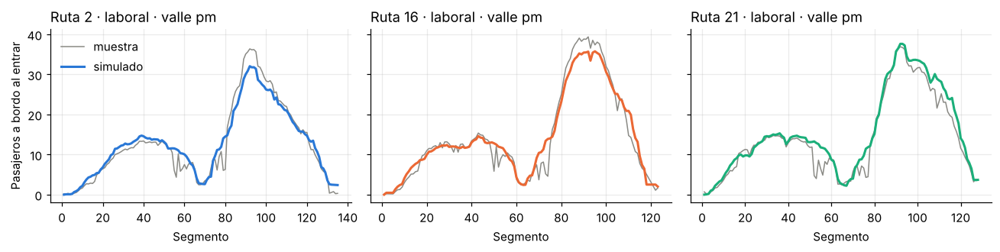

In [6]:
pm = V.perfil_muestra()
fig, ax = plt.subplots(1, 3, figsize=(12, 3.1), sharey=True)
for a, r in zip(ax, (2, 16, 21)):
    s = V.leer("real_laboral", "perfil").query("idruta == @r and franja_salida == 'valle_pm'").groupby("nro_segmento").carga_in_media.mean()
    o = pm.query("idruta == @r and franja_salida == 'valle_pm' and tipo_dia == 'laboral'").set_index("nro_segmento").carga_in_media
    a.plot(o.index, o.values, color=GRIS, lw=1, label="muestra"); a.plot(s.index, s.values, color=COL[r], lw=2, label="simulado")
    a.set_title(f"Ruta {r} · laboral · valle pm", loc="left"); a.set_xlabel("Segmento")
ax[0].set_ylabel("Pasajeros a bordo al entrar"); ax[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "m13_2_perfil.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 3 · La demanda llega a los buses y la carga a bordo se parece a la de la muestra**
- **Pasajeros por viaje:** a ±1,4 % de la demanda de la 13.1 repartida entre las salidas de cada día, en los 6 días y las 3 rutas.
  - Frente al día promedio de 2025, la diferencia llega a ±12 %. No es un error del motor: esos días tuvieron más o menos salidas que el promedio y los buses se reparten la misma demanda. Para validar el motor sirve la primera comparación; para planear, la segunda.
- **Servicio:**
  - casi nadie se queda sin subir habiendo pasado un bus (≤ 0,2 %);
  - el 0,3–1,3 % llega a su segmento después del último bus del día;
  - todo el que sube se baja.
- **Carga a bordo frente a la muestra del mismo tipo de día:**
  - **Laboral:** correlación de 0,90 a 0,96 en 5 de 6 casos; la ruta 16 en el día de calibración da 0,898. El techo que permite el ruido de la muestra es ~0,99.
  - **Fin de semana:** de 0,77 a 0,94, por debajo de 0,9 en 7 de 12 casos. La muestra de fin de semana tiene pocos viajes (54 a 84 por ruta) y su propio techo baja a 0,83–0,96. Además, el reparto por segmento de la 13.1 es el mismo para todos los tipos de día (D5).
- **Buses llenos, frente a la muestra:**

  | | Simulado | Muestra |
  |---|---|---|
  | Laboral | 18–26 % | 20,2 % |
  | Sábado | 11–23 % | 9,5 % |
  | Domingo | 3–8 % | 2,2 % |

- **Espera media:** 3,5–4,4 min en la ruta 16, 5,6–6,9 en la 2 y 9,0–10,8 en la 21. Es coherente con cada cuánto sale cada ruta.

## 4 · Buses pegados: lo que el motor produce solo

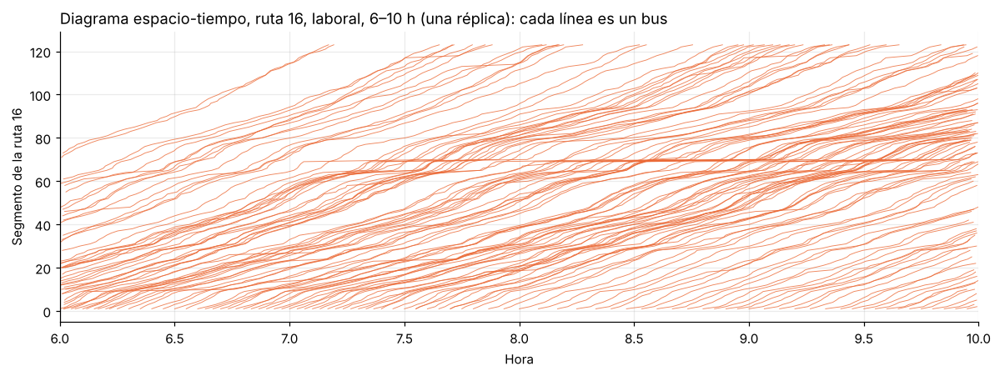

,idruta,lugar,minutos_entre_buses_mediana,cv,pct_menos_de_1_min
0,2,salida,8.00,0.24,4.17
1,2,mitad del circuito,2.84,1.21,28.21
2,16,salida,3.00,0.33,3.51
3,16,mitad del circuito,1.16,1.10,43.75
4,21,salida,12.00,0.25,0.00
5,21,mitad del circuito,5.04,0.95,20.83


In [7]:
p = pd.read_parquet(SAL / "real_laboral_pasos_replica0.parquet")
fig, ax = plt.subplots(figsize=(11, 4.2))
x = p[(p.idruta == 16) & (p.t_s >= 6 * 3600) & (p.t_s <= 10 * 3600)]
for i, g in x.groupby("id_salida"):
    ax.plot(g.t_s / 3600, g.k + 1, color=COL[16], lw=.6, alpha=.8)
ax.set_xlabel("Hora"); ax.set_ylabel("Segmento de la ruta 16"); ax.set_xlim(6, 10)
ax.set_title("Diagrama espacio-tiempo, ruta 16, laboral, 6–10 h (una réplica): cada línea es un bus", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_2_espacio_tiempo.png", dpi=200, bbox_inches="tight"); plt.show()
filas = []
for r in (2, 16, 21):
    y = p[p.idruta == r]; mid = y.k.max() // 2
    for k, lugar in ((0, "salida"), (mid, "mitad del circuito")):
        t = np.sort(y[(y.k == k) & (y.t_s >= 7 * 3600) & (y.t_s < 10 * 3600)].t_s.to_numpy()); h = np.diff(t) / 60
        filas.append({"idruta": r, "lugar": lugar, "minutos_entre_buses_mediana": np.median(h), "cv": h.std() / h.mean(),
                      "pct_menos_de_1_min": 100 * (h < 1).mean()})
display(pd.DataFrame(filas).round(2))

**Conclusión 4 · La irregularidad crece a lo largo del circuito, como en la operación real**
- **En la salida** (laboral, 7–10 h, una réplica), los buses salen regulares: coeficiente de variación de 0,24–0,33 entre buses.
- **A la mitad del circuito,** sube a 0,95–1,21, y el 21–44 % de los intervalos es de menos de 1 min: buses pegados.
- **Sale solo:** viene de que cada viaje tiene su efecto (viajes enteros más lentos) y de que el bus de adelante recoge más gente. No se impuso.
- **Lo que falta medir:** el motor no tiene regulación (un bus no espera a propósito para separarse). La 13.4 debe comparar estos intervalos con los del GPS de los días congelados. Si allá son más regulares, se agrega una regla de regulación.

## 5 · Primer vistazo al plan del proyecto (sin imprevistos)

In [8]:
cmp_ = sv[sv.escenario.isin(["real_laboral", "proyecto85_laboral"])][["escenario", "idruta", "espera_media_min", "espera_p90_min",
                                                                       "pct_dejados_bus_lleno", "pct_viajes_bus_lleno", "pct_sin_subir_con_servicio"]]
display(cmp_.round(2))
info = pd.concat([V.leer(n, "info") for n in ("real_laboral", "proyecto85_laboral")])
v1, v2 = V.leer("real_laboral", "viajes"), V.leer("proyecto85_laboral", "viajes")
print("Salidas por réplica (real / proyecto 85 %):", v1.groupby("idruta").size().div(30).to_dict(), "/", v2.groupby("idruta").size().div(30).to_dict())
print("Buses usados (real / proyecto):", v1.groupby(["replica", "idruta"]).bus.nunique().groupby("idruta").median().to_dict(), "/",
      v2.groupby(["replica", "idruta"]).bus.nunique().groupby("idruta").median().to_dict())

,escenario,idruta,espera_media_min,espera_p90_min,pct_dejados_bus_lleno,pct_viajes_bus_lleno,pct_sin_subir_con_servicio
0,real_laboral,2,5.63,12.61,4.23,18.23,0.00
1,real_laboral,16,3.79,8.51,7.26,26.12,0.00
2,real_laboral,21,9.70,20.96,6.15,24.17,0.00
0,proyecto85_laboral,2,7.29,16.30,7.68,39.86,0.20
1,proyecto85_laboral,16,4.04,9.10,7.79,35.49,0.04
2,proyecto85_laboral,21,10.56,23.24,7.24,38.16,0.30


Salidas por réplica (real / proyecto 85 %): {2: 164.0, 16: 297.0, 21: 96.0} / {2: 120.0, 16: 252.0, 21: 78.0}
Buses usados (real / proyecto): {2: 59.0, 16: 99.0, 21: 59.0} / {2: 46.0, 16: 90.0, 21: 28.0}


**Conclusión 5 · El plan del proyecto ahorra buses, pero llena más los buses**
- **El plan del proyecto con factor de carga 85 %**, frente al plan real (laboral, sin imprevistos):
  - usa 46 / 90 / 28 buses, frente a 59 / 99 / 59, con 120 / 252 / 78 salidas, frente a 164 / 297 / 96;
  - la espera media sube en 1,7 / 0,3 / 0,9 min;
  - los viajes que llegan al cupo pasan del 18–26 % al 35–40 %.
- **La razón:** la carga máxima se calculó con la carga media de cada hora, pero con buses pegados la carga varía de un bus a otro, y muchos se llenan.
- **La 13.4 lo compara con imprevistos y con los tres factores de carga (100 / 85 / 70 %).**

## 6 · Rapidez y reproducibilidad

In [9]:
info = pd.concat([V.leer(n, "info").assign(escenario=n) for n in V.ESCENARIOS_REAL + ("proyecto85_laboral",)])
print(f"{len(info)} réplicas · segundos por día de 3 rutas: mediana {info.segundos.median():.2f}, máximo {info.segundos.max():.2f}")
print("Python", sys.version.split()[0])

210 réplicas · segundos por día de 3 rutas: mediana 0.72, máximo 1.12
Python 3.13.16


**Conclusión 6 · Un día tarda alrededor de un segundo: la 13.4 puede hacer cientos de réplicas**
- **Rapidez:** 210 réplicas de un día completo de las 3 rutas, con mediana de 0,72 s y máximo de 1,12 s (el alcance pedía ≤ 30 s). Es la corrida del 4-nov-2026 con el motor de la 13.3, sin imprevistos: da las mismas tablas que la primera (0,64 s), y el tiempo sube un poco por los controles de imprevistos.
- **Reproducibilidad:** con la misma semilla el resultado es idéntico, en Python 3.12 y 3.13.
- **Seguridad:** el motor no arranca si un parámetro de la 13.1 cambió y no puede simular los días de validación.
- **`tests_13_2.py`: 12/12.**

## Síntesis
El motor ya reproduce un día típico con el plan real:
- **Buses y conductores:** cada salida la hace su bus del día (85–89 %), con reemplazo cuando el bus no ha vuelto.
- **Vuelta:** su mediana queda a ±5 % en 108 de 108 celdas, también en días que no se usaron para calibrar. Su variación es algo mayor que la real (+17 %).
- **Demanda:** llega a los buses (±1,4 %) y casi nadie se queda sin subir.
- **Carga a bordo:** se parece a la de la muestra en los laborales (0,90–0,96).
- **Buses llenos:** el laboral coincide con la muestra (18–26 % frente a 20 %).
- **Buses pegados:** aparecen solos a lo largo del circuito.
- **Rapidez:** alrededor de un segundo por día (mediana 0,72 s).

**Quedan para la 13.4:**
- la carga de los fines de semana, con una muestra pequeña;
- comprobar si los buses de verdad se pegan tanto como en la simulación, con el GPS de los días congelados.

**Siguiente: la 13.3, los imprevistos.** Son los eventos del Módulo 10 con el reenrutamiento del Módulo 12, los arroyos, los desvíos, las varadas y los eventos masivos, con las tasas de la 13.1.

<a id="m13-3"></a>

### A2.5.3 &middot; Subfase 13.3 · Imprevistos en el motor

<sub>Notebook original: `modulo13/subfase_13_3_imprevistos.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 13 · Subfase 13.3 — Imprevistos en el motor

**Persona 3.** El motor de la 13.2 ahora simula los imprevistos del día: obras y cierres, arroyos, varadas, eventos
masivos, choques, bloqueos y semáforos, con su comienzo, su efecto en los buses y los pasajeros, y su fin. Las tasas son
las de la 13.1 y el reenrutamiento es el del Módulo 12. Alcance aprobado: `revisiones/alcance_13_3.md`.

| Pieza | Qué hace | Dónde |
|---|---|---|
| Insumos | Tramos reales de desvío del GPS, tasa de desvíos por ruta, puntos inundables, segmentos del estadio | `preparar_13_3.py` → `datos_13/imprevistos_13_3/` |
| Imprevistos | Sortea los del día (tipo, lugar, hora, gravedad, duración) y calcula su efecto con el Módulo 12, una vez por evento y ruta | `src/simulation/imprevistos.py` |
| Motor | Desvío, espera, vía lenta, varada y lluvia dentro de la vuelta de cada bus; quién se entera y cuándo | `src/simulation/motor.py` |
| Calibración | Cuántas obras por día dan los viajes desviados que muestra el GPS | `src/simulation/calibracion.py` (`calibrar_obras`) |
| Chequeos y criterios | Corridas de chequeo y criterios de aceptación | `src/simulation/chequeos_13_3.py`, `evaluacion_13_3.py` |

**Días.** Los de desarrollo y control de la 13.2, más un día de lluvia fuerte (19-sep-2025, 13,3 mm/h a las 12 h) y uno de
evento masivo (6-jun-2025, partido de la Selección a las 15:30). Ninguno es un día de validación: esos se simulan en la 13.4.

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, ".")
from src.simulation import escenario as E, imprevistos as I, evaluacion_13_3 as V

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
SAL = I.SAL3; FIG = Path("resultados_13"); FIG.mkdir(exist_ok=True)
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a"}; GRIS = "#8a8a85"
CT = {"obra": "#2a78d6", "choque": "#eb6834", "semaforo": "#e8b51e", "bloqueo": "#7d5bbf", "arroyo": "#1baf7a",
      "evento": "#c2417a", "varado": "#5a5a55"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10, "figure.dpi": 110})
man = json.loads((SAL / "manifiesto_simulacion_13_3.json").read_text(encoding="utf-8"))
print("Corridas:", man["creado"], "· parámetros de la 13.1 del", man["manifiesto_13_1"])
print("Escenarios:", {k: v["replicas"] for k, v in man["escenarios"].items()})
print("Tablas que cambiaron desde el manifiesto:", [n for n, d in man["salidas"].items() if E._sha(SAL / n) != d["sha256"]])
P = E.cargar_parametros(); _ = I.reenrutador()

Corridas: 2026-11-04T20:46:32 · parámetros de la 13.1 del 2026-11-04T20:17:54
Escenarios: {'central_laboral': 100, 'baja_laboral': 30, 'alta_laboral': 30, 'central_sabado': 30, 'central_domingo': 30, 'control_laboral': 30, 'lluvia_2025-09-19': 30, 'evento_2025-06-06': 30}
Tablas que cambiaron desde el manifiesto: []


## 1 · Qué imprevistos, dónde y con qué gravedad

**Trancones:** ya están en la 13.2 como pasos lentos sacados de los datos y no se agregan otra vez.

**Obras y cierres:** cada obra es un tramo real de desvío del GPS (zonas transitorias Z5–Z17 del Módulo 10, episodios de la
12.5, sin los días de validación). Se cierran **los mismos segmentos que se saltó el bus real**, así que el Módulo 12 busca
la alterna para el mismo tramo. La tasa de cada ruta sale de la misma muestra de calibración que la 13.1.

**Gravedad:** la proporción del banco del Módulo 10 por tipo (supuesto con su rótulo). 4–5 cierra la vía; 1–3 la hace
lenta (× 1,2 / 1,5 / 2,0). **Duración:** lognormal centrada en la típica del Módulo 12, σ = 0,5.

In [2]:
z = pd.read_csv(I.D_IMP / "zonas_obra_13_3.csv"); t = pd.read_csv(I.D_IMP / "tasa_obra_ruta_13_3.csv")
print(f"Tramos reales de desvío: {len(z)} ({z.groupby('idruta').size().to_dict()}); segmentos por tramo:",
      z.n_segmentos.describe()[["50%", "mean", "max"]].round(1).to_dict(), "· minutos fuera de la ruta (mediana):", z.minutos_fuera.median())
display(t.round(3))
print("Zonas:", z.zona.value_counts().to_dict())
sev = I.insumos()["severidad_banco"].pivot(index="tipo_evento", columns="severidad", values="p").fillna(0)
display(sev.loc[["obra", "choque", "bloqueo", "semaforo"]].round(2))
print("Duración típica (min, Módulo 12):", {k: I.insumos()["duracion_defecto"][k] for k in ("obra", "evento", "bloqueo", "arroyo", "choque", "varado", "semaforo")})
display(pd.read_csv(I.D_IMP / "arroyos_puntos_13_3.csv")[["punto", "idruta", "nro_segmento", "fuente"]])
e = pd.read_csv(I.D_IMP / "segmentos_estadio_13_3.csv"); print("Estadio Metropolitano:", e.groupby(["idruta", "efecto"]).nro_segmento.apply(list).to_dict())
fl = P["factor_lluvia_13_1.csv"]; display(fl.round(3))

Tramos reales de desvío: 77 ({2: 30, 16: 15, 21: 32}); segmentos por tramo: {'50%': 2.0, 'mean': 2.6, 'max': 8.0} · minutos fuera de la ruta (mediana): 8.0


,idruta,viajes_muestra,viajes_con_desvio,tasa_por_1000,peso_ruta,minutos_fuera_mediana
0,2,471,20,42.463,1.031,7.550
1,16,472,9,19.068,0.463,8.700
2,21,489,30,61.350,1.489,9.075


Zonas: {'Z7': 38, 'Z16': 9, 'Z8': 7, 'Z6': 6, 'Z13': 5, 'Z10': 5, 'Z9': 2, 'Z17': 2, 'Z5': 1, 'Z12': 1, 'Z11': 1}


severidad,1.0,2.0,3.0,4.0,5.0
tipo_evento,,,,,
obra,0.19,0.19,0.19,0.19,0.23
choque,0.13,0.23,0.18,0.23,0.23
bloqueo,0.23,0.15,0.23,0.17,0.21
semaforo,0.19,0.33,0.17,0.24,0.07


Duración típica (min, Módulo 12): {'obra': 180, 'evento': 120, 'bloqueo': 90, 'arroyo': 60, 'choque': 45, 'varado': 30, 'semaforo': 20}


,punto,idruta,nro_segmento,fuente
0,Calle 85 con Carrera 49C,2,87,C3;C4;C5
1,Calle 85 con Carrera 51B,16,80,C4;C5


Estadio Metropolitano: {(2, 'cierre'): [121, 122], (2, 'lento'): [12, 13, 14, 120, 123], (16, 'cierre'): [108, 109, 110], (16, 'lento'): [12, 13, 14, 107], (21, 'cierre'): [114, 115], (21, 'lento'): [12, 13, 14, 113, 116]}


,clase,desde_mm_h,hasta_mm_h,pasos,viajes,factor,ic95_bajo,ic95_alto
0,seco,0.00,5.000000e-02,97220,1255,1.000,1.000,1.000
1,menos_2,0.05,2.000000e+00,36380,699,1.024,1.015,1.032
2,2_a_5,2.00,5.000000e+00,3590,136,1.024,1.007,1.039
3,5_a_10,5.00,1.000000e+01,1477,63,1.024,0.998,1.051
4,10_o_mas,10.00,1.000000e+09,120,6,1.081,1.007,1.204


**Conclusión 1 · Los imprevistos salen de los datos, salvo tres tipos que quedan como supuesto**
- **Obras y cierres:** 77 tramos reales de desvío del GPS (30 / 15 / 32 en las rutas 2 / 16 / 21), de 11 zonas transitorias. Cada obra cierra los mismos segmentos que se saltó el bus real: 2 en la mediana, 2,6 en promedio, hasta 8. En el GPS, el bus pasa 8,0 min fuera de la ruta en la mediana.
- **Cada ruta con su tasa:** en la muestra de calibración de la 13.1, la ruta 2 se desvía 42,5 veces por cada 1.000 viajes, la 16 19,1 y la 21 61,3. La ruta 16 casi no pasa por las zonas de obra.
- **Gravedad** (proporción del banco del Módulo 10, supuesto rotulado): cierran la vía (4–5) el 42 % de las obras, el 46 % de los choques, el 38 % de los bloqueos y el 31 % de los semáforos; el resto hace la vía lenta.
- **Arroyos:** 2 puntos en la calle 85, con carreras 49C (ruta 2) y 51B (ruta 16). Su canalización iba al ~40 % en noviembre de 2025 y seguía en obra en julio de 2026 (FUENTES C3–C6), así que en 2025 eran inundables.
- **Evento masivo:** se cierran los segmentos a ≤ 450 m del Estadio Metropolitano (2 / 3 / 2 por ruta) y quedan lentos los que están a ≤ 800 m.
- **Lluvia** (enmienda de la 13.1): con menos de 10 mm/h los tiempos se alargan × 1,024; con 10 mm/h o más, × 1,081 (IC95 % 1,007–1,204; solo 120 pasos de 6 viajes).
- **Supuestos:** choques, bloqueos y semáforos no tienen registro en la base; van con su rango bajo–alto (13.1).

## 2 · Cuántos: tasas de la 13.1 y lo que pasa en el motor

Para las obras, la tasa de la 13.1 está en **viajes desviados por 1.000 viajes**, que es lo que mide el GPS. Una obra
que cierra la vía desvía también los buses de las otras rutas que pasan por esa calle, y solo las de gravedad 4–5 cierran.
Por eso el número de obras por día se calibra para que los viajes desviados sean los del GPS: **un solo factor** para las
3 rutas, con una matriz de desvíos por obra estimada con muchas obras.

In [3]:
display(V.tasas().round(3))
cal = pd.read_csv(SAL / I.CAL_OBRA); mat = pd.read_csv(SAL / "matriz_obra_13_3.csv")
display(cal.round(3)); print("Viajes desviados de cada ruta por cada obra que nace en una ruta:"); display(mat.round(2))
display(V.tasas_motor().round(2))

,tipo,unidad,simulado,ic95_bajo,ic95_alto,tasa_13_1,baja_13_1,alta_13_1,dias,dentro_intervalo_13_1,central_en_ic95
0,choque,por día (3 rutas),0.893,0.834,0.952,0.900,0.300,1.800,1000,True,True
1,bloqueo,por día (3 rutas),0.101,0.081,0.121,0.090,0.030,0.240,1000,True,True
2,semaforo,por día (3 rutas),0.440,0.399,0.481,0.450,0.150,0.900,1000,True,True
3,varado (sorteadas),por 1.000 buses-día,12.558,12.086,13.029,12.333,9.737,14.708,1000,True,True


,idruta,obras_dia_conversion,obras_dia,factor,objetivo_por_1000,objetivo_bajo_wilson,objetivo_alto_wilson,viajes_dia,obras_estimacion,desviados_por_1000_esperado,desviados_por_1000_conversion
0,2,0.285,0.318,1.117,42.463,27.654,64.675,164.0,105,44.569,39.885
1,16,0.129,0.144,1.117,19.068,10.063,35.838,297.0,56,22.685,20.301
2,21,0.412,0.461,1.117,61.350,43.308,86.230,96.0,167,46.563,41.670


Viajes desviados de cada ruta por cada obra que nace en una ruta:


,ruta_obra,desviados_ruta_2,desviados_ruta_16,desviados_ruta_21
0,2,9.90,2.31,3.50
1,16,1.64,21.39,0.23
2,21,8.51,6.34,7.21


,tipo,idruta,unidad,simulado,baja_13_1,alta_13_1,tasa_13_1,eventos,base,replicas,dentro_intervalo
0,obra (viajes desviados),2,por 1.000 viajes,42.74,27.65,64.68,42.46,701,16400,100,True
1,obra (viajes desviados),16,por 1.000 viajes,20.17,10.06,35.84,19.07,599,29700,100,True
2,obra (viajes desviados),21,por 1.000 viajes,46.35,43.31,86.23,61.35,445,9600,100,True
3,obra (viajes desviados),total (composición de la muestra),por 1.000 viajes,36.54,32.08,52.78,41.20,1745,55700,100,True
4,obra (viajes desviados),total (composición del día),por 1.000 viajes,31.33,NaN,NaN,33.24,1745,55700,100,NaN
5,varado (ocurridas),total,por 1.000 buses-día,11.20,9.74,14.71,12.33,243,21700,100,True


**Conclusión 2 · Las tasas de la 13.1 se cumplen, también dentro del motor**
- **Sorteo de 1.000 laborales** (frente a la tasa central de la 13.1): 0,893 choques por día (0,9), 0,101 bloqueos (0,09), 0,440 semáforos (0,45) y 12,6 varadas sorteadas por 1.000 buses-día (12,3). La tasa central queda dentro del IC95 % en los 4 casos.
- **Obras: se calibra cuántas hay por día.** La tasa del GPS está en viajes desviados, y una obra cerrada también desvía a las otras rutas que pasan por esa calle: una obra en la ruta 21 desvía 8,5 viajes de la ruta 2, 6,3 de la 16 y 7,2 de la 21. Con **un solo factor (1,117)** para las 3 rutas, los viajes desviados quedan así (100 laborales):

  | Ruta | Simulado | GPS (intervalo) |
  |---|---|---|
  | 2 | 42,7 | 42,5 (27,7–64,7) |
  | 16 | 20,2 | 19,1 (10,1–35,8) |
  | 21 | 46,4 | 61,3 (43,3–86,2) |
  | Total, composición de la muestra | **36,5** | 41,2 (32,1–52,8) |

  Un factor por ruta dejaba a la ruta 2 sin obras propias (las de la 21 ya la desvían), un sobreajuste a tasas medidas con 9 a 30 episodios. En un día real hay más viajes de la ruta 16, que se desvía menos, así que el total del día baja a 31,3 por 1.000 (33,2 esperado).
- **Varadas que ocurren en el motor:** 11,2 por 1.000 buses-día (intervalo 9,7–14,7). Un bus solo se vara en un viaje que sale a más tardar a las 16 h, como en la etiqueta del Módulo 9.

## 3 · El reenrutamiento: cuánto dura un desvío, quién se entera y nadie pasa por un cierre

,grupo,desvios,mediana_sim,p25_sim,p75_sim,mediana_gps,mediana_gps_zonas,error_pct
0,total,1760,8.90,5.19,11.53,8.6,8.00,3.47
1,ruta 2,701,5.48,4.55,12.15,NaN,7.20,-36.24
2,ruta 16,599,11.01,8.04,11.53,NaN,7.82,28.02
3,ruta 21,460,8.53,7.22,11.02,NaN,9.02,-0.82


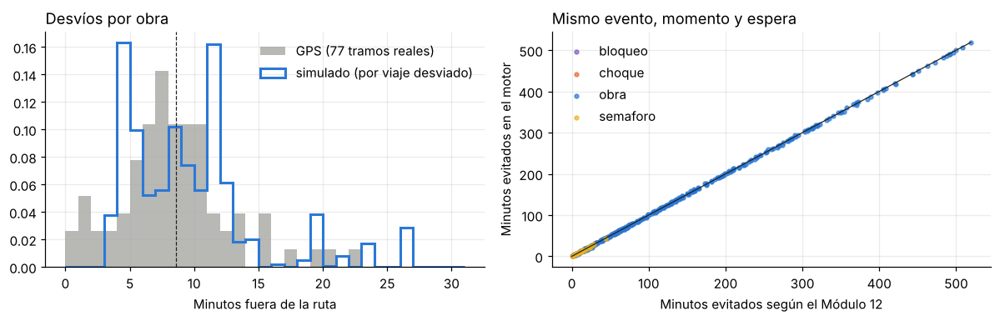

{'cierres_revisados': 44, 'replicas': 13, 'pasos_en_cierre': 0, 'pasos_tomando_alterna': 65, 'desvios_comparados': 400, 'recomendacion_desviar_pct': 99.75, 'dif_mediana_min': -0.0010830346893477998, 'dif_abs_p95_min': 2.9921932042892365, 'dif_abs_mediana_pct': 0.895889016262339, 'evitados_m12_mediana_min': 74.63156729129284}
Cierres reportados por un bus: 82; minutos desde el inicio hasta el reporte (mediana): 3.4
Acción de los buses ante un cierre: {'desvio': 2296, 'desvio_tras_reporte': 254, 'espera': 67}


In [4]:
o = V.obra_minutos(); display(o.round(2))
a = V.leer("central_laboral", "afectaciones"); d = a[(a.tipo == "obra") & a.accion.str.startswith("desvio")]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
b = np.arange(0, 32, 1)
ax[0].hist(z.minutos_fuera.clip(upper=31), bins=b, density=True, color=GRIS, alpha=.6, label="GPS (77 tramos reales)")
ax[0].hist(d.minutos_fuera_ruta.clip(upper=31), bins=b, density=True, histtype="step", lw=2, color=CT["obra"], label="simulado (por viaje desviado)")
ax[0].axvline(V.REF_OBRA_MIN, color="#1f1f1d", lw=.8, ls="--"); ax[0].set_xlabel("Minutos fuera de la ruta"); ax[0].legend(frameon=False)
ax[0].set_title("Desvíos por obra", loc="left")
cm = pd.read_csv(SAL / "consistencia_m12_13_3.csv")
for tp, g in cm.groupby("tipo"):
    ax[1].scatter(g.evitados_m12, g.evitados_sim, s=10, color=CT.get(tp, GRIS), label=tp, alpha=.7)
mx = cm[["evitados_m12", "evitados_sim"]].max().max(); ax[1].plot([0, mx], [0, mx], color="#1f1f1d", lw=.8)
ax[1].set_xlabel("Minutos evitados según el Módulo 12"); ax[1].set_ylabel("Minutos evitados en el motor"); ax[1].legend(frameon=False)
ax[1].set_title("Mismo evento, momento y espera", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_3_desvios.png", dpi=200, bbox_inches="tight"); plt.show()
print(V.reenrutamiento())
im = V.leer("central_laboral", "imprevistos")
cer = im[np.isfinite(im.conocido_s)]
print(f"Cierres reportados por un bus: {len(cer)}; minutos desde el inicio hasta el reporte (mediana): {((cer.conocido_s - cer.inicio_s) / 60 - 122 / 60).median():.1f}")
print("Acción de los buses ante un cierre:", a[a.accion.isin(["desvio", "desvio_tras_reporte", "espera"])].accion.value_counts().to_dict())

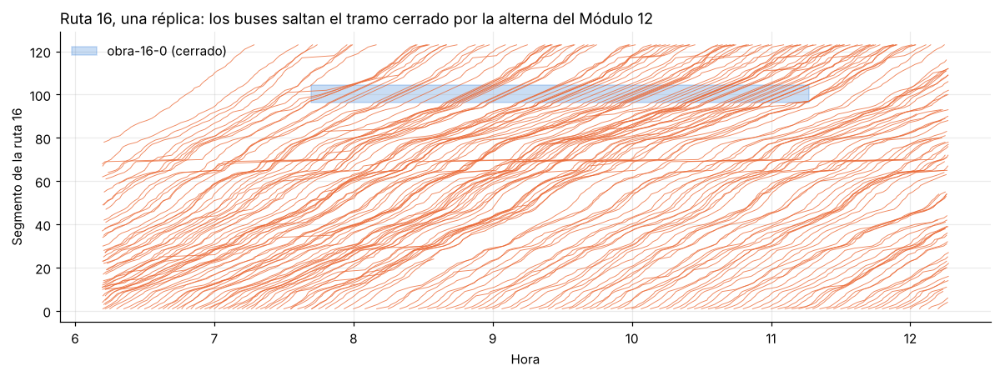

In [5]:
p = pd.read_parquet(SAL / "central_laboral_pasos_replica0.parquet")
ef = V.leer("central_laboral", "efectos").query("replica == 0"); im0 = im[im.replica == 0].set_index("id")
c = ef[np.isinf(ef.factor) & ef.desviar].merge(V.leer("central_laboral", "afectaciones").query("replica == 0").groupby(["id", "idruta"]).size()
                                             .rename("n").reset_index(), on=["id", "idruta"]).sort_values("n").iloc[-1]
r, kb = int(c.idruta), [int(x) for x in str(c.k_bloq).split(";")]
t0, t1 = im0.loc[c.id, "inicio_s"], im0.loc[c.id, "fin_s"]
x = p[(p.idruta == r) & (p.t_s >= t0 - 5400) & (p.t_s <= t1 + 3600)]
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, g in x.groupby("id_salida"):
    ax.plot(g.t_s / 3600, g.k + 1, color=COL[r], lw=.6, alpha=.8)
ax.fill_between([t0 / 3600, t1 / 3600], min(kb) + .5, max(kb) + 1.5, color=CT[im0.loc[c.id, "tipo"]], alpha=.25, label=f"{c.id} (cerrado)")
ax.set_xlabel("Hora"); ax.set_ylabel(f"Segmento de la ruta {r}"); ax.legend(frameon=False, loc="upper left")
ax.set_title(f"Ruta {r}, una réplica: los buses saltan el tramo cerrado por la alterna del Módulo 12", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_3_espacio_tiempo.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 3 · Los desvíos duran lo que en la calle y el motor decide como el Módulo 12**
- **Minutos fuera de la ruta por obra:** mediana **8,9 min, frente a 8,6 del GPS (+3 %)**, en 1.760 viajes desviados; criterio ±25 %. Por ruta se aleja más (ruta 2: 5,5 frente a 7,2; ruta 16: 11,0 frente a 7,8; ruta 21: 8,5 frente a 9,0), porque con 15 a 32 tramos reales por ruta el tramo que toca pesa mucho.
- **Mismo resultado que el Módulo 12:** en 400 desvíos, los minutos evitados del motor y los del Módulo 12 para el mismo evento, momento y espera difieren 0,9 % en la mediana (P95 de la diferencia: 3,0 min). El Módulo 12 recomienda desviarse en el 99,8 % de esos casos.
- **Nadie pasa por un cierre:** en 44 cierres de las primeras 20 réplicas, 0 pasos de bus entran a un tramo cerrado mientras dura; 65 llegan a él solo para tomar la alterna.
- **Quién se entera:** el primer bus llega al cierre 3,4 min después de que empieza (mediana), espera 2 min mientras reporta y toma la alterna. En 100 laborales hay 2.296 desvíos de buses que ya sabían, 254 de buses que reportaron y 67 esperas, cuando el cierre acaba antes de que el desvío ahorre tiempo.
- **Simplificación:** para decidir, el motor usa el tiempo que de verdad le queda al cierre; en la calle solo se conoce lo que estimó el conductor (LIMITACIONES §13).

## 4 · El efecto en la operación

,escenario,tipo,imprevistos_dia,viajes_afectados_dia,desvios_dia,esperas_dia,lentos_dia,minutos_mediana_por_afectacion,minutos_total_dia,pasajeros_a_bordo_dia
0,alta_laboral,bloqueo,0.37,13.53,7.73,0.40,8.47,2.23,43.08,151.63
1,alta_laboral,choque,1.80,35.67,14.00,1.43,32.23,0.70,97.78,503.37
2,alta_laboral,obra,1.30,85.77,44.30,1.10,109.80,1.05,424.66,2176.43
3,alta_laboral,semaforo,0.77,7.90,4.37,0.37,4.27,1.15,21.98,71.77
4,alta_laboral,varado,3.13,3.13,0.00,0.00,0.00,NaN,0.00,38.10
0,baja_laboral,bloqueo,0.13,4.83,1.20,0.23,4.60,1.53,15.93,90.27
1,baja_laboral,choque,0.33,6.47,2.63,0.10,6.10,1.09,14.20,81.73
2,baja_laboral,obra,0.70,36.93,9.00,0.00,62.50,0.95,110.86,1240.40
3,baja_laboral,semaforo,0.13,0.73,0.00,0.17,0.57,0.82,1.39,4.77
4,baja_laboral,varado,2.07,2.07,0.00,0.00,0.00,NaN,0.00,26.80


Salidas que no se hacen por falta de bus (por día): {'alta_laboral': 0.0, 'baja_laboral': 0.0, 'central_domingo': 0.0, 'central_laboral': 0.0, 'central_sabado': 0.0, 'control_laboral': 0.0, 'evento_2025-06-06': 0.3, 'lluvia_2025-09-19': 0.0}


,idruta,franja_salida,sin_med,sin_p90,con_med,con_p90
0,2,madrugada,224.5,260.2,224.7,263.1
1,2,noche,179.1,209.0,180.1,207.4
2,2,pico_am,263.1,307.0,263.4,304.6
3,2,pico_pm,227.8,259.2,225.2,256.2
4,2,valle_am,249.0,279.8,252.9,287.3
5,2,valle_pm,274.0,310.5,276.4,312.1
6,16,madrugada,198.9,235.1,198.3,234.5
7,16,noche,167.0,191.3,168.2,194.5
8,16,pico_am,247.9,283.7,248.0,283.5
9,16,pico_pm,201.9,229.6,201.4,228.7


Viajes tocados por algún imprevisto: 12.5 % · minutos perdidos por viaje tocado (sin varadas): {'50%': 1.9, '90%': 9.1, 'max': 62.2}
Minutos perdidos por día en las 3 rutas: 208.6 · por viaje del día: 0.37
Celdas con la mediana a ±5 % y la P90 a ±10 % de la maestra: {'central_domingo': {'sum': 16, 'size': 18}, 'central_laboral': {'sum': 18, 'size': 18}, 'central_sabado': {'sum': 18, 'size': 18}, 'control_laboral': {'sum': 18, 'size': 18}}
Error máximo |%| (mediana / P90): {'central_domingo': {'error_pct': 2.5, 'error_p90_pct': 11.0}, 'central_laboral': {'error_pct': 1.9, 'error_p90_pct': 7.6}, 'central_sabado': {'error_pct': 2.6, 'error_p90_pct': 6.5}, 'control_laboral': {'error_pct': 2.2, 'error_p90_pct': 6.7}}


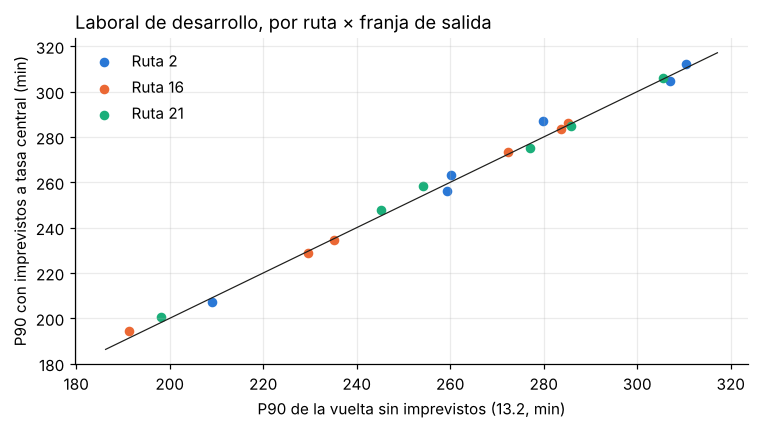

In [6]:
ef = pd.concat([V.efectos(n) for n in V.escenarios()])
display(ef[ef.escenario.isin(["central_laboral", "baja_laboral", "alta_laboral"])].round(2))
print("Salidas que no se hacen por falta de bus (por día):", {n: round(V.salidas_perdidas(n), 2) for n in V.escenarios()})
vs = V.vuelta_sin_con()
display(vs.round(1))
v = V.leer("central_laboral", "viajes"); a = V.leer("central_laboral", "afectaciones")
af = a.groupby(["replica", "idruta", "id_salida"]).minutos.sum(min_count=1).rename("min_imprevisto").reset_index()
v = v.merge(af, on=["replica", "idruta", "id_salida"], how="left")
v["afectado"] = v.min_imprevisto.notna() | v.varado
print(f"Viajes tocados por algún imprevisto: {100 * v.afectado.mean():.1f} % · minutos perdidos por viaje tocado (sin varadas):",
      v.min_imprevisto.dropna().clip(lower=0).describe(percentiles=[.5, .9])[["50%", "90%", "max"]].round(1).to_dict())
print("Minutos perdidos por día en las 3 rutas:", round(v.min_imprevisto.clip(lower=0).sum() / v.replica.nunique(), 1),
      "· por viaje del día:", round(v.min_imprevisto.clip(lower=0).sum() / len(v), 2))
vu = pd.concat([V.vuelta(n) for n in ("central_laboral", "central_sabado", "central_domingo", "control_laboral")])
print("Celdas con la mediana a ±5 % y la P90 a ±10 % de la maestra:",
      vu.assign(ok=(vu.error_pct.abs() <= 5) & (vu.error_p90_pct.abs() <= 10)).groupby("escenario").ok.agg(["sum", "size"]).to_dict("index"))
print("Error máximo |%| (mediana / P90):", vu.groupby("escenario")[["error_pct", "error_p90_pct"]].agg(lambda s: s.abs().max()).round(1).to_dict("index"))
fig, ax = plt.subplots(figsize=(7, 4))
for rr in (2, 16, 21):
    y = vs[vs.idruta == rr]; ax.scatter(y.sin_p90, y.con_p90, color=COL[rr], s=28, label=f"Ruta {rr}")
lo, hi = vs[["sin_p90", "con_p90"]].min().min() - 5, vs[["sin_p90", "con_p90"]].max().max() + 5
ax.plot([lo, hi], [lo, hi], color="#1f1f1d", lw=.8); ax.set_xlabel("P90 de la vuelta sin imprevistos (13.2, min)")
ax.set_ylabel("P90 con imprevistos a tasa central (min)"); ax.legend(frameon=False)
ax.set_title("Laboral de desarrollo, por ruta × franja de salida", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_3_vuelta.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 4 · Un imprevisto pesa mucho en el viaje que toca, poco en el día**
- **Un laboral a tasa central** tiene 2,2 imprevistos de vía y 2,4 varadas, y toca el **12,5 %** de los viajes (9,1 % a tasa baja y 24,6 % a tasa alta).
- **Por viaje tocado** (sin varadas), se pierden 1,9 min en la mediana, 9,1 en el P90 y hasta 62 min. En el día, son 210 min en las 3 rutas: el 79 % por obras.
- **La vuelta casi no cambia:** la mediana queda a ±5 % de la maestra en las 72 celdas (máx. 2,6 %), sin recalibrar.
- **La P90 de la vuelta** queda a ±10 % en 70 de 72 celdas. Las 2 que no cumplen son la madrugada del domingo de las rutas 2 y 21 (+11,0 % las dos), donde ya sin imprevistos daban +8,9 y +8,2 % en la 13.2: es la variación de más que la 13.2 dejó anotada (O6), no un efecto de los imprevistos.
- **Por qué es coherente:** las vueltas reales de la maestra ya incluyen los imprevistos y la 13.2 ya las reproducía. Los imprevistos se notan en el viaje que tocan, no en la mediana del día.

## 5 · Pasajeros: varadas, tramos saltados y eventos masivos

In [7]:
c = pd.concat([V.conservacion(n) for n in V.escenarios()])
display(c.groupby("escenario")[["subidos", "bajados", "esperan_tras_varada", "bajan_por_varada", "reabordan"]].sum()
        .assign(conserva=c.groupby("escenario").conserva.all()))
a = V.leer("central_laboral", "afectaciones"); nrep = V.leer("central_laboral", "info").replica.nunique()
var = a[a.accion == "varada"]
print(f"Varadas por día: {len(var) / nrep:.2f}; pasajeros a bordo al vararse (mediana): {var.pasajeros_a_bordo.median():.0f}; "
      f"hora (mediana): {var.t_s.median() / 3600:.1f} h")
sv = pd.concat([V.leer(n, "pasajeros").assign(escenario=n) for n in ("central_laboral", "alta_laboral")])
s0 = pd.read_parquet(E.SAL / "real_laboral_pasajeros.parquet").assign(escenario="sin imprevistos (13.2)")
x = pd.concat([s0, sv]); x["pct_sin_subir_con_servicio"] = 100 * x.sin_subir_con_servicio / x.llegados
display(x.groupby(["escenario", "idruta"])[["espera_media_min", "espera_p90_min", "pct_sin_subir_con_servicio"]].mean().round(2))
ev = V.leer("evento_2025-06-06", "imprevistos"); print("Evento masivo 6-jun:", ev[ev.tipo == "evento"].groupby("id").size().index.tolist()[:8])

,subidos,bajados,esperan_tras_varada,bajan_por_varada,reabordan,conserva
escenario,,,,,,
alta_laboral,1416614,1416614,0,1143,1143,True
baja_laboral,1417667,1417667,0,804,804,True
central_domingo,640104,640104,0,292,292,True
central_laboral,4722033,4722033,0,2870,2870,True
central_sabado,1124582,1124582,0,843,843,True
control_laboral,1418009,1418009,0,974,974,True
evento_2025-06-06,1434727,1434727,0,1256,1256,True
lluvia_2025-09-19,1417299,1417299,0,960,960,True


Varadas por día: 2.43; pasajeros a bordo al vararse (mediana): 10; hora (mediana): 10.6 h


espera_media_min  espera_p90_min  pct_sin_subir_con_servicio
escenario              idruta                                                              
alta_laboral           2                   6.25           13.17                        0.00
                       16                  3.92            8.56                        0.01
                       21                 10.76           22.28                        0.00
central_laboral        2                   6.00           13.03                        0.00
                       16                  3.86            8.50                        0.00
                       21                 10.32           21.81                        0.00
sin imprevistos (13.2) 2                   5.63           12.61                        0.00
                       16                  3.79            8.51                        0.00
                       21                  9.70           20.96                        0.00

Evento masivo 6-jun: ['evento-16-cierre-108', 'evento-16-lento-107', 'evento-16-lento-12', 'evento-2-cierre-121', 'evento-2-lento-12', 'evento-2-lento-120', 'evento-2-lento-123', 'evento-21-cierre-114']


**Conclusión 5 · Nadie se pierde: el que baja de un bus varado sube al siguiente**
- **Conservación exacta** en los 8 escenarios: 13,6 millones de pasajeros suben y todos se bajan; ninguno queda en la fila al final del día. Cada imprevisto tiene su fin.
- **Varadas:** 2,4 por laboral, a las 10,6 h en la mediana, con 10 pasajeros a bordo en la mediana. Todos (28,7 por día) reabordan el siguiente bus de su ruta, primeros en la fila.
- **No se pierden salidas:** el reemplazo de la 13.2 cubre las salidas de los buses varados. La excepción es el día del evento masivo, con 0,3 salidas por día sin bus.
- **Espera en el paradero:** sube poco con imprevistos a tasa central, de 5,6 a 6,0 min en la ruta 2, de 3,8 a 3,9 en la 16 y de 9,7 a 10,3 en la 21. Quien espera en un tramo que se salta un desvío aguarda al siguiente bus que pasa. Casi nadie se queda sin subir (≤ 0,01 %).

## 6 · Un día de lluvia y uno de evento masivo

,escenario,vuelta_mediana,vuelta_p90,imprevistos_dia,arroyos_dia,tramos_evento_dia,viajes_afectados_%
0,control_laboral,236.98,282.80,2.67,0.0,0.0,18.01
1,central_laboral,239.90,283.99,2.24,0.0,0.0,12.48
2,lluvia_2025-09-19,242.16,288.42,4.67,2.0,0.0,20.72
3,evento_2025-06-06,243.87,289.91,13.63,0.0,11.0,54.03


Lluvia del 19-sep (mm/h, 4–21 h): [0.0, 0.0, 0.0, 0.0, 0.0, 0.2, 0.2, 0.5, 13.3, 3.4, 0.1, 0.2, 0.1, 0.0, 0.0, 0.0, 0.0, 0.0]
Factor de los tiempos por hora: [1.0, 1.0, 1.0, 1.0, 1.0, 1.024, 1.024, 1.024, 1.081, 1.024, 1.024, 1.024, 1.024, 1.0, 1.0, 1.0, 1.0, 1.0]


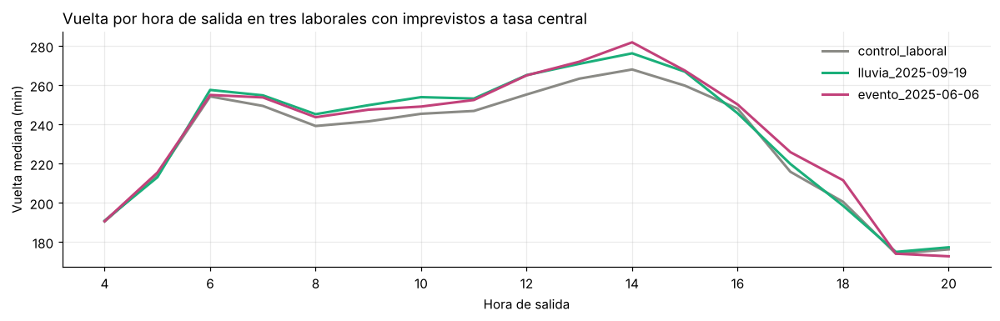

In [8]:
fil = []
for n in ("control_laboral", "central_laboral", "lluvia_2025-09-19", "evento_2025-06-06"):
    v = V.leer(n, "viajes"); im = V.leer(n, "imprevistos"); a = V.leer(n, "afectaciones"); nr = v.replica.nunique()
    fil.append({"escenario": n, "vuelta_mediana": v.vuelta_min.median(), "vuelta_p90": v.vuelta_min.quantile(.9),
                "imprevistos_dia": len(im) / nr, "arroyos_dia": (im.tipo == "arroyo").sum() / nr,
                "tramos_evento_dia": (im.tipo == "evento").sum() / nr,
                "viajes_afectados_%": 100 * a.drop_duplicates(["replica", "idruta", "id_salida"]).shape[0] / len(v)})
display(pd.DataFrame(fil).round(2))
print("Lluvia del 19-sep (mm/h, 4–21 h):", np.round(I.lluvia_del_dia("2025-09-19")[4:22], 1).tolist())
print("Factor de los tiempos por hora:", np.round(I.factores_lluvia("2025-09-19", P["factor_lluvia_13_1.csv"])[4:22], 3).tolist())
fig, ax = plt.subplots(figsize=(11, 3.6))
for n, col in (("control_laboral", GRIS), ("lluvia_2025-09-19", CT["arroyo"]), ("evento_2025-06-06", CT["evento"])):
    v = V.leer(n, "viajes"); g = v.groupby((v.salida_s // 3600).astype(int)).vuelta_min.median()
    ax.plot(g.index, g.values, color=col, lw=2, label=n)
ax.set_xlabel("Hora de salida"); ax.set_ylabel("Vuelta mediana (min)"); ax.legend(frameon=False)
ax.set_title("Vuelta por hora de salida en tres laborales con imprevistos a tasa central", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_3_dias_especiales.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 6 · La lluvia y el partido se notan en las horas en que ocurren**
- **Lluvia del 19-sep-2025** (13,3 mm/h a las 12 h): se forman los 2 arroyos de la calle 85 y los tiempos se alargan × 1,081 en esa hora (× 1,024 en las otras 7 horas con lluvia).
  - Toca el 20,7 % de los viajes, frente al 12,5 % del laboral de desarrollo y el 18,0 % del de control (cada día tiene su plan).
  - Vuelta mediana de 242 min, frente a 240 y 237.
  - El desvío por el arroyo cuesta poco (0,1 min de más en la mediana): la alterna de la calle 85 es casi igual de rápida.
- **Partido del 6-jun-2025** (15:30): 11 tramos cerca del estadio, cerrados o lentos de 1 h antes a 30 min después, y más demanda alrededor.
  - Toca el 54 % de los viajes, con vuelta mediana de 244 min y P90 de 290.
  - Es el único día con salidas sin bus (0,3 por día).
- **Para la 13.4:** el día de lluvia y el de evento de validación (13-jun y 25-mar) se simulan con lo que pasó ese día, igual que aquí.

## 7 · Rapidez y reproducibilidad

In [9]:
rp = V.rapidez()
display(rp.groupby("escenario").segundos.describe()[["count", "50%", "max"]].round(2))
print(f"{len(rp)} días · segundos por día de 3 rutas: mediana {rp.segundos.median():.2f}, máximo {rp.segundos.max():.2f}")
print("Python", sys.version.split()[0])

,count,50%,max
escenario,,,
alta_laboral,30.0,1.12,1.43
baja_laboral,30.0,1.00,1.22
central_domingo,30.0,0.68,0.93
central_laboral,100.0,0.99,1.40
central_sabado,30.0,0.90,1.09
control_laboral,30.0,1.02,1.28
evento_2025-06-06,30.0,1.64,1.90
lluvia_2025-09-19,30.0,1.02,1.41


310 días · segundos por día de 3 rutas: mediana 1.00, máximo 1.90
Python 3.13.16


**Conclusión 7 · Con imprevistos, un día sigue tardando alrededor de un segundo**
- **310 días simulados:** mediana de 1,00 s por día de las 3 rutas; el más lento, el día del evento masivo, 1,90 s. El objetivo era ≤ 30 s.
- **Por qué es rápido:** el resultado del Módulo 12 se calcula una sola vez por imprevisto y ruta, y lo usan todos los buses. El Módulo 12 se carga una vez por proceso (~10 s).
- **Reproducible:** misma semilla, mismo día. Los imprevistos tienen su propio flujo de azar, y sin imprevistos el motor da exactamente lo de la 13.2 (`tests_13_3.py` 14/14).

## Síntesis · Imprevistos en el motor
- **Qué hay:** obras sobre tramos reales del GPS, arroyos en la calle 85 con la lluvia del día, varadas por bus del Módulo 9, eventos masivos del calendario de SOBUSA, y choques, bloqueos y semáforos como supuestos. Cada uno tiene comienzo, efecto y fin.
- **Se cumplen los criterios del alcance:**
  - las tasas, en el sorteo y dentro del motor;
  - los desvíos duran lo que en el GPS (8,9 frente a 8,6 min);
  - los minutos evitados son los del Módulo 12 (0,9 %);
  - nadie pasa por un tramo cerrado;
  - la conservación es exacta;
  - la vuelta mediana queda a ±5 % en 72/72 celdas, sin recalibrar;
  - el motor tarda ≤ 1,9 s por día.
- **Con observación:** la P90 de la vuelta cumple en 70 de 72 celdas; las 2 de la madrugada del domingo ya venían de la 13.2.
- **Lo que dicen los resultados:** en un laboral típico, los imprevistos tocan el 12,5 % de los viajes, que pierden ~2 min en la mediana y ~9 en el P90. Casi no mueven la vuelta del día. Pesan más el día de un partido (54 % de los viajes) o de lluvia fuerte (21 %).
- **Decisiones de Claude I1–I9:** confirmadas por la Persona 3 (4-nov-2026, 22:03); detalle en `revisiones/revision_13_3.md`.
- **Siguiente:** la 13.4 corre el Monte Carlo y valida contra los 6 días congelados, con los imprevistos de lo que pasó cada día.

<a id="m13-4"></a>

### A2.5.4 &middot; Subfase 13.4 · Monte Carlo y validación

<sub>Notebook original: `modulo13/subfase_13_4_montecarlo.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 13 · Subfase 13.4 — Monte Carlo y validación

**Persona 3.** Primero se valida el simulador contra los 6 días completos de 2025 que se congelaron en la 13.1, con una
sola evaluación y la configuración congelada antes. Después se corre el Monte Carlo de los escenarios: cada resultado
con su intervalo P5–P95 entre réplicas. Alcance aprobado: `revisiones/alcance_13_4.md`.

| Pieza | Qué hace | Dónde |
|---|---|---|
| Motor Monte Carlo | N réplicas hasta converger; indicadores con intervalo; réplica representativa | `src/simulation/monte_carlo_engine.py` |
| Factor de demanda del día | Variación entre días del mismo tipo (enmienda de la 13.1) | `variacion_dia_13_1.csv` |
| Validación | Configuración congelada y evaluación única de los 6 días | `validar_13_4.py`, `config_13_4.json`, `datos_13/validacion_13_4/` |
| Escenarios | Planes × tipos de día × imprevistos × demanda, y sensibilidades | `montecarlo_13_4.py`, `datos_13/montecarlo_13_4/` |
| Buses pegados con y sin regulación | 30 réplicas de 4 escenarios laborales con sus pasos | `intervalos_13_4.py` → `intervalos_regulacion_13_4.csv` |

Después de la evaluación única se agregaron al motor opciones de escenario (sensibilidades y regulación), inactivas por
defecto; el código enmendado reproduce la evaluación réplica a réplica (`datos_13/validacion_13_4/enmiendas_codigo_13_4.json`).

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, ".")
from src.simulation import escenario as E, monte_carlo_engine as M
import validar_13_4 as VA

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
VAL, MC = VA.OUT, Path("datos_13/montecarlo_13_4"); FIG = Path("resultados_13"); FIG.mkdir(exist_ok=True)
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a"}; GRIS = "#8a8a85"
CP = {"real": "#1f1f1d", "p100": "#2a78d6", "p85": "#eb6834", "p70": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10, "figure.dpi": 110})
cfg = json.loads(VA.CONFIG.read_text(encoding="utf-8")); res = json.loads(VA.RESULTADOS.read_text(encoding="utf-8"))
man = json.loads((MC / "manifiesto_montecarlo_13_4.json").read_text(encoding="utf-8"))
print("Configuración congelada:", cfg["creado"], "· hash", VA.sha(VA.CONFIG)[:12], "· evaluación:", res["inicio"], "→", res["fin"])
print("Hash de la configuración en los resultados = el congelado:", res["config_sha256"] == VA.sha(VA.CONFIG))
print("Monte Carlo:", len(man["escenarios"]), "escenarios ·", man.get("completado"))
enm = json.loads((VAL / "enmiendas_codigo_13_4.json").read_text(encoding="utf-8"))
print("Código enmendado después de la evaluación:", ", ".join(enm["archivos"]), "·", enm["comprobacion"][:120], "…")
P = E.cargar_parametros()

Configuración congelada: 2026-11-04T22:23:05 · hash 3fd010acb523 · evaluación: 2026-11-04T22:23:06 → 2026-11-04T23:25:51
Hash de la configuración en los resultados = el congelado: True
Monte Carlo: 54 escenarios · 2026-11-05T08:14:50
Código enmendado después de la evaluación: src/simulation/motor.py, src/simulation/escenario.py, src/simulation/imprevistos.py · Con el código actual, las 2 primeras réplicas de los 6 días de validación (demanda pred) dan indicadores y MAE idénticos …


## 1 · Cuánto cambia la demanda de un día a otro

Cada réplica del Monte Carlo sortea un **factor de demanda del día**: uno común a las 3 rutas (días de más y de menos
gente) por uno propio de cada ruta, gammas con media 1. Su dispersión sale de los días de 2025 de cada tipo, sin los de
validación (enmienda de la 13.1). Incluye la variación del número de salidas de cada día.

In [2]:
display(P["variacion_dia_13_1.csv"].round(3))
r = pd.read_csv(MC / "resumen_13_4.csv")
x = r[(r.idruta == "total") & r.escenario.isin(["sens_sin_variacion_dia_real", "real_laboral_central"]) & r.indicador.isin(["pasajeros", "espera_media_min", "pct_viajes_cupo"])]
display(x.pivot(index="indicador", columns="escenario", values=["p5", "media", "p95"]).round(2))

,tipo_dia,idruta,n_dias,cv_comun,cv_propio,cv_total
0,domingo_festivo,2,66,0.120,0.050,0.118
1,domingo_festivo,16,66,0.120,0.038,0.122
2,domingo_festivo,21,66,0.120,0.050,0.141
3,laboral,2,239,0.099,0.030,0.109
4,laboral,16,239,0.099,0.027,0.101
5,laboral,21,239,0.099,0.030,0.099
6,sabado,2,50,0.080,0.024,0.082
7,sabado,16,50,0.080,0.027,0.090
8,sabado,21,50,0.080,0.030,0.081


p5                                            media                                              p95                            
escenario        real_laboral_central sens_sin_variacion_dia_real real_laboral_central sens_sin_variacion_dia_real real_laboral_central sens_sin_variacion_dia_real
indicador                                                                                                                                                          
espera_media_min                 4.99                        5.10                 5.72                        5.62                 7.06                        6.61
pasajeros                    39451.95                    46859.90             47188.81                    47221.60             55046.20                    47568.05
pct_viajes_cupo                 13.28                       21.18                24.07                       23.43                36.27                       25.50

**Conclusión 1 · La demanda cambia un 8–14 % de un día a otro del mismo tipo**
- **De dónde sale:** los días de 2025 de cada tipo, sin los de validación (239 laborales, 50 sábados y 66 domingos o festivos). La variación total por ruta va de 8–14 %: la mayor parte es común a las 3 rutas (CV 0,099 en laboral, 0,080 en sábado, 0,120 en domingo) y una parte pequeña es propia de cada ruta (0,024–0,050).
- **Lo que cambia en el Monte Carlo:** con el factor del día, los pasajeros de un laboral con el plan real van de 39.452–55.046 (P5–P95); sin él, de 46.860–47.568. El % de viajes que llegan al cupo va de 13,3–36,3 %, frente a 21,2–25,5 % sin el factor.
- **Las medias casi no se mueven** (espera 5,6 frente a 5,7 min): el factor no sesga, ensancha el intervalo hasta lo que de verdad varía un día.
- **Por eso no se llega al 1 % del IC95 %** en la espera y el cupo (conclusión 7): los días de verdad son distintos entre sí.

## 2 · Validación: la ocupación de los 6 días congelados

Cada día se simula con su plan real, la demanda que el modelo 04:00 predijo para ese día (lo que se sabía a las
04:00) y sus imprevistos (la lluvia del 13-jun, el partido del 25-mar y los de tasa central). Como diagnóstico, también
con la demanda real del día. Se compara la carga a bordo por ruta × segmento × hora con lo observado, y se pone al
lado el perfil histórico de la muestra de calibración del mismo tipo de día.

,rol,fecha,demanda,celdas,a_bordo_obs_media,mae_sim,mae_hist,mae_sim_rel,mae_hist_rel,cobertura_p5_p95,corr_sim,corr_hist
3,laboral_1,2025-11-25,pred,6345,13.718,3.921,3.900,0.286,0.284,49.913,0.849,0.864
7,laboral_1,2025-11-25,real,6344,13.715,3.976,3.899,0.290,0.284,50.016,0.851,0.864
11,laboral_2,2025-04-03,pred,6316,15.558,4.691,3.706,0.301,0.238,46.881,0.834,0.891
15,laboral_2,2025-04-03,real,6314,15.562,4.732,3.706,0.304,0.238,46.468,0.829,0.891
19,sabado,2025-02-15,pred,5789,13.749,3.915,4.627,0.285,0.337,48.679,0.865,0.769
23,sabado,2025-02-15,real,5800,13.731,3.658,4.621,0.266,0.337,51.500,0.867,0.769
27,domingo,2025-07-27,pred,5504,9.292,2.789,4.515,0.300,0.486,54.669,0.799,0.555
31,domingo,2025-07-27,real,5505,9.293,2.765,4.515,0.298,0.486,53.933,0.805,0.555
35,lluvia_fuerte,2025-06-13,pred,6268,12.813,3.453,3.937,0.269,0.307,54.308,0.870,0.874
39,lluvia_fuerte,2025-06-13,real,6277,12.808,3.465,3.935,0.271,0.307,54.516,0.870,0.874


{'laboral_1_pred': (500, False), 'laboral_1_real': (500, False), 'laboral_2_pred': (500, False), 'laboral_2_real': (500, False), 'sabado_pred': (500, False), 'sabado_real': (500, False), 'domingo_pred': (500, False), 'domingo_real': (500, False), 'lluvia_fuerte_pred': (500, False), 'lluvia_fuerte_real': (500, False), 'evento_masivo_pred': (500, False), 'evento_masivo_real': (500, False)}
Días en que el simulador no es peor que el perfil histórico (demanda 04:00): 3 de 6


mae_sim             mae_hist            
idruta             16     2    21       16     2    21
rol                                                   
domingo          2.84  2.44  3.12     3.85  4.95  4.62
evento_masivo    5.94  5.67  5.61     4.07  5.00  5.10
laboral_1        3.90  3.87  4.00     3.60  3.90  4.18
laboral_2        4.35  4.08  5.64     3.22  3.27  4.61
lluvia_fuerte    3.15  3.32  3.88     3.33  3.86  4.59
sabado           4.06  3.74  3.96     4.93  4.24  4.74

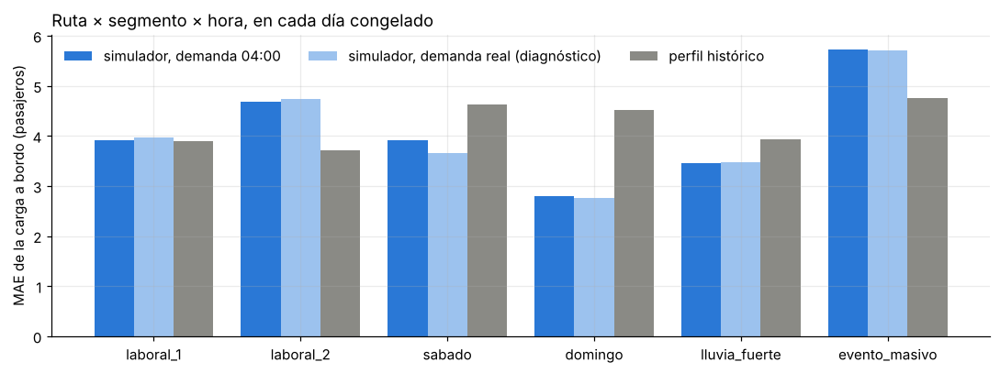

In [3]:
m = pd.read_csv(VAL / "mae_13_4.csv")
t = m[m.idruta == "total"]
display(t[["rol", "fecha", "demanda", "celdas", "a_bordo_obs_media", "mae_sim", "mae_hist", "mae_sim_rel", "mae_hist_rel",
           "cobertura_p5_p95", "corr_sim", "corr_hist"]].round(3))
print({k: (v["replicas"], v["convergio"]) for k, v in res["dias"].items()})
print("Días en que el simulador no es peor que el perfil histórico (demanda 04:00):", res["dias_sim_no_peor"], "de 6")
display(m[(m.idruta != "total") & (m.demanda == "pred")].pivot(index="rol", columns="idruta", values=["mae_sim", "mae_hist"]).round(2))
fig, ax = plt.subplots(figsize=(10, 3.8))
p = t[t.demanda == "pred"].reset_index(drop=True); q = t[t.demanda == "real"].reset_index(drop=True)
xx = np.arange(len(p))
ax.bar(xx - .27, p.mae_sim, .27, color="#2a78d6", label="simulador, demanda 04:00")
ax.bar(xx, q.mae_sim, .27, color="#9cc2ee", label="simulador, demanda real (diagnóstico)")
ax.bar(xx + .27, p.mae_hist, .27, color=GRIS, label="perfil histórico")
ax.set_xticks(xx, p.rol); ax.set_ylabel("MAE de la carga a bordo (pasajeros)"); ax.legend(frameon=False, ncols=3, loc="upper left")
ax.set_title("Ruta × segmento × hora, en cada día congelado", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_4_mae.png", dpi=200, bbox_inches="tight"); plt.show()

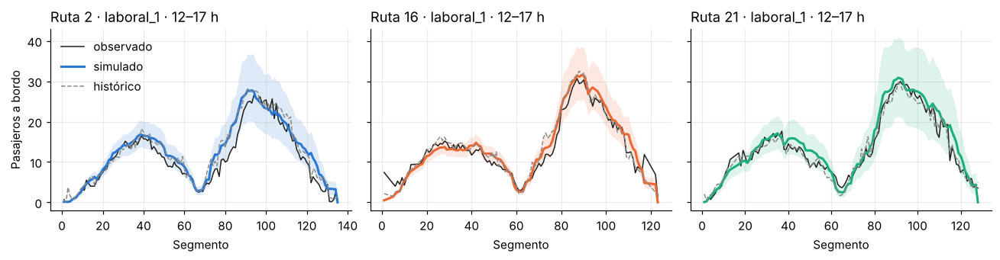

In [4]:
c = pd.read_parquet(VAL / "celdas_13_4.parquet")
c = c[(c.demanda == "pred") & (c.rol == "laboral_1")]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, r in zip(ax, (2, 16, 21)):
    y = c[(c.idruta == r) & (c.hora.between(12, 16))].groupby("nro_segmento")[["a_bordo_media", "a_bordo_sim", "a_bordo_hist", "p5", "p95"]].mean()
    a.fill_between(y.index, y.p5, y.p95, color=COL[r], alpha=.15, lw=0)
    a.plot(y.index, y.a_bordo_media, color="#1f1f1d", lw=1, label="observado")
    a.plot(y.index, y.a_bordo_sim, color=COL[r], lw=2, label="simulado")
    a.plot(y.index, y.a_bordo_hist, color=GRIS, lw=1, ls="--", label="histórico")
    a.set_title(f"Ruta {r} · laboral_1 · 12–17 h", loc="left"); a.set_xlabel("Segmento")
ax[0].set_ylabel("Pasajeros a bordo"); ax[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "m13_4_perfil_validacion.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 2 · La ocupación simulada frente a la de los días congelados**
- **Evaluación única, a ciegas:** configuración congelada el 4-nov-2026 a las 22:23 (hash `3fd010ac…`), evaluada a las 22:23–23:25, sin repetir. 6 días, 500 réplicas cada uno, 5.504–6.345 celdas ruta × segmento × hora por día.
- **MAE de la carga a bordo (demanda 04:00), simulador frente a perfil histórico:**

  | Día | MAE (pasajeros) | Resultado |
  |---|---|---|
  | laboral_1 (25-nov) | 3,92 frente a 3,90 | empate (+0,02) |
  | laboral_2 (3-abr) | 4,69 frente a 3,71 | peor |
  | sábado (15-feb) | 3,91 frente a 4,63 | mejor |
  | domingo (27-jul) | 2,79 frente a 4,51 | mejor |
  | lluvia fuerte (13-jun) | 3,45 frente a 3,94 | mejor |
  | evento masivo (25-mar) | 5,73 frente a 4,75 | peor |

- **Criterio del alcance (≤ en 5 de 6 días): no se cumple, 3 de 6.** Se reporta tal cual y no se recalibra mirando estos días (punto 8 del alcance).
- **Dónde gana:** en el fin de semana y la lluvia, donde el perfil histórico (promedio de muchos días) se aleja más del día concreto. **Dónde pierde:** en los laborales y el día del partido.
- **El error viene del motor, no del pronóstico:** con la demanda real del día el MAE queda en 2,77–5,71, casi igual.
- **Dónde está el error:** en la punta de la mañana (6–9 h) el simulador lleva menos gente a bordo de la observada: −7,9 y −9,5 pasajeros en laboral_2 y el día del partido. Esas horas son el 17 % de las celdas y el 26 % del error. Fuera de ellas, el simulador no es peor que el histórico en 4 de 6 días. Hipótesis (no comprobada con estos días): en temporada escolar los viajes de la mañana son más largos que en la muestra de calibración.
- **Forma del perfil:** correlación con lo observado 0,80–0,87, y MAE relativo de 27–34 % de la carga media de la celda.
- **Intervalo:** lo observado cae dentro del P5–P95 de las réplicas en el 44,1–54,7 % de las celdas, lejos de la meta cercana al 90 %. Las réplicas dan la incertidumbre de la media de la celda, no la de lo que se observa en un día con pocas lecturas por celda.

## 3 · Validación: vueltas, pasajeros, cupo y buses pegados

In [5]:
s = pd.read_csv(VAL / "secundarias_13_4.csv")
sp = s[s.demanda == "pred"]
display(sp[["rol", "idruta", "vuelta_mediana_min", "vuelta_mediana_real", "err_vuelta_pct", "pasajeros_por_viaje",
            "pasajeros_por_viaje_real", "err_pasajeros_pct", "pct_viajes_cupo", "pct_viajes_cupo_real"]].round(1))
print("Vuelta ±10 %:", int((sp.err_vuelta_pct.abs() <= 10).sum()), "de", len(sp), "· pasajeros ±10 %:", int((sp.err_pasajeros_pct.abs() <= 10).sum()), "de", len(sp))
display(sp[["rol", "idruta", "cv_intervalos", "cv_intervalos_real", "pct_intervalos_menos_1min", "pct_intervalos_menos_1min_real", "viajes_gps_mitad"]].round(2))
print("Media de los 6 días por ruta (simulado frente al GPS):")
display(sp.groupby("idruta")[["cv_intervalos", "cv_intervalos_real", "pct_intervalos_menos_1min", "pct_intervalos_menos_1min_real"]].mean().round(2))

,rol,idruta,vuelta_mediana_min,vuelta_mediana_real,err_vuelta_pct,pasajeros_por_viaje,pasajeros_por_viaje_real,err_pasajeros_pct,pct_viajes_cupo,pct_viajes_cupo_real
0,laboral_1,16,236.0,241.7,-2.4,92.6,85.8,8.0,32.1,23.4
1,laboral_1,2,250.2,259.0,-3.4,87.2,75.8,15.1,26.4,10.8
2,laboral_1,21,240.7,250.2,-3.8,90.9,85.4,6.5,23.0,14.6
6,laboral_2,16,234.2,233.3,0.4,91.1,91.2,-0.1,27.1,22.8
7,laboral_2,2,246.4,245.5,0.4,88.4,88.3,0.2,28.4,20.4
8,laboral_2,21,238.6,235.5,1.3,93.7,91.8,2.0,28.3,20.2
12,sabado,16,224.0,228.6,-2.0,81.8,85.9,-4.8,18.8,16.1
13,sabado,2,242.0,254.7,-5.0,73.5,81.8,-10.1,10.9,5.5
14,sabado,21,230.3,234.0,-1.6,79.0,78.3,0.9,14.1,8.0
18,domingo,16,172.7,177.7,-2.8,57.3,53.1,7.8,4.7,1.5


Vuelta ±10 %: 18 de 18 · pasajeros ±10 %: 14 de 18


,rol,idruta,cv_intervalos,cv_intervalos_real,pct_intervalos_menos_1min,pct_intervalos_menos_1min_real,viajes_gps_mitad
0,laboral_1,16,0.96,0.96,25.49,20.09,235
1,laboral_1,2,0.95,0.84,14.83,11.20,126
2,laboral_1,21,0.85,0.63,8.76,1.32,77
6,laboral_2,16,0.97,0.96,27.72,28.92,250
7,laboral_2,2,0.95,0.83,15.50,11.50,114
8,laboral_2,21,0.89,0.72,9.45,6.76,75
12,sabado,16,0.95,0.88,24.13,23.56,226
13,sabado,2,0.90,0.70,12.90,8.18,111
14,sabado,21,0.82,0.65,6.85,4.48,68
18,domingo,16,0.85,0.74,16.99,13.29,174


Media de los 6 días por ruta (simulado frente al GPS):


,cv_intervalos,cv_intervalos_real,pct_intervalos_menos_1min,pct_intervalos_menos_1min_real
idruta,,,,
2,0.93,0.77,13.91,7.67
16,0.95,0.90,24.71,21.51
21,0.84,0.64,7.66,4.23


**Escenario de regulación** (agregado tras la validación, punto 8 del alcance; Daganzo 2009, FUENTES B8): en el segmento
de la mitad del circuito, un bus que llega pegado al anterior espera hasta que pase el 60 % del intervalo programado, con un
máximo de 5 min. Es un escenario aparte: la validación no se vuelve a evaluar. Se mide en 30 réplicas de un laboral de
desarrollo (no de validación) y se compara con los 2 laborales de validación del GPS.

In [6]:
iv = pd.read_csv(MC / "intervalos_regulacion_13_4.csv")
q = iv.groupby(["escenario", "idruta"]).agg(cv=("cv_intervalos", "mean"), menos_1min=("pct_intervalos_menos_1min", "mean"),
                                            menos_1min_p5=("pct_intervalos_menos_1min", lambda s: s.quantile(.05)),
                                            menos_1min_p95=("pct_intervalos_menos_1min", lambda s: s.quantile(.95))).round(2)
display(q)
g = sp[sp.rol.isin(["laboral_1", "laboral_2"])].groupby("idruta")[["cv_intervalos_real", "pct_intervalos_menos_1min_real"]].agg(["min", "max"]).round(2)
print("GPS de los 2 laborales de validación (mín–máx):"); display(g)

cv  menos_1min  menos_1min_p5  menos_1min_p95
escenario            idruta                                                 
p85_laboral_central  2       0.90       11.31           8.29           14.86
                     16      0.95       22.79          19.14           27.20
                     21      0.78        6.36           2.99            9.61
real_laboral_central 2       0.94       15.13          10.84           18.98
                     16      0.97       27.57          24.16           32.42
                     21      0.85        8.06           4.42           11.98
sens_regulacion_p85  2       0.79        6.45           3.22            9.12
                     16      0.87       10.28           7.16           13.04
                     21      0.67        3.25           0.00            6.67
sens_regulacion_real 2       0.82        9.16           5.84           12.33
                     16      0.87       13.59          10.81           16.88
                     21      0.76        3.66           1.25            7.51

GPS de los 2 laborales de validación (mín–máx):


cv_intervalos_real       pct_intervalos_menos_1min_real       
                      min   max                            min    max
idruta                                                               
2                    0.83  0.84                          11.20  11.50
16                   0.96  0.96                          20.09  28.92
21                   0.63  0.72                           1.32   6.76

**Conclusión 3 · Vueltas, pasajeros y regularidad frente a lo real**
- **Vuelta mediana:** a ±5 % de la real en las 18 combinaciones de ruta × día (la mayor diferencia es 5,0 %). Meta ±10 %: cumple.
- **Pasajeros por viaje:** a ±10 % en 14 de 18 con la demanda 04:00. Fuera quedan laboral_1 ruta 2 (+15,1 %), sábado ruta 2 (−10,1 %), domingo ruta 21 (+11,1 %) y el partido en la ruta 2 (−11,6 %). Con la demanda real del día entran las 18: esas diferencias son del pronóstico del Entregable 1 para ese día, no del simulador.
- **Viajes que llegan al cupo:** el simulador da más que lo real, +6,2 puntos en la mediana (de −4,6 a +15,6). El simulador cuenta la carga máxima de cada segmento antes de que se baje la gente; en la calle se suben y se bajan a la vez.
- **Buses pegados** (intervalos < 1 min a la mitad del circuito, 6–20 h, media de los 6 días): ruta 2, 13,9 % frente a 7,7 % del GPS; ruta 16, 24,7 % frente a 21,5 %; ruta 21, 7,7 % frente a 4,2 %. En la calle los conductores se regulan; el motor no.
- **Escenario de regulación** (punto 8 del alcance, aparte de la validación): un bus pegado espera en la mitad del circuito hasta el 60 % del intervalo programado, máximo 5 min. En 30 réplicas de un laboral de desarrollo, los intervalos < 1 min pasan de 15,1 → 9,2 % en la ruta 2, 27,6 → 13,6 % en la 16 y 8,1 → 3,7 % en la 21. En los 2 laborales de validación, el GPS da 11,2–11,5 %, 20,1–28,9 % y 1,3–6,8 %: con la regulación el motor queda en el rango del GPS en las rutas 2 y 21, y algo por debajo en la 16.

## 4 · Monte Carlo: los planes con su intervalo

Réplicas por escenario: {'min': 350.0, '50%': 500.0, 'max': 500.0} · convergieron antes de 500: 2 de 54


,tipo,plan,espera_media_min,espera_p90_min,pct_dejados_bus_lleno,pct_viajes_cupo,vuelta_mediana_min,buses_a_la_vez,salidas
0,laboral,real,5.7 [5.0–7.1],12.3 [11.1–14.0],6.5 [3.5–9.9],24.1 [13.3–36.3],239.9 [237.5–242.6],175.5 [172.0–179.0],557.0 [557.0–557.0]
1,laboral,p100,8.4 [6.9–11.6],18.0 [15.4–22.6],12.3 [7.3–17.9],58.7 [35.3–84.8],242.7 [239.4–245.8],124.0 [122.0–127.0],382.0 [382.0–382.0]
2,laboral,p85,6.5 [5.8–7.9],14.2 [12.8–16.1],8.2 [4.6–12.4],38.5 [21.1–58.9],242.8 [240.0–245.9],145.4 [143.0–148.0],450.0 [450.0–450.0]
3,laboral,p70,5.2 [4.7–6.3],11.3 [10.5–12.3],4.7 [2.3–7.5],21.2 [10.6–33.5],242.6 [240.1–245.4],176.2 [173.0–180.0],547.0 [547.0–547.0]
4,sabado,real,5.9 [5.3–7.0],12.6 [11.8–13.8],4.1 [2.2–6.1],16.7 [9.4–24.7],229.3 [226.7–231.8],150.9 [147.0–154.0],478.0 [478.0–478.0]
5,sabado,p100,8.9 [8.0–10.4],19.3 [17.2–21.7],10.1 [6.3–14.3],54.8 [34.8–76.5],229.0 [226.1–232.1],95.8 [93.0–98.0],302.0 [302.0–302.0]
6,sabado,p85,7.3 [6.7–8.0],15.7 [14.5–17.1],6.4 [3.5–9.5],34.7 [20.3–50.4],229.0 [226.1–232.0],112.3 [110.0–115.0],355.0 [355.0–355.0]
7,sabado,p70,6.0 [5.5–7.0],12.9 [12.1–13.9],3.7 [2.1–5.7],19.0 [10.7–28.3],228.9 [226.4–231.9],135.4 [132.9–139.0],431.0 [431.0–431.0]
8,domingo,real,6.4 [6.0–7.3],13.6 [12.8–14.6],1.5 [0.4–3.0],6.3 [2.2–12.0],183.7 [181.5–185.7],89.1 [87.0–91.0],358.0 [358.0–358.0]
9,domingo,p100,12.9 [11.4–15.9],26.5 [23.1–31.4],8.7 [3.7–14.8],51.4 [22.2–84.2],182.2 [178.9–185.1],43.9 [42.0–45.0],171.0 [171.0–171.0]


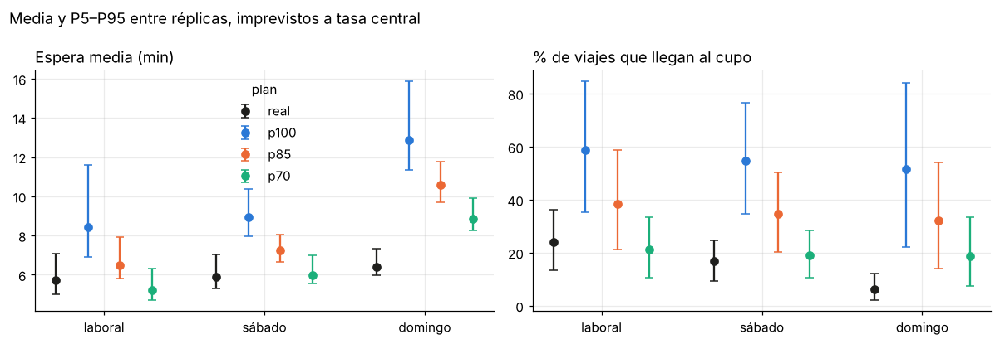

In [7]:
r = pd.read_csv(MC / "resumen_13_4.csv")
print("Réplicas por escenario:", pd.Series({k: v["replicas"] for k, v in man["escenarios"].items()}).describe()[["min", "50%", "max"]].to_dict(),
      "· convergieron antes de 500:", sum(v["convergio"] for v in man["escenarios"].values()), "de", len(man["escenarios"]))
ind = ["espera_media_min", "espera_p90_min", "pct_dejados_bus_lleno", "pct_viajes_cupo", "vuelta_mediana_min", "buses_a_la_vez", "salidas"]
filas = []
for t in ("laboral", "sabado", "domingo"):
    for p in ("real", "p100", "p85", "p70"):
        x = r[(r.escenario == f"{p}_{t}_central") & (r.idruta == "total") & r.indicador.isin(ind)].set_index("indicador")
        filas.append({"tipo": t, "plan": p, **{k: f"{x.media[k]:.1f} [{x.p5[k]:.1f}–{x.p95[k]:.1f}]" for k in ind}})
display(pd.DataFrame(filas))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, k, tit in zip(ax, ("espera_media_min", "pct_viajes_cupo"), ("Espera media (min)", "% de viajes que llegan al cupo")):
    for j, t in enumerate(("laboral", "sabado", "domingo")):
        for i, p in enumerate(("real", "p100", "p85", "p70")):
            x = r[(r.escenario == f"{p}_{t}_central") & (r.idruta == "total") & (r.indicador == k)].iloc[0]
            xx = j + (i - 1.5) * .2
            a.errorbar(xx, x.media, yerr=[[x.media - x.p5], [x.p95 - x.media]], fmt="o", color=CP[p], capsize=3, label=p if j == 0 else None)
    a.set_xticks(range(3), ("laboral", "sábado", "domingo")); a.set_title(tit, loc="left")
ax[0].legend(frameon=False, title="plan"); fig.suptitle("Media y P5–P95 entre réplicas, imprevistos a tasa central", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_4_planes.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 4 · El plan del proyecto ahorra buses; el precio es más espera y más buses llenos**
- **Imprevistos a tasa central, 500 réplicas por escenario** (media de buses a la vez y de espera):

  | Plan | Laboral | Sábado | Domingo |
  |---|---|---|---|
  | Real (`tb_despachos`) | 175 buses · 5,7 min | 151 buses · 5,9 min | 89 buses · 6,4 min |
  | Proyecto al 100 % | 124 buses · 8,4 min | 96 buses · 8,9 min | 44 buses · 12,9 min |
  | Proyecto al 85 % (central) | 145 buses · 6,5 min | 112 buses · 7,3 min | 51 buses · 10,6 min |
  | Proyecto al 70 % | 176 buses · 5,2 min | 135 buses · 6,0 min | 62 buses · 8,8 min |

- **Al 85 %:** 17 % menos buses a la vez en el laboral (42 % en el domingo), con 0,8 min más de espera media y 38,5 % de viajes al cupo frente a 24,1 % del plan real.
- **Al 70 %, con los mismos buses a la vez que el plan real en el laboral,** la espera baja a 5,2 min y los viajes al cupo a 21,2 %: el plan por carga máxima reparte mejor las salidas en las horas de más gente.
- **El domingo es donde más se ahorra:** el plan real pone 1,7 veces los buses a la vez del proyecto al 85 %, para menos de la mitad de los pasajeros del laboral (21.299 frente a 47.189).
- **Se lee como comparación, no como nivel:** el % de viajes al cupo del simulador está por encima del real (conclusión 3), así que el valor absoluto es pesimista; la diferencia entre planes es lo que cuenta. Elegir el plan es del Módulo 14.

## 5 · Imprevistos y demanda: cuánto mueven los resultados

In [8]:
ind2 = ["espera_media_min", "pct_viajes_cupo", "vuelta_mediana_min", "vuelta_p90_min", "minutos_imprevistos", "pct_viajes_con_imprevisto"]
filas = []
for p in ("real", "p85"):
    for e in (f"{p}_laboral_baja", f"{p}_laboral_central", f"{p}_laboral_alta", f"{p}_laboral_demanda_real"):
        x = r[(r.escenario == e) & (r.idruta == "total") & r.indicador.isin(ind2)].set_index("indicador")
        filas.append({"escenario": e, **{k: f"{x.media[k]:.1f} [{x.p5[k]:.1f}–{x.p95[k]:.1f}]" for k in ind2}})
display(pd.DataFrame(filas))

,escenario,espera_media_min,pct_viajes_cupo,vuelta_mediana_min,vuelta_p90_min,minutos_imprevistos,pct_viajes_con_imprevisto
0,real_laboral_baja,5.6 [5.0–6.8],23.9 [13.1–36.6],239.8 [237.4–242.4],283.5 [279.1–287.7],145.8 [0.0–759.1],8.8 [0.2–32.0]
1,real_laboral_central,5.7 [5.0–7.1],24.1 [13.3–36.3],239.9 [237.5–242.6],283.6 [279.5–287.9],259.6 [0.0–1077.8],14.2 [0.4–39.7]
2,real_laboral_alta,5.8 [5.0–7.2],24.1 [13.5–36.5],240.1 [237.5–242.8],283.8 [279.2–288.9],385.0 [7.5–1260.2],19.4 [2.0–44.5]
3,real_laboral_demanda_real,5.6 [4.9–7.0],22.9 [12.6–34.7],239.9 [237.4–242.4],283.8 [279.8–287.9],260.5 [0.0–1077.4],14.3 [0.4–38.5]
4,p85_laboral_baja,6.5 [5.8–7.5],38.4 [21.8–57.3],242.6 [239.9–245.4],286.0 [281.3–291.1],121.2 [0.0–652.6],8.5 [0.0–28.5]
5,p85_laboral_central,6.5 [5.8–7.9],38.5 [21.1–58.9],242.8 [240.0–245.9],286.3 [281.6–291.2],210.7 [0.0–884.8],13.8 [0.4–38.2]
6,p85_laboral_alta,6.7 [5.8–8.5],38.6 [21.5–57.1],242.9 [240.0–246.1],286.4 [281.4–291.4],360.0 [6.0–1225.4],20.8 [2.9–49.3]
7,p85_laboral_demanda_real,6.4 [5.7–7.4],36.5 [20.4–54.5],242.8 [240.2–245.6],285.9 [281.4–291.0],211.8 [0.0–885.8],13.8 [0.4–37.8]


**Conclusión 5 · Las tasas de imprevistos y la demanda real**
- **Imprevistos baja, central y alta** (laboral, plan real): tocan el 8,8 %, el 14,2 % y el 19,4 % de los viajes, con 146 min, 260 min y 385 min perdidos en el día en las 3 rutas.
- **Casi no mueven el día:** la vuelta mediana va de 239,8 a 240,1 min y la espera media de 5,6 a 5,8 min. Igual que en la 13.3, un imprevisto pesa en el viaje que toca, no en la mediana del día.
- **Demanda real en vez de la del modelo 04:00:** los pasajeros del día cambian −2,0 % en el laboral, −1,1 % en el sábado y −5,4 % en el domingo, y la comparación entre planes no cambia de orden.

## 6 · Sensibilidades

In [9]:
base = {"real": "real_laboral_central", "p85": "p85_laboral_central"}
filas = []
for e in man["escenarios"]:
    if not e.startswith("sens_"):
        continue
    p = e.rsplit("_", 1)[1]
    b = "sens_lluvia_base_" + p if "umbral" in e else base[p]
    if e.startswith("sens_lluvia_base"):
        b = base[p]
    for k in ("espera_media_min", "pct_viajes_cupo", "vuelta_mediana_min", "minutos_imprevistos"):
        x = r[(r.escenario == e) & (r.idruta == "total") & (r.indicador == k)].iloc[0]
        y = r[(r.escenario == b) & (r.idruta == "total") & (r.indicador == k)].iloc[0]
        filas.append({"sensibilidad": e, "frente_a": b, "indicador": k, "valor": x.media, "base": y.media,
                      "cambio_pct": 100 * (x.media / y.media - 1) if y.media else np.nan})
sens = pd.DataFrame(filas)
display(sens.pivot_table(index=["sensibilidad", "frente_a"], columns="indicador", values="cambio_pct").round(1))
w = []
for e in ("real_laboral_central", "sens_sin_variacion_dia_real", "p85_laboral_central", "sens_sin_variacion_dia_p85"):
    x = r[(r.escenario == e) & (r.idruta == "total")].set_index("indicador")
    w.append({"escenario": e, **{k: f"{x.p5[k]:.1f}–{x.p95[k]:.1f}" for k in ("pasajeros", "espera_media_min", "pct_viajes_cupo", "pct_dejados_bus_lleno")}})
print("P5–P95 con y sin el factor de demanda del día:"); display(pd.DataFrame(w))

,indicador,espera_media_min,minutos_imprevistos,pct_viajes_cupo,vuelta_mediana_min
sensibilidad,frente_a,,,,
sens_cota_inferior_p85,p85_laboral_central,-6.7,1.5,-31.1,-0.0
sens_cota_inferior_real,real_laboral_central,-7.3,0.2,-32.5,0.0
sens_error_duracion_p85,p85_laboral_central,0.9,57.3,0.3,0.0
sens_error_duracion_real,real_laboral_central,0.8,57.5,0.1,0.1
sens_google_p85,p85_laboral_central,4.7,1.8,4.8,5.6
sens_google_real,real_laboral_central,2.8,0.7,2.0,5.2
sens_lluvia_base_p85,p85_laboral_central,3.9,9.0,0.5,1.4
sens_lluvia_base_real,real_laboral_central,13.0,21.4,14.7,0.7
sens_lluvia_umbral_20_p85,sens_lluvia_base_p85,-4.1,-6.3,-1.2,0.1


P5–P95 con y sin el factor de demanda del día:


,escenario,pasajeros,espera_media_min,pct_viajes_cupo,pct_dejados_bus_lleno
0,real_laboral_central,39451.9–55046.2,5.0–7.1,13.3–36.3,3.5–9.9
1,sens_sin_variacion_dia_real,46859.9–47568.1,5.1–6.6,21.2–25.5,5.3–7.4
2,p85_laboral_central,39350.9–54880.6,5.8–7.9,21.1–58.9,4.6–12.4
3,sens_sin_variacion_dia_p85,46790.8–47513.7,5.9–7.5,34.9–40.7,6.9–9.4


**Conclusión 6 · Los supuestos que más pesan**
- **La demanda pesa más que todo lo demás.** Con la cota inferior (las salidas que no quedaron en la maestra no llevan a nadie), los pasajeros cambian −11,3 % y los viajes al cupo bajan a 16,2 % (24,1 % central).
- **Los tiempos de Google** cambian la forma del día: la vuelta mediana sube +5,2 % con el plan real y +5,6 % con el del proyecto al 85 %. El Módulo 11 ya mostró que Google aporta poco al pronóstico; queda como sensibilidad.
- **Imprevistos:** con error en la duración estimada para decidir el desvío, los minutos perdidos suben +58 % (los buses esperan cierres que no acaban cuando se creía), pero la espera casi nada (+0,04 min). Con todas las obras como cierre, la espera sube +6,1 %. La σ de la duración (0,25 o 1,0) cambia los minutos perdidos y casi nada más.
- **Lluvia (19-sep-2025):** con umbral de arroyo de 20 mm/h no se forman los arroyos y los viajes con imprevisto bajan a 13,5 % (17,6 % con el umbral de 10). Con 5 mm/h el resultado es idéntico al de 10: ese día la única hora sobre 5 mm/h también pasó de 10.
- **Sin el factor de demanda del día:** las medias casi no cambian; los intervalos se estrechan (conclusión 1).
- **Regulación:** reduce los buses pegados a la mitad (conclusión 3) con poco costo, +0,6 min de vuelta mediana, y espera y cupo casi iguales.

## 7 · Rapidez, reproducibilidad y lo que queda para el gemelo digital

In [10]:
seg = pd.Series({k: v["segundos"] / v["replicas"] for k, v in man["escenarios"].items()})
print(f"Segundos de reloj por réplica: mediana {seg.median():.2f}, máximo {seg.max():.2f}")
print("Réplicas en total:", sum(v["replicas"] for v in man["escenarios"].values()) + sum(v["replicas"] for v in res["dias"].values()))
print("Pasos de la réplica representativa guardados para la 13.5:", len(list(MC.glob("*_pasos.parquet"))), "escenarios +",
      len(list(VAL.glob("pasos_*_representativa.parquet"))), "días de validación")
print("Python", sys.version.split()[0])

Segundos de reloj por réplica: mediana 1.04, máximo 1.27
Réplicas en total: 32750
Pasos de la réplica representativa guardados para la 13.5: 54 escenarios + 6 días de validación
Python 3.13.16


**Conclusión 7 · Cientos de réplicas por escenario, reproducibles**
- **54 escenarios, 26.750 réplicas** en el PC de la Persona 3 (10 procesos, 6,5 h de reloj); con la validación, 32.750 réplicas en total. Como mucho 1,27 s de reloj por réplica; meta ≤ 30 s por día.
- **Convergencia:** solo los 2 escenarios sin factor del día llegan al 1 % antes de 500 réplicas (350 y 400). Con el factor, a las 500 réplicas la mitad del IC95 % queda en 1,2 % de la media para la espera y 2,6 % para el % de viajes al cupo (mediana de los escenarios), y por debajo de 0,1 % para la vuelta. El criterio del alcance lo admite («o 500 réplicas»).
- **Reproducible:** misma semilla, mismos indicadores con 1 o 2 procesos (`tests_13_4.py` 13/13). Entre computadores cambia un poco: de 50 réplicas del Monte Carlo (corrido en el PC, Windows) repetidas en Linux, 44 y 45 salen idénticas; en las demás, una diferencia de redondeo en el último decimal hace que la réplica tome otro camino. Las medias coinciden dentro de su IC95 % (espera media 5,67 frente a 5,65 min). Después de la evaluación se agregaron al motor las opciones de las sensibilidades y la regulación, inactivas por defecto; con el código actual, los 6 días de validación dan las mismas réplicas que en la evaluación (`enmiendas_codigo_13_4.json`).
- **Para la 13.5:** se guardaron los pasos de la réplica más cercana a la mediana de cada escenario (54) y de cada día de validación (6), para el gemelo digital.

## Síntesis · Subfase 13.4
- **Monte Carlo listo:** `src/simulation/monte_carlo_engine.py` corre N réplicas hasta converger y da cada indicador con su media y su P5–P95, con el factor de demanda del día (8–14 % de variación entre días). 54 escenarios y 26.750 réplicas.
- **Validación en una sola evaluación, a ciegas:** la vuelta mediana queda a ±5 % de la real en 18/18 ruta × día. Los pasajeros por viaje cumplen en 14 de 18 con la demanda 04:00 y en 18/18 con la real.
- **Criterio principal, no cumplido:** el MAE de la ocupación es menor o igual al del perfil histórico en 3 de 6 días (5 exigidos). Gana en el fin de semana y la lluvia; pierde en los laborales y el partido, por la punta de la mañana.
- **Otros hallazgos:**
  - el intervalo P5–P95 cubre el 44,1–54,7 % de las celdas;
  - el motor exagera los viajes al cupo (+6,2 puntos);
  - el motor exagera los buses pegados; con la regulación queda en el rango del GPS en 2 de 3 rutas.
- **Lo que dicen los planes:** el del proyecto al 85 % usa 17 % menos buses a la vez en el laboral, con 0,8 min más de espera. Al 70 %, con los mismos buses que el plan real, espera menos. Lo que más pesa es la demanda.
- **Decisiones de la Persona 3:** reportar la validación tal cual y agregar la regulación como escenario; no se re-evalúan los días de validación. Las decisiones de Claude V1–V11 quedaron confirmadas al cerrar la subfase (5-nov-2026, 11:02; detalle en `revisiones/revision_13_4.md`).
- **Siguiente:** la 13.5 (gemelo digital) usa los pasos guardados de cada escenario.

<a id="m13-5"></a>

### A2.5.5 &middot; Subfase 13.4b · Mejoras del simulador

<sub>Notebook original: `modulo13/subfase_13_4b_mejoras.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 13 · Subfase 13.4b — Mejoras del simulador

**Persona 3.** La 13.4 cerró con su resultado oficial (3 de 6 días). Antes de la 13.5 se probaron **6 mejoras del
simulador, una por ronda**. Cada ronda tuvo su regla escrita y congelada (con hashes del código y de los insumos) antes
de simular, se probó **una sola vez** en los 3 días de control de la 13.2 (19-ago, 20-sep y 9-nov-2025) y se decidió
aplicando la regla tal cual. Los 6 días de validación nunca se usaron para calibrar. Al final: una reevaluación
«no ciega» de los días de validación y el Monte Carlo de los 54 escenarios con lo adoptado. Alcance aprobado:
`revisiones/alcance_13_4b.md`. Solo se tocó el simulador (Módulo 13); los módulos anteriores no cambian.

| Ronda | Mejora | Regla | Decisión |
|---|---|---|---|
| 1 | Subidas y bajadas por ruta × tipo de día × franja, con 5.400 viajes nuevos de 2025 (E3) | `regla_13_4b.json` | No se adopta |
| 2 | Tiempo de parada por pasajero + medir la carga como el sensor (por tiempo) | `regla_13_4b_r2.json` | Se adopta |
| 3 | Regulación de buses pegados | `regla_13_4b_r3.json` | No por la regla; opción, y central en el Monte Carlo por decisión de la Persona 3 |
| 4 | Primero bajan, luego suben | `regla_13_4b_r4.json` | Se adopta |
| 5 | Factor de velocidad del día | `regla_13_4b_r5.json` | Se adopta |
| 6 | Intervalo predictivo por celda | `regla_13_4b_r6.json` | No se adopta; opción |

Todas las mejoras son opciones del motor (`ajustes`), inactivas por defecto: sin ellas el motor da lo mismo que en las
subfases cerradas (pruebas c y f de `tests_13_4b.py`).

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, ".")
from src.simulation import escenario as E

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
SAL = Path("datos_13/mejoras_13_4b"); NC = SAL / "reevaluacion_no_ciega"
MC0, MC = Path("datos_13/montecarlo_13_4"), Path("datos_13/montecarlo_13_4b")
VAL = Path("datos_13/validacion_13_4"); FIG = Path("resultados_13"); FIG.mkdir(exist_ok=True)
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a"}; GRIS = "#8a8a85"
CP = {"real": "#1f1f1d", "p100": "#2a78d6", "p85": "#eb6834", "p70": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10, "figure.dpi": 110})
sha = lambda p: __import__("hashlib").sha256(Path(p).read_bytes()).hexdigest()
filas = []
for k, (regla, dec, col) in {"r1": ("regla_13_4b.json", "decision_13_4b.json", "adoptar_v2"),
                             "r2": ("regla_13_4b_r2.json", "decision_13_4b_r2.json", "adoptar_A"),
                             "r3": ("regla_13_4b_r3.json", "decision_13_4b_r3.json", "adoptar_regulacion"),
                             "r4": ("regla_13_4b_r4.json", "decision_13_4b_r4.json", "adoptar_bajan_primero"),
                             "r5": ("regla_13_4b_r5.json", "decision_13_4b_r5.json", "adoptar_velocidad"),
                             "r6": ("regla_13_4b_r6.json", "decision_13_4b_r6.json", "adoptar")}.items():
    rg, d = json.loads(Path(regla).read_text(encoding="utf-8")), json.loads((SAL / dec).read_text(encoding="utf-8"))
    filas.append({"ronda": k, "regla_congelada": rg["creado"], "decision": d["creado"], "hash_regla_coincide": d["regla_sha256"] == sha(regla),
                  "adopta": d[col], "criterios": d.get("criterios", d.get("dias_80_95"))})
display(pd.DataFrame(filas))

,ronda,regla_congelada,decision,hash_regla_coincide,adopta,criterios
0,r1,2026-11-05T11:26:38,2026-11-05T11:49:11,True,False,"{'a_mae_total': False, 'b_mae_6_9_laboral': Fa..."
1,r2,2026-11-05T12:47:04,2026-11-05T13:10:15,True,True,"{'a_mae_total': True, 'b_mae_6_9_laboral': Tru..."
2,r3,2026-11-05T13:13:53,2026-11-05T13:26:21,True,False,"{'a_mae_total': False, 'b_mae_6_9_laboral': Tr..."
3,r4,2026-11-05T13:30:57,2026-11-05T13:43:27,True,True,"{'a_mae_total': True, 'b_mae_6_9_laboral': Tru..."
4,r5,2026-11-05T13:47:57,2026-11-05T14:00:52,True,True,"{'a_cobertura': True, 'b_mejor_cv': True, 'c_m..."
5,r6,2026-11-05T14:02:21,2026-11-05T14:10:16,True,None,"{'muestreo': 0, 'muestreo_dia': 0}"


## 1 · Ronda 1: subidas y bajadas con más datos, por tipo de día

La hipótesis de la 13.4 era que en la punta de la mañana la gente viaja más lejos. Se extrajeron las lecturas de
5.400 viajes de 2025 (E3: 100 por ruta × tipo de día × franja, sin días de validación ni de control) y de todas las
salidas de los 3 días de control (E4: 1.406 salidas), y se armó un reparto por ruta × tipo × franja (parámetros v2).

In [2]:
d1 = json.loads((SAL / "decision_13_4b.json").read_text(encoding="utf-8"))["detalle"]
t1 = pd.DataFrame({"MAE v1": d1["mae_total"]["v1"], "MAE v2": d1["mae_total"]["v2"], "histórico": d1["mae_hist_v1"],
                   "MAE 6–9 h v1": d1["mae_6_9"]["v1"], "MAE 6–9 h v2": d1["mae_6_9"]["v2"]})
display(t1.round(2))
ext = json.loads(Path("datos_13/extraccion/ids_13_4b.json").read_text(encoding="utf-8"))
print("Muestra congelada:", ext.get("creado"), "· hash de los ids", ext["ids_sha256"][:12], "· E3", ext["e3_viajes"], "viajes elegidos · E4", ext["e4_viajes"], "salidas")
import pyarrow.parquet as pq, pyarrow.compute as pc
for f in ("e3_lecturas_13_4b", "e4_lecturas_control_13_4b"):
    tb = pq.read_table(f"datos_13/extraccion/{f}.parquet", columns=["idprogramacion"])
    print(f"  {f}: {tb.num_rows:,} lecturas de {len(pc.unique(tb['idprogramacion'])):,} viajes")

,MAE v1,MAE v2,histórico,MAE 6–9 h v1,MAE 6–9 h v2
control_laboral,5.28,5.89,4.17,9.31,10.81
control_sabado,4.05,4.79,4.93,5.48,7.14
control_domingo,2.96,3.06,4.35,2.83,3.08


Muestra congelada: 2026-11-05T11:11:29 · hash de los ids dceae6b19044 · E3 5400 viajes elegidos · E4 1406 salidas
  e3_lecturas_13_4b: 1,575,316 lecturas de 5,232 viajes
  e4_lecturas_control_13_4b: 455,905 lecturas de 1,400 viajes


**Conclusión 1 · Más datos de dónde se bajan no mejoran: la hipótesis de la mañana se descarta**
- **Muestra nueva:** 5.400 viajes de 2025 elegidos al azar, 100 por ruta × tipo de día × franja (E3: 1.575.316 lecturas de 5.232 viajes), y todas las salidas de los 3 días de control (E4: 455.905 lecturas de 1.400 viajes). Ninguno es de validación.
- **Con el reparto por tipo de día (v2) el simulador empeora en los 3 días de control:** MAE 5,28 → 5,89 en el laboral, 4,05 → 4,79 en el sábado y 2,96 → 3,06 en el domingo; de 6 a 9 h del laboral, 9,31 → 10,81. La regla dejó v1.
- **Lo que enseñó:** en el laboral de control, un pasajero de la mañana viaja casi lo mismo que en el reparto de siempre (18,8 segmentos frente a ~18; alcance, resultado de la ronda 1). La falta de gente a bordo no venía de dónde se bajan, y separar por tipo de día solo agregó ruido.

## 2 · Ronda 2: el tiempo de parada y medir como el sensor

En la calle, cada parada y cada pasajero que sube o baja alargan el tramo; el motor usaba el tiempo medio del tramo,
igual para un bus lleno que para uno vacío. Con E3 se estimó el costo de parar (c) y el de cada movimiento (b): el tramo
tarda t_mov + c × (hubo parada) + b × (suben + bajan), con t_mov = t_med − (c × prob. de parada + b × movimientos medios),
piso 0,3 × t_med, para no contar dos veces la parada que ya trae t_med. Además, el motor guarda la carga ponderada por el
tiempo en el tramo, que es como la mide el sensor (una lectura cada ~45 s); desde esta ronda es la medida principal.

In [3]:
pa = json.loads((SAL / "parada_13_4b.json").read_text(encoding="utf-8"))
print(f"c = {pa['c_s']} s (IC95 % {pa['ic95_bootstrap_viajes']['c_s']}), b = {pa['b_s']} s ({pa['ic95_bootstrap_viajes']['b_s']}) · "
      f"{pa['pares']:,} pares de segmentos de {pa['viajes']:,} viajes · parada = {pa['pct_tiempo_que_es_parada']} % del tiempo de los tramos")
display(pd.DataFrame(pa["dt_por_movimientos"]).T.rename_axis("movimientos en el segmento"))
display(pd.DataFrame(pa["por"]["ruta"], index=["c_s", "b_s"]).T.rename_axis("ruta"))
d2 = json.loads((SAL / "decision_13_4b_r2.json").read_text(encoding="utf-8"))["detalle"]
display(pd.concat({v: pd.DataFrame(d2[v]).T for v in ("v1", "A")}, axis=1).round(2))

c = 8.891 s (IC95 % [8.397, 9.258]), b = 8.6 s ([8.425, 8.797]) · 450,190 pares de segmentos de 5,223 viajes · parada = 14.02 % del tiempo de los tramos


,n,dt_mediana_s
movimientos en el segmento,,
"(-1, 0]",206983.0,60.0
"(0, 2]",162327.0,102.0
"(2, 5]",62883.0,128.0
"(5, 10]",15842.0,162.0
"(10, 20]",2069.0,208.0
"(20, 500]",86.0,270.0


,c_s,b_s
ruta,,
2,8.88,8.62
16,9.38,8.45
21,8.42,8.75


v1                                                                     A                                                           
                mae_tiempo mae_paso mae_hist mae_tiempo_6_9 mae_paso_6_9 sesgo_tiempo mae_tiempo mae_paso mae_hist mae_tiempo_6_9 mae_paso_6_9 sesgo_tiempo
control_laboral       5.26     5.28     4.17           9.27         9.31        -3.66       5.09     5.28     4.16           9.04         9.33        -3.12
control_sabado        4.05     4.05     4.93           5.45         5.48        -2.21       3.98     4.07     4.93           5.24         5.48        -1.72
control_domingo       2.96     2.96     4.35           2.83         2.83        -1.10       2.91     2.92     4.35           2.88         2.89        -0.80

**Conclusión 2 · Parar cuesta 8,9 s y cada pasajero 8,6 s: el motor gana física y algo de ocupación**
- **Medido en 450.190 pares de segmentos de 5.223 viajes (E3):** parar cuesta **8,9 s** (IC95 % 8,4–9,3) y cada pasajero que sube o baja, **8,6 s** (8,4–8,8). Un tramo sin movimientos tarda 60 s en la mediana; con 5–10 movimientos, 162 s. La parada es el 14 % del tiempo de los tramos.
- **Ocupación en los días de control (MAE por tiempo), sin → con parada:** laboral 5,26 → 5,09; sábado 4,05 → 3,98; domingo 2,96 → 2,91; 6–9 h del laboral 9,27 → 9,04. La falta de gente a bordo del laboral baja de −3,66 a −3,12 pasajeros.
- **Medir como el sensor** (carga ponderada por el tiempo en el tramo) es desde aquí la medida principal, decidida por principio antes de correr. Sin la parada casi no cambia nada (5,28 → 5,26); con ella, sí, porque los buses llenos ahora van más lento.
- **Efecto secundario:** los buses se pegan más (conclusión 3).

## 3 · Ronda 3: regulación de buses pegados

In [4]:
d3 = json.loads((SAL / "decision_13_4b_r3.json").read_text(encoding="utf-8"))
display(pd.concat({v: pd.DataFrame(d3["detalle"][v]).T[["mae_tiempo", "mae_tiempo_6_9", "sesgo_tiempo"]] for v in ("A", "AR")}, axis=1).round(3))
pg = pd.concat({v: pd.DataFrame(d3["pegados"][v]).set_index(["rol", "idruta"]) for v in ("A", "AR")}, axis=1)
display(pg.round(1))
print("Criterios:", d3["criterios"], "→ adoptar:", d3["adoptar_regulacion"])

A                                     AR                            
                mae_tiempo mae_tiempo_6_9 sesgo_tiempo mae_tiempo mae_tiempo_6_9 sesgo_tiempo
control_laboral      5.090          9.036       -3.122      5.109          9.030       -3.092
control_sabado       3.977          5.242       -1.720      3.965          5.217       -1.707
control_domingo      2.910          2.885       -0.796      2.927          2.870       -0.792

A                                                       AR                               
                       pct_intervalos_menos_1min pct_intervalos_menos_1min_real pct_intervalos_menos_1min pct_intervalos_menos_1min_real
rol             idruta                                                                                                                  
control_laboral 16                          35.1                           19.8                      21.2                           19.8
                2                           22.1                            8.8                      14.3                            8.8
                21                          15.4                            5.7                       8.9                            5.7
control_sabado  16                          31.2                           17.8                      16.3                           17.8
                2                           19.5                            6.5                      13.0                            6.5
                21                          12.4                            3.0                       6.9                            3.0
control_domingo 16                          26.6                            7.6                      15.7                            7.6
                2                           16.2                           10.0                      10.7                           10.0
                21                           8.3                            1.6                       3.6                            1.6

Criterios: {'a_mae_total': False, 'b_mae_6_9_laboral': True, 'c_pegados': True, 'd_vuelta': True, 'e_pasajeros': True} → adoptar: False


**Conclusión 3 · La regulación arregla los buses pegados, no la ocupación**
- **Con la parada, sin regulación,** un bus lleno se atrasa, encuentra más gente y se atrasa más: en el laboral de control, los intervalos < 1 min de la ruta 16 llegan a 35,1 % (GPS 19,8 %).
- **Con la regulación de la 13.4** (el bus pegado espera en la mitad del circuito hasta el 60 % de su intervalo, máximo 5 min; Daganzo, 2009) quedan más cerca del GPS en **9 de 9** ruta × día: ruta 16 del laboral 35,1 → 21,2 %, ruta 2 22,1 → 14,3 % (GPS 8,8), ruta 21 15,4 → 8,9 % (GPS 5,7).
- **La ocupación no cambia** (±0,02 pasajeros: 5,09 → 5,11 en el laboral). La regla pedía que el MAE bajara en 2 de 3 días y bajó en 1: **no se adoptó por la regla.**
- **Decisión de la Persona 3** (5-nov, 15:43, después de ver los resultados): entra al escenario central del Monte Carlo final, rotulada.

## 4 · Ronda 4: primero bajan, luego suben

In [5]:
d4 = json.loads((SAL / "decision_13_4b_r4.json").read_text(encoding="utf-8"))
cu = pd.concat({v: pd.DataFrame(d4["cupo"][v]).set_index(["rol", "idruta"]) for v in ("A", "AB")}, axis=1)
cu[("dif", "A")] = cu[("A", "pct_viajes_cupo")] - cu[("A", "pct_viajes_cupo_real")]
cu[("dif", "AB")] = cu[("AB", "pct_viajes_cupo")] - cu[("AB", "pct_viajes_cupo_real")]
display(cu.round(1))
print("Exceso mediano sobre lo real: A", round(cu[("dif", "A")].median(), 1), "· AB", round(cu[("dif", "AB")].median(), 1),
      "· más cerca del real en", d4["cupo_mas_cerca_real"], "de 9 · cambio del MAE:", d4["cambio_mae_total"])

A                                   AB                       dif     
                       pct_viajes_cupo pct_viajes_cupo_real pct_viajes_cupo pct_viajes_cupo_real    A   AB
rol             idruta                                                                                    
control_laboral 16                28.7                 25.0            25.7                 25.0  3.7  0.7
                2                 21.5                 21.0            19.6                 21.0  0.5 -1.4
                21                25.1                 21.5            22.9                 21.5  3.6  1.4
control_sabado  16                20.3                 18.0            17.9                 18.0  2.3 -0.1
                2                 13.9                  5.1            12.1                  5.1  8.8  7.0
                21                13.0                  8.2            11.6                  8.2  4.7  3.4
control_domingo 16                 4.5                  3.0             3.8                  3.0  1.5  0.9
                2                  3.9                  1.7             3.3                  1.7  2.2  1.6
                21                 6.2                  0.0             5.6                  0.0  6.2  5.6

Exceso mediano sobre lo real: A 3.6 · AB 1.4 · más cerca del real en 8 de 9 · cambio del MAE: {'control_laboral': 0.0035, 'control_sabado': -0.0017, 'control_domingo': 0.0045}


**Conclusión 4 · Bajar antes de subir corrige el cupo sin mover la ocupación**
- **Antes,** el motor subía a la gente antes de bajar a la que llegaba y contaba como lleno un bus que en la calle tenía cupo.
- **Con «primero bajan»** los viajes al cupo quedan más cerca del real en **8 de 9** ruta × día, y el exceso mediano sobre lo real baja de **+3,6 a +1,4 puntos** (ruta 16 del laboral: 28,7 → 25,7 %, real 25,0 %).
- **La ocupación no se mueve:** MAE +0,35 % en el laboral, −0,17 % en el sábado y +0,45 % en el domingo. Se adoptó.
- **Lo que queda:** donde lo real casi nunca llega al cupo, el simulador sigue por encima (sábado ruta 2 +7,0 puntos; domingo ruta 21 +5,5).

## 5 · Ronda 5: factor de velocidad del día

,cobertura base,cobertura con factor,CV sim base,CV sim con factor,CV real,media base,media con factor
domingo_festivo|2,52.308,90.769,0.017,0.036,0.035,198.898,199.513
domingo_festivo|16,64.615,83.077,0.018,0.038,0.034,170.614,171.249
domingo_festivo|21,72.308,92.308,0.021,0.041,0.036,191.628,191.682
laboral|2,42.437,87.395,0.018,0.050,0.049,248.285,249.052
laboral|16,34.034,90.336,0.014,0.051,0.051,232.126,232.435
laboral|21,39.076,93.698,0.019,0.055,0.052,238.596,238.404
sabado|2,36.735,91.837,0.014,0.054,0.052,240.294,241.507
sabado|16,32.653,91.837,0.014,0.054,0.061,221.799,221.991
sabado|21,42.857,93.878,0.017,0.058,0.051,230.526,231.400


Días de control dentro del P5–P95: {'base': 3, 'velocidad': 8}


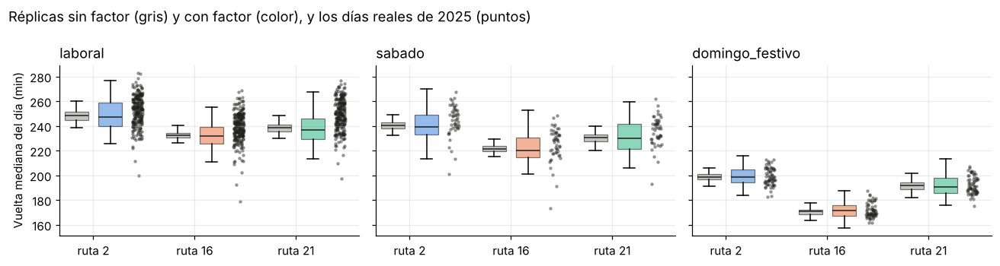

In [6]:
d5 = json.loads((SAL / "decision_13_4b_r5.json").read_text(encoding="utf-8"))
t5 = pd.DataFrame({k: {"cobertura base": v["cobertura"]["base"], "cobertura con factor": v["cobertura"]["velocidad"],
                       "CV sim base": v["cv_sim"]["base"], "CV sim con factor": v["cv_sim"]["velocidad"], "CV real": v["cv_real"]["base"],
                       "media base": v["media"]["base"], "media con factor": v["media"]["velocidad"]} for k, v in d5["tabla"].items()}).T
display(t5.round(3))
print("Días de control dentro del P5–P95:", d5["control_dentro"])
vr = pd.read_csv(SAL / "vuelta_dia_2025_13_4b.csv")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
v5 = pd.read_csv(SAL / "r5" / "vueltas_r5.csv"); v5 = v5[v5.grupo == "desarrollo"]
for a, t in zip(ax, ("laboral", "sabado", "domingo_festivo")):
    for i, r in enumerate((2, 16, 21)):
        for j, (var, c) in enumerate((("base", GRIS), ("velocidad", COL[r]))):
            x = v5[(v5.tipo_dia == t) & (v5.idruta == r) & (v5.variante == var)].vuelta_mediana_min
            a.boxplot(x, positions=[i * 3 + j], widths=.7, showfliers=False, patch_artist=True,
                      boxprops=dict(facecolor=c, alpha=.5, lw=.8), medianprops=dict(color="#1f1f1d"))
        y = vr[(vr.tipo_dia == t) & (vr.idruta == r)]
        a.scatter(np.full(len(y), i * 3 + 1.8) + np.random.default_rng(0).uniform(-.15, .15, len(y)), y.d,
                  s=4, color="#1f1f1d", alpha=.35)
    a.set_xticks([.5, 3.5, 6.5], ["ruta 2", "ruta 16", "ruta 21"]); a.set_title(t, loc="left")
ax[0].set_ylabel("Vuelta mediana del día (min)")
fig.suptitle("Réplicas sin factor (gris) y con factor (color), y los días reales de 2025 (puntos)", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_4b_velocidad.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 5 · El factor de velocidad hace que el intervalo cubra los días reales**
- **Antes,** el Monte Carlo solo variaba cada viaje por separado, y la vuelta mediana del día casi no cambiaba entre réplicas (CV 1,4–2,1 %), cuando en 2025 cambia 3,4–6,1 % entre días del mismo tipo.
- **Con un factor común × uno propio por ruta** (gammas con media 1, estimados en 2025 sin los días de validación ni de control): CV 3,6–5,8 %, más cerca del real en 9 de 9 tipo de día × ruta, y la media no cambia (< 1 %).
- **Cobertura de los días reales de 2025 dentro del P5–P95:** de 33–72 % a **83–94 %**. Fuera de muestra, los días de control quedan dentro en **8 de 9** (3 de 9 sin el factor). Se adoptó.
- **En el Monte Carlo final,** la vuelta mediana de un laboral con el plan real va de 219,8 a 257,7 min (P5–P95); en la 13.4, de 237,5 a 242,6.

## 6 · Ronda 6: intervalo predictivo por celda

In [7]:
d6 = json.loads((SAL / "decision_13_4b_r6.json").read_text(encoding="utf-8"))
display(pd.DataFrame(d6["cobertura"]).T.round(2))
print("Días con cobertura 80–95 %:", d6["dias_80_95"], "→ adoptar:", d6["adoptar"])
c6 = pd.read_csv(SAL / "r6" / "cobertura_r6.csv").dropna(subset=["p5", "p95"])
c6["fuera"] = np.where(c6.a_bordo_media < c6.p5, "debajo", np.where(c6.a_bordo_media > c6.p95, "encima", "dentro"))
display((100 * pd.crosstab([c6.variante, c6.rol], c6.fuera, normalize="index")).round(1))

,cobertura,ancho_medio
muestreo|control_domingo,73.18,8.69
muestreo|control_laboral,63.43,11.64
muestreo|control_sabado,71.40,11.06
muestreo_dia|control_domingo,77.45,9.46
muestreo_dia|control_laboral,67.86,12.64
muestreo_dia|control_sabado,75.01,11.82


Días con cobertura 80–95 %: {'muestreo': 0, 'muestreo_dia': 0} → adoptar: None


fuera                         debajo  dentro  encima
variante     rol                                    
muestreo     control_domingo     5.9    73.2    20.9
             control_laboral     5.6    63.4    30.9
             control_sabado      4.9    71.4    23.7
muestreo_dia control_domingo     4.8    77.5    17.8
             control_laboral     4.9    67.9    27.3
             control_sabado      4.3    75.0    20.7

**Conclusión 6 · El intervalo por celda sube la cobertura 20–25 puntos, pero no llega al 80 %**
- **Intervalo predictivo:** en cada réplica se sortean tantos pasos de bus como buses observados tiene la celda (mediana 7) y se promedia su carga, que es lo que de verdad se compara.
- **Cobertura en los días de control:** 63,4 / 71,4 / 73,2 % (laboral, sábado, domingo); con los factores del día, **67,9 / 75,0 / 77,5 %**. En la 13.4 era 42,5–52,7 %. La regla pedía 80–95 % en 2 de 3 días: no se adoptó.
- **Lo que falta es el sesgo, no el ancho:** con los factores del día, lo observado queda por encima del P95 en el 27,3 % de las celdas del laboral y por debajo del P5 en solo el 4,9 %. El simulador todavía lleva menos gente a bordo que lo observado.
- Queda como opción rotulada (`mejoras_13_4b_r6.muestras`), por decisión de la Persona 3.

## 7 · Reevaluación «no ciega» de los 6 días de validación

Una sola vez, al final de las rondas, con lo adoptado por las reglas (tiempo de parada y primero bajan; el factor de
velocidad solo actúa con la variación entre días, que la validación no usa), las mismas reglas y semillas de la 13.4.
Es «no ciega»: esos días ya se vieron en la 13.4. El resultado oficial (3 de 6) no cambia.

Demanda pred: días no peores que el histórico — por paso 3, por tiempo 3, oficial 13.4 3 · 2026-11-05T14:11:09 → 2026-11-05T15:19:18 · ajustes {'parada': {'c_s': 8.891, 'b_s': 8.6}, 'bajan_primero': True, 'velocidad_dia': True}


,rol,fecha,mae_oficial_13_4,mae_nuevo_paso,mae_nuevo_tiempo,mae_hist,mae_nuevo_tiempo_6_9,replicas
0,laboral_1,2025-11-25,3.92,4.16,4.19,3.89,5.58,500
1,laboral_2,2025-04-03,4.69,4.76,4.67,3.69,8.47,500
2,sabado,2025-02-15,3.91,3.90,3.76,4.63,5.11,500
3,domingo,2025-07-27,2.79,2.82,2.83,4.52,2.43,500
4,lluvia_fuerte,2025-06-13,3.45,3.67,3.68,3.93,5.04,500
5,evento_masivo,2025-03-25,5.73,5.70,5.56,4.73,10.39,500


Demanda real: días no peores que el histórico — por paso 3, por tiempo 3, oficial 13.4 3 · 2026-11-05T14:11:30 → 2026-11-05T15:20:01 · ajustes {'parada': {'c_s': 8.891, 'b_s': 8.6}, 'bajan_primero': True, 'velocidad_dia': True}


,rol,fecha,mae_oficial_13_4,mae_nuevo_paso,mae_nuevo_tiempo,mae_hist,mae_nuevo_tiempo_6_9,replicas
0,laboral_1,2025-11-25,3.98,4.09,4.06,3.89,5.48,500
1,laboral_2,2025-04-03,4.73,4.78,4.70,3.69,8.56,500
2,sabado,2025-02-15,3.66,3.67,3.57,4.63,4.52,500
3,domingo,2025-07-27,2.77,2.80,2.80,4.51,2.47,500
4,lluvia_fuerte,2025-06-13,3.46,3.61,3.59,3.94,5.29,500
5,evento_masivo,2025-03-25,5.71,5.69,5.61,4.72,9.55,500


Vuelta ±5 %: 17 de 18 (oficial 18 ) · pasajeros por viaje ±10 %: 13 de 18 (oficial 14 )
Exceso mediano de viajes al cupo sobre lo real: 4.9 puntos (oficial 6.2 )


,con mejoras,oficial 13.4,GPS
% intervalos < 1 min,,,
2,21.2,13.9,7.7
16,34.0,24.7,21.5
21,14.4,7.7,4.2


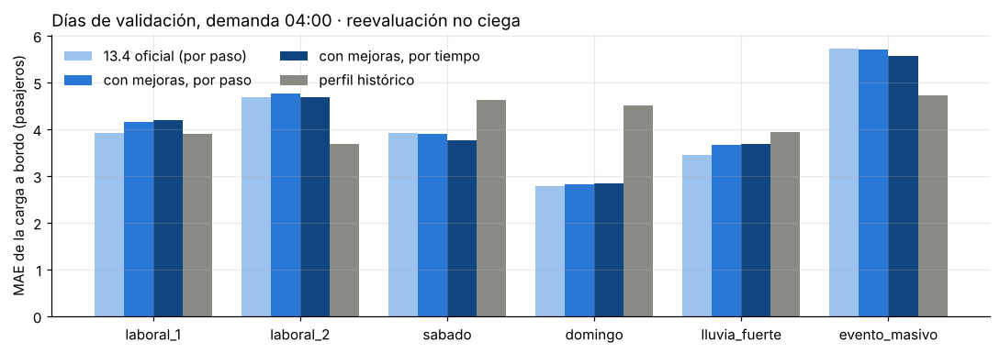

In [8]:
for dem in ("pred", "real"):
    t = pd.read_csv(NC / f"mae_no_ciego_{dem}.csv")
    rs = json.loads((NC / f"resultados_no_ciego_{dem}.json").read_text(encoding="utf-8"))
    print(f"Demanda {dem}: días no peores que el histórico — por paso {rs['dias_no_peor_que_hist_paso']}, por tiempo "
          f"{rs['dias_no_peor_que_hist_tiempo']}, oficial 13.4 {rs['dias_oficial_13_4']} · {rs['inicio']} → {rs['fin']} · ajustes {rs['ajustes']}")
    display(t[["rol", "fecha", "mae_oficial_13_4", "mae_nuevo_paso", "mae_nuevo_tiempo", "mae_hist", "mae_nuevo_tiempo_6_9", "replicas"]].round(2))
s = pd.read_csv(NC / "secundarias_no_ciego_pred.csv"); s0 = pd.read_csv(VAL / "secundarias_13_4.csv"); s0 = s0[s0.demanda == "pred"]
print("Vuelta ±5 %:", int((s.err_vuelta_pct.abs() <= 5).sum()), "de 18 (oficial", int((s0.err_vuelta_pct.abs() <= 5).sum()), ") · "
      "pasajeros por viaje ±10 %:", int((s.err_pasajeros_pct.abs() <= 10).sum()), "de 18 (oficial", int((s0.err_pasajeros_pct.abs() <= 10).sum()), ")")
print("Exceso mediano de viajes al cupo sobre lo real:", round((s.pct_viajes_cupo - s.pct_viajes_cupo_real).median(), 1),
      "puntos (oficial", round((s0.pct_viajes_cupo - s0.pct_viajes_cupo_real).median(), 1), ")")
display(pd.concat({"con mejoras": s.groupby("idruta").pct_intervalos_menos_1min.mean(), "oficial 13.4": s0.groupby("idruta").pct_intervalos_menos_1min.mean(),
                   "GPS": s0.groupby("idruta").pct_intervalos_menos_1min_real.mean()}, axis=1).round(1).rename_axis("% intervalos < 1 min"))
fig, ax = plt.subplots(figsize=(10, 3.6))
t = pd.read_csv(NC / "mae_no_ciego_pred.csv"); xx = np.arange(len(t))
ax.bar(xx - .3, t.mae_oficial_13_4, .2, color="#9cc2ee", label="13.4 oficial (por paso)")
ax.bar(xx - .1, t.mae_nuevo_paso, .2, color="#2a78d6", label="con mejoras, por paso")
ax.bar(xx + .1, t.mae_nuevo_tiempo, .2, color="#10457f", label="con mejoras, por tiempo")
ax.bar(xx + .3, t.mae_hist, .2, color=GRIS, label="perfil histórico")
ax.set_xticks(xx, t.rol); ax.set_ylabel("MAE de la carga a bordo (pasajeros)"); ax.legend(frameon=False, ncols=2, loc="upper left")
ax.set_title("Días de validación, demanda 04:00 · reevaluación no ciega", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_4b_no_ciega.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 7 · En los días de validación sigue en 3 de 6**
- **Reevaluación «no ciega»** (una sola vez, con la parada y «primero bajan», mismas reglas y semillas de la 13.4; esos días ya se habían visto). El resultado oficial de la 13.4 no cambia.

  | Día (demanda 04:00) | 13.4 oficial | Con mejoras, por tiempo | Perfil histórico |
  |---|---|---|---|
  | laboral_1 | 3,92 | 4,19 | 3,89 |
  | laboral_2 | 4,69 | 4,67 | 3,69 |
  | sábado | 3,91 | 3,76 | 4,63 |
  | domingo | 2,79 | 2,83 | 4,52 |
  | lluvia fuerte | 3,45 | 3,68 | 3,93 |
  | evento masivo | 5,73 | 5,56 | 4,73 |

- **3 de 6 con las dos medidas y con las dos demandas.** Las mejoras bajan el error en el sábado y el partido y lo suben en laboral_1 y la lluvia: las ganancias de los días de control (−2 a −3 %) no se sostienen en otros días.
- **Secundarias:** vuelta mediana a ±5 % en 17 de 18 (oficial 18); pasajeros por viaje a ±10 % en 13 de 18 (oficial 14); exceso de viajes al cupo +4,9 puntos (oficial +6,2).
- **Sin regulación los buses se pegan más que en el GPS:** intervalos < 1 min de 21,2 / 34,0 / 14,4 % en las rutas 2 / 16 / 21 (oficial 13,9 / 24,7 / 7,7; GPS 7,7 / 21,5 / 4,2). Por eso la Persona 3 puso la regulación en el Monte Carlo final.

## 8 · Monte Carlo final con lo adoptado

Los mismos 54 escenarios, reglas y semillas de la 13.4, con el tiempo de parada, primero bajan y el factor de
velocidad del día (adoptados por las reglas) y la **regulación en el escenario central por decisión de la Persona 3**
(5-nov, 15:43, tomada después de ver los resultados; la regla de la ronda 3 no la había adoptado). La sensibilidad de la
regulación pasa a ser «sin regulación». Se corrió en el PC de la Persona 3 (10 procesos). El Monte Carlo de la 13.4 no
cambia; aquí se pone al lado.

In [9]:
man = json.loads((MC / "manifiesto_montecarlo_13_4.json").read_text(encoding="utf-8"))
man0 = json.loads((MC0 / "manifiesto_montecarlo_13_4.json").read_text(encoding="utf-8"))
print("Monte Carlo 13.4b:", man["creado"], "→", man["completado"], "·", len(man["escenarios"]), "escenarios · ajustes base:", man["ajustes_base"])
print("Regulación central:", man["regulacion_central"])
malos = [k for k, v in man["salidas"].items() if sha(MC / k) != v["sha256"]]
print("Salidas con el hash del manifiesto:", len(man["salidas"]) - len(malos), "de", len(man["salidas"]))
print("Réplicas:", sum(v["replicas"] for v in man["escenarios"].values()), "· convergieron antes de 500:",
      sorted(k for k, v in man["escenarios"].items() if v["convergio"]))
r0, r = pd.read_csv(MC0 / "resumen_13_4.csv"), pd.read_csv(MC / "resumen_13_4.csv")
T0, T = r0[r0.idruta == "total"], r[r.idruta == "total"]
ind = ["espera_media_min", "espera_p90_min", "pct_dejados_bus_lleno", "pct_viajes_cupo", "vuelta_mediana_min", "buses_a_la_vez", "salidas_sin_bus"]
filas = []
for t in ("laboral", "sabado", "domingo"):
    for p in ("real", "p100", "p85", "p70"):
        e = f"{p}_{t}_central"
        x0, x = T0[T0.escenario == e].set_index("indicador"), T[T.escenario == e].set_index("indicador")
        filas.append({"tipo": t, "plan": p, **{k: f"{x0.media[k]:.1f} → {x.media[k]:.1f} [{x.p5[k]:.1f}–{x.p95[k]:.1f}]" for k in ind}})
print("13.4 → 13.4b [P5–P95 de la 13.4b], imprevistos a tasa central:")
display(pd.DataFrame(filas))

Monte Carlo 13.4b: 2026-11-05T15:46:57 → 2026-11-05T17:30:07 · 54 escenarios · ajustes base: {'parada': {'c_s': 8.891, 'b_s': 8.6}, 'bajan_primero': True, 'velocidad_dia': True, 'regulacion': {'alfa': 0.6, 'max_min': 5.0}}
Regulación central: decisión de la Persona 3 (5-nov-2026, 15:43) después de ver los resultados; la regla de la ronda 3 no la adoptó
Salidas con el hash del manifiesto: 109 de 109
Réplicas: 26600 · convergieron antes de 500: ['sens_sin_variacion_dia_p85', 'sens_sin_variacion_dia_real']
13.4 → 13.4b [P5–P95 de la 13.4b], imprevistos a tasa central:


,tipo,plan,espera_media_min,espera_p90_min,pct_dejados_bus_lleno,pct_viajes_cupo,vuelta_mediana_min,buses_a_la_vez,salidas_sin_bus
0,laboral,real,5.7 → 7.2 [6.3–8.7],12.3 → 16.8 [14.8–19.6],6.5 → 7.3 [4.3–10.7],24.1 → 21.3 [11.3–32.9],239.9 → 238.0 [219.8–257.7],175.5 → 179.0 [168.0–189.0],0.0 → 0.3 [0.0–2.0]
1,laboral,p100,8.4 → 10.0 [8.5–12.6],18.0 → 23.1 [19.7–28.1],12.3 → 13.1 [7.8–19.1],58.7 → 53.0 [30.1–76.5],242.7 → 254.0 [235.1–273.4],124.0 → 131.7 [124.0–138.0],0.0 → 0.0 [0.0–0.0]
2,laboral,p85,6.5 → 8.1 [7.1–9.3],14.2 → 18.8 [16.6–21.3],8.2 → 9.0 [5.0–13.5],38.5 → 34.1 [18.0–52.9],242.8 → 248.0 [229.4–267.2],145.4 → 151.6 [141.0–161.0],0.0 → 0.0 [0.0–0.0]
3,laboral,p70,5.2 → 6.6 [5.9–7.7],11.3 → 15.1 [13.7–16.8],4.7 → 5.2 [2.5–8.2],21.2 → 18.5 [9.3–29.6],242.6 → 241.8 [222.7–261.2],176.2 → 179.1 [166.0–192.0],0.0 → 0.0 [0.0–0.0]
4,sabado,real,5.9 → 7.6 [6.8–8.8],12.6 → 17.5 [15.8–19.5],4.1 → 4.9 [2.9–7.2],16.7 → 15.1 [8.8–22.2],229.3 → 230.4 [210.7–250.8],150.9 → 156.1 [146.0–167.0],0.0 → 0.1 [0.0–0.0]
5,sabado,p100,8.9 → 10.9 [9.7–12.7],19.3 → 25.1 [21.9–28.9],10.1 → 11.0 [6.7–16.0],54.8 → 49.0 [31.1–68.9],229.0 → 244.1 [225.1–264.3],95.8 → 103.0 [97.0–106.0],0.0 → 0.0 [0.0–0.0]
6,sabado,p85,7.3 → 9.1 [8.3–10.2],15.7 → 20.8 [19.0–23.4],6.4 → 7.2 [3.9–10.8],34.7 → 30.7 [17.5–44.5],229.0 → 238.1 [219.0–258.0],112.3 → 118.0 [110.0–123.0],0.0 → 0.0 [0.0–0.0]
7,sabado,p70,6.0 → 7.5 [6.9–8.5],12.9 → 17.2 [15.7–18.9],3.7 → 4.0 [2.1–6.2],19.0 → 16.4 [9.0–25.3],228.9 → 231.8 [212.5–251.2],135.4 → 139.6 [130.0–149.0],0.0 → 0.0 [0.0–0.0]
8,domingo,real,6.4 → 7.6 [7.0–8.6],13.6 → 16.9 [15.4–18.3],1.5 → 1.4 [0.4–2.9],6.3 → 5.0 [1.7–9.2],183.7 → 184.3 [174.1–194.6],89.1 → 89.8 [86.0–94.0],0.0 → 0.0 [0.0–0.0]
9,domingo,p100,12.9 → 14.7 [12.8–17.9],26.5 → 32.1 [27.4–39.3],8.7 → 9.0 [3.9–15.3],51.4 → 46.2 [21.0–77.8],182.2 → 203.8 [192.0–216.4],43.9 → 47.6 [46.0–49.0],0.0 → 0.0 [0.0–0.0]


Diferencia de cada plan frente al plan real, réplica a réplica con la misma semilla (media ± IC95 %):


indicador    espera_media_min               pct_dejados_bus_lleno               pct_viajes_cupo              
mc                       13.4         13.4b                  13.4         13.4b            13.4         13.4b
tipo    plan                                                                                                 
domingo p100      6.48 ± 0.13   7.11 ± 0.13           7.27 ± 0.24   7.54 ± 0.26    45.14 ± 1.35  41.19 ± 1.32
        p70       2.43 ± 0.07   2.87 ± 0.08           2.03 ± 0.09   2.13 ± 0.11    12.31 ± 0.46  10.85 ± 0.44
        p85       4.18 ± 0.11   4.89 ± 0.11           4.21 ± 0.17   4.49 ± 0.17    25.88 ± 0.89  23.41 ± 0.83
laboral p100      2.71 ± 0.13    2.8 ± 0.12            5.8 ± 0.15   5.85 ± 0.16    34.58 ± 0.69  31.76 ± 0.69
        p70       -0.5 ± 0.09  -0.64 ± 0.09          -1.84 ± 0.09   -2.15 ± 0.1    -2.89 ± 0.17  -2.81 ± 0.17
        p85       0.78 ± 0.08   0.89 ± 0.09             1.7 ± 0.1   1.67 ± 0.11    14.46 ± 0.39  12.86 ± 0.38
sabado  p100      3.05 ± 0.11   3.36 ± 0.11           5.94 ± 0.16   6.16 ± 0.17    38.08 ± 0.74  33.89 ± 0.69
        p70         0.1 ± 0.1   -0.06 ± 0.1          -0.38 ± 0.09  -0.83 ± 0.08      2.3 ± 0.19   1.32 ± 0.18
        p85        1.36 ± 0.1    1.52 ± 0.1            2.3 ± 0.11   2.34 ± 0.12    18.04 ± 0.44    15.6 ± 0.4

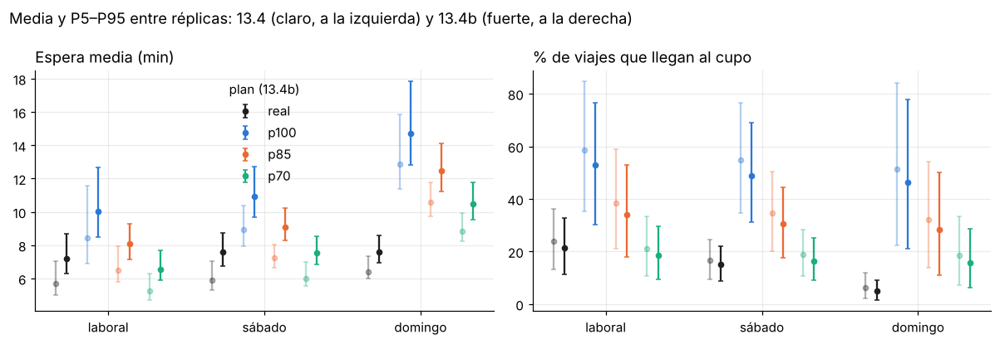

In [10]:
def tot(d, e):
    x = pd.read_parquet(d / f"{e}_indicadores.parquet")
    return x[x.idruta.astype(str) == "total"].set_index("semilla")
filas = []
for nom, d in (("13.4", MC0), ("13.4b", MC)):
    for t in ("laboral", "sabado", "domingo"):
        b = tot(d, f"real_{t}_central")
        for p in ("p100", "p85", "p70"):
            q = tot(d, f"{p}_{t}_central"); s = b.index.intersection(q.index)
            for k in ("espera_media_min", "pct_viajes_cupo", "pct_dejados_bus_lleno"):
                dd = q.loc[s, k] - b.loc[s, k]
                filas.append({"mc": nom, "tipo": t, "plan": p, "indicador": k, "dif": dd.mean(), "ic95": 1.96 * dd.std() / np.sqrt(len(dd))})
dp = pd.DataFrame(filas)
print("Diferencia de cada plan frente al plan real, réplica a réplica con la misma semilla (media ± IC95 %):")
display(dp.assign(v=dp.dif.round(2).astype(str) + " ± " + dp.ic95.round(2).astype(str))
          .pivot_table(index=["tipo", "plan"], columns=["indicador", "mc"], values="v", aggfunc="first"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, k, tit in zip(ax, ("espera_media_min", "pct_viajes_cupo"), ("Espera media (min)", "% de viajes que llegan al cupo")):
    for j, t in enumerate(("laboral", "sabado", "domingo")):
        for i, p in enumerate(("real", "p100", "p85", "p70")):
            for m, (RR, mk, al) in enumerate(((T0, "o", .35), (T, "o", 1))):
                x = RR[(RR.escenario == f"{p}_{t}_central") & (RR.indicador == k)].iloc[0]
                xx = j + (i - 1.5) * .2 + (m - .5) * .07
                a.errorbar(xx, x.media, yerr=[[x.media - x.p5], [x.p95 - x.media]], fmt=mk, ms=4, color=CP[p], alpha=al, capsize=2,
                           label=(p if m else None) if j == 0 else None)
    a.set_xticks(range(3), ("laboral", "sábado", "domingo")); a.set_title(tit, loc="left")
ax[0].legend(frameon=False, title="plan (13.4b)")
fig.suptitle("Media y P5–P95 entre réplicas: 13.4 (claro, a la izquierda) y 13.4b (fuerte, a la derecha)", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_4b_planes.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 8 · Con un motor más fiel, la espera sube y el cupo baja; el orden de los planes no cambia**
- **54 escenarios, 26.600 réplicas,** las 109 salidas con el hash de su manifiesto.
- **Niveles, 13.4 → 13.4b** (laboral, plan real): espera media **5,7 → 7,2 min**, viajes al cupo **24,1 → 21,3 %**, dejados por bus lleno 6,5 → 7,3 %, vuelta mediana 239,9 → 238,0 min. En los 12 planes × tipo de día la espera sube 1,2–2,0 min y los viajes al cupo bajan 1,3–5,8 puntos. Con el plan del proyecto al 100 %, los buses van más llenos y paran más: la vuelta crece 11,3 min en el laboral y 21,6 en el domingo.
- **Por qué sube la espera:** con la parada, los buses se desordenan más. A la mitad del circuito, el CV de los intervalos del laboral pasa de 0,85–0,97 a 0,96–1,17 (con regulación). Con llegadas al azar, la espera media es el intervalo medio × (1 + CV²) / 2 (Osuna y Newell, 1972): eso explica entre la mitad y tres cuartos del aumento; el resto, probablemente, el desorden que sigue creciendo después de la mitad del circuito (no medido).
- **Diferencias entre planes, réplica a réplica con la misma semilla, casi iguales a las de la 13.4:**

  | Laboral, frente al plan real | Espera 13.4 | Espera 13.4b | Cupo 13.4 | Cupo 13.4b |
  |---|---|---|---|---|
  | Proyecto al 100 % | +2,71 min | +2,80 min | +34,6 puntos | +31,8 puntos |
  | Proyecto al 85 % | +0,78 min | +0,89 min | +14,5 puntos | +12,9 puntos |
  | Proyecto al 70 % | −0,50 min | −0,64 min | −2,9 puntos | −2,8 puntos |

- **Al 85 %:** 15 % menos buses a la vez en el laboral (13.4: 17 %) y 39 % en el domingo (13.4: 42 %). **Al 70 %** sigue esperando menos que el plan real en el laboral; en el sábado pasa a empate (−0,06 ± 0,10 min; en la 13.4, +0,10 ± 0,10).
- **Se lee como comparación:** la espera absoluta del simulador probablemente es pesimista, porque sus buses siguen más desordenados que en el GPS (conclusión 9). Elegir el plan es del Módulo 14.

## 9 · Sensibilidades y el efecto de la regulación

In [11]:
g = lambda RR, e, k: float(RR[(RR.escenario == e) & (RR.indicador == k)].media.iat[0])   # noqa: E731
ks = ("espera_media_min", "pct_viajes_cupo", "pct_dejados_bus_lleno", "vuelta_mediana_min", "minutos_imprevistos", "salidas_sin_bus")
filas = []
for s in ("sigma_duracion_025", "sigma_duracion_100", "error_duracion", "obras_cierre", "google", "cota_inferior", "sin_variacion_dia",
          "regulacion", "sin_regulacion"):
    for p in ("real", "p85"):
        for nom, RR in (("13.4", T0), ("13.4b", T)):
            e = f"sens_{s}_{p}"
            if e in set(RR.escenario):
                filas.append({"sensibilidad": s, "plan": p, "mc": nom, **{k: g(RR, e, k) - g(RR, f"{p}_laboral_central", k) for k in ks}})
print("Cambio frente al escenario central del mismo Monte Carlo (laboral):")
display(pd.DataFrame(filas).set_index(["sensibilidad", "plan", "mc"]).round(2))
iv0, iv = pd.read_csv(MC0 / "intervalos_regulacion_13_4.csv"), pd.read_csv(MC / "intervalos_regulacion_13_4b.csv")
q = pd.concat({"13.4": iv0.groupby(["escenario", "idruta"])[["cv_intervalos", "pct_intervalos_menos_1min"]].mean(),
               "13.4b": iv.groupby(["escenario", "idruta"])[["cv_intervalos", "pct_intervalos_menos_1min"]].mean()}).round(2)
print("Buses pegados a la mitad del circuito, 6–20 h, 30 réplicas de un laboral de desarrollo:")
display(q)
sv = pd.read_csv(VAL / "secundarias_13_4.csv"); sv = sv[(sv.demanda == "pred") & sv.rol.isin(["laboral_1", "laboral_2"])]
print("GPS de los 2 laborales de validación (mín–máx):")
display(sv.groupby("idruta")[["cv_intervalos_real", "pct_intervalos_menos_1min_real"]].agg(["min", "max"]).round(2))

Cambio frente al escenario central del mismo Monte Carlo (laboral):


espera_media_min  pct_viajes_cupo  pct_dejados_bus_lleno  vuelta_mediana_min  minutos_imprevistos  salidas_sin_bus
sensibilidad       plan mc                                                                                                                       
sigma_duracion_025 real 13.4              -0.04            -0.02                  -0.04               -0.00               -21.31             0.00
                        13.4b             -0.02            -0.05                  -0.03               -0.02               -24.22             0.00
                   p85  13.4              -0.02             0.05                   0.01               -0.05               -14.49             0.00
                        13.4b             -0.05            -0.05                  -0.02                0.00               -16.34             0.00
sigma_duracion_100 real 13.4               0.09            -0.06                  -0.01                0.12                59.18             0.00
                        13.4b              0.07            -0.08                  -0.01                0.16                63.85             0.02
                   p85  13.4               0.03            -0.12                  -0.02                0.06                56.12             0.00
                        13.4b              0.02            -0.12                  -0.03                0.20                58.04             0.00
error_duracion     real 13.4               0.04             0.03                   0.04                0.15               149.29             0.14
                        13.4b              0.03            -0.01                  -0.05                0.18               152.52             0.17
                   p85  13.4               0.06             0.11                   0.09                0.09               120.77             0.00
                        13.4b              0.08             0.02                   0.04                0.16               125.96             0.00
obras_cierre       real 13.4               0.35             0.23                   0.18               -0.28               -33.84             0.00
                        13.4b              0.34             0.29                   0.17               -0.17               -13.62            -0.01
                   p85  13.4               0.42             0.19                   0.18               -0.36               -43.58             0.00
                        13.4b              0.41             0.27                   0.16               -0.19               -26.22             0.00
google             real 13.4               0.16             0.48                   0.18               12.45                 1.78             0.00
                        13.4b              0.12             0.64                   0.11               12.73                 1.28             0.17
                   p85  13.4               0.30             1.84                   0.70               13.60                 3.73             0.00
                        13.4b              0.18             1.82                   0.38               14.45                 2.65             0.00
cota_inferior      real 13.4              -0.42            -7.83                  -2.11                0.03                 0.61             0.00
                        13.4b             -0.57            -6.93                  -2.30               -2.77                -1.43            -0.15
                   p85  13.4              -0.43           -11.98                  -2.65               -0.08                 3.19             0.00
                        13.4b             -0.54           -10.85                  -2.92               -3.62                -1.47             0.00
sin_variacion_dia  real 13.4              -0.11            -0.64                  -0.17                0.05                 0.59             0.00
                        13.4b             -0.12            -0.57                  -0.19  

Buses pegados a la mitad del circuito, 6–20 h, 30 réplicas de un laboral de desarrollo:


cv_intervalos  pct_intervalos_menos_1min
      escenario                idruta                                          
13.4  p85_laboral_central      2                0.90                      11.31
                               16               0.95                      22.79
                               21               0.78                       6.36
      real_laboral_central     2                0.94                      15.13
                               16               0.97                      27.57
                               21               0.85                       8.06
      sens_regulacion_p85      2                0.79                       6.45
                               16               0.87                      10.28
                               21               0.67                       3.25
      sens_regulacion_real     2                0.82                       9.16
                               16               0.87                      13.59
                               21               0.76                       3.66
13.4b p85_laboral_central      2                1.06                      14.18
                               16               1.15                      16.42
                               21               0.86                       7.34
      real_laboral_central     2                1.08                      14.08
                               16               1.17                      21.30
                               21               0.96                       8.73
      sens_sin_regulacion_p85  2                1.15                      18.66
                               16               1.28                      33.56
                               21               0.98                      13.47
      sens_sin_regulacion_real 2                1.19                      21.92
                               16               1.28                      35.02
                               21               1.10                      16.41

GPS de los 2 laborales de validación (mín–máx):


cv_intervalos_real       pct_intervalos_menos_1min_real       
                      min   max                            min    max
idruta                                                               
2                    0.83  0.84                          11.20  11.50
16                   0.96  0.96                          20.09  28.92
21                   0.63  0.72                           1.32   6.76

**Conclusión 9 · Los supuestos pesan lo mismo que en la 13.4; la regulación ordena el paso de los buses**
- **Las sensibilidades cambian casi igual que en la 13.4:** la demanda sigue pesando más que todo (cota inferior: −11,3 % de pasajeros y 14,3 % de viajes al cupo frente a 21,3 %); los tiempos de Google alargan la vuelta +5,3 % con el plan real y +5,8 % con el del proyecto al 85 %; con error en la duración estimada, los minutos perdidos en imprevistos suben +54 %; con todas las obras como cierre, la espera sube +4,8 %.
- **Nuevo, por la parada:** con la cota inferior (menos gente) la vuelta se acorta 2,8 min, porque los buses paran menos. En la 13.4 no cambiaba.
- **Sin regulación,** los indicadores del día casi no cambian (espera +0,02 min, cupo −0,09 puntos, vuelta −0,9 min), pero los buses se pegan mucho más. En 30 réplicas de un laboral de desarrollo, intervalos < 1 min:

  | Ruta | Con regulación (central) | Sin regulación | GPS de los 2 laborales de validación |
  |---|---|---|---|
  | 2 | 14,1 % | 21,9 % | 11,2–11,5 % |
  | 16 | 21,3 % | 35,0 % | 20,1–28,9 % |
  | 21 | 8,7 % | 16,4 % | 1,3–6,8 % |

- **Con regulación,** la ruta 16 queda en el rango del GPS y las otras dos cerca. El CV de los intervalos sigue por encima del GPS (1,08 / 1,17 / 0,96 frente a 0,83–0,84 / 0,96 / 0,63–0,72): en la calle los conductores se regulan en más puntos que uno.

## 10 · Reproducibilidad y lo que pasa a la 13.5

In [12]:
seg = pd.Series({k: v["segundos"] / v["replicas"] for k, v in man["escenarios"].items()})
print(f"Segundos de reloj por réplica (10 procesos): mediana {seg.median():.2f}, máximo {seg.max():.2f} · "
      f"{sum(v['segundos'] for v in man['escenarios'].values()) / 3600:.2f} h de reloj en total")
print("Pasos de la réplica representativa guardados para el gemelo digital:", len(list(MC.glob("*_pasos.parquet"))), "escenarios")
enm = json.loads((VAL / "enmiendas_codigo_13_4.json").read_text(encoding="utf-8"))
print("Enmiendas registradas del código de la 13.4:", len(enm.get("historial", [])), "·", ", ".join(enm["archivos"]))
print("Python", sys.version.split()[0])

Segundos de reloj por réplica (10 procesos): mediana 0.24, máximo 0.30 · 1.72 h de reloj en total
Pasos de la réplica representativa guardados para el gemelo digital: 54 escenarios
Enmiendas registradas del código de la 13.4: 4 · src/simulation/motor.py, src/simulation/escenario.py, src/simulation/imprevistos.py, src/simulation/monte_carlo_engine.py
Python 3.13.16


**Conclusión 10 · Todo queda reproducible y con sus opciones rotuladas para el gemelo**
- **Rapidez:** el Monte Carlo final corrió en el PC de la Persona 3 en 1,7 h de reloj con 10 procesos (0,24 s por réplica en la mediana).
- **Convergencia:** como en la 13.4, solo los 2 escenarios sin factor del día llegan al 1 % antes de 500 réplicas (aquí, a las 300). A las 500, la mitad del IC95 % queda en 1,0 % de la media para la espera, 2,6 % para el cupo y 0,4 % para la vuelta (mediana de los escenarios).
- **Reglas congeladas y verificables:** cada ronda tiene su regla con los hashes del código y de los insumos, escrita antes de simular, y su decisión con el hash de la regla; repetir una evaluación o una decisión se rechaza (`tests_13_4b.py` 7/7).
- **Las subfases cerradas no cambian:** sin `ajustes`, el motor da las mismas réplicas que la 13.2 (pruebas c y f) y la 13.4 reproduce su evaluación (`enmiendas_codigo_13_4.json`, 4 enmiendas registradas).
- **Para la 13.5:** los pasos de la réplica representativa de los 54 escenarios; la regulación en el central; el intervalo por celda como opción rotulada.

## Síntesis · Subfase 13.4b
- **6 rondas, cada una con su regla congelada antes de simular y una sola evaluación en los 3 días de control.** Se adoptaron el tiempo de parada (8,9 s por parada y 8,6 s por pasajero), «primero bajan» y el factor de velocidad del día. No se adoptaron el reparto por tipo de día ni, por la regla, la regulación y el intervalo por celda.
- **El simulador es más fiel a la calle en su física:**
  - los buses llenos van más lento;
  - el cupo queda a +1,4 puntos de lo real (antes +3,6 en los días de control);
  - la vuelta del día varía como en 2025: el intervalo cubre el 83–94 % de los días reales (antes 33–72 %);
  - con la regulación, los buses pegados quedan cerca del GPS.
- **La ocupación casi no mejora:** −2 a −3 % de MAE en los días de control, y en los días de validación sigue en 3 de 6 frente al perfil histórico (reevaluación «no ciega»; el oficial de la 13.4 no cambia). Lo que sigue abierto es que en los laborales el simulador lleva menos gente a bordo que lo observado (−3,1 pasajeros), y no viene de dónde se bajan.
- **Monte Carlo final:** la espera sube 1,2–2,0 min porque los buses se desordenan más y el cupo baja 1,3–5,8 puntos. **Las diferencias entre planes quedan casi iguales a las de la 13.4:** las conclusiones de la 13.4 sobre los planes se sostienen con un motor más fiel.
- **Decisiones de la Persona 3, rotuladas «después de ver los resultados»:** la regulación en el escenario central del Monte Carlo y el intervalo por celda como opción. Las decisiones de Claude W1–W8 las confirmó la Persona 3 al cerrar la subfase (5-nov, 20:05; `revisiones/revision_13_4b.md`).
- **Siguiente:** la 13.5 (gemelo digital) parte de los pasos guardados de los 54 escenarios.

<a id="m13-6"></a>

### A2.5.6 &middot; Subfase 13.5 · Gemelo digital

<sub>Notebook original: `modulo13/subfase_13_5_gemelo.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 13 · Subfase 13.5 — Gemelo digital

**Persona 3.** Una aplicación local (Streamlit + Pydeck) que muestra un día de operación de las rutas 2, 16 y 21 con lo que
produjeron la 13.4 y la 13.4b, y deja probar un escenario y marcar un imprevisto en vivo con el mismo motor y las mismas
semillas. Alcance aprobado: `revisiones/alcance_13_5.md` (5-nov-2026, 22:52). Se abre con
`py -m streamlit run gemelo_13_5.py`.

| Pantalla | Qué muestra |
|---|---|
| Mapa del día | Los buses de la réplica representativa moviéndose minuto a minuto, con su ocupación |
| Indicadores | Media y P5–P95 entre réplicas de cada escenario; gente a bordo por segmento y hora |
| Comparar planes | Diferencia réplica a réplica (misma semilla) entre dos escenarios, con su IC95 % |
| Validación | Los 6 días congelados: simulado frente a observado (oficial 13.4 y «no ciego» 13.4b) |
| Probar un escenario | Plan, demanda, lluvia, imprevistos, regulación y un imprevisto marcado a mano, corridos en vivo |
| Supuestos y límites | Lo que el gemelo sabe y lo que no, con las decisiones rotuladas |

In [1]:
import hashlib, json, sys, time
from dataclasses import asdict
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, ".")
from src.gemelo import datos as D, en_vivo as V
from src.simulation import escenario as E
import montecarlo_13_4b as MO

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
FIG = Path("resultados_13")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 10, "figure.dpi": 110})
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
P = E.cargar_parametros()

## 1 · Insumos: lo que ya se simuló, sin volver a calcularlo

In [2]:
man = json.loads((D.GEM / "manifiesto_gemelo_13_5.json").read_text(encoding="utf-8"))
print("Preparado:", man["creado"], "· salidas con su hash:",
      sum(sha(D.GEM / k) == v for k, v in man["salidas"].items()), "de", len(man["salidas"]))
print("Entradas: Monte Carlo 13.4b", man["entradas"]["manifiesto_montecarlo_13_4b"][:12], "= actual:",
      man["entradas"]["manifiesto_montecarlo_13_4b"] == sha(D.MC / "manifiesto_montecarlo_13_4.json"),
      "· red de segmentos", man["entradas"]["red_vial_segmentos.geojson"][:12])
es = pd.DataFrame(man["escenarios"]).T
print(f"{len(es)} escenarios · {es.posiciones.sum():,} posiciones de bus por minuto · sin capacidad conocida: {es.sin_capacidad.sum()}")
cat = D.catalogo()
display(cat.groupby("grupo").escenario.count().rename("escenarios"))
print("Tamaño en disco:", round(sum(f.stat().st_size for f in D.GEM.glob("*")) / 1e6, 1), "MB")

Preparado: 2026-11-05T22:57:32 · salidas con su hash: 55 de 55
Entradas: Monte Carlo 13.4b 018877ecedc9 = actual: True · red de segmentos f78a2d8a426b
54 escenarios · 5,653,409 posiciones de bus por minuto · sin capacidad conocida: 0


grupo
principal       12
sensibilidad    22
variante        20
Name: escenarios, dtype: int64

Tamaño en disco: 40.7 MB


**Conclusión 1 · El gemelo lee los 54 escenarios del Monte Carlo final sin recalcularlos**
- **54 escenarios:** 12 de planes por tipo de día, 20 variantes (tasas de imprevistos y demanda real) y 22 sensibilidades.
- **Preparación una sola vez** (`preparar_gemelo_13_5.py`, ~40 s): 5.653.409 posiciones de bus por minuto en 40,7 MB; las 55 salidas tienen su hash, y el manifiesto guarda el del Monte Carlo de la 13.4b del que salen.
- Todos los buses tienen su capacidad, la misma que usa el motor.

## 2 · Del paso por segmento a un bus en el mapa

El motor guarda, por cada bus y vuelta, la hora en que entra a cada segmento de 500 m, cuánto tarda y con cuánta gente
va. El gemelo interpola la posición entre la entrada y la salida del segmento, sobre la geometría de `rutas_segmentos`
(Módulo 10). Si el bus espera por la regulación, se queda quieto al final de su segmento.

Puntos de la geometría: 4632 · {2: 135, 16: 123, 21: 128} segmentos por ruta


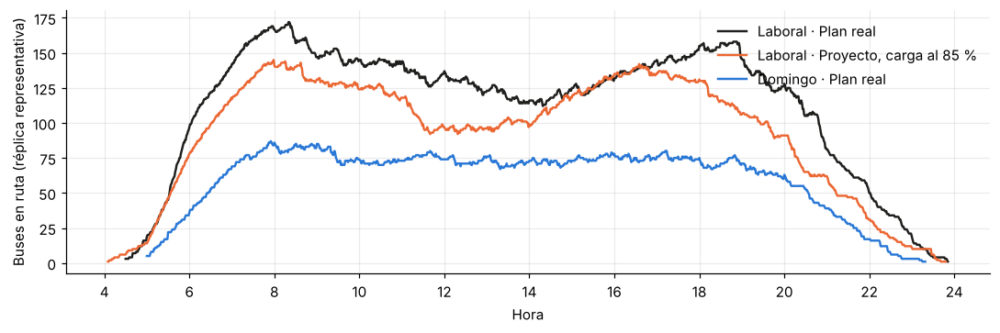

Laboral, plan real: 132,011 posiciones de 217 buses en 557 vueltas · máximo 172 buses a la vez a las 8 h · buses llenos en algún minuto: 96


In [3]:
g = D.geometria()
print("Puntos de la geometría:", len(g), "·", g.groupby("idruta").nro_segmento.max().to_dict(), "segmentos por ruta")
pos = {n: D.posiciones_guardadas(n) for n in ("real_laboral_central", "p85_laboral_central", "real_domingo_central")}
fig, ax = plt.subplots(figsize=(10, 3.4))
col = {"real_laboral_central": "#1f1f1d", "p85_laboral_central": "#eb6834", "real_domingo_central": "#2a78d6"}
for n, p in pos.items():
    b = p.groupby(p.t_s // 60).bus.size()
    ax.plot(b.index / 60, b.values, color=col[n], lw=1.6, label=D.etiqueta(n).replace(" · Imprevistos a tasa central", ""))
ax.set_xlabel("Hora"); ax.set_ylabel("Buses en ruta (réplica representativa)"); ax.set_xticks(range(4, 25, 2))
ax.legend(frameon=False, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "m13_5_buses_en_ruta.png", dpi=200, bbox_inches="tight"); plt.show()
p = pos["real_laboral_central"]
pa = D.pasos("real_laboral_central")
print(f"Laboral, plan real: {len(p):,} posiciones de {p.bus.nunique()} buses en {pa.id_salida.nunique()} vueltas · "
      f"máximo {p.groupby('t_s').size().max()} buses a la vez a las {int(p.groupby('t_s').size().idxmax() // 3600)} h · "
      f"buses llenos en algún minuto: {p[p.ocupacion >= 1].bus.nunique()}")

**Conclusión 2 · Cada bus está donde dicen sus pasos**
- **Geometría:** 4.632 puntos sobre los 135 / 123 / 128 segmentos de las rutas 2 / 16 / 21, sin huecos entre un segmento y el siguiente.
- **Posición:** cada minuto, cada bus queda sobre el segmento que estaba recorriendo, entre su entrada y su salida. Las 542 posiciones en que el bus espera por la regulación (laboral, plan real) quedan quietas al final de su segmento (`tests_13_5.py` b).
- **Laboral con el plan real:** 132.011 posiciones de 217 buses en 557 vueltas; a las 8 h hay 172 buses en ruta a la vez, y 96 buses van llenos en algún momento del día.
- El indicador «buses a la vez» del Monte Carlo (179) suma el máximo de cada ruta, que no ocurre en el mismo minuto; el mapa cuenta los buses de las tres rutas en cada minuto.

## 3 · Indicadores y comparación de planes

In [4]:
r = D.resumen()
n_ok = 0
for e in cat.escenario:
    t = D.tabla_resumen(D.indicadores(e)).set_index("clave")
    x = r[(r.escenario == e) & (r.idruta == "total")].set_index("indicador")
    n_ok += int(all(np.isclose(t.media[k], x.media[k]) and np.isclose(t.p5[k], x.p5[k]) for k in t.index))
print(f"Indicadores de la app iguales al resumen del Monte Carlo: {n_ok} de {len(cat)} escenarios")
d = D.diferencia_pareada(D.indicadores("real_laboral_central"), D.indicadores("p85_laboral_central"))
display(d[["indicador", "a", "b", "dif", "ic95", "pct_b_menor"]].round(2))

Indicadores de la app iguales al resumen del Monte Carlo: 54 de 54 escenarios


,indicador,a,b,dif,ic95,pct_b_menor
0,Espera media,7.21,8.09,0.89,0.09,7.2
1,Espera P90,16.83,18.83,2.01,0.13,6.0
2,Viajes que llegan al cupo,21.28,34.14,12.86,0.38,0.0
3,Dejados por bus lleno,7.30,8.97,1.67,0.11,9.8
4,Vuelta mediana,238.00,248.00,10.00,0.20,0.0
5,Buses a la vez,178.96,151.57,-27.39,0.26,100.0
6,Pasajeros del día,47169.25,47213.05,43.80,7.85,22.6
7,Salidas,556.72,450.00,-106.72,0.08,100.0
8,Minutos perdidos en imprevistos,283.46,230.33,-53.12,44.23,55.6


**Conclusión 3 · Las cifras que muestra la app son las del Monte Carlo**
- **Iguales al resumen de la 13.4b en los 54 escenarios** (1.944 medias y P5–P95 de 9 indicadores × 4 rutas).
- **Comparar planes** reproduce la diferencia réplica a réplica de la 13.4b: el plan del proyecto al 85 % frente al real en el laboral espera +0,89 min (± 0,09), llega al cupo en +12,9 puntos (± 0,4) y usa 27,4 buses menos a la vez.
- La validación muestra el resultado oficial de la 13.4 (3 de 6 días) y, aparte y rotulado, el «no ciego» de la 13.4b.

## 4 · Probar un escenario y un imprevisto en vivo

In [5]:
cfg = V.Configuracion()
vistos = {c.nombre_guardado() for c in (V.Configuracion(t, p, d, ll, i, rg) for t in D.TIPOS for p in D.PLANES
          for d in ("pred", "real", "cota_inferior") for i in ("central", "baja", "alta") for ll in (False, True) for rg in (True, False)
          if not (ll and t != "laboral"))} - {None}
print("Escenarios del Monte Carlo que se pueden armar en vivo:", len(vistos), "de 54")
t0 = time.time(); r0 = V.correr(cfg, n=10, P=P); s0 = time.time() - t0
EV = dict(tipo="choque", idruta=16, nro_segmento=40, inicio_s=7.5 * 3600, duracion_min=60, severidad=5)
t0 = time.time(); r1 = V.correr(cfg, n=10, eventos=[EV], P=P); s1 = time.time() - t0
g = D.indicadores("real_laboral_central").query("replica < 10").sort_values(["semilla", "idruta"]).reset_index(drop=True)
a = r0["indicadores"].sort_values(["semilla", "idruta"]).reset_index(drop=True)[g.columns]
num = [c for c in g.columns if c not in ("idruta", "replica", "semilla")]
iguales = pd.Series(np.isclose(a[num].astype(float), g[num].astype(float)).all(axis=1), index=a.semilla).groupby(level=0).all()
print(f"10 réplicas en vivo del laboral con el plan real: {int(iguales.sum())} de 10 idénticas a las guardadas en el PC (Windows)")
print(f"Tiempo en este equipo, 1 proceso: {s0:.0f} s sin imprevisto y {s1:.0f} s con él ({(s0 + s1) / 22:.1f} s por réplica)")
dv = V.desvio(EV, E.dias_desarrollo(3)["laboral"])
for k, x in dv.items():
    print(f"Ruta {k}: {x['recomendacion']} · segmentos {x['segmentos_bloqueados']} · alterna por {', '.join(x['calles'][:5])}")
dd = D.diferencia_pareada(r0["indicadores"], r1["indicadores"], ruta="16")
display(dd[["indicador", "a", "b", "dif", "ic95"]].round(2))
pp = r1["pasos"]
dsv = pp[(pp.idruta == 16) & pp.alterna]
print(f"Réplica representativa con el cierre: {dsv.id_salida.nunique()} vueltas de la ruta 16 en desvío entre las "
      f"{int(dsv.t_s.min() // 3600)}:{int(dsv.t_s.min() % 3600 // 60):02d} y las {int(dsv.t_s.max() // 3600)}:{int(dsv.t_s.max() % 3600 // 60):02d}")

Escenarios del Monte Carlo que se pueden armar en vivo: 38 de 54


10 réplicas en vivo del laboral con el plan real: 10 de 10 idénticas a las guardadas en el PC (Windows)
Tiempo en este equipo, 1 proceso: 25 s sin imprevisto y 13 s con él (1.7 s por réplica)
Ruta 16: desviar · segmentos [40] · alterna por Carrera 54, Calle 72, Avenida Carrera 46, Carrera 46, Avenida Carrera 46


,indicador,a,b,dif,ic95
0,Espera media,5.10,5.15,0.05,0.25
1,Espera P90,12.06,12.39,0.33,0.77
2,Viajes que llegan al cupo,21.28,21.45,0.17,1.58
3,Dejados por bus lleno,7.38,7.89,0.51,0.78
4,Vuelta mediana,232.86,233.85,0.99,0.87
5,Buses a la vez,90.80,91.70,0.90,1.22
6,Pasajeros del día,24495.30,24504.60,9.30,25.97
7,Salidas,297.00,297.00,0.00,0.00
8,Minutos perdidos en imprevistos,233.93,373.62,139.70,15.29


Réplica representativa con el cierre: 28 vueltas de la ruta 16 en desvío entre las 7:40 y las 8:21


**Conclusión 4 · En vivo da lo mismo que el Monte Carlo, y el cierre se desvía por la alterna del Módulo 12**
- **Se pueden armar 38 de los 54 escenarios** desde la app (plan, tipo de día, demanda, tasa de imprevistos, lluvia y regulación); los otros 16 son sensibilidades de supuestos (σ de duración, error del centro de control, obras, Google, sin variación entre días, umbral del arroyo).
- **Mismas semillas, mismo resultado:** 10 réplicas en vivo del laboral con el plan real salen idénticas a las 10 primeras guardadas, aunque esas se corrieron en el PC (Windows) y estas en Linux.
- **Rapidez:** 1,7 s por réplica con un proceso en el entorno de trabajo. En varios procesos, cada proceso carga una vez el grafo del Módulo 12 (~10 s) y queda abierto para las corridas siguientes; sin y con el imprevisto van en una sola tanda (`tests_13_5.py` j: 2 procesos dan lo mismo que en serie).
- **Imprevistos marcados a mano:** hasta 5 en el mismo día, además de los que sortea la tasa (`tests_13_5.py` h y k). Con uno (choque de gravedad 5 en el segmento 40 de la ruta 16, a las 7:30, 60 min):
  - el Módulo 12 recomienda desviar por la Carrera 54, la Calle 72 y la Avenida Carrera 46;
  - en la réplica representativa, 28 vueltas de la ruta 16 se desvían entre las 7:40 y las 8:21;
  - en la ruta 16, los minutos perdidos en imprevistos suben de 233,9 a 373,6 (+139,7 ± 15,3);
  - la espera casi no cambia (+0,05 ± 0,25 min): una hora de cierre en un punto con alterna pesa poco en el día.

## 5 · Las pantallas

Capturas tomadas con Playwright (Chromium) sobre la app corriendo en el entorno de trabajo, **sin internet: por eso sin mapa de fondo**. En el PC, con internet, se ve el mapa de CARTO debajo de las rutas.

Mapa del día (laboral, plan real, 7:00)


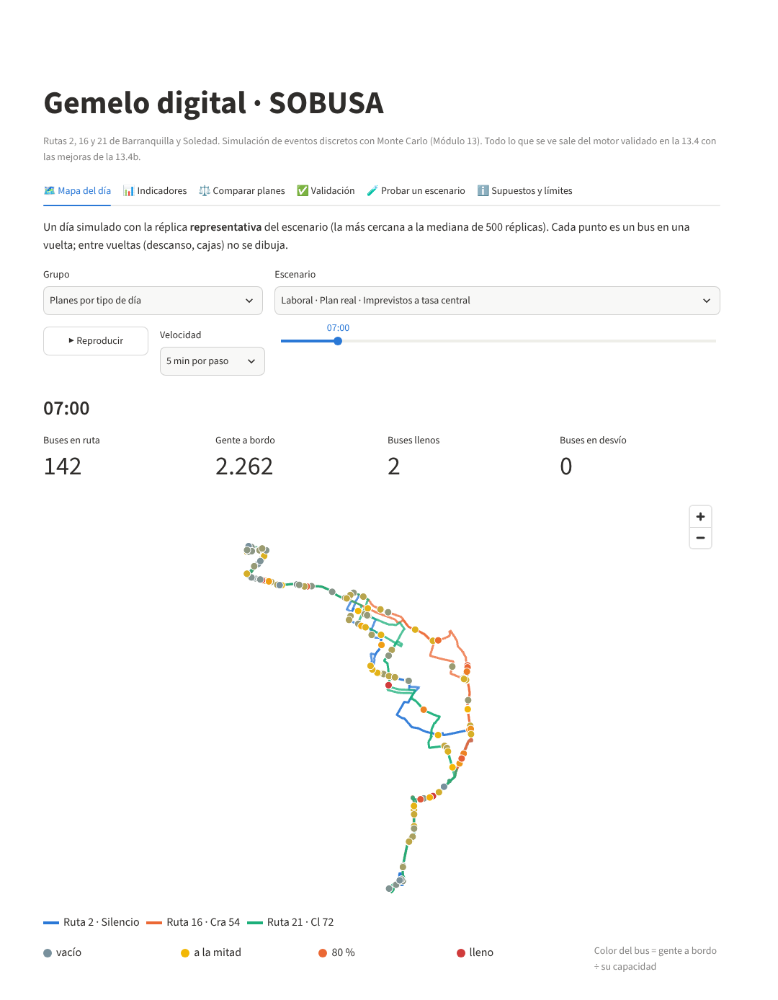

Indicadores


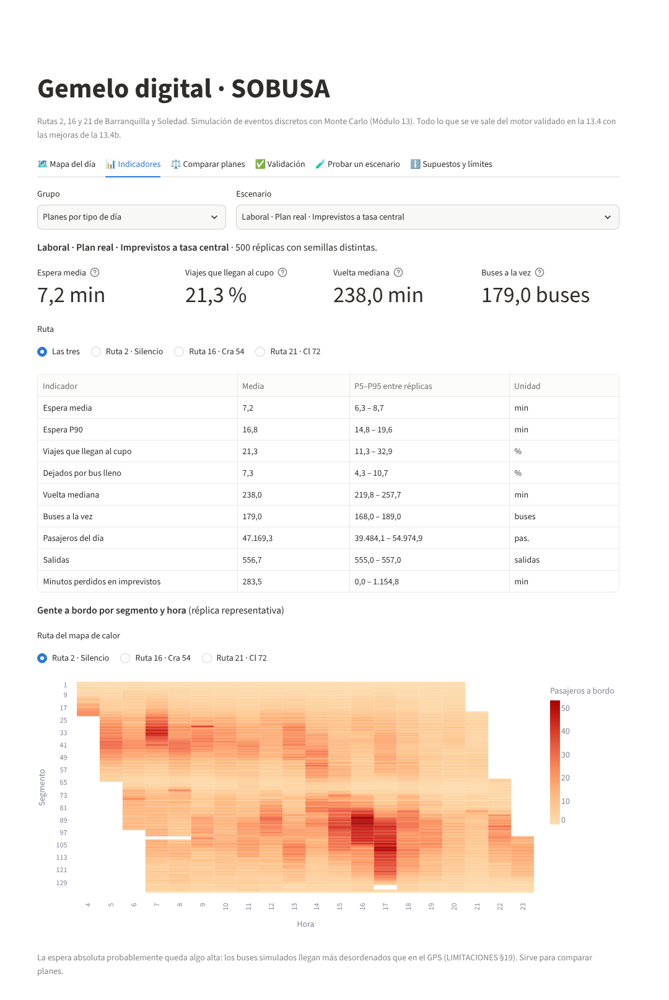

Comparar planes


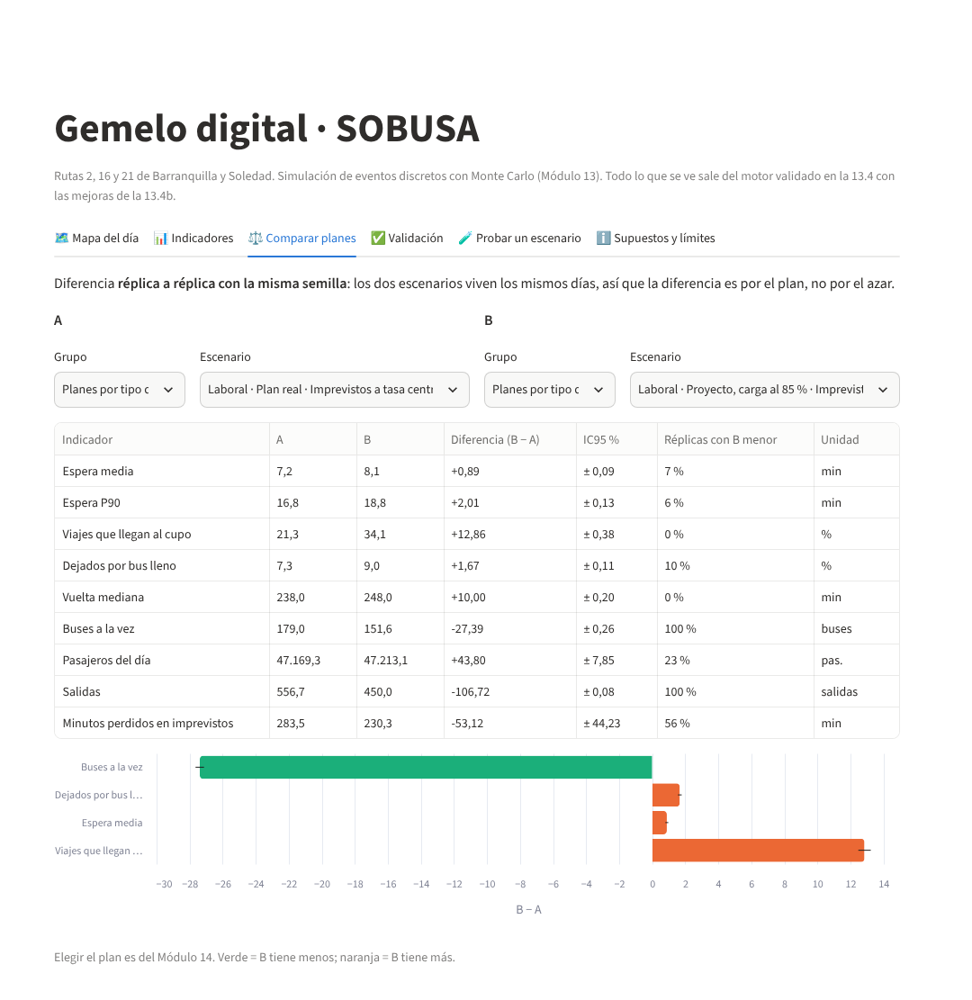

Validación


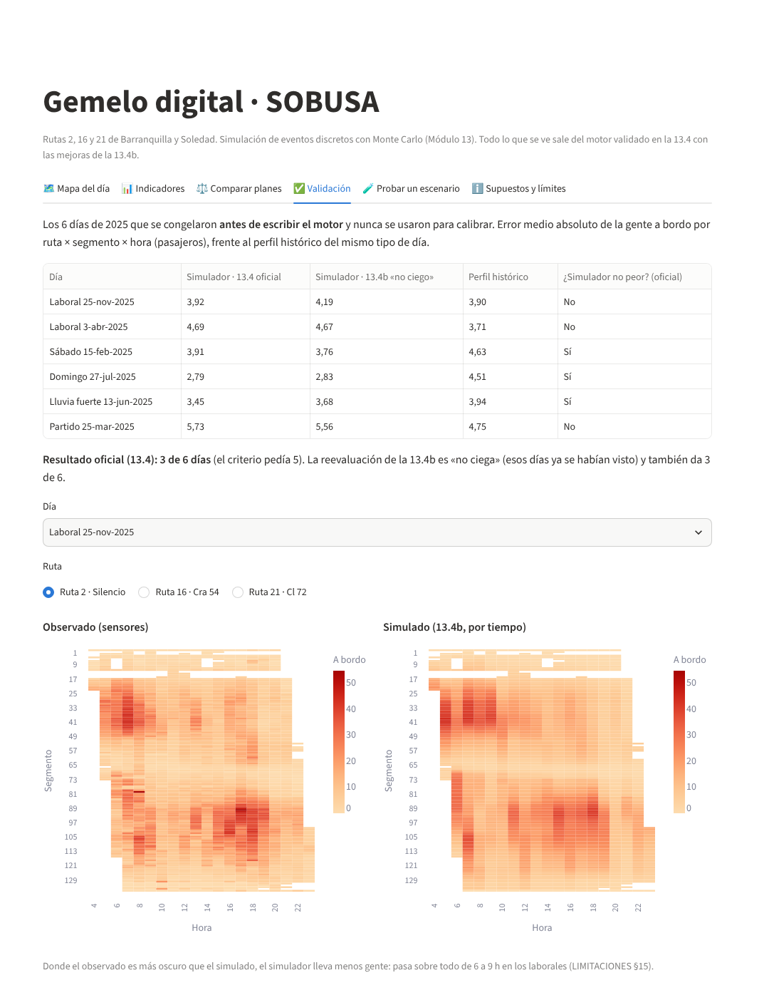

Probar un escenario: cierre en el segmento 40 de la ruta 16


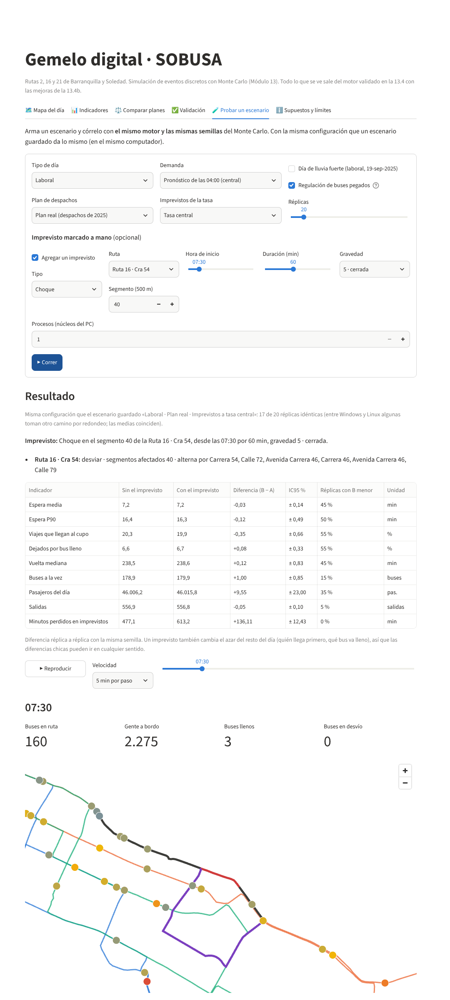

Supuestos y límites


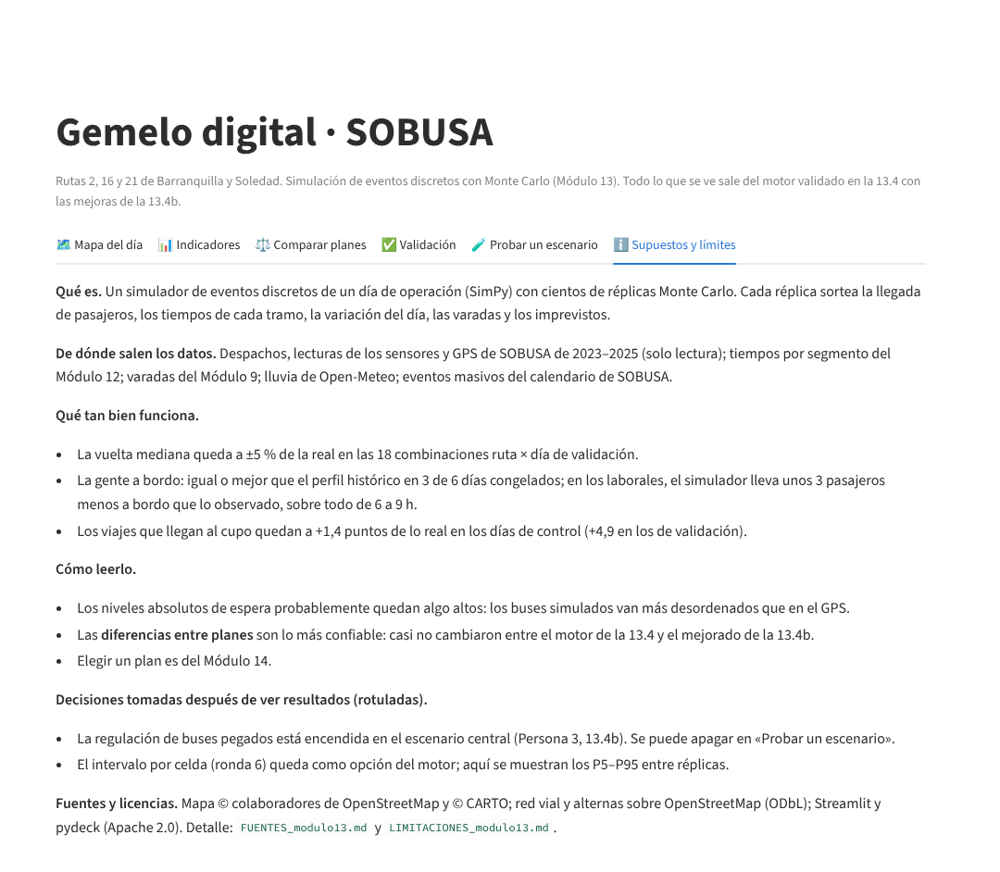

In [6]:
for n, t in (("mapa", "Mapa del día (laboral, plan real, 7:00)"), ("indicadores", "Indicadores"), ("comparar", "Comparar planes"),
             ("validacion", "Validación"), ("probar", "Probar un escenario: cierre en el segmento 40 de la ruta 16"),
             ("supuestos", "Supuestos y límites")):
    print(t); display(Image(filename=str(FIG / f"m13_5_{n}.png"), width=900))

**Conclusión 5 · Seis pantallas para quien no lee notebooks**
- **Mapa del día, indicadores, comparar planes, validación, probar un escenario y supuestos y límites**, en español sencillo, con la leyenda de colores y los rótulos de las decisiones tomadas después de ver los resultados.
- **La app abre sin errores en las 6 pestañas y corre en vivo con un imprevisto** (prueba sin navegador, `tests_13_5.py` h, y capturas con Chromium).
- **Sin llamadas a la base ni a APIs:** Streamlit no envía estadísticas de uso (`gatherUsageStats = false`). El mapa de fondo de CARTO lo pide el navegador y se puede apagar. Es gratis para uso no comercial; un uso comercial de SOBUSA exige revisar sus condiciones (FUENTES C7).

## Síntesis · Subfase 13.5
- **El gemelo digital ya muestra un día de operación de las rutas 2, 16 y 21** con lo que validó la 13.4 y mejoró la 13.4b: buses moviéndose con su ocupación, indicadores con su P5–P95, comparación de planes réplica a réplica y la validación con sus 3 de 6 días, sin esconderla.
- **No es otro modelo:** las cifras de la app son las del Monte Carlo (54 de 54 escenarios), y en vivo usa el mismo motor y las mismas semillas, así que reproduce lo guardado (10 de 10 réplicas).
- **Deja probar lo que pide el plan del Entregable 3:** cambiar el plan de despachos, la demanda, la lluvia o la regulación, y marcar un imprevisto para ver el desvío del Módulo 12 y su efecto en el día.
- **Se usa para comparar escenarios, no para predecir un día concreto:** la espera absoluta probablemente queda algo alta y en los laborales el simulador lleva unos 3 pasajeros menos a bordo (LIMITACIONES §15–19).
- **Se abre en el PC** con `py -m streamlit run gemelo_13_5.py`.
- **Siguiente:** la 13.6, el cierre del Módulo 13.

<a id="m13-7"></a>

### A2.5.7 &middot; Subfase 13.6 · Cierre y entrega

<sub>Notebook original: `modulo13/subfase_13_6_cierre.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 13 · Subfase 13.6 — Cierre y entrega

**Persona 3.** Deja el Módulo 13 listo para entregar:
- se compara con el texto completo del plan del Entregable 3, frase por frase;
- se cierran las brechas que salieron de esa comparación (B1–B5: fluidez, acelerador, barras de capacidad, imprevistos en el mapa y nombre del entregable);
- se comprueba que todo corre en el PC;
- queda el paquete del zip, el texto para el informe final y la nota para el Módulo 14.

Alcance aprobado: `revisiones/alcance_13_6.md` (6-nov-2026, 12:12).

In [1]:
import json, os, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

sys.path.insert(0, ".")
from src.gemelo import animado as A, datos as D

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None); pd.set_option("display.max_colwidth", 120)
FIG, REV = Path("resultados_13"), Path("revisiones")
def correr(*a):
    p = subprocess.run([sys.executable, *a], capture_output=True, text=True, encoding="utf-8", errors="replace",
                       env={**os.environ, "PYTHONIOENCODING": "utf-8", "PYTHONUTF8": "1"})
    return p.stdout

## 1 · El plan completo, frase por frase

La R1 de la 13.5 se hizo con los fragmentos del plan citados en los alcances. Esta vez se leyó el PDF completo
(`ENTREGABLE3Plan_Modulos_9_en_adelante_SOBUSA-v2.pdf`, FUENTES A11), y aparecieron cinco puntos sin cubrir. Se dice
explícitamente, como corrección de la 13.5. La tabla completa está en `revisiones/revision_13_6.md` (R1).

In [2]:
brechas = pd.DataFrame([
    ("B1", "«Rendimiento visual fluido ≥ 30 FPS»", "Nunca se midió; el mapa se redibujaba desde Python cada 0,6 s (≤ 1,7 cuadros/s)", "Animación en el navegador (deck.gl) y botón «Medir fluidez»"),
    ("B2", "«aceleración 1x a 60x»", "Pasos de 1 a 10 min cada 0,6 s (≈ 100x a 1.000x)", "1x, 2x, 5x, 10x, 30x, 60x (+ 300x y 600x)"),
    ("B3", "«barras de capacidad»", "Color por ocupación y contadores de la red", "Barra por bus = gente a bordo ÷ capacidad"),
    ("B4", "«presencia de arroyos/bloqueos»", "Solo el bus en desvío", "Imprevistos de la réplica, tramos cerrados y varadas mientras duran"),
    ("B5", "«app/gemelo_digital.py»", "La app se llamaba gemelo_13_5.py", "app/gemelo_digital.py (misma app + pestaña animada)"),
], columns=["Brecha", "Texto del plan", "Antes (13.5)", "13.6"])
brechas

,Brecha,Texto del plan,Antes (13.5),13.6
0,B1,«Rendimiento visual fluido ≥ 30 FPS»,"Nunca se midió; el mapa se redibujaba desde Python cada 0,6 s (≤ 1,7 cuadros/s)",Animación en el navegador (deck.gl) y botón «Medir fluidez»
1,B2,«aceleración 1x a 60x»,"Pasos de 1 a 10 min cada 0,6 s (≈ 100x a 1.000x)","1x, 2x, 5x, 10x, 30x, 60x (+ 300x y 600x)"
2,B3,«barras de capacidad»,Color por ocupación y contadores de la red,Barra por bus = gente a bordo ÷ capacidad
3,B4,«presencia de arroyos/bloqueos»,Solo el bus en desvío,"Imprevistos de la réplica, tramos cerrados y varadas mientras duran"
4,B5,«app/gemelo_digital.py»,La app se llamaba gemelo_13_5.py,app/gemelo_digital.py (misma app + pestaña animada)


**Conclusión 1 · El plan completo, con cinco brechas del gemelo cerradas**
- **Por primera vez, el Módulo 13 se comparó con el PDF completo del plan:** 22 frases. Todas quedan cubiertas, salvo el pitch, que se trata aparte (decisión 6 del alcance).
- **Corrección de la 13.5:** su revisión dio por cubierto el gemelo sin comparar cinco puntos del plan. Ahora están cerrados:
  - fluidez ≥ 30 cuadros por segundo;
  - aceleración de 1x a 60x;
  - barras de capacidad;
  - arroyos y bloqueos en el mapa;
  - el nombre `app/gemelo_digital.py`.
- **Lo que se dice con matices:**
  - el Módulo 4 entra de forma indirecta, por el pronóstico de demanda con el lag espacial entre rutas;
  - el MAE frente a los conteos se reporta tal cual: 3 de 6 días, frente al criterio propio de 5.

## 2 · El mapa animado: lo mismo que la 13.5, ahora fluido

Python manda una sola vez la posición de cada bus por minuto sobre su ruta (la coordenada u de la 13.5) y el navegador
interpola en cada cuadro. `tests_13_6.py` compara lo que dibuja el navegador con la 13.5.

In [3]:
out = correr("tests_13_6.py")
print(out)

a. [PASS] app/gemelo_digital.py abre las 7 pestañas sin errores (la primera, «Mapa animado») y gemelo_13_5.py sigue con 6 (3.2 s)
     7 pestañas: 🎬 Mapa animado, 🗺️ Mapa del día, 📊 Indicadores, ⚖️ Comparar planes, ✅ Validación, 🧪 Probar un escenario, ℹ️ Supuestos y límites; gemelo_13_5.py: 6
b. [PASS] Las posiciones con u que recibe el navegador son las mismas de la 13.5 (lon, lat, carga, capacidad, desvío) (1.8 s)
     iguales en real_laboral_central 132.011 · p85_sabado_central 84.488 · real_domingo_central 67.249
c. [PASS] En cada minuto exacto el navegador dibuja los mismos buses, posiciones, barras y contadores que la 13.5 (2.4 s)
     7:00 142 buses, 2262 a bordo, 2 llenos; 12:00 137 buses, 1560 a bordo, 0 llenos; 17:30 145 buses, 2636 a bordo, 13 llenos
d. [PASS] Entre dos minutos el bus avanza sobre su ruta (nunca se sale de la vía) y entre vueltas no se dibuja (0.4 s)
     424 buses a mitad de minuto; el más lejano queda a 22.7 m del punto más cercano de su ruta
e. [PASS] Pla

In [4]:
man = json.loads((A.ANIM / "manifiesto_animado_13_6.json").read_text(encoding="utf-8"))
ev = pd.read_parquet(A.ANIM / "imprevistos_13_6.parquet"); va = pd.read_parquet(A.ANIM / "varadas_13_6.parquet")
print(f"Imprevistos de la réplica representativa: {len(ev)} en {ev.escenario.nunique()} escenarios; varadas: {len(va)}")
print(f"Generados en {man['sistema']} (Python {man['python']}); pasos iguales a los guardados: {man['pasos_iguales']}")
display(ev.groupby("tipo").agg(imprevistos=("id", "size"), cierran_la_via=("severidad", lambda s: int((s >= 4).sum()))))

Imprevistos de la réplica representativa: 196 en 53 escenarios; varadas: 85
Generados en Windows (Python 3.12.0); pasos iguales a los guardados: 54/54


,imprevistos,cierran_la_via
tipo,,
arroyo,8,8
bloqueo,6,2
choque,62,28
obra,80,42
semaforo,40,18


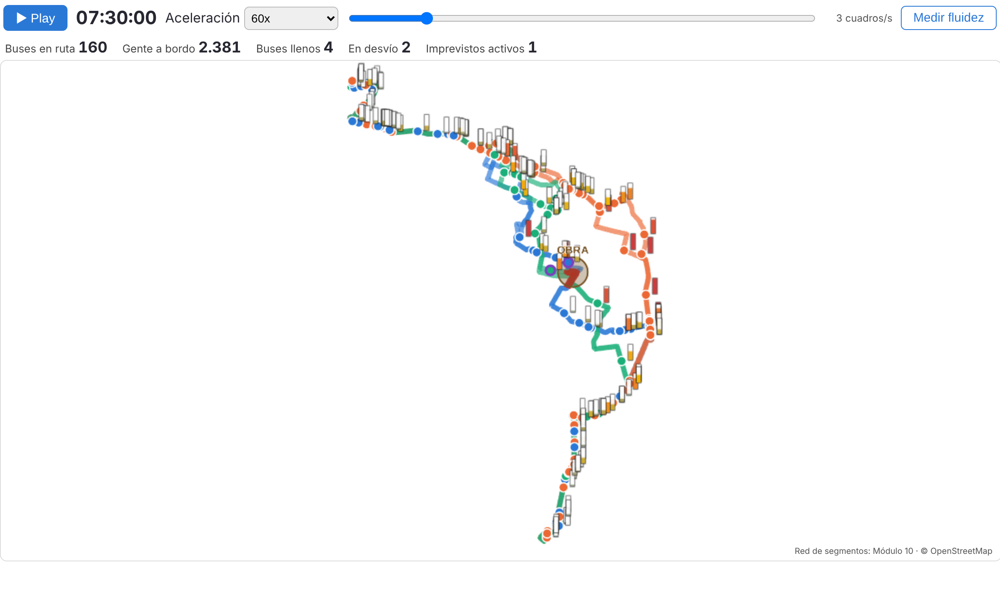

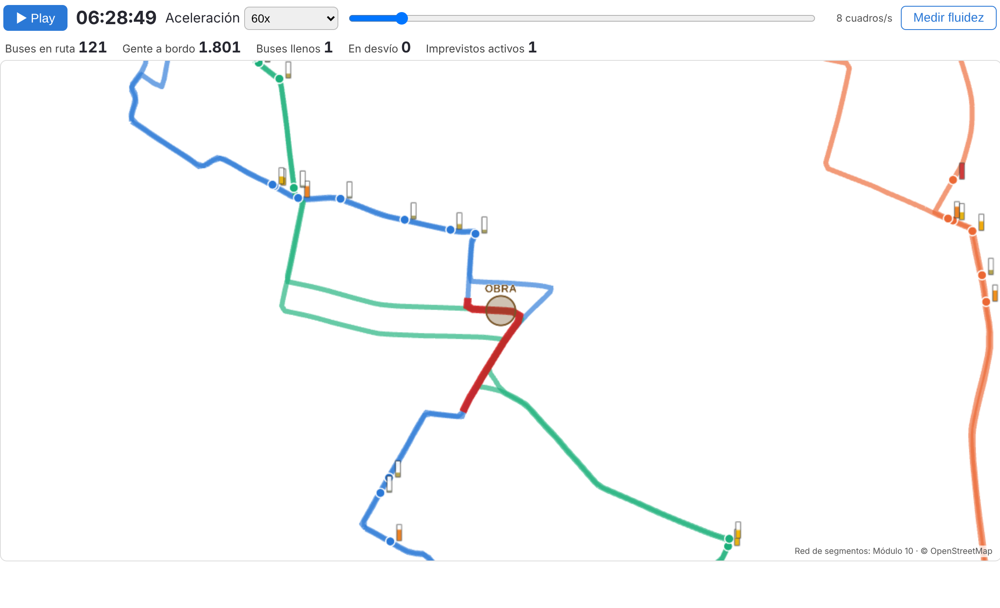

m13_6_pc_comparar.png


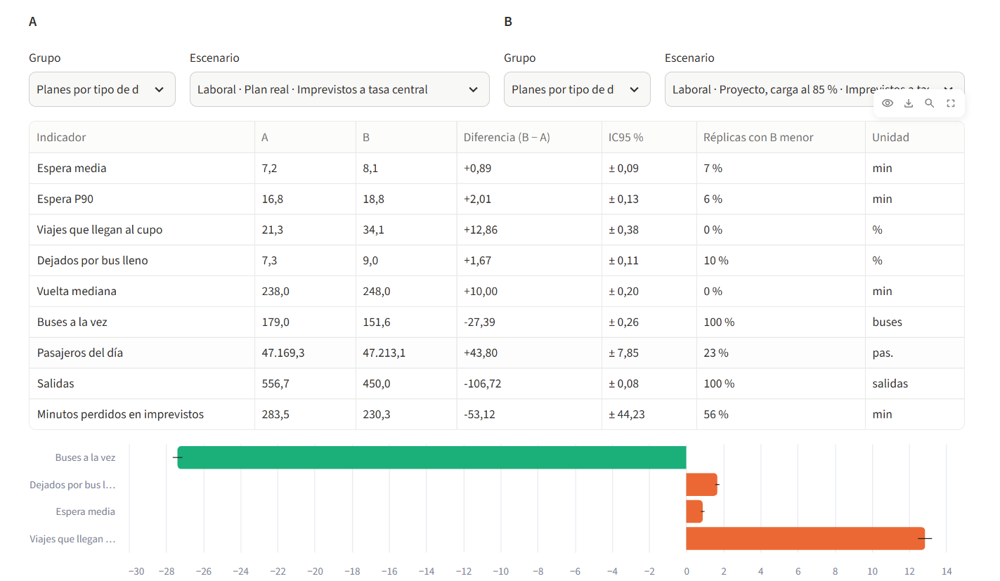

m13_6_pc_fluidez.png


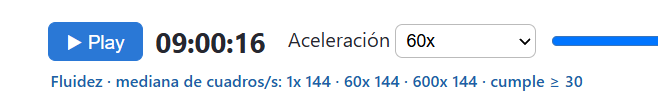

m13_6_pc_probar.png


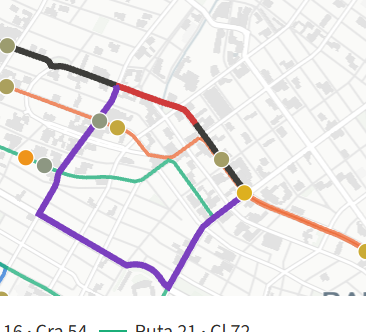

In [5]:
display(Image(str(FIG / "m13_6_animado.png"), width=900))
display(Image(str(FIG / "m13_6_animado_zoom.png"), width=900))
for f in sorted(FIG.glob("m13_6_pc_*.png")):
    print(f.name); display(Image(str(f), width=900))

**Conclusión 2 · El navegador dibuja lo mismo que la 13.5, sobre la vía, a la velocidad pedida**
- **Mismas posiciones que la 13.5** en 3 escenarios (132.011, 84.488 y 67.249 posiciones).
- **En cada minuto exacto,** los buses, la barra de cada uno (gente a bordo ÷ capacidad) y los contadores coinciden con la 13.5. A las 17:30 del laboral con el plan real: 145 buses, 2.636 personas a bordo y 13 buses llenos.
- **Entre un minuto y el siguiente,** el bus avanza sobre la geometría de su ruta: de 424 buses a mitad de minuto, el más lejano queda a 22,7 m del punto más cercano de la vía.
- **El reloj va a la velocidad elegida:** 1x → 0,97x, 60x → 60,00x y 600x → 600,00x. En pausa, el reloj queda quieto.
- **Imprevistos de la réplica representativa:** 196 en 53 de los 54 escenarios, más 85 varadas. Se generaron en el PC, y en los 54 escenarios sus pasos son iguales a los guardados.
  - En el laboral con el plan real hay 7 imprevistos (choques, obras y semáforos), de los que 3 cierran la vía con su tramo en rojo, y 3 varadas.
- **El mapa de fondo es el mismo estilo de CARTO de las otras pantallas** y no pide clave. Dentro de la app carga todas sus teselas, cada una con el «Referer» de la app (`tests_13_6.py` k). Sin el mapa de fondo, la página no pide nada a internet.

## 3 · En el PC: pruebas y fluidez

In [6]:
f = REV / "pruebas_pc_13_6.txt"
print(f.read_text(encoding="utf-8") if f.exists() else "Falta revisiones/pruebas_pc_13_6.txt")
fl = REV / "fluidez_pc_13_6.json"
if fl.exists():
    x = json.loads(fl.read_text(encoding="utf-8"))
    display(pd.DataFrame(x["fases"]).rename(columns={"velocidad": "aceleración (x)", "mediana": "mediana cuadros/s", "minimo": "mínimo", "muestras": "segundos medidos"}))
    print("Buses a la vez en la medición:", x["buses_max"], "· recuadro", x["ancho"], "×", x["alto"], "px ·", x.get("equipo", ""))

Pruebas del Módulo 13 · 2026-11-06T16:24:57
Sistema: Windows 11 · AMD64 · Python 3.12.0
Paquetes: numpy 2.5.2, pandas 3.0.5, scipy 1.18.0, pyarrow 25.0.1, simpy 4.1.1, networkx no instalado, matplotlib 3.11.1, streamlit 1.67.0, pydeck 0.9.3, altair 6.3.0, playwright no instalado

tests_13_1.py    12/12 PASS · 75 s · Python 3.12.0  (1.3 min; se esperaban 12 casos)
tests_13_2.py    12/12 PASS · 18 s · Python 3.12.0  (0.3 min; se esperaban 12 casos)
tests_13_3.py    14/14 PASS · 44 s · Python 3.12.0  (0.8 min; se esperaban 14 casos)
tests_13_4.py    13/13 PASS · 122 s · Python 3.12.0  (2.1 min; se esperaban 13 casos)
tests_13_4b.py   7/7 PASS · 5 s · Python 3.12.0  (0.1 min; se esperaban 7 casos)
tests_13_5.py    11/11 PASS · 304 s · Python 3.12.0  (5.1 min; se esperaban 11 casos)
tests_13_6.py    5/10 PASS · 5 OMITIDA · 14 s · Python 3.12.0  (0.3 min; se esperaban 10 casos)
    c. [OMITIDA] En cada minuto exacto el navegador dibuja los mismos buses, posiciones, barras y contadores que la

,aceleración (x),mediana cuadros/s,mínimo,segundos medidos
0,1,144,None,11
1,60,144,None,11
2,600,144,None,11


Buses a la vez en la medición: 172 · recuadro None × 600 px · PC de la Persona 3 (Windows 11, navegador del sistema)


**Conclusión 3 · Todo corre en el PC, y el mapa animado es fluido**
- **Las 69 pruebas de la 13.1 a la 13.5 pasan en Windows** (Python 3.12, 9,9 min). La primera corrida se cayó al imprimir por la codificación de Windows, sin fallar ningún cálculo; quedó corregido.
- **Una prueba de la 13.4 se ajustó:** la igualdad exacta con la validación solo se exige en Linux, donde se corrió la evaluación (O9 de la 13.4).
- **Fluidez en el navegador del PC:** mediana de 144 cuadros por segundo a 1x, 60x y 600x, con hasta 172 buses a la vez; el plan pide 30.
  - 144 es lo máximo que muestra esa pantalla.
  - En un equipo sin tarjeta de video (el entorno de trabajo de Claude) da 4–5.

## 4 · El paquete del zip

In [7]:
print(correr("paquete_13_6.py"))
print("\n".join(l for l in Path("lista_zip_13_6.txt").read_text(encoding="utf-8").splitlines() if l.startswith("#"))[:2500])
print(correr("revisar_paquete_13_6.py"))

617 archivos, 382,8 MB → lista_zip_13_6.txt

# Zip del Módulo 13 · modo completo · 617 archivos · 382,8 MB sin comprimir
# Por carpeta:
#   datos_13/montecarlo_13_4                     86,0 MB
#   datos_13/montecarlo_13_4b                    85,8 MB
#   datos_13/extraccion                          59,3 MB
#   datos_13/mejoras_13_4b                       45,0 MB
#   datos_13/parametros_v2                       27,2 MB
#   datos_13/parametros                          26,9 MB
#   datos_13/validacion_13_4                     15,4 MB
#   datos_13/simulacion_13_2                     11,6 MB
#   datos_13/simulacion_13_3                      9,8 MB
#   resultados_13                                 7,1 MB
#   (raíz)                                        5,8 MB
#   app                                           2,5 MB
#   src                                           0,2 MB
#   revisiones                                    0,2 MB
#   datos_13/ids_validacion_13_1.csv              0,2 MB
#   datos

617 archivos revisados (444 tablas con sus columnas): 0 hallazgos



**Conclusión 4 · Un zip sin datos sensibles, que se puede volver a armar**
- **Modo completo** (decisión de la Persona 3): 617 archivos y 383,8 MB sin comprimir. Con eso, las pruebas corren desde el zip.
- **Qué no va:** el gemelo, que se regenera en ~1 min con `preparar_gemelo_13_5.py`; `.env`; audios; `__pycache__`.
- **Revisión de datos sensibles:** 0 hallazgos en 617 archivos y 444 tablas (columnas personales, claves, contraseñas, audios).
- **Para instalar:** `requirements.txt` con versiones mínimas.
- **Para usarlo:** el LEEME tiene el orden de ejecución completo y lo que tarda cada paso.

## 5 · Informe y nota para el Módulo 14

In [8]:
print(correr("verificar_informe_13_6.py"))
v = pd.read_csv(REV / "verificar_informe_13_6.csv")
display(v.groupby(["tipo", "archivo"]).ok.agg(["sum", "size"]))

75/75 cifras verificadas (55 recalculadas, 20 trazadas) → verificar_informe_13_6.csv



sum  size
tipo archivo                       
R    datos                  1     1
     informe               22    22
     nota                  31    31
     pruebas_pc_13_6.txt    1     1
T    informe               20    20

**Conclusión 5 · El informe y la nota dicen lo mismo que los datos**
- **`INFORME_modulo13.md`** (2–3 páginas para el informe final) y **`NOTA_PARA_MODULO_14.md`**: 75 de 75 cifras verificadas.
  - 55 se recalculan de los datos guardados, después de comprobar el sha256 de las 109 salidas del Monte Carlo final.
  - 20 se trazan a las conclusiones ya verificadas de cada subfase.
- **La nota para el Módulo 14 explica:**
  - qué archivos usar y qué significa cada indicador;
  - cómo comparar dos planes réplica a réplica;
  - que la espera sirve para comparar, no como nivel;
  - lo que el simulador no hace: no elige el plan y no tiene una entrada para un plan propio.
- **El verificador ya sirvió:** encontró un redondeo mal hecho en la nota (sábado al 70 %: −16,5 buses, no −16,6), y se corrigió.

## Síntesis · Subfase 13.6
- **El Módulo 13 queda listo para entregar.** Se comparó con el plan completo y se cerraron las cinco brechas que la 13.5 había pasado por alto.
- **El gemelo hace lo que pide el plan:** mapa animado fluido (144 cuadros por segundo) con aceleración de 1x a 60x, barras de capacidad, contadores, e imprevistos y desvíos en el mapa. Se abre con `py -m streamlit run app/gemelo_digital.py`.
- **Todo corre en el PC:** 69 de 69 pruebas en Windows.
- **El paquete no lleva datos sensibles:** 0 hallazgos.
- **Las cifras del informe y de la nota están verificadas:** 75 de 75.
- **Lo que no cambia:** la validación sigue en 3 de 6 días, con el sesgo de la mañana laboral para después del Entregable 3. Las comparaciones entre planes son lo más sólido del módulo y son lo que recibe el Módulo 14.
- **El zip completo se arma en el PC:** `py paquete_13_6.py --zip ..\modulo13.zip` y luego `py revisar_paquete_13_6.py`.

<a id="e2c-7"></a>

---

## A2.6 &middot; e2c.6 · Simulador del Módulo 13 alimentado por el pronóstico

**Qué recibe del pronóstico.** ŷ(i,t) directamente, como llegadas del motor del Módulo 13 (opción `ajustes['demanda_e2c']`, inactiva por defecto), en 6 días nuevos de 2025 congelados antes de simular. Es la prueba del pronóstico dentro de la operación: 3 de 6 días (el criterio pedía 5).

<sub>Notebook original: `subfase_e2c_6_simulador.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# Subfase e2c.6 · Simulador del Módulo 13 alimentado por el pronóstico e2c

El motor del Módulo 13 consume ŷ_{i,t} (opción `ajustes['demanda_e2c']`, inactiva por defecto) y se valida con el criterio de la 13.4 (MAE de la carga a bordo ≤ perfil histórico en ≥ 5 de 6 días) en 6 días NUEVOS del holdout, congelados antes de simular. La evaluación única (19-nov, 10:21–12:18, PC de la Persona 3) y la «no ciega» y el Monte Carlo (19-nov, PC del Integrante 1) no se repiten aquí.

**Notebook de presentación (e2c.7).** Lee las salidas ya guardadas del módulo; no consulta la base, no reentrena ni vuelve a evaluar el holdout o los días de validación (esas corridas se hicieron una sola vez, con registro y hora). Las cifras de las conclusiones vienen de `datos_e2c/estado_e2c.md`, verificadas contra sus CSV al cerrar cada módulo.

In [1]:
%matplotlib inline
import json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
D = Path('datos_e2c')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 90)

def tabla(p, n=None, **kw):
    t = pd.read_csv(D / p, **kw)
    display(t if n is None else t.head(n))
    return t

def fig(p, w=900):
    display(Image(filename=str(D / p), width=w))

def h_json(d):
    return hashlib.sha256(json.dumps(d, ensure_ascii=False, sort_keys=True).encode('utf-8')).hexdigest()

def verificar_regla(p, clave=None):
    """Recalcula el hash de contenido de una regla congelada (sin la clave del hash ni `creado`)."""
    r = json.loads((D / p).read_text(encoding='utf-8'))
    clave = clave or next((k for k in ('sha256_regla', 'sha256_decision', 'sha256') if k in r), None)
    if clave is None:                                    # reglas cuyo hash solo está en el manifiesto
        man = json.loads((D / 'manifiesto_e2c.json').read_text(encoding='utf-8'))['reglas']
        h, ref = h_json(r), man[Path(p).name]
    else:
        h, ref = h_json({k: v for k, v in r.items() if k not in (clave, 'creado')}), r[clave]
    print(f"{p}: {'OK' if h == ref else 'NO COINCIDE'} · {ref[:12]}…")
    return r

def checks(n):
    c = pd.read_csv(D / f'checks/checks_e2c_{n}.csv')
    display(c)
    print(c.iloc[:, [i for i, x in enumerate(c.columns) if x.lower() in ('estado', 'resultado')][0]].value_counts().to_dict())

## e2c.6.1 · Días nuevos congelados y e2c.6.5 · configuración (hash) y PC3

In [2]:
dv = verificar_regla('simulador/dias_validacion_e2c.json')
display(pd.DataFrame(dv['dias']))
cfg = verificar_regla('simulador/config_e2c_6.json')
print('PC3:', json.loads((D / 'simulador/confirmacion_pc3_e2c.json').read_text(encoding='utf-8')))

simulador/dias_validacion_e2c.json: OK · 8ad46c4d4349…


,rol,fecha,bloque,tipo_dia,dia_semana,evento,lluvia_4_21_mm,desv_suma_salidas,viajes_en_muestra_m1,viajes_e3_13_4b
0,laboral_1,2025-03-12,H1,laboral,2,None,0.27,0.0444,1,4
1,laboral_2,2025-11-27,H4,laboral,3,None,0.00,0.0645,1,5
2,sabado,2025-11-22,H4,sabado,5,None,0.87,0.0928,0,45
3,domingo,2025-11-23,H4,domingo,6,None,0.00,0.1153,0,34
4,lluvia_fuerte,2025-09-05,H3,laboral,4,None,22.03,0.2025,4,8
5,evento_masivo,2025-09-04,H3,laboral,3,Colombia vs Bolivia (Eliminatoria Mundial 2026),2.67,0.3946,1,10


simulador/config_e2c_6.json: OK · c2fb7e74877d…
PC3: {'punto_de_control': 'PC3 (e2c.6, antes de la validación del simulador)', 'fecha_hora': '2026-11-19T10:03:00-05:00', 'persona': 'Persona 3', 'decision': 'Opción A: correr la validación del e2c.6 tal cual, con las tres demandas (e2c, e1c y real observada), sin modificar el simulador ni los días de validación', 'texto': 'CONFIRMACIÓN DE PC3: EJECUTAR VALIDACIÓN TAL CUAL CON TRES DEMANDAS (OPCIÓN A). Decisión: Confirmada la Opción A (lanzar la validación e2c.6 con las tres demandas: e2c, e1c y la real observada, sin modificar el simulador ni los días de validación). Justificación: 1. Respeta el protocolo de evaluación ciego congelado, evitando el sesgo de adaptación a posteriori (hindsight bias) y la fuga de datos (data leakage). 2. Utiliza la demanda real observada como cota de control experimental para aislar si los posibles cuellos de botella en la hora pico (6:00 a 9:00 AM) se deben a un sesgo del modelo predictivo o a una limitació

## e2c.6.3 · No regresión (opción inactiva = motor de la 13.4/13.4b)

In [3]:
print(json.dumps(json.loads((D / 'simulador/no_regresion_e2c_6.json').read_text(encoding='utf-8')), ensure_ascii=False, indent=1)[:2000])

{
 "a_antes_vs_ahora": {
  "casos": 9,
  "iguales": 9,
  "ok": true
 },
 "b_montecarlo_13_4b": {
  "escenarios": [
   {
    "escenario": "real_laboral_central",
    "replicas": 4,
    "igual": true
   },
   {
    "escenario": "p85_sabado_central",
    "replicas": 4,
    "igual": true
   },
   {
    "escenario": "real_domingo_central",
    "replicas": 4,
    "igual": true
   }
  ],
  "ok": true
 },
 "c_validacion_13_4_linux": {
  "sistema": "Windows",
  "dias": [
   {
    "rol": "laboral_1",
    "igual": true
   },
   {
    "rol": "evento_masivo",
    "igual": false
   }
  ],
  "nota": "la 13.4 se evaluó en Linux; en Windows la igualdad exacta no se exige (O9)"
 },
 "ok": true,
 "plataforma": "Windows-11-10.0.26200-SP0"
}


## e2c.6.4 · Ensayo en los días de control (control, NO validación)

mae_hist       mae_tiempo      
entrada              e1c   e2c        e1c   e2c
rol                                            
control_domingo     4.34  4.34       2.93  2.78
control_laboral     4.07  4.07       4.92  5.25
control_sabado      4.86  4.86       3.90  3.81

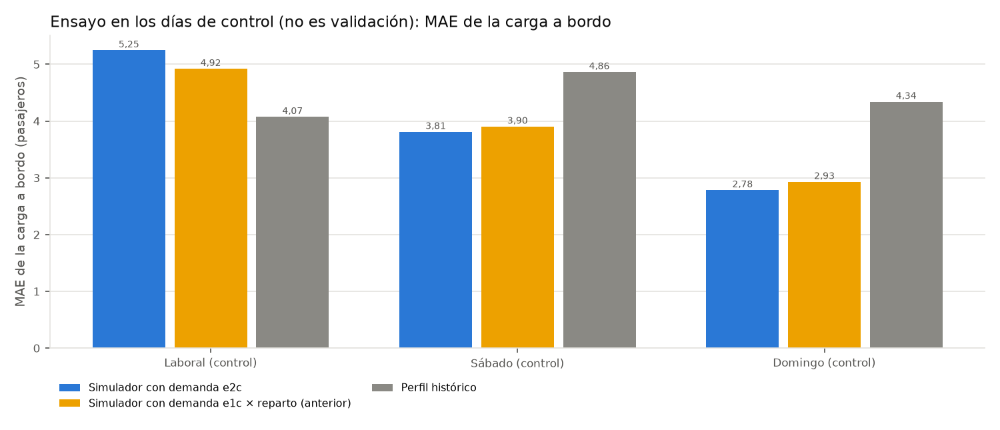

In [4]:
e = pd.read_csv(D / 'simulador/ensayo_control_mae_e2c_6.csv')
display(e[(e.idruta == 'total') & (e.ubicacion == 'corregida')].pivot_table(index='rol', columns='entrada', values=['mae_tiempo', 'mae_hist']).round(2))
fig('simulador/figuras/mae_ensayo_control_e2c_6.png')

## e2c.6.6 · Evaluación única en los 6 días nuevos

{'inicio': '2026-11-19T10:21:22', 'fin': '2026-11-19T12:18:38', 'criterio_principal': {'medida': 'e2c_corregida_tiempo', 'dias': 3, 'de': 6, 'cumple': False}, 'oficial_13_4': '3 de 6 (no cambia)'}


,,e1c,e2c,real_obs,perfil
rol,fecha,,,,
domingo,2025-11-23,2.82,2.39,2.25,4.26
evento_masivo,2025-09-04,4.77,5.56,4.96,4.40
laboral_1,2025-03-12,4.69,4.73,5.10,3.86
laboral_2,2025-11-27,3.43,3.59,3.70,3.66
lluvia_fuerte,2025-09-05,4.25,4.46,4.79,3.88
sabado,2025-11-22,3.64,3.49,3.51,4.64


{'e2c': 3, 'e1c': 3, 'real_obs': 2} días de 6 con MAE ≤ perfil


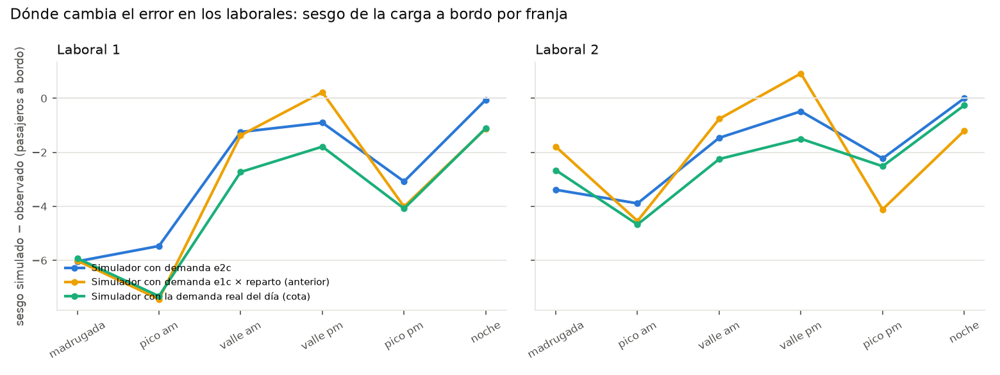

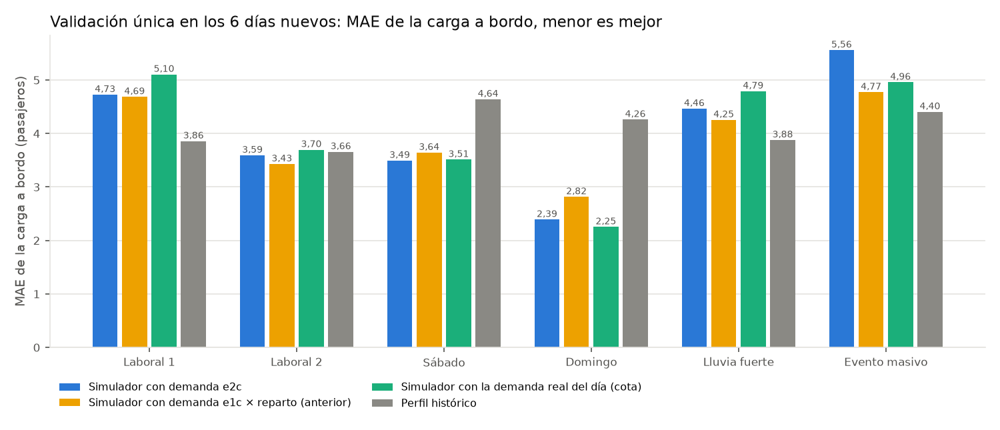

In [5]:
reg = json.loads((D / 'simulador/registro_evaluacion_e2c_6.json').read_text(encoding='utf-8'))
print({k: reg[k] for k in ('inicio', 'fin', 'criterio_principal', 'oficial_13_4')})
m = pd.read_csv(D / 'simulador/mae_validacion_e2c_6.csv')
t = m[(m.idruta == 'total') & (m.ubicacion == 'corregida')]
tab = t.pivot_table(index=['rol', 'fecha'], columns='entrada', values='mae_tiempo').join(
      t[t.entrada == 'e2c'].set_index(['rol', 'fecha']).mae_hist.rename('perfil'))
display(tab.round(2))
print({e: int((tab[e] <= tab.perfil).sum()) for e in ('e2c', 'e1c', 'real_obs')}, 'días de 6 con MAE ≤ perfil')
for f in sorted((D / 'simulador/figuras').glob('*validacion*.png')): fig(str(f.relative_to(D)))

## Error por franja y secundarias (vuelta, pasajeros por viaje, cupo, intervalos)

In [6]:
fr = pd.read_csv(D / 'simulador/error_franja_validacion_e2c_6.csv')
display(fr[fr.ubicacion == 'corregida'].pivot_table(index='franja', columns='entrada', values=['mae_tiempo', 'sesgo_tiempo']).round(2))
s = pd.read_csv(D / 'simulador/secundarias_validacion_e2c_6.csv')
display(s.head(12))

mae_tiempo                sesgo_tiempo               
entrada          e1c   e2c real_obs          e1c   e2c real_obs
franja                                                         
madrugada       5.23  7.50     8.06        -2.36 -3.18    -3.50
noche           3.47  3.44     2.97        -0.78  0.04    -1.22
pico_am         6.59  8.52     9.01        -5.10 -3.76    -5.07
pico_pm         4.22  3.80     3.65        -2.71 -1.18    -2.31
valle_am        3.49  3.37     3.53        -0.71 -1.25    -2.19
valle_pm        3.34  3.01     3.03        -0.18 -0.86    -1.70

,idruta,salidas,vuelta_mediana_min,vuelta_p90_min,pasajeros_por_viaje,pct_viajes_cupo,cv_intervalos,pct_intervalos_menos_1min,salidas_real,vuelta_mediana_real,pasajeros_por_viaje_real,pct_viajes_cupo_real,cv_intervalos_real,pct_intervalos_menos_1min_real,viajes_gps_mitad,err_vuelta_pct,err_pasajeros_pct,rol,fecha,entrada
0,16,302.518,237.010326,276.184246,93.089634,31.629329,1.270222,21.689905,303,234.550000,91.939068,26.351351,0.905518,21.259843,255,1.048956,1.251444,laboral_1,2025-03-12,e2c
1,2,158.858,254.881871,301.785981,89.974741,27.649474,1.106785,15.123157,159,258.900000,89.609023,25.316456,0.796607,5.357143,113,-1.552000,0.408126,laboral_1,2025-03-12,e2c
2,21,98.000,243.606996,292.911795,94.483408,33.961224,1.083949,10.151096,98,245.500000,98.590361,21.505376,0.635854,2.985075,68,-0.771081,-4.165674,laboral_1,2025-03-12,e2c
3,16,302.274,238.090659,278.863267,95.653163,29.845712,1.279092,22.284336,303,234.550000,91.939068,26.351351,0.905518,21.259843,255,1.509554,4.039735,laboral_1,2025-03-12,e1c
4,2,158.844,254.484820,302.738105,90.695050,24.540074,1.105669,15.475740,159,258.900000,89.609023,25.316456,0.796607,5.357143,113,-1.705361,1.211962,laboral_1,2025-03-12,e1c
5,21,98.000,242.176660,293.707960,96.544490,30.789796,1.086258,10.381326,98,245.500000,98.590361,21.505376,0.635854,2.985075,68,-1.353703,-2.075123,laboral_1,2025-03-12,e1c
6,16,302.498,234.544540,273.770613,87.685945,28.979902,1.248303,21.319630,303,234.550000,91.939068,26.351351,0.905518,21.259843,255,-0.002328,-4.626024,laboral_1,2025-03-12,real_obs
7,2,158.902,252.385294,298.357738,82.568560,23.344646,1.089361,14.495878,159,258.900000,89.609023,25.316456,0.796607,5.357143,113,-2.516302,-7.856868,laboral_1,2025-03-12,real_obs
8,21,98.000,238.408869,288.964547,83.436571,26.014286,1.075910,9.957354,98,245.500000,98.590361,21.505376,0.635854,2.985075,68,-2.888444,-15.370458,laboral_1,2025-03-12,real_obs
9,16,300.926,231.080149,270.796404,81.350882,23.392887,1.162306,20.296358,301,238.100000,80.476868,13.087248,0.926410,25.196850,255,-2.948279,1.086043,laboral_2,2025-11-27,e2c


## e2c.6.7 · Días de la 13.1 («NO CIEGA»: ya se vieron en la 13.4 y la 13.4b)

{'inicio': '2026-11-19T17:15:38', 'fin': '2026-11-19T17:49:02', 'dias_no_peor_que_hist': {'e2c_corregida_tiempo': 3, 'e1c_corregida_tiempo': 3, 'real_obs_corregida_tiempo': 3, 'e2c_corregida_paso': 3, 'e1c_corregida_paso': 3, 'real_obs_corregida_paso': 3, 'e2c_m10_tiempo': 3, 'e1c_m10_tiempo': 3, 'real_obs_m10_tiempo': 3, 'e2c_m10_paso': 3, 'e1c_m10_paso': 3, 'real_obs_m10_paso': 3}, 'oficial_13_4': 3}


,,e1c,e2c,real_obs,perfil
rol,fecha,,,,
domingo,2025-07-27,2.82,2.38,2.43,4.51
evento_masivo,2025-03-25,5.51,5.48,5.37,4.70
laboral_1,2025-11-25,4.19,3.98,4.13,3.90
laboral_2,2025-04-03,4.58,4.76,4.96,3.68
lluvia_fuerte,2025-06-13,3.61,3.61,3.64,3.88
sabado,2025-02-15,3.68,3.67,3.79,4.58


{'e2c': 3, 'e1c': 3, 'real_obs': 3}


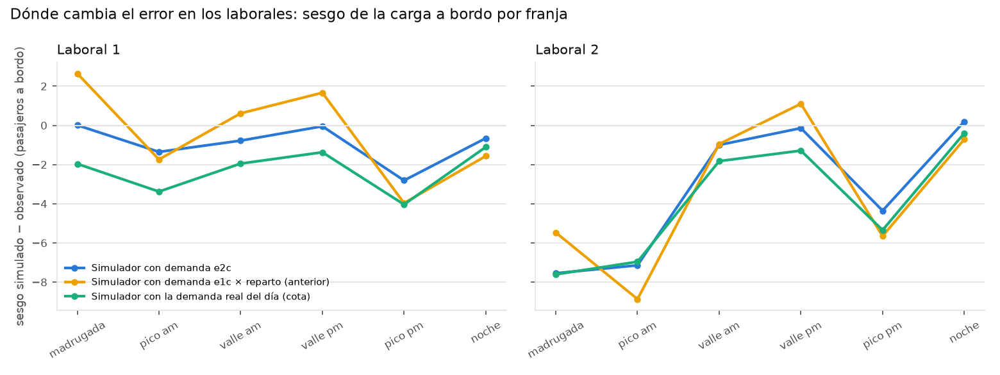

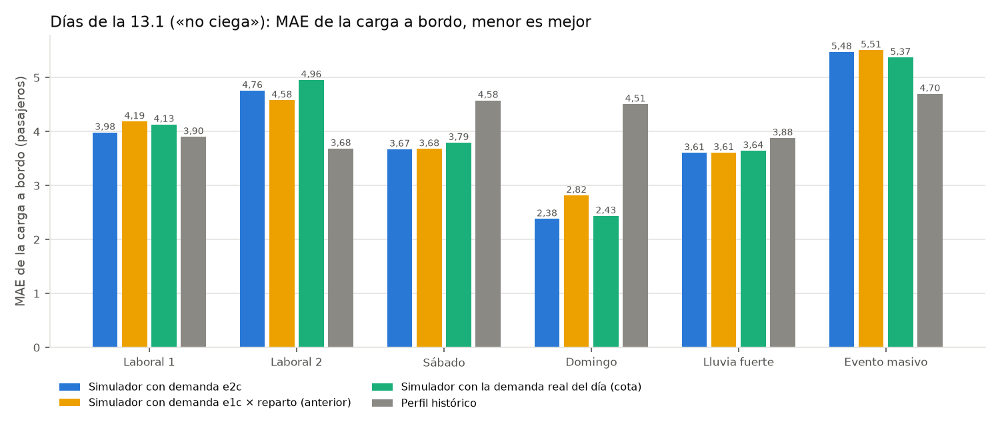

In [7]:
f = D / 'simulador/registro_no_ciega_e2c_6.json'
if f.exists():
    r = json.loads(f.read_text(encoding='utf-8')); print({k: r[k] for k in ('inicio', 'fin', 'dias_no_peor_que_hist', 'oficial_13_4')})
    m2 = pd.read_csv(D / 'simulador/mae_no_ciega_e2c_6.csv'); t2 = m2[(m2.idruta == 'total') & (m2.ubicacion == 'corregida')]
    tab2 = t2.pivot_table(index=['rol', 'fecha'], columns='entrada', values='mae_tiempo').join(
           t2[t2.entrada == 'e2c'].set_index(['rol', 'fecha']).mae_hist.rename('perfil'))
    display(tab2.round(2)); print({e: int((tab2[e] <= tab2.perfil).sum()) for e in ('e2c', 'e1c', 'real_obs')})
    for g in sorted((D / 'simulador/figuras').glob('*no_ciega*.png')): fig(str(g.relative_to(D)))
else:
    print('La corrida «no ciega» no está.')

## e2c.6.9 · Monte Carlo de los escenarios centrales con la entrada e2c

,idruta,indicador,media,p5,mediana,p95,ic95_semi,ic95_semi_rel,replicas,escenario,entrada
0,16,salidas,296.898000,296.950000,297.000000,297.000000,0.046062,0.000155,500,real_laboral_central,e2c
1,16,pasajeros,28357.718000,23691.800000,28388.500000,33175.500000,253.420344,0.008937,500,real_laboral_central,e2c
2,16,espera_media_min,7.494217,6.135023,7.241037,9.837805,0.102171,0.013633,500,real_laboral_central,e2c
3,16,espera_p90_min,15.913927,12.027562,15.223932,22.024455,0.281697,0.017701,500,real_laboral_central,e2c
4,16,pct_dejados_bus_lleno,12.831465,7.592993,12.705481,18.207530,0.290649,0.022651,500,real_laboral_central,e2c
...,...,...,...,...,...,...,...,...,...,...,...
1435,total,buses_a_la_vez,64.918000,62.000000,65.000000,67.000000,0.147220,0.002268,500,p70_domingo_central,e1c_13_4b
1436,total,buses_usados,68.000000,68.000000,68.000000,68.000000,0.000000,0.000000,500,p70_domingo_central,e1c_13_4b
1437,total,salidas_sin_bus,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,500,p70_domingo_central,e1c_13_4b
1438,total,minutos_imprevistos,90.121316,0.000000,41.755904,377.048993,12.414379,0.137752,500,p70_domingo_central,e1c_13_4b


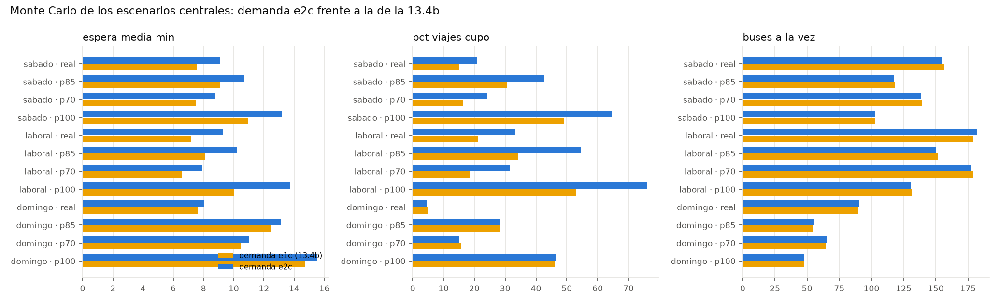

In [8]:
f = D / 'simulador/montecarlo_resumen_e2c_6.csv'
display(pd.read_csv(f)) if f.exists() else print('El Monte Carlo no está.')
for g in sorted((D / 'simulador/figuras').glob('*montecarlo*.png')): fig(str(g.relative_to(D)))

## e2c.6.10 · Conexión con el Módulo 14 (MILP con ŷ; demostración 14.4)

In [9]:
display(Markdown((D / 'simulador/m14/NOTA_M14_e2c_6.md').read_text(encoding='utf-8')))
for f in sorted((D / 'simulador/m14').glob('*.csv')): tabla(str(f.relative_to(D)))

# e2c.6.10 · Cómo consume el Módulo 14 la demanda pronosticada

**Qué hace hoy el MILP (sin cambios en `modulo14/`).**
- `RedispatchPipeline.red(tipo)` y `scenario_evaluator` arman `rp = escenario.construir_rutas(P, tipo, "pred")`. Es la λ por segmento × hora del **día típico** del tipo de día: el pronóstico e1c 04:00 × el reparto de la 13.1, sin el factor del día.
- `acople_m13.entradas_dia` convierte esa λ en dos demandas por ventana de 15 min:
  - **d**, la de las celdas cautivas (segmentos sin otra ruta);
  - **q**, la de los tramos compartidos.
- `acople_m13.eta_por_hora` calcula con ella la fracción η de cada tramo.
- **Anti-leakage:** la «verdad» de cada réplica (el factor del día, la demanda del evento) nunca entra al MILP.

**Cómo entra el e2c.** Basta reemplazar `R.lam` de esas mismas rutas por ŷ del día y volver a calcular η. Se usa el mismo adaptador del simulador, `modulo13/src/simulation/demanda_e2c.aplicar`. Como el nodo del e2c es el segmento de 500 m del motor, no hay que convertir nada.
- Ni el YAML ni el código de `modulo14/src` cambian, así que la huella de la 14.3 sigue igual (`b16973cb1db3b0a6…`).
- Diferencia de fondo: el MILP pasa de «el laboral típico» a «el pronóstico de esta fecha emitido a las 04:00», que es lo que tendría el jefe de despacho en producción.

**Re-ejecución barata** (`modulo14_e2c_6.py`, en la raíz del proyecto). Corre la demostración de la 14.4 (arroyo de la calle 85, ruta 2, gravedad 5) dos veces por caso, con la demanda actual y con la del e2c:
- 2025-02-27 a las 07:00 (la demostración de la 14.4);
- 2025-03-12 a las 07:00 (laboral_1 de la validación e2c.6).

Guarda en `datos_e2c/simulador/m14/m14_e2c_6.json` / `.csv` la demanda d y q de la hora, las órdenes de permutación, las retenciones en La Playa y el ahorro estimado. **No rehace la evaluación de 2.500 pares de la 14.3:** sus cifras siguen siendo las oficiales y están hechas con la demanda e1c del día típico.

**Resultados:** ver la sección e2c.6 de `estado_e2c.md` (se completan al correr `correr_e2c_6_cierre.bat`).


,fecha,hora,tipo,entrada,d_cautivos_hora,q_compartidos_hora,buses_permutados,alertas,segundos,n_ordenes,n_retenciones
0,2025-02-27,07:00,laboral,actual_e1c,1821.52,2294.67,11.0,8,20.2,7,3
1,2025-02-27,07:00,laboral,e2c,1547.39,2189.56,15.0,8,18.7,10,4
2,2025-03-12,07:00,laboral,actual_e1c,1821.52,2294.67,9.0,8,15.8,6,4
3,2025-03-12,07:00,laboral,e2c,1490.98,2266.00,14.0,8,19.6,7,6


## Pruebas y checks

In [10]:
tabla('simulador/tests_e2c_6.csv')
checks(6)

,prueba,estado,detalle
0,a · días nuevos congelados antes de la configuración,PASS,"laboral_1 2025-03-12, laboral_2 2025-11-27, sabado 2025-11-22, domingo 2025-11-23, llu..."
1,b · configuración congelada sin cambios,PASS,"c2fb7e74877d…, creada 2026-11-19T09:24:48"
2,c · no regresión con la opción inactiva,PASS,antes = ahora 9/9; Monte Carlo 13.4b 3/3 escenarios × 4 réplicas idénticos; validación...
3,d · las llegadas de la entrada nueva suman ŷ por día y ruta,PASS,9 días × 3 rutas; error relativo máx. 2.2e-16
4,e · perfil histórico M10 = el de la 13.4,PASS,1432 viajes; 3 sacados por ser de los días nuevos; 2.16 % de las lecturas con la salid...
5,f · el adaptador solo actúa con la clave demanda_e2c,PASS,escenario.correr: bloque condicionado; con factores_demanda se rechaza
6,"g · una sola evaluación, después de la configuración y de PC3",PASS,registro 2026-11-19T10:21:22 → 2026-11-19T12:18:38; criterio 3/6; un segundo --evaluar...


,check,descripcion,estado,detalle
0,Ta,días nuevos congelados antes de la configuración,PASS,"laboral_1 2025-03-12, laboral_2 2025-11-27, sabado 2025-11-22, domingo 2025-11-23, llu..."
1,Tb,configuración congelada sin cambios,PASS,"c2fb7e74877d…, creada 2026-11-19T09:24:48"
2,Tc,no regresión con la opción inactiva,PASS,antes = ahora 9/9; Monte Carlo 13.4b 3/3 escenarios × 4 réplicas idénticos; validación...
3,Td,las llegadas de la entrada nueva suman ŷ por día y ruta,PASS,9 días × 3 rutas; error relativo máx. 2.2e-16
4,Te,perfil histórico M10 = el de la 13.4,PASS,1432 viajes; 3 sacados por ser de los días nuevos; 2.16 % de las lecturas con la salid...
5,Tf,el adaptador solo actúa con la clave demanda_e2c,PASS,escenario.correr: bloque condicionado; con factores_demanda se rechaza
6,Tg,"una sola evaluación, después de la configuración y de PC3",PASS,registro 2026-11-19T10:21:22 → 2026-11-19T12:18:38; criterio 3/6; un segundo --evaluar...
7,N1,No regresión réplica a réplica con la opción inactiva,PASS,antes = ahora 9/9; Monte Carlo 13.4b 3/3 escenarios idénticos
8,H1,Hash de los días y de la configuración registrado antes de la evaluación (y PC3 confir...,PASS,días 8ad46c4d4349… (2026-11-19T08:42:03) → configuración c2fb7e74877d… (2026-11-19T09:...
9,E1,La evaluación se corrió una vez,PASS,registro_evaluacion_e2c_6.json (2026-11-19T10:21:22 → 2026-11-19T12:18:38); el script ...


{'PASS': 10, 'INFO': 7, 'FAIL': 1}


**Conclusión e2c.6 · Con el pronóstico e2c como entrada, el simulador le gana al perfil histórico en 3 de 6 días nuevos (el criterio pedía 5): NO se cumple. Con la entrada anterior (e1c × reparto) también son 3 y con la demanda real del día 2, así que la falla que queda es del motor (bajadas con el reparto fijo de la 13.1), no del pronóstico. En los días de la 13.1 («no ciega») son 3 de 6 con las tres demandas, igual que el oficial de la 13.4, y la entrada e2c tiene menor MAE que la e1c en 5 de 6 días.**

<a id="m14"></a>

---

## A2.7 &middot; Módulo 14 · Redespacho dinámico de flota (MILP)

**Qué recibe del pronóstico.** El MILP toma la λ por segmento × hora para la demanda de las celdas cautivas y de los tramos compartidos por ventana de 15 min; con el e2c se reemplaza por ŷ del día emitido a las 04:00, sin tocar el YAML ni el código (huella de la 14.3 intacta).

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m14-1"></a>

### A2.7.1 &middot; Módulo 14 · Redespacho dinámico de flota

<sub>Notebook original: `modulo14/modulo_14_redespacho.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 14 — Redespacho dinámico de flota (MILP) en cabecera y La Playa

Notebook de ejecución del Módulo 14 (Entregable 2). Corre, sin internet ni APIs: la verificación de insumos, la demostración del pipeline 14.4 (arroyo de la calle 85, ruta 2), el reporte de la evaluación 14.3 a partir de sus 2.500 pares simulados (la corrida completa tarda horas y se hizo el 8-nov-2026, su salida está en `data/outputs/`) y las 39 pruebas del módulo. Documentación: `LEEME_modulo14.md` e `INFORME_modulo14.md`.

In [1]:
%matplotlib inline
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display, Markdown
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
OUT = Path("data/outputs")

import os, subprocess, sys
def correr(*args, timeout=1800, ultimas=None):
    """Ejecuta un script del módulo con el mismo Python del notebook y muestra su salida."""
    env = {**os.environ, "PYTHONUTF8": "1", "PYTHONIOENCODING": "utf-8"}
    r = subprocess.run([sys.executable, *args], capture_output=True, text=True, encoding="utf-8", errors="replace",
                       env=env, timeout=timeout)
    salida = (r.stdout + ("\n" + r.stderr if r.returncode else "")).rstrip().splitlines()
    print("\n".join(salida if ultimas is None else salida[-ultimas:]))
    print(f"\n[código de salida {r.returncode}]")
    return r.returncode

## 1 · Verificación de los insumos de los Módulos 10–13 (sha256)

In [2]:
correr("verificar_insumos_14_3.py", ultimas=30)

Python 3.12.0 · C:\Users\<usuario>\AppData\Local\Programs\Python\Python312\python.exe
  numpy     2.5.3
  pandas    2.3.3
  scipy     1.18.1
  pyarrow   25.0.1
  pydantic  2.14.3
  yaml      6.0.3
  simpy     4.1.1
  pulp      3.3.2
  psutil    7.2.2
  CBC resuelve un MILP de prueba: OK
Insumos: 49/49 presentes e idénticos al original
Memoria libre: 8.3 GB → caben 5 procesos · núcleos: 12
AVISO: la carpeta está en una nube sincronizada: muévala a una carpeta local (más rápido y estable)
TODO LISTO

[código de salida 0]


0

## 2 · Formulación (14.1): parámetros principales del MILP

In [3]:
cfg = yaml.safe_load(open("config/milp_config.yaml", encoding="utf-8"))
print("Secciones de milp_config.yaml:", list(cfg))
for k in ("solver", "horizonte", "redespacho", "zona_intermedia", "reglas", "pesos"):
    if k in cfg:
        print(f"\n[{k}]"); print(yaml.safe_dump(cfg[k], allow_unicode=True, sort_keys=False)[:900])

Secciones de milp_config.yaml: ['version', 'subfase', 'tiempo', 'franjas', 'multiplicador_headway_tipo_dia', 'headway_max_absoluto_min', 'rutas', 'cabeceras', 'zona_intermedia', 'permutacion', 'tramos', 'demanda', 'tiempos_ciclo', 'flota', 'objetivo', 'antileakage', 'arrastre', 'tramos_cerrados', 'factibilidad', 'redespacho', 'solver']

[solver]
nombre: PULP_CBC_CMD
tiempo_limite_s: 10
margen_s: 1.0
gap_relativo: 0.01
hilos: 1
msg: false


[redespacho]
salidas_totales: igual_plan


[zona_intermedia]
activa: true
id: la_playa
nombre: La Playa
descripcion: Punto lejano común de las rutas 2, 16 y 21 en el barrio La Playa (zona
  de redespacho intermedia)
primer_segmento_regreso:
  2: 68
  16: 62
  21: 64
segmentos_por_ruta:
  2: 135
  16: 123
  21: 128
desfase_id_regreso: 1000
descanso_llegada_min: 0.0
espera_max_min: 10.0
capacidad_espera: 4
costo_retener_bus_cop_ventana: 5000
pares:
- desde: 2
  hacia: 16
  max_por_horizonte: 5
  max_por_dia: 15
- desde: 2
  hacia: 21
  max_por_horizont

## 3 · Pipeline 14.4: redespacho para un instante (demo: arroyo de la calle 85, ruta 2)

In [4]:
correr("-m", "src.pipelines.redispatch_pipeline", "--fecha", "2025-02-27", "--hora", "07:00", "--demo", "--exportar", ultimas=40)
p = OUT / "pipeline_14_4"
res = json.load(open(p / "pipeline_2025-02-27_0700_resumen.json", encoding="utf-8"))
print(json.dumps(res, ensure_ascii=False, indent=1)[:3000])
display(pd.read_csv(p / "pipeline_2025-02-27_0700_ordenes.csv"))
display(pd.read_csv(p / "pipeline_2025-02-27_0700_alertas.csv"))

2025-02-27 07:00 · 1 evento(s) · 2 desvío(s) · 16.5 s
                                                                  accion
 Ruta 2 -> Ruta 16 | Buses a mover: 2 | Cabecera: La Playa | Hora: 07:00
Ruta 21 -> Ruta 16 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:00
 Ruta 2 -> Ruta 21 | Buses a mover: 2 | Cabecera: terminal | Hora: 07:15
 Ruta 2 -> Ruta 16 | Buses a mover: 3 | Cabecera: La Playa | Hora: 07:15
 Ruta 16 -> Ruta 2 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:30
 Ruta 21 -> Ruta 2 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:30
 Ruta 2 -> Ruta 21 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:45
                                                                        accion
Ruta 16 | Retener: 2 bus(es) | Cabecera: La Playa | Hasta: 07:15 | Hora: 07:00
Ruta 21 | Retener: 2 bus(es) | Cabecera: La Playa | Hasta: 07:15 | Hora: 07:00
Ruta 16 | Retener: 2 bus(es) | Cabecera: La Playa | Hasta: 07:45 | Hora: 07:30
 tramo  idruta sentido               segmentos

,timestamp,hora,cabecera_id,ruta_origen,ruta_destino,buses,inmediata,accion
0,2025-02-27 07:00:00,07:00,la_playa,2,16,2,True,Ruta 2 -> Ruta 16 | Buses a mover: 2 | Cabecera: La Playa | Hora: 07:00
1,2025-02-27 07:00:00,07:00,la_playa,21,16,1,True,Ruta 21 -> Ruta 16 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:00
2,2025-02-27 07:15:00,07:15,terminal,2,21,2,False,Ruta 2 -> Ruta 21 | Buses a mover: 2 | Cabecera: terminal | Hora: 07:15
3,2025-02-27 07:15:00,07:15,la_playa,2,16,3,False,Ruta 2 -> Ruta 16 | Buses a mover: 3 | Cabecera: La Playa | Hora: 07:15
4,2025-02-27 07:30:00,07:30,la_playa,16,2,1,False,Ruta 16 -> Ruta 2 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:30
5,2025-02-27 07:30:00,07:30,la_playa,21,2,1,False,Ruta 21 -> Ruta 2 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:30
6,2025-02-27 07:45:00,07:45,la_playa,2,21,1,False,Ruta 2 -> Ruta 21 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:45


,tramo,idruta,sentido,segmentos,pasajeros_espera_rigido,pasajeros_espera_milp,hora_pico,antes_de_corte,tramo_cerrado,critico
0,E16_79,16,regreso,79;80;81;82;83;84;85;86,67.6,67.5,07:45,False,False,True
1,E16_87,16,regreso,87;88;89;90;91;92;93;94,66.1,69.1,10:45,False,False,True
2,E2_23,2,ida,23;24;25;26;27;28;29;30,46.2,46.2,07:30,False,False,True
3,E21_19,21,ida,19;20;21;22;23;24;25;26,45.4,17.4,08:15,False,False,True
4,E21_27,21,ida,27;28;29;30;31;32;33;34,40.9,9.0,08:30,False,False,True
5,E16_95,16,regreso,95;96;97;98,22.5,22.5,07:30,False,False,False
6,E21_85,21,regreso,85;86;87;88;89;90;91;92,19.3,6.1,10:30,False,False,False
7,E2_89,2,regreso,89;90;91;92;93;94;95;96,13.0,13.0,08:45,False,False,False


## 4 · Evaluación 14.3: operación rígida vs MILP (2.500 pares, Wilcoxon + Holm)

,estrato,indicador,n_pares,media_rigido,media_milp,cambio_pct,p_holm,pct_pares_milp_mejor,conclusion
0,domingo_central,espera_cautiva_media_min,300,8.206,8.154,-0.638,0.052,55.667,sin diferencia significativa
1,domingo_central,dejados_bus_lleno,300,326.297,432.370,32.508,1.000,23.000,"MILP empeora (p < 0,05)"
2,domingo_central,km_vacio_total,300,1617.835,1747.733,8.029,1.000,9.000,"MILP empeora (p < 0,05)"
3,domingo_central,var_headway_min2,300,49.798,42.456,-14.744,0.000,89.667,"MILP mejora (p < 0,05)"
19,laboral_alta,espera_cautiva_media_min,500,8.218,7.617,-7.310,0.000,86.800,"MILP mejora (p < 0,05)"
20,laboral_alta,dejados_bus_lleno,500,3480.180,3293.836,-5.354,0.000,64.800,"MILP mejora (p < 0,05)"
21,laboral_alta,km_vacio_total,500,1762.165,1873.363,6.310,1.000,9.400,"MILP empeora (p < 0,05)"
22,laboral_alta,var_headway_min2,500,40.820,31.161,-23.662,0.000,97.800,"MILP mejora (p < 0,05)"
38,laboral_central,espera_cautiva_media_min,750,8.138,7.532,-7.445,0.000,86.800,"MILP mejora (p < 0,05)"
39,laboral_central,dejados_bus_lleno,750,3481.233,3321.869,-4.578,0.000,63.600,"MILP mejora (p < 0,05)"


Réplicas: 5,000 simulaciones ({'rigido': 2500, 'milp': 2500}) en 6 estratos


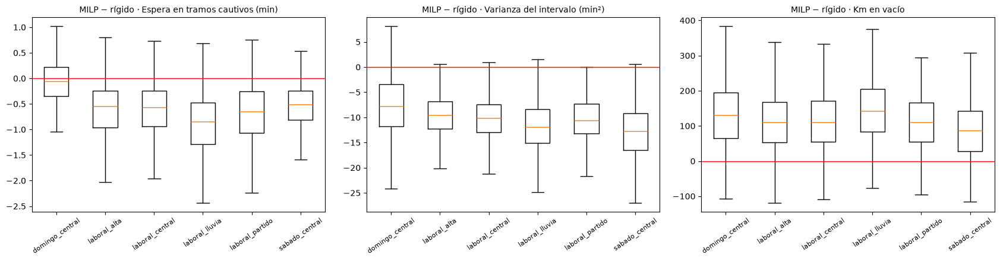

In [5]:
ev = pd.read_csv(OUT / "evaluacion_milp_vs_rigido.csv")
kpi = ev[ev.principal]
display(kpi[["estrato", "indicador", "n_pares", "media_rigido", "media_milp", "cambio_pct", "p_holm", "pct_pares_milp_mejor", "conclusion"]].round(3))
rep = pd.read_csv(OUT / "evaluacion_milp_vs_rigido_replicas.csv")
print(f"Réplicas: {len(rep):,} simulaciones ({rep.brazo.value_counts().to_dict()}) en {rep.estrato.nunique()} estratos")
ancho = rep.pivot_table(index=["estrato", "replica"], columns="brazo", values=["espera_cautiva_media_min", "var_headway_min2", "km_vacio_total"])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (col, tit) in zip(ax, [("espera_cautiva_media_min", "Espera en tramos cautivos (min)"), ("var_headway_min2", "Varianza del intervalo (min²)"), ("km_vacio_total", "Km en vacío")]):
    dif = (ancho[(col, "milp")] - ancho[(col, "rigido")]).rename("dif").reset_index()
    est = sorted(dif.estrato.unique())
    a.boxplot([dif[dif.estrato == e].dif for e in est], tick_labels=est, showfliers=False); a.axhline(0, color="r", lw=1)
    a.set_title(f"MILP − rígido · {tit}", fontsize=10); a.tick_params(axis="x", rotation=35, labelsize=8)
plt.tight_layout(); plt.show()

## 5 · P&L y reporte final de la 14.3

In [6]:
pyl = pd.read_csv(OUT / "pyl_milp_vs_rigido.csv")
display(pyl[["estrato", "etiqueta", "unidad", "rigido", "milp", "dif_milp_menos_rigido", "ic95_inf", "ic95_sup", "milp_mejor", "ic95_excluye_cero"]].round(1))
correr("-m", "src.optimization.reporte_14_3", ultimas=20)
display(Markdown(open(OUT / "INFORME_14_3.md", encoding="utf-8").read()))

,estrato,etiqueta,unidad,rigido,milp,dif_milp_menos_rigido,ic95_inf,ic95_sup,milp_mejor,ic95_excluye_cero
0,domingo_central,Recaudo por tarifa,COP/día,78972121.7,78986329.7,14208.0,-10792.6,40639.3,True,False
1,domingo_central,Costo por km recorrido,COP/día,68132853.6,68188762.5,55908.9,46665.2,64868.5,False,True
2,domingo_central,"· del cual, km en vacío",COP/día,4853504.8,5243198.5,389693.7,358203.7,423366.6,False,True
3,domingo_central,Costo de permutar en cabecera,COP/día,0.0,483933.3,483933.3,476599.2,491669.2,False,True
4,domingo_central,Margen operativo,COP/día,10839268.0,10313633.8,-525634.2,-553210.5,-496758.2,False,True
...,...,...,...,...,...,...,...,...,...,...
58,todos,Margen operativo,COP/día,60160350.8,59416419.4,-743931.4,-756395.8,-731627.1,False,True
59,todos,Recaudo por km,COP/km,4767.5,4769.0,1.5,1.1,2.0,True,True
60,todos,Costo del tiempo de espera de los usuarios,COP/día,32623166.9,30531717.0,-2091449.8,-2169951.6,-2006883.8,True,True
61,todos,"· del cual, pasajeros cautivos",COP/día,18228377.5,16835471.2,-1392906.3,-1451336.1,-1330493.0,True,True


pyl: C:\Users\<usuario>\OneDrive\Escritorio\UNIVERSIDAD\2026\2026-3\MACHINE LEARNING\04_Data_Challenge_SOBUSA\_e2\Sobusa\modulo14\data\outputs\pyl_milp_vs_rigido.csv
informe: C:\Users\<usuario>\OneDrive\Escritorio\UNIVERSIDAD\2026\2026-3\MACHINE LEARNING\04_Data_Challenge_SOBUSA\_e2\Sobusa\modulo14\data\outputs\INFORME_14_3.md

[código de salida 0]


# Subfase 14.3 · Operación rígida vs. redespacho MILP (opción B)

**Pares completos:** 2.500 (5.000 simulaciones) en 6 estratos. **Computador:** <equipo> · Windows 11 · Python 3.12.0.
**Huella de la versión:** `b16973cb1db3b0a6` · regla de salidas: `igual_plan` · creado 2026-11-08T11:56:45.

Cada par vive el mismo día simulado (misma semilla: mismas llegadas, factor de demanda, imprevistos y varadas); solo cambia la regla de control. Con la opción B las dos operaciones hacen el mismo número de salidas: el MILP decide a qué ruta va cada una y qué buses se permutan en la terminal.

## KPI principales (Wilcoxon pareado, Holm sobre los 4 KPI de cada estrato, α = 0,05)

| Estrato | KPI | Rígido | MILP | Cambio | p (Holm) | % pares MILP mejor | Conclusión |
|---|---|---:|---:|---:|---:|---:|---|
| domingo_central | Espera en tramos cautivos (min) | 8,21 | 8,15 | -0,6 % | 0.0516 | 55,7 % | sin diferencia significativa |
| domingo_central | Pasajeros dejados por bus lleno | 326,30 | 432,37 | 32,5 % | 1.0000 | 23,0 % | MILP empeora (p < 0,05) |
| domingo_central | Km en vacío (bus vacío + reposicionamiento) | 1.617,83 | 1.747,73 | 8,0 % | 1.0000 | 9,0 % | MILP empeora (p < 0,05) |
| domingo_central | Varianza del intervalo entre buses (min²) | 49,80 | 42,46 | -14,7 % | 0.0000 | 89,7 % | MILP mejora (p < 0,05) |
| laboral_alta | Espera en tramos cautivos (min) | 8,22 | 7,62 | -7,3 % | 0.0000 | 86,8 % | MILP mejora (p < 0,05) |
| laboral_alta | Pasajeros dejados por bus lleno | 3.480,18 | 3.293,84 | -5,4 % | 0.0000 | 64,8 % | MILP mejora (p < 0,05) |
| laboral_alta | Km en vacío (bus vacío + reposicionamiento) | 1.762,16 | 1.873,36 | 6,3 % | 1.0000 | 9,4 % | MILP empeora (p < 0,05) |
| laboral_alta | Varianza del intervalo entre buses (min²) | 40,82 | 31,16 | -23,7 % | 0.0000 | 97,8 % | MILP mejora (p < 0,05) |
| laboral_central | Espera en tramos cautivos (min) | 8,14 | 7,53 | -7,4 % | 0.0000 | 86,8 % | MILP mejora (p < 0,05) |
| laboral_central | Pasajeros dejados por bus lleno | 3.481,23 | 3.321,87 | -4,6 % | 0.0000 | 63,6 % | MILP mejora (p < 0,05) |
| laboral_central | Km en vacío (bus vacío + reposicionamiento) | 1.744,91 | 1.860,19 | 6,6 % | 1.0000 | 8,7 % | MILP empeora (p < 0,05) |
| laboral_central | Varianza del intervalo entre buses (min²) | 38,83 | 28,75 | -26,0 % | 0.0000 | 98,5 % | MILP mejora (p < 0,05) |
| laboral_lluvia | Espera en tramos cautivos (min) | 9,22 | 8,31 | -9,8 % | 0.0000 | 93,8 % | MILP mejora (p < 0,05) |
| laboral_lluvia | Pasajeros dejados por bus lleno | 4.238,06 | 4.111,70 | -3,0 % | 0.0000 | 61,3 % | MILP mejora (p < 0,05) |
| laboral_lluvia | Km en vacío (bus vacío + reposicionamiento) | 1.719,53 | 1.862,38 | 8,3 % | 1.0000 | 5,0 % | MILP empeora (p < 0,05) |
| laboral_lluvia | Varianza del intervalo entre buses (min²) | 46,68 | 34,69 | -25,7 % | 0.0000 | 99,5 % | MILP mejora (p < 0,05) |
| laboral_partido | Espera en tramos cautivos (min) | 8,19 | 7,46 | -8,9 % | 0.0000 | 90,0 % | MILP mejora (p < 0,05) |
| laboral_partido | Pasajeros dejados por bus lleno | 3.935,55 | 3.778,36 | -4,0 % | 0.0000 | 62,0 % | MILP mejora (p < 0,05) |
| laboral_partido | Km en vacío (bus vacío + reposicionamiento) | 1.796,02 | 1.905,13 | 6,1 % | 1.0000 | 8,4 % | MILP empeora (p < 0,05) |
| laboral_partido | Varianza del intervalo entre buses (min²) | 39,91 | 29,29 | -26,6 % | 0.0000 | 99,2 % | MILP mejora (p < 0,05) |
| sabado_central | Espera en tramos cautivos (min) | 8,12 | 7,59 | -6,5 % | 0.0000 | 89,0 % | MILP mejora (p < 0,05) |
| sabado_central | Pasajeros dejados por bus lleno | 1.820,70 | 1.578,57 | -13,3 % | 0.0000 | 78,3 % | MILP mejora (p < 0,05) |
| sabado_central | Km en vacío (bus vacío + reposicionamiento) | 1.572,89 | 1.656,83 | 5,3 % | 1.0000 | 15,7 % | MILP empeora (p < 0,05) |
| sabado_central | Varianza del intervalo entre buses (min²) | 49,32 | 36,29 | -26,4 % | 0.0000 | 99,0 % | MILP mejora (p < 0,05) |
| todos | Espera en tramos cautivos (min) | 8,34 | 7,75 | -7,1 % | 0.0000 | 84,8 % | MILP mejora (p < 0,05) |
| todos | Pasajeros dejados por bus lleno | 3.069,69 | 2.932,35 | -4,5 % | 0.0000 | 60,2 % | MILP mejora (p < 0,05) |
| todos | Km en vacío (bus vacío + reposicionamiento) | 1.713,52 | 1.829,77 | 6,8 % | 1.0000 | 9,1 % | MILP empeora (p < 0,05) |
| todos | Varianza del intervalo entre buses (min²) | 43,17 | 32,78 | -24,1 % | 0.0000 | 97,6 % | MILP mejora (p < 0,05) |

## P&L por día típico (COP; precios supuestos de `milp_config.yaml`)

| Estrato | Concepto | Rígido | MILP | MILP − rígido | IC95 % | ¿Mejora? |
|---|---|---:|---:|---:|---|---|
| domingo_central | Recaudo por tarifa | 78.972.122 | 78.986.330 | 14.208 | [-10.793; 40.639] | sí (no significativo) |
| domingo_central | Costo por km recorrido | 68.132.854 | 68.188.763 | 55.909 | [46.665; 64.869] | no |
| domingo_central | · del cual, km en vacío | 4.853.505 | 5.243.199 | 389.694 | [358.204; 423.367] | no |
| domingo_central | Costo de permutar en cabecera | 0 | 483.933 | 483.933 | [476.599; 491.669] | no |
| domingo_central | Margen operativo | 10.839.268 | 10.313.634 | -525.634 | [-553.210; -496.758] | no |
| domingo_central | Recaudo por km | 3.477,30 | 3.475,08 | -2,22 | [-3,44; -0,95] | no |
| domingo_central | Costo del tiempo de espera de los usuarios | 16.408.474 | 16.237.800 | -170.673 | [-257.065; -79.207] | sí |
| domingo_central | · del cual, pasajeros cautivos | 9.058.187 | 9.010.482 | -47.705 | [-99.043; 10.769] | sí (no significativo) |
| domingo_central | Beneficio neto (margen − costo de la espera) | -5.569.206 | -5.924.166 | -354.961 | [-445.414; -272.217] | no |
| laboral_alta | Recaudo por tarifa | 173.554.346 | 173.490.366 | -63.980 | [-85.271; -43.600] | no |
| laboral_alta | Costo por km recorrido | 105.425.985 | 105.371.806 | -54.180 | [-66.218; -43.503] | sí |
| laboral_alta | · del cual, km en vacío | 5.286.495 | 5.620.089 | 333.594 | [312.025; 356.409] | no |
| laboral_alta | Costo de permutar en cabecera | 0 | 818.180 | 818.180 | [812.718; 823.582] | no |
| laboral_alta | Margen operativo | 68.128.361 | 67.300.380 | -827.981 | [-853.450; -803.688] | no |
| laboral_alta | Recaudo por km | 4.938,81 | 4.939,45 | 0,64 | [-0,14; 1,41] | sí (no significativo) |
| laboral_alta | Costo del tiempo de espera de los usuarios | 34.185.788 | 32.034.555 | -2.151.233 | [-2.341.726; -1.962.096] | sí |
| laboral_alta | · del cual, pasajeros cautivos | 19.596.056 | 18.144.793 | -1.451.263 | [-1.596.474; -1.308.298] | sí |
| laboral_alta | Beneficio neto (margen − costo de la espera) | 33.942.573 | 35.265.825 | 1.323.252 | [1.133.834; 1.512.603] | sí |
| laboral_central | Recaudo por tarifa | 174.361.804 | 174.307.518 | -54.286 | [-71.389; -36.126] | no |
| laboral_central | Costo por km recorrido | 105.537.258 | 105.493.266 | -43.992 | [-52.416; -35.419] | sí |
| laboral_central | · del cual, km en vacío | 5.234.726 | 5.580.557 | 345.831 | [328.242; 364.069] | no |
| laboral_central | Costo de permutar en cabecera | 0 | 816.813 | 816.813 | [812.465; 820.880] | no |
| laboral_central | Margen operativo | 68.824.546 | 67.997.438 | -827.108 | [-846.705; -806.326] | no |
| laboral_central | Recaudo por km | 4.956,43 | 4.956,88 | 0,45 | [-0,16; 1,09] | sí (no significativo) |
| laboral_central | Costo del tiempo de espera de los usuarios | 34.020.603 | 31.801.129 | -2.219.474 | [-2.357.447; -2.078.962] | sí |
| laboral_central | · del cual, pasajeros cautivos | 19.489.890 | 18.012.399 | -1.477.491 | [-1.579.810; -1.372.982] | sí |
| laboral_central | Beneficio neto (margen − costo de la espera) | 34.803.943 | 36.196.309 | 1.392.366 | [1.256.196; 1.528.674] | sí |
| laboral_lluvia | Recaudo por tarifa | 175.429.284 | 175.372.100 | -57.184 | [-81.925; -31.883] | no |
| laboral_lluvia | Costo por km recorrido | 101.813.433 | 101.794.068 | -19.365 | [-44.323; -2.256] | sí |
| laboral_lluvia | · del cual, km en vacío | 5.158.585 | 5.587.138 | 428.553 | [401.160; 455.098] | no |
| laboral_lluvia | Costo de permutar en cabecera | 0 | 837.850 | 837.850 | [831.549; 844.351] | no |
| laboral_lluvia | Margen operativo | 73.615.851 | 72.740.183 | -875.669 | [-906.905; -842.924] | no |
| laboral_lluvia | Recaudo por km | 5.169,20 | 5.168,53 | -0,68 | [-1,92; 0,87] | no (no significativo) |
| laboral_lluvia | Costo del tiempo de espera de los usuarios | 38.515.646 | 35.483.952 | -3.031.695 | [-3.252.700; -2.824.196] | sí |
| laboral_lluvia | · del cual, pasajeros cautivos | 22.227.328 | 20.003.880 | -2.223.448 | [-2.385.356; -2.066.794] | sí |
| laboral_lluvia | Beneficio neto (margen − costo de la espera) | 35.100.205 | 37.256.231 | 2.156.026 | [1.950.324; 2.369.770] | sí |
| laboral_partido | Recaudo por tarifa | 177.600.429 | 177.702.801 | 102.372 | [73.643; 132.296] | sí |
| laboral_partido | Costo por km recorrido | 106.792.974 | 106.691.341 | -101.632 | [-115.870; -86.953] | sí |
| laboral_partido | · del cual, km en vacío | 5.388.073 | 5.715.399 | 327.325 | [296.860; 357.586] | no |
| laboral_partido | Costo de permutar en cabecera | 0 | 817.920 | 817.920 | [809.879; 825.721] | no |
| laboral_partido | Margen operativo | 70.807.456 | 70.193.539 | -613.916 | [-650.064; -577.876] | no |
| laboral_partido | Recaudo por km | 4.989,02 | 4.996,66 | 7,64 | [6,53; 8,72] | sí |
| laboral_partido | Costo del tiempo de espera de los usuarios | 40.774.051 | 38.283.785 | -2.490.266 | [-2.782.413; -2.195.819] | sí |
| laboral_partido | · del cual, pasajeros cautivos | 19.696.104 | 17.912.938 | -1.783.166 | [-2.000.349; -1.569.884] | sí |
| laboral_partido | Beneficio neto (margen − costo de la espera) | 30.033.405 | 31.909.755 | 1.876.350 | [1.580.575; 2.170.809] | sí |
| sabado_central | Recaudo por tarifa | 138.375.609 | 138.413.090 | 37.481 | [15.614; 59.657] | sí |
| sabado_central | Costo por km recorrido | 90.647.935 | 90.531.951 | -115.985 | [-129.563; -102.084] | sí |
| sabado_central | · del cual, km en vacío | 4.718.663 | 4.970.479 | 251.815 | [223.941; 280.258] | no |
| sabado_central | Costo de permutar en cabecera | 0 | 700.367 | 700.367 | [693.467; 707.202] | no |
| sabado_central | Margen operativo | 47.727.674 | 47.180.773 | -546.901 | [-576.115; -516.760] | no |
| sabado_central | Recaudo por km | 4.579,60 | 4.586,67 | 7,07 | [6,02; 8,12] | sí |
| sabado_central | Costo del tiempo de espera de los usuarios | 28.090.859 | 26.084.338 | -2.006.521 | [-2.158.459; -1.855.067] | sí |
| sabado_central | · del cual, pasajeros cautivos | 15.410.282 | 14.413.504 | -996.778 | [-1.099.024; -901.434] | sí |
| sabado_central | Beneficio neto (margen − costo de la espera) | 19.636.815 | 21.096.435 | 1.459.620 | [1.307.287; 1.611.686] | sí |
| todos | Recaudo por tarifa | 158.929.867 | 158.908.075 | -21.792 | [-31.394; -12.138] | no |
| todos | Costo por km recorrido | 98.769.516 | 98.725.012 | -44.504 | [-50.759; -38.770] | sí |
| todos | · del cual, km en vacío | 5.140.558 | 5.489.308 | 348.750 | [338.052; 359.195] | no |
| todos | Costo de permutar en cabecera | 0 | 766.644 | 766.644 | [761.679; 771.776] | no |
| todos | Margen operativo | 60.160.351 | 59.416.419 | -743.931 | [-756.396; -731.627] | no |
| todos | Recaudo por km | 4.767,49 | 4.769,00 | 1,50 | [1,08; 1,95] | sí |
| todos | Costo del tiempo de espera de los usuarios | 32.623.167 | 30.531.717 | -2.091.450 | [-2.169.952; -2.006.884] | sí |
| todos | · del cual, pasajeros cautivos | 18.228.377 | 16.835.471 | -1.392.906 | [-1.451.336; -1.330.493] | sí |
| todos | Beneficio neto (margen − costo de la espera) | 27.537.184 | 28.884.702 | 1.347.518 | [1.265.620; 1.422.900] | sí |

## Estado del solver en el brazo MILP

- Ventanas resueltas: 170.000; relajadas (faltan buses para el plan): 50; con plan de respaldo: 0; con límite de tiempo: 562.
- cbc.exe reiniciado por el vigía: 0 vez/veces.
- Tiempo del MILP por ventana: mediana de las medianas 0,86 s; máximo 11,60 s.
- Permutaciones por día: mediana 80, máximo 109.
- La Playa por día: cambios de ruta del regreso, mediana 79; buses retenidos, mediana 119 (espera máxima observada 10,0 min); buses que quedaron en La Playa al final del día: 0.

## Cómo leerlo

- Los KPI y el P&L salen del simulador del Módulo 13 (no del modelo del MILP). La espera y el cupo sirven para **comparar** operaciones, no como nivel absoluto (Módulo 13, `NOTA_PARA_MODULO_14.md` §5).
- En el simulador cada pasajero solo sube a su ruta: el beneficio de los corredores compartidos (tomar cualquier ruta que pase) no se mide aquí.
- Los precios del P&L son supuestos metodológicos; el recaudo usa la tarifa fija de 3.700 COP del Entregable 1.
- Una diferencia es significativa si p (Holm) < 0.05 (KPI) o si el IC95 % no incluye el cero (P&L).


## 6 · Pruebas del módulo (esperado: 20/20, 10/10 y 9/9)

In [7]:
correr("tests_14_2.py", ultimas=8)

r. [PASS] Retención en La Playa: buses que llegan pegados se retienen ≤ espera máxima (R16) y ≤ capacidad (R17) (1.1 s)
     4 buses de la 2 llegan juntos a La Playa entre 07:01 y 07:04 (el plan del regreso: 2 cada 15 min): retiene 1 hasta las 07:15; con capacidad 1 retiene 1; con capacidad 0, 0
s. [PASS] Cambio de ruta en La Playa: sin buses para el regreso de la 21 y sus cautivos esperando, se pasan buses del regreso de la 16 (0.9 s)
     6 buses cambian del regreso 16 al 21 en La Playa; cautiva atendida (horizonte) 72.0 % → 86.3 %
t. [PASS] Cierre de jornada: de 22:30 a 00:15 ningún bus se queda en La Playa y todos terminan libres en la terminal (2.9 s)
     20 buses: 10 llegan a La Playa entre 22:35 y 00:05 y siguen a la terminal (máx. 1 ventana de espera); a las 03:30 los 20 están libres en la terminal; 4 cambios de ruta

20/20 PASS · 23 s · Python 3.12.0 · PuLP 3.3.2

[código de salida 0]


0

In [8]:
correr("tests_14_3.py", ultimas=8)

h. [PASS] Brazo MILP (04:00–06:15, inicio del servicio y ráfagas del plan) sin red: todo óptimo, salidas = plan, flota conservada y KPI completos (5.0 s)
     estados {'optimo': 9}, MILP 0.38 s/ventana (máx 0.46), 0 permutaciones en la terminal y 0 cambios de ruta y 2 retenciones en La Playa (máx. 10.0 min), salidas = plan en cada ventana (opción B), espera cautiva 7.24 min
i. [PASS] Reporte P&L y tabla final: cuentas correctas, IC95 % pareado e informe en Markdown (réplicas sintéticas) (0.1 s)
     recaudo = pasajeros × 3,700; permutar 10 buses = 100,000 COP/día; espera de cautivos −450,000 COP/día (IC95 % sin cero); informe con KPI y P&L
j. [PASS] La Playa sin órdenes ≡ rígido: la vuelta con la parada de despacho da el mismo día, número por número (2.5 s)
     557 viajes, 51,443 pasajeros y 70,748 pasos idénticos con la parada de La Playa (sin órdenes)

10/10 PASS · 37 s · Python 3.12.0

[código de salida 0]


0

In [9]:
correr("tests_14_4.py", ultimas=8)

g. [PASS] App de Streamlit sin red: carga, calcula el redespacho y muestra alertas, acciones y badge sin errores (21.2 s)
     4 métricas, 5 tarjetas rojas, 5 tablas
h. [PASS] Integración con la app del Módulo 13: el panel carga aunque esa app ya tenga su propio paquete «src» (1.1 s)
     src del Módulo 13 intacto; panel cargado como m14src.ui.components.redispatch_panel
i. [PASS] Pestaña dentro de una app que ya cargó src.gemelo del Módulo 13 (como gemelo_13_5.py con el diff): calcula sin errores (21.8 s)
     proceso limpio con src del Módulo 13 (modulo13): pestaña calculada sin red, 5 tarjetas rojas; diff de 7 líneas

9/9 PASS · 62 s · Python 3.12.0

[código de salida 0]


0

<a id="m15"></a>

---

## A2.8 &middot; Módulo 15 · Despacho en cascada: la frecuencia que se recalcula durante el día

**Qué recibe del pronóstico y qué cierra.** Cada 15, 30 o 60 min recalcula cuántas salidas necesita cada ruta en la ventana siguiente, combinando el pronóstico de las 04:00 con lo que los sensores ya contaron ese día, los buses disponibles y las varadas y desvíos reportados; como opción, ese plan pasa al MILP del Módulo 14. Es una extensión posterior al plan del Entregable 3, y es donde aparece el hallazgo con más dinero detrás: su evaluación oficial simuló 16.500 días con una sola configuración congelada.

<sub>[&#8679; volver al índice](#indice)</sub>

<a id="m15-1"></a>

### A2.8.1 &middot; Subfase 15.1 · Estimador en vivo y regla de frecuencia

<sub>Notebook original: `modulo15/subfase_15_1_estimador.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 15 · Subfase 15.1 — Estimador en vivo de la demanda y regla de frecuencia

**Persona 3.** Primera pieza del despacho en cascada: en cada recálculo T, comparar las subidas que los sensores ya
contaron con las que esperaba el pronóstico de las 04:00, corregir la demanda del resto del día y convertirla en
salidas por ruta para la ventana siguiente. Aquí se prueba **sin simulador**, con viajes reales de 2025.

- Alcance: `revisiones/alcance_15_1.md` (pruebas adicionales pedidas por la Persona 3, 8-nov-2026).
- Calibración con enero–junio de 2025; **prueba única** con julio–diciembre; configuración congelada con hash.
- Se excluyen los 6 días de validación del 13; los 3 días de control solo se usan en la prueba (e).

In [1]:
import json, os, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, ".")
import estimador_15_1 as X
pd.set_option("display.width", 200); pd.set_option("display.max_columns", None)
S = X.SAL
cfg = json.loads(X.CONFIG.read_text(encoding="utf-8"))
res = json.loads(X.RESULTADOS.read_text(encoding="utf-8"))
FIG = Path("resultados_15"); FIG.mkdir(exist_ok=True)
print("configuración:", X.sha(X.CONFIG)[:12], "· congelada:", (S / "config_estimador_15_1.sha256").read_text().strip()[:12])
print("resultados creados:", res["creado"], "· con la configuración", res["config_sha256"][:12])

configuración: 5136bb75474c · congelada: 5136bb75474c
resultados creados: 2026-11-08T14:30:30 · con la configuración 5136bb75474c


## 1 · Cómo se acumulan las subidas durante un viaje (muestra E3, 5.232 viajes de 2025)

grupo,4–6 h,6–9 h,9–12 h,12–15 h,15–18 h,18–21 h
minuto,,,,,,
30,0.325,0.299,0.183,0.140,0.148,0.163
60,0.529,0.530,0.343,0.276,0.297,0.304
120,0.786,0.689,0.505,0.444,0.530,0.607
180,0.970,0.898,0.855,0.806,0.895,0.976
240,0.999,0.994,0.994,0.979,0.996,1.000


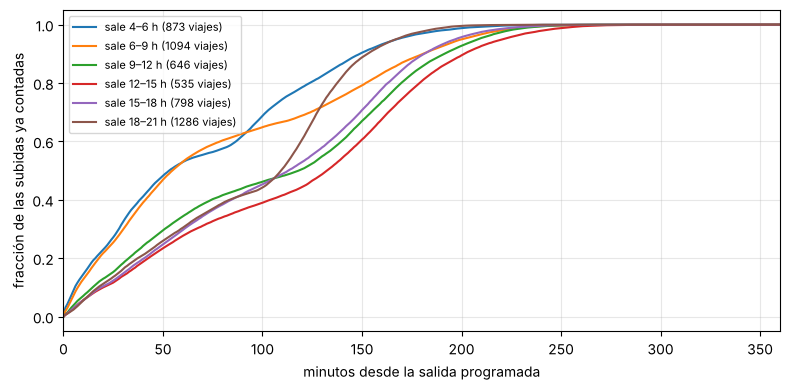

In [2]:
p = pd.read_csv(S / "perfil_acumulacion_15_1.csv")
fig, ax = plt.subplots(figsize=(8, 4))
etq = ["4–6 h", "6–9 h", "9–12 h", "12–15 h", "15–18 h", "18–21 h"]
for g, d in p.groupby("grupo"):
    ax.plot(d.minuto, d.fraccion, label=f"sale {etq[g]} ({d.n_viajes.iloc[0]} viajes)")
ax.set_xlim(0, 360); ax.set_xlabel("minutos desde la salida programada"); ax.set_ylabel("fracción de las subidas ya contadas")
ax.legend(fontsize=8); ax.grid(alpha=.3); fig.tight_layout(); fig.savefig(FIG / "m15_1_perfil.png", dpi=120)
p[p.minuto.isin([30, 60, 120, 180, 240])].pivot(index="minuto", columns="grupo", values="fraccion").round(3).rename(columns=dict(enumerate(etq)))

**Conclusión 1 · Un viaje cuenta sus subidas durante unas 4 horas**
- A la hora de salir, el sensor lleva contado entre el 28 % (salidas de 12 a 15 h) y el 53 % (madrugada y pico de la mañana) de las subidas del viaje; a las 3 h, el 81–98 %; a las 4 h, el 97,9 % o más.
- Por eso lo observado en T habla sobre todo de viajes que salieron hace 1–3 h: el estimador ve el día con retraso.

## 2 · Calibración (enero–junio de 2025) y configuración congelada

In [3]:
cal = pd.read_csv(S / "calibracion_15_1.csv")
print(json.dumps(cfg["elegido"], indent=1, ensure_ascii=False))
cal[cal.modo == "sensores"].sort_values("wape_1h").head(8).round(4)

{
 "sensores": {
  "W": "120",
  "version": "mezcla",
  "k": 40.0,
  "k_ruta": 80.0,
  "wape_1h_cal": 0.0892084831561482,
  "wape_1h_base_cal": 0.09825740574910215,
  "wape_resto_cal": 0.04731567631019682,
  "wape_resto_base_cal": 0.056201895667326154
 },
 "solo_cerrados": {
  "W": "dia",
  "version": "mezcla",
  "k": 80.0,
  "k_ruta": 160.0,
  "wape_1h_cal": 0.09160644365190042,
  "wape_1h_base_cal": 0.09825740574910215,
  "wape_resto_cal": 0.05110660328415684,
  "wape_resto_base_cal": 0.056201895667326154
 }
}


,modo,W,version,k,k_ruta,wape_1h,wape_resto,wape_1h_base,wape_resto_base
152,sensores,120,mezcla,40,80.0,0.0892,0.0473,0.0983,0.0562
151,sensores,120,mezcla,40,40.0,0.0892,0.0478,0.0983,0.0562
145,sensores,120,mezcla,20,160.0,0.0893,0.0481,0.0983,0.0562
53,sensores,60,mezcla,20,40.0,0.0893,0.0476,0.0983,0.0562
144,sensores,120,mezcla,20,80.0,0.0893,0.0483,0.0983,0.0562
146,sensores,120,mezcla,20,320.0,0.0893,0.0481,0.0983,0.0562
153,sensores,120,mezcla,40,160.0,0.0893,0.0472,0.0983,0.0562
54,sensores,60,mezcla,20,80.0,0.0893,0.0474,0.0983,0.0562


**Conclusión 2 · Se eligió mirar las últimas 2 horas y mezclar el nivel común con el de cada ruta**
- Elegido entre 540 configuraciones (2 modos × 3 ventanas × 3 versiones × rejilla de k): ventana de 2 h, versión «mezcla», k = 40 viajes-equivalentes para la común y 80 para la desviación de cada ruta. Ninguno queda en el borde de la rejilla.
- En la calibración, el error de la hora siguiente baja de 9,83 % a 8,92 % y el del resto del día de 5,62 % a 4,73 %.
- La cota pesimista («solo viajes cerrados», sin la aproximación) elige todo el día y k = 80: 9,16 %.

## 3 · Prueba única con julio–diciembre de 2025

In [4]:
filas = []
for k, nom in (("H2_sensores", "04:00 corregido (sensores, aprox.)"), ("H2_sensores_intradia", "intradía corregido"),
               ("H2_solo_cerrados", "04:00 corregido (solo cerrados)")):
    r = res[k]
    filas.append({"versión": nom, "WAPE 1 h sin corregir": r["wape_1h_base"], "WAPE 1 h corregido": r["wape_1h_corr"],
                  "WAPE resto sin corregir": r["wape_resto_base"], "WAPE resto corregido": r["wape_resto_corr"],
                  "% recálculos que mejora": r["pct_mejora_1h"], "γ̂ P5–P95": r["gamma_p05_p95"]})
pd.DataFrame(filas).round(4)

,versión,WAPE 1 h sin corregir,WAPE 1 h corregido,WAPE resto sin corregir,WAPE resto corregido,% recálculos que mejora,γ̂ P5–P95
0,"04:00 corregido (sensores, aprox.)",0.0999,0.0936,0.0528,0.0489,57.3361,"[0.9233085157309148, 1.0503893704052878]"
1,intradía corregido,0.0967,0.0925,0.0502,0.0496,55.8630,"[0.9320617030864657, 1.0537848277096227]"
2,04:00 corregido (solo cerrados),0.0999,0.0957,0.0528,0.0544,54.9257,"[0.9100414232137933, 1.0380001953261084]"


**Conclusión 3 · En la prueba, corregir ayuda poco: −6 % de error en la hora siguiente**
- Pronóstico de las 04:00: 9,99 % → **9,36 %** en la hora siguiente y 5,28 % → **4,89 %** en el resto del día (recálculos de 07:00 a 19:00, 3 rutas, 179 días).
- El modelo intradía del Entregable 1 solo ya da 9,67 %; corregido, 9,25 %: la corrección casi iguala al 04:00 con el intradía.
- Mejora en el **57,3 %** de los recálculos. **El criterio escrito pedía 60 %: no se cumple**, y se reporta así.
- Con la cota pesimista (solo viajes cerrados): 9,57 %, y el resto del día empeora (5,28 → 5,44 %).
- γ̂ se mueve poco: P5–P95 de 0,92 a 1,05.

## 4 · Pruebas adicionales: mes a mes, al revés y por grupos

In [5]:
rod = pd.DataFrame(res["a_origen_rodante"])
rod["cambio_1h_%"] = 100 * (rod.wape_1h_corr / rod.wape_1h_base - 1)
display(rod.round(4))
b = res["b_al_reves"]; print("al revés:", b["elegido_con_H2"], "· WAPE 1 h", round(b["wape_1h_base"], 4), "→", round(b["wape_1h_corr"], 4))
des = pd.DataFrame(res["c_desgloses"]); des["cambio_%"] = 100 * (des.wape_1h_corr / des.wape_1h_base - 1)
des.round(4)

,mes,W,version,k,k_ruta,wape_1h_base,wape_1h_corr,wape_resto_base,wape_resto_corr,pct_mejora_1h,cambio_1h_%
0,7,120,mezcla,40,80,0.1062,0.0967,0.0545,0.0436,58.8262,-8.9355
1,8,120,mezcla,40,80,0.0965,0.0935,0.0482,0.0481,54.8424,-3.1839
2,9,120,mezcla,40,80,0.0912,0.0866,0.0447,0.0452,55.9211,-4.9617
3,10,120,mezcla,40,80,0.0978,0.0915,0.0548,0.0485,59.9253,-6.4367
4,11,120,mezcla,40,80,0.0965,0.0901,0.0515,0.0474,58.6761,-6.6429
5,12,120,mezcla,40,80,0.1118,0.1039,0.0636,0.0615,55.8237,-7.0933


al revés: {'W': '120', 'version': 'mezcla', 'k': 80, 'k_ruta': 40} · WAPE 1 h 0.1003 → 0.0907


,desglose,grupo,n,wape_1h_base,wape_1h_corr,dias,cambio_%
0,ruta,2,8771,0.1194,0.1106,NaN,-7.3718
1,ruta,16,8771,0.0835,0.0789,NaN,-5.5706
2,ruta,21,8771,0.1218,0.1144,NaN,-6.1201
3,tipo_dia_cal,domingo,1127,0.1232,0.1065,23.0,-13.5009
4,tipo_dia_cal,festivo,392,0.1440,0.1193,8.0,-17.1491
5,tipo_dia_cal,laboral,6027,0.0969,0.0916,123.0,-5.4564
6,tipo_dia_cal,sabado,1225,0.0963,0.0937,25.0,-2.7484
7,receso,lectivo,6615,0.0966,0.0910,135.0,-5.8030
8,receso,receso,2156,0.1112,0.1027,44.0,-7.6148
9,lluvia_10mm,lluvia ≥ 10 mm,1225,0.0956,0.0908,25.0,-4.9987


**Conclusión 4 · La mejora es pequeña pero estable**
- **(a) Mes a mes** (cada mes de julio a diciembre con lo aprendido en los anteriores): la configuración elegida es la misma en los 6 meses y mejora la hora siguiente en todos (−3,2 % en agosto a −8,9 % en julio). Ningún mes empeora: se cumple el criterio de robustez.
- **(b) Al revés** (calibrar con julio–diciembre y probar enero–junio): elige la misma ventana y versión (k 80 / 40) y mejora 10,03 → 9,07 %. La elección no depende del semestre.
- **(c) Por grupos:** mejora en las 3 rutas (−5,5 a −7,4 %), en todo tipo de día (domingo −13,6 %, festivo −17,2 %, laboral −5,5 %, sábado −2,7 %), en receso escolar (−7,6 %), con lluvia fuerte (−5,0 %) y con partido (−5,8 %).

## 5 · ¿Cuánto tarda en notar un cambio? (días con demanda inyectada)

,factor,h0,pct_detectado,min_mediana,min_p90
0,0.8,8,96.7,255.0,295.5
1,0.8,11,93.9,255.0,288.0
2,0.8,14,90.0,240.0,270.0
3,0.9,8,96.7,255.0,295.5
4,0.9,11,95.0,255.0,285.0
5,0.9,14,91.1,240.0,270.0
6,1.1,8,95.0,255.0,300.0
7,1.1,11,95.0,255.0,285.0
8,1.1,14,92.8,240.0,270.0
9,1.2,8,96.7,255.0,295.5


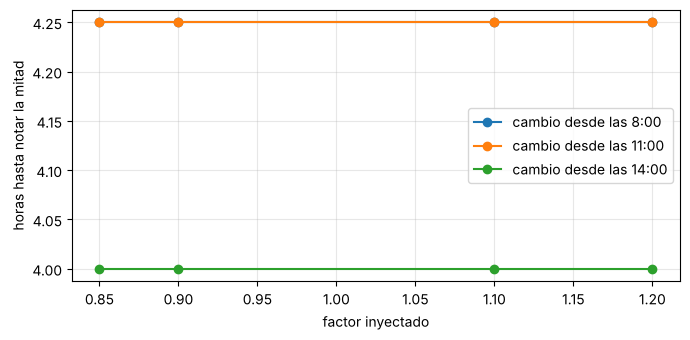

In [6]:
iny = pd.read_csv(S / "inyeccion_15_1.csv")
t = pd.DataFrame(res["d_inyeccion"])
fig, ax = plt.subplots(figsize=(7, 3.5))
for h0, d in t.groupby("h0"):
    ax.plot(d.factor, d.min_mediana / 60, "o-", label=f"cambio desde las {h0}:00")
ax.set_xlabel("factor inyectado"); ax.set_ylabel("horas hasta notar la mitad"); ax.grid(alpha=.3); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "m15_1_deteccion.png", dpi=120)
t.round(1)

**Conclusión 5 · Reacciona lento: unas 4 horas para notar la mitad de un cambio**
- A 60 días de julio–diciembre se les multiplicó la demanda desde las 8, 11 o 14 h (×0,85, ×0,9, ×1,1, ×1,2). El estimador alcanza la mitad del cambio en el 88–97 % de los casos, con mediana de **240–255 min** (P90 270–300).
- Es el costo de la ventana de 2 h, del encogimiento y de que un viaje cuenta sus subidas durante 4 h. Un cambio brusco de demanda no lo resuelve el estimador: tiene que verse por otras señales (buses llenos, buses pegados, eventos).

## 6 · Con lecturas reales del sensor minuto a minuto (3 días de control, E4)

In [7]:
e = res["e_sensores_reales"]; print(json.dumps(e, indent=1, ensure_ascii=False))
sr = pd.read_csv(S / "sensores_reales_15_1.csv", parse_dates=["fecha"])
sr7 = sr[sr.T_min >= 420]
sr7.groupby("fecha").apply(lambda d: pd.Series({
    "WAPE sin corregir": X.wape(d.Y1.to_numpy(), d.P1.to_numpy()),
    "con aproximación": X.wape(d.Y1.to_numpy(), (d.gamma_aprox * d.P1).to_numpy()),
    "con sensor real": X.wape(d.Y1.to_numpy(), (d.gamma_real * d.P1).to_numpy())}), include_groups=False).round(4)

{
 "dias": [
  "2025-08-19",
  "2025-09-20",
  "2025-11-09"
 ],
 "O_aprox_sobre_real": 1.0020579027369778,
 "gamma_dif_mediana_abs": 0.03272096438945493,
 "gamma_dif_p90_abs": 0.08221981348606011,
 "wape_1h_base": 0.09925520471028833,
 "wape_1h_con_aprox": 0.09292027184307698,
 "wape_1h_con_sensor_real": 0.10835724294126577
}


,WAPE sin corregir,con aproximación,con sensor real
fecha,,,
2025-08-19,0.0912,0.0791,0.1007
2025-09-20,0.0992,0.1021,0.1093
2025-11-09,0.1161,0.1073,0.1229


**Conclusión 6 · Con el sensor real, la corrección no ayudó en los 3 días de control**
- En el total, la aproximación cuenta lo mismo que el sensor real (1,002 veces), pero recálculo a recálculo γ̂ difiere: mediana 0,033 y P90 0,082.
- Error de la hora siguiente: sin corregir 9,93 %, con la aproximación 9,29 % y **con el sensor real 10,84 %**. Ningún día mejora con el sensor real.
- Diagnóstico aparte, que no cambia la configuración: con el sensor real, k más grandes (160–640) solo llevan el error de vuelta a ≈ 9,9 %.
- Lectura: la aproximación de la sección 3 es optimista, porque usa el total de los viajes que todavía van en ruta. Con 3 días no es concluyente, pero indica que la ganancia real por demanda está entre 0 y −6 %.

## 7 · La regla de frecuencia

In [8]:
from src.cascada import regla as R
f = pd.read_csv("../modulo13/datos_13/parametros/frecuencias_estimadas_13_1.csv")
filas = []
for r in (2, 16, 21):
    x = f[(f.factor_carga == 0.85) & (f.tipo_dia == "laboral") & (f.idruta == r)]
    p = R.ParamRuta(r, dict(zip(x.hora, x.pax_pred_dia)), dict(zip(x.hora, x.factor_renovacion)),
                    float(x.capacidad_media.iloc[0]), 4 * 60 + 30, 20 * 60 + 50)
    for d in (15, 30, 60):
        pl = R.plan_dia(p, d, 0.85)
        filas.append({"ruta": r, "ventana (min)": d, "salidas del día": sum(v["salidas"] for v in pl),
                      "13.1 (salidas/h sumadas)": round(x.salidas_h.sum(), 1)})
pd.DataFrame(filas)

,ruta,ventana (min),salidas del día,13.1 (salidas/h sumadas)
0,2,15,117,120.4
1,2,30,117,120.4
2,2,60,117,120.4
3,16,15,245,252.0
4,16,30,247,252.0
5,16,60,247,252.0
6,21,15,76,77.9
7,21,30,76,77.9
8,21,60,76,77.9


**Conclusión 7 · La regla da el mismo plan del 13.1 y no depende del tamaño de la ventana**
- Con γ̂ = 1, la regla reproduce el plan de carga máxima del 13.1 (factor 85 %, laboral). La pequeña diferencia viene de recortar a la primera y última salida del plan.
- Con ventanas de 15, 30 y 60 min el total del día difiere en ≤ 2 salidas por ruta (prueba c), gracias al redondeo acumulado.
- Respeta servicio, headway mínimo y buses disponibles en 10.802 ventanas al azar. El servicio mínimo (una salida cada `headway_max`) entra como tasa antes de redondear: corrección de la 15.2, porque como mínimo por ventana dependía del tamaño de la ventana.
- El factor de carga que iguala el presupuesto del plan real se fija en la 15.3.

## Síntesis · Subfase 15.1
- **El estimador funciona, pero aporta poco:** −6 % de error en la hora siguiente y −7 % en el resto del día en la prueba única de julio–diciembre. Es estable mes a mes, al revés, por ruta y por tipo de día. No llega a la meta de mejorar el 60 % de los recálculos (57,3 %).
- **Es lento** (unas 4 h para notar la mitad de un cambio). **Con el sensor real no ayudó** en los 3 días de control.
- **Para la cascada:** la ganancia, si la hay, vendrá de reaccionar a la flota, las varadas, los desvíos y los buses pegados, no de la demanda. El peso del estimador se vuelve a calibrar dentro del simulador (15.3). Si allí no ayuda, se apaga (`version = "ninguna"`) y se dice.
- **Pruebas:** `tests_15_1.py` 6/6 (sin fuga, γ̂ = 1 cuando el día sale igual al pronóstico, límites de la regla, versión vectorizada = servicio, perfil, prueba única).

In [9]:
p = subprocess.run([sys.executable, "tests_15_1.py"], capture_output=True, text=True, encoding="utf-8", errors="replace",
                   env={**os.environ, "PYTHONIOENCODING": "utf-8", "PYTHONUTF8": "1"})
print(p.stdout[-1500:])

a. [PASS] Sin fuga: lo observado en T no cambia si se alteran los viajes que salen en T o después (y, en «solo cerrados», los que cierran después de T) (1.4 s)
     36 combinaciones día × T sin cambio (12 días al azar, 3 recálculos)
b. [PASS] Si el día sale igual al pronóstico, γ̂ = 1 en las 3 versiones y la cascada da el plan fijo de las 04:00 (0.0 s)
     γ̂ = 1 en 2 modos × 3 ventanas × 3 versiones; plan con γ̂ = 1 = plan fijo con ventanas de 15, 30 y 60 min
c. [PASS] La regla respeta sus límites (servicio, headway mínimo, buses disponibles, servicio mínimo por hora) y su total del día casi no depende del tamaño de la ventana (0.8 s)
     10802 ventanas al azar sin violar límites; total del día con 15/30/60 min difiere ≤ 2 salidas
d. [PASS] γ̂ vectorizado (calibración) = γ̂ por ruta (servicio), en las 3 versiones (1.1 s)
     200 casos × 3 versiones iguales
e. [PASS] Perfil de acumulación: 0 al salir, crece, ≤ 1 y ≈ 1 a las 5 h; medido en la muestra E3 (no en los días de control) (0

<a id="m15-2"></a>

### A2.8.2 &middot; Subfase 15.1b · Pronóstico inmediato con el sensor real (batería de modelos)

<sub>Notebook original: `modulo15/subfase_15_1b_bateria.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 15 · Subfase 15.1b — Pronóstico inmediato con el sensor real: batería de la guía del curso

**Persona 3.** En cada recálculo T (cada 15 min), predecir por ruta las subidas de las salidas de la hora siguiente,
corrigiendo el pronóstico de las 04:00 con lo que el sensor ya contó. Se aplica la guía del curso
(`Entregable3MachineLearningProject.pdf`): 7 modelos × 4 optimizadores, validación anidada, comparación estadística
jerárquica, residuos, SHAP y LIME, complejidad y robustez.

- Alcance: `revisiones/alcance_15_1b.md` (decisiones de la Persona 3 del 8-nov-2026 y decisiones B1–B10 de Claude).
- **Parte 1 (extracción):** `extraer_15_1b.py` (E5, la corrió la Persona 3). **Parte 2:** `inmediato_15_1b.py --armar` y
  `bateria_15_1b.py` (protocolo, correr, semillas, complejidad, analizar), todo en el PC de la Persona 3.
- Este notebook no reentrena: lee `datos_15/15_1b/bateria/` y las figuras de `resultados_15/15_1b/`.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 220); pd.set_option("display.max_columns", None); pd.set_option("display.max_rows", 60)
B = Path("datos_15/15_1b/bateria"); F = Path("resultados_15/15_1b")
R = json.loads((B / "resultados_bateria_15_1b.json").read_text(encoding="utf-8"))
P = json.loads((B / "protocolo.json").read_text(encoding="utf-8"))
print("protocolo", P["huella"][:16], "· congelado", P["creado"], "·", P["tareas"], "tareas ·", P["dias"], "días ·", P["filas"], "filas")
print("equipo:", P["entorno"]["sistema"], "· Python", P["entorno"]["python"], "·", P["entorno"]["nucleos"], "núcleos")
print((B / "requirements_bateria.txt").read_text(encoding="utf-8"))

protocolo ab1f0bde4988947b · congelado 2026-11-08 21:42:25 · 222 tareas · 116 días · 18444 filas
equipo: Windows-11-10.0.26200-SP0 · Python 3.12.0 · 12 núcleos
# Python 3.12.0 · Windows-11-10.0.26200-SP0
arch==8.0.0
deap==1.4.4
joblib==1.6.0
lightgbm==4.7.0
lime==0.2.0.1
matplotlib==3.11.2
numpy==2.5.3
optuna==5.0.0
pandas==3.0.5
pyarrow==25.0.1
scikit-learn==1.9.1
scipy==1.18.1
shap==0.54.1
statsmodels==0.15.0
torch==2.15.0
xgboost==3.4.1



## 1 · Datos y validación anidada

In [2]:
m = pd.read_csv(B / "tabla_maestra_15_1b.csv")
print("combinaciones modelo × optimizador:", m.combo.nunique(), "· tareas:", len(m))
m[m.n_train.notna()].groupby("mes").agg(filas_entrenamiento=("n_train", "first"), meses_internos=("meses_internos", "first"),
                                        filas_prueba=("ext_n", "first"))

combinaciones modelo × optimizador: 37 · tareas: 222


,filas_entrenamiento,meses_internos,filas_prueba
mes,,,
7,9210.0,"[5, 6]",1469
8,10788.0,"[6, 7]",1470
9,12378.0,"[7, 8]",1321
10,13807.0,"[8, 9]",1467
11,15394.0,"[9, 10]",1468
12,16982.0,"[10, 11]",1316


**Conclusión 1 · 116 días reales, 6 pliegues hacia adelante y ningún dato del futuro**
- Muestra E5: 120 días de 2025 (10 por mes). **Los 4 días de cierre de mes de la muestra (31-mar, 31-may, 30-sep y 31-dic) no
  tienen ni una lectura de sensor**, aunque sus viajes tienen total: se excluyen y quedan **116 días**
  (18.444 recálculos ruta × T). Esto verifica el pendiente B.3 de la 1.1.
- **Bucle externo:** cada mes de julio a diciembre se prueba entrenando con todos los anteriores
  (9.210 a 16.982 filas). **Bucle interno:** cada configuración se valida con los 2 últimos meses
  del entrenamiento, también hacia adelante. Lo que se reporta es solo la predicción del mes externo.
- **222 tareas** = 37 combinaciones × 6 meses: 7 modelos de la guía × 4 optimizadores, Hyperband en Random
  Forest y XGBoost, LightGBM y la red recurrente (bayesiano y Hyperband), el estimador simple y 2 referencias.
  24 evaluaciones por optimizador; semilla 1515. Protocolo congelado con huella `ab1f0bde4988947b` antes de correr.
- Sin fuga: `tests_15_1b_bateria.py` 7/7 (el optimizador no ve el mes externo; el escalado y el one-hot se ajustan solo con
  el entrenamiento de cada pliegue; la red solo entrena con días anteriores).

## 2 · Resultados por modelo (julio–diciembre, bucle externo)

In [3]:
r = pd.read_csv(B / "resumen_combos_15_1b.csv")
r["IC95 BCa"] = r.ic95_bca.map(lambda s: "" if pd.isna(s) else "[" + ", ".join(f"{float(x):.4f}" for x in s.strip("[]").split(",")) + "]")
r[["combo", "wape_media", "wape_desv", "wape_agregado", "IC95 BCa", "rmse_agregado", "mae_agregado", "sesgo_media",
   "interno_media", "t_busqueda_total_min"]].round(4)

,combo,wape_media,wape_desv,wape_agregado,IC95 BCa,rmse_agregado,mae_agregado,sesgo_media,interno_media,t_busqueda_total_min
0,RandomForest · genetico,0.0902,0.0064,0.0899,"[0.0862, 0.0940]",81.1545,58.9306,-1.1354,0.0911,52.3686
1,RandomForest · hyperband,0.0906,0.0062,0.0902,"[0.0866, 0.0943]",81.5371,59.1760,-1.1827,0.0912,113.3623
2,RandomForest · bayes,0.0906,0.0062,0.0902,"[0.0867, 0.0943]",81.5675,59.1858,-1.2166,0.0911,51.4352
3,KNN · rejilla,0.0908,0.0063,0.0904,"[0.0867, 0.0945]",81.6985,59.3132,-0.2675,0.0916,1.6642
4,KNN · azar,0.0908,0.0063,0.0905,"[0.0868, 0.0946]",81.7365,59.3502,-0.2712,0.0917,1.5212
5,RandomForest · azar,0.0909,0.0060,0.0906,"[0.0870, 0.0945]",81.8348,59.3949,-1.2457,0.0913,65.5779
6,KNN · bayes,0.0909,0.0067,0.0906,"[0.0869, 0.0947]",81.8449,59.3964,-0.3011,0.0916,1.5894
7,KNN · genetico,0.0909,0.0067,0.0906,"[0.0869, 0.0947]",81.8676,59.4190,-0.3056,0.0916,1.5731
8,RandomForest · rejilla,0.0911,0.0066,0.0907,"[0.0871, 0.0948]",81.8215,59.4824,-1.1308,0.0917,72.3604
9,XGBoost · bayes,0.0912,0.0067,0.0908,"[0.0872, 0.0950]",81.9797,59.5697,-1.2381,0.0919,8.0865


**Conclusión 2 · Todos los modelos le ganan al pronóstico de las 04:00; el mejor baja el error un 10,3 %**
- Métrica principal: WAPE de las subidas de la hora siguiente (recálculos de 07:00 a 19:00), en los 58 días de prueba.
- **Pronóstico de las 04:00: 0,1002** · intradía 0,0966 · estimador simple de la 15.1
  0,0960 · **mejor: RandomForest · genetico, 0,0899** (IC95 % BCa por días 0,0862–0,0940).
- **Las 34 combinaciones de aprendizaje automático quedan por debajo del 04:00 y del estimador simple.**
  Mejor por modelo: Random Forest 0,0899, KNN 0,0904,
  XGBoost 0,0908, LightGBM 0,0909,
  Ridge 0,0910, Lasso 0,0911, SVR 0,0919,
  red recurrente 0,0924 y árbol 0,0935.
- En subidas: RMSE 88,5 → 81,2 y MAE 65,7 → 58,9
  por recálculo (la hora siguiente lleva 656 subidas en promedio). Sesgo: el 04:00 sobrepredice
  3,8 %; el mejor queda en −1,1 %.
- **Entre los modelos, las diferencias son pequeñas:** del mejor al peor de aprendizaje automático (Arbol · rejilla, 0,0943)
  hay 0,45 puntos; la variación entre meses de un mismo modelo es mayor
  (desviación 0,0057–0,0084). La sección 5 dice cuáles diferencias son reales.

## 3 · Entrenamiento, validación y prueba del mejor modelo (pliegue de diciembre)

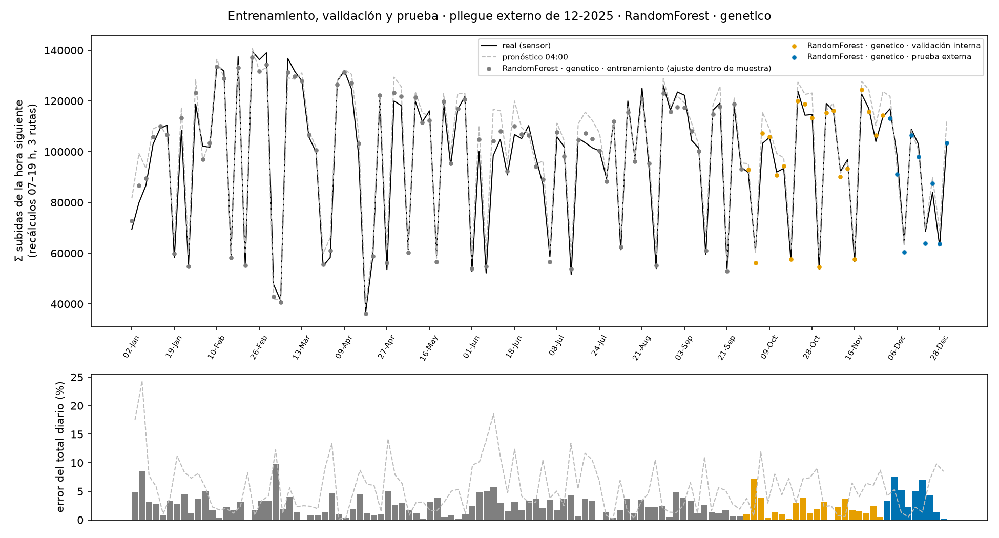

entrenamiento (ajuste dentro de muestra)    2.38
prueba externa                              3.90
validación interna                          2.00
Name: error del total diario (%), dtype: float64

In [4]:
display(Image(filename=str(F / "m15_1b_entrenamiento_validacion_prueba.png")))
pd.Series(R["entrenamiento_validacion_prueba"]).round(2).rename("error del total diario (%)")

**Conclusión 3 · No hay sobreajuste que preocupe**
- Error del total diario de subidas (recálculos de 07 a 19 h, 3 rutas), pliegue de diciembre de RandomForest · genetico:
  ajuste dentro de muestra (enero–septiembre) **2,38 %**, validación interna
  (octubre y noviembre) **2,00 %** y prueba externa (diciembre) **3,90 %**.
- El ajuste dentro de muestra no es mucho menor que la validación: el bosque no memoriza los días de entrenamiento.
- La prueba sale peor que la validación porque **diciembre es el mes más difícil para el modelo**: WAPE 0,1010, frente a
  0,0820–0,0917 de julio a noviembre, y es el mes en que
  menos corrige al 04:00 (0,1076). El bucle interno de ese pliegue estimaba 0,0869: la temporada navideña no estaba
  en octubre y noviembre.

## 4 · Optimizadores: rejilla, azar, bayesiano (TPE), genético y Hyperband

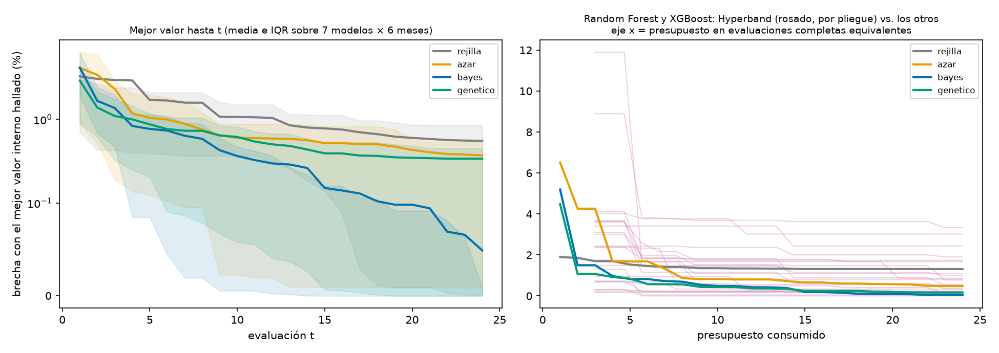

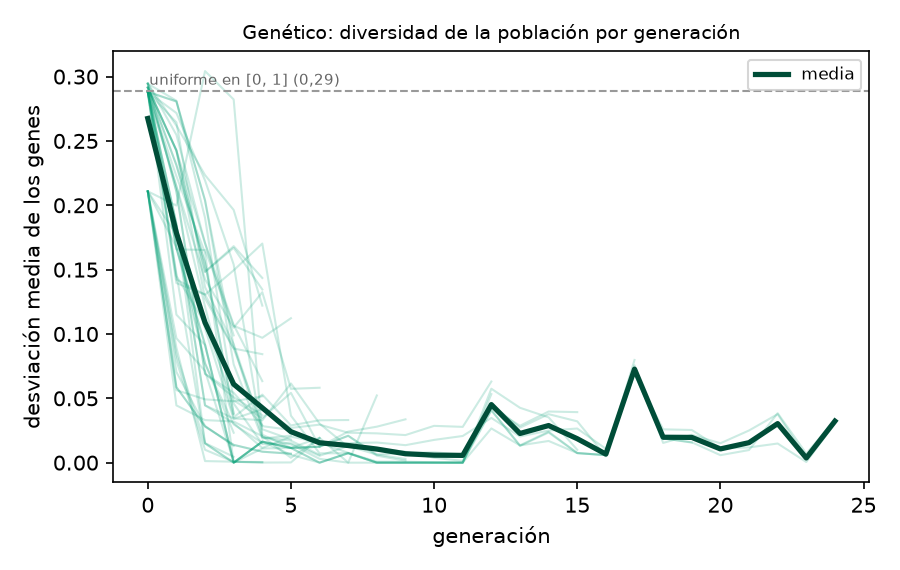

,brecha media (%) en t=6,brecha media (%) en t=12,brecha media (%) en t=24
azar,0.996,0.590,0.372
bayes,0.716,0.256,0.063
genetico,0.765,0.503,0.339
rejilla,1.680,1.041,0.554


In [5]:
display(Image(filename=str(F / "m15_1b_anytime.png")))
display(Image(filename=str(F / "m15_1b_diversidad_genetico.png")))
from cifras_15_1b import optimizadores
a = pd.read_csv(B / "anytime_15_1b.csv")
o = optimizadores(a)
pd.DataFrame({t: o[t]["media"] for t in (6, 12, 24)}).round(3).add_prefix("brecha media (%) en t=")

In [6]:
pd.DataFrame({t: {k: f"{v['dif']:+.3f} pp · gana {v['gana']:.0f} % · p {v['p']:.2g}" for k, v in o[t].items() if "_vs_" in k}
              for t in (6, 12, 24)})

,6,12,24
bayes_vs_azar,-0.280 pp · gana 60 % · p 0.045,-0.334 pp · gana 62 % · p 0.0011,-0.309 pp · gana 83 % · p 1e-07
genetico_vs_azar,-0.232 pp · gana 64 % · p 0.051,-0.087 pp · gana 52 % · p 0.19,-0.033 pp · gana 57 % · p 0.13
bayes_vs_rejilla,-0.964 pp · gana 64 % · p 0.0038,-0.785 pp · gana 76 % · p 5.3e-07,-0.491 pp · gana 69 % · p 6.2e-05
genetico_vs_rejilla,-0.916 pp · gana 74 % · p 0.0049,-0.538 pp · gana 74 % · p 0.00066,-0.215 pp · gana 60 % · p 0.033
bayes_vs_genetico,-0.048 pp · gana 43 % · p 0.57,-0.247 pp · gana 52 % · p 0.022,-0.276 pp · gana 62 % · p 0.0059


In [7]:
print("externo (WAPE medio en los 7 modelos × 6 meses):", {k: round(v, 5) for k, v in R["optimizadores_externo"]["wape_externo_medio"].items()})
print("Friedman sobre el resultado externo:", R["optimizadores_externo"]["friedman"])
print("tiempo de búsqueda medio (s):", {k: round(v) for k, v in R["optimizadores_externo"]["t_busqueda_medio_s"].items()})
pd.DataFrame(R["semillas"]["busquedas_xgboost_dic"]).T.round(5)

externo (WAPE medio en los 7 modelos × 6 meses): {'azar': 0.09181, 'bayes': 0.09187, 'genetico': 0.09186, 'rejilla': 0.09231}
Friedman sobre el resultado externo: {'estadistico': 7.337349397590361, 'p': 0.061888267563456785, 'N': 42}
tiempo de búsqueda medio (s): {'azar': 184, 'bayes': 140, 'genetico': 148, 'rejilla': 183}


,interno_media,interno_desv,externo_media,externo_desv,n
azar,0.08799,0.00043,0.10117,0.00101,5.0
bayes,0.08735,0.00022,0.10016,0.00028,5.0
genetico,0.08792,0.00077,0.10091,0.00079,5.0
hyperband,0.08913,0.00027,0.10118,0.00030,5.0


**Conclusión 4 · El bayesiano encuentra mejores configuraciones con el mismo presupuesto, pero en la prueba eso casi no se nota**
- **Búsqueda (bucle interno, 7 modelos × 6 meses = 42 casos).** Brecha media con el mejor valor hallado, a las 24 evaluaciones:
  bayesiano **0,063 %**, genético 0,339 %, azar 0,372 % y rejilla
  0,554 %. El bayesiano le gana al azar en el 83 % de los casos (Wilcoxon
  unilateral p < 0,0001) y al genético (p 0,0059); a las 12 evaluaciones ya lleva la mitad
  de la brecha del azar (0,256 frente a 0,590 %; p 0,0011).
  Solo en el 4,8 % de los casos no llega a 0,5 % del óptimo (rejilla 38,1 %,
  azar 26,2 %, genético 23,8 %).
- **El genético no le gana al azar** (p 0,1344): su diversidad cae de 0,267 a 0,061 en 3 generaciones
  (−77 %); con 24 evaluaciones converge antes de explorar (convergencia prematura).
- **Prueba (bucle externo):** WAPE medio rejilla 0,09231, azar 0,09181,
  bayesiano 0,09187 y genético 0,09186: Friedman p
  0,062. Las brechas de la búsqueda son de décimas de punto porcentual **relativo**, menores que el ruido entre meses.
- **Estabilidad (XGBoost, diciembre, 5 semillas):** el bayesiano tiene la menor dispersión en la búsqueda (desv. 0,00022 frente
  a 0,00043 del azar y 0,00077 del genético) y en la prueba
  (0,1002 ± 0,0003 frente a 0,1012 ± 0,0010).
- **Hyperband** (η = 3, fidelidades R/9, R/3 y R) hace 64 evaluaciones por el costo de 24 completas, pero en XGBoost queda por detrás
  (búsqueda 0,0891 frente a 0,0873 del bayesiano). Hipótesis: con pocos árboles el orden
  de las configuraciones no se conserva y descarta buenas demasiado pronto.
- Tiempo medio de búsqueda por tarea: bayesiano 140 s, genético 148 s,
  azar 184 s y rejilla 183 s: el bayesiano también evita las zonas caras.

## 5 · Comparación estadística jerárquica

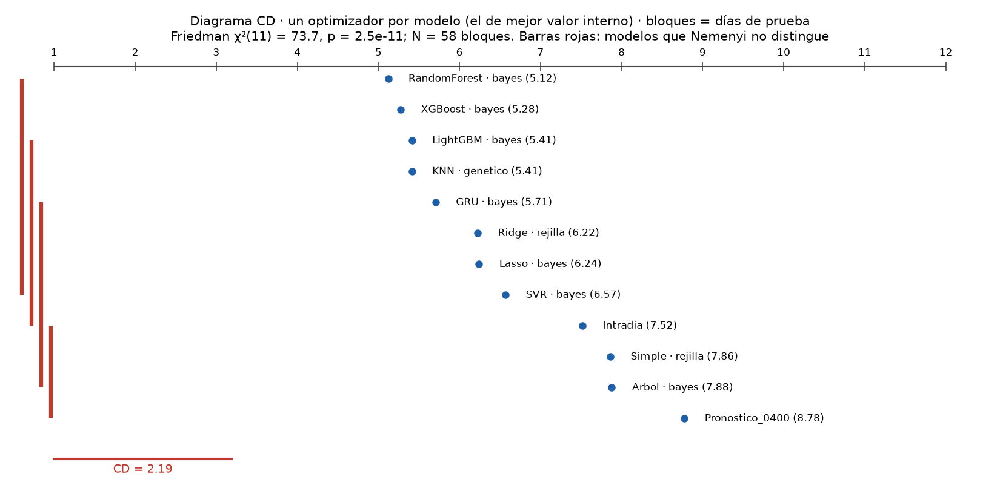

friedman_meses: χ²(36) = 109.1, p = 2.8e-09, k = 37, N = 6, CD = 24.06
friedman_dias: χ²(36) = 185.5, p = 5.1e-22, k = 37, N = 58, CD = 7.74
friedman_dias_representativos: χ²(11) = 73.7, p = 2.5e-11, k = 12, N = 58, CD = 2.19


,combo,perdida_media,p_mcs,en_conjunto
0,RandomForest · genetico,0.09142,1.0000,True
1,RandomForest · hyperband,0.09176,0.2920,True
2,RandomForest · bayes,0.09176,0.2920,True
3,KNN · rejilla,0.09210,0.3808,True
4,RandomForest · azar,0.09210,0.1234,True
5,KNN · azar,0.09220,0.3808,True
6,RandomForest · rejilla,0.09226,0.0356,False
7,KNN · bayes,0.09226,0.3808,True
8,KNN · genetico,0.09230,0.3808,True
9,XGBoost · genetico,0.09232,0.2920,True


In [8]:
display(Image(filename=str(F / "m15_1b_cd_representativos.png")))
E = R["estadistica"]
for k in ("friedman_meses", "friedman_dias", "friedman_dias_representativos"):
    f = E[k]; print(f"{k}: χ²({f['gl']}) = {f['estadistico']:.1f}, p = {f['p']:.2g}, k = {f['k']}, N = {f['N']}, CD = {f['CD']:.2f}")
mcs = pd.DataFrame(E["mcs"])[["combo", "perdida_media", "p_mcs", "en_conjunto"]]
mcs.round(5)

In [9]:
d = pd.DataFrame(E["dirigidas"])
d["estadístico"] = d[["GW", "CW", "DM_HLN"]].bfill(axis=1).iloc[:, 0]
d[["prueba", "a", "b", "estadístico", "p", "p_holm", "p_bh"]].round(4)

,prueba,a,b,estadístico,p,p_holm,p_bh
0,Giacomini-White,RandomForest · genetico,RandomForest · hyperband,5.1227,0.0772,1.0000,0.2597
1,Giacomini-White,RandomForest · genetico,RandomForest · bayes,4.7406,0.0935,1.0000,0.2881
2,Giacomini-White,RandomForest · genetico,KNN · rejilla,1.4846,0.4760,1.0000,0.6073
3,Giacomini-White,RandomForest · genetico,RandomForest · azar,9.9488,0.0069,0.2005,0.0284
4,Giacomini-White,RandomForest · genetico,KNN · azar,2.0752,0.3543,1.0000,0.5829
5,Giacomini-White,RandomForest · genetico,KNN · bayes,2.2422,0.3259,1.0000,0.5829
6,Giacomini-White,RandomForest · genetico,KNN · genetico,2.3139,0.3144,1.0000,0.5829
7,Giacomini-White,RandomForest · hyperband,RandomForest · bayes,1.2105,0.5459,1.0000,0.6475
8,Giacomini-White,RandomForest · hyperband,KNN · rejilla,1.1596,0.5600,1.0000,0.6475
9,Giacomini-White,RandomForest · hyperband,RandomForest · azar,4.1862,0.1233,1.0000,0.3259


In [10]:
pd.DataFrame(E["efecto"]).round(3)

,mejor,otro,cliff_delta,cohen_dz,dif_media_wape_pp
0,RandomForest · genetico,RandomForest · hyperband,-0.020,-0.279,-0.034
1,RandomForest · genetico,RandomForest · bayes,-0.019,-0.248,-0.035
2,RandomForest · genetico,KNN · rejilla,-0.036,-0.134,-0.068
3,RandomForest · genetico,RandomForest · azar,-0.024,-0.384,-0.069
4,RandomForest · genetico,KNN · azar,-0.042,-0.152,-0.078
5,RandomForest · genetico,KNN · bayes,-0.043,-0.170,-0.084
6,RandomForest · genetico,KNN · genetico,-0.044,-0.179,-0.088
7,RandomForest · genetico,Pronostico_0400,-0.325,-0.710,-1.147
8,RandomForest · genetico,Simple · rejilla,-0.243,-0.644,-0.759


**Conclusión 5 · El aprendizaje automático le gana con claridad al 04:00 y al estimador simple; entre los modelos de arriba no hay ganador**
- **Friedman** rechaza la igualdad: con los 6 meses como bloques (literal de la guía) χ²(36) = 109,1, p = 2,8 × 10^-9; con 6 bloques
  y 37 modelos la diferencia crítica de Nemenyi es 24,1 rangos: solo separa 14 pares: 7 combinaciones frente al 04:00
  (Random Forest, XGBoost bayesiano y KNN con rejilla), 3 frente al intradía y 3 frente al simple (Random Forest),
  y Random Forest con el genético frente al árbol con el genético. Con los 58 días como bloques, CD = 7,74.
- **Un modelo por tipo** (su optimizador de mejor valor interno; 12 modelos, 58 días; CD = 2,19): rangos medios Random Forest
  5,12, XGBoost 5,28, LightGBM 5,41,
  KNN 5,41, red 5,71, Ridge 6,22 … intradía
  7,52, simple 7,86, árbol 7,88 y 04:00
  8,78. Random Forest, XGBoost, LightGBM y KNN quedan a más de un CD del 04:00, del simple y del árbol.
- **MCS (α = 0,10):** quedan **19 de 37** combinaciones (Random Forest, KNN, XGBoost, LightGBM, la red, el SVR y Ridge con azar).
  Fuera: el 04:00, el intradía, el simple, los 4 árboles, los 4 Lasso y 3 de los 4 Ridge, entre otros.
- **Entre los 8 finalistas** (los de menor pérdida dentro del MCS): Giacomini-White en 28 pares, p crudo mínimo 0,0069;
  **ninguno sobrevive a Holm** (mínimo 0,20); con BH (tasa de falsos descubrimientos del 5 %) solo uno, RandomForest · genetico frente a RandomForest · azar
  (p BH 0,028): el mismo Random Forest con dos búsquedas distintas.
- **Clark-West contra el 04:00** (modelo anidado: razón = 1): los 8 finalistas lo mejoran, CW 5,86–6,84, p Holm < 0,0001.
- **Diebold-Mariano HLN** del mejor (RandomForest · genetico) contra el segundo (RandomForest · hyperband): diferencia 0,034 puntos de WAPE diario,
  HLN 2,05, p crudo 0,045, IC95 % bootstrap estacionario [0,004; 0,065] puntos;
  **con Holm p = 1,00 y con BH p = 0,166: no significativo** dentro de la familia de comparaciones.
- **Tamaño del efecto** (pérdidas diarias): frente al 04:00, δ de Cliff −0,32 y d de Cohen −0,71
  (−1,15 puntos de WAPE); frente al simple, −0,24 y −0,64. Entre finalistas,
  δ de Cliff de −0,044 a −0,019: **despreciable** (|δ| < 0,147).

## 6 · Residuos del mejor modelo

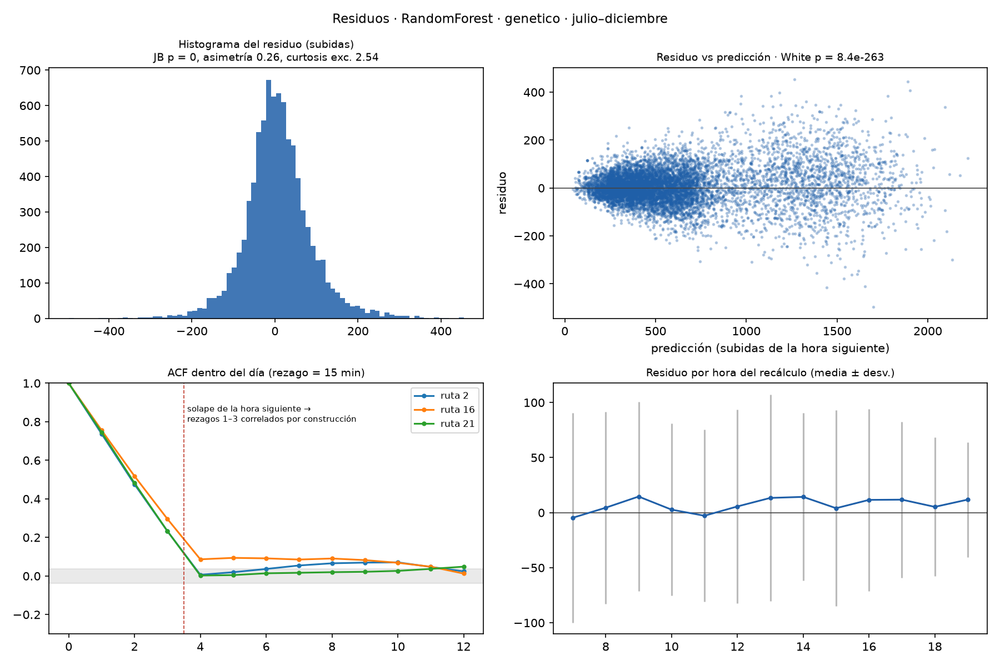

,RMSE,MAE,p White,"p BDS (m=2, mín. por ruta)",JB
RandomForest · genetico,81.154,58.931,0.0,0.0,2376.816
Arbol · bayes,85.135,61.756,0.0,0.0,2324.456
GRU · bayes,83.452,60.604,0.0,0.0,2372.507
Intradia,85.528,63.344,0.0,0.0,1805.617
KNN · genetico,81.868,59.419,0.0,0.0,2402.355
Lasso · bayes,82.108,59.852,0.0,0.0,2146.194
LightGBM · bayes,82.156,59.639,0.0,0.0,2347.687
Pronostico_0400,88.522,65.719,0.0,0.0,1794.634
RandomForest · bayes,81.568,59.186,0.0,0.0,2455.628
Ridge · rejilla,82.025,59.812,0.0,0.0,2100.287


In [11]:
display(Image(filename=str(F / "m15_1b_residuos_mejor.png")))
pd.DataFrame({k: {"RMSE": v["rmse"], "MAE": v["mae"], "p White": v["p_white"], "p BDS (m=2, mín. por ruta)": v["p_bds_m2"],
                  "JB": v["detalle"]["jarque_bera"]["JB"]} for k, v in R["residuos"].items()}).T.round(3)

**Conclusión 6 · Los residuos no son ruido blanco, y la mayor parte se explica por cómo se arma el objetivo**
- **Autocorrelación:** dentro del día, ρ(15 min) = 0,74–0,76, ρ(30 min) = 0,48–0,52 y
  ρ(45 min) = 0,23–0,30, y cae a ~0 a la hora (rutas 2 y 21: 0,006 y 0,003).
  Es lo esperado: dos recálculos separados por menos de 1 h predicen salidas compartidas (la «hora siguiente» se solapa), un MA(3) por construcción.
  **La ruta 16 conserva algo más** (ρ a 60 y 75 min = 0,087 y 0,094). Ljung-Box rechaza en los 4 rezagos de
  las 3 rutas porque acumula esos primeros rezagos.
- **Heterocedasticidad:** White rechaza (p ≈ 0); |residuo| y predicción tienen correlación 0,43: el error crece con el volumen,
  como en el resto del proyecto (varianza que crece con la media).
- **BDS** rechaza con z = 52–57, pero se aplicó al residuo sin filtrar el MA(3): mide sobre todo esa dependencia lineal,
  no es evidencia de no linealidad por sí sola.
- **Normalidad:** Jarque-Bera rechaza (asimetría 0,26, curtosis en exceso 2,54): colas más pesadas que la normal.
- **Los 13 modelos diagnosticados rechazan White y BDS**: es un rasgo del problema, no de un modelo. Para la cascada importa el sesgo
  (−1,1 %) y la escala del error, que se usa como margen al convertir subidas en salidas.

## 7 · Interpretabilidad: SHAP (TreeSHAP) y LIME

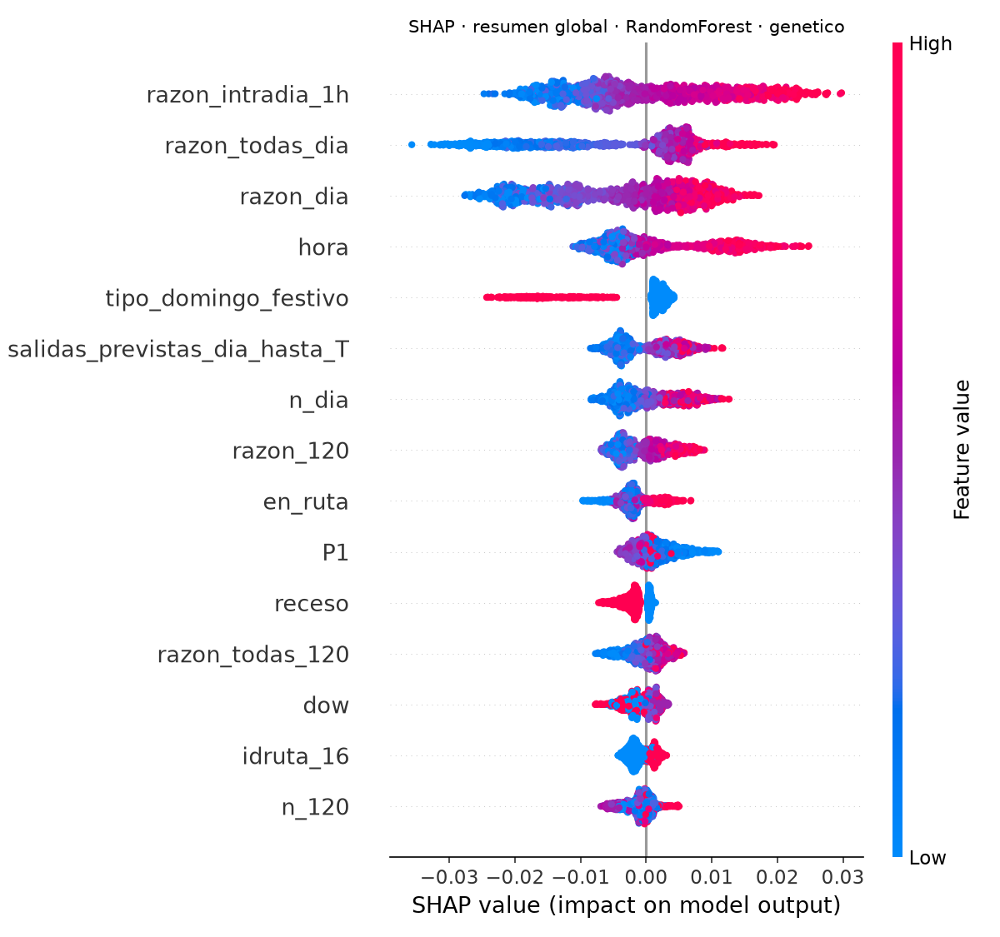

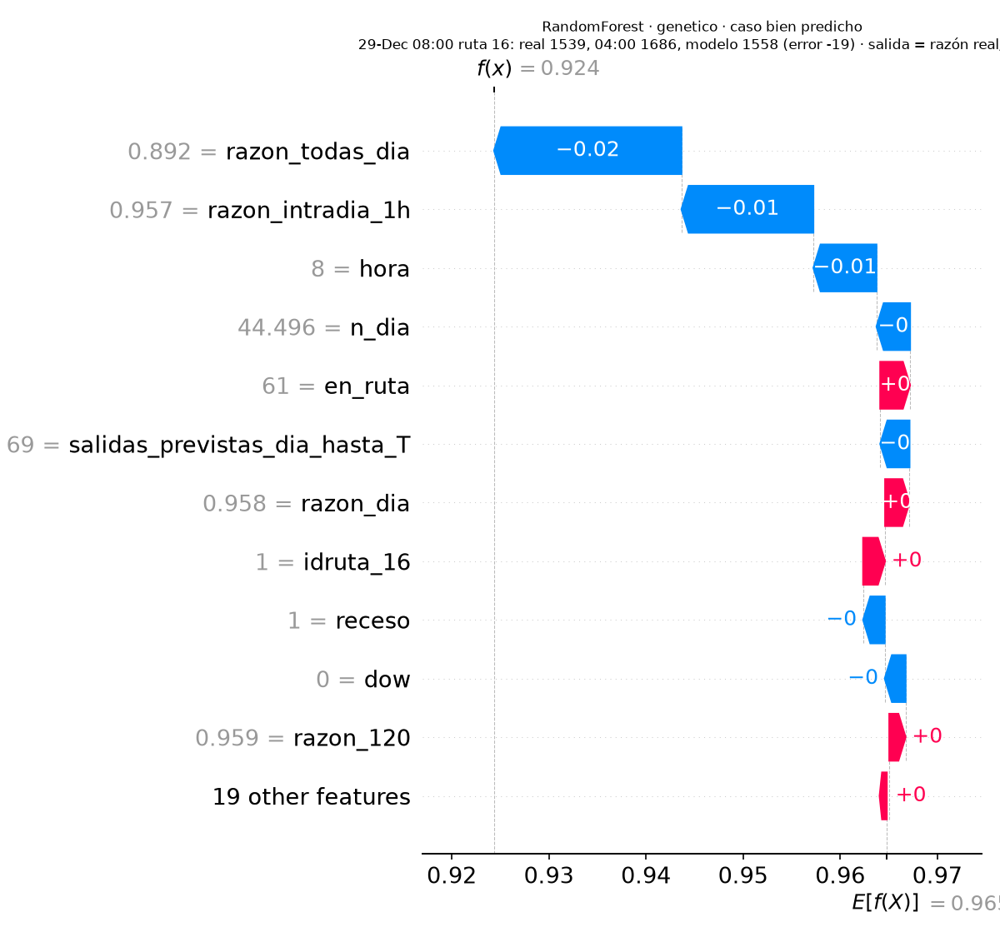

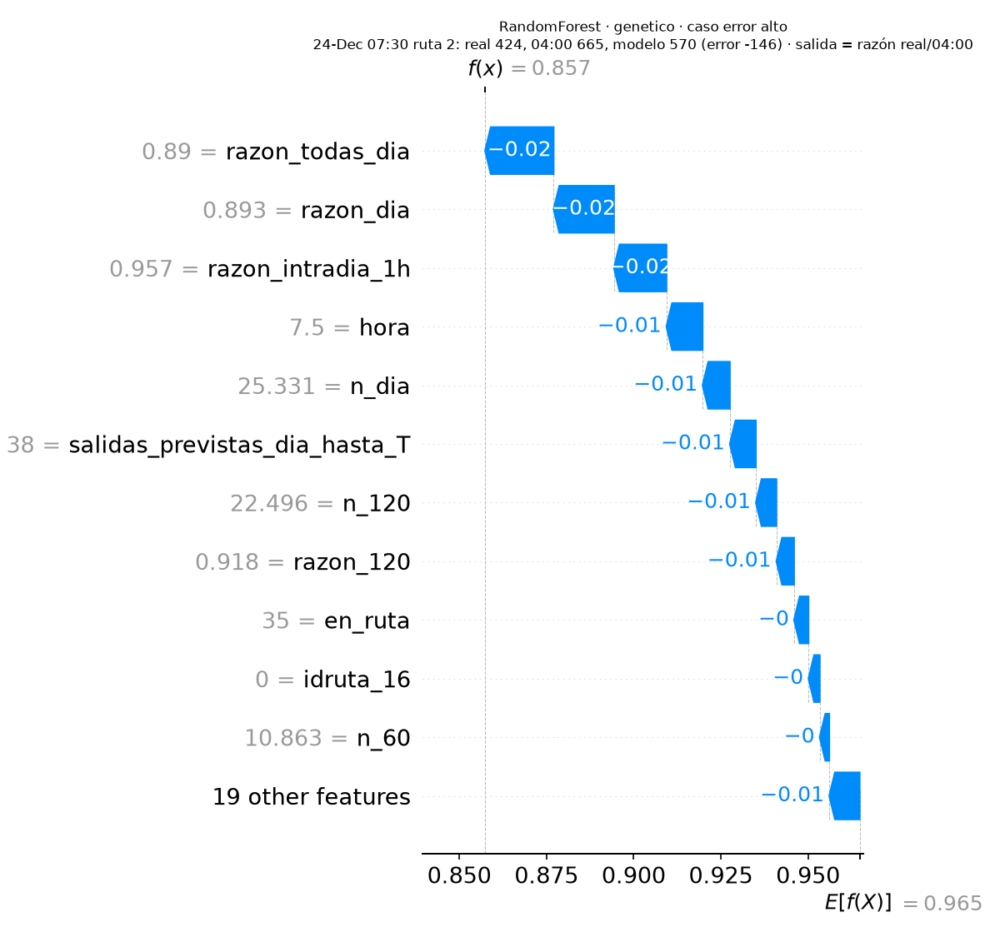

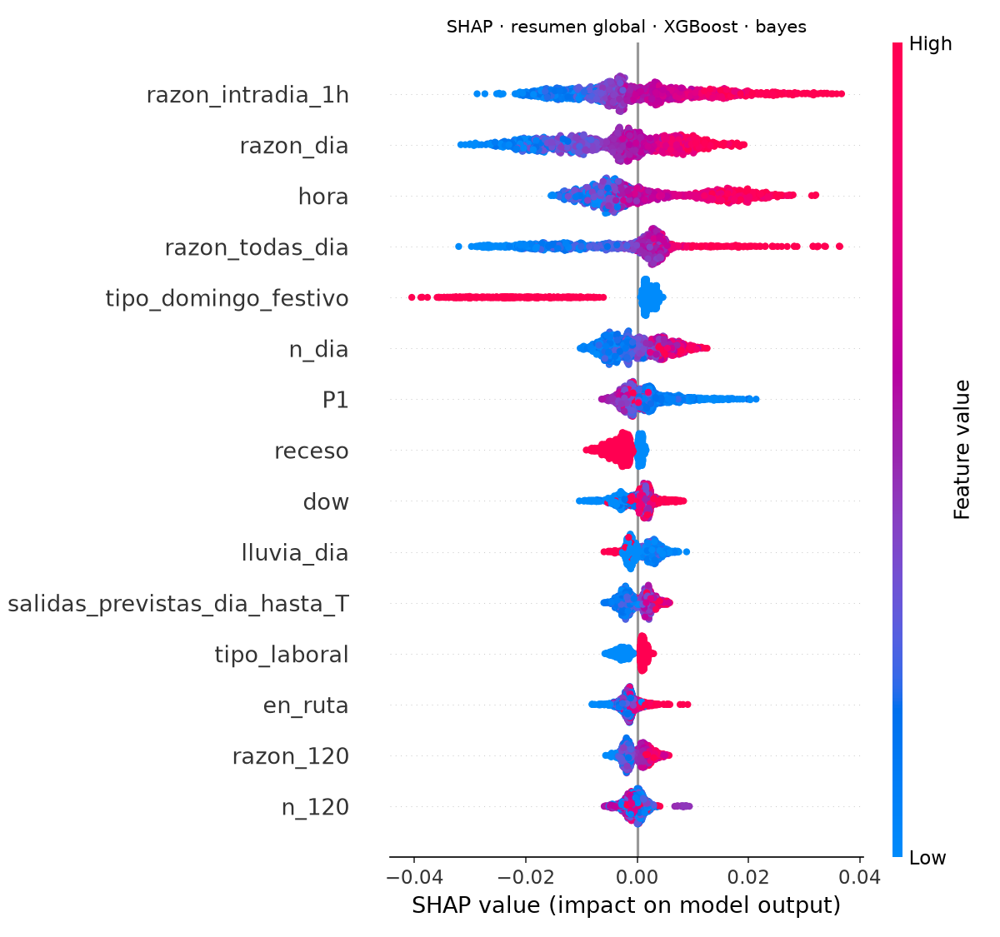

,XGBoost · bayes,RandomForest · genetico
P1,0.0032,0.0024
dow,0.0023,0.0018
en_ruta,0.0019,0.0027
hora,0.0085,0.0066
idruta,0.0016,0.0022
lluvia_dia,0.0022,NaN
n_120,0.0013,0.0016
n_dia,0.0041,0.0038
razon_120,0.0018,0.0031
razon_dia,0.0091,0.0096


In [12]:
for f in ("m15_1b_shap_randomforest_resumen.png", "m15_1b_shap_randomforest_waterfall_bien.png", "m15_1b_shap_randomforest_waterfall_mal.png",
          "m15_1b_shap_xgboost_resumen.png"):
    display(Image(filename=str(F / f)))
I = R["interpretabilidad"]
pd.DataFrame({k: pd.Series(v["importancia"]) for k, v in I.items()}).round(4)

In [13]:
for k, v in I.items():
    for caso, x in v["lime_vs_shap"].items():
        print(f"{k} · {caso}: R² local de LIME {x['r2_local']:.2f}; coinciden {x['coinciden_top5']} de las 5 primeras")
        print("   LIME:", [n for n, _ in x["lime"][:5]]); print("   SHAP:", [n for n, _ in x["shap_top"][:5]])

XGBoost · bayes · bien: R² local de LIME 0.42; coinciden 4 de las 5 primeras
   LIME: ['razon_intradia_1h > 1.01', 'tipo_domingo_festivo <= 0.00', 'razon_dia > 1.01', 'razon_todas_dia > 1.01', 'hora <= 9.25']
   SHAP: ['razon_intradia_1h', 'razon_dia', 'razon_todas_dia', 'hora', 'receso']
XGBoost · bayes · mal: R² local de LIME 0.45; coinciden 4 de las 5 primeras
   LIME: ['razon_intradia_1h > 1.01', 'tipo_domingo_festivo <= 0.00', 'razon_dia <= 0.91', 'razon_todas_dia <= 0.94', 'hora <= 9.25']
   SHAP: ['razon_dia', 'razon_todas_dia', 'razon_intradia_1h', 'hora', 'n_dia']
RandomForest · genetico · bien: R² local de LIME 0.37; coinciden 4 de las 5 primeras
   LIME: ['razon_todas_dia <= 0.94', 'razon_intradia_1h <= 0.97', 'tipo_domingo_festivo <= 0.00', 'hora <= 9.25', 'en_ruta > 40.00']
   SHAP: ['razon_todas_dia', 'razon_intradia_1h', 'hora', 'n_dia', 'en_ruta']
RandomForest · genetico · mal: R² local de LIME 0.52; coinciden 4 de las 5 primeras
   LIME: ['razon_todas_dia <= 0.94', 'ra

**Conclusión 7 · Los modelos corrigen el 04:00 con lo que el sensor ya vio hoy, sobre todo en la última hora**
- **Global (|SHAP| medio, diciembre):** en RandomForest · genetico, las 5 primeras son razon_intradia_1h, razon_todas_dia, razon_dia, tipo, hora; en XGBoost, razon_intradia_1h, razon_dia, tipo, hora, razon_todas_dia.
  Las tres «razones» son lo contado frente a lo previsto (la última hora, la ruta en el día y las 3 rutas en el día). El pronóstico mismo (P1)
  queda en el puesto 10 y 7: el modelo no reaprende el nivel, lo corrige.
- **Caso bien predicho (RandomForest · genetico):** 29-dic 08:00, ruta 16: real 1.539, pronóstico 04:00 1.686, modelo 1.558. La razón del día y de la última hora venían bajas y el modelo bajó la predicción
  a tiempo.
- **Caso con error alto:** la víspera de Navidad, 24-dic 07:30, ruta 2: real 424, pronóstico 04:00 665, modelo 570. El modelo corrigió en la dirección correcta, pero se quedó
  corto: a las 07:30 el sensor todavía había visto poco de un día atípico.
- **LIME frente a SHAP:** coinciden 4 de las 5 variables principales en los 4 casos, pero el ajuste local de LIME es débil
  (R² 0,37–0,52) y sus pesos dependen
  de cómo discretiza cada variable y del muestreo de perturbaciones. SHAP reparte exactamente la predicción
  (TreeSHAP exacto), así que es la referencia; LIME sirve como contraste.

## 8 · Robustez: meses y semillas

In [14]:
pd.DataFrame({k: {"desv. por semilla (media de los 6 meses)": v["desv_por_semilla_media"], "desv. entre meses": v["desv_entre_meses"],
                  **{f"WAPE semilla {s}": x for s, x in v["wape_por_semilla"].items()}} for k, v in R["semillas"]["modelos"].items()}).T.round(5)

,desv. por semilla (media de los 6 meses),desv. entre meses,WAPE semilla 1515,WAPE semilla 1516,WAPE semilla 1517,WAPE semilla 1518,WAPE semilla 1519
GRU,0.00210,0.00751,0.09264,0.09231,0.09334,0.09285,0.09203
LightGBM,0.00016,0.00572,0.09124,0.09138,0.09134,0.09138,0.09135
RandomForest,0.00016,0.00616,0.09058,0.09072,0.09075,0.09057,0.09074
XGBoost,0.00028,0.00667,0.09116,0.09096,0.09122,0.09141,0.09118


**Conclusión 8 · Los modelos de árboles son estables; la red depende de la semilla**
- Mismos hiperparámetros, 5 semillas, 6 meses: la desviación por semilla es 0,00016 (Random Forest),
  0,00016 (LightGBM) y 0,00028 (XGBoost): unas 20–40 veces menor que la
  variación entre meses (0,0062–0,0067).
- **La red recurrente** tiene desviación por semilla 0,0021 (WAPE de 0,0920 a
  0,0933 según la semilla), casi un tercio de su variación entre meses
  (0,0075). Con 58–107 días de entrenamiento, el límite que se anticipó en el alcance se cumplió: la red no aporta sobre
  los árboles y es la menos estable.

## 9 · Complejidad computacional: teoría frente a lo medido

In [15]:
e = pd.read_csv(B / "complejidad_escalamiento.csv")
display(e.pivot(index="n", columns="modelo", values="t_entrenar_s").round(3))
display(e.groupby("modelo")[["pendiente_entrenar", "pendiente_predecir", "pendiente_teorica"]].first().round(2))
pd.read_csv(B / "complejidad_estandar_vs_optimizado.csv").round(4)

modelo,Arbol,KNN,Lasso,LightGBM,RandomForest,Ridge,SVR,XGBoost
n,,,,,,,,
1000,0.032,0.030,0.034,0.216,2.608,0.033,0.456,0.442
2000,0.050,0.033,0.043,0.270,3.265,0.039,0.922,0.612
4000,0.093,0.046,0.066,0.362,4.926,0.051,1.737,0.833
8000,0.192,0.073,0.455,0.512,8.508,0.086,3.489,1.122
15000,0.312,0.122,0.865,0.717,15.258,0.141,6.667,1.581


,pendiente_entrenar,pendiente_predecir,pendiente_teorica
modelo,,,
Arbol,0.87,-0.05,1.1
KNN,0.53,0.65,1.0
Lasso,1.30,-0.06,1.0
LightGBM,0.45,-0.12,1.0
RandomForest,0.66,0.15,1.1
Ridge,0.54,-0.06,1.0
SVR,0.98,-0.01,1.0
XGBoost,0.46,0.07,1.0


,familia,version,n,t_entrenar_s,t_predecir_s,wape_dic,recall_40,arboles
0,KNN,brute,16982,0.0230,0.1274,0.1040,NaN,NaN
1,KNN,kd_tree,16982,0.0957,0.7545,0.1040,NaN,NaN
2,KNN,ball_tree,16982,0.0664,0.6421,0.1040,NaN,NaN
3,KNN,FAISS exacto (IndexFlatL2),16982,0.0006,0.1916,0.1040,NaN,NaN
4,KNN,"FAISS aproximado (HNSW, M = 32)",16982,0.6585,0.0282,0.1042,0.9412,NaN
5,SVR,"RBF completo (SVR, libsvm)",1000,0.0490,0.0692,0.1070,NaN,NaN
6,SVR,Nyström m=600 + LinearSVR,1000,0.4298,0.0455,0.1071,NaN,NaN
7,SVR,SGD ε-insensible (lineal),1000,0.0093,0.0061,0.1091,NaN,NaN
8,SVR,"RBF completo (SVR, libsvm)",2000,0.1584,0.1447,0.1053,NaN,NaN
9,SVR,Nyström m=600 + LinearSVR,2000,0.6859,0.0430,0.1053,NaN,NaN


In [16]:
pd.read_csv(B / "complejidad_paralelo.csv").round(3)

,backend,n_jobs,t_s,mejor,aceleracion
0,loky,1,80.597,0.089,1.000
1,loky,2,43.275,0.089,1.862
2,loky,4,27.816,0.089,2.897
3,loky,8,20.420,0.089,3.947
4,loky,12,14.636,0.089,5.507
5,threading,1,75.621,0.089,1.000
6,threading,2,39.848,0.089,1.898
7,threading,4,21.589,0.089,3.503
8,threading,8,17.060,0.089,4.433
9,threading,12,13.937,0.089,5.426


**Conclusión 9 · Lo optimizado ayuda donde la teoría lo predice, y el KD-tree no ayuda en 30 dimensiones**
- **Escalamiento (1.000 → 15.000 filas):** la pendiente log-log del entrenamiento queda por debajo de la teórica en casi todos (KNN 0,53,
  Ridge 0,54, XGBoost 0,46, LightGBM 0,45, Random Forest 0,66) porque a este tamaño pesa el costo fijo;
  el SVR con Nyström crece lineal (0,98, teoría 1) y Lasso por encima (1,30; probablemente necesita más iteraciones para converger con más filas).
  Random Forest es el más caro (15,3 s con 15.000 filas, 300 árboles); predecir es barato en todos.
- **SVR:** el núcleo RBF completo crece con pendiente 1,83 (≈ n², como dice la teoría) frente a 0,82 con Nyström; con 8.000 filas
  entrenar cuesta lo mismo (2,22 frente a 2,37 s), pero predecir es 12 veces más
  lento con el completo, con el mismo WAPE (0,1073 frente a 0,1077).
- **KNN (16.982 filas, 30 dimensiones tras el one-hot):** el KD-tree es **más lento** que la fuerza bruta al predecir (0,75 frente a
  0,13 s): en 30 dimensiones el árbol no poda (maldición de la dimensionalidad). FAISS HNSW predice en
  0,028 s con recall@40 de 0,94 y el mismo WAPE.
- **XGBoost (15.394 filas):** `hist` entrena 9,5 veces más rápido que `exact`; con parada temprana
  en una validación independiente (noviembre) para en 170 árboles y tarda 0,81 s,
  con WAPE 0,1012 (exacto con 400: 0,1023).
- **Ridge:** Cholesky es 32 veces más rápido que SAGA con 30 columnas (SAGA conviene cuando n y p son grandes).
  Lasso por coordenadas: 1,13 s; con SGD-L1, 0,05 s y algo más de error.
- **Paralelismo (rejilla de XGBoost, 24 configuraciones):** con 12 trabajadores, 5,5 veces más rápido con procesos (loky) y
  5,4 con hilos (XGBoost suelta el GIL). No llega a 12: el PC reporta 12 procesadores lógicos y hay
  costo de arranque y de copiar los datos a cada trabajador.

## 10 · Prueba limpia de la regla de domingos (días nuevos)

In [17]:
G = json.loads(Path("datos_15/15_1b/domingos/resultados_domingos.json").read_text(encoding="utf-8"))
print("días:", G["dias_utilizables"], "· filas:", G["filas"], "· criterio:", G["criterio"])
display(pd.DataFrame(G["metricas"]).T.round(4))
pd.DataFrame(G["perdidas_diarias"]).T.assign(dif_RF_menos_Ridge=lambda d: d.RandomForest - d.Ridge).round(4)

días: 38 · filas: 5536 · criterio: {'decision': 'adoptar la regla (RF en domingos y festivos)', 'p_wilcoxon': 0.04495197675714735, 'condicion_1': True, 'condicion_2': True}


,wape,mae,rmse,sesgo_pct,n
Ridge,0.1135,41.5384,55.4563,-0.7039,5536.0
RandomForest,0.1108,40.5431,54.3551,-0.2614,5536.0
Pronostico_0400,0.1331,48.7066,63.6073,5.7916,5536.0
Intradia,0.1295,47.3754,61.7508,4.9162,5536.0
Simple,0.1327,48.5432,62.5586,6.2792,5536.0


,Ridge,RandomForest,Pronostico_0400,Intradia,Simple,dif_RF_menos_Ridge
2025-01-01,0.2054,0.2028,0.2397,0.2030,0.2408,-0.0026
2025-01-05,0.1116,0.1105,0.1928,0.1811,0.1534,-0.0012
2025-01-06,0.1069,0.1002,0.1067,0.1102,0.1172,-0.0067
2025-01-12,0.1008,0.0977,0.1591,0.1331,0.1498,-0.0031
2025-02-02,0.1084,0.1148,0.0997,0.0999,0.1036,0.0064
2025-02-09,0.0822,0.0774,0.1063,0.1073,0.1028,-0.0048
2025-03-09,0.1028,0.0849,0.1342,0.1364,0.1384,-0.0180
2025-03-16,0.0830,0.0838,0.0939,0.0956,0.1014,0.0007
2025-03-23,0.1035,0.1062,0.1248,0.1178,0.1340,0.0027
2025-04-06,0.0932,0.0910,0.0877,0.0893,0.0978,-0.0023


**Conclusión 10 · En días que ningún modelo vio, Random Forest le gana a Ridge en domingos y festivos, por poco**
- **Por qué esta prueba:** la ventaja de Random Forest en domingos se vio en los mismos días de prueba de la batería; decidir con ellos sería ajustarse
  a la prueba. Se congelaron la regla y los dos modelos (13:23) antes de elegir los días (13:37), con un criterio escrito.
- **Días nuevos:** 38 (28 domingos y 10 festivos de 2025, fuera de E5), todos con sensor; 5.536 recálculos.
- **WAPE de la hora siguiente:** 04:00 0,1331 · simple 0,1327 · intradía 0,1295 ·
  Ridge 0,1135 · **Random Forest 0,1108**.
- **Criterio:** Random Forest menor que Ridge y Wilcoxon unilateral p = 0,045 < 0,05 → **se adopta la regla**
  (Random Forest en domingos y festivos, Ridge el resto). Gana en 25 de 38 días; δ de Cliff −0,13 (despreciable).
- **El efecto es pequeño** (−0,27 puntos; ≈ 1 subida por hora y ruta) y más chico que en la batería: lo esperado
  cuando un efecto se encuentra mirando los datos. **Y confirma la conclusión principal en días nuevos:** los dos modelos le ganan con amplitud al 04:00
  (17 % y 15 % menos error).

## 11 · Complementos del alcance: desgloses, días de control, demanda inyectada y resto del día

In [18]:
K = Path("datos_15/15_1b/complementos")
display(pd.read_csv(K / "desgloses.csv").round(4))
display(pd.read_csv(K / "resto_dia.csv").round(4))
display(pd.read_csv(K / "control_E4.csv").round(4))
pd.read_csv(K / "inyeccion_resumen.csv").round(3)

,dimension,grupo,filas,dias,Ridge,RandomForest,Pronostico_0400,Intradia,Simple,Regimen,mejora_regimen_vs_0400_pct
0,ruta,16,2842,58,0.0783,0.0771,0.0820,0.0802,0.0816,0.0777,5.2654
1,ruta,2,2838,58,0.1052,0.1037,0.1227,0.1161,0.1135,0.1048,14.5978
2,ruta,21,2831,58,0.1106,0.1089,0.1237,0.1187,0.1146,0.1099,11.1656
3,tipo,domingo_festivo,1762,12,0.1019,0.0971,0.1190,0.1183,0.1193,0.0971,18.3528
4,tipo,laboral,4988,34,0.0890,0.0883,0.0983,0.0938,0.0925,0.0890,9.4495
5,tipo,sabado,1761,12,0.0920,0.0906,0.0951,0.0926,0.0930,0.0920,3.1946
6,franja,07–09 h,1565,58,0.0859,0.0836,0.0983,0.0918,0.0929,0.0858,12.6817
7,franja,09–12 h,2088,58,0.0915,0.0895,0.1086,0.1014,0.0982,0.0904,16.7313
8,franja,12–16 h,2780,58,0.0826,0.0827,0.0883,0.0867,0.0859,0.0821,7.0060
9,franja,16–19 h,2078,58,0.1175,0.1151,0.1177,0.1186,0.1201,0.1169,0.6624


,modelo,wape_hora_siguiente,wape_resto_dia,pct_recalculos_mejor_que_0400,pct_recalculos_peor_que_0400
0,Ridge,0.0912,0.0493,56.8558,43.1442
1,RandomForest,0.0899,0.0509,57.3376,42.6624
2,Pronostico_0400,0.1002,0.0518,NaN,NaN
3,Intradia,0.0966,0.0479,55.0229,44.9771
4,Simple,0.0960,0.0503,54.9994,44.9066
5,Regimen,0.0906,0.0494,56.8323,43.1677


,fecha,tipo,filas,Ridge,RandomForest,Regimen,Pronostico_0400,Intradia,Simple
0,2025-08-19,laboral,147,0.0899,0.0870,0.0899,0.0912,0.0946,0.0831
1,2025-09-20,sabado,147,0.0975,0.0949,0.0975,0.0992,0.0967,0.0985
2,2025-11-09,domingo_festivo,147,0.0995,0.1003,0.1003,0.1161,0.1072,0.1299
3,los 3,NaN,441,0.0945,0.0925,0.0947,0.0993,0.0980,0.0984


,modelo,mediana_a_15,mediana_a_30,mediana_a_60,mediana_a_120,media_a_15,media_a_30,media_a_60,media_a_120,min_hasta_la_mitad_mediana,pct_llega_a_la_mitad_en_120
0,RandomForest,0.001,0.003,0.012,0.044,0.003,0.008,0.023,0.064,inf,0.383
1,Regimen,0.002,0.005,0.011,0.023,0.004,0.008,0.016,0.033,inf,0.000
2,Ridge,0.003,0.005,0.011,0.023,0.004,0.008,0.013,0.025,inf,0.000
3,Simple,0.002,0.004,0.014,0.046,0.002,0.006,0.020,0.056,inf,0.000


**Conclusión 11 · La corrección rinde más donde el 04:00 falla más, y reacciona lento a un cambio brusco**
- **Desgloses** («régimen» = Ridge, con Random Forest en domingos y festivos; mejora frente al 04:00): domingos y festivos
  **18 %**, laborales 9 % y sábados
  3 %; ruta 2 15 %, ruta 21 11 % y ruta 16
  5 % (la mejor pronosticada); de 07 a 12 h 13–17 %,
  pero **de 16 a 19 h casi nada (0,7 %)**. Con partido 6 % y en
  receso escolar 10 %. Con lluvia ≥ 10 mm/h solo hay 21 recálculos de
  1 día: no se concluye nada.
- **Resto del día** (aplicando la razón de la hora siguiente a todo el resto): 04:00 0,0518, régimen
  0,0494, **intradía 0,0479 (el mejor)**. Para el resto del día conviene el intradía.
- **Recálculo por recálculo**, el régimen mejora al 04:00 en el **56,8 %** (la 15.1 pedía 60 %: tampoco se cumple aquí).
  **La mejora se concentra donde el 04:00 se equivoca más:** en el quinto de recálculos con más error del 04:00, el régimen mejora el
  84 % y baja el error 23 %; en el quinto con menos error empeora (mejora solo el
  16 %), porque ahí el 04:00 ya casi acertaba.
- **Días de control (E4, 3 días, modelos congelados):** régimen 0,0947 frente a 04:00 0,0993; el domingo 9-nov,
  Random Forest 0,1003 y Ridge 0,0995 (04:00 0,1161); el laboral 19-ago lo
  gana el simple (0,0831). Con 3 días es anecdótico.
- **Demanda inyectada** (×0,85 … ×1,2 desde las 8, 11 y 14 h, 58 días): **a las 2 h, los modelos captan una fracción mínima del cambio**
  (mediana: Ridge 0,023, Random Forest 0,044, simple 0,046; P90 de Random Forest
  0,17) y casi nunca llegan a la mitad en 2 h. Es más lento a medida que avanza el día (Ridge: 0,052 desde las 8 h y
  0,010 desde las 14 h). Razón probable: un viaje cuenta sus subidas durante ~4 h y los modelos se apoyan en el nivel del día, así que un
  cambio brusco llega diluido. **El pronóstico inmediato corrige el sesgo del día; no detecta a tiempo un cambio repentino.** En la cascada, eso lo
  tienen que cubrir las señales operativas (eventos del Módulo 10, flota y buses pegados), como ya advirtió la 15.1 (O2).

## 12 · Qué entra a la cascada

**Conclusión 12 · Corregir el 04:00 con el sensor sí ayuda; el modelo exacto importa poco**
- El mejor modelo de la batería baja el error de la hora siguiente un **10,3 %** frente al 04:00 y un **6,4 %** frente al estimador
  simple de la 15.1, con evidencia fuerte (Clark-West, MCS, Friedman-Nemenyi), y se confirma en 38 días nuevos (conclusión 10).
- Entre Random Forest, KNN, XGBoost, LightGBM, la red, el SVR y Ridge la estadística no distingue. **Decisión de la Persona 3 (9-nov-2026): Ridge**
  (lineal, legible, 108 veces más rápido de entrenar), **con Random Forest en domingos y festivos** por la prueba limpia (conclusión 10).
- **Primera tarea de la 15.3:** comprobar si esa diferencia cambia las salidas de la cascada en los días de E6; si casi nunca, «mejor pronóstico, mismo despacho».
- **Límites:** 116 días de entrenamiento (10 por mes); un solo año; la red recurrente queda limitada por los datos; reacciona lento a cambios bruscos
  (conclusión 11); el «sensor» de la cascada en el simulador es el del Módulo 13, no el real, así que la ganancia en la 15.4 puede ser distinta.

<a id="m15-3"></a>

### A2.8.3 &middot; Subfase 15.4 · Evaluación oficial del despacho en cascada

<sub>Notebook original: `modulo15/subfase_15_4_evaluacion.ipynb`</sub>  &middot;  <sub>[&#8679; volver al índice](#indice)</sub>

# SOBUSA · Módulo 15 · Subfase 15.4 — Evaluación oficial del despacho en cascada

**Persona 3.** ¿Qué estrategia de despacho deja más ganancia frente al plan real de SOBUSA sin pasar el límite de
espera (regla D7)? ¿Cuánto agrega recalcular durante el día (cascada) sobre el plan fijo de las 04:00? ¿Y el MILP del
Módulo 14 sobre la cascada, con y sin La Playa?

- Alcance aprobado: `revisiones/alcance_15_4.md` (9-nov-2026, 18:34; E1 250 réplicas, E2 sensibilidad, E3 tandas,
  E4 brazo `fijo_presupuesto`). Configuración congelada de la 15.3: `config/cascada_15_3.yaml` (sha256 `f329379547239bee…`).
- **12 brazos** (6 el domingo, sin MILP, A2) × **6 estratos** de la 14.3 × **250 réplicas** = **16.500 días**
  simulados; semillas nuevas 200000 + 10.000 × estrato + réplica, iguales entre brazos (pareadas); demanda «real» (D4).
- **Ganancia** frente al real, réplica a réplica: (km del real − km) × 3.000 − (espera − espera del real) × pasajeros del
  real × 100 + (pasajeros − pasajeros del real) × tarifa (0). **Regla D7:** por tipo de día, la de mayor ganancia
  mediana con espera ≤ real + 1 min (mediana de la diferencia pareada).
- Dos partes del proyecto (CLAUDE.md §16): **sin La Playa** = brazos real, fijo, fijo_presupuesto, cascada y cascada +
  MILP solo terminal; **con redespacho en La Playa** = cascada + MILP oficial.
- Este notebook no simula: lee `datos_15/15_4/reporte/` (de `reporte_15_4.py`) y las figuras.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
D = Path("datos_15/15_4/reporte")
el = json.loads((D / "eleccion_15_4.json").read_text(encoding="utf-8"))
t7 = pd.read_csv(D / "d7_15_4.csv"); pr = pd.read_csv(D / "pruebas_15_4.csv")
sens = pd.read_csv(D / "sensibilidad_15_4.csv"); sec = pd.read_csv(D / "secundarios_15_4.csv")
milp = pd.read_csv(D / "milp_15_4.csv")
print(el["dias"], "días ·", el["replicas_por_estrato"]); print(el["equipos"])

16500 días · {'domingo_central': 250, 'laboral_alta': 250, 'laboral_central': 250, 'laboral_lluvia': 250, 'laboral_partido': 250, 'sabado_central': 250}
{'<equipo> · Windows 11 · Python 3.12.0': 13293, 'Nitro · Windows 11 · Python 3.12.0': 3207}


## 1 · La corrida: equipos y reproducibilidad

In [2]:
rp = Path("datos_15/15_4/reproducibilidad_15_4.csv")
if rp.exists():
    t = pd.read_csv(rp)
    display(t[["estrato", "brazo", "identico", "kpi_distintos", "milp_limite_tiempo_original", "milp_limite_tiempo_aqui",
               "d_espera_media_min", "d_km_totales"]])

,estrato,brazo,identico,kpi_distintos,milp_limite_tiempo_original,milp_limite_tiempo_aqui,d_espera_media_min,d_km_totales
0,laboral_central,real,True,NaN,0.0,0.0,0.0,0.0
1,laboral_central,fijo,True,NaN,0.0,0.0,0.0,0.0
2,laboral_central,fijo_presupuesto,True,NaN,0.0,0.0,0.0,0.0
3,laboral_central,cascada_15,True,NaN,0.0,0.0,0.0,0.0
4,laboral_central,cascada_30,True,NaN,0.0,0.0,0.0,0.0
5,laboral_central,cascada_60,True,NaN,0.0,0.0,0.0,0.0
6,laboral_central,cascada_terminal_15,True,NaN,0.0,0.0,0.0,0.0
7,domingo_central,real,True,NaN,0.0,0.0,0.0,0.0
8,domingo_central,fijo,True,NaN,0.0,0.0,0.0,0.0
9,domingo_central,fijo_presupuesto,True,NaN,0.0,0.0,0.0,0.0


**Conclusión 1 · La corrida**
- 16.500 días sin errores, con la misma configuración, modelo, motor y MILP (hashes verificados al arrancar y en `revisar_15_4.py`).
- Equipos: <equipo> · Windows 11 · Python 3.12.0: 13.293 días; Nitro · Windows 11 · Python 3.12.0: 3.207 días. El segundo equipo instaló Python 3.12.0 y las mismas versiones de las librerías del PC original (`datos_15/15_1b/bateria/requirements_bateria.txt`).
- Comprobación (`reproducir_15_4.py`): 18 de 18 días vueltos a correr en el segundo equipo salen **idénticos** a los del PC original.

## 2 · Regla D7: la estrategia de mayor ganancia dentro del límite de espera

,grupo,brazo,parte,factor_carga,ganancia_cop,ganancia_ic_inf,ganancia_ic_sup,d_espera_min,d_espera_ic_inf,d_espera_ic_sup,dentro_limite,limite_incierto,d_salidas,d_dejados_pct
60,domingo_festivo,fijo,sin La Playa,0.52,5.37,5.23,5.49,0.63,0.56,0.70,True,False,-33.0,-15.90
61,domingo_festivo,fijo_presupuesto,sin La Playa,0.47,0.34,0.27,0.43,-0.09,-0.15,-0.06,True,False,1.0,-38.95
62,domingo_festivo,cascada_15,sin La Playa,0.48,5.21,4.93,5.44,0.63,0.54,0.69,True,False,-32.0,-14.42
63,domingo_festivo,cascada_30,sin La Playa,0.50,7.29,6.86,7.72,0.77,0.70,0.83,True,False,-44.0,-3.25
64,domingo_festivo,cascada_60,sin La Playa,0.50,7.58,7.33,7.90,0.75,0.69,0.83,True,False,-46.0,-8.09
65,laboral,fijo,sin La Playa,0.80,14.12,13.90,14.23,0.84,0.81,0.86,True,False,-95.0,16.53
66,laboral,fijo_presupuesto,sin La Playa,0.65,2.25,2.09,2.45,-0.43,-0.46,-0.39,True,False,-2.0,-23.79
67,laboral,cascada_15,sin La Playa,0.78,14.24,14.02,14.44,0.93,0.89,0.99,True,False,-94.5,17.71
68,laboral,cascada_30,sin La Playa,0.78,14.81,14.54,14.99,0.78,0.72,0.81,True,False,-93.0,13.78
69,laboral,cascada_60,sin La Playa,0.80,16.19,15.93,16.32,0.97,0.93,1.03,True,True,-106.0,20.23


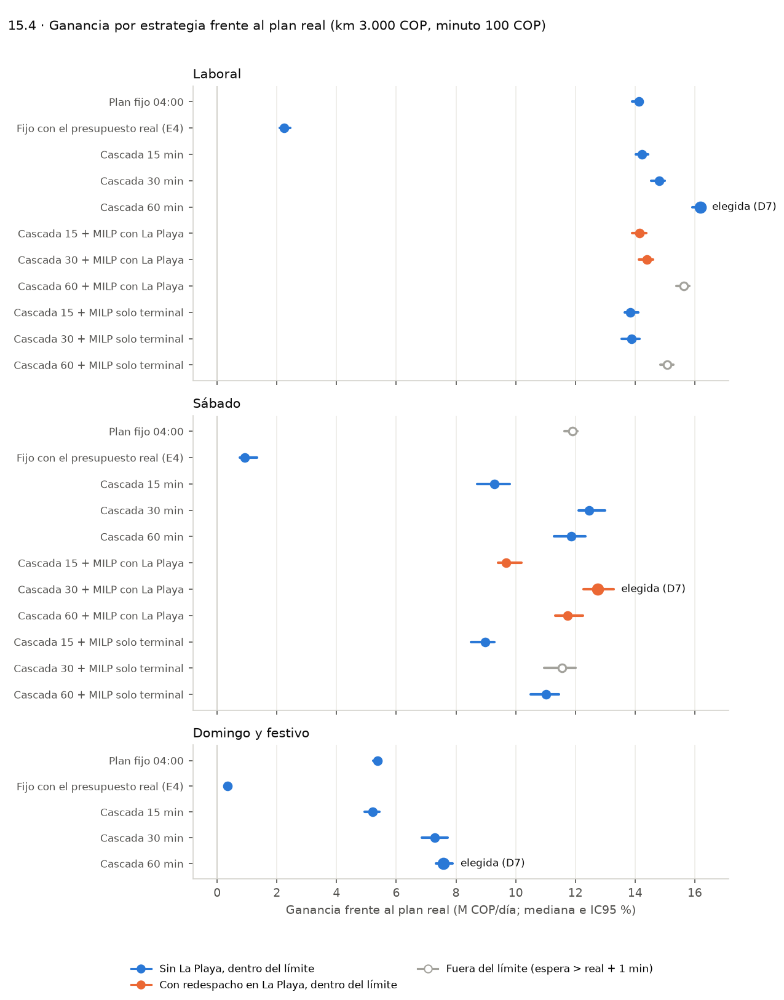

In [3]:
cols = ["grupo", "brazo", "parte", "factor_carga", "ganancia_cop", "ganancia_ic_inf", "ganancia_ic_sup", "d_espera_min",
        "d_espera_ic_inf", "d_espera_ic_sup", "dentro_limite", "limite_incierto", "d_salidas", "d_dejados_pct"]
t = t7[t7.nivel == "tipo"][cols].copy()
for k in ("ganancia_cop", "ganancia_ic_inf", "ganancia_ic_sup"):
    t[k] = (t[k] / 1e6).round(2)
display(t.round(2))
display(Image(filename="resultados_15/15_4/m15_4_ganancia.png"))

**Conclusión 2 · La estrategia elegida por tipo de día (D7)**
- **Laboral:** Cascada 60 min (factor 0,80), +16,19 M COP/día frente al plan real (IC95 % +15,93 a +16,32; gana en el 100 % de las réplicas; p Holm < 0,0001), con -106 viajes y espera +0,97 min [+0,93; +1,03]; **en el borde del límite** (el IC95 % de la espera cruza +1 min).
- **Sábado:** Cascada 30 + MILP con La Playa (factor 0,72), +12,76 M COP/día frente al plan real (IC95 % +12,27 a +13,28; gana en el 99,6 % de las réplicas; p Holm < 0,0001), con -80 viajes y espera +0,85 min [+0,79; +0,93].
- **Domingo y festivo:** Cascada 60 min (factor 0,50), +7,58 M COP/día frente al plan real (IC95 % +7,33 a +7,90; gana en el 100 % de las réplicas; p Holm < 0,0001), con -46 viajes y espera +0,75 min [+0,69; +0,83].
- Laboral: fuera del límite Cascada 60 + MILP con La Playa (+1,02 min), Cascada 60 + MILP solo terminal (+1,17 min).
- Sábado, solo la parte sin La Playa: Cascada 30 min (+12,47 M COP/día).
- Sábado: fuera del límite Plan fijo 04:00 (+1,01 min), Cascada 30 + MILP solo terminal (+1,19 min).
- Mejoran al real con significancia y dentro del límite: Laboral 9 de 11, Sábado 9 de 11, Domingo y festivo 5 de 5 estrategias. El grueso viene de operar con menos viajes (el factor de carga óptimo de la 15.3), como ya se vio en desarrollo.
- La regla se cambió después de ver los datos de desarrollo (A1 → D7); las semillas de la 15.4 son nuevas, así que la evaluación es fuera de muestra.

### Espera frente a ganancia, y estratos

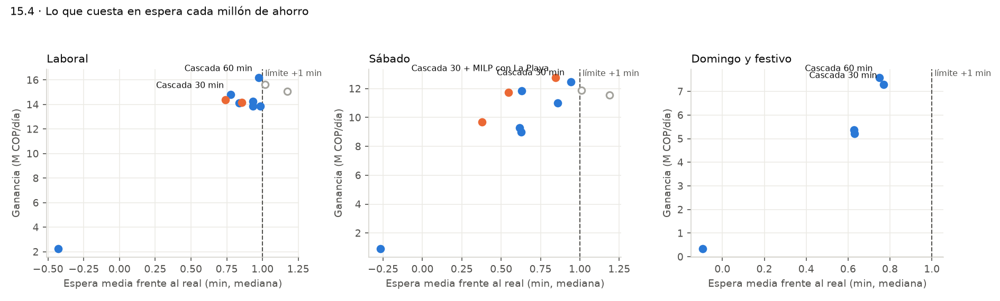

grupo,domingo_central,laboral_alta,laboral_central,laboral_lluvia,laboral_partido,sabado_central
brazo,,,,,,
cascada_15,0.63,1.07,1.02,0.41,1.08,0.62
cascada_30,0.77,0.90,0.90,0.26,0.91,0.94
cascada_60,0.75,1.12,1.13,0.42,1.14,0.63
cascada_milp_15,NaN,1.01,1.00,0.35,0.98,0.38
cascada_milp_30,NaN,0.90,0.88,0.28,0.92,0.85
cascada_milp_60,NaN,1.16,1.15,0.55,1.13,0.55
cascada_terminal_15,NaN,1.12,1.15,0.42,1.14,0.63
cascada_terminal_30,NaN,1.08,1.04,0.39,1.12,1.19
cascada_terminal_60,NaN,1.33,1.31,0.58,1.36,0.86


In [4]:
display(Image(filename="resultados_15/15_4/m15_4_espera_ganancia.png"))
e = t7[t7.nivel == "estrato"].pivot_table(index="brazo", columns="grupo", values="d_espera_min").round(2)
display(e)

**Conclusión 3 · La espera, por estrato**
- Laboral (Cascada 60 min): espera por estrato de +0,42 a +1,14 min; pasan +1 min: laboral_alta (+1,12), laboral_central (+1,13), laboral_partido (+1,14) (3 de 4).
  - Ojo: la mayoría de los estratos pasa el +1 min; el tipo de día cumple porque laboral_lluvia (+0,42) baja la mediana conjunta.
- Sábado (Cascada 30 + MILP con La Playa): un solo estrato (sabado_central), espera +0,85 min; dentro del límite.
- Domingo y festivo (Cascada 60 min): un solo estrato (domingo_central), espera +0,75 min; dentro del límite.
- La regla se lee por tipo de día (D6): algunos estratos pueden pasar el +1 min aunque el tipo cumpla. Se reporta como observación.

## 3 · Lo que agrega cada pieza: cascada sobre el fijo, MILP sobre la cascada, La Playa sobre la terminal

In [5]:
q = pr[(pr.nivel == "tipo") & (pr.familia != "frente al real")].copy()
for k in ("dif_mediana_cop", "ic_inf", "ic_sup"):
    q[k] = (q[k] / 1e6).round(2)
display(q[["grupo", "familia", "brazo", "frente_a", "dif_mediana_cop", "ic_inf", "ic_sup", "pct_replicas_a_favor", "p_holm", "significativa"]])

,grupo,familia,brazo,frente_a,dif_mediana_cop,ic_inf,ic_sup,pct_replicas_a_favor,p_holm,significativa
11,laboral,frente al fijo,fijo_presupuesto,fijo,-11.89,-12.04,-11.77,0.0,9.977577e-164,True
12,laboral,frente al fijo,cascada_15,fijo,0.22,0.03,0.41,53.5,4.755242e-02,True
13,laboral,frente al fijo,cascada_30,fijo,0.75,0.55,0.91,62.4,8.562034e-20,True
14,laboral,frente al fijo,cascada_60,fijo,2.07,1.91,2.23,81.5,2.906485e-105,True
15,laboral,frente al fijo,cascada_milp_15,fijo,0.16,-0.00,0.33,53.0,3.102931e-01,False
16,laboral,frente al fijo,cascada_milp_30,fijo,0.30,0.15,0.44,55.2,5.038636e-03,True
17,laboral,frente al fijo,cascada_milp_60,fijo,1.64,1.41,1.82,72.4,4.666635e-53,True
18,laboral,frente al fijo,cascada_terminal_15,fijo,-0.19,-0.33,-0.05,45.9,4.174397e-03,True
19,laboral,frente al fijo,cascada_terminal_30,fijo,-0.22,-0.40,-0.00,47.0,1.231538e-02,True
20,laboral,frente al fijo,cascada_terminal_60,fijo,1.23,1.05,1.36,67.2,3.639629e-35,True


**Conclusión 4 · Lo que agrega cada pieza (diferencia mediana de ganancia, M COP/día)**
- **Laboral · cascada frente al fijo:** 15 min +0,22 M (significativo, p Holm 0,0476); 30 min +0,75 M (significativo, p Holm < 0,0001); 60 min +2,07 M (significativo, p Holm < 0,0001).
- **Sábado · cascada frente al fijo:** 15 min -2,51 M (significativo, p Holm < 0,0001); 30 min +0,77 M (significativo, p Holm < 0,0001); 60 min +0,13 M (no significativo, p Holm 0,6952).
- **Domingo y festivo · cascada frente al fijo:** 15 min -0,27 M (significativo, p Holm 0,0455); 30 min +1,83 M (significativo, p Holm < 0,0001); 60 min +2,10 M (significativo, p Holm < 0,0001).
- **Laboral · MILP solo terminal frente a la cascada sola:** 15 min -0,41 M (significativo, p Holm < 0,0001); 30 min -0,91 M (significativo, p Holm < 0,0001); 60 min -0,97 M (significativo, p Holm < 0,0001).
- **Laboral · MILP con La Playa frente a la cascada sola:** 15 min -0,09 M (significativo, p Holm 0,0476); 30 min -0,46 M (significativo, p Holm < 0,0001); 60 min -0,50 M (significativo, p Holm < 0,0001).
- **Laboral · lo que agrega La Playa (frente a solo terminal):** 15 min +0,25 M (significativo, p Holm < 0,0001); 30 min +0,49 M (significativo, p Holm < 0,0001); 60 min +0,42 M (significativo, p Holm < 0,0001).
- **Sábado · MILP solo terminal frente a la cascada sola:** 15 min -0,38 M (significativo, p Holm 0,0010); 30 min -1,13 M (significativo, p Holm < 0,0001); 60 min -0,92 M (significativo, p Holm < 0,0001).
- **Sábado · MILP con La Playa frente a la cascada sola:** 15 min +0,35 M (significativo, p Holm < 0,0001); 30 min +0,17 M (no significativo, p Holm 0,6063); 60 min +0,19 M (no significativo, p Holm 0,1708).
- **Sábado · lo que agrega La Playa (frente a solo terminal):** 15 min +0,76 M (significativo, p Holm < 0,0001); 30 min +1,31 M (significativo, p Holm < 0,0001); 60 min +1,16 M (significativo, p Holm < 0,0001).
- El MILP se evalúa con la ganancia de la 15.4 (km y espera de todos); sus decisiones siguen con los pesos internos del 14 (permutación, retención, cautivos), que no entran en esta cuenta.

## 4 · Las dos partes del proyecto

**Conclusión 5 · Sin La Playa y con redespacho en La Playa**
- **Laboral:** sin La Playa, Cascada 60 min +16,19 M COP/día; con redespacho en La Playa, Cascada 30 + MILP con La Playa +14,39 M (-1,80 M frente a la mejor sin La Playa).
- **Sábado:** sin La Playa, Cascada 30 min +12,47 M COP/día; con redespacho en La Playa, Cascada 30 + MILP con La Playa +12,76 M (+0,29 M frente a la mejor sin La Playa).
- **Domingo y festivo:** sin La Playa, Cascada 60 min +7,58 M COP/día; con La Playa no aplica (domingo sin MILP, A2).
- En el informe final va primero la línea base (sin La Playa) y después, aparte, lo que agrega La Playa.

## 5 · P&L y sensibilidad de costos (E2)

In [6]:
t = t7[t7.nivel == "tipo"][["grupo", "brazo", "ahorro_km_cop", "costo_espera_cop", "ganancia_cop"]].copy()
for k in ("ahorro_km_cop", "costo_espera_cop", "ganancia_cop"):
    t[k] = (t[k] / 1e6).round(2)
display(t)
s = sens.pivot_table(index=["tipo", "km_cop", "min_cop"], columns="vista", values="elegida", aggfunc="first")
display(s)

,grupo,brazo,ahorro_km_cop,costo_espera_cop,ganancia_cop
60,domingo_festivo,fijo,6.60,1.23,5.37
61,domingo_festivo,fijo_presupuesto,0.15,-0.19,0.34
62,domingo_festivo,cascada_15,6.40,1.25,5.21
63,domingo_festivo,cascada_30,8.75,1.55,7.29
64,domingo_festivo,cascada_60,9.00,1.53,7.58
65,laboral,fijo,18.26,3.79,14.12
66,laboral,fijo_presupuesto,0.56,-1.94,2.25
67,laboral,cascada_15,18.21,4.28,14.24
68,laboral,cascada_30,17.99,3.51,14.81
69,laboral,cascada_60,20.40,4.47,16.19


vista                          sin La Playa            todas
tipo            km_cop min_cop                              
domingo_festivo 2000.0 0.0       cascada_60       cascada_60
                       100.0     cascada_60       cascada_60
                       200.0     cascada_60       cascada_60
                3000.0 0.0       cascada_60       cascada_60
                       100.0     cascada_60       cascada_60
                       200.0     cascada_60       cascada_60
                4000.0 0.0       cascada_60       cascada_60
                       100.0     cascada_60       cascada_60
                       200.0     cascada_60       cascada_60
laboral         2000.0 0.0       cascada_60       cascada_60
                       100.0     cascada_60       cascada_60
                       200.0     cascada_30       cascada_30
                3000.0 0.0       cascada_60       cascada_60
                       100.0     cascada_60       cascada_60
                       200.0     cascada_60       cascada_60
                4000.0 0.0       cascada_60       cascada_60
                       100.0     cascada_60       cascada_60
                       200.0     cascada_60       cascada_60
sabado          2000.0 0.0       cascada_30       cascada_30
                       100.0     cascada_30  cascada_milp_30
                       200.0     cascada_60  cascada_milp_60
                3000.0 0.0       cascada_30       cascada_30
                       100.0     cascada_30  cascada_milp_30
                       200.0     cascada_30  cascada_milp_60
                4000.0 0.0       cascada_30       cascada_30
                       100.0     cascada_30       cascada_30
                       200.0     cascada_30  cascada_milp_30

**Conclusión 6 · El P&L y la sensibilidad**
- **Laboral:** de la ganancia de Cascada 60 min, el ahorro en km es +20,40 M y el costo de la espera -4,47 M (medianas). Con los 9 costos de E2 la elegida cambia en km 2.000 / minuto 200 → Cascada 30 min; su ganancia va de +5,47 a +27,20 M COP/día.
- **Sábado:** de la ganancia de Cascada 30 + MILP con La Playa, el ahorro en km es +15,58 M y el costo de la espera -3,09 M (medianas). Con los 9 costos de E2 la elegida cambia en km 2.000 / minuto 0 → Cascada 30 min, km 2.000 / minuto 200 → Cascada 60 + MILP con La Playa, km 3.000 / minuto 0 → Cascada 30 min, km 3.000 / minuto 200 → Cascada 60 + MILP con La Playa, km 4.000 / minuto 0 → Cascada 30 min, km 4.000 / minuto 100 → Cascada 30 min; su ganancia va de +5,65 a +21,10 M COP/día.
- **Domingo y festivo:** de la ganancia de Cascada 60 min, el ahorro en km es +9,00 M y el costo de la espera -1,53 M (medianas). Con los 9 costos de E2 la elegida no cambia; su ganancia va de +3,22 a +11,99 M COP/día.
- La ganancia depende casi toda del supuesto de 3.000 COP por km (supuesto metodológico de la 14.3, no un costo medido); la sensibilidad muestra cuánto se mueve con 2.000 y 4.000 COP.

## 6 · Indicadores secundarios

In [7]:
k = ["espera_media_min", "espera_cautiva_media_min", "pct_dejados_bus_lleno", "pasajeros", "km_vacio_total", "salidas",
     "permutaciones_terminal", "cambios_ruta_la_playa", "retenciones_la_playa", "gamma_media", "cv_headway", "pct_viajes_cupo"]
s = sec[(sec.nivel == "tipo") & sec.kpi.isin(k)].pivot_table(index=["grupo", "brazo"], columns="kpi", values="mediana")
display(s[k].round(3))

kpi                                  espera_media_min  espera_cautiva_media_min  pct_dejados_bus_lleno  pasajeros  km_vacio_total  salidas  permutaciones_terminal  cambios_ruta_la_playa  \
grupo           brazo                                                                                                                                                                       
domingo_festivo cascada_15                      8.077                     8.656                  0.928    20035.5        1333.004    326.0                     0.0                    0.0   
                cascada_30                      8.219                     8.786                  1.058    20003.5        1204.682    314.0                     0.0                    0.0   
                cascada_60                      8.181                     8.731                  1.032    20045.5        1189.783    312.0                     0.0                    0.0   
                fijo                            8.049                     8.623                  0.877    20029.5        1309.081    325.0                     0.0                    0.0   
                fijo_presupuesto                7.331                     7.865                  0.613    19991.5        1622.554    359.0                     0.0                    0.0   
                real                            7.445                     8.002                  1.046    20095.0        1729.431    358.0                     0.0                    0.0   
laboral         cascada_15                      8.265                     8.823                  8.499    46334.5        1023.212    461.0                     0.0                    0.0   
                cascada_30                      8.098                     8.660                  8.332    46337.5        1014.782    462.0                     0.0                    0.0   
                cascada_60                      8.289                     8.926                  8.864    46326.0         941.464    449.0                     0.0                    0.0   
                cascada_milp_15                 8.186                     8.822                  9.384    46329.5        1190.297    462.0                     0.0                   76.0   
                cascada_milp_30                 8.075                     8.742                  9.205    46322.5        1188.048    463.0                     0.0                   77.0   
                cascada_milp_60                 8.343                     9.012                  9.874    46312.5        1121.422    451.0                     0.0                   74.0   
                cascada_terminal_15             8.302                     8.841                  8.998    46344.0        1092.302    461.0                     0.0                    0.0   
                cascada_terminal_30             8.226                     8.806                  8.868    46332.5        1098.424    462.0                     0.0                    0.0   
                cascada_terminal_60             8.491                     9.089                  9.437    46330.5        1029.223    449.5                     0.0                    0.0   
                fijo                            8.258                     8.729                  8.493    46351.0        1009.510    462.0                     0.0                    0.0   
                fijo_presupuesto                6.982                     7.233                  5.570    46319.0        1642.267    555.0                     0.0                    0.0   
                real                            7.523                     8.026                  7.330    46409.0        1781.404    557.0                     0.0                    0.0   
sabado          cascada_15                      7.922                     8.559                  4.736    36893.0        1054.398    420.0                     0.0                    0.0   
                cascada_30     

**Conclusión 7 · Lo que pasa con los pasajeros y la operación**
- **Laboral (Cascada 60 min):** espera de los cautivos +0,92 min; dejados por bus lleno +20 %; pasajeros -82 (-0,18 %); km en vacío -829; γ̂ mediano 0,975.
- **Sábado (Cascada 30 + MILP con La Playa):** espera de los cautivos +0,99 min; dejados por bus lleno +29 %; pasajeros -72 (-0,20 %); km en vacío -542; γ̂ mediano 0,978.
- **Domingo y festivo (Cascada 60 min):** espera de los cautivos +0,75 min; dejados por bus lleno -8 %; pasajeros -61 (-0,30 %); km en vacío -551; γ̂ mediano 0,928.
- Laboral, carga operativa del MILP (cascada 30, medianas por día): con La Playa 77 cambios de ruta y 100 retenciones; solo terminal 0 permutaciones.
- Sábado, carga operativa del MILP (cascada 30, medianas por día): con La Playa 68 cambios de ruta y 86 retenciones; solo terminal 0 permutaciones.
- El simulador no modela que la gente se canse de esperar y se vaya en otro transporte: la pérdida de pasajeros podría ser mayor en la realidad.

## 7 · Estado del MILP

In [8]:
display(milp.round(2))

,tipo,brazo,dias,ventanas,relajadas,respaldo,al_limite_de_tiempo,t_mediana_s,segundos_dia_mediana,pct_al_limite
0,laboral,cascada_milp_15,1000,68000.0,295.0,0.0,366.0,0.88,100.75,0.54
1,laboral,cascada_milp_30,1000,68000.0,216.0,1.0,377.0,0.85,99.12,0.55
2,laboral,cascada_milp_60,1000,68000.0,188.0,0.0,382.0,0.81,98.29,0.56
3,laboral,cascada_terminal_15,1000,68000.0,290.0,0.0,0.0,0.50,42.78,0.00
4,laboral,cascada_terminal_30,1000,68000.0,148.0,0.0,0.0,0.48,40.72,0.00
5,laboral,cascada_terminal_60,1000,68000.0,137.0,0.0,0.0,0.47,40.38,0.00
6,sabado,cascada_milp_15,250,17000.0,170.0,0.0,10.0,0.96,89.23,0.06
7,sabado,cascada_milp_30,250,17000.0,224.0,0.0,39.0,1.15,99.83,0.23
8,sabado,cascada_milp_60,250,17000.0,106.0,0.0,25.0,1.05,95.64,0.15
9,sabado,cascada_terminal_15,250,17000.0,114.0,0.0,0.0,0.51,40.45,0.00


**Conclusión 8 · El MILP**
- 7.500 días con MILP y 510.000 ventanas: plan de respaldo en 1, ventanas relajadas 1.988 (0,39 %) y al límite de tiempo 1.199 (0,24 %; máximo por brazo 0,56 %, siempre con La Playa).
- Un día con MILP tarda 39–101 s (mediana por brazo); sin MILP, unos pocos segundos.

## 8 · Limitaciones (alcance de la evaluación)
- **Costos supuestos:** km a 3.000 COP y minuto de espera a 100 COP son los pesos estándar de la 14.3, no costos medidos; la tarifa de SOBUSA sigue pendiente (0 en la cuenta). La sensibilidad E2 acota el efecto.
- **La regla cambió después de ver desarrollo** (A1 → D7, A4 → ganancia); por eso la 15.4 usa semillas nuevas: la elección se evalúa fuera de muestra.
- **Lectura por tipo de día (D6):** un estrato puede pasar el +1 min aunque su tipo cumpla.
- **Abandono de pasajeros:** el simulador no lo modela.
- **Dos equipos:** la corrida se completó en un segundo PC con las mismas versiones. En la comprobación los 18 días salieron idénticos; un día solo podría diferir si alguna ventana del MILP con La Playa llega a su límite de tiempo (0,24 % de las ventanas), porque CBC corta según la velocidad del equipo.

<a id="a3"></a>

---

# Anexo A3 · Trazabilidad de las correcciones del Entregable 2 (versión del 19-nov-2026)

La tabla siguiente es la trazabilidad con la que se entregó el e2c, sin cambios. Dos cosas cambiaron en esta versión: la cifra principal ahora es la del perfil histórico (−38,8 %) y no la de la entrada anterior del simulador (−59,7 %, fila O2), y los números de «Partes» que cita la tabla son los del orden anterior. En esta versión, el e2c.0–e2c.1 está en la sección 1, el e2c.2 en la 2, el e2c.3 en la 3, el e2c.4–e2c.5 en la 4 y el e2c.6 en el Anexo A2.

<sub>[&#8679; volver al índice](#indice)</sub>


<a id="trazabilidad"></a>

## Tabla de trazabilidad de correcciones (Entregable 2 → e2c)

Fuente de cada cifra: `entrega_e2c_7.py` (la recalcula desde su CSV o JSON; `--verificar` la contrasta con este texto).

| # | Observación de la calificación / requisito | Dónde se resuelve | Evidencia (cifra o check) | Estado |
|---|---|---|---|---|
| O1 | «Hay buen rigor en las pruebas y en congelar las reglas con hash» (conservar) | Todo el bloque e2c | 7 reglas y decisiones congeladas con hash de contenido antes de cada corrida (decisiones, aceptación, panel, grafo, métrica, decisión del modelo, configuración del simulador); checks e2c.0–e2c.5: 74 PASS · 2 FAIL | Resuelto |
| O2 | «El notebook no resuelve el pronóstico espacio-temporal» | Partes 2–7 (e2c.0–e2c.5) | Modelo y_{i,t} sobre N = 386 segmentos × hora; holdout 2025 (evaluación única): devianza 1,460 frente a 3,627 de la entrada anterior del simulador (−59,7 %, 4/4 bloques; DM p calibrado 0,0001) | Resuelto |
| O3 | «Faltan el EDA y el feature engineering del reto» | Partes 4–5 (e2c.2, e2c.3) | EDA nodo × hora: KNN k = 8, I de Moran 0,193 (18/18 franjas × tipo significativas), ACF por nodo, correlación con el lag espacial; 67 features con rezagos admisibles y lag espacial A_norm Y; auditoría A1–A7 7/7 PASS (certificado con reservas) | Resuelto |
| O4 | «El simulador no cumplió su criterio principal» | Parte 8 (e2c.6) | Simulador con ŷ en 6 días NUEVOS congelados: **3 de 6** (exigía 5); e1c 3, demanda real del día 2. «No ciega» en los 6 días de la 13.1: e2c 3 de 6, e1c 3, real 3 (oficial 13.4: 3 de 6). Con la demanda real tampoco cumple: la falla está en el motor (bajadas con reparto fijo), no en el pronóstico | **No resuelto** (reportado tal cual, con su causa) |
| R1 | Pronóstico sobre N nodos espaciales (no por viaje) | e2c.0, e2c.1 | Panel 3.064.840 filas = 386 × 397 días × 20 h; la suma de las lecturas se conserva | Resuelto |
| R2 | Matriz KNN Haversine con k justificado, k = 2 de referencia y kernel | e2c.2.1 | k = 8 (menor k conexo, regla 4.3); k = 2 da 41 componentes; kernel gaussiano σ = 410,3 m | Resuelto |
| R3 | Lag espacial entre nodos (no entre rutas) | e2c.3.3, e2c.4.6, e2c.5 | En la CV no cumplió C2 (sin lag +0,16 %, 2/4 pliegues); en el holdout quitarlo empeora +1,6 % (4/4 bloques); SHAP de la familia 11,3 % | Parcial (C2 no se cumplió en la CV; se reporta) |
| R4 | x̃_{i,t−1} / nowcast | e2c.0.2, e2c.1.1 | `track_commit_timestamp = off`: la latencia no es medible → nowcast y t−1 solo como oráculo | Resuelto como oráculo (no desplegable, justificado) |
| R5 | Walk-forward purgado, sin K-Fold aleatorio; holdout una sola vez | e2c.4.1, e2c.5.2 | 4 pliegues + salto de año; `tests_e2c_4.py` busca K-Fold y shuffle; `registro_evaluacion_e2c_5.json` | Resuelto |
| R6 | Líneas base y significancia | e2c.4.2, e2c.5.7 | CV: modelo 1,448 frente a (i) 3,414, (ii) 2,427, (iii) 2,967; DM frente a (iii) p calibrado 0,0001 (Holm 0,0002) y frente a (ii) 0,0095 | Resuelto |
| R7 | Interpretabilidad (ganancia, TreeSHAP) y Moran de los residuos | e2c.5.5–e2c.5.6 | TreeSHAP con aditividad verificada; Moran de los residuos significativo en 14/18 franjas × tipo (queda estructura espacial) | Resuelto (con límite declarado) |
| R8 | Módulos 9–14 como consumidores del pronóstico, sin borrar nada | Partes 9–14 | Un párrafo puente por módulo; MD5 de los notebooks originales iguales antes y después de unificar | Resuelto |
| R9 | Auditoría de fuga explícita (guía E3, bloque A) | e2c.3.7 | A1–A7 7/7 PASS; `auditoria_leakage_e2c.md` | Resuelto |
| R10 | Honestidad ante los cambios (guía E3, bloque A) | e2c.4.7, e2c.6.6 | C2 y el criterio del simulador no se cumplieron y se reportan; Carnaval es el único corte donde el modelo no le gana al perfil (2,66 frente a 2,49) | Resuelto |


<a id="conclusion"></a>

---

# Conclusión final del proyecto

**Módulos 1 a 15, más las correcciones e1c y e2c. Rutas 2 (SILENCIO), 16 (CRA 54) y 21 (CL 72) de Barranquilla y Soledad. Cierre: 19-nov-2026; corrección para la entrega final: 20-nov-2026.**

Qué se hizo: se pasó de 564.837 viajes crudos a un pronóstico de demanda por segmento de 500 m y hora, y de ahí a un simulador, un redespacho de flota y un plan de despacho que se recalcula durante el día. Este documento dice qué quedó probado, qué no funcionó y qué se puede llevar a la operación.

Todas las cifras salen de las subfases cerradas y están verificadas contra sus salidas (`verificar_informe_8_3.py` 36/36, `entrega_e2c_7.py --verificar` 22/22, `verificar_informe_13_6.py` 75/75, `verificar_informe_15_6.py` 70/70, y las del Módulo 15 recalculadas desde `datos_15/15_4/reporte/` al escribir este documento).

---

## 1. Hallazgos

### 1.1 El hallazgo con más dinero detrás: SOBUSA opera con más viajes de los que la demanda pide

Es el resultado de más peso de todo el proyecto, y no vino del pronóstico sino de la planeación de la frecuencia (Módulo 15, 16.500 días simulados, 12 brazos × 6 estratos × 250 réplicas, una sola configuración congelada).

| | Plan fijo de las 04:00 | Salidas | Estrategia elegida (con cascada) |
|---|---:|---:|---:|
| Laboral | **+14,12 M COP/día** | −95 | **+16,19 M** (cascada 60 min) |
| Sábado | **+11,90 M** | −80 | **+12,76 M** (cascada 30 + MILP con La Playa) |
| Domingo y festivo | **+5,37 M** | −33 | **+7,58 M** (cascada 60 min) |

Las tres elegidas le ganan al plan real con p (Holm) < 0,0001, en el 100 % de las réplicas del laboral y el domingo y el 99,6 % del sábado.

**Lo importante es de dónde viene la ganancia:** el plan fijo de las 04:00 —calcular las salidas una sola vez al día con la regla de carga máxima— ya captura la mayor parte. Recalcular durante el día suma +2,07 (laboral), +0,77 (sábado) y +2,10 M (domingo). Es decir: **primero hay que corregir cuántos viajes se programan; la inteligencia intradía es la segunda capa, no la primera.**

El contraste lo da el brazo que mantiene el presupuesto de salidas real: con las mismas salidas de hoy, la ganancia cae a +2,25 / +0,91 / +0,34 M. Lo que mueve la aguja es cuántos viajes se hacen, no cuándo se recalcula.

### 1.2 El pronóstico espacio-temporal funciona, y funciona donde más dolía

El e2c pronostica subidas por segmento de 500 m (N = 386 nodos) × hora, emitido a las 04:00. En el holdout 2025, **evaluado una sola vez**:

- devianza **1,460** frente a **2,388** del perfil histórico nodo × hora × tipo de día: **−38,8 %**, mejor en los 4 bloques del año, Diebold-Mariano con p calibrado 0,0095. Es la comparación que importa: el perfil es lo que cualquiera haría sin modelo;
- en la punta de la mañana laboral (6–9 h): **1,86 frente a 4,04 del perfil, −53,9 %**;
- frente a la entrada que usaba antes el simulador (3,627) la mejora es de −59,7 % (p calibrado 0,0001), pero esa línea base es casi tan mala como repetir lo de hace una semana (3,648): no es la cifra para presumir;
- en la escala que usa la regla de frecuencia, **ruta × hora**, el error relativo (WAPE) es **10,5 %** frente a 16,6 % del modelo por viaje del Entregable 1 llevado a la red y 14,0 % del perfil; al modelo por viaje le gana en los 4 bloques y en la punta (10,8 % frente a 19,7 %). En totales por ruta y día los dos pronósticos quedan casi iguales (7,4 % frente a 7,9 %): **lo que aporta el e2c es cómo se reparte la demanda dentro del día y a lo largo de la ruta, no el total del día** (Fase 1.2 de la corrección final, rotulada «no ciega»);
- falla en **Carnaval**: subpredice un 27 % y ahí el modelo por viaje es mucho mejor (WAPE por ruta y día 5,4 % frente a 28,3 %).

A nivel de viaje (Entregable 1 corregido), el modelo de las 04:00 llega a 2,248 frente a 2,929 de la línea base (−23,2 %), mejor en 11 de 12 meses.

### 1.3 Un buen pronóstico no arregla un motor que está mal

Con el pronóstico e2c como entrada, el simulador le gana al perfil histórico en **3 de 6 días nuevos**; el criterio pedía 5. Y ahí está la prueba diagnóstica: con la entrada anterior (e1c) también 3 de 6, y **con la demanda real del día, 2 de 6**. Si darle la demanda perfecta no lo arregla, el problema no es la demanda.

Y no es un problema de cómo se midió (Fase 1.1 de la corrección final, con regla congelada antes de calcular): la demanda real que se le dio al simulador está completa (le faltan entre 0,2 y 2,8 % de las subidas del día, las de los viajes inválidos o sin lecturas) y el simulador sube el 98,2–99,8 % de ella. Ese faltante explica entre el 0 y el 13 % del hueco de 6 a 9 h, lejos del 50 % que habría hecho falta. La medida principal ya usa la carga después de la parada y ponderada por tiempo, como el sensor. **El hueco de la mañana es del motor.**

La Fase 3 de la corrección final encontró una causa parcial. La calibración ubicaba la salida de la terminal al final del circuito, así que las subidas del arranque viajaban pocos tramos. Con esa salida corregida, el simulador mejora en 5 de 6 días (−2,2 % de error en promedio) y en la franja de 6 a 9 h de los 6. Pero sigue en **3 de 6** (re-evaluación única, «no ciega»). Queda como interruptor apagado del simulador: hacerla central obligaría a recalcular la flota y el Monte Carlo por una mejora que no cambia ninguna decisión.

El resto de la causa está en las **bajadas**, que salen del reparto fijo de la 13.1: el bus va vacío en el tercer cuarto del circuito y demasiado lleno al regreso. Pesa también la deriva del sensor: al terminar el viaje, todavía cuenta unos 5 pasajeros a bordo en las salidas de 6 a 9 h. **El siguiente paso natural del proyecto es pronosticar u observar las bajadas, no mejorar más el pronóstico de subidas.**

### 1.4 Una variable monótona en el tiempo puede romper un modelo de árboles entero

`tendencia_meses` quedaba fuera del rango de entrenamiento en todo 2025, y LightGBM no extrapola: el último corte de los árboles era ≈ 20-dic-2024, así que **todo 2025 se predecía como finales de diciembre**. El efecto medido: el contraste domingo/laboral predicho era 0,842 cuando el real es 0,671.

Al quitarla y poner el receso escolar en su lugar: devianza 2025 **−10,2 %** y domingo/laboral **0,694** frente a 0,671 real.

La lección es metodológica y vale para cualquier proyecto futuro: la walk-forward de 2024 **no** lo detectó, y no por lo que se creyó al principio. En los 6 pliegues el 100 % de la validación quedaba fuera de rango, pero solo 1–3 meses, y el early stopping dejaba fuera las últimas 4 semanas. En 2025 la extrapolación fue de 12 meses desde un borde en diciembre. **Hay que validar con horizontes como los de producción y vigilar el % fuera de rango por variable al emitir.**

### 1.5 Lo espacial aporta menos de lo que prometía

- El lag espacial entre nodos: quitarlo empeora solo **+1,6 %** en el holdout (4/4 bloques) y **no cumplió el criterio C2** en validación (+0,18 %, apenas 2/4 pliegues). Su familia explica el 11,3 % del SHAP. Se conservó por decisión expresa, no porque la evidencia lo exigiera.
- Queda estructura espacial sin modelar: I de Moran de los residuos significativo en **14 de 18** franjas × tipo de día.

### 1.6 Los reportes de conductores por voz y texto funcionan, y cuestan casi nada

Módulo 10, evaluación única: **F1 0,9983 en texto** (IC95 % [0,9966; 0,9996]) y **0,9955 en audio**; de punta a punta, el evento cae en el segmento exacto en **95,04 %** (texto) y **99,21 %** (audio), contra techos de 96,14 % y 100 %. Latencia mediana dentro del servicio **1,36 s** (P95 2,24 s). **Costo total del módulo: USD 0,113.**

En 700 mensajes el modelo **no inventó** duración, sentido ni gravedad, incluidas las 8 omisiones puestas a propósito.

### 1.7 El redespacho de flota ayuda a los pasajeros y le cuesta al operador

Módulo 14, 2.500 pares, rígido frente a MILP con la misma semilla: espera de los cautivos **8,34 → 7,75 min (−7,1 %)**, dejados por bus lleno −4,5 %, varianza del intervalo −24,1 %, pero **km en vacío +6,8 % (≈ 116 km/día)**. Todo con p (Holm) < 0,05.

El margen del operador baja 0,53–0,88 M COP/día y los usuarios ahorran ≈ 20.900 min/día: el beneficio neto es positivo de lunes a sábado **solo si el minuto de espera vale más de 25–39 COP**. **El domingo no conviene** (dejados +32,5 %, beneficio neto −0,35 M).

Y hay un matiz que importa para la decisión: sobre una cascada que **ya** ajustó la frecuencia, el MILP aporta poco o resta (ver 2.2).

### 1.8 Lo que la base de datos no tiene, y nadie debería suponer que tiene

- **No hay registro de incidentes viales:** `observacion` solo trae textos automáticos, `novedades_viales_ruta` está vacía y `novedades_viales_fecha` solo tiene 28 eventos masivos de 2023–2025. Por eso choques, bloqueos y semáforos son supuestos con sensibilidad, no datos.
- **`cancelada='S'` no significa que el bus no salió:** de 44.156 cancelados, el **92 % arrancó y el 87 % llevó pasajeros**. La frecuencia se mide sobre `tb_despachos`, nunca sobre la maestra.
- **`numeropasajeros` no es ocupación:** son las subidas totales de un viaje de ~4 h; el bus se renueva ~2,5 veces por vuelta.
- **No hay sellos de tiempo de inserción** (`track_commit_timestamp = off`): la latencia del sensor no se puede medir en la base. Según la Persona 3 (20-nov-2026), en la base de SOBUSA los datos del sensor se actualizan en vivo; con eso el nowcast pasa a ser **desplegable como opción**. En la copia de la base que usó el proyecto falta el último día de cada mes; eso es de la copia, y la guarda de emisión avisa.
- **No hay documentación vehicular:** las fechas de SOAT, tecnomecánica e inspección de `vehiculos` están 100 % vacías en los 656 buses, y el reporte de flota no trae fechas. El modelo de varadas no puede ver una revisión vencida, y no se imputó ninguna fecha. Queda como **limitación** del proyecto (Fase 6 de la corrección final, `correccion_final/fase6/DOCUMENTACION_VEHICULAR_F6.md`).

---

## 2. Qué sirve

**Listo para usar, con evidencia propia y reproducible.**

| Pieza | Para qué | Evidencia |
|---|---|---|
| Reglas de validez, atrición y tablas maestras (M1) | Cualquier análisis futuro parte de aquí | 497.371 de 564.837 viajes válidos (88,06 %); 22/22 checks |
| Métrica oficial de Tweedie (M2) | Juzgar cualquier modelo de demanda con el mismo criterio | p̂ = 1,40 por viaje (se adoptó 1,3); 14/14 pruebas; p̂ = 1,12 a escala nodo × hora |
| Pronóstico 04:00 por segmento × hora (e2c) | Entrada del simulador, del MILP y del plan de despacho | −38,8 % de devianza frente al perfil histórico en el holdout 2025 (4/4 bloques, DM p 0,0095); WAPE por ruta × hora 10,5 % |
| Modelo por viaje corregido (e1c) | Demanda por salida, sin la trampa de la tendencia | −23,2 % frente a línea base; 11/12 meses |
| Regla de carga máxima + plan fijo 04:00 (M13/M15) | Decidir cuántas salidas programar | +5,37 a +14,12 M COP/día en 16.500 días simulados |
| Cascada de 60 min (laboral y domingo) y 30 min (sábado) | Recalcular la frecuencia durante el día | +0,77 a +2,10 M sobre el plan fijo, p < 0,0001 |
| Reportes de conductores → eventos (M10) | Alimentar reenrutamiento y simulador con lo que pasa en la vía | F1 0,9955–0,9983; USD 0,113; banco de 580 eventos |
| Reenrutamiento A* (M12) | Desvíos ante cierres de gravedad ≥ 4 | ~10 ms por consulta; desvío simulado 8,9 min frente a 8,6 del GPS real |
| Scoring de varada (M9) | Flota disponible y sorteo de varadas | Probabilidad calibrada, AUC 0,648 |
| Gemelo digital y panel de cascada (M13.5, M15.5) | Que el jefe operacional vea y entienda la decisión | 144 cuadros/s; 24/24 días del panel idénticos a la 15.4 |

---

## 3. Qué no sirve (o no se puede usar todavía)

**No usar como verdad operativa.**

1. **El simulador como medida absoluta de ocupación.** Cumple 3 de 6 días frente al criterio de 5, y el error se concentra de 6 a 9 h. Con la salida de la terminal corregida (Fase 3) sigue en 3 de 6. Corrección (Fase 1.1): el criterio secundario de pasajeros por viaje comparaba con la media de los viajes de la maestra, que deja fuera las salidas «canceladas» que operaron (llevan 22–82 pasajeros por viaje frente a 53–101). Con todas las salidas válidas, la entrada real queda dentro de ±10 % en 18 de 18 ruta × día (antes 14), la del e2c en 15 (antes 18) y la del e1c en 12 (antes 17). Sirve para **comparar estrategias entre sí** (que es para lo que se usó en los Módulos 14 y 15, con semillas pareadas), no para decir cuánta gente va en el bus.
2. **El nowcast como mejora medida del despacho.** Ya no está bloqueado: según la Persona 3, los datos del sensor llegan en vivo, así que se puede usar (mejora el pronóstico de la hora siguiente un 3,4 % en el holdout). Pero su efecto en el despacho no se ha medido, y la cascada con el Ridge, que también usa el sensor en vivo, sí. Es una opción del plan de operación, apagada por defecto. El oráculo (1 h antes) sigue siendo solo el techo de referencia.
3. **La cascada de 15 min.** Es la que menos gana y en sábado **pierde frente al plan fijo (−2,51 M)**. Recalcular más seguido reacciona al ruido. Ya está fuera de la configuración operativa (`modulo15/config/cascada_15_3_v2.yaml`, Fase 2.4), y con tarifa no la elige ninguna de las 46 combinaciones de precios.
4. **El MILP solo de la terminal.** Resta siempre frente a la cascada del mismo intervalo: −0,38 a −1,13 M COP/día.
5. **El redespacho en domingo.** Dejados +32,5 % y beneficio neto −0,35 M.
6. **El estimador en vivo simple de la 15.1.** Mejoró la hora siguiente todos los meses (−3,2 % a −8,9 %), pero solo en el **57,3 % de los recálculos** frente a una meta de 60 %, y tarda ~4 h en notar la mitad de un cambio de demanda. Lo reemplazó Ridge con sensor real (15.1b).
7. **Las cifras de P&L como pesos reales.** 3.000 COP/km y 100 COP/min son **supuestos metodológicos**. La evaluación oficial tenía la tarifa en 0. Con la tarifa de 3.700 COP (Fase 4; la oficial del transporte colectivo en días ordinarios desde el 19-ene-2026) la ganancia de la estrategia elegida baja muy poco: laboral 16,19 → **15,79 M**, sábado 12,76 → **12,44 M**, domingo 7,58 → **7,34 M**. La razón es que en el simulador el que se queda por bus lleno toma el siguiente bus y paga igual. Si además se supone que **todos** los dejados de más se van en otro medio, el laboral queda en 13,33 M. En las 46 combinaciones de tarifa ±20 %, km ±20 % y abandono de 0 a 100 %, la ganancia de la elegida va de +5,5 a +19,9 M según el tipo de día, y nunca es negativa. La elección es estable en el domingo (46/46) y en el laboral (43/46). En el sábado alterna entre la cascada de 30 min con y sin MILP, que estaban casi empatadas. **El monto no es una cifra de negocio hasta que SOBUSA confirme el costo del km.**
8. **Los `Scripts/` de la plataforma de SOBUSA.** Calculan pasajeros con los contadores `acumulada_*`, que son de toda la vida del equipo, y filtran `proceso = 'cootransoriente'`. No usar sus cifras sin validarlas.
9. **`duracion_min` para razonar sobre disponibilidad** (usa el inicio real, no la salida programada: fue una fuga, corregida en la 6.3) y **`frecuenciadespachos` = '5'**, cuya unidad nunca se confirmó.
10. **El calendario de la Persona 2 para emitir después de 2025.** `calendario_dias.csv` termina el 2025-12-31. Para emitir hay que usar `calendario_vigente.py`, que lee el calendario de días ampliado hasta 2027 (festivos y Carnaval con fuente por fecha) y nunca rellena. El calendario escolar ya cubre el año lectivo 2027 (Res. 04745 de 2026, cargada en la parte 2): la emisión cubre todo 2027 y la guarda bloquea desde el 27-dic-2027.
11. **El «recaudo esperado» de los módulos 1 y 9 como cifra de dinero.** Usa 3.700 COP en 2023–2025, pero esa tarifa rige solo desde el 19-ene-2026. Con la tarifa vigente de cada día (2.600–3.400 COP), **el recaudo no cae: queda en 42.300–42.800 millones de COP al año**. Con 3.700 parecía bajar de 56.491 a 47.338 millones. Los pasajeros sí caen un 16 %, pero las alzas de tarifa lo compensan. El costo por varada del M9 en 2025 baja de 165 mil a unos 148 mil COP (`correccion_final/parte1/`).
12. **El pronóstico cerca del estadio en días de partido.** En la validación (8 partidos en el Metropolitano), en los 21 tramos a ≤ 800 m del estadio, las subidas superan al pronóstico **+15 % más que en días sin partido** (IC 90 % [+8,6; +20,1]). En toda la red el efecto es nulo (+0,4 %). El modelo no tiene variable de partidos: el plan de operación da un **aviso** esos días y deja el refuerzo de salidas como opción apagada. El cambio de Junior al Romelio en 2026 no se puede evaluar con la historia (`correccion_final/parte2/`).
13. **El plan de operación del día** (lo único que se hace del Módulo 16; `correccion_final/plan_despacho/`). A las 04:00 lleva el plan típico a la demanda que el pronóstico prevé para esa fecha, aplica la regla de carga máxima y revisa la flota. Durante el día lo corrigen la cascada y, en sábado, el MILP de La Playa. Cada pieza es una propuesta con interruptor. En la validación (6 días, 150 réplicas pareadas, «no ciega»), el plan del día cumple la regla congelada en **6 de 6 días** y queda encendido por defecto. En plata es casi neutro (+0,59 M COP en los 6 días frente a la operación de la 15.4, IC 95 % [−5,24; +7,72]): mueve el servicio hacia la demanda, con menos espera y menos buses llenos los días de demanda alta y ahorro los días flojos. Supone que SOBUSA conoce a las 04:00 las salidas previstas del día; si no, el resultado es optimista. El refuerzo de partido no cambia nada, y el plan con el e2c pierde plata (−9,83 M).

---

## 4. Qué se puede usar en la operación

Ordenado por cuánto rinde frente a lo que cuesta ponerlo en marcha.

### Paso 1 · Replantear cuántas salidas se programan (sin tecnología nueva)

Es la recomendación principal. El plan fijo de las 04:00 con el factor de carga calibrado da **+5,37 a +14,12 M COP/día** con **9–17 % menos salidas**, y no necesita nada en vivo: se calcula una vez al día.

**Dos variables del cálculo deciden el monto.** Ya están parametrizadas: con los valores reales de SOBUSA se recalcula en segundos y sin volver a simular (`py correccion_final\fase4\pyg_parametrico_f4.py . --km <COP> --abandono <0–1>`; tabla completa en `correccion_final/fase4/salidas_4/tabla_km_abandono_f4.csv`):
- el **costo por km** (por defecto 3.000 COP), porque de ahí sale casi toda la ganancia (en el laboral, la cascada de 60 min ahorra +20,40 M en km y cuesta −4,47 M en espera). Por cada 250 COP más por km, el laboral gana unos 1,6–1,7 M COP/día más;
- la **fracción que abandona** (por defecto 0 %): cuántos de los que se quedan por bus lleno **se van en otro medio**: menos viajes significa buses más llenos y **+20 % de dejados por bus lleno en el laboral, +29 % en el sábado** (en domingo bajan −8 %). Con la tarifa de 3.700 y nadie que abandone, el recaudo perdido es de 0,2 a 0,4 M COP/día. Si abandonaran todos los dejados de más, la ganancia del laboral bajaría de 15,8 a 13,3 M (Fase 4).

**Cómo empezar:** una ruta, un tipo de día, piloto medido contra el plan actual.

### Paso 2 · Recalcular la frecuencia durante el día

Cada **60 min en laboral y domingo**, cada **30 min en sábado**. Suma +0,77 a +2,10 M COP/día sobre el plan fijo. Necesita, cada ventana: subidas contadas por los sensores, buses libres, varadas y desvíos reportados.

**Vigilar el límite de espera:** en el laboral, la cascada de 60 min queda en el borde (+0,97 min, IC95 % [+0,93; +1,03]) y **tres de los cuatro estratos lo pasan** (+1,12 a +1,14 min); solo el de lluvia (+0,42) baja la mediana. Si SOBUSA quiere un compromiso de espera por cada tipo de laboral y no un promedio, la opción es la **cascada de 30 min: +14,81 M con todos los estratos entre +0,26 y +0,91 min**.

### Paso 3 · Redespacho en La Playa, solo donde paga

**Sábado**, donde aporta +0,17 a +0,35 M sobre la cascada sola (aunque no sea significativo, p 0,61). En **laboral la cascada sola gana más**, y el **domingo va sin MILP**. No activar el MILP solo de terminal.

### Paso 4 · Reportes de conductores en vivo

El Módulo 10 está listo y es barato (USD 0,12 por 1.000 mensajes). Lo que falta es operativo, no técnico: el canal real (WhatsApp o equivalente), el GPS en vivo por vehículo —que ya está resuelto por `idvehiculo` y rango de 5 min, sin recorrer la tabla de 41 GB— y educar a los conductores en la guía de 5 campos.

### Lo que falta antes de operar de verdad

| Pendiente | Por qué bloquea | Quién lo cierra |
|---|---|---|
| Valor real del costo por km y de la fracción que abandona | Son **variables** del P&L (por defecto 3.000 COP y 0 %): con el valor real se recalcula con `pyg_parametrico_f4.py`. La elección es la misma con cualquier valor en el domingo y casi siempre en el laboral | SOBUSA (dato de entrada) |
| Latencia del sensor | **Resuelta como información de la operación** (Persona 3, 20-nov-2026: los datos se actualizan en vivo). Conviene que TI de SOBUSA lo confirme por escrito, porque la base no permite medirla | SOBUSA (TI) |
| Pronóstico de las **bajadas** | Es la falla del simulador, no el pronóstico. La Fase 3 corrigió la salida de la terminal y no alcanzó (3 de 6); la corrección queda como interruptor, para activarla junto con esto | Proyecto |
| Calendarios de 2028 | Festivos, Carnaval y receso escolar cubren hasta diciembre de 2027 (Fases 2.1, partes 1.2 y 2.4), conectados a la emisión con `calendario_vigente.py`. Antes de emitir en 2028 hay que cargar la resolución escolar de ese año (la Secretaría la expide antes del 1 de noviembre) | Proyecto |
| Planes comerciales de las API | Open-Meteo y los mapas base de CARTO son gratis **solo para uso no comercial**, y CARTO ahora exige una clave de API. La API de Claude y Google Routes se usaron con cuentas personales o gratuitas (§5 de este documento) | SOBUSA (suscripciones) |
| Proceso diario que emita el pronóstico a las 04:00 contra la base | Hoy no existe: todo corre a mano | Proyecto + SOBUSA |
| ~~Guarda de % fuera de rango por variable al emitir~~ | Hecha en la Fase 2.2 (`correccion_final/fase2/guarda_emision_e2c.py`): falta conectarla al proceso diario | Proyecto |

---

## 5. Servicios externos y planes usados

El proyecto usó **cuentas y planes personales o gratuitos**:
- la API de Claude (Haiku 5.5) en el M10: USD 0,113 en total, con un límite de gasto de USD 20;
- Google Routes API en el M11: 4.998 llamadas dentro de las 5.000 gratis del mes;
- Open-Meteo, API-Football, OpenStreetMap (Overpass) y los mapas base de CARTO, en sus planes gratuitos.

**El uso de cualquiera de estas API sería mucho mejor con planes empresariales o pro.** Habría más consultas y muestras repetidas en el tiempo, latencia con garantía de servicio, continuidad de las corridas y licencia comercial. Los resultados de los módulos 10, 11 y 13 quedan condicionados por esos límites:
- una sola fecha por unidad muestral en el M11;
- los partidos de 2025–2026 tomados de la prensa porque el plan gratuito de API-Football no los trae;
- una corrida del consejo asesor que se cortó por el límite de uso de la sesión.

Las condiciones vigentes de cada proveedor, consultadas el 20-nov-2026, están en `correccion_final/parte1/SERVICIOS_EXTERNOS_P1.md` y en la sección 6.9 del notebook.

---

## 6. Lo que este proyecto deja como método

Tres reglas que costaron caro aprender y que valen para el próximo:

1. **Congelar la regla antes de ver el resultado.** Cada decisión grande (e1c, e2c.4, 13.4b, 15.3) se tomó con una regla escrita y con hash antes de correr. Donde no se hizo —la 15.3, donde el criterio cambió después del desarrollo— hubo que compensarlo corriendo la evaluación con semillas nuevas y declararlo.
2. **Evaluar una sola vez.** El holdout 2025 y las evaluaciones únicas del e2c.5, la 13.4, la 14.3 y la 15.4 no se repitieron, y los scripts se niegan a repetirlas. Cualquier re-evaluación posterior va rotulada «no ciega».
3. **Verificar cada cifra contra su archivo antes de escribirla.** Hubo al menos cuatro correcciones de conclusiones ya escritas (las bajadas de la 1.4, el «−0,5 %» de la cascada en la 7.2, el 98,1 % del set de la 10.3, el 15/18 de la 13.4). Todas salieron de volver a la fuente.

---

*Documento de cierre del proyecto SOBUSA. El detalle de cada módulo está en `docs/SOBUSA_proyecto_reestructurado_final.ipynb` (los 47 notebooks ejecutados, ordenados alrededor del pronóstico, con su export `docs/SOBUSA_proyecto_reestructurado_final.html`); las mediciones y correcciones de la entrega final, en `correccion_final/` y en los informes por módulo: `informe_ejecutivo_entregable1.md`, `resumen_e2c.md`, `modulo13/INFORME_modulo13.md`, `modulo14/INFORME_modulo14.md` y `modulo15/INFORME_modulo15.md`. Las limitaciones de cada bloque, con lo que las compensa y el siguiente paso, están en los `LIMITACIONES_modulo*.md`.*
